# Formal Verification from First Principles

**The problem.** You write a function and a test suite, and the tests pass. Is the function correct? A test runs
one input; a correctness claim is about *every* input, and for two 32-bit arguments that is $2^{64}$ of them. This
notebook builds, from logic up, a working mental model of **how a machine reasons about all inputs at once**:
what a specification is, what a SAT or SMT solver computes inside, why every verifier approximates and in which
direction it errs, what symbolic execution, model checking, abstract interpretation and proof assistants actually
compute, what has really been verified (and what it cost), and what tools like **Dafny, Kani, TLA+, Astrée and
Lean** rest on. The chip-design notebook's §6.3
([hardware_design_from_first_principles.ipynb](../../Hardware/chip_design/hardware_design_from_first_principles.ipynb))
listed formal verification ("mathematically *prove* properties of blocks") and equivalence checking ("proves
netlist ≡ RTL") as steps of the flow and moved on. This notebook opens that box.

The trigger is 2026, the year formal mathematics crossed a threshold with **formal** results, every step checked
by the Lean kernel: all 672 Lean problems of PutnamBench solved, at about \$74 a problem in August and by another
team at \$0.17 ten days later (self-reported leaderboard entries); all six IMO 2026 problems proved in Lean by
AxiomProver from statements it formalized itself (self-reported); and a complete Lean proof of **Fermat's Last
Theorem**, about 13 million lines written largely by Claude agents (an Anthropic report, reviewed by Kevin
Buzzard). The IMO 2025 gold-medal scores of Gemini Deep Think (certified by IMO coordinators) and of OpenAI's
experimental model (self-announced) are a different kind of evidence: natural-language proofs graded by humans.
Verified *programs* lag. When the model must write the verified code itself, the union of 2025 models solved 82%
/ 44% / 27% of the vericoding benchmark's Dafny / Verus / Lean tasks (Bursuc et al., Sep 2025), and on AlgoVeri
(Feb 2026), which poses the same contracts in all three languages, models score lower still. §13.4 dates, sources
and qualifies each of these results, and its table adds the tasks where the code is given and only the proof is
missing.

Meanwhile AI writes code faster than anyone can review it. Kleppmann's prediction that AI will make formal
verification go mainstream (Dec 2025; §12.5 bounds what it can buy) rests on exactly this: AI-written code raises
the need for verification, and a proof checker rejects every invalid proof, so a hallucinated proof costs little.
This notebook draws the consequence. When the checker decides, the proof needs no human reader, and what is left
to review is the **spec**, the one artifact that must be right. A spec is usually smaller than the code it
specifies, but not always: §11.2 plots five verified systems, and TimSort's spec in KeY is as long as its code
(de Gouw et al. 2015).

Four ideas carry the whole notebook:

1. **Testing samples; verification reasons about all inputs at once** (§1). A clean test run bounds a bug's
   density, never its existence. One 32-bit argument can be exhausted in seconds, and then testing *is* proof; two
   arguments cannot, and the bugs that escape are the ones the test distribution never draws.
2. **Every verifier computes an approximation of the reachable states** (§2). With $R$ the reachable states and
   $B$ the bad ones, a *proof* technique computes $O \supseteq R$ and says "safe" iff $O \cap B = \emptyset$ (it
   never misses a bug but can raise false alarms); a *bug-finder* explores $U \subseteq R$ (every report is real,
   and silence proves nothing). Rice's theorem rules out a tool that is sound, complete and always terminating on
   every program of a Turing-complete language; on finite machines the limit returns as state explosion, timeouts
   and `unknown`.
3. **Inductive invariants are the unifying object** (§6–§9). A proof about an unbounded loop needs a set $I$ with
   $R \subseteq I \subseteq \mathit{Safe}$ that is closed under one step, and a *true* invariant is often *not*
   inductive. The techniques differ in who finds $I$ and at what cost: nobody, because the search is bounded (§5);
   a human (§6, §10); an algorithm over a symbolic transition system (k-induction, IC3: §8); an algorithm in a
   fixed abstract domain (§9); an LLM proposing while a checker decides (§13).
4. **Check the product, not the producer.** An UNSAT answer can carry a proof that a small checker re-verifies (§3),
   a compiler rewrite is validated against the code it replaces (§4), a proof assistant's kernel re-checks every
   step (§10), and an LLM's proposal counts only once a checker accepts it (§13). The engine can then be large,
   fast and untrusted. What remains for human review is the spec (§2, §13).

**Ground rules.** The one real industrial tool is Microsoft Research's **Z3** SMT solver
(`pip install z3-solver` into the Python that the notebook's kernel runs; the setup cell prints the Z3 version it
found, or says that it found none). It serves as an oracle, as a backend, and as an object of study (§4.4, §7,
§10.1). Every Z3 call runs under a timeout or a resource limit, and running out is reported as `unknown`, never as
"proved". Everything else is a **toy, readable in full**. Each algorithmic toy (solver, executor, checker,
analyzer, kernel) is cross-checked, in the section that builds it, against an independent oracle: brute force,
exhaustive enumeration at small sizes, or Z3. The data tables (§11's `CASES`, §14's tool graph) are validated
against their schemas, and every row names its source; §12's cost model is a model, and it prints the assumptions
it rests on:

| § | toys built |
|---|---|
| 1 | a vectorized tester that exhausts all $2^{32}$ inputs of one argument; a line/branch coverage tracer (`sys.monitoring`) |
| 2 | **MiniPy**, the small Python subset every later engine reads: parser, normalizer, interpreter (`run_minipy`); a bounded-exhaustive checker (`check_bounded`) |
| 3 | a CDCL SAT solver with one flag per component (DPLL is all flags off); Tseitin encoding; a RUP proof checker |
| 4 | a bit-blaster (`BV`) on that solver; a DPLL(T) loop with a difference-logic theory solver |
| 5 | MiniPy-to-solver translators; a symbolic executor (`symex`); a bounded model checker (`bmc`); a coverage-guided fuzzer |
| 6 | a weakest-precondition VC generator and verifier (`vcgen`, `verify`); a passive-form (DSA) VC builder |
| 7 | three memory models (dict, Z3 array, naive); a brute-force checker of the separation-logic frame rule; E-matching and trigger experiments on Z3 |
| 8 | an explicit-state model checker (`bfs_check`) on SC and x86-TSO machines; a lasso finder; a refinement checker; inductiveness and k-induction checks (`is_inductive`, `k_induction`); a small IC3; a BDD package |
| 9 | an interval abstract interpreter (`interval_analyze`) and an octagon domain on the same fixpoint engine |
| 10 | a type checker for the simply typed λ-calculus (Curry–Howard); an LCF kernel (`Thm`) with an untrusted tactic layer; a de Bruijn re-checker (`replay_check`) |
| 11–13 | a typed table of verified systems (`CASES`); TimSort's run-length machine; a cost model; Houdini and pass@k; vacuity and escape-hatch checks |
| 14 | the tool dependency graph; a solver-portfolio experiment |

Every number in the prose is printed by a cell above it, or is an external fact with an inline source, or is
flagged as an estimate. External facts were checked in October 2026 against primary sources where they were
available; the ones that rest on secondary coverage (press reports, a document known only as quoted by a third
party) say so in §15. Snippets in Dafny, Lean, TLA+ and Rust are illustrative and are not executed. Everything is
synthetic, seeded and CPU-only: plain Python with NumPy and Matplotlib, local seeded generators, and Z3, top to
bottom in minutes. Z3's choices, and anything cut off by a timeout, can differ between runs: counterexamples,
CTIs (counterexamples to induction, §6.3), IC3's lemma set, instance and conflict counts. So the prose does not
hard-code them, and every counterexample is replayed concretely before it is believed. **Registered predictions**
are stated before the cell that measures them and scored in its output; the wrong ones are kept.

**Roadmap**

| § | Topic |
|---|-------|
| 1 | Why testing cannot show absence: the needle bound, exhausting $2^{32}$ inputs, the coverage illusion |
| 2 | What "correct" means: specs, MiniPy, and the shape of every verifier (over- vs under-approximation, Rice, the TCB) |
| 3 | Logic as a computation: SAT — Tseitin, a CDCL solver, proof certificates, pigeonhole, the phase transition |
| 4 | From bits to programs: bit-vectors, bit-blasting, SMT — checking an optimizer (translation validation), multipliers, DPLL(T), decidability |
| 5 | Searching instead of proving: symbolic execution, BMC, fuzzing |
| 6 | Proving programs: Hoare logic, weakest preconditions, inductive invariants |
| 7 | Memory and quantifiers: where real verification effort goes (aliasing, separation logic, triggers, instability) |
| 8 | Transition systems: model checking, memory models, liveness, refinement, k-induction, IC3, BDDs |
| 9 | Sound approximation: abstract interpretation — intervals, widening, octagons, Astrée vs Infer |
| 10 | Proofs as programs: interactive theorem proving — Curry–Howard, an LCF kernel, the de Bruijn criterion |
| 11 | What has actually been verified — and did it work? (the case table, where the bugs were, TimSort replayed) |
| 12 | Economics: why isn't everything verified? |
| 13 | Verifiers meet LLMs: the checker as the scalable reviewer |
| 14 | The landscape and a field guide |
| 15 | References |

In [1]:
import ast
import functools
import itertools
import math
import random
import re
import sys
import textwrap
import time
import warnings
from collections import Counter, defaultdict, deque

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch, Polygon, Rectangle

# On Apple-Silicon Macs the Accelerate BLAS emits spurious matmul RuntimeWarnings.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
sys.setrecursionlimit(20000)          # recursive DPLL / BDD / proof-term code below goes deep

# No global random generator: every cell that needs randomness makes its own from a named seed constant,
# so one section's draws cannot change another section's results.

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def show_table(headers, rows, floatfmt="{:.3f}"):
    '''Print a plain-text table (no pandas dependency).'''
    def fmt(v):
        if isinstance(v, float):
            return floatfmt.format(v)
        return str(v)
    str_rows = [[fmt(v) for v in row] for row in rows]
    widths = [max(len(h), *(len(r[i]) for r in str_rows)) for i, h in enumerate(headers)]
    line = "  ".join(h.ljust(w) for h, w in zip(headers, widths))
    print(line)
    print("-" * len(line))
    for r in str_rows:
        print("  ".join(v.ljust(w) for v, w in zip(r, widths)))


def timed(fn, *args, **kwargs):
    '''Run fn once; return (result, wall-clock seconds). Timings are approximate and machine-dependent.'''
    t0 = time.perf_counter()
    out = fn(*args, **kwargs)
    return out, time.perf_counter() - t0


# Machine integers. Python ints never overflow; the hardware does. wrap() is what a 32-bit ALU does.
INT32_MIN, INT32_MAX = -2**31, 2**31 - 1


def wrap(x, w=32):
    '''Two's-complement wrap of a Python int to a signed w-bit value.'''
    m = 1 << w
    x &= m - 1
    return x - m if x >> (w - 1) else x


# The one real industrial tool in this notebook: Microsoft Research's Z3 SMT solver (pip install z3-solver).
# Every cell that uses it checks HAVE_Z3 and either falls back to a toy solver built below or prints a
# one-line skip.
try:
    import z3
    HAVE_Z3 = True
except ImportError:
    z3 = None
    HAVE_Z3 = False

print("python", sys.version.split()[0], "| numpy", np.__version__,
      "| z3:", z3.get_version_string() if HAVE_Z3 else
      "NOT FOUND -> Z3 cells use a toy solver or skip (pip install z3-solver)")
print("wrap(INT32_MAX + 1) =", wrap(INT32_MAX + 1), " <- the single fact behind abs32's and midpoint's bugs")

python 3.12.13 | numpy 2.5.4 | z3: 5.3.1
wrap(INT32_MAX + 1) = -2147483648  <- the single fact behind abs32's and midpoint's bugs


## 1. Why testing cannot show absence

A test runs your program on one input and checks one output. A correctness claim is about *every* input. This
section measures the gap between the two: how many tests a bug of a given rarity costs, when enumerating every
input is affordable (and is then a proof), and why the bugs that escape are the ones your test *distribution*
never draws. Everything after §1 is a way of reasoning about all inputs at once; this section is the argument
for why you need one.

The thesis is Dijkstra's. In *Notes on Structured Programming* (EWD249, August 1969, p. EWD249-7) he states it as
a corollary: testing can show the presence of bugs but never their absence. The report of the NATO
software-engineering conference in Rome (October 1969, published April 1970, p. 16) records the short form,
"Testing shows the presence, not the absence of bugs." His supporting argument was a counting one: exhaustively
testing a hardware multiplier for two 27-bit integers means $2^{54}$ products, which at a few tens of
microseconds each would take more than 10,000 years (EWD249-4). §1.2 redoes that arithmetic on 2026 hardware.

**Running examples** (every later section attacks these same bugs):

| function | body (32-bit wrap) | spec | where it breaks |
|---|---|---|---|
| `abs32(x)` | `-x if x < 0 else x` | `result >= 0` | only `x = INT32_MIN`: $-(-2^{31})$ wraps back to $-2^{31}$ — 1 input in $2^{32}$ |
| `midpoint_buggy(lo, hi)` | `(lo + hi) >> 1` | `lo <= result <= hi`, given `0 <= lo <= hi` | whenever `lo + hi > INT32_MAX` |
| `midpoint_fixed(lo, hi)` | `lo + ((hi - lo) >> 1)` | same | nowhere *under the precondition*; `lo = -2, hi = INT32_MAX` breaks it |

The wrap is what Java, Go and Rust release builds do; in C/C++ `-INT_MIN` is undefined behaviour (the compiler may
assume it never happens) and Rust debug builds panic — §2 turns these choices into named semantics. The midpoint
is the binary-search bug Joshua Bloch reported on the Google Research blog (2 June 2006): the JDK's
`binarySearch`, which he wrote, computed `(low + high) / 2`. In Bloch's words the overflow lay in wait "for nine
years or so" before it broke someone's program. The earliest report on file,
[JDK-5045582](https://bugs.openjdk.org/browse/JDK-5045582), was filed on 11 May 2004 against code that had
shipped with `java.util.Arrays` (`@since 1.2`) in JDK 1.2 (Sun press release, 8 December 1998); the fix went into
Java 6. Bloch traced the line to Bentley's *Programming Pearls*, which notes that the first binary search was
published in 1946 and the first one correct for all $n$ only in 1962. We use `>> 1` (floor) where Java used `/ 2`
(truncation); the overflow is the same.

### 1.1 The needle bound

Let $p$ be the **bug density**: the probability that one input drawn from your test generator triggers the bug.
With $n$ independent tests,

$$P(\text{miss}) = (1-p)^n, \qquad P(\text{detect}) = 1-(1-p)^n .$$

Demanding $P(\text{detect}) \ge 1-\delta$ gives $n \ge \ln\delta / \ln(1-p)$. Because $-\ln(1-p) \ge p$, the
simpler $n = \ln(1/\delta)/p$ always suffices, and for small $p$ it is also essentially necessary:

$$n \;\approx\; \frac{\ln(1/\delta)}{p} \;=\; \frac{4.6}{p} \quad \text{at } \delta = 1\%.$$

Three consequences, each used later:

- **Cost is linear in $1/p$ and only logarithmic in confidence.** Going from 50% to 99% detection costs
  $\ln 100/\ln 2 = 6.6\times$ more tests; going from $p = 10^{-6}$ to $p = 10^{-9}$ costs $1000\times$.
- **A clean run bounds the density, not the bug.** Zero failures in $n$ tests is still plausible (probability
  $\ge 5\%$) whenever $(1-p)^n \ge 0.05$, i.e. for every $p \lesssim \ln 20/n \approx 3/n$ — the statistician's
  **rule of three**. For an ML engineer: a test suite is a validation set with zero observed errors; it buys an
  upper confidence bound on the error rate, never a zero.
- **Random testing is worse than enumeration for needles.** One bad input in a domain of $N$ has $p = 1/N$, so 99%
  detection costs $\approx 4.6N$ random draws — 4.6× *more* than trying every input once. Sampling wins only when
  the domain is too large to enumerate *and* the bug is dense.

Many faults are dense. Ravi & Coblenz (OOPSLA 2025) studied 426 Python programs that use the Hypothesis
property-based testing library and mutation-tested 40 of the projects: each property-based test found about 50×
as many mutants as the average unit test, and 76% of the mutants found were found within the first 20 generated
inputs. Mutants are synthetic faults, but the pattern is why testing works as well as it does. The bugs that
survive testing are, by selection, the sparse ones.

The first cell defines the running examples and `tests_needed`, and checks `tests_needed` against an exact
rational search, including the boundary cases where $\delta$ is exactly $(1-p)^k$ and floating point alone would
be off by one.

In [2]:
def abs32(x):
    '''|x| on a 32-bit two's-complement machine (Java, Go, Rust release builds). Spec: result >= 0.'''
    if x < 0:
        return wrap(-x)
    else:
        return x


def midpoint_buggy(lo, hi):
    '''Bentley's / the JDK's binary-search midpoint (lo + hi) >> 1 under 32-bit wrap.
    Spec: 0 <= lo <= hi  ==>  lo <= result <= hi.'''
    return wrap(lo + hi) >> 1


def midpoint_fixed(lo, hi):
    '''The overflow-free midpoint lo + ((hi - lo) >> 1) under 32-bit wrap; correct only when 0 <= lo <= hi.'''
    return wrap(lo + (wrap(hi - lo) >> 1))


def tests_needed(p, delta=0.01):
    '''Smallest n with P(at least one failing input among n iid test inputs) >= 1 - delta.

    Each input fails independently with probability p (the bug density under the test distribution), so
    P(miss all n) = (1 - p)^n <= delta  <=>  n >= ln(delta) / ln(1 - p)  ~=  ln(1/delta) / p.
    Scalar p -> int (math.inf for p = 0); array p -> float array (for plotting).
    When ln(delta)/ln(1 - p) is (up to rounding) an integer m, floats alone can be one test off, so for scalar
    p and m <= 2000 the boundary is decided exactly: a float is an exact rational, and so is (1 - p)^m.
    '''
    from fractions import Fraction
    p_arr = np.clip(np.asarray(p, dtype=float), 0.0, 1.0)
    with np.errstate(divide="ignore"):
        k = np.log(delta) / np.log1p(-p_arr)                    # log1p: exact for tiny p
        n = np.maximum(np.ceil(k), 1.0)
    if n.ndim > 0:
        return n
    if not np.isfinite(n):
        return math.inf
    n, m = int(n), round(float(k))
    if 1 <= m <= 2000 and abs(float(k) - m) <= 1e-9 * m:        # an exact boundary, up to float rounding
        n = m if (1 - Fraction(float(p_arr))) ** m <= Fraction(delta) else m + 1
    return n


def _s1_tests_needed_exact(p, delta):
    '''Oracle for tests_needed: the smallest n >= 1 with (1 - p)^n <= delta, found by binary search in exact
    rational arithmetic (fine for the small n tested here).'''
    from fractions import Fraction
    q, d = 1 - Fraction(p), Fraction(delta)
    hi = 1
    while q ** hi > d:
        hi *= 2
    lo = 1
    while lo < hi:
        mid = (lo + hi) // 2
        lo, hi = (lo, mid) if q ** mid <= d else (mid + 1, hi)
    return lo


_s1_SEED_TN = 3


def _s1_contract_checks():
    '''tests_needed against the exact oracle, then the running examples on hand-picked inputs.'''
    rnd = random.Random(_s1_SEED_TN)
    boundary = [(0.5, 0.5**k) for k in range(1, 40)] + [(0.75, 0.25**k) for k in range(1, 25)]
    spread = [(10 ** rnd.uniform(-2, -0.01), 10 ** rnd.uniform(-6, -0.01)) for _ in range(300)]
    bad = [(p, d) for p, d in boundary + spread if tests_needed(p, d) != _s1_tests_needed_exact(p, d)]
    print(f"tests_needed vs exact rational search: {len(bad)} mismatches on {len(boundary) + len(spread)} "
          f"(p, delta) pairs, {len(boundary)} of them exact boundaries delta = (1-p)^k "
          f"(e.g. tests_needed(0.5, 0.5**29) = {tests_needed(0.5, 0.5**29)})")

    # The running examples; each spec is evaluated in exact Python integers.
    r = midpoint_buggy(2**30, 2**30 + 2)
    print("abs32(INT32_MIN)             =", abs32(INT32_MIN), "  spec result >= 0:", abs32(INT32_MIN) >= 0)
    print("midpoint_buggy(2^30, 2^30+2) =", r, "  spec lo <= r <= hi:", 2**30 <= r <= 2**30 + 2)
    print("midpoint_fixed(2^30, 2^30+2) =", midpoint_fixed(2**30, 2**30 + 2))
    print("midpoint_fixed(-2, INT32_MAX) =", midpoint_fixed(-2, INT32_MAX),
          "  <- outside [lo, hi]: correct only relative to its precondition 0 <= lo")
    print("The needle bound is now a function; the three running examples fail exactly where the table says.")


_s1_contract_checks()

tests_needed vs exact rational search: 0 mismatches on 363 (p, delta) pairs, 63 of them exact boundaries delta = (1-p)^k (e.g. tests_needed(0.5, 0.5**29) = 29)
abs32(INT32_MIN)             = -2147483648   spec result >= 0: False
midpoint_buggy(2^30, 2^30+2) = -1073741823   spec lo <= r <= hi: False
midpoint_fixed(2^30, 2^30+2) = 1073741825
midpoint_fixed(-2, INT32_MAX) = -1073741826   <- outside [lo, hi]: correct only relative to its precondition 0 <= lo
The needle bound is now a function; the three running examples fail exactly where the table says.


Now the axes every later bug is placed on. `draw_density_axes` draws the needle bound as a curve on log-log axes,
with test budgets as horizontal bands: one CI run (Hypothesis tries up to 100 examples per property by default; a
whole suite is perhaps $10^2$–$10^5$ inputs — an estimate), a nightly fuzz farm (an estimate; assumptions in the
code), OSS-Fuzz's entire fleet for one week at its launch (about 4 trillion test cases a week, Google, Dec 2016),
1–80 years at a billion tests per second, and the age of the universe (13.8 Gyr, Planck 2018) at that rate. Where
a band meets the curve is the rarest bug that budget can see. `draw_density_axes` and `mark_density` are reused
in §5, where symbolic execution and fuzzing are placed on the same axes.

In [3]:
# Test budgets drawn as horizontal bands: (label, low, high, colour). Every band but OSS-Fuzz is an ESTIMATE
# built from the stated assumptions; the brute-force bands assume an optimistic 1e9 tests per second.
_s1_YEAR = 365.25 * 24 * 3600
_s1_RATE = 1e9
_s1_BUDGETS = [
    ("one CI run (est.)", 1e2, 1e5, "#1f77b4"),
    ("nightly fuzz farm (est.)", 100 * 1e3 * 8 * 3600, 1000 * 1e4 * 8 * 3600, "#ff7f0e"),  # cores x exec/s x 8 h
    ("OSS-Fuzz, one week (2016)", 4e12, 4e12, "#9467bd"),
    ("1-80 years at 1e9 tests/s", 1 * _s1_YEAR * _s1_RATE, 80 * _s1_YEAR * _s1_RATE, "#8c564b"),
    ("age of the universe at 1e9 tests/s", 13.8e9 * _s1_YEAR * _s1_RATE, 13.8e9 * _s1_YEAR * _s1_RATE, "#7f7f7f"),
]
_s1_BOX = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85)   # keeps labels legible over lines


def _s1_rarest_seen(budget, delta=0.01):
    '''The smallest density a budget of n tests detects with probability 1 - delta: p* = 1 - delta^(1/n).'''
    return -math.expm1(math.log(delta) / budget)


def draw_density_axes(ax, delta=0.01, p_min=1e-28, budgets=True, median=True, crossings=False):
    '''Draw the tests-needed-vs-bug-density plane on ax (log-log) and return ax.

    x = bug density p (fraction of test inputs that trigger the bug), y = random tests needed for
    P(detect) >= 1 - delta. The black curve is tests_needed(p, delta) (slope -1); the dashed grey curve is the
    50% (median) line; horizontal bands are test budgets, each labelled on the roomier side of the curve.
    crossings=True also marks where each band's top meets the curve: the rarest bug that budget can see.
    Place bugs with mark_density(ax, p, label).
    '''
    p = np.logspace(np.log10(p_min), np.log10(0.999), 400)
    smooth = lambda d: np.log(d) / np.log1p(-p)          # tests_needed before rounding up: a smooth curve
    ax.plot(p, smooth(delta), color="black", lw=2, label=f"{1 - delta:.0%} detection: $n = \\ln(1/\\delta)/p$")
    if median:
        ax.plot(p, smooth(0.5), color="gray", lw=1.2, ls="--", label="50% detection")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(p_min, 1.0)
    ax.set_ylim(1, float(tests_needed(p_min, delta)) * 4)
    if budgets:
        for label, lo, hi, color in _s1_BUDGETS:
            lo_, hi_ = (lo / 1.6, hi * 1.6) if lo == hi else (lo, hi)    # single numbers get a thin band
            if hi_ > ax.get_ylim()[1]:
                continue
            ax.axhspan(lo_, hi_, color=color, alpha=0.16, lw=0)
            y = math.sqrt(lo_ * hi_)
            p_cross = min(1.0, math.log(1 / delta) / y)                 # where the curve crosses the band
            if crossings:                                               # mark the crossing, name the floor
                ps = _s1_rarest_seen(hi, delta)
                ax.plot([ps], [hi], marker="D", ms=5, color=color, mec="black", mew=0.6, ls="none", zorder=6)
                label = f"{label}: sees only $p \\geq$ {ps:.0e}".replace("e-0", "e-")
            if math.log10(p_cross / p_min) >= math.log10(1 / p_cross):
                ax.text(p_min * 2.5, y, label, va="center", ha="left", fontsize=8.5, color=color)
            else:
                ax.text(0.6, y, label, va="center", ha="right", fontsize=8.5, color=color)
    ax.set_xlabel("bug density $p$  (fraction of test inputs that trigger the bug)")
    ax.set_ylabel(f"random tests needed for {1 - delta:.0%} detection")
    # Legend in the empty region below the curve, just above the CI band (anchored in data coordinates).
    ax.legend(loc="lower left", bbox_to_anchor=(p_min * 1.5, 2e5), bbox_transform=ax.transData, fontsize=8.5)
    return ax


def mark_density(ax, p, label, delta=0.01, color="#d62728", marker="o", offset=(8, 6), ha="left",
                 fontsize=8.5, guide=True):
    '''Place a bug of density p > 0 on draw_density_axes' curve (optionally with a dotted guide down to the
    x-axis). offset = label offset in points from the marker; the label sits on a translucent white box so it
    stays legible over curves. Returns the number of tests needed.'''
    n = tests_needed(p, delta)
    y = float(n)                                    # n can exceed int64 (e.g. 8.5e19 for p = 2^-64)
    if guide:
        ax.plot([p, p], [1, y], ls=":", color=color, lw=1)
    ax.plot([p], [y], marker=marker, color=color, ms=7, ls="none", zorder=5)
    ax.annotate(label, (p, y), xytext=offset, textcoords="offset points", fontsize=fontsize, color=color, ha=ha,
                va="center", zorder=6, bbox=_s1_BOX)
    return n


print("rarest bug each budget detects with 99% confidence (p* = 1 - 0.01^(1/n) at the top of the band):")
for _s1_lab, _s1_lo, _s1_hi, _ in _s1_BUDGETS:
    print(f"  {_s1_lab:36s} n up to {_s1_hi:.1e}: p >= {_s1_rarest_seen(_s1_hi):.1e}")
print("Every budget is a floor on the bug density it can see; below that floor a clean run means nothing.")

rarest bug each budget detects with 99% confidence (p* = 1 - 0.01^(1/n) at the top of the band):
  one CI run (est.)                    n up to 1.0e+05: p >= 4.6e-05
  nightly fuzz farm (est.)             n up to 2.9e+11: p >= 1.6e-11
  OSS-Fuzz, one week (2016)            n up to 4.0e+12: p >= 1.2e-12
  1-80 years at 1e9 tests/s            n up to 2.5e+18: p >= 1.8e-18
  age of the universe at 1e9 tests/s   n up to 4.4e+26: p >= 1.1e-26
Every budget is a floor on the bug density it can see; below that floor a clean run means nothing.


The next cell checks the formula against literal needle hunts (one bad input hidden in a domain of $N$), runs ten
million uniform random tests of `abs32`, and places `abs32`, a 1-in-$2^{64}$ bug and our own run on the axes.

domain N  tests n (99%)  n / N   P(detect) formula  simulated (20k runs)  z-score
---------------------------------------------------------------------------------
16        72             4.50 N  0.9904             0.9906                +0.2   
64        293            4.58 N  0.9901             0.9894                -1.0   
256       1177           4.60 N  0.9900             0.9891                -1.3   
formula vs simulation, all |z| < 3: True

10,000,000 uniform random abs32 tests: 0 failures (P(at least one) = 0.23%); a clean run certifies only p < 3.0e-07 (95%), 1,288x above the true density 2^-32


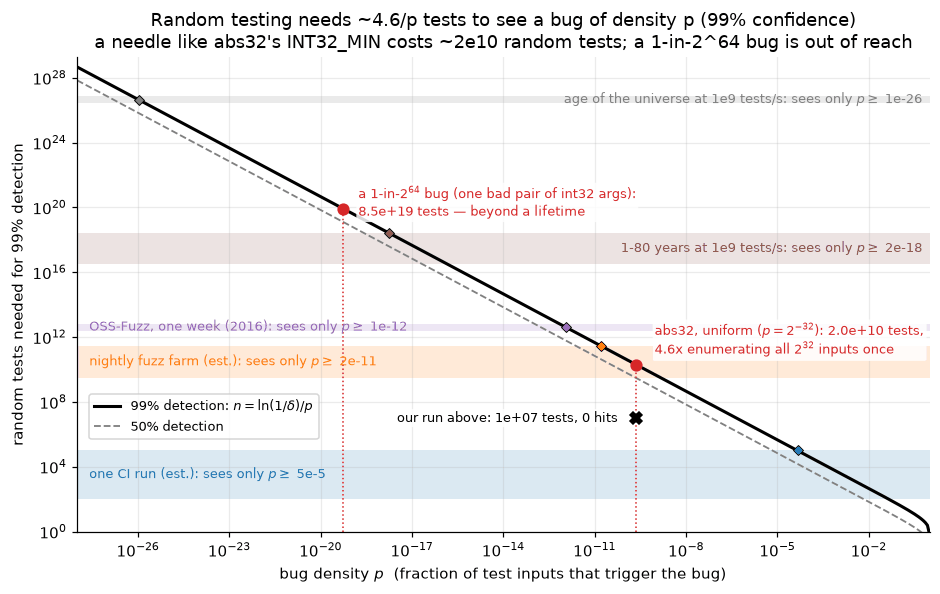

The needle bound matches literal needle hunts; random testing of a needle costs ~4.6x the domain size.
10^7 random tests saw abs32's bug 0 times: testing can only bound p, never show p = 0.


In [4]:
def _s1_needle_hunt(N, n, trials, g):
    '''Fraction of `trials` random test runs (n uniform inputs from range(N) each) that hit the needle input 0.'''
    draws = g.integers(0, N, size=(trials, n), dtype=np.int32)
    return float((draws == 0).any(axis=1).mean())


_s1_SEED_NEEDLE = 2024
_s1_P_ABS = 2.0**-32
_s1_N_RANDOM = 10_000_000


def _s1_needle_demo():
    '''The needle bound vs literal needle hunts, 10^7 random abs32 tests, and the density figure. Returns the
    number of random abs32 failures seen.'''
    g = np.random.default_rng(_s1_SEED_NEEDLE)

    # 1) The needle bound vs literal needle hunts: one bad input among N, n = tests_needed(1/N) tests per run.
    rows = []
    for N in (16, 64, 256):
        n = tests_needed(1 / N)
        pred, sim = 1 - (1 - 1 / N) ** n, _s1_needle_hunt(N, n, 20_000, g)
        z = (sim - pred) / math.sqrt(pred * (1 - pred) / 20_000)       # binomial standard error
        rows.append([N, n, f"{n / N:.2f} N", pred, sim, f"{z:+.1f}"])
    show_table(["domain N", "tests n (99%)", "n / N", "P(detect) formula", "simulated (20k runs)", "z-score"],
               rows, floatfmt="{:.4f}")
    print("formula vs simulation, all |z| < 3:", all(abs(float(row[-1])) < 3 for row in rows))

    # 2) Ten million uniform random abs32 tests (int32 arrays wrap exactly like abs32 does; see §1.2).
    x = g.integers(-2**31, 2**31, size=_s1_N_RANDOM, dtype=np.int64).astype(np.int32)
    hits = int((np.where(x < 0, -x, x) < 0).sum())
    print(f"\n{_s1_N_RANDOM:,} uniform random abs32 tests: {hits} failures "
          f"(P(at least one) = {1 - (1 - _s1_P_ABS) ** _s1_N_RANDOM:.2%}); a clean run certifies only "
          f"p < {3 / _s1_N_RANDOM:.1e} (95%), {3 / _s1_N_RANDOM / _s1_P_ABS:,.0f}x above the true density 2^-32")

    fig, ax = plt.subplots(figsize=(10, 5.6))
    draw_density_axes(ax, crossings=True)
    mark_density(ax, 2.0**-64, "a 1-in-$2^{64}$ bug (one bad pair of int32 args):\n"
                 f"{tests_needed(2.0**-64):.1e} tests — beyond a lifetime", offset=(10, 4))
    n_abs = tests_needed(_s1_P_ABS)
    mark_density(ax, _s1_P_ABS, f"abs32, uniform ($p = 2^{{-32}}$): {n_abs:.1e} tests,\n"
                 f"{n_abs / 2**32:.1f}x enumerating all $2^{{32}}$ inputs once", offset=(12, 16))
    ax.plot([_s1_P_ABS], [_s1_N_RANDOM], marker="X", color="black", ms=8, ls="none", zorder=5)
    ax.annotate(f"our run above: {_s1_N_RANDOM:.0e} tests, {hits} hits", (_s1_P_ABS, _s1_N_RANDOM),
                xytext=(-12, 0), textcoords="offset points", fontsize=8.5, va="center", ha="right", bbox=_s1_BOX)
    ax.set_title("Random testing needs ~4.6/p tests to see a bug of density p (99% confidence)\n"
                 "a needle like abs32's INT32_MIN costs ~2e10 random tests; a 1-in-2^64 bug is out of reach")
    plt.show()

    print(f"The needle bound matches literal needle hunts; random testing of a needle costs ~{n_abs / 2**32:.1f}x "
          "the domain size.")
    print(f"10^7 random tests saw abs32's bug {hits} times: testing can only bound p, never show p = 0.")
    return hits


_s1_RANDOM_HITS = _s1_needle_demo()

### 1.2 One 32-bit argument can be exhausted — and then testing *is* proof

For a function of one `int32`, the domain has $2^{32} \approx 4.3\times 10^9$ points. Checking every one of them is
not sampling but a complete case analysis: if all pass, the spec holds — a **proof by exhaustion**, valid for a
pure, deterministic function (no hidden state, no environment). The cell below does that for `abs32` with chunked,
vectorized NumPy on `int32` arrays, which wrap on overflow exactly like the 32-bit ALU. Strictly, what it exhausts
is the NumPy transcription `np.where(x < 0, -x, x)`, not the Python function `abs32`, which would take minutes to
run $2^{32}$ times (the cell prints the estimate). So the cell first closes that gap without sampling. For
$x \ge 0$ both versions return `x` untouched; for every one of the $2^{31}$ negative inputs it compares NumPy's
`int32` negation with `abs32`'s own arithmetic, `wrap(-x)`, transcribed line by line into exact `int64`. (It also
compares the transcription with `abs32` itself on the edge values and on random inputs.) The cell also shows the
trap that makes harnesses lie: sample in `int64` (or use Python's unbounded `int`) and the harness computes in the
wrong arithmetic — there $-(-2^{31}) = 2^{31} > 0$ and the bug does not exist. The test oracle must use the
program's semantics; §2 makes that choice explicit.

**Registered prediction:** exhausting all $2^{32}$ inputs takes well under a minute on one laptop core and finds
exactly one failing input, `INT32_MIN`.

Then the arity barrier: every additional 32-bit argument multiplies the domain by $2^{32}$. The second table and
the figure extrapolate the measured rate (and a pure-Python loop, and Dijkstra's 1969 rate) to his 54-bit
multiplier, to `midpoint`'s $2^{64}$ pairs, and to three arguments. Nearly sixty years of hardware (1969 to 2026)
turned Dijkstra's impossible case into a few months of one core (at our `abs32` checking rate; a real multiplier
check costs more). Two `int32` arguments cost centuries of one core — a large cluster could grind through them
once, for one function, but not on every commit; three arguments are out of reach for any hardware. The barrier
is the size of the input and state space, not cleverness — which is why the rest of the notebook reasons about
inputs symbolically instead of one at a time.

int32 negation vs abs32's wrap(-x), all 2,147,483,648 negative inputs: 0 disagreements (~3 s); for x >= 0 both return x unchanged
vectorized check vs the Python abs32 on 10,008 inputs (8 edge values + random): 0 mismatches
int64 harness trap: np.where(x < 0, -x, x) at INT32_MIN in int64 = 2147483648 (>= 0: the spec 'holds'); Python abs(INT32_MIN) = 2147483648. The bug exists only in 32-bit semantics.



exhaustive abs32: 4,294,967,296 inputs in 2.4 s (~0.55 ns/input, approximate); failing inputs: [-2147483648]  (== [INT32_MIN]: True)
pure-Python loop over abs32: ~89 ns/input -> 2^32 inputs would take ~6.4 min
registered prediction: exhausting 2^32 inputs takes well under a minute on one core and finds exactly [INT32_MIN] | measured: 2.4 s, [-2147483648] | verdict: RIGHT -- 4.3e9 cheap checks are seconds of vectorized work, so for a pure function of one 32-bit argument exhaustion IS a proof

workload                                inputs  numpy, this machine  pure Python    Dijkstra's 20 µs/op
-------------------------------------------------------------------------------------------------------
abs32: one int32 argument               2^32    2.4 s                6.4 min        23.9 h             
Dijkstra's 27x27-bit multiplier (1969)  2^54    115.5 days           50.7 years     1.1e+04 years      
midpoint: two int32 arguments           2^64    323.7 years          5.2e+04 years  1.

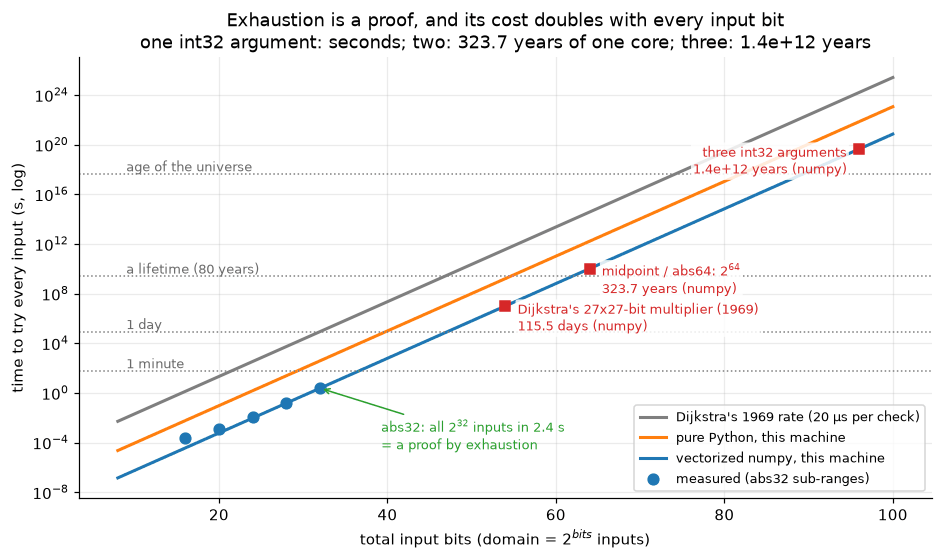

Dijkstra's >10,000-year multiplier is ~115.5 days of one core at our rate (roughly: our check is an abs, not a 27-bit multiply): 1969 to 2026 bought ~4e+04x = 2^15 per check.
Each extra int32 argument costs 2^32. One 32-bit argument: exhaust it and you have a proof; two or more: you must reason, not enumerate.


In [5]:
def _s1_exhaust_int32(fails, start=INT32_MIN, count=2**32, chunk=1 << 22):
    '''Apply the vectorized check fails(x) -> bool array to every int32 in [start, start + count), chunk by
    chunk (16 MiB per int32 array); return the list of failing inputs.'''
    base = np.arange(chunk, dtype=np.int32)
    bad = []
    for s in range(start, start + count, chunk):
        x = base[:min(chunk, start + count - s)] + np.int32(s)     # stays inside int32 by construction
        bad.extend(x[fails(x)].tolist())
    return bad


def _s1_abs32_fails(x):
    '''Vectorized abs32 + its spec. On int32 arrays NumPy negation wraps silently, like the 32-bit ALU.'''
    return np.where(x < 0, -x, x) < 0


def _s1_wrap_np(v):
    '''The setup cell's wrap() transcribed line by line for int64 arrays: keep the low 32 bits, then read bit 31
    as the sign. Exact for any |v| < 2^62, since int64 cannot overflow there.'''
    v = v & 0xFFFFFFFF
    return np.where(v >> 31 != 0, v - (1 << 32), v)


def _s1_abs32_disagrees(x):
    '''For negative int32 x: does NumPy's int32 negation differ from abs32's own arithmetic wrap(-x), computed
    in exact int64? (For x >= 0 both abs32 and the transcription return x untouched.)'''
    return (-x).astype(np.int64) != _s1_wrap_np(-x.astype(np.int64))


def _s1_human(seconds):
    '''Seconds -> a readable duration string.'''
    for unit, s in (("years", _s1_YEAR), ("days", 86400), ("h", 3600), ("min", 60)):
        if seconds >= s:
            v = seconds / s
            return f"{v:.1e} {unit}" if v >= 1e4 else f"{v:,.1f} {unit}"
    return f"{seconds:.2g} s"


_s1_SEED_EXHAUST = 7
_s1_EDGE = [INT32_MIN, INT32_MIN + 1, -2, -1, 0, 1, INT32_MAX - 1, INT32_MAX]
_s1_DIJKSTRA_S = 20e-6                    # 'some tens of microseconds' per product (EWD249): the low end
_s1_WORKLOADS = [("abs32: one int32 argument", 32), ("Dijkstra's 27x27-bit multiplier (1969)", 54),
                 ("midpoint: two int32 arguments", 64), ("abs64: one int64 argument", 64),
                 ("three int32 arguments", 96)]


def _s1_exhaust_demo():
    '''Check the vectorized abs32 against abs32, exhaust all 2^32 inputs (timing sub-ranges on the way), and
    extrapolate the cost to wider domains. Returns (failing inputs, measured ns per input).'''
    g = np.random.default_rng(_s1_SEED_EXHAUST)

    # 1) Trust the vectorized check before trusting its verdict. Exhaustively: on all 2^31 negative inputs, the
    #    only branch that does arithmetic, int32 negation equals abs32's wrap(-x). Directly: abs32 itself on
    #    the edge values and on random inputs.
    disagree, t_agree = timed(_s1_exhaust_int32, _s1_abs32_disagrees, count=2**31)
    print(f"int32 negation vs abs32's wrap(-x), all {2**31:,} negative inputs: {len(disagree)} disagreements "
          f"(~{t_agree:.0f} s); for x >= 0 both return x unchanged")
    probe = np.array(_s1_EDGE + g.integers(-2**31, 2**31, 10_000).tolist(), dtype=np.int32)
    mismatch = sum(bool(f) != (abs32(int(v)) < 0) for v, f in zip(probe, _s1_abs32_fails(probe)))
    print(f"vectorized check vs the Python abs32 on {len(probe):,} inputs (8 edge values + random): "
          f"{mismatch} mismatches")
    x64 = np.array([INT32_MIN], dtype=np.int64)
    print(f"int64 harness trap: np.where(x < 0, -x, x) at INT32_MIN in int64 = {np.where(x64 < 0, -x64, x64)[0]} "
          f"(>= 0: the spec 'holds'); Python abs(INT32_MIN) = {abs(INT32_MIN)}. The bug exists only in 32-bit "
          "semantics.")

    # 2) Exhaust all 2^32 inputs; time sub-ranges (2^16 ... 2^28 inputs) to show cost ~ domain size.
    times = {}
    for b in (16, 20, 24, 28):
        times[b] = timed(_s1_exhaust_int32, _s1_abs32_fails, count=2**b)[1]
    fails, times[32] = timed(_s1_exhaust_int32, _s1_abs32_fails)
    ns = times[32] / 2**32 * 1e9
    print(f"\nexhaustive abs32: {2**32:,} inputs in {times[32]:.1f} s (~{ns:.2f} ns/input, approximate); "
          f"failing inputs: {fails}  (== [INT32_MIN]: {fails == [INT32_MIN]})")
    py_ns = timed(lambda: [v for v in range(INT32_MIN, INT32_MIN + 2**18) if abs32(v) < 0])[1] / 2**18 * 1e9
    print(f"pure-Python loop over abs32: ~{py_ns:.0f} ns/input -> 2^32 inputs would take "
          f"~{_s1_human(py_ns * 2**32 / 1e9)}")
    ok = times[32] < 60 and fails == [INT32_MIN]
    print(f"registered prediction: exhausting 2^32 inputs takes well under a minute on one core and finds exactly "
          f"[INT32_MIN] | measured: {times[32]:.1f} s, {fails} | verdict: {'RIGHT' if ok else 'WRONG'} -- 4.3e9 "
          "cheap checks are seconds of vectorized work, so for a pure function of one 32-bit argument exhaustion "
          "IS a proof")

    # 3) Extrapolate: time to exhaust a domain of 2^bits inputs at three rates.
    print()
    show_table(["workload", "inputs", "numpy, this machine", "pure Python", "Dijkstra's 20 µs/op"],
               [[name, f"2^{b}", _s1_human(ns * 2**b / 1e9), _s1_human(py_ns * 2**b / 1e9),
                 _s1_human(_s1_DIJKSTRA_S * 2**b)] for name, b in _s1_WORKLOADS])

    fig, ax = plt.subplots(figsize=(10, 5.2))
    bits = np.arange(8, 101)
    for sec_per_input, lab, col in ((_s1_DIJKSTRA_S, "Dijkstra's 1969 rate (20 µs per check)", "#7f7f7f"),
                                    (py_ns / 1e9, "pure Python, this machine", "#ff7f0e"),
                                    (ns / 1e9, "vectorized numpy, this machine", "#1f77b4")):
        ax.plot(bits, sec_per_input * 2.0**bits, color=col, lw=2, label=lab)
    ax.plot(list(times), list(times.values()), "o", color="#1f77b4", ms=7, label="measured (abs32 sub-ranges)")
    for secs, lab in ((60, "1 minute"), (86400, "1 day"), (80 * _s1_YEAR, "a lifetime (80 years)"),
                      (13.8e9 * _s1_YEAR, "age of the universe")):
        ax.axhline(secs, color="gray", ls=":", lw=1)
        ax.text(9, secs * 1.6, lab, fontsize=8.5, color="dimgray")
    for name, b in _s1_WORKLOADS[1:]:
        if name.startswith("abs64"):
            continue                      # same 2^64 as midpoint; labelled together
        t = ns * 2**b / 1e9
        ax.plot([b], [t], "s", color="#d62728", ms=7, zorder=5)
        lab = "midpoint / abs64: $2^{64}$" if b == 64 else name
        right = b < 90                    # the last label goes left of its marker to stay inside the axes
        ax.annotate(f"{lab}\n{_s1_human(t)} (numpy)", (b, t), xytext=(8 if right else -8, -16),
                    textcoords="offset points", fontsize=8.5, color="#d62728", ha="left" if right else "right",
                    bbox=_s1_BOX)
    ax.annotate(f"abs32: all $2^{{32}}$ inputs in {times[32]:.1f} s\n= a proof by exhaustion", (32, times[32]),
                xytext=(40, -40), textcoords="offset points", fontsize=8.5, color="#2ca02c",
                arrowprops=dict(arrowstyle="->", color="#2ca02c"))
    ax.set_yscale("log")
    ax.set_xlabel("total input bits (domain = $2^{bits}$ inputs)")
    ax.set_ylabel("time to try every input (s, log)")
    ax.set_title("Exhaustion is a proof, and its cost doubles with every input bit\n"
                 f"one int32 argument: seconds; two: {_s1_human(ns * 2**64 / 1e9)} of one core; "
                 f"three: {_s1_human(ns * 2**96 / 1e9)}")
    ax.legend(loc="lower right", fontsize=8.5)
    plt.show()

    speedup = _s1_DIJKSTRA_S / (ns * 1e-9)
    print(f"Dijkstra's >10,000-year multiplier is ~{_s1_human(ns * 2**54 / 1e9)} of one core at our rate (roughly: "
          f"our check is an abs, not a 27-bit multiply): 1969 to 2026 bought ~{speedup:.0e}x = "
          f"2^{math.log2(speedup):.0f} per check.")
    print("Each extra int32 argument costs 2^32. One 32-bit argument: exhaust it and you have a proof; "
          "two or more: you must reason, not enumerate.")
    return fails, ns


_s1_ABS_FAILS, _s1_NS_PER_INPUT = _s1_exhaust_demo()

### 1.3 Density is a property of the test distribution, not of the bug

`midpoint_buggy` is the opposite of a needle. Over all valid pairs $0 \le lo \le hi \le 2^{31}-1$, the overflow
region $lo + hi > 2^{31}-1$ is a triangle with half the area: a uniform random tester would hit it on every other
test. Yet it shipped for years, because nobody tests binary search on uniformly random indices. They test it on
arrays, and for an array of $n$ elements the indices satisfy $lo \le hi \le n-1$, so $lo + hi \le 2n-2$, which
overflows only when $n > 2^{30}$ — a 4 GiB `int[]`. (Bloch's post says arrays of $2^{30}$ elements or more; for
this loop shape the exact bound is one element more.) Under the distribution of every unit test anyone writes,
$p = 0$ exactly: no number of tests finds it.

The Pentium FDIV bug makes the same point with real money. Five entries were missing from the SRT divider's
quotient-digit lookup table (Pratt, *Anatomy of the Pentium Bug*, 1995). For uniformly random operand bit
patterns an error occurs in about 1 in 9 billion divisions — the rate in Intel's December 1994 white paper (as
quoted by IBM; Pratt gives the same figure). With an assumed 1,000 divisions a day, Intel put an average
spreadsheet user at one error every 9 million days, which it called "about 27,000 years" (the cell's arithmetic
gives nearer 25,000). IBM's *Pentium Study* (12 Dec 1994) objected that spreadsheet numbers are not random bit
patterns — a computed value like $4.1 - 1.1$ carries the long runs of 1-bits that put a divisor at risk — and
estimated 1 error in 100 million divisions. At IBM's estimate of about 4,700 divisions per second over 15 minutes
of intensive work a day (4.2 million divisions), that is one error every 24 days. Pratt found that small integers
perturbed by about $10^{-6}$ fail roughly every 400 divisions. Same silicon, densities more than seven orders of
magnitude apart; Intel took a \$475 million pretax charge in Q4 1994 (Form 10-K). Note what a complete check
looks like here: the lookup table is a finite object, and Bryant checked it with BDDs (Edelman, *SIAM Review*
1997) — §8 builds BDDs.

The purest recent case: CrowdStrike's Channel File 291 (19 July 2024) defined 21 input fields while the sensor
supplied 20; the tests had used wildcards for the 21st field, so the first non-wildcard criterion in production
made the content interpreter read out of bounds (CrowdStrike root-cause analysis, Aug 2024), crashing an estimated
8.5 million Windows machines (Microsoft, 20 July 2024). Under the test distribution $p = 0$; in production
$p = 1$. Testing is not useless — Yuan et al. (OSDI 2014) found that in 58% of the catastrophic failures they
studied in five data-intensive systems (Cassandra, HBase, HDFS, MapReduce, Redis) the faults could have been caught
by simple tests of error-handling code — but a test suite only ever speaks for the distribution it was drawn from.

A reader who files the midpoint bug next to `abs32` as a rare-input bug would predict $p \ll 1\%$.
**Registered prediction** (from the area argument): $p = 1/2$ to within $10^{-9}$ for uniform valid pairs, and
$p = 0$ exactly for every array of at most $2^{30}$ elements. The cell counts the triangle exactly (checked by
brute force at 6, 8 and 10 bits, where the spec is evaluated with real wraparound), samples a million valid pairs,
and finds the exact array-size threshold by bisection with `midpoint_buggy` itself. The right panel moves three
bugs along the density axis by changing only the test distribution — for `abs32`, a generator that draws one of
§1.2's eight edge values half the time (classic boundary-value testing, which works precisely because it changes
$p$).

In [6]:
def _s1_overflow_pairs(M):
    '''Exact count of pairs 0 <= lo <= hi <= M with lo + hi > M, and the number of all such pairs.
    For lo = 0..M//2 the safe hi range is [lo, M - lo], i.e. M - 2*lo + 1 values (closed-form sum).'''
    total = (M + 1) * (M + 2) // 2
    K = M // 2
    safe = (K + 1) * (M + 1 - K)
    return total - safe, total


_s1_SEED_MID = 11
# Densities of the same bug under different test distributions (FDIV rates are sourced in the text above).
_s1_SHIFTS = {
    "abs32": [("uniform int32", 2.0**-32), ("edge-biased generator", 0.5 / 8 + 0.5 * 2.0**-32)],
    "FDIV": [("random bit patterns (Intel)", 1 / 9e9), ("spreadsheet-like (IBM)", 1 / 1e8),
             ("perturbed small integers (Pratt)", 1 / 400)],
}
# The usage assumptions behind the FDIV time-to-error claims (IBM Pentium Study, 12 Dec 1994, quoting Intel).
_s1_FDIV_USE = {"intel_div_per_day": 1_000, "ibm_div_per_s": 4_687, "ibm_s_per_day": 15 * 60}


def _s1_midpoint_demo():
    '''Exact and sampled overflow density of midpoint_buggy, the array-size threshold, the FDIV arithmetic.
    Returns what the figure needs: the first 300 sampled pairs, their failure flags, and the exact p.'''
    g = np.random.default_rng(_s1_SEED_MID)

    # 1) Brute force at small widths: the spec fails exactly when lo + hi > M, and the closed form counts it.
    for w in (6, 8, 10):
        M = 2**(w - 1) - 1
        bad = [(lo, hi) for lo in range(M + 1) for hi in range(lo, M + 1) if not lo <= wrap(lo + hi, w) >> 1 <= hi]
        print(f"w = {w:2d}: brute-force failing pairs {len(bad):6d} | closed form {_s1_overflow_pairs(M)[0]:6d} | "
              f"every failure has lo + hi > M: {all(lo + hi > M for lo, hi in bad)}")
    n_bad, n_total = _s1_overflow_pairs(INT32_MAX)
    p_mid = n_bad / n_total
    print(f"w = 32: P(overflow | uniform valid pair) = {n_bad:,} / {n_total:,} = {p_mid:.12f}")

    # 2) Monte Carlo with the real functions: a million uniform valid pairs (rejection sampling keeps lo <= hi).
    pairs = g.integers(0, INT32_MAX + 1, size=(2_200_000, 2), dtype=np.int64)
    pairs = pairs[pairs[:, 0] <= pairs[:, 1]][:1_000_000]
    lo, hi = pairs[:, 0], pairs[:, 1]
    mid_b = _s1_wrap_np(lo + hi) >> 1
    mid_f = _s1_wrap_np(lo + (_s1_wrap_np(hi - lo) >> 1))
    agree = all(int(mid_b[i]) == midpoint_buggy(int(lo[i]), int(hi[i])) and
                int(mid_f[i]) == midpoint_fixed(int(lo[i]), int(hi[i])) for i in range(3000))
    fail_b = ~((lo <= mid_b) & (mid_b <= hi))
    fail_f = ~((lo <= mid_f) & (mid_f <= hi))
    se = math.sqrt(p_mid * (1 - p_mid) / len(lo))
    print(f"vectorized midpoints agree with midpoint_buggy / midpoint_fixed on 3,000 samples: {agree}")
    print(f"{len(lo):,} uniform valid pairs: midpoint_buggy fails {fail_b.mean():.4f} "
          f"(z = {(fail_b.mean() - p_mid) / se:+.1f} vs the exact value), "
          f"midpoint_fixed fails {int(fail_f.sum())} times")

    # 3) Realistic inputs: binary search on an array of n elements keeps 0 <= lo <= hi <= n - 1, so the largest
    #    sum is 2(n - 1), at lo = hi = n - 1 (reached when the key is above every element), and step 1 showed the
    #    spec fails exactly when lo + hi > INT32_MAX. So an array of n elements is safe iff that worst pair is.
    #    Binary-search n with midpoint_buggy itself, then cross-check against the closed form.
    worst_ok = lambda n: 0 <= midpoint_buggy(n - 1, n - 1) <= n - 1
    lo_n, hi_n = 1, 2**31                      # worst_ok(1) holds, worst_ok(2^31) fails; keep that invariant
    while hi_n - lo_n > 1:
        mid_n = (lo_n + hi_n) // 2
        lo_n, hi_n = (mid_n, hi_n) if worst_ok(mid_n) else (lo_n, mid_n)
    n_crit = hi_n                              # the smallest array size whose worst pair overflows
    inside = []
    for n in (n_crit - 1, n_crit):
        r = midpoint_buggy(n - 1, n - 1)
        inside.append(0 <= r <= n - 1)
        print(f"array of n = {n:,} elements: midpoint_buggy(n-1, n-1) = {r:,}  (in range: {inside[-1]})")
    closed = INT32_MAX // 2 + 2                # closed form: the smallest n with 2(n - 1) > INT32_MAX
    print(f"threshold found by bisection with midpoint_buggy: n = {n_crit:,}; closed form: {closed:,} "
          f"(agree: {n_crit == closed})")
    ok = abs(p_mid - 0.5) < 1e-9 and inside == [True, False] and n_crit == closed == 2**30 + 1
    print(f"registered prediction: p = 1/2 within 1e-9 (uniform valid pairs) and p = 0 for arrays <= 2^30 | "
          f"measured: p = {p_mid:.12f} (|p - 1/2| = {abs(p_mid - 0.5):.1e}), sampled {fail_b.mean():.4f}; first "
          f"overflowing array n = {n_crit:,} = 2^30 + 1 | verdict: {'RIGHT' if ok else 'WRONG'} -- the bug is "
          "dense; the test distribution is narrow")
    fd = [p for _, p in _s1_SHIFTS["FDIV"]]
    ab = [p for _, p in _s1_SHIFTS["abs32"]]
    u = _s1_FDIV_USE
    days_intel = 1 / fd[0] / u["intel_div_per_day"]
    per_day_ibm = u["ibm_div_per_s"] * u["ibm_s_per_day"]
    print(f"FDIV time to an error: Intel 1 / ({1 / fd[0]:.0e} x {u['intel_div_per_day']:,} a day) = "
          f"{days_intel:.1e} days = {days_intel / 365.25:,.0f} years (Intel: 'about 27,000'); IBM "
          f"{1 / fd[1]:.0e} / ({u['ibm_div_per_s']:,}/s x {u['ibm_s_per_day']} s = {per_day_ibm / 1e6:.1f}M a day) "
          f"= {1 / fd[1] / per_day_ibm:.1f} days (IBM: 'about 24')")
    print(f"FDIV densities span {math.log10(fd[-1] / fd[0]):.1f} orders of magnitude; an edge-biased generator "
          f"(half uniform, half one of the 8 edge values of §1.2) raises abs32's density by {ab[1] / ab[0]:.1e}x")
    print("Half of all valid (lo, hi) pairs overflow, yet every array a unit test allocates sits in the safe "
          "corner.")
    k = 300
    return lo[:k], hi[:k], fail_b[:k], p_mid



_s1_MID = _s1_midpoint_demo()

w =  6: brute-force failing pairs    256 | closed form    256 | every failure has lo + hi > M: True
w =  8: brute-force failing pairs   4096 | closed form   4096 | every failure has lo + hi > M: True
w = 10: brute-force failing pairs  65536 | closed form  65536 | every failure has lo + hi > M: True
w = 32: P(overflow | uniform valid pair) = 1,152,921,504,606,846,976 / 2,305,843,010,287,435,776 = 0.499999999767
vectorized midpoints agree with midpoint_buggy / midpoint_fixed on 3,000 samples: True
1,000,000 uniform valid pairs: midpoint_buggy fails 0.5011 (z = +2.1 vs the exact value), midpoint_fixed fails 0 times
array of n = 1,073,741,824 elements: midpoint_buggy(n-1, n-1) = 1,073,741,823  (in range: True)
array of n = 1,073,741,825 elements: midpoint_buggy(n-1, n-1) = -1,073,741,824  (in range: False)
threshold found by bisection with midpoint_buggy: n = 1,073,741,825; closed form: 1,073,741,825 (agree: True)
registered prediction: p = 1/2 within 1e-9 (uniform valid pairs) and p = 0 f

The figure draws both halves of the argument. On the left, the valid $(lo, hi)$ pairs with the overflow
triangle and the small corner that real arrays live in; on the right, the density axis of §1.1, along which the
same bug moves by orders of magnitude when only the test generator changes.

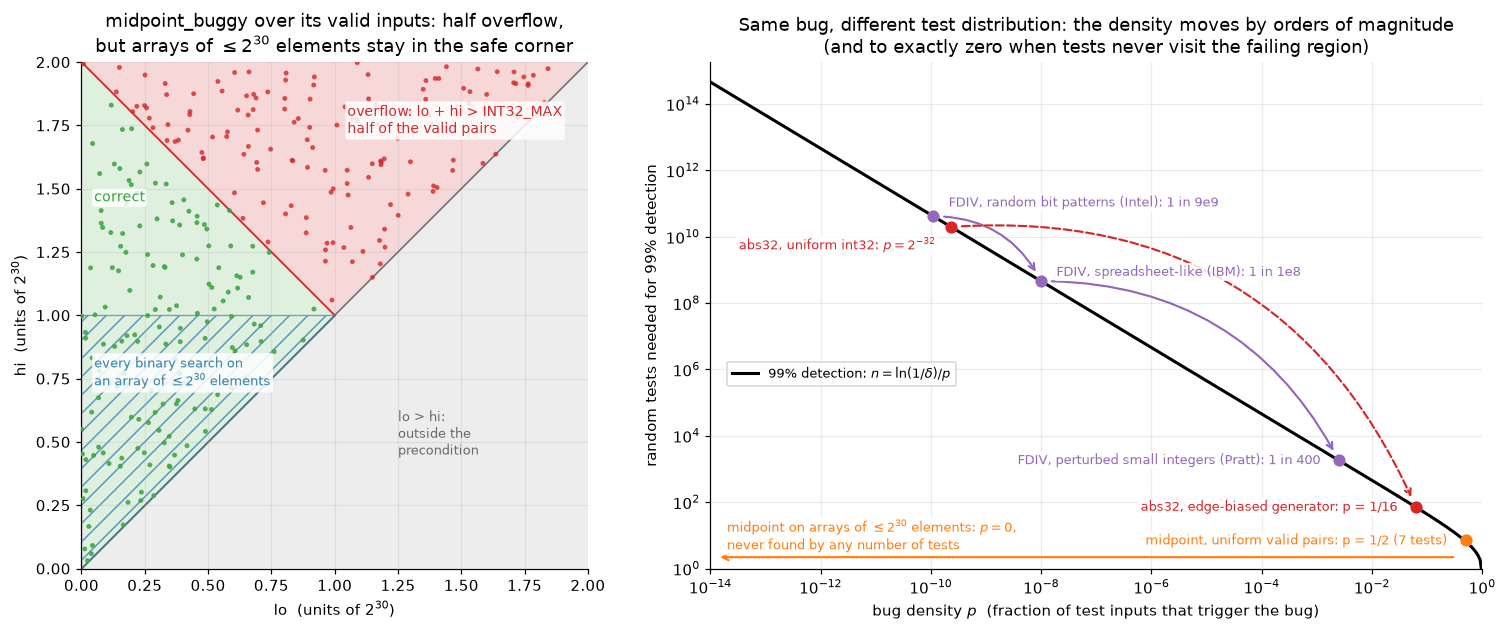

Bug density is a joint property of the bug and the test distribution; a test suite speaks only for the latter.
Changing the generator (edge values, spreadsheet-like data) moves p by orders of magnitude; no generator moves midpoint off p = 0 for real arrays.


In [7]:
def _s1_midpoint_figure(lo, hi, fail_b, p_mid):
    '''Left: the (lo, hi) plane with 300 sampled valid pairs. Right: three bugs moved along the density axis by
    changing only the test distribution.'''
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), gridspec_kw=dict(width_ratios=[1, 1.4]))
    ax = axes[0]
    U = 2**30                                  # plot in units of 2^30, so INT32_MAX is ~2
    ax.add_patch(Polygon([(0, 0), (1, 1), (0, 2)], color="#2ca02c", alpha=0.15, lw=0))
    ax.add_patch(Polygon([(0, 2), (1, 1), (2, 2)], color="#d62728", alpha=0.18, lw=0))
    ax.add_patch(Polygon([(0, 0), (2, 2), (2, 0)], color="lightgray", alpha=0.4, lw=0))
    ax.add_patch(Polygon([(0, 0), (0, 1), (1, 1)], fill=False, hatch="//", ec="#1f77b4", lw=0.8, alpha=0.7))
    ax.scatter(lo / U, hi / U, s=5, alpha=0.7, c=np.where(fail_b, "#d62728", "#2ca02c"), zorder=3)
    ax.plot([0, 1], [2, 1], color="#d62728", lw=1.2)
    ax.plot([0, 2], [0, 2], color="dimgray", lw=1)
    ax.text(1.05, 1.72, "overflow: lo + hi > INT32_MAX\nhalf of the valid pairs", color="#d62728", fontsize=9,
            bbox=_s1_BOX, zorder=6)
    ax.text(0.05, 1.45, "correct", color="#2ca02c", fontsize=9, bbox=_s1_BOX, zorder=6)
    ax.text(0.05, 0.72, "every binary search on\nan array of $\\leq 2^{30}$ elements", color="#1f77b4", fontsize=8.5,
            bbox=_s1_BOX, zorder=6)
    ax.text(1.25, 0.45, "lo > hi:\noutside the\nprecondition", color="dimgray", fontsize=8.5)
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2)
    ax.set_aspect("equal")
    ax.set_xlabel("lo  (units of $2^{30}$)")
    ax.set_ylabel("hi  (units of $2^{30}$)")
    ax.set_title("midpoint_buggy over its valid inputs: half overflow,\n"
                 "but arrays of $\\leq 2^{30}$ elements stay in the safe corner")

    ax = axes[1]
    draw_density_axes(ax, p_min=1e-14, budgets=False, median=False)
    arc = dict(arrowstyle="->", lw=1.4, shrinkA=7, shrinkB=7, connectionstyle="arc3,rad=-0.3")
    fdiv = _s1_SHIFTS["FDIV"]
    for (_, p_a), (_, p_b) in zip(fdiv, fdiv[1:]):
        ax.annotate("", (p_b, tests_needed(p_b)), (p_a, tests_needed(p_a)), arrowprops=dict(arc, color="#9467bd"))
    sci = lambda v: f"{v:.0e}".replace("e+0", "e")
    mark_density(ax, fdiv[0][1], f"FDIV, {fdiv[0][0]}: 1 in {sci(1 / fdiv[0][1])}", color="#9467bd", guide=False,
                 offset=(10, 9))
    mark_density(ax, fdiv[1][1], f"FDIV, {fdiv[1][0]}: 1 in {sci(1 / fdiv[1][1])}", color="#9467bd", guide=False,
                 offset=(10, 6))
    mark_density(ax, fdiv[2][1], f"FDIV, {fdiv[2][0]}: 1 in {1 / fdiv[2][1]:.0f}", color="#9467bd", guide=False,
                 offset=(-12, 0), ha="right")
    (lab0, p0), (lab1, p1) = _s1_SHIFTS["abs32"]
    ax.annotate("", (p1, tests_needed(p1)), (p0, tests_needed(p0)),
                arrowprops=dict(arc, color="#d62728", ls="--", connectionstyle="arc3,rad=-0.35"))
    mark_density(ax, p0, f"abs32, {lab0}: $p = 2^{{-32}}$", guide=False, offset=(-10, -12), ha="right")
    mark_density(ax, p1, f"abs32, {lab1}: p = 1/16", guide=False, offset=(-12, 0), ha="right")
    mark_density(ax, p_mid, f"midpoint, uniform valid pairs: p = 1/2 ({tests_needed(p_mid)} tests)",
                 color="#ff7f0e", guide=False, offset=(-12, 0), ha="right")
    ax.annotate("", (1.5e-14, 2.2), (p_mid, 2.2), arrowprops=dict(arrowstyle="->", color="#ff7f0e", lw=1.4,
                                                                  shrinkB=0, shrinkA=8))
    ax.text(2e-14, 2.8, "midpoint on arrays of $\\leq 2^{30}$ elements: $p = 0$,\nnever found by any number of tests",
            color="#ff7f0e", fontsize=8.5, va="bottom", bbox=_s1_BOX)
    ax.set_title("Same bug, different test distribution: the density moves by orders of magnitude\n"
                 "(and to exactly zero when tests never visit the failing region)")
    plt.tight_layout()
    plt.show()

    print("Bug density is a joint property of the bug and the test distribution; a test suite speaks only for "
          "the latter.")
    print("Changing the generator (edge values, spreadsheet-like data) moves p by orders of magnitude; "
          "no generator moves midpoint off p = 0 for real arrays.")


_s1_midpoint_figure(*_s1_MID)

### 1.4 The coverage illusion

The industry's answer to "how much testing is enough" is **coverage**: the fraction of lines (or branch outcomes)
that at least one test executed. Coverage is a property of the *code that ran*; `abs32`'s bug is a property of a
*value*. The `x < 0` branch is taken by $2^{31}$ inputs and exactly one of them is wrong, so a test that covers the
branch with a random negative input exposes the bug with probability $2^{-31}$.

**Registered prediction** (the one a coverage dashboard implicitly makes): a suite with 100% line and 100% branch
coverage of `abs32` exposes the bug. We measure coverage with `sys.monitoring` (Python 3.12's low-overhead event
API): `LINE` events record executed lines and `BRANCH` events record which way each conditional jump went,
restricted to the function's own code object so the lines of `wrap()` do not count. The denominators come from
the bytecode, and the cell checks them against a hand count: `abs32` has three body lines and one `if`, so two
branch outcomes. The suites are the textbook `5, -5, 0`, the same plus `INT32_MAX`, and a single `INT32_MIN`. For
`midpoint_buggy` the numbers are worse than useless: straight-line code has zero branches, so one test of any input
reports "100%" of nothing — the overflow lives inside a `+`, which no structural criterion sees. Stronger
structural criteria (MC/DC, path coverage) refine which condition outcomes and paths run; none of them says which
*values* flow down a path. That is what boundary-value testing targets (the edge-biased generator of §1.3), and
only a proof covers all of them. §2 starts from the other end: write down what "correct" means for all inputs, and
build machines that check it.

In [8]:
def _s1_coverage(fn, tests):
    '''Run fn on every argument tuple in `tests` and measure line and branch coverage of fn's OWN code object
    (callees such as wrap() are not counted), with sys.monitoring (Python 3.12+).
    Returns dict(lines, lines_total, branches, branches_total, outputs).

    LINE fires on each newly executed line; BRANCH fires with (jump offset, destination) each time a conditional
    jump executes, so a distinct pair is one covered outcome. Every conditional jump has exactly two outcomes.
    '''
    import dis
    code = fn.__code__
    all_lines = {ln for _, ln in dis.findlinestarts(code) if ln is not None and ln != code.co_firstlineno}
    n_jumps = sum(ins.opname.startswith("POP_JUMP") and "IF" in ins.opname for ins in dis.get_instructions(code))
    lines, outcomes = set(), set()
    mon = sys.monitoring
    tool = next(t for t in (mon.COVERAGE_ID, 3, 4) if mon.get_tool(t) is None)   # a free tool slot
    mon.use_tool_id(tool, "s1-coverage")
    try:
        mon.register_callback(tool, mon.events.LINE, lambda c, ln: lines.add(ln))
        mon.register_callback(tool, mon.events.BRANCH, lambda c, src, dst: outcomes.add((src, dst)))
        mon.set_local_events(tool, code, mon.events.LINE | mon.events.BRANCH)
        outputs = [fn(*args) for args in tests]
    finally:
        mon.set_local_events(tool, code, 0)
        mon.register_callback(tool, mon.events.LINE, None)
        mon.register_callback(tool, mon.events.BRANCH, None)
        mon.free_tool_id(tool)
    return dict(lines=len(lines & all_lines), lines_total=len(all_lines), branches=len(outcomes),
                branches_total=2 * n_jumps, outputs=outputs)


def _s1_pct(k, total):
    '''"k/total = P%", or the vacuous case for a function with nothing to cover.'''
    return f"{k}/{total} = {k / total:.0%}" if total else "0/0 = '100%' (vacuous)"


_s1_SPECS = {abs32: lambda args, r: r >= 0,
             midpoint_buggy: lambda args, r: args[0] <= r <= args[1]}
# Hand count of what there is to cover: (body lines, branch outcomes). abs32: `if`, two returns, one `if`;
# midpoint_buggy: one return line, no conditional jump.
_s1_HAND_COUNT = {abs32: (3, 2), midpoint_buggy: (1, 0)}
_s1_SUITES = [
    (abs32, "textbook: 5, -5, 0", [(5,), (-5,), (0,)]),
    (abs32, "textbook + INT32_MAX", [(5,), (-5,), (0,), (INT32_MAX,)]),
    (abs32, "INT32_MIN alone", [(INT32_MIN,)]),
    (midpoint_buggy, "(1, 3), (0, 10), (7, 7)", [(1, 3), (0, 10), (7, 7)]),
    (midpoint_buggy, "(2^30, 2^30)", [(2**30, 2**30)]),
]


def _s1_coverage_demo():
    '''Coverage and spec failures for each suite, then the registered prediction.'''
    rows, results, totals_ok = [], {}, True
    for fn, name, tests in _s1_SUITES:
        cov = _s1_coverage(fn, tests)
        totals_ok &= (cov["lines_total"], cov["branches_total"]) == _s1_HAND_COUNT[fn]
        n_fail = sum(not _s1_SPECS[fn](args, r) for args, r in zip(tests, cov["outputs"]))
        results[name] = (cov, n_fail)
        rows.append([fn.__name__, name, _s1_pct(cov["lines"], cov["lines_total"]),
                     _s1_pct(cov["branches"], cov["branches_total"]), f"{n_fail} of {len(tests)}"])
    show_table(["function", "test suite", "line coverage", "branch coverage", "spec failures"], rows)
    print(f"denominators from the bytecode match the hand count (abs32: 3 lines, 2 outcomes; midpoint_buggy: "
          f"1 line, 0 outcomes): {totals_ok}")

    cov, n_fail = results["textbook: 5, -5, 0"]
    full = cov["lines"] == cov["lines_total"] and cov["branches"] == cov["branches_total"]
    verdict = "UNTESTED (the suite did not reach full coverage)" if not full else \
        ("WRONG" if n_fail == 0 else "RIGHT")
    print(f"\nregistered prediction: 100% line + branch coverage of abs32 exposes the bug | measured: "
          f"{'100% line, 100% branch' if full else 'not full coverage'}, {n_fail} failures | verdict: "
          f"{verdict} -- coverage counts code that ran; the bug is a value")
    print(f"of the {2**31:,} inputs that take abs32's x < 0 branch, {len(_s1_ABS_FAILS)} fails (exhaustion, §1.2): "
          f"covering that branch with a random negative input finds it with probability 2^-31 = {2.0**-31:.1e}")
    print("The only suite that finds the bug has 50% branch coverage; the suites with 100% find nothing.")
    print("Testing samples inputs and coverage samples code; neither reasons about all values at once.")


if hasattr(sys, "monitoring"):
    _s1_coverage_demo()
else:
    print("§1.4 needs Python 3.12+ (sys.monitoring); skipped.")

function        test suite               line coverage  branch coverage         spec failures
---------------------------------------------------------------------------------------------
abs32           textbook: 5, -5, 0       3/3 = 100%     2/2 = 100%              0 of 3       
abs32           textbook + INT32_MAX     3/3 = 100%     2/2 = 100%              0 of 4       
abs32           INT32_MIN alone          2/3 = 67%      1/2 = 50%               1 of 1       
midpoint_buggy  (1, 3), (0, 10), (7, 7)  1/1 = 100%     0/0 = '100%' (vacuous)  0 of 3       
midpoint_buggy  (2^30, 2^30)             1/1 = 100%     0/0 = '100%' (vacuous)  1 of 1       
denominators from the bytecode match the hand count (abs32: 3 lines, 2 outcomes; midpoint_buggy: 1 line, 0 outcomes): True

registered prediction: 100% line + branch coverage of abs32 exposes the bug | measured: 100% line, 100% branch, 0 failures | verdict: WRONG -- coverage counts code that ran; the bug is a value
of the 2,147,483,648 inpu

## 2. What "correct" means: specs, MiniPy, and the shape of every verifier

§1 ended on a negative result: no amount of sampling shows that a bug is absent. Reasoning about every input at
once needs two precise objects first: a **specification** that says what "correct" means and a **semantics** that
says what the program does. This section fixes both, builds MiniPy (the small language every later engine reads),
and draws the one picture every technique fits into: each computes an *approximation of the reachable states*,
and the direction of the approximation decides which mistakes it can make.

### 2.1 Specifications: contracts, safety, liveness

A **specification** is a predicate on behaviours; an **implementation** is a program whose behaviours should
satisfy it. A spec says *what*, not *how* ("sorted, and a permutation of the input" covers quicksort and
mergesort alike), and is usually shorter than the code, though not always: for the five verified systems of
§11.2, code/spec ratios run from 1.0 to 34. The workhorse is the **Hoare triple** $\{P\}\ C\ \{Q\}$ (Hoare, CACM
1969, building on Floyd 1967): if the **precondition** $P$ holds before $C$ runs, the **postcondition** $Q$ holds
after. MiniPy, like Dafny and Verus, writes them as annotations; the reserved name `result` (JML's and ACSL's
`\result`) is the return value:

```python
def midpoint_fixed(lo, hi):
    requires(0 <= lo)
    requires(lo <= hi)
    ensures(lo <= result and result <= hi)
    return lo + ((hi - lo) >> 1)
```

- **The precondition is part of the contract.** `midpoint_fixed(-2, INT32_MAX)` returns a value outside
  `[lo, hi]` (§1), and the function is still correct: that input violates `requires(0 <= lo)`. A fix is only ever
  correct *relative to a spec*.
- **Partial vs total correctness.** Hoare's triple is *partial*: *if* $C$ terminates, $Q$ holds, so a loop that
  never exits satisfies every partial spec. **Total correctness** adds termination, proved with a **variant**: an
  integer expression, bounded below, that strictly decreases on every iteration (`decreases(e)`; §6.5).

Programs that run forever (servers, protocols) are judged by their execution **traces**, and trace properties
come in two kinds (Lamport's 2013 Turing Award citation credits him with the concepts of safety and liveness).
**Safety** — *nothing bad ever happens* — fails at some moment, so a **finite** trace is the counterexample:
failing tests, BMC traces and assertion failures are all safety counterexamples. **Liveness** — *something good
eventually happens* — is violated by no finite prefix (the good thing may still come); its counterexample is an
**infinite** trace, in a finite system a **lasso**: a stem, then a cycle repeated forever (§8). Alpern &
Schneider (*Defining Liveness*, IPL 1985) showed the split is complete: **every trace property is the
intersection of a safety and a liveness property** — total correctness is partial correctness (safety) ∩
termination (liveness). Some requirements are not trace properties at all: **noninterference** (secrets do not
affect public outputs) and **constant-time** code relate *pairs* of runs, so the counterexample is two executions
that agree on public inputs and differ in what an observer sees. Clarkson & Schneider (CSF 2008) named these
**hyperproperties**; the standard way to check one with ordinary tools is **self-composition**, running two
renamed copies side by side (Barthe, D'Argenio & Rezk, CSFW 2004). In this notebook: pre/postconditions in §1 and
§4–§6, invariants in §6 and §8–§9, termination in §6.5, liveness lassos in §8.3.

### 2.2 A weak spec certifies wrong code

A verifier proves exactly what the spec says; its only notion of "wrong" *is* the spec. Sorting makes this
concrete with a **spec ladder**, `SPEC_LADDER`: `sorted` (non-decreasing output), `sorted+len` (... and as long
as the input: rules out `return []`), `sorted+perm` (... and a permutation of it: rules out
`[min(xs)] * len(xs)`). `SORT_CANDIDATES` holds the correct `sorted(xs)`, three **spec gamers** (`return []`,
`sorted(set(xs))`, `[min(xs)] * len(xs)`) and an honest-looking bug: bubble sort with a fixed 3 passes instead of
`len(xs) - 1`. `check_bounded(fn, spec, inputs)` runs `fn` on a copy of each input (a function that mutates its
argument cannot fool the spec), counts exceptions as failures, and returns every counterexample. Fed
`all_lists(L, range(3))` it is **bounded exhaustive testing**, the idea of SmallCheck (Runciman, Naylor &
Lindblad, Haskell Symposium 2008): rather than sample random inputs like QuickCheck (Claessen & Hughes, ICFP
2000) or Hypothesis, enumerate *every* input up to a size bound. Inside the bound — here *two* bounds, length
$\le L$ and values 0..2 — it is a proof, like §1's exhaustion of `abs32`; its justification is Daniel Jackson's
**small scope hypothesis**, the premise of Alloy: many bugs have small counterexamples.

**Registered prediction** (the one implicit in choosing a SmallCheck depth): checking every list of length ≤ 4
rejects the 3-pass bubble sort. The table checks bounds 4 and 5; the figure goes to length 7.

exhaustive bounded check: all 121 lists of length <= 4 and all 364 of length <= 5, values 0..2; FAIL (k) = k counterexamples
candidate              sorted, L<=4  sorted+len, L<=4  sorted+perm, L<=4  sorted, L<=5  sorted+len, L<=5  sorted+perm, L<=5
---------------------------------------------------------------------------------------------------------------------------
sorted(xs)  [correct]  pass          pass              pass               pass          pass              pass             
return []              pass          FAIL (120)        FAIL (120)         pass          FAIL (363)        FAIL (363)       
sorted(set(xs))        pass          FAIL (105)        FAIL (105)         pass          FAIL (348)        FAIL (348)       
[min(xs)] * len(xs)    pass          pass              FAIL (108)         pass          pass              FAIL (348)       
bubble sort, 3 passes  pass          pass              pass               FAIL (17)     FAIL (17)         FAIL (17)        

first 

random testing, 100 lists of random length 0..7: P(one test fails) = 0.084 (exact), P(a 100-test run catches it) = 0.99984 formula, 1.0000 simulated (2000 runs)
0-1 principle: on 0/1 lists alone the 3-pass sort first fails at length 5 (e.g. [1, 1, 1, 1, 0]), the same length as on values 0..2; so its pass at length <= 4 holds for every integer list | spot check: 2000 random lists of length 0..4, values in +-10^6: 0 failures


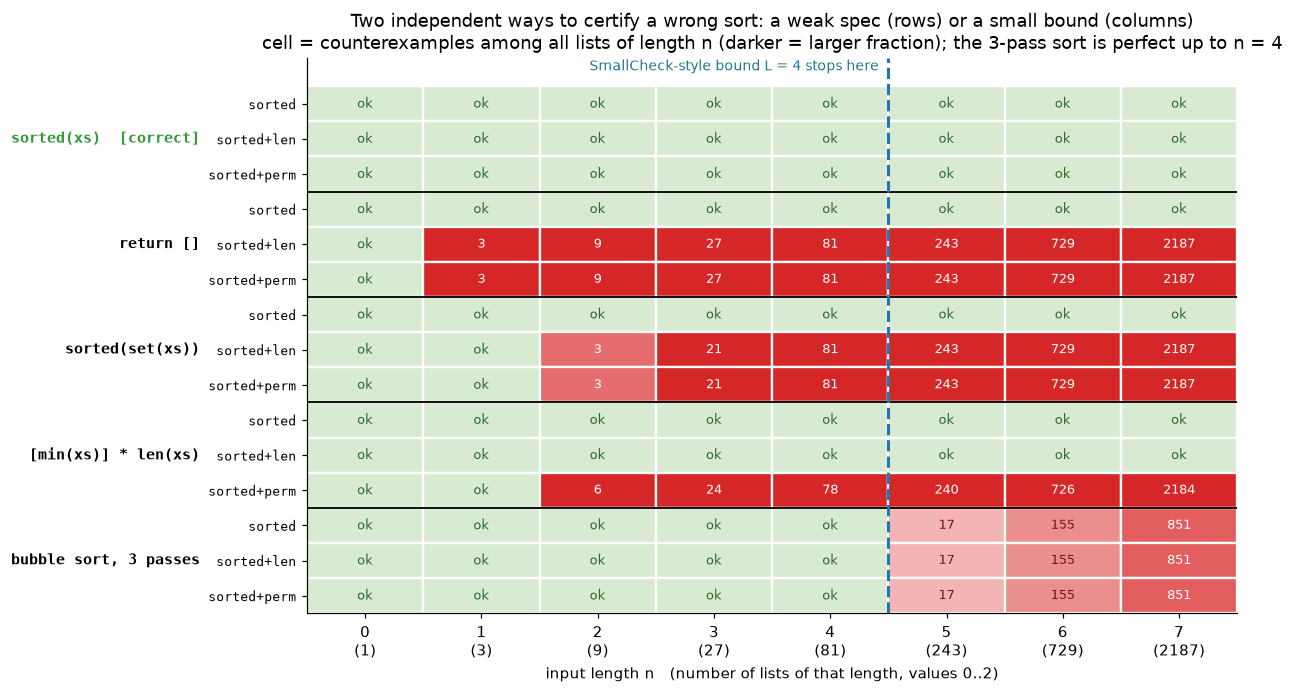

Weak rungs accept wrong programs at every length; the strong rung accepts the 3-pass sort up to length 4.
Spec strength and search bound are separate axes: the checker certifies exactly what the spec says, on exactly the inputs it tried.


In [9]:
def all_lists(max_len, values):
    '''Every list of length 0..max_len over `values`, shortest first: SmallCheck-style exhaustive enumeration.
    len(values)**k lists of each length k, so the total grows exponentially in max_len.'''
    values = list(values)
    return [list(t) for n in range(max_len + 1) for t in itertools.product(values, repeat=n)]


def check_bounded(fn, spec, inputs, max_cex=None):
    '''Run fn on a COPY of every input and return the counterexamples [(input, output_or_exception), ...]:
    inputs where spec(input, output) is False, raises, or where fn itself raises (a crash violates every spec).
    The spec always sees the ORIGINAL input, so a function that mutates its argument cannot hide a bug.
    An empty result proves the spec for exactly these inputs and says nothing about any other input.'''
    import copy
    cex = []
    for x in inputs:
        try:
            out = fn(copy.deepcopy(x))
            ok = bool(spec(x, out))
        except Exception as exc:                 # a crash, or a spec that cannot even evaluate the output
            out, ok = exc, False
        if not ok:
            cex.append((x, out))
            if max_cex is not None and len(cex) >= max_cex:
                break
    return cex


def _s2_is_sorted(ys):
    '''Non-decreasing order (raises on outputs that are not sequences: check_bounded counts that as a failure).'''
    return all(a <= b for a, b in zip(ys, ys[1:]))


# The spec ladder for sorting: each rung adds a conjunct that rules out a family of wrong programs.
SPEC_LADDER = {
    'sorted': lambda xs, out: _s2_is_sorted(out),
    'sorted+len': lambda xs, out: _s2_is_sorted(out) and len(out) == len(xs),
    'sorted+perm': lambda xs, out: _s2_is_sorted(out) and Counter(out) == Counter(xs),
}


def _s2_bubble3(xs):
    '''Bubble sort with a fixed 3 passes instead of len(xs) - 1.'''
    ys = list(xs)
    for _ in range(3):
        for i in range(len(ys) - 1):
            if ys[i] > ys[i + 1]:
                ys[i], ys[i + 1] = ys[i + 1], ys[i]
    return ys


SORT_CANDIDATES = {
    'sorted(xs)  [correct]': lambda xs: sorted(xs),
    'return []': lambda xs: [],
    'sorted(set(xs))': lambda xs: sorted(set(xs)),
    '[min(xs)] * len(xs)': lambda xs: [min(xs)] * len(xs) if xs else [],
    'bubble sort, 3 passes': _s2_bubble3,
}

_s2_V = 3                      # list values 0..V-1: SmallCheck's "small values"
_s2_L_MAX = 7                  # lengths 0..7 for the figure (3^7 = 2,187 lists of the longest length)
_s2_SEED_RANDOM = 5
_s2_SEED_WIDE = 11             # random integer lists far outside 0..V-1 (the 0-1 principle check)


def _s2_spec_demo():
    '''Who passes which rung of the spec ladder at each bound; the registered prediction; random testing; the
    0-1 principle; the figure.'''
    by_len = {n: [list(t) for t in itertools.product(range(_s2_V), repeat=n)] for n in range(_s2_L_MAX + 1)}
    # n_cex[cand][rung][n] = number of counterexamples among the lists of length exactly n
    n_cex = {c: {r: [len(check_bounded(f, SPEC_LADDER[r], by_len[n])) for n in range(_s2_L_MAX + 1)]
                 for r in SPEC_LADDER} for c, f in SORT_CANDIDATES.items()}

    def verdict(c, r, L):
        k = sum(n_cex[c][r][:L + 1])
        return "pass" if k == 0 else f"FAIL ({k})"
    n4, n5 = len(all_lists(4, range(_s2_V))), len(all_lists(5, range(_s2_V)))
    print(f"exhaustive bounded check: all {n4} lists of length <= 4 and all {n5} of length <= 5, values 0..{_s2_V - 1};"
          " FAIL (k) = k counterexamples")
    show_table(["candidate"] + [f"{r}, L<={L}" for L in (4, 5) for r in SPEC_LADDER],
               [[c] + [verdict(c, r, L) for L in (4, 5) for r in SPEC_LADDER] for c in SORT_CANDIDATES])
    print("\nfirst counterexample at the weakest rung each candidate fails (input -> output):")
    for c, f in SORT_CANDIDATES.items():
        for r in SPEC_LADDER:
            cex = check_bounded(f, SPEC_LADDER[r], all_lists(_s2_L_MAX, range(_s2_V)), max_cex=1)
            if cex:
                print(f"  {c:24s} fails '{r}': {cex[0][0]} -> {cex[0][1]}")
                break
        else:
            print(f"  {c:24s} passes every rung up to length {_s2_L_MAX}")
    crash = check_bounded(lambda xs: [min(xs)] * len(xs), SPEC_LADDER['sorted'], [[], [1]])
    print(f"  (without the `if xs` guard, min() crashes on []: check_bounded reports {crash[0][0]} -> "
          f"{type(crash[0][1]).__name__}: {crash[0][1]})")

    b3 = n_cex['bubble sort, 3 passes']['sorted+perm']
    passes4, first_fail = sum(b3[:5]) == 0, next(n for n in range(_s2_L_MAX + 1) if b3[n])
    print(f"\nregistered prediction: the bounded checker at L = 4 rejects the 3-pass bubble sort | measured: it passes "
          f"all three rungs on all {n4} lists of length <= 4 (passes4 = {passes4}); the first failures appear at "
          f"length {first_fail} ({b3[first_fail]} of {_s2_V ** first_fail} lists) | verdict: "
          f"{'WRONG' if passes4 else 'RIGHT'} -- a bound is a proof for the inputs inside it, silence about the rest")

    # Random testing on the same function: lengths uniform in 0..L_MAX, the QuickCheck/Hypothesis default of 100 tests.
    p_fail = float(np.mean([b3[n] / _s2_V ** n for n in range(_s2_L_MAX + 1)]))
    g = np.random.default_rng(_s2_SEED_RANDOM)
    runs = 2000
    hits = sum(any(not SPEC_LADDER['sorted+perm'](xs, _s2_bubble3(xs))
                   for xs in (g.integers(0, _s2_V, size=g.integers(0, _s2_L_MAX + 1)).tolist() for _ in range(100)))
               for _ in range(runs))
    print(f"random testing, 100 lists of random length 0..{_s2_L_MAX}: P(one test fails) = {p_fail:.3f} (exact), "
          f"P(a 100-test run catches it) = {1 - (1 - p_fail) ** 100:.5f} formula, {hits / runs:.4f} simulated "
          f"({runs} runs)")

    # The 0-1 principle (derived in the text below): for a compare-exchange network, 0/1 inputs decide everything.
    zero_one = {n: check_bounded(_s2_bubble3, SPEC_LADDER['sorted+perm'],
                                 [list(t) for t in itertools.product((0, 1), repeat=n)]) for n in range(_s2_L_MAX + 1)}
    first01 = next(n for n in range(_s2_L_MAX + 1) if zero_one[n])
    gw = np.random.default_rng(_s2_SEED_WIDE)
    wide = [gw.integers(-10**6, 10**6, size=n).tolist() for n in range(5) for _ in range(400)]
    wide_cex = check_bounded(_s2_bubble3, SPEC_LADDER['sorted+perm'], wide)
    print(f"0-1 principle: on 0/1 lists alone the 3-pass sort first fails at length {first01} (e.g. "
          f"{zero_one[first01][0][0]}), the same length as on values 0..2; so its pass at length <= 4 holds for every "
          f"integer list | spot check: {len(wide)} random lists of length 0..4, values in +-10^6: {len(wide_cex)} "
          f"failures")

    # Figure: rows = candidate x rung, columns = exact input length; red = some input of that length fails.
    rows = [(c, r) for c in SORT_CANDIDATES for r in SPEC_LADDER]
    frac = np.array([[n_cex[c][r][n] / _s2_V ** n for n in range(_s2_L_MAX + 1)] for c, r in rows])
    fig, ax = plt.subplots(figsize=(11.5, 6.4))
    from matplotlib.colors import LinearSegmentedColormap
    cmap = LinearSegmentedColormap.from_list("s2_fail", ["#f7c6c6", "#d62728"])
    for i, (c, r) in enumerate(rows):
        for n in range(_s2_L_MAX + 1):
            k = n_cex[c][r][n]
            fc = "#d9ead3" if k == 0 else cmap(min(1.0, frac[i, n] / 0.6))
            ax.add_patch(Rectangle((n - 0.5, i - 0.5), 1, 1, fc=fc, ec="white", lw=1.5))
            ax.text(n, i, "ok" if k == 0 else f"{k}", ha="center", va="center", fontsize=8.5,
                    color="#2d6a2d" if k == 0 else ("white" if frac[i, n] > 0.3 else "#7a1010"))
    for i in range(3, len(rows), 3):
        ax.axhline(i - 0.5, color="black", lw=1.2)
    ax.axvline(4.5, color="#1f77b4", lw=2, ls="--")
    ax.text(4.42, -0.95, "SmallCheck-style bound L = 4 stops here", color="#1f77b4", ha="right", fontsize=9)
    ax.set_xlim(-0.5, _s2_L_MAX + 0.5)
    ax.set_ylim(len(rows) - 0.5, -1.3)
    ax.set_xticks(range(_s2_L_MAX + 1))
    ax.set_xticklabels([f"{n}\n({_s2_V ** n})" for n in range(_s2_L_MAX + 1)])
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r for _, r in rows], fontsize=8.5, family="monospace")
    for j, c in enumerate(SORT_CANDIDATES):                  # candidate name to the left of its three rungs
        ax.text(-0.115, 3 * j + 1, c, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9.5,
                family="monospace", fontweight="bold", color="#2ca02c" if j == 0 else "black")
    ax.set_xlabel("input length n   (number of lists of that length, values 0..2)")
    ax.grid(False)
    ax.set_title("Two independent ways to certify a wrong sort: a weak spec (rows) or a small bound (columns)\n"
                 "cell = counterexamples among all lists of length n (darker = larger fraction); the 3-pass sort is "
                 "perfect up to n = 4")
    plt.tight_layout()
    plt.show()
    print("Weak rungs accept wrong programs at every length; the strong rung accepts the 3-pass sort up to length 4.")
    print("Spec strength and search bound are separate axes: the checker certifies exactly what the spec says, "
          "on exactly the inputs it tried.")


_s2_spec_demo()

The prediction was wrong, and *how* is the point. Each bubble-sort pass carries the largest remaining element to
the end but moves a small one only **one** place left, so a minimum that starts in the last slot of a 5-element
list needs 4 passes. All 121 lists of length ≤ 4 pass every rung; the first counterexample has length 5. Anyone
who traces the passes could have called it, which is why the prediction is worth registering: it is the bet a
tester makes when picking a depth *without* tracing the code. Meanwhile 100 *random* lists of length 0–7 catch the
bug with probability 0.99984: sampling a larger space beats exhausting a smaller one, and the small scope
hypothesis is a hypothesis.

The second bound, values 0..2, costs nothing here, and the reason can be derived. The 3-pass sort compares the
same positions whatever the data, so it is a **comparator network**, a fixed sequence of compare-exchanges. A
compare-exchange outputs $(\min(a,b), \max(a,b))$, and any non-decreasing map $f$ commutes with min and max, so
the network run on $f(\text{input})$ outputs $f(\text{output})$. If the network mis-sorts some input, its output
has $y_i > y_{i+1}$ somewhere; take $f(v) = [v \ge y_i]$, and $f(\text{input})$ is a 0/1 list that it also
mis-sorts (its output has a 1 before a 0). So a comparator network that sorts every 0/1 list of length $n$ sorts
every list of length $n$: the **0-1 principle** (Knuth, *TAOCP* vol. 3, Sec. 5.3.4). The cell confirms that the first
0/1 counterexample also has length 5, so for this candidate "every list of length ≤ 4 over 0..2" is a proof for
*all* integer lists of length ≤ 4. A bound on values is free exactly when an argument like this one exists.

The figure's two axes are independent — a weak spec (rows) accepts wrong code at every length, a small bound
(columns) at every spec strength. Spec gaming is not a toy worry: Anthropic's Claude 3.7 Sonnet system card
(Feb 2025) reports the model occasionally special-casing solutions to make tests pass. §13 measures how often
"accepted by the checker" means "correct".

### 2.3 MiniPy: one small language for every engine

From §4 on, every technique attacks the same bugs, so every engine must read the same programs and every
counterexample must be replayable by one trusted interpreter. A **MiniPy** program is the source text of one
ordinary Python function, parsed with `ast`: you read plain Python, and Python itself is an independent oracle
for testing the interpreter.

| construct | MiniPy | notes |
|---|---|---|
| parameters | ints; read-only int arrays (lists) | an array is a parameter used as `a[i]` or `len(a)` |
| assignment | `x = e`, `x += e` | assigning a *parameter* is an error: `ensures` must see the inputs |
| control flow | `if`/`else`, `while`, `return e` anywhere | no `for`/`break`/`continue`; every path must return |
| checks | `assert e`, `assume(e)` | a false `assume` blocks the run: the input is out of scope |
| annotations | `requires(e)`, `ensures(e)` first in the body; `invariant(e)`, `decreases(e)` first in a loop body | `ensures` may use `result` |
| int expressions | literals, names, `+ - *`, unary `-`, `e >> k` (literal `k`), `a[i]`, `len(a)`, `a if c else b` | no `/ // % **`; `>> k` is floor division by $2^k$ |
| conditions | `< <= > >= == !=` (chains allowed), `and or not` (n-ary allowed) | ints are not conditions and vice versa |
| bit-vector only | `& \| ^ <<` (shift by a literal) | rejected under `'int'` and `'int+ovf'` |

A literal must fit the word by itself: only a minus sign written directly on a literal is folded into it, so under
bv8 `x + -128` is accepted and the equal `x - 128` is rejected (128 alone does not fit in 8 bits; Java's rule for
literals too).

`normalize_minipy(tree, width)` is the gate every engine passes through (`parse_minipy(src, semantics)` parses
and calls it). It returns a copy in which chained comparisons become binary `and`s, `and`/`or` are binary, `-5`
is a literal and `x += e` is `x = x + e`; it rejects, with a `ValueError` naming the line, everything outside the
table, ill-typed expressions, literals too wide for the word, locals possibly read before assignment and
functions that can fall off the end. Engines may assume a small well-typed AST in which every path ends in
`return`. `minipy_info(src)` returns what engines need first: parameters, arrays, `requires`/`ensures`, and the
loops in source order with their invariants and variants. The front end comes in four short cells: the
vocabulary, the expression pass, the statement pass, and `minipy_info`.

In [10]:
SEMANTICS = ('int', 'int+ovf', 'bv8', 'bv16', 'bv32', 'bv64')


def sem_width(semantics):
    '''Word width of a MiniPy semantics: None for the mathematical-integer semantics 'int' and 'int+ovf' (values
    live in Z; 'int+ovf' additionally checks that every PROGRAM operation stays inside int32), W for 'bvW'.'''
    if semantics not in SEMANTICS:
        raise ValueError(f"unknown semantics {semantics!r}; choose one of {SEMANTICS}")
    return int(semantics[2:]) if semantics.startswith('bv') else None


_s2_SPEC_CALLS = ('requires', 'ensures')            # first statements of the function body
_s2_LOOP_CALLS = ('invariant', 'decreases')         # first statements of a loop body
_s2_RESERVED = {'requires', 'ensures', 'invariant', 'decreases', 'assume', 'result', 'len'}
_s2_ARITH = (ast.Add, ast.Sub, ast.Mult)
_s2_BITWISE = (ast.BitAnd, ast.BitOr, ast.BitXor, ast.LShift)
_s2_COMPARE = (ast.Lt, ast.LtE, ast.Gt, ast.GtE, ast.Eq, ast.NotEq)
_s2_HINTS = {ast.Div: "'/' is not MiniPy: use '>> k' (floor division by 2**k)", ast.FloorDiv: "'//' is not MiniPy: "
             "use '>> k'", ast.Mod: "'%' is not MiniPy", ast.Pow: "'**' is not MiniPy: write the product",
             ast.For: "for loops are not MiniPy: use a while loop with a counter", ast.Break: "break is not MiniPy",
             ast.Continue: "continue is not MiniPy", ast.Invert: "'~' is not MiniPy: write -x - 1"}


def _s2_err(node, msg):
    '''Every MiniPy error is a ValueError that names the source line.'''
    raise ValueError(f"MiniPy, line {getattr(node, 'lineno', '?')}: {msg}")


def _s2_call_name(st):
    '''The annotation name of a statement `requires(e)` / ensures / invariant / decreases / assume, else None.'''
    if isinstance(st, ast.Expr) and isinstance(st.value, ast.Call) and isinstance(st.value.func, ast.Name):
        name = st.value.func.id
        if name in _s2_RESERVED - {'result', 'len'}:
            if len(st.value.args) != 1 or st.value.keywords:
                _s2_err(st, f"{name}(...) takes exactly one expression")
            return name
    return None


def _s2_split(stmts, names):
    '''Split the leading annotation calls named in `names` off a normalized statement list:
    ({name: [argument expression, ...]}, the remaining statements).'''
    k = 0
    while k < len(stmts) and _s2_call_name(stmts[k]) in names:
        k += 1
    calls = {n: [s.value.args[0] for s in stmts[:k] if s.value.func.id == n] for n in names}
    return calls, stmts[k:]


print(f"SEMANTICS = {SEMANTICS}")
print(f"word widths: {[sem_width(s) for s in SEMANTICS]} (None = mathematical integers; 'int+ovf' still checks "
      "program arithmetic against int32)")

SEMANTICS = ('int', 'int+ovf', 'bv8', 'bv16', 'bv32', 'bv64')
word widths: [None, None, 8, 16, 32, 64] (None = mathematical integers; 'int+ovf' still checks program arithmetic against int32)


**The expression pass.** MiniPy has two types, int and bool, and every expression is checked against the type its
position wants (a condition, or a value). Chains become `and`s, n-ary `and`/`or` become nested binary ones, a minus
sign on a literal is folded into it, and every literal is checked against the word width.

In [11]:
def _s2_norm_expr(e, cx, scope):
    '''Normalize one expression; returns (node, 'int' | 'bool'). cx: width (None or W), bitwise (are & | ^ <<
    allowed), params, arrays; scope = the names readable here. See normalize_minipy for the rules.'''
    import copy
    sub = lambda x, want: _s2_want(x, cx, scope, want)
    w = cx['width']
    if isinstance(e, ast.Constant):
        if type(e.value) is not int:
            _s2_err(e, f"only int literals are MiniPy, not {e.value!r}" +
                    (" (write a comparison such as 0 == 1)" if isinstance(e.value, bool) else ""))
        if w is not None and not -(1 << (w - 1)) <= e.value < (1 << (w - 1)):
            _s2_err(e, f"literal {e.value} does not fit in a signed {w}-bit word")
        return e, 'int'
    if isinstance(e, ast.Name):
        if e.id in cx['arrays']:
            _s2_err(e, f"array '{e.id}' can only be used as {e.id}[i] or len({e.id})")
        if e.id not in scope:
            _s2_err(e, "'result' can only be used inside ensures(...)" if e.id == 'result' else
                    f"'{e.id}' is not a parameter and is not assigned on every path before this point")
        return e, 'int'
    if isinstance(e, ast.UnaryOp):
        if isinstance(e.op, ast.USub) and isinstance(e.operand, ast.Constant) and type(e.operand.value) is int:
            return _s2_norm_expr(ast.copy_location(ast.Constant(-e.operand.value), e), cx, scope)   # -2**31 fits
        if isinstance(e.op, ast.UAdd):
            return _s2_norm_expr(e.operand, cx, scope)
        if isinstance(e.op, (ast.USub, ast.Not)):
            ty = 'int' if isinstance(e.op, ast.USub) else 'bool'
            e.operand = sub(e.operand, ty)
            return e, ty
        _s2_err(e, _s2_HINTS.get(type(e.op), "unsupported unary operator"))
    if isinstance(e, ast.BinOp):
        if isinstance(e.op, _s2_BITWISE) and not cx['bitwise']:
            _s2_err(e, f"'{ast.unparse(e)}': the bit-vector operators & | ^ << need semantics bv8..bv64 "
                       "(they are not defined on the mathematical integers of 'int' / 'int+ovf')")
        if isinstance(e.op, (ast.RShift, ast.LShift)):
            e.left = sub(e.left, 'int')
            k, _ = _s2_norm_expr(e.right, dict(cx, width=None), scope)
            if not (isinstance(k, ast.Constant) and 0 <= k.value < (w or 64)):
                _s2_err(e, f"shift amounts must be int literals in 0..{(w or 64) - 1}: {ast.unparse(e)!r}")
            e.right = k
            return e, 'int'
        if isinstance(e.op, _s2_ARITH + _s2_BITWISE):
            e.left, e.right = sub(e.left, 'int'), sub(e.right, 'int')
            return e, 'int'
        _s2_err(e, _s2_HINTS.get(type(e.op), f"operator {type(e.op).__name__} is not MiniPy"))
    if isinstance(e, ast.BoolOp):                         # a and b and c  ->  (a and b) and c
        vals = [sub(v, 'bool') for v in e.values]
        node = vals[0]
        for v in vals[1:]:
            node = ast.copy_location(ast.BoolOp(op=e.op, values=[node, v]), e)
        return node, 'bool'
    if isinstance(e, ast.Compare):                        # a < b <= c  ->  a < b and b <= c
        if not all(isinstance(op, _s2_COMPARE) for op in e.ops):
            _s2_err(e, f"only < <= > >= == != comparisons: {ast.unparse(e)!r}")
        xs = [sub(x, 'int') for x in [e.left] + e.comparators]
        parts = [ast.copy_location(ast.Compare(left=copy.deepcopy(a) if i else a, ops=[op], comparators=[b]), e)
                 for i, (a, op, b) in enumerate(zip(xs, e.ops, xs[1:]))]      # middle operands are copied
        node = parts[0]
        for p in parts[1:]:
            node = ast.copy_location(ast.BoolOp(op=ast.And(), values=[node, p]), e)
        return node, 'bool'
    if isinstance(e, ast.IfExp):
        e.test = sub(e.test, 'bool')
        e.body, t1 = _s2_norm_expr(e.body, cx, scope)
        e.orelse, t2 = _s2_norm_expr(e.orelse, cx, scope)
        if t1 != t2:
            _s2_err(e, f"both branches of a conditional expression need the same type: {ast.unparse(e)!r}")
        return e, t1
    if isinstance(e, ast.Call):
        f = e.func.id if isinstance(e.func, ast.Name) else None
        if f == 'len':
            if len(e.args) == 1 and isinstance(e.args[0], ast.Name) and e.args[0].id in cx['arrays']:
                return e, 'int'
            _s2_err(e, f"len(...) only applies to an array parameter: {ast.unparse(e)!r}")
        if f in _s2_RESERVED - {'result'}:
            _s2_err(e, f"{f}(...) is a statement, not part of an expression")
        _s2_err(e, f"calls are not MiniPy (only len(a) of an array parameter): {ast.unparse(e)!r}")
    if isinstance(e, ast.Subscript):
        if isinstance(e.value, ast.Name) and e.value.id in cx['arrays'] and not isinstance(e.slice, ast.Slice):
            e.slice = sub(e.slice, 'int')
            return e, 'int'
        _s2_err(e, f"only a[i] on an array parameter: {ast.unparse(e)!r}")
    _s2_err(e, f"{type(e).__name__} expressions are not MiniPy: {ast.unparse(e)!r}")


def _s2_want(e, cx, scope, want):
    '''_s2_norm_expr plus a type check.'''
    node, ty = _s2_norm_expr(e, cx, scope)
    if ty != want:
        _s2_err(e, f"expected {'a condition' if want == 'bool' else 'an int'}, got {ty} {ast.unparse(e)!r}")
    return node


def _s2_expr_demo():
    '''A few expressions through the expression pass under bv8 (params x, y; array a).'''
    cx = dict(width=8, bitwise=True, params={'x', 'y', 'a'}, arrays={'a'})
    for text, want in (("0 <= x < y <= 10", 'bool'), ("x > 0 and y > 0 and x < y", 'bool'), ("-128 + x", 'int'),
                       ("a[x] if 0 <= x < len(a) else -1", 'int'), ("x - 128", 'int'), ("x if y else 0", 'int'),
                       ("len(y)", 'int')):
        try:
            out = ast.unparse(_s2_want(ast.parse(text, mode='eval').body, cx, {'x', 'y'}, want))
        except ValueError as exc:
            out = f"rejected: {exc}"
        print(f"  {text:34s} -> {out}")


print("the expression pass under bv8 (x, y ints, a an array):")
_s2_expr_demo()
print("Chains and n-ary and/or come out binary and -128 is one literal; a too-wide literal, an int used as a")
print("condition and len() of a non-array are rejected, each with the line it sits on.")

the expression pass under bv8 (x, y ints, a an array):
  0 <= x < y <= 10                   -> (0 <= x and x < y) and y <= 10
  x > 0 and y > 0 and x < y          -> (x > 0 and y > 0) and x < y
  -128 + x                           -> -128 + x
  a[x] if 0 <= x < len(a) else -1    -> a[x] if 0 <= x and x < len(a) else -1
  x - 128                            -> rejected: MiniPy, line 1: literal 128 does not fit in a signed 8-bit word
  x if y else 0                      -> rejected: MiniPy, line 1: expected a condition, got int 'y'
  len(y)                             -> rejected: MiniPy, line 1: len(...) only applies to an array parameter: 'len(y)'
Chains and n-ary and/or come out binary and -128 is one literal; a too-wide literal, an int used as a
condition and len() of a non-array are rejected, each with the line it sits on.


**The statement pass.** Definite assignment and "every path returns" are one dataflow over the set of locals that
are surely assigned: walk the statements carrying that set, intersect it where the two arms of an `if` meet, leave
it unchanged across a loop (the body may run zero times), and replace it with *none* after a `return` ("every
path through here has returned"). A read outside the set and a function whose end is reachable are errors.

In [12]:
def normalize_minipy(tree, width=None):
    '''Check that `tree` (an ast.FunctionDef, or a Module holding one) is MiniPy, and return a normalized COPY.

    Rewrites: chained comparisons -> binary 'and' of single comparisons; n-ary and/or -> nested binary BoolOps;
    -<literal> -> a negative literal; `x += e` -> `x = x + e`; docstrings and `pass` dropped; assert messages
    dropped. Rejects (ValueError naming the line): any other node type, assignment to a parameter or a reserved
    name, a '>>'/'<<' shift by anything but an int literal, ints used as conditions (or the reverse), reads of a
    local that is not assigned on every path, a function that can end without `return`, unreachable code after
    `return`, and annotations anywhere but their place.
    width: None = no width-specific checks; an int W = integer literals must fit a signed W-bit word; a
    SEMANTICS name = the same with that semantics' width, and under 'int'/'int+ovf' the bit-vector operators
    & | ^ << are rejected (they are not defined on mathematical integers).'''
    import copy
    if isinstance(tree, ast.Module):
        if len(tree.body) != 1 or not isinstance(tree.body[0], ast.FunctionDef):
            raise ValueError("MiniPy: the source must contain exactly one function definition")
        tree = tree.body[0]
    if not isinstance(tree, ast.FunctionDef):
        raise ValueError(f"MiniPy: expected a function definition, got {type(tree).__name__}")
    fn = copy.deepcopy(tree)
    bitwise = not (isinstance(width, str) and sem_width(width) is None)
    width = sem_width(width) if isinstance(width, str) else width
    a = fn.args
    if a.vararg or a.kwarg or a.kwonlyargs or a.posonlyargs or a.defaults or fn.decorator_list:
        _s2_err(fn, "parameters must be plain names (no defaults, *args, **kwargs or decorators)")
    params = [p.arg for p in a.args]
    for p in a.args:
        if p.arg in _s2_RESERVED:
            _s2_err(p, f"'{p.arg}' is reserved and cannot be a parameter")
        if p.annotation is not None and not (isinstance(p.annotation, ast.Name) and p.annotation.id in ('int', 'list')):
            _s2_err(p, "parameter annotations may only be 'int' or 'list'")
    # An array parameter is annotated 'list' or used as a[i] / len(a); everything else is an int.
    arrays = {p.arg for p in a.args if isinstance(p.annotation, ast.Name) and p.annotation.id == 'list'}
    for node in ast.walk(fn):
        if isinstance(node, ast.Subscript) and isinstance(node.value, ast.Name) and node.value.id in params:
            arrays.add(node.value.id)
        if (isinstance(node, ast.Call) and isinstance(node.func, ast.Name) and node.func.id == 'len'
                and len(node.args) == 1 and isinstance(node.args[0], ast.Name) and node.args[0].id in params):
            arrays.add(node.args[0].id)
    cx = dict(width=width, bitwise=bitwise, params=set(params), arrays=arrays)

    def expr(e, scope, want):
        '''Normalize expression e; scope = names readable here; want = 'int' or 'bool' (MiniPy's two types).'''
        return _s2_want(e, cx, scope, want)

    def block(stmts, assigned):
        '''Normalize a statement list. assigned = locals assigned on EVERY path so far. Returns (stmts, assigned
        after the block), with None for "every path through this block has returned".'''
        out = []
        for st in stmts:
            if assigned is None:
                _s2_err(st, "unreachable code after return")
            st, assigned = stmt(st, assigned)
            if st is not None:
                out.append(st)
        return out, assigned

    def stmt(st, assigned):
        name = _s2_call_name(st)
        if isinstance(st, ast.Pass):
            return None, assigned
        if isinstance(st, ast.AugAssign) and isinstance(st.target, ast.Name):      # x += e  ->  x = x + e
            load = ast.copy_location(ast.Name(st.target.id, ast.Load()), st.target)
            st = ast.copy_location(ast.Assign([st.target], ast.copy_location(ast.BinOp(load, st.op, st.value), st)), st)
        if isinstance(st, ast.Assign):
            if len(st.targets) != 1 or not isinstance(st.targets[0], ast.Name):
                _s2_err(st, "only `name = expression` assignments")
            x = st.targets[0].id
            if x in params:
                _s2_err(st, f"assignment to parameter '{x}' is forbidden (ensures must be able to refer to the "
                            f"input); copy it first: y = {x}")
            if x in _s2_RESERVED:
                _s2_err(st, f"'{x}' is reserved")
            st.value = expr(st.value, assigned, 'int')
            return st, assigned | {x}
        if isinstance(st, ast.If):
            st.test = expr(st.test, assigned, 'bool')
            st.body, after_then = block(st.body, assigned)
            st.orelse, after_else = block(st.orelse, assigned)
            if after_then is None or after_else is None:
                return st, after_else if after_then is None else after_then
            return st, after_then & after_else
        if isinstance(st, ast.While):
            if st.orelse:
                _s2_err(st, "while ... else is not MiniPy")
            st.test = expr(st.test, assigned, 'bool')
            k = 0
            while k < len(st.body) and _s2_call_name(st.body[k]) in _s2_LOOP_CALLS:
                call = st.body[k].value
                if call.func.id == 'decreases' and any(_s2_call_name(s) == 'decreases' for s in st.body[:k]):
                    _s2_err(st.body[k], "at most one decreases(...) per loop")
                call.args[0] = expr(call.args[0], assigned, 'bool' if call.func.id == 'invariant' else 'int')
                k += 1
            body, _ = block(st.body[k:], assigned)      # the loop may run zero times: nothing new is assigned
            st.body = st.body[:k] + body
            return st, assigned
        if isinstance(st, ast.Assert):
            st.test, st.msg = expr(st.test, assigned, 'bool'), None
            return st, assigned
        if name == 'assume':
            st.value.args[0] = expr(st.value.args[0], assigned, 'bool')
            return st, assigned
        if name is not None:
            where = "function body" if name in _s2_SPEC_CALLS else "loop body"
            _s2_err(st, f"{name}(...) must be among the first statements of the {where}")
        if isinstance(st, ast.Return):
            if st.value is None:
                _s2_err(st, "return needs a value")
            st.value = expr(st.value, assigned, 'int')
            return st, None
        _s2_err(st, _s2_HINTS.get(type(st), f"{type(st).__name__} statements are not MiniPy"))

    body = fn.body
    if body and isinstance(body[0], ast.Expr) and isinstance(body[0].value, ast.Constant) \
            and isinstance(body[0].value.value, str):
        body = body[1:]                                    # docstring
    k = 0
    while k < len(body) and _s2_call_name(body[k]) in _s2_SPEC_CALLS:
        call = body[k].value
        scope = set(params) | ({'result'} if call.func.id == 'ensures' else set())
        call.args[0] = expr(call.args[0], scope, 'bool')
        k += 1
    rest, after = block(body[k:], set(params))
    if after is not None:
        _s2_err(fn.body[-1] if fn.body else fn, "control can reach the end of the function without a return")
    fn.body = body[:k] + rest
    return ast.fix_missing_locations(fn)


def parse_minipy(src, semantics=None):
    '''Parse the source text of ONE Python function into a normalized MiniPy ast.FunctionDef. Leading blank
    lines and common indentation are removed first, so line 1 is the `def` line. semantics (optional) adds
    that semantics' checks (see normalize_minipy).'''
    lines = textwrap.dedent(src).split('\n')
    while lines and not lines[0].strip():
        lines.pop(0)
    return normalize_minipy(ast.parse('\n'.join(lines)), semantics)


_s2_COUNT_SRC = '''
def count_below(a, t):
    """How many elements of the array a are smaller than t."""
    ensures(0 <= result <= len(a))
    i = 0
    c = 0
    while i < len(a):
        invariant(0 <= i <= len(a))
        invariant(0 <= c <= i)
        decreases(len(a) - i)
        if a[i] < t:
            c += 1
        i = i + 1
    return c
'''

print("parse_minipy(count_below), normalized:")
print(textwrap.indent(ast.unparse(parse_minipy(_s2_COUNT_SRC)), "    "))
print("Chained comparisons expanded, the docstring dropped, c += 1 desugared: this is the AST every engine reads.")

parse_minipy(count_below), normalized:
    def count_below(a, t):
        ensures(0 <= result and result <= len(a))
        i = 0
        c = 0
        while i < len(a):
            invariant(0 <= i and i <= len(a))
            invariant(0 <= c and c <= i)
            decreases(len(a) - i)
            if a[i] < t:
                c = c + 1
            i = i + 1
        return c
Chained comparisons expanded, the docstring dropped, c += 1 desugared: this is the AST every engine reads.


`minipy_info` collects what every engine needs before it starts: parameters in order, which of them are arrays,
the `requires`/`ensures` expressions, and the loops in source order (their `index` is the loop number that §6's
`verify(..., invariants={index: [...]})` uses).

In [13]:
def minipy_info(src):
    '''What every engine needs to know about a MiniPy function: name, params (in order), arrays (the array
    parameters), requires / ensures (lists of normalized expression ASTs), loops (list of dict(index, lineno,
    test, invariants, decreases, node) in source order; `index` is the loop number that §6's
    verify(..., invariants={index: [...]}) uses), locals (assigned names) and tree.
    src: source text, or a FunctionDef that is ALREADY normalized (it is not copied, so loop nodes are yours).'''
    fn = parse_minipy(src) if isinstance(src, str) else src
    specs, _ = _s2_split(fn.body, _s2_SPEC_CALLS)
    whiles = sorted((n for n in ast.walk(fn) if isinstance(n, ast.While)), key=lambda n: (n.lineno, n.col_offset))
    loops = []
    for i, node in enumerate(whiles):
        ann, _ = _s2_split(node.body, _s2_LOOP_CALLS)
        loops.append(dict(index=i, lineno=node.lineno, test=node.test, invariants=ann['invariant'],
                          decreases=(ann['decreases'] or [None])[0], node=node))
    params = [p.arg for p in fn.args.args]
    arrays = sorted({n.value.id for n in ast.walk(fn) if isinstance(n, ast.Subscript)} |
                    {n.args[0].id for n in ast.walk(fn) if isinstance(n, ast.Call) and n.func.id == 'len'} |
                    {p.arg for p in fn.args.args if isinstance(p.annotation, ast.Name) and p.annotation.id == 'list'})
    local = sorted({n.targets[0].id for n in ast.walk(fn) if isinstance(n, ast.Assign)})
    return dict(name=fn.name, params=params, arrays=arrays, requires=specs['requires'], ensures=specs['ensures'],
                loops=loops, locals=local, tree=fn)


def _s2_info_demo():
    info = minipy_info(_s2_COUNT_SRC)
    print("minipy_info(count_below):")
    for key in ('name', 'params', 'arrays', 'locals'):
        print(f"  {key:9s} {info[key]}")
    print(f"  requires  {[ast.unparse(e) for e in info['requires']]}")
    print(f"  ensures   {[ast.unparse(e) for e in info['ensures']]}")
    for lp in info['loops']:
        print(f"  loop {lp['index']} (line {lp['lineno']}): while {ast.unparse(lp['test'])}; invariants "
              f"{[ast.unparse(e) for e in lp['invariants']]}; decreases {ast.unparse(lp['decreases'])}")


_s2_info_demo()
print("Every engine starts from this dict: the VC generator of §6 reads the loops, symex and BMC the parameters.")

minipy_info(count_below):
  name      count_below
  params    ['a', 't']
  arrays    ['a']
  locals    ['c', 'i']
  requires  []
  ensures   ['0 <= result and result <= len(a)']
  loop 0 (line 6): while i < len(a); invariants ['0 <= i and i <= len(a)', '0 <= c and c <= i']; decreases len(a) - i
Every engine starts from this dict: the VC generator of §6 reads the loops, symex and BMC the parameters.


**Semantics.** Machine integers overflow, and how they overflow decides which programs are correct. Hoare's 1969
paper already offered three axioms for $\max + 1$: the operation never completes, it saturates, or it wraps.
MiniPy has one vocabulary (`SEMANTICS`; `sem_width(semantics)` is `None` or the word width):

- `'int'`: mathematical integers; `e >> k` is $\lfloor e/2^k \rfloor$; nothing overflows.
- `'int+ovf'`: values are mathematical, but every `+ - *`, unary minus and integer literal in *program code* must
  land in int32 or the run stops with `('overflow', line)` — Hoare's "never completes", what Rust debug builds do
  at run time and what Kani checks for. Specs (`requires`, `ensures`, `invariant`, `decreases`, `assert`,
  `assume`) are evaluated in ℤ. The default for §6.
- `'bv8'` … `'bv64'`: $w$-bit two's-complement wrap after every operation, specs included (Java's semantics; what
  a Z3 `BitVec` or §4's bit-blaster sees). Comparisons are signed; values are decoded as signed ints.

`run_minipy(src, args, semantics, max_steps)` returns `(outcome, value)`, the outcome one of `'return'`,
`'ensures_fail'`, `'requires_false'` (out of scope, not a bug), `'assert_fail'` (also a violated `invariant` or
`decreases`, checked at run time), `'overflow'`, `'bounds'`, `'timeout'` ("unknown", not "diverges"); the
docstring says what each value is. `and`, `or` and `a if c else b` are lazy, as in Python. A variant is checked
the way §6.5's two termination VCs state it: $D \ge 0$ whenever the body is about to run, and $D$ strictly
smaller after every run of the body, the last one included. **Every counterexample a later section prints is
first replayed through `run_minipy`.**

In [14]:
class _s2_Halt(Exception):
    '''How a MiniPy run ends: outcome in run_minipy's vocabulary plus a value (int result or line number).'''
    def __init__(self, outcome, value):
        super().__init__(outcome, value)
        self.outcome, self.value = outcome, value


_s2_BINOPS = {ast.Add: lambda a, b: a + b, ast.Sub: lambda a, b: a - b, ast.Mult: lambda a, b: a * b,
              ast.LShift: lambda a, b: a << b, ast.BitAnd: lambda a, b: a & b, ast.BitOr: lambda a, b: a | b,
              ast.BitXor: lambda a, b: a ^ b}
_s2_CMPOPS = {ast.Lt: lambda a, b: a < b, ast.LtE: lambda a, b: a <= b, ast.Gt: lambda a, b: a > b,
              ast.GtE: lambda a, b: a >= b, ast.Eq: lambda a, b: a == b, ast.NotEq: lambda a, b: a != b}
_s2_PARSED = {}                     # (source, semantics) -> (normalized tree, minipy_info), for repeated runs


def run_minipy(src, args, semantics='bv32', max_steps=100000):
    '''Run a MiniPy function concretely. src: source text or normalized FunctionDef; args: a sequence in
    parameter order or a dict name -> value (ints; arrays as lists of ints). Returns (outcome, value):
      'return'         value = the result (every ensures held)
      'ensures_fail'   value = the result that violates an ensures
      'requires_false' value = line of the false requires(...) or assume(...): the input is outside the spec
      'assert_fail'    value = line of the failing assert, invariant, or decreases (checked at run time: the
                       variant must be >= 0 when the body is about to run and strictly smaller after every run
                       of the body, the last one included -- §6.5's two termination VCs)
      'overflow'       value = line of a + - * or unary minus whose result leaves int32, or of an int literal
                       outside int32 ('int+ovf' only, program code only)
      'bounds'         value = line of an a[i] with i outside 0..len(a)-1 (checked in specs too)
      'timeout'        value = None: more than max_steps statements / loop iterations; NOT "it diverges"
    Arithmetic: 'int' exact; 'bvW' wraps to W-bit two's complement after every operation (specs included);
    'int+ovf' exact, but in program code every result must fit int32. `>> k` is floor division by 2**k
    everywhere, comparisons are signed, and/or and `a if c else b` evaluate lazily, like Python.
    Arguments of the wrong type or outside the semantics' range raise ValueError.'''
    if isinstance(src, str):
        if (src, semantics) not in _s2_PARSED:
            tree = parse_minipy(src, semantics)
            _s2_PARSED[(src, semantics)] = tree, minipy_info(tree)
        fn, info = _s2_PARSED[(src, semantics)]
    else:
        fn = normalize_minipy(src, semantics)
        info = minipy_info(fn)
    w = sem_width(semantics)
    ovf = semantics == 'int+ovf'
    bound = (INT32_MIN, INT32_MAX) if ovf else (-(1 << (w - 1)), (1 << (w - 1)) - 1) if w else None
    params = info['params']
    if isinstance(args, dict):
        if set(args) != set(params):
            raise ValueError(f"MiniPy: arguments {sorted(args)} do not match parameters {params}")
        args = [args[p] for p in params]
    if len(args) != len(params):
        raise ValueError(f"MiniPy: {fn.name} takes {len(params)} arguments, got {len(args)}")

    def check_input(v, what):
        if isinstance(v, bool) or not isinstance(v, (int, np.integer)):
            raise ValueError(f"MiniPy: {what} must be an int, got {v!r}")
        if bound and not bound[0] <= v <= bound[1]:
            raise ValueError(f"MiniPy: {what} = {v} is not representable under {semantics}")
        return int(v)
    env = {}
    for p, v in zip(params, args):
        if p in info['arrays']:
            if not isinstance(v, (list, tuple)):
                raise ValueError(f"MiniPy: {p} is an array parameter and needs a list of ints, got {v!r}")
            env[p] = tuple(check_input(x, f"{p}[{i}]") for i, x in enumerate(v))
            check_input(len(env[p]), f"len({p})")
        else:
            env[p] = check_input(v, p)
    steps = 0

    def tick():
        nonlocal steps
        steps += 1
        if steps > max_steps:
            raise _s2_Halt('timeout', None)

    def machine(v, node, spec):
        '''A value computed by + - * << or unary minus, or an int literal: wrapped (bv), range-checked (int+ovf,
        program code only), or exact.'''
        if w is not None:
            return wrap(v, w)
        if ovf and not spec and not INT32_MIN <= v <= INT32_MAX:
            raise _s2_Halt('overflow', node.lineno)
        return v

    def ev(e, spec):
        '''Evaluate a normalized expression; spec=True inside requires/ensures/invariant/decreases/assert/assume.'''
        if isinstance(e, ast.Constant):
            return machine(e.value, e, spec) if ovf else e.value
        if isinstance(e, ast.Name):
            return env[e.id]
        if isinstance(e, ast.BinOp):
            a = ev(e.left, spec)
            if isinstance(e.op, ast.RShift):
                return a >> e.right.value                     # Python's >> is already floor division
            return machine(_s2_BINOPS[type(e.op)](a, ev(e.right, spec)), e, spec)
        if isinstance(e, ast.UnaryOp):
            v = ev(e.operand, spec)
            return (not v) if isinstance(e.op, ast.Not) else machine(-v, e, spec)
        if isinstance(e, ast.BoolOp):                         # binary after normalization; short-circuit
            first = ev(e.values[0], spec)
            if isinstance(e.op, ast.And):
                return first and ev(e.values[1], spec)
            return first or ev(e.values[1], spec)
        if isinstance(e, ast.Compare):
            return _s2_CMPOPS[type(e.ops[0])](ev(e.left, spec), ev(e.comparators[0], spec))
        if isinstance(e, ast.IfExp):
            return ev(e.body, spec) if ev(e.test, spec) else ev(e.orelse, spec)
        if isinstance(e, ast.Subscript):
            arr, i = env[e.value.id], ev(e.slice, spec)
            if not 0 <= i < len(arr):
                raise _s2_Halt('bounds', e.lineno)
            return arr[i]
        return len(env[e.args[0].id])                         # the only call left: len(a)

    def holds(e, outcome):
        if not ev(e, True):
            raise _s2_Halt(outcome, e.lineno)

    def loop(st):
        ann, body = _s2_split(st.body, _s2_LOOP_CALLS)
        variant = (ann['decreases'] or [None])[0]
        before = None                                         # the variant when the last body run began
        while True:
            for inv in ann['invariant']:                      # an invariant must hold at EVERY loop-head visit
                holds(inv, 'assert_fail')
            if before is not None and not ev(variant, True) < before:   # strictly smaller after the body
                raise _s2_Halt('assert_fail', variant.lineno)
            if not ev(st.test, False):
                return
            if variant is not None:                           # bounded below whenever the body is about to run
                before = ev(variant, True)
                if before < 0:
                    raise _s2_Halt('assert_fail', variant.lineno)
            run(body)
            tick()                                            # the jump back to the loop head costs a step

    def run(stmts):
        for st in stmts:
            tick()
            if isinstance(st, ast.Assign):
                env[st.targets[0].id] = ev(st.value, False)
            elif isinstance(st, ast.If):
                run(st.body if ev(st.test, False) else st.orelse)
            elif isinstance(st, ast.While):
                loop(st)
            elif isinstance(st, ast.Assert):
                holds(st.test, 'assert_fail')
            elif isinstance(st, ast.Expr):                    # assume(e): a false assumption blocks the run
                holds(st.value.args[0], 'requires_false')
            else:                                             # ast.Return
                raise _s2_Halt('return', ev(st.value, False))

    specs, body = _s2_split(fn.body, _s2_SPEC_CALLS)
    try:
        for r in specs['requires']:
            holds(r, 'requires_false')
        run(body)
        raise AssertionError("unreachable: normalize_minipy guarantees that every path returns")
    except _s2_Halt as h:
        if h.outcome != 'return':
            return h.outcome, h.value
        env['result'] = h.value
    try:
        failed = any(not ev(q, True) for q in specs['ensures'])
    except _s2_Halt as h:                                     # e.g. an out-of-bounds a[result] in an ensures
        return h.outcome, h.value
    return ('ensures_fail' if failed else 'return'), env['result']


print("run_minipy(count_below, ([3, 1, 4, 1, 5], 4)) =", run_minipy(_s2_COUNT_SRC, ([3, 1, 4, 1, 5], 4)))
print("The loop ran 5 times; at every head visit both invariants held, and the variant len(a) - i was >= 0")
print("before every body run and strictly smaller after it.")

run_minipy(count_below, ([3, 1, 4, 1, 5], 4)) = ('return', 3)
The loop ran 5 times; at every head visit both invariants held, and the variant len(a) - i was >= 0
before every body run and strictly smaller after it.


The running examples, as MiniPy sources every later section reuses, under three of the semantics.

In [15]:
ABS_SRC = '''
def abs32(x):
    ensures(result >= 0)
    if x < 0:
        return -x
    else:
        return x
'''

MIDPOINT_BUGGY_SRC = '''
def midpoint_buggy(lo, hi):
    requires(0 <= lo)
    requires(lo <= hi)
    ensures(lo <= result and result <= hi)
    return (lo + hi) >> 1
'''

MIDPOINT_FIXED_SRC = '''
def midpoint_fixed(lo, hi):
    requires(0 <= lo)
    requires(lo <= hi)
    ensures(lo <= result and result <= hi)
    return lo + ((hi - lo) >> 1)
'''


def _s2_minipy_demo():
    '''One table: the same sources under three semantics.'''
    cases = [(ABS_SRC, "abs32", (INT32_MIN,)), (ABS_SRC, "abs32", (-7,)),
             (MIDPOINT_BUGGY_SRC, "midpoint_buggy", (2**30, 2**30 + 2)),
             (MIDPOINT_FIXED_SRC, "midpoint_fixed", (2**30, 2**30 + 2)),
             (MIDPOINT_FIXED_SRC, "midpoint_fixed", (-2, INT32_MAX))]
    show_table(["function", "input", "'int'", "'int+ovf'", "'bv32'"],
               [[name, str(args)] + [str(run_minipy(src, args, sem)) for sem in ('int', 'int+ovf', 'bv32')]
                for src, name, args in cases])
    print("One source, three semantics, three verdicts: abs32(INT32_MIN) is correct over Z, an overflow under")
    print("int+ovf (the line of `-x`), and a spec violation under 32-bit wrap. The semantics is part of the spec.")


_s2_minipy_demo()

function        input                     'int'                   'int+ovf'               'bv32'                       
-----------------------------------------------------------------------------------------------------------------------
abs32           (-2147483648,)            ('return', 2147483648)  ('overflow', 4)         ('ensures_fail', -2147483648)
abs32           (-7,)                     ('return', 7)           ('return', 7)           ('return', 7)                
midpoint_buggy  (1073741824, 1073741826)  ('return', 1073741825)  ('overflow', 5)         ('ensures_fail', -1073741823)
midpoint_fixed  (1073741824, 1073741826)  ('return', 1073741825)  ('return', 1073741825)  ('return', 1073741825)       
midpoint_fixed  (-2, 2147483647)          ('requires_false', 2)   ('requires_false', 2)   ('requires_false', 2)        
One source, three semantics, three verdicts: abs32(INT32_MIN) is correct over Z, an overflow under
int+ovf (the line of `-x`), and a spec violation under 32-bit

That table is the semantics lesson in five rows: `abs32(INT32_MIN)` is correct over ℤ, an overflow at line 4
(the `-x`) under int+ovf, and a spec violation under 32-bit wrap; `midpoint_buggy` fails the same two ways (the
overflow is the `+` at line 5); `midpoint_fixed` survives all three, and `(-2, INT32_MAX)` is turned away by its
first `requires`. The semantics is part of the spec.

Everything downstream trusts this interpreter, so the next three cells test it three independent ways. First,
**unit tests**, at least one per rule: each normalization, each rejection and its message, every outcome
(including a variant that fails only on the last iteration), and the argument checks.

In [16]:
def _s2_rejects(src, semantics=None, fragment=''):
    '''True iff parse_minipy rejects src with a ValueError whose message contains `fragment`.'''
    try:
        parse_minipy(src, semantics)
    except ValueError as exc:
        return fragment in str(exc)
    return False


def _s2_f(body, params='x'):
    '''Wrap body lines (separated by ';;') into the source of a function f(params).'''
    return f"def f({params}):\n" + "\n".join("    " + ln for ln in body.split(";;"))


def _s2_unit_tests():
    '''Hand-written tests of the MiniPy front end and interpreter, grouped by category: {category: [(name, ok)]}.'''
    T = defaultdict(list)
    t = lambda cat, name, ok: T[cat].append((name, bool(ok)))
    run = run_minipy
    # --- normalization: what engines get to see -------------------------------------------------------------
    src = _s2_f("return 1 if 0 <= x < 10 else 0")
    t("normalize", "chained comparison -> binary and", "0 <= x and x < 10" in ast.unparse(parse_minipy(src)))
    t("normalize", "chained comparison evaluates like Python",
      [run(src, (v,), 'int')[1] for v in (-1, 0, 9, 10)] == [0, 1, 1, 0])
    src = _s2_f("return 1 if x < 1 and x < 2 and x < 3 or x > 5 or x == 4 else 0")
    tree = parse_minipy(src)
    t("normalize", "n-ary and/or -> nested binary BoolOps",
      all(len(n.values) == 2 for n in ast.walk(tree) if isinstance(n, ast.BoolOp)))
    t("normalize", "n-ary and/or evaluates like Python", all(
        run(src, (v,), 'int')[1] == (1 if v < 1 and v < 2 and v < 3 or v > 5 or v == 4 else 0) for v in range(-2, 8)))
    src = _s2_f("return 7 if 0 <= x <= y < 100 else 8", "x, y")
    t("normalize", "4-operand chain matches Python", all(
        run(src, (a, b), 'int')[1] == (7 if 0 <= a <= b < 100 else 8)
        for a in range(-2, 4) for b in (-1, 0, 3, 99, 100)))
    t("normalize", "x += e desugars to x = x + e",
      "s = s + x" in ast.unparse(parse_minipy(_s2_f("s = 0;;s += x;;return s"))))
    n1 = parse_minipy(_s2_COUNT_SRC)
    t("normalize", "normalize_minipy is idempotent", ast.unparse(normalize_minipy(n1)) == ast.unparse(n1))
    raw = ast.parse(textwrap.dedent(_s2_COUNT_SRC).strip())
    before = ast.dump(raw)
    normalize_minipy(raw)
    t("normalize", "the caller's tree is not mutated", ast.dump(raw) == before)
    nested = _s2_f("i = 0;;while i < 3:;;    j = 0;;    while j < i:;;        j = j + 1;;    i = i + 1;;"
                   "k = 0;;while k < 2:;;    k = k + 1;;return i + k")
    t("normalize", "loops numbered in source order (nested)", [lp['lineno'] for lp in minipy_info(nested)['loops']]
      == [3, 5, 9] and run(nested, (0,), 'int') == ('return', 5))
    t("normalize", "width as int or as a semantics name", _s2_rejects(_s2_f("return x + 200"), 'bv8') and
      not _s2_rejects(_s2_f("return x + 100"), 'bv8') and ast.unparse(normalize_minipy(parse_minipy(
          _s2_f("return x + 100")), 8)) == ast.unparse(normalize_minipy(parse_minipy(_s2_f("return x + 100")), 'bv8')))
    t("normalize", "conditional expression in a condition",
      run(_s2_f("return 1 if (x > 0 if x > -5 else x < -9) else 0"), (-10,), 'int') == ('return', 1))
    # --- rejections: everything outside the frozen grammar is an error naming the line ----------------------
    rej = lambda name, body, frag='', sem=None, params='x': t("reject", name,
                                                             _s2_rejects(_s2_f(body, params), sem, frag))
    rej("assignment to a parameter", "x = x + 1;;return x", "assignment to parameter 'x'")
    rej("'/' division", "return x / 2", "use '>> k'")
    rej("'//' division", "return x // 2", "use '>> k'")
    rej("'%' modulo", "return x % 2", "'%'")
    rej("'**' power", "return x ** 2", "'**'")
    rej("for loop", "for i in range(3):;;    pass;;return 0", "while loop")
    rej("call other than len", "return abs(x)", "calls are not MiniPy")
    rej("len() of a local", "y = 1;;return len(y)", "only applies to an array parameter")
    rej("len() of an undefined name", "return len(b)", "only applies to an array parameter")
    rej(">> by a non-literal", "return x >> y", "int literals", params="x, y")
    for op in ("&", "|", "^", "<<"):
        for sem in ("int", "int+ovf"):
            rej(f"'{op}' under {sem}", f"return x {op} 1", "bit-vector operators", sem)
    t("reject", "bitwise ops accepted under bv8", all(not _s2_rejects(_s2_f(f"return x {op} 1"), 'bv8')
                                                    for op in ("&", "|", "^", "<<")))
    rej("literal 200 under bv8", "return x + 200", "does not fit in a signed 8-bit", "bv8")
    rej("literal -129 under bv8", "return x - 129", "8-bit", "bv8")
    t("reject", "literals -128 and 127 fit bv8", not _s2_rejects(_s2_f("return -128 + 127 + x"), 'bv8'))
    t("reject", "bv8: x + -128 accepted, x - 128 rejected (a literal must fit by itself)",
      not _s2_rejects(_s2_f("return x + -128"), 'bv8') and _s2_rejects(_s2_f("return x - 128"), 'bv8', "128"))
    t("reject", "literal 200 fits bv16", not _s2_rejects(_s2_f("return x + 200"), 'bv16'))
    rej("literal 40000 under bv16", "return x + 40000", "16-bit", "bv16")
    rej("literal 2^31 under bv32", "return x + 2147483648", "32-bit", "bv32")
    t("reject", "literal -2^31 fits bv32 (folded negative literal)",
      not _s2_rejects(_s2_f("return x + -2147483648"), 'bv32'))
    t("reject", "literal 2^31 fits bv64 and int", not _s2_rejects(_s2_f("return x + 2147483648"), 'bv64')
      and not _s2_rejects(_s2_f("return x + 2147483648"), 'int'))
    rej("shift >= width under bv8", "return x >> 8", "0..7", "bv8")
    rej("requires after a statement", "y = 1;;requires(x > 0);;return y", "first statements of the function")
    rej("invariant outside a loop head", "i = 0;;while i < 3:;;    i = i + 1;;    invariant(i >= 0);;return i",
        "first statements of the loop")
    rej("int used as a condition", "if x:;;    return 1;;return 0", "expected a condition")
    rej("condition used as an int", "return x < 0", "expected an int")
    rej("read before assignment on some path", "if x > 0:;;    y = 1;;return y", "not assigned on every path")
    rej("missing return", "y = x", "without a return")
    rej("unreachable code after return", "return x;;y = 1", "unreachable code")
    rej("result outside ensures", "requires(result > 0);;return x", "only be used inside ensures")
    rej("array used as an int", "return a[0] + a", "can only be used as a[i]", params="a")
    t("reject", "slices", _s2_rejects(_s2_f("return a[1:]", "a")) and _s2_rejects(_s2_f("return len(a[1:])", "a")))
    rej("boolean literal", "return 1 if True else 0", "only int literals")
    rej("while ... else", "while x > 0:;;    pass;;else:;;    pass;;return 0", "while ... else")
    rej("annotation used as an expression", "return 1 if assume(x > 0) else 0", "is a statement")
    # --- outcomes of run_minipy ------------------------------------------------------------------------------
    find = "i = 0;;while i < len(a):;;    if a[i] == k:;;        return i;;    i = i + 1;;return -1"
    t("outcomes", "return inside if (abs32 both branches)", [run(ABS_SRC, (v,)) for v in (-3, 4)] ==
      [('return', 3), ('return', 4)])
    t("outcomes", "return inside a loop", run(_s2_f(find, "a, k"), ([5, 7, 9], 7)) == ('return', 1)
      and run(_s2_f(find, "a, k"), ([5, 7, 9], 8)) == ('return', -1))
    t("outcomes", "false requires -> requires_false + line", run(MIDPOINT_FIXED_SRC, (5, 1)) == ('requires_false', 3))
    t("outcomes", "false assume -> requires_false + line", run(_s2_f("y = x;;assume(y > 0);;return y"), (-1,)) ==
      ('requires_false', 3))
    t("outcomes", "true assume continues", run(_s2_f("y = x;;assume(y > 0);;return y"), (4,)) == ('return', 4))
    t("outcomes", "ensures_fail carries the result", run(ABS_SRC, (INT32_MIN,), 'bv32') == ('ensures_fail', INT32_MIN))
    t("outcomes", "assert_fail carries the line", run(_s2_f("y = x - 1;;assert y >= 0;;return y"), (0,)) ==
      ('assert_fail', 3))
    loop = "i = 0;;while i < 5:;;    invariant(i <= 3);;    decreases(5 - i);;    i = i + 1;;return i"
    t("outcomes", "invariant violated at run time -> assert_fail", run(_s2_f(loop), (0,)) == ('assert_fail', 4))
    loop = "i = 0;;while i < 5:;;    decreases(3 - i);;    i = i + 1;;return i"
    t("outcomes", "variant negative before a body run -> assert_fail", run(_s2_f(loop), (0,)) == ('assert_fail', 4))
    loop = "i = 0;;while i < 5:;;    decreases(x);;    i = i + 1;;return i"
    t("outcomes", "variant fails to decrease -> assert_fail", run(_s2_f(loop), (9,)) == ('assert_fail', 4))
    loop = "j = 0;;while j < 1:;;    decreases(j);;    j = j + 1;;return j"
    t("outcomes", "variant grows on a loop's only iteration -> assert_fail", run(_s2_f(loop), (0,), 'int') ==
      ('assert_fail', 4))
    loop = "j = 0;;while j < 1:;;    decreases(5);;    j = j + 1;;return j"
    t("outcomes", "constant variant -> assert_fail", run(_s2_f(loop), (0,), 'int') == ('assert_fail', 4))
    loop = "i = 0;;while i < 3:;;    decreases(3 - i if i < 3 else 5);;    i = i + 1;;return i"
    t("outcomes", "variant that fails only after the last iteration -> assert_fail",
      run(_s2_f(loop), (0,), 'int') == ('assert_fail', 4))
    loop = "i = 0;;while i < 3:;;    decreases(2 - i);;    i = i + 1;;return i"
    t("outcomes", "variant may end below 0 (bounded only when the body runs)", run(_s2_f(loop), (0,), 'int') ==
      ('return', 3))
    t("outcomes", "int+ovf: overflow + line of the operation", run(_s2_f("y = x * 2;;z = y + 1;;return z"),
                                                                    (2**30,), 'int+ovf') == ('overflow', 2))
    t("outcomes", "int+ovf: overflow in a condition", run(_s2_f("if x + 1 > 0:;;    return 1;;return 0"), (INT32_MAX,),
                                                          'int+ovf') == ('overflow', 2))
    t("outcomes", "int+ovf: a program literal outside int32 overflows",
      run(_s2_f("y = 3000000000 - x;;return y"), (5,), 'int+ovf') == ('overflow', 2))
    t("outcomes", "int+ovf: the same literal in an ensures does not",
      run(_s2_f("ensures(result < 3000000000);;return x"), (5,), 'int+ovf') == ('return', 5))
    t("outcomes", "int+ovf: specs and asserts are evaluated in Z, unchecked",
      run(_s2_f("requires(x + 1 > x);;assert x * x >= 0;;return x"), (INT32_MAX,), 'int+ovf') == ('return', INT32_MAX))
    t("outcomes", "int+ovf: unary minus overflows at INT32_MIN",
      run(ABS_SRC, (INT32_MIN,), 'int+ovf') == ('overflow', 4))
    t("outcomes", "int: no overflow, no wrap", run(ABS_SRC, (INT32_MIN,), 'int') == ('return', 2**31))
    w8 = lambda e, *v, params="x": run(_s2_f(f"return {e}", params), v, 'bv8')[1]
    t("outcomes", "bv8: 127 + 1 wraps to -128", w8("x + 1", 127) == -128)
    t("outcomes", "bv8: -(-128) wraps to -128", w8("-x", -128) == -128)
    t("outcomes", "bv8: 100 * 3 wraps to 44", w8("x * 3", 100) == 44)
    t("outcomes", "bv8: >> is arithmetic (floor)", [w8("x >> 1", v) for v in (-1, -7, 7)] == [-1, -4, 3])
    t("outcomes", "bv8: 1 << 7 = -128 and 3 << 7 wraps", w8("x << 7", 1) == -128 and w8("x << 7", 3) == -128)
    t("outcomes", "bv8: & | ^ on signed values", [w8("x & 15", -1), w8("x | 1", -2), w8("x ^ -1", 5)] == [15, -1, -6])
    t("outcomes", "bv8: comparisons are signed", w8("1 if x < 0 else 0", -128) == 1)
    t("outcomes", "bv8: specs wrap too", run(_s2_f("ensures(result == x + 1);;return x + 1"), (127,), 'bv8') ==
      ('return', -128))
    t("outcomes", "array out of bounds -> bounds + line",
      run(_s2_f("return a[i]", "a, i"), ([1, 2], 2)) == ('bounds', 2)
      and run(_s2_f("return a[i]", "a, i"), ([1, 2], -1)) == ('bounds', 2))
    t("outcomes", "short-circuit and/or guard an index",
      run(_s2_f("return 1 if i < len(a) and a[i] > 0 else 0", "a, i"), ([1], 5)) == ('return', 0)
      and run(_s2_f("return 1 if i >= len(a) or a[i] > 0 else 0", "a, i"), ([1], 5)) == ('return', 1))
    t("outcomes", "bounds inside ensures", run(_s2_f("ensures(a[result] > 0);;return 3", "a"), ([1],)) == ('bounds', 2))
    spin = _s2_f("i = 0;;while x == x:;;    i = 0 * i;;return i")
    t("outcomes", "max_steps -> timeout", run(spin, (1,), 'int', max_steps=1000) == ('timeout', None))
    t("outcomes", "count_below with arrays", run(_s2_COUNT_SRC, {'a': [3, 1, 4, 1, 5], 't': 4}) == ('return', 3))
    # --- argument checking --------------------------------------------------------------------------------------
    def raises(f):
        try:
            f()
        except ValueError:
            return True
        return False
    t("arguments", "input outside the bv8 range", raises(lambda: run(ABS_SRC, (200,), 'bv8')))
    t("arguments", "input outside int32 under int+ovf", raises(lambda: run(ABS_SRC, (2**31,), 'int+ovf')))
    t("arguments", "wrong number of arguments", raises(lambda: run(MIDPOINT_FIXED_SRC, (1,))))
    t("arguments", "dict arguments by name", run(MIDPOINT_FIXED_SRC, {'hi': 9, 'lo': 3}) == ('return', 6))
    t("arguments", "bool is not an int", raises(lambda: run(ABS_SRC, (True,))))
    t("arguments", "unknown semantics", raises(lambda: run(ABS_SRC, (1,), 'bv12')))
    t("arguments", "an int for an array parameter", raises(lambda: run(_s2_f("return len(a)", "a"), (5,), 'int')))
    t("arguments", "a list for an int parameter", raises(lambda: run(ABS_SRC, ([1],), 'int')))
    return T


def _s2_unit_report():
    T = _s2_unit_tests()
    show_table(["category", "tests", "passed"], [[c, len(v), sum(ok for _, ok in v)] for c, v in T.items()])
    for c, v in T.items():
        for name, ok in v:
            if not ok:
                print(f"  FAILED [{c}] {name}")
    print("sample error messages:")
    for body, sem in (("x = x + 1;;return x", None), ("return x & 1", 'int'), ("if x > 0:;;    y = 1;;return y", None)):
        try:
            parse_minipy(_s2_f(body), sem)
        except ValueError as exc:
            print(f"  {exc}")
    assert all(ok for v in T.values() for _, ok in v), "MiniPy unit tests failed"
    print(f"{sum(len(v) for v in T.values())} unit tests, all passed; every rejection names its line.")
    return T


_s2_UNIT = _s2_unit_report()

category   tests  passed
------------------------
normalize  11     11    
reject     42     42    
outcomes   34     34    
arguments  8      8     
sample error messages:
  MiniPy, line 2: assignment to parameter 'x' is forbidden (ensures must be able to refer to the input); copy it first: y = x
  MiniPy, line 2: 'x & 1': the bit-vector operators & | ^ << need semantics bv8..bv64 (they are not defined on the mathematical integers of 'int' / 'int+ovf')
  MiniPy, line 4: 'y' is not a parameter and is not assigned on every path before this point
95 unit tests, all passed; every rejection names its line.


Second, **differential testing**. Unit tests check the cases someone thought of; a differential test checks
the cases nobody did. Random MiniPy programs (requires, ensures, if/else, a loop with an invariant and a variant,
n-ary `and`/`or`, chains, conditional expressions) are also emitted as plain Python with the semantics spelled out
— every operation wrapped in `wrap(·, 8)` for bv8, or in an int32 range check that knows its line for int+ovf,
and the loop head written out with its invariant and both variant checks — and the two must agree on outcome and
value for every input. A planted bug then checks that this test *can* fail.

In [17]:
_s2_SEED_DIFF = 2026
_s2_N_PROGRAMS = 150
# Variants for the random loop `while i < 3`: a good one, one that fails ONLY after the last iteration, and
# (otherwise) a random expression, which usually fails earlier.
_s2_VARIANTS = ('3 - i', '(3 - i) if i < 3 else 5')


def _s2_random_case(rnd, sem):
    '''A random MiniPy function f(x, y) (requires, ensures, if/else, a 3-iteration loop with an invariant and a
    variant, assert, return) and the same program as plain Python with the semantics spelled out: W(v) =
    wrap(v, 8) around every operation for 'bv8'; C(v, line) = "fits in int32, else overflow at line" around every
    PROGRAM operation and literal for 'int+ovf'; nothing for 'int'. Returns (minipy_source, python_source,
    python_ensures_expression).'''
    lits = {'int': [0, 1, 2, 3, 7, -1, -5, 1000, 10**12], 'bv8': [0, 1, 2, 3, 7, -1, -5, 100, 127, -128],
            'int+ovf': [0, 1, 2, 3, 7, -1, -5, 2**20, INT32_MAX, INT32_MIN]}[sem]
    ops = ['+', '-', '*', '>>', 'neg', 'ifexp'] + (['&', '|', '^', '<<'] if sem == 'bv8' else [])

    def mach(s, line, spec):
        return f"W({s})" if sem == 'bv8' else f"C({s}, {line})" if sem == 'int+ovf' and not spec else f"({s})"

    def num(d, names, line, spec):
        if d == 0 or rnd.random() < 0.3:
            if rnd.random() < 0.65:
                v = rnd.choice(names)
                return v, v
            c = rnd.choice(lits)
            return str(c), f"({c})"
        op = rnd.choice(ops)
        a = num(d - 1, names, line, spec)
        if op == 'neg':
            return f"(-{a[0]})", mach(f"-{a[1]}", line, spec)
        if op in ('>>', '<<'):
            k = rnd.randint(0, 3)
            ref = f"({a[1]} >> {k})" if op == '>>' else mach(f"{a[1]} << {k}", line, spec)
            return f"({a[0]} {op} {k})", ref
        b = num(d - 1, names, line, spec)
        if op == 'ifexp':
            c = cond(d - 1, names, line, spec)
            return f"({a[0]} if {c[0]} else {b[0]})", f"({a[1]} if {c[1]} else {b[1]})"
        return f"({a[0]} {op} {b[0]})", mach(f"{a[1]} {op} {b[1]}", line, spec)

    def cond(d, names, line, spec):
        kind = rnd.choice(['cmp', 'cmp', 'chain', 'and', 'or', 'not'])
        rel = lambda: rnd.choice(['<', '<=', '>', '>=', '==', '!='])
        if kind in ('cmp', 'chain') or d <= 0:
            xs = [num(max(d - 1, 0), names, line, spec) for _ in range(3 if kind == 'chain' else 2)]
            r = [rel() for _ in xs[1:]]
            return tuple("(" + xs[0][j] + "".join(f" {o} {x[j]}" for o, x in zip(r, xs[1:])) + ")" for j in (0, 1))
        if kind == 'not':
            c = cond(d - 1, names, line, spec)
            return f"(not {c[0]})", f"(not {c[1]})"
        cs = [cond(d - 1, names, line, spec) for _ in range(rnd.randint(2, 3))]
        return tuple("(" + f" {kind} ".join(c[j] for c in cs) + ")" for j in (0, 1))

    in_loop = ['x', 'y', 't', 'i']
    pre = ("(x == x)", "(x == x)") if rnd.random() < 0.5 else cond(2, ['x', 'y'], 2, True)
    post = (("(result == result)", "(result == result)") if rnd.random() < 0.4
            else cond(2, ['x', 'y', 'result'], 3, True))
    e1, c1 = num(3, ['x', 'y'], 4, False), cond(2, ['x', 'y'], 5, False)
    e2, e3 = num(3, ['x', 'y', 't'], 6, False), num(3, ['x', 'y', 't'], 8, False)
    inv = ("(i >= 0)", "(i >= 0)") if rnd.random() < 0.75 else cond(1, in_loop, 11, True)
    u = rnd.random()
    if u < 0.7:                                     # the good variant
        dec = (_s2_VARIANTS[0], mach("3 - i", 12, True))
    elif u < 0.85:                                  # the one that fails only after the last iteration
        dec = (_s2_VARIANTS[1], f"({mach('3 - i', 12, True)} if (i < 3) else (5))")
    else:
        dec = num(2, in_loop, 12, True)
    e4, e5 = num(2, in_loop, 13, False), num(3, in_loop, 16, False)
    c2 = cond(2, in_loop, 15, True)
    step = ("i + 1", mach("i + 1", 14, False))
    mini = ["def f(x, y):", f"    requires({pre[0]})", f"    ensures({post[0]})", f"    t = {e1[0]}",
            f"    if {c1[0]}:", f"        t = {e2[0]}", "    else:", f"        t = {e3[0]}", "    i = 0",
            "    while i < 3:", f"        invariant({inv[0]})", f"        decreases({dec[0]})", f"        t = {e4[0]}",
            f"        i = {step[0]}", f"    assert {c2[0]}", f"    return {e5[0]}"]
    ref = ["def f(x, y):", f"    REQ(2, {pre[1]})", f"    t = {e1[1]}", f"    if {c1[1]}:", f"        t = {e2[1]}",
           "    else:", f"        t = {e3[1]}", f"    i = {mach('0', 9, False)}", "    before = None",
           "    while True:",                                     # the loop head, written out
           f"        ASSERT(11, {inv[1]})",
           f"        if before is not None: ASSERT(12, {dec[1]} < before)",
           f"        if not (i < {mach('3', 10, False)}): break",
           f"        before = {dec[1]}",
           "        ASSERT(12, before >= 0)",
           f"        t = {e4[1]}", f"        i = {step[1]}",
           f"    ASSERT(15, {c2[1]})", f"    return {e5[1]}"]
    return "\n".join(mini), "\n".join(ref), post[1]


class _s2_RefHalt(Exception):
    pass


def _s2_reference_run(ref_src, ens_src, sem, args):
    '''Run the Python reference of a random case; return (outcome, value) in run_minipy's vocabulary.'''
    def C(v, line):
        if not INT32_MIN <= v <= INT32_MAX:
            raise _s2_RefHalt('overflow', line)
        return v

    def REQ(line, ok):
        if not ok:
            raise _s2_RefHalt('requires_false', line)

    def ASSERT(line, ok):
        if not ok:
            raise _s2_RefHalt('assert_fail', line)
    ns = dict(W=lambda v: wrap(v, 8), C=C, REQ=REQ, ASSERT=ASSERT)
    exec(ref_src, ns)
    x, y = args
    try:
        r = ns['f'](x, y)
    except _s2_RefHalt as h:
        return h.args
    ok = eval(ens_src, dict(ns, x=x, y=y, result=r))
    return ('return' if ok else 'ensures_fail'), r


def _s2_differential():
    '''Random programs x semantics x inputs, run_minipy vs the Python reference -> (runs, mismatches, outcomes).'''
    rnd = random.Random(_s2_SEED_DIFF)
    edges = {'int': [0, 1, -1, 2, 10**6, -10**9, 3 * 10**12], 'bv8': [-128, -127, -1, 0, 1, 126, 127],
             'int+ovf': [INT32_MIN, INT32_MIN + 1, -1, 0, 1, INT32_MAX - 1, INT32_MAX]}
    span = {'int': (-60, 60), 'bv8': (-128, 127), 'int+ovf': (INT32_MIN, INT32_MAX)}
    runs, bad, seen = 0, [], Counter()
    for k in range(_s2_N_PROGRAMS):
        for sem in ('int', 'bv8', 'int+ovf'):
            src, ref, ens = _s2_random_case(rnd, sem)
            pairs = [(rnd.choice(edges[sem]), rnd.choice(edges[sem])) for _ in range(6)] + \
                    [(rnd.randint(*span[sem]), rnd.randint(*span[sem])) for _ in range(6)]
            for args in pairs:
                got, want = run_minipy(src, args, sem), tuple(_s2_reference_run(ref, ens, sem, args))
                runs += 1
                seen[(sem, got[0])] += 1
                seen[(sem, 'variant')] += got == ('assert_fail', 12)
                if got != want:
                    bad.append((sem, src, args, got, want))
    return runs, bad, seen


def _s2_differential_report():
    runs, bad, seen = _s2_differential()
    print(f"differential test: {_s2_N_PROGRAMS} random programs per semantics x 12 inputs = {runs} runs of "
          f"run_minipy vs a plain-Python reference with the semantics written out: {len(bad)} mismatches")
    for sem in ('int', 'bv8', 'int+ovf'):
        print(f"  {sem:8s} outcomes: " + ", ".join(f"{o} {seen[(sem, o)]}" for o in
              ('return', 'ensures_fail', 'requires_false', 'assert_fail', 'overflow') if seen[(sem, o)]) +
              f" (of the assert_fails, {seen[(sem, 'variant')]} at the decreases line)")
    for sem, src, args, got, want in bad[:2]:
        print(f"  MISMATCH {sem} {args}: got {got}, reference {want}\n{src}")
    saved = _s2_CMPOPS[ast.LtE]
    try:                                       # test the test: plant a bug (<= evaluated as <) and re-run
        _s2_CMPOPS[ast.LtE] = lambda a, b: a < b
        _, bad_mut, _ = _s2_differential()
    finally:
        _s2_CMPOPS[ast.LtE] = saved
    print(f"  mutation check: with '<=' deliberately evaluated as '<', the same test reports {len(bad_mut)} mismatches")
    assert not bad and bad_mut, "the differential test failed, or cannot fail"
    print("Interpreter and reference agree on every run, and a one-operator bug is caught: the test has teeth.")
    return runs


_s2_N_DIFF = _s2_differential_report()

differential test: 150 random programs per semantics x 12 inputs = 5400 runs of run_minipy vs a plain-Python reference with the semantics written out: 0 mismatches
  int      outcomes: return 267, ensures_fail 137, requires_false 432, assert_fail 964 (of the assert_fails, 318 at the decreases line)
  bv8      outcomes: return 209, ensures_fail 88, requires_false 548, assert_fail 955 (of the assert_fails, 321 at the decreases line)
  int+ovf  outcomes: return 70, ensures_fail 46, requires_false 398, assert_fail 480, overflow 806 (of the assert_fails, 133 at the decreases line)


  mutation check: with '<=' deliberately evaluated as '<', the same test reports 167 mismatches
Interpreter and reference agree on every run, and a one-operator bug is caught: the test has teeth.


Third, a **cross-check** against §1's independently written `abs32`, `midpoint_buggy` and `midpoint_fixed` on
edge and random inputs, plus every valid midpoint pair at 8 bits against brute force.

In [18]:
def _s2_cross_check_s1():
    '''run_minipy on the running examples vs §1's plain-Python abs32 / midpoint_buggy / midpoint_fixed.'''
    g = np.random.default_rng(_s2_SEED_DIFF)
    edge = [INT32_MIN, INT32_MIN + 1, -2, -1, 0, 1, 2, 2**30, INT32_MAX - 1, INT32_MAX]
    xs = edge + g.integers(-2**31, 2**31, 3000).tolist()
    pairs = [(a, b) for a in edge for b in edge] + [tuple(p) for p in g.integers(-2**31, 2**31, (2000, 2)).tolist()]
    valid = [(a, b) for a, b in pairs if 0 <= a <= b]
    lo = g.integers(0, 2**31, 2000)
    valid += [(int(a), int(b)) for a, b in zip(lo, [g.integers(a, 2**31) for a in lo])]   # uniform 0 <= lo <= hi
    strip = lambda s: "\n".join(ln for ln in s.split("\n") if "requires(" not in ln and "ensures(" not in ln)

    def expect(f, a, b):
        if a < 0:
            return ('requires_false', 2)
        if a > b:
            return ('requires_false', 3)
        r = f(a, b)
        return ('return' if a <= r <= b else 'ensures_fail'), r
    rows = []
    chk = lambda name, n, ok: rows.append([name, n, n - ok, "yes" if ok == n else "NO"])
    chk("abs32, bv32 vs §1 abs32", len(xs), sum(run_minipy(ABS_SRC, (x,), 'bv32') ==
                                                 ('return' if abs32(x) >= 0 else 'ensures_fail', abs32(x)) for x in xs))
    chk("abs32, int vs Python abs", len(xs), sum(run_minipy(ABS_SRC, (x,), 'int') == ('return', abs(x)) for x in xs))
    chk("abs32, int+ovf: overflow iff x = INT32_MIN", len(xs), sum(
        run_minipy(ABS_SRC, (x,), 'int+ovf') == (('overflow', 4) if x == INT32_MIN else ('return', abs(x)))
        for x in xs))
    for src, f in ((MIDPOINT_BUGGY_SRC, midpoint_buggy), (MIDPOINT_FIXED_SRC, midpoint_fixed)):
        chk(f"{f.__name__}, bv32 with specs", len(pairs),
            sum(run_minipy(src, p, 'bv32') == expect(f, *p) for p in pairs))
        chk(f"{f.__name__}, bv32 body only, all pairs", len(pairs),
            sum(run_minipy(strip(src), p, 'bv32') == ('return', f(*p)) for p in pairs))
    chk("midpoint_buggy, int+ovf: overflow iff lo+hi > MAX", len(valid), sum(
        (run_minipy(MIDPOINT_BUGGY_SRC, p, 'int+ovf')[0] == 'overflow') == (p[0] + p[1] > INT32_MAX) for p in valid))
    chk("midpoint_fixed, int+ovf: never overflows", len(valid), sum(
        run_minipy(MIDPOINT_FIXED_SRC, p, 'int+ovf') == ('return', p[0] + (p[1] - p[0]) // 2) for p in valid))
    valid8 = [(a, b) for a in range(128) for b in range(a, 128)]
    brute = sum(not a <= wrap(a + b, 8) >> 1 <= b for a, b in valid8)
    fails_b = sum(run_minipy(MIDPOINT_BUGGY_SRC, p, 'bv8')[0] == 'ensures_fail' for p in valid8)
    fails_f = sum(run_minipy(MIDPOINT_FIXED_SRC, p, 'bv8')[0] == 'ensures_fail' for p in valid8)
    rows.append(["bv8, ALL valid pairs: buggy ensures_fail count", len(valid8), abs(fails_b - brute),
                 f"{fails_b} = brute force {brute}"])
    rows.append(["bv8, ALL valid pairs: fixed ensures_fail count", len(valid8), fails_f, "0 (proof by exhaustion)"])
    return rows


def _s2_cross_check_report():
    rows = _s2_cross_check_s1()
    show_table(["cross-check against §1", "inputs", "mismatches", "agree"], rows)
    n_tests = sum(len(v) for v in _s2_UNIT.values())
    bad = sum(r[2] for r in rows)
    assert bad == 0, "MiniPy cross-check against §1 failed"
    print(f"\n{n_tests} unit tests, {_s2_N_DIFF} differential runs and {sum(r[1] for r in rows):,} cross-check runs: "
          f"0 failures.")
    print("MiniPy's interpreter agrees with Python under every semantics; later sections replay every counterexample "
          "through it.")


_s2_cross_check_report()

cross-check against §1                             inputs  mismatches  agree                  
----------------------------------------------------------------------------------------------
abs32, bv32 vs §1 abs32                            3010    0           yes                    
abs32, int vs Python abs                           3010    0           yes                    
abs32, int+ovf: overflow iff x = INT32_MIN         3010    0           yes                    
midpoint_buggy, bv32 with specs                    2100    0           yes                    
midpoint_buggy, bv32 body only, all pairs          2100    0           yes                    
midpoint_fixed, bv32 with specs                    2100    0           yes                    
midpoint_fixed, bv32 body only, all pairs          2100    0           yes                    
midpoint_buggy, int+ovf: overflow iff lo+hi > MAX  2242    0           yes                    
midpoint_fixed, int+ovf: never overflows          

Zero failures across unit tests, differential runs and cross-checks, and the planted `<=`-as-`<` bug is caught:
the interpreter can referee the rest of the notebook.

### 2.4 The shape of every verifier

**Why every verifier approximates.** A property of programs is **semantic** if it depends only on the partial
function computed (where the program halts and what it returns), not on its text, and **non-trivial** if some
programs have it and some do not. **Rice's theorem** (Trans. AMS 1953): every non-trivial semantic property is
undecidable. The proof reduces from the halting problem (which goes back to Turing, 1936). Assume — swapping
$\mathcal{P}$ for its complement if needed — that the nowhere-defined function lacks $\mathcal{P}$, and fix a
program $q$ that has it. For a program $m$ and input $x$ build
$r_{m,x}(y) = \{\text{run } m(x);\ \text{return } q(y)\}$: if $m$ halts on $x$, $r_{m,x}$ computes $q$'s function
and has $\mathcal{P}$; otherwise it computes nothing and lacks it. A decider for $\mathcal{P}$ would decide
halting. "Satisfies `ensures(result >= 0)`" is semantic and non-trivial, so no tool is, for every program of a
Turing-complete language, at once **sound** (never "safe" when unsafe), **complete** (never a false alarm) and
**terminating** (always answers, by itself).

Real machines are finite, and there Rice does not apply: $b$ bits of state give at most $2^b$ states, and
enumerating them decides reachability. The obstacle returns as size. For a system given succinctly — a circuit or
program over $b$ state bits, not an explicit graph — reachability is **PSPACE-complete**. Membership is Savitch's
(1970) recursion over paths of *at most* $2^k$ steps,
$\mathrm{reach}(s,t,{\le}2^k) = \exists m.\ \mathrm{reach}(s,m,{\le}2^{k-1}) \wedge \mathrm{reach}(m,t,{\le}2^{k-1})$
with base case $\mathrm{reach}(s,t,{\le}1) \iff s = t \vee T(s,t)$: a shortest path never needs more than $2^b$
steps, so the depth is $b$, each level stores $O(b)$ bits, and the whole search runs in $O(b^2)$ space.
Hardness: a polynomial-space Turing machine's configurations are polynomial-length bit strings and its step
relation is a polynomial-size circuit, so "does it accept?" *is* succinct reachability. Decidable, then, but as
hard as anything a polynomial-memory computer can do; in practice undecidability shows up as state explosion,
timeouts and "unknown".

`run_minipy` makes the same trade: its step budget guarantees an answer, and the third answer, `'timeout'`, is
honest ignorance. The cell runs the Collatz iteration as a MiniPy loop — no variant is known for it, and no one
has proved that it terminates for every $n$ (the Collatz conjecture is open) — and counts the states of some
finite machines. **Registered prediction:** with `max_steps = 300`, `collatz_steps(n)` returns for every
$n \le 30$.

In [19]:
_s2_COLLATZ_SRC = '''
def collatz_steps(n):
    requires(n >= 1)
    x = n
    k = 0
    while x != 1:
        if (x >> 1) * 2 == x:
            x = x >> 1
        else:
            x = 3 * x + 1
        k = k + 1
    return k
'''
_s2_BUDGET = 300           # interpreter steps (statements + loop iterations) per run
_s2_N_COLLATZ = 30


def _s2_rice_demo():
    '''A step budget turns "does it halt?" into a three-valued answer; and finite machines have astronomically
    many states.'''
    rows, timeouts, iters = [], [], []
    for n in range(1, _s2_N_COLLATZ + 1):
        out = run_minipy(_s2_COLLATZ_SRC, (n,), 'int', max_steps=_s2_BUDGET)
        full = run_minipy(_s2_COLLATZ_SRC, (n,), 'int')               # default budget 100,000
        x, k = n, 0
        while x != 1:                                                 # oracle: plain Python
            x, k = (x // 2, k + 1) if x % 2 == 0 else (3 * x + 1, k + 1)
        assert full == ('return', k)
        iters.append(k)
        if out[0] == 'timeout':
            timeouts.append((n, k))
        rows.append(out[0])
    print(f"collatz_steps(n) for n = 1..{_s2_N_COLLATZ} with max_steps = {_s2_BUDGET}: "
          + ", ".join(f"{o} x{c}" for o, c in Counter(rows).items()))
    print(f"timed out: {[n for n, _ in timeouts]}; with the default budget they return {[k for _, k in timeouts]} "
          "loop iterations (checked against plain Python for every n)")
    ok = not timeouts
    print(f"registered prediction: with max_steps = {_s2_BUDGET}, collatz_steps returns for every n <= {_s2_N_COLLATZ} "
          f"| measured: {len(timeouts)} timeout(s), n = {[n for n, _ in timeouts]}, while every other n <= "
          f"{_s2_N_COLLATZ} needs at most {max(k for k, o in zip(iters, rows) if o != 'timeout')} iterations | "
          f"verdict: {'RIGHT' if ok else 'WRONG'} -- a timeout means 'unknown', never 'diverges'")

    # Finite machines: reachability is decidable by enumeration, and hopeless by enumeration.
    machines = [("abs32: one int32 input", 32), ("midpoint: two int32 inputs", 64),
                ("§6's x, y loop: two int32 variables + a 2-bit pc", 66), ("a 4 KiB page of memory", 8 * 4096),
                ("a 16 GiB laptop's RAM", 8 * 16 * 2**30)]
    print()
    show_table(["machine", "state bits b", "states 2^b"],
               [[m, f"{b:,}", f"10^{b * math.log10(2):,.0f}" if b > 300 else f"{2.0 ** b:.1e}"] for m, b in machines])
    print("Finite state makes every safety question decidable (enumerate the states) and the enumeration hopeless:")
    print("the halting problem comes back as a state count, and in practice as a timeout or 'unknown'.")


_s2_rice_demo()

collatz_steps(n) for n = 1..30 with max_steps = 300: return x29, timeout x1
timed out: [27]; with the default budget they return [111] loop iterations (checked against plain Python for every n)
registered prediction: with max_steps = 300, collatz_steps returns for every n <= 30 | measured: 1 timeout(s), n = [27], while every other n <= 30 needs at most 23 iterations | verdict: WRONG -- a timeout means 'unknown', never 'diverges'

machine                                           state bits b     states 2^b       
------------------------------------------------------------------------------------
abs32: one int32 input                            32               4.3e+09          
midpoint: two int32 inputs                        64               1.8e+19          
§6's x, y loop: two int32 variables + a 2-bit pc  66               7.4e+19          
a 4 KiB page of memory                            32,768           10^9,864         
a 16 GiB laptop's RAM                             137,43

Wrong: $n = 27$ needs 111 iterations, about five times more than any other $n \le 30$, so a fixed budget calls it
a timeout, and a bigger budget only moves the problem to the next unlucky input. The state table shows why
"finite" is no comfort: §6's two-variable loop has $\sim 7\times10^{19}$ states, one 4 KiB page $10^{9864}$.

**The picture.** Every technique answers the same question — is a bad state reachable? — by computing *some*
approximation of the reachable set. Let $R$ be the states reachable from the initial states and $B$ the bad ones
(an `assert`, `ensures` or invariant fails). The program is safe iff $R \cap B = \emptyset$.

- A **proof technique** computes an **over-approximation** $O \supseteq R$ and says "safe" iff
  $O \cap B = \emptyset$. It never misses a bug, but on a program that is actually safe, wherever $O$ pokes into
  $B$ it raises a **false alarm**. Hoare logic, abstract interpretation, k-induction/IC3 and proof assistants
  differ in *who chooses $O$, at what cost* (§6–§10).
- A **bug-finder** explores an **under-approximation** $U \subseteq R$ and reports a bug iff
  $U \cap B \ne \emptyset$. Every report is real and replayable, but silence proves nothing: testing, fuzzing,
  symbolic execution, BMC (§1, §5). O'Hearn's **Incorrectness Logic** (POPL 2020) is the program logic of this
  side, Hoare's dual: its triples promise that every state in the postcondition is reachable; in his words,
  "under-approximation removes false positives, but opens the way to false negatives".
- **Exact** methods compute $R$ itself (explicit-state model checking of a finite model, equivalence checking of
  loop-free code) and pay in scale.

**"Sound" needs a label.** For a verifier, sound means "says safe only if safe" ($O \supseteq R$). Few industrial
analyzers of real languages are sound in that sense — they treat Java reflection or JavaScript `eval`
optimistically — and Livshits et al. (*In Defense of Soundiness*, CACM 2015) coined **soundy** for analyses sound
except for such specific, documented choices. Bug-finders use "sound" for the opposite guarantee, every reported
bug real ($U \subseteq R$): the soundness of Incorrectness Logic. When a tool claims to be sound, ask which way.

The next cell prints the taxonomy as the **verdict table**, one row per `TECHNIQUES` key. Two conventions make
its columns comparable. A **false alarm** is a *reported* possible violation on a correct program: a failed proof
counts when the tool reports it as an error (after a too-weak invariant, Dafny reports "a postcondition could not
be proved on this return path", as logged with Dafny 4.3 in DafnyBench's appendix, arXiv 2406.08467; older
versions said "might not hold"), while a proof that just stays open (a proof assistant) or ends in "unknown"
(k-induction) counts under *can fail to answer*. And "misses bugs: beyond k" for BMC has an escape: when its
unwinding check shows that no loop can run past the bound, its silence is a proof (§5.3).

In [20]:
# The verdict table as data. Columns: family ('under' | 'exact' | 'over'), approx (what the technique computes
# relative to R, in words), misses_bugs (can it report "no bug" on a buggy program?), false_alarms (can it report
# a bug that is not there?), no_answer (can it fail to answer: timeout, unknown, needs a human?), certificate (what
# it emits that can be re-checked), section (where the notebook builds its toy), automation, tools (real
# examples), finding (the panel's one-line lesson), trust / checked (its trusted computing base, §2.5).
TECHNIQUES = {
    'testing': dict(
        family='under', label='testing',
        approx='under', section='§1', automation='automatic (humans write tests)',
        misses_bugs='yes', false_alarms='no', no_answer='no (always stops)', certificate='failing input',
        tools='pytest, JUnit, Hypothesis', finding='a few points of R: every failure is real, the spike is missed',
        trust='the oracle (= spec); inputs like production', checked='each failure, by re-running it'),
    'fuzzing': dict(
        family='under', label='fuzzing',
        approx='under', section='§5', automation='automatic',
        misses_bugs='yes', false_alarms='no', no_answer='never done (budget)', certificate='crashing input',
        tools='AFL++, libFuzzer, OSS-Fuzz', finding='mutations spread through R; a thin spike stays rare',
        trust='the oracle (crash, sanitizer, assert)', checked='each crash, by re-running it'),
    'bmc': dict(
        family='under', label='bounded model checking',
        approx='under (<= k steps)', section='§5', automation='automatic',
        misses_bugs='beyond k', false_alarms='no', no_answer='timeout as k grows', certificate='trace',
        tools='CBMC, ESBMC, Kani', finding='every state within k steps, exactly; silence beyond k',
        trust='spec, front-end semantics, the bound k, solver UNSAT', checked='a trace, by replaying it'),
    'symex': dict(
        family='under', label='symbolic execution',
        approx='under (paths)', section='§5', automation='automatic',
        misses_bugs='yes', false_alarms='no', no_answer='path explosion', certificate='input per path',
        tools='KLEE, SAGE, angr', finding='one tube per path; the solver threads the spike',
        trust='spec, environment models, solver UNSAT', checked='each generated input, by running it'),
    'model_checking': dict(
        family='exact', label='explicit-state model checking',
        approx='exact (finite)', section='§8', automation='automatic',
        misses_bugs='no (model)', false_alarms='no (model)', no_answer='state explosion',
        certificate='trace (shortest under BFS)', tools='TLC (TLA+), SPIN',
        finding='every state enumerated: exact, until |R| explodes',
        trust='spec, model = code?, checker, memory model', checked='a trace, by replaying it'),
    'equivalence': dict(
        family='exact', label='equivalence checking',
        approx='exact (loop-free)', section='§3-§4', automation='automatic',
        misses_bugs='no', false_alarms='no', no_answer='hard miters', certificate='input / UNSAT proof',
        tools='Alive2, hardware LEC', finding='the old code is the spec; one SAT query decides',
        trust='the reference design (= spec), the miter', checked='input by replay; UNSAT by a RUP checker'),
    'k_induction': dict(
        family='over', label='k-induction / IC3',
        approx='over (invariant)', section='§8', automation='automatic',
        misses_bugs='no', false_alarms='no (unknown instead)', no_answer='may not converge',
        certificate='invariant / trace',
        tools='SymbiYosys, ABC pdr, JasperGold (engines proprietary; family assumed, §8.6)',
        finding='IC3: frames F1 ⊆ F2 avoid B; a bad state is traced back to Init',
        trust='spec, transition-system encoding, solver UNSAT',
        checked='invariant: 1 query/VC, by a 2nd solver or a proof; trace: replay'),
    'abstract_interp': dict(
        family='over', label='abstract interpretation',
        approx='over (domain)', section='§9', automation='automatic',
        misses_bugs='no (if sound)', false_alarms='yes', no_answer='no (widening)', certificate='domain invariant',
        tools='Astree, Frama-C EVA, IKOS', finding='a box around R: sound, automatic, false alarms',
        trust="spec, transfer functions, C/hardware model", checked='the fixpoint, by one more iteration'),
    'deductive': dict(
        family='over', label='deductive verification',
        approx='over (human I)', section='§6',
        automation='auto-active (humans write invariants)', misses_bugs='no', false_alarms='yes (weak I)',
        no_answer='needs I; solver unknown', certificate='VCs (re-provable)', tools='Dafny, Verus, Why3, SPARK',
        finding='a human writes I; at the bug, preservation fails',
        trust='spec, VC generator, solver UNSAT, compiler', checked='a failed VC, by evaluating its model'),
    'itp': dict(
        family='over', label='interactive theorem proving',
        approx='over (any proof)', section='§10',
        automation='interactive (humans write proofs)', misses_bugs='no', false_alarms='no (goal stays open)',
        no_answer='needs a human', certificate='proof term', tools='Lean, Rocq, Isabelle/HOL',
        finding='any I you can state; a small kernel checks the proof',
        trust='spec (the theorem), kernel, extraction + compiler', checked='every proof step, by the kernel'),
}

_s2_FAMILY_COLOR = {'under': '#1f77b4', 'exact': '#6a3d9a', 'over': '#b35806'}


def _s2_verdict_table():
    '''The verdict table, and what Rice's theorem does and does not explain about it.'''
    show_table(["technique", "§", "approximates R", "misses bugs", "false alarms", "can fail to answer",
                "certificate"],
               [[d['label'], d['section'], d['approx'], d['misses_bugs'], d['false_alarms'], d['no_answer'],
                 d['certificate']] for d in TECHNIQUES.values()])
    gives_up = {t: [col for col in ('misses_bugs', 'false_alarms', 'no_answer') if not d[col].startswith("no")]
                for t, d in TECHNIQUES.items()}
    assert all(gives_up.values()), "a row that gives up nothing would contradict Rice's theorem"
    arbitrary = [t for t, d in TECHNIQUES.items() if d['family'] != 'exact']
    finite = [TECHNIQUES[t]['label'] for t in TECHNIQUES if t not in arbitrary]
    print(f"\nEvery row gives up at least one of the last three columns. For the {len(arbitrary)} under- and over-"
          "approximating")
    print("techniques, which accept Turing-complete programs, Rice's theorem demands it. The exact ones,")
    print(f"{' and '.join(finite)}, take finite or loop-free inputs, where every question is decidable:")
    print("their 'can fail to answer' is size (PSPACE-complete reachability, coNP-hard equivalence), not undecidability.")


_s2_verdict_table()

technique                      §      approximates R      misses bugs    false alarms          can fail to answer       certificate               
--------------------------------------------------------------------------------------------------------------------------------------------------
testing                        §1     under               yes            no                    no (always stops)        failing input             
fuzzing                        §5     under               yes            no                    never done (budget)      crashing input            
bounded model checking         §5     under (<= k steps)  beyond k       no                    timeout as k grows       trace                     
symbolic execution             §5     under (paths)       yes            no                    path explosion           input per path            
explicit-state model checking  §8     exact (finite)      no (model)     no (model)            state explosion        

**The scene.** `draw_approx(ax, technique)` draws the picture; later sections place their technique on it. $R$
has a thin **spike** into $B$ — the bug, one unlucky input like `INT32_MIN` — and a **lobe** that nears $B$
without touching it. Deleting the spike gives the **fixed program**: the same $R$ with $R \cap B = \emptyset$. On
the buggy program no prover can say "safe", so the two outcomes that make over-approximation worth its price, a
proof and a pure false alarm, can only be shown on the fixed one. The next cell builds the scene from a few
constants and checks the claims the panels make about it (that $O \supseteq R$, that the invariant $I$ holds the
fixed program's states but not the spike, that it avoids $B$) instead of eyeballing them; areas are in the
panel's data units.

In [21]:
_s2_X_BAD = 7.3                 # B = the band x > X_BAD
_s2_TIP_X = 7.85                # the spike's tip, inside B: the bug
_s2_LOBE_X = 7.1                # the lobe's rightmost point: 0.2 short of B
_s2_O_MARGIN = 0.42             # the generic O: R's convex hull, grown by this much
_s2_I_MARGIN = 0.12             # a human's invariant I: R without the spike, grown by this much
_s2_AI_SLACK = 0.45             # how far computed intervals overshoot R's tightest box (abstract interpretation)
_s2_SEED_APPROX = 3             # the random dots of the testing / fuzzing panels
_s2_GEOM = {}                   # draw_approx's scene, built once on first use


def _s2_hull(pts):
    '''Convex hull of 2-D points (Andrew's monotone chain), counter-clockwise.'''
    pts = sorted(map(tuple, pts))
    cross = lambda o, a, b: (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])
    out = []
    for seq in (pts, pts[::-1]):
        part = []
        for p in seq:
            while len(part) >= 2 and cross(part[-2], part[-1], p) <= 0:
                part.pop()
            part.append(p)
        out += part[:-1]
    return np.array(out)


def _s2_rounded_hull(pts, margin):
    '''The convex hull of pts grown by `margin` in every direction (the hull of a ring around every point).'''
    ring = np.c_[np.cos(np.linspace(0, 2 * np.pi, 24)), np.sin(np.linspace(0, 2 * np.pi, 24))]
    return _s2_hull((pts[:, None, :] + margin * ring[None]).reshape(-1, 2))


def _s2_geometry():
    '''The scene every draw_approx panel shares (data units, 10 x 7.5): R = reachable states (a smooth blob with
    a thin spike into B -- the bug -- and a lobe that comes close to B without touching it), R_fixed = R without
    the spike (the fixed program), B = the band x > x_bad, Init, and the regions the techniques draw.'''
    if _s2_GEOM:
        return _s2_GEOM
    from matplotlib.path import Path
    c = np.array([4.15, 3.8])
    th = np.linspace(-np.pi, np.pi, 1441)
    base = 1.95 + 0.2 * np.cos(2 * th + 0.5) + 0.13 * np.sin(3 * th + 1.2) + 0.07 * np.cos(5 * th + 0.3)
    bump = lambda t0, s: np.exp(-0.5 * (np.angle(np.exp(1j * (th - t0))) / s) ** 2)
    curve = lambda r: c + np.c_[r * np.cos(th), r * np.sin(th)]
    lobe_t, spike_t = -0.62, 0.22
    lo, hi = 0.0, 4.0
    for _ in range(40):                             # bisection: the lobe's height puts its rightmost point at LOBE_X
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if curve(base + mid * bump(lobe_t, 0.33))[:, 0].max() < _s2_LOBE_X else (lo, mid)
    lobe = lo * bump(lobe_t, 0.33)
    r_tip = (_s2_TIP_X - c[0]) / np.cos(spike_t)    # the spike's tip on the ray at angle spike_t
    spike = (r_tip - float(np.interp(spike_t, th, base))) * bump(spike_t, 0.022)
    R, R_fixed = curve(base + lobe + spike), curve(base + lobe)
    init = np.array([3.15, 3.55])
    tip = c + r_tip * np.array([np.cos(spike_t), np.sin(spike_t)])
    inside = Path(R).contains_points
    in_core = lambda P: inside(P) & ~((P[:, 0] > 6.25) & (np.abs(P[:, 1] - tip[1]) < 0.5))   # R minus the spike
    _s2_GEOM.update(c=c, th=th, R=R, R_fixed=R_fixed, init=init, tip=tip, x_bad=_s2_X_BAD, spike_t=spike_t,
                    O=_s2_rounded_hull(R[::4], _s2_O_MARGIN), U=init + 0.5 * (curve(base + 0.4 * lobe) - init),
                    I=curve(base + lobe + _s2_I_MARGIN), inside=inside, in_core=in_core,
                    lobe_tip=curve(base + lobe)[np.argmin(np.abs(th - lobe_t))])
    return _s2_GEOM


def _s2_area_in_B(poly, x_bad):
    '''Exact area of poly ∩ {x >= x_bad}: clip the polygon to the half-plane (Sutherland-Hodgman), then shoelace.'''
    out = []
    for p, q in zip(poly, np.roll(poly, -1, axis=0)):
        if p[0] >= x_bad:
            out.append(p)
        if (p[0] >= x_bad) != (q[0] >= x_bad):
            out.append(p + (x_bad - p[0]) / (q[0] - p[0]) * (q - p))
    if len(out) < 3:
        return 0.0
    X = np.array(out)
    return 0.5 * abs(np.dot(X[:, 0], np.roll(X[:, 1], -1)) - np.dot(X[:, 1], np.roll(X[:, 0], -1)))


def _s2_points(g, n, rnd, core=True):
    '''n points uniform in R (minus the spike when core=True), by rejection sampling.'''
    out = np.empty((0, 2))
    while len(out) < n:
        P = np.c_[rnd.uniform(1.5, 7.9, 4 * n), rnd.uniform(1.2, 6.4, 4 * n)]
        out = np.vstack([out, P[(g['in_core'] if core else g['inside'])(P)]])
    return out[:n]


def _s2_scene_check():
    '''Check the geometric claims the panels rely on, and measure where O meets B.'''
    from matplotlib.path import Path
    g = _s2_geometry()
    O_fixed = _s2_rounded_hull(g['R_fixed'][::4], _s2_O_MARGIN)       # the same construction, bug fixed
    checks = [("O ⊇ R (O is convex and holds every vertex of R)", Path(g['O']).contains_points(g['R']).all()),
              ("U ⊆ R (every vertex of U inside R)", g['inside'](g['U']).all()),
              ("I ⊇ R_fixed (every vertex of R_fixed inside I; both are drawn on the same rays from c)",
               Path(g['I']).contains_points(g['R_fixed']).all()),
              ("I ⊉ R (the spike leaves I, so the deductive panel's VC must fail)",
               not Path(g['I']).contains_points(g['R']).all()),
              ("I ∩ B = ∅ (I's rightmost x < x_bad)", g['I'][:, 0].max() < g['x_bad']),
              ("R_fixed ∩ B = ∅ (the lobe stops short of B)", g['R_fixed'][:, 0].max() < g['x_bad']),
              ("the spike reaches into B", g['R'][:, 0].max() > g['x_bad'])]
    for what, ok in checks:
        print(f"  {'ok ' if ok else 'NO '} {what}")
    assert all(ok for _, ok in checks), "draw_approx's scene is inconsistent"
    bug, ob, of = (_s2_area_in_B(p, g['x_bad']) for p in (g['R'], g['O'], O_fixed))
    print(f"areas inside B: R ∩ B (the bug) = {bug:.3f}; (O ∩ B) \\ R = {ob - bug:.2f}; with the spike deleted, the "
          f"same construction still gives O ∩ B = {of:.2f}")
    print(f"So O meets B for two reasons: the real bug, and an O too coarse near the lobe ({of / (ob - bug):.0%} of "
          "the spurious area survives the fix);")
    print("the rest is the convex O bridging the spike. On the fixed program, that surviving part is a false alarm.")


_s2_scene_check()

  ok  O ⊇ R (O is convex and holds every vertex of R)
  ok  U ⊆ R (every vertex of U inside R)
  ok  I ⊇ R_fixed (every vertex of R_fixed inside I; both are drawn on the same rays from c)
  ok  I ⊉ R (the spike leaves I, so the deductive panel's VC must fail)
  ok  I ∩ B = ∅ (I's rightmost x < x_bad)
  ok  R_fixed ∩ B = ∅ (the lobe stops short of B)
  ok  the spike reaches into B
areas inside B: R ∩ B (the bug) = 0.059; (O ∩ B) \ R = 1.76; with the spike deleted, the same construction still gives O ∩ B = 0.25
So O meets B for two reasons: the real bug, and an O too coarse near the lobe (14% of the spurious area survives the fix);
the rest is the convex O bridging the spike. On the fixed program, that surviving part is a false alarm.


`draw_approx` itself: the frame, $B$, $R$ (or $R$ without the spike for the panels that show the fixed program),
$\mathit{Init}$ and a few markers shared by all panels — ★ a real bug found, ○ a bug missed, ✗ a proof step that
fails, ✓ proved. Each technique's overlay is a small function in the panel cells that follow; this cell draws the
generic picture, with $O$ and $U$, next to the key.

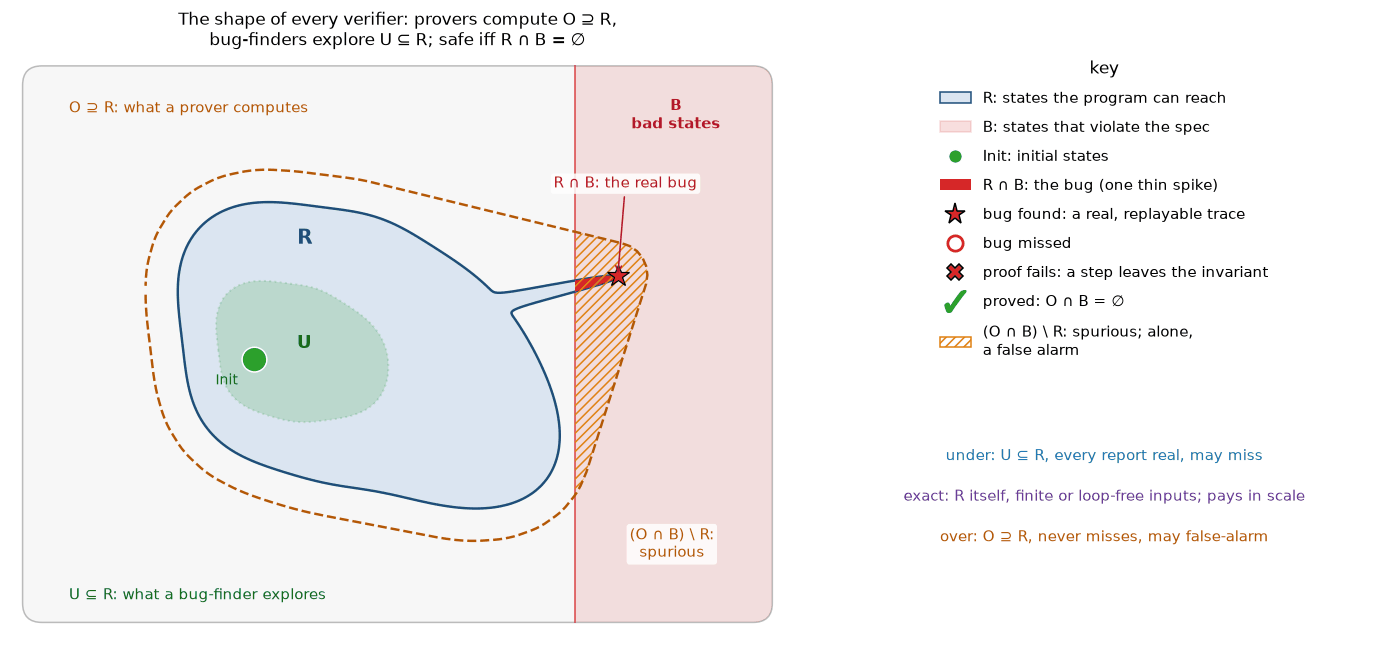

O covers R, spike included, so a prover cannot miss the bug; U sits inside R, so every bug-finder report
is real. Where O pokes into B outside R, the states are spurious: harmless here, a false alarm if R ∩ B = ∅.


In [22]:
_s2_FS = 9.5                                       # in-panel text size
_s2_FIXED_PROGRAM = ('abstract_interp', 'itp')     # panels drawn on the fixed program (R without the spike)
_s2_PANELS = {}                                    # technique -> overlay function (ax, g, marks, rnd), filled below


class _s2_Marks:
    '''The markers every panel shares, bound to one axes: found / missed / refuted / proved, a region, the
    hatched false-alarm area (a region clipped to B) and the bottom note.'''
    def __init__(self, ax, g, R_patch, band):
        self.ax, self.g, self.R_patch, self.band = ax, g, R_patch, band
        self.box = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85)

    def _label(self, label, xy, color, xytext=None):
        xytext = xytext if xytext is not None else (self.g['tip'][0] + 0.1, self.g['tip'][1] + 1.15)
        self.ax.annotate(label, xy, xytext=xytext, fontsize=_s2_FS, color=color, zorder=12, ha="center",
                         bbox=self.box, arrowprops=dict(arrowstyle="->", color=color, lw=1))

    def found(self, label="bug found"):
        self.ax.plot(*self.g['tip'], marker="*", ms=15, color="#d62728", mec="black", mew=0.8, zorder=12)
        self._label(label, self.g['tip'], "#b2182b")

    def missed(self, label="bug missed"):
        self.ax.plot(*self.g['tip'], marker="o", ms=11, mfc="none", mec="#d62728", mew=1.8, zorder=12)
        self._label(label, self.g['tip'], "#b2182b")

    def refuted(self, label, xy):
        self.ax.plot(*xy, marker="X", ms=12, color="#d62728", mec="black", mew=0.8, zorder=12)
        self._label(label, xy, "#b2182b")

    def proved(self, label, xy, xytext):
        self.ax.plot(*xy, marker=r"$\checkmark$", ms=16, color="#2ca02c", zorder=12)
        self._label(label, xy, "#1a6b1a", xytext)

    def region(self, pts, **kw):
        from matplotlib.patches import PathPatch
        from matplotlib.path import Path
        patch = PathPatch(Path(pts), **kw)
        self.ax.add_patch(patch)
        return patch

    def clip(self, artist):
        artist.set_clip_path(self.R_patch)
        return artist

    def false_alarm(self, pts, label, xy):
        fa = self.region(pts, fc="none", ec="#e08214", hatch="////", lw=0, zorder=5)
        fa.set_clip_path(self.band)
        self.ax.text(*xy, label, fontsize=_s2_FS, color="#b35806", ha="center", bbox=self.box, zorder=12)

    def note(self, text):
        self.ax.text(0.75, 0.4, text, fontsize=_s2_FS, zorder=9, va="bottom", linespacing=1.3)


def draw_approx(ax, technique=None, title=True):
    '''The picture behind every verifier, drawn on ax: the state space, R = reachable states, B = bad states,
    Init. technique=None draws the generic picture (O = an over-approximation that provers compute, U = an
    under-approximation that bug-finders explore); a TECHNIQUES key overlays what that technique computes.
    R has one thin spike into B (the bug) and a lobe that comes close to B. The panels 'abstract_interp' and
    'itp' show the FIXED program (R without the spike), where a prover can prove safety or raise a pure false
    alarm. The panel uses data coordinates x in [0, 10], y in [0, 7.5] (aspect 1, axis off), so a caller can add
    its own marks; title=False leaves the title to the caller. Returns ax.'''
    from matplotlib.patches import PathPatch
    from matplotlib.path import Path
    if technique is not None and technique not in TECHNIQUES:
        raise ValueError(f"unknown technique {technique!r}; choose one of {list(TECHNIQUES)}")
    g = _s2_geometry()
    fixed = technique in _s2_FIXED_PROGRAM
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 7.5)
    ax.set_aspect('equal')
    ax.set_axis_off()
    frame = FancyBboxPatch((0.15, 0.15), 9.7, 7.2, boxstyle="round,pad=0,rounding_size=0.25", fc="#f7f7f7",
                           ec="#bbbbbb", lw=1, zorder=0)
    ax.add_patch(frame)
    band = Rectangle((g['x_bad'], 0.15), 9.85 - g['x_bad'], 7.2, fc="#d62728", alpha=0.12, ec="none", zorder=1)
    ax.add_patch(band)
    band.set_clip_path(frame)                       # keep B inside the frame's rounded corners
    ax.plot([g['x_bad']] * 2, [0.15, 7.35], color="#d62728", lw=1.2, alpha=0.7, zorder=1)
    ax.text(8.6, 6.95, "B: old ≠ new" if technique == 'equivalence' else "B\nbad states", color="#b2182b",
            ha="center", va="top", fontsize=_s2_FS + 0.5, fontweight="bold")
    R_patch = PathPatch(Path(g['R_fixed'] if fixed else g['R']), fc="#dbe5f1", ec="#1f4e79", lw=1.6, zorder=3)
    ax.add_patch(R_patch)
    ax.text(*(g['c'] + [-0.35, 1.25]), "R", color="#1f4e79", fontsize=13, fontweight="bold", ha="center", zorder=9)
    if fixed:
        ax.text(0.75, 6.75, "fixed program: R ∩ B = ∅", fontsize=_s2_FS, color="#1a6b1a", fontweight="bold",
                zorder=9)
    else:
        bug = PathPatch(Path(g['R']), fc="#d62728", ec="none", zorder=4)
        ax.add_patch(bug)
        bug.set_clip_path(band)                     # R ∩ B: the real bug, drawn solid red
    ax.add_patch(Circle(g['init'], 0.16, fc="#2ca02c", ec="white", lw=1, zorder=8))
    ax.text(g['init'][0] - 0.22, g['init'][1] - 0.32, "Init", fontsize=_s2_FS - 0.5, color="#1a6b1a", ha="right",
            zorder=9)
    marks = _s2_Marks(ax, g, R_patch, band)
    overlay = _s2_generic if technique is None else _s2_PANELS[technique]
    overlay(ax, g, marks, np.random.default_rng(_s2_SEED_APPROX))
    if title:
        if technique is None:
            ax.set_title("The shape of every verifier: provers compute O ⊇ R,\nbug-finders explore U ⊆ R; "
                         "safe iff R ∩ B = ∅", fontsize=11)
        else:
            d = TECHNIQUES[technique]
            ax.set_title(f"{d['label']}  [{d['approx']}]\n{d['finding']}", fontsize=10.5,
                         color=_s2_FAMILY_COLOR[d['family']])
    return ax


def _s2_generic(ax, g, marks, rnd):
    '''technique=None: O (dashed), U (dotted), and the two ways O meets B.'''
    marks.region(g['O'], fc="none", ec="#b35806", lw=1.6, ls="--", zorder=6)
    marks.false_alarm(g['O'], "(O ∩ B) \\ R:\nspurious", (8.55, 1.0))
    marks.region(g['U'], fc="#2ca02c", alpha=0.18, ec="#2ca02c", lw=1.3, ls=":", zorder=5)
    ax.text(*(g['init'] + [0.55, 0.15]), "U", color="#1a6b1a", fontsize=12, fontweight="bold", zorder=9)
    ax.text(0.75, 6.75, "O ⊇ R: what a prover computes", fontsize=_s2_FS, color="#b35806", zorder=9)
    ax.text(0.75, 0.45, "U ⊆ R: what a bug-finder explores", fontsize=_s2_FS, color="#1a6b1a", zorder=9)
    marks.found("R ∩ B: the real bug")


def _s2_draw_key(ax):
    '''Legend panel for draw_approx's markers and families.'''
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    ax.set_axis_off()
    handles = [Patch(fc="#dbe5f1", ec="#1f4e79", label="R: states the program can reach"),
               Patch(fc="#d62728", alpha=0.15, ec="#d62728", label="B: states that violate the spec"),
               Line2D([], [], marker="o", ls="none", ms=9, mfc="#2ca02c", mec="white", label="Init: initial states"),
               Patch(fc="#d62728", label="R ∩ B: the bug (one thin spike)"),
               Line2D([], [], marker="*", ls="none", ms=14, mfc="#d62728", mec="black",
                      label="bug found: a real, replayable trace"),
               Line2D([], [], marker="o", ls="none", ms=10, mfc="none", mec="#d62728", mew=1.8, label="bug missed"),
               Line2D([], [], marker="X", ls="none", ms=11, mfc="#d62728", mec="black",
                      label="proof fails: a step leaves the invariant"),
               Line2D([], [], marker=r"$\checkmark$", ls="none", ms=14, color="#2ca02c", label="proved: O ∩ B = ∅"),
               Patch(fc="none", ec="#e08214", hatch="////",
                     label="(O ∩ B) \\ R: spurious; alone,\na false alarm")]
    ax.legend(handles=handles, loc="upper center", fontsize=10, frameon=False, title="key", title_fontsize=11,
              labelspacing=0.9, borderaxespad=0)
    for y, (fam, col) in zip((0.30, 0.23, 0.16),
                             (("under: U ⊆ R, every report real, may miss", "#1f77b4"),
                              ("exact: R itself, finite or loop-free inputs; pays in scale", "#6a3d9a"),
                              ("over: O ⊇ R, never misses, may false-alarm", "#b35806"))):
        ax.text(0.5, y, fam, color=col, fontsize=10, ha="center", transform=ax.transAxes)


def _s2_figure_generic():
    fig, (ax, axk) = plt.subplots(1, 2, figsize=(13, 5.8), gridspec_kw=dict(width_ratios=[1.5, 1]))
    draw_approx(ax, None)
    _s2_draw_key(axk)
    plt.tight_layout()
    plt.show()
    print("O covers R, spike included, so a prover cannot miss the bug; U sits inside R, so every bug-finder report")
    print("is real. Where O pokes into B outside R, the states are spurious: harmless here, a false alarm if R ∩ B = ∅.")


_s2_figure_generic()

**Bug-finders and exact methods**, on the buggy program. Each panel overlays what one technique explores; the
star or circle at the spike's tip says whether it reaches the bug. Model checking's dots are coloured by their
breadth-first depth from $\mathit{Init}$, computed on the drawn grid, and its red path is the BFS shortest trace.

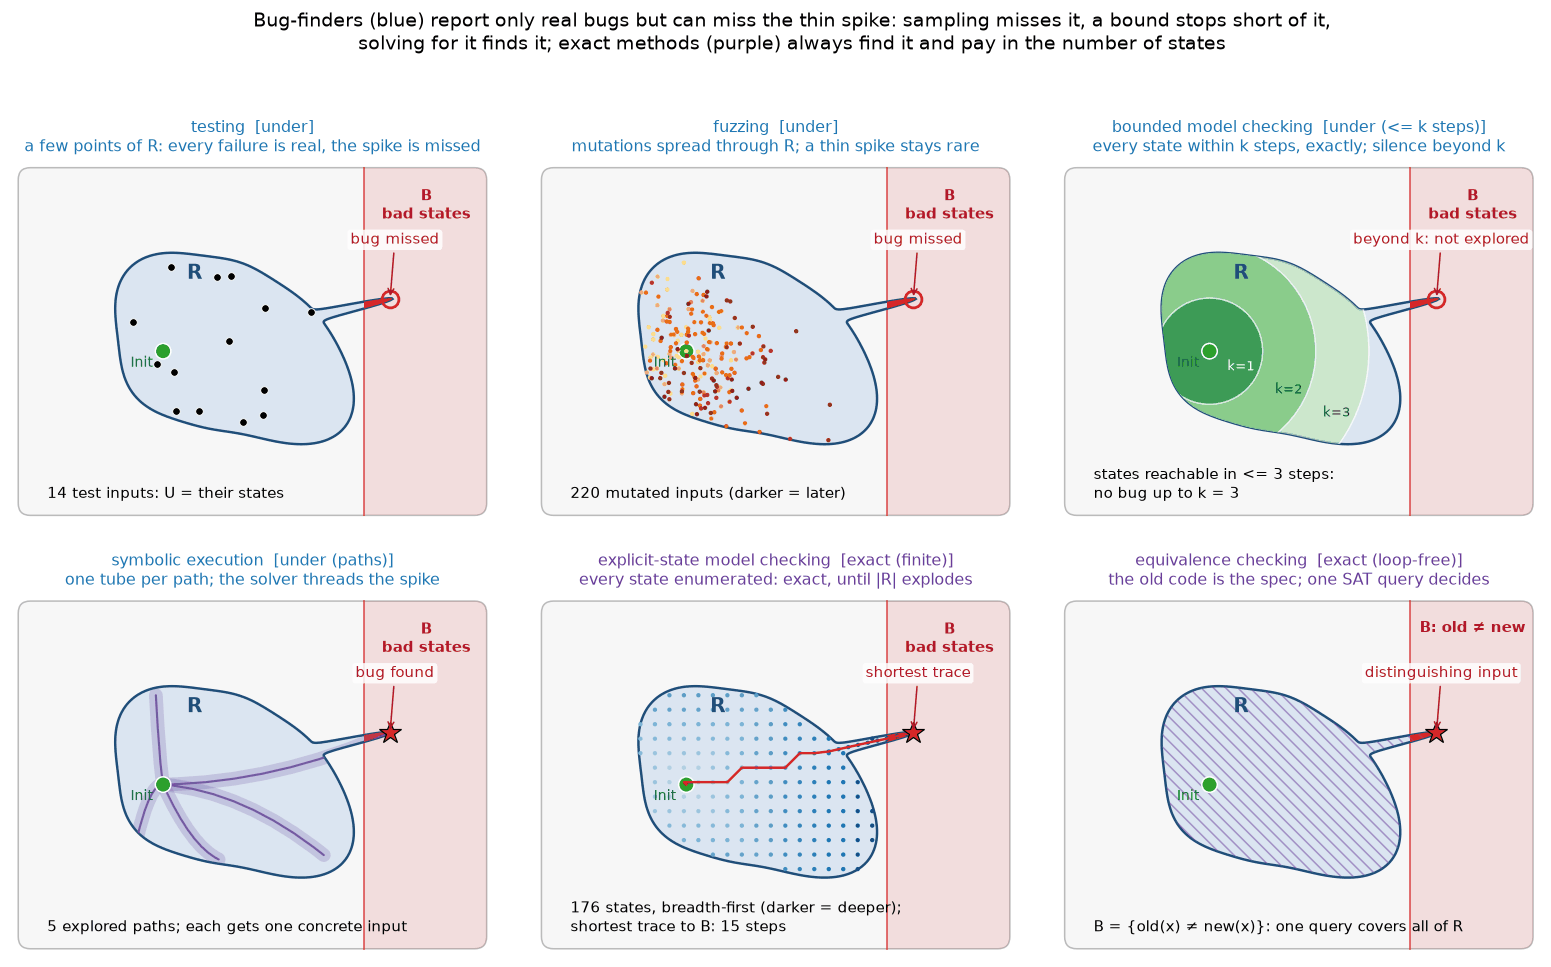

Testing and BMC miss the spike, fuzzing reaches it only if a mutation lands in a sliver, and symbolic
execution and the exact methods reach it because they solve for it or enumerate everything.


In [23]:
def _s2_panel_testing(ax, g, marks, rnd):
    P = _s2_points(g, 14, rnd)
    ax.plot(P[:, 0], P[:, 1], "o", ms=5, color="black", mec="white", mew=0.6, zorder=8)
    marks.note(f"{len(P)} test inputs: U = their states")
    marks.missed()


def _s2_panel_fuzzing(ax, g, marks, rnd):
    P = [g['init']]
    while len(P) < 220:                             # coverage-guided mutation: perturb a random earlier input
        parent = rnd.integers(max(0, len(P) - 20), len(P)) if rnd.random() < 0.6 else rnd.integers(len(P))
        q = P[parent] + rnd.normal(0, 0.45, 2)          # mostly mutate recent (new-coverage) inputs
        if g['inside'](q[None])[0]:
            P.append(q)
    P = np.array(P)
    ax.scatter(P[:, 0], P[:, 1], s=8, c=np.arange(len(P)), cmap="YlOrBr", vmin=-60, ec="none", zorder=8)
    marks.note(f"{len(P)} mutated inputs (darker = later)")
    (marks.found if np.min(np.linalg.norm(P - g['tip'], axis=1)) < 0.15 else marks.missed)()


def _s2_panel_bmc(ax, g, marks, rnd):
    u = np.array([np.cos(-0.45), np.sin(-0.45)])           # label the rings along a ray that stays in R
    for k, (rad, col) in enumerate(((3.3, "#c7e9c0"), (2.2, "#74c476"), (1.1, "#238b45")), start=1):
        marks.clip(ax.add_patch(Circle(g['init'], rad, fc=col, ec="white", lw=1, alpha=0.75, zorder=4)))
        ax.text(*(g['init'] + (rad - 0.38) * u), f"k={4 - k}", fontsize=_s2_FS - 1, zorder=9, ha="center",
                va="center", color="#0b4d1f" if k < 3 else "white")
    marks.note("states reachable in <= 3 steps:\nno bug up to k = 3")
    marks.missed("beyond k: not explored")


def _s2_panel_symex(ax, g, marks, rnd):
    from matplotlib.patches import PathPatch
    from matplotlib.path import Path
    ends = [(3.0, 5.4), (2.6, 2.4), (4.3, 2.0), tuple(g['lobe_tip'] - [0.35, -0.2]), tuple(g['tip'])]
    for j, e in enumerate(ends):
        ctrl = (np.array(g['init']) + np.array(e)) / 2 + [0.0, 0.6 if j % 2 else -0.5]
        path = Path([g['init'], ctrl, e], [Path.MOVETO, Path.CURVE3, Path.CURVE3])
        for lw, a in ((9, 0.22), (1.4, 0.9)):
            marks.clip(ax.add_patch(PathPatch(path, fc="none", ec="#6a51a3", lw=lw, alpha=a, zorder=6,
                                              capstyle="round")))
    marks.note(f"{len(ends)} explored paths; each gets one concrete input")
    marks.found()


def _s2_panel_model_checking(ax, g, marks, rnd):
    '''Enumerate a grid of states in R, one step = a move to a neighbouring grid state, by breadth-first search.'''
    xs, ys = np.meshgrid(np.arange(1.6, 7.9, 0.3), np.arange(1.2, 6.6, 0.3))
    P = np.c_[xs.ravel(), ys.ravel()]
    P = P[g['inside'](P)]
    ray = g['c'] + np.linspace(2.0, 3.65, 9)[:, None] * [np.cos(g['spike_t']), np.sin(g['spike_t'])]
    P = np.vstack([P, ray, g['tip']])                       # the states along the spike, and the bad one
    step = np.linalg.norm(P[:, None] - P[None], axis=2) < 0.45     # neighbours, diagonals included
    start = int(np.argmin(np.linalg.norm(P - g['init'], axis=1)))
    depth = np.full(len(P), -1)
    depth[start], layer = 0, [start]
    while layer:                                            # breadth-first: one layer of new states at a time
        nxt = []
        for i in layer:
            for j in np.flatnonzero(step[i] & (depth < 0)):
                depth[j] = depth[i] + 1
                nxt.append(j)
        layer = nxt
    d = (g['tip'] - g['init']) / np.linalg.norm(g['tip'] - g['init'])
    off_line = lambda Q: np.abs((Q[:, 0] - g['init'][0]) * d[1] - (Q[:, 1] - g['init'][1]) * d[0])
    trace = [len(P) - 1]                                    # back from the tip, one BFS layer at a time; of the
    while trace[-1] != start:                               # shortest paths, draw the one nearest the Init-tip line
        prev = np.flatnonzero(step[trace[-1]] & (depth == depth[trace[-1]] - 1))
        trace.append(int(prev[np.argmin(off_line(P[prev]))]))
    T = np.vstack([g['init'], P[trace[::-1]]])
    ax.scatter(P[:, 0], P[:, 1], s=8, c=depth, cmap="Blues", vmin=-0.4 * depth.max(), vmax=depth.max(), ec="none",
               zorder=7)
    ax.plot(T[:, 0], T[:, 1], color="#d62728", lw=1.6, zorder=10)
    marks.note(f"{len(P)} states, breadth-first (darker = deeper);\nshortest trace to B: {depth[-1]} steps")
    marks.found("shortest trace")


def _s2_panel_equivalence(ax, g, marks, rnd):
    marks.clip(ax.add_patch(Rectangle((0, 0), 10, 7.5, fc="none", ec="#6a3d9a", hatch="\\\\\\", lw=0, alpha=0.5,
                                      zorder=5)))
    marks.note("B = {old(x) ≠ new(x)}: one query covers all of R")
    marks.found("distinguishing input")


_s2_PANELS.update(testing=_s2_panel_testing, fuzzing=_s2_panel_fuzzing, bmc=_s2_panel_bmc, symex=_s2_panel_symex,
                  model_checking=_s2_panel_model_checking, equivalence=_s2_panel_equivalence)


def _s2_figure_under_exact():
    fig, axes = plt.subplots(2, 3, figsize=(14.5, 9.4))
    for ax, t in zip(axes.ravel(), ('testing', 'fuzzing', 'bmc', 'symex', 'model_checking', 'equivalence')):
        draw_approx(ax, t)
    fig.suptitle("Bug-finders (blue) report only real bugs but can miss the thin spike: sampling misses it, a bound "
                 "stops short of it,\nsolving for it finds it; exact methods (purple) always find it and pay in the "
                 "number of states", fontsize=12.5)
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    print("Testing and BMC miss the spike, fuzzing reaches it only if a mutation lands in a sliver, and symbolic")
    print("execution and the exact methods reach it because they solve for it or enumerate everything.")


_s2_figure_under_exact()

**Over-approximations.** A prover never sees $R$. It says "safe" only for a candidate $O$ that contains
$\mathit{Init}$, avoids $B$ and is closed under one step (no step leads out of $O$), and such an $O$ contains $R$
automatically. A candidate that leaves out part of $R$, the spike say, fails the closure check where a step
crosses its boundary, so none of the panels below can miss the bug. Each draws either an $O \supseteq R$ (IC3's
frontier, the interval box, the proof assistant's invariant) or the check that fails when a candidate leaves
part of $R$ out (a human's $I$); what differs is what happens next.

On the buggy program, IC3 keeps a sequence of **frames**: $F_0 = \mathit{Init}$, and each $F_i$
over-approximates the states reachable in at most $i$ steps. Its completed frames $F_1 \subseteq F_2$ stay
outside $B$. It finds a bad state $s$ in the frontier frame $F_3$ and asks for a predecessor of $s$ in $F_2$,
then for a predecessor of that one in $F_1$, and so on. When the chain of these **proof obligations** reaches
$\mathit{Init}$, it is a real trace. A bad state with no predecessor in $F_2$ is instead *blocked*: IC3
strengthens $F_3$ to exclude it (§8.6). k-induction, which has no frames, is §8.5. Deductive verification checks
a human's invariant $I$, which leaves the spike out, and finds that one step from $I$ lands in the spike: the VC
fails. The two panels on the fixed program show the outcomes a buggy program cannot have. The interval box,
looser than $R$'s tightest box, crosses into $B$: a false alarm on a safe program. A proof assistant's invariant
avoids $B$, and its kernel re-checks every proof step.

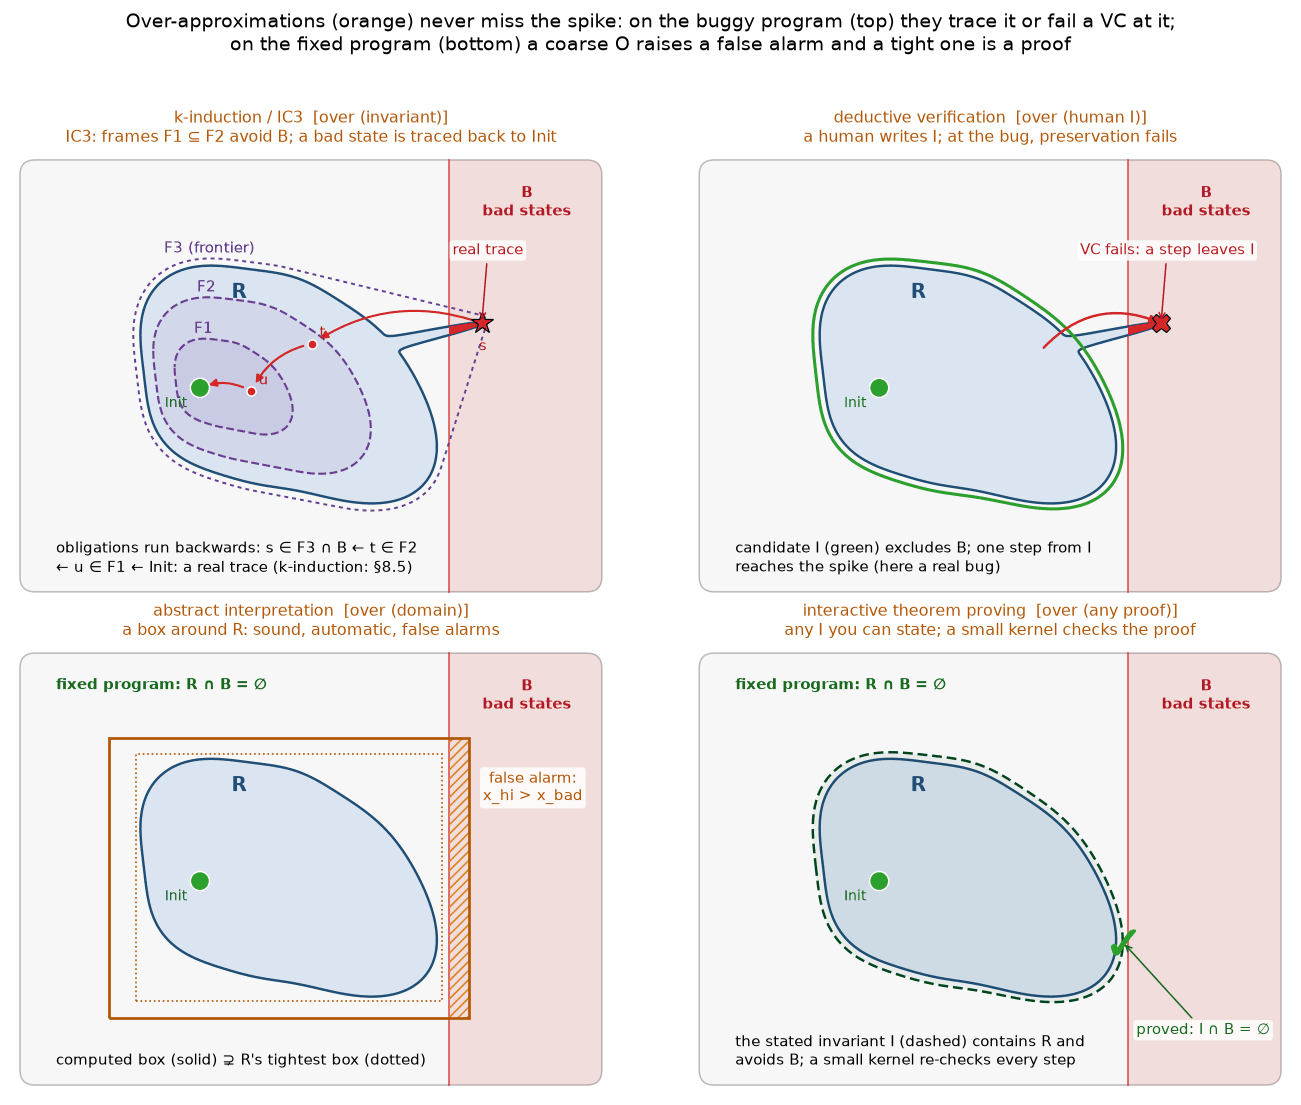

Top: IC3's frames stay outside B, so the bad state comes from the frontier and is traced back to Init;
a human's I fails a VC at the spike. Bottom, bug fixed: loose intervals still cross B (a false alarm),
the proof assistant's I does not (proved).


In [24]:
def _s2_ray_extent(poly, origin, d):
    '''How far from origin, in direction d, the ray stays inside poly (sampled at 0.01).'''
    from matplotlib.path import Path
    ts = np.arange(0, 10, 0.01)
    inside = Path(poly).contains_points(origin + ts[:, None] * d)
    return float(ts[np.argmin(inside)] if not inside.all() else ts[-1])


def _s2_panel_k_induction(ax, g, marks, rnd):
    '''IC3 on the buggy program: frames, the frontier, and the backward chain of proof obligations.'''
    from matplotlib.path import Path
    H = _s2_rounded_hull(g['R_fixed'][::4], 0.12)
    F = {name: g['init'] + s * (H - g['init']) for name, s in (('F1', 0.38), ('F2', 0.7))}
    assert all(f[:, 0].max() < g['x_bad'] for f in F.values()), "IC3's completed frames stay outside B"
    F3 = _s2_rounded_hull(g['R'][::4], 0.12)                # the frontier: not yet cleaned of bad states
    marks.region(F3, fc="none", ec="#6a3d9a", lw=1.3, ls=(0, (2, 2)), zorder=5)
    for name, f in F.items():
        marks.region(f, fc=(0.42, 0.24, 0.6, 0.08), ec="#6a3d9a", lw=1.4, ls="--", zorder=5)
        top = f[np.argmax(f[:, 1])]
        ax.text(top[0], top[1] + 0.1, name, fontsize=_s2_FS, color="#4a1486", zorder=9, ha="center")
    top = F3[np.argmax(F3[:, 1])]
    ax.text(top[0], top[1] + 0.1, "F3 (frontier)", fontsize=_s2_FS, color="#4a1486", zorder=9, ha="center")
    d = (g['tip'] - g['init']) / np.linalg.norm(g['tip'] - g['init'])
    n = np.array([-d[1], d[0]])
    reach = _s2_ray_extent(H, g['init'], d)                  # H's extent along the chain's direction
    t = g['init'] + 0.58 * reach * d + 0.3 * n               # a predecessor of s inside F2 (not in F1)
    u = g['init'] + 0.24 * reach * d - 0.25 * n              # a predecessor of t inside F1
    assert Path(F['F2']).contains_point(t) and not Path(F['F1']).contains_point(t) and Path(F['F1']).contains_point(u)
    chain = [g['tip'], t, u, g['init']]
    for p, q in zip(chain, chain[1:]):                       # obligations run backwards, from B towards Init
        ax.annotate("", q, p, arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=1.4, shrinkA=6, shrinkB=6,
                                              connectionstyle="arc3,rad=0.25"), zorder=11)
    for p, name in ((t, "t"), (u, "u")):
        ax.plot(*p, "o", ms=6, color="#d62728", mec="white", zorder=11)
        ax.text(p[0] + 0.12, p[1] + 0.12, name, fontsize=_s2_FS, color="#b2182b", zorder=11)
    ax.text(g['tip'][0] - 0.05, g['tip'][1] - 0.45, "s", fontsize=_s2_FS, color="#b2182b", zorder=11)
    marks.note("obligations run backwards: s ∈ F3 ∩ B ← t ∈ F2\n← u ∈ F1 ← Init: a real trace (k-induction: §8.5)")
    marks.found("real trace")


def _s2_panel_abstract_interp(ax, g, marks, rnd):
    '''Intervals on the fixed program: the computed box is looser than R's tightest box and crosses into B.'''
    box = lambda lo, hi: np.array([lo, [hi[0], lo[1]], hi, [lo[0], hi[1]], lo])
    lo, hi = g['R_fixed'].min(axis=0) - 0.08, g['R_fixed'].max(axis=0) + 0.08
    assert hi[0] < g['x_bad'], "R's tightest box alone would prove the fixed program"
    marks.region(box(lo, hi), fc="none", ec="#b35806", lw=1.1, ls=":", zorder=6)
    slack = np.array([_s2_AI_SLACK, 0.6 * _s2_AI_SLACK])
    wide = box(lo - slack, hi + slack)
    marks.region(wide, fc="none", ec="#b35806", lw=1.8, zorder=6)
    marks.false_alarm(wide, "false alarm:\nx_hi > x_bad", (8.7, 4.9))
    marks.note("computed box (solid) ⊋ R's tightest box (dotted)")


def _s2_panel_deductive(ax, g, marks, rnd):
    '''A human's invariant I on the buggy program: it excludes B, so the step into the spike breaks it.'''
    marks.region(g['I'], fc="none", ec="#2ca02c", lw=2.0, zorder=6)
    start = g['c'] + 1.75 * np.array([np.cos(g['spike_t']), np.sin(g['spike_t'])])
    ax.annotate("", g['tip'], start, arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=1.6,
                                                     connectionstyle="arc3,rad=-0.35"), zorder=11)
    marks.refuted("VC fails: a step leaves I", g['tip'])
    marks.note("candidate I (green) excludes B; one step from I\nreaches the spike (here a real bug)")


def _s2_panel_itp(ax, g, marks, rnd):
    '''The fixed program: an invariant that contains R and avoids B, every proof step kernel-checked.'''
    marks.region(g['I'], fc=(0.0, 0.27, 0.11, 0.06), ec="#00441b", lw=1.6, ls=(0, (4, 2)), zorder=6)
    near = g['I'][np.argmax(g['I'][:, 0])]                   # I's closest approach to B, beside the lobe
    marks.proved("proved: I ∩ B = ∅", near, (8.55, 1.0))
    marks.note("the stated invariant I (dashed) contains R and\navoids B; a small kernel re-checks every step")


_s2_PANELS.update(k_induction=_s2_panel_k_induction, abstract_interp=_s2_panel_abstract_interp,
                  deductive=_s2_panel_deductive, itp=_s2_panel_itp)


def _s2_figure_over():
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 10.2))
    for ax, t in zip(axes.ravel(), ('k_induction', 'deductive', 'abstract_interp', 'itp')):
        draw_approx(ax, t)
    fig.suptitle("Over-approximations (orange) never miss the spike: on the buggy program (top) they trace it or "
                 "fail a VC at it;\non the fixed program (bottom) a coarse O raises a false alarm and a tight one is "
                 "a proof", fontsize=12.5)
    plt.tight_layout(rect=(0, 0, 1, 0.95), h_pad=2.0)
    plt.show()
    assert set(_s2_PANELS) == set(TECHNIQUES), "every technique has a panel"
    print("Top: IC3's frames stay outside B, so the bad state comes from the frontier and is traced back to Init;")
    print("a human's I fails a VC at the spike. Bottom, bug fixed: loose intervals still cross B (a false alarm),")
    print("the proof assistant's I does not (proved).")


_s2_figure_over()

Across the three figures, the under-approximations meet the spike only by luck (testing, fuzzing), by reaching it
within the bound (BMC) or by solving for it (symbolic execution); the exact methods meet it because they enumerate
everything; the over-approximations cannot miss it, and pay instead in false alarms (the interval box), human
invariants (deductive verification, proof assistants) or non-termination. Every row of the verdict table pays in
at least one column: Rice's theorem forces it on the techniques that take arbitrary programs, and the state count
forces it, in practice, on the finite ones.

### 2.5 The pipeline and the trusted computing base

Every tool, toy or industrial, has the same plumbing: program, spec and semantics pass through a front end into
an *encoding*, an *engine* searches it, and one of three answers comes out. The engine is the big, clever part —
a CDCL solver, Z3, IC3, a tactic framework, an LLM — and the principle that makes its answers trustworthy recurs
in §3, §10 and §13: **check the product, not the producer**. A counterexample is replayed (here by `run_minipy`;
in industry, by running the binary). A "proved" should carry a **certificate** that a small checker re-verifies:
a RUP proof (§3); an inductive invariant, re-checked with one query per verification condition by a second
solver or with a proof that the query emits (§8); a proof term replayed by a kernel (§10). The engine can then be
arbitrarily complex, even an untrusted LLM (§13), without joining the **trusted computing base** (TCB): the
components whose bugs could let a false "proved" through.

The spec never leaves the TCB: no machine can check that it says what you meant, or that the semantics (int+ovf?
which memory model?) is the one your hardware implements. The encoders can leave it, at a price. Verify them
once: Verifiable C, the program logic of Princeton's Verified Software Toolchain, is proved sound with respect to
the operational semantics of CompCert C (vst.cs.princeton.edu), and CompCert's own proof carries the result down
to assembly; the design goal is a trusted base that ends at the machine-language semantics (Appel, ESOP 2011). Or
validate every run: Parthasarathy, Müller & Summers (CAV 2021) emit an Isabelle certificate for each successful
Boogie run, covering its cycle elimination, passification and VC generation. Most tools do neither, and for them
the encoding stays trusted, as the diagram assumes. Verified systems write their TCB down, and it shrinks but
never reaches zero: CompCert still trusts its formal semantics of C, the unverified preprocessing and elaboration
of C into CompCert C, and the external assembler and linker (CompCert user manual, ch. 1). seL4 trusts its few
lines of in-kernel assembly, its boot code, its cache and TLB management and the hardware, plus the C compiler
and linker on every platform except Arm v7 and 64-bit RISC-V, where a further proof that the binary correctly
translates the C removes them; for 64-bit Arm and x86 the proofs stop at the C code (seL4 FAQ). §11 gives the
original 2009 lists, which predate CompCert's verified parser and seL4's binary-level proof, and shows that the
bugs found in verified systems sat in specs, tools and unverified glue code. The program itself is not in the
TCB: it is the thing being checked, so a bug in it makes the proof fail instead of slipping through. Two caveats.
An escape hatch written into the program (an `assume`, a Lean `sorry`, a user axiom; §13.3) is spec in disguise
and must be reviewed like the spec. And the text that was verified must be the code that ships, which is the
compiler's and the build's job. What remains for human review is the spec: usually smaller than the code
(§11.2), and the one artifact that must be right.

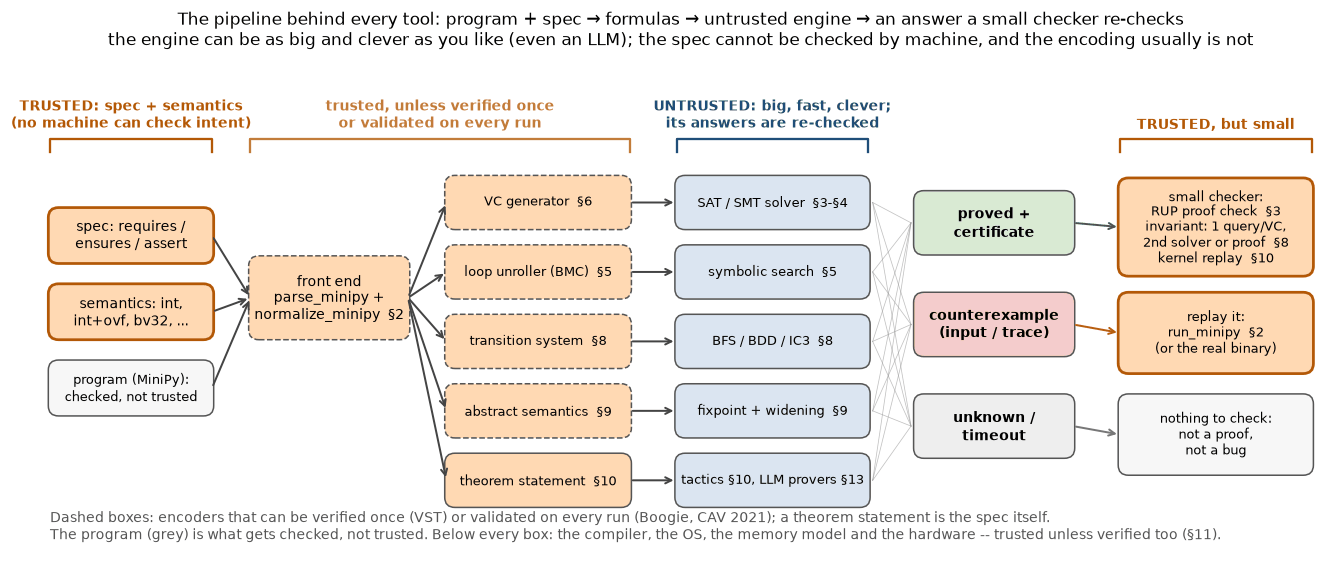

technique                      you must trust                                        re-checked independently                                        
-----------------------------------------------------------------------------------------------------------------------------------------------------
testing                        the oracle (= spec); inputs like production           each failure, by re-running it                                  
fuzzing                        the oracle (crash, sanitizer, assert)                 each crash, by re-running it                                    
bounded model checking         spec, front-end semantics, the bound k, solver UNSAT  a trace, by replaying it                                        
symbolic execution             spec, environment models, solver UNSAT                each generated input, by running it                             
explicit-state model checking  spec, model = code?, checker, memory model            a trace, by rep

In [25]:
_s2_TRUSTED, _s2_UNTRUSTED, _s2_OUT, _s2_CEX = "#ffd9b3", "#dbe5f1", "#d9ead3", "#f4cccc"


def _s2_box(ax, x, y, w, h, text, fc, fs=9, bold=False, ec="#555555", lw=1.0, ls="-"):
    '''A rounded diagram box with centred text; returns its (left, right, centre-y) for arrows.'''
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec=ec, lw=lw,
                                ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal", linespacing=1.25)
    return x, x + w, y + h / 2


def _s2_arrow(ax, p, q, color="#444444", rad=0.0):
    ax.annotate("", q, p, arrowprops=dict(arrowstyle="->", color=color, lw=1.3, shrinkA=2, shrinkB=2,
                                          connectionstyle=f"arc3,rad={rad}"))


def _s2_pipeline_demo():
    '''The pipeline every tool in this notebook instantiates, coloured by what must be trusted; then the TCB table.'''
    fig, ax = plt.subplots(figsize=(15, 5.9))
    ax.set_xlim(0, 15)
    ax.set_ylim(0, 5.9)
    ax.set_axis_off()
    h = 0.62
    # The spec and the semantics are trusted; the program is not: it is the object being checked.
    trusted_in = dict(ec="#b35806", lw=1.8)
    inputs = [_s2_box(ax, 0.1, 3.45, 1.9, h, "spec: requires /\nensures / assert", _s2_TRUSTED, **trusted_in),
              _s2_box(ax, 0.1, 2.55, 1.9, h, "semantics: int,\nint+ovf, bv32, ...", _s2_TRUSTED, **trusted_in),
              _s2_box(ax, 0.1, 1.65, 1.9, h, "program (MiniPy):\nchecked, not trusted", "#f7f7f7", fs=8.5)]
    front = _s2_box(ax, 2.45, 2.55, 1.85, 0.95, "front end\nparse_minipy +\nnormalize_minipy  §2", _s2_TRUSTED,
                    ls="--")
    enc = [_s2_box(ax, 4.75, 3.85 - k * 0.82, 2.15, 0.6, t, _s2_TRUSTED, fs=8.5, ls="-" if k == 4 else "--")
           for k, t in enumerate(["VC generator  §6", "loop unroller (BMC)  §5", "transition system  §8",
                                  "abstract semantics  §9", "theorem statement  §10"])]
    eng = [_s2_box(ax, 7.45, 3.85 - k * 0.82, 2.25, 0.6, t, _s2_UNTRUSTED, fs=8.5) for k, t in enumerate(
        ["SAT / SMT solver  §3-§4", "symbolic search  §5", "BFS / BDD / IC3  §8", "fixpoint + widening  §9",
         "tactics §10, LLM provers §13"])]
    outs = [_s2_box(ax, 10.25, 3.55, 1.85, 0.72, "proved +\ncertificate", _s2_OUT, bold=True),
            _s2_box(ax, 10.25, 2.35, 1.85, 0.72, "counterexample\n(input / trace)", _s2_CEX, bold=True),
            _s2_box(ax, 10.25, 1.15, 1.85, 0.72, "unknown /\ntimeout", "#eeeeee", bold=True)]
    checks = [_s2_box(ax, 12.65, 3.3, 2.25, 1.12, "small checker:\nRUP proof check  §3\ninvariant: 1 query/VC,\n"
                      "2nd solver or proof  §8\nkernel replay  §10", _s2_TRUSTED, fs=8.2, ec="#b35806", lw=1.8),
              _s2_box(ax, 12.65, 2.15, 2.25, 0.92, "replay it:\nrun_minipy  §2\n(or the real binary)", _s2_TRUSTED,
                      fs=8.3, ec="#b35806", lw=1.8),
              _s2_box(ax, 12.65, 0.95, 2.25, 0.92, "nothing to check:\nnot a proof,\nnot a bug", "#f7f7f7", fs=8.3)]
    for _, r, y in inputs:
        _s2_arrow(ax, (r, y), (front[0], front[2]))
    for _, r, y in enc:
        _s2_arrow(ax, (front[1], front[2]), (4.75, y))
    for (_, r, y), (l2, _, y2) in zip(enc, eng):
        _s2_arrow(ax, (r, y), (l2, y2))
    for _, r, y in eng:
        for (l2, _, y2) in outs:
            ax.plot([r + 0.05, l2 - 0.05], [y, y2], color="#999999", lw=0.5, alpha=0.6)
    for (_, r, y), (l2, _, y2) in zip(outs, checks):
        _s2_arrow(ax, (r, y), (l2, y2), color="#2ca02c" if y > 3 else "#d62728" if y > 2 else "#777777")
    # Trust brackets: what must be right, what could be verified, what is re-checked.
    for x0, x1, label, col in ((0.1, 2.0, "TRUSTED: spec + semantics\n(no machine can check intent)", "#b35806"),
                               (2.45, 6.9, "trusted, unless verified once\nor validated on every run", "#c27c3a"),
                               (7.45, 9.7, "UNTRUSTED: big, fast, clever;\nits answers are re-checked", "#1f4e79"),
                               (12.65, 14.9, "TRUSTED, but small", "#b35806")):
        ax.plot([x0, x0, x1, x1], [4.75, 4.9, 4.9, 4.75], color=col, lw=1.5)
        ax.text((x0 + x1) / 2, 4.98, label, ha="center", va="bottom", fontsize=9, color=col, fontweight="bold")
    ax.text(0.1, 0.12, "Dashed boxes: encoders that can be verified once (VST) or validated on every run (Boogie, CAV "
            "2021); a theorem statement is the spec itself.\nThe program (grey) is what gets checked, not "
            "trusted. Below every box: the compiler, the OS, the memory model and the hardware -- trusted unless "
            "verified too (§11).", fontsize=9, color="#555555", va="bottom")
    ax.set_title("The pipeline behind every tool: program + spec → formulas → untrusted engine → an answer a "
                 "small checker re-checks\nthe engine can be as big and clever as you like (even an LLM); the spec "
                 "cannot be checked by machine, and the encoding usually is not", fontsize=11)
    plt.show()

    show_table(["technique", "you must trust", "re-checked independently"],
               [[d['label'], d['trust'], d['checked']] for d in TECHNIQUES.values()])
    print("Every row trusts the spec; no row trusts the engine's counterexamples, which are replayed.")
    print("What differs is how much of the 'safe' answer rests on unchecked code: the solver (deductive, BMC, "
          "k-induction / IC3) or only a small kernel (§10).")


_s2_pipeline_demo()

## 3. Logic as a computation: SAT

Every automatic technique in the rest of this notebook — bit-precise program checking (§4), symbolic execution
and bounded model checking (§5), verification conditions (§6), k-induction and IC3 (§8) — ends the same way: it
writes down a formula and asks *is there an assignment that makes this true?* That question is **SAT**, and the
engine that answers it is the one piece of machinery everything else stands on. The trick that turns a
satisfiability checker into a prover is one line of logic:

$$F \text{ is valid (true for every input)} \iff \neg F \text{ is unsatisfiable.}$$

To prove `abs32(x) >= 0` for all $2^{32}$ inputs you ask for an `x` with `abs32(x) < 0`. *UNSAT* is the proof;
*SAT* hands you the counterexample. This section builds a real conflict-driven SAT solver, small enough to read
top to bottom, and then measures where it is fast, where it is exponential, and how its answers are checked.

### 3.1 Formulas, CNF, and the Tseitin transformation

A solver takes **conjunctive normal form** (CNF): an AND of **clauses**, each an OR of **literals** (a variable
or its negation). We use the DIMACS convention every SAT solver speaks: variable $v$ is the integer `v >= 1`,
its literals are `+v` and `-v`, a clause is a list of ints, a formula a list of clauses. `[[1, -2], [2, 3]]`
means $(x_1 \lor \lnot x_2) \land (x_2 \lor x_3)$.

Programs and circuits are not in CNF, and converting by distributing $\lor$ over $\land$ can explode. Parity
makes it exact: let $P_n = x_1 \oplus \dots \oplus x_n$. Any clause over a *subset* of the variables is
falsified by a whole subcube of assignments; a subcube with even one free variable contains both parities, so
the clause would exclude some model of $P_n$. Hence every clause of *any* CNF for $P_n$ (without new variables)
mentions all $n$ variables, excludes exactly one assignment, and you need one clause per even-parity assignment:
$2^{n-1}$ clauses. 64-bit parity: $9.2\times10^{18}$ clauses.

**Tseitin** ([1968](https://doi.org/10.1007/978-3-642-81955-1_28)) avoids this by naming every gate. For each
gate $g$ with output variable $t_g$, add clauses saying $t_g \leftrightarrow g(\text{inputs})$:

| gate | clauses for $t \leftrightarrow g$ |
|---|---|
| $t = a \land b$ | $(\lnot t \lor a)(\lnot t \lor b)(t \lor \lnot a \lor \lnot b)$ |
| $t = a \lor b$ | $(t \lor \lnot a)(t \lor \lnot b)(\lnot t \lor a \lor b)$ |
| $t = a \oplus b$ | $(\lnot t \lor a \lor b)(\lnot t \lor \lnot a \lor \lnot b)(t \lor \lnot a \lor b)(t \lor a \lor \lnot b)$ |

then assert the output with one unit clause. Stated precisely:

- **Size**: at most 4 clauses and one new variable per 2-input gate, so the CNF is *linear in the number of
  bounded-fan-in gates*. (A $k$-input AND/OR costs $k+1$ clauses, but a $k$-input XOR written directly costs
  $2^{k}$ — the parity blow-up again — which is why wide XORs are chained from 2-input ones.)
- **Models are preserved under projection** — this is the property verification relies on. Because each $t_g$ is
  pinned in *both* directions, its value is a function of the inputs: every input assignment extends to exactly
  one assignment of the auxiliary variables, and every model of the CNF, restricted to the inputs, satisfies the
  circuit. So a counterexample decoded from a solver model is a real input, *and every internal wire in that
  model holds the value the circuit actually computes* (§4 decodes intermediate sums this way).
- **Plaisted–Greenbaum** ([1986](https://doi.org/10.1016/S0747-7171(86)80028-1)) keeps only the direction each
  gate's polarity needs ($t \rightarrow g$ for a positively-occurring gate). Still **equisatisfiable** —
  satisfiable iff the original is, and models still project to real inputs — but the auxiliary values are no
  longer determined: the CNF has *more* models than the circuit, and an internal wire read from a model may be
  wrong.
- **Proving instead of solving**: $F$ is valid iff Tseitin$(\lnot F)$ is UNSAT. For an equivalence $A \equiv B$
  between two circuits, build both, XOR their outputs and assert the XOR — a **miter**. UNSAT means equivalent.

**Check.** For $n$-variable parity: (a) the no-new-variables CNF needs exactly $2^{n-1}$ clauses and *no*
shorter clause is even implied (checked exhaustively for $n \le 6$); (b) the XOR-chain Tseitin CNF has $4(n-1)$
gate clauses + 1 output clause and $n-1$ auxiliary variables, and every one of the $2^n$ input assignments
extends to exactly one model of the gate clauses (checked by brute force for $n \le 10$). Both follow from the
arguments above, so this is a test of the code rather than a bet.

In [26]:
# CNF in DIMACS convention: variable v is the int v >= 1, literal +v / -v, a clause is a list of literals
# (their OR), a formula is a list of clauses (their AND).  Everything below speaks this format.


def _s3_models_mask(clauses, n_vars, start=0, stop=None):
    '''Boolean array: does assignment number a (bit v-1 of a = value of variable v) satisfy every clause?
    Evaluates all assignments in [start, stop) at once with NumPy -- the brute-force oracle.'''
    stop = (1 << n_vars) if stop is None else stop
    a = np.arange(start, stop, dtype=np.int64)
    ok = np.ones(len(a), dtype=bool)
    for clause in clauses:
        sat = np.zeros(len(a), dtype=bool)
        for lit in clause:
            bit = (a >> (abs(lit) - 1)) & 1
            sat |= (bit == 1) if lit > 0 else (bit == 0)
        ok &= sat
    return ok


def brute_force_sat(clauses, n_vars):
    '''Try all 2^n assignments (vectorized, in chunks). Returns a model {v: bool} or None. n_vars <= ~22.'''
    chunk = 1 << 16
    for start in range(0, 1 << n_vars, chunk):
        ok = _s3_models_mask(clauses, n_vars, start, min(start + chunk, 1 << n_vars))
        hits = np.flatnonzero(ok)
        if len(hits):
            a = start + int(hits[0])
            return {v: bool((a >> (v - 1)) & 1) for v in range(1, n_vars + 1)}
    return None


def _s3_check_model(clauses, model):
    '''The SAT certificate check: every clause has a true literal. Linear in the formula size.'''
    return all(any(model[abs(l)] == (l > 0) for l in c) for c in clauses)


def random_3sat(n, m, rnd):
    '''m clauses over n variables, each with 3 distinct variables and random signs (Python ints).'''
    return [[v if rnd.random() < 0.5 else -v for v in rnd.sample(range(1, n + 1), 3)] for _ in range(m)]


# ---- Tseitin vs the no-new-variables CNF, on n-variable parity ---------------------------------------
def _s3_xor_gate(t, a, b):
    '''Two-sided Tseitin clauses for t <-> (a XOR b).'''
    return [[-t, a, b], [-t, -a, -b], [t, -a, b], [t, a, -b]]


def _s3_parity_tseitin(n, assert_output=True):
    '''x1 ^ ... ^ xn = 1 as a chain of n-1 XOR gates. Inputs are 1..n, gate outputs n+1..2n-1.'''
    clauses, prev = [], 1
    for k in range(2, n + 1):
        clauses += _s3_xor_gate(n + k - 1, prev, k)
        prev = n + k - 1
    return clauses + ([[prev]] if assert_output else []), 2 * n - 1


def _s3_parity_direct(n):
    '''The CNF without new variables: one full-length clause excluding each even-parity assignment.'''
    return [[-(i + 1) if bit else i + 1 for i, bit in enumerate(bits)]
            for bits in itertools.product((0, 1), repeat=n) if sum(bits) % 2 == 0]


def _s3_parity_mask(n):
    a = np.arange(1 << n, dtype=np.int64)
    return np.array([bin(int(x)).count("1") % 2 == 1 for x in a])


def _s3_no_short_implicate(n):
    '''True iff no clause over fewer than n of the n variables is implied by x1 ^ ... ^ xn (exhaustive).'''
    par = _s3_parity_mask(n)
    for size in range(1, n):
        for vs in itertools.combinations(range(1, n + 1), size):
            for signs in itertools.product((1, -1), repeat=size):
                clause = [s * v for s, v in zip(signs, vs)]
                if not np.any(par & ~_s3_models_mask([clause], n)):     # every model satisfies it
                    return False
    return True


def _s3_unique_extension(n):
    '''Brute force over all 2^(2n-1) assignments: how many models of the gate clauses does each input have?'''
    gates, n_all = _s3_parity_tseitin(n, assert_output=False)
    ok = _s3_models_mask(gates, n_all)
    per_input = np.bincount(np.flatnonzero(ok) & ((1 << n) - 1), minlength=1 << n)
    full, _ = _s3_parity_tseitin(n)
    models = np.flatnonzero(_s3_models_mask(full, n_all))
    inputs_ok = all(bin(int(m) & ((1 << n) - 1)).count("1") % 2 == 1 for m in models)
    return bool(np.all(per_input == 1)), len(models), inputs_ok


def _s3_tseitin_experiment():
    '''Parity sizes, unique extension, Plaisted-Greenbaum model counts, and a miter proved by refutation.'''
    rows, ok = [], True
    for n in (2, 4, 6, 8, 10, 12):
        direct, (tseitin, n_all) = _s3_parity_direct(n), _s3_parity_tseitin(n)
        direct_ok = bool(np.all(_s3_models_mask(direct, n) == _s3_parity_mask(n)))
        short = _s3_no_short_implicate(n) if n <= 6 else "-"
        uniq, n_models, all_odd = _s3_unique_extension(n) if n <= 10 else (None, None, None)
        ok &= len(direct) == 2 ** (n - 1) and direct_ok and short in (True, "-")
        ok &= len(tseitin) == 4 * (n - 1) + 1 and n_all - n == n - 1
        ok &= uniq in (True, None) and n_models in (2 ** (n - 1), None) and all_odd in (True, None)
        rows.append([n, len(direct), direct_ok, short, len(tseitin), n_all - n,
                     "-" if uniq is None else f"{uniq}, {n_models} models, all odd: {all_odd}"])
    for n in (32, 64):
        rows.append([n, f"{2 ** (n - 1):.2e} (formula)", "-", "-", 4 * (n - 1) + 1, n - 1, "-"])
    show_table(["n", "direct CNF clauses", "= parity?", "no shorter implicate", "Tseitin clauses",
                "aux vars", "unique extension"], rows)
    print(f"check: direct CNF = 2^(n-1) clauses, no shorter implicate; Tseitin = 4(n-1)+1 clauses, n-1 aux "
          f"vars, unique extension | measured: table above | {'PASS' if ok else 'FAIL'}")

    # Plaisted-Greenbaum keeps one direction. F = (x1&x2) | (x3&x4) | (x5&x6) | (x7&x8); gates 9..12, root 13
    g, r = [9, 10, 11, 12], 13
    pairs = [(2 * i + 1, 2 * i + 2) for i in range(4)]
    and_down = sum(([[-gi, a], [-gi, b]] for gi, (a, b) in zip(g, pairs)), [])         # g -> (a and b)
    and_up = [[gi, -a, -b] for gi, (a, b) in zip(g, pairs)]                            # (a and b) -> g
    two_sided = and_down + and_up + [[-r] + g] + [[r, -gi] for gi in g] + [[r]]
    plaisted = and_down + [[-r] + g] + [[r]]
    for label, cnf in (("two-sided Tseitin", two_sided), ("Plaisted-Greenbaum", plaisted)):
        models = [int(m) for m in np.flatnonzero(_s3_models_mask(cnf, 13))]
        inputs = {m & 0xFF for m in models}
        gate_true = lambda m, i: (m >> (2 * i)) & (m >> (2 * i + 1)) & 1               # the real AND value
        wrong = sum(any((m >> (8 + i)) & 1 != gate_true(m, i) for i in range(4)) for m in models)
        print(f"{label:19s}: {len(cnf):2d} clauses, {len(models):3d} models over {len(inputs)} satisfying "
              f"inputs; models with a WRONG internal wire value: {wrong}")

    # validity = UNSAT of the negation: a miter of two 6-input XOR chains associated in opposite orders
    n = 6
    left, _ = _s3_parity_tseitin(n, assert_output=False)                 # ((x1^x2)^x3)^...   out = 11
    right, prev = [], n
    for k in range(n - 1, 0, -1):                                          # x1^(x2^(...^x6))  aux 12..16
        out = 2 * n + (n - 1 - k)
        right += _s3_xor_gate(out, k, prev)
        prev = out
    d = prev + 1
    miter = left + right + _s3_xor_gate(d, 2 * n - 1, prev) + [[d]]
    print(f"miter of the two association orders: {d} vars, {len(miter)} clauses; brute force finds "
          f"{brute_force_sat(miter, d)} -> equivalent on all 2^{n} inputs, proved by refuting the negation")


_s3_tseitin_experiment()

n   direct CNF clauses  = parity?  no shorter implicate  Tseitin clauses  aux vars  unique extension               
-------------------------------------------------------------------------------------------------------------------
2   2                   True       True                  5                1         True, 2 models, all odd: True  
4   8                   True       True                  13               3         True, 8 models, all odd: True  
6   32                  True       True                  21               5         True, 32 models, all odd: True 
8   128                 True       -                     29               7         True, 128 models, all odd: True
10  512                 True       -                     37               9         True, 512 models, all odd: True
12  2048                True       -                     45               11        -                              
32  2.15e+09 (formula)  -          -                     125            

### 3.2 NP-complete, and solved every day anyway

SAT was the first problem shown **NP-complete** (Cook, STOC 1971; independently Levin, 1973): every problem
whose solutions can be checked quickly reduces to it, so a solver that is polynomial on *all* inputs would prove
P = NP. Worst cases are presumably exponential, and §3.5 exhibits a family on which every solver of the kind
built here provably is. And yet hardware and software verification routinely hand SAT solvers formulas with
millions of clauses that come back in seconds. Two things make that possible: **structure** (a circuit is local
— a contradiction usually involves a handful of gates, not the whole formula) and **learning** (the solver turns
each contradiction it hits into a new clause that rules out every assignment sharing its cause).

**DPLL**, as solvers implement it today, is a backtracking search with one inference rule (the 1962 original
also kept Davis & Putnam's pure-literal rule). It is named after Davis & Putnam (1960), whose procedure
eliminated variables by resolution, and Davis, Logemann & Loveland (1962), who replaced that memory-hungry step
with backtracking (Fichte, Le Berre, Hecher & Szeider, CACM 2023, call DLL a memory-efficient refinement of DP).
*Unit propagation*: if every literal of a clause but one is false, the last one must be true
— assign it and repeat. When propagation stalls, *decide*: pick an unassigned variable and guess a value. When
some clause has all literals false (a **conflict**), undo back to the most recent decision whose other branch
is untried, and flip it. **CDCL** (conflict-driven clause learning) is DPLL plus the machinery below; `cdcl()`
has one flag per component, and `dpll()` is literally `cdcl()` with every flag off.

- **Trail, decision levels, reasons.** Assigned literals are kept in order on a *trail*; each records its
  decision level (how many decisions were active) and its *reason*, the clause that forced it. Literals and
  reasons form the **implication graph** (§3.4 draws a real one).
- **Two watched literals.** Chaff measured that "in most cases" over 90% of solver time goes into propagation
  (Moskewicz et al., DAC 2001). A clause can only become unit or conflicting when one of its last two non-false
  literals is falsified, so each clause watches just two literals and is visited only when one of *those*
  becomes false. Backtracking costs nothing: unassigning variables never invalidates a watch, as long as every
  literal sits on the trail at the level where it was really implied, which backjumping guarantees.
- **Conflict analysis and learning** (`learn`; GRASP, Marques-Silva & Sakallah 1996/1999, which introduced
  learned clauses, non-chronological backtracking and *unique implication points*). Start from the all-false
  conflict clause; repeatedly take its most recently assigned current-level literal and **resolve** with that
  literal's reason: $(A \lor \lnot p) \text{ and } (B \lor p) \vdash (A \lor B)$. Each resolvent is implied by
  the formula and is still all-false. Stop when exactly one current-level literal remains. Its variable is the
  *first unique implication point* (1-UIP), a node every path from the current decision to the conflict passes
  through. Stopping at the first one was shown experimentally to be effective by Zhang, Madigan, Moskewicz &
  Malik ([ICCAD 2001](https://doi.org/10.1109/ICCAD.2001.968634)), and it is what MiniSat and its descendants do. The
  **learned clause** is sound (resolution only derives consequences), and it is *asserting*: after undoing to the
  second-highest level among its literals it has exactly one unassigned literal left, so propagation immediately
  flips the UIP.
- **Non-chronological backjumping** (`backjump`): jump straight to that second-highest level. The levels in
  between played no part in the conflict, and DPLL would have re-explored them branch by branch. Off, our toy
  backtracks chronologically: it undoes only the newest level and asserts the flipped UIP there, *above* the
  level where the learned clause really became unit. A later backtrack can then leave a learned clause unit
  without propagating it. That is sound but slower; doing chronological backtracking properly is the subject of
  Nadel & Ryvchin ([SAT 2018](https://doi.org/10.1007/978-3-319-94144-8_7)). The `- backjump` row of §3.5
  therefore measures both effects.
- **VSIDS** (`vsids`). Chaff (2001) introduced it as one counter per *literal*: bump the counters of the literals
  in each added clause, divide all counters periodically, decide the literal with the highest count. We use
  MiniSat's per-variable form (Eén & Sörensson, SAT 2003; the constants follow its released
  [source](https://github.com/niklasso/minisat/blob/master/minisat/core/Solver.cc)): every variable seen during
  conflict analysis is bumped, and the bump grows by $1/0.95$ per conflict, which is the same as decaying all
  activities, so the order is an exponential moving average of recent conflict involvement. Decisions pick the
  most active variable and reuse its last value (**phase saving**, which the 2003 MiniSat paper mentions only as
  an idea and its later releases do by default). Off: lowest-index variable, `False` first.
- **Restarts** (`restarts`): after $100 \cdot \text{luby}(k)$ conflicts with the Luby, Sinclair & Zuckerman
  ([1993](https://doi.org/10.1016/0020-0190(93)90029-9)) sequence $1,1,2,1,1,2,4,\dots$, undo everything but keep
  the learned clauses and activities. This lets the solver back out of bad early decisions without losing what it
  has learned.
- **Clause-database reduction** (`reduce`): learned clauses slow propagation down, because every one of them sits
  on two watch lists (§3.5 measures it). Every 2000 conflicts, delete the worse half ranked by **LBD**, the
  number of distinct decision levels in the clause (Glucose, Audemard & Simon, IJCAI 2009). "Glue" clauses with
  LBD ≤ 2 are always kept, and so is any clause that is currently the reason for an assignment, because deleting
  it would cut the implication graph.

```
            +--------------------- decide (VSIDS / static order) <--------------------+
            v                                                                         | vars left
  propagate (2 watched literals) --> conflict? --no--> all assigned? --no------------+
                                         | yes                 | yes
                                         v                     +--> SAT: return the model
                level 0? --yes--> UNSAT: proof ends with []
                   | no
                   v
  analyze: resolve back to the 1-UIP -> learned clause -> log it to the proof -> backjump
  -> the learned clause is unit: assert the flipped UIP literal -> (restart? reduce?) -> propagate ...
```

For an ML engineer: a learned clause is a *generalized negative example*. It does not say "this assignment
failed"; it says "any assignment containing these three literals fails", which prunes an exponential number of
future branches. VSIDS is attention over variables, driven by where the recent errors were. The contract, used
by §4's bit-blaster:

| call | returns |
|---|---|
| `cdcl(clauses, n_vars, proof=None, max_conflicts=None, learn=True, backjump=True, vsids=True, restarts=True, reduce=True)` | `(status, model, stats)`: status `'SAT'`/`'UNSAT'`/`'UNKNOWN'` (cap hit); model `{v: bool}` or `None`; stats `decisions, conflicts, propagations, learned, restarts, deleted, watch_visits` |
| `dpll(clauses, n_vars, **kw)` | same, with every CDCL feature off |
| `brute_force_sat(clauses, n_vars)` | a model or `None` (all $2^n$ assignments, vectorized; the oracle) |
| `random_3sat(n, m, rnd)` | `m` random 3-clauses over `n` variables from a `random.Random` |
| `check_rup_proof(clauses, proof)` | `True` iff the proof is a valid RUP refutation ending in `[]` (§3.3) |

`cdcl` copies its input, so it never mutates the caller's clauses. With `proof=[]` it appends a copy of every
learned clause, plus `[]` on UNSAT. The solver is one class built up over the next three cells, each cell
extending the class of the one before, so it reads top to bottom like the bullets above. The first cell holds
the state and unit propagation:

In [27]:
import heapq                               # the VSIDS priority queue


def _s3_luby(i):
    '''i-th term (1-based) of the Luby sequence 1,1,2,1,1,2,4,1,1,2,1,1,2,4,8,... (restart schedule).'''
    k = 1
    while (1 << k) - 1 < i:
        k += 1
    if i == (1 << k) - 1:
        return 1 << (k - 1)
    return _s3_luby(i - (1 << (k - 1)) + 1)


class _s3_Propagator:
    '''CDCL, part 1 of 3: the assignment state (trail, decision levels, reasons) and unit propagation
    with two watched literals.  _s3_Learner adds learning and the decision order; _s3_CDCL the main loop.'''
    TRUE, FALSE = 1, -1

    def __init__(self, n_vars):
        self.n_vars = n_vars
        self.stats = dict(decisions=0, conflicts=0, propagations=0, learned=0, restarts=0, deleted=0,
                          watch_visits=0)
        # value[lit] for a SIGNED literal: Python's negative indexing puts value[-v] at the end of the list,
        # so one list of length 2n+1 holds the value of every literal (0 = unassigned).
        self.value = [0] * (2 * n_vars + 1)
        self.level = [0] * (n_vars + 1)        # decision level at which each variable was assigned
        self.reason = [None] * (n_vars + 1)    # the clause that implied it (None: decision / level-0 unit)
        self.trail = []                        # assigned literals in assignment order
        self.trail_lim = []                    # trail_lim[d] = trail index where decision level d+1 starts
        self.watches = defaultdict(list)       # watches[lit] = clauses whose two watched literals include lit
        self.qhead = 0                         # trail[qhead:] still has to be propagated

    def assign(self, lit, why):
        '''Make lit true at the current decision level, forced by clause `why` (None for a decision).'''
        self.value[lit], self.value[-lit] = self.TRUE, self.FALSE
        self.level[abs(lit)] = len(self.trail_lim)
        self.reason[abs(lit)] = why
        self.trail.append(lit)

    def attach(self, c):
        '''Watch the first two literals of a clause (2-watched-literal scheme, Chaff 2001).'''
        self.watches[c[0]].append(c)
        self.watches[c[1]].append(c)

    def propagate(self):
        '''Unit propagation (BCP). Only clauses watching a literal that just became false are visited.
        Returns a conflicting clause (all literals false) or None.'''
        TRUE, FALSE = self.TRUE, self.FALSE
        value, level, reason, trail, watches = self.value, self.level, self.reason, self.trail, self.watches
        current = len(self.trail_lim)                 # propagation never opens a new decision level
        qhead = start = self.qhead
        visits = 0                                    # clauses examined: the real cost of propagation
        while qhead < len(trail):
            false_lit = -trail[qhead]
            qhead += 1
            ws = watches[false_lit]
            i = j = 0                                 # ws[:j] = clauses that keep watching false_lit
            n = len(ws)
            while i < n:
                c = ws[i]
                i += 1
                if c[0] == false_lit:                 # keep the false watch in slot 1
                    c[0], c[1] = c[1], false_lit
                first = c[0]
                if value[first] == TRUE:              # satisfied by the other watch: nothing to do
                    ws[j] = c
                    j += 1
                    continue
                for k in range(2, len(c)):            # find a non-false literal to watch instead
                    lit = c[k]
                    if value[lit] != FALSE:
                        c[1], c[k] = lit, false_lit
                        watches[lit].append(c)        # moved: c no longer watches false_lit
                        break
                else:                                 # no replacement: c is unit or conflicting
                    ws[j] = c
                    j += 1
                    if value[first] == FALSE:         # every literal false: a conflict
                        ws[j:] = ws[i:]               # keep the watchers we did not get to
                        self.qhead = qhead
                        self.stats['propagations'] += qhead - start
                        self.stats['watch_visits'] += visits + i
                        return c
                    value[first], value[-first] = TRUE, FALSE      # assign(first, c), inlined:
                    level[abs(first)] = current                    # this is the hottest line of the solver
                    reason[abs(first)] = c
                    trail.append(first)
            del ws[j:]
            visits += n
        self.qhead = qhead
        self.stats['propagations'] += qhead - start
        self.stats['watch_visits'] += visits
        return None

The second cell adds what turns a conflict into knowledge: 1-UIP analysis, backtracking, the VSIDS order with
phase saving, and `reduce_db`. Each method is one bullet of the list above.

In [28]:
class _s3_Learner(_s3_Propagator):
    '''CDCL, part 2 of 3: 1-UIP conflict analysis, backtracking, the VSIDS decision order with phase
    saving, and clause-database reduction.'''

    def __init__(self, n_vars, vsids=True, vsids_decay=0.95):
        super().__init__(n_vars)
        self.vsids, self.vsids_decay = vsids, vsids_decay
        self.activity = [0.0] * (n_vars + 1)
        self.bump_inc = 1.0                    # grows by 1/decay per conflict = decaying every activity
        self.heap = [(0.0, v) for v in range(1, n_vars + 1)]   # max-activity heap, lazy deletion
        self.saved_phase = [False] * (n_vars + 1)
        self.next_static = 1                   # vsids=False: every variable below this one is assigned
        self.flipped = []                      # DPLL bookkeeping: has this level's decision been flipped?
        self.learned_db = []                   # [clause, lbd] for every learned clause still alive

    def bump(self, v):
        '''VSIDS: add the current increment to v's activity (rescale everything before floats overflow).'''
        activity = self.activity
        activity[v] += self.bump_inc
        if activity[v] > 1e100:
            for u in range(1, self.n_vars + 1):
                activity[u] *= 1e-100
            self.bump_inc *= 1e-100
            self.heap = [(-activity[u], u) for u in range(1, self.n_vars + 1) if self.value[u] == 0]
            heapq.heapify(self.heap)
        heapq.heappush(self.heap, (-activity[v], v))

    def analyze(self, conflict):
        '''1-UIP conflict analysis.  Resolve the conflict clause with the reasons of current-level
        literals, newest first, until exactly one current-level literal is left: the first unique
        implication point (UIP).  Returns (learned clause with the UIP's negation first, backjump level).'''
        level, reason, trail = self.level, self.reason, self.trail
        current = len(self.trail_lim)
        seen = set()
        lower = []                                    # literals from earlier decision levels
        pending = 0                                   # current-level literals not yet resolved away
        clause, idx = conflict, len(trail) - 1
        while True:
            for q in clause:
                v = abs(q)
                if v in seen or level[v] == 0:        # level-0 facts are permanently false: drop them
                    continue
                seen.add(v)
                if self.vsids:
                    self.bump(v)
                if level[v] == current:
                    pending += 1
                else:
                    lower.append(q)
            while abs(trail[idx]) not in seen:        # newest trail literal taking part
                idx -= 1
            p = trail[idx]
            idx -= 1
            pending -= 1
            if pending == 0:
                break                                 # p is the first UIP
            clause = reason[abs(p)]                   # resolve on p (p itself is skipped: already seen)
        learned = [-p] + lower
        if len(learned) == 1:
            return learned, 0
        j = max(range(1, len(learned)), key=lambda k: level[abs(learned[k])])
        learned[1], learned[j] = learned[j], learned[1]   # 2nd watch = the literal from the highest level
        return learned, level[abs(learned[1])]

    def backtrack(self, lvl):
        '''Undo every decision level above lvl.  Unassigned variables remember their last value (phase
        saving) and go back into the VSIDS heap.  Watches need no repair (see the markdown above).'''
        trail, trail_lim = self.trail, self.trail_lim
        if len(trail_lim) <= lvl:
            return
        value, reason, activity, saved_phase = self.value, self.reason, self.activity, self.saved_phase
        for lit in trail[trail_lim[lvl]:]:
            v = abs(lit)
            saved_phase[v] = lit > 0
            value[lit] = value[-lit] = 0
            reason[v] = None
            if self.vsids:
                heapq.heappush(self.heap, (-activity[v], v))
            else:
                self.next_static = min(self.next_static, v)
        del trail[trail_lim[lvl]:]
        del trail_lim[lvl:]
        del self.flipped[lvl:]
        self.qhead = len(trail)

    def pick_branch_literal(self):
        '''VSIDS: the most active unassigned variable, with its saved phase.  Off: the lowest-index
        unassigned variable, False first.  None when everything is assigned.'''
        value = self.value
        if self.vsids:
            if len(self.heap) > 8 * self.n_vars + 1000:   # drop the stale entries now and then
                self.heap = [(-self.activity[u], u) for u in range(1, self.n_vars + 1) if value[u] == 0]
                heapq.heapify(self.heap)
            heap = self.heap
            while heap:
                _, v = heapq.heappop(heap)
                if value[v] == 0:
                    return v if self.saved_phase[v] else -v
            return None
        while self.next_static <= self.n_vars and value[self.next_static] != 0:
            self.next_static += 1
        return -self.next_static if self.next_static <= self.n_vars else None

    def reduce_db(self):
        '''Delete the worse half (by LBD, then length) of the deletable learned clauses.  Kept always:
        "glue" clauses (LBD <= 2), binary clauses, and any clause that is the reason of a current literal.'''
        reason, value = self.reason, self.value
        locked = lambda c: reason[abs(c[0])] is c and value[c[0]] == self.TRUE
        keep_always = lambda e: e[1] <= 2 or len(e[0]) <= 2 or locked(e[0])
        keep = [e for e in self.learned_db if keep_always(e)]
        rest = sorted((e for e in self.learned_db if not keep_always(e)), key=lambda e: (e[1], len(e[0])))
        dead = rest[len(rest) // 2:]
        dead_ids = {id(e[0]) for e in dead}
        for lit in {lit for e in dead for lit in e[0][:2]}:
            self.watches[lit] = [c for c in self.watches[lit] if id(c) not in dead_ids]
        self.learned_db[:] = keep + rest[:len(rest) // 2]
        self.stats['deleted'] += len(dead)

The third cell is the flowchart: load the formula, then propagate, and on each conflict either learn and
backjump or, with `learn=False`, flip the last decision as DPLL does. `cdcl()` and `dpll()` are thin wrappers
around it.

In [29]:
class _s3_CDCL(_s3_Learner):
    '''CDCL, part 3 of 3: load the formula, then loop -- propagate; on a conflict learn, log the lemma and
    backjump (or, without learning, flip the last decision as DPLL does); otherwise decide.'''

    def __init__(self, n_vars, learn=True, backjump=True, vsids=True, restarts=True, reduce=True,
                 restart_base=100, vsids_decay=0.95, reduce_every=2000, proof=None, on_conflict=None):
        super().__init__(n_vars, vsids=vsids, vsids_decay=vsids_decay)
        self.learn, self.backjump = learn, backjump
        self.restarts, self.reduce = restarts and learn, reduce and learn   # both need learned clauses
        self.restart_base, self.reduce_every = restart_base, reduce_every
        self.proof, self.on_conflict = proof, on_conflict

    def load(self, clauses):
        '''Copy the clauses in (the caller's lists are never touched).  False if trivially UNSAT.'''
        for c in clauses:
            c = list(dict.fromkeys(c))                # drop duplicate literals
            if any(-l in c for l in c):
                continue                              # tautology: always true
            if not c or (len(c) == 1 and self.value[c[0]] == self.FALSE):
                return False                          # empty clause, or two contradictory units
            if len(c) == 1:
                if self.value[c[0]] == 0:
                    self.assign(c[0], None)           # unit clause: a level-0 fact
            else:
                self.attach(c)
        return True

    def snapshot(self, conflict, learned, target):
        '''What on_conflict receives: copies of the trail, levels, reasons, conflict and learned clause.'''
        trail, level, reason = self.trail, self.level, self.reason
        return dict(trail=list(trail), level={abs(l): level[abs(l)] for l in trail},
                    reason={abs(l): (list(reason[abs(l)]) if reason[abs(l)] else None) for l in trail},
                    conflict=list(conflict), learned=list(learned), backjump=target)

    def solve(self, clauses, max_conflicts=None):
        proof, stats = self.proof, self.stats
        if not self.load(clauses):
            if proof is not None:
                proof.append([])
            return 'UNSAT', None, stats
        trail, trail_lim, flipped = self.trail, self.trail_lim, self.flipped
        restart_count, conflicts_since_restart = 1, 0
        while True:
            conflict = self.propagate()
            if conflict is None:                      # ---- no conflict: decide, or report a model
                lit = self.pick_branch_literal()
                if lit is None:                       # everything assigned, no conflict: a model
                    return 'SAT', {v: self.value[v] == self.TRUE for v in range(1, self.n_vars + 1)}, stats
                stats['decisions'] += 1
                trail_lim.append(len(trail))
                flipped.append(False)
                self.assign(lit, None)
                continue
            stats['conflicts'] += 1                   # ---- a conflict
            conflicts_since_restart += 1
            if not trail_lim:                         # conflict with no decisions: UNSAT
                if proof is not None:
                    proof.append([])
                return 'UNSAT', None, stats
            if self.learn:
                learned, target = self.analyze(conflict)
                if not self.backjump and len(learned) > 1:
                    # chronological: undo only the newest level.  The asserted literal then sits above its
                    # true implication level, so a later backtrack can leave this clause unit without
                    # propagating it: sound, but slower (Nadel & Ryvchin, SAT 2018, do it properly)
                    target = len(trail_lim) - 1
                if self.on_conflict is not None and self.on_conflict(self.snapshot(conflict, learned, target)):
                    return 'UNKNOWN', None, stats
                self.backtrack(target)
                if proof is not None:
                    proof.append(list(learned))
                if len(learned) == 1:
                    self.assign(learned[0], None)     # a learned unit holds at level 0
                else:
                    self.attach(learned)
                    lbd = len({self.level[abs(l)] for l in learned})
                    self.learned_db.append([learned, lbd])
                    self.assign(learned[0], learned)  # the clause is now unit: assert the UIP's negation
                stats['learned'] += 1
                self.bump_inc /= self.vsids_decay     # VSIDS: newer conflicts weigh more
            else:
                if self.vsids:
                    for q in conflict:
                        self.bump(abs(q))
                    self.bump_inc /= self.vsids_decay
                while trail_lim and flipped[-1]:      # DPLL: pop levels whose both branches failed
                    self.backtrack(len(trail_lim) - 1)
                if not trail_lim:
                    if proof is not None:
                        proof.append([])
                    return 'UNSAT', None, stats
                d = len(trail_lim)
                decision = trail[trail_lim[-1]]
                if proof is not None:                 # "this combination of decisions fails"
                    proof.append([-trail[trail_lim[i]] for i in range(d) if not flipped[i]])
                self.backtrack(d - 1)
                trail_lim.append(len(trail))
                flipped.append(True)
                self.assign(-decision, None)          # try the other branch
            if max_conflicts is not None and stats['conflicts'] >= max_conflicts:
                return 'UNKNOWN', None, stats
            if self.restarts and conflicts_since_restart >= self.restart_base * _s3_luby(restart_count):
                restart_count += 1
                conflicts_since_restart = 0
                stats['restarts'] += 1
                self.backtrack(0)
            if self.reduce and stats['conflicts'] % self.reduce_every == 0:
                self.reduce_db()


def cdcl(clauses, n_vars, proof=None, max_conflicts=None, learn=True, backjump=True, vsids=True,
         restarts=True, reduce=True, *, restart_base=100, vsids_decay=0.95, reduce_every=2000,
         on_conflict=None):
    '''Conflict-driven clause learning SAT solver.  Returns (status, model, stats):
    status 'SAT' | 'UNSAT' | 'UNKNOWN' (conflict cap hit), model {v: bool} or None, stats a dict with
    decisions, conflicts, propagations, learned, restarts, deleted and watch_visits (clauses examined).

    Ablation flags (all on = a MiniSat-style CDCL; all off = DPLL):
      learn     1-UIP clause learning.  Off: DPLL's chronological "flip the last unflipped decision".
      backjump  non-chronological backjumping to the asserting level (needs learn; off = undo one level)
      vsids     VSIDS activity order + phase saving.  Off: lowest-index unassigned variable, False first.
      restarts  Luby restarts every restart_base * luby(k) conflicts (needs learn)
      reduce    every reduce_every conflicts delete the worse half of learned clauses (needs learn);
                reasons of current assignments, binary and "glue" clauses (LBD <= 2) are never deleted.
    proof: if a list, every learned clause is appended as a copy (RUP format, deletions not logged) and []
    ends an UNSAT run.  In DPLL mode the logged lemma is the negation of the unflipped decisions (also RUP).
    on_conflict(info): optional callback (learn mode) with a snapshot of the solver state at each conflict;
    a truthy return value stops the search (status 'UNKNOWN').  The caller's clauses are never mutated.'''
    solver = _s3_CDCL(n_vars, learn=learn, backjump=backjump, vsids=vsids, restarts=restarts, reduce=reduce,
                      restart_base=restart_base, vsids_decay=vsids_decay, reduce_every=reduce_every,
                      proof=proof, on_conflict=on_conflict)
    return solver.solve(clauses, max_conflicts)


def dpll(clauses, n_vars, **kw):
    '''DPLL (Davis-Logemann-Loveland 1962): cdcl with every CDCL feature switched off.'''
    return cdcl(clauses, n_vars, learn=False, backjump=False, vsids=False, restarts=False, reduce=False, **kw)


_s3_demo_proof = []
print("smoke test: all four clauses over x1, x2 ->",
      cdcl([[1, 2], [-1, 2], [1, -2], [-1, -2]], 2, proof=_s3_demo_proof)[0], "with RUP proof", _s3_demo_proof,
      "| (x1 or x2) alone ->", cdcl([[1, 2]], 2)[:2])

smoke test: all four clauses over x1, x2 -> UNSAT with RUP proof [[1], []] | (x1 or x2) alone -> ('SAT', {1: False, 2: True})


### 3.3 Don't trust the solver: certificates for both answers

A `SAT` answer carries its own certificate. The model can be checked against every clause in one linear pass,
and that check is far simpler than the solver. `UNSAT` is a claim about all $2^n$ assignments, and an UNSAT bug
in a verifier is the dangerous kind: it reads as "proved". The certificate is the stream of learned clauses.
Each was produced by a propagation that ran into a conflict, so it satisfies **RUP** (*reverse unit
propagation*):

$$F \land \lnot C \;\vdash_{\text{unit propagation}}\; \bot \quad\Longrightarrow\quad F \models C .$$

Assign every literal of the lemma $C$ false, unit-propagate over the formula plus the lemmas accepted so far,
and a conflict must appear. If it does, every model of $F$ satisfies $C$, so $C$ can be added. A **refutation**
is a list of lemmas ending with the empty clause `[]`; once `[]` is accepted, $F$ has no model. The checker
below needs nothing but unit propagation. It is written independently of `cdcl` (occurrence lists instead of
watched literals, no shared code), so a bug in the solver cannot hide behind the same bug in the checker. This
is the notebook's fourth spine idea in miniature: *check the product, not the producer*. DPLL produces proofs
too: at each flip it logs the negation of the decisions still standing, which is also RUP (a tree-shaped
resolution proof).

Industrial solvers emit the same thing in **DRAT** format: RUP plus clause deletions plus the RAT rule for
inprocessing. DRAT-trim checks it *backwards*, verifying only the lemmas the final contradiction actually
depends on (Wetzler, Heule & Hunt, SAT 2014). The SAT Competition has required unsatisfiability certificates in
its UNSAT tracks since 2013 and for every main-track solver since 2016. In 2025 an UNSAT answer counted only if
a *formally verified* checker accepted it (cake_lpr, GRAT or VeriPB/CakePB), with 45,000 s for the checker
tool-chain against 5,000 s for solving; the organisers note that checking time is "roughly similar to solving
time" ([SAT Competition 2025 slides](https://satcompetition.github.io/2025/satcomp25slides.pdf)).

The cell below defines the checker. It then cross-checks every solver configuration against the brute-force
oracle. Three formulas in four are random 3-SAT in the hard region. Every fourth is *mixed-shape*, with empty,
unit and long clauses, repeated literals, tautologies and unused variables, which exercise the loader's special
cases. Every model is verified, every UNSAT proof is RUP-checked, and the caller's clauses are checked to be
untouched. Finally the cell tries to fool the checker five ways, because a checker that accepts everything
proves nothing.

In [30]:
def _s3_rup_check(clauses, proof):
    '''Forward RUP checker, written independently of cdcl (occurrence lists, no watched literals).
    A lemma C is accepted iff assigning every literal of C false and unit-propagating over the
    formula + previously accepted lemmas yields a conflict (then formula |= C).  The proof must end
    with the empty clause [].  Returns (ok, index of the first rejected lemma or None, message).'''
    long_clauses, units, occurs = [], [], defaultdict(list)
    has_empty = [False]

    def add(c):
        c = list(dict.fromkeys(c))
        if not c:
            has_empty[0] = True
        elif len(c) == 1:
            units.append(c[0])
        else:
            for lit in c:
                occurs[lit].append(len(long_clauses))
            long_clauses.append(c)

    def propagates_to_conflict(assumed):
        if has_empty[0]:
            return True
        val, queue = {}, []
        for lit in list(assumed) + units:
            if abs(lit) in val:
                if val[abs(lit)] != (lit > 0):
                    return True                         # contradictory assumptions / units
                continue
            val[abs(lit)] = lit > 0
            queue.append(lit)
        while queue:
            lit = queue.pop()
            for ci in occurs[-lit]:                     # clauses in which `lit` falsified a literal
                free, n_free = None, 0
                for q in long_clauses[ci]:
                    x = val.get(abs(q))
                    if x is None:
                        free, n_free = q, n_free + 1
                        if n_free > 1:
                            break                       # two unassigned: not unit yet
                    elif x == (q > 0):
                        break                           # satisfied
                else:
                    if n_free == 0:
                        return True                     # every literal false: conflict
                    val[abs(free)] = free > 0           # unit: propagate
                    queue.append(free)
        return False

    for c in clauses:
        add(c)
    for i, lemma in enumerate(proof):
        if not propagates_to_conflict([-l for l in lemma]):
            return False, i, f"lemma #{i} {lemma} is not RUP"
        if not lemma:
            return True, None, f"accepted: [] derived after {i} lemmas"
        add(lemma)
    return False, len(proof), "rejected: the proof never derives []"


def check_rup_proof(clauses, proof):
    '''True iff `proof` is a valid RUP refutation of `clauses` (every lemma RUP, ending with []).'''
    return _s3_rup_check(clauses, proof)[0]


_s3_SEED = 2026
_s3_CONFIGS = {                                  # the ablation configurations used throughout §3
    "CDCL (all on)": {},
    "- learn": dict(learn=False),
    "- backjump": dict(backjump=False),
    "- vsids": dict(vsids=False),
    "- restarts": dict(restarts=False),
    "- reduce": dict(reduce=False),
    "DPLL (all off)": dict(learn=False, backjump=False, vsids=False, restarts=False, reduce=False),
}


def _s3_random_mixed(n, m, rnd):
    '''m clauses of 0-5 literals over n variables, repeats and tautologies allowed: the shapes random 3-SAT
    never produces (empty clause, units, contradictory units, duplicate literals, unused variables), which
    is where the solver's loader and its level-0 handling could go wrong.'''
    clauses = []
    for _ in range(m):
        k = 0 if rnd.random() < 0.01 else rnd.choice((1, 2, 2, 3, 3, 3, 4, 5))
        clauses.append([rnd.choice((1, -1)) * rnd.randint(1, n) for _ in range(k)])
    return clauses


def _s3_cross_check(n_formulas=600):
    '''Every configuration vs brute force.  Three formulas in four are random 3-SAT with 4..14 variables and
    m/n in [3, 6.5] (the hard region); every fourth is mixed-shape.  Also checks that the input is untouched.'''
    rnd = random.Random(_s3_SEED)
    out = dict(mismatches=0, bad_models=0, bad_proofs=0, mutated=0, unsat=0, proofs=0, mixed=0)
    for t in range(n_formulas):
        n = rnd.randint(4, 14)
        if t % 4 == 3:
            clauses = _s3_random_mixed(n, rnd.randint(n, 4 * n), rnd)
            out["mixed"] += 1
        else:
            clauses = random_3sat(n, round(rnd.uniform(3.0, 6.5) * n), rnd)
        original = [list(c) for c in clauses]
        truth = brute_force_sat(clauses, n)
        out["unsat"] += truth is None
        for name, flags in _s3_CONFIGS.items():
            flags = dict(flags, reduce_every=3) if flags.get("reduce", True) else flags   # exercise reduce_db
            proof = []
            status, model, _ = cdcl(clauses, n, proof=proof, **flags)
            out["mismatches"] += (status == "SAT") != (truth is not None)
            out["mutated"] += clauses != original
            if status == "SAT":
                out["bad_models"] += not _s3_check_model(clauses, model)
            else:
                out["proofs"] += 1
                out["bad_proofs"] += not check_rup_proof(clauses, proof)
    return out


def _s3_certificate_tests():
    '''Cross-check against brute force, then feed the checker valid and broken proofs.'''
    cc, dt = timed(_s3_cross_check)
    n_formulas = 600
    print(f"{len(_s3_CONFIGS)} configurations x {n_formulas} formulas ({n_formulas - cc['mixed']} random 3-SAT, "
          f"{cc['mixed']} mixed-shape; {cc['unsat']} UNSAT by brute force): {cc['mismatches']} SAT/UNSAT "
          f"mismatches, {cc['bad_models']} invalid models, {cc['bad_proofs']} rejected proofs out of "
          f"{cc['proofs']}, {cc['mutated']} runs that modified the caller's clauses  (~{dt:.1f} s)")

    # ---- now try to fool the checker -------------------------------------------------------------------
    rnd = random.Random(_s3_SEED + 1)
    while True:                                       # a 40-variable UNSAT formula with a mid-sized proof
        unsat_f = random_3sat(40, 200, rnd)
        proof = []
        if cdcl(unsat_f, 40, proof=proof)[0] == "UNSAT" and len(proof) > 40:
            break
    sat_f = random_3sat(40, 120, rnd)
    assert cdcl(sat_f, 40)[0] == "SAT"

    drop_lemma = [_s3_rup_check(unsat_f, proof[:i] + proof[i + 1:])[0] for i in range(len(proof) - 1)]
    drop_literal = {i: _s3_rup_check(unsat_f, proof[:i] + [proof[i][1:]] + proof[i + 1:])[0]
                    for i in range(len(proof) - 1) if len(proof[i]) > 1}
    first_lemma = drop_lemma.index(False)
    first_literal = min(i for i, ok in drop_literal.items() if not ok)
    tests = [
        ("the solver's own proof", _s3_rup_check(unsat_f, proof)),
        ("[] alone, for a SATISFIABLE formula", _s3_rup_check(sat_f, [[]])),
        ("another formula's valid proof, on the SAT one", _s3_rup_check(sat_f, proof)),
        ("truncated: final [] removed", _s3_rup_check(unsat_f, proof[:-1])),
        (f"lemma #{first_lemma} removed",
         _s3_rup_check(unsat_f, proof[:first_lemma] + proof[first_lemma + 1:])),
        (f"first literal of lemma #{first_literal} dropped",
         _s3_rup_check(unsat_f, [l[1:] if i == first_literal else l for i, l in enumerate(proof)])),
    ]
    show_table(["proof given to the checker", "accepted?", "checker says"],
               [[t, ok, msg] for t, (ok, _, msg) in tests])
    slack = [i for i, ok in enumerate(drop_lemma) if ok]
    all_gone = _s3_rup_check(unsat_f, [l for i, l in enumerate(proof) if i not in set(slack)])[0]
    print(f"Deleting any one of {drop_lemma.count(False)} of the {len(drop_lemma)} lemmas breaks the proof; "
          f"the other {len(slack)} (#{', #'.join(map(str, slack))}) can each be deleted alone (every later "
          f"lemma is still RUP without it), and deleting all {len(slack)} at once leaves a proof that is "
          f"{'still accepted' if all_gone else 'rejected'}.")
    print(f"Dropping one literal (a STRONGER, unjustified lemma): {list(drop_literal.values()).count(False)}/"
          f"{len(drop_literal)} rejected. RUP never accepts a non-consequence, so acceptance is always sound.")


_s3_certificate_tests()

7 configurations x 600 formulas (450 random 3-SAT, 150 mixed-shape; 287 UNSAT by brute force): 0 SAT/UNSAT mismatches, 0 invalid models, 0 rejected proofs out of 2009, 0 runs that modified the caller's clauses  (~0.5 s)
proof given to the checker                     accepted?  checker says                        
----------------------------------------------------------------------------------------------
the solver's own proof                         True       accepted: [] derived after 43 lemmas
[] alone, for a SATISFIABLE formula            False      lemma #0 [] is not RUP              
another formula's valid proof, on the SAT one  False      lemma #0 [6, 5, 1, 4, 3] is not RUP 
truncated: final [] removed                    False      rejected: the proof never derives []
lemma #1 removed                               False      lemma #10 [4, 3, 1, 2] is not RUP   
first literal of lemma #0 dropped              False      lemma #0 [5, 1, 4, 3] is not RUP    
Deleting any one of 

### 3.4 Drawing the mechanism: one real conflict

The figure below is drawn from an actual run, not a textbook example. `cdcl`'s `on_conflict` hook hands over the
trail, levels, reasons, conflict clause and learned clause. The cell scans random 16-variable formulas for the
first conflict that shows every ingredient: a decision at level 3 or deeper, a UIP different from the decision,
and literals from at least two earlier levels.

How to read it. A node is an assigned literal with its level: `¬x5@4` means $x_5$ = false, assigned at level 4.
An edge $u \to v$ means $u$ is part of the reason that forced $v$. $\kappa$ is the conflict. The orange node is
the **1-UIP**: every path from the current decision (dark blue) to $\kappa$ passes through it. The red region is
the *conflict side* of the cut: the current-level literals implied after the UIP. The learned clause is the
negation of the literals with an edge *into* that region (red edges). A literal from an early level that only
feeds the reason side never enters the clause. The cut is what keeps learned clauses short and reusable. The
cell recomputes the learned clause from the drawn cut, checks it against the solver's, and checks by brute force
that the formula really implies it.

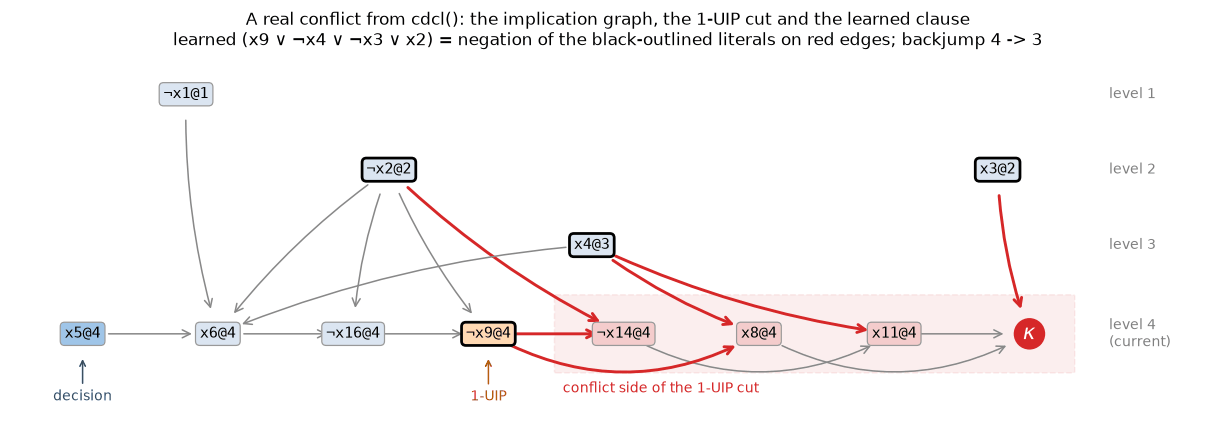

learned clause from the solver: (x9 ∨ ¬x4 ∨ ¬x3 ∨ x2); from the drawn cut: (¬x4 ∨ ¬x3 ∨ x2 ∨ x9) -> identical: True
formula AND NOT(learned) satisfiable? False -> the clause is a consequence of the formula (brute force over 2^16).
11 literals took part, but the clause has 4: it blocks every assignment containing those 4 values, in any part of the search tree.


In [31]:
def _s3_conflict_cone(info):
    '''From an on_conflict snapshot: the current-level ancestors of the conflict, the earlier-level literals
    feeding them, the reason edges, the decision, the UIP and the conflict side of the 1-UIP cut.'''
    level, reason, trail = info["level"], info["reason"], info["trail"]
    pos = {abs(l): i for i, l in enumerate(trail)}
    current = max(level.values())
    cone, lower, edges = set(), set(), {(abs(q), "K") for q in info["conflict"]}
    stack = [abs(q) for q in info["conflict"]]
    while stack:
        v = stack.pop()
        if level[v] != current:
            lower.add(v)                       # earlier levels are drawn as sources, not expanded
            continue
        if v in cone:
            continue
        cone.add(v)
        for q in reason[v] or []:
            if abs(q) != v:
                edges.add((abs(q), v))
                stack.append(abs(q))
    drop = {u for u in lower if level[u] == 0}  # level-0 facts are never part of a learned clause
    lower -= drop
    edges = {(u, v) for u, v in edges if u not in drop}
    uip = abs(info["learned"][0])
    decision = abs(next(l for l in trail if level[abs(l)] == current))
    side = {v for v in cone if pos[v] > pos[uip]}
    crossing = {(u, v) for u, v in edges if (v == "K" or v in side) and u not in side}
    return dict(current=current, cone=cone, lower=lower, edges=edges, uip=uip, decision=decision,
                side=side, crossing=crossing, pos=pos)


def _s3_find_drawable_conflict():
    for seed in range(_s3_SEED, _s3_SEED + 500):
        rnd = random.Random(seed)
        clauses = random_3sat(16, 68, rnd)
        found = []

        def hook(info):
            g = _s3_conflict_cone(info)
            levels_below = {info["level"][u] for u in g["lower"]}
            if (g["current"] >= 3 and g["uip"] != g["decision"] and 2 <= len(g["side"]) <= 4
                    and len(g["cone"]) >= 6 and 9 <= len(g["cone"]) + len(g["lower"]) <= 13
                    and len(levels_below) >= 2 and 3 <= len(info["learned"]) <= 4):
                found.append((info, g))
                return True                    # stop the solver here
        cdcl(clauses, 16, on_conflict=hook)
        if found:
            return clauses, found[0][0], found[0][1]
    raise RuntimeError("no drawable conflict found")


def _s3_draw_conflict():
    '''Draw the implication graph of the chosen conflict and re-derive its learned clause from the cut.'''
    ig_clauses, ig_info, ig = _s3_find_drawable_conflict()
    lit_of = {abs(l): l for l in ig_info["trail"]}
    lvl = ig_info["level"]
    name = lambda v: ("" if lit_of[v] > 0 else "¬") + f"x{v}@{lvl[v]}"
    clause_str = lambda c: " ∨ ".join(("" if l > 0 else "¬") + f"x{abs(l)}" for l in c)

    # layout: current level on the bottom row in trail order; earlier levels on rows above, near their consumers
    GAP = 1.7
    X, Y = {}, {}
    for i, v in enumerate(sorted(ig["cone"], key=ig["pos"].get)):
        X[v], Y[v] = i * GAP, 0.0
    X["K"], Y["K"] = len(ig["cone"]) * GAP, 0.0
    rows_above = {L: 1.0 + 0.85 * i for i, L in enumerate(sorted({lvl[u] for u in ig["lower"]}, reverse=True))}
    placed = []
    for u in sorted(ig["lower"], key=ig["pos"].get):
        x = float(np.mean([X[v] for a, v in ig["edges"] if a == u])) - 0.4   # above its consumers
        while any(abs(x - px) < 1.25 and py == rows_above[lvl[u]] for px, py in placed):
            x += 1.25
        X[u], Y[u] = x, rows_above[lvl[u]]
        placed.append((x, Y[u]))

    fig, ax = plt.subplots(figsize=(14, 4.4))
    x_uip = X[ig["uip"]]
    ax.add_patch(FancyBboxPatch((x_uip + 0.5 * GAP, -0.42), X["K"] - x_uip - 0.5 * GAP + 0.55, 0.84,
                                boxstyle="round,pad=0.02", fc="#d62728", alpha=0.08, ec="#d62728", ls="--"))
    ax.text(x_uip + 0.55 * GAP, -0.66, "conflict side of the 1-UIP cut", color="#d62728", fontsize=9, ha="left")
    order = {v: i for i, v in enumerate(sorted(ig["cone"], key=ig["pos"].get))}
    order["K"] = len(order)
    for u, v in sorted(ig["edges"], key=str):
        hot = (u, v) in ig["crossing"]
        span = order[v] - order[u] if (u in order and Y[u] == 0) else 1
        rad = 0.0 if span <= 1 else min(0.3, 0.2 + 0.04 * span)   # same-row jumps arc under the row
        if Y[u] != 0:
            rad = 0.08                                               # edges from earlier levels: gentle arcs
        ax.add_patch(FancyArrowPatch((X[u], Y[u]), (X[v], Y[v]), arrowstyle="->", mutation_scale=13,
                                     shrinkA=17, shrinkB=17, connectionstyle=f"arc3,rad={rad}", zorder=1,
                                     color="#d62728" if hot else "#888888", lw=1.9 if hot else 1.0))
    for v in ig["cone"] | ig["lower"]:
        fc = "#dbe5f1"
        if v == ig["decision"]:
            fc = "#9fc5e8"
        if v == ig["uip"]:
            fc = "#ffd9b3"
        if v in ig["side"]:
            fc = "#f4cccc"
        in_clause = any(u == v for u, _ in ig["crossing"])
        ax.text(X[v], Y[v], name(v), ha="center", va="center", fontsize=9.5, family="monospace", zorder=3,
                bbox=dict(boxstyle="round,pad=0.3", fc=fc, ec="black" if in_clause else "#999999",
                          lw=1.8 if in_clause else 0.8))
    ax.text(X["K"], 0, r"$\kappa$", ha="center", va="center", fontsize=14, color="white", zorder=3,
            bbox=dict(boxstyle="circle,pad=0.2", fc="#d62728", ec="#d62728"))
    ax.annotate("decision", xy=(X[ig["decision"]], -0.25), xytext=(X[ig["decision"]], -0.75), ha="center",
                fontsize=9, color="#1f4e79", arrowprops=dict(arrowstyle="->", color="#1f4e79"))
    ax.annotate("1-UIP", xy=(X[ig["uip"]], -0.25), xytext=(X[ig["uip"]], -0.75), ha="center", fontsize=9,
                color="#b45f06", arrowprops=dict(arrowstyle="->", color="#b45f06"))
    for L, yy in rows_above.items():
        ax.text(X["K"] + 1.0, yy, f"level {L}", fontsize=9, color="gray", va="center")
    ax.text(X["K"] + 1.0, 0, f"level {ig['current']}\n(current)", fontsize=9, color="gray", va="center")
    ax.set_xlim(min(X.values()) - 0.9, X["K"] + 2.2)
    ax.set_ylim(-1.05, max(rows_above.values()) + 0.45)
    ax.axis("off")
    ax.set_title(f"A real conflict from cdcl(): the implication graph, the 1-UIP cut and the learned clause\n"
                 f"learned ({clause_str(ig_info['learned'])}) = negation of the black-outlined literals on red "
                 f"edges; backjump {ig['current']} -> {ig_info['backjump']}", fontsize=11)
    plt.show()

    from_cut = sorted(-u if lit_of[u] > 0 else u for u in {u for u, _ in ig["crossing"]})
    n_ig = 16
    implied = brute_force_sat(ig_clauses + [[-l] for l in ig_info["learned"]], n_ig) is None
    print(f"learned clause from the solver: ({clause_str(ig_info['learned'])}); from the drawn cut: "
          f"({clause_str(from_cut)}) -> identical: {sorted(from_cut) == sorted(ig_info['learned'])}")
    print(f"formula AND NOT(learned) satisfiable? {not implied} -> the clause is a consequence of the formula "
          f"(brute force over 2^{n_ig}).")
    k = len(ig_info["learned"])
    print(f"{len(ig['cone']) + len(ig['lower'])} literals took part, but the clause has {k}: it blocks every "
          f"assignment containing those {k} values, in any part of the search tree.")


_s3_draw_conflict()

### 3.5 What each component buys, and where CDCL is provably exponential

Two formula families pull in opposite directions. This subsection measures the first, then the second.

**Adder miters: structure that learning can exploit.** Build two ripple-carry adders, one computing $a+b$ and
one $b+a$, with no gates shared between them. XOR their sum bits and assert that some XOR is 1. UNSAT means the
two circuits agree on every input: an **equivalence check**, the chip notebook's "netlist ≡ RTL" (§6.3 there) in
miniature. (§4 shows that *structural hashing* makes this particular miter trivial; here the gates are
deliberately not shared.) DPLL's cost follows from the construction. With the static order the $2w$ input
variables come first. The only constraint pointing backwards from the outputs is one long clause ("some sum bit
differs"), and it becomes unit only once every other bit already agrees, so no branch closes before all inputs
are fixed. DPLL therefore enumerates every input pair: a full binary tree with $4^w$ leaves and $4^w - 1$
decision nodes. CDCL instead learns *local* facts (for example "if bit $i$ of both adders saw the same inputs
and the same carry-in, their carries out agree") that hold on every branch; the cell measures how local they
are.

**Registered prediction (ablation).** (1) DPLL makes exactly $4^w - 1$ decisions on the $w$-bit miter. (2)
Learning is the component that matters most: without it the solver stays exponential, VSIDS or not. (3) Each of
the other four components is a tuning knob worth less than 10× in conflicts at $w = 32$.

*How (2) is scored.* The numeric rule was fixed after the prediction above was written, so read it as a
formalisation of the prose prediction, not as part of it. `- learn`'s slowdown at $w = 8$, the widest width it
can be run at, must exceed every other knob's slowdown at any width, and the growth factor per extra bit,
averaged over the last three solved widths, must stay ≥ 3 both with VSIDS (`- learn`) and without it (DPLL).
Pure $4^w$ growth gives 4.

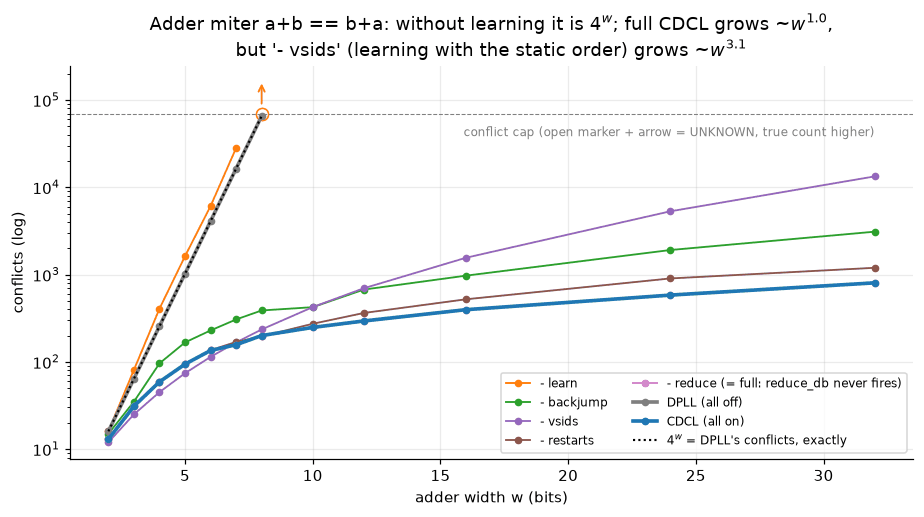

configuration   w=8 conflicts   w=16 conflicts  w=32 conflicts  w=32 time (s)  x full CDCL at w=32
--------------------------------------------------------------------------------------------------
CDCL (all on)   200             396             804             0.03           1.0                
- learn         >= 70000 (cap)  -               -               -              exponential        
- backjump      388             972             3101            0.05           3.9                
- vsids         235             1559            13337           1.28           16.6               
- restarts      196             521             1196            0.04           1.5                
- reduce        200             396             804             0.03           1.0                
DPLL (all off)  65536           -               -               -              exponential        
registered prediction (1): DPLL decisions = 4^w - 1 | measured: [15, 63, 255, 1023, 4095, 16383, 65535] | ver

In [32]:
class _s3_Netlist:
    '''A gate netlist written straight to Tseitin CNF, with NO sharing of identical gates.
    bit_of[v] records which bit position of the datapath each variable belongs to.'''
    def __init__(self, n_inputs):
        self.n_vars, self.clauses = n_inputs, []
        self.bit, self.bit_of = 0, {}

    def _gate(self, clause_fn):
        self.n_vars += 1
        self.clauses += clause_fn(self.n_vars)
        self.bit_of[self.n_vars] = self.bit
        return self.n_vars

    def AND(self, a, b):
        return self._gate(lambda t: [[-t, a], [-t, b], [t, -a, -b]])

    def OR(self, a, b):
        return self._gate(lambda t: [[t, -a], [t, -b], [-t, a, b]])

    def XOR(self, a, b):
        return self._gate(lambda t: _s3_xor_gate(t, a, b))


def _s3_ripple_add(net, x, y):
    net.bit = 0
    out, carry = [net.XOR(x[0], y[0])], net.AND(x[0], y[0])
    for i, (a, b) in enumerate(zip(x[1:], y[1:]), start=1):
        net.bit = i
        p = net.XOR(a, b)
        out.append(net.XOR(p, carry))
        carry = net.OR(net.AND(a, b), net.AND(p, carry))
    return out


def _s3_adder_miter(w):
    '''UNSAT iff a+b == b+a for all w-bit a, b. Inputs a = 1..w, b = w+1..2w come first in the order.
    Returns (clauses, n_vars, bit_of), bit_of[v] = the datapath bit position of variable v.'''
    net = _s3_Netlist(2 * w)
    a, b = list(range(1, w + 1)), list(range(w + 1, 2 * w + 1))
    net.bit_of.update({v: (v - 1) % w for v in a + b})
    sums = list(zip(_s3_ripple_add(net, a, b), _s3_ripple_add(net, b, a)))
    diffs = []
    for i, (s, t) in enumerate(sums):
        net.bit = i
        diffs.append(net.XOR(s, t))
    return net.clauses + [diffs], net.n_vars, net.bit_of


def _s3_interleave_inputs(clauses, w):
    '''Renumber the miter's inputs bit by bit (a0 -> 1, b0 -> 2, a1 -> 3, ...); gate variables keep their
    numbers. The formula is the same; only the static decision order (lowest index first) changes.'''
    perm = {i + 1: 2 * i + 1 for i in range(w)} | {w + i + 1: 2 * i + 2 for i in range(w)}
    return [[(1 if l > 0 else -1) * perm.get(abs(l), abs(l)) for l in c] for c in clauses]


def _s3_span(clause, bit_of):
    '''How many datapath bit positions a clause stretches across (0 = everything in one bit).'''
    bits = [bit_of[abs(l)] for l in clause]
    return max(bits) - min(bits)


def _s3_tail_factor(ys, k=3):
    '''Growth factor per step, averaged (geometrically) over the last k steps of a series.'''
    return (ys[-1] / ys[-1 - k]) ** (1 / k)


def _s3_plot_series(ax, xs, ys, censored, fmt, color, label, lw=1.5, ms=5, zorder=2):
    '''Solved points joined by a line; capped runs (UNKNOWN) as open markers with an upward arrow, because
    the true count lies somewhere above the cap.'''
    solved = [(x, y) for x, y, c in zip(xs, ys, censored) if not c]
    if solved:
        ax.plot(*zip(*solved), fmt, color=color, label=label, lw=lw, ms=ms, zorder=zorder)
    for x, y, c in zip(xs, ys, censored):
        if c:
            ax.plot([x], [y], fmt[0], ms=ms + 4, mfc="white", mec=color, zorder=zorder)
            ax.annotate("", xy=(x, y * 2.4), xytext=(x, y * 1.2), zorder=zorder, annotation_clip=False,
                        arrowprops=dict(arrowstyle="->", color=color, lw=1.2))


_s3_ABLATION_CAP = 70_000                     # conflict cap: a slower machine just sees UNKNOWN
_s3_WIDTHS = [2, 3, 4, 5, 6, 7, 8, 10, 12, 16, 24, 32]


def _s3_ablation():
    '''Adder-miter ablation: every configuration of _s3_CONFIGS by width; draw; score predictions (1)-(3).'''
    abl = {}                                  # (config, w) -> (status, stats, seconds, proof at w = 32)
    for cfg, flags in _s3_CONFIGS.items():
        exhaustive = not flags.get("learn", True)              # no learning: exponential, stop at w = 8
        for w in [w for w in _s3_WIDTHS if w <= 8 or not exhaustive]:
            cnf, nv, _ = _s3_adder_miter(w)
            proof = [] if w == 32 else None                    # kept for the locality measurement
            (status, _, st), dt = timed(cdcl, cnf, nv, proof=proof, max_conflicts=_s3_ABLATION_CAP, **flags)
            abl[cfg, w] = (status, st, dt, proof)
    full = "CDCL (all on)"
    conflicts = lambda cfg, w: abl[cfg, w][1]["conflicts"]
    max_full = max(conflicts(full, w) for w in _s3_WIDTHS)
    reduce_fired = any(abl[full, w][1]["deleted"] for w in _s3_WIDTHS)

    colors = dict(zip(_s3_CONFIGS, ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#8c564b", "#e377c2",
                                    "#7f7f7f"]))
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    for cfg in sorted(_s3_CONFIGS, key=lambda c: c == full):                 # full CDCL drawn last, on top
        ws = [w for w in _s3_WIDTHS if (cfg, w) in abl]
        big = cfg in (full, "DPLL (all off)")
        label = cfg + (" (= full: reduce_db never fires)" if cfg == "- reduce" and not reduce_fired else "")
        _s3_plot_series(ax, ws, [max(1, conflicts(cfg, w)) for w in ws], [abl[cfg, w][0] == "UNKNOWN" for w in ws],
                        "o-", colors[cfg], label, lw=2.4 if big else 1.2, ms=4, zorder=3 if big else 2)
    wd = np.arange(2, 9)
    dpll_exact = all(conflicts("DPLL (all off)", w) == 4 ** w for w in wd)
    ax.plot(wd, 4.0 ** wd, ls=(0, (1, 1.5)), c="black", lw=1.4, zorder=5,  # on top of the thick DPLL line
            label=r"$4^w$" + (" = DPLL's conflicts, exactly" if dpll_exact else ""))
    ax.axhline(_s3_ABLATION_CAP, c="gray", lw=0.7, ls="--")
    ax.text(32, _s3_ABLATION_CAP * 0.55, "conflict cap (open marker + arrow = UNKNOWN, true count higher)",
            ha="right", fontsize=8, color="gray")
    ax.set_yscale("log")
    ax.set_ylim(top=_s3_ABLATION_CAP * 3.5)                     # room for the UNKNOWN arrows
    ax.set_xlabel("adder width w (bits)")
    ax.set_ylabel("conflicts (log)")
    expo = lambda cfg: math.log2(conflicts(cfg, 32) / conflicts(cfg, 16))   # growth exponent, w = 16 -> 32
    ax.set_title("Adder miter a+b == b+a: without learning it is $4^w$; "
                 f"full CDCL grows ~$w^{{{expo(full):.1f}}}$,\n"
                 f"but '- vsids' (learning with the static order) grows ~$w^{{{expo('- vsids'):.1f}}}$")
    ax.legend(fontsize=8, ncol=2, loc="lower right")
    plt.tight_layout()
    plt.show()

    def cell(cfg, w):
        if (cfg, w) not in abl:
            return "-"
        return f">= {conflicts(cfg, w)} (cap)" if abl[cfg, w][0] == "UNKNOWN" else conflicts(cfg, w)
    show_table(["configuration", "w=8 conflicts", "w=16 conflicts", "w=32 conflicts", "w=32 time (s)",
                "x full CDCL at w=32"],
               [[cfg, cell(cfg, 8), cell(cfg, 16), cell(cfg, 32)]
                + ([f"{abl[cfg, 32][2]:.2f}", f"{conflicts(cfg, 32) / conflicts(full, 32):.1f}"]
                   if (cfg, 32) in abl else ["-", "exponential"]) for cfg in _s3_CONFIGS])

    # (1) DPLL's decision count, exactly
    dpll_decisions = [abl["DPLL (all off)", w][1]["decisions"] for w in range(2, 9)]
    print(f"registered prediction (1): DPLL decisions = 4^w - 1 | measured: {dpll_decisions} | verdict: "
          f"{'RIGHT' if dpll_decisions == [4 ** w - 1 for w in range(2, 9)] else 'WRONG'}")

    # (2) learning matters most, and without it the search stays exponential whether or not VSIDS steers
    others = ("- backjump", "- vsids", "- restarts", "- reduce")
    worst = max((conflicts(c, w) / conflicts(full, w), c, w) for c in others for w in _s3_WIDTHS)
    capped8 = abl["- learn", 8][0] == "UNKNOWN"
    learn_x = conflicts("- learn", 8) / conflicts(full, 8)                 # a lower bound if capped
    solved = lambda cfg: [conflicts(cfg, w) for w in range(2, 9) if abl[cfg, w][0] != "UNKNOWN"]
    growth = {cfg: _s3_tail_factor(solved(cfg)) for cfg in ("- learn", "DPLL (all off)")}
    ok2 = learn_x > worst[0] and min(growth.values()) >= 3
    print(f"registered prediction (2): learning matters most; without it the solver stays exponential, VSIDS "
          f"or not | measured: '- learn' costs {'>= ' if capped8 else ''}{learn_x:.0f}x full CDCL at w=8, the "
          f"worst other knob {worst[0]:.1f}x ('{worst[1]}', w={worst[2]}); growth per extra bit, last three "
          f"solved widths: '- learn' (VSIDS on) {growth['- learn']:.1f}x, DPLL (VSIDS off) "
          f"{growth['DPLL (all off)']:.1f}x | verdict: {'RIGHT' if ok2 else 'WRONG'}")
    worse = sum(conflicts("- learn", w) >= conflicts("DPLL (all off)", w) for w in range(3, 9))
    print(f"  {'VSIDS alone does not help' if worse == 6 else 'VSIDS alone helps a little'}: without learning, "
          f"the activity order needs at least as many conflicts as DPLL's static order at {worse} of the 6 "
          f"widths 3..8.")

    # (3) every other knob < 10x at w = 32
    knobs = {c: conflicts(c, 32) / conflicts(full, 32) for c in others}
    by_width = ", ".join(f"w={w}: {conflicts('- vsids', w) / conflicts(full, w):.1f}x" for w in (8, 16, 24, 32))
    vacuous = ("" if reduce_fired else f"; '- reduce' is vacuous here: full CDCL never reaches the 2,000th "
               f"conflict at which reduce_db first runs (at most {max_full})")
    print("registered prediction (3): the other four knobs are each < 10x at w=32 | measured: "
          + ", ".join(f"{c} {r:.1f}x" for c, r in knobs.items()) + vacuous + " | verdict: "
          + ("RIGHT" if max(knobs.values()) < 10 else
             f"WRONG -- the decision order matters more as the circuit grows ('- vsids' by width: {by_width})"))

    # why the order matters: where the learned clauses live, and what a bit-local static order does
    cnf, nv, bit_of = _s3_adder_miter(32)
    spans = {cfg: np.array([_s3_span(c, bit_of) for c in abl[cfg, 32][3] if c]) for cfg in (full, "- vsids")}
    print(f"locality of the clauses learned at w=32: full CDCL median span {int(np.median(spans[full]))} bit "
          f"positions ({np.mean(spans[full] <= 2):.0%} within 2 adjacent bits) -- local carry lemmas, valid on "
          f"every branch; '- vsids' median span {int(np.median(spans['- vsids']))} "
          f"({np.mean(spans['- vsids'] <= 2):.0%} within 2 bits)")
    status, _, st = cdcl(_s3_interleave_inputs(cnf, 32), nv, max_conflicts=_s3_ABLATION_CAP, vsids=False)
    print(f"the static order decides all of a, then all of b, so its conflicts span the whole word. Same static "
          f"order, inputs renumbered bit by bit (a0, b0, a1, b1, ...): {status} in {st['conflicts']} conflicts at "
          f"w=32, against {conflicts(full, 32)} for full CDCL and {conflicts('- vsids', 32)} for '- vsids'.")


_s3_ablation()

Predictions (1) and (2) held. Prediction (3) failed, and the failure is informative: `- vsids` costs 16.6× at
$w = 32$, and the gap widens with width (1.2× at $w = 8$). The mechanism is in the last two lines above. The
static order decides all of $a$ before any of $b$, so each conflict ties together bits far apart, and the clauses
learned without VSIDS span most of the word (median 27 bit positions, against 1 for full CDCL). VSIDS is not
magic either: the *same* static order with the inputs numbered bit by bit needs only 221 conflicts at $w = 32$,
fewer than full CDCL. On this circuit VSIDS buys a bit-local decision order, discovered from the conflicts; a
tool that knows the circuit's structure can supply such an order up front.

**Pigeonhole: no structure that resolution can use.** PHP$(n+1, n)$ puts $n+1$ pigeons in $n$ holes. With
variable $p_{ij}$ = "pigeon $i$ sits in hole $j$", every pigeon sits somewhere ($n+1$ clauses of length $n$) and
no hole holds two ($n\binom{n+1}{2}$ binary clauses). By counting it is obviously UNSAT. Haken (1985) proved
that every *resolution* refutation of PHP$(n+1, n)$ has size $\exp(\Omega(n))$. That bound binds CDCL: every
learned clause is a resolution consequence of earlier clauses, so a complete run, expanded into its resolution
steps, *is* a resolution refutation, and it can be no shorter than the shortest one. In the other direction,
CDCL with restarts **p-simulates** general resolution (Pipatsrisawat & Darwiche, *Artificial Intelligence*
2011, [DOI](https://doi.org/10.1016/j.artint.2010.10.002)): with the right decisions it finds any resolution
proof with polynomial overhead. Resolution proof size is therefore exactly the right yardstick for this solver
family, and no amount of engineering inside the family escapes Haken's bound. The escape, a stronger proof
system, comes right after the measurement.

**Registered prediction (pigeonhole).** Every configuration, including Z3's industrial CDCL engine run on the
same CNF, is exponential: conflicts and RUP-proof size grow by a factor per extra hole that does *not* shrink
toward 1 (a polynomial $n^k$ would have ratios $(1 + 1/n)^k \to 1$). With a 30,000-conflict cap, full CDCL
returns UNKNOWN on PHP(9, 8), a formula with just 72 variables and 297 clauses.

*How it is scored.* As for the ablation, the numeric rule was fixed after the prediction above was written, so
read it as a formalisation of the prose prediction, not as part of it. The growth factor per extra hole,
averaged over each series' last three measured steps, must stay ≥ 3 for every series. The series are conflicts
and RUP-proof literals for full CDCL, CDCL without restarts and DPLL, plus Z3's conflicts. Full CDCL must also
hit the cap on PHP(9, 8). A degree-$k$ polynomial would give $(1 + 1/n)^k$ per step, which is 1.6 for $k = 4$ at
$n = 8$. Z3 runs in a fresh context each time, so earlier Z3 calls in the notebook cannot change its search, and
under 4× our conflict budget, so its curve can be followed one hole further. The same-budget comparison is read
off its counts.

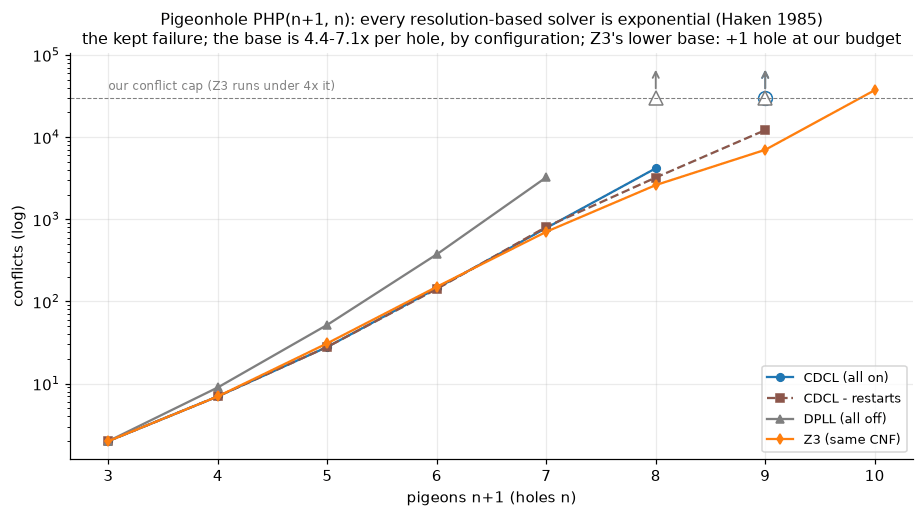

formula    vars  clauses  CDCL conflicts   proof lemmas  proof literals  RUP ok  - restarts conflicts  DPLL conflicts   Z3 conflicts
------------------------------------------------------------------------------------------------------------------------------------
PHP(3,2)   6     9        2                2             1               True    2                     2                2           
PHP(4,3)   12    22       7                7             12              True    7                     9                7           
PHP(5,4)   20    45       28               28            103             True    28                    52               31          
PHP(6,5)   30    81       145              145           1147            True    142                   375              151         
PHP(7,6)   42    133      784              784           9922            True    810                   3246             705         
PHP(8,7)   56    204      4178             4178          78810       

reduce_db on PHP(9,8), first 15,000 conflicts:
  reduce on :  2,987 learned clauses alive,  52.9 clause visits per propagated literal, ~1.3 s
  reduce off: 15,000 learned clauses alive, 154.7 clause visits per propagated literal, ~3.3 s
Every learned clause sits on two watch lists, so a database that only grows makes each propagated literal visit more clauses; deleting the worse half every 2,000 conflicts keeps the lists short.


In [33]:
def _s3_php(holes):
    '''PHP(holes+1, holes): variable i*holes + j + 1 means pigeon i sits in hole j.'''
    p = lambda i, j: i * holes + j + 1
    clauses = [[p(i, j) for j in range(holes)] for i in range(holes + 1)]
    clauses += [[-p(a, j), -p(b, j)] for j in range(holes) for a, b in itertools.combinations(range(holes + 1), 2)]
    return clauses, (holes + 1) * holes


def _s3_z3_sat_conflicts(clauses, n_vars, max_conflicts, timeout_ms=10_000):
    '''Run Z3 on exactly this CNF with a conflict budget; return (status, Z3's own conflict count).
    A fresh z3.Context per call keeps the count reproducible: in a shared context, earlier Z3 calls in the
    notebook change Z3's internal state and hence its search.'''
    if not HAVE_Z3:
        return "no z3", None
    ctx = z3.Context()
    s = z3.Solver(ctx=ctx)
    s.set("timeout", timeout_ms)                  # safety net only; the conflict budget binds first
    s.set("max_conflicts", max_conflicts)
    B = [None] + [z3.Bool(f"v{v}", ctx) for v in range(1, n_vars + 1)]
    s.add([z3.Or([B[l] if l > 0 else z3.Not(B[-l]) for l in c]) for c in clauses])
    r = s.check()
    st = s.statistics()
    conflicts = st.get_key_value("sat conflicts") if "sat conflicts" in st.keys() else None
    return str(r), conflicts


_s3_PHP_CAP = 30_000                          # our solver's conflict cap on pigeonhole
_s3_Z3_CAP = 4 * _s3_PHP_CAP                  # Z3 is followed one hole further
_s3_REDUCE_DEMO_CAP = 15_000                  # conflicts for the reduce_db on/off comparison


def _s3_pigeonhole():
    '''Pigeonhole (Haken): our configurations and Z3 on PHP(n+1, n); draw; score the prediction.'''
    full, ours = "CDCL (all on)", ("CDCL (all on)", "CDCL - restarts", "DPLL (all off)")
    flags = {full: {}, "CDCL - restarts": dict(restarts=False), "DPLL (all off)": _s3_CONFIGS["DPLL (all off)"]}
    php = {}                                  # (solver, holes) -> (status, conflicts, proof)
    secs = {}                                 # (solver, holes) -> wall-clock seconds (approximate)
    for holes in range(2, 9):
        cnf, nv = _s3_php(holes)
        for label in ours:
            proof = []
            (status, _, st), secs[label, holes] = timed(cdcl, cnf, nv, proof=proof, max_conflicts=_s3_PHP_CAP,
                                                        **flags[label])
            php[label, holes] = (status.lower(), st["conflicts"], proof)
    if HAVE_Z3:
        for holes in range(2, 10):
            (status, c), secs["Z3 (same CNF)", holes] = timed(_s3_z3_sat_conflicts, *_s3_php(holes), _s3_Z3_CAP)
            php["Z3 (same CNF)", holes] = (status, c, None)
    labels = ours + (("Z3 (same CNF)",) if HAVE_Z3 else ())
    holes_of = lambda label: [h for h in range(2, 10) if (label, h) in php]

    def solved_run(label):
        '''Holes solved before the first capped run (a contiguous series).'''
        out = []
        for h in holes_of(label):
            if php[label, h][0] != "unsat":
                break
            out.append(h)
        return out
    best = {label: max(solved_run(label)) for label in labels}
    within_cap = lambda label: max(h for h in solved_run(label) if php[label, h][1] <= _s3_PHP_CAP)
    # Per-hole factor over a COMMON window of holes, so that configurations are compared on the same formulas
    # (the tail averages below use each series' own last three steps, which differ between series).
    windows = [(3, 6), (4, 7)]                # PHP(4,3) -> PHP(7,6): every series solved; PHP(5,4) -> PHP(8,7)
    per_hole = {(label, h0): (php[label, h1][1] / php[label, h0][1]) ** (1 / (h1 - h0))
                for h0, h1 in windows for label in labels if h1 in solved_run(label)}
    base_lo, base_hi = min(per_hole.values()), max(per_hole.values())
    z3_lowest = HAVE_Z3 and all(per_hole["Z3 (same CNF)", h0] == min(v for (_, h), v in per_hole.items()
                                                                       if h == h0) for h0, _ in windows)

    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    for label, fmt, color in ((full, "o-", "#1f77b4"), ("CDCL - restarts", "s--", "#8c564b"),
                              ("DPLL (all off)", "^-", "#7f7f7f"), ("Z3 (same CNF)", "d-", "#ff7f0e")):
        if label in labels:
            hs = holes_of(label)
            _s3_plot_series(ax, [h + 1 for h in hs], [max(1, php[label, h][1]) for h in hs],
                            [php[label, h][0] == "unknown" for h in hs], fmt, color, label)
    ax.axhline(_s3_PHP_CAP, c="gray", lw=0.7, ls="--")
    ax.text(3, _s3_PHP_CAP * 1.25, "our conflict cap (Z3 runs under 4x it)", ha="left", fontsize=8, color="gray")
    ax.set_yscale("log")
    ax.set_ylim(top=_s3_PHP_CAP * 3.5)                          # room for the UNKNOWN arrows
    ax.set_xlabel("pigeons n+1 (holes n)")
    ax.set_ylabel("conflicts (log)")
    gain = within_cap("Z3 (same CNF)") - within_cap(full) if HAVE_Z3 else None
    ax.set_title("Pigeonhole PHP(n+1, n): every resolution-based solver is exponential (Haken 1985)\n"
                 f"the kept failure; the base is {base_lo:.1f}-{base_hi:.1f}x per hole, by configuration"
                 + (("; Z3's lower base" if z3_lowest else "; Z3")
                    + f": +{gain} hole{'s' * (gain != 1)} at our budget" if HAVE_Z3 else ""),
                 fontsize=10.5)
    ax.legend(fontsize=8.5, loc="lower right")
    plt.tight_layout()
    plt.show()

    def count(label, h):
        if (label, h) not in php:
            return "-"
        status, c, _ = php[label, h]
        return c if status == "unsat" else f"{status.upper()} @ {c}"
    rows = []
    for holes in range(2, 10):
        cnf, nv = _s3_php(holes)
        done = php.get((full, holes), ("-",))[0] == "unsat"
        proof = php[full, holes][2] if done else None
        rows.append([f"PHP({holes + 1},{holes})", nv, len(cnf), count(full, holes),
                     len(proof) if done else "-", sum(map(len, proof)) if done else "-",
                     check_rup_proof(cnf, proof) if done and len(proof) <= 1000 else "-",
                     count("CDCL - restarts", holes), count("DPLL (all off)", holes),
                     count("Z3 (same CNF)", holes)])
    show_table(["formula", "vars", "clauses", "CDCL conflicts", "proof lemmas", "proof literals", "RUP ok",
                "- restarts conflicts", "DPLL conflicts", "Z3 conflicts"], rows)

    series = {}
    for label in labels:
        hs = solved_run(label)
        series[label + " conflicts"] = [php[label, h][1] for h in hs]
        if label in ours:
            series[label + " proof literals"] = [sum(map(len, php[label, h][2])) for h in hs]
    ratio = lambda ys: [b / a for a, b in zip(ys, ys[1:])]
    print("per extra hole, full CDCL: conflicts", " ".join(f"{r:.1f}" for r in ratio(series[full + " conflicts"])),
          "| proof literals", " ".join(f"{r:.1f}" for r in ratio(series[full + " proof literals"])))
    tails = {k: _s3_tail_factor(ys) for k, ys in series.items()}
    low_step = min((r, k) for k, ys in series.items() for r in ratio(ys)[-3:])
    ok = min(tails.values()) >= 3 and php[full, 8][0] == "unknown"
    print(f"registered prediction (pigeonhole): every series grows by a factor per hole that does not shrink "
          f"toward 1 (scored: last-three-step average >= 3), PHP(9,8) UNKNOWN at the cap | measured: "
          + ", ".join(f"{k} {v:.1f}" for k, v in tails.items())
          + f"; PHP(9,8) {php[full, 8][0].upper()} | verdict: {'RIGHT' if ok else 'WRONG'}")
    print(f"  smallest single step among the last three of any series: {low_step[0]:.1f} ({low_step[1]}); a "
          f"degree-4 polynomial would give (9/8)^4 = {(9 / 8) ** 4:.1f} at n = 8.")
    for h0, h1 in windows:
        print(f"per-hole conflict factor on the same formulas, PHP({h0 + 1},{h0}) -> PHP({h1 + 1},{h1}): "
              + ", ".join(f"{label} {per_hole[label, h0]:.1f}" for label in labels if (label, h0) in per_hole)
              + "".join(f", {label} capped" for label in labels if (label, h0) not in per_hole))
    print(f"  the lines are not parallel: the base of the exponential moves between {base_lo:.1f} and "
          f"{base_hi:.1f} per hole with the configuration, and no configuration brings it near 1.")
    if HAVE_Z3:
        vs = [f"PHP({h + 1},{h}) {count(full, h) / php['Z3 (same CNF)', h][1]:.1f}x" for h in range(6, best[full] + 1)]
        h9 = best[full] + 1                   # the first hole count our solver gives up on
        if (full, h9) in php and php["Z3 (same CNF)", h9][0] == "unsat":
            vs.append(f"PHP({h9 + 1},{h9}) >= {php[full, h9][1] / php['Z3 (same CNF)', h9][1]:.1f}x (ours capped)")
        print(f"our conflicts / Z3's on the same CNF: {', '.join(vs)} -> within our {_s3_PHP_CAP:,}-conflict "
              f"budget Z3 solves up to PHP({within_cap('Z3 (same CNF)') + 1},{within_cap('Z3 (same CNF)')}), "
              f"ours up to PHP({within_cap(full) + 1},{within_cap(full)}).")
        z3l, hb = "Z3 (same CNF)", best[full]  # hb: the largest formula both solve; hb + 1: ours capped
        per_conflict = {lab: 1e6 * secs[lab, hb + 1] / php[lab, hb + 1][1] for lab in (full, z3l)}
        print(f"wall clock (approximate), same CNF: PHP({hb + 1},{hb}) ours ~{secs[full, hb]:.2f} s, Z3 "
              f"~{secs[z3l, hb]:.2f} s; PHP({hb + 2},{hb + 1}) ours ~{secs[full, hb + 1]:.1f} s to the cap, Z3 "
              f"~{secs[z3l, hb + 1]:.2f} s to the proof; per conflict there, ours ~{per_conflict[full]:.0f} µs, "
              f"Z3 ~{per_conflict[z3l]:.0f} µs.")
    print(f"Without restarts the same solver needs {php['CDCL - restarts', 8][1]} conflicts on PHP(9,8): "
          f"defaults tuned for structured formulas can hurt -- but the restart-free curve is exponential too "
          f"({per_hole['CDCL - restarts', 4]:.1f} per hole against {per_hole[full, 4]:.1f}, PHP(5,4) -> PHP(8,7)).")

    # reduce_db at work: pigeonhole runs long enough for it to fire (the adder miters never do)
    cnf, nv = _s3_php(8)
    red = {on: timed(cdcl, cnf, nv, max_conflicts=_s3_REDUCE_DEMO_CAP, reduce=on) for on in (True, False)}
    desc = []
    for on in (True, False):
        (_, _, st), dt = red[on]
        desc.append(f"reduce {'on ' if on else 'off'}: {st['learned'] - st['deleted']:>6,} learned clauses alive, "
                    f"{st['watch_visits'] / st['propagations']:5.1f} clause visits per propagated literal, ~{dt:.1f} s")
    print(f"reduce_db on PHP(9,8), first {_s3_REDUCE_DEMO_CAP:,} conflicts:\n  " + "\n  ".join(desc))
    print("Every learned clause sits on two watch lists, so a database that only grows makes each propagated "
          "literal visit more clauses; deleting the worse half every 2,000 conflicts keeps the lists short.")
    return php


_s3_PHP_RESULTS = _s3_pigeonhole()            # reused by the cutting-planes cell below

The prediction held. Every series is close to a straight line on the log axis, so the per-hole factor does not
shrink: Haken's bound, measured. The lines are not parallel, though, and the same-formula factors say by how
much. From PHP(4, 3) to PHP(7, 6) full CDCL grows 4.8× per hole and DPLL 7.1×, so CDCL's machinery lowers the
*base* of the exponential, not just its constant. Z3's engine has the lowest base in this run, so its lead over
our solver widens hole by hole (the printed ratios), and on the largest instances it also finishes in a fraction
of our time (the wall-clock line). Yet within our conflict budget it gets just one hole further. Turning
restarts off rescues PHP(9, 8) for our solver, and that curve is exponential too, with a similar base on the
same formulas: 4.9 per hole against full CDCL's 4.8 from PHP(4, 3) to PHP(7, 6), and against 5.3 from PHP(5, 4)
to PHP(8, 7). Engineering moves the base around; Haken's bound says that no resolution-based configuration can
bring it down to 1. `reduce_db`, idle on the adders, matters here: without it each propagated literal visits
about three times as many clauses.

**The escape is a stronger proof system, not a better heuristic.** CDCL's proofs are resolution proofs, and
Haken's bound is a statement about resolution. Stronger proof systems have short pigeonhole proofs:

- **Extended resolution** may introduce new variables defined by clauses like Tseitin's ($y \leftrightarrow a
  \land b$, §3.1) and then resolve on them. With such definitions PHP$(n+1, n)$ has refutations of polynomial
  size, $O(n^4)$ clauses (Cook, *SIGACT News* 1976, [DOI](https://doi.org/10.1145/1008335.1008338); the size
  bound as stated by Grosof, Zhang & Heule, [arXiv 2207.11284](https://arxiv.org/abs/2207.11284)).
- **Cutting planes** works with 0/1 linear inequalities. A clause says "at least one literal is 1", so
  $\lnot a \lor \lnot b$ becomes $a + b \le 1$. There are two rules. You may add nonnegative multiples of known
  inequalities. You may also divide by $d$ when $d$ divides every coefficient, rounding the bound to the integer
  side, which is sound because the left side is an integer. The counting argument then takes three lines.
  Summing the $n+1$ pigeon inequalities gives $\sum p_{ij} \ge n+1$, summing the $n$ holes' "at most one"
  inequalities $\sum_i p_{ij} \le 1$ gives $\sum p_{ij} \le n$, and adding the two gives $0 \ge 1$. The only
  work is deriving each hole's "at most one" from its pairwise clauses, one pigeon at a time. From
  $x_0 + \dots + x_{k-1} \le 1$ and $x_i + x_k \le 1$ for every $i < k$, the combination
  $(k-1)\cdot[x_0 + \dots + x_{k-1} \le 1] + \sum_{i<k} [x_i + x_k \le 1]$ is $k(x_0 + \dots + x_k) \le 2k-1$,
  and dividing by $k$ rounds $2 - 1/k$ down to 1. That makes $2n(n-1) + 1$ lines in all, polynomial, as W. Cook,
  Coullard & Turán showed (*Discrete Applied Mathematics* 1987,
  [DOI](https://doi.org/10.1016/0166-218X(87)90039-4)).

The rounding is the whole trick. Without it, linear arithmetic over the reals cannot refute PHP at all, since
setting every $p_{ij} = 1/n$ satisfies every inequality. The next cell writes the refutation out for
PHP$(n+1, n)$ and replays it with a small checker, the cutting-planes counterpart of §3.3's RUP checker. It also
replays the same steps with the rounding switched off, which must fail.

In [34]:
def _s3_clause_to_inequality(clause):
    '''A clause as a 0/1 linear inequality ({var: coeff}, rhs), read sum(coeff * x) >= rhs: a positive
    literal contributes x, a negative one (1 - x), and at least one literal must be 1.'''
    coeffs = defaultdict(int)
    for lit in clause:
        coeffs[abs(lit)] += 1 if lit > 0 else -1
    return dict(coeffs), 1 - sum(lit < 0 for lit in clause)


def _s3_check_cutting_planes(axioms, steps, round_up=True):
    '''Replay a cutting-planes proof. Every line is ({var: coeff}, rhs), read sum(coeff * x) >= rhs over 0/1
    integers. A step is ("add", [(multiplier >= 0, line index), ...]) or ("div", line index, d) for a d that
    divides every coefficient; the bound is then rounded UP, sound because the left side is an integer.
    round_up=False keeps the exact fraction instead: plain linear arithmetic over the reals.
    Returns (accepted, last line, coefficients written); accepted = every step legal, last line 0 >= c > 0.'''
    from fractions import Fraction
    lines, written = list(axioms), 0
    for step in steps:
        if step[0] == "add":
            coeffs, rhs = defaultdict(int), 0
            for m, idx in step[1]:
                if m < 0 or not 0 <= idx < len(lines):
                    return False, None, written
                for v, a in lines[idx][0].items():
                    coeffs[v] += m * a
                rhs += m * lines[idx][1]
            line = ({v: a for v, a in coeffs.items() if a}, rhs)
        else:
            _, idx, d = step
            if d < 1 or not 0 <= idx < len(lines) or any(a % d for a in lines[idx][0].values()):
                return False, None, written
            coeffs, rhs = lines[idx]
            line = ({v: a // d for v, a in coeffs.items()}, -(-rhs // d) if round_up else Fraction(rhs) / d)
        lines.append(line)
        written += len(line[0])
    coeffs, rhs = lines[-1]
    return (not coeffs and rhs > 0), lines[-1], written


def _s3_cutting_planes_php(holes):
    '''The counting refutation of PHP(holes+1, holes) as cutting-planes steps over its own CNF, derived in
    the markdown above. Returns (axioms, steps).'''
    cnf, _ = _s3_php(holes)
    axioms = [_s3_clause_to_inequality(c) for c in cnf]        # lines 0..holes are the pigeon clauses
    line_of = {frozenset(c): k for k, c in enumerate(cnf)}
    p = lambda i, j: i * holes + j + 1
    pair = lambda a, b, j: line_of[frozenset((-p(a, j), -p(b, j)))]     # -x_a - x_b >= -1
    steps = []

    def emit(step):
        steps.append(step)
        return len(axioms) + len(steps) - 1
    at_most_one = []
    for j in range(holes):
        line = pair(0, 1, j)                                    # hole j: at most one of pigeons 0, 1
        for k in range(2, holes + 1):                           # ... extended to pigeons 0..k
            total = emit(("add", [(k - 1, line)] + [(1, pair(i, k, j)) for i in range(k)]))
            line = emit(("div", total, k))
        at_most_one.append(line)
    emit(("add", [(1, i) for i in range(holes + 1)] + [(1, line) for line in at_most_one]))   # 0 >= 1
    return axioms, steps


def _s3_cutting_planes_demo():
    '''Build, check and size the cutting-planes refutations; replay them without rounding; compare.'''
    from fractions import Fraction
    rows, size = [], {}
    for holes in (2, 3, 4, 5, 6, 7, 8, 16, 32):
        axioms, steps = _s3_cutting_planes_php(holes)
        (ok, _, written), dt = timed(_s3_check_cutting_planes, axioms, steps)
        lp_ok, lp_last, _ = _s3_check_cutting_planes(axioms, steps, round_up=False)
        share = Fraction(1, holes)                              # the fractional point p_ij = 1/n
        lp_point = all(sum(a * share for a in c.values()) >= r for c, r in axioms)
        ours = _s3_PHP_RESULTS.get(("CDCL (all on)", holes))
        resolution = (sum(map(len, ours[2])) if ours[0] == "unsat" else ours[0].upper()) if ours else "-"
        size[holes] = (len(steps), written, ok, lp_ok, lp_point)
        rows.append([f"PHP({holes + 1},{holes})", len(axioms), len(steps), written, ok, f"{dt:.2f}",
                     f"0 >= {lp_last[1]} -> {'accepted' if lp_ok else 'rejected'}", lp_point, resolution])
    show_table(["formula", "clauses", "cutting-planes lines", "coefficients written", "accepted", "check (s)",
                "same steps without rounding", "p = 1/n satisfies all?", "CDCL proof literals"], rows)
    lines_ok = all(size[h][0] == 2 * h * (h - 1) + 1 for h in size)
    cubic_ok = all(size[h][1] == h * (h - 1) * (h + 4) for h in size)
    print(f"all {sum(v[2] for v in size.values())}/{len(size)} refutations accepted; lines = 2n(n-1) + 1: "
          f"{lines_ok}; coefficients written = n(n-1)(n+4), cubic: {cubic_ok} ({size[8][1]:,} at n = 8, "
          f"{size[32][1]:,} at n = 32). CDCL's resolution proof of PHP(8,7) already has "
          f"{sum(map(len, _s3_PHP_RESULTS['CDCL (all on)', 7][2])):,} literals, and PHP(9,8) is out of its reach "
          f"at {_s3_PHP_CAP:,} conflicts.")
    if not any(v[3] for v in size.values()) and all(v[4] for v in size.values()):
        print("Without rounding every refutation fails, as it must: the fractional point p = 1/n satisfies every "
              "inequality, so no sum of them reaches 0 >= 1. The rounding step is what lets cutting planes count.")
    else:
        print("UNEXPECTED: a refutation without rounding was accepted, or p = 1/n violates an inequality.")


_s3_cutting_planes_demo()

formula     clauses  cutting-planes lines  coefficients written  accepted  check (s)  same steps without rounding  p = 1/n satisfies all?  CDCL proof literals
--------------------------------------------------------------------------------------------------------------------------------------------------------------
PHP(3,2)    9        5                     12                    True      0.00       0 >= 0 -> rejected           True                    1                  
PHP(4,3)    22       13                    42                    True      0.00       0 >= -2 -> rejected          True                    12                 
PHP(5,4)    45       25                    96                    True      0.00       0 >= -5 -> rejected          True                    103                
PHP(6,5)    81       41                    180                   True      0.00       0 >= -9 -> rejected          True                    1147               
PHP(7,6)    133      61                    300

### 3.6 Where random formulas are hard: the phase transition

Industrial formulas are easy because they are structured. Random formulas are the opposite control experiment.
Draw $m = \alpha n$ clauses of 3 random literals over $n$ variables. For small $\alpha$ the formula is almost
surely satisfiable, for large $\alpha$ almost surely not, and the switch sharpens as $n$ grows. The cavity
method of statistical physics predicts the 3-SAT threshold at $\alpha_c \approx 4.267$ (Mézard, Parisi &
Zecchina, 2002). That value is a *conjecture backed by numerics*. The threshold conjecture, that a single
$\alpha_c$ exists at all, is proven only for large clause width $k$ (Ding, Sly & Sun, *Annals of Mathematics*
2022). For $k = 3$ what is proven is a bracket: random formulas are satisfiable with high probability below
$\alpha = 3.52$ (Hajiaghayi & Sorkin 2003, [arXiv math/0310193](https://arxiv.org/abs/math/0310193)) and
unsatisfiable with high probability above $\alpha = 4.4898$ (Díaz, Kirousis, Mitsche & Pérez-Giménez, *TCS* 2009,
[DOI](https://doi.org/10.1016/j.tcs.2009.02.020)).

Why the work peaks there: below the threshold solutions are plentiful and the first descent usually lands on
one. Far above it the formula is over-constrained and refutations get shorter, but not short. Chvátal &
Szemerédi (*J. ACM* 1988, [DOI](https://doi.org/10.1145/48014.48016)) proved that for $cn$ random 3-clauses with
an integer $c \ge 0.7 \cdot 2^3 = 5.6$ (our $\alpha = 6$), every resolution refutation has, with high
probability, at least $(1+\varepsilon)^n$ clauses. The exponential lower bound holds at every fixed ratio above
the threshold, with a base that shrinks as the ratio grows (as summarized by Fleming, Pankratov, Pitassi &
Robere, [arXiv 1703.02469](https://arxiv.org/abs/1703.02469)). So CDCL's work grows exponentially there too, just
more slowly. At the threshold formulas are *barely* satisfiable or *barely* unsatisfiable, with few solutions and
the longest proofs.

The experiment uses $n \in \{50, 75, 100\}$, $\alpha$ from 3 to 6 (finer near 4.3), and 80 formulas per point;
the work metric is conflicts, which do not depend on the machine. Each run has a 5,000-conflict cap; a capped run
would be counted as "≥ cap" (the median stays valid while fewer than half the runs are capped) and the count is
printed.

**Registered prediction.** (a) At these sizes the measured $P(\text{sat}) = \tfrac12$ crossing lies *above* 4.27
and drifts *down* toward it as $n$ grows (a finite-size effect). (b) The peak of median work sits at the
crossing or just to its right (on the UNSAT side), never to its left.

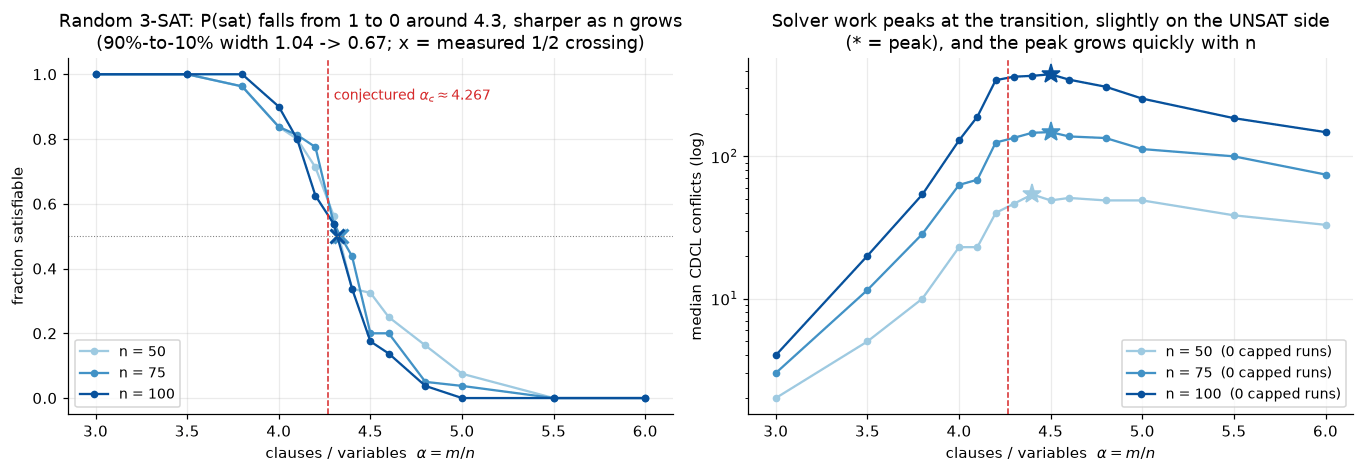

n    P(sat)=1/2 crossing  90% bootstrap CI  90%-to-10% width  peak-work ratio  median conflicts at peak  P(peak left of crossing)  capped runs  time (s)
--------------------------------------------------------------------------------------------------------------------------------------------------------
50   4.328                [4.290, 4.355]    1.043             4.4              54                        0.04                      0            1.0     
75   4.338                [4.286, 4.406]    0.833             4.5              148                       0.02                      0            3.1     
100  4.319                [4.260, 4.352]    0.675             4.5              377                       0.15                      0            8.5     
registered prediction (a): crossing above 4.27 AND drifting down with n | measured: 4.328 -> 4.338 -> 4.319 | verdict: WRONG (half right) -- the point estimates lie above 4.27 at every n (though the n=100 interval reaches 4.260), but t

In [35]:
_s3_RATIOS = [3.0, 3.5, 3.8, 4.0, 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.8, 5.0, 5.5, 6.0]
_s3_PT_TRIALS, _s3_PT_CAP = 80, 5000
_s3_PT_BOOT = 400                             # bootstrap resamples per n
# Crawford & Auton (Artificial Intelligence 81, 1996, eq. 3; 10^4 formulas per point, n = 20..300): the
# crossover lies at 4.258 n + 58.26 n^(-2/3) clauses, i.e. at the ratio 4.258 + 58.26 n^(-5/3).
_s3_CA_FIT = (4.258, 58.26)


def _s3_phase_sweep(n):
    '''For each clause/variable ratio: SAT outcomes (0/1 per formula) and conflicts per formula.'''
    sat, work, capped = [], [], 0
    for ratio in _s3_RATIOS:
        rnd = random.Random(_s3_SEED * 7919 + 1000 * n + round(100 * ratio))
        outcomes, conflicts = [], []
        for _ in range(_s3_PT_TRIALS):
            status, _, st = cdcl(random_3sat(n, round(ratio * n), rnd), n, max_conflicts=_s3_PT_CAP)
            outcomes.append(status == "SAT")
            conflicts.append(st["conflicts"])
            capped += status == "UNKNOWN"
        sat.append(outcomes)
        work.append(conflicts)
    return np.array(sat, float), np.array(work, float), capped


def _s3_crossing(p, level=0.5):
    '''Ratio where P(sat) first falls through `level`, by linear interpolation between grid points.'''
    for i in range(len(p) - 1):
        if p[i] >= level > p[i + 1]:
            return _s3_RATIOS[i] + (p[i] - level) / (p[i] - p[i + 1]) * (_s3_RATIOS[i + 1] - _s3_RATIOS[i])
    return float("nan")


def _s3_peak(med):
    '''The ratio with the largest median work (a grid point).'''
    return _s3_RATIOS[int(np.argmax(med))]


def _s3_phase_transition():
    '''Sweep m/n for three sizes, draw P(sat) and median work, score the predictions.'''
    pt = {}
    for n in (50, 75, 100):
        (sat, work, capped), dt = timed(_s3_phase_sweep, n)
        g = np.random.default_rng(_s3_SEED + n)
        boot_cross, boot_left = [], []
        for _ in range(_s3_PT_BOOT):          # bootstrap over formulas: resample the 80 at every ratio
            idx = g.integers(0, _s3_PT_TRIALS, _s3_PT_TRIALS)
            cross = _s3_crossing(sat[:, idx].mean(axis=1))
            boot_cross.append(cross)
            boot_left.append(_s3_peak(np.median(work[:, idx], axis=1)) < cross)   # same formulas for both
        p = sat.mean(axis=1)
        pt[n] = dict(p=p, med=np.median(work, axis=1), cross=_s3_crossing(p), ci=np.nanpercentile(boot_cross, [5, 95]),
                     width=_s3_crossing(p, 0.1) - _s3_crossing(p, 0.9), p_left=float(np.mean(boot_left)),
                     capped=capped, dt=dt)

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    for n, color in zip(pt, ["#9ecae1", "#4292c6", "#08519c"]):
        axes[0].plot(_s3_RATIOS, pt[n]["p"], "o-", ms=4, color=color, label=f"n = {n}")
        axes[0].plot([pt[n]["cross"]], [0.5], "x", ms=9, mew=2, color=color)
        axes[1].plot(_s3_RATIOS, pt[n]["med"], "o-", ms=4, color=color,
                     label=f"n = {n}  ({pt[n]['capped']} capped runs)")
        k = int(np.argmax(pt[n]["med"]))
        axes[1].plot([_s3_RATIOS[k]], [pt[n]["med"][k]], "*", ms=13, color=color)
    for ax in axes:
        ax.axvline(4.267, color="#d62728", ls="--", lw=1)
        ax.set_xlabel(r"clauses / variables  $\alpha = m/n$")
    axes[0].axhline(0.5, color="gray", lw=0.7, ls=":")
    axes[0].text(4.3, 0.92, r"conjectured $\alpha_c \approx 4.267$", color="#d62728", fontsize=9)
    axes[0].set_ylabel("fraction satisfiable")
    axes[0].set_title("Random 3-SAT: P(sat) falls from 1 to 0 around 4.3, sharper as n grows\n"
                      f"(90%-to-10% width {pt[50]['width']:.2f} -> {pt[100]['width']:.2f}; x = measured 1/2 crossing)")
    axes[0].legend(fontsize=9, loc="lower left")
    axes[1].set_yscale("log")
    axes[1].set_ylabel("median CDCL conflicts (log)")
    axes[1].set_title("Solver work peaks at the transition, slightly on the UNSAT side\n"
                      "(* = peak), and the peak grows quickly with n")
    axes[1].legend(fontsize=9, loc="lower right")
    plt.tight_layout()
    plt.show()

    show_table(["n", "P(sat)=1/2 crossing", "90% bootstrap CI", "90%-to-10% width", "peak-work ratio",
                "median conflicts at peak", "P(peak left of crossing)", "capped runs", "time (s)"],
               [[n, f"{d['cross']:.3f}", f"[{d['ci'][0]:.3f}, {d['ci'][1]:.3f}]", f"{d['width']:.3f}",
                 f"{_s3_peak(d['med']):.1f}", int(d["med"].max()), f"{d['p_left']:.2f}", d["capped"],
                 f"{d['dt']:.1f}"] for n, d in pt.items()])

    # (a) the crossing lies above 4.27 and drifts down toward it
    c = [pt[n]["cross"] for n in pt]
    above = all(x > 4.267 for x in c)
    resolved = pt[50]["ci"][0] > pt[100]["ci"][1]           # n=50 interval entirely above the n=100 one
    if above and resolved and c[0] > c[2]:
        verdict = "RIGHT"
    elif above:
        low = [n for n in pt if pt[n]["ci"][0] <= 4.267]
        caveat = ("their 90% intervals too" if not low else
                  "though the " + ", ".join(f"n={n} interval reaches {pt[n]['ci'][0]:.3f}" for n in low))
        verdict = (f"WRONG (half right) -- the point estimates lie above 4.27 at every n ({caveat}), but the "
                   f"n-dependence is inside the bootstrap intervals")
    else:
        verdict = "WRONG -- at least one crossing is at or below 4.27"
    print(f"registered prediction (a): crossing above 4.27 AND drifting down with n | measured: "
          + " -> ".join(f"{x:.3f}" for x in c) + f" | verdict: {verdict}")
    ca = {n: _s3_CA_FIT[0] + _s3_CA_FIT[1] * n ** (-5 / 3) for n in pt}
    inside = [n for n in pt if pt[n]["ci"][0] <= ca[n] <= pt[n]["ci"][1]]
    drift = ca[50] - ca[100]
    ci_w = [pt[n]["ci"][1] - pt[n]["ci"][0] for n in pt]
    # Power: with sigma_n = CI width / (2 * 1.645), the n=50 and n=100 intervals separate when the measured drift
    # exceeds 1.645 (sigma_50 + sigma_100); for that to happen with probability 0.8 the true drift must exceed it
    # by 0.84 sigma of the difference. Both sigmas shrink like 1/sqrt(formulas), which gives the factor below.
    s50, s100 = ci_w[0] / 3.29, ci_w[2] / 3.29
    more = ((1.645 * (s50 + s100) + 0.8416 * math.hypot(s50, s100)) / drift) ** 2
    print(f"  for scale: Crawford & Auton's fit puts the crossing at " + " / ".join(f"{ca[n]:.3f}" for n in pt)
          + f" for n = 50/75/100, inside our interval at {len(inside)} of 3 sizes. Its drift from n=50 to 100 is "
          f"{drift:.3f}, while our 90% intervals are {min(ci_w):.3f}-{max(ci_w):.3f} wide; separating the "
          f"n=50 and n=100 intervals with 80% probability would need ~{more:.1f}x the formulas "
          f"(~{more * _s3_PT_TRIALS:.0f} per point). (a) was ill-posed for this budget.")

    # (b) the work peak sits at the crossing or right of it, never left
    peaks_ok = all(_s3_peak(pt[n]["med"]) >= pt[n]["cross"] for n in pt)
    worst_left = max(pt, key=lambda n: pt[n]["p_left"])
    print(f"registered prediction (b): work peak at or right of the crossing, never left | measured peaks: "
          + ", ".join(f"{_s3_peak(pt[n]['med'])} vs {pt[n]['cross']:.3f} (n={n})" for n in pt)
          + f" | verdict: {'RIGHT' if peaks_ok else 'WRONG'}"
          + (f" -- on the point estimates; the top of the curve is flat, and in the bootstrap the peak falls "
             f"left of the crossing in {pt[worst_left]['p_left']:.0%} of resamples at n={worst_left}"
             if pt[worst_left]["p_left"] >= 0.05 else ""))

    i6 = _s3_RATIOS.index(6.0)
    print(f"Peak median work grows {pt[100]['med'].max() / pt[50]['med'].max():.1f}x when n doubles from 50 to "
          f"100 (the formula only doubles). Far above the threshold the work is smaller but still grows: at "
          f"alpha = 6 the median rises {pt[100]['med'][i6] / pt[50]['med'][i6]:.1f}x "
          f"({int(pt[50]['med'][i6])} -> {int(pt[100]['med'][i6])}), growth that Chvátal-Szemerédi prove is "
          f"exponential in n; at alpha = 3 it goes from {int(pt[50]['med'][0])} to {int(pt[100]['med'][0])} "
          f"conflicts.")


_s3_phase_transition()

Prediction (a) failed, and it was ill-posed for this budget, which could have been worked out beforehand.
Crawford & Auton's finite-size fit (*Artificial Intelligence* 81, 1996,
[DOI](https://doi.org/10.1016/0004-3702(95)00046-1)), built from $10^4$ formulas per point, moves the crossing by
only about 0.06 between $n = 50$ and $n = 100$. Our 90% intervals at 80 formulas per point are wider than that,
and separating them with 80% probability would take about 3.3 times as many formulas, beyond this cell's time
budget. Our crossings agree with that fit at every size. Only the weaker half held, and only on the point
estimates, since the $n = 100$ interval reaches below 4.27. Prediction (b) held at every size on the point
estimates. The top of the work curve is a flat plateau, though, and at $n = 100$ the bootstrap puts the peak
left of the crossing in 15% of resamples.

### 3.7 Industrial SAT: certified records, a 20-year algorithm race, and equivalence checking

**Records are certified, not trusted.** The largest SAT results in mathematics ship with proofs that dwarf the
formulas, and the community believes the proof checker, not the solver:

| result | proof | compute | checked by |
|---|---|---|---|
| Boolean Pythagorean triples: $\{1..7824\}$ 2-colourable, $\{1..7825\}$ not (Heule, Kullmann & Marek 2016) | DRAT, almost 200 TB; formula 6,494 vars / 18,944 clauses | ~4 CPU-years; 800 cores, ~2 days | DRAT-trim |
| Schur number five, $S(5) = 160$ (Heule, AAAI 2018) | over 2 PB | just over 14 CPU-years | ACL2-verified checker, a little over 36 CPU-years |
| Keller's conjecture, dimension 7 (Brakensiek, Heule, Mackey & Narváez 2020) | 224 GB binary DRAT (the $s = 6$ case) | Lonestar 5 cluster, CaDiCaL | ACL2-verified checker |
| Empty hexagon, $h(6) = 30$ (Heule & Scheucher 2024) | LRAT | ~17,300 CPU-hours incl. proof checking | cake_lpr; the *encoding* verified in Lean |

cake_lpr is verified in CakeML down to its machine-code binary, so not even a compiler is trusted (Tan, Heule &
Myreen, TACAS 2021). The last row adds what our §3.3 checker cannot catch: a wrong CNF *encoding* of the
question. That residue is the **spec**, and it gets its own proof. The same division of labour recurs in §10
(kernels) and §13 (LLM provers).

**The algorithm race.** In the 2002 SAT Competition only 4 of 19 solvers used the CDCL architecture (Fichte, Le
Berre, Hecher & Szeider, CACM 2023). Today's winners are all CDCL descendants: SBVA-CaDiCaL in 2023,
kissat-sc2024 in 2024, and AE-Kissat-MAB in 2025 (327 of 400 benchmarks within 5,000 s). The *Time Leap
Challenge* (Fichte, Hecher & Szeider) separated hardware progress from algorithm progress on 200 instances with a
900 s timeout. It first appeared at CP 2020, racing Grasp, zChaff and siege as the old solvers. The numbers below
are from the revised version ([arXiv 2008.02215v2](https://arxiv.org/abs/2008.02215v2), 2023, Table 1), which
races three 2003 solvers instead; both versions reach the same conclusion.

| | 2003 solvers (Jerusat / siege / Forklift) | 2016–19 solvers (Glucose / CaDiCaL / MapleSat19) |
|---|---|---|
| 1999 hardware (Pentium III, 467 MHz) | 38 / 43 / 43 | 105 / 100 / 72 |
| 2019 hardware (Xeon Silver 4112) | 71 / 96 / 105 | **188 / 184 / 187** |

Sixteen years of solver ideas (2003 to 2019) buy at least as much as twenty years of hardware (1999 to 2019):
old code on new hardware solves 91 instances on average, new code on old hardware 92. Our solver has the same
core ideas. On identical pigeonhole CNFs §3.5 measured Z3's engine close to our conflict counts on the small
instances and pulling ahead with every further hole, so that under the same conflict budget it got one hole
further in this run. Both curves stay exponential: engineering lowers the base and the constant of the
exponential, and Haken's bound guarantees that no implementation of resolution makes it polynomial.

**This is what an equivalence checker does.** §3.5's adder miter is logic equivalence checking (LEC) in
miniature: two circuits, an XOR per output, one SAT call. Production LEC tools (the chip notebook's "netlist ≡
RTL", §6.3 there) work on and-inverter graphs and first merge structurally identical gates (the structural
hashing §4 builds in). They then use random simulation to guess which internal signals of the two designs are
equal and prove those guesses one at a time with small incremental SAT calls (**SAT sweeping**). Each proved
pair is merged, so the final miter collapses instead of being solved monolithically. The free lunch behind it:
the old design is a *complete* specification of the new one.

§4 turns machine arithmetic into exactly these circuits, so that `abs32`, `midpoint` and compiler rewrites
become SAT queries for `cdcl`.

## 4. From bits to programs: bit-vectors, bit-blasting, SMT

§3 built a solver for formulas over Booleans. Programs compute over 32- and 64-bit machine integers, and the
bugs in this notebook's running examples (`abs32` at `INT_MIN`, `midpoint` at large `lo + hi`) exist *only*
because of how those integers wrap. A verifier that reasons over mathematical integers proves both functions
correct and misses both bugs. This section closes the gap the way hardware does: **a machine integer is a vector
of bits, and every arithmetic operation is a circuit**. Compile the circuit to CNF with §3.1's Tseitin clauses,
call `cdcl`, and you have a **bit-precise** decision procedure, a **bit-blaster**. Bit-blasting is how Z3, CBMC,
Kani and Alive handle bit-vectors at bottom. Then we measure where it breaks, and why industrial solvers are
*SMT* solvers (satisfiability modulo theories) rather than plain SAT solvers.

### 4.1 Arithmetic is a circuit

A $w$-bit pattern $b_{w-1}\dots b_0$ means $\sum_i b_i 2^i$ unsigned, and in **two's complement**

$$\text{signed}(b) = -b_{w-1}\,2^{w-1} + \sum_{i<w-1} b_i\,2^i .$$

Both readings agree modulo $2^w$. That is why a CPU has one adder for `int` and `unsigned`, and why only
comparisons, division and right shifts care about the sign. Each operation then becomes a small, derivable
circuit:

- **Add**: the ripple-carry adder from the chip notebook. $s_i = a_i \oplus b_i \oplus c_i$, and
  $c_{i+1} = a_i b_i \lor c_i (a_i \oplus b_i)$, the majority of the three inputs. That is $O(w)$ gates, and the
  carry out of the top bit is simply dropped: that dropped bit *is* the wrap-around.
- **Negate and subtract**: $x + \lnot x = 2^w - 1 \equiv -1$, so $-x = \lnot x + 1$, and
  $x - y = x + \lnot y + 1$ is the same adder with carry-in 1. For `INT_MIN` = `100…0`, $\lnot x$ = `011…1`, and
  adding 1 gives `100…0` again. So $-\texttt{INT\_MIN} = \texttt{INT\_MIN}$, and `abs32`'s bug falls out of the
  circuit itself.
- **Shifts by a constant are wiring**: `shl` moves bits up and fills with 0, `lshr` moves them down and fills
  with 0, and `ashr` fills with copies of the sign bit. They cost zero gates.
- **Unsigned $x < y$**: scan from bit 0 upwards; the most significant differing bit decides. **Signed** $x < y$:
  flip both sign bits first. That adds the bias $2^{w-1}$ and maps signed order onto unsigned order.
- **Multiply**: shift-and-add, $x \cdot y = \sum_i (x \ll i)\, y_i$. That is $\approx w^2/2$ AND gates and $w$
  adders, $O(w^2)$ gates. Quadratic size is fine; §4.4 shows the trouble is elsewhere.
- **`ite(c, x, y)`** is a multiplexer per bit; Boolean `AND/OR/NOT/XOR/IMPLIES` are single gates.

Two cheap tricks from logic synthesis keep the CNF small. **Constant folding** rewrites `AND(x, F)` to `F`,
`XOR(x, x)` to `F`, and so on. **Structural hashing** reuses a gate that already exists on the same inputs; it
is the AIG trick behind every equivalence checker, and in §4.4 it proves a theorem with zero SAT calls. To
*prove* $P$ for all inputs, `prove(P)` asks `cdcl` for an input satisfying $\lnot P$: UNSAT is a proof, and a
model is a counterexample, decoded as signed integers. The API, which §5's `expr_to_bv` and §6's toy backend
build on:

| call | meaning |
|---|---|
| `ctx = BV(width, hashing=True)` | a fresh circuit; `ctx.T`, `ctx.F` are the constant literals (`1`, `-1`) |
| `ctx.var(name)`, `ctx.const(k)` | a free `width`-bit input (same word if the name exists) / the constant `k mod 2^w` |
| `add, sub, mul, and_, or_, xor` (word, word) | arithmetic and bitwise ops, wrapping mod $2^w$ |
| `neg(x)`, `not_(x)` | $-x$ (two's complement), $\lnot x$ (bitwise) |
| `shl(x, k)`, `ashr(x, k)`, `lshr(x, k)` | shifts by an *int* constant `k >= 0` (negative `k` raises `ValueError`) |
| `eq, ult, slt, sle` (word, word) | predicates, each returning one literal (`ult` unsigned, `slt`/`sle` signed) |
| `ite(lit, x, y)` | per-bit multiplexer |
| `AND(*lits), OR(*lits), NOT(a), XOR(a, b), IMPLIES(a, b)` | Boolean gates on literals |
| `ctx.prove(lit, max_conflicts=None)` | `(status, cex, stats)`, status `'proved'`/`'counterexample'`/`'unknown'`; `cex` = {name: signed int} |
| `ctx.find(lit, max_conflicts=None)` | `(status, model, stats)`, status `'sat'`/`'unsat'`/`'unknown'`; model = {name: signed int} |
| `ctx.value(word_or_lit, signed=True)` | decode any word (int) or literal (bool) in the last model, including internal wires |
| `z3_model_to_dict(model, vars)` | the same decoding for a Z3 model (bit-vectors as signed ints) |

Words are lists of literals, least-significant bit first, so `x[-1]` is the sign bit. `stats` adds `vars`,
`clauses` and `sat_calls` to `cdcl`'s counters.

The class is built in three layers, one cell each: Boolean gates (with folding and hashing), then words made of
those gates, then solving and decoding. The first layer is the only place clauses are written.

In [36]:
class _s4_Gates:
    '''Layer 1 of the bit-blaster BV: Boolean gates as two-sided Tseitin clauses (§3.1), with constant
    folding (always on) and structural hashing (optional). Literal 1 is the constant TRUE.'''

    def __init__(self, width, hashing=True):
        self.width, self.hashing = width, hashing
        self.T, self.F = 1, -1
        self.n_vars, self.clauses = 1, [[1]]
        self.names = {}                 # name -> word of a free input variable
        self._gate_cache = {}           # structural hash: (op, inputs) -> output literal
        self.model = None               # raw cdcl model of the last satisfiable query
        self.sat_calls = 0

    # ---- Boolean gates (Tseitin clauses, folding, hashing) -------------------------------------
    def _fresh(self):
        self.n_vars += 1
        return self.n_vars

    def _and2(self, a, b):
        T, F = self.T, self.F
        if a == F or b == F or a == -b:
            return F
        if a == T:
            return b
        if b == T or a == b:
            return a
        key = ('and', min(a, b), max(a, b))
        if self.hashing and key in self._gate_cache:
            return self._gate_cache[key]
        o = self._fresh()
        self.clauses += [[-o, a], [-o, b], [o, -a, -b]]          # o <-> (a and b)
        if self.hashing:
            self._gate_cache[key] = o
        return o

    def AND(self, *lits):
        out = self.T
        for lit in lits:
            out = self._and2(out, lit)
        return out

    def OR(self, *lits):
        return -self.AND(*[-lit for lit in lits])                 # De Morgan: OR costs nothing extra

    def NOT(self, a):
        return -a                                                 # negation is free: flip the sign

    def IMPLIES(self, a, b):
        return self.OR(-a, b)

    def XOR(self, a, b):
        T, F = self.T, self.F
        if a == F:
            return b
        if b == F:
            return a
        if a == T:
            return -b
        if b == T:
            return -a
        if a == b:
            return F
        if a == -b:
            return T
        flip = (a < 0) != (b < 0)                                 # x ^ ~y = ~(x ^ y): hash on |a|, |b|
        a, b = sorted((abs(a), abs(b)))
        key = ('xor', a, b)
        if self.hashing and key in self._gate_cache:
            o = self._gate_cache[key]
        else:
            o = self._fresh()
            self.clauses += [[-o, a, b], [-o, -a, -b], [o, -a, b], [o, a, -b]]
            if self.hashing:
                self._gate_cache[key] = o
        return -o if flip else o

    def _mux(self, c, a, b):
        return self.OR(self.AND(c, a), self.AND(-c, b))           # c ? a : b


def _s4_gate_costs():
    '''Clauses each gate adds on two fresh inputs (the cost model of layer 1).'''
    g = _s4_Gates(1, hashing=False)
    a, b = g._fresh(), g._fresh()
    costs = {}
    for name, gate in (("AND", g.AND), ("XOR", g.XOR), ("OR", g.OR), ("IMPLIES", g.IMPLIES)):
        before = len(g.clauses)
        gate(a, b)
        costs[name] = len(g.clauses) - before
    return costs


_s4_costs = _s4_gate_costs()
print("clauses per 2-input gate: " + ", ".join(f"{k} {v}" for k, v in _s4_costs.items())
      + "; NOT adds none (it flips the literal's sign), and OR/IMPLIES are an AND behind De Morgan.")

clauses per 2-input gate: AND 3, XOR 4, OR 3, IMPLIES 3; NOT adds none (it flips the literal's sign), and OR/IMPLIES are an AND behind De Morgan.


A word is a list of those literals, so every word operation is a loop over gates. The adder is the chip
notebook's ripple-carry chain, subtraction reuses it with carry-in 1, the multiplier is $w$ adders, and shifts
only re-index the list. A shift amount must be a non-negative int; anything at or above the width clears the
word (or fills it with the sign bit, for `ashr`), as in Z3.

In [37]:
class _s4_Words(_s4_Gates):
    '''Layer 2 of BV: w-bit words (lists of literals, LSB first) and the operations on them.'''

    def var(self, name):
        '''A free w-bit input (the same word if the name already exists).'''
        if name not in self.names:
            self.names[name] = [self._fresh() for _ in range(self.width)]
        return self.names[name]

    def const(self, k):
        return [self.T if (k >> i) & 1 else self.F for i in range(self.width)]   # k mod 2^w, LSB first

    def add(self, x, y, carry=None):
        '''Ripple-carry adder: s_i = x_i ^ y_i ^ c_i, c_{i+1} = majority(x_i, y_i, c_i). Wraps mod 2^w.'''
        carry = self.F if carry is None else carry
        out = []
        for a, b in zip(x, y):
            p = self.XOR(a, b)
            out.append(self.XOR(p, carry))
            carry = self.OR(self.AND(a, b), self.AND(p, carry))
        return out

    def not_(self, x):
        return [-a for a in x]

    def neg(self, x):
        return self.add(self.not_(x), self.const(0), carry=self.T)           # -x = ~x + 1

    def sub(self, x, y):
        return self.add(x, self.not_(y), carry=self.T)                        # x - y = x + ~y + 1

    def and_(self, x, y):
        return [self.AND(a, b) for a, b in zip(x, y)]

    def or_(self, x, y):
        return [self.OR(a, b) for a, b in zip(x, y)]

    def xor(self, x, y):
        return [self.XOR(a, b) for a, b in zip(x, y)]

    def _shift_amount(self, k):
        if k < 0:
            raise ValueError(f"negative shift amount {k}")                    # Python's << and >> also refuse
        return min(k, self.width)                                             # k >= w shifts everything out

    def shl(self, x, k):
        k = self._shift_amount(k)
        return [self.F] * k + x[:self.width - k]

    def lshr(self, x, k):
        k = self._shift_amount(k)
        return x[k:] + [self.F] * k

    def ashr(self, x, k):
        k = self._shift_amount(k)
        return x[k:] + [x[-1]] * k                                            # copy the sign bit in

    def mul(self, x, y):
        '''Shift-add multiplier: sum over i of (x << i) masked by bit y_i. O(w^2) gates.'''
        acc = self.const(0)
        for i in range(self.width):
            acc = self.add(acc, [self.AND(y[i], b) for b in self.shl(x, i)])
        return acc

    def ite(self, c, x, y):
        return [self._mux(c, a, b) for a, b in zip(x, y)]

    # ---- predicates (return one literal) -------------------------------------------------------
    def eq(self, x, y):
        return self.AND(*[-self.XOR(a, b) for a, b in zip(x, y)])

    def ult(self, x, y):
        '''Unsigned x < y, scanning LSB -> MSB: the highest differing bit decides.'''
        lt = self.F
        for a, b in zip(x, y):
            lt = self.OR(self.AND(-a, b), self.AND(-self.XOR(a, b), lt))
        return lt

    def slt(self, x, y):
        '''Signed x < y = unsigned compare after flipping both sign bits (adds the bias 2^(w-1)).'''
        return self.ult(x[:-1] + [-x[-1]], y[:-1] + [-y[-1]])

    def sle(self, x, y):
        return -self.slt(y, x)


print("word layer: add/sub/neg are ripple-carry adders, mul is w of them, shifts are re-indexing (0 gates).")

word layer: add/sub/neg are ripple-carry adders, mul is w of them, shifts are re-indexing (0 gates).


Solving is a single call to §3's `cdcl` on the accumulated clauses plus one unit clause. `find(lit)` asks for an
input making `lit` true, and `prove(lit)` refutes `NOT lit`. A literal that constant folding already reduced to
`F` needs no SAT call at all.

In [38]:
class BV(_s4_Words):
    '''A bit-blaster: fixed-width two's-complement words compiled to CNF and solved by cdcl (§3).

    A word is a list of `width` literals, least-significant bit first; a Boolean is one literal.
    Literal 1 is the constant TRUE (ctx.T == 1, ctx.F == -1).  Every gate is two-sided Tseitin, so
    every model of the CNF assigns every internal wire its true value (§3.1).  With hashing=True a gate
    already built on the same inputs is reused (structural hashing, as in AIG-based equivalence
    checkers); constant folding is always on.  Layers: _s4_Gates (gates) -> _s4_Words (words) -> BV
    (solving and decoding).'''

    def value(self, word_or_lit, signed=True):
        '''Decode a literal (-> bool) or a word (-> int) in the last model.'''
        def bit(lit):
            return self.model[abs(lit)] == (lit > 0)
        if isinstance(word_or_lit, int):
            return bit(word_or_lit)
        u = sum(1 << i for i, lit in enumerate(word_or_lit) if bit(lit))
        return u - (1 << self.width) if signed and u >> (self.width - 1) else u

    def find(self, lit, max_conflicts=None):
        '''Search for inputs making `lit` true -> ('sat' | 'unsat' | 'unknown', {name: signed int}, stats).'''
        stats = dict(vars=self.n_vars, clauses=len(self.clauses) + 1, sat_calls=0, decisions=0, conflicts=0,
                     propagations=0, learned=0, restarts=0, deleted=0, watch_visits=0)   # cdcl's keys, all 0
        if lit == self.F:                                     # folded away: no SAT call needed
            return 'unsat', None, stats
        status, model, st = cdcl(self.clauses + [[lit]], self.n_vars, max_conflicts=max_conflicts)
        self.sat_calls += 1
        stats.update(st, sat_calls=1)
        if status != 'SAT':
            return ('unsat' if status == 'UNSAT' else 'unknown'), None, stats
        self.model = model
        return 'sat', {name: self.value(word) for name, word in self.names.items()}, stats

    def prove(self, lit, max_conflicts=None):
        '''Prove `lit` holds for ALL inputs by refuting its negation ->
        ('proved' | 'counterexample' | 'unknown', cex {name: signed int} or None, stats).'''
        status, cex, stats = self.find(-lit, max_conflicts=max_conflicts)
        return {'unsat': 'proved', 'sat': 'counterexample', 'unknown': 'unknown'}[status], cex, stats


def z3_model_to_dict(model, vars):
    '''Z3 model -> {name: value}: bit-vectors as SIGNED ints, Ints as ints, Bools as bools.
    `vars` is a dict {name: z3 const} or an iterable of z3 consts (named by str()).'''
    items = vars.items() if isinstance(vars, dict) else ((str(v), v) for v in vars)
    out = {}
    for name, v in items:
        val = model.eval(v, model_completion=True)
        if z3.is_bv(v):
            out[name] = val.as_signed_long()
        elif z3.is_int(v):
            out[name] = val.as_long()
        elif z3.is_bool(v):
            out[name] = z3.is_true(val)
        else:
            out[name] = val
    return out


def _s4_smoke_test():
    '''One query end to end: is x + 1 > x for every signed 8-bit x?'''
    ctx = BV(8)
    x = ctx.var("x")
    status, cex, st = ctx.prove(ctx.slt(x, ctx.add(x, ctx.const(1))))
    return status, cex, st["sat_calls"]


_s4_smoke = _s4_smoke_test()
print(f"BV(8).prove(x + 1 > x) -> {_s4_smoke[0]}, {_s4_smoke[1]} after {_s4_smoke[2]} SAT call: the only signed "
      "8-bit x where it fails is 127, because 127 + 1 wraps to -128.")

BV(8).prove(x + 1 > x) -> counterexample, {'x': 127} after 1 SAT call: the only signed 8-bit x where it fails is 127, because 127 + 1 wraps to -128.


Before anything is built on `BV`, the next cell checks every operation against its plain-Python meaning, and
then prints what each 32-bit operation costs in gates and clauses. The test runs every operation on every input
pair at $w = 3$ and $w = 4$, with and without hashing, three ways. In the *pinned* mode the inputs are variables
fixed by equality constraints, so constant folding never sees them and the solver must compute the result from
the clauses themselves. The *const* mode is the opposite: both inputs are constants, so folding alone must
produce the answer, which is how §5 and §6 feed program literals in. The *mixed* mode does half of each. Shifts
by $k > w$ are included.

In [39]:
def _s4_reference_ops(w):
    '''Every BV operation next to its plain-Python meaning on SIGNED w-bit values (via wrap from §0).'''
    u = lambda a: a % (1 << w)                                  # the unsigned reading of the same bits
    words = {
        "add": (lambda c, x, y: c.add(x, y), lambda a, b: wrap(a + b, w)),
        "sub": (lambda c, x, y: c.sub(x, y), lambda a, b: wrap(a - b, w)),
        "mul": (lambda c, x, y: c.mul(x, y), lambda a, b: wrap(a * b, w)),
        "neg": (lambda c, x, y: c.neg(x), lambda a, b: wrap(-a, w)),
        "and_": (lambda c, x, y: c.and_(x, y), lambda a, b: wrap(a & b, w)),
        "or_": (lambda c, x, y: c.or_(x, y), lambda a, b: wrap(a | b, w)),
        "xor": (lambda c, x, y: c.xor(x, y), lambda a, b: wrap(a ^ b, w)),
        "not_": (lambda c, x, y: c.not_(x), lambda a, b: wrap(~a, w)),
        "ite(slt)": (lambda c, x, y: c.ite(c.slt(x, y), x, y), lambda a, b: min(a, b)),
    }
    for k in range(w + 3):                                      # includes k > w: everything shifted out
        words[f"shl {k}"] = (lambda c, x, y, k=k: c.shl(x, k), lambda a, b, k=k: wrap(a << k, w))
        words[f"ashr {k}"] = (lambda c, x, y, k=k: c.ashr(x, k), lambda a, b, k=k: a >> k)
        words[f"lshr {k}"] = (lambda c, x, y, k=k: c.lshr(x, k), lambda a, b, k=k: wrap(u(a) >> k, w))
    preds = {
        "eq": (lambda c, x, y: c.eq(x, y), lambda a, b: a == b),
        "ult": (lambda c, x, y: c.ult(x, y), lambda a, b: u(a) < u(b)),
        "slt": (lambda c, x, y: c.slt(x, y), lambda a, b: a < b),
        "sle": (lambda c, x, y: c.sle(x, y), lambda a, b: a <= b),
        "IMPLIES(slt, ult)": (lambda c, x, y: c.IMPLIES(c.slt(x, y), c.ult(x, y)),
                              lambda a, b: not a < b or u(a) < u(b)),
    }
    return words, preds


def _s4_folded_value(ctx, word_or_lit, signed=True):
    '''Decode a word or literal that constant folding must have reduced to T/F literals (None if it did not).'''
    lits = [word_or_lit] if isinstance(word_or_lit, int) else word_or_lit
    if any(lit not in (ctx.T, ctx.F) for lit in lits):
        return None                                             # a gate survived: folding missed a constant
    if isinstance(word_or_lit, int):
        return word_or_lit == ctx.T
    u = sum(1 << i for i, lit in enumerate(lits) if lit == ctx.T)
    return u - (1 << ctx.width) if signed and u >> (ctx.width - 1) else u


def _s4_check_pair(w, hashing, a, b, mode, ops):
    '''Build every op on one input pair in one operand mode; return (checks, failures, SAT calls used).'''
    ctx = BV(w, hashing=hashing)
    x = ctx.const(a) if mode == "const" else ctx.var("x")
    y = ctx.var("y") if mode == "pinned" else ctx.const(b)
    built = {k: f(ctx, x, y) for k, (f, _) in ops.items()}
    if mode == "const":
        decode, calls = (lambda v: _s4_folded_value(ctx, v)), 0
    else:
        pins = [ctx.eq(x, ctx.const(a))] + ([ctx.eq(y, ctx.const(b))] if mode == "pinned" else [])
        status, model, _ = ctx.find(ctx.AND(*pins))
        assert status == "sat" and model == ({"x": a, "y": b} if mode == "pinned" else {"x": a})
        decode, calls = ctx.value, 1
    failures = sum(decode(built[k]) != ref(a, b) for k, (_, ref) in ops.items())
    return len(ops), failures, calls


def _s4_exhaustive_op_test():
    '''Every op on every pair of w-bit inputs, against plain Python, in three operand modes:
    'pinned': both inputs are variables PINNED to the constants by an equality constraint, so the solver (not
              constant folding) must compute every op from the clauses;
    'mixed':  x pinned, y = ctx.const(b), so half of every gate folds and half is solved;
    'const':  both inputs are ctx.const, so folding alone must produce the answer, with no SAT call at all.'''
    checks, failures, sat_calls = Counter(), Counter(), 0
    for w in (3, 4):
        words, preds = _s4_reference_ops(w)
        ops = {**words, **preds}
        span = range(-(1 << (w - 1)), 1 << (w - 1))
        for hashing, a, b, mode in itertools.product((True, False), span, span, ("pinned", "mixed", "const")):
            n, bad, calls = _s4_check_pair(w, hashing, a, b, mode, ops)
            checks[mode] += n
            failures[mode] += bad
            sat_calls += calls
    try:                                                        # a negative shift must be refused, like Python's
        BV(4).lshr(BV(4).var("x"), -1)
        negative_refused = False
    except ValueError:
        negative_refused = True
    return checks, failures, sat_calls, len(ops), negative_refused


(_s4_checks, _s4_fails, _s4_calls, _s4_n_ops, _s4_neg), _s4_dt = timed(_s4_exhaustive_op_test)
print(f"{_s4_n_ops} ops at w = 4 (shifts by k = 0..w+2; fewer at w = 3), every input pair at w = 3 and 4, hashing "
      f"on and off, {_s4_calls} SAT calls (~{_s4_dt:.1f} s):")
print("   " + " | ".join(f"{m}: {_s4_checks[m]} checks, {_s4_fails[m]} failures"
                         for m in ("pinned", "mixed", "const")) + f" | negative shift refused: {_s4_neg}")


def _s4_op_sizes(w=32):
    rows = []
    for name, build in (("add", lambda c, x, y: c.add(x, y)), ("sub", lambda c, x, y: c.sub(x, y)),
                        ("slt", lambda c, x, y: [c.slt(x, y)]), ("eq", lambda c, x, y: [c.eq(x, y)]),
                        ("ashr 1", lambda c, x, y: c.ashr(x, 1)), ("mul", lambda c, x, y: c.mul(x, y))):
        ctx = BV(w)
        before = (ctx.n_vars, len(ctx.clauses))
        x, y = ctx.var("x"), ctx.var("y")
        build(ctx, x, y)
        rows.append([name, ctx.n_vars - before[0] - 2 * w, len(ctx.clauses) - before[1]])
    return rows


show_table(["32-bit op", "gate variables", "CNF clauses"], _s4_op_sizes())
print("Shifts are free wiring, comparisons and adders are linear in w, the multiplier is quadratic: "
      "the gate counts above are the whole cost model of bit-blasting.")

35 ops at w = 4 (shifts by k = 0..w+2; fewer at w = 3), every input pair at w = 3 and 4, hashing on and off, 1280 SAT calls (~0.4 s):
   pinned: 22016 checks, 0 failures | mixed: 22016 checks, 0 failures | const: 22016 checks, 0 failures | negative shift refused: True
32-bit op  gate variables  CNF clauses
--------------------------------------
add        157             534        
sub        158             537        
slt        126             410        
eq         63              221        
ashr 1     0               0          
mul        2915            9706       
Shifts are free wiring, comparisons and adders are linear in w, the multiplier is quadratic: the gate counts above are the whole cost model of bit-blasting.


### 4.2 The running examples, bit-precisely, at 32 bits

Now the two bugs from §1 become single solver queries over all inputs at once ($2^{32}$ values of `x`, $2^{64}$
pairs `(lo, hi)`):

- `abs32`: build `r = ite(x < 0, -x, x)` and prove `r >= 0`.
- `midpoint_buggy`: under the precondition `0 <= lo <= hi`, prove `lo <= (lo + hi) >> 1 <= hi`.
- `midpoint_fixed`: the same with `lo + ((hi - lo) >> 1)`.

Every counterexample is replayed in plain Python with §0's `wrap` before it is believed. A *proof* gets no such
replay, but §3.3 showed how its certificate could be checked.

In [40]:
def _s4_abs_circuit(w):
    ctx = BV(w)
    x, zero = ctx.var("x"), ctx.const(0)
    r = ctx.ite(ctx.slt(x, zero), ctx.neg(x), x)                       # abs: -x if x < 0 else x
    return ctx, ctx.NOT(ctx.slt(r, zero)), {"r": r}                   # claim: r >= 0


def _s4_midpoint_circuit(w, fixed):
    ctx = BV(w)
    lo, hi, zero = ctx.var("lo"), ctx.var("hi"), ctx.const(0)
    pre = ctx.AND(ctx.sle(zero, lo), ctx.sle(lo, hi))                  # requires(0 <= lo <= hi)
    if fixed:
        diff = ctx.sub(hi, lo)
        half = ctx.ashr(diff, 1)
        m = ctx.add(lo, half)                                          # lo + ((hi - lo) >> 1)
        wires = {"hi - lo": diff, "(hi - lo) >> 1": half, "m": m}
    else:
        s = ctx.add(lo, hi)
        m = ctx.ashr(s, 1)                                             # (lo + hi) >> 1
        wires = {"lo + hi": s, "m": m}
    post = ctx.AND(ctx.sle(lo, m), ctx.sle(m, hi))                     # ensures(lo <= result <= hi)
    return ctx, ctx.IMPLIES(pre, post), wires


def _s4_replay(name, cex, w):
    '''Run the counterexample through the SAME program in plain Python on w-bit wrapped integers.
    True = the bug is real (the precondition holds and the postcondition fails).'''
    if name == "abs":
        x = cex["x"]
        return (wrap(-x, w) if x < 0 else x) < 0
    lo, hi = cex["lo"], cex["hi"]
    if name == "midpoint_fixed":
        m = wrap(lo + (wrap(hi - lo, w) >> 1), w)                      # lo + ((hi - lo) >> 1)
    else:
        m = wrap(lo + hi, w) >> 1                                      # (lo + hi) >> 1
    return 0 <= lo <= hi and not (lo <= m <= hi)


def _s4_running_examples():
    rows = []
    for name, w, build in (("abs", 32, lambda w: _s4_abs_circuit(w)), ("abs", 64, lambda w: _s4_abs_circuit(w)),
                           ("midpoint_buggy", 32, lambda w: _s4_midpoint_circuit(w, False)),
                           ("midpoint_fixed", 32, lambda w: _s4_midpoint_circuit(w, True)),
                           ("midpoint_fixed", 64, lambda w: _s4_midpoint_circuit(w, True))):
        ctx, claim, _ = build(w)
        (status, cex, st), dt = timed(ctx.prove, claim)
        replay = _s4_replay(name, cex, w) if cex else "-"
        rows.append([f"{name} (w={w})", status, cex if cex else "-", replay, st["conflicts"],
                     f"{st['vars']} / {st['clauses']}", f"{dt * 1e3:.0f}"])
    show_table(["claim", "result", "counterexample", "replays in Python?", "conflicts", "CNF vars / clauses",
                "ms"], rows)
    return rows


_s4_rows = _s4_running_examples()
print(f"abs: the only 32-bit counterexample is INT_MIN = {INT32_MIN}; the solver found it with "
      f"{_s4_rows[0][4]} conflicts, without enumerating 2^32 inputs (§1's exhaustive sweep).")
_s4_fixed = {row[0]: row[1] for row in _s4_rows if row[0].startswith("midpoint_fixed")}
print(f"midpoint_fixed: {_s4_fixed['midpoint_fixed (w=32)']} at w = 32 (all 2^64 input pairs) and "
      f"{_s4_fixed['midpoint_fixed (w=64)']} at w = 64 (all 2^128), under its precondition 0 <= lo <= hi.")

claim                  result          counterexample                        replays in Python?  conflicts  CNF vars / clauses  ms 
-----------------------------------------------------------------------------------------------------------------------------------
abs (w=32)             counterexample  {'x': -2147483648}                    True                0          189 / 501           0  
abs (w=64)             counterexample  {'x': -9223372036854775808}           True                0          381 / 1013          1  
midpoint_buggy (w=32)  counterexample  {'lo': 1073741824, 'hi': 1073741824}  True                1          571 / 1647          1  
midpoint_fixed (w=32)  proved          -                                     -                   1547       728 / 2181          102
midpoint_fixed (w=64)  proved          -                                     -                   3695       1464 / 4389         339
abs: the only 32-bit counterexample is INT_MIN = -2147483648; the solver fou

Because every gate is two-sided Tseitin (§3.1), the solver's model also holds the true value of every internal
wire. The figure decodes the intermediate sum `lo + hi` straight out of a model at $w = 8$, where the bits fit
on a page, and sets the fixed version beside it on the same inputs. To make the carry chain visible, the query
also asks for `lo != hi` with both ending in binary `111`.

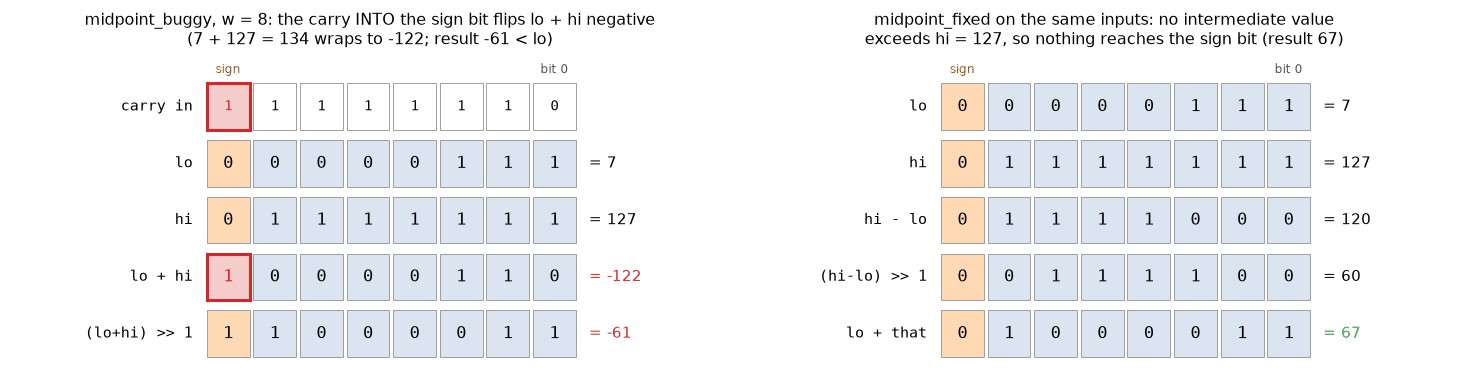

model's internal wire lo + hi = 134 (unsigned bits) == Python's (lo + hi) mod 256 = 134: True; decoded m = -61 == wrap(lo + hi) >> 1 = -61: True
The bug needs lo + hi > 127 at w = 8, i.e. > INT32_MAX at w = 32: arrays of more than 2^30 elements,
which is why it lay in wait "for nine years or so" (Bloch 2006; §1.3).


In [41]:
def _s4_draw_bit_rows(ax, rows, w, title, hot_col=None, hot_rows=()):
    '''rows: list of (label, value, kind) drawn MSB..LSB; kind 'carry' rows are drawn small, above.'''
    for r, (label, value, kind) in enumerate(rows):
        y = len(rows) - 1 - r
        bits = [(value >> i) & 1 for i in range(w)]
        for i in range(w):
            col = w - 1 - i                                              # draw bit w-1 on the left
            hot = hot_col is not None and i == hot_col and r in hot_rows
            fc = "#f4cccc" if hot else ("#ffd9b3" if i == w - 1 else "#dbe5f1")
            if kind == "carry":
                fc = "#f4cccc" if hot else "white"
            ax.add_patch(Rectangle((col, y), 0.92, 0.82, fc=fc, ec="#d62728" if hot else "#999999",
                                   lw=2 if hot else 0.6))
            ax.text(col + 0.46, y + 0.41, str(bits[i]), ha="center", va="center", family="monospace",
                    fontsize=11 if kind != "carry" else 9, color="#d62728" if hot else "black")
        signed = value - (1 << w) if value >> (w - 1) else value
        ax.text(-0.3, y + 0.41, label, ha="right", va="center", family="monospace", fontsize=9.5)
        if kind != "carry":
            ax.text(w + 0.2, y + 0.41, f"= {signed}", ha="left", va="center", fontsize=10,
                    color="#d62728" if (kind == "bad") else ("#2ca02c" if kind == "good" else "black"))
    ax.text(0 + 0.46, len(rows) - 0.05, "sign", ha="center", va="bottom", fontsize=8, color="#b45f06")   # bit w-1
    ax.text(w - 1 + 0.46, len(rows) - 0.05, "bit 0", ha="center", va="bottom", fontsize=8, color="#555555")
    ax.set_xlim(-4.2, w + 3.2)
    ax.set_ylim(-0.3, len(rows) + 0.35)
    ax.axis("off")
    ax.set_title(title, fontsize=10.5)


def _s4_draw_midpoint_bits():
    '''Find a w = 8 midpoint counterexample, decode its internal wires, and draw buggy vs fixed bit rows.'''
    W8 = 8
    ctx8, claim8, wires8 = _s4_midpoint_circuit(W8, fixed=False)
    lo8, hi8 = ctx8.var("lo"), ctx8.var("hi")
    low3 = ctx8.and_(ctx8.and_(lo8, hi8), ctx8.const(0b111))              # both end in binary ...111:
    status8, cex8, _ = ctx8.find(ctx8.AND(ctx8.NOT(claim8), ctx8.NOT(ctx8.eq(lo8, hi8)),  # a long carry chain
                                          ctx8.eq(low3, ctx8.const(0b111))))
    lo, hi = cex8["lo"], cex8["hi"]
    s_model = ctx8.value(wires8["lo + hi"], signed=False)                 # an INTERNAL wire, read from the model
    m_model = ctx8.value(wires8["m"], signed=False)
    carries = [0]
    for i in range(W8):                                                    # carries recomputed in Python
        a, b = (lo >> i) & 1, (hi >> i) & 1
        carries.append((a & b) | (carries[-1] & (a ^ b)))
    carry_word = sum(c << i for i, c in enumerate(carries[:W8]))           # carry INTO bit i, for i = 0..7
    d = hi - lo
    fixed_m = lo + (d >> 1)

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 3.6))
    _s4_draw_bit_rows(axes[0], [("carry in", carry_word, "carry"), ("lo", lo, ""), ("hi", hi, ""),
                                ("lo + hi", s_model, "bad"), ("(lo+hi) >> 1", m_model, "bad")], W8,
                      f"midpoint_buggy, w = 8: the carry INTO the sign bit flips lo + hi negative\n"
                      f"({lo} + {hi} = {lo + hi} wraps to {wrap(lo + hi, W8)}; result {wrap(m_model, W8)} < lo)",
                      hot_col=W8 - 1, hot_rows=(0, 3))
    _s4_draw_bit_rows(axes[1], [("lo", lo, ""), ("hi", hi, ""), ("hi - lo", d, ""), ("(hi-lo) >> 1", d >> 1, ""),
                                ("lo + that", fixed_m, "good")], W8,
                      "midpoint_fixed on the same inputs: no intermediate value\n"
                      f"exceeds hi = {hi}, so nothing reaches the sign bit (result {fixed_m})")
    plt.tight_layout()
    plt.show()

    print(f"model's internal wire lo + hi = {s_model} (unsigned bits) == Python's (lo + hi) mod 256 = "
          f"{(lo + hi) % 256}: {s_model == (lo + hi) % 256}; decoded m = {wrap(m_model, W8)} == "
          f"wrap(lo + hi) >> 1 = {wrap(lo + hi, W8) >> 1}: {wrap(m_model, W8) == wrap(lo + hi, W8) >> 1}")
    print(f"The bug needs lo + hi > {2 ** (W8 - 1) - 1} at w = 8, i.e. > INT32_MAX at w = 32: arrays of more "
          "than 2^30 elements,")
    print('which is why it lay in wait "for nine years or so" (Bloch 2006; §1.3).')


_s4_draw_midpoint_bits()

### 4.3 Checking an optimizer: when the old code *is* the spec

Writing a specification is the hard part of verification (§2). One situation gives you a complete specification
for free: an **optimization**. If the compiler rewrites `e1` into `e2`, then `e1` is the spec. The claim
`e1 == e2` for every input is a bit-vector formula, and a solver either proves it or returns the input that
breaks it. Checked once per rewrite *rule*, for all inputs, this is what **Alive** (Lopes, Menendez, Nagarakatte
& Regehr, PLDI 2015) does for LLVM's peephole optimizer: the authors translated more than 300 InstCombine rewrites
into Alive and found 8 of them wrong. Checked instead on every individual compilation, comparing the code before
and after each pass, it is **translation validation** (Pnueli, Siegel & Singerman, TACAS 1998,
[DOI](https://doi.org/10.1007/BFb0054170)); for LLVM that is Alive2's "bounded translation validation" (Lopes,
Lee, Hur, Liu & Regehr, PLDI 2021, [DOI](https://doi.org/10.1145/3453483.3454030)). The cell below does the
first kind. Hardware equivalence checking (§3.7) is the same idea, which is why it is routine in chip design and
rare in software. Software rarely has a trusted previous version that is *supposed* to be equivalent.

The classic trap is to compile signed `x / 2` to `x >> 1`. In C, `/` truncates toward zero ($-3/2 = -1$), and an
arithmetic right shift rounds toward $-\infty$ ($-3 \gg 1 = -2$). (In C, `>>` on a negative signed value is
implementation-defined; C++20 defines it as arithmetic shift, rounding toward $-\infty$; see
[cppreference](https://en.cppreference.com/w/cpp/language/operator_arithmetic).) So the rewrite is wrong for
every negative odd `x`. The correct rewrite adds the sign bit first, `(x + ((x >> 31) & 1)) >> 1`: one extra
shift, mask and add, no division. A logical shift (written `>>>` here, as in Java) already brings the sign bit
down to bit 0, so `(x + (x >>> 31)) >> 1` saves the mask. The cell checks all three rewrites with the toy at
$w = 32$. The reference is C's definition itself, written as a circuit: divide the *magnitude* by 2 with a
logical shift, then restore the sign, which is correct even for `INT_MIN`. Z3 then re-checks the first two
claims at $w = 64$ against its own built-in signed division `bvsdiv`, a definition our toy shares no code with.

A smaller trap of the same kind, as one Z3 query: `x & (x - 1) == 0` is the folklore power-of-two test. It tests
the *unsigned* bit pattern, so on a signed `int32` it also accepts a negative number.

In [42]:
def _s4_c_div2(ctx, x):
    '''C's x / 2 (truncate toward zero) as a circuit: halve the magnitude, then restore the sign.'''
    negative = ctx.slt(x, ctx.const(0))
    return ctx.ite(negative, ctx.neg(ctx.lshr(ctx.neg(x), 1)), ctx.ashr(x, 1))


def _s4_c_div2_py(x):
    return -((-x) // 2) if x < 0 else x // 2                           # Python's // floors; this truncates


def _s4_replay_div(v):
    '''Concrete replay: C's truncating v/2 minus the shift's floor(v/2) (nonzero = the rewrite is wrong).'''
    return f"x odd & < 0: {v % 2 == 1 and v < 0}; (x/2) - (x>>1) = {_s4_c_div2_py(v) - (v >> 1)}"


def _s4_translation_validation(w=32):
    rows = []
    for label, rewrite in (("x >> 1", lambda c, x: c.ashr(x, 1)),
                           ("(x + ((x >> 31) & 1)) >> 1",
                            lambda c, x: c.ashr(c.add(x, c.and_(c.ashr(x, w - 1), c.const(1))), 1)),
                           ("(x + (x >>> 31)) >> 1", lambda c, x: c.ashr(c.add(x, c.lshr(x, w - 1)), 1))):
        ctx = BV(w)
        x = ctx.var("x")
        (status, cex, st), dt = timed(ctx.prove, ctx.eq(_s4_c_div2(ctx, x), rewrite(ctx, x)))
        replay = _s4_replay_div(cex["x"]) if cex else "-"
        rows.append([f"x / 2  ==  {label}", "toy BV, w=32", status, cex["x"] if cex else "-", replay,
                     st["conflicts"]])
    if HAVE_Z3:
        x, x32 = z3.BitVec("x", 64), z3.BitVec("x", 32)
        reference = z3.If(x32 < 0, -z3.LShR(-x32, 1), x32 >> 1)       # the toy's C reference, in Z3 terms
        claims = [("x / 2  ==  x >> 1", x / 2 == x >> 1, x),          # Z3's "/" on bit-vectors is bvsdiv
                  ("x / 2  ==  (x + ((x >> 63) & 1)) >> 1", x / 2 == (x + ((x >> 63) & 1)) >> 1, x),
                  ("toy's C reference == bvsdiv (w=32)", reference == x32 / 2, x32)]
        for label, claim, var in claims:
            s = z3.Solver()
            s.set("timeout", 3000)
            s.add(z3.Not(claim))
            r = s.check()
            status, cex, replay = ("proved" if r == z3.unsat else "unknown"), "-", "-"
            if r == z3.sat:
                status, cex = "counterexample", z3_model_to_dict(s.model(), {"x": var})["x"]
                replay = _s4_replay_div(cex)
            rows.append([label, f"Z3, w={var.size()}", status, cex, replay, "-"])
    show_table(["claim", "checked by", "result", "counterexample x", "replayed in Python", "conflicts"], rows)
    print("The optimizer's input was the complete spec of its output: no human wrote a single specification line.")


_s4_translation_validation()


def _s4_power_of_two():
    '''The folklore power-of-two test accepts exactly one negative int32: find it, then show it is unique.'''
    if not HAVE_Z3:
        print("Z3 not installed: skipping the power-of-two query.")
        return
    x = z3.BitVec("x", 32)
    s = z3.Solver()
    s.set("timeout", 3000)
    s.add(x != 0, x & (x - 1) == 0, x < 0)                                 # a "power of two" that is negative?
    r = s.check()
    witness = z3_model_to_dict(s.model(), {"x": x})["x"] if r == z3.sat else None
    s.add(x != witness if witness is not None else True)
    print(f"x & (x-1) == 0 with x < 0: {r}, x = {witness} (INT_MIN = {INT32_MIN}); any other? {s.check()}")
    print("-> x & (x-1) == 0 tests the UNSIGNED bit pattern; on a signed int32 the test must also require x > 0.")


_s4_power_of_two()

claim                                  checked by    result          counterexample x    replayed in Python                     conflicts
-----------------------------------------------------------------------------------------------------------------------------------------
x / 2  ==  x >> 1                      toy BV, w=32  counterexample  -2147450881         x odd & < 0: True; (x/2) - (x>>1) = 1  169      
x / 2  ==  (x + ((x >> 31) & 1)) >> 1  toy BV, w=32  proved          -                   -                                      250      
x / 2  ==  (x + (x >>> 31)) >> 1       toy BV, w=32  proved          -                   -                                      250      
x / 2  ==  x >> 1                      Z3, w=64      counterexample  -50179819698126849  x odd & < 0: True; (x/2) - (x>>1) = 1  -        
x / 2  ==  (x + ((x >> 63) & 1)) >> 1  Z3, w=64      proved          -                   -                                      -        
toy's C reference == bvsdiv (w=32)

### 4.4 Where bit-blasting stops scaling: multiplication

Adders are easy for CDCL for the reason §3.5 measured: carries are local, so learned clauses are local. A
multiplier is different. In the toy's $w$-bit product (the low $w$ bits, the wrap-around product), output bit $k$
depends on $a_0 \dots a_k$ and $b_0 \dots b_k$, so the top bits depend on every input bit, through about $w^2/2$
partial products summed in a fixed order. Prove $a \cdot b = b \cdot a$ with two shift-add multipliers that sum
the same partial products in a different order (rows of $b$ versus rows of $a$), and the solver must rediscover,
bit by bit, that addition is commutative and associative across the whole array. Multiplier equivalence is the
textbook hard case. Bryant (1991) proved that BDDs for the middle bit of the full $2w$-bit product are exponential
under *every* variable order. Kaufmann's thesis (2020) reports that the multiplier miters submitted to the SAT
Competition 2016 confirmed that "miters of even small multipliers produce very hard SAT problems". And although
Beame & Liew (CAV 2017) showed that polynomial-size resolution proofs *exist*, CDCL solvers do not find them. The
industrial fix is to leave bits altogether: Kaufmann, Biere & Kauers (FMCAD 2019) verify 2048-bit multipliers by
computer algebra, using SAT only for the final adder.

An SMT solver sidesteps the problem when it can. Z3 *rewrites* at the word level before it bit-blasts: its
simplifier puts the factors of a product into one canonical order, so `a*b == b*a` is already `True` before any
search starts (the Z3 cell prints `z3.simplify` of it and measures zero SAT conflicts). Structural hashing does
the same for addition in our toy: the two adders for `a + b` and `b + a` hash to identical gates, so the miter
folds to `T` before the solver is ever called.

**Registered prediction.** (a) Z3 proves `a*b == b*a` at 64 bits instantly, by rewriting, but a hand-written
shift-add circuit `== a*b`, which forces it to bit-blast both sides, times out (2.5 s) by $w \approx 10$. (b)
Our toy's conflicts on `mul(a, b) == mul(b, a)` grow by at least 3× per extra bit, and $w = 8$ exceeds a
30,000-conflict cap, while the CNF grows only quadratically ($\propto w^2$).

*How it is measured.* A wall-clock timeout makes a borderline width flip between runs, so every Z3 query below
runs in a fresh `z3.Context` under a deterministic work budget (Z3's `rlimit`) instead. The budget is larger than
the 2.5 s the prediction names (the Z3 cell prints how long it lasted), so a width that exhausts it would also
have timed out at 2.5 s: `unknown` here is at least as strong as the predicted timeout, and it is reproducible.
The toy runs under the 30,000-conflict cap of (b); a second cell then reruns $w = 8$ with a cap ten times higher.

In [43]:
_s4_MUL_CAP = 30_000                                     # prediction (b)'s conflict cap for the toy
_s4_MUL_WIDTHS = range(2, 9)


def _s4_mul_commutativity(w, hashing=True):
    '''The toy miter: two shift-add multipliers that sum the same partial products in a different order.'''
    ctx = BV(w, hashing=hashing)
    a, b = ctx.var("a"), ctx.var("b")
    return ctx, ctx.eq(ctx.mul(a, b), ctx.mul(b, a))


def _s4_toy_multiplier():
    '''Toy cdcl on the commutativity miter at w = 2..8 under the cap, plus CNF sizes up to w = 64.'''
    toy = {}
    for w in _s4_MUL_WIDTHS:
        ctx, claim = _s4_mul_commutativity(w)
        (status, _, st), dt = timed(ctx.prove, claim, max_conflicts=_s4_MUL_CAP)
        toy[w] = (status, st["conflicts"], st["vars"], st["clauses"], dt)
    sizes = {}
    for w in (2, 4, 8, 16, 32, 64):
        ctx, _ = _s4_mul_commutativity(w)
        sizes[w] = (ctx.n_vars, len(ctx.clauses))
    return toy, sizes


(_s4_mul_toy, _s4_mul_sizes), _s4_dt = timed(_s4_toy_multiplier)
print("toy cdcl, mul(a,b) == mul(b,a): " + ", ".join(
    f"w={w}: {s} ({c} conflicts)" for w, (s, c, *_) in _s4_mul_toy.items()) + f"   (~{_s4_dt:.1f} s)")
print("CNF size of the toy miter's circuit (vars/clauses, before the query's 1 unit clause):",
      ", ".join(f"w={w}: {v}/{c}" for w, (v, c) in _s4_mul_sizes.items()))
_s4_solved = [w for w in _s4_MUL_WIDTHS if _s4_mul_toy[w][0] == "proved" and w >= 3]
_s4_growth = [_s4_mul_toy[w + 1][1] / _s4_mul_toy[w][1] for w in _s4_solved if w + 1 in _s4_solved]
_s4_slope = np.polyfit(np.log([16, 32, 64]), np.log([_s4_mul_sizes[w][1] for w in (16, 32, 64)]), 1)[0]
_s4_ok_b = (min(_s4_growth) >= 3 and _s4_mul_toy[8][0] == "unknown" and 1.8 <= _s4_slope <= 2.2)
print(f"registered prediction (b): toy conflicts grow >= 3x per bit, w=8 over the 30k cap, CNF ~ w^2 | measured: "
      f"ratios {' '.join(f'{g:.1f}' for g in _s4_growth)} (w=3..7), w=8 {_s4_mul_toy[8][0]} at the cap, CNF "
      f"clauses ~ w^{_s4_slope:.2f} (w=16..64) | verdict: {'RIGHT' if _s4_ok_b else 'WRONG'}")

toy cdcl, mul(a,b) == mul(b,a): w=2: proved (0 conflicts), w=3: proved (13 conflicts), w=4: proved (92 conflicts), w=5: proved (398 conflicts), w=6: proved (1769 conflicts), w=7: proved (7557 conflicts), w=8: unknown (30000 conflicts)   (~4.6 s)
CNF size of the toy miter's circuit (vars/clauses, before the query's 1 unit clause): w=2: 10/17, w=4: 62/179, w=8: 300/953, w=16: 1304/4277, w=32: 5424/18029, w=64: 22112/73949
registered prediction (b): toy conflicts grow >= 3x per bit, w=8 over the 30k cap, CNF ~ w^2 | measured: ratios 7.1 4.3 4.4 4.3 (w=3..7), w=8 unknown at the cap, CNF clauses ~ w^2.06 (w=16..64) | verdict: RIGHT


A cap is a budget, not a wall. The next cell reruns $w = 8$ with the higher cap, to see how far past 30,000
conflicts the proof actually lies.

In [44]:
def _s4_toy_w8_uncapped(cap=10 * _s4_MUL_CAP):
    ctx, claim = _s4_mul_commutativity(8)
    (status, _, st), dt = timed(ctx.prove, claim, max_conflicts=cap)
    return status, st["conflicts"], dt


_s4_mul_w8 = _s4_toy_w8_uncapped()
print(f"toy cdcl at w = 8 with a {10 * _s4_MUL_CAP:,}-conflict cap: {_s4_mul_w8[0]} after {_s4_mul_w8[1]:,} "
      f"conflicts (~{_s4_mul_w8[2]:.0f} s), {_s4_mul_w8[1] / _s4_MUL_CAP:.1f}x the {_s4_MUL_CAP:,} cap and "
      f"{_s4_mul_w8[1] / _s4_mul_toy[7][1]:.1f}x the conflicts of w = 7.")
print("The cap only decides where the curve is cut off; the exponent per bit is the finding.")

toy cdcl at w = 8 with a 300,000-conflict cap: proved after 69,886 conflicts (~9 s), 2.3x the 30,000 cap and 9.2x the conflicts of w = 7.
The cap only decides where the curve is cut off; the exponent per bit is the finding.


Now Z3, three ways: its SAT engine on *our exact CNF*, its own bit-blaster on a hand-written shift-add circuit
`== a*b`, and its word level on `a*b == b*a`.

In [45]:
_s4_Z3_RLIMIT = 10_000_000                               # deterministic Z3 work budget per query (see the prose)
_s4_Z3_SAFETY_MS = 15_000                                # wall-clock safety net only; it should never bind


def _s4_z3_check(build_negated_claim):
    '''Run one Z3 query in a FRESH context under the rlimit budget. build_negated_claim(ctx) returns the
    assertions (the NEGATION of the claim) -> (status, Z3's SAT conflicts, seconds).'''
    ctx = z3.Context()
    s = z3.Solver(ctx=ctx)
    s.set("rlimit", _s4_Z3_RLIMIT)
    s.set("timeout", _s4_Z3_SAFETY_MS)
    s.add(build_negated_claim(ctx))
    r, dt = timed(s.check)
    st = s.statistics()
    conflicts = st.get_key_value("sat conflicts") if "sat conflicts" in st.keys() else 0
    status = "proved" if r == z3.unsat else "counterexample" if r == z3.sat else "unknown"
    return status, conflicts, dt


def _s4_z3_cnf(clauses, n_vars):
    '''Hand Z3 exactly our CNF (the negated claim is already a unit clause in it).'''
    def build(ctx):
        B = [None] + [z3.Bool(f"v{v}", ctx) for v in range(1, n_vars + 1)]
        return [z3.Or([B[l] if l > 0 else z3.Not(B[-l]) for l in c]) for c in clauses]
    return _s4_z3_check(build)


def _s4_z3_shift_add(w):
    '''Z3 on shift-add(a, b) == a * b: the left side is a circuit Z3 can only bit-blast.'''
    def build(ctx):
        a, b = z3.BitVecs("a b", w, ctx)
        zero = z3.BitVecVal(0, w, ctx)
        shift_add = zero
        for i in range(w):
            shift_add = shift_add + z3.If(z3.Extract(i, i, b) == 1, a << i, zero)
        return [z3.Not(shift_add == a * b)]
    return _s4_z3_check(build)


def _s4_z3_word_level(w=64):
    def build(ctx):
        a, b = z3.BitVecs("a b", w, ctx)
        return [z3.Not(a * b == b * a)]
    return _s4_z3_check(build)


def _s4_z3_multiplier():
    z3_cnf = {}
    for w in _s4_MUL_WIDTHS:
        ctx, claim = _s4_mul_commutativity(w)
        z3_cnf[w] = _s4_z3_cnf(ctx.clauses + [[-claim]], ctx.n_vars)
    z3_shift = {w: _s4_z3_shift_add(w) for w in range(4, 11)}
    return z3_cnf, z3_shift, _s4_z3_word_level()


def _s4_simplify(term, max_steps=10_000):
    '''z3.simplify under a rewrite-step budget (the rewriter's resource limit); running out is 'unknown'.'''
    try:
        return z3.simplify(term, max_steps=max_steps)
    except z3.Z3Exception:
        return "unknown (step budget exhausted)"


if HAVE_Z3:
    (_s4_mul_z3cnf, _s4_mul_z3shift, _s4_mul_z3word), _s4_dt = timed(_s4_z3_multiplier)
    _s4_a, _s4_b, _s4_c = z3.BitVecs("a b c", 64)
    print(f"z3.simplify(a*b == b*a) = {_s4_simplify(_s4_a * _s4_b == _s4_b * _s4_a)};  z3.simplify(b*a) = "
          f"{_s4_simplify(_s4_b * _s4_a)};  z3.simplify(a*b*c == c*(b*a)) = "
          f"{_s4_simplify(_s4_a * _s4_b * _s4_c == _s4_c * (_s4_b * _s4_a))}")
    _s4_word = _s4_mul_z3word
    print(f"Z3 word level, a*b == b*a at w = 64: {_s4_word[0]}, {_s4_word[1]} SAT conflicts, "
          f"{'< 1 ms' if _s4_word[2] < 1e-3 else f'~{_s4_word[2] * 1e3:.0f} ms'}")
    print("Z3 bit-blasting shift-add == a*b: " + ", ".join(
        f"w={w}: {s} ({c:,} conflicts, ~{dt:.1f} s)" for w, (s, c, dt) in _s4_mul_z3shift.items()))
    _s4_first_unknown = min([w for w, (s, *_) in _s4_mul_z3shift.items() if s == "unknown"], default=None)
    _s4_last_proved = max([w for w, (s, *_) in _s4_mul_z3shift.items() if s == "proved"], default=None)
    _s4_ok_a = _s4_word[0] == "proved" and _s4_first_unknown is not None and 9 <= _s4_first_unknown <= 11
    print(f"registered prediction (a): Z3 word-level instant at 64 bits; shift-add == a*b times out by w ~ 10 | "
          f"measured: word-level {_s4_word[0]}; shift-add first exhausts the budget at w = {_s4_first_unknown} "
          f"(w = {_s4_last_proved} needed ~{_s4_mul_z3shift[_s4_last_proved][2]:.1f} s) | "
          f"verdict: {'RIGHT' if _s4_ok_a else 'WRONG'}")
else:
    _s4_mul_z3cnf, _s4_mul_z3shift, _s4_mul_z3word = {}, {}, None
    print("Z3 not installed: skipping the Z3 multiplier series and prediction (a).")

z3.simplify(a*b == b*a) = True;  z3.simplify(b*a) = a*b;  z3.simplify(a*b*c == c*(b*a)) = True
Z3 word level, a*b == b*a at w = 64: proved, 0 SAT conflicts, < 1 ms
Z3 bit-blasting shift-add == a*b: w=4: proved (86 conflicts, ~0.0 s), w=5: proved (469 conflicts, ~0.0 s), w=6: proved (1,559 conflicts, ~0.0 s), w=7: proved (7,789 conflicts, ~0.1 s), w=8: proved (25,073 conflicts, ~0.3 s), w=9: proved (100,303 conflicts, ~2.3 s), w=10: unknown (218,309 conflicts, ~4.8 s)
registered prediction (a): Z3 word-level instant at 64 bits; shift-add == a*b times out by w ~ 10 | measured: word-level proved; shift-add first exhausts the budget at w = 10 (w = 9 needed ~2.3 s) | verdict: RIGHT


Both predictions come out right. The $w = 9$ line shows why the budget had to be deterministic: Z3 needed roughly
the 2.5 s the prediction named, so a wall-clock timeout at 2.5 s decided that width by luck. The figure puts the
toy and both Z3 bit-level series on one log axis, next to the size of the formula; the table under it has every
point.

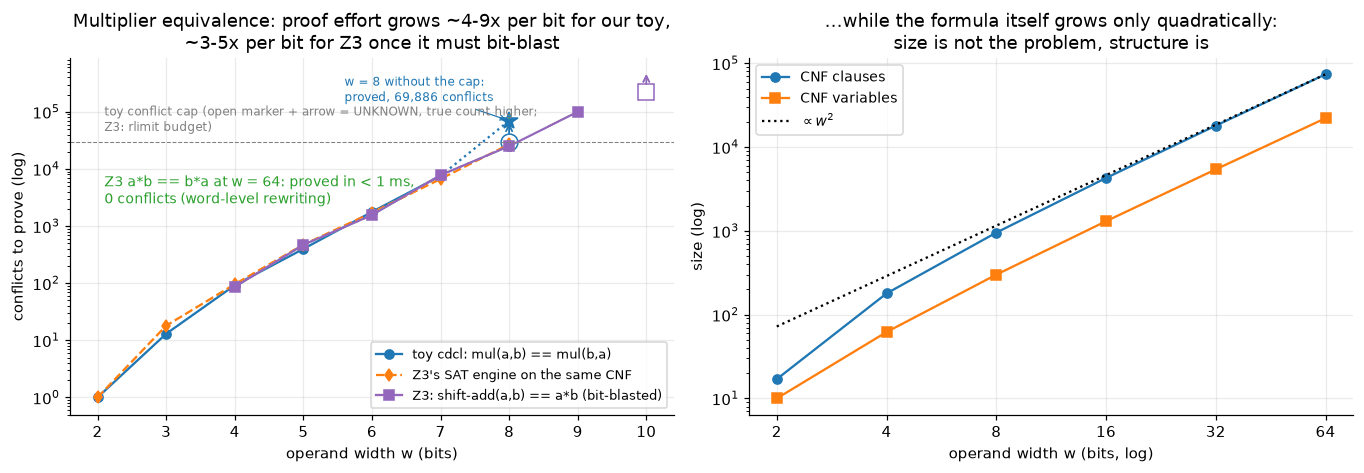

w   toy result  toy conflicts  toy CNF vars/clauses  toy s  Z3 on same CNF (conflicts)  Z3 shift-add == a*b (conflicts, s)
--------------------------------------------------------------------------------------------------------------------------
2   proved      0              10/18                 0.00   proved (0)                  -                                 
3   proved      13             30/79                 0.00   proved (18)                 -                                 
4   proved      92             62/180                0.00   proved (96)                 proved (86, 0.00 s)               
5   proved      398            105/318               0.02   proved (472)                proved (469, 0.00 s)              
6   proved      1769           159/493               0.11   proved (1,714)              proved (1,559, 0.01 s)            
7   proved      7557           224/705               0.68   proved (6,676)              proved (7,789, 0.05 s)            
8   unknown     

In [46]:
def _s4_plot_series(ax, xs, ys, censored, fmt, color, label):
    '''Solved points joined by a line; budget-capped runs as open markers with an upward arrow (the true count
    lies above), so a capped run never looks like a measured point.'''
    solved = [(x, y) for x, y, c in zip(xs, ys, censored) if not c]
    if solved:
        ax.plot(*zip(*solved), fmt, color=color, label=label)
    for x, y, c in zip(xs, ys, censored):
        if c:
            ax.plot([x], [y], fmt[0], ms=11, mfc="white", mec=color)
            ax.annotate("", xy=(x, y * 2.4), xytext=(x, y * 1.25), annotation_clip=False,
                        arrowprops=dict(arrowstyle="->", color=color, lw=1.2))


def _s4_per_bit(series):
    '''Growth factor per extra bit between consecutive SOLVED widths (w >= 3, so no zero counts).'''
    ok = {w: c for w, (st, c, *_) in series.items() if st == "proved" and w >= 3}
    return [ok[w + 1] / ok[w] for w in sorted(ok) if w + 1 in ok]


def _s4_show_multiplier():
    '''Draw the multiplier experiment, tabulate it, then the structural-hashing lesson.'''
    toy, sizes, z3_cnf, z3_shift, z3_word = (_s4_mul_toy, _s4_mul_sizes, _s4_mul_z3cnf, _s4_mul_z3shift,
                                             _s4_mul_z3word)
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    ax = axes[0]
    ws = sorted(toy)
    _s4_plot_series(ax, ws, [max(1, toy[w][1]) for w in ws], [toy[w][0] == "unknown" for w in ws], "o-",
                    "#1f77b4", "toy cdcl: mul(a,b) == mul(b,a)")
    if _s4_mul_w8[0] == "proved":
        ax.plot([7, 8], [toy[7][1], _s4_mul_w8[1]], ":", color="#1f77b4")
        ax.plot([8], [_s4_mul_w8[1]], "*", ms=12, color="#1f77b4")
        ax.annotate(f"w = 8 without the cap:\nproved, {_s4_mul_w8[1]:,} conflicts", (8, _s4_mul_w8[1]),
                    xytext=(5.6, _s4_mul_w8[1] * 2.2), fontsize=8, color="#1f77b4",
                    arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=0.8))
    if z3_cnf:
        ax.plot(sorted(z3_cnf), [max(1, z3_cnf[w][1]) for w in sorted(z3_cnf)], "d--", color="#ff7f0e",
                label="Z3's SAT engine on the same CNF")
    if z3_shift:
        sw = sorted(z3_shift)
        _s4_plot_series(ax, sw, [max(1, z3_shift[w][1]) for w in sw], [z3_shift[w][0] == "unknown" for w in sw],
                        "s-", "#9467bd", "Z3: shift-add(a,b) == a*b (bit-blasted)")
    ax.axhline(_s4_MUL_CAP, color="gray", lw=0.7, ls="--")
    ax.text(2.1, _s4_MUL_CAP * 1.3, "toy conflict cap (open marker + arrow = UNKNOWN, true count higher;\n"
            "Z3: rlimit budget)", fontsize=8, color="gray", va="bottom")
    if z3_word:
        ms = "< 1 ms" if z3_word[2] < 1e-3 else f"{z3_word[2] * 1e3:.0f} ms"
        ax.annotate(f"Z3 a*b == b*a at w = 64: {z3_word[0]} in {ms},\n"
                    f"{z3_word[1]} conflicts (word-level rewriting)", xy=(2.1, 2500), fontsize=9,
                    color="#2ca02c")
    rates = _s4_growth + ([_s4_mul_w8[1] / toy[7][1]] if _s4_mul_w8[0] == "proved" else [])
    z3_rates = _s4_per_bit(z3_cnf) + _s4_per_bit(z3_shift)            # both of Z3's bit-level series
    ax.set_yscale("log")
    top = max([toy[w][1] for w in ws] + [_s4_mul_w8[1]] + [z3_shift[w][1] for w in z3_shift])
    ax.set_ylim(0.5, top * 4)                                          # room for the UNKNOWN arrows
    ax.set_xlabel("operand width w (bits)")
    ax.set_ylabel("conflicts to prove (log)")
    ax.set_title(f"Multiplier equivalence: proof effort grows ~{min(rates):.0f}-{max(rates):.0f}x per bit for our "
                 "toy,\n" + (f"~{min(z3_rates):.0f}-{max(z3_rates):.0f}x per bit for Z3 once it must bit-blast"
                             if z3_rates else "(Z3 not installed)"))
    ax.legend(fontsize=8.5, loc="lower right")

    ax = axes[1]
    sw = sorted(sizes)
    ax.loglog(sw, [sizes[w][1] for w in sw], "o-", label="CNF clauses")
    ax.loglog(sw, [sizes[w][0] for w in sw], "s-", label="CNF variables")
    ref = np.array(sw, float)
    ax.loglog(ref, sizes[64][1] * (ref / 64) ** 2, ":", color="black", label=r"$\propto w^2$")
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_xticks(sw)
    ax.set_xticklabels([str(w) for w in sw])
    ax.set_xlabel("operand width w (bits, log)")
    ax.set_ylabel("size (log)")
    ax.set_title("...while the formula itself grows only quadratically:\nsize is not the problem, structure is")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    def row(w):
        t = toy.get(w)
        toy_cells = [t[0], t[1], f"{t[2]}/{t[3]}", f"{t[4]:.2f}"] if t else ["-"] * 4
        c = f"{z3_cnf[w][0]} ({z3_cnf[w][1]:,})" if w in z3_cnf else "-"
        sa = f"{z3_shift[w][0]} ({z3_shift[w][1]:,}, {z3_shift[w][2]:.2f} s)" if w in z3_shift else "-"
        return [w] + toy_cells + [c, sa]

    show_table(["w", "toy result", "toy conflicts", "toy CNF vars/clauses", "toy s", "Z3 on same CNF (conflicts)",
                "Z3 shift-add == a*b (conflicts, s)"], [row(w) for w in range(2, 11)])
    for w in (8, 16, 32):
        ctx = BV(w)
        a, b = ctx.var("a"), ctx.var("b")
        folded = ctx.eq(ctx.add(a, b), ctx.add(b, a))
        status, _, st = ctx.prove(folded)
        ctx2 = BV(w, hashing=False)
        a2, b2 = ctx2.var("a"), ctx2.var("b")
        status2, _, st2 = ctx2.prove(ctx2.eq(ctx2.add(a2, b2), ctx2.add(b2, a2)))
        print(f"a+b == b+a, w={w}: hashing on -> {status}, literal is T: {folded == ctx.T}, {st['sat_calls']} SAT "
              f"calls | hashing off -> {status2}, {st2['sat_calls']} SAT call, {st2['conflicts']} conflicts")


_s4_show_multiplier()

### 4.5 Beyond bits: theories, DPLL(T), and theory combination

Bit-blasting is complete for fixed-width integers: given 2.3 times the cap, the toy does prove $w = 8$, and every
extra bit multiplies the work again. But it throws away everything the solver could know at the word level, and
§4.4 measured what that costs. An **SMT solver** keeps a SAT engine for the Boolean structure and adds **theory
solvers** that reason natively about the atoms:

- **EUF** (equality with uninterpreted functions). If $a = b$ then $f(a) = f(b)$, and nothing else is assumed
  about $f$. **Congruence closure** decides conjunctions of such atoms by merging equivalence classes in a
  union-find, plus a merge of $f(a)$ and $f(b)$ whenever $a$ and $b$ merge. Verifiers use $f$ to abstract
  anything they do not want to interpret: a hash function, a library call, a heap.
- **LIA / LRA** (linear integer / real arithmetic): simplex for the reals, plus branch-and-bound and cuts for
  integers. This is the theory of §6's `'int'` semantics.
- **Arrays**: `Select(Store(M, p, v), q)` is `v` if `p == q`, else `Select(M, q)`. This is §7's model of memory.
- **Bit-vectors**: word-level rewriting first, then bit-blasting, which is exactly the circuit above.

The architecture is **DPLL(T)** (Nieuwenhuis, Oliveras & Tinelli, *J. ACM* 2006). The SAT engine treats each
theory atom such as `x - y <= 3` as an opaque Boolean and searches as in §3. Whenever it commits to truth values
for some atoms, the theory solver checks whether that *conjunction* is consistent in the theory. If it is not, the
theory solver returns a small inconsistent subset $\{a_1, \dots, a_k\}$ of the asserted atoms, an **explanation**,
and the clause $\lnot a_1 \lor \dots \lor \lnot a_k$ is added as a **theory lemma**, which CDCL learns like any
other clause. Production solvers also run the theory *during* the search: when the asserted atoms imply another
atom $l$, the theory solver propagates $l$, and it must be able to explain it with a clause
$\lnot a_1 \lor \dots \lor \lnot a_k \lor l$, which conflict analysis then uses as $l$'s reason (§3's implication
graph needs a reason for every implied literal).

**Nelson–Oppen** (*TOPLAS* 1979) combines decision procedures for theories whose signatures are disjoint (they
share only $=$) and that are *stably infinite* (every satisfiable formula has an infinite model). Each solver
works on its own part of a *purified* formula, and the solvers exchange the equalities between shared variables
that their part entails, until one finds a contradiction or nothing new is entailed. Purifying
`x + y = 3 ∧ f(x) ≠ f(3 - y)` introduces a fresh `z = 3 - y`; LIA then derives `x = z`, and EUF refutes
`f(x) ≠ f(z)`. Exchanging single equalities is complete when every theory is **convex** (LRA, EUF): whenever a
convex theory entails a disjunction of equalities, it entails one of the disjuncts. LIA is not convex:
`1 <= x <= 2 ∧ y = 1 ∧ z = 2` entails `x = y ∨ x = z` without entailing either, so a LIA solver must propagate the
disjunction, or the combination must guess an arrangement of the shared variables (the third cell below checks
this example). Bit-vectors have finite domains, so they are not stably infinite and are combined by other means.

The first cell draws the loop. The second runs it for real with our own `cdcl` as the SAT engine and a 20-line
theory solver for **difference logic** (atoms `x - y <= c`, decided by negative-cycle detection with
Bellman–Ford). This is the theory behind scheduling and timing constraints. The example schedules four jobs on one
machine under a deadline. The third runs one-line Z3 queries, at least one per theory, and the non-convex example.

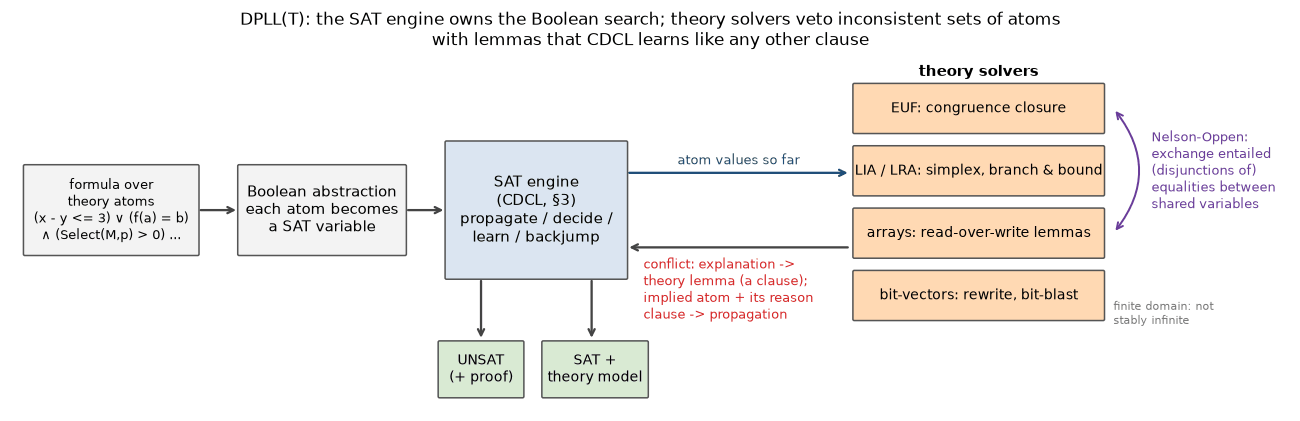

The diagram is the architecture of Z3 and cvc5; the cell below runs a miniature of it.


In [47]:
def _s4_draw_dpll_t(ax):
    '''The DPLL(T) architecture as a box-and-arrow diagram.'''
    def box(x, y, w, h, text, fc, fs=9.5):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec="#555555", lw=1))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

    def arrow(p, q, text="", color="#444444", rad=0.0, dy=0.12, fs=8.5):
        ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="->", color=color, lw=1.5,
                                                        connectionstyle=f"arc3,rad={rad}"))
        if text:
            ax.text((p[0] + q[0]) / 2, (p[1] + q[1]) / 2 + dy, text, ha="center", va="bottom", fontsize=fs,
                    color=color)

    box(0.0, 1.35, 2.5, 1.3, "formula over\ntheory atoms\n(x - y <= 3) ∨ (f(a) = b)\n∧ (Select(M,p) > 0) ...",
        "#f3f3f3", 8.5)
    box(3.1, 1.35, 2.4, 1.3, "Boolean abstraction\neach atom becomes\na SAT variable", "#f3f3f3")
    box(6.1, 1.0, 2.6, 2.0, "SAT engine\n(CDCL, §3)\npropagate / decide /\nlearn / backjump", "#dbe5f1", 10)
    solvers = (("EUF", "congruence closure"), ("LIA / LRA", "simplex, branch & bound"),
               ("arrays", "read-over-write lemmas"), ("bit-vectors", "rewrite, bit-blast"))
    for i, (name, detail) in enumerate(solvers):
        box(12.0, 3.15 - 0.92 * i, 3.6, 0.7, f"{name}: {detail}", "#ffd9b3", 9)
    ax.text(13.8, 3.98, "theory solvers", ha="center", fontsize=10, weight="bold")
    box(6.0, -0.75, 1.2, 0.8, "UNSAT\n(+ proof)", "#d9ead3", 9)
    box(7.5, -0.75, 1.5, 0.8, "SAT +\ntheory model", "#d9ead3", 9)
    arrow((2.5, 2.0), (3.1, 2.0))
    arrow((5.5, 2.0), (6.1, 2.0))
    arrow((8.7, 2.55), (11.95, 2.55), "atom values so far", color="#1f4e79", dy=0.08)
    arrow((11.95, 1.45), (8.7, 1.45))
    ax.text(8.95, 1.32, "conflict: explanation ->\ntheory lemma (a clause);\nimplied atom + its reason\n"
            "clause -> propagation", ha="left", va="top", fontsize=8.5, color="#d62728")
    arrow((6.6, 1.0), (6.6, 0.07))
    arrow((8.2, 1.0), (8.2, 0.07))
    ax.annotate("", xy=(15.75, 1.66), xytext=(15.75, 3.5),             # EUF <-> arrays: stably infinite
                arrowprops=dict(arrowstyle="<->", color="#6a3d9a", lw=1.3, connectionstyle="arc3,rad=-0.4"))
    ax.text(16.3, 2.58, "Nelson-Oppen:\nexchange entailed\n(disjunctions of)\nequalities between\nshared "
            "variables", fontsize=8.5, color="#6a3d9a", va="center")
    ax.text(15.75, 0.47, "finite domain: not\nstably infinite", fontsize=7.5, color="#777777", va="center",
            ha="left")
    ax.set_xlim(-0.2, 18.3)
    ax.set_ylim(-0.95, 4.3)
    ax.axis("off")
    ax.set_title("DPLL(T): the SAT engine owns the Boolean search; theory solvers veto inconsistent "
                 "sets of atoms\n"
                 "with lemmas that CDCL learns like any other clause", fontsize=11)


fig, ax = plt.subplots(figsize=(15, 4.2))
_s4_draw_dpll_t(ax)
plt.show()
print("The diagram is the architecture of Z3 and cvc5; the cell below runs a miniature of it.")

The miniature: `cdcl` proposes truth values for the scheduling atoms, Bellman–Ford looks for a negative cycle
among the chosen constraints, and every cycle it finds goes back to `cdcl` as a lemma that forbids exactly that
combination of atoms.

In [48]:
def _s4_negative_cycle(n_nodes, edges):
    '''Bellman-Ford from a virtual source. edges: (u, v, weight, literal) meaning x_v - x_u <= weight.
    Returns (potentials, None) if all constraints are consistent, else (None, literals on a negative cycle).'''
    dist, pred = [0] * n_nodes, [None] * n_nodes
    for _ in range(n_nodes):
        changed = None
        for idx, (u, v, weight, _) in enumerate(edges):
            if dist[u] + weight < dist[v]:
                dist[v], pred[v], changed = dist[u] + weight, idx, v
        if changed is None:
            return dist, None                               # shortest-path potentials satisfy every edge
    v = changed
    for _ in range(n_nodes):                                # walk back n steps to land ON the cycle
        v = edges[pred[v]][0]
    cycle, u = [], v
    while True:
        idx = pred[u]
        cycle.append(edges[idx][3])
        u = edges[idx][0]
        if u == v:
            return None, cycle


def _s4_dpll_t_difference_logic(atoms, clauses, n_int, max_rounds=2000):
    '''Lazy SMT ("lemmas on demand"). atoms[k-1] = (i, j, c) is SAT variable k, meaning x_i - x_j <= c over
    the integers. cdcl picks atom values; a negative cycle becomes a lemma forbidding exactly that cycle.'''
    lemmas = []
    for rounds in range(1, max_rounds + 1):
        status, model, _ = cdcl(clauses + lemmas, len(atoms))
        if status == "UNSAT":
            return "unsat", None, rounds, lemmas
        edges = []
        for k, (i, j, c) in enumerate(atoms, start=1):
            if model[k]:
                edges.append((j, i, c, k))                  # x_i - x_j <= c
            else:
                edges.append((i, j, -c - 1, -k))            # NOT: x_j - x_i <= -c - 1 (integers)
        potentials, cycle = _s4_negative_cycle(n_int, edges)
        if cycle is None:
            return "sat", potentials, rounds, lemmas
        lemmas.append([-lit for lit in cycle])
    return "unknown", None, max_rounds, lemmas


_s4_DURATIONS = [3, 2, 4, 1]                                 # four jobs, one machine


def _s4_schedule_instance(deadline):
    '''Node 0 is time zero, node k+1 is the start time of job k.'''
    jobs = range(len(_s4_DURATIONS))
    atoms, names, clauses = [], [], []

    def atom(i, j, c, name):
        atoms.append((i, j, c))
        names.append(name)
        return len(atoms)
    for a, b in itertools.combinations(jobs, 2):            # no overlap: a before b, or b before a
        ab = atom(a + 1, b + 1, -_s4_DURATIONS[a], f"J{a}<J{b}")
        ba = atom(b + 1, a + 1, -_s4_DURATIONS[b], f"J{b}<J{a}")
        clauses.append([ab, ba])
    for k in jobs:
        clauses.append([atom(0, k + 1, 0, f"J{k} starts >= 0")])                       # 0 - s_k <= 0
        clauses.append([atom(k + 1, 0, deadline - _s4_DURATIONS[k], f"J{k} ends <= T")])  # s_k - 0 <= T - d_k
    return atoms, names, clauses


def _s4_z3_schedule(deadline):
    s = [z3.Int(f"s{k}") for k in range(len(_s4_DURATIONS))]
    d = _s4_DURATIONS
    solver = z3.Solver()
    solver.set("timeout", 3000)
    solver.add([v >= 0 for v in s] + [s[k] + d[k] <= deadline for k in range(len(d))])
    solver.add([z3.Or(s[a] + d[a] <= s[b], s[b] + d[b] <= s[a])
                for a, b in itertools.combinations(range(len(d)), 2)])
    return str(solver.check())


def _s4_lemma_order(lemma, names):
    '''The job ordering a schedule lemma forbids, if its "Ja<Jb" atoms chain through every job (else None).'''
    nxt = {}
    for lit in lemma:
        m = re.fullmatch(r"J(\d+)<J(\d+)", names[abs(lit) - 1]) if lit < 0 else None
        if m:
            nxt[int(m.group(1))] = int(m.group(2))
    starts = set(nxt) - set(nxt.values())
    if len(starts) != 1:
        return None
    order = [starts.pop()]
    while order[-1] in nxt:
        order.append(nxt[order[-1]])
    return tuple(order) if len(order) == len(_s4_DURATIONS) else None


def _s4_run_schedule():
    '''Run the toy DPLL(T) on the schedule at the tightest feasible deadline and one unit below it.'''
    total = sum(_s4_DURATIONS)
    for T in (total - 1, total):
        atoms, names, clauses = _s4_schedule_instance(T)
        (status, pot, rounds, lemmas), dt = timed(_s4_dpll_t_difference_logic, atoms, clauses,
                                                  len(_s4_DURATIONS) + 1)
        z3_says = _s4_z3_schedule(T) if HAVE_Z3 else "n/a"
        line = (f"deadline T = {T}: {status} after {rounds} SAT call{'s' * (rounds != 1)} and {len(lemmas)} "
                f"theory lemma{'s' * (len(lemmas) != 1)} (Z3 on the same problem: {z3_says}; ~{dt * 1e3:.0f} ms)")
        if status == "sat":
            starts = [pot[k + 1] - pot[0] for k in range(len(_s4_DURATIONS))]
            ok = all(0 <= s and s + d <= T for s, d in zip(starts, _s4_DURATIONS)) and all(
                starts[a] + _s4_DURATIONS[a] <= starts[b] or starts[b] + _s4_DURATIONS[b] <= starts[a]
                for a, b in itertools.combinations(range(len(starts)), 2))
            line += f"\n   schedule (start times) {starts}, checked in Python: {ok}"
        print(line)
        for lemma in lemmas[:2]:
            print("   e.g. lemma: NOT(" + " AND ".join(names[abs(l) - 1] if l < 0 else "NOT " + names[l - 1]
                                                 for l in lemma) + ")")
        if lemmas:
            orders = {_s4_lemma_order(lemma, names) for lemma in lemmas}
            print(f"   {len(lemmas)} lemmas, each a 'before' chain through all {len(_s4_DURATIONS)} jobs: "
                  f"{len(orders - {None})} distinct job orderings of {math.factorial(len(_s4_DURATIONS))}")
    print("Lemmas on demand refuted the infeasible deadline one complete job ordering at a time.")


_s4_run_schedule()

deadline T = 9: unsat after 25 SAT calls and 24 theory lemmas (Z3 on the same problem: unsat; ~2 ms)
   e.g. lemma: NOT(J3 starts >= 0 AND J3<J2 AND J2<J1 AND J1<J0 AND J0 ends <= T)
   e.g. lemma: NOT(J2 starts >= 0 AND J2<J3 AND J3<J1 AND J1<J0 AND J0 ends <= T)
   24 lemmas, each a 'before' chain through all 4 jobs: 24 distinct job orderings of 24
deadline T = 10: sat after 1 SAT call and 0 theory lemmas (Z3 on the same problem: sat; ~0 ms)
   schedule (start times) [7, 5, 1, 0], checked in Python: True
Lemmas on demand refuted the infeasible deadline one complete job ordering at a time.


Read the toy DPLL(T) run above as an architecture lesson. With the deadline one unit too short, the lazy loop
needed one SAT call per job ordering: $4! = 24$ lemmas, then a final UNSAT call. Each ordering was refuted
separately by a lemma: a negative cycle running from time zero through a chain of "before" atoms to a deadline
atom. The real solvers check theory consistency *incrementally inside* the CDCL search and propagate implied
atoms. A partial ordering that already overshoots the deadline is then cut off before the SAT engine finishes
guessing, and that is the difference between "lemmas on demand" and a production DPLL(T).

The next cell runs one-line Z3 queries, at least one per theory, and then the non-convex Nelson–Oppen example from
the prose: the integer part entails a disjunction of equalities but none of its disjuncts.

In [49]:
def _s4_z3_valid(claim):
    '''Is `claim` valid? Z3 refutes its negation -> 'valid (proved)' | 'NOT valid' | 'unknown', model.'''
    s = z3.Solver()
    s.set("timeout", 2000)
    s.add(z3.Not(claim))
    r = s.check()
    verdict = "valid (proved)" if r == z3.unsat else ("NOT valid" if r == z3.sat else "unknown")
    return verdict, (s.model() if r == z3.sat else None)


def _s4_run_z3_theories():
    '''One Z3 query per theory, then the non-convexity of LIA that equality-only exchange misses.'''
    f = z3.Function("f", z3.IntSort(), z3.IntSort())
    a, b, x, y, z = z3.Ints("a b x y z")
    xr, yr = z3.Reals("xr yr")
    M = z3.Array("M", z3.IntSort(), z3.IntSort())
    p, q, v = z3.Ints("p q v")
    queries = [
        ("EUF", "a == b  =>  f(a) == f(b)", z3.Implies(a == b, f(a) == f(b))),
        ("EUF", "f(f(f(a))) == a and f^5(a) == a  =>  f(a) == a",
         z3.Implies(z3.And(f(f(f(a))) == a, f(f(f(f(f(a))))) == a), f(a) == a)),
        ("LIA", "2x + 2y != 1 over the integers", 2 * x + 2 * y != 1),
        ("LRA", "2x + 2y != 1 over the reals", 2 * xr + 2 * yr != 1),
        ("arrays", "Select(Store(M, p, v), q) == Select(M, q)",
         z3.Select(z3.Store(M, p, v), q) == z3.Select(M, q)),
        ("LIA + EUF", "x + y == 3  =>  f(x) == f(3 - y)", z3.Implies(x + y == 3, f(x) == f(3 - y))),
    ]
    rows = []
    for theory, text, claim in queries:
        verdict, m = _s4_z3_valid(claim)
        cex = ""
        if m is not None:
            cex = ", ".join(f"{d.name()}={m[d]}" for d in sorted(m.decls(), key=lambda d: d.name())
                            if d.arity() == 0 and d.name() in ("p", "q", "xr", "yr"))
        rows.append([theory, text, verdict, cex])
    show_table(["theory", "claim", "Z3", "counterexample"], rows)
    print("Integers vs reals changes the answer (2x + 2y = 1 has a real solution, no integer one); the array "
          "counterexample has p == q: aliasing, §7's subject.")

    lia = z3.And(1 <= x, x <= 2, y == 1, z == 2)                # the integer part of the purified formula
    euf = z3.And(f(x) != f(y), f(x) != f(z))                     # the uninterpreted part
    entails = {text: _s4_z3_valid(z3.Implies(lia, eq))[0] == "valid (proved)"
               for text, eq in (("x = y", x == y), ("x = z", x == z), ("x = y or x = z", z3.Or(x == y, x == z)))}
    euf_alone, _ = _s4_z3_valid(z3.Not(euf))                    # "NOT valid" = the EUF part is satisfiable
    together, _ = _s4_z3_valid(z3.Not(z3.And(lia, euf)))        # "valid (proved)" = the conjunction is UNSAT
    print("\nnon-convex LIA: (1 <= x <= 2, y = 1, z = 2) entails " +
          "; ".join(f"{t}? {'yes' if ok else 'no'}" for t, ok in entails.items()))
    print(f"   EUF part f(x) != f(y), f(x) != f(z) alone: "
          f"{'satisfiable' if euf_alone == 'NOT valid' else euf_alone} | both parts together: "
          f"{'UNSAT' if together == 'valid (proved)' else together}")
    print("-> trading single equalities stalls at 'no conflict'; the disjunction must cross between the solvers.")


if HAVE_Z3:
    _s4_run_z3_theories()
else:
    print("Z3 not installed: skipping the one-line theory queries.")

theory     claim                                           Z3              counterexample
-----------------------------------------------------------------------------------------
EUF        a == b  =>  f(a) == f(b)                        valid (proved)                
EUF        f(f(f(a))) == a and f^5(a) == a  =>  f(a) == a  valid (proved)                
LIA        2x + 2y != 1 over the integers                  valid (proved)                
LRA        2x + 2y != 1 over the reals                     NOT valid       xr=1/2, yr=0  
arrays     Select(Store(M, p, v), q) == Select(M, q)       NOT valid       p=4, q=4      
LIA + EUF  x + y == 3  =>  f(x) == f(3 - y)                valid (proved)                
Integers vs reals changes the answer (2x + 2y = 1 has a real solution, no integer one); the array counterexample has p == q: aliasing, §7's subject.

non-convex LIA: (1 <= x <= 2, y = 1, z = 2) entails x = y? no; x = z? no; x = y or x = z? yes
   EUF part f(x) != f(y), f(x) != f(

### 4.6 The decidability map: which questions have a guaranteed answer

Whether a solver *can* always answer depends on the logic the question is written in, not on the solver's
engineering. The map (for proofs and complexity details see Kroening & Strichman, *Decision Procedures*, 2016):

| fragment | decidable? | complexity / method | where this notebook's queries fall |
|---|---|---|---|
| propositional SAT | yes | NP-complete (Cook 1971; Levin 1973) | §3; every bit-blasted query in the end |
| QF_BV: fixed-width bit-vectors | yes: bit-blasting *is* a decision procedure | NP-complete if the width counts in unary; NEXPTIME-complete with widths written in binary (Kovásznai, Fröhlich & Biere, SMT 2012), since writing a width $w$ takes $\log_2 w$ digits but the circuit has $w$ columns | all of §4; `bv8`–`bv64` semantics in §5–§6 |
| QF_LIA: linear integer arithmetic | yes | NP-complete (membership: Papadimitriou 1981) | `'int'` / `'int+ovf'` VCs of §6 that multiply only by constants |
| QF_LRA: linear real arithmetic | yes | NP-complete with Boolean structure (SAT embeds: $p \mapsto x \ge 1$); a *conjunction* of atoms is polynomial (linear programming, Khachiyan 1979); simplex in practice | §4.5's `2x + 2y != 1` over the reals |
| QF_EUF: uninterpreted functions | yes | NP-complete with Boolean structure (SAT embeds: $p \mapsto a = b$); a conjunction is decided by congruence closure in $O(n \log n)$ (Downey, Sethi & Tarjan 1980) | abstracted calls and heaps |
| QF arrays (+ EUF, LIA) | yes | NP-complete (SAT embeds as for EUF); read-over-write lemmas + case splits on index equality | §7's memory model |
| QF_NIA: nonlinear *integer* arithmetic | **no**: Hilbert's tenth problem (the MRDP theorem: Davis, Putnam & Robinson 1961; Matiyasevich 1970) | Z3 uses incomplete heuristics and may say `unknown` | `isqrt`'s `r * r <= n` under `'int'` (§6) |
| nonlinear *real* arithmetic | yes (Tarski, 1948/51) | cylindrical algebraic decomposition, doubly exponential (Collins 1975); the existential fragment, which is what QF_NRA asks, is in PSPACE (Canny 1988) | — |
| Presburger (LIA *with* quantifiers) | yes (Presburger 1929) | worst case $\ge 2^{2^{cn}}$ steps (Fischer & Rabin 1974) | — |
| quantified formulas (UF, arithmetic, arrays) | **no**. Pure first-order logic is undecidable (Church, Turing 1936) but semi-decidable: every valid formula has a finite proof (Gödel's completeness theorem, 1930). With integer arithmetic not even that: Presburger arithmetic plus one uninterpreted unary predicate is $\Pi^1_1$-complete (Halpern, *J. Symb. Logic* 1991) | E-matching with triggers, model-based instantiation: sound, incomplete | §7's `forall` VCs, triggers, matching loops |

Every quantifier-free row that contains propositional logic is at least NP-hard, because SAT embeds into it: map
each Boolean variable $p_i$ to a fresh theory atom ($x_i \ge 1$ over the reals, $a_i = b_i$ over uninterpreted
constants) and every truth assignment to the atoms is realisable, so the translated formula is satisfiable exactly
when the CNF is. The polynomial bounds in the table are per *conjunction* of atoms: that is what the theory solver
pays inside DPLL(T) (§4.5) for each set of atoms the SAT engine proposes, and the Boolean search on top is where
the NP-hardness lives. The cell runs the embedding on random 3-SAT and checks every answer against §3's brute
force.

In [50]:
_s4_EMBED_SEED = 4
_s4_EMBED_N = 60                                          # random 3-SAT instances per theory


def _s4_sat_embedding():
    '''Translate random 3-SAT into QF_LRA (p_i -> x_i >= 1) and QF_EUF (p_i -> a_i == b_i); compare Z3's answer
    on the translation with brute_force_sat on the CNF (§3).'''
    rnd = random.Random(_s4_EMBED_SEED)
    agree, unknown, n_sat = Counter(), Counter(), 0
    for _ in range(_s4_EMBED_N):
        n = rnd.randint(6, 12)
        clauses = random_3sat(n, round(4.26 * n), rnd)              # near the threshold: both answers occur
        truth = brute_force_sat(clauses, n) is not None
        n_sat += truth
        xs = z3.Reals(" ".join(f"x{i}" for i in range(1, n + 1)))
        S = z3.DeclareSort("S")
        a_s = [z3.Const(f"a{i}", S) for i in range(1, n + 1)]
        b_s = [z3.Const(f"b{i}", S) for i in range(1, n + 1)]
        atoms = {"QF_LRA": [x >= 1 for x in xs], "QF_EUF": [a == b for a, b in zip(a_s, b_s)]}
        for theory, atom in atoms.items():
            s = z3.Solver()
            s.set("timeout", 2000)
            s.add([z3.Or([atom[abs(l) - 1] if l > 0 else z3.Not(atom[abs(l) - 1]) for l in c]) for c in clauses])
            r = s.check()
            unknown[theory] += r == z3.unknown                     # a timeout is never counted as agreement
            agree[theory] += (r == z3.sat and truth) or (r == z3.unsat and not truth)
    return agree, unknown, n_sat


if HAVE_Z3:
    _s4_agree, _s4_unknown, _s4_nsat = _s4_sat_embedding()
    print(f"{_s4_EMBED_N} random 3-SAT formulas ({_s4_nsat} satisfiable by brute force), translated atom by atom: "
          + ", ".join(f"{t} agrees on {_s4_agree[t]}/{_s4_EMBED_N} ({_s4_unknown[t]} unknown)"
                      for t in ("QF_LRA", "QF_EUF")))
    print("A decision procedure for either theory therefore decides CNF satisfiability: the Boolean structure "
          "alone makes them NP-hard.")
else:
    print("Z3 not installed: skipping the SAT-embedding check.")

60 random 3-SAT formulas (48 satisfiable by brute force), translated atom by atom: QF_LRA agrees on 60/60 (0 unknown), QF_EUF agrees on 60/60 (0 unknown)
A decision procedure for either theory therefore decides CNF satisfiability: the Boolean structure alone makes them NP-hard.


Two readings of this table matter for the rest of the notebook. First, the step from integers to *nonlinear*
integers is a step from "always answers" to "provably cannot always answer". Nonlinear *reals*, by contrast, are
decidable again, so the integrality is what hurts, not the multiplication. Second, decidable does not mean cheap.
QF_BV is decidable, yet §4.4's 10-bit shift-add miter already exhausted Z3's budget, and Presburger arithmetic is
decidable with a doubly exponential worst case. This is the practical face of §2's limit: on real machines the
uncomputable becomes the infeasible, and the solver reports `unknown`. Proofs by induction over unbounded data are
outside all of these decision procedures: a human, or an LLM, supplies the induction, and a proof assistant checks
it (§10, §13).

**In production.** These engines run at industrial scale. Z3 was introduced in a 4-page TACAS 2008 paper (de
Moura & Bjørner) that received the 2018 ETAPS test-of-time award, and cvc5 is the other major open solver
(Barbosa et al., TACAS 2022). Z3 can be selected in every solver-backed tool of §14.1's graph and cvc5 in most of
them, and AWS's Zelkova runs both in a portfolio at about a billion queries a day (§11.6). Its authors note that
the problem it solves is PSPACE-complete (Backes et al., FMCAD 2018): decidable, and still hard. §5 now
puts the bit-blaster and Z3 to work on whole programs: symbolic execution and bounded model checking turn each
path through the code into exactly the queries of this section.

## 5. Searching instead of proving: symbolic execution, BMC, fuzzing

§4 turned one loop-free claim into one solver query. A real program has branches and loops, and there are two
ways to show the solver all of it without anyone inventing an invariant. **Symbolic execution** walks the paths
one at a time and hands each path's constraints to the solver. **Bounded model checking** (BMC) unrolls the
program to a fixed depth and hands over everything at once. **Fuzzing** skips the solver and samples inputs,
steered by coverage feedback. All three are *bounded*: each explores an under-approximation $U \subseteq R$ of
§2's reachable set, so every reported bug is real and replays in `run_minipy`, and silence beyond the bound
means nothing. Needing no invariants and raising no false alarms is why a team can drop them into CI; the price
is that they never prove an unbounded program correct. This section builds all three and derives what each one
pays for: fuzzing for bug density, symbolic execution for paths, BMC for formula hardness.

### 5.1 One translator per backend

Every engine below, and §6's verifier, starts the same way: a MiniPy expression, already normalized by §2's
`parse_minipy`, becomes a solver term. Two translators do it, one per backend, and the semantics decides the
sorts:

| call | returns | semantics |
|---|---|---|
| `expr_to_z3(node, env, semantics)` | a Z3 `ArithRef` / `BitVecRef` for ints, a `BoolRef` for conditions | `'int'`, `'int+ovf'`: Z3 `Int`, and `e >> k` is `e / 2**k` (Z3 floors for a positive divisor, like Python's `>>`); `& \| ^ <<` raise. `'bv8'`…`'bv64'`: `BitVec(w)`; `< <= > >=` signed; `>>` arithmetic; `& \| ^ <<` allowed |
| `expr_to_bv(node, env, ctx)` | a word (list of literals, LSB first) or one literal | §4's bit-blaster, `ctx.width`-bit two's complement |
| `env` for `expr_to_z3` | name → Z3 term of the semantics' sort, or a Python `int`; array → `(Z3 Array, length term)` or a list of ints | the array's index and element sorts are the semantics' sort |
| `env` for `expr_to_bv` | name → word or Python `int`; array → `(list of words, length word)` or a list of ints | `a[i]` becomes a multiplexer over the elements |

Under `'int+ovf'` the translation is plain $\mathbb{Z}$. The int32 range conditions are *obligations*, emitted
by whoever needs them; §6's VC generator (§6.2) emits one named obligation per program arithmetic operation. Nor
does a translator encode the checks MiniPy hides inside an expression: `a[i]` must be in bounds, and under
`'int+ovf'` every program operation must fit in int32. A private helper, `_s5_checks`, lists those checks in
`run_minipy`'s evaluation order, each with a **guard**, because `and`, `or` and `a if c else b` are lazy: in
`i < len(a) and a[i] > 0` the bounds check on `a[i]` applies only when `i < len(a)`. The cell prints one
expression's translation under two semantics, and the checks hidden inside it.

In [51]:
_s5_Z3_CMP = {ast.Lt: lambda a, b: a < b, ast.LtE: lambda a, b: a <= b, ast.Gt: lambda a, b: a > b,
              ast.GtE: lambda a, b: a >= b, ast.Eq: lambda a, b: a == b, ast.NotEq: lambda a, b: a != b}
_s5_Z3_ARITH = {ast.Add: lambda a, b: a + b, ast.Sub: lambda a, b: a - b, ast.Mult: lambda a, b: a * b}
_s5_Z3_BITS = {ast.BitAnd: lambda a, b: a & b, ast.BitOr: lambda a, b: a | b, ast.BitXor: lambda a, b: a ^ b}


def _s5_lit(v, w):
    '''A MiniPy integer constant as a Z3 numeral: Int for w = None, a w-bit BitVec otherwise.'''
    return z3.BitVecVal(v, w) if w else z3.IntVal(v)


def _s5_z3_array(a, w):
    '''An env entry for an array parameter -> (Z3 array, Z3 length). Accepts that pair or a list of ints.'''
    if isinstance(a, tuple) and len(a) == 2 and z3.is_array(a[0]):
        return a
    sort = z3.BitVecSort(w) if w else z3.IntSort()
    arr = z3.K(sort, _s5_lit(0, w))
    for i, v in enumerate(a):
        arr = z3.Store(arr, _s5_lit(i, w), _s5_lit(int(v), w))
    return arr, _s5_lit(len(a), w)


def expr_to_z3(node, env, semantics):
    '''Translate one NORMALIZED MiniPy expression (from parse_minipy / minipy_info) into a Z3 term.

    env maps each name to a Z3 term of the semantics' sort (Int for 'int' and 'int+ovf', BitVec(w) for 'bvW')
    or to a Python int; an array parameter maps to a pair (Z3 Array, length term) or to a Python list of ints.
    'int+ovf' is translated exactly like 'int': the int32 obligations are generated by the caller (§6's vcgen,
    and this section's _s5_checks). Int expressions -> ArithRef / BitVecRef, conditions -> BoolRef.
    Bit-vector conventions: < <= > >= are SIGNED (bvslt ...), >> is arithmetic (bvashr); over Int, e >> k is
    e / 2**k, which Z3 defines as floor division for a positive divisor, i.e. Python's >>.'''
    w = sem_width(semantics)

    def term(v):
        return _s5_lit(int(v), w) if isinstance(v, (int, np.integer)) else v

    def tr(e):
        if isinstance(e, ast.Constant):
            return _s5_lit(e.value, w)
        if isinstance(e, ast.Name):
            return term(env[e.id])
        if isinstance(e, ast.BinOp):
            a, op = tr(e.left), type(e.op)
            if op is ast.RShift:
                return a >> e.right.value if w else a / (2 ** e.right.value)
            if op in (ast.LShift, ast.BitAnd, ast.BitOr, ast.BitXor) and not w:
                raise ValueError(f"line {e.lineno}: bitwise operators need a bv semantics, not {semantics!r}")
            if op is ast.LShift:
                return a << e.right.value
            return (_s5_Z3_ARITH.get(op) or _s5_Z3_BITS[op])(a, tr(e.right))
        if isinstance(e, ast.UnaryOp):
            return z3.Not(tr(e.operand)) if isinstance(e.op, ast.Not) else -tr(e.operand)
        if isinstance(e, ast.BoolOp):
            parts = [tr(v) for v in e.values]
            return z3.And(*parts) if isinstance(e.op, ast.And) else z3.Or(*parts)
        if isinstance(e, ast.Compare):              # binary after normalization
            return _s5_Z3_CMP[type(e.ops[0])](tr(e.left), tr(e.comparators[0]))
        if isinstance(e, ast.IfExp):
            return z3.If(tr(e.test), tr(e.body), tr(e.orelse))
        if isinstance(e, ast.Subscript):
            return z3.Select(_s5_z3_array(env[e.value.id], w)[0], tr(e.slice))
        if isinstance(e, ast.Call):                 # the only call left after normalization: len(a)
            return _s5_z3_array(env[e.args[0].id], w)[1]
        raise ValueError(f"expr_to_z3: not a normalized MiniPy expression: {ast.dump(e)[:80]}")
    return tr(node)


def expr_to_bv(node, env, ctx):
    '''The same translation onto §4's bit-blaster: returns a word (list of literals, LSB first) for an int
    expression and a single literal for a condition. Semantics = ctx.width-bit two's complement (bv8..bv64).
    env maps names to words or Python ints; an array parameter maps to a pair (list of words, length word) or a
    list of ints, and a[i] becomes a multiplexer over the elements (an out-of-range i reads 0: guarding it is the
    bounds obligation's job, as in expr_to_z3).'''
    def word(v):
        return ctx.const(int(v)) if isinstance(v, (int, np.integer)) else v

    def array(a):
        if isinstance(a, tuple) and len(a) == 2 and isinstance(a[0], list):
            return a
        return [ctx.const(int(v)) for v in a], ctx.const(len(a))

    cmp = {ast.Lt: lambda a, b: ctx.slt(a, b), ast.LtE: lambda a, b: ctx.sle(a, b),
           ast.Gt: lambda a, b: ctx.slt(b, a), ast.GtE: lambda a, b: ctx.sle(b, a),
           ast.Eq: lambda a, b: ctx.eq(a, b), ast.NotEq: lambda a, b: ctx.NOT(ctx.eq(a, b))}
    binop = {ast.Add: ctx.add, ast.Sub: ctx.sub, ast.Mult: ctx.mul, ast.BitAnd: ctx.and_, ast.BitOr: ctx.or_,
             ast.BitXor: ctx.xor}

    def tr(e):
        if isinstance(e, ast.Constant):
            return ctx.const(e.value)
        if isinstance(e, ast.Name):
            return word(env[e.id])
        if isinstance(e, ast.BinOp):
            a = tr(e.left)
            if isinstance(e.op, ast.RShift):
                return ctx.ashr(a, e.right.value)
            if isinstance(e.op, ast.LShift):
                return ctx.shl(a, e.right.value)
            return binop[type(e.op)](a, tr(e.right))
        if isinstance(e, ast.UnaryOp):
            return ctx.NOT(tr(e.operand)) if isinstance(e.op, ast.Not) else ctx.neg(tr(e.operand))
        if isinstance(e, ast.BoolOp):
            parts = [tr(v) for v in e.values]
            return ctx.AND(*parts) if isinstance(e.op, ast.And) else ctx.OR(*parts)
        if isinstance(e, ast.Compare):
            return cmp[type(e.ops[0])](tr(e.left), tr(e.comparators[0]))
        if isinstance(e, ast.IfExp):
            c, a, b = tr(e.test), tr(e.body), tr(e.orelse)
            return ctx.ite(c, a, b) if isinstance(a, list) else ctx.OR(ctx.AND(c, a), ctx.AND(ctx.NOT(c), b))
        if isinstance(e, ast.Subscript):
            elems, _ = array(env[e.value.id])
            i, out = tr(e.slice), ctx.const(0)
            for j, wj in enumerate(elems):
                out = ctx.ite(ctx.eq(i, ctx.const(j)), wj, out)
            return out
        if isinstance(e, ast.Call):
            return array(env[e.args[0].id])[1]
        raise ValueError(f"expr_to_bv: not a normalized MiniPy expression: {ast.dump(e)[:80]}")
    return tr(node)


def _s5_checks(node, env, semantics, spec=False):
    '''The run-time checks hidden inside one expression, in run_minipy's evaluation order:
    a list of (guard, cond, outcome, lineno). The check `cond` is evaluated only when `guard` holds (the
    right operand of `and`/`or` and the arms of `a if c else b` are lazy). outcome is 'bounds' for a[i]
    (also inside specs) or 'overflow' for + - * and unary minus in PROGRAM code under 'int+ovf'.'''
    w = sem_width(semantics)
    ovf = semantics == 'int+ovf' and not spec
    tr = lambda e: expr_to_z3(e, env, semantics)
    out = []

    def in32(t):
        return z3.And(t >= INT32_MIN, t <= INT32_MAX)

    def walk(e, guard):
        if isinstance(e, ast.Constant):
            if ovf and not INT32_MIN <= e.value <= INT32_MAX:
                out.append((guard, z3.BoolVal(False), 'overflow', e.lineno))
        elif isinstance(e, ast.BinOp):
            walk(e.left, guard)
            if not isinstance(e.op, (ast.RShift, ast.LShift)):
                walk(e.right, guard)
                if ovf:
                    out.append((guard, in32(tr(e)), 'overflow', e.lineno))
        elif isinstance(e, ast.UnaryOp):
            walk(e.operand, guard)
            if ovf and isinstance(e.op, ast.USub):
                out.append((guard, in32(tr(e)), 'overflow', e.lineno))
        elif isinstance(e, ast.BoolOp):              # binary after normalization; the right side is lazy
            a, b = e.values
            walk(a, guard)
            ta = tr(a)
            walk(b, z3.And(guard, ta) if isinstance(e.op, ast.And) else z3.And(guard, z3.Not(ta)))
        elif isinstance(e, ast.Compare):
            walk(e.left, guard)
            walk(e.comparators[0], guard)
        elif isinstance(e, ast.IfExp):
            walk(e.test, guard)
            c = tr(e.test)
            walk(e.body, z3.And(guard, c))
            walk(e.orelse, z3.And(guard, z3.Not(c)))
        elif isinstance(e, ast.Subscript):
            walk(e.slice, guard)
            i, n = tr(e.slice), _s5_z3_array(env[e.value.id], w)[1]
            out.append((guard, z3.And(i >= 0, i < n), 'bounds', e.lineno))
    walk(node, z3.BoolVal(True))
    return out


# ---- What the translators produce, on one expression with lazy guards ------------------------------------
_s5_GUARD_SRC = '''
def pick(i, lo, hi, a: list):
    return (lo + hi) >> 1 if i < len(a) and a[i] > 0 else 0
'''


def _s5_translator_demo():
    '''_s5_GUARD_SRC's return expression through expr_to_z3 (two semantics) and _s5_checks (int+ovf).'''
    for sem in ('int', 'bv32', 'int+ovf'):
        w = sem_width(sem)
        sort = z3.BitVecSort(w) if w else z3.IntSort()
        env = {v: z3.Const(v, sort) for v in ('i', 'lo', 'hi')}
        env['a'] = (z3.Array('a', sort, sort), z3.Const('len(a)', sort))
        node = parse_minipy(_s5_GUARD_SRC, sem).body[-1].value
        if sem != 'int+ovf':
            print(f"expr_to_z3 under {sem!r:6}: {expr_to_z3(node, env, sem)}")
    rows = [[outcome, line, z3.simplify(guard), cond] for guard, cond, outcome, line in _s5_checks(node, env, sem)]
    show_table(["check hidden in it (int+ovf)", "line", "guard: applies only when", "must hold"], rows)
    return len(rows)


if HAVE_Z3:
    _s5_n_checks = _s5_translator_demo()
    print(f"{_s5_n_checks} hidden checks: a[i] must be in bounds only when i < len(a) (the `and` is lazy), and")
    print("lo + hi must fit in int32 only on the branch that computes it. The translations carry no checks at all.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the translator demo.")

expr_to_z3 under 'int' : If(And(i < len(a), 0 < a[i]), (lo + hi)/2, 0)
expr_to_z3 under 'bv32': If(And(i < len(a), 0 < a[i]), lo + hi >> 1, 0)
check hidden in it (int+ovf)  line  guard: applies only when               must hold                                         
-----------------------------------------------------------------------------------------------------------------------------
bounds                        2     Not(len(a) <= i)                       And(i >= 0, i < len(a))                           
overflow                      2     And(Not(len(a) <= i), Not(a[i] <= 0))  And(lo + hi >= -2147483648, lo + hi <= 2147483647)
2 hidden checks: a[i] must be in bounds only when i < len(a) (the `and` is lazy), and
lo + hi must fit in int32 only on the branch that computes it. The translations carry no checks at all.


Every counterexample from here on is only as trustworthy as these three functions, so the next cell tests them
against `run_minipy`: random expressions over two ints and an array, random inputs, every semantics, shift
amounts anywhere in $0 \dots w-1$. Where the interpreter stops with `bounds` or `overflow`, the first failing
check must name the same outcome and line; otherwise the values must agree. The toy backend gets the same test
with *every* input symbolic (both ints, the array's elements and its length), pinned to the test values by
equalities, so §3's CDCL solver itself evaluates the `a[i]` multiplexer. Last, the same harness runs once more
with a planted bug (bit-vector `<` translated as unsigned), to show that it can fail.

In [52]:
_s5_SEED_XLATE = 51
_s5_OPS_INT = ['+', '-', '*']
_s5_OPS_BV = ['+', '-', '*', '&', '|', '^']
_s5_TOY_SLOTS = 3        # element words of the toy backend's symbolic array (its symbolic length is 0..3)


def _s5_random_expr(rnd, depth, w, arrays=True):
    '''A random MiniPy int expression over x, y and the array a (source text). w = word width (None for the
    integer semantics): bit operators only under bit-vectors, shift amounts anywhere in 0..w-1 (0..31 for int).'''
    bv = w is not None
    if depth == 0 or rnd.random() < 0.2:
        return rnd.choice(['x', 'y', str(rnd.randint(-9, 9)), 'len(a)' if arrays else 'x'])
    sub = lambda: _s5_random_expr(rnd, depth - 1, w, arrays)
    r = rnd.random()
    if r < 0.45:
        return f"({sub()} {rnd.choice(_s5_OPS_BV if bv else _s5_OPS_INT)} {sub()})"
    if r < 0.55:
        return f"({sub()} {'<<' if bv and rnd.random() < 0.5 else '>>'} {rnd.randrange(w or 32)})"
    if r < 0.62:
        return f"(-{sub()})"
    if r < 0.82:
        a, b = sub(), sub()
        return f"({a} if {_s5_random_cond(rnd, depth - 1, w, arrays)} else {b})"
    if arrays and r < 0.91:                          # a guarded subscript: always in bounds
        return f"(a[{sub()} & 1] if len(a) == 2 else 0)" if bv else "(a[1] if len(a) == 2 else 0)"
    return f"a[{sub()}]" if arrays else sub()        # unguarded: may be a 'bounds' failure


def _s5_random_cond(rnd, depth, w, arrays=True):
    sub = lambda: _s5_random_expr(rnd, max(depth - 1, 0), w, arrays)
    r = rnd.random()
    if r < 0.6:
        return f"{sub()} {rnd.choice(['<', '<=', '>', '>=', '==', '!='])} {sub()}"
    if r < 0.8:
        return f"({sub()} < {sub()} and {sub()} != 0) or not (x == y)"
    return f"{sub()} <= {sub()} <= {sub()}"


def _s5_eval_z3(term):
    '''A closed Z3 term -> Python int / bool (signed decoding for bit-vectors).'''
    v = z3.simplify(term)
    if z3.is_true(v) or z3.is_false(v):
        return z3.is_true(v)
    return v.as_signed_long() if z3.is_bv_value(v) else v.as_long()


def _s5_first_failure(node, env, semantics):
    '''(outcome, line) of the first failing check of _s5_checks on concrete inputs, or None.'''
    for guard, cond, outcome, line in _s5_checks(node, env, semantics):
        if _s5_eval_z3(guard) and not _s5_eval_z3(cond):
            return outcome, line
    return None


def _s5_crosscheck_z3(sem, rnd, n_exprs=150, n_inputs=6):
    '''expr_to_z3 + _s5_checks vs run_minipy under one semantics -> (value checks, failure checks, mismatches).'''
    w = sem_width(sem)
    lim = 2 ** (w - 1) if w else 2 ** 31
    n_val = n_fail = bad = 0
    for _ in range(n_exprs):
        src = f"def f(x, y, a: list):\n    return {_s5_random_expr(rnd, 3, w)}\n"
        ret = parse_minipy(src, sem).body[-1].value
        for _ in range(n_inputs):
            x, y = rnd.randrange(-lim, lim), rnd.choice([rnd.randrange(-lim, lim), rnd.randint(-3, 3)])
            env = {'x': x, 'y': y, 'a': [rnd.randrange(-lim, lim) for _ in range(rnd.choice([0, 2, 3]))]}
            outcome, value = run_minipy(src, env, sem)
            failure = _s5_first_failure(ret, env, sem)
            if outcome != 'return':                # 'bounds' anywhere, 'overflow' under int+ovf
                n_fail += 1
                bad += failure != (outcome, value)
            else:
                n_val += 1
                bad += failure is not None or _s5_eval_z3(expr_to_z3(ret, env, sem)) != value
    return n_val, n_fail, bad


def _s5_crosscheck_toy(rnd, n_exprs=70, n_inputs=4, w=8):
    '''expr_to_bv vs run_minipy at w bits, every input a free word pinned by equalities (x, y, the array's
    elements and its length), so cdcl evaluates the a[i] multiplexer, len(a), the shifts and every operator.
    Inputs on which run_minipy stops with 'bounds' are skipped: expr_to_bv emits no obligations (that is
    _s5_checks' job, tested above). -> (value checks, of which read the array, skipped, mismatches).'''
    sem, lim = f'bv{w}', 2 ** (w - 1)
    checked = reads = skipped = bad = 0
    for _ in range(n_exprs):
        body = _s5_random_expr(rnd, 3, w)
        src = f"def f(x, y, a: list):\n    return {body}\n"
        ret = parse_minipy(src, sem).body[-1].value
        for _ in range(n_inputs):
            x, y = rnd.randrange(-lim, lim), rnd.randrange(-lim, lim)
            arr = [rnd.randrange(-lim, lim) for _ in range(rnd.randrange(_s5_TOY_SLOTS + 1))]
            outcome, value = run_minipy(src, (x, y, arr), sem)
            if outcome != 'return':
                skipped += 1
                continue
            ctx = BV(w)
            vx, vy, vn = ctx.var('x'), ctx.var('y'), ctx.var('len')
            slots = [ctx.var(f'a{j}') for j in range(_s5_TOY_SLOTS)]
            out = expr_to_bv(ret, {'x': vx, 'y': vy, 'a': (slots, vn)}, ctx)
            pins = [ctx.eq(vx, ctx.const(x)), ctx.eq(vy, ctx.const(y)), ctx.eq(vn, ctx.const(len(arr)))]
            pins += [ctx.eq(s, ctx.const(arr[j] if j < len(arr) else 0)) for j, s in enumerate(slots)]
            status, _, _ = ctx.find(ctx.AND(*pins))
            checked += 1
            reads += 'a[' in body or 'len(a)' in body
            bad += status != 'sat' or ctx.value(out) != value
    return checked, reads, skipped, bad


def _s5_planted_bug(sem='bv8'):
    '''The harness must be able to fail: translate bit-vector < as UNSIGNED and run the same check again.'''
    saved = _s5_Z3_CMP[ast.Lt]
    _s5_Z3_CMP[ast.Lt] = lambda a, b: z3.ULT(a, b)
    try:
        return _s5_crosscheck_z3(sem, random.Random(_s5_SEED_XLATE + 1))
    finally:
        _s5_Z3_CMP[ast.Lt] = saved


def _s5_translator_crosscheck():
    '''Both translators against run_minipy, then the planted bug through the same harness.'''
    rnd = random.Random(_s5_SEED_XLATE)
    rows = []
    for sem in SEMANTICS:
        rows.append([sem, 'expr_to_z3 + _s5_checks', *_s5_crosscheck_z3(sem, rnd)])
    checked, reads, skipped, bad = _s5_crosscheck_toy(rnd)
    rows.append(['bv8', f'expr_to_bv, inputs symbolic ({reads} read a)', checked, f"- ({skipped} skipped)", bad])
    planted = ['bv8', 'PLANTED BUG: expr_to_z3, unsigned <', *_s5_planted_bug()]
    show_table(["semantics", "translator", "value checks", "failure checks (bounds / overflow)", "mismatches"],
               rows + [planted])
    return rows, planted


if HAVE_Z3:
    (_s5_xrows, _s5_planted), _s5_dt = timed(_s5_translator_crosscheck)
    print(f"{sum(r[2] for r in _s5_xrows)} value checks and {sum(r[3] for r in _s5_xrows[:-1])} failure checks: "
          f"{sum(r[4] for r in _s5_xrows)} disagreements with run_minipy; the planted bug: {_s5_planted[4]} "
          f"(~{_s5_dt:.1f} s).")
    print("Both translators compute exactly what the interpreter computes, so a solver model over them is an input")
    print("that run_minipy can replay -- the property every counterexample in §5 and §6 relies on.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the translator cross-check.")

semantics  translator                                value checks  failure checks (bounds / overflow)  mismatches
-----------------------------------------------------------------------------------------------------------------
int        expr_to_z3 + _s5_checks                   737           163                                 0         
int+ovf    expr_to_z3 + _s5_checks                   660           240                                 0         
bv8        expr_to_z3 + _s5_checks                   648           252                                 0         
bv16       expr_to_z3 + _s5_checks                   699           201                                 0         
bv32       expr_to_z3 + _s5_checks                   740           160                                 0         
bv64       expr_to_z3 + _s5_checks                   764           136                                 0         
bv8        expr_to_bv, inputs symbolic (128 read a)  204           - (76 skipped)       

### 5.2 Symbolic execution: run the program on symbols

King (*Symbolic Execution and Program Testing*, CACM 1976) proposed running a program on *symbols* instead of
values. A symbolic run carries two things:

- a **symbolic store** $\sigma$ that maps each variable to an expression over the inputs (after `t = 2 * y`,
  $\sigma(t) = 2y$);
- a **path condition** $\varphi$, the conjunction of the branch conditions taken so far, also over the inputs.

The rules are short. An assignment `x = e` sets $\sigma(x) := e[\sigma]$, that is, `e` with the store
substituted into it. At `if c` the run forks into $\varphi \wedge c[\sigma]$ and
$\varphi \wedge \lnot c[\sigma]$, and the solver discards any side whose formula is unsatisfiable. A **run-time
check** forks too: `assert e`, an `ensures`, an `a[i]` bounds check, and an int32 range check under `'int+ovf'`
each have a "fails" side, and if that side is satisfiable its model is a bug together with the input that
triggers it. At the end of a path, any model of $\varphi$ is a concrete test that drives the program down
exactly that path.

Why is one test per path enough? The path conditions partition the in-scope inputs into classes
$\{x : \varphi_p(x)\}$, and every input in a class executes the same statements in the same order. Whether a
check fails is itself a fork that the solver tries explicitly, so a failing input always lands in a class of its
own, with its own path and its own test. For a loop-free program, exploring every path therefore computes $R$
exactly, and a complete exploration is a proof. The cells check this against exhaustive enumeration of all
inputs at 8 bits. On §2.4's picture, symbolic execution draws the path tubes inside $U$: one tube per explored
path, one concrete test per tube.

`symex(src, semantics='bv32', max_paths=2000, timeout_ms=2000)` explores depth first with **one** incremental
Z3 solver: `push()` adds a branch condition, `pop()` removes it, so backtracking is free and the solver reuses
work on the shared prefix. It returns one `dict(pc, inputs, outcome, value)` per finished path, where `pc` is the
path condition as text and `(outcome, value)` is exactly what `run_minipy(src, inputs, semantics)` returns, plus
a `.stats` dict. A run is a proof only if `.stats['complete']` holds: no path was cut at the loop cap, no solver
query timed out, `max_paths` was not reached, and the array-length cap left out no in-scope input (§5.3). KLEE
(Cadar, Dunbar & Engler, OSDI 2008) adds the engineering that makes this scale: constraint independence and a
counter-example cache cut the average solver queries in its Coreutils experiment from 13,717 to 699, and its
scheduler interleaves *random path selection* with *coverage-optimized search* instead of plain DFS. The order
matters, as §5.5 shows.

The first cell builds what the explorer reports with. A path condition is printed back as MiniPy, but only when
its tree form is small: a loop that updates a variable from itself builds a term that is a small DAG and an
exponentially large tree (§5.4 measures this), and printing walks the tree, so bigger labels print as
`<N-node term>`. A failing path reports the **canonical** failing input: the smallest $|x_1|$, then the smallest
$|x_2|$, and so on (non-negative on a tie), found by bound doubling and binary search with the same solver.
Any model would be a valid test; this one does not depend on the solver's internal state, so a printed bug is
the same on every run. `symex(..., canonical='all')` does the same for every path; the probe demo uses it, so its
whole table is reproducible.

In [53]:
_s5_MAX_LEN = 4          # a symbolic array has a symbolic length in 0..4 (KLEE, too, fixes symbolic buffer sizes)
_s5_MAX_ITERS = 64       # per-path cap on iterations of one loop; deeper paths are dropped and counted
_s5_LABEL_NODES = 60     # a path-condition term bigger than this (as a tree) is printed as its size only


# ---- Printing path conditions: Z3 terms back to MiniPy-like infix with SIGNED constants -------------------
if HAVE_Z3:
    _s5_INFIX = {z3.Z3_OP_ADD: ('+', 9), z3.Z3_OP_SUB: ('-', 9), z3.Z3_OP_MUL: ('*', 10), z3.Z3_OP_BADD: ('+', 9),
                 z3.Z3_OP_BSUB: ('-', 9), z3.Z3_OP_BMUL: ('*', 10), z3.Z3_OP_BAND: ('&', 7),
                 z3.Z3_OP_BOR: ('|', 5), z3.Z3_OP_BXOR: ('^', 6), z3.Z3_OP_BSHL: ('<<', 8),
                 z3.Z3_OP_BASHR: ('>>', 8)}
    _s5_CMPS = {z3.Z3_OP_LT: '<', z3.Z3_OP_LE: '<=', z3.Z3_OP_GT: '>', z3.Z3_OP_GE: '>=', z3.Z3_OP_SLT: '<',
                z3.Z3_OP_SLEQ: '<=', z3.Z3_OP_SGT: '>', z3.Z3_OP_SGEQ: '>=', z3.Z3_OP_EQ: '==',
                z3.Z3_OP_DISTINCT: '!='}
_s5_NEGATED = {'<': '>=', '<=': '>', '>': '<=', '>=': '<', '==': '!=', '!=': '=='}
_s5_MIRROR = {'<': '>', '<=': '>=', '>': '<', '>=': '<=', '==': '==', '!=': '!='}


def _s5_show_cmp(a, op, b):
    '''One comparison, constant on the right (Z3 itself builds x < 0 as 0 > x).'''
    numeral = lambda t: z3.is_bv_value(t) or z3.is_int_value(t)
    if numeral(a) and not numeral(b):
        a, op, b = b, _s5_MIRROR[op], a
    return f"{_s5_show(a, 5)} {op} {_s5_show(b, 5)}"


def _s5_show(e, prec=0):
    '''A Z3 term over the inputs as readable MiniPy (signed constants, `not (a < b)` printed as `a >= b`).
    It walks the term as a TREE: call it through _s5_label, which refuses terms whose tree form is large.'''
    def wrap_if(s, p):
        return f"({s})" if p < prec else s
    if z3.is_bv_value(e):
        return str(e.as_signed_long())
    if z3.is_int_value(e):
        return str(e.as_long())
    if z3.is_true(e) or z3.is_false(e):
        return str(z3.is_true(e))
    k, args = e.decl().kind(), e.children()
    if z3.is_const(e):
        return e.decl().name()
    if k in _s5_INFIX:
        op, p = _s5_INFIX[k]
        q = 11 if p <= 8 else p                    # parenthesize arithmetic inside & | ^ << >> for readability
        return wrap_if(f" {op} ".join([_s5_show(args[0], q)] + [_s5_show(a, max(q, p + 1)) for a in args[1:]]), p)
    if k == z3.Z3_OP_IDIV and z3.is_int_value(args[1]):       # Int e / 2**k is how 'int' encodes e >> k
        n = args[1].as_long()
        return wrap_if(f"{_s5_show(args[0], 11)} >> {n.bit_length() - 1}", 8)
    if k in (z3.Z3_OP_UMINUS, z3.Z3_OP_BNEG):
        return wrap_if("-" + _s5_show(args[0], 11), 11)
    if k == z3.Z3_OP_SELECT:
        return f"{_s5_show(args[0], 12)}[{_s5_show(args[1])}]"
    if k in _s5_CMPS:
        return wrap_if(_s5_show_cmp(args[0], _s5_CMPS[k], args[1]), 4)
    if k == z3.Z3_OP_NOT:
        inner = args[0]
        if inner.decl().kind() in _s5_CMPS and inner.num_args() == 2:
            a, b = inner.children()
            return wrap_if(_s5_show_cmp(a, _s5_NEGATED[_s5_CMPS[inner.decl().kind()]], b), 4)
        return wrap_if("not " + _s5_show(inner, 3), 3)
    if k in (z3.Z3_OP_AND, z3.Z3_OP_OR):
        op, p = (" and ", 2) if k == z3.Z3_OP_AND else (" or ", 1)
        return wrap_if(op.join(_s5_show(a, p + 1) for a in args), p)
    if k == z3.Z3_OP_ITE:
        return wrap_if(f"{_s5_show(args[1], 1)} if {_s5_show(args[0], 1)} else {_s5_show(args[2], 1)}", 0)
    if k == z3.Z3_OP_IMPLIES:
        return wrap_if(f"not ({_s5_show(args[0])}) or {_s5_show(args[1], 2)}", 1)
    return str(e)


def _s5_dag_size(e):
    '''Distinct nodes of a Z3 term (shared subterms counted once, as the solver stores them).'''
    seen, stack = set(), [e]
    while stack:
        t = stack.pop()
        if t.get_id() not in seen:
            seen.add(t.get_id())
            stack.extend(t.children())
    return len(seen)


def _s5_tree_size(e):
    '''Nodes of a Z3 term if every shared subterm were copied (what printing it, or naive substitution, builds).'''
    memo = {}

    def size(t):
        if t.get_id() not in memo:
            memo[t.get_id()] = 1 + sum(size(c) for c in t.children())
        return memo[t.get_id()]
    return size(e)


def _s5_tree_at_most(e, cap):
    '''Is the tree form of e at most cap nodes? Stops after cap nodes, so it costs O(cap) on any DAG.'''
    budget = [cap]

    def walk(t):
        budget[0] -= 1
        return budget[0] >= 0 and all(walk(c) for c in t.children())
    return walk(e)


def _s5_label(e, prec=0):
    '''A path-condition term as text, or "<N-node term>" (N = DAG nodes) when its tree form is too big to print.'''
    return _s5_show(e, prec) if _s5_tree_at_most(e, _s5_LABEL_NODES) else f"<{_s5_dag_size(e)}-node term>"


class _s5_Lazy:
    '''A label rendered only when a path is reported, and then only once (paths share their prefix labels).'''
    __slots__ = ('fn', 'args', 'text')

    def __init__(self, fn, *args):
        self.fn, self.args, self.text = fn, args, None

    def __str__(self):
        if self.text is None:
            self.text = self.fn(*self.args)
        return self.text


if HAVE_Z3:
    _s5_x, _s5_y = z3.BitVecs('x y', 32)
    _s5_c = z3.And(_s5_x == 2 * _s5_y, z3.Not(_s5_x <= _s5_y + 10), _s5_x > -5)
    print(f"Z3 prints      : {_s5_c}")
    print(f"_s5_label gives: {_s5_label(_s5_c)}")
    _s5_t = _s5_x
    for _ in range(20):
        _s5_t = z3.If(_s5_t > 0, _s5_t - 1, _s5_t + 1)
    print(f"after 20 updates t = (t - 1 if t > 0 else t + 1), t is {_s5_dag_size(_s5_t)} nodes as a DAG and "
          f"{_s5_tree_size(_s5_t):,} as a tree,")
    print(f"so the label of t > 0 is {_s5_label(_s5_t > 0)!r}: printing it would walk the tree.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the printing demo.")

Z3 prints      : And(x == 2*y, Not(x <= y + 10), x > 4294967291)
_s5_label gives: x == 2 * y and x > y + 10 and x > -5
after 20 updates t = (t - 1 if t > 0 else t + 1), t is 83 nodes as a DAG and 15,690,529,801 as a tree,
so the label of t > 0 is '<84-node term>': printing it would walk the tree.


Next, the inputs. `_s5_inputs` makes one Z3 constant per parameter (an array becomes a Z3 array plus a length
capped at `_s5_MAX_LEN`), `_s5_scope` asks the two questions that cap raises (is the precondition satisfiable at
all, and does an input beyond the cap satisfy it?), and `_s5_canonical_model` picks the canonical input. The demo
shows all three on one array precondition.

In [54]:
# ---- Symbolic inputs shared by symex and bmc ---------------------------------------------------------------
def _s5_inputs(info, semantics, max_len=_s5_MAX_LEN):
    '''Fresh symbolic inputs: env (int parameter -> Z3 const; array -> (Z3 Array, length const)) and the input
    domain run_minipy accepts (int32 under 'int+ovf'), with array lengths capped at max_len. max_len=None drops
    the cap and, under 'int+ovf', the int32 bound on elements: an over-approximation of the domain.'''
    w = sem_width(semantics)
    sort = z3.BitVecSort(w) if w else z3.IntSort()
    in32 = lambda t: [t >= INT32_MIN, t <= INT32_MAX] if semantics == 'int+ovf' else []
    env, dom = {}, []
    for p in info['params']:
        if p in info['arrays']:
            arr, n = z3.Array(p, sort, sort), z3.Const(f"len({p})", sort)
            env[p] = (arr, n)
            dom += [n >= 0] + in32(n)
            if max_len is not None:
                dom.append(n <= max_len)
                for i in range(max_len):
                    dom += in32(z3.Select(arr, _s5_lit(i, w)))
        else:
            env[p] = z3.Const(p, sort)
            dom += in32(env[p])
    return env, dom


def _s5_scope(info, semantics, env, requires, timeout_ms):
    '''What a search over the capped input domain can claim, asked over inputs WITHOUT the length cap:
      satisfiable  does any input satisfy the precondition at all? (if not, every claim is vacuous)
      beyond_cap   does an input with an array longer than _s5_MAX_LEN satisfy it? This is the input-size
                   analogue of the unwinding assertion: if one does, the capped search is no proof.
    Each is True, False or None (solver timeout). The uncapped domain over-approximates the inputs, so both
    False answers are sound.'''
    _, dom = _s5_inputs(info, semantics, max_len=None)
    pre = [expr_to_z3(r, env, semantics) for r in requires]

    def ask(*extra):
        s = z3.Solver()
        s.set(timeout=timeout_ms)
        s.add(*dom, *pre, *extra)
        r = s.check()
        return None if r == z3.unknown else r == z3.sat
    satisfiable = ask()
    lengths = [env[p][1] for p in info['params'] if p in info['arrays']]
    if satisfiable is False or not lengths:
        return satisfiable, False
    return satisfiable, ask(z3.Or(*[n > _s5_MAX_LEN for n in lengths]))


def _s5_num(v):
    '''A Z3 numeral -> signed Python int.'''
    return v.as_signed_long() if z3.is_bv_value(v) else v.as_long()


def _s5_decode(model, info, env, w):
    '''A Z3 model -> run_minipy arguments {name: signed int, array: list of ints}.'''
    ev = lambda t: _s5_num(model.eval(t, model_completion=True))
    return {p: [ev(z3.Select(env[p][0], _s5_lit(i, w))) for i in range(ev(env[p][1]))] if p in info['arrays']
            else ev(env[p]) for p in info['params']}


def _s5_canonical_model(s, info, env, w):
    '''The canonical model of solver s's assertions: input by input in parameter order (an array: its length, then
    its elements), the smallest |value|, the non-negative one on a tie. Bounds 0, 1, 3, 7, ... are tried until one
    admits a value, then a binary search finds the smallest. Neither the answer nor the number of queries depends on
    the solver's internal state, so a printed counterexample is the same on every run. After a solver timeout the
    input keeps its current value: the model stays valid, only possibly not minimal.
    Returns (model or None, solver queries); s is left as it was.'''
    queries = 0
    lit = lambda v: _s5_lit(v, w)
    cap = None if w is None else 2 ** (w - 1) - 1        # the largest bound a w-bit word can state (+ and -)

    def check(*conds):
        nonlocal queries, model
        queries += 1
        s.push()
        s.add(*conds)
        r = s.check()
        if r == z3.sat:
            model = s.model()
        s.pop()
        return r

    model = None
    s.push()
    try:
        if check() != z3.sat:
            return None, queries

        def pin(t):
            current = model.eval(t, model_completion=True)
            top = abs(_s5_num(current))                       # |t| <= top is satisfiable: the current model
            lo, hi, r = 0, 0, check(t == lit(0))
            while r != z3.sat and hi < top:                   # first bound 2^j - 1 that admits a value
                if r == z3.unknown or (cap is not None and hi >= cap):
                    break
                lo, hi = hi + 1, 2 * hi + 1 if cap is None else min(2 * hi + 1, cap)
                r = check(t >= lit(-hi), t <= lit(hi))
            if r == z3.unknown:
                s.add(t == current)
                return
            if r != z3.sat:                                   # nothing within the cap: only INT_MIN is left
                lo = hi = top
            while lo < hi:                                    # the smallest bound in [lo, hi]
                mid = (lo + hi) // 2
                r = check(t >= lit(-mid), t <= lit(mid))
                if r == z3.sat:
                    hi = mid
                elif r == z3.unsat:
                    lo = mid + 1
                else:
                    s.add(t == model.eval(t, model_completion=True))
                    return
            if hi == 0:                                       # |t| <= 0 was satisfiable: t = 0
                s.add(t == lit(0))
                return
            for v in (hi, -hi):                               # +B before -B
                if (cap is None or -cap - 1 <= v <= cap) and check(t == lit(v)) == z3.sat:
                    s.add(t == lit(v))
                    return
            s.add(t == model.eval(t, model_completion=True))

        for p in info['params']:
            if p in info['arrays']:
                arr, n = env[p]
                pin(n)
                for i in range(_s5_num(model.eval(n, model_completion=True))):
                    pin(z3.Select(arr, lit(i)))
            else:
                pin(env[p])
        return model, queries
    finally:
        s.pop()


def _s5_annotations(stmts, names):
    '''Split the leading annotation calls (e.g. invariant/decreases) off a statement list.'''
    k = 0
    while (k < len(stmts) and isinstance(stmts[k], ast.Expr) and isinstance(stmts[k].value, ast.Call)
           and isinstance(stmts[k].value.func, ast.Name) and stmts[k].value.func.id in names):
        k += 1
    return [(s.value.func.id, s.value.args[0], s.lineno) for s in stmts[:k]], stmts[k:]


if HAVE_Z3:
    _s5_arr_fn = parse_minipy("def f(a: list):\n    requires(len(a) >= 2 and a[0] + a[1] == 100)\n    return 0\n",
                              'bv32')
    _s5_arr_info = minipy_info(_s5_arr_fn)
    _s5_env, _s5_dom = _s5_inputs(_s5_arr_info, 'bv32')
    _s5_s = z3.Solver()
    _s5_s.set(timeout=2000)
    _s5_s.add(*_s5_dom, *[expr_to_z3(r, _s5_env, 'bv32') for r in _s5_arr_info['requires']])
    _s5_m, _s5_q = _s5_canonical_model(_s5_s, _s5_arr_info, _s5_env, 32)
    print(f"inputs of f(a): {_s5_env['a']}, domain {_s5_dom}")
    print(f"canonical input with len(a) >= 2 and a[0] + a[1] == 100: {_s5_decode(_s5_m, _s5_arr_info, _s5_env, 32)} "
          f"({_s5_q} queries: the length first, then each element)")
    print(f"_s5_scope -> (satisfiable, an in-scope input beyond the cap) = "
          f"{_s5_scope(_s5_arr_info, 'bv32', _s5_env, _s5_arr_info['requires'], 2000)}:")
    print("longer arrays satisfy this precondition too, so a search over len(a) <= 4 alone is no proof.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the inputs demo.")

inputs of f(a): (a, len(a)), domain [len(a) >= 0, len(a) <= 4]
canonical input with len(a) >= 2 and a[0] + a[1] == 100: {'a': [0, 100]} (22 queries: the length first, then each element)
_s5_scope -> (satisfiable, an in-scope input beyond the cap) = (True, True):
longer arrays satisfy this precondition too, so a search over len(a) <= 4 alone is no proof.


The explorer comes in two parts. The first is the forking machinery: `sat` asks the solver about the current path
plus a condition (push, check, pop), `check` forks a run-time check into a reported failing path and a passing
path that continues, and `branch` follows one side of an `if` only if the solver says it is feasible. The demo
forks one check by hand, `assert x * x != 49` at 8 bits.

In [55]:
class _s5_Paths(list):
    '''What symex returns: a plain list of path dicts, plus a .stats dict about the exploration.'''
    stats = None


class _s5_Forker:
    '''The forking machinery of depth-first symbolic execution over ONE incremental Z3 solver: solver helpers,
    reporting a finished path, and the two fork rules (run-time checks, branches). A path condition pc is a list
    of lazy labels; everything a branch adds to the solver is added between its push() and pop(), so
    backtracking is free. The interpreter that calls these (explore) is _s5_Explorer, in the next cell.'''

    def __init__(self, fn, info, semantics, max_paths, timeout_ms, canonical='failing'):
        self.info, self.sem, self.w = info, semantics, sem_width(semantics)
        self.max_paths, self.timeout_ms, self.canonical = max_paths, timeout_ms, canonical
        self.stop_on_bug = False                      # KLEE's -exit-on-error: stop at the first failing path
        self.env, dom = _s5_inputs(info, semantics)
        self.s = z3.Solver()
        self.s.set(timeout=timeout_ms)
        self.s.add(*dom)
        self.paths = _s5_Paths()
        self.stats = dict(paths=0, queries=0, infeasible=[], out_of_scope=0, truncated=0, unknown=0,
                          stopped=False, vacuous=None, beyond_max_len=None, complete=False, canonical_queries=0,
                          canonical_s=0.0)
        specs, self.body = _s5_annotations(fn.body, ('requires', 'ensures'))
        self.requires = [e for name, e, _ in specs if name == 'requires']
        self.ensures = [e for name, e, _ in specs if name == 'ensures']

    # -- solver helpers ---------------------------------------------------------------------------------------
    def sat(self, *conds):
        '''A model of the current path condition plus conds, or None. ('unknown' counts as no, and is counted:
        an exploration with a timeout is never complete.)'''
        self.s.push()
        self.s.add(*conds)
        r = self.s.check()
        self.stats['queries'] += 1
        if r == z3.unknown:
            self.stats['unknown'] += 1
        model = self.s.model() if r == z3.sat else None
        self.s.pop()
        return model

    def emit(self, pc, outcome, value, model=None, failing=None):
        '''Record one finished path with a concrete input that drives the program down it. A failing path
        (failing = the condition under which its check fails) gets the canonical failing input; with
        canonical='all' every path does.'''
        if self.canonical == 'all' or (self.canonical == 'failing' and failing is not None):
            self.s.push()
            self.s.add(*([failing] if failing is not None else []))
            (canonical, q), dt = timed(_s5_canonical_model, self.s, self.info, self.env, self.w)
            self.s.pop()
            self.stats['canonical_queries'] += q
            self.stats['canonical_s'] += dt
            model = canonical or model
        if model is None:
            model = self.sat()
        if model is None:
            return
        if z3.is_expr(value):
            value = _s5_num(model.eval(value, model_completion=True))
        self.paths.append(dict(pc=[str(lab) for lab in pc], inputs=_s5_decode(model, self.info, self.env, self.w),
                               outcome=outcome, value=value))
        if len(self.paths) >= self.max_paths or (self.stop_on_bug and outcome != 'return'):
            self.stats['stopped'] = True

    @staticmethod
    def check_label(guard, cond, outcome):
        if outcome == 'overflow' and z3.is_and(cond):           # print `t in int32`, not two comparisons
            label = f"{_s5_label(cond.arg(0).arg(0), 5)} in int32"
        elif outcome == 'bounds':
            label = f"0 <= {_s5_label(cond.arg(0).arg(0), 5)} < {_s5_label(cond.arg(1).arg(1), 5)}"
        else:
            label = _s5_label(cond)
        if not z3.is_true(z3.simplify(guard)):
            label = f"{label} (if {_s5_label(guard)})"
        return label

    def check(self, guard, cond, pc, outcome, value):
        '''A run-time check forks the path: "fails" becomes a test case, "passes" continues. Returns the new pc,
        or None when the path ends here (every input on it fails the check, or max_paths was reached).'''
        bad = z3.simplify(z3.And(guard, z3.Not(cond)))
        if z3.is_false(bad):
            return pc
        model = self.sat(bad)
        if model is None:
            return pc
        good = z3.Implies(guard, cond)
        if self.sat(good) is None:                    # the check fails for every input on this path
            self.emit(pc, outcome, value, model, failing=bad)
            return None
        label = _s5_Lazy(self.check_label, guard, cond, outcome)
        self.emit(pc + [_s5_Lazy(lambda: f"not ({label})")], outcome, value, model, failing=bad)
        if self.stats['stopped']:
            return None
        self.s.add(good)
        return pc + [label]

    def expr_checks(self, e, store, pc, spec):
        '''Run the hidden checks of expression e (bounds; int+ovf overflow in program code) in order.'''
        for guard, cond, outcome, line in _s5_checks(e, store, self.sem, spec):
            pc = self.check(guard, cond, pc, outcome, line)
            if pc is None or self.stats['stopped']:
                return None
        return pc

    def assertion(self, e, env, pc, outcome, value):
        '''An assert / invariant / ensures: first the checks inside e, then e itself.'''
        pc = self.expr_checks(e, env, pc, True)
        if pc is None:
            return None
        return self.check(z3.BoolVal(True), expr_to_z3(e, env, self.sem), pc, outcome, value)

    def branch(self, cond, todo, store, pc):
        '''Follow one side of a branch if it is feasible (the solver prunes the infeasible side).'''
        c = z3.simplify(cond)
        if z3.is_false(c):
            return
        if z3.is_true(c):
            return self.explore(todo, store, pc)
        label = _s5_Lazy(_s5_label, cond)
        self.s.push()
        self.s.add(cond)
        r = self.s.check()
        self.stats['queries'] += 1
        if r == z3.sat:
            self.explore(todo, store, pc + [label])
        elif r == z3.unsat:
            self.stats['infeasible'].append(pc + [label])
        else:
            self.stats['unknown'] += 1
        self.s.pop()

    def finish(self):
        '''Complete .stats: path count, printable pruned branches, and what the exploration covers.'''
        st = self.stats
        st['paths'] = len(self.paths)
        st['infeasible'] = [[str(lab) for lab in prefix] for prefix in st['infeasible']]
        satisfiable, beyond = _s5_scope(self.info, self.sem, self.env, self.requires, self.timeout_ms)
        st['beyond_max_len'] = beyond
        st['complete'] = (not (st['truncated'] or st['unknown'] or st['stopped']) and beyond is False
                          and satisfiable is not None)
        st['vacuous'] = None if satisfiable is None else not satisfiable or (st['complete'] and not self.paths)
        self.paths.stats = st


if HAVE_Z3:
    _s5_fn = parse_minipy("def f(x):\n    return x\n", 'bv8')
    _s5_fk = _s5_Forker(_s5_fn, minipy_info(_s5_fn), 'bv8', 10, 2000)
    _s5_xv = _s5_fk.env['x']
    _s5_pc = _s5_fk.check(z3.BoolVal(True), _s5_xv * _s5_xv != 49, [], 'assert_fail', 2)
    print(f"failing side, reported as a test: {_s5_fk.paths[0]}")
    print(f"passing side continues with pc = {[str(lab) for lab in _s5_pc]} ({_s5_fk.stats['queries']} queries)")
    print("The failing input is the canonical one, the smallest |x| with x * x == 49 (mod 256), not whatever the")
    print("solver happened to find first.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the forking demo.")

failing side, reported as a test: {'pc': ['not (x * x != 49)'], 'inputs': {'x': 7}, 'outcome': 'assert_fail', 'value': 2}
passing side continues with pc = ['x * x != 49'] (2 queries)
The failing input is the canonical one, the smallest |x| with x * x == 49 (mod 256), not whatever the
solver happened to find first.


The second part is the interpreter. Its state is a continuation (the statements still to run), the symbolic store
and the path condition; a statement either updates the store, forks, or ends the path. The demo is the textbook
needle. `probe(x, y)` reaches its `assert` only when `x == 2 * y` and `x > y + 10`. The equality alone has
density $2^{-32}$ over uniform 32-bit inputs (one `x` per `y`). The second guard keeps about half of those `y`,
and a case split on where `2 * y` and `y + 10` wrap counts them exactly: for $11 \le y < 2^{30}$ nothing wraps
and $2y > y + 10$; for $y < -2^{30}$, `2 * y` wraps to a non-negative number that beats the negative $y + 10$;
for the 10 largest `y`, `y + 10` wraps to a very negative number. That is
$(2^{30} - 11) + 2^{30} + 10 = 2^{31} - 1$ failing pairs, a density of $(2^{31} - 1)/2^{64} \approx 2^{-33}$, so
§1's random testing would need about $4 \cdot 10^{10}$ runs to see the bug with 99% confidence (the count is
checked exhaustively at small widths below). The solver needs a handful of queries. The `else` branch hides a
contradiction (`x - t == 0` right after `x != t`) that the solver prunes before generating any test.

In [56]:
class _s5_Explorer(_s5_Forker):
    '''Depth-first symbolic execution of one normalized MiniPy function: the forking machinery plus an
    interpreter over a continuation (statements still to run), a symbolic store and a path condition.'''

    def run(self):
        '''Explore every feasible path. .stats is attached however the exploration ends.'''
        try:
            pc = []
            for r in self.requires:                   # out-of-scope inputs are not explored at all
                pc = self.expr_checks(r, self.env, pc, True)
                if pc is None:
                    return self.paths
                self.s.add(expr_to_z3(r, self.env, self.sem))
            if self.sat() is None:
                self.stats['out_of_scope'] += 1       # no capped input satisfies requires: nothing to explore
            else:
                self.explore([('stmt', st) for st in self.body], dict(self.env), pc)
            return self.paths
        finally:
            self.finish()

    def explore(self, todo, store, pc):
        tr = lambda e: expr_to_z3(e, store, self.sem)
        while todo:
            if self.stats['stopped']:
                return
            item, todo = todo[0], todo[1:]
            if item[0] == 'loop':                     # the head of a while loop, iteration `it`
                _, st, it, previous = item
                annotations, body = _s5_annotations(st.body, ('invariant', 'decreases'))
                for name, e, line in annotations:
                    if name == 'invariant':           # checked at every visit of the loop head
                        pc = self.assertion(e, store, pc, 'assert_fail', line)
                        if pc is None:
                            return
                variant = [(e, line) for name, e, line in annotations if name == 'decreases']
                if variant and previous is not None:  # strictly smaller after EVERY body run, the last one
                    e, line = variant[0]              # included, before the guard (as run_minipy and §6.5)
                    pc = self.expr_checks(e, store, pc, True)
                    if pc is None:
                        return
                    pc = self.check(z3.BoolVal(True), tr(e) < previous, pc, 'assert_fail', line)
                    if pc is None:
                        return
                pc = self.expr_checks(st.test, store, pc, False)
                if pc is None:
                    return
                c = tr(st.test)
                self.branch(z3.Not(c), todo, store, pc)        # exit first: paths come out by iteration count
                if self.stats['stopped']:
                    return
                if it >= _s5_MAX_ITERS:
                    self.stats['truncated'] += self.sat(c) is not None
                    return
                rest = ([('variant', st, it, variant[0])] if variant else
                        [('stmt', s) for s in body] + [('loop', st, it + 1, None)]) + todo
                return self.branch(c, rest, store, pc)
            if item[0] == 'variant':                  # decreases(v): v >= 0 whenever the body is about to run
                _, st, it, (e, line) = item
                pc = self.expr_checks(e, store, pc, True)
                if pc is None:
                    return
                v = tr(e)
                pc = self.check(z3.BoolVal(True), v >= 0, pc, 'assert_fail', line)
                if pc is None:
                    return
                _, body = _s5_annotations(st.body, ('invariant', 'decreases'))
                todo = [('stmt', s) for s in body] + [('loop', st, it + 1, v)] + todo
                continue
            st = item[1]
            if isinstance(st, ast.Assign):
                pc = self.expr_checks(st.value, store, pc, False)
                if pc is None:
                    return
                v = tr(st.value)
                folded = z3.simplify(v)                 # keep concrete values concrete, as KLEE does
                store = {**store, st.targets[0].id: folded if z3.is_bv_value(folded) or z3.is_int_value(folded)
                         else v}
            elif isinstance(st, ast.If):
                pc = self.expr_checks(st.test, store, pc, False)
                if pc is None:
                    return
                c = tr(st.test)
                self.branch(c, [('stmt', s) for s in st.body] + todo, store, pc)     # then-branch first
                if not self.stats['stopped']:
                    self.branch(z3.Not(c), [('stmt', s) for s in st.orelse] + todo, store, pc)
                return
            elif isinstance(st, ast.While):
                todo = [('loop', st, 0, None)] + todo
            elif isinstance(st, ast.Assert):
                pc = self.assertion(st.test, store, pc, 'assert_fail', st.lineno)
                if pc is None:
                    return
            elif isinstance(st, ast.Expr):            # assume(e): inputs violating it are out of scope
                e = st.value.args[0]
                pc = self.expr_checks(e, store, pc, True)
                if pc is None:
                    return
                c = tr(e)
                if self.sat(z3.Not(c)) is not None:
                    self.stats['out_of_scope'] += 1
                    pc = pc + [_s5_Lazy(_s5_label, c)]
                if self.sat(c) is None:
                    return
                self.s.add(c)
            else:                                     # return e: then every ensures, in order
                pc = self.expr_checks(st.value, store, pc, False)
                if pc is None:
                    return
                result = tr(st.value)
                post = {**self.env, 'result': result}
                for q in self.ensures:
                    pc = self.assertion(q, post, pc, 'ensures_fail', result)
                    if pc is None:
                        return
                return self.emit(pc, 'return', result)


def symex(src, semantics='bv32', max_paths=2000, timeout_ms=2000, canonical='failing'):
    '''KLEE-style symbolic execution of a MiniPy function: depth-first over feasible paths, one Z3 solver with
    push/pop, a symbolic store and a path condition; every branch whose two sides are both feasible forks, and
    so does every run-time check (assert, ensures, invariant, decreases, bounds, and overflow under 'int+ovf').
    Returns a list of dict(pc=[str], inputs={name: int or list}, outcome=..., value=...), one per finished
    path in DFS order, where (outcome, value) is exactly what run_minipy(src, inputs, semantics) returns. A
    failing path carries the canonical failing input (canonical='all': every path, at about 2 log2|v| + 2 extra
    queries per input value v, bound doubling then binary search; None: whatever model Z3 returns). Inputs
    violating requires/assume are never explored, and arrays have length <= _s5_MAX_LEN. The list's .stats holds:
    paths, queries, infeasible (pruned branch prefixes), out_of_scope, truncated (paths cut at _s5_MAX_ITERS
    iterations of one loop), unknown (solver timeouts), stopped (hit max_paths, or the first bug with
    stop_on_bug), vacuous (no input satisfies requires, or a complete exploration found no path at all),
    beyond_max_len (an in-scope input has a longer array), canonical_queries / canonical_s (the cost of the
    canonical inputs), and complete: True iff none of truncated / unknown / stopped / beyond_max_len happened,
    i.e. the paths cover every in-scope input.'''
    fn = parse_minipy(src, semantics)
    return _s5_Explorer(fn, minipy_info(fn), semantics, max_paths, timeout_ms, canonical).run()


_s5_PROBE_SRC = '''
def probe(x, y):
    t = 2 * y
    if x == t:
        if x > y + 10:
            assert 0 == 1
        r = 1
    else:
        if x - t == 0:
            r = 2
        else:
            r = 3
    return r
'''

if HAVE_Z3:
    _s5_P_PROBE = symex(_s5_PROBE_SRC, 'bv32', canonical='all')
    show_table(["path condition (over the inputs)", "generated input", "outcome", "value", "run_minipy replay"],
               [[" and ".join(p['pc']), p['inputs'], p['outcome'], p['value'],
                 run_minipy(_s5_PROBE_SRC, p['inputs'])] for p in _s5_P_PROBE])
    _s5_st = _s5_P_PROBE.stats
    print(f"{len(_s5_P_PROBE)} feasible paths, {len(_s5_st['infeasible'])} branch pruned as UNSAT, "
          f"{_s5_st['queries']} solver queries (+{_s5_st['canonical_queries']} to make the inputs canonical); "
          f"complete: {_s5_st['complete']}.")
    print("Every path is one class of inputs; the solver hands over one representative of each, and the replay")
    print("column confirms each one concretely.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping symbolic execution.")

path condition (over the inputs)  generated input             outcome      value  run_minipy replay 
----------------------------------------------------------------------------------------------------
x == 2 * y and x > y + 10         {'x': 0, 'y': -2147483648}  assert_fail  5      ('assert_fail', 5)
x == 2 * y and x <= y + 10        {'x': 0, 'y': 0}            return       1      ('return', 1)     
x != 2 * y and x - 2 * y != 0     {'x': 0, 'y': 1}            return       3      ('return', 3)     
3 feasible paths, 1 branch pruned as UNSAT, 9 solver queries (+43 to make the inputs canonical); complete: True.
Every path is one class of inputs; the solver hands over one representative of each, and the replay
column confirms each one concretely.


Drawn as a tree, the same run shows where the work goes: one fork per branch whose two sides are both feasible,
one solver-generated test per leaf, and the contradictory side pruned before any test is generated.

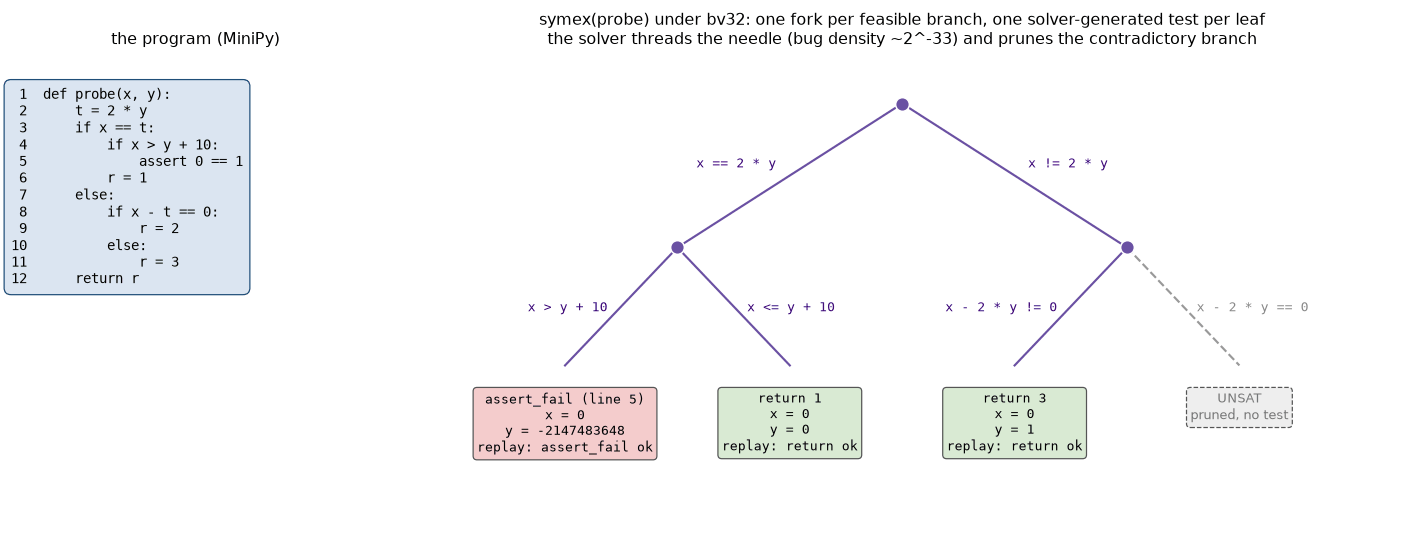

the failing leaf's input {'x': 0, 'y': -2147483648} replays as ('assert_fail', 5):
x == 2 * y holds there only because 2 * y wraps around under bv32.


In [57]:
def _s5_trie(paths):
    '''The symbolic execution tree, rebuilt from the paths' conditions (shared prefixes = shared tree nodes),
    with the solver-pruned branches from paths.stats['infeasible'] as UNSAT leaves.'''
    root = dict(kids={}, leaf=None)
    for p in paths:
        node = root
        for lab in p['pc']:
            node = node['kids'].setdefault(lab, dict(kids={}, leaf=None))
        node['leaf'] = p
    for prefix in paths.stats['infeasible']:
        node = root
        for lab in prefix[:-1]:
            node = node['kids'][lab]
        node['kids'][prefix[-1]] = dict(kids={}, leaf='UNSAT')
    return root


def _s5_draw_tree(ax, paths, src, semantics):
    '''Draw the tree: internal nodes are forks, edges carry the branch condition over the INPUTS (the symbolic
    store already substituted), leaves show the generated input and its concrete replay.'''
    root = _s5_trie(paths)
    pos, leaves = {}, []

    def layout(node, depth):
        if not node['kids']:
            leaves.append(node)
            pos[id(node)] = (len(leaves) - 1, -depth)
        else:
            xs = [layout(k, depth + 1) for k in node['kids'].values()]
            pos[id(node)] = (sum(xs) / len(xs), -depth)
        return pos[id(node)][0]
    layout(root, 0)
    box = dict(boxstyle="round,pad=0.3", ec="#555555", lw=0.8)

    def draw(node):
        x0, y0 = pos[id(node)]
        for lab, kid in node['kids'].items():
            x1, y1 = pos[id(kid)]
            dead = kid['leaf'] == 'UNSAT'
            ax.plot([x0, x1], [y0, y1 + (0.18 if not kid['kids'] else 0)], color="#999999" if dead else "#6a51a3",
                    lw=1.4, ls="--" if dead else "-", zorder=1)
            ax.text((x0 + x1) / 2 + (0.06 if x1 >= x0 else -0.06), (y0 + y1) / 2 + 0.08, lab, fontsize=8.5,
                    family="monospace", ha="left" if x1 >= x0 else "right", va="center",
                    color="#888888" if dead else "#3f007d",
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9), zorder=3)
            draw(kid)
        if node['kids']:
            ax.plot([x0], [y0], "o", ms=9, color="#6a51a3", mec="white", zorder=4)
        elif node['leaf'] == 'UNSAT':
            ax.text(x0, y0, "UNSAT\npruned, no test", ha="center", va="top", fontsize=8.5, color="#777777",
                    bbox=dict(box, fc="#eeeeee", ls="--"), zorder=4)
        else:
            p = node['leaf']
            replay = run_minipy(src, p['inputs'], semantics)
            ok = replay == (p['outcome'], p['value'])
            bug = p['outcome'] != 'return'
            what = f"{p['outcome']} (line {p['value']})" if bug else f"return {p['value']}"
            args = "\n".join(f"{k} = {v}" for k, v in p['inputs'].items())
            ax.text(x0, y0, f"{what}\n{args}\nreplay: {replay[0]} {'ok' if ok else 'MISMATCH'}", ha="center",
                    va="top", fontsize=8.5, family="monospace", bbox=dict(box, fc="#f4cccc" if bug else "#d9ead3"),
                    zorder=4)
    draw(root)
    depth = max(-y for _, y in pos.values())
    ax.set_xlim(-0.75, len(leaves) - 0.25)
    ax.set_ylim(-depth - 0.95, 0.35)
    ax.set_axis_off()


def _s5_draw_probe(P):
    '''The probe's source next to its symbolic execution tree.'''
    fig, (axc, ax1) = plt.subplots(1, 2, figsize=(13, 5.0), gridspec_kw=dict(width_ratios=[0.62, 1.7]))
    code = textwrap.dedent(_s5_PROBE_SRC).strip("\n").split("\n")
    axc.text(0.0, 0.93, "\n".join(f"{i + 1:2d}  {line}" for i, line in enumerate(code)), family="monospace",
             fontsize=9, va="top", transform=axc.transAxes,
             bbox=dict(boxstyle="round,pad=0.5", fc="#dbe5f1", ec="#1f4e79", lw=0.8))
    axc.set_title("the program (MiniPy)", fontsize=10.5)
    axc.set_axis_off()
    _s5_draw_tree(ax1, P, _s5_PROBE_SRC, 'bv32')
    ax1.set_title("symex(probe) under bv32: one fork per feasible branch, one solver-generated test per leaf\n"
                  "the solver threads the needle (bug density ~2^-33) and prunes the contradictory branch",
                  fontsize=10.5)
    plt.tight_layout()
    plt.show()


if HAVE_Z3:
    _s5_draw_probe(_s5_P_PROBE)
    _s5_bug = next(p for p in _s5_P_PROBE if p['outcome'] != 'return')
    print(f"the failing leaf's input {_s5_bug['inputs']} replays as {run_minipy(_s5_PROBE_SRC, _s5_bug['inputs'])}:")
    print("x == 2 * y holds there only because 2 * y wraps around under bv32.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the tree.")

The next cell runs the running examples under three semantics, replays every generated input, and checks
completeness against exhaustive enumeration at 8 bits. It also counts the probe's failing inputs at several
widths, to check the $2^{w-1} - 1$ count behind the density above.

In [58]:
_s5_DENSITY_WIDTHS = (8, 12, 16, 20)


def _s5_running_examples():
    '''abs32 and the two midpoints under 'int', 'int+ovf' and 'bv32': paths, failing inputs, replays.'''
    rows, replayed, total = [], 0, 0
    for src in (ABS_SRC, MIDPOINT_BUGGY_SRC, MIDPOINT_FIXED_SRC):
        for sem in ('int', 'int+ovf', 'bv32'):
            P = symex(src, sem)
            ok = sum(run_minipy(src, p['inputs'], sem) == (p['outcome'], p['value']) for p in P)
            replayed, total = replayed + ok, total + len(P)
            bugs = [f"{p['outcome']} at {p['inputs']}" for p in P if p['outcome'] != 'return']
            rows.append([minipy_info(src)['name'], sem, len(P), P.stats['queries'], "; ".join(bugs) or "-",
                         f"{ok}/{len(P)}", P.stats['complete']])
    show_table(["function", "semantics", "paths", "queries", "failing paths (canonical input)", "replayed",
                "complete"], rows)
    print(f"{replayed}/{total} generated inputs reproduce their path's outcome under run_minipy.")
    return replayed == total


def _s5_brute_outcomes(src, semantics='bv8'):
    '''Every outcome run_minipy produces over ALL inputs of a scalar-parameter function at 8 bits, counted.'''
    kinds = Counter()
    for args in itertools.product(range(-128, 128), repeat=len(minipy_info(src)['params'])):
        o, v = run_minipy(src, args, semantics)
        if o != 'requires_false':
            kinds[(o, v if o not in ('return', 'ensures_fail') else None)] += 1
    return kinds


def _s5_completeness_check():
    '''For complete explorations, symex must find exactly the outcome kinds that exhaustive enumeration finds.'''
    rows, probe_fails = [], None
    for src in (ABS_SRC, MIDPOINT_BUGGY_SRC, MIDPOINT_FIXED_SRC, _s5_PROBE_SRC):
        P = symex(src, 'bv8')
        found = {(p['outcome'], p['value'] if p['outcome'] not in ('return', 'ensures_fail') else None) for p in P}
        truth = _s5_brute_outcomes(src)
        if src is _s5_PROBE_SRC:
            probe_fails = sum(n for (o, _), n in truth.items() if o == 'assert_fail')
        rows.append([minipy_info(src)['name'], 256 ** len(minipy_info(src)['params']), len(P), P.stats['complete'],
                     sorted({o for o, _ in truth}), found == set(truth)])
    show_table(["function (bv8)", "inputs enumerated", "symex paths", "complete", "outcome kinds (exhaustive)",
                "symex finds exactly these"], rows)
    return all(r[-1] for r in rows), probe_fails


def _s5_probe_density(widths=_s5_DENSITY_WIDTHS):
    '''Failing inputs of probe at width w, over all 2^(2w) inputs: x is forced to wrap(2y), so count the y with
    wrap(2y) > wrap(y + 10) (vectorized, every y).'''
    counts = {}
    for w in widths:
        m, h = 2 ** w, 2 ** (w - 1)
        y = np.arange(-h, h, dtype=np.int64)
        counts[w] = int(np.count_nonzero((2 * y + h) % m - h > (y + 10 + h) % m - h))
    return counts


if HAVE_Z3:
    _s5_ok_replay = _s5_running_examples()
    _s5_ok_complete, _s5_probe_fails8 = _s5_completeness_check()
    _s5_counts = _s5_probe_density()
    _s5_law = all(n == 2 ** (w - 1) - 1 for w, n in _s5_counts.items()) and _s5_counts[8] == _s5_probe_fails8
    _s5_p32 = (2 ** 31 - 1) / 2 ** 64
    print(f"every input replays: {_s5_ok_replay}; every reachable outcome found at 8 bits: {_s5_ok_complete}.")
    print(f"probe's failing inputs at width w: {_s5_counts} (run_minipy, exhaustive at bv8: {_s5_probe_fails8}); "
          f"2^(w-1) - 1 at every width: {_s5_law}.")
    print(f"So at 32 bits p = (2^31 - 1)/2^64 = 2^{math.log2(_s5_p32):.2f}: random testing needs "
          f"{tests_needed(_s5_p32):.2g} runs for 99% detection, symex needed {_s5_P_PROBE.stats['queries']} queries.")
    print("A few paths do what §1 needed all 2^32 abs32 inputs for, and what no feasible number of the 2^64")
    print("midpoint inputs could do: each path is one class of inputs, and the solver picks a representative.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the running examples.")

function        semantics  paths  queries  failing paths (canonical input)              replayed  complete
----------------------------------------------------------------------------------------------------------
abs32           int        2      7        -                                            2/2       True    
abs32           int+ovf    3      9        overflow at {'x': -2147483648}               3/3       True    
abs32           bv32       3      8        ensures_fail at {'x': -2147483648}           3/3       True    
midpoint_buggy  int        1      3        -                                            1/1       True    
midpoint_buggy  int+ovf    2      5        overflow at {'lo': 1, 'hi': 2147483647}      2/2       True    
midpoint_buggy  bv32       2      4        ensures_fail at {'lo': 1, 'hi': 2147483647}  2/2       True    
midpoint_fixed  int        1      3        -                                            1/1       True    
midpoint_fixed  int+ovf    1      5  

function (bv8)  inputs enumerated  symex paths  complete  outcome kinds (exhaustive)  symex finds exactly these
---------------------------------------------------------------------------------------------------------------
abs32           256                3            True      ['ensures_fail', 'return']  True                     
midpoint_buggy  65536              2            True      ['ensures_fail', 'return']  True                     
midpoint_fixed  65536              1            True      ['return']                  True                     
probe           65536              3            True      ['assert_fail', 'return']   True                     
every input replays: True; every reachable outcome found at 8 bits: True.
probe's failing inputs at width w: {8: 127, 12: 2047, 16: 32767, 20: 524287} (run_minipy, exhaustive at bv8: 127); 2^(w-1) - 1 at every width: True.
So at 32 bits p = (2^31 - 1)/2^64 = 2^-33.00: random testing needs 4e+10 runs for 99% detection, symex ne

`probe` has three feasible paths and one branch pruned as UNSAT. The failing path's canonical input is `x = 0`,
`y = INT32_MIN`: it satisfies `x == 2 * y` only because `2 * y` wraps to 0, and its replay reproduces the
`assert_fail`. The solver reasons about the machine's arithmetic, not the one you had in mind. The semantics
shapes the tree itself. `abs32` has two paths over $\mathbb{Z}$ and three under bv32 or int+ovf, where the check
`-x >= 0` (or `-x in int32`) forks and its failing side holds exactly one input, `INT32_MIN`. `midpoint_buggy`
fails under int+ovf and bv32 at the same canonical input, `lo = 1, hi = INT32_MAX`: the smallest `lo` for which
`lo + hi` can leave int32. `midpoint_fixed` has one path, no satisfiable failing side and a complete exploration,
so that is a proof under its precondition. The 8-bit table confirms completeness, and the count confirms the
probe's density law at four widths. Two things limit the method: a loop with a symbolic bound has unboundedly
many paths (`symex` truncates a path after `_s5_MAX_ITERS` iterations of one loop, and the run is then not
complete), and even loop-free code has exponentially many paths (§5.4).

### 5.3 Bounded model checking: unroll, merge, ask once

BMC was invented for hardware (Biere, Cimatti, Clarke & Zhu, *Symbolic Model Checking without BDDs*, TACAS 1999)
after BDD-based model checking stopped scaling. It asks a bounded question: can a bad state be reached within
$k$ steps? Unroll the transition relation $k$ times and ask one SAT query:

$$I(s_0) \wedge T(s_0, s_1) \wedge \dots \wedge T(s_{k-1}, s_k) \wedge \big(B(s_0) \vee \dots \vee B(s_k)\big).$$

A satisfying assignment *is* a counterexample trace, and CDCL made such queries practical: Fichte et al.'s
history of SAT (CACM 2023) reports CDCL solving BMC benchmarks "up to two orders of magnitude faster than any
other approach". CBMC (Clarke, Kroening & Lerda, TACAS 2004) does the same for C: unwind every loop $k$ times
(`while c: body` becomes $k$ nested copies of `if c: body`), convert to single-assignment form, and join the two
sides of every `if` with an If-term (a φ-function). The join is the difference from symbolic execution: BMC
**merges** paths, so the whole bounded program is one formula; symex keeps them apart.

After the $k$-th copy the loop may still want to run, and what BMC does there decides what its answer means. The
**unwinding assumption** (`assume not c`) silently drops the longer executions. An UNSAT answer then means "no
bug in any execution with at most $k$ iterations", and calling that "safe" is the classic mistake. The
**unwinding assertion** asks a second question: can any input reach the cut with `c` still true? If not, no
execution is longer than the unrolling, the unrolled program *is* the program, and the bounded answer is a
proof. Since version 6.0, CBMC inserts these unwinding assertions by default (`--no-unwinding-assertions` turns
them off; [CBMC man page](https://raw.githubusercontent.com/diffblue/cbmc/develop/doc/man/cbmc.1) and 6.0.0
changelog). Inputs are bounded too: a symbolic array has at most `_s5_MAX_LEN = 4` elements, like a fixed-size
KLEE buffer or a Kani harness. So `bmc` also asks the input-size analogue of the unwinding assertion: does an
input with a longer array satisfy the precondition? And a precondition that no input satisfies makes every claim
true, so it gets its own verdict. `bmc(src, k, semantics='bv32')` therefore returns one of

- `('counterexample', depth, inputs)`: the *shallowest* depth, found by binary search over the bound (violations
  are monotone in $k$: a failing execution that fits in $k$ iterations also fits in $k + 1$), with the canonical
  failing input;
- `('proved', k)`: no failure, and both the unwinding assertion and the input-size assertion hold;
- `('no_bug_up_to_k', k)`: no failure within the bounds, and nothing more: some in-scope input runs a loop longer
  than $k$ or has a longer array;
- `('vacuous', k)` when no input satisfies the precondition (or passes the `assume`s and reaches a `return`),
  and `('unknown', k)` on a solver timeout.

The result is a tuple whose `.stats` say how many formulas were solved. The first cell builds the encoding (the
unroller) and shows the probe as one formula; the second runs `bmc` on six small programs that between them
produce every verdict but `'unknown'`.

In [59]:
_s5_BMC_TIMEOUT_MS = 5000


def _s5_merge(c, s1, s2):
    '''Join two stores after an if: x -> If(c, s1[x], s2[x]) where they differ (this is the merging that
    symbolic execution does NOT do). A fixed key order, so the same Z3 terms are built on every run.'''
    out = {}
    for x in list(s1) + [x for x in s2 if x not in s1]:
        a, b = s1.get(x), s2.get(x)
        out[x] = a if b is None or a is b else b if a is None else z3.If(c, a, b)
    return out


class _s5_Unroller:
    '''Bounded model checking's encoding of a MiniPy function: ONE formula for all paths at once.
    Every loop is unwound `bound` times; stores are merged at every join (If-terms); `active` is the condition
    "execution reaches this point" over the inputs. Each run-time check contributes one `bad` condition (this
    check is the first to fail); `cut` collects the conditions under which some loop wants iteration bound + 1:
    the unwinding assertion. Paths that hit the cut are excluded from `bad` (the unwinding ASSUMPTION).'''

    def __init__(self, fn, semantics, bound, env):
        self.sem, self.bound, self.env = semantics, bound, env
        self.bad, self.cut, self.returns = [], [], []
        specs, self.body = _s5_annotations(fn.body, ('requires', 'ensures'))
        self.requires = [e for name, e, _ in specs if name == 'requires']
        self.ensures = [e for name, e, _ in specs if name == 'ensures']

    def check(self, active, guard, cond, outcome, line):
        g = z3.And(active, guard)
        self.bad.append((z3.And(g, z3.Not(cond)), outcome, line))
        return z3.And(active, z3.Implies(guard, cond))           # the rest runs only if the check passed

    def expr_checks(self, e, store, active, spec):
        for guard, cond, outcome, line in _s5_checks(e, store, self.sem, spec):
            active = self.check(active, guard, cond, outcome, line)
        return active

    def assertion(self, e, store, active, outcome, line):
        active = self.expr_checks(e, store, active, True)
        return self.check(active, z3.BoolVal(True), expr_to_z3(e, store, self.sem), outcome, line)

    def run(self):
        active = z3.BoolVal(True)
        for r in self.requires:
            active = self.expr_checks(r, self.env, active, True)
            active = z3.And(active, expr_to_z3(r, self.env, self.sem))
        self.block(self.body, dict(self.env), active)
        if self.returns:                                          # result = the value of the return taken
            result = self.returns[-1][1]
            for g, v in reversed(self.returns[:-1]):
                result = z3.If(g, v, result)
            done = z3.Or(*[g for g, _ in self.returns])
            post = {**self.env, 'result': result}
            for q in self.ensures:
                done = self.assertion(q, post, done, 'ensures_fail', q.lineno)
        return self

    def block(self, stmts, store, active):
        for st in stmts:
            store, active = self.stmt(st, store, active)
        return store, active

    def stmt(self, st, store, active):
        tr = lambda e: expr_to_z3(e, store, self.sem)
        if isinstance(st, ast.Assign):
            active = self.expr_checks(st.value, store, active, False)
            return {**store, st.targets[0].id: tr(st.value)}, active
        if isinstance(st, ast.If):
            active = self.expr_checks(st.test, store, active, False)
            c = tr(st.test)
            s1, a1 = self.block(st.body, store, z3.And(active, c))
            s2, a2 = self.block(st.orelse, store, z3.And(active, z3.Not(c)))
            return _s5_merge(c, s1, s2), z3.Or(a1, a2)
        if isinstance(st, ast.While):
            annotations, body = _s5_annotations(st.body, ('invariant', 'decreases'))
            exits, previous = [], None
            for it in range(self.bound + 1):
                for name, e, line in annotations:
                    if name == 'invariant':
                        active = self.assertion(e, store, active, 'assert_fail', line)
                for name, e, line in annotations:                 # strictly smaller after EVERY body run,
                    if name == 'decreases' and previous is not None:   # the last one included
                        active = self.expr_checks(e, store, active, True)
                        active = self.check(active, z3.BoolVal(True), tr(e) < previous, 'assert_fail', line)
                active = self.expr_checks(st.test, store, active, False)
                c = tr(st.test)
                exits.append((z3.And(active, z3.Not(c)), store))
                if it == self.bound:                              # wants one more iteration than unrolled
                    self.cut.append(z3.And(active, c))
                    break
                active = z3.And(active, c)
                for name, e, line in annotations:
                    if name == 'decreases':                       # bounded below whenever the body runs
                        active = self.expr_checks(e, store, active, True)
                        v = tr(e)
                        active, previous = self.check(active, z3.BoolVal(True), v >= 0, 'assert_fail', line), v
                store, active = self.block(body, store, active)
            store, active = exits[-1][1], exits[-1][0]
            for cond, s in reversed(exits[:-1]):                  # the loop is left at exactly one iteration
                store, active = _s5_merge(cond, s, store), z3.Or(cond, active)
            return store, active
        if isinstance(st, ast.Assert):
            return store, self.assertion(st.test, store, active, 'assert_fail', st.lineno)
        if isinstance(st, ast.Expr):                              # assume(e)
            active = self.expr_checks(st.value.args[0], store, active, True)
            return store, z3.And(active, tr(st.value.args[0]))
        active = self.expr_checks(st.value, store, active, False)  # return e
        self.returns.append((active, tr(st.value)))
        return store, z3.BoolVal(False)


if HAVE_Z3:
    _s5_fn = parse_minipy(_s5_PROBE_SRC, 'bv32')
    _s5_env, _ = _s5_inputs(minipy_info(_s5_fn), 'bv32')
    _s5_u = _s5_Unroller(_s5_fn, 'bv32', 0, _s5_env).run()
    print(f"probe as ONE formula: {len(_s5_u.bad)} check, failing when {_s5_label(z3.simplify(_s5_u.bad[0][0]))}")
    print(f"merged return value: r = {_s5_label(_s5_u.returns[-1][1])}")
    print("Symex walked three paths to say the same; the If-terms fold them into one term the solver sees at once.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the unroller demo.")

probe as ONE formula: 1 check, failing when x == 2 * y and x > 10 + y
merged return value: r = 1 if x == 2 * y else (2 if x - 2 * y == 0 else 3)
Symex walked three paths to say the same; the If-terms fold them into one term the solver sees at once.


`bmc` asks the solver for a model of the disjunction of the `bad` conditions and, if there is one,
binary-searches the shallowest depth. If there is none, it asks the remaining questions in order: is the
precondition satisfiable at all, does any input reach the cut (the unwinding assertion), does any input reach a
`return`, and does an in-scope input lie beyond the length cap. The table runs it on six small programs.

In [60]:
def _s5_bmc_at(fn, semantics, d, env, dom):
    '''One BMC query at unwinding bound d -> (z3 result, model or None, the solver, the unroller).'''
    u = _s5_Unroller(fn, semantics, d, env).run()
    s = z3.Solver()
    s.set(timeout=_s5_BMC_TIMEOUT_MS)
    s.add(*dom)
    s.add(z3.Or(*[b for b, _, _ in u.bad]) if u.bad else z3.BoolVal(False))
    r = s.check()
    return r, (s.model() if r == z3.sat else None), s, u


class _s5_Verdict(tuple):
    '''What bmc returns: a plain tuple (it compares equal to one), plus a .stats dict on how it was reached.'''

    def __new__(cls, items, stats):
        self = super().__new__(cls, items)
        self.stats = stats
        return self


def bmc(src, k, semantics='bv32'):
    '''Bounded model checking of a MiniPy function, CBMC-style: unwind every loop k times into ONE formula and
    ask the solver for an input that makes any check fail. Returns a tuple (with .stats):
      ('counterexample', depth, inputs)  the SHALLOWEST unwinding depth <= k with a failing input (binary search;
                                          violations are monotone in the bound) and the canonical failing input,
                                          replayable by run_minipy. If a solver timeout interrupts the search, depth
                                          is the shallowest one confirmed and .stats['depth_exact'] is False.
      ('no_bug_up_to_k', k)               no failure within the bounds, and nothing more: some in-scope input runs a
                                          loop more than k times or has an array longer than _s5_MAX_LEN (or the
                                          solver could not rule that out)
      ('proved', k)                       no failure, the unwinding assertion holds (no input needs more than k
                                          iterations) and so does the input-size assertion (no in-scope input has a
                                          longer array): the bounded program IS the program
      ('vacuous', k)                      no input satisfies the precondition, or none passes the assume()s and
                                          reaches a return: there is nothing to prove
      ('unknown', k)                      a solver timeout (_s5_BMC_TIMEOUT_MS): neither a proof nor a bug
    .stats: formulas (BMC formulas solved), depth_exact, vacuous, beyond_max_len, canonical_queries, canonical_s.'''
    fn = parse_minipy(src, semantics)
    info = minipy_info(fn)
    env, dom = _s5_inputs(info, semantics)
    w = sem_width(semantics)
    st = dict(formulas=1, depth_exact=True, vacuous=None, beyond_max_len=None, canonical_queries=0, canonical_s=0.0)
    r, model, s, u = _s5_bmc_at(fn, semantics, k, env, dom)
    if r == z3.unknown:
        return _s5_Verdict(('unknown', k), st)
    if r == z3.sat:
        lo, hi, best = 0, k, (model, s)
        while lo < hi:                                            # smallest depth that still has a bug
            mid = (lo + hi) // 2
            r_mid, m_mid, s_mid, _ = _s5_bmc_at(fn, semantics, mid, env, dom)
            st['formulas'] += 1
            if r_mid == z3.sat:
                hi, best = mid, (m_mid, s_mid)
            else:                                                 # unsat, or a timeout: no bug CONFIRMED there
                st['depth_exact'] &= r_mid == z3.unsat
                lo = mid + 1
        (canonical, st['canonical_queries']), st['canonical_s'] = timed(_s5_canonical_model, best[1], info, env, w)
        return _s5_Verdict(('counterexample', hi, _s5_decode(canonical or best[0], info, env, w)), st)
    satisfiable, beyond = _s5_scope(info, semantics, env, u.requires, _s5_BMC_TIMEOUT_MS)
    st['vacuous'] = None if satisfiable is None else not satisfiable
    st['beyond_max_len'] = beyond
    if satisfiable is None:
        return _s5_Verdict(('unknown', k), st)
    if not satisfiable:
        return _s5_Verdict(('vacuous', k), st)

    def holds(conds):                                             # can some capped input reach one of conds?
        s = z3.Solver()
        s.set(timeout=_s5_BMC_TIMEOUT_MS)
        s.add(*dom, z3.Or(*conds) if conds else z3.BoolVal(False))
        st['formulas'] += 1
        return s.check()
    cut = holds(u.cut)                                            # the unwinding assertion
    if cut != z3.unsat:
        return _s5_Verdict(('no_bug_up_to_k', k), st)
    if holds([g for g, _ in u.returns]) == z3.unsat:              # no capped input reaches a return at all
        st['vacuous'] = beyond is False
        return _s5_Verdict(('vacuous' if beyond is False else 'no_bug_up_to_k', k), st)
    return _s5_Verdict(('proved' if beyond is False else 'no_bug_up_to_k', k), st)


_s5_VACUOUS_SRC = '''
def never(x):
    requires(x > 5 and x < 3)
    assert x == 0
    return x
'''

_s5_FIFTH_SRC = '''
def fifth(a: list):
    requires(len(a) >= 5)
    assert a[4] != 7
    return 0
'''

_s5_LAST_SRC = '''
def last(a: list):
    requires(1 <= len(a) and len(a) <= 4)
    ensures(result == a[len(a) - 1])
    return a[len(a) - 1]
'''


def _s5_bmc_examples(k=0, semantics='bv32'):
    '''bmc on six loop-free programs: two bugs, two proofs, a vacuous precondition, an input-size bound.'''
    rows = []
    for src in (ABS_SRC, MIDPOINT_BUGGY_SRC, MIDPOINT_FIXED_SRC, _s5_VACUOUS_SRC, _s5_FIFTH_SRC, _s5_LAST_SRC):
        r = bmc(src, k, semantics)
        cex = r[0] == 'counterexample'
        beyond = r.stats['beyond_max_len']
        rows.append([minipy_info(src)['name'], r[0], r[2] if cex else "-",
                     run_minipy(src, r[2], semantics) if cex else "-", r.stats['formulas'],
                     "-" if beyond is None else beyond])
    show_table(["program (bv32, k = 0)", "bmc verdict", "counterexample", "run_minipy replay", "formulas solved",
                "in-scope input beyond len 4"], rows)
    return rows


if HAVE_Z3:
    _s5_bmc_rows = _s5_bmc_examples()
    print(f"fifth's bug needs len(a) = 5: run_minipy(fifth, [0, 0, 0, 0, 7]) -> "
          f"{run_minipy(_s5_FIFTH_SRC, ([0, 0, 0, 0, 7],), 'bv32')}.")
    print("Its capped domain holds no in-scope input, so bmc may only say no_bug_up_to_k; last's precondition")
    print("keeps len(a) <= 4, so its proof stands.")
    print("'proved' appears only where both the unwinding and the input-size assertion hold, and a contradictory")
    print("precondition is 'vacuous', never 'proved'.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping bounded model checking.")

program (bv32, k = 0)  bmc verdict     counterexample               run_minipy replay              formulas solved  in-scope input beyond len 4
-----------------------------------------------------------------------------------------------------------------------------------------------
abs32                  counterexample  {'x': -2147483648}           ('ensures_fail', -2147483648)  1                -                          
midpoint_buggy         counterexample  {'lo': 1, 'hi': 2147483647}  ('ensures_fail', -1073741824)  1                -                          
midpoint_fixed         proved          -                            -                              3                False                      
never                  vacuous         -                            -                              1                False                      
fifth                  no_bug_up_to_k  -                            -                              3                True                

**Registered prediction.** `triangle(n)` sums $1 + 2 + \dots + n$, with `requires(0 <= n <= 20)` and
`ensures(result >= 0)`. Under bv8 the sum first exceeds 127 at $n = 16$ ($16 \cdot 17/2 = 136$). Prediction: at
$k = 10$, `bmc` answers `no_bug_up_to_k`, never `proved`, because inputs with $n > 10$ reach the cut, and an
assume-only BMC says "safe". The shallowest counterexample has depth 16 and input $n = 16$, the only input that
runs exactly 16 iterations.

In [61]:
_s5_TRIANGLE_SRC = '''
def triangle(n):
    requires(0 <= n and n <= {N})
    ensures(result >= 0)
    s = 0
    i = 0
    while i < n:
        i = i + 1
        s = s + i
    return s
'''


def _s5_bmc_assume_only(src, k, semantics):
    '''The classic mistake: unwind k times, ASSUME the loop exits, and call an UNSAT answer "safe".'''
    fn = parse_minipy(src, semantics)
    env, dom = _s5_inputs(minipy_info(fn), semantics)
    r, _, _, _ = _s5_bmc_at(fn, semantics, k, env, dom)
    return 'counterexample' if r == z3.sat else 'safe'


def _s5_triangle_prediction():
    '''Score the registered prediction on triangle().'''
    tri20 = _s5_TRIANGLE_SRC.replace('{N}', '20')
    r10, naive10, r25 = bmc(tri20, 10, 'bv8'), _s5_bmc_assume_only(tri20, 10, 'bv8'), bmc(tri20, 25, 'bv8')
    replay = run_minipy(tri20, r25[2], 'bv8')
    right = (r10[0], naive10, r25[1], r25[2]) == ('no_bug_up_to_k', 'safe', 16, {'n': 16})
    print(f"bmc(triangle, k=10, bv8)           -> {r10}")
    print(f"assume-only BMC, k=10              -> {naive10!r}   <- wrong: the bug needs 16 iterations")
    print(f"bmc(triangle, k=25, bv8)           -> {r25}; replay: {replay}; {r25.stats['formulas']} formulas "
          f"(1 at k = 25, then the binary search)")
    print(f"registered prediction: bmc reports no_bug_up_to_k (never 'proved') at k = 10, the assume-only variant "
          f"says 'safe', and the shallowest counterexample is n = 16 at depth 16 | measured: {r10[0]}, "
          f"{naive10!r}, depth {r25[1]} with {r25[2]} | verdict: "
          f"{'RIGHT' if right else 'WRONG'}"
          f" -- without the unwinding assertion, 'no bug in k steps' is silently read as 'no bug'")


if HAVE_Z3:
    _s5_triangle_prediction()
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the triangle prediction.")

bmc(triangle, k=10, bv8)           -> ('no_bug_up_to_k', 10)
assume-only BMC, k=10              -> 'safe'   <- wrong: the bug needs 16 iterations
bmc(triangle, k=25, bv8)           -> ('counterexample', 16, {'n': 16}); replay: ('ensures_fail', -120); 6 formulas (1 at k = 25, then the binary search)
registered prediction: bmc reports no_bug_up_to_k (never 'proved') at k = 10, the assume-only variant says 'safe', and the shallowest counterexample is n = 16 at depth 16 | measured: no_bug_up_to_k, 'safe', depth 16 with {'n': 16} | verdict: RIGHT -- without the unwinding assertion, 'no bug in k steps' is silently read as 'no bug'


**A proof without loop bounds: the completeness threshold.** A circuit has no loop counter and runs forever, so
the unwinding assertion never holds. Biere et al. showed that bounded search is still complete for reachability
once $k$ reaches the **diameter** $d$: the longest shortest path from an initial state to a reachable state.
Clarke, Kroening, Ouaknine & Strichman (*Completeness and Complexity of Bounded Model Checking*, VMCAI 2004)
named the least such bound the **completeness threshold**. Computing $d$ needs a quantifier alternation. The
**recurrence diameter** $rd \ge d$, the length of the longest *loop-free* execution, needs only SAT (is there an
execution of $n$ steps through $n + 1$ pairwise distinct states?), and Kroening & Strichman (VMCAI 2003) made
that check efficient. The cell computes $rd$ for four small counters, cross-checks it by explicit search, lets
BMC prove the property at $k = rd$, and draws what `bmc` can say about each example as $k$ grows.

transition system      states  reachable  diameter (BFS)  recurrence diam. (SAT)  longest simple path (DFS)  agree  BMC at k = rd  rd time (s)
----------------------------------------------------------------------------------------------------------------------------------------------
mod-6 counter + reset  8       6          5               5                       5                          True   proved         0.00       
mod-10 counter + load  16      10         1               9                       9                          True   proved         0.17       
4-bit counter + reset  16      16         15              15                      15                         True   proved         0.01       
6-bit counter + reset  64      64         63              63                      63                         True   proved         0.18       


  abs32  [bv32]                                first counterexample at k = 0, first proof at k = -
  midpoint_fixed  [bv32]                       first counterexample at k = -, first proof at k = 0
  triangle, n <= 20  [bv8]                     first counterexample at k = 16, first proof at k = -
  triangle, n <= 15  [bv8]                     first counterexample at k = -, first proof at k = 15
  triangle, n <= 20  [int+ovf]                 first counterexample at k = -, first proof at k = 20
  TS: mod-6 counter + reset (d=5, rd=5)        first counterexample at k = -, first proof at k = 5
  TS: mod-10 counter + load (d=1, rd=9)        first counterexample at k = -, first proof at k = 9


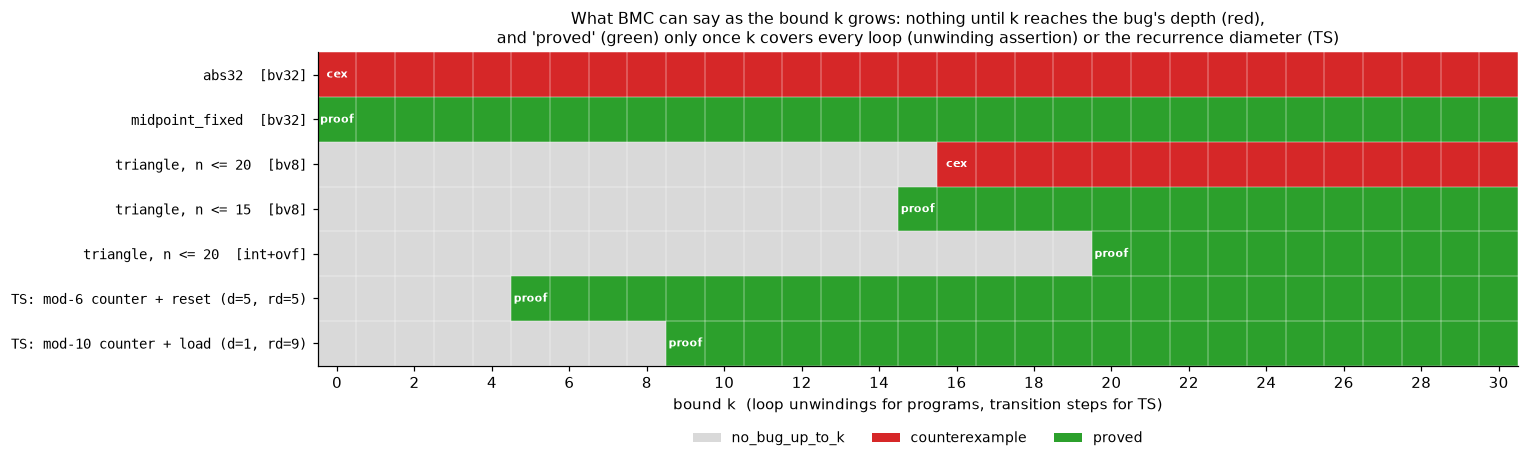

Grey is the honest answer for most of the plane: no bug up to k, which is a statement about k, not about
the program. A proof needs k >= the program's maximal iteration count or the system's recurrence diameter.


In [62]:
# ---- The completeness threshold on finite transition systems (hardware-style: no loop counter) ----------
def _s5_counter_system(bits, modulus, load=False):
    '''A `bits`-bit register counting 0, 1, ..., modulus-1, 0, ... Each step a free input may reset it to 0 or,
    with load=True, load any value < modulus. The property: the register never holds a value >= modulus.'''
    def nxt(s):
        return z3.If(s == modulus - 1, z3.BitVecVal(0, bits), s + 1)

    def trans(s, t, step):
        r = z3.Bool(f"r{step}")
        if load:
            v = z3.BitVec(f"v{step}", bits)
            return z3.And(z3.ULT(v, modulus), t == z3.If(r, v, nxt(s)))
        return t == z3.If(r, z3.BitVecVal(0, bits), nxt(s))

    def successors(s):                                # the same system, explicitly, for the cross-check
        return {(s + 1) % modulus} | (set(range(modulus)) if load else {0})
    bad = (lambda s: z3.UGE(s, modulus)) if modulus < 2 ** bits else (lambda s: z3.BoolVal(False))
    return dict(bits=bits, init=lambda s: s == 0, trans=trans, bad=bad, successors=successors)


def _s5_unrolled_ts(system, n):
    '''States s0..sn of one execution of length n (the BMC unrolling of a transition system).'''
    S = [z3.BitVec(f"s{i}", system['bits']) for i in range(n + 1)]
    return S, [system['init'](S[0])] + [system['trans'](S[i], S[i + 1], i) for i in range(n)]


def _s5_recurrence_diameter(system, n_max=80):
    '''Length of the longest LOOP-FREE execution from an initial state: the smallest n for which no execution of
    n steps visits n + 1 distinct states, minus one (one SAT query per n; Distinct is pairwise disequality).'''
    for n in range(n_max + 1):
        S, cons = _s5_unrolled_ts(system, n)
        s = z3.Solver()
        s.set(timeout=_s5_BMC_TIMEOUT_MS)
        s.add(*cons, z3.Distinct(*S) if n else z3.BoolVal(True))
        r = s.check()
        if r == z3.unsat:
            return n - 1
        if r == z3.unknown:                       # a timeout is not an answer: rd unknown
            return None
    return None


def _s5_bmc_ts(system, k, rd):
    '''BMC of a transition system: is a bad state reachable in <= k steps? With the recurrence diameter rd known,
    k >= rd turns "no bug up to k" into a proof.'''
    S, cons = _s5_unrolled_ts(system, k)
    s = z3.Solver()
    s.set(timeout=_s5_BMC_TIMEOUT_MS)
    s.add(*cons, z3.Or(*[system['bad'](x) for x in S]))
    r = s.check()
    if r == z3.sat:
        return 'counterexample'
    if r == z3.unknown:                           # never 'proved' on a timeout
        return 'unknown'
    return 'proved' if rd is not None and k >= rd else 'no_bug_up_to_k'


def _s5_explicit_ts(system):
    '''Explicit-state cross-check: (reachable states, diameter by BFS, longest simple path by DFS).'''
    dist, frontier = {0: 0}, [0]
    while frontier:
        nxt = []
        for s in frontier:
            for t in system['successors'](s):
                if t not in dist:
                    dist[t] = dist[s] + 1
                    nxt.append(t)
        frontier = nxt

    @functools.lru_cache(maxsize=None)
    def longest(s, seen):                             # seen: bitmask of visited states (DP over subsets)
        return max([1 + longest(t, seen | (1 << t)) for t in system['successors'](s) if not seen >> t & 1] or [0])
    return len(dist), max(dist.values()), longest(0, 1)


_s5_STRIP_K = 30


def _s5_bmc_demo():
    '''The recurrence diameters, and the verdict strip for programs and transition systems.'''
    tri20, tri15 = _s5_TRIANGLE_SRC.replace('{N}', '20'), _s5_TRIANGLE_SRC.replace('{N}', '15')
    systems = {'mod-6 counter + reset': _s5_counter_system(3, 6),
               'mod-10 counter + load': _s5_counter_system(4, 10, load=True),
               '4-bit counter + reset': _s5_counter_system(4, 16),
               '6-bit counter + reset': _s5_counter_system(6, 64)}
    rows, rds, diams = [], {}, {}
    for name, system in systems.items():
        (rd, dt) = timed(_s5_recurrence_diameter, system)
        n_reach, diam, simple = _s5_explicit_ts(system)
        rds[name], diams[name] = rd, diam
        rows.append([name, 2 ** system['bits'], n_reach, diam, rd, simple, rd == simple,
                     _s5_bmc_ts(system, rd, rd) if rd is not None else 'unknown', f"{dt:.2f}"])
    show_table(["transition system", "states", "reachable", "diameter (BFS)", "recurrence diam. (SAT)",
                "longest simple path (DFS)", "agree", "BMC at k = rd", "rd time (s)"], rows)

    progs = [("abs32  [bv32]", ABS_SRC, 'bv32'), ("midpoint_fixed  [bv32]", MIDPOINT_FIXED_SRC, 'bv32'),
             ("triangle, n <= 20  [bv8]", tri20, 'bv8'), ("triangle, n <= 15  [bv8]", tri15, 'bv8'),
             ("triangle, n <= 20  [int+ovf]", tri20, 'int+ovf')]
    ks = list(range(_s5_STRIP_K + 1))
    grid, labels = [], []
    for label, src, sem in progs:
        grid.append([bmc(src, k, sem)[0] for k in ks])
        labels.append(label)
    for name in ('mod-6 counter + reset', 'mod-10 counter + load'):
        grid.append([_s5_bmc_ts(systems[name], k, rds[name]) for k in ks])
        labels.append(f"TS: {name} (d={diams[name]}, rd={rds[name]})")
    for label, row in zip(labels, grid):
        first = {v: ks[row.index(v)] for v in ('counterexample', 'proved') if v in row}
        print(f"  {label:44s} first counterexample at k = {first.get('counterexample', '-')}, "
              f"first proof at k = {first.get('proved', '-')}")
    _s5_draw_strip(grid, labels, ks)
    return grid


def _s5_draw_strip(grid, labels, ks):
    colors = {'no_bug_up_to_k': "#d9d9d9", 'counterexample': "#d62728", 'proved': "#2ca02c", 'unknown': "#ffbf00",
              'vacuous': "#9467bd"}
    code = {v: i for i, v in enumerate(colors)}
    from matplotlib.colors import ListedColormap
    from matplotlib.patches import Patch
    fig, ax = plt.subplots(figsize=(14, 4.4))
    ax.imshow([[code[v] for v in row] for row in grid], cmap=ListedColormap(list(colors.values())), vmin=-0.5,
              vmax=len(colors) - 0.5, aspect="auto")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, family="monospace", fontsize=9)
    ax.set_xticks(ks[::2])
    ax.set_xlabel("bound k  (loop unwindings for programs, transition steps for TS)")
    ax.set_xticks(np.arange(-0.5, len(ks)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(labels)), minor=True)
    ax.grid(which="minor", color="white", lw=1.2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="minor", length=0)
    for y, row in enumerate(grid):
        for v in ('counterexample', 'proved'):
            if v in row:
                x = row.index(v)
                ax.text(x, y, "cex" if v == 'counterexample' else "proof", ha="center", va="center", fontsize=7,
                        color="white", fontweight="bold")
    present = {v for row in grid for v in row}
    ax.legend(handles=[Patch(fc=c, label=v) for v, c in colors.items() if v in present], loc="upper center",
              bbox_to_anchor=(0.5, -0.17), ncol=4, fontsize=9, frameon=False)
    ax.set_title("What BMC can say as the bound k grows: nothing until k reaches the bug's depth (red),\n"
                 "and 'proved' (green) only once k covers every loop (unwinding assertion) or the recurrence "
                 "diameter (TS)", fontsize=10.5)
    plt.tight_layout()
    plt.show()


if HAVE_Z3:
    _s5_grid = _s5_bmc_demo()
    print("Grey is the honest answer for most of the plane: no bug up to k, which is a statement about k, not about")
    print("the program. A proof needs k >= the program's maximal iteration count or the system's recurrence diameter.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the completeness threshold.")

The prediction held, and the strip reads as one sentence per row. `abs32` and `midpoint_fixed` are loop-free, so
$k = 0$ already decides them. The triangle with $n \le 20$ under bv8 stays grey until $k = 16$ and is red from
then on. With $n \le 15$ the sum never overflows ($15 \cdot 16/2 = 120 \le 127$), and the row turns green at
$k = 15$, exactly its largest iteration count. Under int+ovf no sum up to $n = 20$ leaves int32, and the row
turns green at $k = 20$. The two transition systems turn green at their recurrence diameters. The table shows
why that threshold is pessimistic: the loadable mod-10 counter reaches every state in one step ($d = 1$), yet
BMC must unroll to $rd = 9$, and a $w$-bit counter has $rd = 2^w - 1$ (15 and 63 in the table). For a loop over
a 32-bit counter the threshold is in the billions. Unbounded software is therefore proved with an *inductive
invariant* (§6, §8), not with a deeper unrolling.

In production, Kani compiles Rust to CBMC's GOTO programs and checks them with CBMC. The SAT back end is CaDiCaL
by default and can be switched per harness with `#[kani::solver(...)]`
([Kani docs](https://model-checking.github.io/kani/reference/attributes.html); the repository pins CBMC 6.11.0 and
Kissat 4.0.1, one of the selectable solvers; §14.1). Kani checks panics, arithmetic overflow, undefined behaviour
and user assertions, and its answer is a proof, a counterexample, or "out of resources". A Kani harness bounds
inputs and loops exactly like `bmc`'s $k$ and `_s5_MAX_LEN`, and AWS runs such harnesses in Firecracker's CI
(§11.6).

### 5.4 Path explosion: what merging buys and what it costs

The cost model follows from the definitions. Symbolic execution pays per path, and $k$ sequential independent
branches have $2^k$ feasible paths; a loop of $n$ iterations with a branch inside has $2^n$. BMC pays per
formula. Merging keeps that formula linear in the size of the unrolled program, *provided* the solver stores it
as a DAG. After the $i$-th `if`, a merged variable is $s_i = \mathrm{If}(c_i, s_{i-1} + 1, s_{i-1})$, which
mentions $s_{i-1}$ twice. Spelled out as a tree, the term doubles with every `if`; shared as a DAG, it grows by
a constant. Two families of programs make this concrete, and both have $2^k$ syntactic paths. In `chain`, $k$
independent inputs each pass a check `if x_i > 0: s = s + 1`, so every path is feasible. In `ladder`, one input
is compared against $k$ increasing thresholds, so almost every syntactic path is contradictory.

Symbolic execution is forward, per-path strongest-postcondition reasoning without merging. Naive weakest
preconditions suffer the same blow-up backwards, because $wp(\texttt{if } c \texttt{ then } S_1 \texttt{ else }
S_2,\ Q)$ copies $Q$ into both branches; §6.6 plots that blow-up on these axes next to the passive (DSA) form of
Boogie and Dafny, the analogue of BMC's DAG.

**Registered prediction.** (a) `chain` explores exactly $2^k$ paths with about $3 \cdot 2^k$ solver queries (two
feasibility checks per fork, one model per leaf), and `ladder` explores $k + 1$ paths. (b) BMC's single formula
for `chain` grows by a constant number of DAG nodes per `if`, while the same formula written out as a tree
doubles per `if`.

k   syntactic paths  symex paths: chain / ladder  queries: chain / ladder  chain symex s  BMC formula (chain): DAG nodes  same, as a tree  BMC s
------------------------------------------------------------------------------------------------------------------------------------------------
1   2                2 / 2                        5 / 5                    0.002          17                              28               0.001
2   4                4 / 3                        11 / 10                  0.002          26                              64               0.001
3   8                8 / 4                        23 / 17                  0.005          34                              136              0.002
4   16               16 / 5                       47 / 26                  0.009          42                              280              0.002
5   32               32 / 6                       95 / 37                  0.018          50                              568     

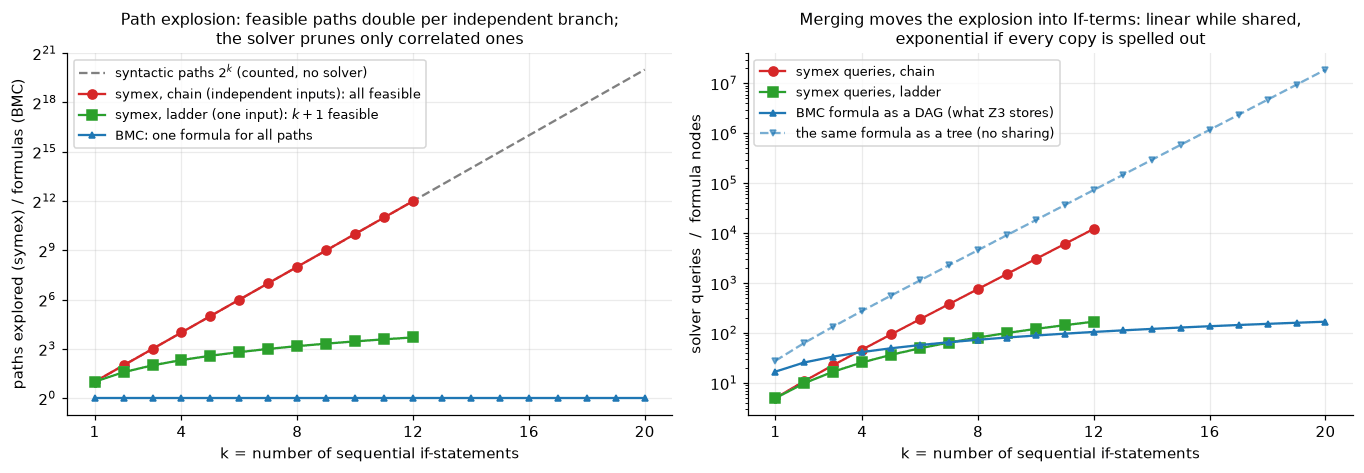

At k = 20 symex would face 1,048,576 paths; BMC's formula for the same chain has 170 nodes and is proved in milliseconds.
The price of merging appears elsewhere: every merged variable is an If-term the solver must case-split on.


In [63]:
_s5_K_SYMEX, _s5_K_COUNT = 12, 20


def _s5_chain_src(k):
    '''k independent checks on k inputs: every one of the 2^k paths is feasible.'''
    lines = [f"def chain({', '.join(f'x{i}' for i in range(k))}):", f"    ensures(result <= {k})", "    s = 0"]
    for i in range(k):
        lines += [f"    if x{i} > 0:", "        s = s + 1"]
    return "\n".join(lines + ["    return s"]) + "\n"


def _s5_ladder_src(k):
    '''k checks of ONE input against increasing thresholds: 2^k syntactic paths, only k + 1 feasible.'''
    lines = ["def ladder(x):", f"    ensures(result <= {k})", "    s = 0"]
    for i in range(k):
        lines += [f"    if x > {10 * i}:", "        s = s + 1"]
    return "\n".join(lines + ["    return s"]) + "\n"


def _s5_syntactic_paths(stmts):
    '''Paths through loop-free code, counted on the AST without a solver: sequencing multiplies, if adds.'''
    n = 1
    for st in stmts:
        if isinstance(st, ast.If):
            n *= _s5_syntactic_paths(st.body) + _s5_syntactic_paths(st.orelse)
    return n


def _s5_bmc_formula_size(src, semantics='bv32'):
    '''Size of the ONE formula BMC hands to the solver for a loop-free program: (as a DAG, as a tree).'''
    fn = parse_minipy(src, semantics)
    env, _ = _s5_inputs(minipy_info(fn), semantics)
    u = _s5_Unroller(fn, semantics, 0, env).run()
    f = z3.Or(*[b for b, _, _ in u.bad])
    return _s5_dag_size(f), _s5_tree_size(f)


def _s5_explosion():
    '''Paths, queries and time of symex vs the size and time of BMC's single merged formula.'''
    rows, data = [], defaultdict(list)
    for k in range(1, _s5_K_COUNT + 1):
        chain, ladder = _s5_chain_src(k), _s5_ladder_src(k)
        data['syntactic'].append(_s5_syntactic_paths(parse_minipy(chain).body))
        row = [k, data['syntactic'][-1]]
        for fam, src in (("chain", chain), ("ladder", ladder)):
            if k <= _s5_K_SYMEX:
                P, dt = timed(symex, src, 'bv32', 10 ** 6)
                assert all(p['outcome'] == 'return' for p in P) and P.stats['complete']
                data[fam + ' paths'].append(len(P))
                data[fam + ' queries'].append(P.stats['queries'])
                data[fam + ' s'].append(dt)
        if k <= _s5_K_SYMEX:
            row += [f"{data['chain paths'][-1]} / {data['ladder paths'][-1]}",
                    f"{data['chain queries'][-1]} / {data['ladder queries'][-1]}", f"{data['chain s'][-1]:.3f}"]
        else:
            row += ["-", "-", "-"]
        r, dt = timed(bmc, chain, 0, 'bv32')
        assert r == ('proved', 0)
        dag, tree = _s5_bmc_formula_size(chain)
        data['bmc dag'].append(dag)
        data['bmc tree'].append(tree)
        rows.append(row + [dag, tree, f"{dt:.3f}"])
    show_table(["k", "syntactic paths", "symex paths: chain / ladder", "queries: chain / ladder", "chain symex s",
                "BMC formula (chain): DAG nodes", "same, as a tree", "BMC s"], rows)
    return data


def _s5_draw_explosion(data):
    ks_all = np.arange(1, _s5_K_COUNT + 1)
    ks = np.arange(1, _s5_K_SYMEX + 1)
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(12.5, 4.4))
    a0.plot(ks_all, data['syntactic'], color="gray", ls="--", lw=1.5,
            label="syntactic paths $2^k$ (counted, no solver)")
    a0.plot(ks, data['chain paths'], "o-", color="#d62728",
            label="symex, chain (independent inputs): all feasible")
    a0.plot(ks, data['ladder paths'], "s-", color="#2ca02c", label="symex, ladder (one input): $k + 1$ feasible")
    a0.plot(ks_all, np.ones(len(ks_all)), "^-", color="#1f77b4", ms=4, label="BMC: one formula for all paths")
    a0.set_yscale("log", base=2)
    a0.set_xticks([1, 4, 8, 12, 16, 20])
    a0.set_xlabel("k = number of sequential if-statements")
    a0.set_ylabel("paths explored (symex) / formulas (BMC)")
    a0.set_title("Path explosion: feasible paths double per independent branch;\nthe solver prunes only "
                 "correlated ones", fontsize=10.5)
    a0.legend(fontsize=8.5, loc="upper left")
    a1.plot(ks, data['chain queries'], "o-", color="#d62728", label="symex queries, chain")
    a1.plot(ks, data['ladder queries'], "s-", color="#2ca02c", label="symex queries, ladder")
    a1.plot(ks_all, data['bmc dag'], "^-", color="#1f77b4", ms=4, label="BMC formula as a DAG (what Z3 stores)")
    a1.plot(ks_all, data['bmc tree'], "v--", color="#1f77b4", ms=4, alpha=0.6,
            label="the same formula as a tree (no sharing)")
    a1.set_yscale("log")
    a1.set_xticks([1, 4, 8, 12, 16, 20])
    a1.set_xlabel("k = number of sequential if-statements")
    a1.set_ylabel("solver queries  /  formula nodes")
    a1.set_title("Merging moves the explosion into If-terms: linear while shared,\nexponential "
                 "if every copy is spelled out", fontsize=10.5)
    a1.legend(fontsize=8.5, loc="upper left")
    plt.tight_layout()
    plt.show()


def _s5_score_explosion(data):
    k = np.arange(1, _s5_K_SYMEX + 1)
    exact = (list(data['chain paths']) == list(2 ** k)) and (list(data['ladder paths']) == list(k + 1))
    q_ratio = data['chain queries'][-1] / 2 ** _s5_K_SYMEX
    growth = np.diff(data['bmc dag'])
    tree_ratio = data['bmc tree'][-1] / data['bmc tree'][-2]
    linear = growth.max() - growth.min() <= 2
    right = exact and 2.5 < q_ratio < 3.5 and linear and 1.8 < tree_ratio < 2.2
    print(f"registered prediction: chain explores exactly 2^k paths with ~3 * 2^k queries, ladder k + 1 paths; "
          f"BMC's one formula grows by a constant number of DAG nodes per if, but doubles per if when unshared | "
          f"measured: paths exact for k = 1..{_s5_K_SYMEX}: {exact}; chain queries / 2^k = {q_ratio:.2f} at "
          f"k = {_s5_K_SYMEX}; DAG growth {growth.min()}..{growth.max()} nodes per if; tree x{tree_ratio:.2f} "
          f"per if | verdict: {'RIGHT' if right else 'WRONG'}"
          f" -- merging is sharing: the same If-terms are exponential as text and linear as a DAG")


if HAVE_Z3:
    _s5_data = _s5_explosion()
    _s5_score_explosion(_s5_data)
    _s5_draw_explosion(_s5_data)
    print(f"At k = 20 symex would face {_s5_data['syntactic'][-1]:,} paths; BMC's formula for the same chain has "
          f"{_s5_data['bmc dag'][-1]} nodes and is proved in milliseconds.")
    print("The price of merging appears elsewhere: every merged variable is an If-term the solver must case-split on.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the path-explosion measurement.")

Both parts held. At $k = 12$ symex on `chain` spends about 12,000 queries and seconds of wall time; BMC proves
the 20-branch chain's `ensures` in milliseconds from a formula of under 200 nodes. The ladder shows what the
solver buys even without merging: of 4,096 syntactic paths at $k = 12$ it explores 13. Merging is not free
either: the If-terms push the case analysis into the solver, and a merged formula can be harder than all its
paths together. **State merging** (Kuznetsov, Kinder, Bucur & Candea, PLDI 2012) therefore merges only where a
static estimate of the extra solver queries says it pays, and reports speedups of several orders of magnitude on
GNU Coreutils over previously published results. **Veritesting** (Avgerinos, Rebert, Cha & Brumley, ICSE 2014)
alternates merged, static symbolic execution of acyclic regions with path-by-path dynamic exploration.

### 5.5 Fuzzing vs symbolic execution vs BMC, on §1's axes

§1 derived the cost of random testing: to find a bug of density $p$ with probability $1 - \delta$ takes
$n \approx \ln(1/\delta)/p$ runs, and nothing else matters. Symbolic execution's cost depends on something else.
It pays for the paths explored before the buggy one, which depends on where the bug sits in the path tree and on
the search order, not on $p$. BMC pays for one formula per bound, and how hard that formula is depends on the
arithmetic (§4.4's multipliers). The techniques are therefore complementary, and two small programs pull them
apart:

- `check_header(x)` fails only for `x == 0x1BADB002` (the Multiboot header magic): $p = 2^{-32}$, a needle one
  comparison deep.
- `popcount_guard(x)` counts the set bits of `x` in a 32-iteration loop and fails when exactly 16 are set:
  $p = \binom{32}{16}/2^{32} \approx 0.14$, a dense bug. But every iteration branches on one bit, so the program
  has $2^{32}$ paths, all feasible. DFS takes the bit-is-1 branch first, so the leaves come out in lexicographic
  order, and the first leaf with exactly 16 ones is $1^{16}0^{16}$. It is the last leaf of the subtree under the
  prefix $1^{16}$, so $2^{16} - 1$ leaves come before it. The general law: at width $w$ the first failing path
  is number $2^{w/2}$.

**Coverage-guided fuzzing** is the middle road. AFL (Zalewski, first release November 2013) combined
compile-time instrumentation with a genetic algorithm: keep every input that covers a new control-flow edge, and
mutate that corpus instead of drawing fresh inputs. This beats $1/p$ only if the program offers intermediate
coverage on the way to the bug, and a 32-bit `==` offers none. Split it into four byte compares (AFL++'s
laf-intel split-compares pass does this at compile time) and each matched byte opens a new edge. Our toy mutator
overwrites one of 4 bytes with one of 256 values in a third of its mutations, and at stage $j$ must pick the one
frontier input among $j + 1$ corpus entries: about
$3 \cdot 4 \cdot 256 \cdot (1 + 2 + 3 + 4) \approx 3.1 \cdot 10^4$ runs, against $2^{32} \approx 4.3 \cdot 10^9$
unsplit. MiniPy is Python, so the fuzzer runs each target natively, with `sys.settrace` line events as its edge
instrumentation (checked against `run_minipy` first).

**Registered predictions.** (a) Magic value: neither fuzzer finds it in 30,000 runs, DFS symex finds it on its
first path with at most 5 queries, and BMC finds it with one formula. (b) Byte-split magic: the coverage-guided
fuzzer needs about $3.1 \cdot 10^4$ runs (median over 5 campaigns, within 2×), and blind fuzzing finds nothing
in 30,000. (c) Popcount: blind fuzzing needs a median of $\ln 2/p \approx 5$ runs (within 2×); DFS symex needs
path $2^{16} = 65{,}536$, so none of its first `max_paths = 2000` paths fails (the $2^{w/2}$ law is measured
first at $w = 8 \dots 20$); and BMC finds the bug at depth 32 with one formula.

The first cell builds the fuzzer and checks the native targets against `run_minipy`. The second runs the
campaigns, symbolic execution and BMC, and scores the predictions; it also runs 20 more guided campaigns on the
split compare, unscored, to show how far a 5-campaign median can move. The third draws the results.

In [64]:
_s5_MAGIC_SRC = '''
def check_header(x):
    if x == 0x1BADB002:
        assert 0 == 1
    return 0
'''

_s5_MAGIC_SPLIT_SRC = '''
def check_header_split(x):
    if (x & 255) == 0x02:
        if ((x >> 8) & 255) == 0xB0:
            if ((x >> 16) & 255) == 0xAD:
                if ((x >> 24) & 255) == 0x1B:
                    assert 0 == 1
    return 0
'''


def _s5_popcount_src(width):
    '''Counts the 1-bits among the low `width` bits of x and fails when exactly half of them are set.'''
    return f'''
def popcount_guard(x):
    v = x
    c = 0
    i = 0
    while i < {width}:
        if (v & 1) == 1:
            c = c + 1
        v = v >> 1
        i = i + 1
    assert c != {width // 2}
    return c
'''


_s5_POPCOUNT_SRC = _s5_popcount_src(32)
_s5_TARGETS = {'magic': _s5_MAGIC_SRC, 'magic split': _s5_MAGIC_SPLIT_SRC, 'popcount': _s5_POPCOUNT_SRC}
_s5_SEED_NATIVE = 305


def _s5_as_python(src):
    '''MiniPy is Python: compile the source to a native function (the annotations become no-ops), the way a fuzzer
    runs a compiled target. Valid for these targets because no operation leaves int32 (checked below).'''
    names = {name: (lambda c: None) for name in ('requires', 'assume', 'invariant', 'decreases')}
    exec(textwrap.dedent(src), names)
    return names[minipy_info(src)['name']]


_s5_COVER = {'code': None, 'edges': set(), 'prev': 0}     # coverage record of the execution in progress


def _s5_tracer(frame, event, arg):
    '''The edge instrumentation: records (previous line, line) pairs, in the function under test only.'''
    rec = _s5_COVER
    if frame.f_code is not rec['code']:
        return None
    if event == 'line':
        rec['edges'].add((rec['prev'], frame.f_lineno))
        rec['prev'] = frame.f_lineno
    return _s5_tracer


def _s5_run_covered(f, x):
    '''One execution with AFL-style edge coverage: the set of (previous line, line) pairs executed in f.
    Returns (crashed, edges); an AssertionError is the crash. A campaign installs _s5_tracer once (toggling
    sys.settrace per execution re-instruments every frame on every thread: ~8x slower inside a Jupyter kernel).'''
    rec = _s5_COVER
    rec['code'], rec['edges'], rec['prev'] = f.__code__, set(), 0
    installed = sys.gettrace() is _s5_tracer
    if not installed:
        sys.settrace(_s5_tracer)
    try:
        f(x)
        crashed = False
    except AssertionError:
        crashed = True
    finally:
        rec['code'] = None
        if not installed:
            sys.settrace(None)
    return crashed, rec['edges']


def _s5_mutate(x, rnd):
    '''One havoc-style mutation of a 32-bit input: flip a bit, overwrite a byte, or add a small delta.'''
    u, op = x & 0xFFFFFFFF, rnd.randrange(3)
    if op == 0:
        u ^= 1 << rnd.randrange(32)
    elif op == 1:
        b = 8 * rnd.randrange(4)
        u = (u & ~(0xFF << b)) | (rnd.randrange(256) << b)
    else:
        u += rnd.randint(-35, 35)
    return wrap(u, 32)


def _s5_fuzz(f, budget, rnd, guided, seeds=None):
    '''Blackbox (guided=False): fresh uniform 32-bit inputs. Coverage-guided (guided=True, the AFL loop): run one
    random seed input, then mutate a random corpus entry and keep the child iff it covers a new edge. Returns the
    number of executions up to and including the first crash (a guided campaign's seed is execution 1), or None
    if the budget runs out. seeds: an optional list that receives each guided campaign's seed input.'''
    sys.settrace(_s5_tracer)                       # once per campaign; _s5_run_covered then leaves it installed
    try:
        start, corpus, seen = 1, None, None
        if guided:
            seed = rnd.randrange(-2 ** 31, 2 ** 31)
            if seeds is not None:
                seeds.append(seed)
            crashed, seen = _s5_run_covered(f, seed)
            if crashed:
                return 1
            start, corpus = 2, [seed]
        for n in range(start, budget + 1):
            x = _s5_mutate(rnd.choice(corpus), rnd) if guided else rnd.randrange(-2 ** 31, 2 ** 31)
            crashed, edges = _s5_run_covered(f, x)
            if crashed:
                return n
            if guided and not edges <= seen:
                corpus.append(x)
                seen |= edges
        return None
    finally:
        sys.settrace(None)


def _s5_native_check(n_random=300):
    '''The native functions must crash exactly where bv32 MiniPy fails: edge cases plus random inputs.'''
    rnd = random.Random(_s5_SEED_NATIVE)
    natives = {name: _s5_as_python(src) for name, src in _s5_TARGETS.items()}
    agree = total = 0
    for name, src in _s5_TARGETS.items():
        edge_cases = [0, -1, INT32_MIN, INT32_MAX, 0x1BADB002]
        for x in edge_cases + [rnd.randrange(-2 ** 31, 2 ** 31) for _ in range(n_random)]:
            total += 1
            agree += _s5_run_covered(natives[name], x)[0] == (run_minipy(src, [x], 'bv32')[0] == 'assert_fail')
    return natives, agree, total


_s5_NATIVES, _s5_agree, _s5_total = _s5_native_check()
print(f"native targets vs run_minipy (bv32): {_s5_agree}/{_s5_total} inputs agree on crash / no crash.")
print("So a crash of the native target is a failing MiniPy run, and the fuzzer's run counts measure MiniPy's bugs.")

native targets vs run_minipy (bv32): 915/915 inputs agree on crash / no crash.
So a crash of the native target is a failing MiniPy run, and the fuzzer's run counts measure MiniPy's bugs.


Now the shoot-out. Each technique gets the three targets: fuzzing with a budget per campaign, DFS symbolic
execution stopped at the first failing path (or at `max_paths`), and BMC at $k = 32$. Every BMC counterexample is
replayed, and the cell times everything, for the figure after it.

In [65]:
_s5_SEED_FUZZ = 2016
_s5_FUZZ_BUDGET = 30_000           # executions per fuzzing campaign on the magic-value targets
_s5_SPLIT_BUDGET = 200_000         # cap for the guided campaigns on the split compare
_s5_FUZZ_TRIALS = 5                # campaigns on the split target that prediction (b) is scored on (their median)
_s5_SPLIT_EXTRA = 20               # further campaigns, unscored: how stable is a 5-campaign median?
_s5_POP_BUDGET, _s5_POP_TRIALS = 1000, 200
_s5_AFL_BUCKETS = (1, 2, 3, 4, 8, 16, 32, 128)   # lower ends of AFL's hit-count buckets (Zalewski's technical notes)
_s5_SEED_BUCKETS = 1611


def _s5_bucketed_coverage(f, x):
    '''AFL's refinement of edge coverage for one execution: the set of (edge, bucket) pairs, each edge's hit count
    rounded down to the lower end of its bucket (1, 2, 3, 4-7, 8-15, 16-31, 32-127, 128+).'''
    hits, prev = Counter(), [0]

    def tracer(frame, event, arg):
        if frame.f_code is not f.__code__:
            return None
        if event == 'line':
            hits[prev[0], frame.f_lineno] += 1
            prev[0] = frame.f_lineno
        return tracer
    sys.settrace(tracer)
    try:
        f(x)
    except AssertionError:
        pass
    finally:
        sys.settrace(None)
    return {(edge, max(b for b in _s5_AFL_BUCKETS if b <= n)) for edge, n in hits.items()}


def _s5_bucket_footholds(f, seed_ones, target=16, width=32):
    '''Would AFL's buckets give the guided fuzzer a foothold on popcount? A mutant is kept iff it adds an
    (edge, bucket) pair the seed lacks. popcount's edge counts depend only on the number of 1-bits (checked on
    random inputs), so one input per popcount k = 0..width covers every case. Returns the popcounts strictly
    between the seed's and the target that would be kept, and the nearest kept popcount on each side of the seed.'''
    cov = {k: _s5_bucketed_coverage(f, wrap((1 << k) - 1, width)) for k in range(width + 1)}
    rnd = random.Random(_s5_SEED_BUCKETS)
    for x in (rnd.randrange(-2 ** 31, 2 ** 31) for _ in range(100)):
        assert _s5_bucketed_coverage(f, x) == cov[bin(x & 0xFFFFFFFF).count('1')]
    kept = [k for k in range(width + 1) if cov[k] - cov[seed_ones]]
    between = [k for k in range(min(seed_ones, target) + 1, max(seed_ones, target)) if k in kept]
    below = max((k for k in kept if k < seed_ones), default=None)
    above = min((k for k in kept if k > seed_ones), default=None)
    return between, below, above


def _s5_first_failing_path(src, max_paths):
    '''DFS symex stopped at the first failing path: (its 1-based index or None within max_paths, the paths).'''
    fn = parse_minipy(src, 'bv32')
    explorer = _s5_Explorer(fn, minipy_info(fn), 'bv32', max_paths, 2000)
    explorer.stop_on_bug = True
    P = explorer.run()
    return next((j + 1 for j, p in enumerate(P) if p['outcome'] != 'return'), None), P


def _s5_search_shootout():
    '''Fuzzing vs symbolic execution vs BMC on the three targets, with wall-clock costs.'''
    rnd, natives = random.Random(_s5_SEED_FUZZ), _s5_NATIVES
    p = {'magic': 2.0 ** -32, 'magic split': 2.0 ** -32, 'popcount': math.comb(32, 16) / 2 ** 32}
    res, secs = {}, {}
    for name in ('magic', 'magic split'):
        for kind in ('blackbox', 'guided') if name == 'magic' else ('blackbox',):
            res[name, kind], secs[name, kind] = timed(_s5_fuzz, natives[name], _s5_FUZZ_BUDGET, rnd, kind == 'guided')
    split = [timed(_s5_fuzz, natives['magic split'], _s5_SPLIT_BUDGET, rnd, True)
             for _ in range(_s5_FUZZ_TRIALS + _s5_SPLIT_EXTRA)]
    split_runs = [r or _s5_SPLIT_BUDGET for r, _ in split]
    res['magic split', 'guided'] = int(np.median(split_runs[:_s5_FUZZ_TRIALS]))
    secs['magic split', 'guided'] = float(np.median([dt for _, dt in split[:_s5_FUZZ_TRIALS]]))
    pop = {}
    for kind in ('blackbox', 'guided'):
        seeds, runs = [], []
        (_, dt) = timed(lambda: runs.extend(_s5_fuzz(natives['popcount'], _s5_POP_BUDGET, rnd, kind == 'guided',
                                                     seeds) for _ in range(_s5_POP_TRIALS)))
        capped = [bin(seeds[i] & 0xFFFFFFFF).count('1') for i, r in enumerate(runs) if r is None and seeds]
        runs = [r or _s5_POP_BUDGET for r in runs]
        res['popcount', kind], secs['popcount', kind] = int(np.median(runs)), dt / _s5_POP_TRIALS
        pop[kind] = dict(runs=runs, capped=sum(r >= _s5_POP_BUDGET for r in runs), capped_seed_popcounts=capped)
        print(f"popcount, {kind} fuzzing: median {np.median(runs):.0f} runs over {len(runs)} campaigns, "
              f"{pop[kind]['capped']} hit the {_s5_POP_BUDGET}-run cap"
              + (f" (their seeds have popcount {sorted(capped)})" if capped else ""))
    for s in sorted(set(pop['guided']['capped_seed_popcounts'])):
        between, below, above = _s5_bucket_footholds(natives['popcount'], s)
        tag = lambda k: f"{k} (the bug itself)" if k == 16 else f"{k}"
        print(f"  with AFL's hit-count buckets, from a seed with {s} ones: mutants with "
              f"{min(s, 16) + 1}..{max(s, 16) - 1} ones that add a new (edge, bucket) pair: {between or 'none'}; "
              f"the nearest kept mutants have {tag(below)} and {tag(above)} ones")
    for name, src in _s5_TARGETS.items():
        (first, P), dt = timed(_s5_first_failing_path, src, 2000)      # seconds to the bug: without the time
        res[name, 'symex'], secs[name, 'symex'] = (first, P.stats['queries'], len(P)), dt - P.stats['canonical_s']
        r, dt = timed(bmc, src, 32, 'bv32')                              # spent making the input canonical
        assert r[0] == 'counterexample' and run_minipy(src, r[2], 'bv32')[0] == 'assert_fail'
        res[name, 'bmc'], secs[name, 'bmc'] = (r[1], r.stats['formulas'], r[2]), dt - r.stats['canonical_s']
    rows = []
    for name in _s5_TARGETS:
        fz = lambda kind: f"{res[name, kind]:,}" if res[name, kind] else f"none in {_s5_FUZZ_BUDGET:,}"
        first, queries, n_paths = res[name, 'symex']
        depth, formulas, cex = res[name, 'bmc']
        rows.append([name, f"{p[name]:.3g}", f"{1 / p[name]:.3g}", fz('blackbox'), fz('guided'),
                     f"path {first} ({queries} queries)" if first else f"not in {n_paths} paths ({queries} queries)",
                     f"depth {depth}, x = {cex['x']} ({formulas} formulas)"])
    show_table(["target", "bug density p", "expected random runs 1/p", "blackbox fuzz: runs", "guided fuzz: runs",
                "DFS symex (max_paths=2000)", "BMC (k = 32), replayed"], rows)
    print(f"guided campaigns on the split compare: first {_s5_FUZZ_TRIALS} (scored) {split_runs[:_s5_FUZZ_TRIALS]}, "
          f"median {res['magic split', 'guided']:,}")

    # The DFS cost of popcount at smaller widths: the first failing path is number 2^(w/2).
    widths = [8, 12, 16, 20]
    dfs = [_s5_first_failing_path(_s5_popcount_src(w), 2000)[0] for w in widths]
    print(f"popcount at width w: first failing DFS path = {dict(zip(widths, dfs))}; 2^(w/2) = "
          f"{dict((w, 2 ** (w // 2)) for w in widths)}")
    return dict(res=res, p=p, secs=secs, split_runs=split_runs, pop=pop, dfs=dfs, widths=widths)


def _s5_score_shootout(sh):
    '''Score the three registered predictions of §5.5 against the measurements.'''
    res, p, split_runs, dfs, widths = sh['res'], sh['p'], sh['split_runs'], sh['dfs'], sh['widths']
    show = lambda v: f"{v:,}" if v else "none"
    first, queries, _ = res['magic', 'symex']
    ok_a = (res['magic', 'blackbox'] is None and res['magic', 'guided'] is None and first == 1 and queries <= 5
            and res['magic', 'bmc'][0] == 0)
    print(f"registered prediction (a): no fuzzer finds the 32-bit magic value in {_s5_FUZZ_BUDGET:,} runs; DFS "
          f"symex finds it on path 1 with <= 5 queries; BMC with one formula | measured: blind "
          f"{show(res['magic', 'blackbox'])}, guided {show(res['magic', 'guided'])}, symex path {first} "
          f"({queries} queries), BMC: the k = 32 formula holds the bug, depth {res['magic', 'bmc'][0]} | verdict: "
          f"{'RIGHT' if ok_a else 'WRONG'} -- the solver does not care how rare the input is, only how hard the "
          f"constraint is")
    med = res['magic split', 'guided']
    ok_b = res['magic split', 'blackbox'] is None and 3.1e4 / 2 <= med <= 3.1e4 * 2
    print(f"registered prediction (b): coverage-guided fuzzing finds the byte-split compare in ~3.1e4 runs "
          f"(median of {_s5_FUZZ_TRIALS}, within 2x), blind fuzzing never in {_s5_FUZZ_BUDGET:,} | measured: median "
          f"{med:,} over {_s5_FUZZ_TRIALS} campaigns, blind {show(res['magic split', 'blackbox'])} | verdict: "
          f"{'RIGHT' if ok_b else 'WRONG'} -- each new edge is a foothold: four 2^-8 steps instead of one "
          f"2^-32 jump")
    q1, q2, q3 = np.percentile(split_runs, [25, 50, 75])
    print(f"   unscored, all {len(split_runs)} split campaigns: mean {np.mean(split_runs):,.0f}, median {q2:,.0f}, "
          f"quartiles {q1:,.0f}..{q3:,.0f}, min {min(split_runs):,}, max {max(split_runs):,} (the derivation "
          f"3 * 4 * 256 * 10 = 30,720 is a mean; a sum of geometric waits is right-skewed, so its median sits lower)")
    med_pop, first_pop = res['popcount', 'blackbox'], res['popcount', 'symex'][0]
    law = dfs == [2 ** (w // 2) for w in widths]
    ok_c = (abs(math.log(med_pop * p['popcount'] / math.log(2))) < math.log(2) and first_pop is None and law
            and res['popcount', 'bmc'][0] == 32)
    print(f"registered prediction (c): blind fuzzing hits popcount == 16 in ~ln(2)/p = "
          f"{math.log(2) / p['popcount']:.1f} runs (median, within 2x); DFS symex needs 2^16 paths, so none of "
          f"its first 2000 fails; BMC finds it at depth 32 | measured: median {med_pop} runs; symex first failing "
          f"path {show(first_pop)} within 2000; 2^(w/2) law exact at w = {widths}: {law}; BMC depth "
          f"{res['popcount', 'bmc'][0]} | verdict: {'RIGHT' if ok_c else 'WRONG'} -- a bug can be dense in inputs "
          f"and still sit 65,536 paths deep")


if HAVE_Z3:
    _s5_sh, _s5_dt = timed(_s5_search_shootout)
    print()
    _s5_score_shootout(_s5_sh)
    print(f"(~{_s5_dt:.0f} s.) No search technique dominates: fuzzing is cheap where bugs are dense, symbolic")
    print("execution where they are rare but shallow in the path tree, BMC where the paths merge into a formula the")
    print("solver can handle.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the shoot-out (the fuzzer above runs without it).")

popcount, blackbox fuzzing: median 4 runs over 200 campaigns, 0 hit the 1000-run cap
popcount, guided fuzzing: median 6 runs over 200 campaigns, 2 hit the 1000-run cap (their seeds have popcount [24, 24])
  with AFL's hit-count buckets, from a seed with 24 ones: mutants with 17..23 ones that add a new (edge, bucket) pair: none; the nearest kept mutants have 16 (the bug itself) and 25 ones


target       bug density p  expected random runs 1/p  blackbox fuzz: runs  guided fuzz: runs  DFS symex (max_paths=2000)        BMC (k = 32), replayed             
-------------------------------------------------------------------------------------------------------------------------------------------------------------------
magic        2.33e-10       4.29e+09                  none in 30,000       none in 30,000     path 1 (4 queries)                depth 0, x = 464367618 (7 formulas)
magic split  2.33e-10       4.29e+09                  none in 30,000       19,088             path 1 (7 queries)                depth 0, x = 464367618 (7 formulas)
popcount     0.14           7.15                      4                    6                  not in 2000 paths (6022 queries)  depth 32, x = 65535 (6 formulas)   
guided campaigns on the split compare: first 5 (scored) [19088, 12652, 22857, 18661, 37246], median 19,088


popcount at width w: first failing DFS path = {8: 16, 12: 64, 16: 256, 20: 1024}; 2^(w/2) = {8: 16, 12: 64, 16: 256, 20: 1024}

registered prediction (a): no fuzzer finds the 32-bit magic value in 30,000 runs; DFS symex finds it on path 1 with <= 5 queries; BMC with one formula | measured: blind none, guided none, symex path 1 (4 queries), BMC: the k = 32 formula holds the bug, depth 0 | verdict: RIGHT -- the solver does not care how rare the input is, only how hard the constraint is
registered prediction (b): coverage-guided fuzzing finds the byte-split compare in ~3.1e4 runs (median of 5, within 2x), blind fuzzing never in 30,000 | measured: median 19,088 over 5 campaigns, blind none | verdict: RIGHT -- each new edge is a foothold: four 2^-8 steps instead of one 2^-32 jump
   unscored, all 25 split campaigns: mean 26,852, median 22,857, quartiles 17,543..37,246, min 2,810, max 65,265 (the derivation 3 * 4 * 256 * 10 = 30,720 is a mean; a sum of geometric waits is right-skewed, so its

The figure puts the results on two axes. On the left, §1's axes, with fuzzing alone, since only fuzzing is
measured in executions. On the right, all four techniques in one unit, wall-clock seconds on this machine (not
counting the search for the canonical input, which is presentation, not bug finding): filled markers are measured
to the bug, hollow ones are either a budget that ran out (a lower bound) or an extrapolation, labelled as such.

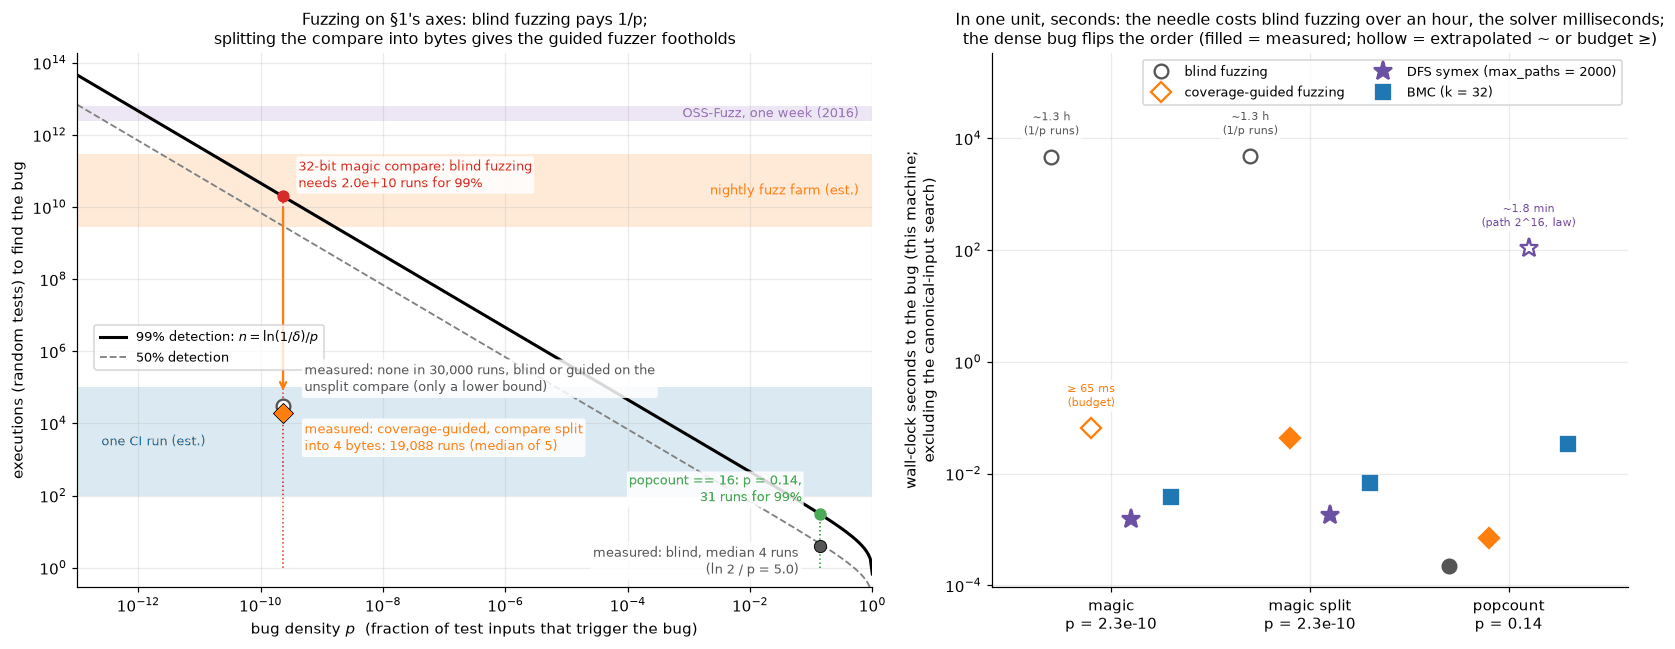

Blind fuzzing here costs ~1.1 µs per run, so the 32-bit needle would take about 1.3 h (extrapolated);
symex and BMC needed 1.5 ms and 3.8 ms. On popcount the order flips: blind fuzzing 222 µs per campaign,
BMC 33 ms, DFS symex ~1.8 min (extrapolated to path 2^16). Timings are this machine's and approximate.


In [66]:
def _s5_human(sec):
    '''Seconds -> a short human-readable duration (two significant digits).'''
    for unit, size in (("h", 3600), ("min", 60), ("s", 1), ("ms", 1e-3), ("µs", 1e-6)):
        if sec >= size or unit == "µs":
            v = sec / size
            return f"{v:.0f} {unit}" if v >= 10 else f"{v:.1f} {unit}"


def _s5_costs(sh):
    '''(seconds, how it was obtained) per (target, technique). Extrapolations: blind fuzzing at the measured cost
    per run times the expected 1/p runs; DFS symex on popcount at the measured cost per path times 2^16 paths.'''
    res, p, secs = sh['res'], sh['p'], sh['secs']
    per_run = {name: secs[name, 'blackbox'] / _s5_FUZZ_BUDGET for name in ('magic', 'magic split')}
    cost = {}
    for name in _s5_TARGETS:
        for kind in ('blackbox', 'guided'):
            if res[name, kind]:
                cost[name, kind] = (secs[name, kind], 'measured')
            elif kind == 'blackbox':
                cost[name, kind] = (per_run[name] / p[name], 'extrapolated')
            else:
                cost[name, kind] = (secs[name, kind], 'lower bound')
        first, _, n_paths = res[name, 'symex']
        cost[name, 'symex'] = ((secs[name, 'symex'], 'measured') if first else
                               (secs[name, 'symex'] * 2 ** 16 / n_paths, 'extrapolated'))
        cost[name, 'bmc'] = (secs[name, 'bmc'], 'measured')
    return cost, per_run


def _s5_draw_shootout(sh):
    '''Left: fuzzing on §1's tests-needed-vs-density axes. Right: every technique's cost in seconds.'''
    res, p = sh['res'], sh['p']
    cost, per_run = _s5_costs(sh)
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(15, 6.0), gridspec_kw=dict(width_ratios=[1.25, 1]))
    draw_density_axes(ax0, p_min=1e-13)
    p_magic, p_pop = p['magic'], p['popcount']
    box = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85)
    mark_density(ax0, p_magic, f"32-bit magic compare: blind fuzzing\nneeds {tests_needed(p_magic):.1e} runs "
                 f"for 99%", offset=(10, 14))
    mark_density(ax0, p_pop, f"popcount == 16: p = {p_pop:.2f},\n{tests_needed(p_pop)} runs for 99%",
                 color="#2ca02c", offset=(-12, 16), ha="right")
    split_med = res['magic split', 'guided']
    # zorder above the hollow lower-bound circle at the 30,000-run budget, which sits just above this marker
    ax0.plot([p_magic], [split_med], "D", ms=9, color="#ff7f0e", mec="black", mew=0.6, zorder=9)
    ax0.annotate(f"measured: coverage-guided, compare split\ninto 4 bytes: {split_med:,} runs "
                 f"(median of {_s5_FUZZ_TRIALS})", (p_magic, split_med), xytext=(14, -16),
                 textcoords="offset points", fontsize=8.5, color="#ff7f0e", va="center", bbox=box, zorder=8)
    ax0.annotate("", (p_magic, _s5_FUZZ_BUDGET * 2.2), (p_magic, tests_needed(p_magic) / 1.8),
                 arrowprops=dict(arrowstyle="->", color="#ff7f0e", lw=1.5))
    ax0.plot([p_magic], [_s5_FUZZ_BUDGET], "o", ms=9, mfc="white", mec="#555555", mew=1.5, zorder=7)
    ax0.annotate(f"measured: none in {_s5_FUZZ_BUDGET:,} runs, blind or guided on the\nunsplit compare "
                 f"(only a lower bound)", (p_magic, _s5_FUZZ_BUDGET), xytext=(14, 18), textcoords="offset points",
                 fontsize=8.5, color="#555555", va="center", bbox=box, zorder=8)
    pop_med = res['popcount', 'blackbox']
    ax0.plot([p_pop], [pop_med], "o", ms=8, color="#555555", mec="black", mew=0.6, zorder=7)
    ax0.annotate(f"measured: blind, median {pop_med} runs\n(ln 2 / p = {math.log(2) / p_pop:.1f})", (p_pop, pop_med),
                 xytext=(-14, -10), textcoords="offset points", fontsize=8.5, color="#555555", ha="right",
                 va="center", bbox=box, zorder=8)
    ax0.set_ylim(0.3, ax0.get_ylim()[1])
    ax0.set_ylabel("executions (random tests) to find the bug")
    ax0.set_title("Fuzzing on §1's axes: blind fuzzing pays 1/p;\nsplitting the compare into bytes gives the "
                  "guided fuzzer footholds", fontsize=10.5)

    techs = [('blackbox', 'blind fuzzing', 'o', "#555555"), ('guided', 'coverage-guided fuzzing', 'D', "#ff7f0e"),
             ('symex', 'DFS symex (max_paths = 2000)', '*', "#6a51a3"), ('bmc', 'BMC (k = 32)', 's', "#1f77b4")]
    for i, name in enumerate(_s5_TARGETS):
        for j, (kind, label, marker, color) in enumerate(techs):
            x = i + (j - 1.5) * 0.2
            y, how = cost[name, kind]
            ax1.plot([x], [y], marker=marker, ms=13 if marker == "*" else 9, ls="none", color=color, mec=color,
                     mew=1.5, mfc=color if how == 'measured' else "white", zorder=5,
                     label=label if i == 0 else None)
            if how != 'measured':
                ax1.annotate(("~" if how == 'extrapolated' else "≥ ") + _s5_human(y)
                             + ("\n(1/p runs)" if kind == 'blackbox' else "\n(path 2^16, law)" if kind == 'symex'
                                else "\n(budget)"), (x, y), xytext=(0, 12), textcoords="offset points",
                             fontsize=7.5, color=color, ha="center", va="bottom", bbox=box, zorder=6)
    ax1.set_yscale("log")
    ax1.set_xticks(range(len(_s5_TARGETS)))
    ax1.set_xticklabels([f"{name}\np = {p[name]:.2g}" for name in _s5_TARGETS])
    ax1.set_xlim(-0.6, len(_s5_TARGETS) - 0.4)
    lo, hi = ax1.get_ylim()
    ax1.set_ylim(lo, hi * 30)
    ax1.set_ylabel("wall-clock seconds to the bug (this machine;\nexcluding the canonical-input search)")
    ax1.legend(fontsize=8.5, loc="upper right", ncol=2)
    ax1.set_title("In one unit, seconds: the needle costs blind fuzzing over an hour, the solver milliseconds;\n"
                  "the dense bug flips the order (filled = measured; hollow = extrapolated ~ or budget ≥)",
                  fontsize=10.5)
    plt.tight_layout()
    plt.show()
    return cost, per_run


if HAVE_Z3:
    _s5_cost, _s5_per_run = _s5_draw_shootout(_s5_sh)
    print(f"Blind fuzzing here costs ~{_s5_human(_s5_per_run['magic'])} per run, so the 32-bit needle would take "
          f"about {_s5_human(_s5_cost['magic', 'blackbox'][0])} (extrapolated);")
    print(f"symex and BMC needed {_s5_human(_s5_cost['magic', 'symex'][0])} and "
          f"{_s5_human(_s5_cost['magic', 'bmc'][0])}. On popcount the order flips: blind fuzzing "
          f"{_s5_human(_s5_cost['popcount', 'blackbox'][0])} per campaign,")
    print(f"BMC {_s5_human(_s5_cost['popcount', 'bmc'][0])}, DFS symex "
          f"~{_s5_human(_s5_cost['popcount', 'symex'][0])} (extrapolated to path 2^16). Timings are this machine's "
          f"and approximate.")
else:
    print("§5 needs Z3 (pip install z3-solver): skipping the shoot-out figure.")

All three predictions held. On the left, fuzzing lives on the black curve: the 32-bit needle needs about
$2 \cdot 10^{10}$ runs, inside the (estimated) nightly-fuzz-farm band and far outside one CI run; a 64-bit
compare would need about $10^{20}$, beyond 80 years at a billion tests per second. Splitting the compare into
bytes moved the guided fuzzer down more than five orders of magnitude: one $2^{-32}$ jump turned into four
$2^{-8}$ steps. The 25 campaigns show how much luck is in prediction (b)'s verdict. Their mean, about
$2.7 \cdot 10^4$, is close to the derived $3.1 \cdot 10^4$, which is a mean too (the other two mutation operators
help a little). Their median, about $2.3 \cdot 10^4$, is lower, because a sum of geometric waits is
right-skewed, and the five scored campaigns, with a median of about $1.9 \cdot 10^4$, sit near the lower
quartile. The verdict is right, but on a small sample. On the right, in seconds, the order of the techniques
flips between the two kinds of bug. The needle would take blind fuzzing over an hour (extrapolated) and takes
symex and BMC milliseconds; the dense bug takes blind fuzzing well under a millisecond per campaign.

The **kept failure** is depth-first symbolic execution on popcount. A bug that one random input in seven triggers
is invisible to its first 2,000 paths, because DFS spends them under the prefix $1^{16}$; the $2^{w/2}$ law,
exact at four widths, puts the first hit at path 65,536, minutes of exploration by extrapolation. BMC's first
formula ($k = 32$) already contains the bug, because merging folds the $2^{32}$ paths into one formula of 32
merged additions; a short binary search over $k$ then reports its depth. Coverage guidance fails on popcount too,
and the mechanism is worse than "no help". Almost every input covers the same edges, so the corpus never grows,
and the guided fuzzer only ever mutates its single seed. When that seed's popcount is far from 16, a single
mutation rarely reaches 16: in 2 of 200 campaigns (both seeds had popcount 24, the lines above the table) the
guided fuzzer did not find within 1,000 runs a bug that blind fuzzing finds in a median of 4. AFL refines edge
coverage with hit counts rounded into buckets (1, 2, 3, 4–7, 8–15, 16–31, 32–127, 128+; Zalewski's technical
notes), so an input that runs a loop body more or less often can count as progress. Here even that gives no
foothold, as the line under the guided campaigns shows: from 24 ones down to 17, the bit-is-1 edge's count stays
in 16–31 and the bit-is-0 edge's in 8–15, so the first mutant toward 16 that adds a bucket is the bug itself.
The buckets reward only moving away: 25 ones put the bit-is-0 count into 4–7.

**Concolic testing** attacks the search-order problem from the other side: run on a concrete input, record that
run's path condition, negate one branch, and solve for an input that takes the other side (DART: Godefroid,
Klarlund & Sen, PLDI 2005). On popcount every flipped bit-branch moves the count by one, so from a random seed a
concolic tester walks to 16 in a few steps. Microsoft's **SAGE** scaled this "whitebox fuzzing" to file parsers:
roughly a third of all bugs found by file fuzzing during Windows 7 development, more than 300 machine-years from
2008 on, and the 2007 ANI cursor vulnerability rediscovered without format knowledge in 7 h 36 min on one core
(Godefroid, Levin & Molnar, CACM 2012). KLEE, at about an hour per tool on 89 GNU Coreutils programs, reached
90.9% average line coverage against 68.4% for the developers' suites and found 10 fatal errors there, 3 latent
for over 15 years (Cadar et al. 2008). Fuzzing began as random input thrown at UNIX utilities (Miller,
Fredriksen & So, CACM 1990) and is now infrastructure: OSS-Fuzz (its launch-week throughput is §1's budget band)
had helped fix over 13,000 vulnerabilities and 50,000 bugs in 1,000 projects by May 2025 (google/oss-fuzz
README). By November 2024 LLM-written fuzz targets had added coverage in 272 of its C/C++ projects and found 26
new vulnerabilities, OpenSSL's CVE-2024-9143 among them (Google Security Blog): §13's pattern of an untrusted
generator feeding a checker that cannot be fooled.

| | fuzzing | symbolic execution | BMC |
|---|---|---|---|
| explores | sampled inputs, plus a corpus | feasible paths, one at a time | every execution with at most $k$ iterations of each loop ($k$ steps for a transition system), merged into one formula |
| cost driver | $1/p$: the bug's density | number of paths before the bug | formula size and arithmetic |
| needle ($p = 2^{-32}$) | hopeless unless split into steps | 1 path, a few queries | 1 formula holds it |
| dense but deep bug | a few runs | $2^{16}$ DFS paths (search order!) | 1 formula holds it |
| can it prove? | never | yes, if the exploration is complete (loop-free or fully bounded, inputs within the caps) | yes, with the unwinding and input-size assertions, or $k \ge rd$ |
| industrial | AFL++, libFuzzer, OSS-Fuzz | KLEE, SAGE, angr | CBMC, ESBMC, Kani |

None of these techniques invents anything. All three under-approximate, which is why every bug they report
replays concretely; their rare `'proved'` answers still rest on the solver's UNSAT answers (no certificate is
checked, unlike §3's RUP proofs) and on the input bounds. §6 starts where the bound ends: a human supplies an
inductive invariant, and the same `expr_to_z3` turns the program into verification conditions that hold at every
depth at once.

## 6. Proving programs: Hoare logic, weakest preconditions, inductive invariants

§5's engines stop at a bound, and §5.3 showed that a deeper bound is no way out: a loop over a 32-bit counter
needs billions of unrollings before BMC's answer becomes a proof. A proof has to cover every depth at once, so it
must argue about *one* step that is safe however many steps came before. Floyd (1967) attached assertions to the
points of a flowchart, and Hoare (CACM 1969) turned them into a calculus. Every statement is checked locally, and
the one non-local construct, the loop, is handled by an **inductive invariant**: a set of states that contains
the initial ones and is closed under the loop body. This section derives the rules, turns them into a
verification-condition generator for MiniPy (`vcgen`, `verify`), and runs it on the running examples to see
what is mechanical and what still needs a human. §8, §9 and §13 answer the question it leaves open: who writes
the invariant.

### 6.1 Hoare triples, and where the rules come from

A **Hoare triple** $\{P\}\ C\ \{Q\}$ says: from every state satisfying $P$, $C$ cannot fail (no `assert`,
overflow or bounds check goes wrong) and, *if* it terminates, it ends in a state satisfying $Q$ (partial
correctness, §2.1). Each rule follows from what a statement does to the state:

$$\frac{}{\{Q[e/x]\}\ \ x := e\ \ \{Q\}}\qquad
\frac{\{P\}\,C_1\,\{R\}\quad \{R\}\,C_2\,\{Q\}}{\{P\}\ C_1;\,C_2\ \{Q\}}\qquad
\frac{P \Rightarrow P' \quad \{P'\}\,C\,\{Q'\} \quad Q' \Rightarrow Q}{\{P\}\ C\ \{Q\}}$$

$$\frac{\{P \wedge b\}\ C_1\ \{Q\}\quad \{P \wedge \neg b\}\ C_2\ \{Q\}}{\{P\}\ \textsf{if } b \textsf{ then } C_1
\textsf{ else } C_2\ \{Q\}}\qquad
\frac{\{I \wedge b\}\ C\ \{I\}}{\{I\}\ \textsf{while } b \textsf{ do } C\ \{I \wedge \neg b\}}$$

- **Assignment runs backwards.** $Q$ describes the state *after* $x := e$, in which $x$ holds the old value of
  $e$ and nothing else changed, so $Q$ holds afterwards iff $Q[e/x]$ held before:
  $\{x + 1 > 0\}\ x := x + 1\ \{x > 0\}$. The tempting forward rule $\{P\}\ x := e\ \{P[e/x]\}$ is wrong: from
  $x = 0$ and $x := x + 1$ it concludes $x + 1 = 0$. The correct forward rule (Floyd's) must name the forgotten
  value, $\{P\}\ x := e\ \{\exists x_0.\ P[x_0/x] \wedge x = e[x_0/x]\}$; the existential is why tools go
  backwards.
- **Consequence** is where the solver enters: $P \Rightarrow P'$ and $Q' \Rightarrow Q$ are the **verification
  conditions** (VCs).
- **While** is induction on iterations: if $I$ holds at the loop head and the body re-establishes it from any
  $I$-state with $b$ true, $I$ holds at every visit of the head, and on exit $b$ is false.

**Soundness and completeness.** Every rule maps true triples to true triples, so everything derivable is true.
Cook (SIAM J. Computing, 1978) made the converse precise. No *effective* proof system (one whose theorems a
program can list) derives every true triple, even over the natural numbers without multiplication:
$\{\mathit{true}\}\ C\ \{\mathit{false}\}$ holds exactly when $C$ never halts, so the true triples are not
recursively enumerable (his Theorem 2). Yet the rules are complete *relative* to the assertion language: if it is
**expressive** (it can state the strongest postcondition of every program, hence every invariant needed) and an
oracle supplies its true formulas, every true triple is derivable (Theorem 3). Incompleteness therefore has two
logical sources. One is an assertion theory that no procedure decides, so the oracle cannot be built (§4's
decidability map). The other is an assertion language too weak to state the invariant a loop needs. Arithmetic
with `+` only is that second case: Presburger arithmetic is decidable, and for that very reason not expressive.
Every recursively enumerable set is the postcondition of some program, so if the language could state them all,
deciding its formulas would decide every such set (Cook's remark after Lemma 5). A third obstacle is practical,
not logical: even when the invariant is expressible and every VC decidable, someone has to *find* it. That is
where §2's limits bite.

### 6.2 Weakest preconditions: the rules as an algorithm

Dijkstra (CACM 1975) removed the guessing: wp computes the intermediate assertions that the sequencing and
consequence rules ask for. The **weakest precondition** $\mathrm{wp}(C, Q)$ is the set of states from which $C$
cannot fail, terminates, and ends in $Q$. The **weakest liberal precondition** $\mathrm{wlp}(C, Q)$ drops
"terminates": from its states $C$ cannot fail and, *if* it terminates, ends in $Q$. So the partial-correctness
triple $\{P\}\ C\ \{Q\}$ holds iff $P \Rightarrow \mathrm{wlp}(C, Q)$ is valid, one solver query, and the
total-correctness triple $[P]\ C\ [Q]$ holds iff $P \Rightarrow \mathrm{wp}(C, Q)$. With wp in a partial triple
only one direction survives: §6.5's `spin` never exits, so $\mathrm{wp}(\texttt{spin}, Q)$ is *false*, yet its
partial triple holds. Loop-free code always terminates, and there the two coincide. The rules become equations,
applied from the last statement backwards:

| MiniPy statement | $\mathrm{wlp}(\text{statement}, Q)$ (also $\mathrm{wp}$, in every row but the loop) |
|---|---|
| `x = e` | $Q[e/x]$, plus `e`'s own checks |
| `S1; S2` | $\mathrm{wlp}(S_1, \mathrm{wlp}(S_2, Q))$ |
| `if b: S1 else: S2` | $(b \Rightarrow \mathrm{wlp}(S_1, Q)) \wedge (\neg b \Rightarrow \mathrm{wlp}(S_2, Q))$ |
| `assert c` / `assume(c)` | $c \wedge (c \Rightarrow Q)$ / $c \Rightarrow Q$ |
| `return e` | every `ensures` with $e$ for `result`; the continuation $Q$ is dropped |
| `while b:` with invariant $I$ | $I \wedge \forall \vec m.\ \big((I \wedge b \Rightarrow \mathrm{wlp}(\text{body}, I)) \wedge (I \wedge \neg b \Rightarrow Q)\big)$, $\vec m$ = variables the loop assigns |

For loop-free code this is exact. For a loop the true wlp is a fixpoint that cannot be computed in general, and
the annotated invariant stands in for it, so the result is *sufficient*, not weakest. `vcgen` computes wlp with
each loop cut at its invariant; a `decreases` annotation adds two VCs that make it sufficient for wp, total
correctness (§6.5). Its design decisions:

- **Named obligations.** wp runs over a list of `(name, assumptions, goal)` triples, so a failure names its line
  and check, e.g. `line 5: attempt to add with overflow: lo + hi`: rustc's overflow-panic text, which Kani reports
  as the check's description (its tutorial shows `"attempt to shift left with overflow"`). GNATprove says
  `overflow check might fail`.
- **Semantics.** Under `'int+ovf'` every program `+ - *` and unary minus adds an obligation $\mathrm{in32}(e)$
  while specs stay in ℤ, which is SPARK's `-gnato13` mode (strict in code, unbounded in annotations; SPARK
  User's Guide). Under `'bvW'` nothing overflows and the solver sees wrapped arithmetic.
- **Assert, then assume** (Boogie's encoding): each check becomes an assumption of everything after it, so a
  path's first failing check is its only failing VC, as a run stops at its first failure.
- **Trees and fresh names.** The $\forall \vec m$ of the loop rule binds the loop's variables, and `vcgen` renames
  them to fresh names `x@L` (`L` = the loop's line). Assignments *before* the loop are substituted into the loop's
  VCs later (wp runs backwards), and the fresh names keep them off the loop-head values. MiniPy has no other
  binders, so this is all the capture avoidance it needs.
- **`verify`** groups VCs by name, translates them with §5's `expr_to_z3` (or `expr_to_bv` on §4's bit-blaster,
  `backend='toy'`), adds the input domain and asks for a counterexample, whose inputs it replays with
  `run_minipy`. Under `'int+ovf'` the domain says that the parameters *and* every loop-head variable `x@L` are
  int32. The second is a type invariant, not a guess: every value a program variable can hold is built from
  literals and inputs by operations that each passed their own overflow obligation (a shift or an `a if c else b`
  cannot leave int32), so by induction on loop-head visits it is int32 whenever all VCs hold. A VC that nothing
  satisfying `requires` and the path conditions can reach is reported `'vacuous'`, not `'proved'`.

The code comes in five cells: the building blocks, the VC generator, the solver queries, `verify` with its
replay, and the running examples.

In [67]:
# 6.2 code, part 1 of 5. Building blocks: AST constructors, substitution on trees, the checks hidden inside an
# expression, and how VCs are printed.
_s6_OVF_MSG = {ast.Add: "attempt to add with overflow", ast.Sub: "attempt to subtract with overflow",
               ast.Mult: "attempt to multiply with overflow", ast.USub: "attempt to negate with overflow"}
_s6_TOY_MAX_CONFLICTS = 30_000       # the toy backend's "timeout": a conflict budget for cdcl
_s6_SMALL_ARRAY = 6                  # counterexample arrays are first searched among lengths <= 6
_s6_MAX_DECODE = 200_000             # longer counterexample arrays are reported by length only


def _s6_at(node, ref):
    '''Give a freshly built AST node the source position of ref (VC names and error messages use lineno).'''
    return ast.copy_location(node, ref)


def _s6_var(x, ref):
    return _s6_at(ast.Name(x, ast.Load()), ref)


def _s6_lit(k, ref):
    return _s6_at(ast.Constant(k), ref)


def _s6_cmp(a, op, b, ref):
    return _s6_at(ast.Compare(left=a, ops=[op()], comparators=[b]), ref)


def _s6_and(a, b, ref):
    return _s6_at(ast.BoolOp(ast.And(), [a, b]), ref)


def _s6_not(a):
    return _s6_at(ast.UnaryOp(ast.Not(), a), a)


def _s6_implies(guards, cond):
    '''guards => cond, written in MiniPy as `not (g1 and g2 ...) or cond`.'''
    g = guards[0]
    for h in guards[1:]:
        g = _s6_and(g, h, cond)
    return _s6_at(ast.BoolOp(ast.Or(), [_s6_not(g), cond]), cond)


def _s6_in32(e):
    '''INT32_MIN <= e and e <= INT32_MAX: the obligation 'int+ovf' attaches to every program + - * and -x.'''
    return _s6_and(_s6_cmp(_s6_lit(INT32_MIN, e), ast.LtE, e, e), _s6_cmp(e, ast.LtE, _s6_lit(INT32_MAX, e), e), e)


def _s6_subst(e, mapping):
    '''e[mapping]: expression e with every variable x in `mapping` replaced by the expression mapping[x].
    It works on the TREE: substituting x := a + b into 2 * x gives 2 * (a + b) (text replacement would give
    2 * a + b), and a variable `xs` is not touched by x := ... . All occurrences are replaced at once
    (simultaneous substitution). Array names (a in a[i], len(a)) are never replaced: arrays are read-only
    parameters. Unchanged subtrees are shared, not copied; nothing is ever mutated in place.'''
    if isinstance(e, ast.Name):
        return mapping.get(e.id, e)
    if isinstance(e, (ast.Constant, ast.Call)):            # the only call left after normalization: len(a)
        return e
    fields, changed = {}, False
    for f, v in ast.iter_fields(e):
        if isinstance(v, ast.expr) and not (isinstance(e, ast.Subscript) and f == 'value'):
            nv = _s6_subst(v, mapping)
            changed |= nv is not v
        elif isinstance(v, list):
            nv = [_s6_subst(x, mapping) if isinstance(x, ast.expr) else x for x in v]
            changed |= any(a is not b for a, b in zip(nv, v))
        else:
            nv = v
        fields[f] = nv
    return _s6_at(type(e)(**fields), e) if changed else e


def _s6_names(e, arrays=False):
    '''The variables (or, with arrays=True, the array parameters) occurring in expression e.'''
    out = set()
    for n in ast.walk(e):
        if isinstance(n, ast.Subscript):
            out.add(('a', n.value.id))
        elif isinstance(n, ast.Call):
            out.add(('a', n.args[0].id))
        elif isinstance(n, ast.Name) and n.id != 'len':
            out.add(('v', n.id))
    arr = {x for k, x in out if k == 'a'}
    return arr if arrays else {x for k, x in out if k == 'v'} - arr


def _s6_checks(e, semantics, spec):
    '''The run-time checks hidden inside expression e, in run_minipy's evaluation order, as a list of
    (kind, guards, cond, node): cond must hold whenever all guards hold (the right side of and/or and the arms
    of `a if c else b` are evaluated lazily). Bounds checks a[i] apply everywhere; under 'int+ovf' every
    + - * and unary minus in PROGRAM code (spec=False) must stay inside int32.'''
    ovf = semantics == 'int+ovf' and not spec
    out = []

    def walk(x, g):
        if isinstance(x, ast.Constant):
            if ovf and not INT32_MIN <= x.value <= INT32_MAX:
                out.append(("literal out of int32 range", g, _s6_cmp(_s6_lit(0, x), ast.Eq, _s6_lit(1, x), x), x))
        elif isinstance(x, ast.BinOp):
            walk(x.left, g)
            if not isinstance(x.op, (ast.RShift, ast.LShift)):          # shifts are by a literal
                walk(x.right, g)
                if ovf:
                    out.append((_s6_OVF_MSG[type(x.op)], g, _s6_in32(x), x))
        elif isinstance(x, ast.UnaryOp):
            walk(x.operand, g)
            if ovf and isinstance(x.op, ast.USub):
                out.append((_s6_OVF_MSG[ast.USub], g, _s6_in32(x), x))
        elif isinstance(x, ast.BoolOp):                                 # binary after normalization
            a, b = x.values
            walk(a, g)
            walk(b, g + (a,) if isinstance(x.op, ast.And) else g + (_s6_not(a),))
        elif isinstance(x, ast.Compare):
            walk(x.left, g)
            walk(x.comparators[0], g)
        elif isinstance(x, ast.IfExp):
            walk(x.test, g)
            walk(x.body, g + (x.test,))
            walk(x.orelse, g + (_s6_not(x.test),))
        elif isinstance(x, ast.Subscript):
            walk(x.slice, g)
            length = _s6_at(ast.Call(_s6_var('len', x), [_s6_var(x.value.id, x)], []), x)
            ok = _s6_and(_s6_cmp(_s6_lit(0, x), ast.LtE, x.slice, x), _s6_cmp(x.slice, ast.Lt, length, x), x)
            out.append(("index out of bounds", g, ok, x))
    walk(e, ())
    return out


class _s6_Short(ast.NodeTransformer):
    '''Display only. Abbreviate INT32_MIN <= e and e <= INT32_MAX to in32(e), and put parentheses around an
    arithmetic operand of a shift: Python's unparse writes (hi - lo) >> 1 as hi - lo >> 1, which is correct
    (- binds tighter than >>) but reads as hi - (lo >> 1).'''
    def visit_BoolOp(self, node):
        self.generic_visit(node)
        if isinstance(node.op, ast.And) and all(isinstance(v, ast.Compare) for v in node.values):
            a, b = node.values
            if (isinstance(a.left, ast.Constant) and a.left.value == INT32_MIN and isinstance(b.comparators[0],
                    ast.Constant) and b.comparators[0].value == INT32_MAX
                    and ast.dump(a.comparators[0]) == ast.dump(b.left)):
                return ast.Call(ast.Name('in32', ast.Load()), [b.left], [])
        return node

    def visit_BinOp(self, node):
        self.generic_visit(node)
        if isinstance(node.op, (ast.RShift, ast.LShift)) and isinstance(node.left, ast.BinOp):
            node.left = ast.Name(f"({ast.unparse(node.left)})", ast.Load())    # unparse prints a Name verbatim
        return node


def _s6_show(e):
    '''An expression as MiniPy text, for VC names, listings and figures.'''
    import copy
    return ast.unparse(_s6_Short().visit(copy.deepcopy(e)))


def _s6_vc_text(assumptions, goal):
    return (" and ".join(f"({_s6_show(a)})" if isinstance(a, ast.BoolOp) else _s6_show(a) for a in assumptions)
            + "  ==>  " if assumptions else "") + _s6_show(goal)


def _s6_blocks_demo():
    '''The checks hidden in midpoint_fixed's return expression under each semantics, and one substitution.'''
    for sem in ('int', 'int+ovf', 'bv32'):
        ret = parse_minipy(MIDPOINT_FIXED_SRC, sem).body[-1].value
        found = [f"{kind}: {_s6_show(cond)}" for kind, _, cond, _ in _s6_checks(ret, sem, False)]
        print(f"checks hidden in `return {_s6_show(ret)}` under {sem!r:9}: {found or 'none'}")
    post = minipy_info(MIDPOINT_FIXED_SRC)['ensures'][0]
    print(f"ensures with result := that expression, substituted on the tree: "
          f"{_s6_show(_s6_subst(post, {'result': ret}))}")


_s6_blocks_demo()
print("Only 'int+ovf' turns arithmetic into obligations; under 'bv32' the same + and - just wrap.")

checks hidden in `return lo + ((hi - lo) >> 1)` under 'int'    : none
checks hidden in `return lo + ((hi - lo) >> 1)` under 'int+ovf': ['attempt to subtract with overflow: in32(hi - lo)', 'attempt to add with overflow: in32(lo + ((hi - lo) >> 1))']
checks hidden in `return lo + ((hi - lo) >> 1)` under 'bv32'   : none
ensures with result := that expression, substituted on the tree: lo <= lo + ((hi - lo) >> 1) and lo + ((hi - lo) >> 1) <= hi
Only 'int+ovf' turns arithmetic into obligations; under 'bv32' the same + and - just wrap.


The generator itself. wp walks the statements backwards over a list of named obligations, one case per kind of
statement; the loop rule (`_s6_wp_loop`) is explained together with its VCs in §6.3. The cell ends by printing
the VCs of `abs32`.

In [68]:
# 6.2 code, part 2 of 5. The VC generator: wp, backwards, over lists of named obligations.
# An obligation is (name, assumptions, goal): "if every assumption holds, the goal holds". A list of them
# means their conjunction. wp(S, list) returns the list that must hold BEFORE S for the list to hold after.

def _s6_assert_then_assume(name, guards, cond, rest):
    '''wp(assert cond; S) = cond and (cond => wp(S)). One new obligation, and cond becomes an assumption of every
    later one (Boogie's assert-then-assume): later checks may rely on earlier ones, and an input violates at
    most one obligation of a path -- the first failing check, exactly as at run time.'''
    fact = _s6_implies(list(guards), cond) if guards else cond
    return [(name, list(guards), cond)] + [(n, [fact] + A, g) for n, A, g in rest]


def _s6_checked(e, semantics, spec, rest, ren=None):
    '''Prefix `rest` with the run-time checks of expression e, in evaluation order. With ren (a loop's
    renaming) the checks are stated for the renamed expression but named after the source text.'''
    for kind, guards, cond, node in reversed(_s6_checks(e, semantics, spec)):
        if ren is not None:
            guards, cond = tuple(ren(g) for g in guards), ren(cond)
        rest = _s6_assert_then_assume(f"line {node.lineno}: {kind}: {_s6_show(node)}", guards, cond, rest)
    return rest


def _s6_assume(c, rest):
    return [(n, [c] + A, g) for n, A, g in rest]


def _s6_wp(stmts, post, cx):
    '''wp(S1; S2; ...; Sk, post) = wp(S1, wp(S2, ... wp(Sk, post))): the statements are walked BACKWARDS.'''
    obls = post
    for st in reversed(stmts):
        obls = _s6_wp_stmt(st, obls, cx)
    return obls


def _s6_wp_stmt(st, Q, cx):
    sem = cx['semantics']
    if isinstance(st, ast.Assign):                       # wp(x = e, Q) = Q[e/x], after e's own checks
        x, e = st.targets[0].id, st.value
        Q = [(n, [_s6_subst(a, {x: e}) for a in A], _s6_subst(g, {x: e})) for n, A, g in Q]
        return _s6_checked(e, sem, False, Q)
    if isinstance(st, ast.If):                           # (b => wp(S1, Q)) and (not b => wp(S2, Q)): Q copied!
        Q = _s6_assume(st.test, _s6_wp(st.body, Q, cx)) + _s6_assume(_s6_not(st.test), _s6_wp(st.orelse, Q, cx))
        return _s6_checked(st.test, sem, False, Q)
    if isinstance(st, ast.Assert):
        Q = _s6_assert_then_assume(f"line {st.lineno}: assertion: {_s6_show(st.test)}", (), st.test, Q)
        return _s6_checked(st.test, sem, True, Q)
    if isinstance(st, ast.Expr):                         # assume(c): wp = c => Q
        c = st.value.args[0]
        return _s6_checked(c, sem, True, _s6_assume(c, Q))
    if isinstance(st, ast.Return):                       # a jump to the ensures check: the continuation Q is dropped
        obls = []
        for q in reversed(cx['ensures']):
            q_r = _s6_subst(q, {'result': st.value})
            obls = _s6_assert_then_assume(f"line {q.lineno}: postcondition (return at line {st.lineno})", (),
                                          q_r, obls)
            obls = _s6_checked(q_r, sem, True, obls)
        return _s6_checked(st.value, sem, False, obls)
    if isinstance(st, ast.While):
        return _s6_wp_loop(st, Q, cx)
    raise ValueError(f"vcgen: unexpected statement {type(st).__name__} at line {st.lineno}")


def _s6_wp_loop(loop, Q, cx):
    '''The loop rule. With invariant I, guard b, body S, variant D and continuation Q:
         on entry:     I                                   (in the state before the loop)
         maintained:   I@ and b@  =>  wp(S, I)@            (for an ARBITRARY state satisfying I: havoc)
         exit:         I@ and not b@  =>  Q@
         termination:  I@ and b@  =>  D@ >= 0  and  wp(S, D < D@)@
    where @ renames every variable the loop assigns to a fresh name x@L (L = the loop's line). The fresh names
    are what makes the havoc capture-free: assignments BEFORE the loop substitute into the loop's VCs later
    (we walk backwards), and they must not touch the loop-head values.'''
    sem, lp = cx['semantics'], cx['loops'][id(loop)]
    invs, dec, L = lp['invariants'], lp['decreases'], loop.lineno
    k = len(invs) + (dec is not None)
    body = loop.body[k:]
    tag = f"loop {lp['index']} (line {L})"
    mods = sorted({n.targets[0].id for st in body for n in ast.walk(st) if isinstance(n, ast.Assign)})
    sigma = {x: _s6_var(f"{x}@{L}", loop) for x in mods} if cx['rename'] else {}
    ren = lambda e: _s6_subst(e, sigma)
    ren_all = lambda obls: [(n, [ren(a) for a in A], ren(g)) for n, A, g in obls]

    def at_head(kind, rest):
        '''What a visit of the loop head checks: each invariant, in order, after its own run-time checks.'''
        for inv in reversed(invs):
            rest = _s6_assert_then_assume(f"{tag}: invariant {kind}: {_s6_show(inv)}", (), inv, rest)
            rest = _s6_checked(inv, sem, True, rest)
        return rest

    # One iteration from an arbitrary I-state: the end of the body must re-establish I (and decrease D).
    end = []
    if dec is not None:
        marker = _s6_var(f"variant@{L}", dec)            # the variant's value at the head, filled in below
        end = _s6_assert_then_assume(f"{tag}: decreases strictly: {_s6_show(dec)}", (),
                                     _s6_cmp(dec, ast.Lt, marker, dec), end)
        end = _s6_checked(dec, sem, True, end)
    iteration = ren_all(_s6_wp(body, at_head("maintained", end), cx))
    if dec is not None:
        d_at = ren(dec)
        iteration = [(n, [_s6_subst(a, {marker.id: d_at}) for a in A], _s6_subst(g, {marker.id: d_at}))
                     for n, A, g in iteration]
        iteration = _s6_assert_then_assume(f"{tag}: decreases bounded below: {_s6_show(dec)} >= 0", (),
                                           _s6_cmp(d_at, ast.GtE, _s6_lit(0, dec), dec), iteration)
        iteration = _s6_checked(dec, sem, True, iteration, ren=ren)
    b_at = ren(loop.test)
    after = _s6_assume(b_at, iteration) + _s6_assume(_s6_not(b_at), ren_all(Q))
    after = _s6_checked(loop.test, sem, False, after, ren=ren)   # evaluating the guard has checks too
    for inv in reversed(invs):                            # havoc: all we know at the head is I
        after = _s6_assume(ren(inv), after)
    return at_head("on entry", []) + after


def _s6_function(fn):
    '''(minipy_info, body statements after the requires/ensures) of a normalized function.'''
    info = minipy_info(fn)
    return info, fn.body[len(info['requires']) + len(info['ensures']):]


def _s6_vcgen_tree(fn, semantics, rename=True):
    info, body = _s6_function(fn)
    cx = dict(semantics=semantics, ensures=info['ensures'], rename=rename,
              loops={id(lp['node']): lp for lp in info['loops']})
    obls = _s6_wp(body, [], cx)                           # every path returns, so nothing follows the body
    for r in reversed(info['requires']):                  # requires(...) are assumptions, in order
        obls = _s6_checked(r, semantics, True, _s6_assume(r, obls))
    return obls


def _s6_with_invariants(fn, invariants, semantics):
    '''A copy of the normalized function in which loop i's invariant(...) statements are replaced by
    invariant(e) for every expression string e in invariants[i]; re-normalized, so §2's scope and type checks
    apply to them. The new invariants carry the loop's line number.'''
    import copy
    fn = copy.deepcopy(fn)
    loops = sorted((n for n in ast.walk(fn) if isinstance(n, ast.While)), key=lambda n: (n.lineno, n.col_offset))
    for i, exprs in invariants.items():
        loop = loops[i]
        k = 0
        while k < len(loop.body) and isinstance(loop.body[k], ast.Expr) and isinstance(loop.body[k].value, ast.Call) \
                and getattr(loop.body[k].value.func, 'id', None) in ('invariant', 'decreases'):
            k += 1
        keep = [s for s in loop.body[:k] if s.value.func.id == 'decreases']
        new = []
        for text in exprs:
            e = ast.parse(text.strip(), mode='eval').body
            for node in ast.walk(e):
                node.lineno = node.end_lineno = loop.lineno
            call = ast.Call(ast.Name('invariant', ast.Load()), [e], [])
            new.append(ast.Expr(call))
        loop.body = new + keep + loop.body[k:]
    return normalize_minipy(ast.fix_missing_locations(fn), semantics)


def _s6_tree(src, semantics, invariants=None):
    fn = parse_minipy(src, semantics) if isinstance(src, str) else normalize_minipy(src, semantics)
    return _s6_with_invariants(fn, invariants, semantics) if invariants else fn


def vcgen(src, semantics='int+ovf', invariants=None):
    '''Verification conditions of a MiniPy function: a list of (name, assumptions, goal), where assumptions is
    a list of normalized MiniPy expression ASTs and goal one more; each VC claims "assumptions => goal" for
    all values of its free variables. The free variables are the parameters and, for VCs inside or after a
    loop, fresh loop-head variables named x@L. Names say what is checked and where ("line 6: attempt to add
    with overflow: lo + hi"); the same name appears once per path that reaches the check (naive wp).
    Under 'int+ovf' every variable additionally ranges over int32 (verify adds those type assumptions).
    invariants={loop_index: [expr_str, ...]} replaces that loop's written invariants.'''
    return _s6_vcgen_tree(_s6_tree(src, semantics, invariants), semantics)


def _s6_show_vcs(src, semantics):
    print(f"vcgen({minipy_info(src)['name']}, {semantics!r}):  name, then assumptions ==> goal")
    for name, A, g in vcgen(src, semantics):
        print(f"  {name:45s} {_s6_vc_text(A, g)}")


_s6_show_vcs(ABS_SRC, 'int+ovf')
print("Three VCs for a three-line function, and no solver has run yet: VC generation is pure syntax.")

vcgen(abs32, 'int+ovf'):  name, then assumptions ==> goal
  line 4: attempt to negate with overflow: -x   x < 0  ==>  in32(-x)
  line 2: postcondition (return at line 4)      x < 0 and (in32(-x))  ==>  -x >= 0
  line 2: postcondition (return at line 6)      not x < 0  ==>  x >= 0
Three VCs for a three-line function, and no solver has run yet: VC generation is pure syntax.


The listing shows the encoding: the overflow obligation for `-x` is guarded by its path condition `x < 0`, and
the postcondition on that path assumes it (assert, then assume). The next cell turns each group of same-named
VCs into one solver query: Z3 constants for the inputs and loop-head values, the input domain, a vacuity check,
and a decoder from the model back to Python ints.

In [69]:
# 6.2 code, part 3 of 5. The solver side of verify: each VC group becomes one query; models are decoded.

def _s6_group(vcs):
    '''name -> list of (assumptions, goal): one entry per path that reaches the check.'''
    groups = {}
    for name, A, g in vcs:
        groups.setdefault(name, []).append((A, g))
    return groups


def _s6_z3_env(copies, info, semantics):
    '''Z3 constants for every parameter and free variable, and the input domain: int32 ranges under int+ovf
    for parameters and loop-head variables x@L (a type invariant: their values come from checked int32
    operations; see the verify bullet above), and 0 <= len(a) for arrays. A passive-form version x.i (§6.6) is
    NOT given a range: it is defined by an equation x.i == e, and assuming in32(x.i) would assume away the
    overflow obligation of e.'''
    w = sem_width(semantics)
    sort = z3.BitVecSort(w) if w else z3.IntSort()
    in32 = (lambda t: [t >= INT32_MIN, t <= INT32_MAX]) if semantics == 'int+ovf' else (lambda t: [])
    exprs = [e for A, g in copies for e in A + [g]]
    names = set(p for p in info['params'] if p not in info['arrays'])
    arrays = set(info['arrays'])
    for e in exprs:
        names |= _s6_names(e)
        arrays |= _s6_names(e, arrays=True)
    env, dom = {}, []
    for x in sorted(names):
        env[x] = z3.Const(x, sort)
        if '.' not in x:
            dom += in32(env[x])
    for a in sorted(arrays):
        env[a] = (z3.Array(a, sort, sort), z3.Const(f"len({a})", sort))
        dom += [env[a][1] >= 0] + in32(env[a][1])
    for e in exprs:                                       # every array element read is an int32 input
        for n in ast.walk(e):
            if isinstance(n, ast.Subscript):
                dom += in32(expr_to_z3(n, env, semantics))
    return env, dom


def _s6_array_value(model, arr, n, ev, num):
    '''The model's array as a Python list of length n. Z3 reports an array as a chain Store(...Store(K(d), i, v)
    ...), so even a long counterexample array is cheap to build; anything else is read element by element.'''
    v, over = model.eval(arr, model_completion=True), {}
    while z3.is_store(v):
        over.setdefault(num(v.arg(1)), num(v.arg(2)))          # the outermost store of an index wins
        v = v.arg(0)
    if z3.is_K(v):
        default = num(v.arg(0))
        return [over.get(i, default) for i in range(n)]
    idx = (lambda i: z3.BitVecVal(i, arr.domain().size())) if z3.is_bv_sort(arr.domain()) else z3.IntVal
    return [ev(z3.Select(arr, idx(i))) for i in range(min(n, 4096))]


def _s6_decode(model, env, info, names_shown):
    '''A Z3 model -> {param: signed int (arrays: list)} plus the loop-head variables in names_shown.'''
    num = lambda v: v.as_signed_long() if z3.is_bv_value(v) else v.as_long()
    ev = lambda t: num(model.eval(t, model_completion=True))
    out = {}
    for p in info['params']:
        if p in info['arrays']:
            arr, n = env[p]
            k = ev(n)
            out[p] = (_s6_array_value(model, arr, k, ev, num) if k <= _s6_MAX_DECODE
                      else f"<array of length {k}>")
        else:
            out[p] = ev(env[p])
    for x in sorted(names_shown):
        if '@' in x:
            out[x] = ev(env[x])
    return out


def _s6_check_z3(copies, info, semantics, timeout_ms):
    env, dom = _s6_z3_env(copies, info, semantics)
    tr = lambda e: expr_to_z3(e, env, semantics)
    conj = lambda xs: z3.And(*xs) if xs else z3.BoolVal(True)
    bad = [conj([tr(a) for a in A] + [z3.Not(tr(g))]) for A, g in copies]
    s = z3.Solver()
    s.set('timeout', timeout_ms)
    s.add(*dom)
    s.add(z3.Or(*bad))
    r = z3.unsat
    if info['arrays']:                       # prefer a SMALL counterexample array (so it can be replayed);
        s.push()                             # the proof itself is never bounded
        s.add(*[env[a][1] <= _s6_SMALL_ARRAY for a in info['arrays']])
        r = s.check()
        if r != z3.sat:
            s.pop()
            r = z3.unsat
    if r != z3.sat:
        r = s.check()
    if r == z3.sat:
        m = s.model()
        hit = next(i for i, b in enumerate(bad) if z3.is_true(m.eval(b, model_completion=True)))
        A, g = copies[hit]
        shown = set().union(*[_s6_names(e) for e in A + [g]])
        return 'counterexample', _s6_decode(m, env, info, shown)
    if r == z3.unknown:
        return 'unknown', None
    s = z3.Solver()                                       # proved -- but can any input reach the check at all?
    s.set('timeout', timeout_ms)
    s.add(*dom)
    s.add(z3.Or(*[conj([tr(a) for a in A]) for A, g in copies]))
    return ('vacuous' if s.check() == z3.unsat else 'proved'), None


def _s6_check_toy(copies, info, semantics, max_conflicts):
    w = sem_width(semantics)
    if w is None or info['arrays']:
        raise ValueError("the toy backend is bit-precise and array-free: use semantics bv8..bv64, no arrays")
    ctx = BV(w)
    env = {p: ctx.var(p) for p in info['params']}
    for A, g in copies:
        for e in A + [g]:
            for x in sorted(_s6_names(e)):         # sorted: the CNF numbering must not depend on set order
                env.setdefault(x, ctx.var(x))
    tr = lambda e: expr_to_bv(e, env, ctx)
    bad = ctx.OR(*[ctx.AND(*[tr(a) for a in A], ctx.NOT(tr(g))) for A, g in copies])
    status, model, _ = ctx.find(bad, max_conflicts=max_conflicts)
    if status == 'sat':
        return 'counterexample', {x: model[x] for x in env if x in info['params'] or '@' in x}
    if status == 'unknown':
        return 'unknown', None
    reach = ctx.OR(*[ctx.AND(*[tr(a) for a in A]) for A, g in copies])
    status, _, _ = ctx.find(reach, max_conflicts=max_conflicts)
    return ('vacuous' if status == 'unsat' else 'proved'), None


print("Each VC becomes one query: inputs and loop-head values as solver constants, plus the input domain.")

Each VC becomes one query: inputs and loop-head values as solver constants, plus the input domain.


The public side: `verify` discharges every VC with a backend, and every counterexample is replayed through §2's
interpreter, with a label that keeps a failing run (a real bug), a clean run (a *counterexample to induction*,
or CTI, that the run from the same inputs never reaches; a CTI is a loop-head state that satisfies the invariant
but breaks a VC, §6.3), and a run that hit the step cap (unknown) apart.

In [70]:
# 6.2 code, part 4 of 5. Replay, discharge, report: the public verify.
def _s6_replay(fn, cex, semantics):
    '''Run the counterexample's INPUTS through §2's interpreter (with the invariants being verified).'''
    info = minipy_info(fn)
    if any(isinstance(cex[p], str) for p in info['params']):
        return 'too long to replay', None
    return run_minipy(fn, {p: cex[p] for p in info['params']}, semantics, max_steps=10 ** 6)


def _s6_run_failed(outcome):
    '''Is a run_minipy outcome a real failure? 'return' and 'requires_false' (input outside the spec) are not;
    neither is 'timeout' (the step cap: unknown, and a run that does not stop violates no partial-correctness
    spec) nor a counterexample too long to replay.'''
    return outcome not in ('return', 'requires_false', 'timeout', 'too long to replay')


def _s6_explain(fn, cex, semantics):
    '''One line for a counterexample: the inputs, the loop-head state (if any), and what run_minipy does on
    those inputs. A failing run makes it a real bug; a CTI whose inputs run cleanly is a state no run from
    those inputs reaches: the invariant, not necessarily the program, is at fault.'''
    info = minipy_info(fn)
    inputs = ", ".join(f"{p}={cex[p]}" for p in info['params'])
    head = ", ".join(f"{k}={v}" for k, v in cex.items() if '@' in k)
    run = _s6_replay(fn, cex, semantics)
    if run[0] == 'timeout':
        verdict = "replay hit the step cap: unknown"
    elif run[0] == 'too long to replay':
        verdict = "not replayed"
    elif _s6_run_failed(run[0]):
        verdict = "real bug"
    else:
        verdict = "CTI, not reached from these inputs" if head else "NOT REPRODUCED"
    return f"{inputs}" + (f" | loop head: {head}" if head else "") + f" -> run_minipy {run}: {verdict}"


def _s6_discharge(fn, vcs, semantics, backend='z3', timeout_ms=5000):
    '''Check a list of VCs of the normalized function fn -> {name: (status, cex)} (see verify).'''
    info = minipy_info(fn)
    results = {}
    for name, copies in _s6_group(vcs).items():
        if backend == 'z3':
            results[name] = _s6_check_z3(copies, info, semantics, timeout_ms)
        elif backend == 'toy':
            results[name] = _s6_check_toy(copies, info, semantics, _s6_TOY_MAX_CONFLICTS)
        else:
            raise ValueError(f"unknown backend {backend!r}: 'z3' or 'toy'")
    return results


def _s6_report(fn, results, semantics, backend):
    rows = [[name, status, "" if cex is None else _s6_explain(fn, cex, semantics)]
            for name, (status, cex) in results.items()]
    print(f"verify({fn.name}, {semantics!r}, backend={backend!r}): " +
          ", ".join(f"{v} {k}" for k, v in Counter(s for s, _ in results.values()).items()))
    show_table(["VC", "status", "counterexample -> replayed with run_minipy"], rows)


def verify(src, semantics='int+ovf', backend='z3', invariants=None, timeout_ms=5000, verbose=True):
    '''Prove a MiniPy function correct: generate its VCs (vcgen) and discharge each with a solver.
    backend 'z3' (any semantics; per-query timeout timeout_ms) or 'toy' (§4's bit-blaster on §3's cdcl; bv
    semantics only, conflict budget _s6_TOY_MAX_CONFLICTS). invariants={loop_index: [expr_str, ...]} replaces
    that loop's written invariants. Returns {VC name: (status, cex)} with status
      'proved'          no input (and no loop-head state) violates it
      'counterexample'  cex = {param: signed int, array: list}; for a VC inside or after a loop also the
                        loop-head state {'x@L': value}: a counterexample to induction (CTI), maybe unreachable
      'unknown'         the solver gave up (timeout / budget): never read as proved
      'vacuous'         holds only because nothing satisfying requires and the path conditions reaches it
    verbose=True prints one row per VC and replays every counterexample's inputs with run_minipy.'''
    fn = _s6_tree(src, semantics, invariants)
    results = _s6_discharge(fn, _s6_vcgen_tree(fn, semantics), semantics, backend, timeout_ms)
    if verbose:
        _s6_report(fn, results, semantics, backend)
    return results


if HAVE_Z3:
    verify(ABS_SRC, 'int+ovf')
    print("One solver query per named VC; the counterexample was replayed through §2's interpreter before it was "
          "shown.")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell's demo. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

verify(abs32, 'int+ovf', backend='z3'): 1 counterexample, 2 proved
VC                                           status          counterexample -> replayed with run_minipy           
------------------------------------------------------------------------------------------------------------------
line 4: attempt to negate with overflow: -x  counterexample  x=-2147483648 -> run_minipy ('overflow', 4): real bug
line 2: postcondition (return at line 4)     proved                                                               
line 2: postcondition (return at line 6)     proved                                                               
One solver query per named VC; the counterexample was replayed through §2's interpreter before it was shown.


Now the running examples, each under every semantics: one row per `verify` call, with the first failing VC, and
under the table each counterexample with its replay.

In [71]:
# 6.2 code, part 5 of 5. The running examples, every semantics.
def _s6_first_failure(fn, results, semantics):
    '''The first failing VC of a verify() result, explained, or '-'.'''
    for name, (status, cex) in results.items():
        if status == 'counterexample':
            return f"{name}  [{_s6_explain(fn, cex, semantics)}]"
        if status == 'unknown':
            return f"{name}  [unknown]"
    return "-"


def _s6_running_examples():
    rows, notes = [], []
    for src, sem, backend in [(ABS_SRC, 'int', 'z3'), (ABS_SRC, 'int+ovf', 'z3'), (ABS_SRC, 'bv32', 'z3'),
                              (ABS_SRC, 'bv32', 'toy'),
                              (MIDPOINT_BUGGY_SRC, 'int', 'z3'), (MIDPOINT_BUGGY_SRC, 'int+ovf', 'z3'),
                              (MIDPOINT_BUGGY_SRC, 'bv8', 'toy'), (MIDPOINT_BUGGY_SRC, 'bv32', 'z3'),
                              (MIDPOINT_FIXED_SRC, 'int', 'z3'), (MIDPOINT_FIXED_SRC, 'int+ovf', 'z3'),
                              (MIDPOINT_FIXED_SRC, 'bv8', 'toy'),
                              (MIDPOINT_FIXED_SRC, 'bv32', 'z3')]:
        fn = parse_minipy(src, sem)
        res, dt = timed(verify, fn, sem, backend=backend, verbose=False)
        n_ok = sum(s in ('proved', 'vacuous') for s, _ in res.values())
        fail = _s6_first_failure(fn, res, sem)
        rows.append([len(rows) + 1, fn.name, sem, backend, f"{n_ok}/{len(res)}", fail.split("  [")[0], f"{dt:.2f}"])
        if fail != "-":
            notes.append(f"  #{len(rows)}: {fail.split('  [', 1)[1].rstrip(']')}")
    show_table(["#", "function", "semantics", "backend", "VCs proved", "first failing VC", "s"], rows)
    print("counterexamples, replayed with run_minipy:")
    print("\n".join(notes))
    real = sum(n.endswith("real bug") for n in notes)
    print(f"Same source, three semantics, three verdicts; {real} of {len(notes)} counterexamples replay as real "
          f"failures.")


if HAVE_Z3:
    _s6_running_examples()
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

#   function        semantics  backend  VCs proved  first failing VC                               s   
-------------------------------------------------------------------------------------------------------
1   abs32           int        z3       2/2         -                                              0.00
2   abs32           int+ovf    z3       2/3         line 4: attempt to negate with overflow: -x    0.00
3   abs32           bv32       z3       1/2         line 2: postcondition (return at line 4)       0.00
4   abs32           bv32       toy      1/2         line 2: postcondition (return at line 4)       0.00
5   midpoint_buggy  int        z3       1/1         -                                              0.00
6   midpoint_buggy  int+ovf    z3       1/2         line 5: attempt to add with overflow: lo + hi  0.00
7   midpoint_buggy  bv8        toy      0/1         line 4: postcondition (return at line 5)       0.00
8   midpoint_buggy  bv32       z3       0/1         line 4: post

One source, three verdicts. In ℤ, `abs32` and `midpoint_buggy` are correct, and the verifier says so. Under
`'int+ovf'` it finds the negation overflow at `INT32_MIN` (the unique counterexample; a Rust debug build panics
there) and the addition overflow in `lo + hi`. Under 32-bit wrap the same bugs surface as postcondition
violations, and the toy bit-blaster finds them too. Every counterexample replays as a real failure, and
`midpoint_fixed` proves under all three semantics.

The next cell opens the mechanism. **The figure** runs `vcgen`'s own wp, step by step, on `midpoint_fixed` split
into three assignments. **Substitution** gets two one-line traps of text replacement and one capture:
`stale_copy` copies `t` into `k` *before* a loop changes `t`, returns `k`, and so violates `ensures(result == n)`
for every `n > 0`; its VCs are generated with and without fresh loop-head names.

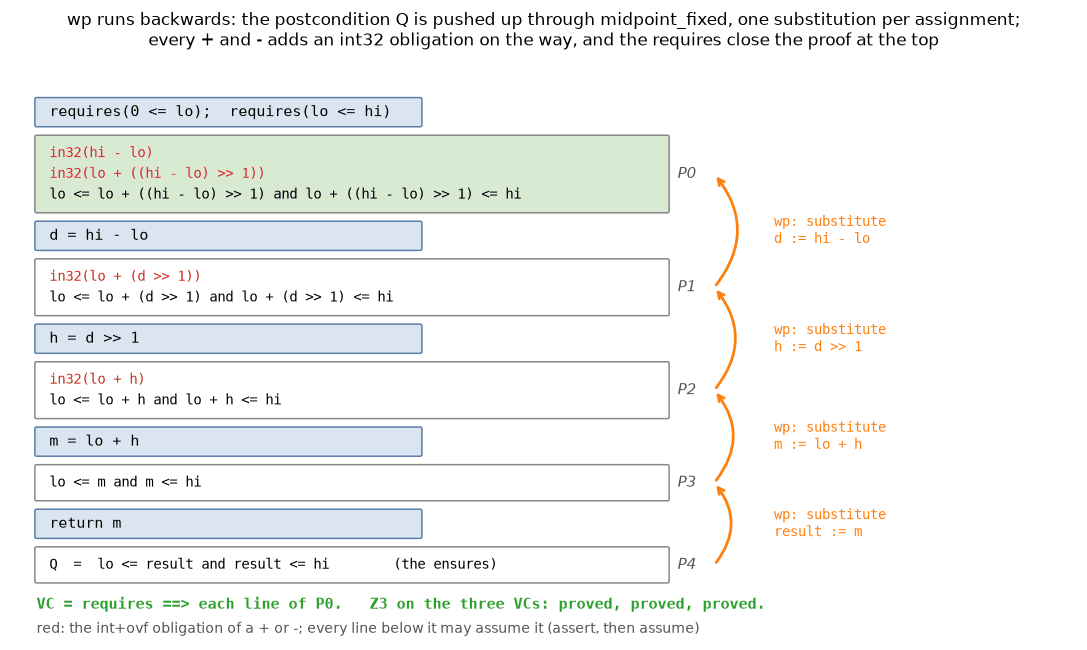

wp(x = a + b, 2 * x > 0):  text replacement -> '2 * a + b > 0' (precedence lost);  AST -> '2 * (a + b) > 0'
wp(x = 1, 'xs + x > max'): text replacement -> '1s + 1 > ma1';  AST -> 'xs + 1 > max'

stale_copy: k = t is copied BEFORE the loop changes t, so the function returns 0, not n.
  postcondition VC with fresh loop-head names:  n >= 0 and (0 <= t@6 and t@6 <= n) and not t@6 < n  ==>  0 == n
  the same VC when the loop's t is not renamed: n >= 0 and (0 <= 0 and 0 <= n) and not 0 < n  ==>  0 == n
  with fresh names: counterexample [n=1 | loop head: t@6=1 -> run_minipy ('ensures_fail', 0): real bug]
  without:          proved   <- UNSOUND: 'proved' for a function wrong for every n > 0
Substitute on trees, and give the state a loop havocs names the program cannot contain.


In [72]:
# 6.2 continued: wp at work, step by step, and why substitution must be done on trees with fresh names.
_s6_STEPS_SRC = '''
def midpoint_steps(lo, hi):
    requires(0 <= lo)
    requires(lo <= hi)
    ensures(lo <= result and result <= hi)
    d = hi - lo
    h = d >> 1
    m = lo + h
    return m
'''

_s6_STALE_SRC = '''
def stale_copy(n):
    requires(n >= 0)
    ensures(result == n)
    t = 0
    k = t
    while t < n:
        invariant(0 <= t and t <= n)
        t = t + 1
    return k
'''


def _s6_wp_trace(src, semantics):
    '''The obligations at every program point of a loop-free body: wp of each suffix of the statements.'''
    fn = parse_minipy(src, semantics)
    info, body = _s6_function(fn)
    cx = dict(semantics=semantics, ensures=info['ensures'], rename=True, loops={})
    points = [_s6_wp(body[i:], [], cx) for i in range(len(body) + 1)]
    return fn, info, body, points


def _s6_draw_wp_trace():
    '''The proof outline {P0} S1 {P1} S2 ... {Q}, every P_i computed by _s6_wp from the one below it.'''
    fn, info, body, points = _s6_wp_trace(_s6_STEPS_SRC, 'int+ovf')
    res = verify(fn, 'int+ovf', verbose=False)
    subst = ["d := hi - lo", "h := d >> 1", "m := lo + h", "result := m"]
    X0, X1, LINE, GAP = 0.3, 7.7, 0.27, 0.12
    items = [('code', "requires(0 <= lo);  requires(lo <= hi)", None)]       # top to bottom
    for i, obls in enumerate(points):
        if i == len(body):
            lines = [("Q  =  " + _s6_show(info['ensures'][0]) + "        (the ensures)", "black")]
        else:
            lines = [(_s6_show(g), "#d62728" if "overflow" in n else "black") for n, A, g in obls]
        items.append(('point', lines, i))
        if i < len(body):
            items.append(('code', ast.unparse(body[i]), i))
    sizes = [0.4 if kind == 'code' else LINE * len(x) + 0.16 for kind, x, _ in items]
    total = sum(sizes) + GAP * (len(items) - 1)
    fig, ax = plt.subplots(figsize=(12.5, 6.9))
    ax.set_xlim(0, 12.5)
    ax.set_ylim(-0.75, total + 0.55)
    ax.axis("off")
    y, centers = total, {}
    for (kind, x, i), s in zip(items, sizes):
        top, mid = y, y - s / 2
        if kind == 'code':
            ax.add_patch(FancyBboxPatch((X0, mid - 0.17), 4.5, 0.34, boxstyle="round,pad=0.02", fc="#dbe5f1",
                                        ec="#5b7fa8"))
            ax.text(X0 + 0.15, mid, x, ha="left", va="center", family="monospace", fontsize=10)
        else:
            ax.add_patch(FancyBboxPatch((X0, top - s), X1 - X0, s, boxstyle="round,pad=0.02",
                                        fc="#d9ead3" if i == 0 else "white", ec="#888888"))
            for k, (txt, col) in enumerate(x):
                ax.text(X0 + 0.15, top - 0.215 - LINE * k, txt, ha="left", va="center", family="monospace",
                        fontsize=9, color=col)
            ax.text(X1 + 0.12, mid, f"P{i}", ha="left", va="center", fontsize=10, color="#555555",
                    style="italic")
            centers[i] = mid
        y -= s + GAP
    for j in range(len(body)):                       # P_{j+1} --wp(statement j)--> P_j
        ax.annotate("", xy=(X1 + 0.55, centers[j]), xytext=(X1 + 0.55, centers[j + 1]),
                    arrowprops=dict(arrowstyle="->", color="#ff7f0e", lw=1.8,
                                    connectionstyle="arc3,rad=0.4"))
        ax.text(X1 + 1.25, (centers[j] + centers[j + 1]) / 2, f"wp: substitute\n{subst[j]}", ha="left",
                va="center", fontsize=9, family="monospace", color="#ff7f0e")
    verdicts = ", ".join(s for s, _ in res.values())
    ax.text(X0, -0.3, f"VC = requires ==> each line of P0.   Z3 on the three VCs: {verdicts}.",
            fontsize=9.5, color="#2ca02c", va="center", family="monospace", fontweight="bold")
    ax.text(X0, -0.62, "red: the int+ovf obligation of a + or -; every line below it may assume it "
            "(assert, then assume)", fontsize=9, color="#555555", va="center")
    ax.set_title("wp runs backwards: the postcondition Q is pushed up through midpoint_fixed, one "
                 "substitution per assignment;\nevery + and - adds an int32 obligation on the way, and the "
                 "requires close the proof at the top", fontsize=11)
    plt.show()


def _s6_substitution_pitfalls():
    '''Two ways a text-based wp goes wrong, and the AST version that does not.'''
    q, e = "2 * x > 0", "a + b"
    as_text = q.replace("x", e)
    as_tree = ast.unparse(_s6_subst(ast.parse(q, mode='eval').body, {'x': ast.parse(e, mode='eval').body}))
    print(f"wp(x = {e}, {q}):  text replacement -> {as_text!r} (precedence lost);  AST -> {as_tree!r}")
    q2 = "xs + x > max"
    print(f"wp(x = 1, {q2!r}): text replacement -> {q2.replace('x', '1')!r};  AST -> "
          f"{ast.unparse(_s6_subst(ast.parse(q2, mode='eval').body, {'x': ast.Constant(1)}))!r}")
    # capture: the loop's universally quantified state must get fresh names
    fn = parse_minipy(_s6_STALE_SRC, 'int')
    good = _s6_vcgen_tree(fn, 'int', rename=True)
    bad = _s6_vcgen_tree(fn, 'int', rename=False)
    post = lambda vcs: next((A, g) for n, A, g in vcs if 'postcondition' in n)
    print("\nstale_copy: k = t is copied BEFORE the loop changes t, so the function returns 0, not n.")
    print("  postcondition VC with fresh loop-head names: ", _s6_vc_text(*post(good)))
    print("  the same VC when the loop's t is not renamed:", _s6_vc_text(*post(bad)))
    r_good = _s6_discharge(fn, good, 'int')
    r_bad = _s6_discharge(fn, bad, 'int')
    pname = next(n for n in r_good if 'postcondition' in n)
    print(f"  with fresh names: {r_good[pname][0]} [{_s6_explain(fn, r_good[pname][1], 'int')}]" if
          r_good[pname][1] else f"  with fresh names: {r_good[pname][0]}")
    print(f"  without:          {r_bad[pname][0]}" + ("   <- UNSOUND: 'proved' for a function wrong for every n > 0"
                                                       if r_bad[pname][0] == 'proved' else ""))


if HAVE_Z3:
    _s6_draw_wp_trace()
    _s6_substitution_pitfalls()
    print("Substitute on trees, and give the state a loop havocs names the program cannot contain.")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

The figure is the whole of wp for straight-line code: each assignment substitutes its right-hand side, so `m`,
`h` and `d` disappear one by one, each `+` or `-` adds an int32 obligation (red) that the lines below may assume,
and at the top the requires turn P0 into three closed questions about `lo` and `hi`. The capture experiment is
the kept failure. With fresh names the postcondition VC reads "for *any* loop-head value `t@6` with
`0 <= t@6 <= n` and `not t@6 < n`: `0 == n`", false for every `n > 0`, and Z3's counterexample replays as
`ensures_fail`. Without renaming, the backward substitution `t := 0` also rewrites the loop's `t`, the loop-head
state collapses into the pre-loop state, and the VC becomes valid: an unsound "proved" for a function that is
wrong on every positive input. Text substitution fails more visibly (`2 * a + b`, `1s + 1 > ma1`). Hence VC
generators substitute on syntax trees and invent names the program cannot contain.

**The cross-check** uses that wp is exact on loop-free code: the VCs must agree with the interpreter in both
directions (every counterexample replays as the same failure at the same line; a program whose VCs all prove
passes every test). Random programs over two ints and an array exercise requires, ensures, nested `if`,
`assert`, `assume`, early `return`, lazy `and`/`or`, conditional expressions and unguarded subscripts under
`'int'`, `'int+ovf'` and `'bv8'`, plus the toy backend on array-free ones.

In [73]:
# 6.2 continued: the cross-check of vcgen + verify against the interpreter on random loop-free programs.
_s6_SEED_XCHECK = 606
_s6_N_PROGRAMS = 40         # random loop-free programs per (semantics, backend); a quarter of that for 'toy'
_s6_N_INPUTS = 40           # random + edge inputs per program (the testing side of the cross-check)
_s6_KIND_OF = {'postcondition': 'ensures_fail', 'assertion': 'assert_fail', 'index out of bounds': 'bounds',
               'overflow': 'overflow', 'literal': 'overflow'}     # VC kind -> run_minipy outcome


def _s6_rand_int(rnd, names, depth, cfg):
    '''A random MiniPy int expression (source text) over `names`. cfg: big literals that fit the semantics, and
    whether the array a exists.'''
    if depth == 0 or rnd.random() < 0.25:
        r = rnd.random()
        if r < 0.6:
            return rnd.choice(names)
        if r < 0.85:
            return str(rnd.randint(-5, 5))
        if r < 0.9 and cfg['arrays']:
            return f"a[{rnd.choice(names)}]"                       # unguarded: may be out of bounds
        return str(rnd.choice(cfg['big']))
    sub = lambda: _s6_rand_int(rnd, names, depth - 1, cfg)
    r = rnd.random()
    if r < 0.5:
        return f"({sub()} {rnd.choice(['+', '-', '*'] if rnd.random() < 0.3 else ['+', '-'])} {sub()})"
    if r < 0.6:
        return f"({sub()} >> {rnd.randint(0, 3)})"
    if r < 0.7:
        return f"(-{sub()})"
    if r < 0.85 or not cfg['arrays']:
        return f"({sub()} if {_s6_rand_cond(rnd, names, depth - 1, cfg)} else {sub()})"
    return f"(a[{sub()}] if 0 <= {sub()} < len(a) else len(a))"     # guarded: the bounds VC sees the guard


def _s6_rand_cond(rnd, names, depth, cfg):
    sub = lambda: _s6_rand_int(rnd, names, max(depth - 1, 0), cfg)
    op = lambda: rnd.choice(['<', '<=', '>', '>=', '==', '!='])
    r = rnd.random()
    if r < 0.6:
        return f"{sub()} {op()} {sub()}"
    if r < 0.8:
        return f"({sub()} {op()} {sub()} and {sub()} {op()} {sub()}) or not {sub()} {op()} {sub()}"
    return f"{sub()} <= {sub()} <= {sub()}"


def _s6_random_program(rnd, sem, arrays=True):
    '''A random loop-free MiniPy function of x, y (and an array a): requires/ensures, if/else, assert,
    assume and an early return -- every construct of the loop-free part of vcgen.'''
    cfg = dict(arrays=arrays, big=[127, -127, 64] if sem_width(sem) == 8 else [INT32_MAX, INT32_MIN, 65536, 46341])
    I = lambda names, d=2: _s6_rand_int(rnd, names, d, cfg)
    C = lambda names: _s6_rand_cond(rnd, names, 1, cfg)
    P = ['x', 'y']
    L = [f"    requires({C(P)})"] if rnd.random() < 0.3 else []
    if rnd.random() < 0.5:                                         # small inputs: overflow becomes rare
        L.append("    requires(-99 <= x <= 99 and -99 <= y <= 99)")
    e = I(P, 1)
    post = C(P + ['result']) if rnd.random() < 0.3 else f"result <= {e} or result > {e}"    # often valid
    L += [f"    ensures({post})", f"    u = {I(P)}", f"    if {C(P + ['u'])}:", f"        v = {I(P + ['u'])}"]
    if rnd.random() < 0.2:
        L.append(f"        assert {C(P + ['u', 'v'])}")
    L += ["    else:", f"        v = {I(P + ['u'])}"]
    if rnd.random() < 0.4:
        L += [f"        if {C(P + ['u', 'v'])}:", f"            return {I(P + ['v'])}"]
    if rnd.random() < 0.3:
        L.append(f"    assume({C(P + ['u', 'v'])})")
    L.append(f"    return {I(P + ['u', 'v'])}")
    return f"def f(x, y{', a: list' if arrays else ''}):\n" + "\n".join(L) + "\n"


def _s6_inputs(rnd, sem, n, arrays=True):
    '''Test inputs: edge values (0, ±1, the extremes), small ints and uniform ones; arrays of length 0..3.'''
    w = sem_width(sem) or 32
    lo, hi = -(1 << (w - 1)), (1 << (w - 1)) - 1
    edge = [0, 1, -1, 2, lo, hi, lo + 1, hi - 1, hi >> 1]
    pick = lambda: (rnd.choice(edge) if rnd.random() < 0.4 else rnd.randint(-6, 6) if rnd.random() < 0.5
                    else rnd.randint(lo, hi))
    out = []
    for _ in range(n):
        t = dict(x=pick(), y=pick())
        if arrays:
            t['a'] = [pick() for _ in range(rnd.randint(0, 3))]
        out.append(t)
    return out


def _s6_cross_check():
    '''For loop-free code wp is EXACT, so VCs and interpreter must agree in both directions:
    (1) every counterexample the solver finds replays in run_minipy as the same failure at the same line;
    (2) when every VC is proved (or vacuous), no tested input fails. -> number of disagreements.'''
    rnd = random.Random(_s6_SEED_XCHECK)
    rows, bad = [], 0
    for sem, backend in (('int', 'z3'), ('int+ovf', 'z3'), ('bv8', 'z3'), ('bv8', 'toy')):
        n_prog = _s6_N_PROGRAMS if backend == 'z3' else _s6_N_PROGRAMS // 4
        st = Counter()
        for _ in range(n_prog):
            arrays = backend == 'z3'
            fn = parse_minipy(_s6_random_program(rnd, sem, arrays), sem)
            res = verify(fn, sem, backend=backend, timeout_ms=2000, verbose=False)
            st['VCs'] += len(res)
            st['unknown'] += sum(s == 'unknown' for s, _ in res.values())
            failing = {k: v for k, v in res.items() if v[0] == 'counterexample'}
            for name, (_, cex) in failing.items():
                outcome, value = _s6_replay(fn, cex, sem)
                kind = next(v for k, v in _s6_KIND_OF.items() if k in name)
                line = int(name.split(':')[0].split()[1])
                if outcome == 'too long to replay':
                    st['long'] += 1
                    continue
                ok = outcome == kind and (kind == 'ensures_fail' or value == line)
                st['replayed'] += ok
                st['not replayed'] += not ok
            tests = _s6_inputs(rnd, sem, _s6_N_INPUTS, arrays)
            fails = sum(_s6_run_failed(run_minipy(fn, t, sem)[0]) for t in tests)
            if failing:
                st['buggy'] += 1
                st['caught'] += fails > 0
            elif all(s in ('proved', 'vacuous') for s, _ in res.values()):
                st['proved'] += 1
                st['proved but fails'] += fails > 0
        rows.append([sem, backend, n_prog, st['VCs'], st['proved'], st['buggy'], st['replayed'],
                     st['not replayed'], st['long'], st['proved but fails'], st['caught'], st['unknown']])
        bad += st['not replayed'] + st['proved but fails']
    show_table(["semantics", "backend", "programs", "VCs", "proved", "buggy", "cex replayed",
                "cex NOT replayed", "array too long", "proved, yet a test fails",
                f"buggy, caught by {_s6_N_INPUTS} tests", "unknown"], rows)
    return bad


if HAVE_Z3:
    _s6_bad, _s6_dt = timed(_s6_cross_check)
    print(f"{_s6_bad} disagreements between the VCs and run_minipy (~{_s6_dt:.1f} s)")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

semantics  backend  programs  VCs  proved  buggy  cex replayed  cex NOT replayed  array too long  proved, yet a test fails  buggy, caught by 40 tests  unknown
--------------------------------------------------------------------------------------------------------------------------------------------------------------
int        z3       40        164  9       31     68            0                 1               0                         25                         0      
int+ovf    z3       40        361  8       32     128           0                 1               0                         30                         0      
bv8        z3       40        161  9       31     67            0                 0               0                         29                         0      
bv8        toy      10        17   5       5      5             0                 0               0                         4                          0      
0 disagreements between the VCs and run_minipy

The cross-check found no disagreement in either direction. The few counterexamples marked "array too long" need
more than 200,000 elements (an index forced past a large literal) and are not replayed. Most of these random bugs
are dense, so 40 tests catch them; testing misses §1's kind, a needle like `INT32_MIN` or the midpoint overflow
that realistic test distributions never draw.

**Registered prediction.** Bloch's fix `low + ((high - low) / 2)`, written here `lo + ((hi - lo) >> 1)` (§1), is
*the* safe midpoint, so *dropping
`requires(0 <= lo)` from `midpoint_fixed` leaves it verified.*

In [74]:
# 6.2 continued: the registered prediction on the fixed midpoint without requires(0 <= lo).
if HAVE_Z3:
    _s6_NO_LO_SRC = MIDPOINT_FIXED_SRC.replace("    requires(0 <= lo)\n", "")
    _s6_no_lo = verify(_s6_NO_LO_SRC, 'int+ovf')
    _s6_no_lo_bv = verify(_s6_NO_LO_SRC, 'bv32', verbose=False)
    _s6_failed = [n for n, (s, _) in _s6_no_lo.items() if s == 'counterexample']
    _s6_failed_bv = [n for n, (s, _) in _s6_no_lo_bv.items() if s == 'counterexample']
    print(f"\nregistered prediction: without requires(0 <= lo) the fixed midpoint still verifies | measured: "
          f"int+ovf fails {_s6_failed}, bv32 fails {_s6_failed_bv} | verdict: "
          f"{'RIGHT' if not (_s6_failed or _s6_failed_bv) else 'WRONG'} -- hi - lo overflows once lo may be negative; "
          f"the fix was only ever correct relative to its precondition")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

verify(midpoint_fixed, 'int+ovf', backend='z3'): 1 counterexample, 2 proved
VC                                                           status          counterexample -> replayed with run_minipy                  
-----------------------------------------------------------------------------------------------------------------------------------------
line 4: attempt to subtract with overflow: hi - lo           counterexample  lo=-2147483648, hi=0 -> run_minipy ('overflow', 4): real bug
line 4: attempt to add with overflow: lo + ((hi - lo) >> 1)  proved                                                                      
line 3: postcondition (return at line 4)                     proved                                                                      

registered prediction: without requires(0 <= lo) the fixed midpoint still verifies | measured: int+ovf fails ['line 4: attempt to subtract with overflow: hi - lo'], bv32 fails ['line 3: postcondition (return at line 4)'] | verdict: W

Wrong. Once `lo` may be negative, `hi - lo` can exceed `INT32_MAX`: under `'int+ovf'` the subtraction's own
obligation fails, under 32-bit wrap the postcondition does, and both counterexamples replay. The fix was only
ever correct *relative to its precondition* (§2.1); the verifier makes you write it down, and every caller must
then prove it.

### 6.3 Loops: true invariants and inductive invariants

The loop rule produces three VCs per invariant $I$, guard $b$, body $S$ and continuation $Q$:

$$\underbrace{\mathit{Pre} \Rightarrow I}_{\text{on entry}}\qquad
\underbrace{I(s) \wedge b(s) \wedge s \xrightarrow{S} s' \;\Rightarrow\; I(s')}_{\text{maintained}}\qquad
\underbrace{I(s) \wedge \neg b(s) \Rightarrow Q(s)}_{\text{exit}}$$

The middle VC quantifies over *every* state satisfying $I$, not just the reachable ones: after the havoc, $I$ is
all the verifier knows about the loop head. A property can therefore hold on every reachable state, an
**invariant**, and still fail this VC. The failing state is a **counterexample to induction (CTI)**: it satisfies
$I$, and one iteration from it leaves $I$. With $R$ the reachable states and $P$ the property, a proof needs an
**inductive invariant**: $R \subseteq I \subseteq P$ *and* $I$ closed under the body. For an ML engineer: it is a
certificate checked one step at a time, as a Lyapunov function proves stability without simulating a trajectory.

The x,y loop (§8 and §13 return to it): `x, y = 1, 0`, then `x = x + y; y = y + 1` while `y < n`, then
`assert x >= y`. The reachable states $(1,0), (1,1), (2,2), (4,3), (7,4), \dots$ all satisfy $x \ge y$.

**Registered prediction:** *`invariant(x >= y)` is inductive, so `verify` proves `XY_SRC` as written.*

verify(xy_loop, 'int', backend='z3'): 2 proved, 1 counterexample
VC                                             status          counterexample -> replayed with run_minipy                                                   
------------------------------------------------------------------------------------------------------------------------------------------------------------
loop 0 (line 4): invariant on entry: x >= y    proved                                                                                                       
loop 0 (line 4): invariant maintained: x >= y  counterexample  n=1 | loop head: x@4=0, y@4=0 -> run_minipy ('return', 1): CTI, not reached from these inputs
line 8: assertion: x >= y                      proved                                                                                                       
verify(xy_loop, 'int', backend='z3'): 7 proved
VC                                             status  counterexample -> replayed with run_minipy
-----

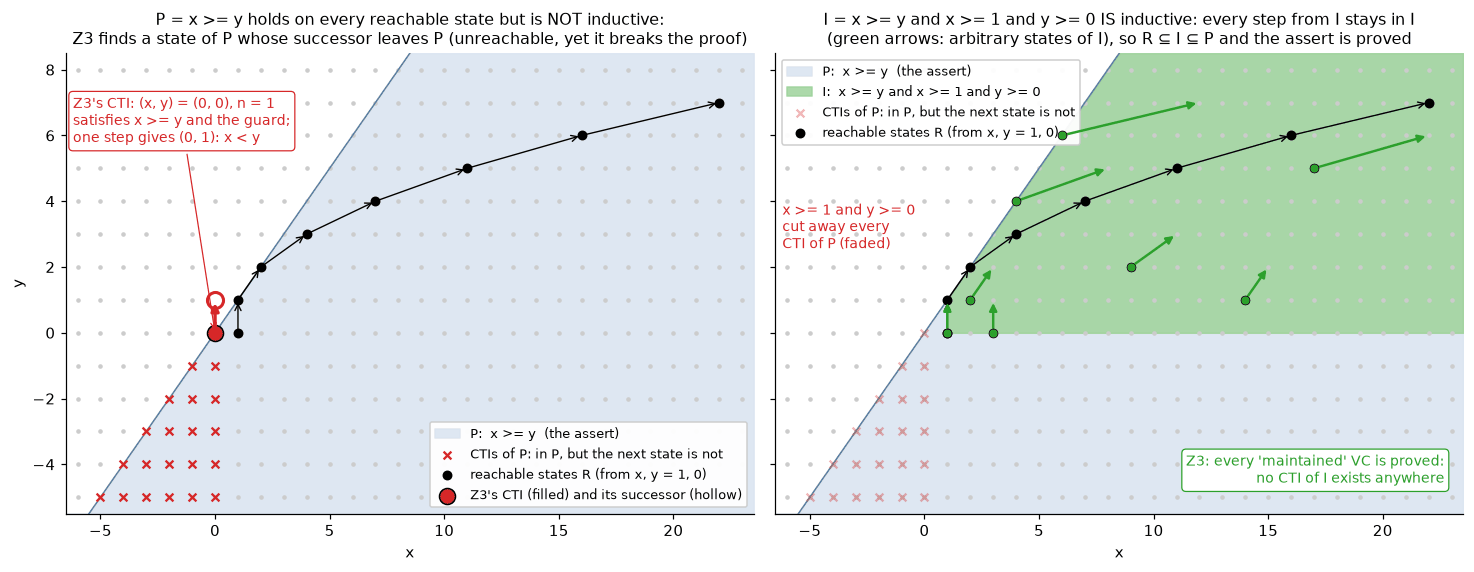

under int+ovf the same invariant leaves ['line 6: attempt to add with overflow: x + y'] open; and the overflow is real: xy_loop(65537) -> ('overflow', 6), xy_loop(65536) -> ('return', 2147450881)
The figure is the whole of loop verification in one picture: the proof needs a set that contains every
reachable state AND is closed under the loop body. P is the first but not the second; I is both.


In [75]:
# 6.3 The x,y loop: a true invariant that is not inductive, the CTI Z3 finds, and the strengthening.
XY_SRC = '''
def xy_loop(n):
    x = 1
    y = 0
    while y < n:
        invariant(x >= y)
        x = x + y
        y = y + 1
    assert x >= y
    return x
'''
_s6_XY_STRONG = {0: ['x >= y', 'x >= 1', 'y >= 0']}
_s6_BOX = dict(x=(-6, 23), y=(-5, 8))          # the window the figure draws (integer states)


def _s6_find_cti(src, semantics, name_part, invariants=None, box=None):
    '''A counterexample to the VC whose name contains name_part, optionally restricted to a box of values
    {var: (lo, hi)} for parameters and loop-head variables (any CTI is as good as another; this one fits the
    figure). -> dict or None.'''
    fn = _s6_tree(src, semantics, invariants)
    info = minipy_info(fn)
    copies = [c for n, c in _s6_group(_s6_vcgen_tree(fn, semantics)).items() if name_part in n][0]
    env, dom = _s6_z3_env(copies, info, semantics)
    s = z3.Solver()
    s.set('timeout', 5000)
    s.add(*dom)
    tr = lambda e: expr_to_z3(e, env, semantics)
    s.add(z3.Or(*[z3.And(*[tr(a) for a in A], z3.Not(tr(g))) for A, g in copies]))
    for x, (lo, hi) in (box or {}).items():          # a parameter by its name, a loop variable by x -> x@L
        key = x if x in info['params'] else next(k for k in env if k.split('@')[0] == x and '@' in k)
        s.add(env[key] >= lo, env[key] <= hi)
    if s.check() != z3.sat:
        return None
    shown = set().union(*[_s6_names(e) for A, g in copies for e in A + [g]])
    return _s6_decode(s.model(), env, info, shown)


def _s6_xy_states():
    '''Brute force over the window: which states satisfy P, I; which are CTIs of P (in P, successor not in P);
    which are CTIs of I; and the reachable states (x, y) = (1, 0), (1, 1), (2, 2), (4, 3), ...'''
    (x0, x1), (y0, y1) = _s6_BOX['x'], _s6_BOX['y']
    states = [(x, y) for x in range(x0, x1 + 1) for y in range(y0, y1 + 1)]
    P = lambda x, y: x >= y
    I = lambda x, y: x >= y and x >= 1 and y >= 0
    step = lambda x, y: (x + y, y + 1)                  # the loop body (the guard y < n holds for a large n)
    cti_P = [s for s in states if P(*s) and not P(*step(*s))]
    cti_I = [s for s in states if I(*s) and not I(*step(*s))]
    reach, s = [], (1, 0)
    while s[0] <= x1:
        reach.append(s)
        s = step(*s)
    return states, cti_P, cti_I, reach, step


def _s6_xy_demo():
    weak = verify(XY_SRC, 'int')
    strong = verify(XY_SRC, 'int', invariants=_s6_XY_STRONG)
    name = next(n for n in weak if 'maintained' in n)
    status, cex = weak[name]
    half = verify(XY_SRC, 'int', invariants={0: ['x >= y', 'x >= 1']}, verbose=False)
    h_name, (h_status, h_cex) = next((n, v) for n, v in half.items() if v[0] != 'proved')
    print(f"halfway: x >= y and x >= 1 -> '{h_name}': {h_status}, loop-head state "
          f"{ {k: v for k, v in h_cex.items() if '@' in k} } (y < 0 lets x + y drop below 1)")
    runs = [run_minipy(XY_SRC, (n,), 'int') for n in range(0, 41)]
    print(f"run_minipy(xy_loop, n) for n = 0..40 (checks x >= y at every loop-head visit): "
          f"{Counter(o for o, _ in runs)}")
    states, cti_P, cti_I, reach, step = _s6_xy_states()
    L = minipy_info(XY_SRC)['loops'][0]['lineno']
    cti = _s6_find_cti(XY_SRC, 'int', 'maintained', box=_s6_BOX)
    c = (cti[f'x@{L}'], cti[f'y@{L}'])
    print(f"a CTI inside the plotted window (Z3): (x, y) = {c}, n = {cti['n']} -> successor {step(*c)}; "
          f"brute force over the {len(states)} window states finds {len(cti_P)} CTIs of x >= y "
          f"(Z3's is among them: {c in cti_P}) and {len(cti_I)} CTIs of the strengthened invariant")
    all_proved = all(s == 'proved' for s, _ in strong.values())
    print(f"\nregistered prediction: x >= y is inductive | measured: '{name}' -> {status} with loop-head state "
          f"{ {k: v for k, v in cex.items() if '@' in k} } (x = {cex[f'x@{L}']}: outside R, which the strengthened "
          f"proof puts at x >= 1) | verdict: "
          f"{'RIGHT' if status == 'proved' else 'WRONG'} -- true on every reachable state, but a state that "
          f"satisfies it and steps out of it exists; adding x >= 1 and y >= 0 makes all "
          f"{len(strong)} VCs {'proved' if all_proved else 'NOT all proved'}")
    return states, cti_P, cti_I, reach, step, c, cti['n'], all_proved


def _s6_draw_xy(states, cti_P, cti_I, reach, step, c, n_cti, strong_ok):
    (x0, x1), (y0, y1) = _s6_BOX['x'], _s6_BOX['y']
    xs = np.linspace(x0 - 0.5, x1 + 0.5, 400)
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.3), sharey=True)
    for k, ax in enumerate(axes):
        ax.scatter(*zip(*states), s=4, color="#cccccc", zorder=1)
        ax.fill_between(xs, y0 - 0.5, np.minimum(xs, y1 + 0.5), color="#dbe5f1", alpha=0.9, zorder=0,
                        label="P:  x >= y  (the assert)")
        ax.plot(xs, xs, color="#5b7fa8", lw=1, zorder=1)
        if k == 1:
            m = xs >= 1
            ax.fill_between(xs[m], 0, np.minimum(xs[m], y1 + 0.5), color="#9fd39a", alpha=0.85, zorder=0,
                            label="I:  x >= y and x >= 1 and y >= 0")
        ax.scatter(*zip(*cti_P), marker="x", s=26, color="#d62728", alpha=1 if k == 0 else 0.35, zorder=3,
                   label="CTIs of P: in P, but the next state is not")
        for a, b in zip(reach, reach[1:]):
            ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", color="black", lw=0.9), zorder=4)
        ax.scatter(*zip(*reach), s=30, color="black", zorder=5, label="reachable states R (from x, y = 1, 0)")
        ax.set_xlim(x0 - 0.5, x1 + 0.5)
        ax.set_ylim(y0 - 0.5, y1 + 0.5)
        ax.set_xlabel("x")
        ax.grid(False)
    axes[0].set_ylabel("y")
    ax = axes[0]
    nxt = step(*c)
    ax.scatter([c[0]], [c[1]], s=110, facecolor="#d62728", edgecolor="black", zorder=6,
               label="Z3's CTI (filled) and its successor (hollow)")
    ax.scatter([nxt[0]], [nxt[1]], s=110, facecolor="white", edgecolor="#d62728", lw=2, zorder=6)
    ax.annotate("", xy=nxt, xytext=c, arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=2.2), zorder=7)
    ax.annotate(f"Z3's CTI: (x, y) = {c}, n = {n_cti}\nsatisfies x >= y and the guard;\none step gives "
                f"{nxt}: x < y", xy=c, xytext=(x0 - 0.2, y1 - 2.2), fontsize=9, color="#d62728",
                arrowprops=dict(arrowstyle="->", color="#d62728", lw=0.8), zorder=7,
                bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#d62728", lw=0.8))
    ax.set_title("P = x >= y holds on every reachable state but is NOT inductive:\nZ3 finds a state of P "
                 "whose successor leaves P (unreachable, yet it breaks the proof)", fontsize=10.5)
    ax.legend(loc="lower right", fontsize=8.3, framealpha=0.95)
    ax = axes[1]
    samples = [(1, 0), (3, 0), (2, 1), (6, 6), (9, 2), (14, 1), (4, 4), (17, 5)]
    for s in samples:                                   # a few arbitrary states of I: each step stays in I
        t = step(*s)
        ax.annotate("", xy=t, xytext=s, arrowprops=dict(arrowstyle="-|>", color="#2ca02c", lw=1.6), zorder=6)
        ax.scatter([s[0]], [s[1]], s=34, facecolor="#2ca02c", edgecolor="black", lw=0.5, zorder=6)
    ax.text(x1 - 0.3, y0 + 0.3, ("Z3: every 'maintained' VC is proved:\nno CTI of I exists anywhere"
                                 if strong_ok else "Z3: NOT all VCs proved"), ha="right", va="bottom",
            fontsize=9, color="#2ca02c", bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#2ca02c", lw=0.8))
    ax.text(x0 - 0.2, 3.2, "x >= 1 and y >= 0\ncut away every\nCTI of P (faded)", fontsize=9,
            color="#d62728", va="center")
    ax.set_title("I = x >= y and x >= 1 and y >= 0 IS inductive: every step from I stays in I\n"
                 "(green arrows: arbitrary states of I), so R ⊆ I ⊆ P and the assert is proved", fontsize=10.5)
    ax.legend(loc="upper left", fontsize=8.3, framealpha=0.95)
    plt.tight_layout()
    plt.show()


if HAVE_Z3:
    _s6_xy = _s6_xy_demo()
    _s6_draw_xy(*_s6_xy)
    _s6_xy_ovf = verify(XY_SRC, 'int+ovf', invariants=_s6_XY_STRONG, verbose=False)
    _s6_xy_bad = [n for n, (s, _) in _s6_xy_ovf.items() if s != 'proved']
    print(f"under int+ovf the same invariant leaves {_s6_xy_bad} open; and the overflow is real: "
          f"xy_loop(65537) -> {run_minipy(XY_SRC, (65537,), 'int+ovf', max_steps=10 ** 6)}, "
          f"xy_loop(65536) -> {run_minipy(XY_SRC, (65536,), 'int+ovf', max_steps=10 ** 6)}")
    print("The figure is the whole of loop verification in one picture: the proof needs a set that contains every")
    print("reachable state AND is closed under the loop body. P is the first but not the second; I is both.")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

Wrong, and the figure shows why. Every reachable state (black) lies inside $P = \{x \ge y\}$, and 41 runs that
check the invariant at every loop-head visit never fail: *testing* an invariant cannot reveal that it is not
inductive. But $P$ also holds states no run reaches, and the body maps $(x, y)$ to $(x + y, y + 1)$, which
violates $x \ge y$ exactly when $x < 1$. Z3 returns one such state (printed above), and brute force over the
window agrees. The CTI says what to exclude: adding $x \ge 1$ yields a new CTI (the "halfway" line, $y < 0$ lets
$x + y$ drop below 1), and adding $y \ge 0$ closes the set; all seven VCs prove. Propose, get a CTI, strengthen:
IC3 automates this loop over finite state (§8). Houdini (§13) runs the dual loop over a candidate set: it starts
from the conjunction of all candidates and deletes every one a CTI refutes. Under `'int+ovf'` the same
invariant leaves the overflow of `x + y` open because nothing bounds `x`, and that is a real bug:
`xy_loop(65537)` overflows, `xy_loop(65536)` does not (§9's interval analysis flags it too).

### 6.4 `isqrt`: nonlinear arithmetic and machine integers

```python
def isqrt(n):                          # ISQRT_SRC
    requires(n >= 0)
    ensures(result * result <= n and n < (result + 1) * (result + 1))
    r = 0
    while (r + 1) * (r + 1) <= n:
        invariant(r >= 0)
        invariant(r * r <= n)
        decreases(n - r * r)
        r = r + 1
    return r
```

Its VCs multiply variables, and nonlinear integer arithmetic is undecidable (the MRDP theorem; §4's map), so Z3
relies on incomplete heuristics. Machine integers make the problem finite: `'bv32'` is a finite theory, and under
`'int+ovf'` every variable is confined to int32. The cell runs both machine semantics, adds the precondition the
overflow obligation asks for, and, for the bit-vector versions, with and without a bound on `r`.

**Registered prediction:** *(a) Z3 proves every VC of `isqrt` under `'int'`, undecidability notwithstanding; (b)
the bit-precise `'bv32'` version, which is decidable, is no harder: given the same bounds, it proves within 2
seconds per VC.*

In [76]:
# 6.4 isqrt: nonlinear arithmetic under three semantics, and the registered prediction.
ISQRT_SRC = '''
def isqrt(n):
    requires(n >= 0)
    ensures(result * result <= n and n < (result + 1) * (result + 1))
    r = 0
    while (r + 1) * (r + 1) <= n:
        invariant(r >= 0)
        invariant(r * r <= n)
        decreases(n - r * r)
        r = r + 1
    return r
'''
_s6_ROOT = 46340                                 # 46340**2 <= INT32_MAX < 46341**2
_s6_ROOT16 = 181                                 # 181**2 <= INT16_MAX < 182**2
_s6_ISQRT_BOUNDED = ISQRT_SRC.replace("    requires(n >= 0)\n",
                                      f"    requires(n >= 0)\n    requires(n < {_s6_ROOT} * {_s6_ROOT})\n")
_s6_ISQRT16 = ISQRT_SRC.replace("    requires(n >= 0)\n",
                                f"    requires(n >= 0)\n    requires(n < {_s6_ROOT16} * {_s6_ROOT16})\n")
_s6_SIZE_BOUND = {0: ['r >= 0', f'r <= {_s6_ROOT}', 'r * r <= n']}          # the written invariants + r's size
_s6_SIZE_BOUND16 = {0: ['r >= 0', f'r <= {_s6_ROOT16}', 'r * r <= n']}
_s6_BV_TIMEOUT_MS = 2000                         # the budget for the bit-precise runs below


def _s6_counts(res):
    c = Counter(s for s, _ in res.values())
    return f"{c['proved'] + c['vacuous']}/{len(res)} proved" + (f", {c['counterexample']} failed" if
                                                                c['counterexample'] else "") + \
        (f", {c['unknown']} unknown" if c['unknown'] else "")


def _s6_all_proved(res):
    return all(s in ('proved', 'vacuous') for s, _ in res.values())


def _s6_isqrt_semantics():
    '''verify isqrt under each semantics. Rows 5 and 7 bound n and keep the written invariants; rows 6, 8 and 9
    also bound r. -> {row number: (fn, result)}'''
    B, B16 = f"{_s6_ROOT}*{_s6_ROOT}", f"{_s6_ROOT16}*{_s6_ROOT16}"
    runs = [
        ("as written", ISQRT_SRC, 'int', 'z3', None, 5000),
        ("as written", ISQRT_SRC, 'int+ovf', 'z3', None, 5000),
        ("as written", ISQRT_SRC, 'bv32', 'z3', None, 5000),
        (f"+ requires(n < {B})", _s6_ISQRT_BOUNDED, 'int+ovf', 'z3', None, 5000),
        (f"+ requires(n < {B})", _s6_ISQRT_BOUNDED, 'bv32', 'z3', None, _s6_BV_TIMEOUT_MS),
        (f"+ requires(n < {B}), invariant r <= {_s6_ROOT}", _s6_ISQRT_BOUNDED, 'bv32', 'z3', _s6_SIZE_BOUND,
         _s6_BV_TIMEOUT_MS),
        (f"+ requires(n < {B16})", _s6_ISQRT16, 'bv16', 'z3', None, _s6_BV_TIMEOUT_MS),
        (f"+ requires(n < {B16}), invariant r <= {_s6_ROOT16}", _s6_ISQRT16, 'bv16', 'z3', _s6_SIZE_BOUND16,
         _s6_BV_TIMEOUT_MS),
        (f"+ requires(n < {B16}), invariant r <= {_s6_ROOT16}", _s6_ISQRT16, 'bv16', 'toy', _s6_SIZE_BOUND16, None),
    ]
    rows, notes, out = [], [], {}
    for k, (label, src, sem, backend, inv, tmo) in enumerate(runs, 1):
        fn = _s6_tree(src, sem, inv)
        res, dt = timed(verify, fn, sem, backend=backend, timeout_ms=tmo or 5000, verbose=False)
        out[k] = (fn, res)
        rows.append([k, label, sem, backend, _s6_counts(res), f"{dt:.1f}"])
        if _s6_first_failure(fn, res, sem) != "-":
            unknown = [n.split(': ', 1)[1] for n, (s, _) in res.items() if s == 'unknown']
            notes.append(f"  #{k}: {_s6_first_failure(fn, res, sem)}" if not unknown else
                         f"  #{k}: unknown (solver gave up): {unknown}")
    show_table(["#", "isqrt", "semantics", "backend", "VCs", "s"], rows)
    print("first failing VC of each failing row  [counterexample -> replayed with run_minipy]:")
    print("\n".join(notes))
    return out


def _s6_wrapped_ctis(res, bound, w):
    '''The counterexamples of a bit-vector isqrt run whose loop-head r exceeds `bound` (so r*r > n in Z) although
    they satisfy the invariant r*r <= n, which they must, since the havoc assumes it: the product wrapped.'''
    ctis = [c for s, c in res.values() if s == 'counterexample']
    big = [c for c in ctis for k in c if k.startswith('r@') and c[k] > bound and wrap(c[k] * c[k], w) <= c['n']]
    return len(ctis), len(big)


if HAVE_Z3:
    _s6_isq = _s6_isqrt_semantics()
    for _s6_k, _s6_bound, _s6_w in ((5, _s6_ROOT, 32), (7, _s6_ROOT16, 16)):
        _s6_n_cti, _s6_n_big = _s6_wrapped_ctis(_s6_isq[_s6_k][1], _s6_bound, _s6_w)
        print(f"  row {_s6_k}: {_s6_n_big} of its {_s6_n_cti} CTIs have r > {_s6_bound} at the loop head, where "
              f"r * r <= n holds only because the {_s6_w}-bit product wraps")
    _s6_int_ok = _s6_all_proved(_s6_isq[1][1])
    _s6_lit_ok, _s6_cha_ok = _s6_all_proved(_s6_isq[5][1]), _s6_all_proved(_s6_isq[6][1])
    _s6_verdict_b = ('RIGHT' if _s6_lit_ok else 'WRONG' if not _s6_cha_ok
                     else "WRONG as stated (row 5), RIGHT once the size bound is added (row 6)")
    print(f"\nregistered prediction: (a) Z3 proves isqrt under 'int'; (b) bv32 is no harder: given the same bounds, "
          f"every VC within {_s6_BV_TIMEOUT_MS / 1000:.0f} s | measured: (a) {_s6_counts(_s6_isq[1][1])}; (b) as "
          f"stated, row 4's precondition and invariants (row 5): {_s6_counts(_s6_isq[5][1])}; with the size bound "
          f"r <= {_s6_ROOT} that wrap needs (row 6): {_s6_counts(_s6_isq[6][1])} | verdict: "
          f"(a) {'RIGHT' if _s6_int_ok else 'WRONG'}, (b) {_s6_verdict_b}")
    print("Z3's nonlinear heuristics close the small 'int' VCs; at 32 bits r * r is a 32x32-bit multiplier circuit "
          "(§4.4).")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

#  isqrt                                              semantics  backend  VCs                    s  
----------------------------------------------------------------------------------------------------
1  as written                                         int        z3       7/7 proved             0.0
2  as written                                         int+ovf    z3       9/10 proved, 1 failed  1.0
3  as written                                         bv32       z3       4/7 proved, 3 failed   0.1
4  + requires(n < 46340*46340)                        int+ovf    z3       10/10 proved           0.9
5  + requires(n < 46340*46340)                        bv32       z3       4/7 proved, 3 failed   0.1
6  + requires(n < 46340*46340), invariant r <= 46340  bv32       z3       7/9 proved, 2 unknown  4.1
7  + requires(n < 181*181)                            bv16       z3       4/7 proved, 3 failed   0.0
8  + requires(n < 181*181), invariant r <= 181        bv16       z3       9/9 proved       

Three follow-ups before reading the table. Row 6's open VCs get five times the budget (row 6b). Runs at the int32
boundary show what the machine does there. And row 3's variant VC is checked for a *reachable* violation, since
Z3 is free to print a CTI that no run reaches.

In [77]:
# 6.4 continued: more budget for row 6, the int32 boundary, and a reachable CTI for row 3.
_s6_BIG_TIMEOUT_MS = 5 * _s6_BV_TIMEOUT_MS


def _s6_more_budget(fn, res):
    '''Re-check the VCs of a verify() result that came back unknown, with _s6_BIG_TIMEOUT_MS each.'''
    open_ = [n for n, (s, _) in res.items() if s == 'unknown']
    vcs = [v for v in _s6_vcgen_tree(fn, 'bv32') if v[0] in open_]
    out, dt = timed(_s6_discharge, fn, vcs, 'bv32', 'z3', _s6_BIG_TIMEOUT_MS)
    print(f"row 6b: row 6's {len(open_)} unknown VC(s) again, {_s6_BIG_TIMEOUT_MS / 1000:.0f} s each (~{dt:.0f} s "
          f"in all): " + ("; ".join(f"{n.split(': ', 1)[1]} -> {s}" for n, (s, _) in out.items()) or "none"))


def _s6_isqrt_reality():
    '''What the machine actually does near the int32 boundary, and how rare the failing inputs are.'''
    lo = _s6_ROOT ** 2
    rows = [[n] + [str(run_minipy(ISQRT_SRC, (n,), sem, max_steps=10 ** 6)) for sem in ('int', 'int+ovf', 'bv32')]
            for n in (lo - 1, lo, INT32_MAX)]
    show_table(["n", "'int'", "'int+ovf'", "'bv32'"], rows)
    bad = INT32_MAX - lo + 1
    print(f"failing inputs: n in [{lo:,}, {INT32_MAX:,}] = {bad:,} of 2^31 valid ones (density {bad / 2**31:.1e});"
          f" §1's formula: ~{tests_needed(bad / 2**31):,.0f} uniform random tests for a 99% chance to see one")


def _s6_reachable_cti(fn3, res3):
    '''Row 3's 'decreases bounded below' VC has a REACHABLE violation, whatever CTI Z3 printed: from n = 46340**2
    the 32-bit guard (46341)**2 wraps negative, so the loop runs once more and its head sees r = 46341, where
    the variant n - r*r wraps below 0.'''
    name = next(n for n in res3 if 'bounded below' in n)
    status, cex = res3[name]
    if status == 'counterexample':
        key = next(k for k in cex if k.startswith('r@'))
        clean = not _s6_run_failed(_s6_replay(fn3, cex, 'bv32')[0])
        print(f"row 3, '{name.split(': ', 1)[1]}': Z3's CTI n = {cex['n']:,}, {key} = {cex[key]:,}; the run from "
              f"that n {'is clean, so no run reaches that state' if clean else 'fails'}")
    n, target = _s6_ROOT ** 2, _s6_ROOT + 1
    r, heads = 0, [0]
    while r <= _s6_ROOT and wrap((r + 1) * (r + 1)) <= n:        # the loop as a 32-bit machine runs it
        r = wrap(r + 1)
        heads.append(r)
    cti = _s6_find_cti(ISQRT_SRC, 'bv32', 'bounded below', box=dict(n=(n, n), r=(target, target)))
    print(f"a reachable CTI of the same VC: n = {n:,}. The guard at r = {_s6_ROOT} computes "
          f"wrap({target}^2) = {wrap(target * target):,} <= n, so the head sees r = {target}: {target in heads}.\n"
          f"  There n - r*r wraps to {wrap(n - target * target):,}; Z3 confirms that state violates the VC: "
          f"{cti is not None}; run_minipy from that n: {run_minipy(ISQRT_SRC, (n,), 'bv32', max_steps=10 ** 6)}")
    # No run gets past r = 46341: while r + 1 <= 46340 the guard is computed exactly, so either r stops at
    # isqrt(n) < 46341, or (n >= 46340**2) the run reaches r = 46341 and the variant check stops it there.
    far = _s6_find_cti(ISQRT_SRC, 'bv32', 'bounded below', box=dict(r=(target + 1, INT32_MAX)))
    if far is not None:
        key = next(k for k in far if k.startswith('r@'))
        print(f"and unreachable CTIs of it: Z3 finds n = {far['n']:,}, {key} = {far[key]:,} > {target}, a loop-head "
              f"state no run reaches")


if HAVE_Z3:
    _s6_more_budget(*_s6_isq[6])
    print()
    _s6_isqrt_reality()
    print()
    _s6_reachable_cti(*_s6_isq[3])
    print("A CTI Z3 prints may be unreachable even when the VC is violated at reachable states: replay before "
          "blaming the invariant.")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

row 6b: row 6's 2 unknown VC(s) again, 10 s each (~11 s in all): decreases bounded below: n - r * r >= 0 -> proved; decreases strictly: n - r * r -> unknown



n           'int'              'int+ovf'          'bv32'            
--------------------------------------------------------------------
2147395599  ('return', 46339)  ('return', 46339)  ('return', 46339) 
2147395600  ('return', 46340)  ('overflow', 5)    ('assert_fail', 8)
2147483647  ('return', 46340)  ('overflow', 5)    ('assert_fail', 8)
failing inputs: n in [2,147,395,600, 2,147,483,647] = 88,048 of 2^31 valid ones (density 4.1e-05); §1's formula: ~112,318 uniform random tests for a 99% chance to see one

row 3, 'decreases bounded below: n - r * r >= 0': Z3's CTI n = 1,507,546,880, r@5 = 947,837,663; the run from that n is clean, so no run reaches that state


a reachable CTI of the same VC: n = 2,147,395,600. The guard at r = 46340 computes wrap(46341^2) = -2,147,479,015 <= n, so the head sees r = 46341: True.
  There n - r*r wraps to -92,681; Z3 confirms that state violates the VC: True; run_minipy from that n: ('assert_fail', 8)
and unreachable CTIs of it: Z3 finds n = 1,209,592,048, r@5 = 495,767,467 > 46341, a loop-head state no run reaches
A CTI Z3 prints may be unreachable even when the VC is violated at reachable states: replay before blaming the invariant.


Half right. (a) Z3 closes all seven VCs under `'int'` in milliseconds: undecidable means no procedure works on
*every* input, not that small VCs are hard. (b) The bit-precise version is the hard one, and the prediction is
wrong on both readings of "the same bounds". Read as stated, with row 4's precondition and invariants (row 5),
`'bv32'` fails with counterexamples, for a reason the prediction did not foresee: under wrap, `r * r <= n` says
nothing about the size of `r`. Every CTI of rows 5 and 7 has `r` above 46340 (181 at 16 bits), where
`r * r <= n` holds only because the product wraps (the lines under the table count them), and `r + 1` or
`n - r * r` then leaves the invariant or the variant. With the size bound `r <= 46340` that wrap needs (row 6),
one or both variant VCs stay `unknown` within 2 s (which ones varies between runs; the note under the table
lists this run's), and five times the budget leaves `decreases strictly` unknown too (row 6b). At 16 bits, with
`r <= 181`, Z3 and the toy bit-blaster both prove all nine (rows 8 and 9). A 32-bit `r * r` is a 32 × 32-bit
multiplier circuit, the structure that defeated bit-blasting in §4.4. Decidable is not easy.

Under `'int+ovf'` the guard's multiplication overflows, and the CTI is *real*: the invariant forces `r = 46340`,
and a run from that `n` stops with `overflow` at line 5. Every `n` from $46340^2$ to `INT32_MAX` fails: 88,048
inputs, density $4.1 \cdot 10^{-5}$, a needle §1's formula prices at about 112,000 random tests for a 99%
chance to see one. Under `'bv32'` the program is broken too: past the boundary the guard wraps and the run-time
variant check stops the loop (`assert_fail` at line 8). The CTI Z3 prints for row 3 need not show it. The same
VC has unreachable CTIs, any `r` above 46341 (while `r + 1 <= 46340` the guard is computed exactly, so no run
gets past 46341), as well as a reachable one, $n = 46340^2$ with $r = 46341$, one step past the last correct
root; Z3 may return either, and the replay says which. The precondition the verifier asked for,
`n < 46340 * 46340`, makes all ten `'int+ovf'` VCs prove (row 4).

**Three invariants for one loop.** Which VC fails says what is wrong with an invariant. The next cell tries three
candidates under `'int'` (too weak, wrong, right) and draws the states each one admits.

invariant  conjuncts                              on entry  maintained  exit => ensures  first CTI -> replay                                                                                  
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
too weak   r >= 0                                 ok        ok          FAILS            postcondition: n=0 | loop head: r@5=7 -> run_minipy ('return', 0): CTI, not reached from these inputs
wrong      r >= 0 and r * r <= n and r <= n >> 1  ok        FAILS       ok               r <= n >> 1: n=1 | loop head: r@5=0 -> run_minipy ('assert_fail', 5): real bug                       
right      r >= 0 and r * r <= n                  ok        ok          ok               -                                                                                                    


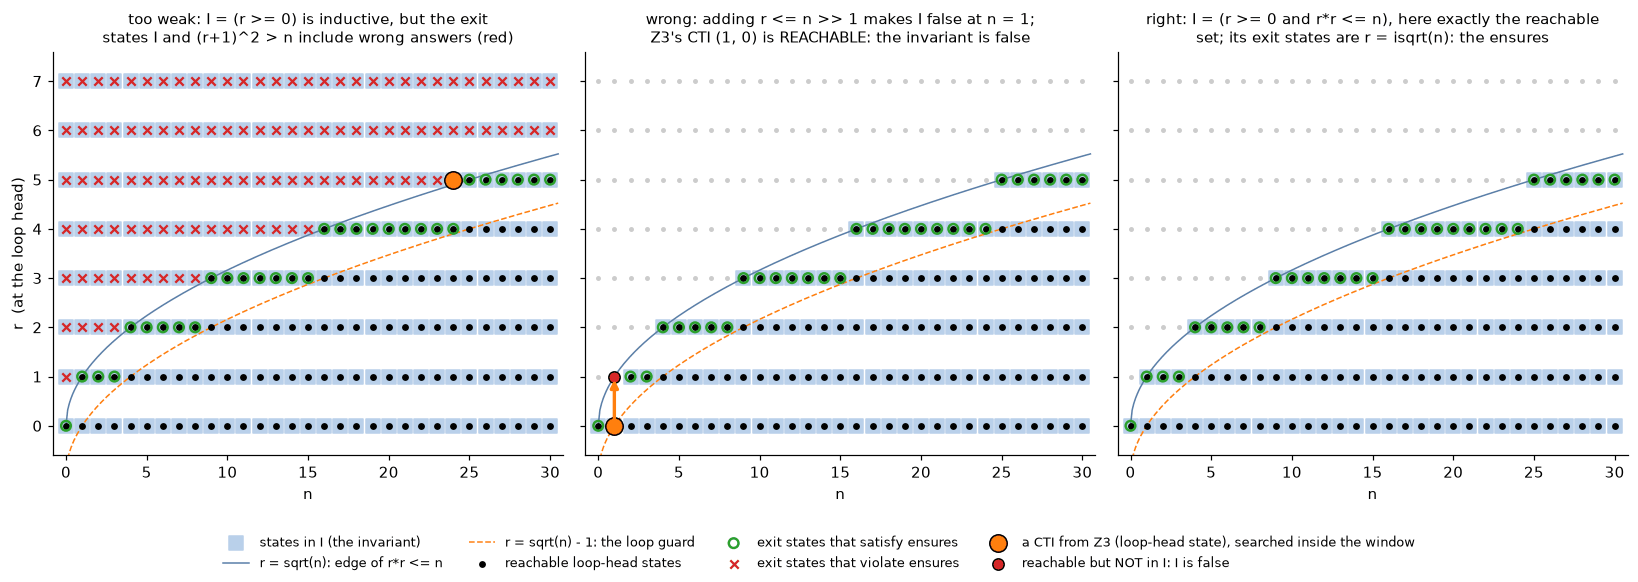

Each VC fails for its own reason. A 'maintained' CTI that a run reaches proves the invariant false. An
unreachable one is what a true-but-not-inductive invariant produces (the x,y loop), but does not by itself
prove the invariant true: a false claim can have unreachable CTIs too (row 3 above). A failing exit VC
means the invariant is too weak to imply the postcondition.


In [78]:
# 6.4 continued: three candidate invariants for isqrt, and what each failing VC tells you.
_s6_ISQRT_INVS = {"too weak": ['r >= 0'], "wrong": ['r >= 0', 'r * r <= n', 'r <= n >> 1'],
                  "right": ['r >= 0', 'r * r <= n']}


def _s6_diagnose():
    '''Three invariants for the same loop, each failing a different VC (or none).'''
    rows, found = [], {}
    for label, inv in _s6_ISQRT_INVS.items():
        fn = _s6_tree(ISQRT_SRC, 'int', {0: inv})
        res = verify(fn, 'int', verbose=False)
        part = lambda key: [v for n, v in res.items() if key in n]
        verdict = lambda vs: "ok" if all(s == 'proved' for s, _ in vs) else "FAILS"
        fail = next(((n, c) for n, (s, c) in res.items() if s == 'counterexample'), None)
        what = "-" if fail is None else fail[0].split(': ')[-1] if 'invariant' in fail[0] else 'postcondition'
        rows.append([label, " and ".join(inv), verdict(part('on entry')), verdict(part('maintained')),
                     verdict(part('postcondition')),
                     "-" if fail is None else f"{what}: {_s6_explain(fn, fail[1], 'int')}"])
        found[label] = fail
    show_table(["invariant", "conjuncts", "on entry", "maintained", "exit => ensures", "first CTI -> replay"],
               rows)
    return found


def _s6_draw_isqrt(found):
    N, RMAX = 30, 7
    ns = np.arange(0, N + 1)
    isq = np.array([math.isqrt(int(n)) for n in ns])
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.3), sharey=True)
    grid = [(n, r) for n in ns for r in range(0, RMAX + 1)]
    reach = [(n, r) for n in ns for r in range(0, isq[n] + 1)]               # loop-head states of real runs
    nn = np.linspace(0, N + 0.5, 300)
    specs = [
        ("too weak", lambda n, r: r >= 0,
         "too weak: I = (r >= 0) is inductive, but the exit\nstates I and (r+1)^2 > n include wrong answers (red)"),
        ("wrong", lambda n, r: r >= 0 and r * r <= n and r <= n >> 1,
         "wrong: adding r <= n >> 1 makes I false at n = 1;\nZ3's CTI ({n}, {r}) {reach}"),
        ("right", lambda n, r: r >= 0 and r * r <= n,
         "right: I = (r >= 0 and r*r <= n), here exactly the reachable\n"
         "set; its exit states are r = isqrt(n): the ensures"),
    ]
    for ax, (label, I, title) in zip(axes, specs):
        inv = _s6_ISQRT_INVS[label]
        inside = [(n, r) for n, r in grid if I(n, r)]
        ax.scatter(*zip(*grid), s=5, color="#cccccc", zorder=1)
        ax.scatter(*zip(*inside), s=88, marker="s", color="#b9d0ea", zorder=1, label="states in I (the invariant)")
        ax.plot(nn, np.sqrt(nn), color="#5b7fa8", lw=1, label="r = sqrt(n): edge of r*r <= n")
        ax.plot(nn, np.sqrt(nn) - 1, color="#ff7f0e", lw=1, ls="--", label="r = sqrt(n) - 1: the loop guard")
        ax.scatter(*zip(*reach), s=12, color="black", zorder=3, label="reachable loop-head states")
        outside = [s for s in reach if not I(*s)]
        if outside:
            ax.scatter(*zip(*outside), s=55, color="#d62728", edgecolor="black", zorder=5,
                       label="reachable but NOT in I: I is false")
        exits = [(n, r) for n, r in inside if (r + 1) ** 2 > n]
        good = [s for s in exits if s[1] * s[1] <= s[0]]
        bad = [s for s in exits if s[1] * s[1] > s[0]]
        if good:
            ax.scatter(*zip(*good), s=40, facecolor="none", edgecolor="#2ca02c", lw=1.6, zorder=4,
                       label="exit states that satisfy ensures")
        if bad:
            ax.scatter(*zip(*bad), s=30, marker="x", color="#d62728", zorder=4,
                       label="exit states that violate ensures")
        fail = found[label]
        if fail is not None:                       # the figure draws a CTI that lies inside its window
            cex = _s6_find_cti(ISQRT_SRC, 'int', fail[0], {0: inv}, box=dict(n=(0, N), r=(0, RMAX))) or fail[1]
            key = next(k for k in cex if '@' in k)
            s = (cex['n'], cex[key])
            real = _s6_run_failed(_s6_replay(_s6_tree(ISQRT_SRC, 'int', {0: inv}), cex, 'int')[0])
            title = title.format(n=s[0], r=s[1], reach="is REACHABLE: the invariant is false" if real
                                 else "is not reached by a run")
            if s[0] <= N and s[1] <= RMAX:
                ax.scatter([s[0]], [s[1]], s=130, facecolor="#ff7f0e", edgecolor="black", zorder=6,
                           label="a CTI from Z3 (loop-head state), searched inside the window")
                if 'invariant' in fail[0]:                                    # preservation: show the step
                    ax.annotate("", xy=(s[0], s[1] + 1), xytext=s, zorder=6,
                                arrowprops=dict(arrowstyle="-|>", color="#ff7f0e", lw=2.2))
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("n")
        ax.set_xlim(-0.8, N + 0.8)
        ax.set_ylim(-0.6, RMAX + 0.6)
        ax.grid(False)
    axes[0].set_ylabel("r  (at the loop head)")
    handles = {}
    for ax in axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            handles.setdefault(l, h)
    fig.legend(handles.values(), handles.keys(), loc="lower center", ncol=4, fontsize=8.5, frameon=False)
    plt.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()


if HAVE_Z3:
    _s6_draw_isqrt(_s6_diagnose())
    print("Each VC fails for its own reason. A 'maintained' CTI that a run reaches proves the invariant false. An")
    print("unreachable one is what a true-but-not-inductive invariant produces (the x,y loop), but does not by itself")
    print("prove the invariant true: a false claim can have unreachable CTIs too (row 3 above). A failing exit VC")
    print("means the invariant is too weak to imply the postcondition.")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

The diagnosis table and figure separate the ways a loop proof fails. **Too weak** ($r \ge 0$): inductive, but the
*exit* VC fails, since exit states with $r$ far above $\sqrt n$ (red) are not ruled out. **Wrong** (adding
$r \le n \gg 1$): *maintained* fails at a **reachable** CTI; at $n = 1$ the run reaches $r = 1 > 1 \gg 1$, and
`run_minipy` stops on the false invariant. **Right** ($r \ge 0 \wedge r^2 \le n$): everything proves, and $I$
*equals* the reachable set, so its exit states are exactly $r = \lfloor\sqrt n\rfloor$. The x,y loop was the
fourth case, *maintained* failing at an **unreachable** CTI: true but not inductive. The VC alone cannot tell a
false invariant from a non-inductive one. Replaying the CTI's inputs can, when the CTI is reachable from them; an
unreachable CTI settles nothing, since a false invariant or variant can have those too.

### 6.5 Termination: a variant is two more VCs

Partial correctness says nothing about loops that never exit: `spin` loops `while n == n`, then returns 0 under
`ensures(result == n + 1)`, and its postcondition VC assumes `not n == n`, so `verify` calls it `'vacuous'`, not
`'proved'`. **Total correctness** adds a **variant** $D$, an integer that is $\ge 0$ whenever the body runs and
strictly smaller after it. A strictly decreasing sequence of naturals is finite, so the loop exits:

$$I \wedge b \Rightarrow D \ge 0, \qquad I \wedge b \wedge s \xrightarrow{S} s' \Rightarrow D(s') < D(s).$$

`vcgen` emits both per `decreases(...)`, reading $D(s)$ through a ghost name for the variant's value at the loop
head. The cell tries four variants for `isqrt` and the obvious one for Collatz.

In [79]:
# 6.5 Termination: a variant is two more VCs per loop.
_s6_SPIN_SRC = '''
def spin(n):
    ensures(result == n + 1)
    k = 0
    while n == n:
        k = k + 1
    return 0
'''

_s6_COLLATZ6_SRC = '''
def collatz(n):
    requires(n >= 1)
    x = n
    k = 0
    while x != 1:
        invariant(x >= 1)
        decreases(x)
        if (x >> 1) * 2 == x:
            x = x >> 1
        else:
            x = 3 * x + 1
        k = k + 1
    return k
'''


def _s6_termination():
    # partial correctness: a loop that never exits satisfies every postcondition
    res = verify(_s6_SPIN_SRC, 'int', verbose=False)
    print("spin (never exits, returns 0, claims result == n + 1) under partial correctness:")
    for name, (status, _) in res.items():
        print(f"  {name:45s} {status}")
    rows = []
    for variant in ["n - r * r", "n - r", "r", "-r"]:
        src = ISQRT_SRC.replace("decreases(n - r * r)", f"decreases({variant})")
        fn = parse_minipy(src, 'int')
        res = verify(fn, 'int', verbose=False)
        get = lambda key: next(v for n, v in res.items() if key in n)
        below, strict = get('bounded below'), get('decreases strictly')
        fail = below if below[0] != 'proved' else strict if strict[0] != 'proved' else None
        rows.append([f"decreases({variant})", below[0], strict[0],
                     "-" if fail is None or fail[1] is None else _s6_explain(fn, fail[1], 'int')])
    print()
    show_table(["isqrt variant", "bounded below (>= 0)", "strictly decreases", "CTI -> replay"], rows)
    fn = parse_minipy(_s6_COLLATZ6_SRC, 'int')
    res = verify(fn, 'int', verbose=False)
    print("\ncollatz with the obvious candidate decreases(x):")
    for name, (status, cex) in res.items():
        print(f"  {name:48s} {status:15s} {'' if cex is None else _s6_explain(fn, cex, 'int')}")
        if cex is not None:                     # x = n at the first loop-head visit: start the run AT the CTI
            x_head = next(v for k, v in cex.items() if k.startswith('x@'))
            run = run_minipy(fn, (x_head,), 'int')
            print(f"  {'':48s} {'':15s} start the run AT that state, n = {x_head}: run_minipy {run}" +
                  (" -- reachable: decreases(x) is simply false" if run[0] == 'assert_fail' else ""))


if HAVE_Z3:
    _s6_termination()
    print("\nA wrong variant fails one of its two VCs, at a state the replay shows to be real: the run itself")
    print("checks decreases(...) and stops with assert_fail. For Collatz no variant is known to anyone.")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

spin (never exits, returns 0, claims result == n + 1) under partial correctness:
  line 2: postcondition (return at line 6)      vacuous



isqrt variant         bounded below (>= 0)  strictly decreases  CTI -> replay                                                     
----------------------------------------------------------------------------------------------------------------------------------
decreases(n - r * r)  proved                proved              -                                                                 
decreases(n - r)      proved                proved              -                                                                 
decreases(r)          proved                counterexample      n=14 | loop head: r@5=1 -> run_minipy ('assert_fail', 8): real bug
decreases(-r)         counterexample        proved              n=12 | loop head: r@5=1 -> run_minipy ('assert_fail', 8): real bug

collatz with the obvious candidate decreases(x):
  loop 0 (line 5): invariant on entry: x >= 1      proved          
  loop 0 (line 5): decreases bounded below: x >= 0 proved          
  loop 0 (line 5): invarian

Variants are not unique (`n - r * r` and `n - r` both work), and a wrong one fails exactly one VC: `r` grows, so
*strictly decreases* fails; `-r` goes negative, so *bounded below* fails. Both CTIs are reachable, and
`run_minipy`, which checks `decreases(...)` at run time, stops on them. For Collatz, `decreases(x)` fails on the
odd branch ($x \to 3x + 1$); a run started at the CTI's `x` reproduces it, and no working variant is known (the
open conjecture of §2). In practice variants are often **lexicographic** (Dafny accepts `decreases a, b`), for
nested loops and Ackermann-style recursion; any **well-founded order**, one with no infinite descending chain,
works. Termination provers search for them: Terminator (Cook, Podelski & Rybalchenko, PLDI 2006) builds a *set*
of ranking functions on demand from a few program paths and checks that every finite sequence of transitions
decreases one of them; it was evaluated on Windows device-driver dispatch routines, in program fragments of more
than 20,000 lines.

### 6.6 VC size: why Boogie makes programs passive

The `if` row of the wp table mentions $Q$ twice, so $k$ sequential `if`s make $2^k$ copies of the postcondition,
one per path. **Naive wp pays per path**, as symbolic execution does (§5.4), only backwards: forward, symbolic
execution carries one path condition per path to the end; backward, wp carries one copy of $Q$ per path to the
start. Leino (*Efficient weakest preconditions*, IPL 2005) explains why naming the shared subformula
(`let q = Q in ...`) is not enough: the text becomes linear, but the prover still processes $q$ once per copy.
What works is Flanagan & Saxe's **passive
form** (POPL 2001), used by ESC/Java and adapted by Barnett & Leino (PASTE 2005) to the unstructured programs of
Boogie, the intermediate verifier under Dafny. In dynamic single assignment, `x = e` becomes an assumption
`x.3 == e` about a fresh version. At a join, Barnett & Leino put a copy `x.4 := x.2` at the end of one branch and
`x.4 := x.3` at the end of the other, and these become assumptions too; `_s6_passive` merges with one
if-expression, `x.4 == (x.2 if b else x.3)`, as §5.3's BMC does.

Leino's analysis splits the VC in two. His wlp, unlike this section's, lets a failing check pass, as
non-termination does ($\mathrm{wlp}(\textsf{assert}\ c, Q) = c \Rightarrow Q$), and
$\mathrm{wp}(S, Q) = \mathrm{wp}(S, \mathit{true}) \wedge \mathrm{wlp}(S, Q)$: no check fails, and the runs that
finish end in $Q$. A program without assignments satisfies
$\mathrm{wlp}(S, Q) = \mathrm{wlp}(S, \mathit{false}) \vee Q$, so the VC
$\mathrm{wp}(S, \mathit{true}) \wedge (\mathrm{wlp}(S, \mathit{false}) \vee Q)$ mentions $Q$ once, and
$\mathrm{wp}(S, \mathit{true})$ collects the checks; Leino bounds the whole as quadratic in the size of the
program. (Under this section's wlp, in which an `assert` must hold, the identity is false: for `assert false` the
left side is *false* and the right side is $Q$.) `_s6_passive` writes the same content as one implication: the
definitions imply, for each check and each `return`, *path condition ⇒ condition*, so every check and the
postcondition at each `return` appear once. Before it measures anything, the next cell checks it against `vcgen`
on random programs.

In [80]:
# 6.6 The passive (DSA) form of loop-free MiniPy, and a check that it agrees with vcgen.
_s6_SEED_PASSIVE = 616
_s6_N_PASSIVE = 20           # random loop-free programs (6.2's generator) per semantics

_s6_BRANCH_ASSUME_SRC = '''
def branch_assume(x):
    ensures(result > 5 or result <= 0)
    if x > 0:
        assume(x > 5)
        s = x
    else:
        s = 0
    return s
'''


def _s6_passive(fn, semantics):
    '''The passive form of LOOP-FREE code, as one formula. Every assignment x = e becomes a definition x.i == e
    over the current versions (dynamic single assignment: each version is defined once); after an if, a
    variable that differs between the branches gets a merge definition x.k == (x.then if b else x.else).
    Every run-time check (of requires, code, assert, assume, return values and ensures) contributes
    (path condition => check). The path condition starts with the requires, in order, and collects branch
    tests and assume(...) facts; what a branch added survives its join as (b => added), so a fact assumed
    inside a branch is not lost. Returns (definitions, obligations): the VC is
        all definitions  =>  every (pc => cond).'''
    info, body = _s6_function(fn)
    defs, obls, version = [], [], Counter()

    def define(x, e, ref):
        version[x] += 1
        v = _s6_var(f"{x}.{version[x]}", ref)
        defs.append(_s6_cmp(v, ast.Eq, e, ref))
        return v

    def checks(e, cur, pc, spec):
        for kind, guards, cond, node in _s6_checks(e, semantics, spec):
            obls.append((pc + [_s6_subst(g, cur) for g in guards], _s6_subst(cond, cur)))

    def join_fact(pc, branch_pc, b):
        '''What a branch added to the path condition beyond its own test b, as [b => added] (or []).'''
        added = branch_pc[len(pc) + 1:]
        if not added:
            return []
        fact = added[0]
        for f in added[1:]:
            fact = _s6_and(fact, f, f)
        return [_s6_implies([b], fact)]

    def run(stmts, cur, pc):
        '''-> (versions, path condition) after stmts, or None if every path returned.'''
        for st in stmts:
            if isinstance(st, ast.Assign):
                checks(st.value, cur, pc, False)
                cur = dict(cur, **{st.targets[0].id: define(st.targets[0].id, _s6_subst(st.value, cur), st)})
            elif isinstance(st, ast.If):
                checks(st.test, cur, pc, False)
                b, nb = _s6_subst(st.test, cur), _s6_not(_s6_subst(st.test, cur))
                out1, out2 = run(st.body, cur, pc + [b]), run(st.orelse, cur, pc + [nb])
                if out1 is None or out2 is None:
                    if out1 is None and out2 is None:
                        return None
                    cur, pc = out2 if out1 is None else out1        # only one branch falls through
                    continue
                (c1, pc1), (c2, pc2) = out1, out2
                pc = pc + join_fact(pc, pc1, b) + join_fact(pc, pc2, nb)
                cur = dict(cur)
                for x in set(c1) & set(c2):
                    if c1[x] is not c2[x]:
                        cur[x] = define(x, _s6_at(ast.IfExp(b, c1[x], c2[x]), st), st)
            elif isinstance(st, ast.Return):
                checks(st.value, cur, pc, False)
                e = _s6_subst(st.value, cur)
                for q in info['ensures']:
                    q_r = _s6_subst(q, {'result': e})
                    checks(q_r, {}, pc, True)
                    obls.append((list(pc), q_r))
                return None
            elif isinstance(st, ast.Assert):
                checks(st.test, cur, pc, True)
                obls.append((list(pc), _s6_subst(st.test, cur)))
            elif isinstance(st, ast.Expr):                   # assume(c): a fact on this path from now on
                checks(st.value.args[0], cur, pc, True)
                pc = pc + [_s6_subst(st.value.args[0], cur)]
            else:
                raise ValueError("_s6_passive: loop-free code only")
        return cur, pc

    pc0 = []
    for r in info['requires']:                               # requires: checked, then assumed, in order
        checks(r, {}, pc0, True)
        pc0 = pc0 + [r]
    run(body, {}, pc0)
    return defs, obls


def _s6_z3_passive(fn, semantics, defs, obls, timeout_ms=10000):
    '''One query: definitions and (some path condition and not its check). -> (status, model or None, env)'''
    copies = [(defs + pc, g) for pc, g in obls]
    env, dom = _s6_z3_env(copies, minipy_info(fn), semantics)
    tr = lambda e: expr_to_z3(e, env, semantics)
    s = z3.Solver()
    s.set('timeout', timeout_ms)
    s.add(*dom, *[tr(d) for d in defs])
    s.add(z3.Or(*[z3.And(*[tr(a) for a in pc], z3.Not(tr(g))) for pc, g in obls]))
    r = s.check()
    status = 'proved' if r == z3.unsat else 'counterexample' if r == z3.sat else 'unknown'
    return status, (s.model() if r == z3.sat else None), env


def _s6_naive_status(res):
    sts = [s for s, _ in res.values()]
    return 'unknown' if 'unknown' in sts else 'counterexample' if 'counterexample' in sts else 'proved'


def _s6_passive_agreement():
    '''The passive VC must be valid exactly when every naive VC is, and its counterexamples must replay.'''
    rnd = random.Random(_s6_SEED_PASSIVE)
    rows = []
    for sem in ('int', 'int+ovf', 'bv8'):
        st = Counter()
        for _ in range(_s6_N_PASSIVE):
            fn = parse_minipy(_s6_random_program(rnd, sem), sem)
            naive = _s6_naive_status(verify(fn, sem, timeout_ms=2000, verbose=False))
            status, model, env = _s6_z3_passive(fn, sem, *_s6_passive(fn, sem), timeout_ms=2000)
            if 'unknown' in (naive, status):
                st['unknown'] += 1
                continue
            st['agree'] += naive == status
            st['buggy'] += naive == 'counterexample'
            if status == 'counterexample':
                cex = _s6_decode(model, env, minipy_info(fn), set())
                outcome = _s6_replay(fn, cex, sem)[0]
                st['long'] += outcome == 'too long to replay'
                st['replayed'] += _s6_run_failed(outcome)
        rows.append([sem, _s6_N_PASSIVE, st['buggy'], st['agree'], st['replayed'], st['long'], st['unknown']])
    show_table(["semantics", "programs", "buggy (naive wp)", "passive verdict agrees", "passive cex replays",
                "array too long", "unknown"], rows)
    fn = parse_minipy(_s6_BRANCH_ASSUME_SRC, 'int')
    naive = _s6_naive_status(verify(fn, 'int', verbose=False))
    status, _, _ = _s6_z3_passive(fn, 'int', *_s6_passive(fn, 'int'))
    print(f"branch_assume (an assume inside a branch; the fact survives the join as x > 0 => x > 5): "
          f"naive {naive}, passive {status}")
    return sum(r[3] for r in rows), sum(r[1] - r[6] for r in rows)


if HAVE_Z3:
    _s6_agree, _s6_decided = _s6_passive_agreement()
    print(f"The passive form agrees with naive wp on {_s6_agree} of {_s6_decided} decided random programs: same VC, "
          f"written once.")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

semantics  programs  buggy (naive wp)  passive verdict agrees  passive cex replays  array too long  unknown
-----------------------------------------------------------------------------------------------------------
int        20        17                20                      17                   0               0      
int+ovf    20        17                20                      16                   1               0      
bv8        20        18                20                      18                   0               0      
branch_assume (an assume inside a branch; the fact survives the join as x > 0 => x > 5): naive proved, passive proved
The passive form agrees with naive wp on 60 of 60 decided random programs: same VC, written once.


The two forms reach the same verdict on all 60 random programs, and every passive counterexample short enough to
replay fails when run. `branch_assume` is the case a careless passive form gets wrong: its `assume(x > 5)` sits
inside a branch, and if the join forgot it, the merged `s.3 == (x if x > 0 else 0)` would make `x = 1` a
counterexample (`s.3 = 1` violates the ensures), although no run with `x = 1` gets past the `assume`. Hence the
join keeps it as $x > 0 \Rightarrow x > 5$.

The experiment is §5's `chain` (`if x_i > 0: s = s + 1`, $k$ times, `ensures(result <= k)`): all $2^k$ paths are
feasible, and the program is correct. Both forms are built and proved for growing $k$, then refuted on a planted
bug.

**Registered prediction:** *naive wp emits exactly $2^k$ VCs, as many as §5's symbolic execution explores paths,
and their total size doubles per `if`; the passive VC grows by a constant per `if`; at $k = 12$ the naive VC is
more than 100× larger.*

k ifs  paths 2^k  symex paths (§5)  naive wp: VCs  naive wp: nodes  naive s  passive: nodes  passive s
------------------------------------------------------------------------------------------------------
1      2          2                 2              15               0.001    19              0.001    
2      4          4                 4              48               0.002    32              0.001    
3      8          8                 8              132              0.003    45              0.002    
4      16         16                16             336              0.005    58              0.002    
5      32         32                32             816              0.010    71              0.002    
6      64         64                64             1920             0.020    84              0.002    
7      128        128               128            4416             0.045    97              0.003    
8      256        256               256            9984             0.096

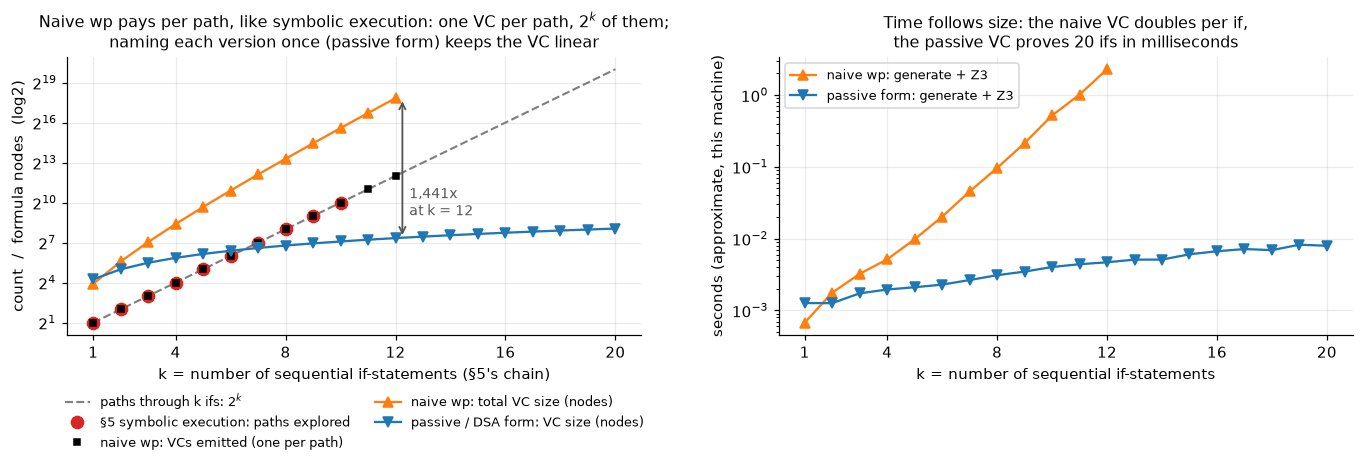

Passive form is why industrial VC generators do not explode on branchy code; the price is a new variable
per version, and the solver, not the VC generator, now does the case analysis on the merges.


In [81]:
# 6.6 continued: VC explosion. Naive wp copies the postcondition at every if; the passive (DSA) form does not.
_s6_K_MAX = 20           # sequential ifs, passive form
_s6_K_NAIVE = 12         # naive wp is built and proved up to here (2^12 = 4,096 path VCs)
_s6_K_SYMEX = 10         # §5's symbolic execution is run up to here (it pays one solver path per VC)


def _s6_chain_src(k, slack=0):
    '''§5's chain: k independent checks `if x_i > 0: s = s + 1`, so all 2^k paths are feasible. slack=-1
    plants a bug (ensures one too small).'''
    lines = [f"def chain({', '.join(f'x{i}' for i in range(k))}):", f"    ensures(result <= {k + slack})",
             "    s = 0"]
    for i in range(k):
        lines += [f"    if x{i} > 0:", "        s = s + 1"]
    return "\n".join(lines + ["    return s"]) + "\n"


def _s6_size(e):
    '''Size of a formula written out as a tree: its number of expression nodes (shared subtrees counted
    every time they occur, as in the printed VC).'''
    return sum(isinstance(n, ast.expr) for n in ast.walk(e))


def _s6_explosion():
    data, rows = defaultdict(list), []
    for k in range(1, _s6_K_MAX + 1):
        src = _s6_chain_src(k)
        fn = parse_minipy(src, 'int')
        (defs, obls), t_gen = timed(_s6_passive, fn, 'int')
        (status_p, _, _), t_z3 = timed(_s6_z3_passive, fn, 'int', defs, obls)
        data['k'].append(k)
        data['passive size'].append(sum(map(_s6_size, defs)) + sum(_s6_size(g) + sum(map(_s6_size, pc))
                                                                    for pc, g in obls))
        data['passive s'].append(t_gen + t_z3)
        data['not proved'].append(status_p != 'proved')
        row = [k, 2 ** k]
        if k <= _s6_K_SYMEX:
            data['symex paths'].append(len(symex(src, 'int', max_paths=10 ** 5)))
        if k <= _s6_K_NAIVE:
            vcs, t_gen = timed(_s6_vcgen_tree, fn, 'int')
            res, t_z3 = timed(_s6_discharge, fn, vcs, 'int')
            data['naive VCs'].append(len(vcs))
            data['naive size'].append(sum(_s6_size(g) + sum(map(_s6_size, A)) for n, A, g in vcs))
            data['naive s'].append(t_gen + t_z3)
            data['not proved'][-1] += sum(s != 'proved' for s, _ in res.values())
            row += [data['symex paths'][-1] if k <= _s6_K_SYMEX else "-", len(vcs), data['naive size'][-1],
                    f"{data['naive s'][-1]:.3f}"]
        else:
            row += ["-", "-", "-", "-"]
        rows.append(row + [data['passive size'][-1], f"{data['passive s'][-1]:.3f}"])
    show_table(["k ifs", "paths 2^k", "symex paths (§5)", "naive wp: VCs", "naive wp: nodes", "naive s",
                "passive: nodes", "passive s"], rows)
    print(f"VCs not proved (naive and passive, all k; the program is correct): {sum(data['not proved'])}")
    # the two forms must also agree when the program is WRONG: plant a bug and replay the passive model
    agree = 0
    for k in (3, 6, 9):
        fn = parse_minipy(_s6_chain_src(k, slack=-1), 'int')
        naive = _s6_discharge(fn, _s6_vcgen_tree(fn, 'int'), 'int')
        defs, obls = _s6_passive(fn, 'int')
        status, model, env = _s6_z3_passive(fn, 'int', defs, obls)
        replay = None
        if status == 'counterexample':
            args = {p: model.eval(env[p], model_completion=True).as_long() for p in minipy_info(fn)['params']}
            replay = run_minipy(fn, args, 'int')[0]
        agree += (status == 'counterexample' and any(s == 'counterexample' for s, _ in naive.values())
                  and replay == 'ensures_fail')
    print(f"planted bug (ensures(result <= k - 1)) at k = 3, 6, 9: naive and passive both refute it and the "
          f"passive model replays as ensures_fail in {agree}/3 cases")
    return data


def _s6_score_explosion(d):
    k = np.array(d['k'][:_s6_K_NAIVE])
    exact = (d['naive VCs'] == [2 ** int(i) for i in k]
             and d['symex paths'] == [2 ** i for i in range(1, _s6_K_SYMEX + 1)])
    ratio = d['naive size'][-1] / d['naive size'][-2]
    steps = np.diff(d['passive size'])
    k_n = _s6_K_NAIVE
    blowup = d['naive size'][k_n - 1] / d['passive size'][k_n - 1]
    right = exact and 1.8 < ratio < 2.4 and steps.max() == steps.min() and blowup > 100
    print(f"registered prediction: naive wp emits exactly 2^k VCs (= §5's symex paths) whose total size doubles "
          f"per if; the passive form grows by a constant per if; at k = {k_n} naive is > 100x larger | measured: "
          f"counts exact: {exact}; naive size x{ratio:.2f} per if at k = {k_n}; passive +{steps.min()}..+"
          f"{steps.max()} nodes per if; naive / passive at k = {k_n}: {blowup:,.0f}x | verdict: "
          f"{'RIGHT' if right else 'WRONG'}")


def _s6_draw_explosion(d):
    k = np.array(d['k'])
    kn, ks = k[:_s6_K_NAIVE], k[:_s6_K_SYMEX]
    fig, (a0, a1) = plt.subplots(1, 2, figsize=(12.5, 4.5))
    a0.plot(k, 2.0 ** k, color="gray", ls="--", lw=1.4, label="paths through k ifs: $2^k$")
    a0.plot(ks, d['symex paths'], "o", color="#d62728", ms=8, label="§5 symbolic execution: paths explored")
    a0.plot(kn, d['naive VCs'], "s", color="black", ms=4, label="naive wp: VCs emitted (one per path)")
    a0.plot(kn, d['naive size'], "^-", color="#ff7f0e", label="naive wp: total VC size (nodes)")
    a0.plot(k, d['passive size'], "v-", color="#1f77b4", label="passive / DSA form: VC size (nodes)")
    kk = _s6_K_NAIVE
    a0.annotate("", xy=(kk + 0.25, d['naive size'][kk - 1]), xytext=(kk + 0.25, d['passive size'][kk - 1]),
                arrowprops=dict(arrowstyle="<->", color="#555555", lw=1.2))
    a0.text(kk + 0.5, d['naive size'][kk - 1] ** 0.25 * d['passive size'][kk - 1] ** 0.75,
            f"{d['naive size'][kk - 1] / d['passive size'][kk - 1]:,.0f}x\nat k = {kk}", fontsize=9,
            color="#555555", va="center")
    a0.set_yscale("log", base=2)
    a0.set_xticks([1, 4, 8, 12, 16, 20])
    a0.set_xlabel("k = number of sequential if-statements (§5's chain)")
    a0.set_ylabel("count  /  formula nodes  (log2)")
    a0.set_title("Naive wp pays per path, like symbolic execution: one VC per path, $2^k$ of them;\nnaming each "
                 "version once (passive form) keeps the VC linear", fontsize=10.5)
    # the legend goes below the panel: inside, it would hide part of the naive curve
    a0.legend(fontsize=8.3, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
    a1.plot(kn, d['naive s'], "^-", color="#ff7f0e", label="naive wp: generate + Z3")
    a1.plot(k, d['passive s'], "v-", color="#1f77b4", label="passive form: generate + Z3")
    a1.set_yscale("log")
    a1.set_xticks([1, 4, 8, 12, 16, 20])
    a1.set_xlabel("k = number of sequential if-statements")
    a1.set_ylabel("seconds (approximate, this machine)")
    a1.set_title("Time follows size: the naive VC doubles per if,\nthe passive VC proves 20 ifs in "
                 "milliseconds", fontsize=10.5)
    a1.legend(fontsize=8.5, loc="upper left")
    plt.tight_layout()
    plt.show()


if HAVE_Z3:
    _s6_ex = _s6_explosion()
    _s6_score_explosion(_s6_ex)
    _s6_draw_explosion(_s6_ex)
    print("Passive form is why industrial VC generators do not explode on branchy code; the price is a new variable")
    print("per version, and the solver, not the VC generator, now does the case analysis on the merges.")
else:
    print("Z3 not installed (pip install z3-solver): skipping this cell. vcgen needs no solver, and "
          "verify(..., backend='toy') still proves bv8..bv64 programs with the bit-blaster of §4.")

Right on all counts. One VC per path, exactly §5's path count; the naive size grows by a factor approaching 2 per
`if`, the passive VC by a constant 13 nodes (the branch's `s.i == s.j + 1` and the merge), more than a thousand
times smaller at $k = 12$. Both forms refute the planted bug, and the passive model replays as `ensures_fail`.
Time tracks size: the passive form proves 20 `if`s in milliseconds. Merging is not free, though: as in §5.4, the
merges push the case split into the solver. `vcgen` stays naive because its VCs read like the program; anything
larger than these demos should be made passive first.

### 6.7 The same proof in Dafny

Auto-active verifiers package exactly these pieces. `isqrt` in Dafny (Leino, LPAR 2010), *illustrative*:

```dafny
method Isqrt(n: int) returns (r: int)
  requires n >= 0
  ensures r * r <= n < (r + 1) * (r + 1)
{
  r := 0;
  while ((r + 1) * (r + 1) <= n)
    invariant r >= 0 && r * r <= n
    decreases n - r * r
  {
    r := r + 1;
  }
}
```

| piece | this notebook | Dafny |
|---|---|---|
| contract, loop annotations | `requires`/`ensures` (`result`), `invariant`/`decreases`, by a human | the same (named result `r`); Dafny guesses `decreases` for simple guards |
| integer semantics | `'int'`; `'int+ovf'` (checks in code, ℤ in specs); signed `'bv32'` | `int`; `newtype int32 = x \| -0x8000_0000 <= x < 0x8000_0000`, whose operations "are defined only if the result satisfies the predicate" (Dafny Reference Manual), in specs too, so specs over `int32` values are written with `as int`, which `'int+ovf'` does implicitly; `bv32` is *unsigned* in Dafny (unsigned `<`, logical `>>`), so MiniPy's signed `'bv32'` has no direct twin: signed tests go through the sign bit or a conversion |
| VC generator, solver | `vcgen` (naive wp, fresh `x@L`), Z3 or §4's bit-blaster | Boogie (passive form, then wp), Z3 |
| a failed VC | named obligation + counterexample, replayed with `run_minipy` | an error at the failing annotation or operation |

What the human writes is the invariant and the variant; everything else in this section was mechanical. The x,y
loop and `isqrt` showed the three ways an invariant fails (not inductive, false, too weak for the exit), and
machine integers add a fourth: an overflow or a wrap the invariant does not rule out. Three sections automate the
human's part: §8 searches finite state for inductive strengthenings (k-induction, IC3), §9 computes invariants in
an abstract domain, and §13 lets an untrusted proposer (an LLM, or Houdini) guess while `verify` checks, with
`invariants=` as the plug. §7 first takes up the VCs where real verification effort goes: memory, aliasing and
quantifiers.

## 7. Memory and quantifiers: where real verification effort goes

§6 verified programs whose whole state was a few integer variables. Real programs keep state in memory reached
through pointers, and their specifications talk about *every* element of a data structure. Those two facts — **the
heap** and **quantifiers** — are where the annotation burden and the solver unpredictability of tools like Dafny,
Verus and F\* come from. In the Komodo verification project, instability was called "the most frustrating recurring
problem" (as quoted by Zhou et al., *Mariposa*, FMCAD 2023). The memory half: **aliasing** (§7.1), **separation
logic** (§7.2) and the **frame problem** (§7.3). The quantifier half: **E-matching** (§7.4), **matching loops**
(§7.5) and **proof instability** (§7.6). MiniPy's frozen grammar (§2) has neither pointers nor quantifiers, so this
section talks to Z3 directly; every query is the VC §6's generator *would* emit if MiniPy had a heap and `forall`.

### 7.1 Memory is one big array

Model memory as a function $M:\text{Addr}\to\text{Val}$. Reading `*p` is $M[p]$ (`select`); writing `*p = v`
assigns the *whole memory*, $M := \mathrm{store}(M, p, v)$. Then §6's assignment rule needs nothing new:
$wp(\texttt{*p = v},\,Q) = Q[\mathrm{store}(M,p,v)/M]$, and reads from the new memory are resolved by McCarthy's
read-over-write axiom for the theory of arrays (McCarthy, 1962):

$$\mathrm{select}(\mathrm{store}(M,p,v),\,q) \;=\; \begin{cases} v & \text{if } p = q\\
\mathrm{select}(M,q) & \text{if } p \neq q.\end{cases}$$

That case split *is* the aliasing problem: a read after $k$ writes unfolds into up to $k+1$ cases, one per pointer
equality the verifier cannot settle. The tempting shortcut — treat `*p` and `*q` as two ordinary variables, as §6
did with integers — is unsound: it settles $p \ne q$ by the *spelling* of the names.

The next two cells write three tiny programs **once**, as Python functions over a `mem` object, and run them
against three memory backends: a concrete `dict` (to replay counterexamples), a Z3 array (the real semantics) and
the naive one-variable-per-name model. Specs: `*p = 1` must preserve `*q == 0`; both swaps must exchange the
initial contents `A` and `B`. The XOR swap famously zeroes a cell when `p == q`. **Registered prediction:** *the
ordinary temporary-variable swap also breaks when `p == q`* (it swaps a cell with itself, after all).

In [82]:
# 7.1  One program, three memory models: the backends and the programs.
_s7_ADDR_BITS, _s7_VAL_BITS = 64, 32      # 64-bit pointers to 32-bit ints
_s7_TIMEOUT_MS = 2000                    # every Z3 call in this section has a short timeout
_s7_SEED = 7
# Z3 configured the way Dafny runs it: Boogie sets smt.mbqi=false by default; Dafny's
# DafnyOptions.SetZ3Options adds auto_config=false, qi.eager_threshold=44, delay_units, case_split=3.
# So quantifiers are handled by E-matching only (no model-based instantiation) -- see 7.5.
_s7_DAFNY_Z3 = {'auto_config': False, 'mbqi': False, 'qi.eager_threshold': 44.0,
                'delay_units': True, 'case_split': 3}


def _s7_solver(timeout_ms=_s7_TIMEOUT_MS, seed=None, ctx=None, dafny=True, extra=None):
    '''A fresh Z3 solver with a hard timeout. dafny=True: Dafny's quantifier settings; False: Z3's defaults;
    a dict: exactly those settings. `extra` adds options on top (e.g. turning one preprocessing step off).'''
    s = z3.Solver(ctx=ctx) if ctx is not None else z3.Solver()
    s.set('timeout', timeout_ms)
    config = _s7_DAFNY_Z3 if dafny is True else (dafny or {})
    for k, v in {**config, **(extra or {})}.items():
        s.set(k, v)
    if seed is not None:
        s.set('random_seed', seed)
    return s


def _s7_check(s):
    '''Check a solver holding hypotheses + NOT(goal). Returns (verdict, stats); unknown/timeout is never a proof.
    rlimit is Z3's resource counter; it is cumulative per Z3 context, so compare it only across fresh contexts.'''
    t0 = time.perf_counter()
    r = s.check()
    st = s.statistics()
    get = lambda k: st.get_key_value(k) if k in st.keys() else 0
    stats = dict(ms=(time.perf_counter() - t0) * 1e3, inst=get('quant instantiations'),
                 rlimit=get('rlimit count'), missed=get('missed quant instantiations'),
                 reason=s.reason_unknown() if r == z3.unknown else '')
    verdict = 'proved' if r == z3.unsat else 'counterexample' if r == z3.sat else 'unknown'
    return verdict, stats


class _s7_ArrayHeap:
    '''The real semantics: memory is ONE Z3 array; a write replaces the whole array, M := Store(M, p, v).'''
    def __init__(self, M0=None):
        self.M0 = M0 if M0 is not None else z3.Array(
            'M0', z3.BitVecSort(_s7_ADDR_BITS), z3.BitVecSort(_s7_VAL_BITS))
        self.M = self.M0

    def __getitem__(self, p):
        return z3.Select(self.M, p)

    def __setitem__(self, p, v):
        self.M = z3.Store(self.M, p, v)


class _s7_NaiveHeap:
    '''The tempting shortcut: one logic variable per dereferenced NAME (*p, *q), as if they were §6's
    integer variables. Two different names are silently assumed to be two different cells.'''
    def __init__(self):
        self.cells = {}

    def __getitem__(self, p):
        name = '*' + str(p)
        if name not in self.cells:
            self.cells[name] = z3.BitVec(name, _s7_VAL_BITS)
        return self.cells[name]

    def __setitem__(self, p, v):
        self.cells['*' + str(p)] = v


# The programs, written once. `mem` is a dict (concrete run), an _s7_ArrayHeap or an _s7_NaiveHeap.
def _s7_write_one(mem, p, q):
    mem[p] = 1


def _s7_xor_swap(mem, p, q):
    mem[p] = mem[p] ^ mem[q]
    mem[q] = mem[p] ^ mem[q]
    mem[p] = mem[p] ^ mem[q]


def _s7_tmp_swap(mem, p, q):
    t = mem[p]
    mem[p] = mem[q]
    mem[q] = t


# (label, program, requires, ensures); A, B name the initial contents of *p and *q (ghost values).
_s7_HEAP_CASES = [
    ('*p = 1   keeps *q == 0', _s7_write_one,
     lambda m, p, q, A, B: [m[q] == 0], lambda m, p, q, A, B: [m[q] == 0]),
    ('xor_swap(p, q)', _s7_xor_swap,
     lambda m, p, q, A, B: [m[p] == A, m[q] == B], lambda m, p, q, A, B: [m[p] == B, m[q] == A]),
    ('tmp_swap(p, q)', _s7_tmp_swap,
     lambda m, p, q, A, B: [m[p] == A, m[q] == B], lambda m, p, q, A, B: [m[p] == B, m[q] == A]),
]


def _s7_crosscheck_array_model(n_trials=300):
    '''Independent oracle: the Z3 array semantics, evaluated on CONCRETE pointers and values, must agree
    with running the same Python function on a dict -- including the aliased case p == q.'''
    g = random.Random(_s7_SEED)
    mismatches = 0
    for _ in range(n_trials):
        p, q = g.choice([16, 24]), g.choice([16, 24])          # aliased about half the time
        vp, vq = g.randrange(INT32_MIN, INT32_MAX), g.randrange(INT32_MIN, INT32_MAX)
        for _, prog, _, _ in _s7_HEAP_CASES:
            heap = {p: vp}
            heap[q] = vq                                        # same write order as the Store chain below
            M0 = z3.K(z3.BitVecSort(_s7_ADDR_BITS), z3.BitVecVal(0, _s7_VAL_BITS))
            M0 = z3.Store(z3.Store(M0, p, vp), q, vq)
            sym = _s7_ArrayHeap(M0)
            prog(heap, p, q)
            prog(sym, z3.BitVecVal(p, _s7_ADDR_BITS), z3.BitVecVal(q, _s7_ADDR_BITS))
            for addr in heap:
                if z3.simplify(sym[z3.BitVecVal(addr, _s7_ADDR_BITS)]).as_signed_long() != heap[addr]:
                    mismatches += 1
    return n_trials * len(_s7_HEAP_CASES), mismatches


_s7_one_cell = {0x10: 5}
_s7_xor_swap(_s7_one_cell, 0x10, 0x10)
print(f"concretely: xor_swap(p, p) on a dict heap whose one cell holds 5 leaves {_s7_one_cell[0x10]} "
      "(the first XOR already zeroed the cell it reads next)")
if HAVE_Z3:
    _s7_n, _s7_bad = _s7_crosscheck_array_model()
    print(f"cross-check: Z3 array semantics vs concrete execution on {_s7_n} random runs (half aliased): "
          f"{_s7_bad} mismatches -- the array backend means what the dict does")

concretely: xor_swap(p, p) on a dict heap whose one cell holds 5 leaves 0 (the first XOR already zeroed the cell it reads next)
cross-check: Z3 array semantics vs concrete execution on 900 random runs (half aliased): 0 mismatches -- the array backend means what the dict does


The array backend agrees with concrete execution on concrete pointers. Now `p` and `q` become symbolic: the cell
asks Z3 to prove each spec under each model, then replays every counterexample on a real `dict` heap. It also runs
the XOR-swap query under the Z3 configuration Dafny uses (§7.5 lists its options and where they come from), with
and without one of them: `case_split=3`, which makes the solver choose the literal to branch on by relevancy
("structural splitting", in Z3's parameter help) instead of by Z3's default activity score. Even a decidable,
quantifier-free query can depend on that choice.

In [83]:
# 7.1  The same three programs, verified with symbolic pointers under each memory model.
def _s7_verify_heap(prog, pre, post, model, assume_distinct=False, dafny=False, timeout_ms=_s7_TIMEOUT_MS):
    '''Prove {pre} prog {post} with symbolic pointers p, q under one memory model. These VCs are
    quantifier-free (arrays + bit-vectors: decidable), so by default Z3 runs with its own settings.
    Returns (verdict, counterexample dict or None).'''
    p, q = z3.BitVecs('p q', _s7_ADDR_BITS)
    A, B = z3.BitVecs('A B', _s7_VAL_BITS)
    mem = _s7_ArrayHeap() if model == 'array' else _s7_NaiveHeap()
    hyps = pre(mem, p, q, A, B)            # evaluated on the initial memory
    prog(mem, p, q)                        # symbolic execution = building Store terms
    goal = z3.And(*post(mem, p, q, A, B))  # evaluated on the final memory: this IS wp, built forwards
    s = _s7_solver(timeout_ms, dafny=dafny)
    s.add(*hyps)
    if assume_distinct:
        s.add(p != q)
    s.add(z3.Not(goal))
    verdict, _ = _s7_check(s)
    if verdict != 'counterexample':
        return verdict, None
    m = s.model()
    ev = lambda t: m.eval(t, model_completion=True)
    cex = dict(p=ev(p).as_long(), q=ev(q).as_long(), A=ev(A).as_signed_long(), B=ev(B).as_signed_long())
    if model == 'array':   # the initial memory contents at p and q (one entry if p == q)
        cex['heap'] = {cex['p']: ev(z3.Select(mem.M0, p)).as_signed_long()}
        cex['heap'][cex['q']] = ev(z3.Select(mem.M0, q)).as_signed_long()
    return verdict, cex


def _s7_replay(prog, pre, post, cex):
    '''Run the program on a real dict heap built from the counterexample: pre must hold, post must fail.'''
    heap = dict(cex['heap'])
    p, q, A, B = cex['p'], cex['q'], cex['A'], cex['B']
    pre_ok = all(pre(heap, p, q, A, B))
    prog(heap, p, q)
    return pre_ok and not all(post(heap, p, q, A, B)), heap


def _s7_demo_aliasing():
    rows, results = [], {}
    for label, prog, pre, post in _s7_HEAP_CASES:
        naive, _ = _s7_verify_heap(prog, pre, post, 'naive')
        arr, cex = _s7_verify_heap(prog, pre, post, 'array')
        dist, _ = _s7_verify_heap(prog, pre, post, 'array', assume_distinct=True)
        results[label] = (naive, arr, dist, cex)
        arr_txt = arr if cex is None else f"COUNTEREXAMPLE (p {'==' if cex['p'] == cex['q'] else '!='} q)"
        rows.append([label, naive, arr_txt, dist])
    show_table(['program + spec', 'naive: *p, *q as variables', 'heap = Z3 array', 'array + requires p != q'],
               rows)
    print()
    for label, prog, pre, post in _s7_HEAP_CASES:
        cex = results[label][3]
        if cex is None:
            continue
        broken, after = _s7_replay(prog, pre, post, cex)
        print(f"{label}: counterexample p = {cex['p']:#x}, q = {cex['q']:#x}, initial heap {cex['heap']} "
              f"-> final heap {after};  replayed on a real dict heap, post fails: {broken}")
    # A detour on solver configuration: the same decidable xor_swap query under Dafny's Z3 settings, and
    # under those settings minus the one option that turns out to matter (case_split=3; Dafny sets it to
    # avoid "time travelling triggers", per the comment beside it in DafnyOptions.cs).
    xor = _s7_HEAP_CASES[1]
    no_cs = {k: v for k, v in _s7_DAFNY_Z3.items() if k != 'case_split'}
    cfg_runs = {}
    for name, cfg in (('Dafny settings', True), ('Dafny settings minus case_split=3', no_cs)):
        t0 = time.perf_counter()
        v, _ = _s7_verify_heap(xor[1], xor[2], xor[3], 'array', dafny=cfg, timeout_ms=1000)
        cfg_runs[name] = (v, (time.perf_counter() - t0) * 1e3)
    differ = len({v for v, _ in cfg_runs.values()}) > 1
    print("xor_swap under " + ";  ".join(f"{k}: '{v}' after ~{ms:.0f} ms" for k, (v, ms) in cfg_runs.items())
          + "  (1 s timeout) -- " + ("one case-splitting heuristic decides whether this decidable query is "
                                    "answered within the timeout" if differ else
                                    "the option makes no difference here"))
    tmp = results['tmp_swap(p, q)'][1]
    tmp_verdict = {'proved': "WRONG -- if p == q the precondition forces A == B, so swapping a cell with itself "
                             "meets the spec; only the XOR trick, which reads the cell after clobbering it, breaks",
                   'counterexample': "RIGHT"}.get(tmp, "UNSCORED -- a timeout is evidence of nothing")
    print(f"registered prediction: the tmp swap also breaks when p == q | measured: '{tmp}' under the array "
          f"model with p == q allowed | verdict: {tmp_verdict}")
    print("The naive model 'proved' all three programs. That is unsound: it decided p != q from the spelling.")


if HAVE_Z3:
    _s7_demo_aliasing()
else:
    print("Z3 not installed: section 7 talks to Z3 directly (pip install z3-solver); skipping.")

program + spec          naive: *p, *q as variables  heap = Z3 array          array + requires p != q
----------------------------------------------------------------------------------------------------
*p = 1   keeps *q == 0  proved                      COUNTEREXAMPLE (p == q)  proved                 
xor_swap(p, q)          proved                      COUNTEREXAMPLE (p == q)  proved                 
tmp_swap(p, q)          proved                      proved                   proved                 

*p = 1   keeps *q == 0: counterexample p = 0x0, q = 0x0, initial heap {0: 0} -> final heap {0: 1};  replayed on a real dict heap, post fails: True
xor_swap(p, q): counterexample p = 0x0, q = 0x0, initial heap {0: 570556416} -> final heap {0: 0};  replayed on a real dict heap, post fails: True


xor_swap under Dafny settings: 'unknown' after ~1008 ms;  Dafny settings minus case_split=3: 'counterexample' after ~6 ms  (1 s timeout) -- one case-splitting heuristic decides whether this decidable query is answered within the timeout
registered prediction: the tmp swap also breaks when p == q | measured: 'proved' under the array model with p == q allowed | verdict: WRONG -- if p == q the precondition forces A == B, so swapping a cell with itself meets the spec; only the XOR trick, which reads the cell after clobbering it, breaks
The naive model 'proved' all three programs. That is unsound: it decided p != q from the spelling.


### 7.2 Separation logic: make disjointness the default

The fix above was `requires p != q`. It does not scale: $n$ pointers need $n(n-1)/2$ distinctness facts, and even
those do not say which cells a *call* leaves alone (§7.3). **Separation logic** (Reynolds 2000; Ishtiaq & O'Hearn,
POPL 2001; O'Hearn, Reynolds & Yang, CSL 2001; Reynolds, LICS 2002) changes the assertion language so that
disjointness comes for free:

- A heap is a finite **partial** map; the **points-to** assertion $p \mapsto v$ holds of *exactly* the one-cell
  heap $\{p: v\}$.
- The **separating conjunction** $P \ast R$ holds of $h$ iff $h$ splits into *disjoint* parts $h_1 \uplus h_2$ with
  $P(h_1)$ and $R(h_2)$. So $p \mapsto a \ast q \mapsto b$ already implies $p \ne q$.
- Triples are **tight**: $\{P\}\,C\,\{Q\}$ promises that $C$ runs *without faulting* from any heap satisfying $P$;
  touching a cell outside $P$'s footprint is a fault, which makes the triple false.
- The **frame rule**: from $\{P\}\,C\,\{Q\}$ infer $\{P \ast R\}\,C\,\{Q \ast R\}$ for any $R$ (if $C$ assigns no
  variable free in $R$) — named in homage to the AI frame problem of §7.3.

Why is it sound? The proof needs two facts about the *language*, not about any program (Yang & O'Hearn, FoSSaCS
2002): **(1) safety monotonicity** — if $C$ does not fault on $h$, it does not fault on any $h \uplus h'$; **(2) the
frame property** — every outcome of $C$ on $h \uplus h'$ is an outcome of $C$ on $h$ with $h'$ put back untouched.
Given $(P \ast R)(h_1 \uplus h_2)$, $C$ is safe on $h_1$ and every run from $h_1$ ends in some $h_1' \models Q$, so
by (1) and (2) every run from $h_1 \uplus h_2$ ends in some $h_1' \uplus h_2 \models Q \ast R$. Property (2) is an
inclusion, not an equality, because of allocation: `malloc` may return *any* free address, and a bigger heap only
removes choices. Reads, writes and allocation all satisfy (1) and (2); what breaks them is a command that inspects
memory outside its footprint, such as "is this address allocated?", which C and Rust do not offer. The cell checks
this by brute force over every heap on three addresses: the frame rule with $\ast$ and with plain $\wedge$, three
deterministic, allocation-free commands (for which (2) is an equality), and a deliberately *non-local* one
(`if q is allocated: *q = 0`).

The idea scaled. Concurrent separation logic won Brookes and O'Hearn the 2016 Gödel Prize; bi-abduction (Calcagno,
Distefano, O'Hearn & Yang, POPL 2009) is the analysis Meta's Infer grew out of, before Infer moved to Pulse and
Incorrectness Separation Logic (§9). Rust moves it into the type system: a live `&mut` is the *only* access path to
its target, so the borrow checker proves the $\ast$ for you — the bet behind Rust verifiers such as Prusti
(*Leveraging Rust types for modular specification and verification*, OOPSLA 2019), Verus (built on linear ghost
types; Lattuada et al., PACMPL OOPSLA1 2023), Creusot (via Why3; ICFEM 2022) and Aeneas (safe Rust to a pure
functional model for Lean; ICFP 2022).

In [84]:
# 7.2  Separation logic by brute force: every heap over 3 addresses with 3 possible values.
_s7_ADDRS = (0, 1, 2)
_s7_VALS = (0, 1, 2)
_s7_FAULT = 'FAULT'


def _s7_all_heaps():
    '''Every finite partial map ADDRS -> VALS: 4^3 = 64 heaps, as dicts.'''
    for choice in itertools.product((None,) + _s7_VALS, repeat=len(_s7_ADDRS)):
        yield {a: v for a, v in zip(_s7_ADDRS, choice) if v is not None}


def _s7_splits(h):
    '''All ways to cut heap h into two disjoint pieces h1 (+) h2.'''
    keys = list(h)
    for mask in itertools.product((0, 1), repeat=len(keys)):
        yield ({k: h[k] for k, b in zip(keys, mask) if not b}, {k: h[k] for k, b in zip(keys, mask) if b})


# Assertions are predicates on heaps.
def _s7_pts(a, v=None):
    '''a |-> v : the heap is EXACTLY the one cell a (holding v, if v is given).'''
    return lambda h: set(h) == {a} and (v is None or h[a] == v)


def _s7_star(P, R):
    '''P * R : the heap splits into disjoint parts satisfying P and R.'''
    return lambda h: any(P(h1) and R(h2) for h1, h2 in _s7_splits(h))


def _s7_has(a, v=None):
    '''Classical Hoare-style assertion "*a == v": the heap contains a (and maybe more).'''
    return lambda h: a in h and (v is None or h[a] == v)


def _s7_and(P, R):
    return lambda h: P(h) and R(h)


# Commands: heap -> new heap, or FAULT if they touch an unallocated cell.
def _s7_cmd_store(p, v):
    def run(h):
        if p not in h:
            return _s7_FAULT
        return {**h, p: v}
    return run


def _s7_cmd_tmp_swap(p, q):
    def run(h):
        if p not in h or q not in h:
            return _s7_FAULT
        h2 = dict(h)
        h2[p], h2[q] = h[q], h[p]
        return h2
    return run


def _s7_cmd_xor_swap(p, q):
    def run(h):
        if p not in h or q not in h:
            return _s7_FAULT
        h2 = dict(h)
        h2[p] = h2[p] ^ h2[q]
        h2[q] = h2[p] ^ h2[q]
        h2[p] = h2[p] ^ h2[q]
        return h2
    return run


def _s7_cmd_probe(p, q):
    '''NOT expressible in C or Rust: "if q is allocated: *q = 0". It inspects memory outside its footprint.'''
    def run(h):
        return {**h, q: 0} if q in h else h
    return run


def _s7_triple_violations(P, C, Q):
    '''Heaps on which the tight triple {P} C {Q} fails (C faults or ends outside Q).'''
    bad = 0
    for h in _s7_all_heaps():
        if P(h):
            r = C(h)
            bad += r == _s7_FAULT or not Q(r)
    return bad


def _s7_locality_violations(C):
    '''Check safety monotonicity and the frame property on every disjoint pair (h, h').'''
    bad_safe = bad_frame = pairs = 0
    for h in _s7_all_heaps():
        free = [a for a in _s7_ADDRS if a not in h]
        for choice in itertools.product((None,) + _s7_VALS, repeat=len(free)):
            ext = {a: v for a, v in zip(free, choice) if v is not None}
            pairs += 1
            r_small, r_big = C(h), C({**h, **ext})
            if r_small == _s7_FAULT:
                continue
            if r_big == _s7_FAULT:
                bad_safe += 1
            elif r_big != {**r_small, **ext}:
                bad_frame += 1
    return pairs, bad_safe, bad_frame


def _s7_demo_seplogic():
    rows, viol_by = [], {}
    for name, P, C, Q in [
            ("small axiom {p|->_} *p=1 {p|->1}",
             lambda p, q: _s7_pts(p), lambda p, q: _s7_cmd_store(p, 1), lambda p, q: _s7_pts(p, 1)),
            ("frame with AND: {*p==_ and *q==0} *p=1 {*p==1 and *q==0}",
             lambda p, q: _s7_and(_s7_has(p), _s7_has(q, 0)), lambda p, q: _s7_cmd_store(p, 1),
             lambda p, q: _s7_and(_s7_has(p, 1), _s7_has(q, 0))),
            ("frame with STAR: {p|->_ * q|->0} *p=1 {p|->1 * q|->0}",
             lambda p, q: _s7_star(_s7_pts(p), _s7_pts(q, 0)), lambda p, q: _s7_cmd_store(p, 1),
             lambda p, q: _s7_star(_s7_pts(p, 1), _s7_pts(q, 0)))]:
        viol = [(p, q) for p in _s7_ADDRS for q in _s7_ADDRS if _s7_triple_violations(P(p, q), C(p, q), Q(p, q))]
        viol_by[name.split(':')[0]] = viol
        rows.append([name, len(_s7_ADDRS) ** 2, len(viol), ", ".join(f"p={p},q={q}" for p, q in viol) or "-"])
    show_table(["triple (checked for every p, q and every heap)", "(p,q) pairs", "pairs violated", "where"], rows)
    print()
    rows, local_ok = [], {}
    for name, mk in [("*p = 1", lambda p, q: _s7_cmd_store(p, 1)), ("tmp_swap(p, q)", _s7_cmd_tmp_swap),
                     ("xor_swap(p, q)", _s7_cmd_xor_swap), ("if q allocated: *q = 0", _s7_cmd_probe)]:
        tot = [0, 0, 0]
        for p in _s7_ADDRS:
            for q in _s7_ADDRS:
                for i, v in enumerate(_s7_locality_violations(mk(p, q))):
                    tot[i] += v
        rows.append([name, tot[0], tot[1], tot[2]])
        local_ok[name] = tot[1] == tot[2] == 0
    show_table(["command", "(h, h') pairs x (p, q)", "safety-monotonicity violations", "frame-property violations"],
               rows)
    and_viol = viol_by['frame with AND']
    aliased_only = sorted(and_viol) == [(a, a) for a in _s7_ADDRS]
    print(f"The AND-frame fails exactly on the aliased pairs p == q (the bug of 7.1): {aliased_only}; the STAR-frame")
    print(f"never fails ({len(viol_by['frame with STAR'])} pairs): p|->_ * q|->0 cannot even hold of a heap where p == q. "
          f"Locality holds for {sum(local_ok.values())} of the {len(local_ok)} commands;")
    print("only the non-local probe breaks it. Four commands are evidence, not proof: the soundness theorem")
    print("(Yang & O'Hearn 2002) covers every command of the language, by induction on its syntax.")


_s7_demo_seplogic()

triple (checked for every p, q and every heap)            (p,q) pairs  pairs violated  where                    
----------------------------------------------------------------------------------------------------------------
small axiom {p|->_} *p=1 {p|->1}                          9            0               -                        
frame with AND: {*p==_ and *q==0} *p=1 {*p==1 and *q==0}  9            3               p=0,q=0, p=1,q=1, p=2,q=2
frame with STAR: {p|->_ * q|->0} *p=1 {p|->1 * q|->0}     9            0               -                        

command                 (h, h') pairs x (p, q)  safety-monotonicity violations  frame-property violations
---------------------------------------------------------------------------------------------------------
*p = 1                  3087                    0                               0                        
tmp_swap(p, q)          3087                    0                               0                        
xor_swap(p

The same contrast, drawn as heaps: what aliasing does to a reading of `*p` and `*q` as two plain variables, and why
the separating conjunction cannot even describe the aliased heap.

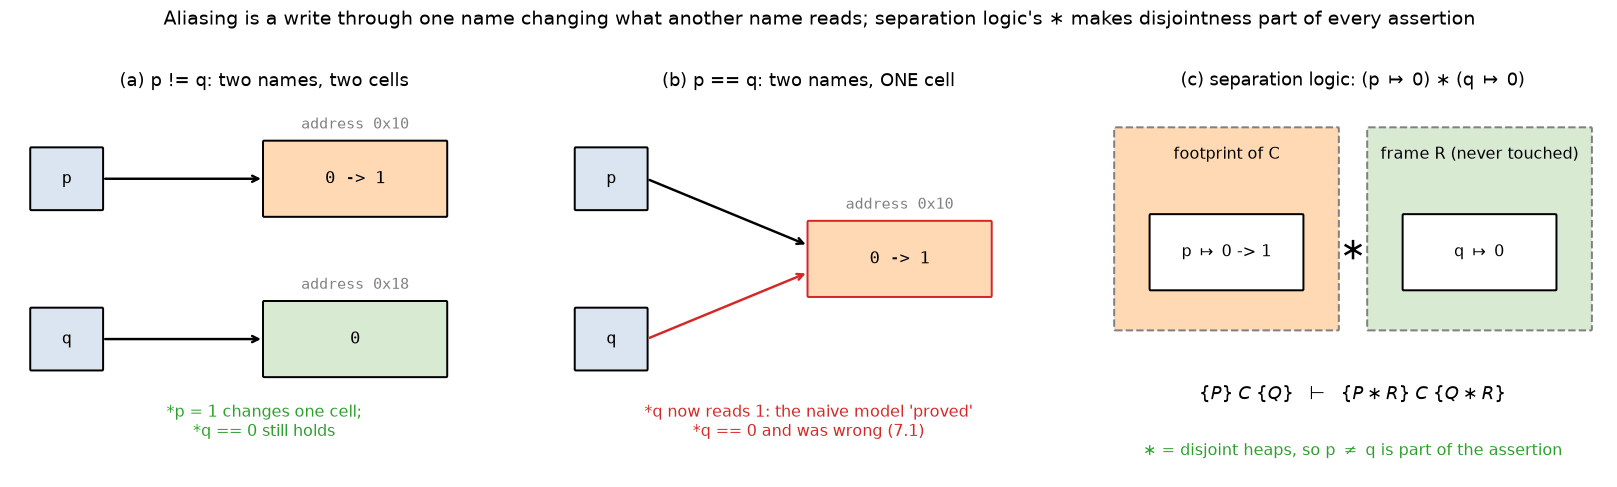

Panel (b) is 7.1's counterexample; in panel (c) the precondition already says the two cells are different,
so the frame R = q|->0 rides through *p = 1 untouched.


In [85]:
# 7.2  The heap picture: separate cells, aliased cells, and the separating conjunction.
def _s7_box(ax, x, y, w, h, text, fc, fs=11, ec="black", ls="-", mono=True):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec=ec, lw=1.3, ls=ls))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            family="monospace" if mono else None)


def _s7_arrow(ax, xy_from, xy_to, color="black"):
    ax.annotate("", xy=xy_to, xytext=xy_from,
                arrowprops=dict(arrowstyle="->", color=color, lw=1.6, shrinkA=2, shrinkB=2))


def _s7_draw_heaps():
    '''The heap picture: separate cells, aliased cells, and the separating conjunction.'''
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
    for ax in axes:
        ax.set_xlim(0, 10)
        ax.set_ylim(0, 5.7)
        ax.axis("off")
    # (a) no aliasing
    ax = axes[0]
    _s7_box(ax, 0.4, 4.0, 1.4, 0.9, "p", "#dbe5f1")
    _s7_box(ax, 0.4, 1.6, 1.4, 0.9, "q", "#dbe5f1")
    _s7_box(ax, 5.0, 3.9, 3.6, 1.1, "0 -> 1", "#ffd9b3")
    _s7_box(ax, 5.0, 1.5, 3.6, 1.1, "0", "#d9ead3")
    ax.text(6.8, 5.15, "address 0x10", ha="center", va="bottom", fontsize=9.5, family="monospace", color="gray")
    ax.text(6.8, 2.75, "address 0x18", ha="center", va="bottom", fontsize=9.5, family="monospace", color="gray")
    _s7_arrow(ax, (1.8, 4.45), (5.0, 4.45))
    _s7_arrow(ax, (1.8, 2.05), (5.0, 2.05))
    ax.text(5.0, 0.6, "*p = 1 changes one cell;\n*q == 0 still holds", ha="center", fontsize=10.5, color="#2ca02c")
    ax.set_title("(a) p != q: two names, two cells", fontsize=11.5)
    # (b) aliasing
    ax = axes[1]
    _s7_box(ax, 0.4, 4.0, 1.4, 0.9, "p", "#dbe5f1")
    _s7_box(ax, 0.4, 1.6, 1.4, 0.9, "q", "#dbe5f1")
    _s7_box(ax, 5.0, 2.7, 3.6, 1.1, "0 -> 1", "#ffd9b3", ec="#d62728")
    ax.text(6.8, 3.95, "address 0x10", ha="center", va="bottom", fontsize=9.5, family="monospace", color="gray")
    _s7_arrow(ax, (1.8, 4.45), (5.0, 3.45))
    _s7_arrow(ax, (1.8, 2.05), (5.0, 3.05), color="#d62728")
    ax.text(5.0, 0.6, "*q now reads 1: the naive model 'proved'\n*q == 0 and was wrong (7.1)",
            ha="center", fontsize=10.5, color="#d62728")
    ax.set_title("(b) p == q: two names, ONE cell", fontsize=11.5)
    # (c) separation logic
    ax = axes[2]
    _s7_box(ax, 0.3, 2.2, 4.4, 3.0, "", "#ffd9b3", ec="gray", ls="--")
    _s7_box(ax, 5.3, 2.2, 4.4, 3.0, "", "#d9ead3", ec="gray", ls="--")
    ax.text(2.5, 4.75, "footprint of C", ha="center", fontsize=10.5)
    ax.text(7.5, 4.75, "frame R (never touched)", ha="center", fontsize=10.5)
    _s7_box(ax, 1.0, 2.8, 3.0, 1.1, r"p $\mapsto$ 0 -> 1", "#ffffff", fs=10.5, mono=False)
    _s7_box(ax, 6.0, 2.8, 3.0, 1.1, r"q $\mapsto$ 0", "#ffffff", fs=10.5, mono=False)
    ax.text(5.0, 3.35, r"$\ast$", ha="center", va="center", fontsize=20)
    ax.text(5.0, 1.15, r"$\{P\}\;C\;\{Q\}\ \ \vdash\ \ \{P \ast R\}\;C\;\{Q \ast R\}$", ha="center", fontsize=12)
    ax.text(5.0, 0.3, r"$\ast$ = disjoint heaps, so p $\neq$ q is part of the assertion", ha="center",
            fontsize=10.5, color="#2ca02c")
    ax.set_title(r"(c) separation logic: (p $\mapsto$ 0) $\ast$ (q $\mapsto$ 0)", fontsize=11.5)
    fig.suptitle("Aliasing is a write through one name changing what another name reads; separation logic's "
                 r"$\ast$ makes disjointness part of every assertion", fontsize=12.5, y=1.02)
    plt.tight_layout()
    plt.show()


_s7_draw_heaps()
print("Panel (b) is 7.1's counterexample; in panel (c) the precondition already says the two cells are different,")
print("so the frame R = q|->0 rides through *p = 1 untouched.")

### 7.3 The frame problem: what does a call *not* change?

Verification scales because it is **modular**: at a call site the verifier uses the callee's contract, never its
body. So if `inc(p)` promises only `*p == old(*p) + 1`, the caller cannot carry `*q == 0` across the call — an
implementation that also scribbles on `*q` meets the contract. McCarthy & Hayes (Machine Intelligence 4, 1969)
named this the **frame problem**: saying what an action changes is easy; saying everything it leaves alone is not.
Verifiers answer with a **frame annotation** — Dafny's `modifies` for methods, `reads` for functions — which
enters the VC as a quantified formula over the memory before and after the call:
$\forall a.\; a \notin \{p\} \Rightarrow M'[a] = M[a]$. In Dafny (illustrative):

```dafny
class Cell { var val: int }

method Inc(c: Cell)
  modifies c                          // the frame: no other object changes
  ensures c.val == old(c.val) + 1
{
  c.val := c.val + 1;
}

method Client(a: Cell, b: Cell)
  requires a != b                     // delete this line and the assert below fails
  requires b.val == 0
  modifies a
{
  Inc(a);
  assert b.val == 0;                  // needs BOTH the callee's `modifies c` and `a != b`
}
```

Rust gets the frame from ownership, and rejects the aliased call before any verifier runs (illustrative):

```rust
fn inc(c: &mut i32) { *c += 1; }     // the type alone says: touches only *c

fn main() {
    let mut x = 5;
    std::mem::swap(&mut x, &mut x);  // error[E0499]: cannot borrow `x` as mutable more than once at a time
}
```

The cell builds the caller's VC three ways and replays every counterexample concretely — the first with an "evil"
`inc` that *satisfies its contract*: the verifier is right, the contract allows the clobbering. The solver handles
a `forall` hypothesis by **E-matching** (§7.4 builds it up: the quantifier is instantiated only with ground terms
that match its *trigger* pattern, here `M'[a]`). Two measured details. When a quantified VC is *false*, E-matching
alone can only say "unknown" (certifying a model means checking the `forall` against it), so we rerun with
**MBQI** — model-based quantifier instantiation, on in Z3's default configuration, off in Dafny's. And Z3 does not
instantiate these frames at all: in the Z3 version used here (printed below), its `solve-eqs`
preprocessing reads $\forall a.\ a \ne p \Rightarrow M'[a] = M[a]$ as a *definition*,
$M' = \lambda a.\ \mathrm{if}\ a = p\ \mathrm{then}\ \mathit{fresh}(a)\ \mathrm{else}\ M[a]$ — §7.1's store with an
unknown new value, recovered — and what is left of the quantifier is a tautology. The cell prints the rewritten
goal, and reruns a chain of $K$ calls $\mathtt{inc}(p_0), \dots, \mathtt{inc}(p_{K-1})$ with `solve-eqs` switched off
to see the frames instantiated.

The definitions are not free. After the rewrite, $M_{t+1}$ is an if-then-else over $M_t$, so reading $M_t$ at an
address unfolds a $t$-deep chain of if-then-else terms. Call $t$'s ensures clause reads $M_t[p_t]$, a $t$-deep
chain, which adds up to $0 + 1 + \dots + (K-1) = K(K-1)/2$ terms over the $K$ calls; the $K$ frame quantifiers share
one $K$-deep chain over their bound address, and the goal reads one more $K$-deep chain at $q$. That is $K(K+3)/2$
if-then-else terms, quadratic in $K$. The cell counts them, and measures the solver's work as Z3's `rlimit` count
(deterministic for a fresh context).

In [86]:
# 7.3  The frame problem as a VC: caller knows *q == 0, calls inc(p), asserts *q == 0.
_s7_CHAIN_KS = (1, 4, 16, 64)
_s7_FRAME_CHAIN_TIMEOUT_MS = 1000


def _s7_frame_vc(frame, distinct, dafny=True):
    '''Hypotheses + negated goal for the caller. M0 = memory before the call, M1 = after.'''
    Addr, Val = z3.BitVecSort(_s7_ADDR_BITS), z3.BitVecSort(_s7_VAL_BITS)
    M0, M1 = z3.Array('M0', Addr, Val), z3.Array('M1', Addr, Val)
    p, q, a = z3.BitVec('p', _s7_ADDR_BITS), z3.BitVec('q', _s7_ADDR_BITS), z3.BitVec('a', _s7_ADDR_BITS)
    s = _s7_solver(dafny=dafny)
    s.add(z3.Select(M0, q) == 0)                                   # caller's fact before the call
    s.add(z3.Select(M1, p) == z3.Select(M0, p) + 1)                # inc's ensures clause
    if frame:                                                      # inc's `modifies p`, as a quantifier
        s.add(z3.ForAll([a], z3.Implies(a != p, z3.Select(M1, a) == z3.Select(M0, a)),
                        patterns=[z3.Select(M1, a)]))
    if distinct:
        s.add(p != q)
    s.add(z3.Not(z3.Select(M1, q) == 0))                           # caller's assertion after the call
    verdict, st = _s7_check(s)
    cex = None
    if verdict == 'counterexample':
        m = s.model()
        ev = lambda t: m.eval(t, model_completion=True)
        cex = dict(p=ev(p).as_long(), q=ev(q).as_long(), old_p=ev(z3.Select(M0, p)).as_signed_long(),
                   new_q=ev(z3.Select(M1, q)).as_signed_long())
    return verdict, st, cex


def _s7_inc(mem, p):
    '''The honest implementation.'''
    mem[p] = wrap(mem[p] + 1)


def _s7_inc_evil(mem, p, q, junk):
    '''Also satisfies "ensures *p == old(*p) + 1" -- and scribbles on *q.'''
    mem[p] = wrap(mem[p] + 1)
    mem[q] = junk


def _s7_frame_chain_solver(K, ctx, solve_eqs=True):
    '''K calls inc(p_1) ... inc(p_K), each with its modifies frame, none on q; goal: *q unchanged.
    Built in its own Z3 context, so the rlimit count measures this query alone.'''
    Addr, Val = z3.BitVecSort(_s7_ADDR_BITS, ctx), z3.BitVecSort(_s7_VAL_BITS, ctx)
    Ms = [z3.Array(f'M{t}', Addr, Val) for t in range(K + 1)]
    ps = [z3.BitVec(f'p{t}', _s7_ADDR_BITS, ctx) for t in range(K)]
    q, a = z3.BitVec('q', _s7_ADDR_BITS, ctx), z3.BitVec('a', _s7_ADDR_BITS, ctx)
    s = _s7_solver(_s7_FRAME_CHAIN_TIMEOUT_MS, ctx=ctx, extra=None if solve_eqs else {'solve_eqs': False})
    for t in range(K):
        s.add(z3.Select(Ms[t + 1], ps[t]) == z3.Select(Ms[t], ps[t]) + 1)
        s.add(z3.ForAll([a], z3.Implies(a != ps[t], z3.Select(Ms[t + 1], a) == z3.Select(Ms[t], a)),
                        patterns=[z3.Select(Ms[t + 1], a)]))
        s.add(q != ps[t])
    s.add(z3.Not(z3.Select(Ms[K], q) == z3.Select(Ms[0], q)))
    return s


def _s7_after_solve_eqs(K):
    '''Run Z3's own simplify + solve-eqs tactics on the chain VC. Returns the rewritten goal, which of the
    post-call memories M1..MK still occur in it, and how many distinct if-then-else terms it contains.'''
    ctx = z3.Context()
    g = z3.Goal(ctx=ctx)
    g.add(*_s7_frame_chain_solver(K, ctx).assertions())
    pre = z3.TryFor(z3.Then(z3.Tactic('simplify', ctx), z3.Tactic('solve-eqs', ctx)),    # bounded, like every
                    10 * _s7_FRAME_CHAIN_TIMEOUT_MS, ctx)(g)[0]                         # other Z3 call
    names, seen, todo, n_ite = set(), set(), list(pre), 0
    while todo:                                   # walk the term DAG once (printing it would expand sharing)
        t = todo.pop()
        if t.get_id() in seen:
            continue
        seen.add(t.get_id())
        if z3.is_quantifier(t):
            todo.append(t.body())
        elif z3.is_app(t):
            if t.num_args() == 0:
                names.add(t.decl().name())
            n_ite += z3.is_app_of(t, z3.Z3_OP_ITE)
            todo.extend(t.children())
    return pre, [t for t in range(1, K + 1) if f'M{t}' in names], n_ite


def _s7_demo_frame():
    rows, cexs = [], {}
    for label, frame, distinct in [("ensures only, p != q", False, True),
                                   ("ensures + modifies {p}", True, False),
                                   ("ensures + modifies {p} + p != q", True, True)]:
        verdict, st, cex = _s7_frame_vc(frame, distinct)
        mbqi = '-'
        if verdict == 'unknown':          # E-matching cannot build a model for a quantified formula ...
            mbqi, _, cex = _s7_frame_vc(frame, distinct, dafny=False)   # ... MBQI (Z3's default) can
        cexs[label] = cex
        rows.append([label, verdict, mbqi, st['inst']])
    show_table(["what the caller knows about inc(p)", "Dafny settings", "rerun with MBQI", "E-matching instances"],
               rows)
    c = cexs["ensures only, p != q"]
    if c is not None:
        heap = {c['p']: c['old_p'], c['q']: 0}
        old_p = heap[c['p']]
        _s7_inc_evil(heap, c['p'], c['q'], c['new_q'])
        print(f"\ncounterexample 1 (p = {c['p']:#x} != q = {c['q']:#x}): replayed with an evil inc that writes "
              f"*q = {c['new_q']}: contract holds: {heap[c['p']] == wrap(old_p + 1)}, caller's assert fails: "
              f"{heap[c['q']] != 0}")
    c = cexs["ensures + modifies {p}"]
    if c is not None:
        heap = {c['p']: 0}
        heap[c['q']] = 0
        _s7_inc(heap, c['p'])
        print(f"counterexample 2 (p {'==' if c['p'] == c['q'] else '!='} q): replayed with the HONEST inc: "
              f"*q = {heap[c['q']]} after the call, caller's assert fails: {heap[c['q']] != 0}")

    pre = _s7_after_solve_eqs(1)[0]
    print(f"\nZ3 {z3.get_version_string()}: the K = 1 chain VC after Z3's simplify + solve-eqs tactics "
          "(M1 has been replaced by a definition):")
    for f in pre:
        print("    " + " ".join(str(f).split()))
    rows, used, ites = [], {}, {}
    for K in _s7_CHAIN_KS:
        row = [K]
        for on in (True, False):
            verdict, st = _s7_check(_s7_frame_chain_solver(K, z3.Context(), solve_eqs=on))
            used[(K, on)] = (verdict, st)
            row += [verdict, st['inst'], f"{st['rlimit']:,}"]
        _, left, ites[K] = _s7_after_solve_eqs(K)
        row[4:4] = [len(left), f"{ites[K]:,}"]
        rows.append(row)
    show_table(["K calls", "*q unchanged?", "instances", "rlimit", "M1..MK left after solve-eqs",
                "if-then-else terms", "solve-eqs OFF", "instances", "rlimit"], rows)
    on = [used[(K, True)] for K in _s7_CHAIN_KS]
    off_inst = [used[(K, False)][1]['inst'] for K in _s7_CHAIN_KS]
    growth = on[-1][1]['rlimit'] / on[0][1]['rlimit']
    print("Without a frame the contract really permits clobbering *q; with it, aliasing is the only hole left.")
    off_open = [K for K in _s7_CHAIN_KS if used[(K, False)][0] != 'proved']
    print(f"With solve-eqs on, E-matching makes {sum(st['inst'] for _, st in on)} instances in the whole sweep: each "
          "frame became a definition of the new memory. Switched off, the frames are instantiated "
          f"({', '.join(map(str, off_inst))} instances)"
          + (f" and K = {', '.join(map(str, off_open))} is not proved within the {_s7_FRAME_CHAIN_TIMEOUT_MS} ms "
             "timeout." if off_open else "."))
    both = [K for K in _s7_CHAIN_KS if used[(K, True)][0] == used[(K, False)][0] == 'proved']
    cheaper_off = [K for K in both if used[(K, False)][1]['rlimit'] < used[(K, True)][1]['rlimit']]
    if cheaper_off:
        print("So the rewrite is not a free win: with the frames instantiated instead, the work is lower at K = "
              + " and ".join(f"{K} ({used[(K, False)][1]['rlimit']:,} vs {used[(K, True)][1]['rlimit']:,} rlimit)"
                             for K in cheaper_off)
              + (f", but K = {', '.join(map(str, off_open))} times out, while the rewritten VC is proved at every K."
                 if off_open and all(v == 'proved' for v, _ in on) else "."))
    pairs = list(zip(_s7_CHAIN_KS, _s7_CHAIN_KS[1:]))
    term_x = [ites[b] / ites[a] for a, b in pairs]
    work_x = [used[(b, True)][1]['rlimit'] / used[(a, True)][1]['rlimit'] for a, b in pairs]
    quad = all(ites[K] == K * (K + 3) // 2 for K in _s7_CHAIN_KS)
    print(f"The definitions are not free. The rewritten VC has K(K+3)/2 if-then-else terms at every K: {quad}"
          + (", so it grows quadratically" if quad else "") + f"; the solver's work "
          f"grows {growth:,.0f}x from K = {_s7_CHAIN_KS[0]} to K = {_s7_CHAIN_KS[-1]}. Step by step "
          f"({', '.join(f'{a}->{b}' for a, b in pairs)}): terms x{', x'.join(f'{r:.1f}' for r in term_x)}; "
          f"work x{', x'.join(f'{r:.1f}' for r in work_x)}"
          + (" -- at the top end the work outgrows the formula." if work_x[-1] > term_x[-1] else "."))


if HAVE_Z3:
    _s7_demo_frame()
else:
    print("Z3 not installed: skipping the frame-problem VCs.")

what the caller knows about inc(p)  Dafny settings  rerun with MBQI  E-matching instances
-----------------------------------------------------------------------------------------
ensures only, p != q                counterexample  -                0                   
ensures + modifies {p}              unknown         counterexample   0                   
ensures + modifies {p} + p != q     proved          -                0                   

counterexample 1 (p = 0xffffffffffffffff != q = 0x0): replayed with an evil inc that writes *q = -1: contract holds: True, caller's assert fails: True
counterexample 2 (p == q): replayed with the HONEST inc: *q = 1 after the call, caller's assert fails: True

Z3 5.3.1: the K = 1 chain VC after Z3's simplify + solve-eqs tactics (M1 has been replaced by a definition):
    array-def!0[p0] == 1 + M0[p0]
    ForAll(a, Or(a == p0, If(a == p0, array-def!0[a], M0[a]) == M0[a]))
    Not(q == p0)
    Not(If(q == p0, array-def!0[q], M0[q]) == M0[q])


K calls  *q unchanged?  instances  rlimit     M1..MK left after solve-eqs  if-then-else terms  solve-eqs OFF  instances  rlimit    
-----------------------------------------------------------------------------------------------------------------------------------
1        proved         0          605        0                            2                   proved         1          619       
4        proved         0          3,553      0                            14                  proved         7          2,098     
16       proved         0          60,337     0                            152                 proved         31         7,978     
64       proved         0          2,458,993  0                            2,144               unknown        23638      12,347,852
Without a frame the contract really permits clobbering *q; with it, aliasing is the only hole left.
With solve-eqs on, E-matching makes 0 instances in the whole sweep: each frame became a definition of the ne

### 7.4 Quantifiers: binary search and E-matching

A lower-bound binary search's specification is three quantifiers and its loop invariant two more (illustrative
Dafny; the cell encodes these VCs):

```dafny
method LowerBound(a: array<int>, key: int) returns (lo: int)
  requires forall i, j :: 0 <= i < j < a.Length ==> a[i] <= a[j]      // sorted
  ensures 0 <= lo <= a.Length
  ensures forall k :: 0 <= k < lo ==> a[k] < key
  ensures forall k :: lo <= k < a.Length ==> a[k] >= key
{
  lo := 0;
  var hi := a.Length;
  while lo < hi
    invariant 0 <= lo <= hi <= a.Length
    invariant forall k :: 0 <= k < lo ==> a[k] < key
    invariant forall k :: hi <= k < a.Length ==> a[k] >= key
    decreases hi - lo
  {
    var mid := lo + (hi - lo) / 2;
    if a[mid] < key { lo := mid + 1; } else { hi := mid; }
  }
}
```

Once quantifiers meet arithmetic and uninterpreted functions there is no complete decision procedure (§4's
decidability map), so SMT solvers use a heuristic: **E-matching** (the technique of the Simplify prover, described
by Detlefs, Nelson & Saxe, JACM 2005; made efficient in Z3 by de Moura & Bjørner, CADE 2007). Each `forall`
hypothesis carries a **trigger** (a *pattern*): a term containing all its bound variables, such as `a[i]`. Whenever
a *ground* term matching the pattern appears in the E-graph (§4's congruence closure: ground terms modulo known
equalities), the solver instantiates the quantifier with that substitution and adds the instance as an ordinary
ground fact. A quantifier is never "understood"; it is only ever instantiated.

Take the `then` branch. The negated goal $\exists k.\ 0 \le k \le mid \wedge a[k] \ge key$ becomes a fresh constant
$k_0$, and with it the ground term $a[k_0]$. The proof needs sortedness at exactly $(i, j) = (k_0, mid)$, and the
multi-pattern $\{a[i], a[j]\}$ fires on the ground terms $a[k_0]$ and $a[mid]$: one sortedness instance
does it (the table's counts also include instances of the invariant's own quantifiers).

Sortedness can also be written $\forall i.\ 0 \le i \wedge i+1 < n \Rightarrow a[i] \le a[i+1]$, trigger $a[i]$.
Over $\mathbb{Z}$ the two forms are equivalent (induction on $j - i$; the cell checks it on all small arrays). For
E-matching they are different problems: getting from the successor form to $a[k_0] \le a[mid]$ for *symbolic*
$k_0 < mid$ takes induction, which instantiation never performs (§10 makes this the central limit of automation).
Worse, every instance $a[i] \le a[i+1]$ creates a term $a[i+1]$ that matches the trigger again: a **matching
loop** (§7.5).

In [87]:
# 7.4  Binary search's VCs, with quantified pre/invariants, under two formulations of "sorted".
from bisect import bisect_left as _s7_bisect_left


def _s7_bsearch_vcs(sorted_form):
    '''{name: VC} for LowerBound with a: Array(Int, Int), n = a.Length (mathematical integers).'''
    A = z3.Array('a', z3.IntSort(), z3.IntSort())
    n, key, lo, hi = z3.Ints('n key lo hi')
    i, j, k = z3.Ints('i j k')
    sel = lambda t: z3.Select(A, t)
    if sorted_form == 'pairwise':
        srt = z3.ForAll([i, j], z3.Implies(z3.And(0 <= i, i < j, j < n), sel(i) <= sel(j)),
                        patterns=[z3.MultiPattern(sel(i), sel(j))])
    else:   # successor form: equivalent over Z, but its trigger a[i] re-matches its own instance's a[i+1]
        srt = z3.ForAll([i], z3.Implies(z3.And(0 <= i, i + 1 < n), sel(i) <= sel(i + 1)), patterns=[sel(i)])

    def inv(l, h):
        return z3.And(0 <= l, l <= h, h <= n,
                      z3.ForAll([k], z3.Implies(z3.And(0 <= k, k < l), sel(k) < key), patterns=[sel(k)]),
                      z3.ForAll([k], z3.Implies(z3.And(h <= k, k < n), sel(k) >= key), patterns=[sel(k)]))
    mid = lo + (hi - lo) / 2            # Z3 Int division by a positive constant = floor = MiniPy's >> 1
    pre = z3.And(n >= 0, srt)
    post = z3.And(0 <= lo, lo <= n,
                  z3.ForAll([k], z3.Implies(z3.And(0 <= k, k < lo), sel(k) < key)),
                  z3.ForAll([k], z3.Implies(z3.And(lo <= k, k < n), sel(k) >= key)))
    return {
        'init':          z3.Implies(pre, inv(0, n)),
        'mid in bounds': z3.Implies(z3.And(pre, inv(lo, hi), lo < hi), z3.And(0 <= mid, mid < n)),
        'then preserves': z3.Implies(z3.And(pre, inv(lo, hi), lo < hi, sel(mid) < key), inv(mid + 1, hi)),
        'else preserves': z3.Implies(z3.And(pre, inv(lo, hi), lo < hi, sel(mid) >= key), inv(lo, mid)),
        'variant':       z3.Implies(z3.And(pre, inv(lo, hi), lo < hi),
                                    z3.And(hi - lo > 0, hi - (mid + 1) < hi - lo, mid - lo < hi - lo)),
        'exit => post':  z3.Implies(z3.And(pre, inv(lo, hi), z3.Not(lo < hi)), post),
    }


def _s7_prove(vc, timeout_ms=1000, dafny=True):
    s = _s7_solver(timeout_ms, dafny=dafny)
    s.add(z3.Not(vc))
    return _s7_check(s)


def _s7_lower_bound(a, key, at_loop_head=None):
    '''The program, concretely. at_loop_head(lo, hi), if given, is called every time the loop test runs.'''
    lo, hi = 0, len(a)
    while True:
        if at_loop_head is not None:
            at_loop_head(lo, hi)
        if not lo < hi:
            return lo
        mid = lo + ((hi - lo) >> 1)
        if a[mid] < key:
            lo = mid + 1
        else:
            hi = mid


def _s7_concrete_checks(max_len=6, values=range(4)):
    '''Oracle 1: bisect_left. Oracle 2: the loop invariant holds at every loop head of the real program.
    Oracle 3: pairwise-sorted <=> successor-sorted on every small array.'''
    runs, mismatches, heads = 0, 0, Counter()
    for L in range(max_len + 1):
        for a in itertools.combinations_with_replacement(values, L):     # every sorted array
            for key in range(min(values) - 1, max(values) + 2):
                def inv(lo, hi):
                    heads[0 <= lo <= hi <= L and all(a[t] < key for t in range(lo))
                          and all(a[t] >= key for t in range(hi, L))] += 1
                runs += 1
                mismatches += _s7_lower_bound(a, key, inv) != _s7_bisect_left(a, key)
    arrays = equiv_bad = 0
    for L in range(6):
        for a in itertools.product(range(3), repeat=L):                # every array, sorted or not
            arrays += 1
            pw = all(a[x] <= a[y] for x in range(L) for y in range(x + 1, L))
            sc = all(a[x] <= a[x + 1] for x in range(L - 1))
            equiv_bad += pw != sc
    return runs, mismatches, sum(heads.values()), heads[False], arrays, equiv_bad


def _s7_demo_bsearch():
    vcs = {form: _s7_bsearch_vcs(form) for form in ('pairwise', 'successor')}
    rows, verdicts = [], {}
    for name in vcs['pairwise']:
        out = [name]
        for form in ('pairwise', 'successor'):
            verdict, st = _s7_prove(vcs[form][name])
            verdicts[(form, name)] = verdict
            out += [verdict + (" (timeout)" if st['reason'] == 'timeout' else ""), st['inst']]
        rows.append(out)
    show_table(["VC", "sorted pairwise", "instances", "sorted by successor", "instances"], rows)
    print()
    for name in ('then preserves', 'else preserves'):
        v, st = _s7_prove(vcs['successor'][name], dafny=False)
        verdicts[('successor+mbqi', name)] = v
        print(f"successor form, '{name}', with Z3's DEFAULT config (MBQI on): {v} "
              f"({st['reason'] or 'answered'}, {st['inst']} instances in ~{st['ms']:.0f} ms)")
    runs, bad, heads, inv_fail, arrays, equiv_bad = _s7_concrete_checks()
    print(f"cross-check: lower_bound == bisect_left on {runs} (sorted array, key) runs: {bad} mismatches; "
          f"invariant violated at {inv_fail} of {heads} loop heads")
    print(f"cross-check: pairwise-sorted == successor-sorted on all {arrays} arrays of length <= 5 over 0..2: "
          f"{equiv_bad} disagreements")
    pw_all = all(v == 'proved' for (form, _), v in verdicts.items() if form == 'pairwise')
    open_vcs = {form: sum(verdicts[(form, n)] != 'proved' for n in ('then preserves', 'else preserves'))
                for form in ('successor', 'successor+mbqi')}
    print(f"Same program, same meaning of 'sorted': the pairwise form proves every VC: {pw_all}. The successor form")
    print(f"leaves {open_vcs['successor']}/2 preservation VCs unproved under Dafny's settings and "
          f"{open_vcs['successor+mbqi']}/2 with MBQI on -- they need induction.")


if HAVE_Z3:
    _s7_demo_bsearch()
else:
    print("Z3 not installed: skipping the binary-search VCs.")

VC              sorted pairwise  instances  sorted by successor  instances
--------------------------------------------------------------------------
init            proved           0          proved               0        
mid in bounds   proved           0          proved               0        
then preserves  proved           6          unknown              1497     
else preserves  proved           6          unknown              531      
variant         proved           0          proved               0        
exit => post    proved           4          proved               6        



successor form, 'then preserves', with Z3's DEFAULT config (MBQI on): unknown (timeout, 16812 instances in ~1003 ms)


successor form, 'else preserves', with Z3's DEFAULT config (MBQI on): unknown (timeout, 17502 instances in ~1006 ms)
cross-check: lower_bound == bisect_left on 1260 (sorted array, key) runs: 0 mismatches; invariant violated at 0 of 4444 loop heads
cross-check: pairwise-sorted == successor-sorted on all 364 arrays of length <= 5 over 0..2: 0 disagreements
Same program, same meaning of 'sorted': the pairwise form proves every VC: True. The successor form
leaves 2/2 preservation VCs unproved under Dafny's settings and 2/2 with MBQI on -- they need induction.


### 7.5 Triggers and matching loops

Choosing a trigger is choosing which instances will ever exist, and it fails in two directions:

- **Too strict**: the pattern never matches, so a *valid* goal gets no instance. $\forall x.\ f(g(x)) = x$ with
  trigger $f(g(x))$ cannot prove $g(a) = g(b) \Rightarrow a = b$: the problem has $g(a), g(b)$ but no
  $f(g(\cdot))$ term. Trigger $g(x)$ can.
- **Too liberal — a matching loop**: an instance creates a new term that matches again. Canonical:
  $\forall x.\ f(x) = f(g(x))$ with trigger $f(x)$: $f(a)$ yields $f(g(a))$, which yields $f(g(g(a)))$, … Trigger
  $g(x)$ terminates: it fires only on $g$-terms already present, and its instances create none.

Z3 defends itself with **generations**: input terms have generation 0, a term created by an instance has generation
1 + the highest generation among the terms that matched, and an instance whose cost (weight + generation, Z3's
default `qi.cost`) exceeds `qi.eager_threshold` is delayed. At the final check, delayed instances with cost up to
`qi.lazy_threshold` (default 20) are still made; the rest are reported as *missed* and the answer is "unknown
(incomplete quantifiers)". All runs use Dafny's settings: `smt.qi.eager_threshold` = 44, `auto_config` off,
`smt.case_split` = 3 and `smt.delay_units` from Dafny's
[`DafnyOptions.SetZ3Options`](https://github.com/dafny-lang/dafny/blob/master/Source/DafnyCore/DafnyOptions.cs), and
MBQI off from Boogie's defaults ([`Z3.cs`](https://github.com/boogie-org/boogie/blob/master/Source/Provers/SMTLib/Z3.cs)).
**Registered prediction:** *a matching loop makes Z3 instantiate without bound until the timeout.* The cell
measures one loop axiom, then two ($g_0, g_1$), and checks the one-loop cap against the two thresholds.

**Derivation for two loop axioms.** Take the valid goal $f(a) = f(w(a))$ with $w$ a word of length $d$ over
$g_0, g_1$. Under trigger $f(x)$ each $f$-term of generation $t$ matches both axioms and spawns two $f$-terms of
generation $t+1$; the two roots $f(a)$ and $f(w(a))$ are expanded breadth-first until generation $d$, where the trees
meet: $2\cdot(2 + 4 + \dots + 2^d) = 4(2^d - 1)$ instances. Trigger $g_i(x)$ fires once per $g$-subterm of $w(a)$:
exactly $d$ instances. The cell checks both counts.

In [88]:
# 7.5  Matching loops, measured: forall x. f(x) == f(g_i(x)) for one or two functions g_i.
_s7_LOOP_BUDGETS_MS = (200, 400, 800)    # time budgets for the invalid goal
_s7_CHAIN_TIMEOUT_MS = 1000             # cap per chain query; the loop-trigger sweep stops at its first timeout
_s7_CHAIN_MAX_D = 20
_s7_EAGER_SWEEP = (10, 20, 44, 100)     # qi.eager_threshold values for the one-loop cap check


def _s7_loop_check(n_axioms, trigger, goal_depth=None, timeout_ms=1000, eager=None):
    '''Axioms forall x. f(x) == f(g_i(x)), i < n_axioms, with trigger 'f' (pattern f(x)) or 'g' (pattern g_i(x)).
    goal_depth None: the INVALID goal f(a) == f(b). Otherwise the VALID goal f(a) == f(w(a)), |w| = goal_depth.
    eager overrides Dafny's qi.eager_threshold (44).'''
    S = z3.DeclareSort('S')
    f = z3.Function('f', S, S)
    gs = [z3.Function(f'g{i}', S, S) for i in range(n_axioms)]
    x, a, b = z3.Const('x', S), z3.Const('a', S), z3.Const('b', S)
    s = _s7_solver(timeout_ms, extra=None if eager is None else {'qi.eager_threshold': float(eager)})
    for g in gs:
        s.add(z3.ForAll([x], f(x) == f(g(x)), patterns=[f(x) if trigger == 'f' else g(x)]))
    if goal_depth is None:
        s.add(f(a) != f(b))
    else:
        t = a
        for step in range(goal_depth):
            t = gs[step % n_axioms](t)
        s.add(f(a) != f(t))
    return _s7_check(s)


def _s7_strict_trigger_check(trigger):
    '''forall x. f(g(x)) == x (g has a left inverse) proves g injective -- if the trigger ever fires.'''
    S = z3.DeclareSort('S')
    f, g = z3.Function('f', S, S), z3.Function('g', S, S)
    x, a, b = z3.Const('x', S), z3.Const('a', S), z3.Const('b', S)
    s = _s7_solver(500)
    s.add(z3.ForAll([x], f(g(x)) == x, patterns=[f(g(x)) if trigger == 'fg' else g(x)]))
    s.add(g(a) == g(b), a != b)
    return _s7_check(s)


def _s7_short_reason(reason):
    '''Z3's reason for 'unknown', shortened for a table: the parenthesised cause if there is one, else as given.'''
    m = re.search(r"\(([^()]*)\)\s*$", reason)
    return m.group(1) if m else (reason or '-')


def _s7_loops_invalid():
    '''(1) The invalid goal under each trigger; the one-loop cap against the thresholds; the prediction.'''
    out = {}
    print("(1) invalid goal f(a) == f(b)  (a counterexample exists: g = identity, f(a) != f(b))")
    rows = []
    for n_ax, trig in [(1, 'f'), (1, 'g'), (2, 'f'), (2, 'g')]:
        for budget in (_s7_LOOP_BUDGETS_MS if (n_ax, trig) == (2, 'f') else _s7_LOOP_BUDGETS_MS[-1:]):
            v, st = _s7_loop_check(n_ax, trig, None, budget)
            out[(n_ax, trig, budget)] = st
            rows.append([n_ax, f"{'f(x)' if trig == 'f' else 'g_i(x)'}", budget, v,
                         _s7_short_reason(st['reason']), st['inst'], st['missed'], f"{st['ms']:.1f}"])
    show_table(["loop axioms", "trigger", "budget ms", "verdict", "reason", "instances", "missed", "ms"], rows)
    one = out[(1, 'f', _s7_LOOP_BUDGETS_MS[-1])]
    two = out[(2, 'f', _s7_LOOP_BUDGETS_MS[-1])]
    print(f"full reason for the one-loop stop: '{one['reason']}'")
    lazy = float(z3.get_param('smt.qi.lazy_threshold'))
    cap = {e: _s7_loop_check(1, 'f', None, _s7_LOOP_BUDGETS_MS[-1], eager=e)[1]['inst'] for e in _s7_EAGER_SWEEP}
    print(f"one loop axiom, instances made vs qi.eager_threshold (qi.lazy_threshold = {lazy:g}): "
          + ", ".join(f"{e} -> {n}" for e, n in cap.items())
          + f";  equal to 2 x max(eager, lazy) every time: {all(n == 2 * max(e, lazy) for e, n in cap.items())}")
    stopped = [n for n, st in ((1, one), (2, two)) if st['reason'] != 'timeout']
    why = ("the generation threshold caps the DEPTH of a chain (2 roots x 44 generations); it does not cap "
           "BREADTH, and two loops double the terms every generation" if stopped == [1] else
           "see the table")
    print(f"registered prediction: a matching loop makes Z3 instantiate until the timeout | measured: ONE loop "
          f"axiom: {one['inst']} instances, '{one['reason'] or 'answered'}' after {one['ms']:.1f} ms; TWO loop "
          f"axioms: {two['inst']} instances, '{two['reason'] or 'answered'}' at the {_s7_LOOP_BUDGETS_MS[-1]} ms "
          f"budget | verdict: {'RIGHT' if not stopped else 'WRONG'}"
          + (f" (the {' and '.join(map(str, stopped))}-axiom loop stopped by itself)" if stopped else "")
          + f" -- {why}")
    return out


if HAVE_Z3:
    _s7_LOOP_INVALID = _s7_loops_invalid()
else:
    print("Z3 not installed: skipping the matching-loop measurements.")

(1) invalid goal f(a) == f(b)  (a counterexample exists: g = identity, f(a) != f(b))


loop axioms  trigger  budget ms  verdict  reason                  instances  missed  ms    
-------------------------------------------------------------------------------------------
1            f(x)     800        unknown  incomplete quantifiers  88         2       0.8   
1            g_i(x)   800        unknown  incomplete quantifiers  0          0       0.4   
2            f(x)     200        unknown  timeout                 96185      0       250.9 
2            f(x)     400        unknown  timeout                 186696     0       517.2 
2            f(x)     800        unknown  timeout                 336987     0       1013.4
2            g_i(x)   800        unknown  incomplete quantifiers  0          0       0.5   
full reason for the one-loop stop: 'smt tactic failed to show goal to be sat/unsat (incomplete quantifiers)'
one loop axiom, instances made vs qi.eager_threshold (qi.lazy_threshold = 20): 10 -> 40, 20 -> 40, 44 -> 88, 100 -> 200;  equal to 2 x max(eager, lazy) eve

On an invalid goal the loops decide how long Z3 burns before saying "unknown". On a *valid* goal they decide
whether the proof is found at all: the next cell sweeps the goal depth $d$ to check the $4(2^d-1)$ and $d$ counts
derived above, finds the depth at which the generation cap stops a single loop, and tries the too-strict trigger.

In [89]:
# 7.5  Valid goals: instance counts against the derivation, the depth cap, and a trigger that never fires.
def _s7_loops_valid():
    print("(2) valid goal f(a) == f(w(a)), |w| = d, two loop axioms")
    chain = {'f': [], 'g': []}
    for trig in ('f', 'g'):
        for d in range(1, _s7_CHAIN_MAX_D + 1):
            v, st = _s7_loop_check(2, trig, d, _s7_CHAIN_TIMEOUT_MS)
            chain[trig].append((d, v, st['inst'], st['ms']))
            if v != 'proved':
                break                                   # cap: stop the sweep at the first failure
    fin = [(d, inst) for d, v, inst, _ in chain['f'] if v == 'proved']
    formula_ok = all(inst == 4 * (2 ** d - 1) for d, inst in fin if d >= 2)
    g_ok = all(inst == d for d, v, inst, _ in chain['g'] if v == 'proved')
    d_fail = [d for d, v, _, _ in chain['f'] if v != 'proved']
    print(f"trigger f(x): proved d = 1..{fin[-1][0]}; instances == 4(2^d - 1) at every proved d >= 2: {formula_ok} "
          f"(at d = 1 the very first instance closes the goal: {fin[0][1]}); "
          f"d = {d_fail[0] if d_fail else '-'}: {chain['f'][-1][1]} after ~{chain['f'][-1][3]:.0f} ms "
          f"({chain['f'][-1][2]} instances)")
    print(f"trigger g_i(x): proved all d = 1..{chain['g'][-1][0]}, instances == d every time: {g_ok}")

    one_chain = []
    for d in range(1, 121):
        v, st = _s7_loop_check(1, 'f', d, _s7_CHAIN_TIMEOUT_MS)
        one_chain.append((d, v))
        if v != 'proved':
            break
    v_g, st_g = _s7_loop_check(1, 'g', 120, _s7_CHAIN_TIMEOUT_MS)
    print(f"one loop axiom, trigger f(x): proves chains up to d = {one_chain[-2][0]}, then '{one_chain[-1][1]}' at "
          f"d = {one_chain[-1][0]} (the generation cap); trigger g(x) at d = 120: {v_g} with {st_g['inst']} instances")

    print("\n(3) too-strict trigger: forall x. f(g(x)) == x  |-  g(a) == g(b) ==> a == b")
    for trig, label in [('fg', 'f(g(x))'), ('g', 'g(x)')]:
        v, st = _s7_strict_trigger_check(trig)
        print(f"    trigger {label:8s}: {v:8s} {st['inst']} instances")
    print("Matching loops rarely block a SHALLOW proof (the needed instance comes first); they bite on deep or")
    print("invalid goals - which is exactly when you need a fast, informative answer.")
    return dict(chain=chain, fin=fin, d_fail=d_fail)


if HAVE_Z3:
    _s7_LOOP_VALID = _s7_loops_valid()
else:
    print("Z3 not installed: skipping the matching-loop measurements.")

(2) valid goal f(a) == f(w(a)), |w| = d, two loop axioms


trigger f(x): proved d = 1..16; instances == 4(2^d - 1) at every proved d >= 2: True (at d = 1 the very first instance closes the goal: 1); d = 17: unknown after ~1280 ms (380871 instances)
trigger g_i(x): proved all d = 1..20, instances == d every time: True
one loop axiom, trigger f(x): proves chains up to d = 45, then 'unknown' at d = 46 (the generation cap); trigger g(x) at d = 120: proved with 120 instances

(3) too-strict trigger: forall x. f(g(x)) == x  |-  g(a) == g(b) ==> a == b
    trigger f(g(x)) : unknown  0 instances
    trigger g(x)    : proved   2 instances
Matching loops rarely block a SHALLOW proof (the needed instance comes first); they bite on deep or
invalid goals - which is exactly when you need a fast, informative answer.


The mechanism and the measurement side by side: the term tree a looping trigger grows, and the instance counts it
costs on the valid goal against the derivation.

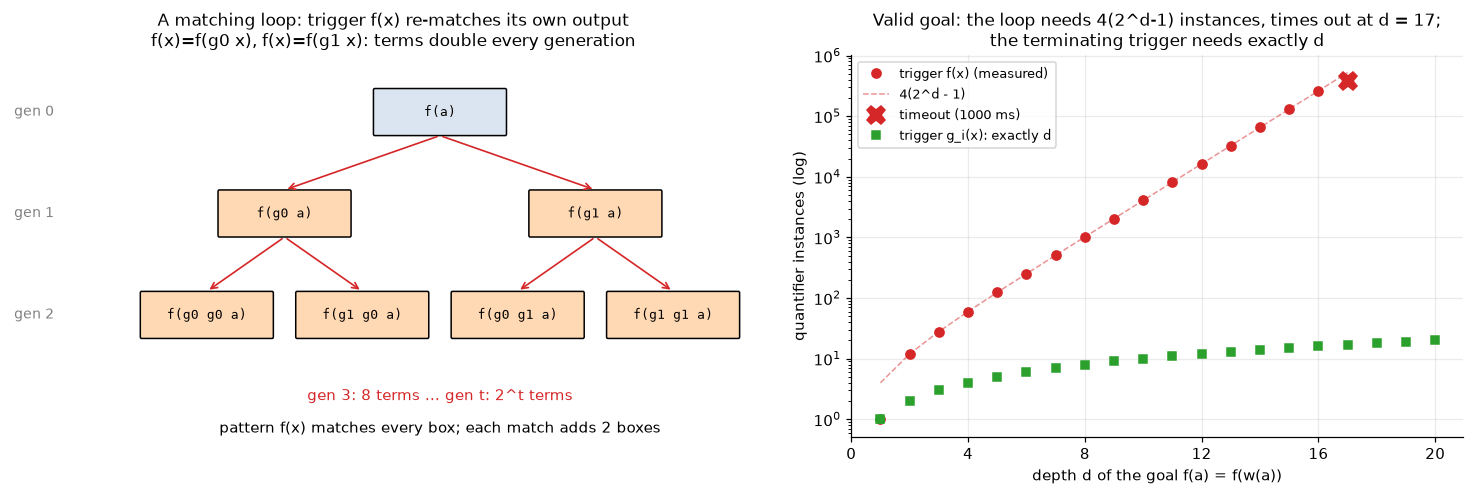

A trigger is a program for the solver: f(x) here is an exponential-time program, g(x) a linear one.


In [90]:
# 7.5  Figure: the matching-loop term tree, and instances vs goal depth.
def _s7_draw_loops(data):
    fin, d_fail, chain = data['fin'], data['d_fail'], data['chain']
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw=dict(width_ratios=[1.25, 1]))
    ax = axes[0]
    ax.set_xlim(-1.9, 10.4)
    ax.set_ylim(-0.6, 4.1)
    ax.axis("off")
    levels = [["f(a)"], ["f(g0 a)", "f(g1 a)"],
              ["f(g0 g0 a)", "f(g1 g0 a)", "f(g0 g1 a)", "f(g1 g1 a)"]]
    pos = {}
    for gen, terms in enumerate(levels):
        y = 3.4 - 1.25 * gen
        for idx, term in enumerate(terms):
            xx = (idx + 0.5) * 10 / len(terms)
            pos[(gen, idx)] = (xx, y)
            ax.add_patch(FancyBboxPatch((xx - 1.05, y - 0.27), 2.1, 0.54, boxstyle="round,pad=0.02",
                                        fc="#ffd9b3" if gen else "#dbe5f1", ec="black", lw=1))
            ax.text(xx, y, term, ha="center", va="center", fontsize=8.5, family="monospace")
            if gen:
                px, py = pos[(gen - 1, idx // 2)]
                ax.annotate("", xy=(xx, y + 0.29), xytext=(px, py - 0.29),
                            arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.1))
        ax.text(-1.85, y, f"gen {gen}", ha="left", va="center", fontsize=9, color="gray")
    ax.text(5, -0.15, "gen 3: 8 terms ... gen t: 2^t terms", ha="center", fontsize=9.5, color="#d62728")
    ax.text(5, -0.55, "pattern f(x) matches every box; each match adds 2 boxes", ha="center", fontsize=9.5)
    ax.set_title("A matching loop: trigger f(x) re-matches its own output\n"
                 "f(x)=f(g0 x), f(x)=f(g1 x): terms double every generation", fontsize=11)

    ax = axes[1]
    dd = np.array([d for d, _ in fin])
    ax.semilogy(dd, [inst for _, inst in fin], "o", color="#d62728", label="trigger f(x) (measured)")
    dline = np.arange(1, (d_fail[0] if d_fail else dd[-1]) + 1)
    ax.semilogy(dline, 4 * (2.0 ** dline - 1), "--", color="#d62728", alpha=0.5, lw=1, label="4(2^d - 1)")
    if d_fail:
        ax.semilogy([d_fail[0]], [chain['f'][-1][2]], "X", color="#d62728", ms=12,
                    label=f"timeout ({_s7_CHAIN_TIMEOUT_MS} ms)")
    gd = [(d, inst) for d, v, inst, _ in chain['g'] if v == 'proved']
    ax.semilogy([d for d, _ in gd], [inst for _, inst in gd], "s", color="#2ca02c", ms=5,
                label="trigger g_i(x): exactly d")
    ax.set_xticks(range(0, _s7_CHAIN_MAX_D + 1, 4))
    ax.set_xlabel("depth d of the goal f(a) = f(w(a))")
    ax.set_ylabel("quantifier instances (log)")
    ax.set_title(f"Valid goal: the loop needs 4(2^d-1) instances, times out at d = {d_fail[0] if d_fail else '-'};"
                 "\nthe terminating trigger needs exactly d", fontsize=11)
    ax.legend(fontsize=8.5, loc="upper left")
    plt.tight_layout()
    plt.show()


if HAVE_Z3:
    _s7_draw_loops(_s7_LOOP_VALID)
    print("A trigger is a program for the solver: f(x) here is an exponential-time program, g(x) a linear one.")
else:
    print("Z3 not installed: no matching-loop figure.")

### 7.6 Proof instability

A VC that verifies today can fail tomorrow after an edit that does not change its meaning. Zhou et al. (*Mariposa*,
FMCAD 2023) measured this on 17,043 SMT queries from six verification projects (Dafny, F\*, Serval): they made
semantically equivalent **mutants** of each query — assertions *shuffled*, symbols *renamed*, solver *reseeded* — and
called a query unstable if some mutants verify and others do not. With Z3 4.12.1, 2.6% of queries were unstable, up
to 5.0% in one project; solver upgrades often made projects *less* stable; in the projects they broke down by method,
shuffling exposed the most instability. The most stable project (vWasm) got there by manual discipline: no nonlinear
arithmetic, reduced fuel for unrolling recursive definitions, few ambient lemmas, triggers chosen by hand. Leino &
Pit-Claudel (CAV 2016) had identified matching loops as a major cause and moved trigger selection, with matching-loop
detection, out of the solver and into Dafny.

The toy version: the whole binary-search method VC of §7.4 — all six obligations conjoined — as one query (Boogie
emits one VC per procedure), plus **ambient lemmas** — *true* consequences of `sorted` that a user or library
prelude might add "to help". `first` ($a[0] \le a[i]$) and `last` ($a[i] \le a[n-1]$) do not loop; `succ`
($a[i] \le a[i+1]$) and `pred` ($a[i-1] \le a[i]$) do. Each configuration gets 20 reseeded and 20 shuffled mutants,
each in a fresh Z3 context. Work is Z3's `rlimit` count — deterministic for a given Z3 version and query, unlike
wall-clock time, and what Boogie and Dafny expose as a resource limit (Mariposa measures time instead, since rlimit
may miss some work).

**Registered prediction:** *every lemma is a true consequence of `sorted`, so adding them can only help: no
configuration costs more than 2× the lemma-free work or spreads its mutants by more than 2×.*

ambient lemmas  looping?  verdicts (41 runs)  median rlimit  vs no lemmas  max/min across mutants
-------------------------------------------------------------------------------------------------
(none)          no        {'proved': 41}      11401          1.0x          1.01x                 
first           no        {'proved': 41}      14027          1.2x          1.20x                 
last            no        {'proved': 41}      13186          1.2x          1.09x                 
first+last      no        {'proved': 41}      16015          1.4x          1.18x                 
succ            yes       {'proved': 41}      13012          1.1x          1.20x                 
pred            yes       {'proved': 41}      55522          4.9x          5.29x                 
succ+pred       yes       {'proved': 41}      38665          3.4x          4.56x                 

registered prediction: true lemmas can only help (every configuration within 2x of the lemma-free work and spread) | 

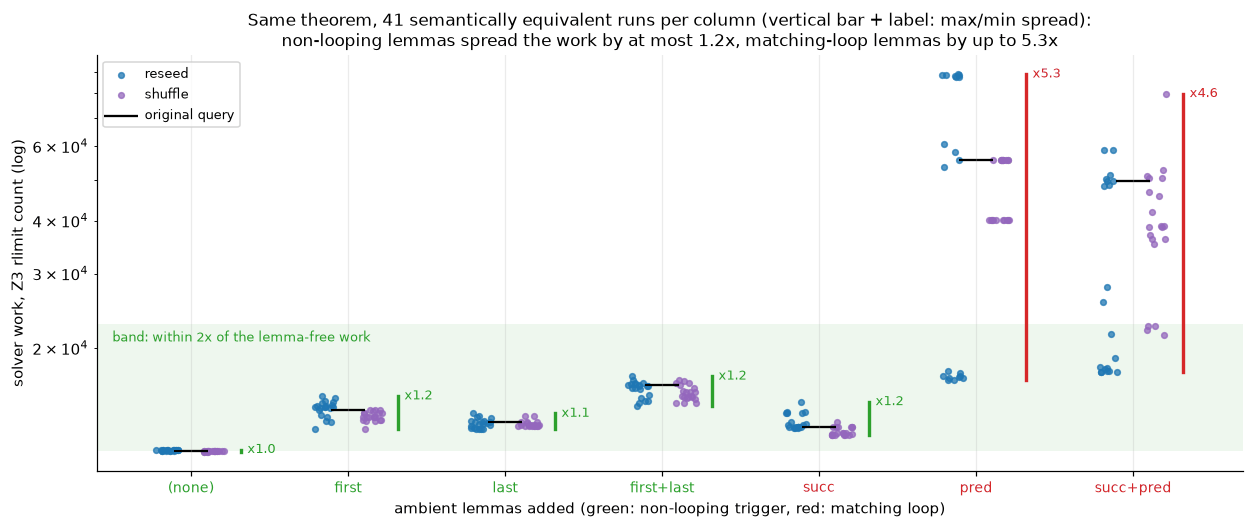

Non-looping lemmas keep the spread <= 1.20x; looping ones reach 5.3x. Not every
looping lemma hurts at this scale (succ stayed under 2x) -- you cannot tell in
advance, which is the problem. Mariposa's 2.6% unstable queries are this lottery at project scale.


In [91]:
# 7.6  Proof instability: the same theorem, semantically irrelevant mutations, measured by rlimit.
_s7_MUTANTS = 20                         # per mutation kind (reseed, shuffle) and per configuration
_s7_LEMMA_SETS = [(), ('first',), ('last',), ('first', 'last'), ('succ',), ('pred',), ('succ', 'pred')]
_s7_LOOPING = {'succ', 'pred'}


def _s7_method_query(ctx, lemmas):
    '''The whole LowerBound method VC -- all six obligations of 7.4 conjoined, as Boogie emits one VC per
    procedure -- as a list of assertions in context ctx.'''
    I = z3.IntSort(ctx)
    A = z3.Array('a', I, I)
    n, key, lo, hi = [z3.Int(v, ctx) for v in ('n', 'key', 'lo', 'hi')]
    i, j, k = [z3.Int(v, ctx) for v in 'ijk']
    sel = lambda t: z3.Select(A, t)
    sorted_pw = z3.ForAll([i, j], z3.Implies(z3.And(0 <= i, i < j, j < n), sel(i) <= sel(j)),
                          patterns=[z3.MultiPattern(sel(i), sel(j))])
    lemma = {   # all four are TRUE consequences of sorted_pw
        'first': z3.ForAll([i], z3.Implies(z3.And(0 <= i, i < n), sel(0) <= sel(i)), patterns=[sel(i)]),
        'last': z3.ForAll([i], z3.Implies(z3.And(0 <= i, i < n), sel(i) <= sel(n - 1)), patterns=[sel(i)]),
        'succ': z3.ForAll([i], z3.Implies(z3.And(0 <= i, i + 1 < n), sel(i) <= sel(i + 1)), patterns=[sel(i)]),
        'pred': z3.ForAll([i], z3.Implies(z3.And(1 <= i, i < n), sel(i - 1) <= sel(i)), patterns=[sel(i)]),
    }

    def inv(l, h):
        return z3.And(0 <= l, l <= h, h <= n,
                      z3.ForAll([k], z3.Implies(z3.And(0 <= k, k < l), sel(k) < key), patterns=[sel(k)]),
                      z3.ForAll([k], z3.Implies(z3.And(h <= k, k < n), sel(k) >= key), patterns=[sel(k)]))
    mid = lo + (hi - lo) / 2
    post = z3.And(0 <= lo, lo <= n,
                  z3.ForAll([k], z3.Implies(z3.And(0 <= k, k < lo), sel(k) < key)),
                  z3.ForAll([k], z3.Implies(z3.And(lo <= k, k < n), sel(k) >= key)))
    vcs = [inv(0, n),                                                                   # init
           z3.Implies(z3.And(inv(lo, hi), lo < hi), z3.And(0 <= mid, mid < n)),          # mid in bounds
           z3.Implies(z3.And(inv(lo, hi), lo < hi, sel(mid) < key), inv(mid + 1, hi)),   # then preserves
           z3.Implies(z3.And(inv(lo, hi), lo < hi, sel(mid) >= key), inv(lo, mid)),      # else preserves
           z3.Implies(z3.And(inv(lo, hi), lo < hi),                                       # variant
                      z3.And(hi - lo > 0, hi - (mid + 1) < hi - lo, mid - lo < hi - lo)),
           z3.Implies(z3.And(inv(lo, hi), z3.Not(lo < hi)), post)]                        # exit => post
    return [n >= 0, sorted_pw] + [lemma[x] for x in lemmas] + [z3.Not(z3.And(*vcs))]


def _s7_run_mutant(lemmas, kind, m):
    '''kind: 'original', 'reseed' (smt.random_seed = m) or 'shuffle' (assertion order permuted by seed m).'''
    ctx = z3.Context()                    # fresh context: rlimit counts only this query, term ids start afresh
    asserts = _s7_method_query(ctx, lemmas)
    if kind == 'shuffle':
        random.Random(_s7_SEED + m).shuffle(asserts)
    s = _s7_solver(3000, seed=m if kind == 'reseed' else 0, ctx=ctx)
    s.add(*asserts)
    return _s7_check(s)


def _s7_demo_instability():
    res = {}
    for lemmas in _s7_LEMMA_SETS:
        runs = [('original', _s7_run_mutant(lemmas, 'original', 0))]
        for kind in ('reseed', 'shuffle'):
            runs += [(kind, _s7_run_mutant(lemmas, kind, m)) for m in range(_s7_MUTANTS)]
        res[lemmas] = runs
    base = np.median([st['rlimit'] for _, (_, st) in res[()]])        # lemma-free work (median of its 41 runs)
    rows, summary = [], {}
    for lemmas, runs in res.items():
        work = np.array([st['rlimit'] for _, (_, st) in runs], dtype=float)
        verdicts = Counter(v for _, (v, _) in runs)
        spread, rel = work.max() / work.min(), np.median(work) / base
        summary[lemmas] = (spread, rel)
        rows.append(["+".join(lemmas) or "(none)", "yes" if set(lemmas) & _s7_LOOPING else "no",
                     dict(verdicts), int(np.median(work)), f"{rel:.1f}x", f"{spread:.2f}x"])
    show_table(["ambient lemmas", "looping?", "verdicts (41 runs)", "median rlimit", "vs no lemmas",
                "max/min across mutants"], rows)
    worst = max(summary, key=lambda L: max(summary[L]))
    calm = all(max(summary[L]) <= 2 for L in summary if not set(L) & _s7_LOOPING)
    with_lemmas = [L for L in summary if L]
    raised = [L for L in with_lemmas if summary[L][1] > 1]
    lowered = [L for L in with_lemmas if summary[L][1] < 1]
    calm_cost = max(summary[L][1] for L in with_lemmas if not set(L) & _s7_LOOPING)
    print(f"\nregistered prediction: true lemmas can only help (every configuration within 2x of the lemma-free "
          f"work and spread) | measured: lemma sets that raised the median work: {len(raised)} of "
          f"{len(with_lemmas)} (lowered it: {len(lowered)}); non-looping lemmas all within 2x: {calm}; worst = "
          f"'{'+'.join(worst)}' with {summary[worst][1]:.1f}x the median work and a {summary[worst][0]:.1f}x "
          f"spread | verdict: {'WRONG' if max(summary[worst]) > 2 else 'RIGHT'}"
          + (" -- a true lemma is still a trigger, and a looping trigger turns irrelevant choices (seed, order) "
             "into large work differences" if max(summary[worst]) > 2 else "")
          + (f"; and no lemma helped at all: even a non-looping one is one more quantifier to instantiate, "
             f"costing up to {calm_cost:.1f}x the lemma-free work" if not lowered else ""))
    all_proved = all(v == 'proved' for runs in res.values() for _, (v, _) in runs)
    calm_max = max(summary[L][0] for L in summary if not set(L) & _s7_LOOPING)
    loop_max = max(summary[L][0] for L in summary if set(L) & _s7_LOOPING)
    print(f"every one of the {sum(len(r) for r in res.values())} runs proved the theorem: {all_proved} -- at this "
          "scale the instability is in COST; a project whose rlimit sits near the cost turns it into failures")

    fig, ax = plt.subplots(figsize=(11.5, 4.9))
    g = np.random.default_rng(_s7_SEED)
    ax.axhspan(base, 2 * base, color="#2ca02c", alpha=0.08, lw=0)
    ax.text(-0.5, 1.93 * base, "band: within 2x of the lemma-free work", ha="left", va="top", fontsize=8.5,
            color="#2ca02c")
    labels = []
    for xi, (lemmas, runs) in enumerate(res.items()):
        labels.append("+".join(lemmas) or "(none)")
        for kind, color, dx in [('reseed', '#1f77b4', -0.15), ('shuffle', '#9467bd', 0.15)]:
            w = [st['rlimit'] for kk, (_, st) in runs if kk == kind]
            ax.scatter(xi + dx + g.uniform(-0.07, 0.07, len(w)), w, s=14, color=color, alpha=0.75,
                       label=kind if xi == 0 else None)
        ax.scatter([xi], [runs[0][1][1]['rlimit']], marker="_", s=500, color="black",
                   label="original query" if xi == 0 else None)
        w = [st['rlimit'] for _, (_, st) in runs]
        bad = max(w) / min(w) > 2
        ax.plot([xi + 0.32] * 2, [min(w), max(w)], color="#d62728" if bad else "#2ca02c", lw=2.2)
        ax.text(xi + 0.36, max(w), f"x{max(w) / min(w):.1f}", fontsize=8.5, va="center",
                color="#d62728" if bad else "#2ca02c")
    ax.set_yscale("log")
    ax.set_xlim(-0.6, len(res) - 0.3)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9)
    for tick, lemmas in zip(ax.get_xticklabels(), res):
        tick.set_color("#d62728" if set(lemmas) & _s7_LOOPING else "#2ca02c")
    ax.set_xlabel("ambient lemmas added (green: non-looping trigger, red: matching loop)")
    ax.set_ylabel("solver work, Z3 rlimit count (log)")
    ax.set_title("Same theorem, 41 semantically equivalent runs per column (vertical bar + label: max/min spread):\n"
                 f"non-looping lemmas spread the work by at most {calm_max:.1f}x, matching-loop lemmas by up to "
                 f"{loop_max:.1f}x", fontsize=11)
    ax.legend(fontsize=8.5, loc="upper left")
    plt.tight_layout()
    plt.show()
    tame = ["+".join(L) for L in summary if set(L) & _s7_LOOPING and summary[L][0] < 2]
    print(f"Non-looping lemmas keep the spread <= {calm_max:.2f}x; looping ones reach {loop_max:.1f}x. Not every")
    print(f"looping lemma hurts at this scale ({', '.join(tame) or 'none'} stayed under 2x) -- you cannot tell in")
    print("advance, which is the problem. Mariposa's 2.6% unstable queries are this lottery at project scale.")


if HAVE_Z3:
    _s7_demo_instability()
else:
    print("Z3 not installed: skipping the instability measurements.")

### 7.7 Where the effort goes

| problem | what the user sees | what the user writes | what removes it |
|---|---|---|---|
| aliasing (§7.1) | a counterexample with `p == q` (or, in a naive model, a false "proved") | `requires p != q` | separation logic's $\ast$; Rust's `&mut` uniqueness |
| frame (§7.3) | the caller cannot prove an untouched cell untouched | `modifies` / `reads` clauses, each a `forall` | the frame rule; ownership types (Prusti, Verus, Creusot) |
| quantified specs (§7.4) | "unknown" on a true VC | pairwise formulations, explicit lemmas, triggers | nothing in general: instantiation is a heuristic |
| matching loops (§7.5) | a timeout, or a quick "unknown (incomplete quantifiers)", instead of an answer | a better trigger, opaque definitions, limited fuel | trigger selection with loop detection (Dafny) |
| instability (§7.6) | a proof that flips after an irrelevant edit | smaller contexts, fewer ambient lemmas, resource limits | measuring it (Mariposa); decidable fragments |

Two of the remedies need a gloss. An **opaque** definition is one the solver sees only by name until a proof
explicitly reveals its body (Dafny's `opaque` and `reveal`), so outside those proofs its defining axiom makes no
instances at all.
**Fuel** caps how many times a recursive definition may be unfolded in one proof, which bounds the depth of the
chain that definition can grow.

Every fix either gives the solver information it cannot infer (distinctness, frames, the right instance) or takes
away work it would waste (loops, ambient lemmas), and each is written by someone who understands the solver's
heuristics — a different skill from understanding the program. That is much of what §11's proof:code ratios count
and what §13's LLM provers are trained to supply. It is also one reason the automatic invariant finders of §8 and §9
work over finite state or fixed abstract domains, where the solver is a decision procedure, not a heuristic.

## 8. Transition systems: model checking, memory models, liveness, refinement, k-induction, IC3, BDDs

So far every program was *sequential*. Add a second thread and the input gains a hidden dimension: the
**schedule**, which no test harness controls. This section therefore studies **transition systems**
$(S, \mathit{Init}, T)$: a set of states, the initial ones, and a relation $T$ saying which state may follow
which. A multithreaded program, a coherence protocol, a TLA+ spec and §6's x,y loop are all transition systems.
Every safety question below is about §2's reachable set $R$; liveness (§8.3) is about the cycles inside it.
There are two ways to answer them:

- **enumerate** $R$ state by state (§8.1–§8.4: the explicit-state checker, weak memory, liveness, refinement);
- describe sets of states by **formulas** and look for an inductive invariant (§8.5–§8.7: k-induction, IC3,
  BDDs).

### 8.1 Schedules explode; states explode more slowly

Take $n$ threads of $k$ atomic steps each. A schedule chooses which of the $nk$ time slots belong to each thread,
so there are $(nk)!/(k!)^n$ of them, which is $n^{nk}$ up to a factor polynomial in $k$. A stress test samples
schedules, yet most schedules pass through the same states. A **model checker** therefore enumerates *states*:
breadth-first search from $\mathit{Init}$, a hash set of states already seen, and a parent pointer per state.

- BFS dequeues states by depth, so the first violation it meets has a **shortest counterexample**.
- A reachable state with no successors that is not a legal final state is a **deadlock**.

`bfs_check` below is about 25 lines. TLC (TLA+) searches breadth-first by default, so its error traces are
shortest too (TLC options documentation, tlapl.us). SPIN (Promela) searches depth-first, with nested depth-first
search for liveness, partial-order reduction and bitstate hashing (Holzmann, IEEE TSE 1997). Both add
engineering (symmetry, compression, disk, parallelism), not a different idea: they enumerate states.

Small models are worth trusting. Lu et al. (ASPLOS 2008) studied 105 real concurrency bugs from MySQL, Apache,
Mozilla and OpenOffice. 96% manifest once an order between at most **two threads** is enforced, and 92% need a
particular order among at most four memory accesses. That is exactly the scale at which enumeration is cheap.

To run real algorithms we need a machine. `_s8_machine` executes one small program per thread (a dict
`pc -> instruction`, with one register `r` per thread) under a chosen **memory model**:

| instruction | meaning | instruction | meaning |
|---|---|---|---|
| `store v c` | `v := c` | `fence` | wait until my store buffer is empty (§8.2) |
| `store_r v a m` | `v := (r + a) mod m` | `tas v` | atomic test-and-set: if `v == 0` set it and enter, else retry |
| `load v` | `r := v` | `acquire v` | blocking lock: no move while `v == 1` |
| `branch v c` | read `v`, jump on `v == c` | `fai v m` | atomic fetch-and-increment `r := v; v := (v+1) mod m` |
| `branch_r v` | read `v`, jump on `v == r` | `crit`, `done` | critical section; thread finished |

The first models all run under **sequential consistency** (SC: every store reaches memory at once, and threads
simply interleave):

- the **lost update** (two threads each run `r := x; x := r + 1`) and two locks taken in opposite orders;
- the **naive flags** mutex: wait until the other's flag is down, then raise mine;
- **Peterson** (1981): raise my flag, give the turn away, wait while the other is interested *and* has the turn;
- the filter lock (Herlihy & Shavit's $n$-thread Peterson) for $n = 2..5$, never $n = 6$.

**Registered prediction (state explosion):** each extra thread multiplies the filter lock's reachable states by
20–25×. (A reader thinking "each thread only adds a few local states" would guess far less.)

The cell scores this on the model it was made for, whose wait test is one atomic step, and then counts again
with every shared read as a step of its own.

In [92]:
# 8.1 An explicit-state model checker, and a tiny shared-memory machine to run programs on.
_s8_MAX_STATES = 2_000_000   # state cap for every explicit-state run: a slower machine degrades to 'state_cap'
_s8_TSO_BUF = 3              # store-buffer slots per thread in the x86-TSO model (§8.2)


def _s8_put(tup, k, v):
    '''Copy of tuple `tup` with slot k replaced by v (states must be hashable, so they are tuples).'''
    return tup[:k] + (v,) + tup[k + 1:]


def _s8_path(parent, s):
    '''Follow parent pointers back to an initial state: [(None, s0), (label1, s1), ..., (labelN, s)].'''
    out = []
    while parent[s] is not None:
        prev, label = parent[s]
        out.append((label, s))
        s = prev
    out.append((None, s))
    return out[::-1]


def bfs_check(initial, successors, invariant, deadlock=False, is_final=None, max_states=None):
    '''Explicit-state safety checking by breadth-first search (TLC and SPIN, minus the engineering).
    initial: iterable of hashable states; successors(s) -> iterable of (action_label, next_state);
    invariant(s) -> bool, checked when s is dequeued. With deadlock=True a reachable state without
    successors is also an error unless is_final(s). BFS dequeues states in order of depth, so the first
    violation it meets has a SHORTEST trace. Returns dict(ok, kind, trace, n_states): ok=True (safe),
    ok=False (kind 'invariant' | 'deadlock', trace = [(None, s0), (label1, s1), ...]), or ok=None
    (kind 'state_cap').'''
    cap = _s8_MAX_STATES if max_states is None else max_states
    parent, queue = {}, deque()
    for s in initial:
        if s not in parent:
            parent[s] = None
            queue.append(s)
    while queue:
        s = queue.popleft()
        if not invariant(s):
            return dict(ok=False, kind='invariant', trace=_s8_path(parent, s), n_states=len(parent))
        moves = list(successors(s))
        if deadlock and not moves and not (is_final is not None and is_final(s)):
            return dict(ok=False, kind='deadlock', trace=_s8_path(parent, s), n_states=len(parent))
        for label, t in moves:
            if t not in parent:
                parent[t] = (s, label)
                queue.append(t)
        if len(parent) > cap:
            return dict(ok=None, kind='state_cap', trace=None, n_states=len(parent))
    return dict(ok=True, kind=None, trace=None, n_states=len(parent))


def _s8_reachable(initial, successors):
    '''Every reachable state, by plain depth-first search: no invariant, no parent pointers. It is the second,
    independent traversal that the re-checks in this section compare bfs_check against.'''
    seen, stack = set(initial), list(initial)
    while stack:
        for _, t in successors(stack.pop()):
            if t not in seen:
                seen.add(t)
                stack.append(t)
    return seen


def _s8_machine(programs, init_mem, model='SC', buf_cap=_s8_TSO_BUF):
    '''A multiprocessor running programs[i] (a dict pc -> instruction) on thread i, as a transition system.
    Each thread has one register r. model='SC' (sequential consistency): a store hits memory at once.
    model='TSO' (x86-TSO): a store enters the thread's own FIFO store buffer; its loads see its newest
    buffered value first; draining the oldest entry to memory is a separate step the scheduler may take at
    any time; fences and atomic read-modify-writes wait for an empty buffer (MFENCE, LOCK prefix).
    State = (pcs, regs, mem, bufs), all tuples. Returns (initial_states, successors).'''
    names = sorted(init_mem)
    slot = {v: k for k, v in enumerate(names)}
    n = len(programs)
    start = ((0,) * n, (0,) * n, tuple(init_mem[v] for v in names), ((),) * n)

    def successors(s):
        for i, prog in enumerate(programs):
            yield from _s8_moves(i, prog, s, slot, model, buf_cap)
    return [start], successors


def _s8_moves(i, prog, s, slot, model, cap):
    '''All moves of thread i in state s: one buffer drain (TSO) and/or one step of its next instruction.'''
    pcs, regs, mem, bufs = s
    buf, tso = bufs[i], model == 'TSO'

    def read(v):                       # store forwarding: my newest buffered store to v wins
        for w, val in reversed(buf):
            if w == v:
                return val
        return mem[slot[v]]

    def goto(pc, r=None, store=None, rmw=None):
        '''Next state: thread i at pc, register r (if given); `store` = (var, val) is buffered under TSO and
        written through under SC; `rmw` = (var, val) is an atomic read-modify-write, always written through.'''
        m, b = mem, buf
        if store is not None:
            b, m = (buf + (store,), m) if tso else (buf, _s8_put(m, slot[store[0]], store[1]))
        if rmw is not None:
            m = _s8_put(m, slot[rmw[0]], rmw[1])
        return (_s8_put(pcs, i, pc), regs if r is None else _s8_put(regs, i, r), m, _s8_put(bufs, i, b))

    if tso and buf:                    # the oldest buffered store may drain to memory at any moment
        (v, val), rest = buf[0], buf[1:]
        yield f"P{i}: flush {v}={val}", (pcs, regs, _s8_put(mem, slot[v], val), _s8_put(bufs, i, rest))
    op, *a = prog[pcs[i]]
    room = not (tso and len(buf) >= cap)   # a full store buffer stalls the next store
    empty = not buf                        # fences and LOCKed instructions wait for an empty buffer
    cs = lambda pc: " -> CS" if prog[pc][0] == 'crit' else ""
    if op == 'store' and room:                         # var := const
        yield f"P{i}: {a[0]}:={a[1]}{cs(a[2])}", goto(a[2], store=(a[0], a[1]))
    elif op == 'store_r' and room:                     # var := (r + add) % mod
        val = (regs[i] + a[1]) % a[2]
        yield f"P{i}: {a[0]}:=r+{a[1]} ({val})", goto(a[3], store=(a[0], val))
    elif op == 'load':                                 # r := var
        yield f"P{i}: r:={a[0]} ({read(a[0])})", goto(a[1], r=read(a[0]))
    elif op == 'branch':                               # if var == const goto a[2] else a[3]  (one load)
        nxt = a[2] if read(a[0]) == a[1] else a[3]
        yield f"P{i}: read {a[0]}={read(a[0])}{cs(nxt)}", goto(nxt)
    elif op == 'branch_r':                             # if var == r goto a[1] else a[2]
        nxt = a[1] if read(a[0]) == regs[i] else a[2]
        yield f"P{i}: read {a[0]}={read(a[0])}{cs(nxt)}", goto(nxt)
    elif op == 'fence' and empty:
        yield f"P{i}: mfence", goto(a[0])
    elif op == 'tas' and empty:                        # atomic test-and-set: got it -> a[1], busy -> a[2]
        got = mem[slot[a[0]]]
        nxt = goto(a[1], rmw=(a[0], 1)) if got == 0 else goto(a[2])
        yield f"P{i}: tas {a[0]} ({got}){cs(a[1]) if got == 0 else ''}", nxt
    elif op == 'acquire' and empty and mem[slot[a[0]]] == 0:   # blocking lock: no move while held
        yield f"P{i}: acquire {a[0]}", goto(a[1], rmw=(a[0], 1))
    elif op == 'fai' and empty:                        # atomic fetch-and-increment: r := var; var += 1 mod
        got = mem[slot[a[0]]]
        yield f"P{i}: r:={a[0]}++ ({got})", goto(a[2], r=got, rmw=(a[0], (got + 1) % a[1]))
    elif op == 'crit':                                 # leave the critical section
        yield f"P{i}: exit CS", goto(a[0])
    # op == 'done': a finished thread has no moves


def _s8_in_cs(programs, s):
    '''Which threads are at a critical-section instruction in state s.'''
    return [programs[i][pc][0] == 'crit' for i, pc in enumerate(s[0])]


def _s8_counter_prog(m):
    '''m non-atomic increments of the shared x (load into r, store r + 1), then stop.'''
    prog = {}
    for k in range(m):
        prog[2 * k], prog[2 * k + 1] = ('load', 'x', 2 * k + 1), ('store_r', 'x', 1, 1 << 30, 2 * k + 2)
    prog[2 * m] = ('done',)
    return prog


_s8_cnt = _s8_machine([_s8_counter_prog(1)] * 2, {'x': 0})
_s8_cnt_R = _s8_reachable(*_s8_cnt)
_s8_cnt_end = sorted({s[2][0] for s in _s8_cnt_R if not list(_s8_cnt[1](s))})
print(f"two threads, each running r := x; x := r + 1 once: {len(_s8_cnt_R)} reachable states, final x in "
      f"{_s8_cnt_end}")
print("The machine alone already shows the lost update (x = 1); bfs_check turns it into a shortest trace next.")

two threads, each running r := x; x := r + 1 once: 13 reachable states, final x in [1, 2]
The machine alone already shows the lost update (x = 1); bfs_check turns it into a shortest trace next.


The four classic models now run under SC. Each verdict is re-checked without `bfs_check`: every counterexample
is replayed step by step, a brute-force search over all shorter paths confirms that none of them reaches the
bug, and a depth-first traversal counts every reachable state.

In [93]:
# 8.1 The classic models under sequential consistency, each verdict re-checked independently.
def _s8_naive_flags(i):
    '''"Wait until the other's flag is down, then raise mine": the first mutex everybody writes.'''
    return {0: ('branch', f'flag{1 - i}', 0, 1, 0), 1: ('store', f'flag{i}', 1, 2),
            2: ('crit', 3), 3: ('store', f'flag{i}', 0, 0)}


def _s8_peterson(i, fence=False):
    '''Peterson (1981) for thread i of 2: raise my flag, give the turn away, wait while the other is
    interested AND it is its turn. One load per step (pc 2 and 3), critical section at pc 4.'''
    j = 1 - i
    prog = {0: ('store', f'flag{i}', 1, 1), 1: ('store', 'turn', j, 6 if fence else 2),
            2: ('branch', f'flag{j}', 0, 4, 3), 3: ('branch', 'turn', i, 4, 2),
            4: ('crit', 5), 5: ('store', f'flag{i}', 0, 0)}
    if fence:
        prog[6] = ('fence', 2)          # drain my store buffer before I look at the other's flag
    return prog


def _s8_two_locks(first, second):
    '''acquire(first); acquire(second); critical section; release both; stop.'''
    return {0: ('acquire', first, 1), 1: ('acquire', second, 2), 2: ('crit', 3),
            3: ('store', second, 0, 4), 4: ('store', first, 0, 5), 5: ('done',)}


def _s8_replay_ok(initial, successors, trace, bad):
    '''Independent re-check of a counterexample: starts in an initial state, every step is a real
    transition, and only the last state is bad.'''
    if trace[0][1] not in list(initial):
        return False
    for (_, s), (label, t) in zip(trace, trace[1:]):
        if (label, t) not in list(successors(s)) or bad(s):
            return False
    return bad(trace[-1][1])


def _s8_no_shorter(initial, successors, bad, depth):
    '''Brute force over every path with fewer than `depth` steps: True iff none reaches a bad state.'''
    frontier = list(initial)
    for _ in range(depth):
        if any(bad(s) for s in frontier):
            return False
        frontier = [t for s in frontier for _, t in successors(s)]
    return True


def _s8_run_classics():
    '''Check lost update, naive flags, Peterson and the two-lock program; re-check every verdict
    independently (trace replay, brute-force "no shorter trace", DFS state count).'''
    out = {}
    models = [
        ("lost update: 2 x (r:=x; x:=r+1)", [_s8_counter_prog(1)] * 2, {'x': 0}, {}),
        ("naive flags mutex", [_s8_naive_flags(0), _s8_naive_flags(1)], {'flag0': 0, 'flag1': 0}, {}),
        ("Peterson mutex", [_s8_peterson(0), _s8_peterson(1)], {'flag0': 0, 'flag1': 0, 'turn': 0}, {}),
        ("two locks, opposite order", [_s8_two_locks('A', 'B'), _s8_two_locks('B', 'A')],
         {'A': 0, 'B': 0}, dict(deadlock=True))]
    for name, progs, mem, kw in models:
        init, succ = _s8_machine(progs, mem, 'SC')
        done = lambda s, P=progs: all(P[i][pc][0] == 'done' for i, pc in enumerate(s[0]))
        if name.startswith("lost"):              # when both threads are done, x must be 2
            inv = lambda s, done=done: not done(s) or s[2][0] == 2
        else:                                    # at most one thread in its critical section
            inv = lambda s, P=progs: sum(_s8_in_cs(P, s)) <= 1
        res = bfs_check(init, succ, inv, is_final=done, **kw)
        if res['kind'] == 'deadlock':
            bad = lambda s, succ=succ, done=done: not list(succ(s)) and not done(s)
        else:
            bad = lambda s, inv=inv: not inv(s)
        recheck = "-"
        if not res['ok']:
            recheck = (f"replay {'OK' if _s8_replay_ok(init, succ, res['trace'], bad) else 'FAILED'}, "
                       f"none shorter: {_s8_no_shorter(init, succ, bad, len(res['trace']) - 1)}")
        out[name] = dict(res, progs=progs, row=[
            name, "SAFE" if res['ok'] else f"{res['kind']} violated", res['n_states'],
            len(_s8_reachable(init, succ)), "-" if res['ok'] else len(res['trace']) - 1, recheck])
    return out


def _s8_lost_update_by_schedules():
    '''Oracle without any checker: execute every schedule of the 4 steps directly in Python.'''
    scheds = sorted(set(itertools.permutations("AABB")))
    lost = 0
    for sched in scheds:
        x, reg, step = 0, {}, {'A': 0, 'B': 0}
        for t in sched:
            if step[t] == 0:
                reg[t] = x                       # load
            else:
                x = reg[t] + 1                   # store
            step[t] += 1
        lost += (x != 2)
    return lost, len(scheds)


_s8_runs = _s8_run_classics()
show_table(["model (SC)", "verdict", "states seen (BFS stops at bug)", "all reachable (DFS)", "trace steps",
            "independent re-check"], [r['row'] for r in _s8_runs.values()])
_s8_lost = _s8_lost_update_by_schedules()
print(f"\noracle: running all {_s8_lost[1]} schedules of the lost-update program directly, {_s8_lost[0]} end "
      "with x == 1")
for _s8_name in ("naive flags mutex", "two locks, opposite order"):
    print(f"shortest counterexample, {_s8_name}: " +
          "  ->  ".join(lab for lab, _ in _s8_runs[_s8_name]['trace'][1:]))
print(f"Every bug sits at most {max(len(r['trace']) - 1 for r in _s8_runs.values() if not r['ok'])} steps deep, and "
      "BFS stopped as soon as it met it: no other trace is shorter.")

model (SC)                       verdict             states seen (BFS stops at bug)  all reachable (DFS)  trace steps  independent re-check         
----------------------------------------------------------------------------------------------------------------------------------------------------
lost update: 2 x (r:=x; x:=r+1)  invariant violated  13                              13                   4            replay OK, none shorter: True
naive flags mutex                invariant violated  14                              16                   4            replay OK, none shorter: True
Peterson mutex                   SAFE                40                              40                   -            -                            
two locks, opposite order        deadlock violated   7                               23                   2            replay OK, none shorter: True

oracle: running all 6 schedules of the lost-update program directly, 4 end with x == 1
shortest counterex

How big do state spaces get? The next cell counts schedules against states for the shared counter, then grows
the filter lock from 2 to 5 threads, first with the wait test as one atomic step (the model the prediction was
made for), then with one shared read per step.

schedule formula (nk)!/(k!)^n matches brute-force enumeration on 6 small cases: True
threads n  steps each k  schedules (nk)!/(k!)^n  reachable states (BFS)
-----------------------------------------------------------------------
2          4             70                      75                    
2          8             12870                   939                   
2          12            2.7e+06                 5089                  
3          4             34650                   2358                  
3          8             9.47e+09                161891                
4          4             6.31e+07                107177                

filter lock n  states, atomic wait test  states, one read per step  mutual exclusion  time (s, approx.)
-------------------------------------------------------------------------------------------------------
2              34                        48                         holds             0.00             
3              705        

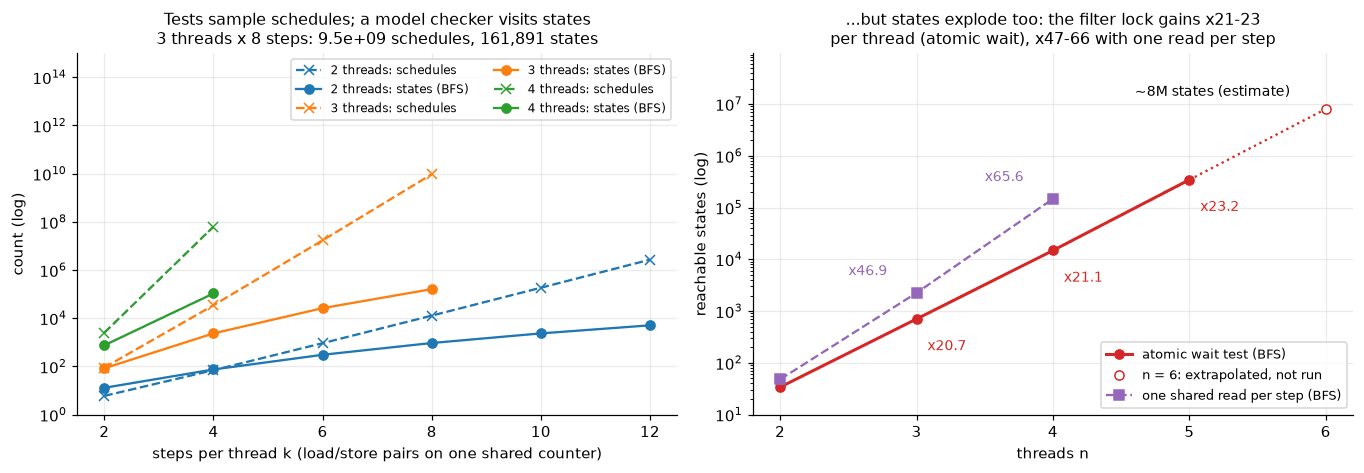

A schedule-sampling stress test faces ~1e10 runs where the checker needs ~1e5 states; merging equal
states is the entire trick. It buys a lot, but not enough: states are still exponential in threads.


In [94]:
# 8.1 States versus schedules, and the filter lock: how big do state spaces get?
def _s8_filter_lock(n, atomic_wait=True):
    '''Filter lock (Herlihy & Shavit) for n threads: n-1 "waiting rooms". At level L thread i announces
    level[i] = L, volunteers victim[L] = i, and waits while it is the victim and another thread is at a
    level >= L. Local state (stage, L, j). atomic_wait=True evaluates the whole wait condition in one step.
    atomic_wait=False reads ONE shared variable per step, closer to real hardware: victim[L] first (j = 0),
    then each other thread's level (j = 1..n-1), testing the whole condition again whenever a level is >= L.'''
    others = {i: [k for k in range(n) if k != i] for i in range(n)}

    def passed(pc, i, L):                          # through the waiting room at level L
        return _s8_put(pc, i, ('set', L + 1, 0) if L + 1 < n else ('cs', 0, 0))

    def successors(s):
        pc, level, victim = s
        for i in range(n):
            st, L, j = pc[i]
            if st == 'nc':
                yield f"P{i}: start", (_s8_put(pc, i, ('set', 1, 0)), level, victim)
            elif st == 'set':
                yield f"P{i}: level:={L}", (_s8_put(pc, i, ('vic', L, 0)), _s8_put(level, i, L), victim)
            elif st == 'vic':
                yield f"P{i}: victim[{L}]:={i}", (_s8_put(pc, i, ('wait', L, 0)), level, _s8_put(victim, L, i))
            elif st == 'wait' and atomic_wait:
                if not (victim[L] == i and any(level[k] >= L for k in others[i])):
                    yield f"P{i}: pass level {L}", (passed(pc, i, L), level, victim)
            elif st == 'wait' and j == 0:              # read victim[L]: not me -> through
                nxt = passed(pc, i, L) if victim[L] != i else _s8_put(pc, i, ('wait', L, 1))
                yield f"P{i}: read victim[{L}]={victim[L]}", (nxt, level, victim)
            elif st == 'wait':                         # read the level of the j-th other thread
                k = others[i][j - 1]
                if level[k] >= L:
                    nxt = _s8_put(pc, i, ('wait', L, 0))
                else:
                    nxt = passed(pc, i, L) if j == n - 1 else _s8_put(pc, i, ('wait', L, j + 1))
                yield f"P{i}: read level[{k}]={level[k]}", (nxt, level, victim)
            else:                                      # 'cs': leave and reset my level
                yield f"P{i}: exit CS", (_s8_put(pc, i, ('nc', 0, 0)), _s8_put(level, i, 0), victim)
    start = (tuple(('nc', 0, 0) for _ in range(n)), (0,) * n, (0,) * n)
    return [start], successors


def _s8_explosion(filter_ns=(2, 3, 4, 5), fine_ns=(2, 3, 4)):
    '''(a) states vs schedules for n threads x k non-atomic increment steps; (b) filter lock, atomic wait
    test, n = 2..5; (c) filter lock, one read per step, n = 2..4.'''
    inter = {}
    for n, kmax in ((2, 12), (3, 8), (4, 4)):
        for k in range(2, kmax + 1, 2):
            init, succ = _s8_machine([_s8_counter_prog(k // 2)] * n, {'x': 0})
            inter[n, k] = (bfs_check(init, succ, lambda s: True)['n_states'],
                           math.factorial(n * k) // math.factorial(k) ** n)
    mutex = lambda s: sum(p[0] == 'cs' for p in s[0]) <= 1
    filt = {n: timed(bfs_check, *_s8_filter_lock(n), mutex) for n in filter_ns}   # n = 6: ~8M, never run
    fine = {n: timed(bfs_check, *_s8_filter_lock(n, atomic_wait=False), mutex) for n in fine_ns}  # n = 5: cap
    return inter, filt, fine


def _s8_count_schedules(n, k):
    '''Brute-force oracle for the schedule formula: distinct orderings of n threads x k steps.'''
    return len(set(itertools.permutations("".join(chr(65 + t) * k for t in range(n)))))


_s8_inter, _s8_filt, _s8_fine = _s8_explosion()
_s8_formula_ok = all(_s8_count_schedules(n, k) == math.factorial(n * k) // math.factorial(k) ** n
                     for n, k in ((2, 1), (2, 2), (2, 3), (2, 4), (3, 1), (3, 2)))
print(f"schedule formula (nk)!/(k!)^n matches brute-force enumeration on 6 small cases: {_s8_formula_ok}")
show_table(["threads n", "steps each k", "schedules (nk)!/(k!)^n", "reachable states (BFS)"],
           [[n, k, f"{sc:.3g}" if sc > 1e6 else sc, st] for (n, k), (st, sc) in _s8_inter.items() if k % 4 == 0])
_s8_fl = [(n, r['n_states'], r['ok'], dt) for n, (r, dt) in _s8_filt.items()]
_s8_ff = [(n, r['n_states'], r['ok'], dt) for n, (r, dt) in _s8_fine.items()]
_s8_growth = [b[1] / a[1] for a, b in zip(_s8_fl, _s8_fl[1:])]
_s8_growth_f = [b[1] / a[1] for a, b in zip(_s8_ff, _s8_ff[1:])]
_s8_band = lambda gs: all(19.5 <= g <= 25.5 for g in gs)          # 20-25x, rounded to the nearest integer
print()
show_table(["filter lock n", "states, atomic wait test", "states, one read per step", "mutual exclusion",
            "time (s, approx.)"],
           [[n, st, _s8_ff[k][1] if k < len(_s8_ff) else "not run (cap)",
             "holds" if ok and (k >= len(_s8_ff) or _s8_ff[k][2]) else "VIOLATED", f"{dt:.2f}"]
            for k, (n, st, ok, dt) in enumerate(_s8_fl)])
print(f"registered prediction: each extra thread multiplies the filter lock's states by 20-25x | measured on "
      f"the model as written (atomic wait test): {', '.join(f'{g:.1f}x' for g in _s8_growth)} | verdict: "
      f"{'RIGHT' if _s8_band(_s8_growth) else 'WRONG'}")
print(f"same lock, one shared read per step: {', '.join(f'{g:.1f}x' for g in _s8_growth_f)} -> the 20-25x band "
      f"{'holds' if _s8_band(_s8_growth_f) else 'FAILS'} there: the factor depends on how finely the model is "
      "cut, the exponential does not")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
for _s8_n, _s8_c in ((2, "C0"), (3, "C1"), (4, "C2")):
    _s8_ks = [k for (m, k) in _s8_inter if m == _s8_n]
    ax.plot(_s8_ks, [_s8_inter[_s8_n, k][1] for k in _s8_ks], "--", c=_s8_c, marker="x",
            label=f"{_s8_n} threads: schedules")
    ax.plot(_s8_ks, [_s8_inter[_s8_n, k][0] for k in _s8_ks], "-", c=_s8_c, marker="o",
            label=f"{_s8_n} threads: states (BFS)")
ax.set_yscale("log")
ax.set_xlabel("steps per thread k (load/store pairs on one shared counter)")
ax.set_ylabel("count (log)")
ax.set_title(f"Tests sample schedules; a model checker visits states\n3 threads x 8 steps: "
             f"{_s8_inter[3, 8][1]:.1e} schedules, {_s8_inter[3, 8][0]:,} states", fontsize=10.5)
ax.set_ylim(1, 1e15)
ax.legend(fontsize=8, ncol=2, loc="upper right")
ax = axes[1]
_s8_nn = [n for n, *_ in _s8_fl]
ax.semilogy(_s8_nn, [st for _, st, *_ in _s8_fl], "o-", c="#d62728", lw=2, label="atomic wait test (BFS)")
_s8_est6 = _s8_fl[-1][1] * _s8_growth[-1]
ax.semilogy([_s8_nn[-1], 6], [_s8_fl[-1][1], _s8_est6], ":", c="#d62728")
ax.semilogy([6], [_s8_est6], "o", c="#d62728", mfc="white", label="n = 6: extrapolated, not run")
ax.semilogy([n for n, *_ in _s8_ff], [st for _, st, *_ in _s8_ff], "s--", c="#9467bd", lw=1.5,
            label="one shared read per step (BFS)")
for (_s8_n, _s8_st, *_), _s8_g in zip(_s8_fl[1:], _s8_growth):
    ax.annotate(f"x{_s8_g:.1f}", xy=(_s8_n, _s8_st), xytext=(_s8_n + 0.08, _s8_st / 4), fontsize=9, color="#d62728")
for (_s8_n, _s8_st, *_), _s8_g in zip(_s8_ff[1:], _s8_growth_f):
    ax.annotate(f"x{_s8_g:.1f}", xy=(_s8_n, _s8_st), xytext=(_s8_n - 0.5, _s8_st * 2.2), fontsize=9, color="#9467bd")
ax.annotate(f"~{_s8_est6 / 1e6:.0f}M states (estimate)", xy=(6, _s8_est6), xytext=(4.6, _s8_est6 * 1.8),
            fontsize=9)
ax.set_xticks([2, 3, 4, 5, 6])
ax.set_ylim(10, _s8_est6 * 12)
ax.set_xlabel("threads n")
ax.set_ylabel("reachable states (log)")
ax.set_title(f"...but states explode too: the filter lock gains x{min(_s8_growth):.0f}-{max(_s8_growth):.0f}\n"
             f"per thread (atomic wait), x{min(_s8_growth_f):.0f}-{max(_s8_growth_f):.0f} with one read per step",
             fontsize=10.5)
ax.legend(fontsize=8.5, loc="lower right")
plt.tight_layout()
plt.show()
print("A schedule-sampling stress test faces ~1e10 runs where the checker needs ~1e5 states; merging equal")
print("states is the entire trick. It buys a lot, but not enough: states are still exponential in threads.")

The table is the model-checking workflow in miniature:

- the lost update in 4 steps (testing finds this one too: 4 of the 6 schedules lose an increment);
- the naive mutex in 4 steps, both threads reading before either writes (drawn below);
- Peterson safe on all 40 reachable states, and opposite lock order deadlocking in 2 steps.

Every trace was replayed independently and shown by brute force to be the shortest.

The figure shows both sides of the trade-off. 3 threads × 8 steps give ~$10^{10}$ schedules but only
~$1.6\cdot10^5$ states, which is why the checker beats stress testing. Yet the filter lock still gains ~20× per
thread with its wait test as one atomic step, so $n = 6$ would need roughly 8M states (an extrapolation). The
prediction was right for that model, and the finer model shows how little that means: with one shared read per
step the factor is ~47–66×. How finely the steps are cut moves the factor by 2–3×; the exponential stays. Real
checkers fight it with **partial-order reduction** (independent steps commute, so explore one order),
**symmetry reduction**, state compression, and symbolic methods (§8.5–§8.7).

This is how TLA+ is used at Amazon: a small model of a design, checked exhaustively, since 2011. TLC found a
DynamoDB data-loss bug whose shortest trace had 35 steps and which had passed design reviews, code reviews and
testing (Newcombe et al., CACM 2015). Since 2019 AWS has also used P, a language of communicating state
machines, for example to validate S3's move to strong read-after-write consistency (Brooker & Desai, ACM Queue
22(6), Feb 2025). At MongoDB, tests generated from a TLA+ state graph reached 100% branch coverage of a merge
module, against 21% for the hand-written tests and 92% for AFL fuzzing (Davis et al., VLDB 2020). What these
methods cost to learn, and why connecting a model to the code is the expensive part, are §12.3's subject. Model
checking (Clarke & Emerson 1981; Queille & Sifakis 1982) earned Clarke, Emerson and Sifakis the 2007 Turing Award.

Here is the naive mutex in TLA+ (*illustrative*; TLC with `INVARIANT MutualExclusion` prints the same 4-step
trace):

```tla
---------------------------- MODULE NaiveFlags ----------------------------
EXTENDS Integers
VARIABLES pc, flag
Init    == pc = [i \in {0, 1} |-> "wait"] /\ flag = [i \in {0, 1} |-> 0]
Wait(i) == pc[i] = "wait" /\ flag[1 - i] = 0 /\ pc' = [pc EXCEPT ![i] = "set"] /\ UNCHANGED flag
Set(i)  == pc[i] = "set" /\ flag' = [flag EXCEPT ![i] = 1] /\ pc' = [pc EXCEPT ![i] = "cs"]
Exit(i) == pc[i] = "cs" /\ flag' = [flag EXCEPT ![i] = 0] /\ pc' = [pc EXCEPT ![i] = "wait"]
Next    == \E i \in {0, 1} : Wait(i) \/ Set(i) \/ Exit(i)
Spec    == Init /\ [][Next]_<<pc, flag>>
MutualExclusion == ~(pc[0] = "cs" /\ pc[1] = "cs")
=============================================================================
```

### 8.2 Memory models: when correct code meets real hardware

The SAFE verdict for Peterson assumed **sequential consistency**, and x86 does not provide it. The **x86-TSO**
model (Sewell, Sarkar, Owens, Zappa Nardelli & Myreen, CACM 2010) makes precise what the vendor manuals left
ambiguous:

- each hardware thread has a FIFO **store buffer**, and a store drains to memory later;
- a load first takes the thread's own newest buffered store to that address;
- `MFENCE` waits for an empty buffer, and LOCK'd read-modify-writes flush it.

`_s8_machine(..., model='TSO')` implements these rules with 3 buffer slots, and draining is a separate step the
scheduler may take at any time. As an oracle, we first run the **litmus test** SB: `x := 1; r := y` ∥
`y := 1; r := x`. x86-TSO allows both reads to return 0, which no interleaving can produce. It forbids that
outcome once an `MFENCE` follows each store (test amd5 in Sewell et al.).

**Registered prediction:** Peterson stays safe under x86-TSO. (The tempting argument: TSO keeps each thread's
stores in order and never reorders loads.)

litmus test SB (store buffering) -- final (r0, r1) outcomes over all executions:
  SC             [(0, 1), (1, 0), (1, 1)]   (0, 0) possible: False
  TSO            [(0, 0), (0, 1), (1, 0), (1, 1)]   (0, 0) possible: True
  TSO + mfence   [(0, 1), (1, 0), (1, 1)]   (0, 0) possible: False
  x86-TSO (Sewell et al. 2010): (0,0) impossible under SC, ALLOWED on x86, forbidden with MFENCE -> model agrees

Peterson on   mutual exclusion  states  shortest trace  replayed
----------------------------------------------------------------
SC            holds             40      -               -       
TSO           VIOLATED          105     6 steps         True    
TSO + mfence  holds             178     -               -       

BFS's shortest trace: P0: flag0:=1 ; P0: turn:=1 ; P0: read flag1=0 -> CS ; P1: flag1:=1 ; P1: turn:=0 ; P1: read flag0=0 -> CS
   stale reads: step 6: P1 reads flag0 while P0's store to it is buffered
store-buffering schedule (6 steps, replayed as a counterexample: True

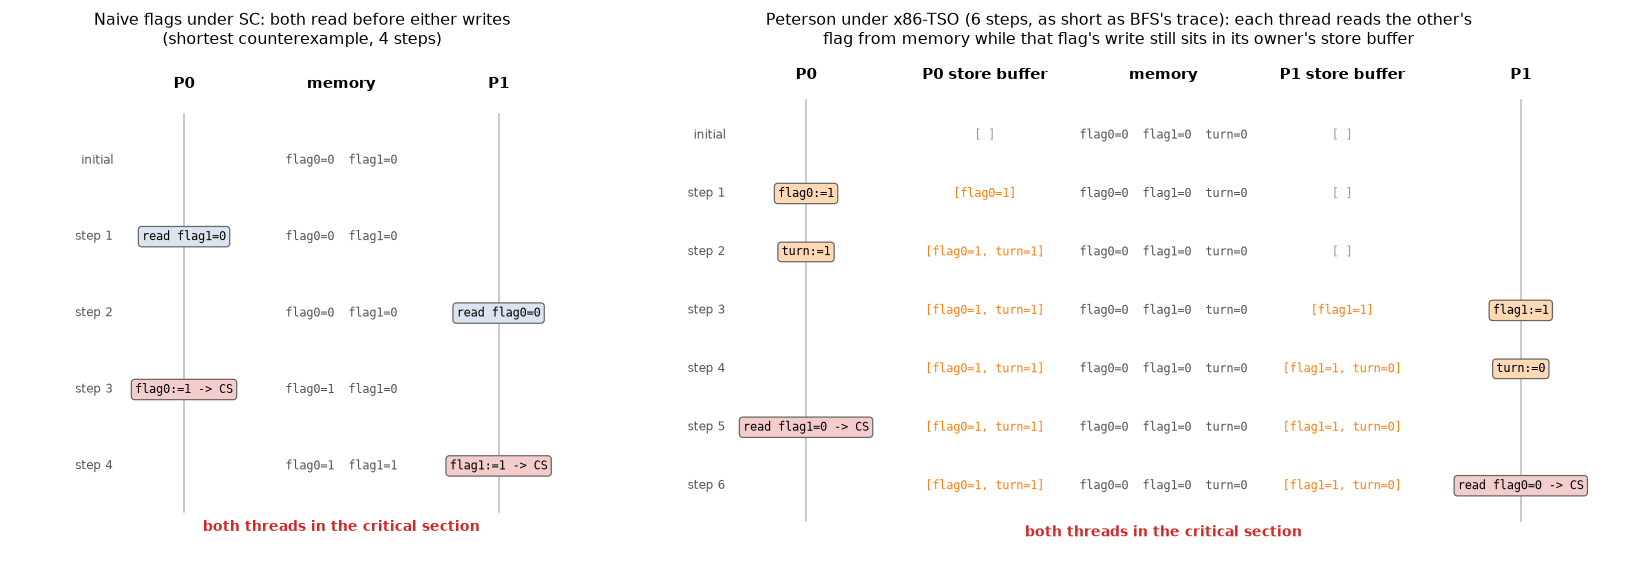

Adding one mfence per thread (drain my buffer before reading the other's flag) restores mutual exclusion: 178 states, all safe.
The algorithm was never wrong; the proof assumed a memory model the hardware does not provide.


In [95]:
# 8.2 Weak memory: the same programs on an x86-TSO machine (per-thread FIFO store buffers).
_s8_PET_MEM = {'flag0': 0, 'flag1': 0, 'turn': 0}


def _s8_litmus_sb(model, fence=False):
    '''The store-buffering litmus test (x86 manuals; Sewell et al. 2010): T0: x:=1; r:=y   T1: y:=1; r:=x.
    Returns the set of final (r0, r1) outcomes over ALL executions, with empty buffers at the end.'''
    def thread(mine, other):
        prog = {0: ('store', mine, 1, 3 if fence else 1), 1: ('load', other, 2), 2: ('done',)}
        if fence:
            prog[3] = ('fence', 1)
        return prog
    init, succ = _s8_machine([thread('x', 'y'), thread('y', 'x')], {'x': 0, 'y': 0}, model)
    return {s[1] for s in _s8_reachable(init, succ) if not list(succ(s))}   # registers of finished runs


def _s8_check_peterson(model, fence=False):
    '''Mutual exclusion for Peterson on the given memory model.'''
    progs = [_s8_peterson(0, fence), _s8_peterson(1, fence)]
    init, succ = _s8_machine(progs, _s8_PET_MEM, model)
    res = bfs_check(init, succ, lambda s: sum(_s8_in_cs(progs, s)) <= 1)
    if not res['ok']:
        res['replay'] = _s8_replay_ok(init, succ, res['trace'], lambda s: sum(_s8_in_cs(progs, s)) > 1)
    return dict(res, progs=progs)


def _s8_follow(initial, successors, labels):
    '''Build a trace by running a schedule given as action labels; each one must be enabled in turn.'''
    s = list(initial)[0]
    trace = [(None, s)]
    for lab in labels:
        s = dict(successors(s))[lab]               # KeyError if the action is not enabled here
        trace.append((lab, s))
    return trace


def _s8_stale_reads(trace):
    '''Reads in a TSO trace that returned a value different from a store to the same variable which ANOTHER
    thread has already executed and which still sits in that thread's store buffer (under SC it would be in
    memory). Returns [(step, reader, variable, writer)].'''
    out = []
    for step, ((_, s), (lab, _)) in enumerate(zip(trace, trace[1:]), 1):
        m = re.match(r"P(\d): read (\w+)=(-?\d+)", lab)
        if m:
            i, v, val = int(m.group(1)), m.group(2), int(m.group(3))
            for k, buf in enumerate(s[3]):
                pending = [w for var, w in buf if var == v]
                if k != i and pending and pending[-1] != val:
                    out.append((step, i, v, k))
    return out


_s8_sb = {(m, f): _s8_litmus_sb(m, f) for m, f in (('SC', False), ('TSO', False), ('TSO', True))}
print("litmus test SB (store buffering) -- final (r0, r1) outcomes over all executions:")
for (_s8_m, _s8_f), _s8_outs in _s8_sb.items():
    print(f"  {_s8_m + (' + mfence' if _s8_f else ''):14s} {sorted(_s8_outs)}   (0, 0) possible: "
          f"{(0, 0) in _s8_outs}")
print("  x86-TSO (Sewell et al. 2010): (0,0) impossible under SC, ALLOWED on x86, forbidden with MFENCE ->",
      "model agrees" if ((0, 0) not in _s8_sb['SC', False] and (0, 0) in _s8_sb['TSO', False]
                         and (0, 0) not in _s8_sb['TSO', True]) else "MODEL DISAGREES")

_s8_pet = {key: _s8_check_peterson(*key) for key in (('SC', False), ('TSO', False), ('TSO', True))}
print()
show_table(["Peterson on", "mutual exclusion", "states", "shortest trace", "replayed"],
           [[m + (" + mfence" if f else ""), "holds" if r['ok'] else "VIOLATED", r['n_states'],
             "-" if r['ok'] else f"{len(r['trace']) - 1} steps", r.get('replay', "-")]
            for (m, f), r in _s8_pet.items()])

# BFS's shortest trace, and the store-buffering schedule of the same length (drawn below), both replayed
_s8_tso_tr = _s8_pet['TSO', False]['trace']
_s8_tso_init, _s8_tso_succ = _s8_machine(_s8_pet['TSO', False]['progs'], _s8_PET_MEM, 'TSO')
_s8_sb_tr = _s8_follow(_s8_tso_init, _s8_tso_succ, ["P0: flag0:=1", "P0: turn:=1", "P1: flag1:=1", "P1: turn:=0",
                                                     "P0: read flag1=0 -> CS", "P1: read flag0=0 -> CS"])
_s8_both = lambda s: sum(_s8_in_cs(_s8_pet['TSO', False]['progs'], s)) > 1
_s8_st0, _s8_st1 = _s8_stale_reads(_s8_tso_tr), _s8_stale_reads(_s8_sb_tr)
_s8_say = lambda reads: "; ".join(f"step {st}: P{i} reads {v} while P{k}'s store to it is buffered"
                                  for st, i, v, k in reads) or "none"
print("\nBFS's shortest trace: " + " ; ".join(lab for lab, _ in _s8_tso_tr[1:]))
print(f"   stale reads: {_s8_say(_s8_st0)}")
print(f"store-buffering schedule ({len(_s8_sb_tr) - 1} steps, replayed as a counterexample: "
      f"{_s8_replay_ok(_s8_tso_init, _s8_tso_succ, _s8_sb_tr, _s8_both)}): stale reads: {_s8_say(_s8_st1)}")
_s8_buffered = [len(b) for b in _s8_tso_tr[-1][1][3]]
print(f"registered prediction: Peterson stays safe under x86-TSO | measured: both threads in the critical "
      f"section after {len(_s8_tso_tr) - 1} steps, with {_s8_buffered} stores still in the buffers | verdict: "
      f"{'WRONG' if not _s8_pet['TSO', False]['ok'] else 'RIGHT'} -- "
      + (f"{len(_s8_st0)} stale reads: " if len(_s8_st0) != 1 else "one stale read is enough: ")
      + ", ".join(f"P{i} read {v} = 0 from memory while P{k}'s write to it sat in P{k}'s store buffer"
                  for _, i, v, k in _s8_st0))

# is the 3-slot buffer a real limit? With one more slot, does any reachable state use it?
_s8_cap = {}
for _s8_c in (_s8_TSO_BUF, _s8_TSO_BUF + 1):
    _s8_fp = [_s8_peterson(0, True), _s8_peterson(1, True)]
    _s8_R = _s8_reachable(*_s8_machine(_s8_fp, _s8_PET_MEM, 'TSO', buf_cap=_s8_c))
    _s8_cap[_s8_c] = (len(_s8_R), max(len(b) for s in _s8_R for b in s[3]),
                      all(sum(_s8_in_cs(_s8_fp, s)) <= 1 for s in _s8_R))
print(f"store-buffer cap, Peterson + mfence: {_s8_TSO_BUF} slots -> {_s8_cap[_s8_TSO_BUF][0]} states; "
      f"{_s8_TSO_BUF + 1} slots -> {_s8_cap[_s8_TSO_BUF + 1][0]} states, at most {_s8_cap[_s8_TSO_BUF + 1][1]} "
      f"stores ever buffered, all safe: {_s8_cap[_s8_TSO_BUF + 1][2]}"
      + (" -> no store ever waits for a slot, so the proof holds for unbounded buffers"
         if _s8_cap[_s8_TSO_BUF + 1][1] < _s8_TSO_BUF + 1 else " -> THE CAP BINDS"))


def _s8_swimlane(ax, trace, var_names, tso, title):
    '''Draw a counterexample as swim lanes: time flows down; one column per thread (and per store buffer under
    TSO); memory in the middle. Boxes are the actions; the last row is the violation.'''
    cols = ["P0", "P0 store buffer", "memory", "P1 store buffer", "P1"] if tso else ["P0", "memory", "P1"]
    x = {c: k for k, c in enumerate(cols)}
    for c in cols:
        ax.text(x[c], 0.9, c, ha="center", va="bottom", fontsize=9.5, fontweight="bold")
    for c in ("P0", "P1"):
        ax.plot([x[c], x[c]], [0.6, -len(trace) + 0.4], c="#bbbbbb", lw=1, zorder=0)
    for row, (label, s) in enumerate(trace):
        y = -row
        mem = s[2]
        ax.text(x["memory"], y, "  ".join(f"{v}={mem[k]}" for k, v in enumerate(var_names)), ha="center",
                va="center", fontsize=8, family="monospace", color="#555555")
        if tso:
            for i in (0, 1):
                buf = s[3][i]
                txt = "[" + ", ".join(f"{v}={val}" for v, val in buf) + "]" if buf else "[ ]"
                ax.text(x[f"P{i} store buffer"], y, txt, ha="center", va="center", fontsize=8,
                        family="monospace", color="#ff7f0e" if buf else "#999999")
        if label is None:
            ax.text(x["P0"] - 0.45, y, "initial", ha="right", va="center", fontsize=8, color="#555555")
            continue
        who, action = int(label[1]), label.split(": ", 1)[1]
        fill = "#f4cccc" if action.endswith("CS") else ("#ffd9b3" if ":=" in action and tso else "#dbe5f1")
        ax.text(x[f"P{who}"], y, action, ha="center", va="center", fontsize=8, family="monospace",
                bbox=dict(boxstyle="round,pad=0.3", fc=fill, ec="#666666", lw=0.8))
        ax.text(x["P0"] - 0.45, y, f"step {row}", ha="right", va="center", fontsize=8, color="#555555")
    ax.text(x["memory"], -len(trace) + 0.2, "both threads in the critical section", ha="center", va="center",
            fontsize=9, color="#d62728", fontweight="bold")
    ax.set_xlim(-1.1, len(cols) - 0.4)
    ax.set_ylim(-len(trace) - 0.1, 1.4)
    ax.axis("off")
    ax.set_title(title, fontsize=10.5)


fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.75]})
_s8_swimlane(axes[0], _s8_runs["naive flags mutex"]['trace'], ["flag0", "flag1"], False,
             "Naive flags under SC: both read before either writes\n(shortest counterexample, 4 steps)")
_s8_swimlane(axes[1], _s8_sb_tr, sorted(_s8_PET_MEM), True,
             f"Peterson under x86-TSO ({len(_s8_sb_tr) - 1} steps, as short as BFS's trace): each thread reads "
             "the other's\nflag from memory while that flag's write still sits in its owner's store buffer")
plt.tight_layout()
plt.show()
print(f"Adding one mfence per thread (drain my buffer before reading the other's flag) restores mutual exclusion: "
      f"{_s8_pet['TSO', True]['n_states']} states, all safe.")
print("The algorithm was never wrong; the proof assumed a memory model the hardware does not provide.")

The model reproduces SB's documented outcomes, and then the prediction is **wrong**. One stale read is enough. In
BFS's shortest trace P0 enters normally; P1 then raises its flag, yields the turn and reads `flag0` from memory,
where it is still 0 because P0's `flag0 := 1` sits in P0's store buffer. Under SC that read returns 1. The drawn
schedule has the same length with both reads stale, which is the SB litmus shape exactly. TSO's main relaxation, a
load overtaking an older store to another address, is exactly the store→load order that Peterson needs. (The other
difference from SC comes from the same buffer: a thread reads its own buffered store before other threads can see
it.) One `mfence` per thread, before the flag read, restores safety on all 178 states. A rerun with a 4th buffer
slot never fills it, so the 3-slot cap does not bind and the proof holds for unbounded buffers. The algorithm was
never wrong; the memory model belongs in §2's TCB table, next to the compiler. (ARM and POWER are among the other
relaxed families Sewell et al. list, each with its own reorderings. Java and C++ define language memory models
because compilers reorder too, and for `volatile` / `std::atomic` the compiler emits whatever fences the hardware
needs.)

### 8.3 Liveness: lassos and fairness

Mutual exclusion is **safety**: its violations are finite traces. "Every thread that tries eventually enters" is
**liveness**: a violation is an *infinite* run (§2). A finite system's infinite run must revisit a state, so the
witness is finite: a **lasso**, which is a stem from $\mathit{Init}$ into a cycle repeated forever with "P0 still
waiting" on every cycle state. `find_lasso` searches the strongly connected components (Tarjan 1972) of the
waiting states for such a cycle.

The first Peterson lasso just never schedules P0, so liveness is checked under **weak fairness** (TLA+'s `WF`):
an action that stays enabled is eventually taken. On a repeated cycle, each thread must move or be disabled
somewhere on it. Edges inside a component can all be revisited, so a fair cycle exists iff some component has,
per thread, one of its moves or a state where it cannot move. **Strong fairness** (TLA+'s `SF`) demands more: an
action enabled *infinitely often*, even if not continuously, is eventually taken. `find_lasso` implements weak
fairness; the second cell below measures what strong fairness would change.

Two locks compare naturally against Peterson:

- a **test-and-set spinlock**: P0 retries `tas` while P1 holds the lock;
- a **ticket lock**: take a number by fetch-and-increment, then wait until `serving` reaches it.

The tickets count mod 3. Mod 2 would already do: at most 2 tickets are ever outstanding, and two consecutive
tickets differ mod 2, while mod 1 hands both threads the same ticket; the cell checks all three. CertiKOS's
verification found a real ticket lock that broke when its 32-bit counter wrapped (Gu et al., OSDI 2016).
Liveness also has to be asked for: one AWS TLA+ model missed a liveness bug in a lock-free structure because
liveness was not checked (Newcombe et al. 2015; §12.3 returns to it).

In [96]:
# 8.3 Liveness: lassos by strongly connected components, with weak fairness.
def _s8_sccs(nodes, succ):
    '''Strongly connected components (Tarjan 1972) of the graph restricted to `nodes`; succ(v) must only
    return nodes of that set.'''
    index, low, on, stack, out = {}, {}, set(), [], []

    def visit(v):
        index[v] = low[v] = len(index)
        stack.append(v)
        on.add(v)
        for w in succ(v):
            if w not in index:
                visit(w)
                low[v] = min(low[v], low[w])
            elif w in on:
                low[v] = min(low[v], index[w])
        if low[v] == index[v]:                     # v is the root of a component: pop it
            comp = []
            while True:
                w = stack.pop()
                on.discard(w)
                comp.append(w)
                if w == v:
                    break
            out.append(comp)
    for v in nodes:
        if v not in index:
            visit(v)
    return out


def _s8_inner_path(a, b, inside, edges):
    '''Shortest path a -> b using only states in `inside`: [(label, state), ...] (empty if a == b).'''
    if a == b:
        return []
    parent, queue = {a: None}, deque([a])
    while queue:
        s = queue.popleft()
        for lab, t in edges[s]:
            if t in inside and t not in parent:
                parent[t] = (s, lab)
                if t == b:
                    path = []
                    while parent[t] is not None:
                        path.append((parent[t][1], t))
                        t = parent[t][0]
                    return path[::-1]
                queue.append(t)
    raise ValueError("no path inside the component")


def find_lasso(initial, successors, accepting, fair=None, max_states=None):
    '''Liveness checking by cycle detection. Finds a LASSO -- a stem from an initial state into a cycle that
    repeats forever -- whose cycle stays inside `accepting` states: an infinite run on which `accepting`
    holds forever (e.g. accepting = "P0 is waiting": starvation). fair: optional list of predicates on action
    labels, each one a WEAKLY FAIR process: a cycle that keeps such a process enabled in every state but never
    takes one of its actions is not a real execution and is ignored. Within one strongly connected component
    every edge can be revisited, so a fair cycle exists iff some component, for every process, contains one of
    its edges or a state where it is disabled. (Strong fairness is not implemented.) Returns
    dict(stem=[(None, s0), ..., (label, entry)], cycle=[(label, s), ..., (label, entry)]) or None. If the
    reachable graph exceeds the state cap it RAISES RuntimeError instead of returning: unlike a safety check,
    a partial graph decides nothing (a cycle may close through unexplored states), and None would claim
    "no lasso".'''
    cap = _s8_MAX_STATES if max_states is None else max_states
    parent, edges, queue = {}, {}, deque()
    for s in initial:
        if s not in parent:
            parent[s] = None
            queue.append(s)
    while queue:                                   # 1. the whole reachable graph (BFS: shortest stems)
        s = queue.popleft()
        edges[s] = list(successors(s))
        for lab, t in edges[s]:
            if t not in parent:
                parent[t] = (s, lab)
                queue.append(t)
        if len(parent) > cap:
            raise RuntimeError("find_lasso: state cap reached -- the answer is unknown")
    depth = {s: k for k, s in enumerate(parent)}   # BFS discovery order
    acc = [s for s in parent if accepting(s)]
    best = None
    for comp in _s8_sccs(acc, lambda v: [t for _, t in edges[v] if accepting(t)]):   # 2. components
        inside = set(comp)
        internal = [(s, lab, t) for s in comp for lab, t in edges[s] if t in inside]
        if not internal:
            continue
        need = []                                  # 3. one witness per fair process, or reject the component
        for g in fair or []:
            took = next(((s, lab, t) for s, lab, t in internal if g(lab)), None)
            idle = next((s for s in comp if not any(g(lab) for lab, _ in edges[s])), None)
            if took is None and idle is None:
                break
            need.append(('edge', took) if took else ('state', idle))
        else:
            entry = min(comp, key=depth.get)
            if best is None or depth[entry] < depth[best[0]]:
                best = (entry, inside, need, internal)
    if best is None:
        return None
    entry, inside, need, internal = best           # 4. stem + a cycle through every witness
    cycle, cur = [], entry
    for kind, w in need:
        if kind == 'state':
            cycle += _s8_inner_path(cur, w, inside, edges)
            cur = w
        else:
            s, lab, t = w
            cycle += _s8_inner_path(cur, s, inside, edges) + [(lab, t)]
            cur = t
    if not cycle:                                  # no fairness demanded: any edge out of the entry will do
        lab, t = next((lab, t) for s, lab, t in internal if s == entry)
        cycle, cur = [(lab, t)], t
    cycle += _s8_inner_path(cur, entry, inside, edges)
    return dict(stem=_s8_path(parent, entry), cycle=cycle)


def _s8_lasso_ok(initial, successors, accepting, fair, lasso):
    '''Check a lasso as a certificate, independently of the search: real transitions, closes on its entry,
    accepting all around the cycle, and every fair process taken or disabled somewhere on the cycle.'''
    stem, cycle = lasso['stem'], lasso['cycle']
    run = stem + cycle
    if stem[0][1] not in list(initial) or cycle[-1][1] != stem[-1][1]:
        return False
    if any((lab, t) not in list(successors(s)) for (_, s), (lab, t) in zip(run, run[1:])):
        return False
    states = [s for _, s in cycle]
    if not all(accepting(s) for s in states):
        return False
    for g in fair or []:
        if not (any(g(lab) for lab, _ in cycle) or any(not any(g(l) for l, _ in successors(s)) for s in states)):
            return False
    return True


def _s8_tas_lock(i):
    '''Test-and-set spin lock: retry tas until it flips lock 0 -> 1; release with a plain store.'''
    return {0: ('tas', 'lock', 1, 0), 1: ('crit', 2), 2: ('store', 'lock', 0, 0)}


_s8_TICKETS = 3                                    # tickets mod 3 (mod 2 is the smallest safe choice: next cell)


def _s8_ticket_lock(i, mod=None):
    '''Ticket lock: take a ticket (fetch-and-increment), wait until `serving` reaches it, serve the next.'''
    m = _s8_TICKETS if mod is None else mod
    return {0: ('fai', 'next', m, 1), 1: ('branch_r', 'serving', 2, 1), 2: ('crit', 3),
            3: ('load', 'serving', 4), 4: ('store_r', 'serving', 1, m, 0)}


_s8_WF = [lambda lab: lab.startswith("P0"), lambda lab: lab.startswith("P1")]   # weak fairness per thread
_s8_locks = {
    "Peterson": ([_s8_peterson(0), _s8_peterson(1)], _s8_PET_MEM, {0, 1, 2, 3}),
    "test-and-set": ([_s8_tas_lock(0), _s8_tas_lock(1)], {'lock': 0}, {0}),
    "ticket": ([_s8_ticket_lock(0), _s8_ticket_lock(1)], {'next': 0, 'serving': 0}, {0, 1}),
}


def _s8_liveness_demos():
    '''Can P0 starve? For each lock, with and without weak fairness; every lasso re-checked as a certificate.'''
    out = {}
    for lock, fair in [("Peterson", None), ("Peterson", _s8_WF), ("test-and-set", _s8_WF), ("ticket", _s8_WF)]:
        progs, mem, waiting = _s8_locks[lock]
        init, succ = _s8_machine(progs, mem, 'SC')
        acc = lambda s, w=waiting: s[0][0] in w            # P0 is trying to enter -- forever?
        las = find_lasso(init, succ, acc, fair=fair)
        out[lock, fair is not None] = (las, init, succ, acc)
        safe = bfs_check(init, succ, lambda s, P=progs: sum(_s8_in_cs(P, s)) <= 1)['ok']
        print(f"{lock:12s} | fairness: {'weak, per thread' if fair else 'none':16s} | mutual exclusion: "
              f"{'holds' if safe else 'VIOLATED'} | P0 can starve: "
              + ("no fair lasso exists" if las is None else
                 f"YES -- lasso, stem {len(las['stem']) - 1} + cycle {len(las['cycle'])} steps, certificate "
                 f"re-check {'OK' if _s8_lasso_ok(init, succ, acc, fair, las) else 'FAILED'}"))
    for key in (("Peterson", False), ("test-and-set", True)):
        las = out[key][0]
        print(f"\n{key[0]} lasso ({'weakly fair' if key[1] else 'no fairness'}): stem: "
              + (" ; ".join(l for l, _ in las['stem'][1:]) or "(none: starts in the initial state)")
              + "\n   cycle, repeated forever: " + " ; ".join(l for l, _ in las['cycle']))
    return out


_s8_live = _s8_liveness_demos()
_s8_unfair = _s8_live["Peterson", False]
print("\nthe unfair Peterson lasso as a weak-fairness certificate:",
      "accepted" if _s8_lasso_ok(_s8_unfair[1], _s8_unfair[2], _s8_unfair[3], _s8_WF, _s8_unfair[0]) else
      "REJECTED (P0 is enabled in every cycle state and never moves)")

Peterson     | fairness: none             | mutual exclusion: holds | P0 can starve: YES -- lasso, stem 0 + cycle 5 steps, certificate re-check OK
Peterson     | fairness: weak, per thread | mutual exclusion: holds | P0 can starve: no fair lasso exists
test-and-set | fairness: weak, per thread | mutual exclusion: holds | P0 can starve: YES -- lasso, stem 0 + cycle 4 steps, certificate re-check OK
ticket       | fairness: weak, per thread | mutual exclusion: holds | P0 can starve: no fair lasso exists

Peterson lasso (no fairness): stem: (none: starts in the initial state)
   cycle, repeated forever: P1: flag1:=1 ; P1: turn:=0 ; P1: read flag0=0 -> CS ; P1: exit CS ; P1: flag1:=0

test-and-set lasso (weakly fair): stem: (none: starts in the initial state)
   cycle, repeated forever: P1: tas lock (0) -> CS ; P1: exit CS ; P0: tas lock (1) ; P1: lock:=0

the unfair Peterson lasso as a weak-fairness certificate: REJECTED (P0 is enabled in every cycle state and never moves)


Before the picture, three checks on those verdicts: an independent decision procedure (forward and backward
search instead of Tarjan's algorithm), what strong fairness would do to the test-and-set lasso, and which ticket
moduli are actually safe.

independent forward/backward-search decision agrees with find_lasso on all four runs: True
test-and-set cycle: P0's winning tas is enabled in 1 of its 4 states and taken 0 times -> weak fairness allows this run (not continuously enabled); strong fairness on that action would exclude it

tickets  states  mutual exclusion  P0 can starve (weak fairness)
----------------------------------------------------------------
mod 1    17      VIOLATED          no                           
mod 2    55      holds             no                           
mod 3    112     holds             no                           


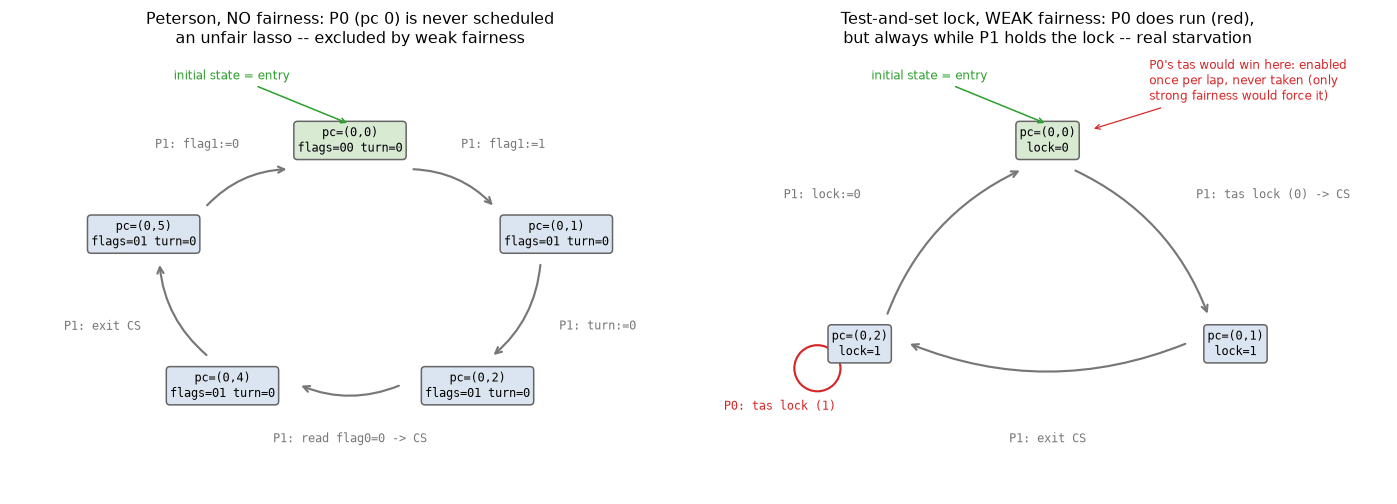

Weak fairness removes the scheduler's lasso but not the lock's: a TAS spinlock can starve a thread,
and only strong fairness (which no hardware promises) or a FIFO ticket lock rules that out.


In [97]:
# 8.3 Checks on the liveness verdicts, then the two lassos drawn.
def _s8_fair_cycle_bruteforce(initial, successors, accepting, fair):
    '''Second, independent decision procedure for "is there a fair accepting cycle?": for every accepting
    state s, intersect what s reaches and what reaches s (inside accepting states) -- s's component, found
    by plain forward/backward search instead of Tarjan -- and look for the fairness witnesses there.'''
    seen = _s8_reachable(initial, successors)
    edges = {s: list(successors(s)) for s in seen}
    acc = {s for s in seen if accepting(s)}
    back = defaultdict(list)
    for s in acc:
        for _, t in edges[s]:
            if t in acc:
                back[t].append(s)

    def closure(s, nxt):
        out, todo = set(), [s]
        while todo:
            for t in nxt(todo.pop()):
                if t not in out:
                    out.add(t)
                    todo.append(t)
        return out
    for s in acc:
        comp = closure(s, lambda v: [t for _, t in edges[v] if t in acc]) & closure(s, lambda v: back[v])
        if s not in comp:
            continue                                   # s is on no cycle at all
        if all(any(g(lab) for v in comp for lab, t in edges[v] if t in comp) or
               any(not any(g(lab) for lab, _ in edges[v]) for v in comp) for g in fair or []):
            return True
    return False


_s8_agree = all((las is not None) == _s8_fair_cycle_bruteforce(init, succ, acc, _s8_WF if fairq else None)
                for (_, fairq), (las, init, succ, acc) in _s8_live.items())
print("independent forward/backward-search decision agrees with find_lasso on all four runs:", _s8_agree)

# strong fairness: is P0's WINNING tas enabled somewhere on the weakly fair test-and-set cycle?
_s8_tas_las, _, _s8_tas_succ, _ = _s8_live["test-and-set", True]
_s8_win = lambda lab: lab.startswith("P0: tas lock (0)")
_s8_win_on = [s for _, s in _s8_tas_las['cycle'] if any(_s8_win(lab) for lab, _ in _s8_tas_succ(s))]
print(f"test-and-set cycle: P0's winning tas is enabled in {len(_s8_win_on)} of its {len(_s8_tas_las['cycle'])} "
      f"states and taken {sum(_s8_win(lab) for lab, _ in _s8_tas_las['cycle'])} times -> weak fairness allows "
      "this run (not continuously enabled); strong fairness on that action would exclude it")

# the ticket modulus: which moduli keep mutual exclusion, and does P0 starve under weak fairness?
_s8_mods = []
for _s8_m in (1, 2, 3):
    _s8_tp = [_s8_ticket_lock(0, _s8_m), _s8_ticket_lock(1, _s8_m)]
    _s8_ti, _s8_ts = _s8_machine(_s8_tp, {'next': 0, 'serving': 0}, 'SC')
    _s8_tr = bfs_check(_s8_ti, _s8_ts, lambda s, P=_s8_tp: sum(_s8_in_cs(P, s)) <= 1)
    _s8_tl = find_lasso(_s8_ti, _s8_ts, lambda s: s[0][0] in {0, 1}, fair=_s8_WF)
    _s8_mods.append([f"mod {_s8_m}", _s8_tr['n_states'], "holds" if _s8_tr['ok'] else "VIOLATED",
                     "no" if _s8_tl is None else "YES"])
print()
show_table(["tickets", "states", "mutual exclusion", "P0 can starve (weak fairness)"], _s8_mods)


def _s8_draw_lasso(ax, lasso, fmt, title):
    '''Draw a lasso's cycle as a ring of states (a step that leaves the state unchanged is a self-loop);
    P0's moves in red, everyone else's in grey.'''
    cyc, entry = lasso['cycle'], lasso['stem'][-1][1]
    ring, edges, loops = [entry], [], {}
    for lab, t in cyc:
        if t == ring[-1]:
            loops[len(ring) - 1] = lab
        elif t == entry:
            edges.append((len(ring) - 1, 0, lab))
        else:
            edges.append((len(ring) - 1, len(ring), lab))
            ring.append(t)
    ang = np.pi / 2 - 2 * np.pi * np.arange(len(ring)) / len(ring)
    pos = [(1.6 * np.cos(a), np.sin(a)) for a in ang]
    color = lambda lab: "#d62728" if lab.startswith("P0") else "#777777"
    half_w = 0.03 * max(len(line) for st in ring for line in fmt(st).split("\n")) + 0.1   # box half sizes
    clear = lambda dx, dy: min(half_w / max(abs(dx), 1e-9), 0.2 / max(abs(dy), 1e-9))     # exit a box
    for k0, k1, lab in edges:
        (x0, y0), (x1, y1) = pos[k0], pos[k1]
        d = np.hypot(x1 - x0, y1 - y0)
        dx, dy = (x1 - x0) / d, (y1 - y0) / d
        t = clear(dx, dy) + 0.03
        ax.annotate("", xy=(x1 - t * dx, y1 - t * dy), xytext=(x0 + t * dx, y0 + t * dy), arrowprops=dict(
            arrowstyle="->", color=color(lab), lw=1.4, shrinkA=0, shrinkB=0, connectionstyle="arc3,rad=-0.2"))
        mx, my = (x0 + x1) / 2, (y0 + y1) / 2
        r = np.hypot(mx / 1.6, my) or 1
        ax.text(mx / r * 1.2, my / r * 1.2, lab, ha="center", va="center", fontsize=8, family="monospace",
                color=color(lab))
    for k, lab in loops.items():                     # self-loop drawn just outside the node
        ux, uy = pos[k][0] / 1.6, pos[k][1]
        cx, cy = pos[k][0] + ux * 0.36, pos[k][1] + uy * 0.36
        ax.add_patch(Circle((cx, cy), 0.17, fill=False, ec=color(lab), lw=1.4))
        ax.text(cx + ux * 0.32, cy + uy * 0.32 - 0.12, lab, ha="center", va="center", fontsize=8,
                family="monospace", color=color(lab))
    for k, st in enumerate(ring):
        ax.text(*pos[k], fmt(st), ha="center", va="center", fontsize=8, family="monospace", zorder=3,
                bbox=dict(boxstyle="round,pad=0.3", fc="#d9ead3" if k == 0 else "#dbe5f1", ec="#666666"))
    ax.annotate("initial state = entry", xy=(pos[0][0], pos[0][1] + 0.12), xytext=(pos[0][0] - 1.3, 1.45),
                fontsize=8, arrowprops=dict(arrowstyle="->", color="#2ca02c"), color="#2ca02c")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-1.6, 1.65)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=10.5)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
_s8_draw_lasso(axes[0], _s8_live["Peterson", False][0],
               lambda st: f"pc=({st[0][0]},{st[0][1]})\nflags={st[2][0]}{st[2][1]} turn={st[2][2]}",
               "Peterson, NO fairness: P0 (pc 0) is never scheduled\nan unfair lasso -- excluded by weak fairness")
_s8_draw_lasso(axes[1], _s8_tas_las,
               lambda st: f"pc=({st[0][0]},{st[0][1]})\nlock={st[2][0]}",
               "Test-and-set lock, WEAK fairness: P0 does run (red),\nbut always while P1 holds the lock -- "
               "real starvation")
axes[1].annotate("P0's tas would win here: enabled\nonce per lap, never taken (only\nstrong fairness would force it)",
                 xy=(0.32, 1.08), xytext=(0.75, 1.3), fontsize=8, color="#d62728",
                 arrowprops=dict(arrowstyle="->", color="#d62728", lw=0.8))
plt.tight_layout()
plt.show()
print("Weak fairness removes the scheduler's lasso but not the lock's: a TAS spinlock can starve a thread,")
print("and only strong fairness (which no hardware promises) or a FIFO ticket lock rules that out.")

**Results.** Peterson starves P0 only in the unfair lasso (left), which the certificate check rejects under weak
fairness; with fairness, neither Peterson nor the ticket lock has a starving run. Test-and-set keeps one
(right): P0 runs, but always while the lock is held. Its winning `tas` is enabled once per lap of that cycle and
never taken, so strong fairness on that action would remove the lasso while weak fairness cannot. Hardware
promises neither, which is why TAS spinlocks can starve and FIFO (ticket) locks exist. Mod 2 tickets are indeed
enough, and mod 1 breaks mutual exclusion.

### 8.4 Refinement: the implementation behaves like the spec

The strongest claim is not "this invariant holds" but "every behaviour of the implementation is a behaviour of a
simpler spec" (**refinement**, impl ⊑ spec), *as an observer sees it*. The spec fixes which parts of the state
are **externally visible**: here, who is in the critical section, and for a counter, which `inc()` calls have
returned and the value of `x`. An **abstraction function** α maps implementation states to spec states, and is
a **refinement mapping** when it meets three conditions (Abadi & Lamport, TCS 1991, who call them R1–R3):

- R1: α preserves the visible part: an observer sees the same thing in $s$ and in $\alpha(s)$;
- R2: α maps every initial state to a spec initial state;
- R3: α maps every implementation step to a spec step or to a **stutter** (α unchanged, i.e. internal work).

R1 is what makes the check mean something. Without it, a constant α turns every step into a stutter and
"refines" anything; the cell keeps that failure. R1–R3 together are a safety check on a product system whose
state is the implementation state plus "which condition, if any, has failed". So `bfs_check` does the work, and
its counterexample is the shortest non-refining run. (A fourth condition, R4, carries liveness over; this check
leaves it out.) Abadi & Lamport also proved completeness, under three hypotheses: the implementation is machine
closed, and the spec has finite invisible nondeterminism and is internally continuous. Then, if the
implementation implements the spec, a refinement mapping exists once you may add history and prophecy
variables. That is the **ghost state** Dafny and Verus let you declare and erase at compile time (*illustrative*
Dafny):

```dafny
class Counter {
  var x: int
  ghost var log: seq<int>            // which thread incremented: exists only for the proof
  method Inc(tid: int)
    modifies this
    ensures x == old(x) + 1 && log == old(log) + [tid]
  { x := x + 1; log := log + [tid]; }
}
```

At scale (§11): seL4's C code refines an abstract spec. CompCert proves each pass by a simulation from source to
compiled code and, because its languages are deterministic, concludes that every behaviour of the compiled code
is a behaviour of the source, for a source that does not go wrong (Leroy, CACM 2009). IronFleet's implementation
refines a protocol that refines the spec.

In [98]:
# 8.4 Refinement checked as safety of a product system (Abadi & Lamport's R1-R3), on the same machine.
def _s8_refines(impl_init, impl_succ, alpha, spec_init, spec_succ, see_impl=None, see_spec=None):
    '''Refinement impl <= spec with abstraction function alpha, checked as SAFETY of a product system:
      R1  see_spec(alpha(s)) == see_impl(s) in every reachable state (alpha keeps what an observer sees);
      R2  alpha maps every initial state to a spec initial state;
      R3  every implementation step maps to a spec step or to a stutter (alpha unchanged).
    see_impl=None skips R1, which makes the check vacuous (a constant alpha turns every step into a stutter);
    it exists only to show that. Product state = (impl state, broken), broken = None or the condition that
    failed. Returns bfs_check's dict; on failure the trace is the shortest non-refining run.'''
    spec0 = set(spec_init)

    def broken(s, a, step_ok):
        if not step_ok:
            return 'R3: no spec step'
        if see_impl is not None and see_spec(a) != see_impl(s):
            return 'R1: observer sees a difference'
        return None

    def succ(p):
        s, a = p[0], alpha(p[0])
        allowed = {t for _, t in spec_succ(a)}
        for lab, t in impl_succ(s):
            b = alpha(t)
            yield lab, (t, broken(t, b, b == a or b in allowed))
    start = [(s, 'R2: not a spec initial state' if alpha(s) not in spec0 else broken(s, alpha(s), True))
             for s in impl_init]
    return bfs_check(start, succ, lambda p: p[1] is None)


def _s8_spec_mutex(a):
    '''Atomic mutex for two threads: spec state = ('idle'|'crit', 'idle'|'crit'), all of it visible.'''
    for i in (0, 1):
        if a[i] == 'idle' and 'crit' not in a:
            yield f"acquire{i}", _s8_put(a, i, 'crit')
        elif a[i] == 'crit':
            yield f"release{i}", _s8_put(a, i, 'idle')


def _s8_spec_counter(a):
    '''Atomic counter: spec state = ((returned0, returned1), x); inc() by thread i is one indivisible step.'''
    done, x = a
    for i in (0, 1):
        if not done[i]:
            yield f"inc{i}", (_s8_put(done, i, True), x + 1)


def _s8_refinement_demos():
    '''Mutex and counter refinements, plus the two ways the check can be fooled (no R1; too little visible).'''
    rows, traces = [], {}

    def run(key, impl, spec, alpha_txt, sees_txt, init, succ, alpha, spec0, spec_succ, see_impl, see_spec):
        res = _s8_refines(init, succ, alpha, spec0, spec_succ, see_impl, see_spec)
        rows.append([impl, spec, alpha_txt, sees_txt, "REFINES" if res['ok'] else "does NOT refine",
                     res['n_states'], "-" if res['ok'] else f"{len(res['trace']) - 1} steps ({res['trace'][-1][1][1]})"])
        traces[key] = (res, alpha)
    mutex_sees = lambda a: tuple(c == 'crit' for c in a)
    for name, model in (("ticket lock", 'SC'), ("Peterson", 'SC'), ("Peterson", 'TSO')):
        progs, mem, _ = _s8_locks["ticket" if name == "ticket lock" else name]
        init, succ = _s8_machine(progs, mem, model)
        in_cs = lambda s, P=progs: tuple(_s8_in_cs(P, s))
        alpha = lambda s, f=in_cs: tuple('crit' if c else 'idle' for c in f(s))
        run((name, model), f"{name} ({model})", "atomic mutex", "who is in the CS", "who is in the CS", init, succ,
            alpha, [('idle', 'idle')], _s8_spec_mutex, in_cs, mutex_sees)
        if model == 'TSO':                       # the kept failure: a constant alpha, without and with R1
            const = lambda s: ('idle', 'idle')
            run(('const', 'no R1'), "Peterson (TSO)", "atomic mutex", "constant (idle, idle)", "(R1 skipped)",
                init, succ, const, [('idle', 'idle')], _s8_spec_mutex, None, None)
            run(('const', 'R1'), "Peterson (TSO)", "atomic mutex", "constant (idle, idle)", "who is in the CS",
                init, succ, const, [('idle', 'idle')], _s8_spec_mutex, in_cs, mutex_sees)
    progs = [_s8_counter_prog(1)] * 2
    init, succ = _s8_machine(progs, {'x': 0}, 'SC')
    returned = lambda s: tuple(progs[i][pc][0] == 'done' for i, pc in enumerate(s[0]))
    see_all = lambda s: (returned(s), s[2][0])
    run(('counter', 'returns visible'), "load/store counter (SC)", "atomic counter", "(who returned, x)",
        "who returned, x", init, succ, see_all, [((False, False), 0)], _s8_spec_counter, see_all, lambda a: a)
    run(('counter', 'x only'), "load/store counter (SC)", "atomic counter", "((x >= 1, x >= 2), x)", "x only",
        init, succ, lambda s: ((s[2][0] >= 1, s[2][0] >= 2), s[2][0]), [((False, False), 0)], _s8_spec_counter,
        lambda s: s[2][0], lambda a: a[1])
    return rows, traces


_s8_ref_rows, _s8_ref = _s8_refinement_demos()
show_table(["implementation", "spec", "alpha", "observer sees", "verdict", "product states",
            "shortest non-refining run"], _s8_ref_rows)
_s8_res, _s8_alpha = _s8_ref['counter', 'returns visible']
print("\nshortest non-refining run of the counter, with alpha(s) = (who returned, x) per step:")
for _s8_lab, (_s8_st, _s8_why) in _s8_res['trace']:
    print(f"   {(_s8_lab or 'initial'):22s} alpha = {_s8_alpha(_s8_st)}" + ("" if _s8_why is None else
          f"   <-- {_s8_why}: x stays 1 although a second increment returned"))
print("No alpha can fix this: the observer sees the spec's whole state, so R1 forces alpha = (who returned, x),")
print("and the implementation reaches 'both returned, x == 1', a state no atomic run has.")

implementation           spec            alpha                  observer sees     verdict          product states  shortest non-refining run               
-----------------------------------------------------------------------------------------------------------------------------------------------------------
ticket lock (SC)         atomic mutex    who is in the CS       who is in the CS  REFINES          112             -                                       
Peterson (SC)            atomic mutex    who is in the CS       who is in the CS  REFINES          40              -                                       
Peterson (TSO)           atomic mutex    who is in the CS       who is in the CS  does NOT refine  105             6 steps (R3: no spec step)              
Peterson (TSO)           atomic mutex    constant (idle, idle)  (R1 skipped)      REFINES          972             -                                       
Peterson (TSO)           atomic mutex    constant (idle, idle)  

**Results.** The ticket lock and SC-Peterson refine the atomic mutex, and TSO-Peterson does not: its shortest
non-refining run is §8.2's 6-step violation, now seen as a step into "both in the critical section" that no spec
step matches. The constant-α rows are the kept failure. Without R1 the check accepts even TSO-Peterson; with R1
the same α fails at the first critical-section entry. The counter's shortest non-refining run is the lost update.
Because the observer sees the spec's whole state (who has returned, and $x$), R1 leaves α no freedom, so this
one failing run proves that no α exists. The last row shows why the observer matters. If only $x$ is visible,
α = ((x ≥ 1, x ≥ 2), x) passes, since a safety spec cannot tell a lost increment from one that has not happened
yet. The return of `inc()` has to be observable, or the spec has to demand, as liveness, that both increments
happen.

### 8.5 Symbolic transition systems: induction and k-induction

Enumeration runs out somewhere around $10^8$–$10^9$ states on one machine (an order-of-magnitude estimate) and
cannot start at all on unbounded integers. The symbolic alternative writes a set of states as a formula and the
transition relation as a formula $T(s, s')$ over current and next variables. Safety then needs an inductive
invariant $I$:

$$\mathit{Init}(s) \Rightarrow I(s), \qquad I(s) \wedge T(s, s') \Rightarrow I(s'), \qquad I(s) \Rightarrow P(s).$$

This is §6's loop rule, stated for any transition system: by induction on run length, every reachable state
satisfies $P$. On §6's x,y loop (here with guard `y < 16`), $P = x \ge y$ is true but not inductive.
**k-induction** (Sheeran, Singh & Stålmarck, FMCAD 2000) tries to avoid writing the strengthening by making two
checks:

- **base**: no run from Init violates $P$ within $k-1$ steps (BMC, §5);
- **step**: any $k$ consecutive $P$-states, linked by $T$, are followed by a $P$-state.

It is sound because a shortest violation has at least $k$ steps (base), and then its last $k+1$ states contradict
the step check. A larger $k$ assumes more in the step check, so a property that is not inductive can be
k-inductive. Sheeran et al.'s step check also requires the states on the path to be pairwise distinct
(**loop-free**), which makes the method complete for finite systems. `k_induction` below is the plain variant
without that constraint; the Peterson run measures what the loop-free one would need.

**API note: `is_inductive` (used by §13's invariant proposers).** A system is given as follows:

- `vars = {name: z3 sort}`;
- `init(s)`, `inv(s)` and `trans(s, t)` are Python callables that build Z3 formulas over *dicts of Z3 variables*,
  with `s` the current state and `t` the next.

`is_inductive(inv, init, trans, vars, k=1)` creates the copies `x@0, x@1, …` itself and checks initiation and
consecution (for `k > 1`, the k-step base and step). It returns one of:

- `('inductive', None)`;
- `('cti', {'check': 'base' | 'step', 'trace': [{name: int}, …]})`, where `'base'` is a real counterexample from
  Init and `'step'` is a CTI whose last state breaks `inv`;
- `('unknown', None)`, on a Z3 timeout (5 s per query).

`k_induction(prop, init, trans, vars, max_k=12)` uses the same encoding and returns `('proved', k, None)`,
`('counterexample', depth, trace)`, `('unknown', max_k, last_cti)` when no $k \le$ `max_k` works, or
`('unknown', k, None)` when a query at depth $k$ times out.

```python
XY    = {'x': z3.IntSort(), 'y': z3.IntSort()}          # or z3.BitVecSort(8): machine integers
init  = lambda s: z3.And(s['x'] == 1, s['y'] == 0)
trans = lambda s, t: z3.And(s['y'] < 16, t['x'] == s['x'] + s['y'], t['y'] == s['y'] + 1)
is_inductive(lambda s: s['x'] >= s['y'], init, trans, XY)           # ('cti', {'check': 'step', ...})
is_inductive(lambda s: z3.And(s['x'] >= s['y'], s['x'] >= 1, s['y'] >= 0), init, trans, XY)   # ('inductive', None)
```

The guard is 16 because reachable states satisfy $x = 1 + y(y-1)/2$, which is 121 at $y = 16$ (fits in a signed
byte) and 137 one step later (does not). The cells below also run the loop on 8 bits, a finite system whose
65,536 states admit an exact brute-force oracle, and Peterson compiled from the machine program into a formula.

**Registered prediction:** k-induction proves $x \ge y$ over ℤ by $k = 12$. (It is true on every reachable state,
so surely enough unrolling removes the spurious CTI.)

In [99]:
# 8.5 Symbolic transition systems: inductiveness and k-induction with Z3, on the x, y loop over the integers.
_s8_Z3_MS = 5000          # timeout per Z3 query; a timeout is reported as 'unknown', never as proved
_s8_KMAX = 12             # k-induction depth cap for the demos


def _s8_copies(vars, tag):
    '''One copy of the state variables, e.g. {'x': x@3, 'y': y@3} for time step 3.'''
    return {n: z3.Const(f"{n}@{tag}", sort) for n, sort in vars.items()}


def _s8_decode(model, states):
    '''Z3 model -> list of {name: Python int} (bit-vectors decoded as SIGNED, like the rest of the notebook).'''
    def val(e):
        v = model.eval(e, model_completion=True)
        return v.as_signed_long() if z3.is_bv(e) else (z3.is_true(v) if z3.is_bool(e) else v.as_long())
    return [{n: val(e) for n, e in s.items()} for s in states]


def _s8_query(formulas, timeout_ms):
    '''Satisfiability of a conjunction: ('sat', model) | ('unsat', None) | ('unknown', None). The solver lives
    in the formulas' own Z3 context (the default one, or a private one as for Peterson below).'''
    solver = z3.Solver(ctx=next((f.ctx for f in formulas if z3.is_expr(f)), None))
    solver.set("timeout", timeout_ms)
    solver.add(*formulas)
    r = solver.check()
    return ('sat', solver.model()) if r == z3.sat else ('unsat' if r == z3.unsat else 'unknown', None)


def is_inductive(inv, init, trans, vars, k=1, timeout_ms=_s8_Z3_MS):
    '''Is the candidate invariant inv k-inductive for the system (init, trans)?
    Encoding: vars = {name: z3 sort}; a state is a dict {name: z3 constant}; init(s), inv(s) and trans(s, t)
    are Python callables returning z3 BoolRefs (t = the next state). k = 1 is the ordinary check
      initiation  Init(s0) => inv(s0)      consecution  inv(s0) and T(s0, s1) => inv(s1);
    k > 1 checks inv on every state reachable in < k steps (base) and that k consecutive inv-states force the
    next one (step). Returns ('inductive', None) | ('cti', dict(check='base'|'step', trace=[{name: int}, ...]))
    | ('unknown', None). check='base': a REAL counterexample from Init; check='step': trace[:-1] satisfy inv,
    trace[-1] does not -- a counterexample to induction (CTI), possibly unreachable.'''
    S = [_s8_copies(vars, i) for i in range(k + 1)]
    path = [trans(S[i], S[i + 1]) for i in range(k)]
    for j in range(k):                                     # base: Init, j steps, inv broken
        status, m = _s8_query([init(S[0])] + path[:j] + [z3.Not(inv(S[j]))], timeout_ms)
        if status != 'unsat':
            return ('unknown', None) if status == 'unknown' else ('cti', dict(check='base',
                                                                              trace=_s8_decode(m, S[:j + 1])))
    status, m = _s8_query([inv(S[i]) for i in range(k)] + path + [z3.Not(inv(S[k]))], timeout_ms)
    if status == 'unknown':
        return ('unknown', None)
    return ('inductive', None) if status == 'unsat' else ('cti', dict(check='step', trace=_s8_decode(m, S)))


def k_induction(prop, init, trans, vars, max_k=_s8_KMAX, timeout_ms=_s8_Z3_MS):
    '''Plain k-induction (Sheeran, Singh & Stalmarck 2000, without their loop-free path constraint) for the
    safety property prop, same encoding as is_inductive. For k = 1, 2, ...: base = BMC to depth k-1 (a hit is a
    real counterexample); step = k consecutive prop-states force the next one. Returns ('proved', k, None) |
    ('counterexample', depth, trace) | ('unknown', max_k, CTI trace of the last step check) if no k <= max_k
    works | ('unknown', k, None) if a query at depth k times out.'''
    last = None
    for k in range(1, max_k + 1):
        S = [_s8_copies(vars, i) for i in range(k + 1)]
        path = [trans(S[i], S[i + 1]) for i in range(k)]
        status, m = _s8_query([init(S[0])] + path[:k - 1] + [z3.Not(prop(S[k - 1]))], timeout_ms)
        if status == 'sat':
            return ('counterexample', k - 1, _s8_decode(m, S[:k]))
        if status == 'unknown':
            return ('unknown', k, None)
        status, m = _s8_query([prop(S[i]) for i in range(k)] + path + [z3.Not(prop(S[k]))], timeout_ms)
        if status == 'unsat':
            return ('proved', k, None)
        if status == 'unknown':
            return ('unknown', k, None)
        last = _s8_decode(m, S)
    return ('unknown', max_k, last)


# ---- the running x, y loop:  x, y = 1, 0;  while y < 16: x = x + y; y = y + 1      property x >= y ----
_s8_XY_INT = {'x': z3.IntSort(), 'y': z3.IntSort()} if HAVE_Z3 else None
_s8_XY_BV8 = {'x': z3.BitVecSort(8), 'y': z3.BitVecSort(8)} if HAVE_Z3 else None
_s8_xy_init = lambda s: z3.And(s['x'] == 1, s['y'] == 0)
_s8_xy_trans = lambda s, t: z3.And(s['y'] < 16, t['x'] == s['x'] + s['y'], t['y'] == s['y'] + 1)
_s8_xy_trans_free = lambda s, t: z3.And(t['x'] == s['x'] + s['y'], t['y'] == s['y'] + 1)   # no loop guard
_s8_xy_P = lambda s: s['x'] >= s['y']
_s8_xy_strong = lambda s: z3.And(s['x'] >= s['y'], s['x'] >= 1, s['y'] >= 0)

if HAVE_Z3:
    _s8_r1 = is_inductive(_s8_xy_P, _s8_xy_init, _s8_xy_trans, _s8_XY_INT)
    _s8_r2 = is_inductive(_s8_xy_strong, _s8_xy_init, _s8_xy_trans, _s8_XY_INT)
    print("is_inductive(x >= y)                         ->", _s8_r1[0], *(_s8_r1[1].values() if _s8_r1[1] else []))
    print("is_inductive(x >= y and x >= 1 and y >= 0)   ->", _s8_r2)
    _s8_kz, _s8_dt = timed(k_induction, _s8_xy_P, _s8_xy_init, _s8_xy_trans, _s8_XY_INT)
    _s8_chain = _s8_kz[2]
    if _s8_kz[0] == 'unknown' and _s8_chain is None:      # a Z3 timeout: evidence of nothing
        print(f"\nk_induction(x >= y) over Z: a query timed out at k = {_s8_kz[1]} -> unknown ({_s8_dt:.2f} s)")
        print(f"registered prediction: k-induction proves x >= y over Z by k = {_s8_KMAX} | measured: a timeout "
              f"at k = {_s8_kz[1]} | verdict: UNSCORED (a timeout is not an answer)")
    elif _s8_kz[0] == 'unknown':                          # no k <= KMAX worked: every step check was SAT
        print(f"\nk_induction(x >= y) over Z, k = 1..{_s8_KMAX}: {_s8_kz[0]} (every step check is SAT; "
              f"{_s8_dt:.2f} s). The CTI path Z3 returned at k = {_s8_KMAX}:")
        print("   " + " -> ".join(f"({s['x']},{s['y']})" for s in _s8_chain))
        _s8_inP = all(s['x'] >= s['y'] for s in _s8_chain[:-1]) and _s8_chain[-1]['x'] < _s8_chain[-1]['y']
        _s8_isT = all(t['x'] == s['x'] + s['y'] and t['y'] == s['y'] + 1 and s['y'] < 16
                      for s, t in zip(_s8_chain, _s8_chain[1:]))
        print(f"   re-checked in Python: real transitions {_s8_isT}, first {_s8_KMAX} states satisfy x >= y and "
              f"the last breaks it {_s8_inP}")
        print(f"registered prediction: k-induction proves x >= y over Z by k = {_s8_KMAX} | measured: "
              f"{_s8_kz[0]} at every k <= {_s8_KMAX} | verdict: WRONG -- every CTI has an infinite chain of "
              "x >= y predecessors (y -> -inf), so no k suffices")
    else:                                                 # 'proved' or 'counterexample' at depth _s8_kz[1]
        print(f"\nk_induction(x >= y) over Z: {_s8_kz[0]} at k = {_s8_kz[1]} ({_s8_dt:.2f} s)")
        print(f"registered prediction: k-induction proves x >= y over Z by k = {_s8_KMAX} | measured: "
              f"{_s8_kz[0]} at k = {_s8_kz[1]} | verdict: {'RIGHT' if _s8_kz[0] == 'proved' else 'WRONG'}")
else:
    print("Z3 not installed (pip install z3-solver): skipping is_inductive / k_induction; the exact brute-force "
          "oracles below still run.")

is_inductive(x >= y)                         -> cti step [{'x': 0, 'y': -1}, {'x': -1, 'y': 0}]
is_inductive(x >= y and x >= 1 and y >= 0)   -> ('inductive', None)



k_induction(x >= y) over Z, k = 1..12: unknown (every step check is SAT; 0.12 s). The CTI path Z3 returned at k = 12:
   (66,-11) -> (55,-10) -> (45,-9) -> (36,-8) -> (28,-7) -> (21,-6) -> (15,-5) -> (10,-4) -> (6,-3) -> (3,-2) -> (1,-1) -> (0,0) -> (0,1)
   re-checked in Python: real transitions True, first 12 states satisfy x >= y and the last breaks it True
registered prediction: k-induction proves x >= y over Z by k = 12 | measured: unknown at every k <= 12 | verdict: WRONG -- every CTI has an infinite chain of x >= y predecessors (y -> -inf), so no k suffices


On 8-bit machine integers the same loop is a finite system of 65,536 states. Finiteness alone does not save
plain k-induction: Peterson, below, is finite and it never succeeds. What can save it is the shape of the graph.
If no cycle of P-states leads, through P-states, into ¬P, then every P-path into ¬P is a simple path in a finite
graph. So there is a longest one, with $L$ states, and the step check succeeds at $k = L + 1$. In the guarded loop
every step raises $y$ (the guard $y < 16$ means $y + 1$ cannot wrap), so no path revisits a state. The next cell
runs the loop with and without the guard, checks that every guarded step raises $y$, and compares Z3's answer with
an exact count, by enumeration, of the paths the step check looks for.

In [100]:
# 8.5 The x, y loop on 8-bit integers: a finite system, and an exact enumeration oracle for k-induction.
def _s8_kind_layers(states, successors, prop, max_layers=2000, pad_to=0):
    '''Exact oracle for plain k-induction on a FINITE system, by explicit enumeration: L1 = prop-states with a
    step into a bad state, L(j+1) = prop-states with a step into Lj. The step check at k fails iff Lk is
    non-empty, so k-induction first succeeds at the first k with Lk empty; if a layer repeats, every later one
    is non-empty and k-induction fails for EVERY k. Returns (k, [|L1|, |L2|, ...]) with k an int, None (fails
    for every k), or 'unknown' (max_layers layers built, none empty and none repeated). With pad_to, the layer
    sizes keep being listed (for plotting) up to that many layers even after a repeat.'''
    pred = defaultdict(set)
    for s in states:
        for t in successors(s):
            pred[t].add(s)
    layer = {p for t in states if not prop(t) for p in pred[t] if prop(p)}
    sizes, seen, k_ok = [], set(), 'search'
    while layer and len(sizes) < max_layers:
        key = frozenset(layer)
        if key in seen and k_ok == 'search':
            k_ok = None                                    # periodic from here on: never empty
        if k_ok is None and len(sizes) >= pad_to:
            break
        seen.add(key)
        sizes.append(len(layer))
        layer = {p for t in layer for p in pred[t] if prop(p)}
    if k_ok == 'search' and layer:
        return 'unknown', sizes                            # out of layers before an answer
    return (len(sizes) + 1 if k_ok == 'search' else None), sizes


def _s8_xy_bv8_succ(s):
    '''Explicit successor of the guarded loop on 8-bit integers (for the brute-force oracle).'''
    x, y = s
    return [(wrap(x + y, 8), wrap(y + 1, 8))] if y < 16 else []


if HAVE_Z3:
    _s8_kb_free = k_induction(_s8_xy_P, _s8_xy_init, _s8_xy_trans_free, _s8_XY_BV8, max_k=60)
    _s8_kb, _s8_dtb = timed(k_induction, _s8_xy_P, _s8_xy_init, _s8_xy_trans, _s8_XY_BV8, max_k=60)
    if _s8_kb_free[0] == 'counterexample':
        print(f"bv8, no loop guard : {_s8_kb_free[0]} at depth {_s8_kb_free[1]}; last steps "
              + " -> ".join(f"({s['x']},{s['y']})" for s in _s8_kb_free[2][-3:]) + "  (x wrapped past 127)")
        _s8_bad = _s8_kb_free[2][-1]
        _s8_x, _s8_y = 1, 0
        for _ in range(_s8_kb_free[1]):
            _s8_x, _s8_y = wrap(_s8_x + _s8_y, 8), wrap(_s8_y + 1, 8)
        print(f"   replayed with wrap(): after {_s8_kb_free[1]} iterations (x, y) = ({_s8_x}, {_s8_y}) -> matches "
              f"{(_s8_x, _s8_y) == (_s8_bad['x'], _s8_bad['y'])}")
    else:
        print(f"bv8, no loop guard : {_s8_kb_free[0]} at k = {_s8_kb_free[1]} (expected a counterexample)")
    print(f"bv8, while y < 16  : {_s8_kb[0]} at k = {_s8_kb[1]}  ({_s8_dtb:.1f} s for 2 x {_s8_kb[1]} queries)")

_s8_bv_states = [(x, y) for x in range(-128, 128) for y in range(-128, 128)]
_s8_bf_xy = _s8_kind_layers(_s8_bv_states, _s8_xy_bv8_succ, lambda s: s[0] >= s[1])
print(f"brute-force oracle over all {len(_s8_bv_states)} bv8 states: k-induction first succeeds at k = "
      f"{_s8_bf_xy[0]}" + (f" -> agrees with Z3: {_s8_kb[0] == 'proved' and _s8_bf_xy[0] == _s8_kb[1]}"
                           if HAVE_Z3 else ""))
_s8_y_up = all(t[1] > s[1] for s in _s8_bv_states for t in _s8_xy_bv8_succ(s))
print(f"every guarded step raises y, on all {len(_s8_bv_states)} states: {_s8_y_up}"
      + (" -> the state graph has no cycle" if _s8_y_up else ""))
_s8_chain_test = _s8_kind_layers(list(range(2501)), lambda s: [s + 1] if s < 2500 else [], lambda s: s < 2500)
print(f"oracle self-test, a 2,500-state chain into one bad state with a 2,000-layer budget: {_s8_chain_test[0]!r} "
      "(not a false success)")
print(("Finite AND acyclic rescues k-induction: y only grows, so no P-path revisits a state, and on 8 bits"
       if _s8_y_up else "On 8 bits") + f" the step check runs out of P-paths into not-P at k = {_s8_bf_xy[0]}.")

bv8, no loop guard : counterexample at depth 17; last steps (106,15) -> (121,16) -> (-119,17)  (x wrapped past 127)
   replayed with wrap(): after 17 iterations (x, y) = (-119, 17) -> matches True
bv8, while y < 16  : proved at k = 41  (1.5 s for 2 x 41 queries)
brute-force oracle over all 65536 bv8 states: k-induction first succeeds at k = 41 -> agrees with Z3: True
every guarded step raises y, on all 65536 states: True -> the state graph has no cycle
oracle self-test, a 2,500-state chain into one bad state with a 2,000-layer budget: 'unknown' (not a false success)
Finite AND acyclic rescues k-induction: y only grows, so no P-path revisits a state, and on 8 bits the step check runs out of P-paths into not-P at k = 41.


Now Peterson as a formula. The cell compiles the machine program into a transition relation, checks it against
the machine state by state, and then runs plain k-induction, the exact layer oracle, and an exact oracle for
Sheeran et al.'s loop-free variant.

In [101]:
# 8.5 Peterson compiled to a formula: plain k-induction fails for every k; what the loop-free variant needs.
def _s8_store_values(programs, init_mem):
    '''The finite set of values each shared variable can hold: its initial value and every constant stored.'''
    values = {v: {init_mem[v]} for v in init_mem}
    for prog in programs:
        for ins in prog.values():
            if ins[0] == 'store':
                values[ins[1]].add(ins[2])
            elif ins[0] not in ('branch', 'crit'):
                raise ValueError(f"_s8_symbolic: unsupported instruction {ins[0]}")
    return {v: sorted(vals) for v, vals in values.items()}


def _s8_symbolic(programs, init_mem, ctx=None):
    '''Compile SC machine programs (instructions store / branch / crit) to a symbolic system over Z3 Ints:
    returns (vars, init, trans, dom). dom pins every variable to the finite set of values the program can
    produce, so that k-induction and IC3 range over the same finite state space as the explicit machine.
    ctx: the Z3 context to build in (None = the default one).'''
    n, names, values = len(programs), sorted(init_mem), _s8_store_values(programs, init_mem)
    vars = {**{f"pc{i}": z3.IntSort(ctx) for i in range(n)}, **{v: z3.IntSort(ctx) for v in names}}
    dom = lambda s: z3.And(*[z3.Or(*[s[f"pc{i}"] == pc for pc in programs[i]]) for i in range(n)],
                           *[z3.Or(*[s[v] == c for c in values[v]]) for v in names])
    init = lambda s: z3.And(*[s[f"pc{i}"] == 0 for i in range(n)], *[s[v] == init_mem[v] for v in names])

    def trans(s, t):
        moves = []
        for i, prog in enumerate(programs):
            pc = f"pc{i}"

            def move(at, cond, nxt, writes):         # thread i at pc `at`: if cond, go to nxt, apply writes
                frame = [t[v] == s[v] for v in vars if v != pc and v not in writes]
                return z3.And(s[pc] == at, cond, t[pc] == nxt, *[t[v] == c for v, c in writes.items()], *frame)
            for at, ins in prog.items():
                if ins[0] == 'store':
                    moves.append(move(at, z3.BoolVal(True, ctx), ins[3], {ins[1]: ins[2]}))
                elif ins[0] == 'branch':
                    moves += [move(at, s[ins[1]] == ins[2], ins[3], {}), move(at, s[ins[1]] != ins[2], ins[4], {})]
                else:
                    moves.append(move(at, z3.BoolVal(True, ctx), ins[1], {}))
        return z3.And(dom(s), dom(t), z3.Or(*moves))
    return vars, init, trans, dom


def _s8_domain_states(programs, init_mem):
    '''Every assignment of the finite domain, as machine states ((pcs), regs, (mem), bufs).'''
    values = _s8_store_values(programs, init_mem)
    return [(pcs, (0,) * len(programs), mem, ((),) * len(programs))
            for pcs in itertools.product(*[sorted(p) for p in programs])
            for mem in itertools.product(*[values[v] for v in sorted(init_mem)])]


def _s8_same_relation(programs, init_mem, vars, trans, states, succ):
    '''Oracle: for every domain state, the successors Z3 finds in trans(s, t) equal the explicit machine's.'''
    names, n = sorted(init_mem), len(programs)
    S, T = _s8_copies(vars, 'now'), _s8_copies(vars, 'next')
    solver = z3.Solver(ctx=trans(S, T).ctx)
    solver.set("timeout", _s8_Z3_MS)
    solver.add(trans(S, T))
    as_dict = lambda st: {**{f"pc{i}": st[0][i] for i in range(n)}, **dict(zip(names, st[2]))}
    for st in states:
        d = as_dict(st)
        solver.push()
        solver.add(*[S[v] == d[v] for v in vars])
        found = set()
        while (r := solver.check()) == z3.sat:
            m = solver.model()
            nxt = tuple(m.eval(T[v], model_completion=True).as_long() for v in vars)
            found.add(nxt)
            solver.add(z3.Or(*[T[v] != val for v, val in zip(vars, nxt)]))
        solver.pop()
        if r != z3.unsat or found != {tuple(as_dict(t)[v] for v in vars) for _, t in succ(st)}:
            return False                                   # a timeout ('unknown') also counts as a failure
    return True


def _s8_into_bad(states, succ, prop):
    '''pre = prop-states with a step out of prop; can = prop-states with a prop-path into pre (the states a
    step-check path can use).'''
    pred = defaultdict(set)
    for s in states:
        for t in succ[s]:
            pred[t].add(s)
    pre = {s for s in states if prop(s) and any(not prop(t) for t in succ[s])}
    can, todo = set(pre), list(pre)
    while todo:
        for p in pred[todo.pop()]:
            if prop(p) and p not in can:
                can.add(p)
                todo.append(p)
    return pre, can


def _s8_loopfree_k(states, succ, prop):
    '''Exact oracle for LOOP-FREE k-induction (Sheeran et al.) on a finite system: its step check at k fails
    iff some SIMPLE path of k prop-states ends in a state with a step out of prop. Depth-first search over
    simple paths inside `can`, pruned when even every still-reachable state could not beat the best path found.
    Returns (first k at which the step check succeeds, longest such path in states).'''
    pre, can = _s8_into_bad(states, succ, prop)
    sub = {s: [t for t in succ[s] if t in can] for s in can}
    best = [0]

    def room(u, visited):                          # states reachable from u without revisiting the path
        seen, todo = {u}, [u]
        while todo:
            for w in sub[todo.pop()]:
                if w not in visited and w not in seen:
                    seen.add(w)
                    todo.append(w)
        return len(seen)

    def extend(u, visited, length):
        if u in pre:
            best[0] = max(best[0], length)
        if length + room(u, visited) - 1 <= best[0]:
            return                                 # cannot get longer than the best path already found
        for w in sub[u]:
            if w not in visited:
                visited.add(w)
                extend(w, visited, length + 1)
                visited.discard(w)
    for s in can:
        extend(s, {s}, 1)
    return best[0] + 1, best[0]


_s8_PET = [_s8_peterson(0), _s8_peterson(1)]
_s8_mutex = lambda s: z3.Not(z3.And(s['pc0'] == 4, s['pc1'] == 4))
_s8_pet_init, _s8_pet_succ = _s8_machine(_s8_PET, _s8_PET_MEM, 'SC')
_s8_pet_states = _s8_domain_states(_s8_PET, _s8_PET_MEM)
_s8_pet_E = {s: [t for _, t in _s8_pet_succ(s)] for s in _s8_pet_states}
_s8_pet_P = lambda s: not (s[0][0] == 4 and s[0][1] == 4)
_s8_bf_pet = _s8_kind_layers(_s8_pet_states, _s8_pet_E.get, _s8_pet_P, pad_to=50)
_s8_pet_reach = _s8_reachable(_s8_pet_init, _s8_pet_succ)
if HAVE_Z3:
    _s8_CTX = z3.Context()       # private Z3 context: results and run time do not depend on earlier sections' terms
    _s8_pv, _s8_pi, _s8_pt, _s8_pdom = _s8_symbolic(_s8_PET, _s8_PET_MEM, ctx=_s8_CTX)
    print(f"Peterson as a formula: {len(_s8_pet_states)} domain states; Z3's trans(s, t) has exactly the "
          f"machine's successors for every one of them: "
          f"{_s8_same_relation(_s8_PET, _s8_PET_MEM, _s8_pv, _s8_pt, _s8_pet_states, _s8_pet_succ)}")
    print("is_inductive(mutual exclusion) ->", is_inductive(_s8_mutex, _s8_pi, _s8_pt, _s8_pv)[0])
    _s8_kp, _s8_dtp = timed(k_induction, _s8_mutex, _s8_pi, _s8_pt, _s8_pv)
    print(f"k_induction(mutual exclusion), k = 1..{_s8_KMAX}: {_s8_kp[0]} ({_s8_dtp:.1f} s)")
    if _s8_kp[2] is not None:
        _s8_as_state = lambda d: ((d['pc0'], d['pc1']), (0, 0), (d['flag0'], d['flag1'], d['turn']), ((), ()))
        _s8_c0 = _s8_kp[2][0]
        print(f"   its CTI path at k = {_s8_KMAX} starts at pc = ({_s8_c0['pc0']}, {_s8_c0['pc1']}), flags = "
              f"({_s8_c0['flag0']}, {_s8_c0['flag1']}), turn = {_s8_c0['turn']}; states on the path that are "
              f"reachable: {sum(_s8_as_state(d) in _s8_pet_reach for d in _s8_kp[2])} of {len(_s8_kp[2])}")
print(f"brute-force layers over all {len(_s8_pet_states)} states ({len(_s8_pet_reach)} reachable): "
      + ("a layer repeats -> the step check fails for EVERY k" if _s8_bf_pet[0] is None else
         f"k = {_s8_bf_pet[0]}"))

# why: the cycles among the states a step-check path can use
_s8_pre, _s8_can = _s8_into_bad(_s8_pet_states, _s8_pet_E, _s8_pet_P)
_s8_core = [s for comp in _s8_sccs(_s8_can, lambda v: [t for t in _s8_pet_E[v] if t in _s8_can])
            for s in comp if len(comp) > 1 or s in _s8_pet_E[s]]
_s8_flag_down = lambda s: any(1 <= s[0][i] <= 4 and s[2][i] == 0 for i in (0, 1))   # past its flag write, flag 0
print(f"the step check's paths can use {len(_s8_can)} P-states; {len(_s8_core)} of them lie on cycles, and all of "
      f"those have a thread past its flag write with its flag down: {all(map(_s8_flag_down, _s8_core))} "
      f"(reachable: {sum(s in _s8_pet_reach for s in _s8_core)})")
_s8_strong_pet = _s8_kind_layers(_s8_pet_states, _s8_pet_E.get,
                                 lambda s: _s8_pet_P(s) and not _s8_flag_down(s))
print(f"plain k-induction on P AND 'a thread past its flag write has its flag up': succeeds at k = "
      f"{_s8_strong_pet[0]} (exact oracle)")
(_s8_lf_k, _s8_lf_len), _s8_lf_dt = timed(_s8_loopfree_k, _s8_pet_states, _s8_pet_E, _s8_pet_P)
print(f"loop-free (Sheeran et al.) k-induction, exact oracle: the longest simple P-path into not-P has "
      f"{_s8_lf_len} states, so its step check first succeeds at k = {_s8_lf_k}: one query over {_s8_lf_k + 1} "
      f"state copies with {math.comb(_s8_lf_k + 1, 2)} pairwise disequalities ({_s8_lf_dt:.2f} s here)")
print(f"kept failure: a safe {len(_s8_pet_states)}-state protocol that PLAIN k-induction can never prove (its layers "
      f"cycle); the loop-free version")
print(f"needs k = {_s8_lf_k}, while P plus one missing lemma lets plain k-induction finish at k = {_s8_strong_pet[0]}.")

Peterson as a formula: 288 domain states; Z3's trans(s, t) has exactly the machine's successors for every one of them: True
is_inductive(mutual exclusion) -> cti


k_induction(mutual exclusion), k = 1..12: unknown (0.4 s)
   its CTI path at k = 12 starts at pc = (3, 2), flags = (1, 0), turn = 0; states on the path that are reachable: 0 of 13
brute-force layers over all 288 states (40 reachable): a layer repeats -> the step check fails for EVERY k
the step check's paths can use 158 P-states; 54 of them lie on cycles, and all of those have a thread past its flag write with its flag down: True (reachable: 0)
plain k-induction on P AND 'a thread past its flag write has its flag up': succeeds at k = 3 (exact oracle)
loop-free (Sheeran et al.) k-induction, exact oracle: the longest simple P-path into not-P has 29 states, so its step check first succeeds at k = 30: one query over 31 state copies with 465 pairwise disequalities (0.01 s here)
kept failure: a safe 288-state protocol that PLAIN k-induction can never prove (its layers cycle); the loop-free version
needs k = 30, while P plus one missing lemma lets plain k-induction finish at k = 3.


The figure puts the two outcomes side by side: the infinite backward chain over ℤ (left), and the exact layer
counts for the two finite systems (right). After it, the cell checks the cycle rule stated before the 8-bit cell
against the layer oracle on all three finite systems (Peterson with and without the missing lemma).

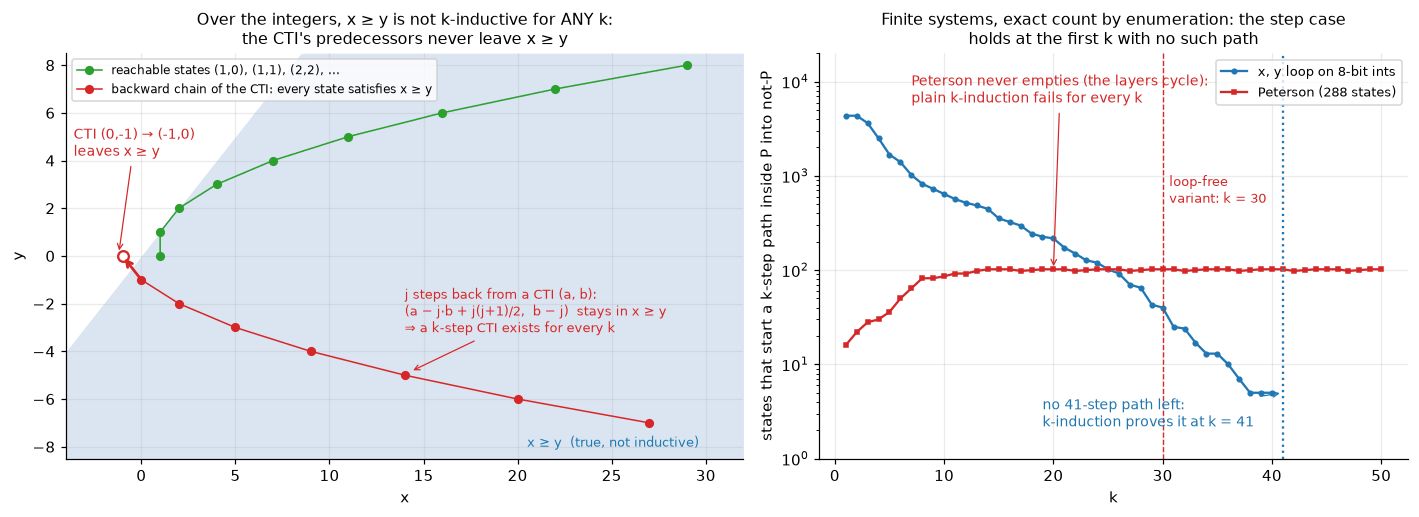

cycle rule vs layer oracle (8-bit loop, Peterson, Peterson + lemma): 41 vs 41, never vs never, 3 vs 3 -> agree: True
Over Z no amount of unrolling helps. On a finite system plain k-induction proves a true P iff no cycle of
P-states leads into not-P, and then at k = 1 + the number of states on the longest P-path into not-P. One
such cycle, even among unreachable states, makes it fail for every k (Peterson).


In [102]:
# 8.5 Figure: why k-induction fails over the integers, and when it succeeds on finite systems.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
_s8_back = []
_s8_have_cti = HAVE_Z3 and _s8_r1[0] == 'cti'           # False only without Z3 or on a Z3 timeout
if _s8_have_cti:                                         # Z3's CTI and six steps of its backward chain
    _s8_cti, _s8_cti_next = _s8_r1[1]['trace']
    _s8_back = [(_s8_cti['x'], _s8_cti['y'])]
    for _ in range(6):                                   # the unique predecessor of (x, y) is (x-y+1, y-1)
        _s8_px, _s8_py = _s8_back[-1]
        _s8_back.append((_s8_px - (_s8_py - 1), _s8_py - 1))
    _s8_back = _s8_back[::-1]
_s8_x1 = max([32] + [x + 3 for x, _ in _s8_back])       # the window adapts if Z3 picks a CTI far from (0, 0)
_s8_y0 = min([-7.5] + [y - 1.5 for _, y in _s8_back])
_s8_gx = np.linspace(-4, _s8_x1, 200)
ax.fill_between(_s8_gx, _s8_y0, np.minimum(_s8_gx, 8.5), color="#dbe5f1", lw=0)       # x >= y
_s8_reach_xy = [(1, 0)]
while _s8_reach_xy[-1][1] < 8:
    _s8_reach_xy.append((sum(_s8_reach_xy[-1]), _s8_reach_xy[-1][1] + 1))
ax.plot(*zip(*_s8_reach_xy), "o-", c="#2ca02c", ms=5, lw=1, label="reachable states (1,0), (1,1), (2,2), ...")
if _s8_have_cti:
    ax.plot(*zip(*_s8_back), "o-", c="#d62728", ms=5, lw=1,
            label="backward chain of the CTI: every state satisfies x ≥ y")
    ax.annotate("", xy=(_s8_cti_next['x'], _s8_cti_next['y']), xytext=(_s8_cti['x'], _s8_cti['y']),
                arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.8))
    ax.plot([_s8_cti_next['x']], [_s8_cti_next['y']], "o", c="#d62728", mfc="white", ms=7, mew=1.5)
    ax.annotate(f"CTI ({_s8_cti['x']},{_s8_cti['y']}) → ({_s8_cti_next['x']},{_s8_cti_next['y']})\nleaves x ≥ y",
                xy=(_s8_cti_next['x'] - 0.2, _s8_cti_next['y'] + 0.1), xytext=(-3.6, 4.2), fontsize=9,
                color="#d62728", arrowprops=dict(arrowstyle="->", color="#d62728", lw=0.8))
    ax.annotate("j steps back from a CTI (a, b):\n(a − j·b + j(j+1)/2,  b − j)  stays in x ≥ y\n"
                "⇒ a k-step CTI exists for every k", xy=(_s8_back[2][0] + 0.3, _s8_back[2][1] + 0.15),
                xytext=(14, -3.2), fontsize=8.5, color="#d62728",
                arrowprops=dict(arrowstyle="->", color="#d62728", lw=0.8))
ax.text(_s8_x1 - 11.5, _s8_y0 + 0.5, "x ≥ y  (true, not inductive)", fontsize=8.5, color="#1f77b4")
ax.set_xlim(-4, _s8_x1)
ax.set_ylim(_s8_y0, 8.5)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Over the integers, x ≥ y is not k-inductive for ANY k:\nthe CTI's predecessors never leave x ≥ y",
             fontsize=10.5)
ax.legend(fontsize=8, loc="upper left")
ax = axes[1]
_s8_sx = _s8_bf_xy[1]
ax.semilogy(range(1, len(_s8_sx) + 1), _s8_sx, "o-", ms=3, c="C0", label="x, y loop on 8-bit ints")
ax.semilogy(range(1, len(_s8_bf_pet[1]) + 1), _s8_bf_pet[1], "s-", ms=3, c="#d62728",
            label="Peterson (288 states)")
ax.axvline(_s8_bf_xy[0], ls=":", c="C0")
ax.annotate(f"no {_s8_bf_xy[0]}-step path left:\nk-induction proves it at k = {_s8_bf_xy[0]}",
            xy=(_s8_bf_xy[0], 5), xytext=(_s8_bf_xy[0] - 22, 2.2), fontsize=9, color="C0",
            arrowprops=dict(arrowstyle="->", color="C0", lw=0.8))
ax.annotate("Peterson never empties (the layers cycle):\nplain k-induction fails for every k",
            xy=(20, _s8_bf_pet[1][19]), xytext=(7, 6e3), fontsize=9, color="#d62728",
            arrowprops=dict(arrowstyle="->", color="#d62728", lw=0.8))
ax.axvline(_s8_lf_k, ls="--", c="#d62728", lw=0.9)
ax.text(_s8_lf_k + 0.6, 700, f"loop-free\nvariant: k = {_s8_lf_k}", fontsize=8.5, color="#d62728", va="center")
ax.set_ylim(1, 2e4)
ax.set_xlabel("k")
ax.set_ylabel("states that start a k-step path inside P into not-P")
ax.set_title("Finite systems, exact count by enumeration: the step case\nholds at the first k with no such path",
             fontsize=10.5)
ax.legend(fontsize=8.5, loc="upper right")
plt.tight_layout()
plt.show()


def _s8_kind_by_cycles(states, succ, prop):
    '''The rule stated before the 8-bit cell, from the graph alone: None if a cycle of prop-states leads through
    prop-states into not-prop (plain k-induction then fails for every k), else 1 + the number of states on the
    longest prop-path into not-prop.'''
    pre, can = _s8_into_bad(states, succ, prop)
    inner = {v: [t for t in succ[v] if t in can] for v in can}
    if any(len(c) > 1 or c[0] in inner[c[0]] for c in _s8_sccs(can, inner.get)):
        return None
    longest = {}

    def length(u):                                 # states on the longest path from u into a pre-state (0: none)
        if u not in longest:
            ends = [length(w) for w in inner[u]]
            longest[u] = max([1 if u in pre else 0] + [1 + e for e in ends if e])
        return longest[u]
    return 1 + max([0] + [length(u) for u in can])


_s8_rule = [(_s8_kind_by_cycles(_s8_bv_states, {v: _s8_xy_bv8_succ(v) for v in _s8_bv_states},
                                lambda v: v[0] >= v[1]), _s8_bf_xy[0]),
            (_s8_kind_by_cycles(_s8_pet_states, _s8_pet_E, _s8_pet_P), _s8_bf_pet[0]),
            (_s8_kind_by_cycles(_s8_pet_states, _s8_pet_E, lambda v: _s8_pet_P(v) and not _s8_flag_down(v)),
             _s8_strong_pet[0])]
_s8_show_k = lambda k: "never" if k is None else str(k)
print("cycle rule vs layer oracle (8-bit loop, Peterson, Peterson + lemma): "
      + ", ".join(f"{_s8_show_k(a)} vs {_s8_show_k(b)}" for a, b in _s8_rule)
      + f" -> agree: {all(a == b for a, b in _s8_rule)}")
print("Over Z no amount of unrolling helps. On a finite system plain k-induction proves a true P iff no cycle of")
print("P-states leads into not-P, and then at k = 1 + the number of states on the longest P-path into not-P. One")
print("such cycle, even among unreachable states, makes it fail for every k (Peterson).")

Over ℤ the prediction is **wrong**, and the printed chain shows why. A CTI $(a, b)$ has $b \le a \le 0$. One step
back from it is $(a - b + 1, b - 1)$, and $j$ steps back is $(a - jb + j(j+1)/2,\ b - j)$, whose $x - y$ only
grows. Every CTI therefore heads an infinite backward chain inside $x \ge y$, and the step check is satisfiable
for every $k$ (left panel; §6.3 draws the CTIs themselves and the strengthening that removes them). Finite
systems end differently:

- **8 bits, no guard:** the base check finds $x$ wrapping to −119 at depth 17. That is a real bug, replayed with
  `wrap`. The ℤ proof says nothing about the machine (§4).
- **8 bits, with the guard:** k-induction succeeds at $k = 41$. The brute-force count (right panel) agrees: 41 is
  the first $k$ with no $k$-step path that stays inside P and ends in ¬P. Such paths run out because every step
  raises $y$, so none of them can cycle; finiteness alone would not be enough, as Peterson shows next.
- **Kept failure: Peterson.** It is safe and has only 288 states, yet plain k-induction fails for **every** $k$
  (the layers cycle). Its CTI paths are unreachable, as they must be: a reachable state on one would make the
  violation at its end reachable. The printed check names the mechanism. Every state on those cycles has a
  thread past its flag write with its flag down, so the other thread can circle its loop forever before both
  enter.

Two repairs follow from the same output. Sheeran et al.'s loop-free step check is complete, and the exact oracle
says what it costs here: the longest simple P-path into ¬P has 29 states, so it first succeeds at $k = 30$, one
query over 31 copies of the state with $\binom{31}{2} = 465$ pairwise disequalities. Alternatively, add the one
lemma that breaks the cycles ("a thread past its flag write has its flag up") to P, and plain k-induction
succeeds at $k = 3$. Finding such lemmas automatically is IC3's job.

### 8.6 IC3 / PDR: learn the invariant one CTI at a time

IC3 (Bradley, VMCAI 2011; "PDR" in Eén, Mishchenko & Brayton's implementation, FMCAD 2011) never unrolls $T$. It
keeps **frames** $F_0 = \mathit{Init}, F_1, \dots, F_k$, each a conjunction of learned clauses (here, negated
**cubes** of `var = value` literals). The frames always satisfy:

- $F_i$ contains every state reachable in $\le i$ steps;
- $F_i \subseteq F_{i+1}$ for all $i$, and $F_i \subseteq P$ for $i < k$ (the frontier frame $F_k$ is the one the
  blocking phase below cleans);
- $F_i \wedge T \Rightarrow F_{i+1}'$.

One round has three phases:

1. **Find** a bad state in the last frame, i.e. a model of $F_k \wedge \neg P$.
2. **Block** it, recursively. For a cube $c$ at frame $i$, ask whether some $F_{i-1}$-state outside $c$ steps
   into $c$.
   - If yes, that predecessor becomes an obligation at frame $i-1$. An obligation that reaches Init is a real
     counterexample.
   - If no, $\neg c$ is inductive *relative to* $F_{i-1}$. **Generalise** it by dropping literals while it stays
     blocked and disjoint from Init, then add it to $F_1, \dots, F_i$.
3. **Propagate** each clause that still holds one step later into the next frame. When two adjacent frames become
   equal, that frame is an inductive invariant.

Every query spans a single transition. Generalisation is where the strength lies. Peterson's domain has
$288 = 6 \cdot 6 \cdot 2 \cdot 2 \cdot 2$ states, so a 5-literal cube blocks one state, while a 2-literal cube
blocks $288/(6 \cdot 6) = 8$ to $288/(2 \cdot 2) = 72$ of them.

There are two other ways to extract invariants from a solver:

- **Interpolation** (McMillan, CAV 2003): split an UNSAT BMC query into $A$ (first step) and $B$ (the rest). A
  Craig interpolant, implied by $A$ and inconsistent with $B$, over-approximates the image without reaching a
  violation. Iterating until the interpolants stop growing yields an invariant.
- **CEGAR** (Clarke, Grumberg, Jha, Lu & Veith, CAV 2000): check a coarse abstraction (in the CAV paper, of a
  finite-state hardware model; in SLAM, a predicate abstraction of C code). A counterexample that the concrete
  system cannot replay is spurious, and the way it fails says how to refine the abstraction. SLAM / Static
  Driver Verifier, CEGAR on C drivers, found 270 real bugs in 140 drivers during Windows 7 development (Ball,
  Levin & Rajamani, CACM 2011).

In hardware this is the "prove" button: SymbiYosys's `prove` mode runs k-induction (`smtbmc`) or ABC's `pdr`
(YosysHQ docs). The commercial formal tools in the chip notebook's §7 table (Jasper, VC Formal, Questa Formal)
keep their engines proprietary; that they run portfolios of these same families is an assumption, not a
documented fact.

In [103]:
# 8.6 IC3 / PDR in ~70 lines, run on the Peterson formula that plain k-induction could not prove.
def _s8_ic3(init, trans, prop, vars, dom, max_frames=20, timeout_ms=_s8_Z3_MS):
    '''IC3 / PDR (Bradley 2011; Een, Mishchenko & Brayton 2011) for a finite system over integer variables.
    Frame i >= 1 over-approximates the states reachable in <= i steps; it is stored as a set of blocked
    CUBES (tuples of (var, value) literals) and means: dom and not(any cube). Each round: while frame k
    contains a bad state, block it -- either find a predecessor one frame down (and block that first) or
    prove there is none and learn a generalised lemma; then push lemmas forward. Two equal adjacent frames
    form an inductive invariant ('proved'); an obligation that reaches Init is a real 'counterexample'.
    Returns dict(status, invariant=cubes or None, converged=i (F_i == F_(i+1)), history=[frames per round],
    queries=number of solver calls).'''
    S, T = _s8_copies(vars, 's'), _s8_copies(vars, 't')
    queries = [0]

    def sat(*formulas):                          # model or None; a timeout aborts the run as 'unknown'
        queries[0] += 1
        status, m = _s8_query(formulas, timeout_ms)
        if status == 'unknown':
            raise TimeoutError
        return m
    cube = lambda c, X: z3.And(*[X[v] == val for v, val in c])
    frame = lambda F, i, X: init(X) if i == 0 else z3.And(dom(X), *[z3.Not(cube(c, X)) for c in sorted(F[i])])
    as_cube = lambda m: tuple((v, m.eval(S[v], model_completion=True).as_long()) for v in vars)
    blocks = lambda g, c: set(g) <= set(c)       # lemma "not g" also excludes every state of cube c

    def pred(F, i, c):                           # a frame-(i-1) state outside c that steps into c?
        return sat(frame(F, i - 1, S), z3.Not(cube(c, S)), trans(S, T), cube(c, T))

    def generalise(F, i, c):                     # drop literals while still disjoint from Init and blocked
        g = list(c)
        for lit in c:
            trial = [l for l in g if l != lit]
            if trial and sat(init(S), cube(trial, S)) is None and pred(F, i, trial) is None:
                g = trial
        return tuple(g)

    try:
        if sat(init(S), z3.Not(prop(S))) is not None:
            return dict(status='counterexample', invariant=None, converged=None, history=[], queries=queries[0])
        F, history = [None, set()], []
        for k in range(1, max_frames + 1):
            while (m := sat(frame(F, k, S), z3.Not(prop(S)))) is not None:   # a bad state in frame k
                todo = [(k, as_cube(m))]                                     # proof obligations
                while todo:
                    todo.sort()                                              # lowest frame first
                    i, c = todo[0]
                    if any(blocks(g, c) for g in F[i]):
                        todo.pop(0)
                        continue
                    m = pred(F, i, c)
                    if m is not None:                                        # c is reachable from frame i-1
                        if i == 1:
                            return dict(status='counterexample', invariant=None, converged=None,
                                        history=history, queries=queries[0])
                        todo.insert(0, (i - 1, as_cube(m)))
                        continue
                    todo.pop(0)
                    g = generalise(F, i, c)
                    while i < k and pred(F, i + 1, g) is None:               # push the lemma up early
                        i += 1
                    for j in range(1, i + 1):                                # learn "not g" in frames 1..i
                        F[j] = {c2 for c2 in F[j] if not blocks(g, c2)} | {g}
            F.append(set())
            done = None
            for i in range(1, k + 1):                                        # propagation
                for c in sorted(F[i] - F[i + 1]):
                    if not any(blocks(g, c) for g in F[i + 1]) and sat(frame(F, i, S), trans(S, T),
                                                                         cube(c, T)) is None:
                        F[i + 1].add(c)                                      # lemma still holds one step on
                if done is None and all(any(blocks(g, c) for g in F[i + 1]) for c in F[i]):
                    done = i                                                 # F_i == F_{i+1}: converged
            history.append([set(f) for f in F[1:k + 2]])
            if done is not None:
                return dict(status='proved', invariant=F[done + 1], converged=done, history=history,
                            queries=queries[0])
        return dict(status='unknown', invariant=None, converged=None, history=history, queries=queries[0])
    except TimeoutError:
        return dict(status='unknown', invariant=None, converged=None, history=[], queries=queries[0])


def _s8_readable(cubes, pc_vars=('pc0', 'pc1')):
    '''Pretty-print lemmas: merge cubes that differ only in one pc value, e.g. not(pc0 in {1,2,3,4} and flag0=0).'''
    left, out = set(cubes), []
    while left:
        best = None
        for c in sorted(left):
            for v, val in c:
                if v in pc_vars:
                    rest = tuple(l for l in c if l[0] != v)
                    group = {c2 for c2 in left if len(c2) == len(c) and dict(c2).get(v) is not None and
                             tuple(l for l in c2 if l[0] != v) == rest}
                    if best is None or len(group) > len(best[2]):
                        best = (v, rest, group)
        if best is None or len(best[2]) == 1:
            c = sorted(left)[0]
            out.append("not(" + " and ".join(f"{v}={val}" for v, val in c) + ")")
            left.discard(c)
            continue
        v, rest, group = best
        vals = sorted(dict(c)[v] for c in group)
        out.append("not(" + " and ".join([f"{v} in {{{','.join(map(str, vals))}}}"] +
                                         [f"{w}={val}" for w, val in rest]) + ")")
        left -= group
    return sorted(out, key=len)


def _s8_holds(cubes, d):
    '''Does the concrete state d (dict) satisfy "not any cube"?'''
    return not any(all(d[v] == val for v, val in c) for c in cubes)


if HAVE_Z3:
    _s8_ic, _s8_dt = timed(_s8_ic3, _s8_pi, _s8_pt, _s8_mutex, _s8_pv, _s8_pdom)
    _s8_inv, _s8_hist, _s8_conv = _s8_ic['invariant'], _s8_ic['history'], _s8_ic['converged']
    print(f"IC3 on Peterson's mutual exclusion: {_s8_ic['status']} after {len(_s8_hist)} rounds "
          f"(F{_s8_conv} = F{_s8_conv + 1}), {_s8_ic['queries']} solver queries ({_s8_dt:.1f} s); the invariant "
          f"has {len(_s8_inv)} lemmas:")
    print("\n".join("    " + line for line in _s8_readable(_s8_inv)))
    _s8_I = lambda s: z3.And(_s8_pdom(s), *[z3.Not(z3.And(*[s[v] == val for v, val in c])) for c in _s8_inv])
    _s8_dicts = [{'pc0': st[0][0], 'pc1': st[0][1], 'flag0': st[2][0], 'flag1': st[2][1], 'turn': st[2][2]}
                 for st in _s8_pet_states]
    _s8_inI = [d for d in _s8_dicts if _s8_holds(_s8_inv, d)]
    _s8_R = [d for d, st in zip(_s8_dicts, _s8_pet_states) if st in _s8_pet_reach]
    print(f"certificate re-check: is_inductive(I) -> {is_inductive(_s8_I, _s8_pi, _s8_pt, _s8_pv)[0]}; "
          f"I excludes both-in-CS: {all(not (d['pc0'] == 4 and d['pc1'] == 4) for d in _s8_inI)}; "
          f"contains all {len(_s8_R)} BFS-reachable states: {all(_s8_holds(_s8_inv, d) for d in _s8_R)}")
    print(f"|R| = {len(_s8_R)}  <=  |I| = {len(_s8_inI)}  <=  |P| = "
          f"{sum(not (d['pc0'] == 4 and d['pc1'] == 4) for d in _s8_dicts)}  of {len(_s8_dicts)} domain states")

    # the textbook proof of Peterson, written by hand, compared with what IC3 learned (one Z3 query each)
    _s8_wait = lambda s, i: z3.Or(s[f'pc{i}'] == 2, s[f'pc{i}'] == 3)
    _s8_textbook = {
        "mutual exclusion": _s8_mutex,
        "P0 past its flag write has flag0 = 1": lambda s: z3.Implies(z3.And(s['pc0'] >= 1, s['pc0'] <= 4),
                                                                      s['flag0'] == 1),
        "P1 past its flag write has flag1 = 1": lambda s: z3.Implies(z3.And(s['pc1'] >= 1, s['pc1'] <= 4),
                                                                      s['flag1'] == 1),
        "P1 in CS while P0 waits => turn = 1": lambda s: z3.Implies(z3.And(s['pc1'] == 4, _s8_wait(s, 0)),
                                                                     s['turn'] == 1),
        "P0 in CS while P1 waits => turn = 0": lambda s: z3.Implies(z3.And(s['pc0'] == 4, _s8_wait(s, 1)),
                                                                     s['turn'] == 0)}
    _s8_T = lambda s: z3.And(_s8_pdom(s), *[f(s) for f in _s8_textbook.values()])
    _s8_X = _s8_copies(_s8_pv, 'x')
    _s8_implied = {name: _s8_query([_s8_I(_s8_X), z3.Not(f(_s8_X))], _s8_Z3_MS)[0] == 'unsat'
                   for name, f in _s8_textbook.items()}
    _s8_same = _s8_query([z3.Xor(_s8_I(_s8_X), _s8_T(_s8_X))], _s8_Z3_MS)[0] == 'unsat'
    print(f"textbook proof ({', '.join(_s8_textbook)}): is_inductive -> "
          f"{is_inductive(_s8_T, _s8_pi, _s8_pt, _s8_pv)[0]}")
    print(f"   IC3's invariant implies {sum(_s8_implied.values())} of these {len(_s8_textbook)} lemmas, and is "
          f"equivalent to their conjunction: {_s8_same}")
    print("IC3 never unrolled the system: every query spans ONE transition, yet it proved what plain k-induction "
          "could not.")
else:
    print("Z3 not installed (pip install z3-solver): IC3 needs a solver for its one-step queries; skipped.")

IC3 on Peterson's mutual exclusion: proved after 7 rounds (F6 = F7), 977 solver queries (2.6 s); the invariant has 13 lemmas:
    not(pc0=4 and pc1=4)
    not(pc0 in {1,2,3,4} and flag0=0)
    not(pc1 in {1,2,3,4} and flag1=0)
    not(pc0 in {2,3} and pc1=4 and turn=0)
    not(pc1 in {2,3} and pc0=4 and turn=1)
certificate re-check: is_inductive(I) -> inductive; I excludes both-in-CS: True; contains all 40 BFS-reachable states: True
|R| = 40  <=  |I| = 122  <=  |P| = 280  of 288 domain states
textbook proof (mutual exclusion, P0 past its flag write has flag0 = 1, P1 past its flag write has flag1 = 1, P1 in CS while P0 waits => turn = 1, P0 in CS while P1 waits => turn = 0): is_inductive -> inductive
   IC3's invariant implies 5 of these 5 lemmas, and is equivalent to their conjunction: True
IC3 never unrolled the system: every query spans ONE transition, yet it proved what plain k-induction could not.


The figure sets IC3's final frames against the exact reachable sets (left) and follows the frames' sizes round
by round until two adjacent frames agree (right).

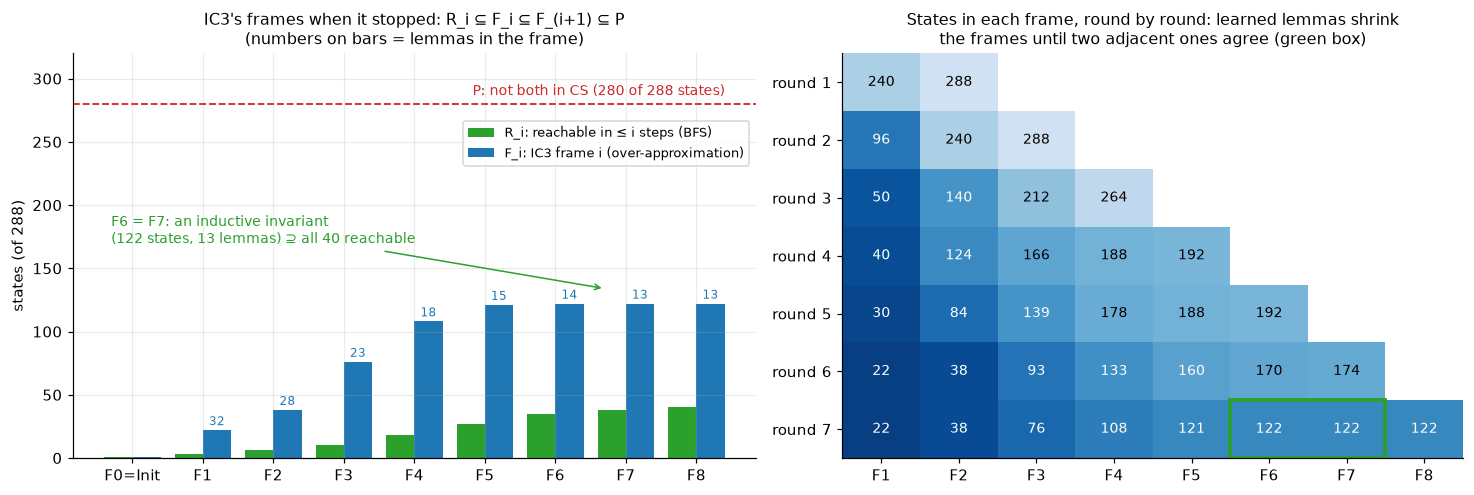

Each frame starts as all 288 domain states and loses states as lemmas arrive; the converged pair holds 122
states against 40 reachable: the invariant IC3 needs is far looser than R itself.


In [104]:
# 8.6 Figure: IC3's frames, final and round by round, counted over the 288 domain states.
if HAVE_Z3:
    _s8_layers = [set(_s8_pet_init)]                   # BFS: states reachable in <= i steps
    for _ in range(len(_s8_hist[-1])):
        _s8_layers.append(_s8_layers[-1] | {t for st in _s8_layers[-1] for _, t in _s8_pet_succ(st)})
    _s8_final = [None] + _s8_hist[-1]                  # frame 0 is Init itself
    _s8_Fsz = [1] + [sum(_s8_holds(f, d) for d in _s8_dicts) for f in _s8_hist[-1]]
    _s8_Rsz = [len(l) for l in _s8_layers[:len(_s8_Fsz)]]
    _s8_nP = sum(not (d['pc0'] == 4 and d['pc1'] == 4) for d in _s8_dicts)
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
    ax = axes[0]
    _s8_xs = np.arange(len(_s8_Fsz))
    ax.bar(_s8_xs - 0.2, _s8_Rsz, 0.4, color="#2ca02c", label="R_i: reachable in ≤ i steps (BFS)")
    ax.bar(_s8_xs + 0.2, _s8_Fsz, 0.4, color="#1f77b4", label="F_i: IC3 frame i (over-approximation)")
    ax.axhline(_s8_nP, ls="--", c="#d62728", lw=1.2)
    ax.text(len(_s8_Fsz) - 0.6, _s8_nP + 7, f"P: not both in CS ({_s8_nP} of {len(_s8_dicts)} states)",
            color="#d62728", fontsize=9, ha="right")
    for _s8_i, _s8_fr in enumerate(_s8_final[1:], 1):
        ax.text(_s8_i + 0.2, _s8_Fsz[_s8_i] + 4, f"{len(_s8_fr)}", ha="center", fontsize=8, color="#1f77b4")
    ax.annotate(f"F{_s8_conv} = F{_s8_conv + 1}: an inductive invariant\n({_s8_Fsz[_s8_conv + 1]} states, "
                f"{len(_s8_inv)} lemmas) ⊇ all {len(_s8_R)} reachable", xy=(_s8_conv + 0.7, _s8_Fsz[_s8_conv] + 12),
                xytext=(-0.3, 170), fontsize=9, color="#2ca02c", arrowprops=dict(arrowstyle="->", color="#2ca02c"))
    ax.set_xticks(_s8_xs)
    ax.set_xticklabels(["F0=Init"] + [f"F{i}" for i in _s8_xs[1:]])
    ax.set_ylim(0, 320)
    ax.set_ylabel("states (of 288)")
    ax.set_title("IC3's frames when it stopped: R_i ⊆ F_i ⊆ F_(i+1) ⊆ P\n(numbers on bars = lemmas in the frame)",
                 fontsize=10.5)
    ax.legend(fontsize=8.5, loc="upper right", bbox_to_anchor=(1.0, 0.85))
    ax = axes[1]
    _s8_grid = np.array([[sum(_s8_holds(f, d) for d in _s8_dicts) for f in frs]
                         + [np.nan] * (len(_s8_hist[-1]) - len(frs)) for frs in _s8_hist])
    ax.imshow(_s8_grid, cmap="Blues_r", aspect="auto", vmin=0, vmax=len(_s8_dicts) * 1.25)
    for (_s8_r, _s8_j), _s8_v in np.ndenumerate(_s8_grid):
        if not np.isnan(_s8_v):
            ax.text(_s8_j, _s8_r, int(_s8_v), ha="center", va="center", fontsize=9,
                    color="white" if _s8_v < 0.45 * len(_s8_dicts) * 1.25 else "black")
    ax.add_patch(Rectangle((_s8_conv - 1.5, len(_s8_hist) - 1.5), 2, 1, fill=False, ec="#2ca02c", lw=2.5))
    ax.set_xticks(range(_s8_grid.shape[1]))
    ax.set_xticklabels([f"F{j + 1}" for j in range(_s8_grid.shape[1])])
    ax.set_yticks(range(len(_s8_hist)))
    ax.set_yticklabels([f"round {r + 1}" for r in range(len(_s8_hist))])
    ax.grid(False)
    ax.set_title("States in each frame, round by round: learned lemmas shrink\n"
                 "the frames until two adjacent ones agree (green box)", fontsize=10.5)
    plt.tight_layout()
    plt.show()
    print(f"Each frame starts as all {len(_s8_dicts)} domain states and loses states as lemmas arrive; the converged "
          f"pair holds {_s8_Fsz[_s8_conv]}")
    print(f"states against {len(_s8_R)} reachable: the invariant IC3 needs is far looser than R itself.")
else:
    print("Z3 not installed: no IC3 frames to draw.")

IC3 succeeded using single-step queries only. In this run its 13 lemmas are, up to grouping, the textbook proof.
The cell checks this with one Z3 query per lemma rather than by reading the printout, so a Z3 version that learns
different (equally valid) lemmas would show up there:

- a thread past its flag write has its flag up;
- if one thread is in the critical section while the other waits, the waiting thread gave the turn away last;
- the property itself.

`is_inductive` and the BFS re-check confirm $|R| \le |I| \le |P|$. In the figure, the frames sit between the
exact $i$-step reachable sets and $P$ (left), and each round's lemmas shrink the frames until two adjacent ones
coincide (right).

### 8.7 BDDs: the first symbolic model checker

Before SAT solvers got good, symbolic model checking meant **binary decision diagrams**. A BDD is a decision DAG
over the state bits with a fixed variable order, reduced by two rules: skip any test whose branches agree, and
share identical subgraphs through a **unique table**. The result is **canonical** (Bryant 1986): each function
has one diagram per order. Equivalence is an id comparison, and $\wedge, \vee, \oplus$ are one memoised `apply`
in $O(|u|\cdot|v|)$ time. Burch, Clarke, McMillan, Dill & Hwang (LICS 1990, "Symbolic model checking: $10^{20}$
states and beyond") computed reachable sets on BDDs as the fixpoint
$R_{i+1}(s') = R_i(s') \vee \exists s.\, R_i(s) \wedge T(s, s')$. That works as long as the diagrams stay small,
and their size depends on the order. For $x = y$ over two $n$-bit words:

- **Interleaved** order $x_0 y_0 x_1 y_1 \dots$: each bit pair costs one $x_i$ node plus two $y_i$ nodes, so the
  total is $3n + 2$, counting both terminals.
- **Separated** order $x_0 \dots x_{n-1} y_0 \dots y_{n-1}$: the diagram must remember all of $x$ before it sees
  any $y$. Level $x_i$ has $2^i$ nodes and level $y_j$ has $2^{n-j}$, so the total is
  $(2^n - 1) + (2^{n+1} - 2) + 2 = 3\cdot 2^n - 1$.

**Registered prediction:** the measured node counts equal $3n + 2$ and $3\cdot 2^n - 1$ for every $n = 1..16$.

Sometimes no good order exists at all. A multiplier's middle output bit needs $\Omega(1.09^n)$ nodes under every
order (Bryant 1991), and finding an optimal order is NP-complete (Bollig & Wegener 1996). Hence the shift to SAT.
BMC was proposed after BDD model checking failed to scale (§5.3), and CDCL solved BMC benchmarks up to two orders
of magnitude faster than any other approach (Fichte et al., CACM 2023). k-induction (2000) and interpolation
(2003) then made SAT-based checking unbounded, and IC3 (2011) did it without unrolling.

Who finds the invariant? Nobody, for the explicit-state checker, which enumerates $R$. The unrolling, for
k-induction, when it works at all. A lemma-learning algorithm, for IC3. A fixpoint over canonical diagrams, for
BDDs. §9 uses abstract domains instead, and in §13 an LLM proposes while `is_inductive` decides.

In [105]:
# 8.7 BDDs: canonical, compact -- and hostage to the variable order.
_s8_BDD_SEED = 8           # random formulas for the BDD self-test
_s8_BDD_NMAX = 16          # x == y for n = 1..16 bits (the separated order reaches 3 * 2^16 - 1 nodes)


class BDD:
    '''Reduced ordered binary decision diagrams (Bryant 1986). A node is (level, low, high); the UNIQUE table
    returns the same integer id for the same triple, so equal functions are equal ids (a canonical form:
    equivalence checking is one integer comparison). apply() is memoised on (op name, operands), operands
    sorted for commutative ops. Level = position in the variable order; ids 0 / 1 are FALSE / TRUE.'''
    OPS = {'and': lambda a, b: a and b, 'or': lambda a, b: a or b, 'xor': lambda a, b: a != b,
           'xnor': lambda a, b: a == b, 'imp': lambda a, b: (not a) or b}
    COMMUTATIVE = {'and', 'or', 'xor', 'xnor'}

    def __init__(self, n_vars):
        self.n = n_vars
        self.nodes = [(n_vars, None, None), (n_vars, None, None)]   # terminals live below every variable
        self.unique, self.memo = {}, {}

    def mk(self, level, low, high):
        '''The reduction rules: skip a test whose branches agree; share every repeated (level, low, high).'''
        if low == high:
            return low
        key = (level, low, high)
        if key not in self.unique:
            self.unique[key] = len(self.nodes)
            self.nodes.append(key)
        return self.unique[key]

    def var(self, level):
        return self.mk(level, 0, 1)

    def apply(self, op, u, v):
        '''op(u, v) by Shannon expansion on the top variable of u and v; each operand pair is computed once.'''
        if op in self.COMMUTATIVE and u > v:
            u, v = v, u
        key = (op, u, v)
        if key not in self.memo:
            if u <= 1 and v <= 1:
                self.memo[key] = int(self.OPS[op](bool(u), bool(v)))
            else:
                lu, lv = self.nodes[u][0], self.nodes[v][0]
                top = min(lu, lv)
                u0, u1 = self.nodes[u][1:] if lu == top else (u, u)
                v0, v1 = self.nodes[v][1:] if lv == top else (v, v)
                self.memo[key] = self.mk(top, self.apply(op, u0, v0), self.apply(op, u1, v1))
        return self.memo[key]

    def NOT(self, u):
        return self.apply('xor', u, 1)

    def reachable(self, u):
        '''Node ids of the diagram rooted at u (both terminals included when reachable).'''
        seen, stack = set(), [u]
        while stack:
            x = stack.pop()
            if x not in seen:
                seen.add(x)
                if x > 1:
                    stack += [self.nodes[x][1], self.nodes[x][2]]
        return seen

    def size(self, u):
        return len(self.reachable(u))

    def sat_count(self, u):
        '''Number of satisfying assignments of all n variables (skipped levels count twice).'''
        @functools.lru_cache(maxsize=None)
        def count(x):
            if x <= 1:
                return x
            lvl, lo, hi = self.nodes[x]
            return sum(count(c) * 2 ** (self.nodes[c][0] - lvl - 1) for c in (lo, hi))
        return count(u) * 2 ** self.nodes[u][0]

    def evaluate(self, u, bits):
        '''Follow one path: bits[level] in {0, 1}.'''
        while u > 1:
            lvl, lo, hi = self.nodes[u]
            u = hi if bits[lvl] else lo
        return u


def _s8_equal_bdd(n, order):
    '''x == y for two n-bit words, x_i and y_i either interleaved (x0 y0 x1 y1 ...) or separated (x.. then y..).'''
    B = BDD(2 * n)
    lx = [2 * i if order == 'interleaved' else i for i in range(n)]
    ly = [2 * i + 1 if order == 'interleaved' else n + i for i in range(n)]
    f = 1
    for i in range(n):
        f = B.apply('and', f, B.apply('xnor', B.var(lx[i]), B.var(ly[i])))
    return B, f, lx, ly


def _s8_bdd_selftest(seed=_s8_BDD_SEED, trials=300, n=4):
    '''Oracle: random formulas over n variables, BDD truth table vs direct Python evaluation.'''
    rnd = random.Random(seed)
    for _ in range(trials):
        B = BDD(n)
        exprs = [(B.var(i), (lambda i: lambda bits: bits[i])(i)) for i in range(n)]
        for _ in range(6):
            (u, fu), (v, fv) = rnd.choice(exprs), rnd.choice(exprs)
            op = rnd.choice(sorted(BDD.OPS))
            exprs.append((B.apply(op, u, v), (lambda fu, fv, op: lambda b: BDD.OPS[op](fu(b), fv(b)))(fu, fv, op)))
        root, fn = exprs[-1]
        table = [bool(fn(bits)) for bits in itertools.product((0, 1), repeat=n)]
        if [bool(B.evaluate(root, bits)) for bits in itertools.product((0, 1), repeat=n)] != table:
            return False
        if B.sat_count(root) != sum(table):
            return False
    return True


_s8_sizes = {}
for _s8_order in ("interleaved", "separated"):
    for _s8_n in range(1, _s8_BDD_NMAX + 1):
        _s8_B, _s8_f, _, _ = _s8_equal_bdd(_s8_n, _s8_order)
        _s8_sizes[_s8_order, _s8_n] = (_s8_B.size(_s8_f), _s8_B.sat_count(_s8_f))
_s8_ns = list(range(1, _s8_BDD_NMAX + 1))
_s8_ok_i = all(_s8_sizes['interleaved', n][0] == 3 * n + 2 for n in _s8_ns)
_s8_ok_s = all(_s8_sizes['separated', n][0] == 3 * 2 ** n - 1 for n in _s8_ns)
_s8_ok_c = all(_s8_sizes[o, n][1] == 2 ** n for o in ("interleaved", "separated") for n in _s8_ns)
print(f"BDD self-test, 300 random 4-variable formulas vs truth tables (evaluate + sat_count): {_s8_bdd_selftest()}")
print(f"sat_count(x == y) = 2^n for every n and both orders (one y per x): {_s8_ok_c}")
show_table(["n bits", "nodes, interleaved", "3n + 2", "nodes, separated", "3 * 2^n - 1"],
           [[n, _s8_sizes['interleaved', n][0], 3 * n + 2, _s8_sizes['separated', n][0], 3 * 2 ** n - 1]
            for n in (1, 2, 4, 8, 12, 16)])
print(f"registered prediction: x == y takes 3n + 2 nodes interleaved and 3 * 2^n - 1 separated (both terminals "
      f"counted) | measured: n = 1..{_s8_BDD_NMAX} match {_s8_ok_i} / {_s8_ok_s} | verdict: "
      f"{'RIGHT' if _s8_ok_i and _s8_ok_s else 'WRONG'} -- the separated order must remember all of x before it "
      "sees any y")

BDD self-test, 300 random 4-variable formulas vs truth tables (evaluate + sat_count): True
sat_count(x == y) = 2^n for every n and both orders (one y per x): True
n bits  nodes, interleaved  3n + 2  nodes, separated  3 * 2^n - 1
-----------------------------------------------------------------
1       5                   5       5                 5          
2       8                   8       11                11         
4       14                  14      47                47         
8       26                  26      767               767        
12      38                  38      12287             12287      
16      50                  50      196607            196607     
registered prediction: x == y takes 3n + 2 nodes interleaved and 3 * 2^n - 1 separated (both terminals counted) | measured: n = 1..16 match True / True | verdict: RIGHT -- the separated order must remember all of x before it sees any y


The figure draws the growth, and both diagrams for $n = 3$, where the separated order's $2^i$ nodes per level are
still small enough to see.

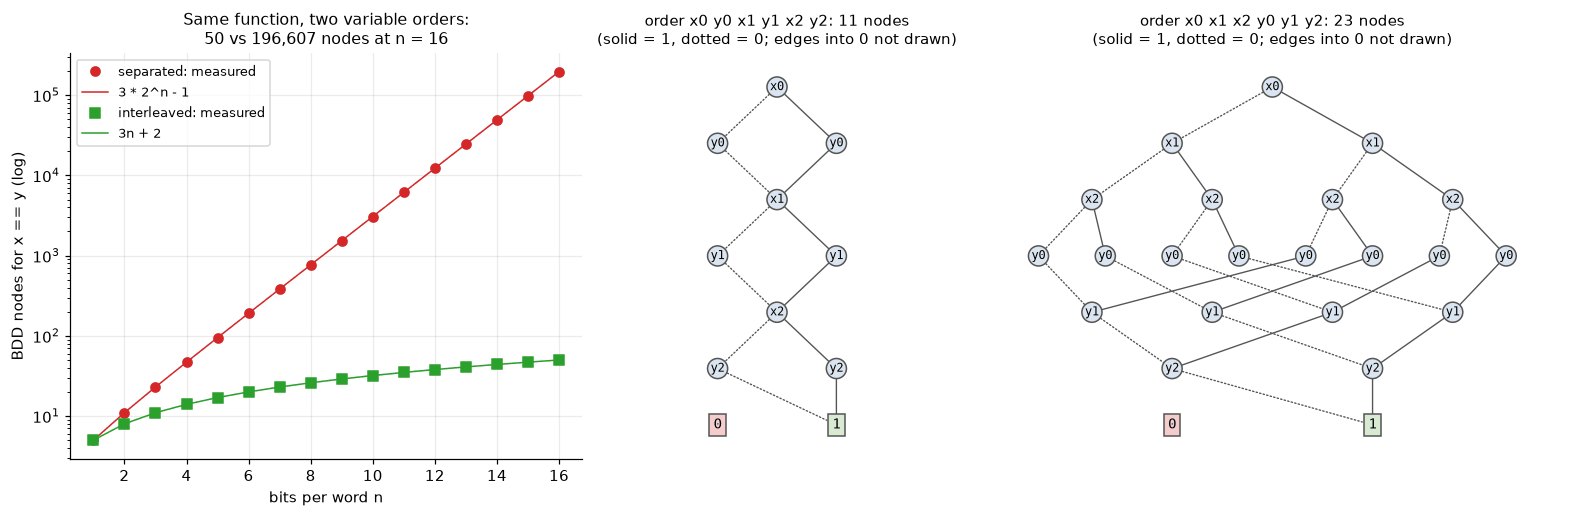

The separated order has 2^i nodes at level x_i: before it reads any y it must remember every bit of x.
Order is everything for BDDs (and finding the best order is NP-hard); SAT-based methods have no such knob.


In [106]:
# 8.7 Figure: node counts for both orders, and the two diagrams for n = 3.
def _s8_draw_bdd(ax, B, root, names, title):
    '''Layered drawing: one row per variable level, solid edge = 1 (high), dotted = 0 (low); within a row nodes
    sit at the mean x of their parents (fewer crossings); edges into the 0 terminal are left out.'''
    nodes = B.reachable(root)
    levels = sorted({B.nodes[u][0] for u in nodes})
    parents = defaultdict(list)
    for u in nodes:
        if u > 1:
            parents[B.nodes[u][1]].append(u)
            parents[B.nodes[u][2]].append(u)
    pos = {}
    for r, lvl in enumerate(levels):
        row = [u for u in nodes if B.nodes[u][0] == lvl]
        if lvl == B.n:
            row = sorted(row)                                     # terminals: 0 left, 1 right
        else:
            bary = lambda u: np.mean([pos[p][0] + (0.01 if B.nodes[p][2] == u else -0.01) for p in parents[u]]) \
                if parents[u] else 0.5
            row = sorted(row, key=bary)
        for k, u in enumerate(row):
            pos[u] = ((k + 1) / (len(row) + 1), -r)
    for u in nodes:
        if u > 1:
            _, lo, hi = B.nodes[u]
            for child, ls in ((lo, ":"), (hi, "-")):
                if child != 0:
                    ax.annotate("", xy=pos[child], xytext=pos[u], arrowprops=dict(
                        arrowstyle="-", ls=ls, color="#555555", lw=0.9, shrinkA=7, shrinkB=7))
    for u, (px, py) in pos.items():
        if u <= 1:
            ax.text(px, py, str(u), ha="center", va="center", fontsize=9, family="monospace",
                    bbox=dict(boxstyle="square,pad=0.3", fc="#d9ead3" if u else "#f4cccc", ec="#555555"))
        else:
            ax.text(px, py, names[B.nodes[u][0]], ha="center", va="center", fontsize=8, family="monospace",
                    bbox=dict(boxstyle="circle,pad=0.25", fc="#dbe5f1", ec="#555555"))
    ax.set_xlim(0, 1)
    ax.set_ylim(-len(levels) + 0.4, 0.6)
    ax.axis("off")
    ax.set_title(title, fontsize=10)


fig = plt.figure(figsize=(14.5, 4.8))
_s8_gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 0.8, 1.35])
ax = fig.add_subplot(_s8_gs[0])
ax.semilogy(_s8_ns, [_s8_sizes['separated', n][0] for n in _s8_ns], "o", c="#d62728", label="separated: measured")
ax.semilogy(_s8_ns, [3 * 2 ** n - 1 for n in _s8_ns], "-", c="#d62728", lw=1, label="3 * 2^n - 1")
ax.semilogy(_s8_ns, [_s8_sizes['interleaved', n][0] for n in _s8_ns], "s", c="#2ca02c",
            label="interleaved: measured")
ax.semilogy(_s8_ns, [3 * n + 2 for n in _s8_ns], "-", c="#2ca02c", lw=1, label="3n + 2")
ax.set_xlabel("bits per word n")
ax.set_ylabel("BDD nodes for x == y (log)")
ax.set_title(f"Same function, two variable orders:\n{3 * _s8_BDD_NMAX + 2} vs {3 * 2 ** _s8_BDD_NMAX - 1:,} nodes "
             f"at n = {_s8_BDD_NMAX}", fontsize=10.5)
ax.legend(fontsize=8.5)
_s8_n3 = 3
for _s8_k, (_s8_order, _s8_title) in enumerate((("interleaved", "x0 y0 x1 y1 x2 y2"),
                                                ("separated", "x0 x1 x2 y0 y1 y2"))):
    _s8_B, _s8_f, _s8_lx, _s8_ly = _s8_equal_bdd(_s8_n3, _s8_order)
    _s8_names = {**{l: f"x{i}" for i, l in enumerate(_s8_lx)}, **{l: f"y{i}" for i, l in enumerate(_s8_ly)}}
    _s8_draw_bdd(fig.add_subplot(_s8_gs[1 + _s8_k]), _s8_B, _s8_f, _s8_names,
                 f"order {_s8_title}: {_s8_B.size(_s8_f)} nodes\n(solid = 1, dotted = 0; edges into 0 not drawn)")
plt.tight_layout()
plt.show()
print("The separated order has 2^i nodes at level x_i: before it reads any y it must remember every bit of x.")
print("Order is everything for BDDs (and finding the best order is NP-hard); SAT-based methods have no such knob.")

## 9. Sound approximation: abstract interpretation

§6 had a human write the inductive invariant; §8 searched for one over finite state. **Abstract interpretation**
(Cousot & Cousot, POPL 1977) has an algorithm *compute* one, in a vocabulary of facts fixed in advance — a
**domain**: intervals `l <= x <= h`, octagons `±x ± y <= c`, polyhedra. It needs no annotations, always
terminates, never misses a violation of the safety properties it checks ($O \supseteq R$ in §2.4's picture), and
pays for all three with false alarms. This section derives why the computed object is sound, builds an analyzer
for MiniPy, runs it with intervals on `midpoint_buggy` and the correct `midpoint_fixed`, and then runs it again
with two relational domains.

### 9.1 From reachable states to a computable fixpoint

**Collecting semantics.** Give each program point $\ell$ (a loop head, the point after a statement) the set
$R_\ell$ of states that can occur there. The vector $R = (R_\ell)_\ell$ solves one equation per point — the
initial states at the entry, plus the image of each predecessor's set under the statement in between:
$$R = F(R), \qquad
  F(X)_\ell = \mathit{Init}_\ell \;\cup \bigcup_{\ell' \to \ell} \mathit{post}_{\ell' \to \ell}(X_{\ell'}).$$
$F$ is monotone on sets of states ordered by $\subseteq$, so (Tarski) it has a least fixpoint. It even commutes
with unions of increasing chains (each $\mathit{post}$ is an image, and images commute with unions), so by
Kleene's fixpoint theorem $R = \mathrm{lfp}\,F = \bigcup_k F^k(\emptyset)$: run the program one step at a time,
forever. Exact, and not computable: the sets are infinite and the union can need infinitely many steps (Rice,
§2.4).

**Abstract domain.** Pick a lattice $A$ of finitely representable facts with a monotone **concretization**
$\gamma: A \to \wp(\mathit{States})$ (which states a fact allows) and an **abstraction**
$\alpha: \wp(\mathit{States}) \to A$ (the best fact for a set). For one integer variable, intervals:
$\gamma([l,h]) = \{l, \dots, h\}$ and $\alpha(S) = [\min S, \max S]$. The two form a **Galois connection**,
$$\alpha(S) \sqsubseteq a \iff S \subseteq \gamma(a),$$
so "a over-approximates S" means the same thing on both sides. For an ML engineer: $\gamma$ decodes a lossy
code word, $\alpha$ picks the tightest code word whose decoding contains the data — lossy compression that is
only ever allowed to err by *adding* states. Not every domain has an $\alpha$. Over $\mathbb{R}^2$, no polyhedron
(§9.5) is the tightest one around a disc, since another facet always cuts closer. Over the integer states used
here a finite set always has one (the convex hull of its points), but an infinite set need not: no polyhedron with
rational coefficients is the tightest one around the integer points of the wedge $x \ge 0,\ 0 \le y \le \sqrt2\,x$,
because any such polyhedron contains a ray of rational slope above $\sqrt2$, and a facet of rational slope between
the two cuts off more integer points. That is why the soundness argument below uses only $\gamma$.

**Local soundness implies global soundness.** An abstract transformer $F^\#$ is **locally sound** if one
abstract step covers one concrete step: $F(\gamma(a)) \subseteq \gamma(F^\#(a))$ for every $a$. Now take any
**post-fixpoint**, an $a$ with $F^\#(a) \sqsubseteq a$. Then
$$F(\gamma(a)) \;\subseteq\; \gamma(F^\#(a)) \;\subseteq\; \gamma(a)$$
(local soundness, then $\gamma$ monotone). So $\gamma(a)$ contains the initial states and is closed under every
step: it is an **inductive invariant**, §6.3's object. By Tarski, $\mathrm{lfp}\,F$ is the intersection of all
sets closed under $F$, hence $R \subseteq \gamma(a)$. Two consequences. Soundness needs only that each transfer
function (`+`, a guard, a join) is sound *by itself*, which can be checked one operation at a time — §9.2 does,
by brute force on every interval inside $[-4, 4]$. And *any* post-fixpoint will do, not only the least one: that
licence is what lets the analysis stop.

**Widening and narrowing.** Intervals have infinite ascending chains ($[0,0] \sqsubseteq [0,1] \sqsubseteq
\dots$), so iterating $F^\#$ at a loop head can take $2^{31}$ steps or never stop. A **widening** $\nabla$
over-approximates the join ($a \sqsubseteq a \nabla b$, $b \sqsubseteq a \nabla b$) and forces
$x_{k+1} = x_k \nabla F^\#(x_k)$ to stabilize in finitely many steps; for intervals it sends every bound that
moved to $\pm\infty$. Where it stops, $F^\#(x) \sqsubseteq x$: a post-fixpoint, sound, usually strictly above the
least fixpoint of $F^\#$. **Narrowing** then walks back down, $x_{k+1} = x_k \,\Delta\, F^\#(x_k)$, refilling
only infinite bounds from $F^\#(x_k)$. Because $F^\#(x_k) \sqsubseteq x_{k+1} \sqsubseteq x_k$, monotonicity
gives $F^\#(x_{k+1}) \sqsubseteq F^\#(x_k) \sqsubseteq x_{k+1}$: every narrowing iterate is still a
post-fixpoint. It recovers bounds that something in the loop re-establishes on every iteration, and nothing the
domain cannot say.

### 9.2 An analyzer for MiniPy

The code splits the way real analyzers do. A **domain** supplies the states and transfer functions. A
**fixpoint engine** walks the normalized MiniPy AST, joins the two arms of each `if`, iterates each loop head to a
post-fixpoint of $\mathit{entry} \sqcup \mathit{body}(\mathit{head})$ (two plain iterations, then widening, then
two narrowing steps by default) and re-checks the result with one more iteration — the certificate check in
§2.4's verdict table. The engine reaches states only through the domain's methods, so §9.5 can swap in a second
domain. Values live in ℤ, inputs range over int32, and the checks are int+ovf's: every program `+ - *` and unary
minus must land in int32, and every `assert`/`ensures`/`invariant` must hold — proved iff the state refined by
the check's *negation* is empty. After an alarm the analysis continues with the executions that did not overflow
(int+ovf stops the others). A `decreases(...)` is a termination obligation, which this safety analysis does not
attempt: every reachable variant is reported as an unproved alarm, so "no alarm" still means no run can fail.
`interval_analyze` maps each point (`('loop_head', line)`, `('after', line)`, `('return', line)`) to
`{var: Interval}`, `{}` if proved unreachable, and each `('alarm', line)` to its unproved checks with the
interval of the offending value.

An analyzer that claims soundness and is wrong is worse than none, so the code comes in five cells, each tested
as it is built. The first is the `Interval` lattice. Every operation, the guard refinement included, is checked
against brute force over all 45 intervals inside $[-4, 4]$: local soundness, and that each returns exactly the
best abstraction $\alpha \circ f \circ \gamma$. The Galois connection is checked over all 512 subsets of
$[-4, 4]$.

In [107]:
# 9.2 (a) The Interval lattice, its arithmetic and the guard refinement, each checked against brute force.
_s9_SMALL = range(-4, 5)  # the brute-force universe for checking each Interval operation


class Interval:
    '''A non-empty set of integers {lo, ..., hi}; lo = None means -infinity, hi = None means +infinity. The empty
    set (bottom) is never an Interval: operations that can produce it (meet, make) return None instead.'''
    __slots__ = ('lo', 'hi')

    def __init__(self, lo=None, hi=None):
        if lo is not None and hi is not None and lo > hi:
            raise ValueError(f"empty interval [{lo}, {hi}] (bottom is None)")
        self.lo, self.hi = lo, hi

    @staticmethod
    def make(lo, hi):
        '''Interval(lo, hi), or None when it is empty.'''
        return None if lo is not None and hi is not None and lo > hi else Interval(lo, hi)

    def __repr__(self):
        return f"[{'-inf' if self.lo is None else self.lo}, {'+inf' if self.hi is None else self.hi}]"

    def __eq__(self, other):
        return isinstance(other, Interval) and (self.lo, self.hi) == (other.lo, other.hi)

    def __hash__(self):
        return hash((self.lo, self.hi))

    def contains(self, v):
        return (self.lo is None or self.lo <= v) and (self.hi is None or v <= self.hi)

    def leq(self, other):
        '''self ⊑ other, i.e. γ(self) ⊆ γ(other).'''
        return ((other.lo is None or (self.lo is not None and self.lo >= other.lo)) and
                (other.hi is None or (self.hi is not None and self.hi <= other.hi)))

    def join(self, other):
        '''The smallest interval containing both: the best abstraction of the union.'''
        return Interval(None if self.lo is None or other.lo is None else min(self.lo, other.lo),
                        None if self.hi is None or other.hi is None else max(self.hi, other.hi))

    def meet(self, other):
        '''The intersection (exact), or None.'''
        lo = other.lo if self.lo is None else self.lo if other.lo is None else max(self.lo, other.lo)
        hi = other.hi if self.hi is None else self.hi if other.hi is None else min(self.hi, other.hi)
        return Interval.make(lo, hi)

    def widen(self, other):
        '''self ∇ other: keep each bound that did not move outward, send the others to infinity.'''
        lo = self.lo if self.lo is not None and other.lo is not None and other.lo >= self.lo else None
        hi = self.hi if self.hi is not None and other.hi is not None and other.hi <= self.hi else None
        return Interval(lo, hi)

    def narrow(self, other):
        '''self Δ other (for other ⊑ self): refill only the infinite bounds of self from other.'''
        return Interval(other.lo if self.lo is None else self.lo, other.hi if self.hi is None else self.hi)

    def __add__(self, other):
        return Interval(None if self.lo is None or other.lo is None else self.lo + other.lo,
                        None if self.hi is None or other.hi is None else self.hi + other.hi)

    def __neg__(self):
        return Interval(None if self.hi is None else -self.hi, None if self.lo is None else -self.lo)

    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        '''The four corner products bound the product (0 * inf = 0: zero times any finite value is zero).'''
        ext = lambda iv: (-math.inf if iv.lo is None else iv.lo, math.inf if iv.hi is None else iv.hi)
        prods = [0 if x == 0 or y == 0 else x * y for x in ext(self) for y in ext(other)]
        lo, hi = min(prods), max(prods)
        return Interval(None if lo == -math.inf else lo, None if hi == math.inf else hi)

    def shr(self, k):
        '''x >> k = floor(x / 2^k) is monotone, so bounds map to bounds.'''
        return Interval(None if self.lo is None else self.lo >> k, None if self.hi is None else self.hi >> k)


_s9_INT32 = Interval(INT32_MIN, INT32_MAX)
_s9_NEGATE = {ast.Lt: ast.GtE, ast.LtE: ast.Gt, ast.Gt: ast.LtE, ast.GtE: ast.Lt, ast.Eq: ast.NotEq,
              ast.NotEq: ast.Eq}
_s9_COMPARE = {ast.Lt: lambda x, y: x < y, ast.LtE: lambda x, y: x <= y, ast.Gt: lambda x, y: x > y,
               ast.GtE: lambda x, y: x >= y, ast.Eq: lambda x, y: x == y, ast.NotEq: lambda x, y: x != y}


def _s9_refine_cmp(op, L, R):
    '''The guard's transfer function: shrink L and R to the values that can satisfy  L op R  (each side against
    the other's bounds). Returns (L', R'), with None for an empty side.'''
    if op in (ast.Gt, ast.GtE):
        R2, L2 = _s9_refine_cmp(ast.Lt if op is ast.Gt else ast.LtE, R, L)
        return L2, R2
    if op is ast.Lt:
        return (L.meet(Interval(None, None if R.hi is None else R.hi - 1)),
                R.meet(Interval(None if L.lo is None else L.lo + 1, None)))
    if op is ast.LtE:
        return L.meet(Interval(None, R.hi)), R.meet(Interval(L.lo, None))
    if op is ast.Eq:
        return L.meet(R), L.meet(R)

    def shave(X, c):                                   # X != c, c a single value: trim an endpoint
        if X.lo == c and X.hi == c:
            return None
        return Interval(X.lo + 1 if X.lo == c else X.lo, X.hi - 1 if X.hi == c else X.hi)
    return (shave(L, R.lo) if R.lo is not None and R.lo == R.hi else L,
            shave(R, L.lo) if L.lo is not None and L.lo == L.hi else R)


def _s9_check_interval_ops():
    '''Local soundness and best-abstraction checks by enumeration (arithmetic, join, meet and the guard), the
    Galois connection, and the widening/narrowing laws.'''
    small = [Interval(a, b) for a in _s9_SMALL for b in _s9_SMALL if a <= b]
    alpha = lambda S: Interval(min(S), max(S)) if S else None
    gamma = lambda iv: range(iv.lo, iv.hi + 1)
    covers = lambda got, S: got is not None and all(got.contains(v) for v in S) if S else True
    binary = {'+': (lambda A, B: A + B, lambda x, y: x + y), '-': (lambda A, B: A - B, lambda x, y: x - y),
              '*': (lambda A, B: A * B, lambda x, y: x * y)}
    unary = {'neg': (lambda A: -A, lambda x: -x), '>>1': (lambda A: A.shr(1), lambda x: x >> 1),
             '>>2': (lambda A: A.shr(2), lambda x: x >> 2)}
    checks = unsound = not_best = 0
    guard = Counter()
    for A in small:
        for name, (f_abs, f) in unary.items():
            S, got = {f(x) for x in gamma(A)}, f_abs(A)
            checks += 1
            unsound += not covers(got, S)
            not_best += got != alpha(S)
        for B in small:
            for name, (f_abs, f) in binary.items():
                S, got = {f(x, y) for x in gamma(A) for y in gamma(B)}, f_abs(A, B)
                checks += 1
                unsound += not covers(got, S)
                not_best += got != alpha(S)
            for got, S in ((A.join(B), set(gamma(A)) | set(gamma(B))), (A.meet(B), set(gamma(A)) & set(gamma(B)))):
                checks += 1
                unsound += not covers(got, S)
                not_best += got != alpha(S)
            for op, holds in _s9_COMPARE.items():        # the guard A op B: projections of the satisfying pairs
                pairs = [(x, y) for x in gamma(A) for y in gamma(B) if holds(x, y)]
                Sx, Sy = {x for x, _ in pairs}, {y for _, y in pairs}
                L2, R2 = _s9_refine_cmp(op, A, B)
                guard['checks'] += 1
                guard['unsound'] += not (covers(L2, Sx) and covers(R2, Sy))
                guard['not_best'] += (L2, R2) != (alpha(Sx), alpha(Sy))
    universe = list(_s9_SMALL)
    galois = sum((alpha(S) is None or alpha(S).leq(A)) != all(A.contains(v) for v in S)
                 for r in range(len(universe) + 1) for S in map(set, itertools.combinations(universe, r))
                 for A in small)
    wide = small + [Interval(None, b) for b in _s9_SMALL] + [Interval(a, None) for a in _s9_SMALL] + [Interval()]
    laws = sum(not (A.leq(A.widen(B)) and B.leq(A.widen(B))) for A in wide for B in wide)
    laws += sum(not (B.leq(A.narrow(B)) and A.narrow(B).leq(A)) for A in wide for B in wide if B.leq(A))
    inf_cases = [(Interval(0, 0) * Interval(), Interval(0, 0)), (Interval(None, 3) + Interval(1, 1), Interval(None, 4)),
                 (Interval(-2, None) * Interval(-1, 1), Interval()), (-Interval(None, 5), Interval(-5, None)),
                 (Interval(None, -3).shr(1), Interval(None, -2)), (Interval(1, None) * Interval(2, 3), Interval(2, None))]
    laws += sum(got != want for got, want in inf_cases)
    print(f"Interval operations vs brute force on all {len(small)} intervals inside [-4, 4]: {checks:,} checks of "
          f"+ - * neg >>1 >>2 join meet | unsound: {unsound} | not the best abstraction α∘f∘γ: {not_best}")
    print(f"guard refinement A op B for < <= > >= == !=: {guard['checks']:,} checks | unsound: {guard['unsound']} "
          f"| not the best (α of the satisfying pairs' projections): {guard['not_best']}")
    print(f"Galois connection α(S) ⊑ a <=> S ⊆ γ(a): {2 ** len(universe) * len(small):,} (S, a) pairs, "
          f"{galois} violations | widening/narrowing laws and ±inf cases: {laws} violations")
    return unsound + not_best + guard['unsound'] + guard['not_best'] + galois + laws


_s9_ops_failures = _s9_check_interval_ops()
print("Each operation is locally sound and returns the best interval: by §9.1 that is all the soundness argument"
      if _s9_ops_failures == 0 else f"{_s9_ops_failures} failures above: the domain is NOT locally sound and best,")
print("asks of the domain, and it has now been checked one operation at a time.")

Interval operations vs brute force on all 45 intervals inside [-4, 4]: 10,260 checks of + - * neg >>1 >>2 join meet | unsound: 0 | not the best abstraction α∘f∘γ: 0
guard refinement A op B for < <= > >= == !=: 12,150 checks | unsound: 0 | not the best (α of the satisfying pairs' projections): 0
Galois connection α(S) ⊑ a <=> S ⊆ γ(a): 23,040 (S, a) pairs, 0 violations | widening/narrowing laws and ±inf cases: 0 violations
Each operation is locally sound and returns the best interval: by §9.1 that is all the soundness argument
asks of the domain, and it has now been checked one operation at a time.


The second cell lifts these operations to **abstract states**, one interval per variable, and gives the engine its
interface: evaluate an expression (raising the int+ovf alarms), refine a state by a comparison, bind, join, widen,
narrow, compare. Its last lines show the price of one range per variable before any loop is involved.

In [108]:
# 9.2 (b) The interval domain: abstract states (var -> Interval) and their transfer functions.
class _s9_IntervalDomain:
    '''The interval domain. A state is a dict var -> Interval (None = bottom). The domain interface the engine
    uses: init, eval, bind, refine_compare, join, widen, narrow, leq, top; the soundness test also uses
    intervals and constraints.'''
    name = 'interval'

    def init(self, params, arrays=()):
        return {p: _s9_INT32 for p in params if p not in arrays}       # int+ovf inputs are int32 values

    def eval(self, s, e, prog, alarm):
        '''(Interval of e or None, s). prog=True: e is program code, so + - * and unary minus carry the int+ovf
        check "result in int32"; an unproved one raises an alarm and only the in-range part continues.'''
        return self.value(s, e, prog, alarm), s

    def value(self, s, e, prog, alarm):
        if isinstance(e, ast.Constant):
            return Interval(e.value, e.value)
        if isinstance(e, ast.Name):
            return s[e.id]
        if isinstance(e, ast.IfExp):                         # (uses the engine's lazy condition logic, cell (c))
            if prog:
                _s9_cond_alarms(self, s, e.test, alarm)
            parts = []
            for branch, truth in ((e.body, True), (e.orelse, False)):
                sb = _s9_refine_logic(self, s, e.test, truth, prog)
                v = None if sb is None else self.value(sb, branch, prog, alarm)
                if v is not None:
                    parts.append(v)
            return functools.reduce(Interval.join, parts) if parts else None
        if isinstance(e, ast.Subscript):                     # array contents: unknown int32 values
            i = self.value(s, e.slice, prog, alarm)
            if alarm is not None and i is not None:          # i < len(a) is relational: never proved here
                alarm(e, f"bounds {ast.unparse(e)}", i)
            return None if i is None else _s9_INT32
        if isinstance(e, ast.Call):                          # len(a)
            return Interval(0, INT32_MAX)
        if isinstance(e, ast.UnaryOp):                       # unary minus
            a = self.value(s, e.operand, prog, alarm)
            return None if a is None else self.check(-a, e, prog, alarm)
        a = self.value(s, e.left, prog, alarm)
        if a is None:
            return None
        if isinstance(e.op, ast.RShift):
            return a.shr(e.right.value)
        b = self.value(s, e.right, prog, alarm)
        if b is None:
            return None
        r = a + b if isinstance(e.op, ast.Add) else a - b if isinstance(e.op, ast.Sub) else a * b
        return self.check(r, e, prog, alarm)

    def check(self, r, node, prog, alarm):
        '''The int+ovf check of one program operation with abstract result r.'''
        if not prog or r.leq(_s9_INT32):
            return r
        if alarm is not None:
            alarm(node, ast.unparse(node), r)
        return r.meet(_s9_INT32)          # the overflowing executions stop; the others continue

    def refine_compare(self, s, c, truth, prog):
        op = type(c.ops[0]) if truth else _s9_NEGATE[type(c.ops[0])]
        left, right = c.left, c.comparators[0]
        L, R = self.value(s, left, prog, None), self.value(s, right, prog, None)
        if L is None or R is None:
            return None
        L2, R2 = _s9_refine_cmp(op, L, R)
        if L2 is None or R2 is None:
            return None
        s = dict(s)
        if isinstance(right, ast.Name):
            s[right.id] = R2
        if isinstance(left, ast.Name):                       # x op x: both refinements apply to x
            s[left.id] = L2 if not (isinstance(right, ast.Name) and right.id == left.id) else L2.meet(R2)
            if s[left.id] is None:
                return None
        return s

    def bind(self, s, x, v):
        s = dict(s)
        s[x] = v
        return s

    def join(self, a, b):
        return {x: a[x].join(b[x]) for x in a if x in b}

    def widen(self, a, b):
        return {x: a[x].widen(b[x]) for x in a if x in b}

    def narrow(self, a, b):
        return {x: a[x].narrow(b[x]) for x in a if x in b}

    def leq(self, a, b):
        return all(x in a and a[x].leq(b[x]) for x in b)

    def top(self, s):
        return {x: Interval() for x in s}

    def intervals(self, s):
        return {} if s is None else dict(s)

    def constraints(self, s):
        '''The facts of state s as MiniPy conditions: [(text, set of names it mentions)].'''
        out = []
        for x, iv in s.items():
            out += [(f"{x} >= {iv.lo}", {x})] if iv.lo is not None else []
            out += [(f"{x} <= {iv.hi}", {x})] if iv.hi is not None else []
        return out


def _s9_domain_demo():
    '''Two transfer functions on small states: subtraction of a variable from itself, and a guard.'''
    dom, expr = _s9_IntervalDomain(), lambda text: ast.parse(text, mode='eval').body
    s = {'x': Interval(0, 10), 'y': Interval(5, 20)}
    xx = dom.value(s, expr('x - x'), False, None)
    g = dom.refine_compare(s, expr('x > y'), True, False)
    print(f"state x ∈ {s['x']}, y ∈ {s['y']}: x - x ∈ {xx} (not {{0}}); the guard x > y refines it to "
          f"x ∈ {g['x']}, y ∈ {g['y']}")
    print("One range per variable: the domain cannot know that both x's in x - x are the same value. That loss,")
    print("the dependency problem, is what §9.4's running example puts to the test.")


_s9_domain_demo()

state x ∈ [0, 10], y ∈ [5, 20]: x - x ∈ [-10, 10] (not {0}); the guard x > y refines it to x ∈ [6, 10], y ∈ [5, 9]
One range per variable: the domain cannot know that both x's in x - x are the same value. That loss,
the dependency problem, is what §9.4's running example puts to the test.


The third cell is the engine. It walks statements, joins at the end of an `if`, iterates every loop head
(plain, then widening, then narrowing), re-checks the result, and records alarms only in a final pass once the
loop-head states are fixed. It never looks inside a state.

In [109]:
# 9.2 (c) The domain-agnostic fixpoint engine, and interval_analyze on top of it.
_s9_WIDEN_DELAY = 2       # plain Kleene iterations at a loop head before widening starts
_s9_MAX_ITERS = 1000      # cap on loop-head iterations; reaching it forces a widening step (reported in meta)


def _s9_join(dom, a, b):
    '''Join of two abstract states, where None is bottom (no execution reaches the point).'''
    return b if a is None else a if b is None else dom.join(a, b)


def _s9_leq(dom, a, b):
    return a is None or (b is not None and dom.leq(a, b))


def _s9_refine_logic(dom, s, c, truth, prog):
    '''The states of s in which condition c evaluates to `truth` (over-approximated), or None. and/or/not are
    handled here for every domain; single comparisons go to dom.refine_compare.'''
    if s is None:
        return None
    if isinstance(c, ast.BoolOp):
        a, b = c.values
        if isinstance(c.op, ast.And) == truth:          # (a and b) true, or (a or b) false: both sides agree
            return _s9_refine_logic(dom, _s9_refine_logic(dom, s, a, truth, prog), b, truth, prog)
        return _s9_join(dom, _s9_refine_logic(dom, s, a, truth, prog),                       # decided by a,
                        _s9_refine_logic(dom, _s9_refine_logic(dom, s, a, not truth, prog), b, truth, prog))
    if isinstance(c, ast.UnaryOp):                       # not
        return _s9_refine_logic(dom, s, c.operand, not truth, prog)
    return dom.refine_compare(s, c, truth, prog)


def _s9_cond_alarms(dom, s, c, alarm):
    '''Overflow checks inside a PROGRAM condition (an if/while test), evaluated lazily like Python's and/or:
    the right operand of `a and b` only in the states where a holds.'''
    if s is None or alarm is None:
        return
    if isinstance(c, ast.BoolOp):
        a, b = c.values
        _s9_cond_alarms(dom, s, a, alarm)
        _s9_cond_alarms(dom, _s9_refine_logic(dom, s, a, isinstance(c.op, ast.And), True), b, alarm)
    elif isinstance(c, ast.UnaryOp):
        _s9_cond_alarms(dom, s, c.operand, alarm)
    else:
        dom.eval(s, c.left, True, alarm)
        dom.eval(s, c.comparators[0], True, alarm)


def _s9_conjuncts(e):
    '''Top-level conjuncts of a condition (so that an alarm names the part of an ensures that is unproved).'''
    if isinstance(e, ast.BoolOp) and isinstance(e.op, ast.And):
        return _s9_conjuncts(e.values[0]) + _s9_conjuncts(e.values[1])
    return [e]


def _s9_loop_parts(loop):
    '''(invariants, variants, body) of a normalized while loop: the invariant(...) and decreases(...) arguments
    that open the body, and the statements after them.'''
    k, invs, decs = 0, [], []
    while (k < len(loop.body) and isinstance(loop.body[k], ast.Expr) and isinstance(loop.body[k].value, ast.Call)
           and loop.body[k].value.func.id in ('invariant', 'decreases')):
        (invs if loop.body[k].value.func.id == 'invariant' else decs).append(loop.body[k].value.args[0])
        k += 1
    return invs, decs, loop.body[k:]


def _s9_analyze(src, dom, widening=True, narrowing=2):
    '''Abstract interpretation of one MiniPy function in domain `dom` (interface: see _s9_IntervalDomain).
    Returns (points, meta): points as in interval_analyze but holding the domain's own states (None = bottom);
    meta = dict(fn, loops={line: dict(history=[(step, state)], iterations, postfix)}, forced=[line, ...]).'''
    fn = parse_minipy(src, 'int+ovf')
    info = minipy_info(fn)
    points, meta = {}, dict(fn=fn, loops={}, forced=[])

    def alarm(node, what, value):
        points.setdefault(('alarm', node.lineno), {})[what] = value

    def check(s, cond, what, rec):
        '''A spec condition is proved iff no abstract state satisfies its negation.'''
        if rec is not None and s is not None and _s9_refine_logic(dom, s, cond, False, False) is not None:
            rec(cond, what, Interval(0, 1))

    def block(stmts, s, rec):
        for st in stmts:
            s = stmt(st, s, rec)
        return s

    def stmt(st, s, rec):
        '''Transfer function of one statement. rec is the alarm recorder in the final pass, None while a loop
        head is still being iterated (states there are not final yet).'''
        if isinstance(st, ast.Return):
            if s is not None:
                v, s = dom.eval(s, st.value, True, rec)
                s = None if v is None else dom.bind(s, 'result', v)
                for q in info['ensures']:
                    for part in _s9_conjuncts(q):
                        check(s, part, f"ensures {ast.unparse(part)}", rec)
            if rec is not None:
                points[('return', st.lineno)] = s
            return None
        if s is not None:
            if isinstance(st, ast.Assign):
                v, s = dom.eval(s, st.value, True, rec)
                s = None if v is None else dom.bind(s, st.targets[0].id, v)
            elif isinstance(st, ast.If):
                _s9_cond_alarms(dom, s, st.test, rec)
                s = _s9_join(dom, block(st.body, _s9_refine_logic(dom, s, st.test, True, True), rec),
                             block(st.orelse, _s9_refine_logic(dom, s, st.test, False, True), rec))
            elif isinstance(st, ast.While):
                s = loop(st, s, rec)
            elif isinstance(st, ast.Assert):
                check(s, st.test, f"assert {ast.unparse(st.test)}", rec)
                s = _s9_refine_logic(dom, s, st.test, True, False)       # failing executions stop here
            else:                                                       # assume(e): discard the others
                s = _s9_refine_logic(dom, s, st.value.args[0], True, False)
        if rec is not None:
            points[('after', st.lineno)] = s
        return s

    def loop(st, entry, rec):
        invs, decs, body = _s9_loop_parts(st)

        def F(head):
            '''One abstract iteration at the loop head: entry ⊔ body(head ∧ invariants ∧ test).'''
            h = head
            for inv in invs:
                h = _s9_refine_logic(dom, h, inv, True, False)
            return _s9_join(dom, entry, block(body, _s9_refine_logic(dom, h, st.test, True, True), None))

        history, head, k = [('entry', entry)], entry, 0
        while True:
            k += 1
            nxt = F(head)
            if _s9_leq(dom, nxt, head):
                break                                   # F#(head) ⊑ head: a post-fixpoint
            if k >= _s9_MAX_ITERS + 100:
                head, how = dom.top(head), 'top'        # emergency exit: nothing is known (still sound)
            elif k >= _s9_MAX_ITERS:
                head, how = dom.widen(head, nxt), 'forced widening'
            elif widening and k > _s9_WIDEN_DELAY:
                head, how = dom.widen(head, nxt), 'widen'
            else:
                head, how = _s9_join(dom, head, nxt), 'plain'
            if how in ('forced widening', 'top') and st.lineno not in meta['forced']:
                meta['forced'].append(st.lineno)
            history.append((how, head))
        for _ in range(narrowing if head is not None else 0):
            cand = dom.narrow(head, F(head))
            if _s9_leq(dom, head, cand) or not _s9_leq(dom, F(cand), cand):
                break                                   # no progress, or not a post-fixpoint: keep head
            head = cand
            history.append(('narrow', head))
        if rec is not None:                             # the certificate, re-checked by one more iteration
            meta['loops'][st.lineno] = dict(history=history, iterations=k, postfix=_s9_leq(dom, F(head), head))
            points[('loop_head', st.lineno)] = head
        h = head
        for inv in invs:
            check(h, inv, f"invariant {ast.unparse(inv)}", rec)
            h = _s9_refine_logic(dom, h, inv, True, False)
        _s9_cond_alarms(dom, h, st.test, rec)
        inside = _s9_refine_logic(dom, h, st.test, True, True)
        if rec is not None and inside is not None:      # termination is outside this analysis: a variant
            for dec in decs:                            # that is evaluated at all is reported, unproved
                rec(dec, f"decreases {ast.unparse(dec)} (termination: not checked)", Interval(0, 1))
        block(body, inside, rec)                        # final pass: record points and alarms
        return _s9_refine_logic(dom, h, st.test, False, True)

    s = dom.init(info['params'], info['arrays'])
    for r in info['requires']:
        s = _s9_refine_logic(dom, s, r, True, False)
    block(fn.body[len(info['requires']) + len(info['ensures']):], s, alarm)
    return points, meta


def interval_analyze(src, widening=True, narrowing=2):
    '''Interval analysis of a MiniPy function (values in Z, int32 inputs, int+ovf checks). Returns a dict:
      ('loop_head', line) -> {var: Interval}   the loop invariant found at that while loop's head
      ('after', line)     -> {var: Interval}   the state after the statement on that line
      ('return', line)    -> {var: Interval}   the state at that return, including 'result'
      ('alarm', line)     -> {check: Interval}  every check on that line the analysis could not prove: the text
                             of a +, -, * or unary minus with the interval of its value (unproved: not inside
                             int32), or 'assert ...' / 'ensures ...' / 'invariant ...' / 'bounds a[i]' /
                             'decreases ... (termination: not checked)' with [0, 1] for a condition that may be
                             false (the index interval for bounds)
    An empty dict {} means the point is unreachable. widening=False iterates plainly (and still widens after
    _s9_MAX_ITERS iterations: termination needs it); narrowing = number of narrowing steps per loop.'''
    points, _ = _s9_analyze(src, _s9_IntervalDomain(), widening, narrowing)
    return {key: (dict(s) if key[0] == 'alarm' else ({} if s is None else dict(s))) for key, s in points.items()}


def _s9_engine_demo():
    '''interval_analyze on §2's abs32, every point it reports.'''
    pts = interval_analyze(ABS_SRC)
    show_table(["point", "line", "state (or unproved checks)"],
               [[kind, line, ("unreachable" if s == {} else "  ".join(f"{v} ∈ {iv}" for v, iv in s.items()))]
                for (kind, line), s in sorted(pts.items(), key=lambda kv: (kv[0][1], kv[0][0]))])
    (line, alarms), = [(key[1], d) for key, d in pts.items() if key[0] == 'alarm']
    (what, iv), = alarms.items()
    print(f"abs32: one alarm, {what} at line {line} with value {iv}; its top, {iv.hi} = -INT32_MIN, does not fit in "
          "int32.\nBoth returns satisfy result >= 0, and the point after the if is unreachable: both arms return.")


_s9_engine_demo()

point   line  state (or unproved checks)                     
-------------------------------------------------------------
after   3     unreachable                                    
alarm   4     -x ∈ [1, 2147483648]                           
return  4     x ∈ [-2147483648, -1]  result ∈ [1, 2147483647]
return  6     x ∈ [0, 2147483647]  result ∈ [0, 2147483647]  
abs32: one alarm, -x at line 4 with value [1, 2147483648]; its top, 2147483648 = -INT32_MIN, does not fit in int32.
Both returns satisfy result >= 0, and the point after the if is unreachable: both arms return.


The fourth cell turns the analyzer's claims into executable checks, so that §2.3's `run_minipy` can try to
refute them: `invariant(...)` at loop heads, `assert` after statements (`assert 0 == 1` where it claims
"unreachable"), one `ensures` over all the return points. One failing check on a concrete run would be a
soundness bug; and every concrete overflow or failing `assert` must land on a line that carries an alarm. The
cell also defines the loops of §9.3 and §9.5 and a loop with a wrong `decreases`, so that the test covers them.

In [110]:
# 9.2 (d) The soundness harness: the analysis result rewritten as checks that run_minipy executes.
_s9_STEPS = 20000         # run_minipy step budget per run

# The loops of §9.3 and §9.5, defined here so that the soundness test covers them too.
_s9_COUNT100_SRC = '''
def count100():
    i = 0
    j = 0
    while i < 100:
        i = i + 1
        j = j + 1
    return j
'''

_s9_SATURATE_SRC = '''
def saturate():
    i = 0
    y = 0
    while i < 100:
        i = i + 1
        if y < 10:
            y = y + 1
    return y
'''

_s9_COUNTN_SRC = '''
def count_to(n):
    i = 0
    while i < n:
        i = i + 1
    return i
'''

_s9_XY_SRC = '''
def xy_loop(n):
    x = 1
    y = 0
    while y < n:
        # §6's XY_SRC has invariant(x >= y) here; the analyzer computes its own (same line numbers as §6)
        x = x + y
        y = y + 1
    assert x >= y
    return x
'''

# A wrong variant: i grows. run_minipy rejects it on the second iteration; the analyzer must not stay silent.
_s9_VARIANT_SRC = '''
def climb(n):
    requires(0 <= n and n <= 5)
    i = 0
    while i < n:
        decreases(i)
        i = i + 1
    return i
'''


def _s9_always_returns(stmts):
    return any(isinstance(s, ast.Return) or (isinstance(s, ast.If) and _s9_always_returns(s.body)
                                             and _s9_always_returns(s.orelse)) for s in stmts)


def _s9_instrument(dom, points, meta):
    '''The analyzed function rewritten so that every fact the analysis claims is an executable check:
    invariant(...) at loop heads, assert after statements (assert 0 == 1 where it claims "unreachable"), and one
    ensures over the results (a disjunction over the return points); the original ensures are dropped. Returns
    (source text, set of the text's line numbers that hold inserted checks).'''
    import copy
    fn = copy.deepcopy(meta['fn'])
    info = minipy_info(fn)
    line = [9000]

    def new_stmt(text):
        node = ast.parse(text).body[0]
        line[0] += 1
        ast.increment_lineno(node, line[0] - 1)
        return node

    def facts(s):
        return ["0 == 1"] if s is None else [t for t, _ in dom.constraints(s)]

    def walk(stmts):
        out = []
        for st in stmts:
            if isinstance(st, ast.If):
                st.body, st.orelse = walk(st.body), walk(st.orelse)
            elif isinstance(st, ast.While):
                k = len(st.body) - len(_s9_loop_parts(st)[2])
                head = [new_stmt(f"invariant({c})") for c in facts(points[('loop_head', st.lineno)])] \
                    if ('loop_head', st.lineno) in points else []
                st.body = head + st.body[:k] + walk(st.body[k:])
            out.append(st)
            if ('after', st.lineno) in points and not _s9_always_returns([st]):
                out += [new_stmt(f"assert {c}") for c in facts(points[('after', st.lineno)])]
        return out

    scope = set(info['params']) | {'result'}
    rets = []
    for key, s in points.items():
        if key[0] == 'return':
            cs = ["0 == 1"] if s is None else [t for t, used in dom.constraints(s) if used <= scope]
            rets.append("(" + " and ".join(cs or ["0 == 0"]) + ")")
    n_req, n_ens = len(info['requires']), len(info['ensures'])
    fn.body = (fn.body[:n_req] + ([new_stmt(f"ensures({' or '.join(rets)})")] if rets else [])
               + walk(fn.body[n_req + n_ens:]))
    # Inserted statements carry line numbers > 9000. Unparse to text (run_minipy caches parsed text) and find
    # their real lines by walking both statement trees in parallel: unparse preserves statement structure.
    text = ast.unparse(fn)
    inserted = set()

    def pair(xs, ys):
        for x, y in zip(xs, ys):
            if x.lineno > 9000:
                inserted.add(y.lineno)
            for field in ('body', 'orelse'):
                if hasattr(x, field) and isinstance(getattr(x, field), list):
                    pair(getattr(x, field), getattr(y, field))
    pair(fn.body, ast.parse(text).body[0].body)
    return text, inserted


def _s9_soundness(dom, suite):
    '''Run every (src, inputs) of the suite, original and instrumented, under int+ovf. Counts runs, outcomes,
    broken claims (a concrete state outside the abstract one: a soundness bug), missed alarms (a concrete
    overflow / assert / invariant / decreases / ensures failure with no alarm on that line), and loops failing
    the post-fixpoint re-check.'''
    stats = Counter()
    for src, inputs in suite:
        points, meta = _s9_analyze(src, dom)
        inst, inserted = _s9_instrument(dom, points, meta)
        info = minipy_info(meta['fn'])
        alarm_lines = {key[1] for key in points if key[0] == 'alarm'}
        stats['loops'] += len(meta['loops'])
        stats['not_postfix'] += sum(not lp['postfix'] for lp in meta['loops'].values())
        stats['checks'] += len(inserted)
        for args in inputs:
            out, val = run_minipy(src, args, 'int+ovf', max_steps=_s9_STEPS)
            stats['runs'] += 1
            stats[out] += 1
            if out in ('overflow', 'assert_fail') and val not in alarm_lines:
                stats['missed'] += 1
            if out == 'ensures_fail' and not {q.lineno for q in info['ensures']} & alarm_lines:
                stats['missed'] += 1
            iout, ival = run_minipy(inst, args, 'int+ovf', max_steps=50 * _s9_STEPS)
            stats['broken'] += (iout == 'assert_fail' and ival in inserted) or iout == 'ensures_fail'
    return stats


def _s9_harness_demo():
    '''What the harness executes for count_to: the analysis result as checks.'''
    points, meta = _s9_analyze(_s9_COUNTN_SRC, _s9_IntervalDomain())
    text, inserted = _s9_instrument(_s9_IntervalDomain(), points, meta)
    print("count_to with its interval-analysis result as checks (inserted lines marked *):")
    for k, ln in enumerate(text.split("\n"), start=1):
        print(f"  {'*' if k in inserted else ' '} {ln}")
    print(f"{len(inserted)} inserted checks. One failing on a concrete run would be a soundness bug; cell (e) runs")
    print("such rewrites of every suite program on all their inputs.")


_s9_harness_demo()

count_to with its interval-analysis result as checks (inserted lines marked *):
    def count_to(n):
  *     ensures(n >= -2147483648 and n <= 2147483647 and (result >= 0) and (result <= 2147483647))
        i = 0
  *     assert n >= -2147483648
  *     assert n <= 2147483647
  *     assert i >= 0
  *     assert i <= 0
        while i < n:
  *         invariant(n >= -2147483648)
  *         invariant(n <= 2147483647)
  *         invariant(i >= 0)
  *         invariant(i <= 2147483647)
            i = i + 1
  *         assert n >= 1
  *         assert n <= 2147483647
  *         assert i >= 1
  *         assert i <= 2147483647
  *     assert n >= -2147483648
  *     assert n <= 2147483647
  *     assert i >= 0
  *     assert i <= 2147483647
        return i
17 inserted checks. One failing on a concrete run would be a soundness bug; cell (e) runs
such rewrites of every suite program on all their inputs.


The fifth cell runs the harness on a suite: the running examples, the loops of §9.3 and §9.5, a loop with a
wrong `decreases`, and 300 random programs with random inputs (over a third of all runs overflow). Two control
experiments keep it honest. A planted bug (`>>` rounding toward zero, as C's `/` does) shows the test can fail,
and every loop result must pass the post-fixpoint re-check.

In [111]:
# 9.2 (e) The soundness test: the suite, the interval analyzer on it, and a planted bug.
_s9_SEED = 9              # random programs and inputs of the soundness test
_s9_N_PROGRAMS = 300      # random MiniPy programs in the soundness test
_s9_N_INPUTS = 25         # inputs per program


def _s9_random_program(rnd, idx, loop=True, box=None, ensures=False):
    '''A random MiniPy function of (a, b): a requires, straight-line code, a branch, a bounded loop and an assert,
    built from + - * >> unary minus and conditional expressions; many of them overflow on some inputs.
    loop=False leaves the loop out (loop-free code, for §9.4's oracle); box=B adds requires pinning a and b to
    [-B, B]; ensures=True adds an ensures on the result.'''
    names, lits = ['a', 'b'], [-3, -1, 0, 1, 2, 5, 1000, 2**30]

    def expr(d):
        if d == 0 or rnd.random() < 0.25:
            return rnd.choice(names) if rnd.random() < 0.7 else str(rnd.choice(lits))
        op = rnd.choice(['+', '-', '*', '+', '-', '>>', 'neg', 'ifexp'])
        if op == '>>':
            return f"({expr(d - 1)} >> {rnd.randint(0, 3)})"
        if op == 'neg':
            return f"(-{expr(d - 1)})"
        if op == 'ifexp':
            return f"({expr(d - 1)} if {cond(1)} else {expr(d - 1)})"
        return f"({expr(d - 1)} {op} {expr(d - 1)})"

    def cond(d):
        r = rnd.random()
        if d > 0 and r < 0.25:
            return f"({cond(d - 1)} {rnd.choice(['and', 'or'])} {cond(d - 1)})"
        if d > 0 and r < 0.35:
            return f"(not {cond(d - 1)})"
        return f"{expr(1)} {rnd.choice(['<', '<=', '>', '>=', '==', '!='])} {expr(1)}"

    lines = [f"def rnd{idx}(a, b):"]
    if box is not None:
        lines += [f"    requires(-{box} <= a and a <= {box})", f"    requires(-{box} <= b and b <= {box})"]
    if rnd.random() < 0.4:
        lines.append(f"    requires({cond(1)})")
    if ensures:
        lines.append(f"    ensures(result {rnd.choice(['>=', '<=', '!='])} {rnd.choice(lits)})")
    lines.append(f"    t = {expr(2)}")
    names.append('t')
    lines += [f"    if {cond(1)}:", f"        u = {expr(2)}", "    else:", f"        u = {expr(2)}"]
    names += ['u', 'i'] if loop else ['u']
    if loop:
        lines += ["    i = 0", f"    while i < {rnd.randint(0, 6)} and {cond(0)}:", f"        t = {expr(1)}",
                  f"        u = {expr(2)}", "        i = i + 1"]
    if rnd.random() < 0.3:
        lines.append(f"    assert {cond(1)}")
    lines.append(f"    return {expr(2)}")
    return "\n".join(lines) + "\n"


_s9_EDGES = [0, 1, -1, 2, -2, 7, -7, 1000, -1000, 46341, -46341, 2**30, -2**30, INT32_MAX, INT32_MIN,
             INT32_MAX - 1, INT32_MIN + 1]

def _s9_suite(n_programs=_s9_N_PROGRAMS, seed=_s9_SEED):
    '''The soundness-test suite: the running examples, the loops above, and random programs with random inputs.'''
    rnd = random.Random(seed)
    pick = lambda: (rnd.choice(_s9_EDGES) if rnd.random() < 0.5 else
                    rnd.randint(-50, 50) if rnd.random() < 0.5 else rnd.randint(INT32_MIN, INT32_MAX))
    suite = [(ABS_SRC, [(x,) for x in _s9_EDGES]),
             (MIDPOINT_BUGGY_SRC, [(pick(), pick()) for _ in range(_s9_N_INPUTS)] + [(2**30, INT32_MAX)]),
             (MIDPOINT_FIXED_SRC, [(pick(), pick()) for _ in range(_s9_N_INPUTS)] + [(0, INT32_MAX)]),
             (_s9_COUNT100_SRC, [()]), (_s9_SATURATE_SRC, [()]),
             (_s9_COUNTN_SRC, [(n,) for n in (-5, 0, 1, 7, 300, 3000)]),
             (_s9_XY_SRC, [(n,) for n in (-3, 0, 1, 2, 9, 40, 400)]),
             (_s9_VARIANT_SRC, [(n,) for n in (0, 1, 3, 5)])]
    for idx in range(n_programs):
        suite.append((_s9_random_program(rnd, idx), [(pick(), pick()) for _ in range(_s9_N_INPUTS)]))
    return suite


def _s9_soundness_report(dom, n_programs=_s9_N_PROGRAMS):
    suite = _s9_suite(n_programs)
    st, dt = timed(_s9_soundness, dom, suite)
    outcomes = ", ".join(f"{k} {st[k]:,}" for k in ('return', 'overflow', 'requires_false', 'assert_fail',
                                                    'ensures_fail', 'timeout') if st[k])
    print(f"{dom.name} analyzer: {len(suite)} programs, {st['checks']:,} inserted checks, {st['runs']:,} "
          f"concrete runs ({outcomes}; ~{dt:.1f} s)")
    print(f"  claims broken by a concrete run: {st['broken']} | concrete failures on a line without an alarm: "
          f"{st['missed']} | loop heads failing the post-fixpoint re-check: {st['not_postfix']} of {st['loops']}")
    return st


class _s9_PlantedBug(_s9_IntervalDomain):
    '''The interval domain with one wrong transfer function: >> rounds toward zero (as C's / does), not down.'''
    name = 'planted-bug interval'

    def value(self, s, e, prog, alarm):
        if isinstance(e, ast.BinOp) and isinstance(e.op, ast.RShift):
            a = self.value(s, e.left, prog, alarm)
            toward_zero = lambda v: None if v is None else int(v / 2 ** e.right.value)
            return None if a is None else Interval(toward_zero(a.lo), toward_zero(a.hi))
        return super().value(s, e, prog, alarm)


def _s9_variant_demo():
    alarms = {k: v for k, v in interval_analyze(_s9_VARIANT_SRC).items() if k[0] == 'alarm'}
    print(f"climb (wrong variant): run_minipy(climb, (3,)) -> {run_minipy(_s9_VARIANT_SRC, (3,), 'int+ovf')}; "
          f"the analyzer's alarms: {[w for d in alarms.values() for w in d]} on lines {sorted(k[1] for k in alarms)}")


_s9_interval_stats = _s9_soundness_report(_s9_IntervalDomain())
_s9_planted_stats = _s9_soundness_report(_s9_PlantedBug(), 50)
_s9_variant_demo()
print("Executed, the interval analyzer's claims survive every run and every concrete failure lands on an alarmed"
      if _s9_interval_stats['broken'] + _s9_interval_stats['missed'] == 0 else
      "The interval analyzer FAILED its own soundness test (counts above); every claim below is suspect.")
print(f"line, while one planted rounding bug breaks {_s9_planted_stats['broken']} claims: the test has teeth.")

interval analyzer: 308 programs, 26,069 inserted checks, 7,588 concrete runs (return 2,631, overflow 2,704, requires_false 1,677, assert_fail 576; ~2.3 s)
  claims broken by a concrete run: 0 | concrete failures on a line without an alarm: 0 | loop heads failing the post-fixpoint re-check: 0 of 299


planted-bug interval analyzer: 58 programs, 4,601 inserted checks, 1,338 concrete runs (return 527, overflow 538, requires_false 228, assert_fail 45; ~0.2 s)
  claims broken by a concrete run: 33 | concrete failures on a line without an alarm: 0 | loop heads failing the post-fixpoint re-check: 0 of 55
climb (wrong variant): run_minipy(climb, (3,)) -> ('assert_fail', 5); the analyzer's alarms: ['decreases i (termination: not checked)'] on lines [5]
Executed, the interval analyzer's claims survive every run and every concrete failure lands on an alarmed
line, while one planted rounding bug breaks 33 claims: the test has teeth.


### 9.3 Widening on a loop: termination bought with precision

Three loops show the trade. `saturate` counts `i` to 100 and lets `y` climb to 10 and stay there; `count_to(n)`
counts to an input; `count100` steps `i` and `j` together:

```python
def saturate():                 def count_to(n):            def count100():
    i = 0                           i = 0                       i = 0
    y = 0                           while i < n:                j = 0
    while i < 100:                      i = i + 1               while i < 100:
        i = i + 1                   return i                        i = i + 1
        if y < 10:                                                  j = j + 1
            y = y + 1                                           return j
    return y
```

Plain Kleene iteration grows an interval by one per iteration: `saturate` stabilizes after about a hundred,
`count_to` would need about $2^{31}$ (the guard `i < n` with `n <= INT32_MAX` stops `i` at `INT32_MAX`), far
beyond the engine's cap of 1,000 iterations, where the engine forces a widening. Widening jumps instead: after two
plain iterations $[0,2] \,\nabla\, [0,3] = [0, +\infty]$, a post-fixpoint one iteration later. Narrowing
re-applies the loop: the guard `i < 100` caps `i + 1` at 100, so $[0, +\infty] \,\Delta\, [0, 100] = [0, 100]$.
The cell also runs a refinement, **widening with thresholds**, discussed after it.

**Registered prediction:** on `saturate`, widening plus two narrowing steps recovers what plain iteration
computes, `i` in $[0, 100]$ and `y` in $[0, 10]$.

loop      strategy                                joins  widenings  narrowings  forced by the cap        loop-head invariant                alarms  post-fixpoint
-----------------------------------------------------------------------------------------------------------------------------------------------------------------
saturate  plain Kleene                            100    0          0           no                       i ∈ [0, 100]  y ∈ [0, 10]          -       yes          
saturate  widening                                2      1          0           no                       i ∈ [0, +inf]  y ∈ [0, +inf]       -       yes          
saturate  widening + narrowing                    2      1          1           no                       i ∈ [0, 100]  y ∈ [0, +inf]        -       yes          
saturate  thresholds ±2^k + narrowing             2      6          0           no                       i ∈ [0, 128]  y ∈ [0, 16]          -       yes          
saturate  thresholds [0, 1, 

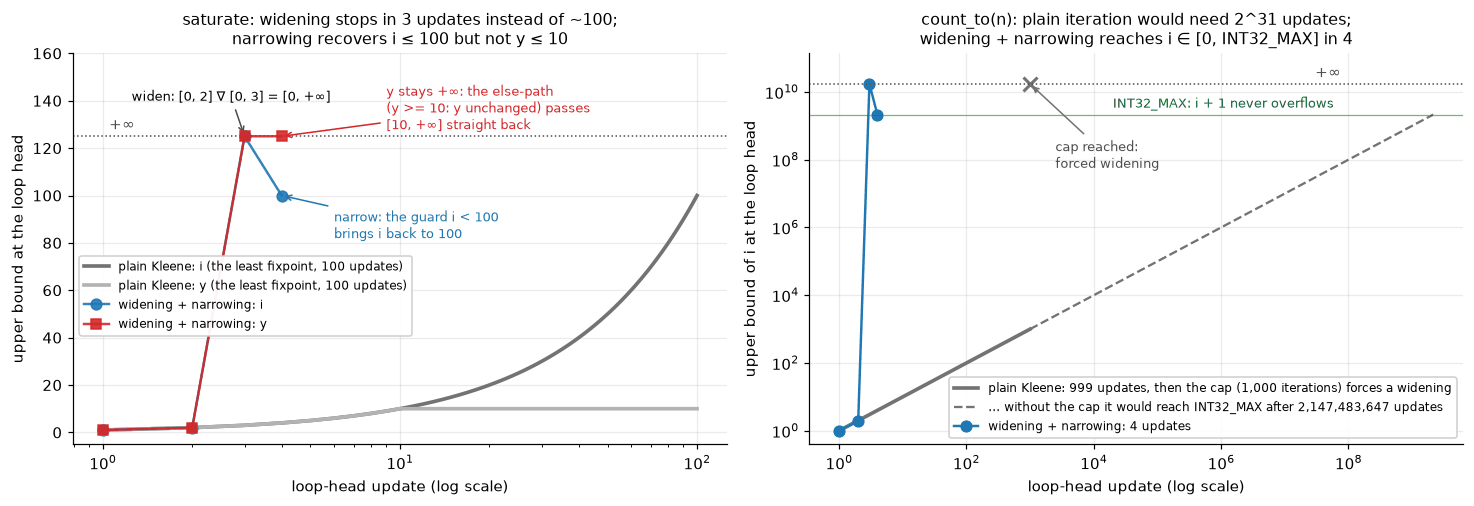

registered prediction: on saturate, widening + 2 narrowing steps recovers plain iteration's result | measured: plain i ∈ [0, 100], y ∈ [0, 10]; widening + narrowing i ∈ [0, 100], y ∈ [0, +inf] | verdict: WRONG -- narrowing only re-derives bounds that every path re-imposes
Every row ends at a post-fixpoint, so every row is sound (§9.1); the strategies differ only in how much
they over-approximate, and none of them proves count100's j + 1.


In [112]:
# 9.3 Plain Kleene iteration vs widening vs widening + narrowing vs widening with thresholds, on three loops.
_s9_RAMP = sorted({s * 2 ** k for s in (1, -1) for k in range(32)})   # thresholds ±2^k: a geometric ramp


def _s9_widen_thresholds(A, B, T):
    '''A ∇_T B for a finite sorted threshold set T: a bound that moves outward goes to the next threshold
    beyond B's bound, and to ±inf only past the last one. Finite T: still a widening (it stops).'''
    lo = A.lo if A.lo is not None and B.lo is not None and B.lo >= A.lo else \
        max((t for t in T if B.lo is not None and t <= B.lo), default=None)
    hi = A.hi if A.hi is not None and B.hi is not None and B.hi <= A.hi else \
        min((t for t in T if B.hi is not None and t >= B.hi), default=None)
    return Interval(lo, hi)


class _s9_ThresholdDomain(_s9_IntervalDomain):
    '''The interval domain with widening up to thresholds; every other operation is unchanged.'''
    def __init__(self, T, name):
        self.T, self.name = sorted(T), name

    def widen(self, a, b):
        return {x: _s9_widen_thresholds(a[x], b[x], self.T) for x in a if x in b}


def _s9_constants(src):
    '''The integer literals of a MiniPy function.'''
    return {n.value for n in ast.walk(parse_minipy(src)) if isinstance(n, ast.Constant) and isinstance(n.value, int)}


def _s9_widening_demo():
    '''Analyze the loops under each strategy; print the loop-head invariants; plot the iteration sequences.'''
    runs, rows = {}, []
    for prog, src in (("saturate", _s9_SATURATE_SRC), ("count_to", _s9_COUNTN_SRC), ("count100", _s9_COUNT100_SRC)):
        consts = sorted(_s9_constants(src))
        strategies = [("plain Kleene", _s9_IntervalDomain(), False, 2), ("widening", _s9_IntervalDomain(), True, 0),
                      ("widening + narrowing", _s9_IntervalDomain(), True, 2),
                      ("thresholds ±2^k + narrowing", _s9_ThresholdDomain(_s9_RAMP, 'ramp'), True, 2),
                      (f"thresholds {consts} + narrowing", _s9_ThresholdDomain(consts, 'consts'), True, 2)]
        for label, dom, wid, nar in strategies:
            points, meta = _s9_analyze(src, dom, wid, nar)
            (line, lp), = meta['loops'].items()
            runs[prog, label] = lp['history']
            head = points[('loop_head', line)]
            alarms = [what for key, d in points.items() if key[0] == 'alarm' for what in d]
            steps = Counter(how for how, _ in lp['history'][1:])
            rows.append([prog, label, steps['plain'], steps['widen'] + steps['forced widening'], steps['narrow'],
                         f"yes, at iteration {_s9_MAX_ITERS:,}" if meta['forced'] else "no",
                         "  ".join(f"{v} ∈ {head[v]}" for v in ('i', 'y', 'j') if v in head),
                         ", ".join(alarms) or "-", "yes" if lp['postfix'] else "NO"])
    show_table(["loop", "strategy", "joins", "widenings", "narrowings", "forced by the cap", "loop-head invariant",
                "alarms", "post-fixpoint"], rows)

    INF = 125                                  # where +inf is drawn on the linear axis
    ub = lambda s, v: INF if s[v].hi is None else s[v].hi
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))
    ax = axes[0]
    plain = runs["saturate", "plain Kleene"]
    for v, col in (('i', "0.45"), ('y', "0.7")):
        ax.plot(range(1, len(plain)), [ub(s, v) for _, s in plain[1:]], color=col, lw=2.4,
                label=f"plain Kleene: {v} (the least fixpoint, {len(plain) - 1} updates)")
    wn = runs["saturate", "widening + narrowing"]
    for v, col, mk in (('i', "#1f77b4", "o"), ('y', "#d62728", "s")):
        ax.plot(range(1, len(wn)), [ub(s, v) for _, s in wn[1:]], marker=mk, ms=7, color=col, lw=1.6,
                label=f"widening + narrowing: {v}", zorder=4, alpha=0.9)
    ax.axhline(INF, color="0.3", ls=":", lw=1)
    ax.text(1.05, INF + 3, "+∞", fontsize=10, color="0.3")
    steps = [how for how, _ in wn]
    k_w, k_n = steps.index('widen'), steps.index('narrow')
    ax.annotate("widen: [0, 2] ∇ [0, 3] = [0, +∞]", (k_w, INF), xytext=(1.25, 140), fontsize=8.5,
                arrowprops=dict(arrowstyle="->", color="0.3"))
    ax.annotate("narrow: the guard i < 100\nbrings i back to 100", (k_n, 100), xytext=(6, 82), fontsize=8.5,
                color="#1f77b4", arrowprops=dict(arrowstyle="->", color="#1f77b4"))
    ax.annotate("y stays +∞: the else-path\n(y >= 10: y unchanged) passes\n[10, +∞] straight back", (k_n, INF),
                xytext=(9, 128), fontsize=8.5, color="#d62728", arrowprops=dict(arrowstyle="->", color="#d62728"))
    ax.set_xscale("log")
    ax.set_ylim(-5, 160)
    ax.set_xlabel("loop-head update (log scale)")
    ax.set_ylabel("upper bound at the loop head")
    ax.set_title("saturate: widening stops in 3 updates instead of ~100;\n"
                 "narrowing recovers i ≤ 100 but not y ≤ 10", fontsize=10.5)
    ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(0.0, 0.38), framealpha=0.95)

    ax = axes[1]
    TOP = 2.0 ** 34                            # where +inf is drawn on the log axis
    ubl = lambda s: TOP if s['i'].hi is None else max(s['i'].hi, 0.5)
    plain = [s for how, s in runs["count_to", "plain Kleene"] if how == 'plain']
    cap = len(plain)
    ax.plot(np.arange(1, cap + 1), [ubl(s) for s in plain], color="0.45", lw=2.4,
            label=f"plain Kleene: {cap:,} updates, then the cap ({_s9_MAX_ITERS:,} iterations) forces a widening")
    ax.plot([cap, INT32_MAX], [cap, INT32_MAX], color="0.45", lw=1.5, ls="--",
            label=f"... without the cap it would reach INT32_MAX after {INT32_MAX:,} updates")
    ax.plot([cap], [TOP], marker="x", ms=9, mew=2, color="0.45")
    ax.annotate("cap reached:\nforced widening", (cap, TOP), xytext=(cap * 2.5, TOP / 300), fontsize=8.5,
                color="0.3", arrowprops=dict(arrowstyle="->", color="0.45"))
    wn = runs["count_to", "widening + narrowing"]
    ax.plot(range(1, len(wn)), [ubl(s) for _, s in wn[1:]], marker="o", ms=7, color="#1f77b4", lw=1.6,
            label=f"widening + narrowing: {len(wn) - 1} updates")
    ax.axhline(TOP, color="0.3", ls=":", lw=1)
    ax.axhline(INT32_MAX, color="#2ca02c", lw=0.8, alpha=0.7)
    ax.text(3e7, TOP * 1.6, "+∞", fontsize=10, color="0.3")
    ax.text(2e4, INT32_MAX * 1.6, "INT32_MAX: i + 1 never overflows", fontsize=8.5, color="#1a6b1a")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylim(0.4, TOP * 8)
    ax.set_xlabel("loop-head update (log scale)")
    ax.set_ylabel("upper bound of i at the loop head")
    ax.set_title("count_to(n): plain iteration would need 2^31 updates;\n"
                 f"widening + narrowing reaches i ∈ [0, INT32_MAX] in {len(wn) - 1}", fontsize=10.5)
    ax.legend(fontsize=8, loc="lower right", framealpha=0.95)
    plt.tight_layout()
    plt.show()

    lfp, got = runs["saturate", "plain Kleene"][-1][1], runs["saturate", "widening + narrowing"][-1][1]
    ok = all(got[v] == lfp[v] for v in ('i', 'y'))
    print(f"registered prediction: on saturate, widening + 2 narrowing steps recovers plain iteration's result | "
          f"measured: plain i ∈ {lfp['i']}, y ∈ {lfp['y']}; widening + narrowing i ∈ {got['i']}, y ∈ {got['y']} | "
          f"verdict: {'RIGHT' if ok else 'WRONG'} -- narrowing only re-derives bounds that every path re-imposes")
    print("Every row ends at a post-fixpoint, so every row is sound (§9.1); the strategies differ only in how much")
    print("they over-approximate, and none of them proves count100's j + 1.")


_s9_widening_demo()

The registered prediction is wrong, and the mechanism is visible in the iteration plot. Narrowing re-applies the
loop body to the widened head and keeps what comes back. For `i`, every path through the body passes the guard
`i < 100`, so the bound returns. For `y`, the path that skips `y = y + 1` (when `y >= 10`) hands back whatever
it was given, `[10, +∞]`, so nothing pulls the bound down. Plain iteration found `y <= 10` because it climbed from
below and stopped at the first post-fixpoint; widening jumped over it.

Astrée's remedy is **widening with thresholds** (Blanchet et al., PLDI 2003, Sect. 7.1.2 of the paper): a bound
that moves goes to the next value of a finite set $T$ instead of straight to $\pm\infty$, and it stops as soon as
it reaches a value the loop re-establishes. Astrée's $T$ is a geometric ramp, $\pm\alpha\lambda^k$. The last two
rows of each loop show both kinds of $T$. A ramp of powers of two leaves `saturate` with the finite but loose
`y ∈ [0, 16]` and `i ∈ [0, 128]`, because narrowing only refills infinite bounds. The program's own constants as
$T$ give the exact `y ∈ [0, 10]`. A threshold costs nothing in soundness, since every row still passes the
post-fixpoint check.

`count100` shows a different limit, one that no iteration strategy fixes. Even plain iteration never stabilizes
`j`: inside the loop the guard bounds `i`, not `j`, so `j + 1` reaches 101, then 102, until the cap. Thresholds
do not help either: `j` is widened to 100, then past it, because `j + 1 = 101` is again more than the bound just
reached. The fact `j <= 100` is true, expressible as an interval, and still not **inductive** in the interval
domain — inductive only together with `j == i`, which intervals cannot state. The result is a false alarm on
`j + 1`, the same shape as §6.3's x, y loop, whose invariant `x >= y` was true but not inductive.

### 9.4 The running example under intervals

Now §1's bugs. The analyzer reads `ABS_SRC`, `MIDPOINT_BUGGY_SRC` and `MIDPOINT_FIXED_SRC` from §2. To say which
of its alarms are real, every check is also decided exactly by Z3 — integers, int32 inputs, the `requires`
assumed, an execution that fails a check stopping there — so each alarm can be labelled **true** (Z3 finds an
input, which `run_minipy` replays) or **false** (no input exists). The oracle is symbolic execution of loop-free
code: each `if` forks the rest of the function into two paths, and `and`, `or` and `x if c else y` only count
checks that actually run. An oracle that labels alarms must be right itself, so the cell first tests it against
exhaustive execution, on programs whose `requires` pins both inputs to $[-6, 6]$, so that all 169 inputs can be
run: four hand-written ones, one for each way such an executor can lose track of which runs reach a check, and
60 random loop-free ones.

In [113]:
# 9.4 (a) An exact oracle for loop-free MiniPy (Z3 over Int), checked against exhaustive execution.
_s9_Z3_TIMEOUT_MS = 5000      # per Z3 query; a timeout is 'unknown', never 'proved'
_s9_ORACLE_SEED = 94          # random loop-free programs of the oracle's self-test
_s9_ORACLE_PROGRAMS = 60
_s9_ORACLE_BOX = 6            # their requires pin a and b to [-6, 6]: 169 inputs, all executed
_s9_BOX_REQ = "".join(f"    requires(-{_s9_ORACLE_BOX} <= {v} and {v} <= {_s9_ORACLE_BOX})\n" for v in "ab")
_s9_ORACLE_SHAPES = [         # hand-written shapes, one per way a symbolic executor can lose track of runs
    # an assignment inside an if that does not return, read after the if
    "def s1(a, b):\n" + _s9_BOX_REQ + "    y = 0\n    if a > 3:\n        y = 2147483647\n    return y + a\n",
    # the same, feeding an ensures
    "def s2(a, b):\n" + _s9_BOX_REQ + "    ensures(result >= 0)\n    y = a\n    if a < 0:\n        y = 0 - a\n"
    "    return y\n",
    # a check in the right operand of `and`: it runs only where the left operand holds
    "def s3(a, b):\n" + _s9_BOX_REQ + "    if a > 1 and a * 1073741824 > 0:\n        return 0\n"
    "    return a * 1073741824\n",
    # a check inside one arm of a conditional expression
    "def s4(a, b):\n" + _s9_BOX_REQ + "    y = a * 1073741824 if a > 1 else 1\n    return y + 1073741824\n"]


def _s9_straightline(src, real=False, round_shr=False):
    '''Decide every check of a loop-free MiniPy function with Z3 under int+ovf: int32 inputs, requires assumed,
    an execution that fails a check stops there. Each `if` forks the rest of the function into two paths, and
    `and` / `or` / `x if c else y` evaluate lazily, so each check is decided over exactly the executions that
    reach it. Over Int this is the exact semantics: the oracle that labels alarms true or false.
    Over Real, `e >> k` becomes a fresh t with 2^k t <= e <= 2^k t + 2^k - 1, so the constraints are the
    program's rational polyhedron on each path: what the polyhedra domain holds when no join is needed (as in
    the midpoints). round_shr=True (Real only) adds one integer step: each such t gets its rational bounds,
    from Z3's optimizer, rounded inward to integers. Returns {(line, check text): (status, model)}, status
    'proved' | 'counterexample' | 'unknown', model a dict param -> value for a counterexample. Check texts match
    the analyzer's alarm texts.'''
    fn = parse_minipy(src, 'int+ovf')
    info = minipy_info(fn)
    mk = z3.Real if real else z3.Int
    params = {p: mk(p) for p in info['params']}
    facts = [z3.And(INT32_MIN <= v, v <= INT32_MAX) for v in params.values()]
    fresh, results = itertools.count(), {}
    rank = {'proved': 0, 'unknown': 1, 'counterexample': 2}          # over all paths: one bad path decides

    def decide(line, text, path, bad):
        s = z3.Solver()
        s.set('timeout', _s9_Z3_TIMEOUT_MS)
        s.add(*facts, *path, bad)
        r, model = s.check(), None
        if r == z3.sat:
            m = s.model()
            model = {p: (m.eval(v, model_completion=True).as_fraction() if real else
                         m.eval(v, model_completion=True).as_long()) for p, v in params.items()}
        status = 'counterexample' if r == z3.sat else 'proved' if r == z3.unsat else 'unknown'
        old = results.get((line, text), ('proved', None))
        results[(line, text)] = max(old, (status, model), key=lambda sm: rank[sm[0]])

    def merge(path, arms):
        '''After lazily evaluated parts [(condition, its path)]: the checks each part passed (the facts appended
        to its path) hold wherever its condition held. Executions where it did not run are left alone.'''
        n = len(path) + 1
        for c, sub in arms:
            if sub[n:]:
                path.append(z3.Implies(c, z3.And(*sub[n:])))

    def round_bounds(t, path):
        '''The integer step: t is an integer, so its rational lower bound rounds up and its upper bound down.'''
        here = z3.And(*path) if path else z3.BoolVal(True)
        for goal in ('min', 'max'):
            opt = z3.Optimize()
            opt.set('timeout', _s9_Z3_TIMEOUT_MS)
            opt.add(*facts, *path)
            h = opt.minimize(t) if goal == 'min' else opt.maximize(t)
            if opt.check() == z3.sat and z3.is_rational_value(h.value()):     # unbounded / unknown: no step
                v = h.value().as_fraction()
                facts.append(z3.Implies(here, t >= math.ceil(v) if goal == 'min' else t <= math.floor(v)))

    def term(e, env, path, prog):
        '''The Z3 term of e. A program + - * or unary minus first gets its int32 check decided (under the path so
        far), then the check is assumed: executions that would fail it have stopped.'''
        if isinstance(e, ast.Constant):
            return e.value
        if isinstance(e, ast.Name):
            return env[e.id]
        if isinstance(e, ast.IfExp):
            c = cond(e.test, env, path, prog)
            if isinstance(c, bool):                    # a constant test: only one arm ever runs
                return term(e.body if c else e.orelse, env, path, prog)
            pb, po = path + [c], path + [z3.Not(c)]
            b, o = term(e.body, env, pb, prog), term(e.orelse, env, po, prog)
            merge(path, [(c, pb), (z3.Not(c), po)])
            return z3.If(c, b, o)
        if isinstance(e, ast.BinOp) and isinstance(e.op, ast.RShift):
            a, k = term(e.left, env, path, prog), e.right.value
            if isinstance(a, int):
                return a >> k
            if not real:
                return a / 2 ** k                    # Z3 Int division by a positive constant is floor division
            t = mk(f"shr{next(fresh)}")
            facts.extend([2 ** k * t <= a, a <= 2 ** k * t + 2 ** k - 1])
            if round_shr:
                round_bounds(t, path)
            return t
        if isinstance(e, ast.UnaryOp):
            r = -term(e.operand, env, path, prog)
        else:
            a, b = term(e.left, env, path, prog), term(e.right, env, path, prog)
            r = a + b if isinstance(e.op, ast.Add) else a - b if isinstance(e.op, ast.Sub) else a * b
        if prog:
            decide(e.lineno, ast.unparse(e), path, z3.Or(r < INT32_MIN, r > INT32_MAX))
            path.append(z3.And(INT32_MIN <= r, r <= INT32_MAX))
        return r

    def cond(c, env, path, prog):
        if isinstance(c, ast.BoolOp):                  # the right operand runs only where the left one decides
            a = cond(c.values[0], env, path, prog)     # nothing: a true (and) or a false (or)
            go_on = a if isinstance(c.op, ast.And) else z3.Not(a)
            sub = path + [go_on]
            b = cond(c.values[1], env, sub, prog)
            merge(path, [(go_on, sub)])
            return z3.And(a, b) if isinstance(c.op, ast.And) else z3.Or(a, b)
        if isinstance(c, ast.UnaryOp):
            return z3.Not(cond(c.operand, env, path, prog))
        a, b = term(c.left, env, path, prog), term(c.comparators[0], env, path, prog)
        return _s9_COMPARE[type(c.ops[0])](a, b)

    def run(stmts, env, path):
        for k, st in enumerate(stmts):
            if isinstance(st, ast.Assign):
                env = dict(env, **{st.targets[0].id: term(st.value, env, path, True)})
            elif isinstance(st, ast.If):               # fork: each arm continues with the rest of the function
                c = cond(st.test, env, path, True)
                run(st.body + stmts[k + 1:], env, path + [c])
                run(st.orelse + stmts[k + 1:], env, path + [z3.Not(c)])
                return
            elif isinstance(st, ast.Return):
                env = dict(env, result=term(st.value, env, path, True))
                for q in info['ensures']:
                    for part in _s9_conjuncts(q):
                        decide(part.lineno, f"ensures {ast.unparse(part)}", path, z3.Not(cond(part, env, [], False)))
                return
            elif isinstance(st, ast.Assert):           # spec code: no overflow checks inside; failing runs stop
                decide(st.lineno, f"assert {ast.unparse(st.test)}", path, z3.Not(cond(st.test, env, [], False)))
                path.append(cond(st.test, env, [], False))
            elif isinstance(st, ast.Expr) and st.value.func.id == 'assume':
                path.append(cond(st.value.args[0], env, [], False))
            else:
                raise ValueError(f"_s9_straightline: loop-free code only (line {st.lineno})")

    path = [cond(r, params, [], False) for r in info['requires']]
    run(fn.body[len(info['requires']) + len(info['ensures']):], dict(params), path)
    return results


def _s9_check_oracle():
    '''The oracle against exhaustive execution, on the hand-written shapes and on random loop-free programs.
    Inputs are pinned to a box, so a check on line L has a Z3 counterexample iff some input in the box stops at L
    (a run stops at its first failing check), and each counterexample must replay to a failure on its own line.'''
    rnd = random.Random(_s9_ORACLE_SEED)
    box = range(-_s9_ORACLE_BOX, _s9_ORACLE_BOX + 1)
    programs = _s9_ORACLE_SHAPES + [_s9_random_program(rnd, idx, loop=False, box=_s9_ORACLE_BOX, ensures=True)
                                    for idx in range(_s9_ORACLE_PROGRAMS)]
    st = Counter()
    for src in programs:
        failing = Counter()                               # line (or 'ensures') -> number of inputs failing there
        for args in itertools.product(box, box):
            out, val = run_minipy(src, args, 'int+ovf')
            st[out] += 1
            if out in ('overflow', 'assert_fail', 'ensures_fail'):
                failing['ensures' if out == 'ensures_fail' else val] += 1
        exact = _s9_straightline(src)
        where = lambda key: 'ensures' if key[1].startswith('ensures') else key[0]
        unknown = {where(key) for key, (s, _) in exact.items() if s == 'unknown'}
        flagged = {where(key) for key, (s, _) in exact.items() if s == 'counterexample'}
        st['programs'] += 1
        st['checks'] += len(exact)
        st['unknown'] += len(unknown)
        st['failing places'] += len(failing)
        st['missed'] += len(set(failing) - flagged - unknown)           # Z3 'proved', yet an input fails there
        st['spurious'] += len(flagged - set(failing))                    # Z3 'counterexample', no input fails
        for key, (s, model) in exact.items():
            if s == 'counterexample':
                out, val = run_minipy(src, model, 'int+ovf')
                ok = out == 'ensures_fail' if where(key) == 'ensures' else (out != 'return' and val == key[0])
                st['replays'] += 1
                st['replay mismatch'] += not ok
    runs = st['return'] + st['overflow'] + st['assert_fail'] + st['ensures_fail'] + st['requires_false']
    print(f"Z3 oracle vs exhaustive execution: {len(_s9_ORACLE_SHAPES)} hand-written shapes and "
          f"{_s9_ORACLE_PROGRAMS} random loop-free programs, {st['checks']:,} checks, "
          f"{runs:,} runs (return {st['return']:,}, overflow {st['overflow']:,}, assert_fail {st['assert_fail']:,}, "
          f"ensures_fail {st['ensures_fail']:,}, requires_false {st['requires_false']:,})")
    print(f"  places where some input fails: {st['failing places']} | proved but failing: {st['missed']} | "
          f"counterexample but no failing input: {st['spurious']} | replays not failing on their line: "
          f"{st['replay mismatch']} of {st['replays']} | unknown: {st['unknown']}")
    return st


if HAVE_Z3:
    _s9_oracle_stats = _s9_check_oracle()
    print("On loop-free code the oracle agrees with running every input, in both directions: its 'proved' and its"
          if _s9_oracle_stats['missed'] + _s9_oracle_stats['spurious'] + _s9_oracle_stats['replay mismatch'] == 0
          else "The oracle DISAGREES with exhaustive execution (counts above): its labels below are not exact,")
    print("counterexamples can be used to grade the analyzer's alarms.")
else:
    print("Z3 not installed (pip install z3-solver): the oracle and its self-test are skipped.")

Z3 oracle vs exhaustive execution: 4 hand-written shapes and 60 random loop-free programs, 548 checks, 10,816 runs (return 4,269, overflow 622, assert_fail 847, ensures_fail 2,818, requires_false 2,260)
  places where some input fails: 54 | proved but failing: 0 | counterexample but no failing input: 0 | replays not failing on their line: 0 of 54 | unknown: 0
On loop-free code the oracle agrees with running every input, in both directions: its 'proved' and its
counterexamples can be used to grade the analyzer's alarms.


For `midpoint_fixed`, `requires(0 <= lo)` and `requires(lo <= hi)` hold at entry, and the fix exists precisely
so that `hi - lo` cannot be negative and `lo + ((hi - lo) >> 1)` stays between `lo` and `hi`.

**Registered prediction:** intervals prove `midpoint_fixed` overflow-free.

function        line  check                 interval analysis          verdict      exact (Z3, int32 inputs)    replay (run_minipy, int+ovf)
--------------------------------------------------------------------------------------------------------------------------------------------
abs32           2     ensures result >= 0   holds                      proved       proved                      -                           
abs32           4     -x                    [1, 2147483648]            TRUE alarm   input: x=-2147483648        ('overflow', 4)             
midpoint_buggy  4     ensures lo <= result  may be false               FALSE alarm  proved                      -                           
midpoint_buggy  4     ensures result <= hi  may be false               FALSE alarm  proved                      -                           
midpoint_buggy  5     lo + hi               [0, 4294967294]            TRUE alarm   input: lo=1, hi=2147483647  ('overflow', 5)             
midpoint_fixe

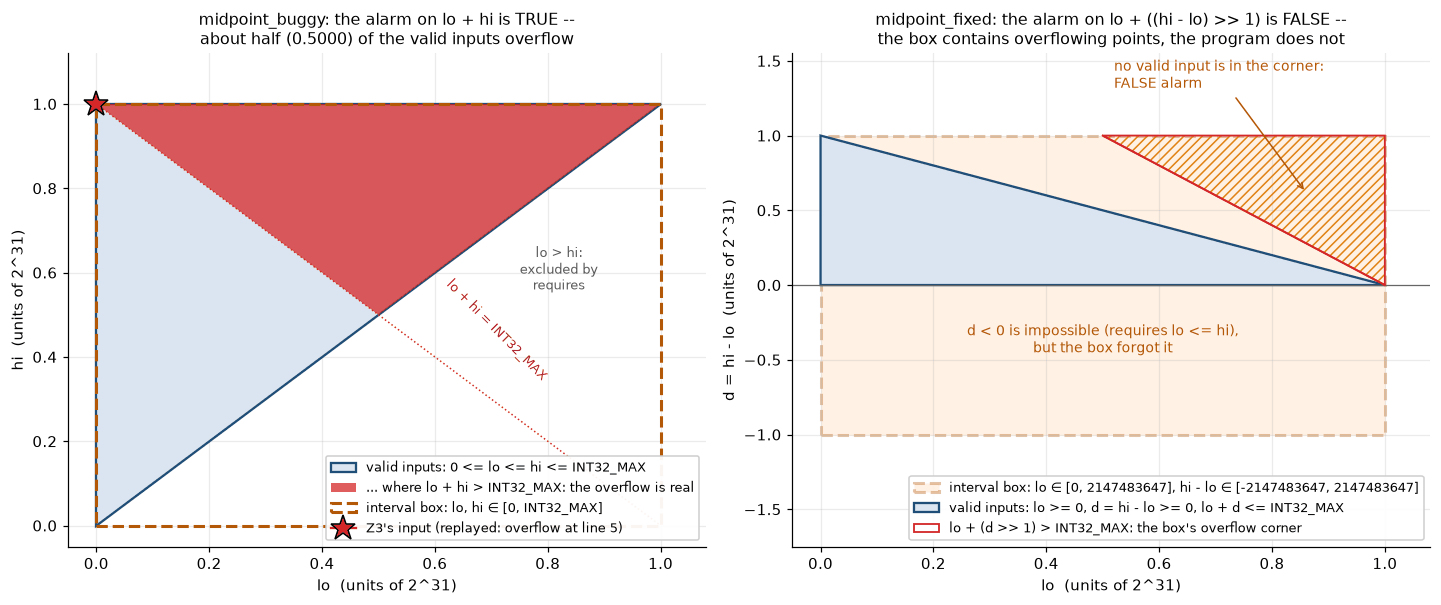

registered prediction: intervals prove midpoint_fixed overflow-free | measured: alarm on line 5, lo + (hi - lo >> 1) ∈ [-1073741824, 3221225470]; Z3 on the same check: proved | verdict: WRONG -- lo occurs twice and intervals treat the two occurrences as independent


In [114]:
# 9.4 (b) Alarms on the running example, each classified by the oracle and replayed.
_s9_RUNNING = [("abs32", ABS_SRC), ("midpoint_buggy", MIDPOINT_BUGGY_SRC), ("midpoint_fixed", MIDPOINT_FIXED_SRC)]


def _s9_overflow_share(M):
    '''(count, total): the pairs 0 <= lo <= hi <= M, and those with lo + hi > M. For lo <= s = (M + 1) // 2 the
    overflowing hi run from M + 1 - lo to M (lo of them), above s from lo to M (M - lo + 1): two arithmetic
    series. Checked against direct counting for small M.'''
    closed = lambda m: ((m + 1) // 2 * ((m + 1) // 2 + 1) // 2 + (m - (m + 1) // 2) * (m - (m + 1) // 2 + 1) // 2,
                        (m + 1) * (m + 2) // 2)
    for m in range(1, 40):
        brute = sum(1 for lo in range(m + 1) for hi in range(lo, m + 1) if lo + hi > m)
        if closed(m)[0] != brute:
            raise AssertionError(f"_s9_overflow_share: closed form wrong at M = {m}")
    return closed(M)


def _s9_running_example():
    '''Every check of the three running examples: interval verdict vs the exact (Z3) verdict, with replays.'''
    if not HAVE_Z3:
        print("Z3 not installed: the alarms below cannot be classified (pip install z3-solver)")
    rows, witness = [], {}
    for name, src in _s9_RUNNING:
        pts = interval_analyze(src)
        alarms = {(key[1], what): iv for key, d in pts.items() if key[0] == 'alarm' for what, iv in d.items()}
        exact = _s9_straightline(src) if HAVE_Z3 else {k: ('unknown', None) for k in alarms}
        for (line, what), (status, model) in sorted(exact.items()):
            replay = "-"
            if status == 'counterexample':
                replay = str(run_minipy(src, model, 'int+ovf'))       # every counterexample is replayed first
                witness[name] = model
            if (line, what) in alarms:
                label = {'counterexample': 'TRUE alarm', 'proved': 'FALSE alarm'}.get(status, 'unclassified')
                interval = str(alarms[line, what]) if not what.startswith('ensures') else "may be false"
            else:
                label, interval = "proved", "within int32" if not what.startswith('ensures') else "holds"
            rows.append([name, line, what, interval, label, status if status != 'counterexample' else
                         "input: " + ", ".join(f"{p}={v}" for p, v in model.items()), replay])
    show_table(["function", "line", "check", "interval analysis", "verdict", "exact (Z3, int32 inputs)",
                "replay (run_minipy, int+ovf)"], rows)
    w = witness.get("midpoint_buggy")
    if w:
        print(f"the same midpoint_buggy input under 32-bit wrap-around (bv32, §2.3): "
              f"{run_minipy(MIDPOINT_BUGGY_SRC, w, 'bv32')}")

    # The prediction's check, located from the source alone (not from the alarms being scored).
    pts = interval_analyze(MIDPOINT_FIXED_SRC)
    ret_st = next(s for s in parse_minipy(MIDPOINT_FIXED_SRC, 'int+ovf').body if isinstance(s, ast.Return))
    fline, ftext = ret_st.lineno, ast.unparse(ret_st.value)
    falarm = pts.get(('alarm', fline), {}).get(ftext)                 # None: no alarm, i.e. proved
    ret = next(s for key, s in pts.items() if key[0] == 'return')
    d_iv = ret['hi'] - ret['lo']
    print(f"\nmidpoint_fixed under intervals: lo ∈ {ret['lo']}, hi ∈ {ret['hi']}, so hi - lo ∈ {d_iv} (the box forgot "
          f"lo <= hi), (hi - lo) >> 1 ∈ {d_iv.shr(1)}, and {ftext} ∈ {ret['lo'] + d_iv.shr(1)}")
    n_ovf, n_all = _s9_overflow_share(INT32_MAX)
    print(f"midpoint_buggy: {n_ovf:,} of the {n_all:,} valid (lo, hi) pairs overflow, a share of {n_ovf / n_all:.10f}")

    U = 2.0 ** 31                          # plot in units of 2^31: INT32_MAX ~ 1
    M = INT32_MAX / U
    fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.6))
    ax = axes[0]
    ax.add_patch(Polygon([(0, 0), (0, M), (M, M)], fc="#dbe5f1", ec="#1f4e79", lw=1.5, zorder=2,
                         label="valid inputs: 0 <= lo <= hi <= INT32_MAX"))
    ax.add_patch(Polygon([(0, M), (M / 2, M / 2), (M, M)], fc="#d62728", alpha=0.75, ec="none", zorder=3,
                         label="... where lo + hi > INT32_MAX: the overflow is real"))
    ax.add_patch(Rectangle((0, 0), M, M, fc="none", ec="#b35806", lw=2, ls="--", zorder=4,
                           label="interval box: lo, hi ∈ [0, INT32_MAX]"))
    ax.plot([0, M], [M, 0], color="#d62728", lw=1, ls=":", zorder=3)
    if w:
        ax.plot(w['lo'] / U, w['hi'] / U, marker="*", ms=17, color="#d62728", mec="black", zorder=6,
                label=f"Z3's input (replayed: overflow at line 5)")
    ax.text(0.71, 0.345, "lo + hi = INT32_MAX", rotation=-45, fontsize=8.5, color="#b2182b", ha="center")
    ax.text(0.82, 0.56, "lo > hi:\nexcluded by\nrequires", fontsize=8.5, color="0.35", ha="center")
    ax.set_xlim(-0.05, 1.08)
    ax.set_ylim(-0.05, 1.12)
    ax.set_xlabel("lo  (units of 2^31)")
    ax.set_ylabel("hi  (units of 2^31)")
    ax.set_title(f"midpoint_buggy: the alarm on lo + hi is TRUE --\nabout half ({n_ovf / n_all:.4f}) of the "
                 "valid inputs overflow", fontsize=10.5)
    ax.legend(fontsize=8.2, loc="lower right", framealpha=0.95)

    ax = axes[1]
    lo_hi, d_lo, d_hi = (ret['lo'].hi or 0) / U, d_iv.lo / U, d_iv.hi / U
    ax.add_patch(Rectangle((0, d_lo), lo_hi, d_hi - d_lo, fc="#ffd9b3", alpha=0.35, ec="#b35806", lw=2, ls="--",
                           zorder=1, label=f"interval box: lo ∈ {ret['lo']}, hi - lo ∈ {d_iv}"))
    ax.add_patch(Polygon([(0, 0), (M, 0), (0, M)], fc="#dbe5f1", ec="#1f4e79", lw=1.5, zorder=2,
                         label="valid inputs: lo >= 0, d = hi - lo >= 0, lo + d <= INT32_MAX"))
    corner = Polygon([(M / 2, M), (M, M), (M, 0)], fc="none", ec="#e08214", hatch="////", lw=0, zorder=3)
    ax.add_patch(corner)
    ax.add_patch(Polygon([(M / 2, M), (M, M), (M, 0)], fc="none", ec="#d62728", lw=1.2, zorder=3,
                         label="lo + (d >> 1) > INT32_MAX: the box's overflow corner"))
    ax.plot([M / 2, M], [M, 0], color="#d62728", lw=1.2, zorder=3)
    ax.axhline(0, color="0.4", lw=0.8)
    ax.annotate("no valid input is in the corner:\nFALSE alarm", (0.86, 0.62), xytext=(0.52, 1.32),
                fontsize=9, color="#b35806", arrowprops=dict(arrowstyle="->", color="#b35806"))
    ax.text(0.5, -0.45, "d < 0 is impossible (requires lo <= hi),\nbut the box forgot it", fontsize=9,
            color="#b35806", ha="center")
    ax.set_xlim(-0.05, 1.08)
    ax.set_ylim(-1.75, 1.55)
    ax.set_xlabel("lo  (units of 2^31)")
    ax.set_ylabel("d = hi - lo  (units of 2^31)")
    ax.set_title("midpoint_fixed: the alarm on lo + ((hi - lo) >> 1) is FALSE --\n"
                 "the box contains overflowing points, the program does not", fontsize=10.5)
    ax.legend(fontsize=8.2, loc="lower right", framealpha=0.95)
    plt.tight_layout()
    plt.show()

    proved = falarm is None
    measured = "no alarm" if proved else f"alarm on line {fline}, {ftext} ∈ {falarm}"
    exact = (_s9_straightline(MIDPOINT_FIXED_SRC).get((fline, ftext), ('unknown', None))[0] if HAVE_Z3 else
             'not run')
    print(f"registered prediction: intervals prove midpoint_fixed overflow-free | measured: {measured}; Z3 on the same "
          f"check: {exact} | verdict: {'RIGHT' if proved else 'WRONG'}"
          + ("" if proved else " -- lo occurs twice and intervals treat the two occurrences as independent"))


_s9_running_example()

The prediction is wrong. On the two midpoints' overflow checks the analysis raises one true alarm
(`midpoint_buggy`'s `lo + hi`) and one false alarm (`midpoint_fixed`'s `lo + ((hi - lo) >> 1)`), and the table
says why in two lines. `hi - lo` passes its check (its interval $[-2^{31}+1,\ 2^{31}-1]$ fits), but it has
already lost `lo <= hi`: the box allows $d = hi - lo < 0$, so its whole lower half is impossible. Then
`lo + (d >> 1)` adds two intervals as if `lo` and `d` were unrelated, and the box's top-right corner, where `lo`
is near `INT32_MAX` and so is `d`, overflows — a corner no valid input reaches, because there
$lo + d = hi \le$ `INT32_MAX`. This is the **dependency problem** of §9.2's `x - x`: an interval domain keeps one
range per variable, so it cannot know that the `lo` added at the end is the `lo` subtracted inside. The two
`ensures` alarms on each midpoint have the same cause — `lo <= result` relates two variables — and so does
`count100`'s alarm on `j + 1`. (`ast.unparse` prints the fixed midpoint as `lo + (hi - lo >> 1)`;
`>>` binds more loosely than `-`, so it is the same expression.)

The `ensures` alarms of `midpoint_buggy` are false only under int+ovf, which the table uses: there every
execution with $lo + hi > $ `INT32_MAX` stops at the overflow on line 5 and never reaches the `ensures`, and the
others satisfy it. Under 32-bit wrap-around the same input runs on and violates the `ensures`, as the line under
the table shows; that is the bug as Java programmers met it (§2.3, §4.2). In C the same overflow is undefined
behaviour (§1), so what a C program does next is up to the compiler.

### 9.5 Relational domains: octagons and polyhedra

An **octagon** (Miné, HOSC 2006) is a conjunction of constraints $\pm x \pm y \le c$; unary bounds are the case
$y = x$ of $x + y \le c$, i.e. $2x \le c$. Store them in a **difference-bound matrix** over $2n$ signed copies
$+v_k, -v_k$: $m_{ij} = c$ means $V_i - V_j \le c$, so $x + y \le c$ is $(+x) - (-y) \le c$ and $x \le c$ is
$(+x) - (-x) \le 2c$. Implied constraints are shortest paths — $x - y \le a$ and $y - z \le b$ give
$x - z \le a + b$ — so **closure** is Floyd–Warshall on $2n$ nodes, plus a strengthening step ($x \le a$ and
$-y \le b$ give $x - y \le a + b$) and, over the integers, rounding the unary bounds $2x \le c$ to even $c$.
That is $O(n^3)$ time and $O(n^2)$ memory per operation, the costs Miné reports.

`midpoint_fixed` computes `d = hi - lo`, then `t = d >> 1`, then `lo + t`. The relation between `d` and `t`,
$2t \le d \le 2t + 1$, has a coefficient 2, and no octagon can state it.

**Registered prediction:** octagons cannot prove `midpoint_fixed` overflow-free: the relation between `hi - lo`
and `(hi - lo) >> 1` needs the coefficient 2.

The first cell builds the matrix and its closure, and checks the closure against brute force: on random integer
octagons inside a small box, every entry must be the tightest bound true of the integer points.

In [115]:
# 9.5 (a) Octagons as difference-bound matrices, and tight closure checked against brute force.
_s9_OCT_TEST_SEED = 95    # random octagons of the closure test
_s9_OCT_TESTS = 1500      # integer octagons over 3 variables
_s9_OCT_BOX = 4           # every variable in [-4, 4]: 729 integer points to enumerate


class _s9_Oct:
    '''An octagon over `vars`: m is a 2n x 2n float matrix over the signed copies V_2k = +v_k, V_2k+1 = -v_k,
    with m[i, j] = c meaning V_i - V_j <= c (np.inf: no constraint). closed: m is known to be tightly closed.'''
    __slots__ = ('vars', 'm', 'closed')

    def __init__(self, vars, m, closed=False):
        self.vars, self.m, self.closed = tuple(vars), m, closed


def _s9_oct_close(o):
    '''Tight closure: Floyd-Warshall shortest paths; round each unary bound 2x <= c down to an even c (x is an
    integer); strengthen V_i - V_j <= (bound of 2 V_i + bound of -2 V_j) / 2. Returns None if o is empty.'''
    if o is None or o.closed:
        return o
    m = o.m.copy()
    for k in range(len(m)):
        m = np.minimum(m, m[:, [k]] + m[[k], :])
    idx = np.arange(len(m))
    bar = idx ^ 1                                    # the index of the other sign of the same variable
    un = m[idx, bar]                                 # m[i, bar i] bounds V_i - (-V_i) = 2 V_i
    un = np.where(np.isinf(un), un, 2 * np.floor(un / 2))
    if (m[idx, idx] < 0).any() or (un + un[bar] < 0).any():
        return None
    m[idx, bar] = un
    m = np.minimum(m, np.floor((un[:, None] + un[bar][None, :]) / 2))
    if (m[idx, idx] < 0).any():
        return None
    m[idx, idx] = 0
    return _s9_Oct(o.vars, m, True)


def _s9_check_closure():
    '''Tight closure against brute force: random integer octagons over (x, y, z) inside a box, closed, then
    compared entry by entry with the largest V_i - V_j over the integer points they contain.'''
    g = np.random.default_rng(_s9_OCT_TEST_SEED)
    B = _s9_OCT_BOX
    P = np.array(list(itertools.product(range(-B, B + 1), repeat=3)))
    S = np.stack([P[:, 0], -P[:, 0], P[:, 1], -P[:, 1], P[:, 2], -P[:, 2]], axis=1)   # V_0 .. V_5 at each point
    D = S[:, :, None] - S[:, None, :]                       # D[p, i, j] = V_i - V_j at point p
    off = ~np.eye(6, dtype=bool)
    st = Counter()
    for _ in range(_s9_OCT_TESTS):
        m = np.full((6, 6), np.inf)
        np.fill_diagonal(m, 0)
        for k in range(3):                                   # the box: 2 v <= 2B and -2 v <= 2B
            m[2 * k, 2 * k + 1] = m[2 * k + 1, 2 * k] = 2 * B
        for _ in range(int(g.integers(1, 7))):               # random constraints V_i - V_j <= c (odd unary c too)
            i, j = (int(v) for v in g.choice(6, 2, replace=False))
            c = int(g.integers(-2 * B, 2 * B + 1))
            m[i, j] = min(m[i, j], c)
            m[j ^ 1, i ^ 1] = min(m[j ^ 1, i ^ 1], c)        # the same constraint, written with the other signs
        inside = (D <= m[None]).all(axis=(1, 2))
        o = _s9_oct_close(_s9_Oct(('x', 'y', 'z'), m))
        if not inside.any():
            st['empty'] += 1
            st['emptiness missed'] += o is not None
            continue
        if o is None:
            st['wrongly empty'] += 1
            continue
        best = D[inside].max(axis=0)
        st['entries'] += int(off.sum())
        st['unsound'] += int((o.m < best)[off].sum())
        st['not tight'] += int((o.m > best)[off].sum())
    print(f"tight closure vs brute force: {_s9_OCT_TESTS:,} random integer octagons over 3 variables in "
          f"[-{B}, {B}]^3 ({st['empty']} of them empty), {st['entries']:,} entries compared")
    print(f"  unsound entries: {st['unsound']} | not tight: {st['not tight']} | emptiness missed: "
          f"{st['emptiness missed']} | wrongly empty: {st['wrongly empty']}")
    return st


_s9_closure_stats = _s9_check_closure()
print("Closure writes, for every pair of signed variables, exactly the best bound the integer points allow:"
      if _s9_closure_stats['unsound'] + _s9_closure_stats['not tight'] == 0 else
      "Closure is NOT exact on these octagons (counts above):")
print("the octagon's own α∘γ, computed by shortest paths plus two integer steps.")

tight closure vs brute force: 1,500 random integer octagons over 3 variables in [-4, 4]^3 (481 of them empty), 30,570 entries compared
  unsound entries: 0 | not tight: 0 | emptiness missed: 0 | wrongly empty: 0
Closure writes, for every pair of signed variables, exactly the best bound the integer points allow:
the octagon's own α∘γ, computed by shortest paths plus two integer steps.


The second cell is the octagon as a lattice: reading a bound off the closed matrix, adding a constraint,
projecting variables away. Join is the entrywise maximum of two closed matrices; widening drops every entry that
grew and works on the unclosed left operand, as Miné prescribes so that it terminates.

In [116]:
# 9.5 (b) The octagon lattice: matrix plumbing, join / widening / narrowing / inclusion, and the facts it states.
def _s9_interval(lo, hi):
    '''Interval from float bounds (±inf -> None).'''
    return Interval.make(None if lo == -math.inf else int(lo), None if hi == math.inf else int(hi))


class _s9_OctLattice:
    '''Octagons over named variables (interface: see _s9_IntervalDomain), without the transfer functions of
    statements, which _s9_OctagonDomain adds. Temporaries (names starting with '%') name intermediate values
    inside one statement; they are projected away when the statement ends.'''
    name = 'octagon lattice'

    def __init__(self):
        self.fresh = itertools.count()

    # -- matrix plumbing --------------------------------------------------------------------------------------
    @staticmethod
    def node(o, v, sign):
        return 2 * o.vars.index(v) + (0 if sign > 0 else 1)

    def ub(self, o, coefs):
        '''Upper bound of sum(c * v) over the closed octagon o: one matrix entry when the form is octagonal, else
        the best split into one octagonal pair plus interval bounds for the remaining terms.'''
        coefs = {v: c for v, c in coefs.items() if c != 0}
        unary = lambda v: abs(coefs[v]) * o.m[self.node(o, v, coefs[v]), self.node(o, v, -coefs[v])] / 2
        best = sum(unary(v) for v in coefs)
        units = [v for v in coefs if abs(coefs[v]) == 1]
        for a, b in itertools.combinations(units, 2):
            pair = o.m[self.node(o, a, coefs[a]), self.node(o, b, -coefs[b])]
            best = min(best, pair + sum(unary(v) for v in coefs if v not in (a, b)))
        return best

    def bounds(self, o, f):
        '''(lo, hi) of the linear form f over the closed octagon o.'''
        return -self.ub(o, {v: -c for v, c in f[0].items()}) + f[1], self.ub(o, f[0]) + f[2]

    def interval(self, o, f):
        return _s9_interval(*self.bounds(_s9_oct_close(o), f))

    def put(self, o, m, coefs, c):
        '''Write the octagonal constraint sum(coef * v) <= c into the matrix m (both coherent entries).'''
        if c == math.inf:
            return
        (a, sa), *rest = coefs.items()
        if not rest:
            i = self.node(o, a, sa)
            m[i, i ^ 1] = min(m[i, i ^ 1], 2 * math.floor(c / abs(sa)))
        else:
            (b, sb), = rest
            i, j = self.node(o, a, sa), self.node(o, b, -sb)
            m[i, j] = min(m[i, j], c)
            m[j ^ 1, i ^ 1] = min(m[j ^ 1, i ^ 1], c)

    def constrain(self, o, coefs, c):
        '''o ∧ (sum(coef * v) <= c): exact when the form is octagonal, otherwise only an emptiness test.'''
        o = _s9_oct_close(o)
        if o is None:
            return None
        coefs = {v: k for v, k in coefs.items() if k != 0}
        if not coefs:
            return o if c >= 0 else None
        if len(coefs) == 1 or (len(coefs) == 2 and all(abs(k) == 1 for k in coefs.values())):
            m = o.m.copy()
            self.put(o, m, coefs, c)
            return _s9_oct_close(_s9_Oct(o.vars, m))
        return o if -self.ub(o, {v: -k for v, k in coefs.items()}) <= c else None

    def extend(self, o, names):
        new = [v for v in names if v not in o.vars]
        if not new:
            return o
        n2 = 2 * (len(o.vars) + len(new))
        m = np.full((n2, n2), math.inf)
        m[:len(o.m), :len(o.m)] = o.m
        np.fill_diagonal(m, 0)
        return _s9_Oct(o.vars + tuple(new), m, o.closed)

    def select(self, o, names, close=True):
        '''o restricted to `names` (in that order); exact for a closed octagon (close=False keeps o unclosed, as
        the left operand of a widening must be, and is then merely sound).'''
        o = _s9_oct_close(o) if close else o
        if o is None:
            return None
        idx = [self.node(o, v, s) for v in names for s in (1, -1)]
        return _s9_Oct(names, o.m[np.ix_(idx, idx)], o.closed)

    def forget(self, o, x):
        o = _s9_oct_close(o)
        i, m = self.node(o, x, 1), o.m.copy()
        m[i:i + 2, :] = math.inf
        m[:, i:i + 2] = math.inf
        m[i, i] = m[i + 1, i + 1] = 0
        return _s9_Oct(o.vars, m, True)

    def clean(self, o):
        return None if o is None else self.select(o, tuple(v for v in o.vars if not v.startswith('%')))

    def temp(self):
        return f"%{next(self.fresh)}"

    # -- lattice operations -----------------------------------------------------------------------------------
    def init(self, params, arrays=()):
        vs = tuple(p for p in params if p not in arrays)
        m = np.full((2 * len(vs), 2 * len(vs)), math.inf)
        np.fill_diagonal(m, 0)
        o = _s9_Oct(vs, m)
        for v in vs:
            self.put(o, m, {v: 1}, INT32_MAX)
            self.put(o, m, {v: -1}, -INT32_MIN)
        return _s9_oct_close(o)

    def _common(self, a, b):
        return tuple(v for v in a.vars if v in b.vars)

    def join(self, a, b):
        A, B = _s9_oct_close(a), _s9_oct_close(b)
        if A is None or B is None:
            return B if A is None else A
        names = self._common(A, B)
        A, B = self.select(A, names), self.select(B, names)
        return _s9_Oct(names, np.maximum(A.m, B.m), True)     # the join of closed octagons is closed

    def widen(self, a, b):
        names = self._common(a, b)
        A, B = self.select(a, names, close=False), self.select(b, names)
        return _s9_Oct(names, np.where(B.m <= A.m, A.m, math.inf))

    def narrow(self, a, b):
        names = self._common(a, b)
        A, B = self.select(a, names, close=False), self.select(b, names)
        return _s9_Oct(names, np.where(np.isinf(A.m), B.m, A.m))

    def leq(self, a, b):
        A = _s9_oct_close(a)
        if A is None:
            return True
        if any(v not in A.vars for v in b.vars):
            return False
        return bool((self.select(A, b.vars).m <= b.m).all())

    def top(self, o):
        m = np.full(o.m.shape, math.inf)
        np.fill_diagonal(m, 0)
        return _s9_Oct(o.vars, m, True)

    def intervals(self, o):
        o = _s9_oct_close(o)
        return {} if o is None else {v: self.interval(o, ({v: 1}, 0, 0)) for v in o.vars if not v.startswith('%')}

    def constraints(self, o):
        '''The facts of o as MiniPy conditions [(text, names)]: unary bounds, then the pair constraints that the
        unary bounds do not already imply.'''
        o = _s9_oct_close(o)
        if o is None:
            return [("0 == 1", set())]
        names = [v for v in o.vars if not v.startswith('%')]
        out, un = [], {}
        for v in names:
            for s in (1, -1):
                un[v, s] = o.m[self.node(o, v, s), self.node(o, v, -s)] / 2
                if un[v, s] < math.inf:
                    out.append((f"{'-' if s < 0 else ''}{v} <= {int(un[v, s])}", {v}))
        for a, b in itertools.combinations(names, 2):
            for sa, sb in itertools.product((1, -1), (1, -1)):
                c = o.m[self.node(o, a, sa), self.node(o, b, -sb)]
                if c < un[a, sa] + un[b, sb]:
                    out.append((f"{'-' if sa < 0 else ''}{a} {'+' if sb > 0 else '-'} {b} <= {int(c)}", {a, b}))
        return out


def _s9_lattice_demo():
    '''Closure deriving a bound, and a join that keeps a relation intervals would lose.'''
    L = _s9_OctLattice()
    o = L.constrain(L.constrain(L.init(('x', 'y')), {'x': 1, 'y': -1}, 0), {'y': 1}, 5)
    point = lambda vx, vy: functools.reduce(lambda acc, f: L.constrain(acc, *f), [({'x': 1}, vx), ({'x': -1}, -vx),
                                                                                    ({'y': 1}, vy), ({'y': -1}, -vy)],
                                            L.init(('x', 'y')))
    j = L.join(point(0, 0), point(3, 3))
    print(f"x - y <= 0 and y <= 5, closed: {[t for t, _ in L.constraints(o) if 'x' in t and '2147483648' not in t]}")
    print(f"join of the points (0, 0) and (3, 3): {[t for t, _ in L.constraints(j)]}")
    print("Closure derived x <= 5; the join kept x - y = 0 (as x - y <= 0 and -x + y <= 0), where intervals would")
    print("keep only x, y ∈ [0, 3].")


_s9_lattice_demo()

x - y <= 0 and y <= 5, closed: ['x <= 5', 'x - y <= 0']
join of the points (0, 0) and (3, 3): ['x <= 3', '-x <= 0', 'y <= 3', '-y <= 0', 'x - y <= 0', '-x + y <= 0']
Closure derived x <= 5; the join kept x - y = 0 (as x - y <= 0 and -x + y <= 0), where intervals would
keep only x, y ∈ [0, 3].


The third cell adds the transfer functions of statements, and with them the facts that decide `midpoint_fixed`:

- `x = e` with `e` linear: for every other variable $v$, bound $x \pm v$ by the bound of $e \pm v$ in the old
  state, letting terms cancel. After `d = hi - lo`, $d + lo$ is just $hi$, so the octagon learns
  $d + lo \le$ `INT32_MAX` — the fact intervals lost.
- `t = d >> 1`: the relation $2t \le d \le 2t + 1$ is not octagonal. Its octagonal hull, over the pair
  $(d, t)$, comes from the integer bounds $[a, b]$ of $d$, because $\lfloor d/2 \rfloor$,
  $\lfloor d/2 \rfloor - d$ and $\lfloor d/2 \rfloor + d$ are each monotone in $d$: evaluate each at $a$ and $b$.
  Relations between `t` and other variables then come from closure, and need not be the best ones.
- A guard adds its constraint when it is octagonal, and otherwise only tests emptiness. A product of two
  variables keeps only its interval.

The domain plugs into §9.2's engine unchanged, and §9.2's soundness harness runs on it unchanged.

In [117]:
# 9.5 (c) The octagon's transfer functions, and the soundness harness of §9.2 on the octagon analyzer.
def _s9_lin_add(f, g):
    '''Sum of two linear forms (coefs, lo, hi): coefs a dict var -> int, [lo, hi] a constant interval.'''
    coefs = dict(f[0])
    for v, c in g[0].items():
        coefs[v] = coefs.get(v, 0) + c
    return {v: c for v, c in coefs.items() if c != 0}, f[1] + g[1], f[2] + g[2]


def _s9_lin_scale(f, k):
    if k == 0:
        return {}, 0, 0
    lo, hi = (k * f[1], k * f[2]) if k > 0 else (k * f[2], k * f[1])
    return {v: k * c for v, c in f[0].items()}, lo, hi


class _s9_OctagonDomain(_s9_OctLattice):
    '''The octagon domain in the engine's interface (see _s9_IntervalDomain): the lattice plus the transfer
    functions of assignments, >>, program checks and guards.'''
    name = 'octagon'

    def assign(self, o, x, f):
        '''x = f (a linear form): the facts about the new x that the old state implies -- bounds on x and on x ± v
        for every other v, each the bound of f ± v in the old state -- then forget the old x and add them.'''
        o = _s9_oct_close(self.extend(o, [x]))
        if o is None:
            return None
        coefs, clo, chi = f
        facts = []
        for sx in (1, -1):
            base, const = {v: sx * c for v, c in coefs.items()}, (chi if sx > 0 else -clo)
            facts.append(({x: sx}, self.ub(o, base) + const))
            for v in o.vars:
                if v != x:
                    for sv in (1, -1):
                        g = dict(base)
                        g[v] = g.get(v, 0) + sv
                        facts.append(({x: sx, v: sv}, self.ub(o, g) + const))
        o = self.forget(o, x)
        m = o.m.copy()
        for g, c in facts:
            self.put(o, m, g, c)
        return _s9_oct_close(_s9_Oct(o.vars, m))

    def assign_shr(self, o, x, d, k):
        '''x = d >> k (x fresh, d a variable): the octagonal hull of the pair (d, x = floor(d / q)), q = 2^k, from
        the integer bounds [a, b] of d. floor(d/q) and floor(d/q) + d grow with d, floor(d/q) - d shrinks, so each
        ranges between its values at a and b. The relation itself, q x <= d <= q x + q - 1, is not octagonal.'''
        o = _s9_oct_close(self.extend(o, [x]))
        if o is None:
            return None
        q, a, b = 2 ** k, -float(self.ub(o, {d: -1})), float(self.ub(o, {d: 1}))   # Python floats: inf - inf is
                                                                                 # a silent nan, as fin() expects
        fa = math.floor(a / q) if a > -math.inf else -math.inf
        fb = math.floor(b / q) if b < math.inf else math.inf
        fin = lambda v: v if math.isfinite(v) else math.inf          # an infinite (or inf - inf) bound: none
        o = self.forget(o, x)
        m = o.m.copy()
        for g, c in (({x: 1}, fb), ({x: -1}, -fa),                              # floor(a/q) <= x <= floor(b/q)
                     ({x: 1, d: -1}, fin(fa - a)), ({x: -1, d: 1}, fin(b - fb)),    # x - d between its ends
                     ({x: 1, d: 1}, fin(fb + b)), ({x: -1, d: -1}, fin(-(fa + a)))):  # x + d between its ends
            self.put(o, m, g, c)
        return _s9_oct_close(_s9_Oct(o.vars, m))

    def eval(self, o, e, prog, alarm):
        '''(linear form of e, o extended with temporaries), or (None, None) if no execution survives. Non-linear
        parts (a product of two variables, a conditional expression, an array read) become constant intervals.'''
        if o is None:
            return None, None
        if isinstance(e, ast.Constant):
            return ({}, e.value, e.value), o
        if isinstance(e, ast.Name):
            return ({e.id: 1}, 0, 0), o
        if isinstance(e, ast.BinOp) and isinstance(e.op, ast.RShift):
            f, o = self.eval(o, e.left, prog, alarm)
            if f is None:
                return None, None
            single = len(f[0]) == 1 and list(f[0].values()) == [1] and f[1] == f[2] == 0
            d = next(iter(f[0])) if single else self.temp()
            if not single:
                o = self.assign(o, d, f)
            t = self.temp()
            o = None if o is None else self.assign_shr(o, t, d, e.right.value)
            return (None, None) if o is None else (({t: 1}, 0, 0), o)
        if isinstance(e, ast.BinOp):
            fa, o = self.eval(o, e.left, prog, alarm)
            fb, o = (None, None) if fa is None else self.eval(o, e.right, prog, alarm)
            if fb is None:
                return None, None
            if isinstance(e.op, (ast.Add, ast.Sub)):
                r = _s9_lin_add(fa, fb if isinstance(e.op, ast.Add) else _s9_lin_scale(fb, -1))
            elif not fa[0] and fa[1] == fa[2]:
                r = _s9_lin_scale(fb, fa[1])
            elif not fb[0] and fb[1] == fb[2]:
                r = _s9_lin_scale(fa, fb[1])
            else:                                            # a genuine product: keep only its interval
                p = self.interval(o, fa) * self.interval(o, fb)
                r = ({}, -math.inf if p.lo is None else p.lo, math.inf if p.hi is None else p.hi)
            return self.check(o, r, e, prog, alarm)
        if isinstance(e, ast.UnaryOp):
            f, o = self.eval(o, e.operand, prog, alarm)
            return (None, None) if f is None else self.check(o, _s9_lin_scale(f, -1), e, prog, alarm)
        if isinstance(e, ast.IfExp):
            if prog:
                _s9_cond_alarms(self, o, e.test, alarm)
            lo, hi = math.inf, -math.inf
            for branch, truth in ((e.body, True), (e.orelse, False)):
                ob = _s9_refine_logic(self, o, e.test, truth, prog)
                f, ob = (None, None) if ob is None else self.eval(ob, branch, prog, alarm)
                if f is not None and _s9_oct_close(ob) is not None:
                    blo, bhi = self.bounds(_s9_oct_close(ob), f)
                    lo, hi = min(lo, blo), max(hi, bhi)
            return (None, None) if lo > hi else (({}, lo, hi), o)
        if isinstance(e, ast.Subscript):
            f, o = self.eval(o, e.slice, prog, alarm)
            if f is not None and alarm is not None:
                alarm(e, f"bounds {ast.unparse(e)}", self.interval(o, f))
            return (None, None) if f is None else (({}, INT32_MIN, INT32_MAX), o)
        return ({}, 0, INT32_MAX), o                         # len(a)

    def check(self, o, r, node, prog, alarm):
        '''The int+ovf check of one program operation whose value is the linear form r.'''
        oc = _s9_oct_close(o)
        if oc is None:
            return None, None
        lo, hi = self.bounds(oc, r)
        if not prog or (INT32_MIN <= lo and hi <= INT32_MAX):
            return r, oc
        if alarm is not None:
            alarm(node, ast.unparse(node), _s9_interval(lo, hi))
        t = self.temp()                          # name the value, then continue with its in-range part only
        o = self.constrain(self.constrain(self.assign(oc, t, r), {t: 1}, INT32_MAX), {t: -1}, -INT32_MIN)
        return (None, None) if o is None else (({t: 1}, 0, 0), o)

    def refine_compare(self, o, c, truth, prog):
        op = type(c.ops[0]) if truth else _s9_NEGATE[type(c.ops[0])]
        fl, o = self.eval(o, c.left, prog, None)
        fr, o = (None, None) if fl is None else self.eval(o, c.comparators[0], prog, None)
        if fr is None:
            return None
        coefs, lo, hi = _s9_lin_add(fl, _s9_lin_scale(fr, -1))      # left - right = coefs + [lo, hi]
        neg = {v: -k for v, k in coefs.items()}
        if op is ast.Lt:
            o = self.constrain(o, coefs, -1 - lo)
        elif op is ast.LtE:
            o = self.constrain(o, coefs, -lo)
        elif op is ast.Gt:
            o = self.constrain(o, neg, hi - 1)
        elif op is ast.GtE:
            o = self.constrain(o, neg, hi)
        elif op is ast.Eq:
            o = self.constrain(self.constrain(o, coefs, -lo), neg, hi)
        elif not coefs and lo == hi == 0:                    # 0 != 0
            o = None
        return self.clean(o)

    def bind(self, o, x, f):
        return self.clean(self.assign(o, x, f))


_s9_octagon_stats = _s9_soundness_report(_s9_OctagonDomain())
print("The octagon analyzer passes the same executed-claims test as the interval one"
      if _s9_octagon_stats['broken'] + _s9_octagon_stats['missed'] == 0 else
      "The octagon analyzer FAILED the executed-claims test (counts above)")
print("(empirical evidence of soundness, not a proof: the transfer functions above are this notebook's own).")

octagon analyzer: 308 programs, 36,588 inserted checks, 7,588 concrete runs (return 2,631, overflow 2,704, requires_false 1,677, assert_fail 576; ~6.2 s)
  claims broken by a concrete run: 0 | concrete failures on a line without an alarm: 0 | loop heads failing the post-fixpoint re-check: 0 of 293
The octagon analyzer passes the same executed-claims test as the interval one
(empirical evidence of soundness, not a proof: the transfer functions above are this notebook's own).


**Polyhedra** (Cousot & Halbwachs, POPL 1978) allow any linear inequality $\sum_i a_i x_i \le c$. On
straight-line code a polyhedron is the conjunction of the program's linear relations, $2t \le d \le 2t+1$
included, and an alarm is a linear-programming question over $\mathbb{Q}$: does the polyhedron meet the bad
half-space? The next cell asks Z3 over the rationals, once as is and once with one integer step added: each `t`
of a `>>` gets its rational bounds rounded inward to integers. The price of polyhedra is the representation: the
operations an analyzer needs (the convex hull at a join, eliminating a variable at an assignment) convert between
constraints and vertices, and the two can be exponentially far apart — the $n$-cube has $2n$ facets and $2^n$
vertices — so the worst case is exponential.

The cell first follows `midpoint_fixed` through the octagon one instruction at a time, then puts every domain on
the checks that separate them. The sign and constant domains are measured too, as intervals rounded outward after
every operation, which keeps them sound. The x, y loop's "truth" is a Z3 check that the octagon's loop invariant
is a certificate (inductive, and strong enough for the `assert`), run in this cell and explained in the next.

In [118]:
# 9.5 (d) The coefficient-2 question step by step, and the ladder of domains on every check that separates them.
def _s9_round_sign(iv):
    '''The smallest sign fact (x < 0, x <= 0, x = 0, x >= 0, x > 0, or nothing) that contains iv.'''
    lo = 1 if iv.lo is not None and iv.lo >= 1 else 0 if iv.lo is not None and iv.lo >= 0 else None
    hi = -1 if iv.hi is not None and iv.hi <= -1 else 0 if iv.hi is not None and iv.hi <= 0 else None
    return Interval(lo, hi)


def _s9_round_const(iv):
    '''x = c, or nothing.'''
    return iv if iv.lo is not None and iv.lo == iv.hi else Interval()


class _s9_RoundedDomain(_s9_IntervalDomain):
    '''A coarser non-relational domain: intervals rounded outward after every operation (to sign facts, or to
    constants). An outward rounding of a sound value is sound, so the engine and its checks apply unchanged.'''
    def __init__(self, name, rounding):
        self.name, self.rounding = name, rounding

    def _r(self, s):
        return None if s is None else {x: self.rounding(iv) for x, iv in s.items()}

    def init(self, params, arrays=()):
        return self._r(super().init(params, arrays))

    def value(self, s, e, prog, alarm):
        v = super().value(s, e, prog, alarm)
        return None if v is None else self.rounding(v)

    def refine_compare(self, s, c, truth, prog):
        return self._r(super().refine_compare(s, c, truth, prog))

    def join(self, a, b):
        return self._r(super().join(a, b))

    def widen(self, a, b):
        return self._r(super().widen(a, b))

    def narrow(self, a, b):
        return self._r(super().narrow(a, b))


def _s9_z3_of(e, env):
    '''A MiniPy condition or linear expression (an AST) as a Z3 term over env (name -> Z3 term).'''
    if isinstance(e, ast.Constant):
        return e.value
    if isinstance(e, ast.Name):
        return env[e.id]
    if isinstance(e, ast.UnaryOp):
        v = _s9_z3_of(e.operand, env)
        return z3.Not(v) if isinstance(e.op, ast.Not) else -v
    if isinstance(e, ast.BoolOp):
        parts = [_s9_z3_of(v, env) for v in e.values]
        return z3.And(*parts) if isinstance(e.op, ast.And) else z3.Or(*parts)
    if isinstance(e, ast.BinOp):
        a, b = _s9_z3_of(e.left, env), _s9_z3_of(e.right, env)
        return a + b if isinstance(e.op, ast.Add) else a - b if isinstance(e.op, ast.Sub) else a * b
    return _s9_COMPARE[type(e.ops[0])](_s9_z3_of(e.left, env), _s9_z3_of(e.comparators[0], env))


def _s9_xy_certificate(facts):
    '''Check with Z3 that the conjunction of `facts` (MiniPy condition texts) is an inductive invariant of
    xy_loop's head under int+ovf, and whether it implies the assert at the exit: the three VCs of §6.3's loop
    rule (on entry, maintained, exit). The analyzer's output is a certificate, re-checked here without trusting
    the analyzer. Returns dict(init, step, implies_assert) with values True / False / None (unknown: a timeout)
    and cex, a state where the implication fails.'''
    x, y, n = z3.Ints('x y n')
    inv = lambda env: z3.And(*[_s9_z3_of(ast.parse(t, mode='eval').body, env) for t in facts])
    in32 = lambda t: z3.And(INT32_MIN <= t, t <= INT32_MAX)

    def valid(hyps, goal):
        s = z3.Solver()
        s.set('timeout', _s9_Z3_TIMEOUT_MS)
        s.add(*hyps, z3.Not(goal))
        r = s.check()
        return (True if r == z3.unsat else False if r == z3.sat else None), (s.model() if r == z3.sat else None)
    here = dict(x=x, y=y, n=n)
    init, _ = valid([in32(n)], inv(dict(x=1, y=0, n=n)))
    step, _ = valid([inv(here), in32(n), y < n, in32(x + y), in32(y + 1)], inv(dict(x=x + y, y=y + 1, n=n)))
    implies, m = valid([inv(here), y >= n], x >= y)
    cex = None if m is None else {v: m.eval(here[v], model_completion=True).as_long() for v in here}
    return dict(init=init, step=step, implies_assert=implies, cex=cex)


def _s9_loop_head(src, dom):
    return next((s for key, s in _s9_analyze(src, dom)[0].items() if key[0] == 'loop_head'), None)


def _s9_ladder():
    '''The octagon on the coefficient-2 question, then every domain on the checks that separate them.'''
    oct_ = _s9_OctagonDomain()
    # (1) The mechanism, step by step: midpoint_fixed's return expression as three-address code.
    info = minipy_info(MIDPOINT_FIXED_SRC)
    o = oct_.init(info['params'])
    for r in info['requires']:
        o = _s9_refine_logic(oct_, o, r, True, False)
    o_d = oct_.assign(o, 'd', ({'hi': 1, 'lo': -1}, 0, 0))
    o_t = oct_.assign_shr(o_d, 't', 'd', 1)
    ub = lambda oo, f: int(oct_.ub(oo, f))
    print("midpoint_fixed in the octagon domain, one instruction at a time:")
    show_table(["after", "fact", "bound c", "why"], [
        ["d = hi - lo", "-d <= c", ub(o_d, {'d': -1}), "-d = lo - hi, and lo <= hi is a requires"],
        ["d = hi - lo", "d + lo <= c", ub(o_d, {'d': 1, 'lo': 1}), "d + lo cancels to hi, and hi <= INT32_MAX"],
        ["t = d >> 1", "-t <= c", ub(o_t, {'t': -1}), "the >> transfer function: floor(a/2) at d's lower bound a = 0"],
        ["t = d >> 1", "t - d <= c", ub(o_t, {'t': 1, 'd': -1}), "floor(d/2) - d is largest at d's lower bound, 0"],
        ["t = d >> 1", "lo + t <= c", ub(o_t, {'lo': 1, 't': 1}), "closure: (d + lo) + (t - d)"]])
    proved_oct = ub(o_t, {'lo': 1, 't': 1}) <= INT32_MAX

    # (2) The ladder: every domain on the checks that separate them.
    cases = {"midpoint_buggy": MIDPOINT_BUGGY_SRC, "midpoint_fixed": MIDPOINT_FIXED_SRC,
             "count100": _s9_COUNT100_SRC, "xy_loop": _s9_XY_SRC}
    checks = [("midpoint_buggy", "lo + hi"), ("midpoint_fixed", "lo + (hi - lo >> 1)"),
              ("midpoint_fixed", "ensures lo <= result"), ("midpoint_fixed", "ensures result <= hi"),
              ("count100", "j + 1"), ("xy_loop", "assert x >= y")]
    domains = [("sign", "x < 0, x = 0, x > 0 (and <=, >=)", "O(n)", _s9_RoundedDomain('sign', _s9_round_sign)),
               ("constant", "x = c", "O(n)", _s9_RoundedDomain('constant', _s9_round_const)),
               ("interval", "l <= x <= h", "O(n)", _s9_IntervalDomain()),
               ("octagon", "±x ± y <= c", "O(n^3) time, O(n^2) mem", oct_)]
    alarms = {}
    for dname, _, _, dom in domains:
        for prog, src in cases.items():
            pts, _ = _s9_analyze(src, dom)
            alarms[dname, prog] = {w for key, d in pts.items() if key[0] == 'alarm' for w in d}
    straight = ("midpoint_buggy", "midpoint_fixed")
    oracle = lambda **kw: ({p: {w: v for (_, w), (v, _) in _s9_straightline(cases[p], **kw).items()} for p in straight}
                           if HAVE_Z3 else {})
    poly, poly_int, exact = oracle(real=True), oracle(real=True, round_shr=True), oracle()
    cert = _s9_xy_certificate([t for t, _ in oct_.constraints(_s9_loop_head(_s9_XY_SRC, oct_))]) if HAVE_Z3 else {}
    oct_ok = bool(cert) and all(cert[k] is True for k in ('init', 'step', 'implies_assert'))
    c100 = run_minipy(_s9_COUNT100_SRC, (), 'int+ovf')
    truth = []
    for prog, w in checks:
        if prog in exact:
            truth.append({'counterexample': "overflows", 'proved': "holds"}.get(exact[prog][w], "?"))
        elif prog == "count100":
            truth.append(f"holds (returns {c100[1]})" if c100[0] == 'return' else f"fails: {c100}")
        else:
            truth.append("holds (Z3 cert.)" if oct_ok else "?")
    verdict = lambda d, p, w: "ALARM" if w in alarms[d, p] else "proved"
    poly_cell = lambda P, p, w: ("proved" if P[p][w] == 'proved' else "ALARM" if P[p][w] == 'counterexample'
                                 else P[p][w]) if p in P else "(loop)"
    ladder = ([(d, shape, cost, [verdict(d, p, w) for p, w in checks]) for d, shape, cost, _ in domains]
              + [("polyhedra over ℚ", "Σ a_i x_i <= c", "exponential (worst)",
                  [poly_cell(poly, p, w) for p, w in checks]),
                 ("polyhedra over ℚ, >> rounded", "the same + one integer step", "exponential (worst)",
                  [poly_cell(poly_int, p, w) for p, w in checks])])
    print()
    show_table(["domain", "facts it holds", "cost per operation"], [[d, shape, cost] for d, shape, cost, _ in ladder])
    print()
    show_table(["domain", "buggy lo+hi", "fixed ovf", "fixed lo<=r", "fixed r<=hi", "count100 j+1", "xy x>=y"],
               [[d] + cells for d, _, _, cells in ladder] + [["the truth (Z3 / runs)"] + truth])
    print("columns: buggy lo+hi = midpoint_buggy's overflow check; fixed ovf = midpoint_fixed's on lo + ((hi-lo)>>1);")
    print("fixed lo<=r, r<=hi = its two ensures; count100 j+1; xy x>=y = xy_loop's assert x >= y.")
    print("(loop): the polyhedra check here is for straight-line code only.")
    print(f"Every domain also flags x + y in xy_loop, rightly: xy_loop(65537) -> "
          f"{run_minipy(_s9_XY_SRC, (65537,), 'int+ovf', max_steps=10**6)}, xy_loop(65536) -> "
          f"{run_minipy(_s9_XY_SRC, (65536,), 'int+ovf', max_steps=10**6)}." if all(
              'x + y' in alarms[d, 'xy_loop'] for d, *_ in domains) else
          "Not every domain flags x + y in xy_loop: see the alarms above.")
    small = _s9_suite(50)
    for dname, _, _, dom in domains[:2]:
        st = _s9_soundness(dom, small)
        print(f"{dname} analyzer on the first {len(small)} suite programs: claims broken {st['broken']}, concrete "
              f"failures without an alarm {st['missed']}, post-fixpoint failures {st['not_postfix']}")

    no_alarm = "lo + (hi - lo >> 1)" not in alarms["octagon", "midpoint_fixed"]    # the analyzer's own answer
    if proved_oct != no_alarm:
        print("\nwarning: the step-by-step trace and the octagon analyzer disagree on this check")
    print(f"\nregistered prediction: octagons cannot prove midpoint_fixed overflow-free (coefficient 2) | measured: "
          f"overflow alarm from the octagon analyzer: {not no_alarm}; step-by-step trace: lo + t <= "
          f"{ub(o_t, {'lo': 1, 't': 1})} (INT32_MAX = {INT32_MAX}) | verdict: {'WRONG' if no_alarm else 'RIGHT'}"
          + (" -- the proof needs only t <= d, the octagonal shadow of the coefficient-2 relation"
             if no_alarm and proved_oct else ""))


_s9_ladder()

midpoint_fixed in the octagon domain, one instruction at a time:
after        fact         bound c     why                                                          
---------------------------------------------------------------------------------------------------
d = hi - lo  -d <= c      0           -d = lo - hi, and lo <= hi is a requires                     
d = hi - lo  d + lo <= c  2147483647  d + lo cancels to hi, and hi <= INT32_MAX                    
t = d >> 1   -t <= c      0           the >> transfer function: floor(a/2) at d's lower bound a = 0
t = d >> 1   t - d <= c   0           floor(d/2) - d is largest at d's lower bound, 0              
t = d >> 1   lo + t <= c  2147483647  closure: (d + lo) + (t - d)                                  

domain                        facts it holds                    cost per operation     
---------------------------------------------------------------------------------------
sign                          x < 0, x = 0, x > 0 (and <=,

Every domain also flags x + y in xy_loop, rightly: xy_loop(65537) -> ('overflow', 6), xy_loop(65536) -> ('return', 2147450881).
sign analyzer on the first 58 suite programs: claims broken 0, concrete failures without an alarm 0, post-fixpoint failures 0


constant analyzer on the first 58 suite programs: claims broken 0, concrete failures without an alarm 0, post-fixpoint failures 0

registered prediction: octagons cannot prove midpoint_fixed overflow-free (coefficient 2) | measured: overflow alarm from the octagon analyzer: False; step-by-step trace: lo + t <= 2147483647 (INT32_MAX = 2147483647) | verdict: WRONG -- the proof needs only t <= d, the octagonal shadow of the coefficient-2 relation


The prediction is wrong. The proof never needs $2t \le d$, only its octagonal shadow $t \le d$ (true because
$d \ge 0$), and closure chains it with the fact intervals lost: $lo + t = (d + lo) + (t - d) \le$ `INT32_MAX`.
The ladder also shows that what gets proved depends on the transfer functions, not only on how expressive the
domain is:

- The **octagon** proves the overflow check (no overflow), `lo <= result` and `count100`'s `j + 1` (it keeps
  $i - j = 0$), but not `result <= hi`. `lo <= result` needs $t \ge 0$, and that fact comes straight from the
  `>>` transfer function, which evaluates $\lfloor d/2 \rfloor$ at $d$'s integer lower bound 0 (the third row of
  the step-by-step table); closure's integer rounding plays no part in it. `result <= hi` needs
  $result - hi = t - d$ with $d = hi - lo$, a three-variable equality; after `d = hi - lo` the octagon keeps only
  its two-variable shadows.
- **Polyhedra over ℚ** keep $d = hi - lo$ exactly and prove the overflow check (no overflow) and `result <= hi`,
  but not `lo <= result`. Their `>>` is the rational relaxation $2t \le d \le 2t + 1$, and over the rationals
  $d = 0$ allows $2t \le 0 \le 2t + 1$, so $t$ can be $-\tfrac12$ and $result = lo - \tfrac12$.
- **One integer step closes that gap**: $t$ is an integer, its rational lower bound $-\tfrac12$ rounds up to 0,
  and the rounded row proves every `midpoint_fixed` check. With the same integer knowledge about `>>` as the
  octagon has, polyhedra are strictly more precise here, as their expressiveness suggests.
- The sign and constant domains cannot state a bound like `<= INT32_MAX` or any relation, and alarm on every
  column. Real analyzers run several domains side by side and let each sharpen the others — a **reduced
  product** — which is how Astrée is built.

The last column needs a loop. §6.3's x, y loop is true-but-not-inductive at `x >= y`; the next cell computes each
domain's loop-head invariant, re-checks it with Z3 as the three VCs of §6.3's loop rule, and draws both.

interval loop-head invariant, re-checked by Z3: on entry True, maintained True, implies assert x >= y at exit: False -- e.g. {'x': 1, 'y': 2, 'n': 0}, inside γ(I) but unreachable
octagon  loop-head invariant, re-checked by Z3: on entry True, maintained True, implies assert x >= y at exit: True
octagon's relational facts at the head, projected on (x, y): ['x - y <= 2147483646', '-x + y <= 0']
§6.3's verify on its XY_SRC (the same program as here, line numbers included, once its written invariant is removed) with the octagon's invariant: 22 of 23 VCs proved; open: ['line 6: attempt to add with overflow: x + y']


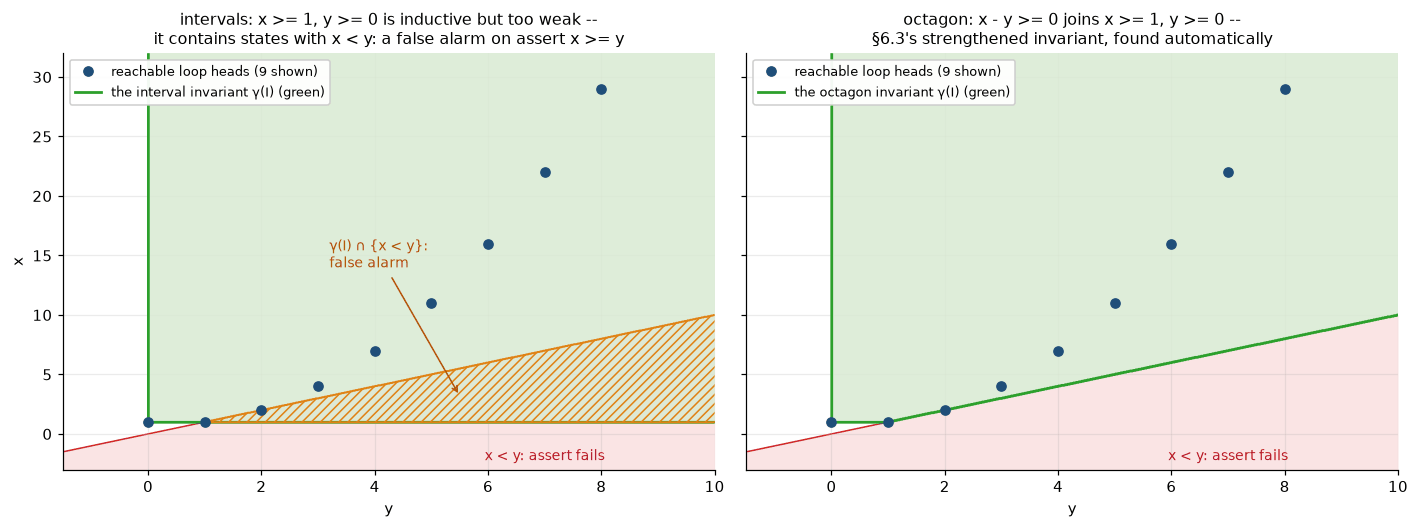

The octagon's fixpoint is a certificate: Z3 re-checks it from scratch, without trusting the analyzer.


In [119]:
# 9.5 (e) The x, y loop: the invariant each domain computes, re-checked by Z3 as a certificate.
def _s9_region(dom, head, X, Y):
    '''Boolean mask of the grid points (x = X, y = Y) inside the loop-head state projected on (x, y).'''
    if isinstance(head, dict):                                    # interval state
        inside = lambda iv, A: (A >= (-np.inf if iv.lo is None else iv.lo)) & (A <= (np.inf if iv.hi is None
                                                                                     else iv.hi))
        return inside(head['x'], X) & inside(head['y'], Y)
    p = dom.select(head, ('x', 'y'))                              # octagon: V_0 = x, V_1 = -x, V_2 = y, V_3 = -y
    signed = [X, -X, Y, -Y]
    mask = np.ones_like(X, dtype=bool)
    for i in range(4):
        for j in range(4):
            if i != j and p.m[i, j] < np.inf:
                mask &= signed[i] - signed[j] <= p.m[i, j]
    return mask


def _s9_without_invariants(src):
    '''The normalized function as an AST dump (line numbers included), with every invariant(...) removed.'''
    fn = parse_minipy(src)
    for node in ast.walk(fn):
        if isinstance(node, ast.While):
            node.body = [s for s in node.body if not (isinstance(s, ast.Expr) and isinstance(s.value, ast.Call)
                                                      and s.value.func.id == 'invariant')]
    return ast.dump(fn, include_attributes=True)


def _s9_xy_demo():
    '''The loop-head invariants of xy_loop in both domains, their certificates, and the picture.'''
    oct_ = _s9_OctagonDomain()
    doms = (("interval", _s9_IntervalDomain()), ("octagon", oct_))
    heads = {d: _s9_loop_head(_s9_XY_SRC, dom) for d, dom in doms}
    facts = {d: [t for t, _ in dom.constraints(heads[d])] for d, dom in doms}
    certs = {d: _s9_xy_certificate(facts[d]) for d, _ in doms} if HAVE_Z3 else {}
    for d in certs:
        c = certs[d]
        print(f"{d:8s} loop-head invariant, re-checked by Z3: on entry {c['init']}, maintained {c['step']}, "
              f"implies assert x >= y at exit: {c['implies_assert']}"
              + (f" -- e.g. {c['cex']}, inside γ(I) but unreachable" if c['cex'] else ""))
    rel = [t for t, used in oct_.constraints(oct_.select(heads["octagon"], ('x', 'y'))) if len(used) == 2]
    print(f"octagon's relational facts at the head, projected on (x, y): {rel}")
    if HAVE_Z3 and 'verify' in globals() and 'XY_SRC' in globals():   # §6's Z3-backed verifier, when §6 has run
        same = _s9_without_invariants(XY_SRC) == _s9_without_invariants(_s9_XY_SRC)
        res = verify(XY_SRC, 'int+ovf', invariants={0: facts["octagon"]}, verbose=False)
        open_ = sorted(n for n, (s, _) in res.items() if s != 'proved')
        print(f"§6.3's verify on its XY_SRC ({'the same program as here, line numbers included, once its written'
                                           ' invariant is removed' if same else 'NOT the same program as here'}) "
              f"with the octagon's invariant: {len(res) - len(open_)} of {len(res)} VCs proved; open: {open_}")

    reach = [(k, 1 + k * (k - 1) // 2) for k in range(9)]           # (y, x) at the head after k iterations
    Y, X = np.meshgrid(np.linspace(-1.5, 10, 700), np.linspace(-3, 32, 700))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.9), sharey=True)
    for ax, (d, dom) in zip(axes, doms):
        mask = _s9_region(dom, heads[d], X, Y)
        ax.fill_between([-1.5, 10], [-1.5, 10], -3, color="#d62728", alpha=0.12, lw=0, zorder=0)
        ax.plot([-1.5, 10], [-1.5, 10], color="#d62728", lw=1, zorder=1)
        ax.contourf(Y, X, mask.astype(float), levels=[0.5, 1.5], colors=["#d9ead3"], alpha=0.85, zorder=2)
        ax.contour(Y, X, mask.astype(float), levels=[0.5], colors=["#2ca02c"], linewidths=1.8, zorder=3)
        bad = mask & (X < Y)
        if bad.any():
            with plt.rc_context({'hatch.color': '#e08214'}):
                ax.contourf(Y, X, bad.astype(float), levels=[0.5, 1.5], colors="none", hatches=["////"], zorder=4)
            ax.contour(Y, X, bad.astype(float), levels=[0.5], colors=["#e08214"], linewidths=1.3, zorder=4)
        ax.text(7.0, -2.2, "x < y: assert fails", color="#b2182b", fontsize=9, ha="center", zorder=6)
        ax.plot(*zip(*reach), "o", color="#1f4e79", ms=6, zorder=5, label="reachable loop heads (9 shown)")
        ax.plot([], [], color="#2ca02c", lw=1.8, label=f"the {d} invariant γ(I) (green)")
        ax.set_xlim(-1.5, 10)
        ax.set_ylim(-3, 32)
        ax.set_xlabel("y")
        ax.legend(fontsize=8.5, loc="upper left", framealpha=0.95)
    axes[0].set_ylabel("x")
    axes[0].annotate("γ(I) ∩ {x < y}:\nfalse alarm", (5.5, 3.2), xytext=(3.2, 14), fontsize=9, color="#b35806",
                     arrowprops=dict(arrowstyle="->", color="#b35806"), zorder=7)
    axes[0].set_title("intervals: x >= 1, y >= 0 is inductive but too weak --\n"
                      "it contains states with x < y: a false alarm on assert x >= y", fontsize=10.5)
    axes[1].set_title("octagon: x - y >= 0 joins x >= 1, y >= 0 --\n"
                      "§6.3's strengthened invariant, found automatically", fontsize=10.5)
    plt.tight_layout()
    plt.show()
    print("Z3 not installed (pip install z3-solver): the octagon's fixpoint was not re-checked as a certificate."
          if not certs else
          "The octagon's fixpoint is a certificate: Z3 re-checks it from scratch, without trusting the analyzer."
          if all(certs["octagon"][k] is True for k in ('init', 'step', 'implies_assert')) else
          "The octagon's invariant did NOT pass all three certificate checks (see above).")


_s9_xy_demo()

On §6.3's loop the octagon finds $x - y \ge 0$, $x \ge 1$, $y \ge 0$: §6.3's strengthened invariant, computed
rather than written. Z3 re-checks it as the loop rule's three verification conditions, without trusting the
analyzer. It holds on entry, is maintained, and implies the `assert`: the fixpoint is a certificate. When §6 has
run, as in the full notebook, the cell also hands the octagon's facts to §6.3's own `verify` as the loop
invariant of `XY_SRC` (the same program, line for line), and every VC is proved except the overflow of `x + y`.
The interval invariant $x \ge 1, y \ge 0$ is just as inductive and too weak to imply the assert. Neither domain
can say $x = 1 + y(y-1)/2$, so both flag `x + y`, and that alarm is real: `xy_loop(65537)` overflows.

### 9.6 In industry: tune the over-approximation, or flip it

False alarms decide whether anyone uses an analyzer, and the two famous industrial answers sit on opposite sides of
§2.4's picture.

**Astrée: shrink $O$ until $O \cap B = \emptyset$.** In Nov 2003 Astrée proved, completely automatically, the
absence of run-time errors in the Airbus A340's primary flight-control software, 132,000 lines of C, in 1 h 20 on
a 2.8 GHz PC — the first time its goal of zero false alarms was reached; the project had started from scratch in
Nov 2001 ([astree.ens.fr](https://www.astree.ens.fr/)). The A380's electric flight controls followed with no
false alarm in Nov 2004 (P. Cousot, MIT talk, 2005). Zero took work. On the 132,000-line avionics program that
Blanchet et al. (PLDI 2003) tuned the analyzer on, the analyzer the team started from reported 1,200 false
alarms. Their refinements — octagons, ellipsoids for digital filters, decision trees, widening with thresholds,
trace partitioning — brought that to 11, and to 3 on some versions of the program (Sect. 8 of the paper; also
Kästner et al., ERTS² 2010). Later, a 200,000-line Airbus project went from 467 false alarms to zero (Kästner et
al., ERTS² 2010, summarizing Delmas & Souyris, SAS 2007). Astrée combines its domains in a weak form of reduced
product ([astree.ens.fr](https://www.astree.ens.fr/)) and has been sold by AbsInt since Dec 2009. It is §9.4's
analyzer at industrial scale: sound, automatic, and specialized until the boxes stop poking into $B$.

**Infer: flip to under-approximation.** Meta's Infer grew out of separation logic and **bi-abduction** (Calcagno,
Distefano, O'Hearn & Yang, POPL 2009), compositional proof machinery whose reports were filtered heuristically.
Deployment decided its value first (Distefano, Fähndrich, Logozzo & O'Hearn, CACM 2019). Run in batch, with bug
lists handed out outside the developer's workflow and a false-positive rate thought to be under 20%, the fix rate
was near zero. The same analysis commenting on diffs in code review reached over 70%, and developers resolved over
100,000 Infer issues from 2014 on. The logic changed next. Pulse-X (Le, Raad, Villard, Berdine, Dreyer &
O'Hearn, OOPSLA 2022) is a research analyzer built on **Incorrectness Separation Logic** (Raad et al., CAV 2020),
the separation-logic version of §2.4's Incorrectness Logic. It reports *manifest* errors, which occur whatever
the calling context, plus a slightly relaxed variant of them, latent memory leaks, and latent null dereferences in
`main()`. Under the assumptions of its formal model a "true positives" theorem holds; the implementation still
had a few false positives, all from calls to unknown code. On OpenSSL 1.0.1h Pulse-X's fix rate was 73% (19/26)
against 49% (39/80) for the Infer of the paper's day run on the same old version. A slightly relaxed manifest
criterion, built into Meta's sibling analyzer Pulse, let null-dereference checks run in production with a fix
rate over 80%. Infer 1.2.0 made Pulse the default memory analysis in place of bi-abduction, and 1.3.0 removed
bi-abduction (Infer changelog). Google states the same economics as a rule: code-review checks must have under
10% effective false positives (Sadowski et al., CACM 2018).

Both are rational: Astrée sells a proof for one program family and pays in analyzer engineering; Infer sells bug
reports at the scale of all code and gives up the proof.

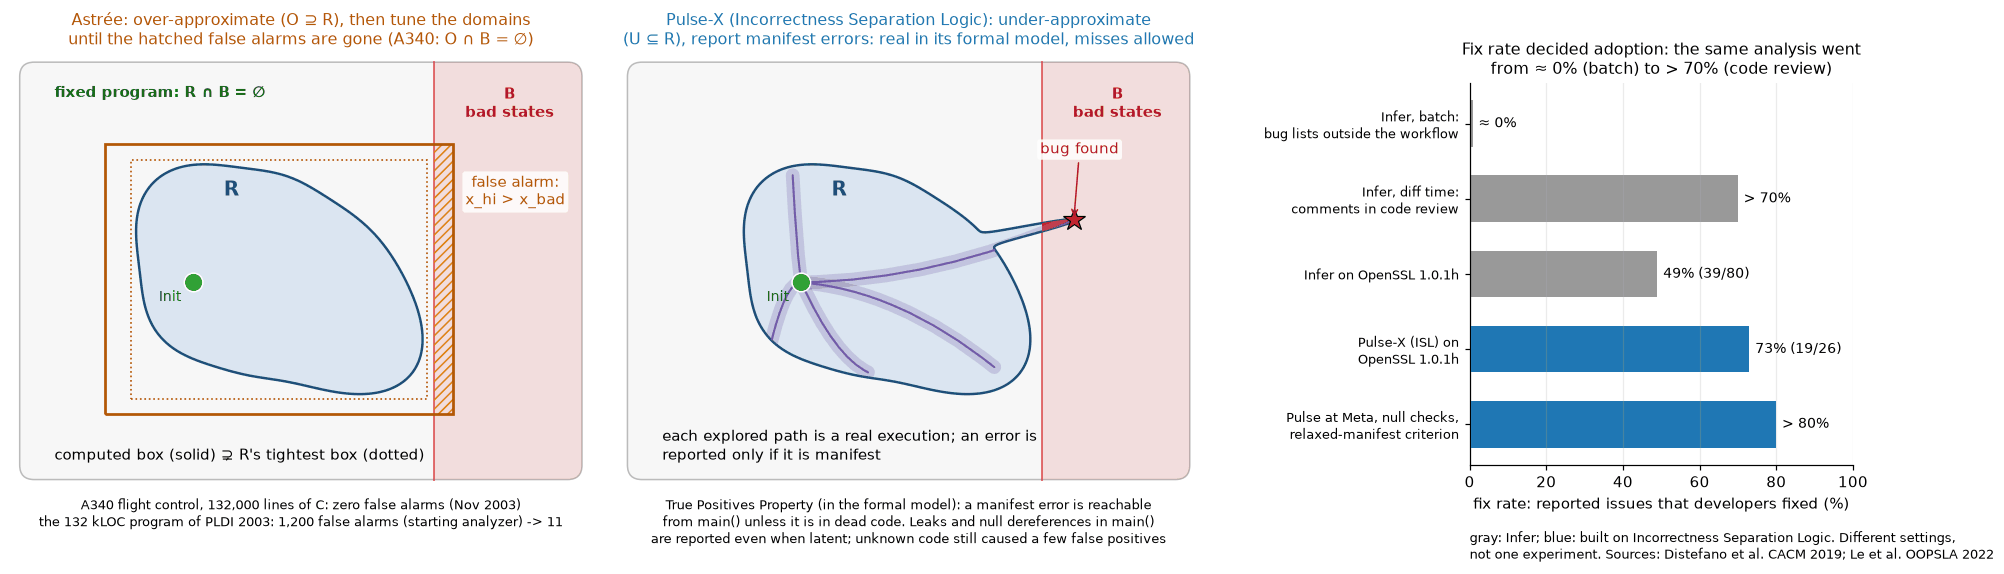

Astrée bought zero false alarms for one program family with two years of analyzer engineering
(Nov 2001 to Nov 2003); Pulse-X buys, within its formal model, freedom from false positives by giving up
completeness; Meta's Pulse, on a relaxed criterion, turned null checks on in production with a fix rate
over 80%. Where reports reach developers mattered as much as the logic: ≈ 0% -> > 70% for the same
analysis; 49% -> 73% on OpenSSL when logic and reporting rule changed together (and the two tools found
different bugs).


In [120]:
# 9.6 The industrial matched pair on §2.4's approximation picture, and the fix rates (sourced in the text above).
_s9_FIX_RATES = [  # (label, percent, shown as, analysis family)
    ("Infer, batch:\nbug lists outside the workflow", 0.0, "≈ 0%", "infer"),
    ("Infer, diff time:\ncomments in code review", 70.0, "> 70%", "infer"),
    ("Infer on OpenSSL 1.0.1h", 49.0, "49% (39/80)", "infer"),
    ("Pulse-X (ISL) on\nOpenSSL 1.0.1h", 73.0, "73% (19/26)", "isl"),
    ("Pulse at Meta, null checks,\nrelaxed-manifest criterion", 80.0, "> 80%", "isl")]


def _s9_industry_figure():
    fig = plt.figure(figsize=(17, 5.6))            # explicit boxes: the two pictures have a fixed aspect ratio
    axes = [fig.add_axes([0.005, 0.15, 0.31, 0.71]), fig.add_axes([0.33, 0.15, 0.31, 0.71]),
            fig.add_axes([0.785, 0.19, 0.205, 0.62])]
    draw_approx(axes[0], 'abstract_interp', title=False)
    axes[0].set_title("Astrée: over-approximate (O ⊇ R), then tune the domains\n"
                      "until the hatched false alarms are gone (A340: O ∩ B = ∅)", fontsize=10.5, color="#b35806")
    axes[0].text(0.5, -0.02, "A340 flight control, 132,000 lines of C: zero false alarms (Nov 2003)\n"
                 "the 132 kLOC program of PLDI 2003: 1,200 false alarms (starting analyzer) -> 11",
                 transform=axes[0].transAxes, ha="center", va="top", fontsize=8.8)
    draw_approx(axes[1], 'symex', title=False)
    for t in axes[1].texts:                     # §2.4's caption describes symbolic execution, not Pulse
        if "explored paths" in t.get_text():
            t.set_text("each explored path is a real execution; an error is\nreported only if it is manifest")
    axes[1].set_title("Pulse-X (Incorrectness Separation Logic): under-approximate\n"
                      "(U ⊆ R), report manifest errors: real in its formal model, misses allowed",
                      fontsize=10.5, color="#1f77b4")
    axes[1].text(0.5, -0.02, "True Positives Property (in the formal model): a manifest error is reachable\n"
                 "from main() unless it is in dead code. Leaks and null dereferences in main()\n"
                 "are reported even when latent; unknown code still caused a few false positives",
                 transform=axes[1].transAxes, ha="center", va="top", fontsize=8.8)
    ax = axes[2]
    labels = [r[0] for r in _s9_FIX_RATES]
    colors = ["0.6" if r[3] == "infer" else "#1f77b4" for r in _s9_FIX_RATES]
    ys = np.arange(len(labels))[::-1]
    ax.barh(ys, [max(r[1], 0.8) for r in _s9_FIX_RATES], color=colors, height=0.62)
    for y, (_, v, shown, _) in zip(ys, _s9_FIX_RATES):
        ax.text(max(v, 0.8) + 1.5, y, shown, va="center", fontsize=9)
    ax.set_yticks(ys)
    ax.set_yticklabels(labels, fontsize=8.8)
    ax.set_xlim(0, 100)
    ax.set_xlabel("fix rate: reported issues that developers fixed (%)")
    ax.grid(axis="y", visible=False)
    ax.set_title("Fix rate decided adoption: the same analysis went\nfrom ≈ 0% (batch) to > 70% (code review)",
                 fontsize=10.5)
    ax.text(0.0, -0.17, "gray: Infer; blue: built on Incorrectness Separation Logic. Different settings,\nnot "
            "one experiment. Sources: Distefano et al. CACM 2019; Le et al. OOPSLA 2022", transform=ax.transAxes,
            fontsize=8.3, va="top")
    plt.show()
    print("Astrée bought zero false alarms for one program family with two years of analyzer engineering")
    print("(Nov 2001 to Nov 2003); Pulse-X buys, within its formal model, freedom from false positives by giving up")
    print("completeness; Meta's Pulse, on a relaxed criterion, turned null checks on in production with a fix rate")
    print("over 80%. Where reports reach developers mattered as much as the logic: ≈ 0% -> > 70% for the same")
    print("analysis; 49% -> 73% on OpenSSL when logic and reporting rule changed together (and the two tools found")
    print("different bugs).")


_s9_industry_figure()

**Where this leaves abstract interpretation.** In the spine's terms: the inductive invariant is found by an
algorithm, in a vocabulary fixed in advance, and the price is false alarms wherever the needed invariant lies
outside that vocabulary — `j <= 100` needs `j == i`, `midpoint_fixed` needs `lo + d <= INT32_MAX`, the x, y loop
needs `x >= y`. The analysis always terminates (widening), never misses a real safety violation — an overflow, a
failing `assert`, `ensures` or `invariant` (§9.1) — while reporting every `decreases` as unchecked, and leaves a
certificate checkable by one more iteration or, as above, by a solver. The rest of the cost is human, and it
moved rather than disappeared. Astrée's engineers spent it on domains instead of annotations; §6 spends it on
invariants instead of domains; §13 asks whether an LLM proposing invariants and a checker deciding can spend it
for us. §11 reuses the move that makes all of this work — throw away what the property does not depend on — to
replay the TimSort bug on run lengths alone.

## 10. Proofs as programs: interactive theorem proving

Every engine so far is push-button — a solver query (§3–§4), a bounded search (§5), a VC generator fed invariants
(§6), a state-space search (§8), an abstract domain (§9) — and each ends somewhere in `unknown`. **Interactive
theorem provers** (Lean, Rocq, Isabelle, HOL Light) trade push-button automation for expressive logics
(higher-order logic, dependent type theory): *you* write the proof, with tactics as power tools, and a small trusted
program — the **kernel** — checks every step. seL4, CompCert and the 2026 AI-math results live here (§11, §13).
Three ideas carry the section: automation runs out at **induction** (§10.1); proofs *are* programs and checking a
proof *is* type-checking (§10.2); and trust can be concentrated in a small kernel (HOL Light's is 676 lines,
§10.6), either by making theorems an abstract type (**LCF**, §10.3) or by re-checking an explicit proof object
(**de Bruijn**, §10.4) — and §10.4 puts both in front of an adversary, in Python.

### 10.1 Where automation runs out: induction

Take Peano naturals — `Z` and `S n` — and addition defined by recursion on the **second** argument, exactly as
Lean 4 defines `Nat.add` (`| a, Nat.zero => a` and `| a, Nat.succ b => Nat.succ (Nat.add a b)`,
[Init/Prelude.lean](https://github.com/leanprover/lean4/blob/master/src/Init/Prelude.lean)):

$$\mathrm{add}(m, Z) = m, \qquad \mathrm{add}(m, S\,n) = S(\mathrm{add}(m, n)).$$

Z3 supports this directly (an algebraic datatype plus a `RecFunction`) and attacks goals by unfolding the
definition on demand. `add(m, Z) = m` *is* the first equation. Its mirror image `add(Z, n) = n` is just as true,
but the recursion is on `n`, which is a variable, so the solver can only split cases:

```
add(Z, n) = n
 ├─ n = Z    : add(Z, Z) = Z                            ✓ equation 1
 └─ n = S n1 : S(add(Z, n1)) = S n1   ⇐  add(Z, n1) = n1    <- the same goal, renamed
                ├─ n1 = Z    ✓
                └─ n1 = S n2 : ... ⇐ add(Z, n2) = n2        <- and again, forever
```

**Induction** ties the knot: *assume* the goal for `n1` (the induction hypothesis) and prove it for `S n1`. It is
an axiom *schema* — $P(Z) \land \forall n\,(P(n) \Rightarrow P(S\,n)) \Rightarrow \forall n\,P(n)$ for every
property $P$ — and the art is choosing $P$, often *stronger* than the goal (§6's lesson: a true invariant is
often not inductive). E-matching (§7) does not invent $P$. Z3 runs under a deterministic resource budget
(`rlimit`), so `unknown` means "budget exhausted", reproducibly; a 3 s wall-clock timeout is only a safety net, and
the cell checks that no query reached it.

**Registered prediction** (the tempting one): *Z3 proves `add(Z, n) = n` as easily as `add(m, Z) = m` — they say
the same thing about `Z`.* The cell also hands Z3 each induction **scheme** (base case, and step case with the
hypothesis as an assumption) to see which part of the work is actually hard.

goal       statement (all naturals)               Z3 directly                  base P(Z)  step P(n)|-P(S n)  base / step + 2 lemmas
-----------------------------------------------------------------------------------------------------------------------------------
add_zero   add(m, Z) = m                          proved (0 unfoldings)        -          -                  -                     
zero_add   add(Z, n) = n                          unknown (59,941 unfoldings)  proved     proved             -                     
succ_add   add(S m, n) = S(add(m, n))             unknown (98,459 unfoldings)  proved     proved             -                     
add_assoc  add(add(m, k), n) = add(m, add(k, n))  unknown (71,412 unfoldings)  proved     proved             -                     
add_comm   add(m, n) = add(n, m)                  unknown (42,454 unfoldings)  unknown    unknown            proved / proved       

concrete instances add(Z, S^k(Z)) = S^k(Z), k = 0..64: 65/65 proved (the si

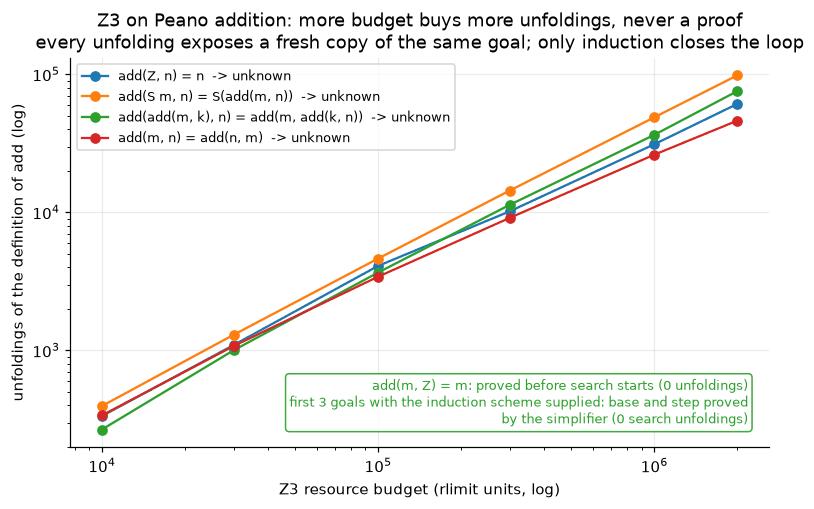

which limit stopped each 'unknown': 30 of 30 the rlimit budget (Z3's reasons: canceled, max. resource limit exceeded), 0 the 3 s wall clock; slowest query ~0.4 s
Given the induction scheme (base + step), Z3 closes every case instantly -- except add_comm's (unknown / unknown),
which come back proved / proved only once two lemmas about the first argument are supplied. Inventing lemmas is the human's job.


In [121]:
# §10.1  Z3 meets Peano arithmetic. `add` recurses on its SECOND argument, exactly like Lean's Nat.add:
#     add(m, Z)   = m
#     add(m, S n) = S(add(m, n))
# Every goal below is TRUE for all naturals (checked by brute force at the end of the cell).
_s10_Z3_BUDGET = 2_000_000                     # Z3 resource units ('rlimit': deterministic, ~0.3 s here)
_s10_Z3_TIMEOUT_MS = 3000                      # wall-clock safety net on top of the budget
_s10_BUDGETS = [10**4, 3 * 10**4, 10**5, 3 * 10**5, 10**6, 2 * 10**6]    # sweep for the figure
_s10_BRUTE_MAX = 12                            # brute-force oracle: all m, k, n in 0..12
_s10_Z3_STOPS = []                             # (reason, seconds) of every 'unknown': which limit stopped it?


def _s10_peano_add_int(m, n):
    '''The same recursion on Python ints (the oracle): add(m, 0) = m, add(m, n+1) = add(m, n) + 1.'''
    return m if n == 0 else _s10_peano_add_int(m, n - 1) + 1


# goal name -> readable statement (each is true for every natural number)
_s10_GOAL_TEXT = {
    'add_zero':  'add(m, Z) = m',
    'zero_add':  'add(Z, n) = n',
    'succ_add':  'add(S m, n) = S(add(m, n))',
    'add_assoc': 'add(add(m, k), n) = add(m, add(k, n))',
    'add_comm':  'add(m, n) = add(n, m)',
}
_s10_GOAL_INT = {                              # the same statements on ints, for the oracle
    'add_zero':  lambda m, k, n: _s10_peano_add_int(m, 0) == m,
    'zero_add':  lambda m, k, n: _s10_peano_add_int(0, n) == n,
    'succ_add':  lambda m, k, n: _s10_peano_add_int(m + 1, n) == _s10_peano_add_int(m, n) + 1,
    'add_assoc': lambda m, k, n: (_s10_peano_add_int(_s10_peano_add_int(m, k), n)
                                  == _s10_peano_add_int(m, _s10_peano_add_int(k, n))),
    'add_comm':  lambda m, k, n: _s10_peano_add_int(m, n) == _s10_peano_add_int(n, m),
}

if HAVE_Z3:
    _s10_CTX = z3.Context()                    # private context: counts do not depend on earlier sections' Z3 terms
    _s10_dt = z3.Datatype('Peano', ctx=_s10_CTX)
    _s10_dt.declare('Z')
    _s10_dt.declare('S', ('pred', _s10_dt))
    _s10_Peano = _s10_dt.create()
    _s10_zZ, _s10_zS = _s10_Peano.Z, _s10_Peano.S
    _s10_zadd = z3.RecFunction('peano_add', _s10_Peano, _s10_Peano, _s10_Peano)
    _s10_a, _s10_b = z3.Consts('a b', _s10_Peano)
    z3.RecAddDefinition(_s10_zadd, [_s10_a, _s10_b],
                        z3.If(_s10_Peano.is_Z(_s10_b), _s10_a,
                              _s10_zS(_s10_zadd(_s10_a, _s10_Peano.pred(_s10_b)))))
    _s10_zm, _s10_zk, _s10_zn, _s10_zx, _s10_zy = z3.Consts('m k n x y', _s10_Peano)
    _s10_GOAL_Z3 = {   # P(x): the statement with the induction variable x in the recursive position
        'add_zero':  lambda x: _s10_zadd(x, _s10_zZ) == x,
        'zero_add':  lambda x: _s10_zadd(_s10_zZ, x) == x,
        'succ_add':  lambda x: _s10_zadd(_s10_zS(_s10_zm), x) == _s10_zS(_s10_zadd(_s10_zm, x)),
        'add_assoc': lambda x: (_s10_zadd(_s10_zadd(_s10_zm, _s10_zk), x)
                                == _s10_zadd(_s10_zm, _s10_zadd(_s10_zk, x))),
        'add_comm':  lambda x: _s10_zadd(_s10_zm, x) == _s10_zadd(x, _s10_zm),
    }
    # The two lemmas a human would supply for commutativity, as quantified facts:
    _s10_LEMMAS = [z3.ForAll([_s10_zx], _s10_zadd(_s10_zZ, _s10_zx) == _s10_zx),
                   z3.ForAll([_s10_zx, _s10_zy], _s10_zadd(_s10_zS(_s10_zx), _s10_zy)
                             == _s10_zS(_s10_zadd(_s10_zx, _s10_zy)))]


def _s10_z3_prove(goal, hyps=(), budget=None):
    '''Validity check: goal follows from hyps iff hyps AND NOT goal is UNSAT.
    Returns (status, number of times Z3 unfolded the recursive definition of add).'''
    s = z3.Solver(ctx=_s10_CTX)
    s.set('rlimit', budget or _s10_Z3_BUDGET)
    s.set('timeout', _s10_Z3_TIMEOUT_MS)
    s.add(*hyps)
    s.add(z3.Not(goal))
    t0 = time.perf_counter()
    r = s.check()
    if r == z3.unknown:
        _s10_Z3_STOPS.append((s.reason_unknown(), time.perf_counter() - t0))
    st = s.statistics()
    unfold = st.get_key_value('recfun body expansion') if 'recfun body expansion' in st.keys() else 0
    status = 'proved' if r == z3.unsat else 'counterexample' if r == z3.sat else 'unknown'
    return status, unfold


def _s10_peano_demo():
    '''Table, oracle, registered prediction and figure for §10.1.'''
    rows, direct_by_goal, scheme_unf = [], {}, []
    for name, P in _s10_GOAL_Z3.items():
        direct = _s10_z3_prove(P(_s10_zn))
        direct_by_goal[name] = direct
        if name == 'add_zero':
            rows.append([name, _s10_GOAL_TEXT[name], f"{direct[0]} ({direct[1]} unfoldings)", "-", "-", "-"])
            continue
        base = _s10_z3_prove(P(_s10_zZ))                                       # P(Z)
        step = _s10_z3_prove(P(_s10_zS(_s10_zn)), [P(_s10_zn)])                # P(n) |- P(S n)
        if name != 'add_comm':
            scheme_unf.append(max(base[1], step[1]))
        lem = (_s10_z3_prove(P(_s10_zZ), _s10_LEMMAS)[0] + " / "
               + _s10_z3_prove(P(_s10_zS(_s10_zn)), [P(_s10_zn)] + _s10_LEMMAS)[0]) if name == 'add_comm' else "-"
        rows.append([name, _s10_GOAL_TEXT[name], f"{direct[0]} ({direct[1]:,} unfoldings)", base[0], step[0], lem])
        if name == 'add_comm':
            comm = (base[0], step[0], lem)
    show_table(["goal", "statement (all naturals)", "Z3 directly", "base P(Z)", "step P(n)|-P(S n)",
                "base / step + 2 lemmas"], rows)

    # Each concrete instance is easy: Z3 just computes. The universally quantified statement is not.
    inst_ok = 0
    for kk in range(0, 65):
        t = _s10_zZ
        for _ in range(kk):
            t = _s10_zS(t)
        inst_ok += _s10_z3_prove(_s10_zadd(_s10_zZ, t) == t)[0] == 'proved'
    print(f"\nconcrete instances add(Z, S^k(Z)) = S^k(Z), k = 0..64: {inst_ok}/65 proved "
          "(the simplifier just computes them) -- every instance, never the 'for all'")

    # Brute-force oracle: the unknowns are incompleteness, not hidden counterexamples.
    R = range(_s10_BRUTE_MAX + 1)
    bad = sum(not f(m, k, n) for f in _s10_GOAL_INT.values() for m in R for k in R for n in R)
    print(f"oracle: all 5 goals evaluated on every (m, k, n) in 0..{_s10_BRUTE_MAX}: {bad} failures")

    za, zd = direct_by_goal['add_zero'], direct_by_goal['zero_add']
    print(f"registered prediction: Z3 proves add(Z, n) = n as easily as add(m, Z) = m | measured: add_zero "
          f"{za[0]} after {za[1]} unfoldings; zero_add {zd[0]} after {zd[1]:,} unfoldings (budget exhausted) | "
          f"verdict: {'RIGHT' if zd[0] == 'proved' else 'WRONG'} -- the first is one step of the definition, "
          "the second needs induction, a rule Z3 does not apply on its own")

    # Figure: budget vs unfoldings. More compute buys more unfoldings, never a proof.
    fig, ax = plt.subplots(figsize=(8.2, 4.6))
    for name in ['zero_add', 'succ_add', 'add_assoc', 'add_comm']:
        unf = [_s10_z3_prove(_s10_GOAL_Z3[name](_s10_zn), budget=b) for b in _s10_BUDGETS]
        assert all(s == 'unknown' for s, _ in unf)
        ax.plot(_s10_BUDGETS, [u for _, u in unf], "o-", label=f"{_s10_GOAL_TEXT[name]}  -> unknown")
    ax.text(0.97, 0.05, f"{_s10_GOAL_TEXT['add_zero']}: proved before search starts ({za[1]} unfoldings)\n"
            "first 3 goals with the induction scheme supplied: base and step proved\n"
            f"by the simplifier ({max(scheme_unf)} search unfoldings)",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5, color="#2ca02c",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#2ca02c", alpha=0.9))
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Z3 resource budget (rlimit units, log)")
    ax.set_ylabel("unfoldings of the definition of add (log)")
    ax.set_title("Z3 on Peano addition: more budget buys more unfoldings, never a proof\n"
                 "every unfolding exposes a fresh copy of the same goal; only induction closes the loop")
    ax.legend(fontsize=8.5, loc="upper left")
    plt.show()
    wall = [x for x in _s10_Z3_STOPS if x[0] == 'timeout' or x[1] >= _s10_Z3_TIMEOUT_MS / 1e3]
    print(f"which limit stopped each 'unknown': {len(_s10_Z3_STOPS) - len(wall)} of {len(_s10_Z3_STOPS)} the rlimit "
          f"budget (Z3's reasons: {', '.join(sorted({r for r, _ in _s10_Z3_STOPS}))}), {len(wall)} the "
          f"{_s10_Z3_TIMEOUT_MS / 1e3:.0f} s wall clock; slowest query ~{max(t for _, t in _s10_Z3_STOPS):.1f} s")
    print(f"Given the induction scheme (base + step), Z3 closes every case instantly -- except add_comm's "
          f"({comm[0]} / {comm[1]}),")
    print(f"which come back {comm[2]} only once two lemmas about the first argument are supplied. "
          "Inventing lemmas is the human's job.")


if HAVE_Z3:
    _s10_peano_demo()
else:
    print("Z3 not installed: skipping §10.1 (the kernel in §10.3 shows the same wall without Z3).")

The table splits the work cleanly. Every universally quantified goal except the definitional one comes back
`unknown` after tens of thousands of unfoldings, and the figure shows why more compute does not help: unfoldings
grow in proportion to the budget, because each one produces a fresh copy of the same goal. Handed the induction
scheme, Z3 closes the base and step cases of three goals outright — the solver is excellent at the *steps*.
`add_comm` is different: even given the scheme it stays `unknown`. Its cases put a variable in the **first**
argument of `add`, a position the definition never mentions; handed two facts about that position as quantified
lemmas (the last column), both cases close. Which lemmas a proof of `add_comm` really needs is §10.3's question.
Associativity needs no lemma: it inducts on the argument `add` recurses on (the Boyer–Moore heuristic). Tools
automate part of this — Dafny tries induction heuristically (Leino, VMCAI 2012) and CVC4/cvc5 has an induction
mode (Reynolds & Kuncak, VMCAI 2015) — but **choosing the induction and inventing the lemma** is in general the
creative step. It is exactly what interactive provers ask a human for, and what LLM provers are now paid to do
(§13).

### 10.2 Curry–Howard: a proposition is a type, a proof is a program

Before building a kernel, what *is* a proof, as data? The cleanest answer is the **Curry–Howard correspondence**
(Curry 1934; Curry & Feys 1958; Howard, written 1969, published 1980 — see [Wadler's
survey](https://homepages.inf.ed.ac.uk/wadler/papers/propositions-as-types/propositions-as-types.pdf)), which de
Bruijn's Automath (1967–68) essentially rediscovered:

| logic | programming |
|---|---|
| proposition $A \to B$ / $A \land B$ / $A \lor B$ | function type / pair type / tagged union (`inl` or `inr`) |
| $\bot$ (false) | the empty type: no values at all |
| $\lnot A := A \to \bot$ | a function into the empty type: it can never return a value |
| a proof of $A$ | a program (closed term) of type $A$ |
| assume $A$, derive $B$ / modus ponens / proof by cases | `λx:A. body` / application / `case` |
| checking a proof | **type-checking** the program |
| simplifying a proof (normalization: removing an introduction followed by an elimination) | running it ($\beta$-reduction) |

For an ML engineer: a proof of $A \to B$ is a function that turns any evidence for $A$ into evidence for $B$, and
verifying the proof is nothing more than type-checking that function. The checker below is the simply typed
λ-calculus with →, ×, + and ⊥, in **Church style** (every binder carries its type), so checking is one
syntax-directed recursive pass in which each term former is exactly one natural-deduction rule. The logic it
checks is **intuitionistic** propositional logic.

In [122]:
# §10.2  Curry-Howard: a type checker for the simply typed lambda calculus with ->, and (x), or (+), bottom.
# Types (= propositions): an atom 'A' | '⊥' | ('->', T, U) | ('and', T, U) | ('or', T, U).   ¬T := T -> ⊥
# Terms (= proofs), Church style (every binder carries its type):
#   'x'                         a variable: a hypothesis in scope
#   ('lam', x, T, body)         λx:T. body                  ->-introduction ("assume T, derive U")
#   ('app', f, a)               f a                         ->-elimination  (modus ponens)
#   ('pair', a, b)              ⟨a, b⟩                      and-introduction
#   ('fst', p), ('snd', p)      projections                 and-elimination
#   ('inl', a, U), ('inr', b, T)  injections into T ∨ U    or-introduction (the other side is annotated)
#   ('case', s, x, t1, y, t2)   case s of inl x => t1 | inr y => t2    or-elimination (proof by cases)
#   ('absurd', e, T)            from a proof of ⊥, anything   ⊥-elimination (ex falso)
_s10_BOT = '⊥'
_s10_ARITY = {'lam': 4, 'app': 3, 'pair': 3, 'fst': 2, 'snd': 2, 'inl': 3, 'inr': 3, 'case': 6, 'absurd': 3}


def _s10_neg(t):
    return ('->', t, _s10_BOT)


def _s10_check_type(t):
    '''Reject malformed type annotations (a type is an atom string or a binary connective). Exact built-in
    str and tuple only: a subclass could override == and make two different propositions compare equal.'''
    if type(t) is str:
        return t
    if type(t) is tuple and len(t) == 3 and type(t[0]) is str and t[0] in ('->', 'and', 'or'):
        _s10_check_type(t[1]); _s10_check_type(t[2])
        return t
    raise TypeError(f"not a type: {t!r}")


def typecheck(term, ctx=()):
    '''Return the type (= the proposition proved) of a Church-annotated term, or raise TypeError.
    ctx is a tuple of (name, type) pairs -- the open hypotheses; later entries shadow earlier ones.'''
    if not (type(term) is str or (type(term) is tuple and term and type(term[0]) is str
                                  and len(term) == _s10_ARITY.get(term[0], -1))):
        raise TypeError(f"malformed term {term!r}")
    if type(term) is str:
        for name, ty in reversed(ctx):
            if name == term:
                return ty
        raise TypeError(f"unbound variable {term!r} (an assumption nobody proved)")
    tag = term[0]
    if tag == 'lam':
        _, x, a, body = term
        if type(x) is not str:
            raise TypeError(f"binder {x!r} is not a name")
        return ('->', _s10_check_type(a), typecheck(body, ctx + ((x, a),)))
    if tag == 'app':
        f_ty, a_ty = typecheck(term[1], ctx), typecheck(term[2], ctx)
        if not (isinstance(f_ty, tuple) and f_ty[0] == '->'):
            raise TypeError(f"applying a non-function of type {_s10_fmt_type(f_ty)}")
        if f_ty[1] != a_ty:
            raise TypeError(f"function expects {_s10_fmt_type(f_ty[1])} "
                            f"but the argument proves {_s10_fmt_type(a_ty)}")
        return f_ty[2]
    if tag == 'pair':
        return ('and', typecheck(term[1], ctx), typecheck(term[2], ctx))
    if tag in ('fst', 'snd'):
        p_ty = typecheck(term[1], ctx)
        if not (isinstance(p_ty, tuple) and p_ty[0] == 'and'):
            raise TypeError(f"projection from a non-conjunction {_s10_fmt_type(p_ty)}")
        return p_ty[1] if tag == 'fst' else p_ty[2]
    if tag == 'inl':
        return ('or', typecheck(term[1], ctx), _s10_check_type(term[2]))
    if tag == 'inr':
        return ('or', _s10_check_type(term[2]), typecheck(term[1], ctx))
    if tag == 'case':
        _, s, x, t1, y, t2 = term
        if type(x) is not str or type(y) is not str:
            raise TypeError("case binders must be names")
        s_ty = typecheck(s, ctx)
        if not (isinstance(s_ty, tuple) and s_ty[0] == 'or'):
            raise TypeError(f"case analysis on a non-disjunction {_s10_fmt_type(s_ty)}")
        c1, c2 = typecheck(t1, ctx + ((x, s_ty[1]),)), typecheck(t2, ctx + ((y, s_ty[2]),))
        if c1 != c2:
            raise TypeError(f"the two cases prove different things: {_s10_fmt_type(c1)} vs {_s10_fmt_type(c2)}")
        return c1
    if tag == 'absurd':
        if typecheck(term[1], ctx) != _s10_BOT:
            raise TypeError("absurd needs a proof of ⊥")
        return _s10_check_type(term[2])
    raise TypeError(f"unknown term former {tag!r}")


def _s10_fmt_type(t, ctx=0):
    '''Pretty-print a type with the usual precedence: ¬ > ∧, ∨ > → (and → associates to the right).'''
    if isinstance(t, str):
        return t
    if t[0] == '->' and t[2] == _s10_BOT:
        s, prec = "¬" + _s10_fmt_type(t[1], 3), 3
    elif t[0] == '->':
        s, prec = _s10_fmt_type(t[1], 1) + " → " + _s10_fmt_type(t[2], 0), 0
    else:
        sym = '∧' if t[0] == 'and' else '∨'
        s, prec = _s10_fmt_type(t[1], 3) + sym + _s10_fmt_type(t[2], 3), 2
    return s if prec >= ctx else "(" + s + ")"


def _s10_fmt_term(e):
    '''Pretty-print a proof term in the usual lambda notation.'''
    f = _s10_fmt_term
    atomic = lambda x: isinstance(x, str) or x[0] == 'pair'
    paren = lambda x: f(x) if atomic(x) else "(" + f(x) + ")"
    if isinstance(e, str):
        return e
    tag = e[0]
    if tag == 'lam':
        return f"λ{e[1]}:{_s10_fmt_type(e[2], 1)}. {f(e[3])}"
    if tag == 'app':
        fn = f(e[1]) if atomic(e[1]) or e[1][0] == 'app' else "(" + f(e[1]) + ")"
        return f"{fn} {paren(e[2])}"
    if tag == 'pair':
        return f"⟨{f(e[1])}, {f(e[2])}⟩"
    if tag in ('fst', 'snd', 'inl', 'inr', 'absurd'):
        return f"{tag} {paren(e[1])}"
    if tag == 'case':
        return f"case {f(e[1])} of inl {e[2]} ⇒ {f(e[3])} | inr {e[4]} ⇒ {f(e[5])}"
    return repr(e)


_s10_A, _s10_B, _s10_C = 'A', 'B', 'C'
_s10_AND = lambda t, u: ('and', t, u)
_s10_OR = lambda t, u: ('or', t, u)
_s10_IMP = lambda t, u: ('->', t, u)
_s10_EM = _s10_OR('A', _s10_neg('A'))                         # A ∨ ¬A, the law of excluded middle

# (name, claimed proposition, proof term). The last three are bogus and must be rejected.
_s10_PROOFS = [
    ("and_swap", _s10_IMP(_s10_AND('A', 'B'), _s10_AND('B', 'A')),
     ('lam', 'p', _s10_AND('A', 'B'), ('pair', ('snd', 'p'), ('fst', 'p')))),
    ("syllogism", _s10_IMP(_s10_IMP('A', 'B'), _s10_IMP(_s10_IMP('B', 'C'), _s10_IMP('A', 'C'))),
     ('lam', 'f', _s10_IMP('A', 'B'), ('lam', 'g', _s10_IMP('B', 'C'), ('lam', 'a', 'A',
      ('app', 'g', ('app', 'f', 'a')))))),
    ("curry", _s10_IMP(_s10_IMP(_s10_AND('A', 'B'), 'C'), _s10_IMP('A', _s10_IMP('B', 'C'))),
     ('lam', 'f', _s10_IMP(_s10_AND('A', 'B'), 'C'), ('lam', 'a', 'A', ('lam', 'b', 'B',
      ('app', 'f', ('pair', 'a', 'b')))))),
    ("uncurry", _s10_IMP(_s10_IMP('A', _s10_IMP('B', 'C')), _s10_IMP(_s10_AND('A', 'B'), 'C')),
     ('lam', 'f', _s10_IMP('A', _s10_IMP('B', 'C')), ('lam', 'p', _s10_AND('A', 'B'),
      ('app', ('app', 'f', ('fst', 'p')), ('snd', 'p'))))),
    ("or_swap", _s10_IMP(_s10_OR('A', 'B'), _s10_OR('B', 'A')),
     ('lam', 's', _s10_OR('A', 'B'), ('case', 's', 'a', ('inr', 'a', 'B'), 'b', ('inl', 'b', 'A')))),
    ("contrapose", _s10_IMP(_s10_IMP('A', 'B'), _s10_IMP(_s10_neg('B'), _s10_neg('A'))),
     ('lam', 'f', _s10_IMP('A', 'B'), ('lam', 'nb', _s10_neg('B'), ('lam', 'a', 'A',
      ('app', 'nb', ('app', 'f', 'a')))))),
    ("ex_falso", _s10_IMP(_s10_BOT, 'A'), ('lam', 'e', _s10_BOT, ('absurd', 'e', 'A'))),
    ("nn_em", _s10_neg(_s10_neg(_s10_EM)),                     # ¬¬(A ∨ ¬A): provable WITHOUT classical logic
     ('lam', 'k', _s10_neg(_s10_EM), ('app', 'k', ('inr', ('lam', 'a', 'A',
      ('app', 'k', ('inl', 'a', _s10_neg('A')))), 'A')))),
    ("BOGUS: A → B", _s10_IMP('A', 'B'), ('lam', 'a', 'A', 'a')),
    ("BOGUS: excluded middle", _s10_EM, ('inl', 'a', _s10_neg('A'))),
    ("BOGUS: ¬¬A → A", _s10_IMP(_s10_neg(_s10_neg('A')), 'A'),
     ('lam', 'k', _s10_neg(_s10_neg('A')), ('absurd', ('app', 'k', 'k'), 'A'))),
]

def _s10_check_claim(claim, term):
    '''A proof of `claim` is accepted iff the term type-checks AND its type is exactly the claim.'''
    try:
        ty = typecheck(term)
    except TypeError as err:
        return False, f"✗ {err}"
    return (True, "✓ proves the claim") if ty == claim else (False, f"✗ proves {_s10_fmt_type(ty)}, not the claim")


_s10_rows = [[name, _s10_fmt_type(claim), _s10_fmt_term(term), _s10_check_claim(claim, term)[1]]
             for name, claim, term in _s10_PROOFS]
show_table(["proof", "proposition = type", "proof term = program", "type checker"], _s10_rows)
_s10_verdicts = [_s10_check_claim(claim, term)[0] for _, claim, term in _s10_PROOFS]
print(f"\n{sum(_s10_verdicts[:-3])}/{len(_s10_PROOFS) - 3} genuine proofs accepted, "
      f"{3 - sum(_s10_verdicts[-3:])}/3 bogus proofs rejected; a malformed term is rejected too: "
      f"{_s10_check_claim('A', ('lam', 'x', 'A'))[1]}")
print("Checking a proof IS type-checking a program: 'curry' is literally the function that curries.")

proof                   proposition = type         proof term = program                             type checker                                        
--------------------------------------------------------------------------------------------------------------------------------------------------------
and_swap                A∧B → B∧A                  λp:A∧B. ⟨snd p, fst p⟩                           ✓ proves the claim                                  
syllogism               (A → B) → (B → C) → A → C  λf:(A → B). λg:(B → C). λa:A. g (f a)            ✓ proves the claim                                  
curry                   (A∧B → C) → A → B → C      λf:(A∧B → C). λa:A. λb:B. f ⟨a, b⟩               ✓ proves the claim                                  
uncurry                 (A → B → C) → A∧B → C      λf:(A → B → C). λp:A∧B. f (fst p) (snd p)        ✓ proves the claim                                  
or_swap                 A∨B → B∨A                  λs:A∨B. case s of inl a ⇒ inr a

**Why no program has type $A \lor \lnot A$.** The calculus is strongly normalizing, and a closed normal term of a
disjunction must be *canonical*: `inl t` or `inr t` with `t` closed (a non-canonical normal term is stuck on a
variable, and a closed term has none). `inl t` would need a closed proof of the bare atom $A$ — none exists,
since no introduction rule produces an atom. `inr t` would need a closed proof of $\lnot A$; substituting
$\bot \to \bot$ for $A$ and applying the result to `λx:⊥. x` would give a closed proof of $\bot$, which has no
canonical form at all. So excluded middle has no proof term: computationally, a program of type $A \lor \lnot A$
would have to *decide* an arbitrary proposition with no evidence in hand. Yet $\lnot\lnot(A \lor \lnot A)$ is the
one-liner accepted above — "say $\lnot A$; if anyone ever hands me an `a : A`, backtrack and answer `inl a`
instead" — a control operator in disguise: classical proofs correspond to continuations (Griffin, POPL 1990).

The next cells make this checkable rather than rhetorical. A **Kripke model** is a set of knowledge states that
only grow; an implication must hold at every *later* state, not just now. Every type our checker can derive is
forced at every world of every model (soundness), so one model where $A \lor \lnot A$ fails is a certificate of
unprovability — the logical analogue of a counterexample. The same models, plus truth tables, then serve as an
independent oracle for `typecheck` on thousands of random terms.

In [123]:
# §10.2  Why A ∨ ¬A has no proof term: a 2-world Kripke countermodel.
_s10_SEED = 10
_s10_N_RANDOM_TERMS = 20_000
_s10_N_RANDOM_TYPES = 4_000
# Kripke frames: world -> set of worlds reachable "later" (reflexive, transitive). Knowledge only grows.
_s10_FRAMES = {'1 world': {0: {0}}, '2-chain': {0: {0, 1}, 1: {1}},
               '3-chain': {0: {0, 1, 2}, 1: {1, 2}, 2: {2}}, 'V': {0: {0, 1, 2}, 1: {1}, 2: {2}}}


def _s10_forces(up, val, w, t):
    '''Kripke forcing: w ⊩ t. An implication must hold at every LATER world, not just now.'''
    if t == _s10_BOT:
        return False
    if isinstance(t, str):
        return t in val[w]
    op, a, b = t
    if op == 'and':
        return _s10_forces(up, val, w, a) and _s10_forces(up, val, w, b)
    if op == 'or':
        return _s10_forces(up, val, w, a) or _s10_forces(up, val, w, b)
    return all(not _s10_forces(up, val, v, a) or _s10_forces(up, val, v, b) for v in up[w])


def _s10_kripke_models(atoms=('A', 'B')):
    '''All models on the small frames: each atom gets an up-closed set of worlds (truths are never lost).'''
    models = []
    for up in _s10_FRAMES.values():
        ws = sorted(up)
        upsets = [set(S) for r in range(len(ws) + 1) for S in itertools.combinations(ws, r)
                  if all(up[w] <= set(S) for w in S)]
        for choice in itertools.product(upsets, repeat=len(atoms)):
            models.append((up, {w: {a for a, S in zip(atoms, choice) if w in S} for w in ws}))
    return models


_s10_MODELS = _s10_kripke_models()


@functools.lru_cache(maxsize=None)
def _s10_kripke_valid(t):
    return all(_s10_forces(up, val, w, t) for up, val in _s10_MODELS for w in up)


def _s10_atoms(t):
    return {t} if isinstance(t, str) and t != _s10_BOT else set() if isinstance(t, str) else \
        _s10_atoms(t[1]) | _s10_atoms(t[2])


@functools.lru_cache(maxsize=None)
def _s10_classical(t):
    '''Truth-table check over the atoms of t (the oracle a classical logician would use).'''
    atoms = sorted(_s10_atoms(t))
    def ev(t, env):
        if t == _s10_BOT:
            return False
        if isinstance(t, str):
            return env[t]
        a, b = ev(t[1], env), ev(t[2], env)
        return (a and b) if t[0] == 'and' else (a or b) if t[0] == 'or' else (not a or b)
    return all(ev(t, dict(zip(atoms, bits))) for bits in itertools.product([False, True], repeat=len(atoms)))


# The countermodel: two worlds, A becomes known only at the later world w1.
_s10_UP2, _s10_VAL2 = _s10_FRAMES['2-chain'], {0: set(), 1: {'A'}}
_s10_PEIRCE = _s10_IMP(_s10_IMP(_s10_IMP('A', 'B'), 'A'), 'A')
_s10_TABLE_FORMULAS = ['A', _s10_neg('A'), _s10_EM, _s10_neg(_s10_neg(_s10_EM)),
                       _s10_IMP(_s10_neg(_s10_neg('A')), 'A'), _s10_PEIRCE]
_s10_rows = [[_s10_fmt_type(t), "✓" if _s10_forces(_s10_UP2, _s10_VAL2, 0, t) else "✗",
              "✓" if _s10_forces(_s10_UP2, _s10_VAL2, 1, t) else "✗",
              "✓" if _s10_classical(t) else "✗", "✓" if _s10_kripke_valid(t) else "✗"]
             for t in _s10_TABLE_FORMULAS]
show_table(["formula", "w0 ⊩ ?", "w1 ⊩ ?", "classical tautology", f"forced in all {len(_s10_MODELS)} models"],
           _s10_rows)
print(f"\nat w0: A forced? {_s10_forces(_s10_UP2, _s10_VAL2, 0, 'A')}; ¬A forced? "
      f"{_s10_forces(_s10_UP2, _s10_VAL2, 0, _s10_neg('A'))} (A holds at the later world w1); so A∨¬A is not forced "
      "at w0, although it is a classical tautology.")
print("Excluded middle, double-negation elimination and Peirce's law all fail at w0; ¬¬(A∨¬A) holds everywhere.")

formula            w0 ⊩ ?  w1 ⊩ ?  classical tautology  forced in all 54 models
-------------------------------------------------------------------------------
A                  ✗       ✓       ✗                    ✗                      
¬A                 ✗       ✗       ✗                    ✗                      
A∨¬A               ✗       ✓       ✓                    ✗                      
¬¬(A∨¬A)           ✓       ✓       ✓                    ✓                      
¬¬A → A            ✗       ✓       ✓                    ✗                      
((A → B) → A) → A  ✗       ✓       ✓                    ✗                      

at w0: A forced? False; ¬A forced? False (A holds at the later world w1); so A∨¬A is not forced at w0, although it is a classical tautology.
Excluded middle, double-negation elimination and Peirce's law all fail at w0; ¬¬(A∨¬A) holds everywhere.


One countermodel settles one formula. To trust the checker in general, the next cell turns the models into an
oracle: every proposition `typecheck` ever derives for a random closed term must be forced in all models *and* be a
classical tautology. The oracle is shown to have teeth on random classical tautologies that some model refutes.

In [124]:
# §10.2  Soundness cross-check of typecheck on random terms (a local seeded generator, never the global rng).
def _s10_random_type(rnd, depth):
    if depth == 0 or rnd.random() < 0.4:
        return rnd.choice(['A', 'B', 'A', 'B', _s10_BOT])
    return (rnd.choice(['->', '->', 'and', 'or']), _s10_random_type(rnd, depth - 1),
            _s10_random_type(rnd, depth - 1))


def _s10_random_term(rnd, depth, scope=()):
    '''A random Church-annotated term. Most are ill-typed: the checker must reject those.'''
    if scope and (depth == 0 or rnd.random() < 0.35):
        return rnd.choice(scope)
    T = _s10_random_type(rnd, 2)
    if depth == 0:
        return ('lam', 'z', T, 'z')
    sub = lambda sc=scope: _s10_random_term(rnd, depth - 1, sc)
    x, y = f"x{depth}", f"y{depth}"
    tag = rnd.choice(['lam'] * 4 + ['app'] * 2 + ['pair', 'fst', 'snd', 'inl', 'inr', 'case', 'absurd'])
    if tag == 'lam':
        return ('lam', x, T, sub(scope + (x,)))
    if tag in ('app', 'pair'):
        return (tag, sub(), sub())
    if tag in ('fst', 'snd'):
        return (tag, sub())
    if tag in ('inl', 'inr', 'absurd'):
        return (tag, sub(), T)
    return ('case', sub(), x, sub(scope + (x,)), y, sub(scope + (y,)))


def _s10_soundness_check(rnd, n_terms):
    '''Type-check n random closed terms; return (Counter of derived types, list of oracle violations).'''
    typed, unsound = Counter(), []
    for _ in range(n_terms):
        term = _s10_random_term(rnd, 4)
        try:
            ty = typecheck(term)
        except TypeError:
            continue                                          # rejected: fine, most random terms are nonsense
        typed[ty] += 1
        if not (_s10_kripke_valid(ty) and _s10_classical(ty)):
            unsound.append((term, ty))
    return typed, unsound


_s10_rnd = random.Random(_s10_SEED)
_s10_typed, _s10_unsound = _s10_soundness_check(_s10_rnd, _s10_N_RANDOM_TERMS)
_s10_formulas = {_s10_random_type(_s10_rnd, 3) for _ in range(_s10_N_RANDOM_TYPES)}
_s10_taut = [t for t in _s10_formulas if _s10_classical(t)]
_s10_only_classical = [t for t in _s10_taut if not _s10_kripke_valid(t)]
print(f"random closed terms: {_s10_N_RANDOM_TERMS:,} generated, {sum(_s10_typed.values()):,} type-check "
      f"({len(_s10_typed)} distinct propositions); {len(_s10_unsound)} of them fail the Kripke or "
      "truth-table oracle")
print(f"the oracle has teeth: of {len(_s10_taut)} random classical tautologies, {len(_s10_only_classical)} are "
      f"refuted by some Kripke model (e.g. {_s10_fmt_type(min(_s10_only_classical, key=lambda t: (len(str(t)), str(t))))}); "
      f"the checker produced {sum(t in _s10_typed for t in _s10_only_classical)} of them")

random closed terms: 20,000 generated, 4,358 type-check (2747 distinct propositions); 0 of them fail the Kripke or truth-table oracle
the oracle has teeth: of 742 random classical tautologies, 67 are refuted by some Kripke model (e.g. (A → B)∨A); the checker produced 0 of them


Classical mathematics simply **adds an axiom**: a variable in the context that nobody has to bind. Lean derives
`Classical.em` from the axiom of choice via Diaconescu's theorem (with `propext` and `funext`, where `funext` is
itself a theorem proved from the quotient axiom `Quot.sound`;
[Init/Classical.lean](https://github.com/leanprover/lean4/blob/master/src/Init/Classical.lean),
[Init/Prelude.lean](https://github.com/leanprover/lean4/blob/master/src/Init/Prelude.lean)), and a finished Lean
proof should list only `propext`, `Classical.choice` and `Quot.sound` under `#print axioms` ([Lean community
checklist](https://leanprover-community.github.io/did_you_prove_it.html)).

In [125]:
# §10.2  Excluded middle as an AXIOM: a variable in the context that nobody has to bind.
_s10_DNE = ('lam', 'k', _s10_neg(_s10_neg('A')),
            ('case', 'em', 'a', 'a', 'na', ('absurd', ('app', 'k', 'na'), 'A')))
print(f"¬¬A → A with no axioms: {_s10_check_claim(_s10_IMP(_s10_neg(_s10_neg('A')), 'A'), _s10_DNE)[1]}")
print(f"¬¬A → A with em : A∨¬A in the context: {_s10_fmt_type(typecheck(_s10_DNE, (('em', _s10_EM),)))}  "
      "<- the proof is only as good as the axiom")
print("`#print axioms` in Lean plays the role of this context: it lists the axioms a proof ultimately rests on.")

¬¬A → A with no axioms: ✗ unbound variable 'em' (an assumption nobody proved)
¬¬A → A with em : A∨¬A in the context: ¬¬A → A  <- the proof is only as good as the axiom
`#print axioms` in Lean plays the role of this context: it lists the axioms a proof ultimately rests on.


The picture of the section's two halves: a proof drawn as the program it is (the typing derivation of the
one-liner for $\lnot\lnot(A \lor \lnot A)$), and the two-world model in which $A \lor \lnot A$ fails.

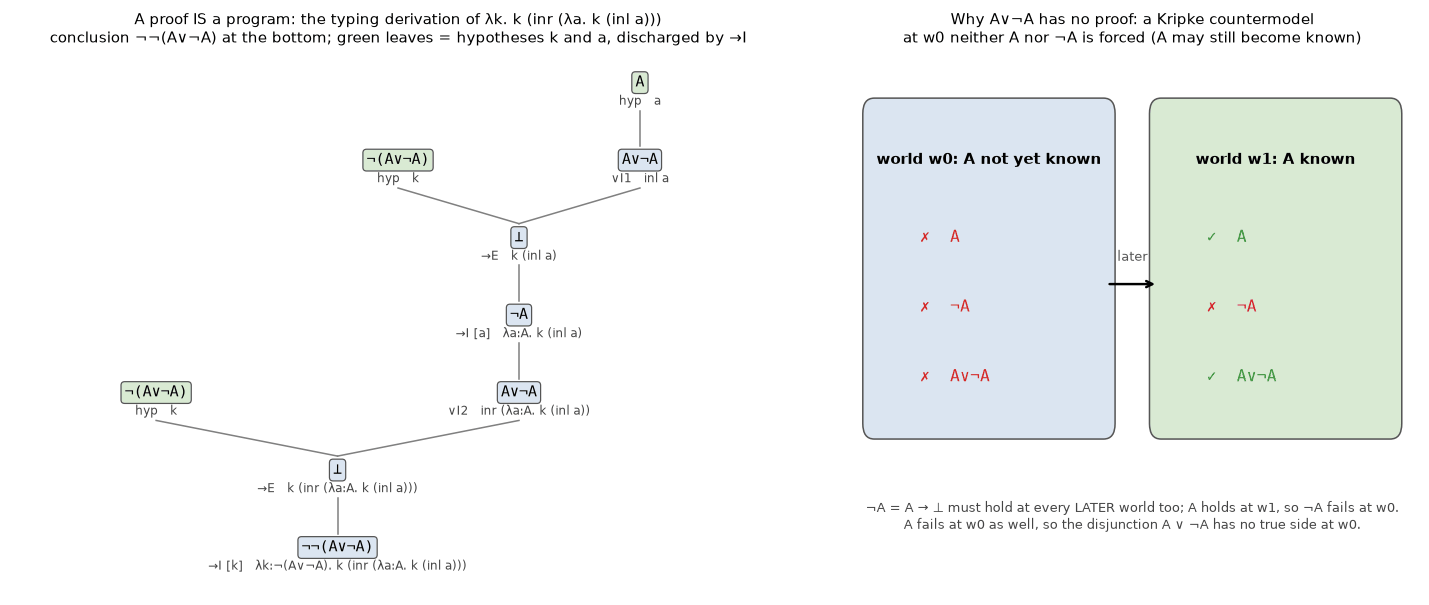

Every typable term's type is forced in every Kripke model (soundness); A∨¬A is not forced at w0,
so NO closed term has type A∨¬A -- while ¬¬(A∨¬A), the left tree, is a one-line program.


In [126]:
# §10.2  Figure: the derivation tree of the ¬¬(A ∨ ¬A) proof term, and why A ∨ ¬A fails at w0.
def _s10_derivation(term, ctx=()):
    '''The typing derivation of a term as a tree: dict(rule, type, term, kids). Reuses typecheck per node.'''
    ty = typecheck(term, ctx)
    if isinstance(term, str):
        return dict(rule="hyp", type=ty, term=term, kids=[])
    tag = term[0]
    if tag == 'lam':
        kids = [_s10_derivation(term[3], ctx + ((term[1], term[2]),))]
    elif tag == 'case':
        s_ty = typecheck(term[1], ctx)
        kids = [_s10_derivation(term[1], ctx), _s10_derivation(term[3], ctx + ((term[2], s_ty[1]),)),
                _s10_derivation(term[5], ctx + ((term[4], s_ty[2]),))]
    elif tag in ('app', 'pair'):
        kids = [_s10_derivation(term[1], ctx), _s10_derivation(term[2], ctx)]
    else:                                                     # fst, snd, inl, inr, absurd: one premise
        kids = [_s10_derivation(term[1], ctx)]
    rule = {'lam': f"→I [{term[1] if tag == 'lam' else ''}]", 'app': "→E", 'pair': "∧I", 'fst': "∧E1",
            'snd': "∧E2", 'inl': "∨I1", 'inr': "∨I2", 'case': "∨E", 'absurd': "⊥E"}[tag]
    return dict(rule=rule, type=ty, term=term, kids=kids)


def _s10_draw_tree(ax, tree, label, color, dy=1.0, fontsize=9.5):
    '''Draw a derivation tree with the conclusion at the BOTTOM (natural-deduction convention).
    label(node) -> (main_text, small_text); color(node) -> fill. Leaves are spaced 1 unit apart.'''
    pos, nxt = {}, [0]
    def place(node, depth):
        for kid in node['kids']:
            place(kid, depth + 1)
        x = nxt[0] if not node['kids'] else np.mean([pos[id(k)][0] for k in node['kids']])
        if not node['kids']:
            nxt[0] += 1
        pos[id(node)] = (x, depth * dy)
    place(tree, 0)
    def draw(node):
        x, y = pos[id(node)]
        for kid in node['kids']:
            kx, ky = pos[id(kid)]
            ax.plot([x, kx], [y + 0.18, ky - 0.36], c="gray", lw=1, zorder=1)
        main, small = label(node)
        ax.text(x, y, main, ha="center", va="center", fontsize=fontsize, family="monospace", zorder=3,
                bbox=dict(boxstyle="round,pad=0.25", fc=color(node), ec="#555555", lw=0.8))
        ax.text(x, y - 0.24, small, ha="center", va="center", fontsize=8, color="#444444", zorder=3)
        for kid in node['kids']:
            draw(kid)
    draw(tree)
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    ax.set_ylim(min(ys) - 0.6, max(ys) + 0.4)
    ax.axis("off")


def _s10_draw_kripke(ax):
    '''The two-world countermodel, with the forcing argument for A, ¬A and A ∨ ¬A written at each world.'''
    f = lambda w, t: _s10_forces(_s10_UP2, _s10_VAL2, w, t)
    mark = lambda b: "✓" if b else "✗"
    for w, x, head in [(0, 0.25, "world w0: A not yet known"), (1, 0.75, "world w1: A known")]:
        ax.add_patch(FancyBboxPatch((x - 0.2, 0.32), 0.4, 0.4, boxstyle="round,pad=0.02",
                                    fc="#dbe5f1" if w == 0 else "#d9ead3", ec="#555555"))
        ax.text(x, 0.66, head, ha="center", va="center", fontsize=9.5, weight="bold")
        for i, t in enumerate(['A', _s10_neg('A'), _s10_EM]):
            ok = f(w, t)
            ax.text(x - 0.12, 0.56 - 0.09 * i, f"{mark(ok)}  {_s10_fmt_type(t)}", ha="left", va="center",
                    fontsize=10.5, family="monospace", color="#2ca02c" if ok else "#d62728")
    ax.annotate("", xy=(0.545, 0.5), xytext=(0.455, 0.5), arrowprops=dict(arrowstyle="->", lw=1.6))
    ax.text(0.5, 0.53, "later", ha="center", fontsize=8.5, color="#555555")
    ax.text(0.5, 0.2, "¬A = A → ⊥ must hold at every LATER world too; A holds at w1, so ¬A fails at w0.\n"
            "A fails at w0 as well, so the disjunction A ∨ ¬A has no true side at w0.",
            ha="center", va="center", fontsize=8.8, color="#444444")
    ax.set_xlim(0, 1); ax.set_ylim(0.1, 0.8); ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw=dict(width_ratios=[1.35, 1]))
_s10_nn_em_term = dict((n, t) for n, _, t in _s10_PROOFS)['nn_em']
_s10_draw_tree(axes[0], _s10_derivation(_s10_nn_em_term),
               label=lambda nd: (_s10_fmt_type(nd['type']), f"{nd['rule']}   {_s10_fmt_term(nd['term'])}"),
               color=lambda nd: "#d9ead3" if nd['rule'] == "hyp" else "#dbe5f1")
axes[0].set_title("A proof IS a program: the typing derivation of λk. k (inr (λa. k (inl a)))\n"
                  "conclusion ¬¬(A∨¬A) at the bottom; green leaves = hypotheses k and a, discharged by →I",
                  fontsize=10)
_s10_draw_kripke(axes[1])
axes[1].set_title("Why A∨¬A has no proof: a Kripke countermodel\n"
                  "at w0 neither A nor ¬A is forced (A may still become known)", fontsize=10)
plt.tight_layout()
plt.show()
print("Every typable term's type is forced in every Kripke model (soundness); A∨¬A is not forced at w0,")
print("so NO closed term has type A∨¬A -- while ¬¬(A∨¬A), the left tree, is a one-line program.")

### 10.3 An LCF kernel: theorems as an abstract type

Proof terms are one way to make proofs checkable. The older way is Milner's **LCF** (Stanford LCF 1972, Edinburgh
LCF 1979, with ML invented as the language to program it in; Turing Award 1991): make `thm` an **abstract type**
whose only constructors are the primitive inference rules. Then arbitrary code — tactics, decision procedures, a
user's script, today an LLM's — may *produce* theorems, but only by calling rules, so a buggy tactic can fail but
cannot produce a false theorem. HOL (Gordon, mid-1980s), HOL Light and Isabelle/Pure are LCF descendants. Our
kernel proves equations between Peano terms; a theorem is a sequent `hyps ⊢ lhs = rhs`, and these ten rules
(named HOL Light style) are the only way to make one:

| rule | premises | conclusion |
|---|---|---|
| `REFL(t)` | — | ⊢ t = t |
| `SYM`, `TRANS` | Γ ⊢ a = b (and Δ ⊢ b = c) | Γ ⊢ b = a; Γ∪Δ ⊢ a = c |
| `CONG_S`, `CONG_ADD` | equal arguments | equal applications of `S` / `add` |
| `ADD_ZERO(t)`, `ADD_SUCC(t, u)` | — | the two defining equations of `add` |
| `ASSUME(l, r)` | — | {l = r} ⊢ l = r (how an induction hypothesis enters) |
| `INST(th, σ)` | Γ ⊢ a = b | Γσ ⊢ aσ = bσ |
| `INDUCT(x, l, r, base, step)` | Γ ⊢ P(Z); Δ ∪ {P(x)} ⊢ P(S x) | Γ ∪ Δ ⊢ P(x), if x is not free in Γ ∪ Δ |

`Thm` is created inside a closure holding a capability token, keeps its fields in `__slots__` and overrides
`__setattr__`/`__delattr__` to refuse assignment; every theorem also carries its derivation as plain data, which
§10.4 needs. The rules compare terms with `==`, so the kernel accepts only terms built from *exact* `str` and
`tuple` values (a subclass could redefine `==`): our stand-in for HOL Light making terms an abstract type too
(`fusion.ml` is the kernel "of types, terms and theorems"). On top sits an **untrusted tactic layer**: a rewriter
that normalizes both sides with the definition, the available lemmas and the induction hypothesis, and an
induction tactic that, when it fails, reports the goal it got stuck on. It can only call rules.

**Registered prediction:** *once `zero_add` is proved, `add_comm` goes through by induction on `n` with no
further lemma.* (The base case `add(m, Z) = add(Z, m)` is exactly `zero_add`, so it looks done.) Every theorem is
then cross-checked numerically on all small values.

In [127]:
# §10.3  An LCF-style kernel for equations between Peano terms.
# Terms: 'Z' | ('S', t) | ('add', t, u) | a variable name (any other string).
# A theorem is a sequent  hyps ⊢ lhs = rhs ; hyps is a frozenset of (lhs, rhs) equations.
def _s10_is_term(t):
    '''Exact built-in str and tuple only. The rules compare terms with ==, and a str or tuple SUBCLASS can
    redefine == (§10.4 tries it): this check is our stand-in for HOL Light's abstract type of terms.'''
    if type(t) is str:
        return True
    return (type(t) is tuple and len(t) in (2, 3) and type(t[0]) is str
            and ((len(t) == 2 and t[0] == 'S' and _s10_is_term(t[1]))
                 or (len(t) == 3 and t[0] == 'add' and _s10_is_term(t[1]) and _s10_is_term(t[2]))))


def _s10_free_vars(t):
    if isinstance(t, str):
        return set() if t == 'Z' else {t}
    return set().union(*(_s10_free_vars(u) for u in t[1:]))


def _s10_subst(t, sigma):
    '''Simultaneous substitution of variables (no binders in this language, so no capture to worry about).'''
    if isinstance(t, str):
        return sigma.get(t, t)
    return (t[0],) + tuple(_s10_subst(u, sigma) for u in t[1:])


def _s10_make_kernel():
    '''Build the kernel inside a closure so the capability token never escapes (or so we hope -- §10.4).'''
    token = object()

    class Thm:
        '''A theorem  hyps ⊢ lhs = rhs. Only the inference rules below can create one.'''
        __slots__ = ('hyps', 'lhs', 'rhs', 'proof')

        def __init__(self, tok, hyps, lhs, rhs, proof):
            if tok is not token:
                raise PermissionError("Thm objects can only be created by the kernel's inference rules")
            for name, value in zip(self.__slots__, (frozenset(hyps), lhs, rhs, proof)):
                object.__setattr__(self, name, value)

        def __setattr__(self, name, value):
            raise PermissionError("theorems are immutable")

        def __delattr__(self, name):
            raise PermissionError("theorems are immutable")

        def __repr__(self):
            hyp = ", ".join(f"{_s10_fmt_peano(l)} = {_s10_fmt_peano(r)}" for l, r in sorted(self.hyps, key=str))
            return f"{hyp + ' ' if hyp else ''}⊢ {_s10_fmt_peano(self.lhs)} = {_s10_fmt_peano(self.rhs)}"

    def thm(rule, args, prems, hyps, lhs, rhs):
        # The proof record is plain data: (rule, args, premise records). This is what §10.4 replays.
        return Thm(token, hyps, lhs, rhs, (rule, args, tuple(p.proof for p in prems)))

    def need(cond, msg):
        if not cond:
            raise ValueError(msg)

    def is_thm(*ths):
        for th in ths:
            need(isinstance(th, Thm), f"premise {th!r} is not a theorem")

    def REFL(t):                                   # ⊢ t = t
        need(_s10_is_term(t), f"not a term: {t!r}")
        return thm('REFL', (t,), (), (), t, t)

    def SYM(th):                                   # Γ ⊢ a = b   gives   Γ ⊢ b = a
        is_thm(th)
        return thm('SYM', (), (th,), th.hyps, th.rhs, th.lhs)

    def TRANS(th1, th2):                           # a = b, b = c   gives   a = c
        is_thm(th1, th2)
        need(th1.rhs == th2.lhs, f"TRANS: middle terms differ: {th1!r} / {th2!r}")
        return thm('TRANS', (), (th1, th2), th1.hyps | th2.hyps, th1.lhs, th2.rhs)

    def CONG_S(th):                                # a = b   gives   S a = S b
        is_thm(th)
        return thm('CONG_S', (), (th,), th.hyps, ('S', th.lhs), ('S', th.rhs))

    def CONG_ADD(th1, th2):                        # a = b, c = d   gives   add(a, c) = add(b, d)
        is_thm(th1, th2)
        return thm('CONG_ADD', (), (th1, th2), th1.hyps | th2.hyps,
                   ('add', th1.lhs, th2.lhs), ('add', th1.rhs, th2.rhs))

    def ADD_ZERO(t):                               # definition, equation 1:  ⊢ add(t, Z) = t
        need(_s10_is_term(t), f"not a term: {t!r}")
        return thm('ADD_ZERO', (t,), (), (), ('add', t, 'Z'), t)

    def ADD_SUCC(t, u):                            # definition, equation 2:  ⊢ add(t, S u) = S(add(t, u))
        need(_s10_is_term(t) and _s10_is_term(u), "not a term")
        return thm('ADD_SUCC', (t, u), (), (), ('add', t, ('S', u)), ('S', ('add', t, u)))

    def ASSUME(l, r):                              # {l = r} ⊢ l = r   (how an induction hypothesis enters)
        need(_s10_is_term(l) and _s10_is_term(r), "not a term")
        return thm('ASSUME', (l, r), (), {(l, r)}, l, r)

    def INST(th, sigma):                           # instantiate free variables everywhere (sound: no binders)
        is_thm(th)
        need(type(sigma) is dict and all(type(v) is str and v != 'Z' and _s10_is_term(t)
                                         for v, t in sigma.items()), "bad sigma")
        sigma = dict(sigma)                        # a private copy: the caller cannot change it halfway
        hyps = {(_s10_subst(l, sigma), _s10_subst(r, sigma)) for l, r in th.hyps}
        return thm('INST', (tuple(sorted(sigma.items())),), (th,), hyps,
                   _s10_subst(th.lhs, sigma), _s10_subst(th.rhs, sigma))

    def INDUCT(x, l, r, base, step):               # P(Z) and P(x) ⊢ P(S x)   give   P(x)  for P := (l = r)
        is_thm(base, step)
        need(type(x) is str and x != 'Z', "induction variable must be a variable")
        need(_s10_is_term(l) and _s10_is_term(r), "not a term")
        need((base.lhs, base.rhs) == (_s10_subst(l, {x: 'Z'}), _s10_subst(r, {x: 'Z'})), "base case mismatch")
        need((step.lhs, step.rhs) == (_s10_subst(l, {x: ('S', x)}), _s10_subst(r, {x: ('S', x)})),
             "step case mismatch")
        rest = base.hyps | (step.hyps - {(l, r)})            # discharge the induction hypothesis
        need(all(x not in _s10_free_vars(a) | _s10_free_vars(b) for a, b in rest),
             f"{x} is free in an open hypothesis: cannot generalize over it")
        return thm('INDUCT', (x, l, r), (base, step), rest, l, r)

    return Thm, REFL, SYM, TRANS, CONG_S, CONG_ADD, ADD_ZERO, ADD_SUCC, ASSUME, INST, INDUCT


Thm, REFL, SYM, TRANS, CONG_S, CONG_ADD, ADD_ZERO, ADD_SUCC, ASSUME, INST, INDUCT = _s10_make_kernel()


def _s10_fmt_peano(t):
    if isinstance(t, str):
        return t
    if t[0] == 'S':
        return f"S {_s10_fmt_peano(t[1])}" if isinstance(t[1], str) else f"S({_s10_fmt_peano(t[1])})"
    return f"add({_s10_fmt_peano(t[1])}, {_s10_fmt_peano(t[2])})"


def _s10_proof_size(rec):
    return 1 + sum(_s10_proof_size(p) for p in rec[2])


# --- Hand-written proofs: the definitional direction is one rule; the other needs induction -----------
_s10_add_zero = ADD_ZERO('m')                                                    # ⊢ add(m, Z) = m
_s10_zero_add = INDUCT('n', ('add', 'Z', 'n'), 'n',
                       ADD_ZERO('Z'),                                            # base: add(Z, Z) = Z
                       TRANS(ADD_SUCC('Z', 'n'),                                 # add(Z, S n) = S(add(Z, n))
                             CONG_S(ASSUME(('add', 'Z', 'n'), 'n'))))            #            = S n   (by IH)
print("add_zero:", _s10_add_zero, f"   [{_s10_proof_size(_s10_add_zero.proof)} rule application]")
print("zero_add:", _s10_zero_add, f"   [{_s10_proof_size(_s10_zero_add.proof)} rule applications]")
print("The definitional direction is one rule; its mirror image needs INDUCT, with the hypothesis entering by ASSUME.")

add_zero: ⊢ add(m, Z) = m    [1 rule application]
zero_add: ⊢ add(Z, n) = n    [6 rule applications]
The definitional direction is one rule; its mirror image needs INDUCT, with the hypothesis entering by ASSUME.


Writing every proof rule by rule does not scale. The next cell adds an *untrusted* tactic layer on top of the
kernel — a rewriter and an induction tactic that can only call the ten rules — and runs the registered prediction:
can it prove `add_comm` from `zero_add` alone?

In [128]:
# §10.3  A tiny UNTRUSTED tactic layer: rewrite both sides to normal form, then induct.
# Tactics are ordinary code that call the rules; a buggy tactic can fail, but never produce a false Thm.
_s10_MAX_REWRITES = 500


def _s10_match(pat, t, pvars, sigma):
    '''First-order matching of pattern pat against term t; pattern variables in pvars.'''
    if isinstance(pat, str) and pat in pvars:
        if pat in sigma:
            return sigma if sigma[pat] == t else None
        return {**sigma, pat: t}
    if isinstance(pat, str) or isinstance(t, str):
        return sigma if pat == t else None
    if pat[0] != t[0] or len(pat) != len(t):
        return None
    for p_sub, t_sub in zip(pat[1:], t[1:]):
        sigma = _s10_match(p_sub, t_sub, pvars, sigma)
        if sigma is None:
            return None
    return sigma


def _s10_rewrite_root(t, rules):
    '''One rewrite step at the root: the two defining equations first, then the given lemmas / hypotheses.'''
    if isinstance(t, tuple) and t[0] == 'add' and t[2] == 'Z':
        return ADD_ZERO(t[1])
    if isinstance(t, tuple) and t[0] == 'add' and isinstance(t[2], tuple) and t[2][0] == 'S':
        return ADD_SUCC(t[1], t[2][1])
    for th, pvars in rules:
        sigma = _s10_match(th.lhs, t, pvars, {})
        if sigma is not None:
            return INST(th, sigma) if pvars else th
    return None


def _s10_normalize(t, rules, budget):
    '''Return a theorem  ⊢ t = nf  with nf in normal form (innermost-first rewriting).'''
    if isinstance(t, str):
        return REFL(t)
    kids = [_s10_normalize(u, rules, budget) for u in t[1:]]
    th = CONG_S(*kids) if t[0] == 'S' else CONG_ADD(*kids)
    step = _s10_rewrite_root(th.rhs, rules)
    if step is None or budget[0] <= 0:
        return th
    budget[0] -= 1
    return TRANS(TRANS(th, step), _s10_normalize(step.rhs, rules, budget))


def _s10_simp(l, r, rules):
    '''Try to prove l = r by normalizing both sides. Returns (Thm, None) or (None, (nf_l, nf_r)).'''
    tl, tr = (_s10_normalize(x, rules, [_s10_MAX_REWRITES]) for x in (l, r))
    if tl.rhs == tr.rhs:
        return TRANS(tl, SYM(tr)), None
    return None, (tl.rhs, tr.rhs)


def _s10_induction(x, l, r, lemmas=()):
    '''Induction on x, both cases by _s10_simp. Lemmas are hypothesis-free Thms used as rewrite rules
    (their free variables are pattern variables); the IH is used rigidly. Returns (Thm, None) or (None, stuck).'''
    rules = [(th, _s10_free_vars(th.lhs) | _s10_free_vars(th.rhs)) for th in lemmas]
    base, stuck = _s10_simp(_s10_subst(l, {x: 'Z'}), _s10_subst(r, {x: 'Z'}), rules)
    if base is None:
        return None, ('base case', stuck)
    ih = ASSUME(l, r)
    step, stuck = _s10_simp(_s10_subst(l, {x: ('S', x)}), _s10_subst(r, {x: ('S', x)}), rules + [(ih, set())])
    if step is None:
        return None, ('step case', stuck)
    return INDUCT(x, l, r, base, step), None


_s10_COMM = (('add', 'm', 'n'), ('add', 'n', 'm'))
_s10_add_comm, _s10_stuck = _s10_induction('n', *_s10_COMM, lemmas=[_s10_zero_add])
_s10_stuck_case, (_s10_nf_l, _s10_nf_r) = _s10_stuck
print(f"\nadd_comm by induction on n, with zero_add available: STUCK in the {_s10_stuck_case}")
print(f"   goal after rewriting both sides:  {_s10_fmt_peano(_s10_nf_l)}  =?=  {_s10_fmt_peano(_s10_nf_r)}")
print(f"   no rule applies to {_s10_fmt_peano(_s10_nf_r)}: add recurses on its SECOND argument, "
      "and that is the variable m")
print("registered prediction: with zero_add proved, add_comm goes through by induction with no further lemma | "
      f"measured: {'proved' if _s10_add_comm else 'stuck at ' + _s10_fmt_peano(_s10_nf_r)} | verdict: "
      f"{'RIGHT' if _s10_add_comm else 'WRONG'} -- the missing fact add(S n, m) = S(add(n, m)) must be invented")

# The creative step: state the lemma (Lean calls it Nat.succ_add), prove it by its own induction, retry.
_s10_SUCC_ADD = (('add', ('S', 'm'), 'n'), ('S', ('add', 'm', 'n')))
_s10_succ_add, _ = _s10_induction('n', *_s10_SUCC_ADD)
_s10_add_comm, _ = _s10_induction('n', *_s10_COMM, lemmas=[_s10_zero_add, _s10_succ_add])
_s10_ASSOC = (('add', ('add', 'm', 'k'), 'n'), ('add', 'm', ('add', 'k', 'n')))
_s10_add_assoc, _ = _s10_induction('n', *_s10_ASSOC)          # induct on the recursive argument: no lemma needed
_s10_THEOREMS = {'add_zero': _s10_add_zero, 'zero_add': _s10_zero_add, 'succ_add': _s10_succ_add,
                 'add_comm': _s10_add_comm, 'add_assoc': _s10_add_assoc}


def _s10_eval_peano(t, env):
    if isinstance(t, str):
        return 0 if t == 'Z' else env[t]
    if t[0] == 'S':
        return _s10_eval_peano(t[1], env) + 1
    return _s10_eval_peano(t[1], env) + _s10_eval_peano(t[2], env)


def _s10_numeric_check(th, top=8):
    '''Oracle: evaluate both sides as ordinary integers for every assignment of the free variables in 0..top.'''
    vs = sorted(_s10_free_vars(th.lhs) | _s10_free_vars(th.rhs))
    envs = [dict(zip(vs, vals)) for vals in itertools.product(range(top + 1), repeat=len(vs))]
    passed = sum(_s10_eval_peano(th.lhs, e) == _s10_eval_peano(th.rhs, e) for e in envs)
    return f"{passed}/{len(envs)}"


_s10_rows = [[name, repr(th), len(th.hyps), _s10_proof_size(th.proof), _s10_numeric_check(th)]
             for name, th in _s10_THEOREMS.items()]
show_table(["theorem", "statement", "open hyps", "proof size (rule applications)", "numeric check 0..8"],
           _s10_rows)
print("add_comm needed TWO invented lemmas (zero_add, succ_add); add_assoc needed none -- it inducts on the")
print("argument add recurses on. Choosing the induction variable and the lemmas is the human (or LLM) part.")


add_comm by induction on n, with zero_add available: STUCK in the step case
   goal after rewriting both sides:  S(add(n, m))  =?=  add(S n, m)
   no rule applies to add(S n, m): add recurses on its SECOND argument, and that is the variable m
registered prediction: with zero_add proved, add_comm goes through by induction with no further lemma | measured: stuck at add(S n, m) | verdict: WRONG -- the missing fact add(S n, m) = S(add(n, m)) must be invented
theorem    statement                                open hyps  proof size (rule applications)  numeric check 0..8
-----------------------------------------------------------------------------------------------------------------
add_zero   ⊢ add(m, Z) = m                          0          1                               9/9               
zero_add   ⊢ add(Z, n) = n                          0          6                               9/9               
succ_add   ⊢ add(S m, n) = S(add(m, n))             0          54                   

The figure draws `zero_add` as the tree the kernel actually recorded — each node is re-run through the kernel's
rules to recover its conclusion — and the loop `add_comm` went through: stuck, lemma invented, retried.

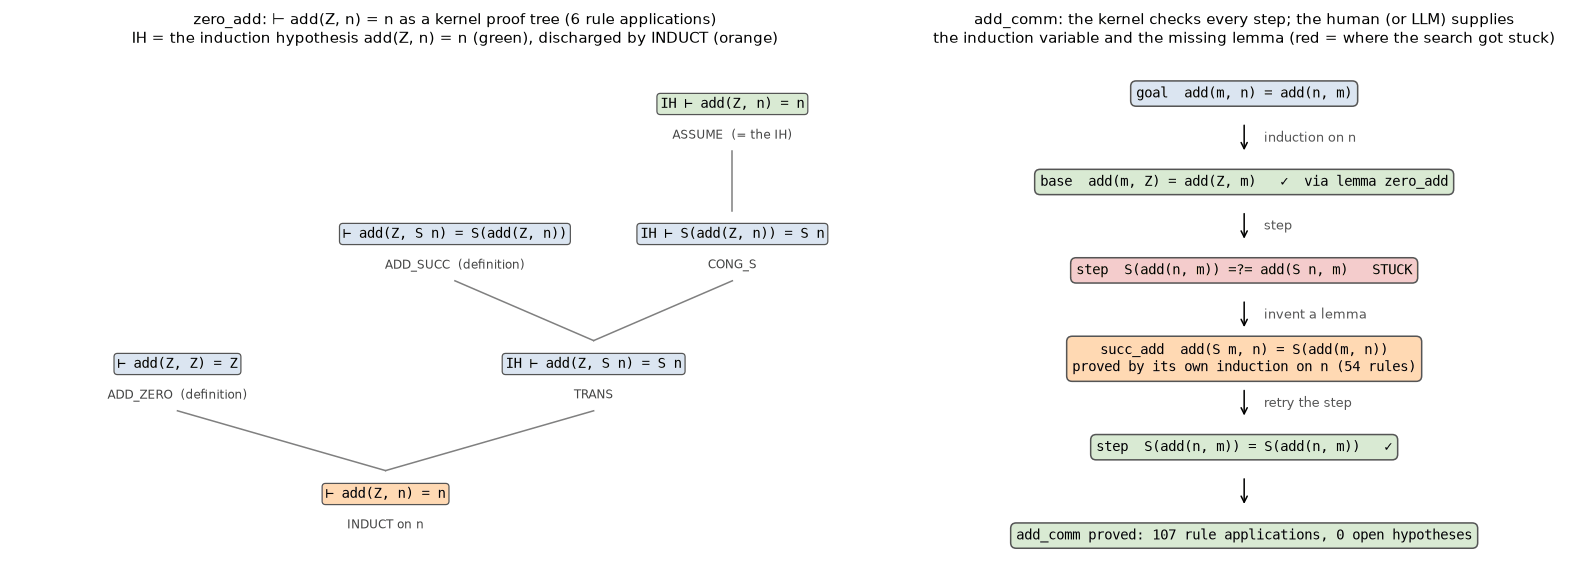

The tree is the proof object itself: every node is one kernel rule. Whether anything else can make a Thm
in Python is the next question.


In [129]:
# §10.3  Figure: the induction proof of zero_add as a tree, and the lemma-invention loop behind add_comm.
_s10_RULE_LABEL = {'ADD_ZERO': 'ADD_ZERO  (definition)', 'ADD_SUCC': 'ADD_SUCC  (definition)',
                   'ASSUME': 'ASSUME  (= the IH)'}


def _s10_rebuild(rec):
    '''Re-run a proof record through the KERNEL's rule functions; returns the Thm it denotes.'''
    rule, args, prems = rec
    P = [_s10_rebuild(p) for p in prems]
    if rule == 'INST':
        return INST(P[0], dict(args[0]))
    fn = {'REFL': REFL, 'SYM': SYM, 'TRANS': TRANS, 'CONG_S': CONG_S, 'CONG_ADD': CONG_ADD, 'ADD_ZERO': ADD_ZERO,
          'ADD_SUCC': ADD_SUCC, 'ASSUME': ASSUME, 'INDUCT': INDUCT}[rule]
    return fn(*args, *P)


def _s10_proof_tree(rec):
    '''The proof record itself as a drawable tree: one node per rule application, with its conclusion.'''
    rule, args = rec[0], rec[1]
    label = f"INDUCT on {args[0]}" if rule == 'INDUCT' else _s10_RULE_LABEL.get(rule, rule)
    return dict(rule=label, thm=_s10_rebuild(rec), kids=[_s10_proof_tree(p) for p in rec[2]])


_s10_tree = _s10_proof_tree(_s10_zero_add.proof)


def _s10_thm_label(nd):
    th = nd['thm']
    return ("IH " if th.hyps else "") + "⊢ " + repr(th).split("⊢ ")[1], nd['rule']


def _s10_thm_color(nd):
    r = nd['rule']
    return "#ffd9b3" if r.startswith('INDUCT') else "#d9ead3" if r.startswith('ASSUME') else "#dbe5f1"


fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.4), gridspec_kw=dict(width_ratios=[1.35, 1]))
_s10_draw_tree(axes[0], _s10_tree, _s10_thm_label, _s10_thm_color, fontsize=9)
axes[0].set_title(f"zero_add: ⊢ add(Z, n) = n as a kernel proof tree "
                  f"({_s10_proof_size(_s10_zero_add.proof)} rule applications)\n"
                  "IH = the induction hypothesis add(Z, n) = n (green), discharged by INDUCT (orange)",
                  fontsize=10)
ax = axes[1]
_s10_FLOW = [
    ("goal  add(m, n) = add(n, m)", "#dbe5f1", "induction on n"),
    ("base  add(m, Z) = add(Z, m)   ✓  via lemma zero_add", "#d9ead3", "step"),
    (f"step  {_s10_fmt_peano(_s10_nf_l)} =?= {_s10_fmt_peano(_s10_nf_r)}   STUCK", "#f4cccc", "invent a lemma"),
    ("succ_add  add(S m, n) = S(add(m, n))\nproved by its own induction on n "
     f"({_s10_proof_size(_s10_succ_add.proof)} rules)", "#ffd9b3", "retry the step"),
    (f"step  {_s10_fmt_peano(_s10_nf_l)} = {_s10_fmt_peano(_s10_nf_l)}   ✓", "#d9ead3", ""),
    (f"add_comm proved: {_s10_proof_size(_s10_add_comm.proof)} rule applications, "
     f"{len(_s10_add_comm.hyps)} open hypotheses",
     "#d9ead3", None),
]


def _s10_draw_flow(ax, steps):
    '''A vertical flow of (text, fill, label of the arrow to the next box) boxes.'''
    ys = np.linspace(0.92, 0.07, len(steps))
    for (txt, fc, arrow), y, y_next in zip(steps, ys, list(ys[1:]) + [None]):
        ax.text(0.5, y, txt, ha="center", va="center", fontsize=9, family="monospace",
                bbox=dict(boxstyle="round,pad=0.4", fc=fc, ec="#555555"))
        if y_next is not None:
            ax.annotate("", xy=(0.5, y_next + 0.055), xytext=(0.5, y - 0.055), arrowprops=dict(arrowstyle="->"))
            ax.text(0.53, (y + y_next) / 2, arrow, fontsize=8.5, color="#555555", va="center")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")


_s10_draw_flow(ax, _s10_FLOW)
ax.set_title("add_comm: the kernel checks every step; the human (or LLM) supplies\n"
             "the induction variable and the missing lemma (red = where the search got stuck)", fontsize=10)
plt.tight_layout()
plt.show()
print("The tree is the proof object itself: every node is one kernel rule. Whether anything else can make a Thm\n"
      "in Python is the next question.")

### 10.4 Forging a theorem, and the de Bruijn criterion

LCF's guarantee — "the only way to make a `thm` is through the rules" — is enforced by the **host language**:
ML's module system makes `thm` genuinely abstract. Python has no abstract types; every object, class and closure
is introspectable. **Registered prediction:** *the capability token in a closure plus `__slots__` and a refusing
`__setattr__` make `Thm` unforgeable from outside the kernel.* The attack cell below (after the checker is built)
tries three attacks through the front door (the public API, one of them feeding the rules a `str` subclass whose
`==` always says yes) and four through the back door (introspection), and builds on any `Thm` they produce with
the kernel's own genuine rules.

The alternative is the **de Bruijn criterion**, which Barendregt states as "have a small checker"
([slides](https://ftp.science.ru.nl/CSI/CompMath.Found/mri.pdf); Barendregt & Wiedijk, Phil. Trans. R. Soc. A,
2005): keep the proof as an explicit object and accept a theorem only if a *small, independent* program
re-derives it. Trust then depends on what the object *is*, not on who produced it — a forger, a buggy tactic, an
LLM. Our `replay_check(thm)` exports the theorem as text — its claimed sequent *and* its proof record, built only
from exact built-in `str` and `tuple` values — parses the text back as pure data with `ast.literal_eval`,
re-derives the conclusion with a second, separately written implementation of the ten rules, and compares. The
attack cell also runs the **first version** of `replay_check`, which sent only the proof across as text and
compared the result with the claim read straight off the object. Our checker shares a process with any attacker,
who could simply rebind `replay_check`; real independent checkers are separate programs reading an exported proof
file (§10.6), which the text round trip imitates.

In [130]:
# §10.4  The de Bruijn alternative: an independent checker that re-derives the exported proof object.
def _s10_rp_replay(rec):
    '''An INDEPENDENT re-implementation of the 10 rules over plain data (it calls nothing from the kernel).
    Returns the derived (hyps, lhs, rhs) or raises ValueError / TypeError.'''
    def ok(cond, msg):
        if not cond:
            raise ValueError(f"{rec[0]}: {msg}")
    def term(t):
        ok(isinstance(t, str) or (isinstance(t, tuple) and ((len(t) == 2 and t[0] == 'S')
           or (len(t) == 3 and t[0] == 'add')) and all(term(u) for u in t[1:])), f"not a term {t!r}")
        return True
    def sub(t, s):
        return s.get(t, t) if isinstance(t, str) else (t[0],) + tuple(sub(u, s) for u in t[1:])
    def fv(t):
        return ({t} - {'Z'}) if isinstance(t, str) else set().union(*(fv(u) for u in t[1:]))
    rule, args, prems = rec
    P = [_s10_rp_replay(p) for p in prems]
    arity = {'REFL': (1, 0), 'SYM': (0, 1), 'TRANS': (0, 2), 'CONG_S': (0, 1), 'CONG_ADD': (0, 2),
             'ADD_ZERO': (1, 0), 'ADD_SUCC': (2, 0), 'ASSUME': (2, 0), 'INST': (1, 1), 'INDUCT': (3, 2)}
    ok(rule in arity and arity[rule] == (len(args), len(P)), "unknown rule or wrong arity")
    if rule in ('REFL', 'ADD_ZERO', 'ADD_SUCC', 'ASSUME'):
        all(term(t) for t in args)
    E = frozenset()
    if rule == 'REFL':
        return E, args[0], args[0]
    if rule == 'SYM':
        return P[0][0], P[0][2], P[0][1]
    if rule == 'TRANS':
        ok(P[0][2] == P[1][1], "middle terms differ")
        return P[0][0] | P[1][0], P[0][1], P[1][2]
    if rule == 'CONG_S':
        return P[0][0], ('S', P[0][1]), ('S', P[0][2])
    if rule == 'CONG_ADD':
        return P[0][0] | P[1][0], ('add', P[0][1], P[1][1]), ('add', P[0][2], P[1][2])
    if rule == 'ADD_ZERO':
        return E, ('add', args[0], 'Z'), args[0]
    if rule == 'ADD_SUCC':
        return E, ('add', args[0], ('S', args[1])), ('S', ('add', args[0], args[1]))
    if rule == 'ASSUME':
        return frozenset({(args[0], args[1])}), args[0], args[1]
    if rule == 'INST':
        s = dict(args[0])
        ok(all(isinstance(v, str) and v != 'Z' and term(t) for v, t in s.items()), "bad substitution")
        return frozenset((sub(l, s), sub(r, s)) for l, r in P[0][0]), sub(P[0][1], s), sub(P[0][2], s)
    x, l, r = args                                           # INDUCT
    ok(isinstance(x, str) and x != 'Z' and term(l) and term(r), "bad induction statement")
    ok(P[0][1:] == (sub(l, {x: 'Z'}), sub(r, {x: 'Z'})), "base case does not match")
    ok(P[1][1:] == (sub(l, {x: ('S', x)}), sub(r, {x: ('S', x)})), "step case does not match")
    rest = P[0][0] | (P[1][0] - {(l, r)})
    ok(all(x not in fv(a) | fv(b) for a, b in rest), "induction variable free in an open hypothesis")
    return rest, l, r


def _s10_plain(x):
    '''Copy x using exact built-in str and tuple only. A SUBCLASS is refused: it can redefine ==, hash, repr and
    str, so it could mean one thing to the checker and print as another.'''
    if type(x) is str:
        return x
    if type(x) is tuple:
        return tuple(_s10_plain(u) for u in x)
    raise TypeError(f"not plain data: {type(x).__name__}")


def _s10_export(thm):
    '''Producer side of the boundary: the claimed sequent AND its proof, as one string of plain data.'''
    if type(thm.hyps) is not frozenset:
        raise TypeError("hypotheses are not a plain frozenset")
    hyps = tuple(sorted((_s10_plain(h) for h in thm.hyps), key=repr))
    return repr((hyps, _s10_plain(thm.lhs), _s10_plain(thm.rhs), _s10_plain(thm.proof)))


def _s10_check_text(text):
    '''Checker side: it sees only the string. Parse it as pure data, re-derive the conclusion, compare.'''
    hyps, lhs, rhs, proof = ast.literal_eval(text)
    derived = _s10_rp_replay(proof)
    return derived == (frozenset(hyps), lhs, rhs), derived


_s10_REPLAY_ERRORS = (ValueError, TypeError, KeyError, IndexError, AttributeError, SyntaxError, RecursionError)


def _s10_replay_verdict(thm):
    '''(accepted?, reason) for replay_check: everything the checker sees crosses the boundary as text.'''
    try:
        ok, derived = _s10_check_text(_s10_export(thm))
    except _s10_REPLAY_ERRORS as err:
        return False, f"{type(err).__name__}: {str(err)[:40]}"
    if not ok:
        return False, f"derivation proves {_s10_fmt_peano(derived[1])} = {_s10_fmt_peano(derived[2])}"
    return True, "re-derived"


def replay_check(thm):
    '''de Bruijn criterion: accept a theorem only if an independent checker re-derives it from its proof object.'''
    return _s10_replay_verdict(thm)[0]


def _s10_replay_v1(thm):
    '''The FIRST version of replay_check, kept for comparison: the proof crosses the boundary as text, but the
    claim it is compared with is read straight off the object.'''
    try:
        derived = _s10_rp_replay(ast.literal_eval(repr(thm.proof)))
    except _s10_REPLAY_ERRORS:
        return False
    return derived == (frozenset(thm.hyps), thm.lhs, thm.rhs)


print(f"what crosses the boundary for add_zero: {_s10_export(_s10_add_zero)}")
print(f"replay_check re-derives {sum(replay_check(th) for th in _s10_THEOREMS.values())}/{len(_s10_THEOREMS)} "
      "genuine theorems from their exported text alone.")

what crosses the boundary for add_zero: ((), ('add', 'm', 'Z'), 'm', ('ADD_ZERO', ('m',), ()))
replay_check re-derives 5/5 genuine theorems from their exported text alone.


Now the attacks: three through the front door, four through the back, and, if any of them yields a `Thm`, one
that feeds it to the kernel's genuine `TRANS`. The first table says what the LCF guard did with each attack; the
second puts every `Thm` the attacks produced through both versions of the replay checker.

In [131]:
# §10.4  The attacks, against the LCF guard and against both replay checkers.
class _s10_Liar(str):
    '''A string that prints as itself but claims to be equal to everything.'''
    def __eq__(self, other):
        return True

    def __ne__(self, other):
        return False

    __hash__ = str.__hash__


_s10_ONE = ('S', 'Z')


def _s10_attack_assign():
    th = REFL('Z')
    th.rhs = _s10_ONE                                         # goes through Thm.__setattr__
    return th


def _s10_forge_new(rhs=_s10_ONE):
    fake = object.__new__(Thm)                                # allocate without running __init__
    for slot, v in zip(Thm.__slots__, (frozenset(), 'Z', rhs, ('REFL', ('Z',), ()))):
        object.__setattr__(fake, slot, v)                     # bypass Thm.__setattr__
    return fake


def _s10_forge_mutate():
    th = REFL('Z')                                            # a genuine theorem  ⊢ Z = Z ...
    object.__setattr__(th, 'rhs', _s10_ONE)                   # ... edited in place to ⊢ Z = S Z
    return th


def _s10_forge_token():
    cells = dict(zip(Thm.__init__.__code__.co_freevars, (c.cell_contents for c in Thm.__init__.__closure__)))
    return Thm(cells['token'], (), 'Z', _s10_ONE, ('ADD_ZERO', ('Z',), ()))   # the "secret" read from the closure


_s10_ATTACKS = [   # (door, attack, function returning the would-be theorem)
    ("front", "call Thm(...) without the token", lambda: Thm(None, (), 'Z', _s10_ONE, None)),
    ("front", "assign th.rhs on a real theorem", _s10_attack_assign),
    ("front", "rules fed a str whose == says yes", lambda: TRANS(ADD_ZERO('Z'), REFL(_s10_Liar('S Z')))),
    ("back", "object.__new__ + object.__setattr__", _s10_forge_new),
    ("back", "object.__setattr__ on a genuine Thm", _s10_forge_mutate),
    ("back", "token read from Thm.__init__.__closure__", _s10_forge_token),
    ("back", "object.__new__ with a lying str as rhs", lambda: _s10_forge_new(_s10_Liar('S Z'))),
]
_s10_FALSE = "⊢ Z = S Z"


def _s10_run_attacks():
    '''Run every attack; returns {name: (door, Thm or None, what the LCF guard said)}.'''
    results = {}
    for door, name, attack in _s10_ATTACKS:
        try:
            th = attack()
            results[name] = (door, th, f"FORGED: {th!r}" if isinstance(th, Thm) else "no Thm produced")
        except Exception as err:                              # any failure means: no Thm was produced
            results[name] = (door, None, f"blocked: {str(err)[:64]}")
    forged = results.get("object.__new__ + object.__setattr__", (None, None))[1]
    if isinstance(forged, Thm):   # the kernel's own rules build on a forgery: add(Z, Z) = Z and Z = S Z
        th = TRANS(ADD_ZERO('Z'), forged)
        results["genuine TRANS on that forgery"] = ("rules", th, f"FORGED: {th!r}")
    return results


_s10_results = _s10_run_attacks()
_s10_FORGED = {name: th for name, (_, th, _) in _s10_results.items() if isinstance(th, Thm)}
show_table(["door", "attack", "LCF guard (token + __slots__)"],
           [[door, name, guard] for name, (door, th, guard) in _s10_results.items()])
print()
show_table(["Thm produced by", "first replay (claim off object)", "replay_check (all as text)"],
           [[name, "ACCEPTED" if _s10_replay_v1(th) else "rejected",
             "accepted" if replay_check(th) else "rejected: " + _s10_replay_verdict(th)[1]]
            for name, th in _s10_FORGED.items()])

_s10_front = [n for n, (d, _, _) in _s10_results.items() if d == "front"]
_s10_back = [n for n, (d, _, _) in _s10_results.items() if d == "back"]
_s10_front_blocked = sum(not isinstance(_s10_results[n][1], Thm) for n in _s10_front)
_s10_n_forged = sum(isinstance(_s10_results[n][1], Thm) and repr(_s10_results[n][1]) == _s10_FALSE
                    for n in _s10_back)
_s10_genuine_ok = sum(replay_check(th) for th in _s10_THEOREMS.values())
_s10_forged_rejected = sum(not replay_check(th) for th in _s10_FORGED.values())
_s10_v1_fooled = [n for n, th in _s10_FORGED.items() if _s10_replay_v1(th)]
print(f"\nwhy the kernel insists on exact str: 'Z' == _s10_Liar('S Z') is {'Z' == _s10_Liar('S Z')} "
      "(Python lets the subclass answer first), so a TRANS comparing such terms would chain Z to S Z")
print(f"genuine theorems re-derived by replay_check: {_s10_genuine_ok}/{len(_s10_THEOREMS)};  forgeries rejected: "
      f"{_s10_forged_rejected}/{len(_s10_FORGED)};  the first version accepted {len(_s10_v1_fooled)} "
      f"({', '.join(_s10_v1_fooled) or 'none'})")
print(f"registered prediction: a capability token in a closure plus __slots__ and a refusing __setattr__ make Thm "
      f"unforgeable | measured: {_s10_front_blocked}/{len(_s10_front)} front-door attacks blocked, "
      f"{_s10_n_forged}/{len(_s10_back)} back-door attacks produced a Thm printing {_s10_FALSE} | verdict: "
      f"{'RIGHT' if _s10_n_forged == 0 and _s10_front_blocked == len(_s10_front) else 'WRONG'}"
      + (" -- LCF's guarantee is a property of the host language's type system, and Python has none"
         if _s10_n_forged else ""))

door   attack                                    LCF guard (token + __slots__)                                           
-------------------------------------------------------------------------------------------------------------------------
front  call Thm(...) without the token           blocked: Thm objects can only be created by the kernel's inference rules
front  assign th.rhs on a real theorem           blocked: theorems are immutable                                         
front  rules fed a str whose == says yes         blocked: not a term: 'S Z'                                              
back   object.__new__ + object.__setattr__       FORGED: ⊢ Z = S Z                                                       
back   object.__setattr__ on a genuine Thm       FORGED: ⊢ Z = S Z                                                       
back   token read from Thm.__init__.__closure__  FORGED: ⊢ Z = S Z                                                       
back   object.__new__ wi

**Kept failure.** The prediction is wrong. The front door holds: the three attacks through the public API are
blocked, the lying `str` included, because the rules accept only exact `str` and `tuple` terms. The back door
does not: each of the four introspection attacks produces a `Thm` that prints `⊢ Z = S Z`, and the kernel's own
`TRANS` builds on one as if it were genuine. The token, `__slots__` and the refusing `__setattr__` guard only
the public API; `object.__new__`, `object.__setattr__` and a closure's `__closure__` go around all three. LCF's
guarantee is a property of the host language's type system, and Python has none. (ML is not immune either:
OCaml's `Obj.magic` is an explicit unsafe cast, so LCF soundness is relative to nobody using it.)

The de Bruijn check catches every forgery the attacks produced, because each one's derivation proves something
other than its claim, or is not plain data at all. The **first version** of `replay_check` is a kept failure of
its own: the forgery with a lying `str` as its right-hand side beats it, because it re-derived the proof from text
but compared the result with the claim read straight off the object, whose right-hand side answers every `==`
with yes. The *statement* is untrusted data too. In a proof assistant the statement you rely on is the one in your own source
file; what a proof producer says it proved is just more data (§13's misformalized benchmarks are the human side
of the same gap).

An attack table tests the checker on a handful of chosen inputs. The next cell tests it on thousands: a
**differential fuzz** builds random derivation records, valid and invalid alike, and runs each through both
implementations of the rules — the kernel and the independent replay. They must accept and reject the same
records (a rejected `INDUCT` for the same reason) and agree on every conclusion, and every accepted theorem must
hold as ordinary arithmetic. A plain random generator rarely exercises the one rule with real side
conditions: an `INDUCT` it builds is usually rejected or *vacuous* (the induction variable does not occur in $P$,
so base and step prove the same equation), and the first output line measures how rarely. The main run therefore
biases the generator toward real inductions. Its pool starts from the four one-rule theorems plus every
sub-derivation of §10.3's proofs; `ASSUME` often assumes an equation the pool has already derived (a candidate
induction hypothesis); and half of the `INDUCT` records are built on a pool entry of the form
$\Gamma \vdash P(S\,x)$ whose hypotheses $\Gamma$ include $P(x)$, so that accepting it means discharging the
hypothesis and checking that $x$ is free in nothing that remains.

In [132]:
# §10.4  Differential fuzz: random derivation records through the KERNEL and through the independent replay.
_s10_FUZZ_SEED = 1004
_s10_FUZZ_STEPS = 20_000
_s10_FUZZ_VARS = ('m', 'n', 'k')
_s10_FUZZ_MAX_PROOF = 60                     # only small derivations go back into the pool (keeps replay cheap)
_s10_FUZZ_P_IH = 0.5                         # share of INDUCT records built on a step that carries its own P(x)


def _s10_random_peano(rnd, depth):
    if depth == 0 or rnd.random() < 0.35:
        return rnd.choice(_s10_FUZZ_VARS + ('Z',))
    if rnd.random() < 0.4:
        return ('S', _s10_random_peano(rnd, depth - 1))
    return ('add', _s10_random_peano(rnd, depth - 1), _s10_random_peano(rnd, depth - 1))


def _s10_holds(hyps, lhs, rhs, top=3):
    '''Arithmetic oracle: whenever every hypothesis holds (all variables in 0..top), lhs = rhs holds too.'''
    vs = sorted(set().union(_s10_free_vars(lhs), _s10_free_vars(rhs),
                            *(_s10_free_vars(a) | _s10_free_vars(b) for a, b in hyps)))
    for vals in itertools.product(range(top + 1), repeat=len(vs)):
        env = dict(zip(vs, vals))
        if (all(_s10_eval_peano(a, env) == _s10_eval_peano(b, env) for a, b in hyps)
                and _s10_eval_peano(lhs, env) != _s10_eval_peano(rhs, env)):
            return False
    return True


def _s10_unshift(t, x):
    '''Undo x := S x, to guess the induction property P from a candidate step conclusion.'''
    if t == ('S', x):
        return x
    return t if isinstance(t, str) else (t[0],) + tuple(_s10_unshift(u, x) for u in t[1:])


def _s10_sub_records(rec):
    '''A proof record and all of its sub-derivations.'''
    yield rec
    for p in rec[2]:
        yield from _s10_sub_records(p)


class _s10_FuzzPool:
    '''The derivations accepted so far, indexed for the generator: by conclusion (INDUCT bases), by left-hand side
    (TRANS partners), and as induction steps -- entries  Γ ⊢ P(S x)  whose hypotheses Γ include P(x).'''
    def __init__(self):
        self.items, self.by_eq, self.by_lhs, self.steps = [], {}, {}, []

    def add(self, rec, concl):
        hyps, lhs, rhs = concl
        self.items.append((rec, concl))
        self.by_eq.setdefault((lhs, rhs), []).append(rec)
        self.by_lhs.setdefault(lhs, []).append(rec)
        for x in sorted(_s10_free_vars(lhs) | _s10_free_vars(rhs)):
            P = (_s10_unshift(lhs, x), _s10_unshift(rhs, x))
            shifted = (_s10_subst(P[0], {x: ('S', x)}), _s10_subst(P[1], {x: ('S', x)}))
            if P != (lhs, rhs) and shifted == (lhs, rhs) and P in hyps:
                self.steps.append((rec, x, P))


def _s10_random_record(rnd, pool, biased=True):
    '''One rule on top of premises drawn from the pool. Many records are invalid; that is the point.
    biased=False is the plain generator: no assumptions taken from the pool, no INDUCT built on a real step.'''
    pick = lambda: rnd.choice(pool.items)[0]
    term = lambda: _s10_random_peano(rnd, 2)
    rule = rnd.choice(['REFL', 'SYM', 'TRANS', 'TRANS', 'CONG_S', 'CONG_ADD', 'ADD_ZERO', 'ADD_SUCC', 'ASSUME',
                       'INST', 'INST', 'INDUCT', 'INDUCT'])
    if rule in ('REFL', 'ADD_ZERO'):
        return (rule, (term(),), ())
    if rule == 'ADD_SUCC':
        return (rule, (term(), term()), ())
    if rule == 'ASSUME':                     # half the time, an equation the pool has derived: a candidate IH
        if biased and rnd.random() < 0.5:
            _, (_, l, r) = rnd.choice(pool.items)
            return (rule, (l, r), ())
        return (rule, (term(), term()), ())
    if rule in ('SYM', 'CONG_S'):
        return (rule, (), (pick(),))
    if rule == 'CONG_ADD':
        return (rule, (), (pick(), pick()))
    if rule == 'TRANS':                      # usually pick a partner whose lhs fits, so that some TRANS succeed
        a_rec, a_c = rnd.choice(pool.items)
        fit = pool.by_lhs.get(a_c[2])
        return (rule, (), (a_rec, rnd.choice(fit) if fit and rnd.random() < 0.7 else pick()))
    if rule == 'INST':
        return (rule, (((rnd.choice(_s10_FUZZ_VARS), term()),),), (pick(),))
    if biased and pool.steps and rnd.random() < _s10_FUZZ_P_IH:   # INDUCT on a step carrying its own P(x)
        step_rec, x, (l, r) = rnd.choice(pool.steps)
    else:                                                # INDUCT with P read off any conclusion
        step_rec, step_c = rnd.choice(pool.items)
        x = rnd.choice(_s10_FUZZ_VARS)
        l, r = _s10_unshift(step_c[1], x), _s10_unshift(step_c[2], x)
    bases = pool.by_eq.get((_s10_subst(l, {x: 'Z'}), _s10_subst(r, {x: 'Z'})))
    return ('INDUCT', (x, l, r), (rnd.choice(bases) if bases else pick(), step_rec))


def _s10_induct_reason(msg):
    '''Why an INDUCT was refused, from either checker's message (they word them differently).'''
    return ('base' if 'base case' in msg else 'step' if 'step case' in msg
            else 'eigenvariable' if 'free in an open' in msg else 'other')


def _s10_differential_fuzz(rnd, steps, biased=True):
    pool, seen = _s10_FuzzPool(), set()
    seeds = [th.proof for th in (ADD_ZERO('m'), ADD_SUCC('m', 'n'), REFL('n'), ASSUME(('add', 'Z', 'n'), 'n'))]
    if biased:                                                # every sub-derivation of §10.3's proofs as well
        seeds += [r for th in _s10_THEOREMS.values() for r in _s10_sub_records(th.proof)]
    for rec in seeds:
        if rec not in seen:
            seen.add(rec)
            pool.add(rec, _s10_rp_replay(rec))
    tally, ih_theorems = Counter(), Counter()
    for _ in range(steps):
        rec = _s10_random_record(rnd, pool, biased)
        try:
            th = _s10_rebuild(rec)
            by_kernel, why_kernel = (frozenset(th.hyps), th.lhs, th.rhs), None
        except ValueError as err:                             # the kernel refused: need(...) failed somewhere
            by_kernel, why_kernel = None, str(err)
        try:
            by_replay, why_replay = _s10_rp_replay(rec), None
        except _s10_REPLAY_ERRORS as err:
            by_replay, why_replay = None, str(err)
        if by_kernel != by_replay:
            tally['DISAGREE'] += 1
        elif by_kernel is None:
            tally['rejected by both'] += 1
            if rec[0] == 'INDUCT':
                tally['rejected INDUCT'] += 1
                tally['INDUCT ' + _s10_induct_reason(why_replay)] += 1
                tally['INDUCT same reason'] += _s10_induct_reason(why_kernel) == _s10_induct_reason(why_replay)
        else:
            tally['accepted by both'] += 1
            tally['FALSE theorem'] += not _s10_holds(*by_kernel)
            if rec[0] == 'INDUCT':
                x, l, r = rec[1]
                x_in_P = x in _s10_free_vars(l) | _s10_free_vars(r)
                discharged = x_in_P and (l, r) in _s10_rp_replay(rec[2][1])[0]
                tally['accepted INDUCT'] += 1
                tally['INDUCT x in P'] += x_in_P
                tally['INDUCT discharged'] += discharged
                if discharged:
                    ih_theorems[repr(th)] += 1
            if _s10_proof_size(rec) <= _s10_FUZZ_MAX_PROOF:
                pool.add(rec, by_kernel)
    return tally, ih_theorems


_s10_plain_f, _ = _s10_differential_fuzz(random.Random(_s10_FUZZ_SEED), _s10_FUZZ_STEPS, biased=False)
print(f"plain generator ({_s10_FUZZ_STEPS:,} records): INDUCT rejected {_s10_plain_f['rejected INDUCT']:,}, "
      f"accepted {_s10_plain_f['accepted INDUCT']:,} ({_s10_plain_f['INDUCT x in P']:,} with the induction variable "
      f"in P, {_s10_plain_f['INDUCT discharged']:,} discharging a hypothesis P(x)); disagreements "
      f"{_s10_plain_f['DISAGREE']}, false theorems {_s10_plain_f['FALSE theorem']}")
_s10_fuzz, _s10_fuzz_ih = _s10_differential_fuzz(random.Random(_s10_FUZZ_SEED), _s10_FUZZ_STEPS)
_s10_f = _s10_fuzz
print(f"biased generator, differential fuzz: {_s10_FUZZ_STEPS:,} random derivation records; accepted by both "
      f"{_s10_f['accepted by both']:,}, rejected by both {_s10_f['rejected by both']:,}, disagreements "
      f"{_s10_f['DISAGREE']}")
print(f"INDUCT accepted {_s10_f['accepted INDUCT']:,}: {_s10_f['INDUCT x in P']:,} with the induction variable in P, "
      f"{_s10_f['INDUCT discharged']:,} discharging the hypothesis P(x), proving {len(_s10_fuzz_ih)} distinct theorems")
print(f"INDUCT rejected {_s10_f['rejected INDUCT']:,}: base case {_s10_f['INDUCT base']:,}, step case "
      f"{_s10_f['INDUCT step']:,}, eigenvariable {_s10_f['INDUCT eigenvariable']:,}, other {_s10_f['INDUCT other']}; "
      f"same reason from both checkers: {_s10_f['INDUCT same reason']:,}/{_s10_f['rejected INDUCT']:,}")
print(f"most frequent theorems proved by a real induction: "
      + "; ".join(f"{t} ({c}x)" for t, c in _s10_fuzz_ih.most_common(3)))
print(f"accepted theorems that fail the arithmetic oracle (every variable 0..3): {_s10_f['FALSE theorem']}")
print("Two independently written rule sets agree on what is a proof, induction included, and neither has produced")
print("a false theorem.")

plain generator (20,000 records): INDUCT rejected 1,638, accepted 1,441 (88 with the induction variable in P, 2 discharging a hypothesis P(x)); disagreements 0, false theorems 0


biased generator, differential fuzz: 20,000 random derivation records; accepted by both 17,452, rejected by both 2,548, disagreements 0
INDUCT accepted 1,994: 1,294 with the induction variable in P, 1,227 discharging the hypothesis P(x), proving 18 distinct theorems
INDUCT rejected 1,129: base case 892, step case 225, eigenvariable 12, other 0; same reason from both checkers: 1,129/1,129
most frequent theorems proved by a real induction: ⊢ add(add(m, k), n) = add(m, add(k, n)) (280x); ⊢ add(Z, n) = n (186x); ⊢ n = n (169x)
accepted theorems that fail the arithmetic oracle (every variable 0..3): 0
Two independently written rule sets agree on what is a proof, induction included, and neither has produced
a false theorem.


How big are the two trusted programs, and where does each architecture catch a forgery?

trusted code: kernel 109 lines (_s10_make_kernel + its three term helpers); independent checker 55 lines (_s10_rp_replay + _s10_check_text), plus a 14-line plain-data export that decides what crosses the boundary (compare HOL Light's 676-line fusion.ml, §10.6)


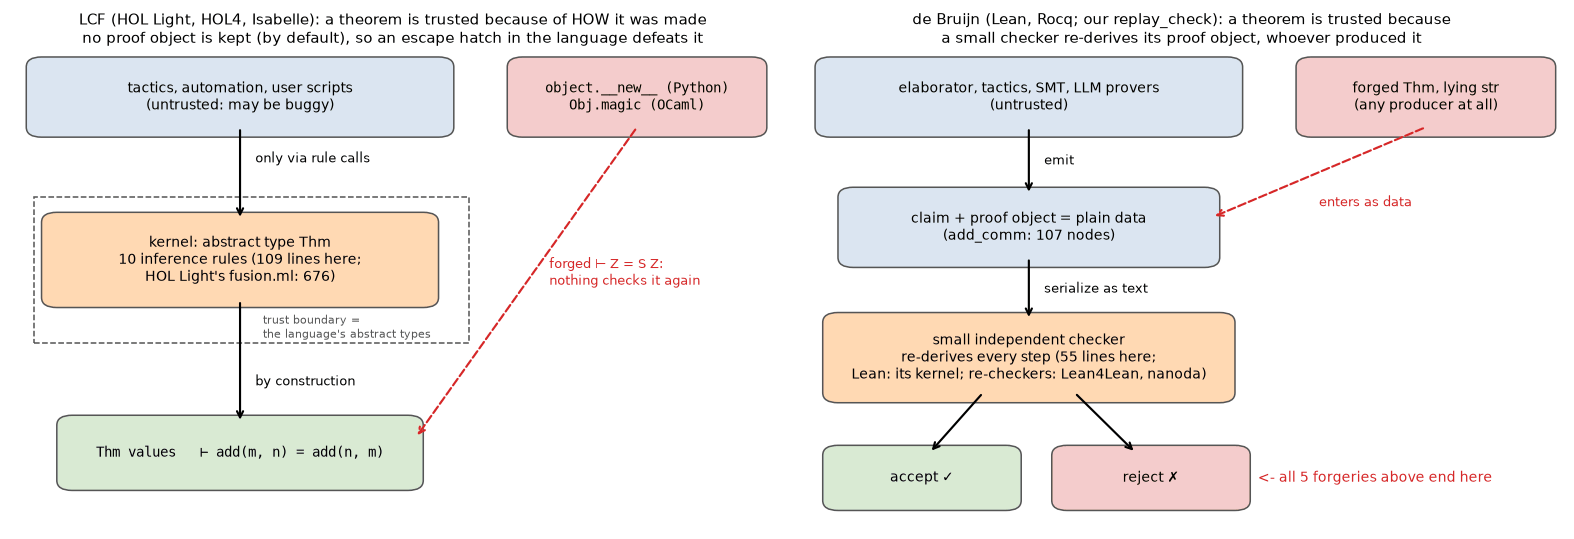

A forgery is rejected not because it was caught being made, but because its derivation does not check.


In [133]:
# §10.4  Trusted-code sizes, and the two architectures side by side.
def _s10_loc(fn):
    '''Source lines spanned by a function, including nested functions and classes.'''
    lines, todo = set(), [fn.__code__]
    while todo:
        co = todo.pop()
        lines |= {ln for _, _, ln in co.co_lines() if ln is not None} | {co.co_firstlineno}
        todo += [c for c in co.co_consts if hasattr(c, 'co_lines')]
    return max(lines) - min(lines) + 1


_s10_KERNEL_LOC = sum(_s10_loc(f) for f in (_s10_make_kernel, _s10_is_term, _s10_free_vars, _s10_subst))
_s10_REPLAY_LOC = sum(_s10_loc(f) for f in (_s10_rp_replay, _s10_check_text))
_s10_EXPORT_LOC = sum(_s10_loc(f) for f in (_s10_plain, _s10_export))
print(f"trusted code: kernel {_s10_KERNEL_LOC} lines (_s10_make_kernel + its three term helpers); independent "
      f"checker {_s10_REPLAY_LOC} lines (_s10_rp_replay + _s10_check_text), plus a {_s10_EXPORT_LOC}-line "
      "plain-data export that decides what crosses the boundary (compare HOL Light's 676-line fusion.ml, §10.6)")

def _s10_box(ax, x, y, w, h, text, fc, fs=9, mono=False):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02", fc=fc, ec="#555555"))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, family="monospace" if mono else None)


def _s10_arrow(ax, p, q, color="black", ls="-", text=None, toff=(0.02, 0)):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="->", color=color, lw=1.4, ls=ls))
    if text:
        ax.text((p[0] + q[0]) / 2 + toff[0], (p[1] + q[1]) / 2 + toff[1], text, fontsize=8.5, color=color,
                va="center")


fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.0))
ax = axes[0]
_s10_box(ax, 0.30, 0.86, 0.52, 0.12, "tactics, automation, user scripts\n(untrusted: may be buggy)", "#dbe5f1")
ax.add_patch(Rectangle((0.03, 0.37), 0.57, 0.29, fill=False, ls="--", ec="#555555"))
ax.text(0.33, 0.40, "trust boundary =\nthe language's abstract types", fontsize=7.5, color="#555555", va="center")
_s10_box(ax, 0.30, 0.535, 0.48, 0.15,
         f"kernel: abstract type Thm\n10 inference rules ({_s10_KERNEL_LOC} lines here;\nHOL Light's fusion.ml: 676)",
         "#ffd9b3")
_s10_box(ax, 0.30, 0.15, 0.44, 0.11, "Thm values   ⊢ add(m, n) = add(n, m)", "#d9ead3", mono=True)
_s10_arrow(ax, (0.30, 0.80), (0.30, 0.615), text="only via rule calls", toff=(0.02, 0.03))
_s10_arrow(ax, (0.30, 0.455), (0.30, 0.21), text="by construction", toff=(0.02, -0.04))
_s10_box(ax, 0.82, 0.86, 0.30, 0.12, "object.__new__ (Python)\nObj.magic (OCaml)", "#f4cccc", mono=True)
_s10_arrow(ax, (0.82, 0.80), (0.53, 0.18), color="#d62728", ls="--",
           text="forged ⊢ Z = S Z:\nnothing checks it again", toff=(0.03, 0.02))
ax.set_xlim(0, 1); ax.set_ylim(0.0, 0.95); ax.axis("off")
ax.set_title("LCF (HOL Light, HOL4, Isabelle): a theorem is trusted because of HOW it was made\n"
             "no proof object is kept (by default), so an escape hatch in the language defeats it", fontsize=10)
ax = axes[1]
_s10_box(ax, 0.30, 0.86, 0.52, 0.12, "elaborator, tactics, SMT, LLM provers\n(untrusted)", "#dbe5f1")
_s10_box(ax, 0.30, 0.60, 0.46, 0.12,
         f"claim + proof object = plain data\n(add_comm: {_s10_proof_size(_s10_add_comm.proof)} nodes)", "#dbe5f1")
_s10_box(ax, 0.30, 0.34, 0.50, 0.14, f"small independent checker\nre-derives every step ({_s10_REPLAY_LOC} "
         "lines here;\nLean: its kernel; re-checkers: Lean4Lean, nanoda)", "#ffd9b3")
_s10_box(ax, 0.16, 0.10, 0.22, 0.09, "accept ✓", "#d9ead3")
_s10_box(ax, 0.46, 0.10, 0.22, 0.09, "reject ✗", "#f4cccc")
_s10_arrow(ax, (0.30, 0.80), (0.30, 0.665), text="emit")
_s10_arrow(ax, (0.30, 0.54), (0.30, 0.415), text="serialize as text")
_s10_arrow(ax, (0.24, 0.27), (0.17, 0.15))
_s10_arrow(ax, (0.36, 0.27), (0.44, 0.15))
_s10_box(ax, 0.82, 0.86, 0.30, 0.12, "forged Thm, lying str\n(any producer at all)", "#f4cccc", mono=False)
_s10_arrow(ax, (0.82, 0.80), (0.54, 0.62), color="#d62728", ls="--", text="enters as data", toff=(0.0, -0.06))
_s10_caught = (f"<- all {len(_s10_FORGED)} forgeries above end here" if _s10_forged_rejected == len(_s10_FORGED)
               else f"<- {_s10_forged_rejected} of the {len(_s10_FORGED)} forgeries above end here")
ax.text(0.60, 0.10, _s10_caught, fontsize=9, color="#d62728", va="center")
ax.set_xlim(0, 1); ax.set_ylim(0.0, 0.95); ax.axis("off")
ax.set_title("de Bruijn (Lean, Rocq; our replay_check): a theorem is trusted because\n"
             "a small checker re-derives its proof object, whoever produced it", fontsize=10)
plt.tight_layout()
plt.show()
print("A forgery is rejected not because it was caught being made, but because its derivation does not check.")

### 10.5 The same proofs in Lean 4 (illustrative)

```lean
inductive N where
  | zero : N
  | succ : N → N

namespace N                                 -- so the names below cannot clash with Mathlib's root lemmas

def add : N → N → N                         -- recursion on the SECOND argument, like Nat.add
  | m, .zero   => m
  | m, .succ n => .succ (add m n)

theorem add_zero (m : N) : add m .zero = m := rfl         -- definitional: the kernel just computes

theorem zero_add : (n : N) → add .zero n = n              -- a recursive function IS an induction proof
  | .zero   => rfl
  | .succ n => congrArg N.succ (zero_add n)                -- CONG_S applied to the IH

theorem succ_add (m : N) : (n : N) → add (.succ m) n = .succ (add m n)
  | .zero   => rfl
  | .succ n => congrArg N.succ (succ_add m n)

theorem add_comm (m : N) : (n : N) → add m n = add n m
  | .zero   => (zero_add m).symm
  | .succ n => (congrArg N.succ (add_comm m n)).trans (succ_add n m).symm

end N
```

| our toy | Lean 4 |
|---|---|
| `ADD_ZERO`, `ADD_SUCC` | definitional unfolding inside the kernel's type checker (`rfl`) |
| `CONG_S` / `SYM` / `TRANS` | `congrArg N.succ` / `Eq.symm` / `Eq.trans` |
| `ASSUME` (the IH) + `INDUCT` | the recursive call on a structurally smaller `n` (compiled via `N.brecOn`, built from the recursor `N.rec`) |
| `_s10_simp`, `_s10_induction` (untrusted) | tactics such as `simp`, `induction`, `omega`: they only produce terms |
| proof record + `replay_check` | the proof term itself (§10.2's `typecheck`, scaled to dependent types), re-checked by the kernel |

Lean's core library proves `Nat.zero_add`, `Nat.succ_add` and `Nat.add_comm` essentially this way
([Init/Data/Nat/Basic.lean](https://github.com/leanprover/lean4/blob/master/src/Init/Data/Nat/Basic.lean)):
`add_comm`'s base case is `Eq.symm (Nat.zero_add n)` and its step rewrites with `succ_add` — the lemma our kernel
got stuck without.

### 10.6 How small is the trusted base, and what has it checked?

| kernel | what was counted | lines |
|---|---|---|
| this notebook | the kernel with its three term helpers + the independent checker (sizes printed in §10.4) | about 110 + 55 Python |
| HOL Light | [`fusion.ml`](https://github.com/jrh13/hol-light/blob/master/fusion.ml), the complete kernel "of types, terms and theorems" | 676 OCaml (548 non-blank) |
| Isabelle/Pure | [`thm.ML`](https://github.com/isabelle-prover/mirror-isabelle/blob/master/src/Pure/thm.ML), the abstract type `thm`; with `term.ML`, `type.ML`, `logic.ML`, `envir.ML` | 2,796 SML; ≈5,800 with the other four (an estimate: which files count is a judgement call) |
| Lean 4 (Oct 2026) | [`src/kernel/`](https://github.com/leanprover/lean4/tree/master/src/kernel) `*.cpp, *.h` | 7,875 C++ |
| Rocq (Oct 2026) | [`kernel/`](https://github.com/rocq-prover/rocq/tree/master/kernel) directory, incl. VM support | 44,319 OCaml + 3,195 C |

These are repository counts, not formal TCB measurements: every kernel also trusts its compiler, runtime and
hardware. Barendregt names the tension with the **Poincaré principle**: the more a kernel computes, the shorter
the proofs and the bigger the checker; Lean's `native_decide` trusts the whole compiler, which surfaces as an
axiom under `#print axioms` ([Lean reference](https://lean-lang.org/doc/reference/latest/Axioms/)). Re-checkers
apply the de Bruijn idea to Lean itself: [lean4checker](https://github.com/leanprover/lean4checker) replays a
compiled environment through Lean's *own* kernel ("not an external verifier"; shipped as `leanchecker` from
v4.28.0); [Lean4Lean](https://github.com/digama0/lean4lean), a kernel written in Lean, "likely shares some
implementation bugs" with the C++ original yet found a kernel soundness bug;
[nanoda](https://github.com/ammkrn/nanoda_lib) is an independent checker in Rust.

| year | machine-checked result | system | source |
|---|---|---|---|
| 2005 | Four Colour Theorem (Gonthier) | Coq | Gonthier, Notices AMS 2008 |
| 2012 | Odd Order (Feit–Thompson) theorem, Gonthier and 14 co-authors | Coq | ITP 2013, LNCS 7998 |
| 2014 | Kepler conjecture (Flyspeck), after referees could not certify the 1998 proof (~300 pages + ~40,000 lines of code) | HOL Light + Isabelle | [Flyspeck](https://github.com/flyspeck/flyspeck); Hales et al., Forum Math. Pi 2017 |
| 2022 | Liquid Tensor Experiment (Scholze's challenge of Dec 2020) | Lean + mathlib | [Lean community blog](https://leanprover-community.github.io/blog/posts/lte-final/) |
| 2026 | Fermat's Last Theorem, largely by autonomous AI agents (details in §13.4) | Lean | [Anthropic, 4 Sep 2026](https://www.anthropic.com/research/formalizing-fermats-last-theorem) |

A kernel certifies that *this* proof proves *this* statement; whether the statement means what you meant is
outside every kernel (§13's misformalized benchmarks, §2's spec ladder). The section is the fourth spine idea in
its purest form — **check the product, not the producer** — and an LLM prover is one more untrusted box at the
top of the de Bruijn figure.

## 11. What has actually been verified — and did it work?

Sections 3–10 built every technique as a toy. A skeptical engineer asks three questions next: **has anything
real been verified, what did it cost, and did the verified systems actually have fewer bugs?** This section
treats the famous case studies as **data** — one typed table, a primary source on every row — and then replays
one real bug, TimSort's broken stack invariant, end to end with this notebook's own kind of machinery.

Read "verified" precisely. Every result below is a theorem of the form **implementation ⊑ spec, under
assumptions A** (§8's refinement). seL4's C code refines an abstract specification *assuming* the compiler, 600
lines of assembly, the boot code, cache management and the hardware are correct (Klein et al., SOSP 2009).
CompCert's PowerPC output preserves the semantics of its Clight input *assuming* the Clight and PowerPC
semantics, the then-unverified parser, assembler and linker, Coq's extraction and the OCaml compiler, and the
Coq checker (Leroy, CACM 2009). The assumptions are §2.5's trusted computing base, written down. A bug outside
them does not contradict the theorem — and §11.3 shows that this is exactly where the bugs turned up.

### 11.1 The case table

`CASES` is the contract consumed by §12: one dict per result with the fields listed in `CASE_FIELDS`. Missing
numbers stay `None` and are never guessed. Read every size with one warning in mind: **line counts from
different tools measure different things**. seL4's 200,000 Isabelle lines include frameworks, libraries and
generated proofs. EverCrypt's 124,310 F\*/Vale lines include the code itself. Dafny and Verus proof lines are
annotations interleaved with code. Kani users report *harnesses*, not lines. Astrée has zero proof lines because
it is automatic. Ratios below are therefore order-of-magnitude statements, and the `note` field of each row says
what the numbers count.

In [134]:
# The case table: famous verification results as typed rows, each with a primary source.
# Numbers are as reported by the source; 'computed' values are plain arithmetic on reported numbers (see note).
CASE_FIELDS = {
    # field:            (allowed types,             meaning)
    "system":           (str,                       "the verified artifact"),
    "year":             (int,                       "year of the cited result"),
    "what_was_proved":  (str,                       "the theorem: refinement to which spec, under which assumptions"),
    "code_loc":         ((int, type(None)),         "lines of verified implementation, as the source counts them"),
    "code_lang":        (str,                       "implementation language (and what it is generated from)"),
    "proof_loc":        ((int, type(None)),         "proof/annotation lines as reported (low reading if a range)"),
    "proof_loc_hi":     ((int, type(None)),         "high reading when the source gives a range, else None"),
    "spec_loc":         ((int, type(None)),         "lines of trusted specification, None if unknown"),
    "person_years_lo":  ((int, float, type(None)),  "effort, low reading (person-years): the source's lower "
                                                    "figure, or, where it separates them, without reusable tools"),
    "person_years_hi":  ((int, float, type(None)),  "effort, high reading (person-years)"),
    "includes_tooling": ((bool, type(None)),        "True if the high effort figure includes building tools"),
    "tool":             (str,                       "proof tool (and its solver)"),
    "tool_class":       (str,                       "'itp' | 'auto-active' | 'model' | 'static'"),
    "deployed":         (str,                       "where it runs, as far as a source confirms"),
    "source":           (str,                       "primary-source URL"),
    "note":             (str,                       "what the numbers count; caveats"),
}
_s11_TOOL_CLASSES = ("itp", "auto-active", "model", "static")


def _s11_case(system, year, tool, tool_class, what, source, code=None, lang="", proof=None, proof_hi=None,
              spec=None, py=(None, None), tooling=None, deployed="research", note=""):
    '''One CASES row with the contract's field names (unknown numbers stay None).'''
    return dict(system=system, year=year, what_was_proved=what, code_loc=code, code_lang=lang,
                proof_loc=proof, proof_loc_hi=proof_hi, spec_loc=spec, person_years_lo=py[0],
                person_years_hi=py[1], includes_tooling=tooling, tool=tool, tool_class=tool_class,
                deployed=deployed, source=source, note=note)


_s11_VERUS_URL = "https://www.andrew.cmu.edu/user/bparno/papers/verus-sys.pdf"
CASES = [
    _s11_case("seL4 (functional correctness)", 2009, "Isabelle/HOL", "itp",
              "C implementation refines an abstract spec; assumes the compiler, 600 lines of asm, boot code "
              "(~1.2 kLOC, omitted), cache management and hardware",
              "https://www.sigops.org/s/conferences/sosp/2009/papers/klein-sosp09.pdf",
              code=8_700, lang="C (+600 lines asm, trusted)", proof=200_000, py=(13.7, 22.7), tooling=True,
              deployed="not checked here",
              note="proof lines include framework, libraries and generated proofs; effort per TOCS 2014 Fig. 19 "
                   "(SOSP'09 rounds the proof to ~20 py): hi = 2.2 py kernel development + 20.5 py of proof, "
                   "lo = hi - 9 py of generic framework and tools (the same rule as the 2014 row)"),
    _s11_case("seL4 (comprehensive, TOCS)", 2014, "Isabelle/HOL", "itp",
              "adds binary-code correctness (compiler and linker leave the TCB), integrity, confidentiality, "
              "WCET, capDL init; asm, boot code, caches, hardware still assumed",
              "https://www.trustworthy.systems/publications/nicta_full_text/7371.pdf",
              code=10_000, lang="C", proof=480_000, py=(22.2, 31.2), tooling=True, deployed="not checked here",
              note="same kernel as the 2009 row (drawn, not counted in statistics); 480,000 lines are proofs "
                   "AND specs; code is 'of the order of 10,000'; TOCS Fig. 19: hi = 2.2 development + 20.5 "
                   "functional-correctness proof + 0.4 fast path + 4.1 security + 2 binary + 2 capDL = 31.2 py, "
                   "lo = hi - 9 py of generic tools; the paper's $362/SLOC is over 22.7 py (development + "
                   "functional correctness only)"),
    _s11_case("CompCert", 2009, "Coq", "itp",
              "semantic preservation Clight -> PowerPC asm; trusts Clight/PPC semantics, parser, assembler, "
              "linker, Coq extraction + OCaml, the Coq checker",
              "https://xavierleroy.org/publi/compcert-CACM.pdf",
              code=5_880, lang="Coq (compiler algorithms, extracted to OCaml)", proof=31_920, spec=4_200,
              py=(3, 3), deployed="commercial via AbsInt; qualified for ATR 42/72 MFC NG avionics (Mar 2026)",
              note="computed from 42,000 lines = 14% algorithms / 10% semantics (spec) / 76% proof; parser "
                   "verified since v2.3 (2014)"),
    _s11_case("CakeML (compiler backend)", 2019, "HOL4", "itp",
              "verified ML compiler backend through 12 intermediate languages, bootstrapped in HOL4; "
              "5 target ISAs in the 2019 paper",
              "https://www.cambridge.org/core/services/aop-cambridge-core/content/view/"
              "E43ED3EA740D2DF970067F4E2BB9EF7D/S0956796818000229a.pdf/the-verified-cakeml-compiler-backend.pdf",
              lang="CakeML / HOL4", proof=100_000,
              note="~100,000 lines of HOL4 for the whole development, code not separated; cakeml.org now "
                   "lists 6 targets"),
    _s11_case("IronFleet (IronRSL + IronKV)", 2015, "Dafny (Z3)", "auto-active",
              "Paxos replicated state machine and sharded KV refine trusted specs (top-level 85 and 34 SLOC); "
              "safety and liveness",
              "https://www.andrew.cmu.edu/user/bparno/papers/ironfleet.pdf",
              code=5_114, lang="Dafny (compiled to C#)", proof=39_253, spec=1_400, py=(3.7, 3.7), tooling=True,
              note="3.6:1 at the implementation layer per the paper; 3.7 py covers methodology + both "
                   "systems; 395 min to verify"),
    _s11_case("Verdi Raft", 2016, "Coq", "itp",
              "Raft state-machine safety, hence linearizability (90 invariants); network semantics and "
              "the OCaml shim trusted",
              "https://homes.cs.washington.edu/~mernst/pubs/raft-proof-cpp2016.pdf",
              code=530, lang="Coq (extracted to OCaml)", proof=50_000,
              note="proof excludes the Verdi framework core; effort not reported"),
    _s11_case("CertiKOS mC2", 2016, "Coq", "itp",
              "contextual functional correctness of a concurrent kernel with fine-grained locks; trusted "
              "943-line hardware model + 450-line syscall spec",
              "https://www.usenix.org/system/files/conference/osdi16/osdi16-gu.pdf",
              code=6_500, lang="C + x86 asm", proof=50_000, proof_hi=90_000, spec=1_393, py=(2, 2),
              tooling=True,
              note="50K lines of concurrency proof scripts; hi adds ~40K lines of auxiliary definitions, "
                   "lemmas, invariants; 5,249 further non-TCB spec lines"),
    _s11_case("EverCrypt (HACL* + Vale)", 2020, "F*/Low*, Vale (Z3)", "auto-active",
              "memory safety, functional correctness and secret independence of a crypto provider",
              "https://www.microsoft.com/en-us/research/uploads/prod/2019/10/evercrypt.pdf",
              code=43_874, lang="C + asm generated from F* and Vale", proof=124_310, py=(3, 4), tooling=True,
              deployed="via its HACL* components (next row)",
              note="code = generated 25,052 .c + 4,082 .h + 14,740 asm; the 124,310 lines are specs + CODE + "
                   "proofs, so the ratio overstates proof alone; 5 h 45 min sequential verification"),
    _s11_case("HACL* in CPython hashlib", 2023, "F* / KaRaMeL", "auto-active",
              "built-in MD5, SHA-1, SHA-2, SHA-3 fallbacks (used when OpenSSL lacks them) replaced by "
              "verified HACL* C; BLAKE2 and a built-in HMAC follow in 3.14",
              "https://docs.python.org/3/whatsnew/3.12.html",
              lang="C generated from F*",
              deployed="CPython 3.12+; Firefox NSS (Curve25519, Firefox 57); Linux kernel (64-bit Curve25519)",
              note="SHA2-224/256 came first: cpython PR #99109 merged 7 Feb 2023"),
    _s11_case("Fiat Cryptography", 2019, "Coq", "itp",
              "finite-field arithmetic generated correct-by-construction from Coq specifications",
              "https://dspace.mit.edu/handle/1721.1/130000",
              lang="C generated from Coq",
              deployed="BoringSSL -> Chrome, Android, Cloudflare; 32-bit Curve25519 in the Linux kernel",
              note="'about 90% of secure Chrome communications' ran its code: 2019 researcher estimate "
                   "(MIT Technology Review), not a measurement"),
    _s11_case("AWS Zelkova", 2022, "Z3, CVC4, cvc5, automaton solver", "static",
              "IAM / S3 access-policy questions compiled to SMT queries and decided push-button",
              "https://www.amazon.science/publications/a-billion-smt-queries-a-day",
              lang="policies (SMT encoding)",
              deployed="IAM Access Analyzer, S3 Block Public Access; about a billion SMT queries/day",
              note="analyses configurations, not code; 'from a thousand to a billion SMT calls a day in five "
                   "years' (Rungta, CAV 2022)"),
    _s11_case("AWS s2n HMAC + DRBG (SAW)", 2018, "SAW + Cryptol (+ Coq)", "model",
              "SAW proves the C HMAC and DRBG equivalent to Cryptol implementations, re-run in CI on every "
              "code change; for HMAC, Coq relates the detailed Cryptol to a 3-line spec matching NIST's",
              "https://galois.com/project/amazon-s2n/",
              code=103, lang="C", spec=3, deployed="s2n-tls",
              note="code = 103 lines of HMAC C; spec = the 3 lines of Cryptol it was reduced to (the end of the "
                   "SAW + Coq chain, not the CI check itself); the Galois page is undated, year 2018 assumed "
                   "from the CAV 2018 paper on this work (not checked)"),
    _s11_case("AWS Cedar", 2024, "Lean 4 + differential random testing", "itp",
              "Lean model of the Cedar authorization language with proofs of authorizer/validator "
              "properties; the Rust production code is differentially tested against the model, not proved",
              "https://arxiv.org/pdf/2407.01688",
              code=1_673, lang="Lean 4 model (15,693-line Rust implementation tested against it)",
              proof=5_714, deployed="AWS authorization services",
              note="code = the Lean model; proof:Rust would be 0.36:1; proofs check in ~3 min"),
    _s11_case("Firecracker + Kani", 2023, "Kani (CBMC)", "model",
              "bounded proofs of rate-limiter and VirtIO properties of the microVM monitor",
              "https://model-checking.github.io/kani-verifier-blog/2023/08/31/"
              "using-kani-to-validate-security-boundaries-in-aws-firecracker.html",
              lang="Rust", deployed="AWS Lambda, AWS Fargate",
              note="27 harnesses in 3 suites, ~15 min in CI; sizes reported as harnesses, not lines"),
    _s11_case("Rust std library (Kani campaign)", 2026, "Kani", "model",
              "safety and function contracts of Rust standard-library functions (Rust Foundation challenge: "
              "~35K functions, ~7.5K unsafe)",
              "https://arxiv.org/abs/2607.01504",
              lang="Rust", deployed="verification campaign on the real std library",
              note=">16,000 harnesses verified per code change (Kani paper); the 35K / 7.5K figures are from "
                   "the AWS Open Source blog, 20 Nov 2024"),
    _s11_case("Hyper-V with VCC (Verisoft XT)", 2009, "VCC (Boogie/Z3)", "auto-active",
              "concurrent-C contracts for the hypervisor; how much was completed is not confirmed",
              "https://www.microsoft.com/en-us/research/project/vcc-a-verifier-for-concurrent-c/",
              lang="C + x64 asm", deployed="Microsoft Hyper-V (verified extent unconfirmed)",
              note="Hyper-V is ~60,000 lines of C + x64 asm; a widely repeated '50,000-line core' figure is not "
                   "on the cited page"),
    _s11_case("Paris Metro Line 14 (METEOR)", 1998, "Atelier B", "itp",
              "safety-critical core of driverless train control, refined stepwise in B and proved "
              "(27,800 proof obligations)",
              "https://www.atelierb.eu/wp-content/uploads/2018/04/RATP.pdf",
              code=86_000, lang="Ada (generated from B)", deployed="RATP Line 14, inaugurated 15 Oct 1998",
              note="115,000 lines of B models (spec + refinements, not proofs), 1,150 components; 'generated' "
                   "per Lecomte et al. 2007 (vendor-affiliated), which also reports no bugs after the proofs; "
                   "class 'itp' is a judgment call (Atelier B discharges most obligations automatically), and "
                   "the row has no proof size, so it is not in the ratio statistics"),
    _s11_case("Airbus A340 flight control (Astree)", 2003, "Astree (abstract interpretation)", "static",
              "absence of run-time errors, proved automatically by sound abstract interpretation",
              "https://www.astree.ens.fr/",
              code=132_000, lang="C (written or automatically generated)", proof=0,
              deployed="A340 primary flight control; A380 flight control from 2004",
              note="1h20 on a 2.8 GHz PC, zero false alarms (first time); the cost moves into analyzer "
                   "refinement: on the 132 kLOC program of Blanchet et al. (PLDI 2003), 1,200 false alarms from "
                   "the starting analyzer -> 11 after the refinements (also Kästner et al. 2010; §9.6)"),
    _s11_case("Atmosphere microkernel (prototype)", 2023, "Verus (Z3)", "auto-active",
              "verified microkernel in Rust (KISV 2023 prototype; full system at SOSP 2025)",
              "https://par.nsf.gov/servlets/purl/10549642",
              lang="Rust", note="reports a 7.5:1 proof:code ratio without the sizes; the SOSP 2025 ratio was "
                                "not checked"),
    _s11_case("SymCrypt ML-KEM + SHA-3 in Rust", 2026, "Aeneas + Lean", "itp",
              "safety, panic-freedom and functional correctness of Rust ML-KEM and SHA-3 (x86-64, ARM), via "
              "Aeneas (Rust -> Lean); proofs written by AI agents and checked by the Lean kernel",
              "https://arxiv.org/abs/2609.15648",
              code=16_700, lang="Rust", proof=237_000,
              deployed="Windows Insider builds (MSR blog, 13 Jul 2026)",
              note="Ho et al., draft paper (Sep 2026): a '237 KLOC Lean development' for 16.7 KLOC of Rust, not "
                   "split into proof, spec and translated code here; the proofs are agent-written, so the row is "
                   "drawn but not counted in the ratio statistics (a sensitivity row counts it); in June 2025 a "
                   "preliminary ML-KEM sat on a preview branch (MSR blog)"),
    _s11_case("OpenJDK TimSort (fixed) in KeY", 2015, "KeY", "itp",
              "fixed mergeCollapse: run-length class invariant, no exceptions, termination for 15 of 17 "
              "methods (mergeLo/mergeHi not done: path explosion)",
              "https://ir.cwi.nl/pub/23709/23709A.pdf",
              code=333, lang="Java", spec=334,
              deployed="the fix is in OpenJDK's mergeCollapse today",
              note="code and spec are non-comment lines (928 and 460 with comments/whitespace); proof = "
                   "2,211,263 rule applications, 5,029 interactive (§11.4); class 'itp' is a judgment call (KeY "
                   "is often called auto-active), and with no proof lines the row is not in the ratio statistics"),
]
print(f"{len(CASES)} hand-written rows; {sum(r[f] is None for r in CASES for f in ('code_loc', 'proof_loc'))} "
      "code/proof sizes stay None because no source gives them")

21 hand-written rows; 18 code/proof sizes stay None because no source gives them


One paper, the Verus SOSP 2024 evaluation, contributes five code bases measured the same way, so they are added
from a list of (name, implementation lines, proof lines). Then the contract check runs: the exact field set, the
declared types, a known tool class, a URL source on every row, and `lo <= hi` for every range.

In [135]:
# The five Verus SOSP 2024 case studies, one row each: (name, implementation lines, proof lines).
for _s11_name, _s11_c, _s11_p in [("IronKV port", 1_533, 4_509), ("node replication (NR)", 736, 5_237),
                                  ("x86 page table", 400, 5_329), ("mimalloc-based allocator", 3_178, 13_703),
                                  ("persistent log", 739, 2_913)]:
    CASES.append(_s11_case(f"Verus: {_s11_name}", 2024, "Verus (Z3)", "auto-active",
                           "functional correctness of Rust systems code (Verus SOSP 2024 case study)",
                           _s11_VERUS_URL, code=_s11_c, lang="Rust", proof=_s11_p,
                           note="IronKV: the Dafny original needed 8,070 proof lines for 1,923 code (4.2:1)"
                           if _s11_name == "IronKV port" else ""))


def _s11_validate(rows):
    '''The contract check: exact field set, declared types, known tool class, a URL source on every row.'''
    for r in rows:
        assert set(r) == set(CASE_FIELDS), r.get("system")
        for f, (types, _) in CASE_FIELDS.items():
            assert isinstance(r[f], types), (r["system"], f, r[f])
        assert r["tool_class"] in _s11_TOOL_CLASSES, r["system"]
        assert r["source"].startswith("https://"), r["system"]
        lo, hi = r["person_years_lo"], r["person_years_hi"]
        assert (lo is None) == (hi is None) and (lo is None or lo <= hi), r["system"]
        assert r["proof_loc_hi"] is None or r["proof_loc_hi"] >= r["proof_loc"], r["system"]
    return len(rows)


def _s11_fmt(v):
    return "-" if v is None else f"{v:,}"


_s11_validate(CASES)
show_table(["system", "year", "class", "code", "proof", "proof:code", "spec", "person-years"],
           [[r["system"][:36], r["year"], r["tool_class"], _s11_fmt(r["code_loc"]), _s11_fmt(r["proof_loc"]),
             f"{r['proof_loc'] / r['code_loc']:.1f}:1" if r["code_loc"] and r["proof_loc"] else "-",
             _s11_fmt(r["spec_loc"]),
             "-" if r["person_years_lo"] is None else
             (f"{r['person_years_lo']:g}" if r["person_years_lo"] == r["person_years_hi"]
              else f"{r['person_years_lo']:g}-{r['person_years_hi']:g}")] for r in CASES])
print(f"\nvalidated {len(CASES)} rows against CASE_FIELDS ({len(CASE_FIELDS)} fields); every row has a source URL.")
print(f"{sum(bool(r['code_loc'] and r['proof_loc']) for r in CASES)} rows have both code and proof sizes; "
      f"{sum(r['person_years_lo'] is not None for r in CASES)} have effort figures (used by §12); "
      f"{sum(r['spec_loc'] is not None for r in CASES)} have a spec size.")

system                               year  class        code     proof    proof:code  spec   person-years
---------------------------------------------------------------------------------------------------------
seL4 (functional correctness)        2009  itp          8,700    200,000  23.0:1      -      13.7-22.7   
seL4 (comprehensive, TOCS)           2014  itp          10,000   480,000  48.0:1      -      22.2-31.2   
CompCert                             2009  itp          5,880    31,920   5.4:1       4,200  3           
CakeML (compiler backend)            2019  itp          -        100,000  -           -      -           
IronFleet (IronRSL + IronKV)         2015  auto-active  5,114    39,253   7.7:1       1,400  3.7         
Verdi Raft                           2016  itp          530      50,000   94.3:1      -      -           
CertiKOS mC2                         2016  itp          6,500    50,000   7.7:1       1,393  2           
EverCrypt (HACL* + Vale)             2020  aut

### 11.2 How much proof per line of code?

The folklore number is seL4's: 200,000 Isabelle lines for 8,700 lines of C, about 23 lines of proof per line of
code (Kleppmann's 2025 essay quotes it). The usual claim is that **auto-active** tools (Dafny, F\*, Verus: §6's
VC generator plus an SMT solver, with the human writing only annotations) shrink this, because the solver does
the low-level reasoning that an ITP user scripts by hand.

**Registered prediction:** *the median proof:code ratio of auto-active systems is several (≥ 3×) lower than that
of ITP systems.* The statistics rules are fixed before measuring. There is one point per code base: seL4 2014 is
the same kernel as seL4 2009, so it is drawn but not counted. SymCrypt's Lean proofs were written by AI agents, so
they do not measure what a human scripts by hand; that row is drawn but not counted either. Each median gets a
95% bootstrap interval with its n. Because each counting choice is a judgment call, the cell also re-scores the
prediction under the alternative choices.

counting choice                             ITP median  auto-active median  ITP/AA  95% CI of ratio  >= 3x?
-----------------------------------------------------------------------------------------------------------
main: one point per code base               7.7 (n=5)   4.3 (n=7)           1.8x    [0.5, 21.9]      no    
count seL4 2014 as its own point            15.3 (n=6)  4.3 (n=7)           3.6x    [0.8, 16.5]      yes   
count SymCrypt (agent-written proofs)       10.9 (n=6)  4.3 (n=7)           2.5x    [0.7, 13.6]      no    
CertiKOS incl. auxiliary lemmas             13.8 (n=5)  4.3 (n=7)           3.2x    [0.5, 21.9]      yes   
pool the 5 Verus systems into one           7.7 (n=5)   4.8 (n=3)           1.6x    [0.7, 19.6]      no    
exclude Cedar (proved artifact is a model)  15.3 (n=4)  4.3 (n=7)           3.6x    [0.9, 21.9]      yes   


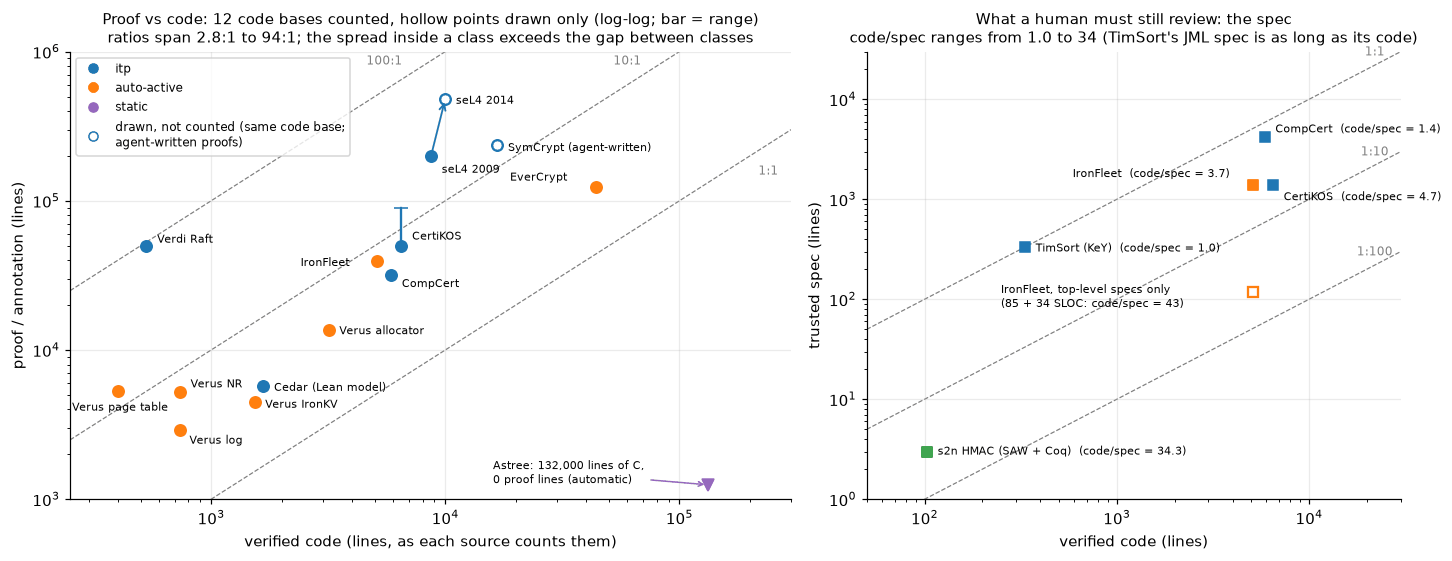

ITP median 7.7:1 (95% CI 3.4-94.3, n=5); auto-active median 4.3:1 (95% CI 2.9-7.7, n=7)
registered prediction: auto-active median >= 3x lower than ITP | measured: 1.8x, 95% CI [0.5, 21.9] | verdict: WRONG — direction right, size not robust: 3 of 6 counting choices reach 3x, and the ratio's interval includes 1 under 6 of 6
With n = 5-7 per class and line counts that measure different things, the defensible claim is an order of magnitude:
medians of 4.3:1 (auto-active) and 7.7:1 (ITP), individual code bases from 2.8:1 to 94:1.
The ITP class alone runs from 3.4:1 to 94:1, a factor of 28: one tool class is not one population.


In [136]:
_s11_BOOT_SEED, _s11_N_BOOT = 11, 5000
_s11_SYMCRYPT = "SymCrypt ML-KEM + SHA-3 in Rust"
_s11_NOT_COUNTED = {"seL4 (comprehensive, TOCS)": "same code base as the 2009 row",   # drawn, not counted
                    _s11_SYMCRYPT: "agent-written proofs (§13), not a measure of hand-written proof"}
_s11_CLASS_COLOR = {"itp": "C0", "auto-active": "C1", "model": "C2", "static": "C4"}
_s11_SHORT = {"seL4 (functional correctness)": "seL4 2009", "seL4 (comprehensive, TOCS)": "seL4 2014",
              "IronFleet (IronRSL + IronKV)": "IronFleet", "CertiKOS mC2": "CertiKOS",
              "EverCrypt (HACL* + Vale)": "EverCrypt", "AWS Cedar": "Cedar (Lean model)",
              "Verus: IronKV port": "Verus IronKV", "Verus: node replication (NR)": "Verus NR",
              "Verus: x86 page table": "Verus page table", "Verus: mimalloc-based allocator": "Verus allocator",
              "Verus: persistent log": "Verus log", "OpenJDK TimSort (fixed) in KeY": "TimSort (KeY)",
              "AWS s2n HMAC + DRBG (SAW)": "s2n HMAC (SAW + Coq)", _s11_SYMCRYPT: "SymCrypt (agent-written)"}


def _s11_ratios(rows, use_hi=False, count=(), pool_verus=False, exclude=()):
    '''{class: [proof/code, ...]} over rows with both sizes; the options are the sensitivity variants
    (count = rows of _s11_NOT_COUNTED to count anyway).'''
    pts = []
    for r in rows:
        if not (r["code_loc"] and r["proof_loc"]) or r["system"] in exclude:
            continue
        if r["system"] in _s11_NOT_COUNTED and r["system"] not in count:
            continue
        proof = r["proof_loc_hi"] if (use_hi and r["proof_loc_hi"]) else r["proof_loc"]
        pts.append((r["tool_class"], r["system"], r["code_loc"], proof))
    if pool_verus:      # one point: the sum of the five rows (the paper's own total row, 6,119 / 31,231, is 5.1:1)
        verus = [p for p in pts if p[1].startswith("Verus:")]
        pts = [p for p in pts if not p[1].startswith("Verus:")]
        pts.append(("auto-active", "Verus total", sum(p[2] for p in verus), sum(p[3] for p in verus)))
    out = defaultdict(list)
    for cls, _, code, proof in pts:
        out[cls].append(proof / code)
    return out


def _s11_boot_median_ratio(a, b, seed=_s11_BOOT_SEED, n_boot=_s11_N_BOOT):
    '''Percentile-bootstrap 95% intervals for median(a), median(b) and median(a)/median(b).'''
    g = np.random.default_rng(seed)
    ma = np.median(g.choice(a, (n_boot, len(a))), axis=1)
    mb = np.median(g.choice(b, (n_boot, len(b))), axis=1)
    return [np.percentile(v, [2.5, 97.5]) for v in (ma, mb, ma / mb)]


_s11_VARIANTS = {"main: one point per code base": {},
                 "count seL4 2014 as its own point": dict(count={"seL4 (comprehensive, TOCS)"}),
                 "count SymCrypt (agent-written proofs)": dict(count={_s11_SYMCRYPT}),
                 "CertiKOS incl. auxiliary lemmas": dict(use_hi=True),
                 "pool the 5 Verus systems into one": dict(pool_verus=True),
                 "exclude Cedar (proved artifact is a model)": dict(exclude={"AWS Cedar"})}


def _s11_score_variants():
    '''ITP vs auto-active medians, their ratio and its bootstrap interval, under each counting choice.'''
    table, scores = [], {}
    for label, kw in _s11_VARIANTS.items():
        rr = _s11_ratios(CASES, **kw)
        itp, aa = np.array(rr["itp"]), np.array(rr["auto-active"])
        ci_i, ci_a, ci_r = _s11_boot_median_ratio(itp, aa)
        q = np.median(itp) / np.median(aa)
        scores[label] = (itp, aa, ci_i, ci_a, ci_r, q)
        table.append([label, f"{np.median(itp):.1f} (n={len(itp)})", f"{np.median(aa):.1f} (n={len(aa)})",
                      f"{q:.1f}x", f"[{ci_r[0]:.1f}, {ci_r[1]:.1f}]", "yes" if q >= 3 else "no"])
    show_table(["counting choice", "ITP median", "auto-active median", "ITP/AA", "95% CI of ratio", ">= 3x?"],
               table)
    return scores


def _s11_draw_sizes():
    '''Left: proof vs code (log-log, ratio diagonals). Right: trusted spec vs code.'''
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={"width_ratios": [1.35, 1]})
    ax = axes[0]
    offsets = {"seL4 2009": (7, -11), "seL4 2014": (7, -3), "CompCert": (7, -8), "IronFleet": (-50, -3),
               "CertiKOS": (7, 4), "Verdi Raft": (7, 2), "EverCrypt": (-56, 4), "Cedar (Lean model)": (7, -3),
               "Verus IronKV": (7, -4), "Verus NR": (7, 3), "Verus page table": (-30, -13),
               "Verus allocator": (7, -3), "Verus log": (6, -9), "SymCrypt (agent-written)": (7, -4)}
    for r in CASES:
        if not (r["code_loc"] and r["proof_loc"]):
            continue
        c, p, col = r["code_loc"], r["proof_loc"], _s11_CLASS_COLOR[r["tool_class"]]
        lab = _s11_SHORT.get(r["system"], r["system"])
        ax.plot(c, p, "o", ms=7, mfc="white" if r["system"] in _s11_NOT_COUNTED else col, mec=col, mew=1.5,
                zorder=3)
        if r["proof_loc_hi"]:
            ax.plot([c, c], [p, r["proof_loc_hi"]], color=col, lw=1.5)
            ax.plot(c, r["proof_loc_hi"], "_", ms=9, color=col)
        ax.annotate(lab, (c, p), xytext=offsets.get(lab, (7, 2)), textcoords="offset points", fontsize=7.5)
    xs = np.array([250, 3e5])
    for k in (1, 10, 100):
        ax.plot(xs, k * xs, ls="--", c="gray", lw=0.8, zorder=1)
    for k, (x, y) in {1: (2.4e5, 1.5e5), 10: (6e4, 8.2e5), 100: (5.5e3, 8.2e5)}.items():
        ax.text(x, y, f"{k}:1", fontsize=8, color="gray", ha="center")
    s09, s14 = (next(r for r in CASES if r["system"] == s)
                for s in ("seL4 (functional correctness)", "seL4 (comprehensive, TOCS)"))
    ax.annotate("", xy=(s14["code_loc"], s14["proof_loc"]), xytext=(s09["code_loc"], s09["proof_loc"]),
                arrowprops=dict(arrowstyle="->", color="C0", lw=1.2))
    ast_row = next(r for r in CASES if r["tool_class"] == "static" and r["code_loc"])
    ax.plot(ast_row["code_loc"], 1.25e3, "v", ms=8, color=_s11_CLASS_COLOR["static"])
    ax.annotate(f"Astree: {ast_row['code_loc']:,} lines of C,\n0 proof lines (automatic)",
                xy=(ast_row["code_loc"], 1.25e3), xytext=(1.6e4, 1.5e3), fontsize=7.5, va="center",
                arrowprops=dict(arrowstyle="->", color=_s11_CLASS_COLOR["static"]))
    for cls in ("itp", "auto-active", "static"):
        ax.plot([], [], "o", color=_s11_CLASS_COLOR[cls], label=cls)
    ax.plot([], [], "o", mfc="white", mec="C0", label="drawn, not counted (same code base;\nagent-written proofs)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(250, 3e5)
    ax.set_ylim(1e3, 1e6)
    ax.set_xlabel("verified code (lines, as each source counts them)")
    ax.set_ylabel("proof / annotation (lines)")
    allr = [x for v in _s11_ratios(CASES).values() for x in v]
    ax.set_title(f"Proof vs code: {len(allr)} code bases counted, hollow points drawn only (log-log; bar = range)\n"
                 f"ratios span {min(allr):.1f}:1 to {max(allr):.0f}:1; the spread inside a class exceeds "
                 "the gap between classes", fontsize=10)
    ax.legend(fontsize=8, loc="upper left")

    ax = axes[1]
    pts = [(r["code_loc"], r["spec_loc"], _s11_SHORT.get(r["system"], r["system"].split(" (")[0]),
            r["tool_class"]) for r in CASES if r["spec_loc"] and r["code_loc"]]
    offs = {"CompCert": (7, 3), "IronFleet": (-118, 5), "CertiKOS": (7, -10), "TimSort (KeY)": (7, -3),
            "s2n HMAC (SAW + Coq)": (7, -2)}
    for c, s, lab, cls in pts:
        ax.plot(c, s, "s", ms=7, color=_s11_CLASS_COLOR[cls])
        ax.annotate(f"{lab}  (code/spec = {c / s:.1f})", (c, s), xytext=offs.get(lab, (7, 2)),
                    textcoords="offset points", fontsize=7.5)
    iron = next(r for r in CASES if r["system"].startswith("IronFleet"))
    top_spec = 85 + 34                                    # IronRSL + IronKV top-level specs (SLOC)
    ax.plot(iron["code_loc"], top_spec, "s", ms=7, mfc="white", mec=_s11_CLASS_COLOR["auto-active"], mew=1.5)
    ax.annotate(f"IronFleet, top-level specs only\n(85 + 34 SLOC: code/spec = {iron['code_loc'] / top_spec:.0f})",
                (iron["code_loc"], top_spec), xytext=(-165, -10), textcoords="offset points", fontsize=7.5)
    xs = np.array([50, 3e4])
    for k in (1, 10, 100):
        ax.plot(xs, xs / k, ls="--", c="gray", lw=0.8, zorder=1)
        ax.text(2.2e4, 2.2e4 / k * 1.25, f"1:{k}", fontsize=8, color="gray", ha="center")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(50, 3e4)
    ax.set_ylim(1, 3e4)
    ax.set_xlabel("verified code (lines)")
    ax.set_ylabel("trusted spec (lines)")
    q = [c / s for c, s, _, _ in pts]
    ax.set_title(f"What a human must still review: the spec\ncode/spec ranges from {min(q):.1f} to {max(q):.0f} "
                 "(TimSort's JML spec is as long as its code)", fontsize=10)
    plt.tight_layout()
    plt.show()


_s11_scores = _s11_score_variants()
_s11_draw_sizes()
_s11_itp, _s11_aa, _s11_ci_i, _s11_ci_a, _s11_ci_r, _s11_qm = _s11_scores["main: one point per code base"]
_s11_nyes = sum(v[-1] >= 3 for v in _s11_scores.values())
_s11_nci1 = sum(v[4][0] <= 1 for v in _s11_scores.values())      # the ratio's 95% interval reaches down to 1
_s11_allr = [x for v in _s11_ratios(CASES).values() for x in v]
print(f"ITP median {np.median(_s11_itp):.1f}:1 (95% CI {_s11_ci_i[0]:.1f}-{_s11_ci_i[1]:.1f}, n={len(_s11_itp)}); "
      f"auto-active median {np.median(_s11_aa):.1f}:1 (95% CI {_s11_ci_a[0]:.1f}-{_s11_ci_a[1]:.1f}, "
      f"n={len(_s11_aa)})")
print(f"registered prediction: auto-active median >= 3x lower than ITP | measured: {_s11_qm:.1f}x, 95% CI "
      f"[{_s11_ci_r[0]:.1f}, {_s11_ci_r[1]:.1f}] | verdict: {'RIGHT' if _s11_qm >= 3 else 'WRONG'} — direction "
      f"right, size not robust: {_s11_nyes} of {len(_s11_scores)} counting choices reach 3x, and the ratio's "
      f"interval includes 1 under {_s11_nci1} of {len(_s11_scores)}")
_s11_nlo, _s11_nhi = sorted((len(_s11_aa), len(_s11_itp)))
print(f"With n = {_s11_nlo}-{_s11_nhi} per class and line counts that measure different things, the "
      f"defensible claim is an order of magnitude:\nmedians of {np.median(_s11_aa):.1f}:1 (auto-active) and "
      f"{np.median(_s11_itp):.1f}:1 (ITP), individual code bases from {min(_s11_allr):.1f}:1 to "
      f"{max(_s11_allr):.0f}:1.")
print(f"The ITP class alone runs from {min(_s11_itp):.1f}:1 to {max(_s11_itp):.0f}:1, a factor of "
      f"{max(_s11_itp) / min(_s11_itp):.0f}: one tool class is not one population.")

The direction of the folklore survives; its size does not. The ITP class is not one population: CompCert (5.4:1)
and the Cedar Lean model (3.4:1) sit inside the auto-active range, while Verdi's Raft (94:1: 50,000 proof lines
and 90 invariants for a 530-line implementation) stretches the class to a factor of 28 between its extremes. Under
the main counting choice the medians differ by less than 2× and the interval for their ratio includes 1. Dropping
the Cedar row, whose proved artifact is a Lean model rather than the shipped Rust, lifts the ratio to 3.6×, but
under every one of the six choices the interval still includes 1. Two comparisons hold more fixed than the tool
class does. The same IronKV design needed 4.2:1 in Dafny and 2.9:1 in Verus (Verus, SOSP 2024): a tool-generation
effect inside one class. And the seL4 arrow shows the Isabelle development (proofs plus specs) growing 2.4× on the
same kernel as new theorems (binary correctness, confidentiality) were added, so scope and maintenance, not code,
drove the size. The automatic extreme is off the log axis: Hyperkernel reports 0.03:1 (as cited by the Verus
paper), and Astrée has no proof at all — there the cost moves into tuning the analyzer until the false alarms are
gone (§9). The right panel is the spine's other half: what a human must review is the trusted spec, and it is
usually smaller than the code, but not always — TimSort's 334-line JML spec is as long as the 333 lines it
specifies.

### 11.3 Did it work? Where the bugs were

Two independent studies later attacked verified systems with the best bug-finding tools of their day. That is
the right experiment, because a verified system can still fail in every place its theorem does not cover.

- **Csmith vs CompCert** (Yang, Chen, Eide & Regehr, PLDI 2011). Random C programs, differentially tested across
  11 compilers, found more than 325 previously unknown bugs: 79 reported against GCC and 202 against LLVM.
  CompCert had six silent wrong-code bugs in its *unverified front-end*: for example, `-1 <= (1 && x)` with `x`
  unsigned evaluated to 0 instead of 1. It had two more from a *spec gap*: the PowerPC semantics did not bound a
  16-bit displacement field, so CompCert emitted an out-of-range `stwu r1, -44432(r1)` and trusted the assembler
  to complain. The verified middle-end had **none**. As of early 2011 the development version was the only
  compiler tested in which Csmith found no wrong-code error, after about six CPU-years of testing. Leroy then
  extended the verified part to cover C's integer promotions.
- **Fonseca et al.** (EuroSys 2017) studied IronFleet, Verdi and Chapar. They found 16 bugs: 11 in the
  unverified *shim* between the verified core and the OS (9 of those 11 crashed or hung servers), 3 in the
  *verification tool or framework* (two let the verifier accept incorrect programs), and 2 in the *spec*. They
  found **zero protocol bugs** after more than eight months of searching. Their PK toolkit catches 13 of the 16.

During development, proof is also a bug-finder. Before seL4's verification began in earnest, student projects
and an x86 port had found 16 defects; the C-level proof then found 144 more (Klein et al. 2009). CertiKOS's
proof found a ticket-lock bug that passed every test: at ticket value 2³² − 1 the increment wraps to 0 and the
lock is granted at once. That is the setup cell's `wrap()`, in a kernel. The fix was to spin on `now != t`
instead of `now < t` (Gu et al., OSDI 2016). Cedar is the honest counterweight: its proofs found 4 validator
bugs, and differential and property-based testing found 21 (AWS, 2024).

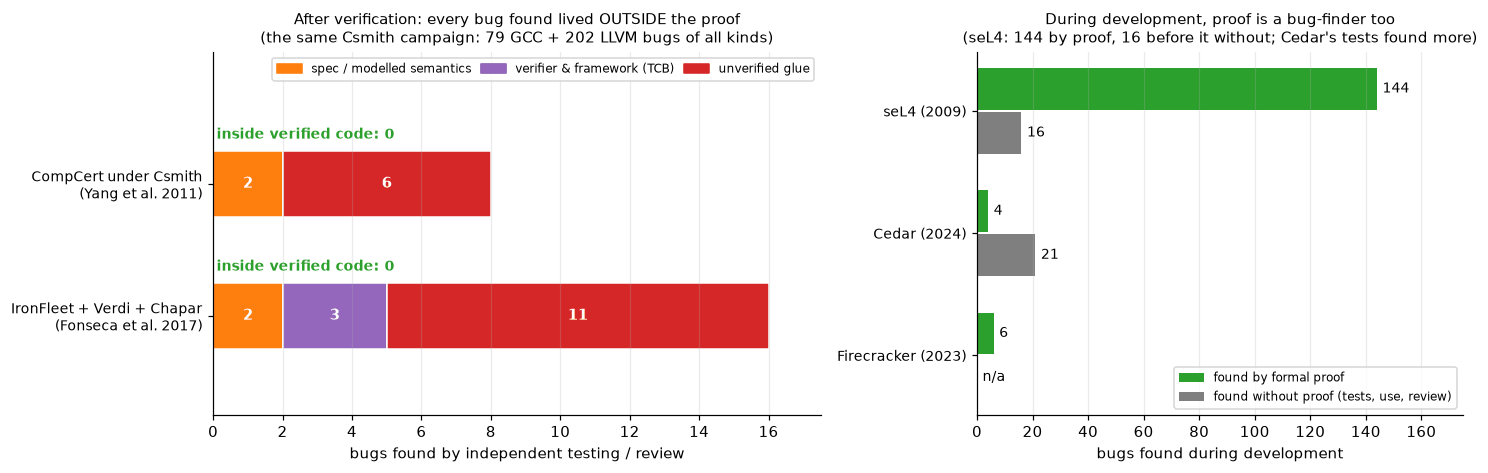

where the escaped bug lived  count (both studies)
-------------------------------------------------
verified code                0                   
spec / modelled semantics    4                   
verifier & framework (TCB)   3                   
unverified glue              17                  

0 of 24 post-verification bugs were inside verified code. The rest sat in the places the theorem trusts:
unverified glue (17), specs and modelled semantics (4), and the verifier itself (3). Verification moved the bugs to its boundary;
it did not remove the boundary. (Csmith also hit a handful of CompCert crash bugs, not counted.)


In [137]:
# Bugs found AFTER verification by independent studies, by where they lived (Yang et al. 2011; Fonseca et al. 2017).
_s11_WHERE = ["verified code", "spec / modelled semantics", "verifier & framework (TCB)", "unverified glue"]
_s11_WHERE_COLOR = ["#2ca02c", "#ff7f0e", "#9467bd", "#d62728"]
_s11_ESCAPED = {
    "CompCert under Csmith\n(Yang et al. 2011)": [0, 2, 0, 6],            # glue = the unverified front-end
    "IronFleet + Verdi + Chapar\n(Fonseca et al. 2017)": [0, 2, 3, 11],   # glue = the shim layer
}
assert sum(_s11_ESCAPED["IronFleet + Verdi + Chapar\n(Fonseca et al. 2017)"]) == 16   # the paper's total
# Bugs found DURING development, by method (Klein et al. 2009; AWS Cedar 2024; Firecracker Kani blog 2023).
_s11_DEV = {"seL4 (2009)": (144, 16), "Cedar (2024)": (4, 21), "Firecracker (2023)": (6, None)}


def _s11_draw_bugs():
    '''Left: escaped bugs by location (stacked). Right: development-time bugs by finding method.'''
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
    ax = axes[0]
    for yi, (study, counts) in enumerate(_s11_ESCAPED.items()):
        left = 0
        for cnt, col in zip(counts, _s11_WHERE_COLOR):
            if cnt:
                ax.barh(yi, cnt, left=left, color=col, edgecolor="white", height=0.5)
                ax.text(left + cnt / 2, yi, str(cnt), ha="center", va="center", color="white", fontsize=10,
                        fontweight="bold")
            left += cnt
        ax.text(0.1, yi - 0.37, f"inside verified code: {counts[0]}", ha="left", va="center", color="#2ca02c",
                fontsize=9, fontweight="bold")
    handles = [Rectangle((0, 0), 1, 1, color=col) for col in _s11_WHERE_COLOR[1:]]
    ax.set_yticks(range(len(_s11_ESCAPED)), list(_s11_ESCAPED), fontsize=9)
    ax.set_ylim(1.75, -1.0)                               # inverted: chronological, top to bottom
    ax.set_xlim(0, 17.5)
    ax.set_xlabel("bugs found by independent testing / review")
    ax.set_title("After verification: every bug found lived OUTSIDE the proof\n"
                 "(the same Csmith campaign: 79 GCC + 202 LLVM bugs of all kinds)", fontsize=10)
    ax.legend(handles, _s11_WHERE[1:], fontsize=8, loc="upper right", ncol=3, columnspacing=0.8)
    ax.grid(axis="y", visible=False)

    ax = axes[1]
    ys = np.arange(len(_s11_DEV))
    for j, (lab, col, off) in enumerate([("found by formal proof", "#2ca02c", -0.18),
                                         ("found without proof (tests, use, review)", "C7", 0.18)]):
        vals = [v[j] for v in _s11_DEV.values()]
        ax.barh(ys + off, [v or 0 for v in vals], height=0.34, color=col, label=lab)
        for yy, v in zip(ys + off, vals):
            ax.text((v or 0) + 2, yy, "n/a" if v is None else str(v), va="center", fontsize=9)
    ax.set_yticks(ys, list(_s11_DEV), fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, 175)
    ax.set_xlabel("bugs found during development")
    by_proof, before = _s11_DEV["seL4 (2009)"]
    ax.set_title(f"During development, proof is a bug-finder too\n(seL4: {by_proof} by proof, {before} before it "
                 "without; Cedar's tests found more)", fontsize=10)
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()


_s11_draw_bugs()
_s11_out = np.array(list(_s11_ESCAPED.values())).sum(axis=0)
show_table(["where the escaped bug lived", "count (both studies)"],
           [[w, int(c)] for w, c in zip(_s11_WHERE, _s11_out)])
print(f"\n{int(_s11_out[0])} of {int(_s11_out.sum())} post-verification bugs were inside verified code. The rest sat in "
      f"the places the theorem trusts:\nunverified glue ({int(_s11_out[3])}), specs and modelled semantics "
      f"({int(_s11_out[1])}), and the verifier itself ({int(_s11_out[2])}). Verification moved the bugs to its "
      "boundary;\nit did not remove the boundary. (Csmith also hit a handful of CompCert crash bugs, not counted.)")

### 11.4 Replaying the TimSort bug with this notebook's machinery

**TimSort** (Tim Peters, 2002) is the default sort in Python and the default object sort in Java and Android
(ERCIM News 2015). It scans the array for already-sorted *runs* (short ones are extended to a minimum length
`minRun` by insertion sort), pushes each run's length onto a stack, and after every push calls `mergeCollapse`,
which merges adjacent runs until the top of the stack again satisfies an invariant. Writing the stack bottom
first as $r_0, r_1, \dots$, the invariant is

$$r_i > r_{i+1} + r_{i+2} \quad\text{and}\quad r_i > r_{i+1} \qquad\text{for every } i,$$

so the lengths grow at least like Fibonacci numbers from top to bottom. That is what lets Java allocate a tiny
fixed stack. Java's `mergeCollapse` (until JDK 11, 2018) looked only at the **top three** runs $C, D, E$. With
$C \le D + E$ it merged the smaller neighbour pair: $(C, D)$ if $C < E$, else $(D, E)$. Otherwise it merged
$(D, E)$ if $D \le E$, and otherwise stopped. In 2013 de Gouw, Rot, de Boer, Bubel and Hähnle tried to prove
this code correct in the KeY verifier. The preservation obligation (§6: $I \wedge T \Rightarrow I'$) would not
close, and the open goal was a statement about the fourth run from the top (de Gouw et al., CAV 2015). The fixed
code adds the missing test: also merge when $B \le C + D$ one level deeper.

**The abstraction (§9's lesson).** `mergeCollapse` reads only `runLen`, so we throw the array away and model
TimSort as a machine over a tuple of run lengths. The abstraction loses nothing here. Every run-length sequence
whose runs are ≥ `minRun` (the last may be shorter) is produced by a 0/1 array that has exactly those ascending
runs. That is the paper's own encoding, so every abstract trace is a real one. On this machine the KeY failure
becomes a **reachable counterexample to induction**. Unlike §6's CTI for the x,y loop, which no execution
reaches, this one is reached by pushing five runs, so by §6.4's rule the invariant is false of the running code.
Here the invariant is the spec, since Java sized its stack from it, so what is wrong is the code.

**Registered prediction:** *since the crash that made this bug famous needs an array of 67 million elements,
breaking the invariant also needs an array of at least millions.* The first cell below builds the machine and
replays the paper's example. The second finds the smallest violating push sequence by explicit-state search over
stacks (§8's BFS, ordered by array size), compares it with Z3's minimum over the paper's five-push pattern, and
runs the same search on the fixed code. The third searches again under real TimSort's `minRun` rule and scores
the prediction.

paper's example [120, 80, 25, 20] + push 30: Java ends at [120, 80, 45, 30], violation at index [0] (120 <= 80 + 45); fixed code ends at [275]
reachable? pushing [120, 80, 25, 20, 30] onto an empty stack -> first violating stack (120, 80, 45, 30): a REACHABLE counterexample to induction


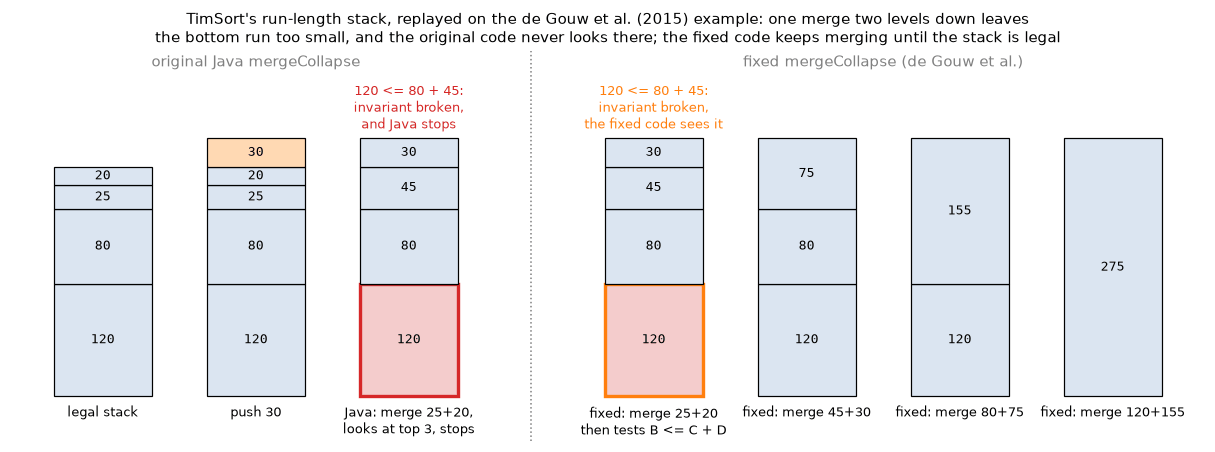

Java stops at [120, 80, 45, 30], broken at the bottom run; the fixed code keeps merging to [275].


In [138]:
# TimSort's run-length stack as a state machine: the array is abstracted away (mergeCollapse only reads runLen).
_s11_MIN_MERGE = 32            # Java's MIN_MERGE; minRun(n) lies in [16, 32] for n >= 64


def _s11_min_run(n, min_merge=_s11_MIN_MERGE):
    '''Java's minRunLength (CPython's merge_compute_minrun with min_merge=64): n / 2^k, rounded UP if any
    shifted-off bit is 1 -- so minRun = 16 exactly when n = 16 * 2^k.'''
    r = 0
    while n >= min_merge:
        r |= n & 1
        n >>= 1
    return n + r


def _s11_merge_collapse(stack, fixed=False, trace=None):
    '''mergeCollapse on a list of run lengths (bottom first), mutated in place; trace collects
    (stack after merge, merged pair). Original Java (until JDK 11, 2018) inspects the top three runs C, D, E;
    the fixed version (de Gouw et al.) also tests B <= C + D one level deeper.'''
    while len(stack) > 1:
        n = len(stack) - 2                                # stack[n] = D, stack[n+1] = E (top)
        if fixed:
            if (n >= 1 and stack[n - 1] <= stack[n] + stack[n + 1]) or \
               (n >= 2 and stack[n - 2] <= stack[n] + stack[n - 1]):
                if stack[n - 1] < stack[n + 1]:
                    n -= 1                                # merge the smaller neighbour pair
            elif stack[n] > stack[n + 1]:
                break                                     # invariant established (really, here)
        else:
            if n > 0 and stack[n - 1] <= stack[n] + stack[n + 1]:
                if stack[n - 1] < stack[n + 1]:
                    n -= 1
            elif stack[n] > stack[n + 1]:
                break                                     # "invariant established" -- for the top 3 only
        pair = (stack[n], stack[n + 1])
        stack[n:n + 2] = [stack[n] + stack[n + 1]]        # mergeAt(n)
        if trace is not None:
            trace.append((tuple(stack), pair))
    return stack


def _s11_violations(stack):
    '''Indices i where the invariant fails: r_i > r_{i+1} + r_{i+2} and r_i > r_{i+1}.'''
    bad = []
    for i in range(len(stack) - 1):
        ok = stack[i] > stack[i + 1] and (i + 2 >= len(stack) or stack[i] > stack[i + 1] + stack[i + 2])
        if not ok:
            bad.append(i)
    return bad


def _s11_simulate(runs, fixed=False):
    '''Push runs in array order, collapsing after each push. Returns (max stack size, first violating stack).
    The max is taken right after a push, before collapsing: that is when pushRun needs the slot.'''
    stack, max_depth, first_bad = [], 0, None
    for L in runs:
        stack.append(L)
        max_depth = max(max_depth, len(stack))
        _s11_merge_collapse(stack, fixed)
        if first_bad is None and _s11_violations(stack):
            first_bad = tuple(stack)
    return max_depth, first_bad


# (1) The paper's example: a legal stack, one push, and Java's collapse leaves the bottom run too small.
_s11_PAPER_STACK, _s11_PAPER_PUSH = [120, 80, 25, 20], 30
assert not _s11_violations(_s11_PAPER_STACK)
_s11_traces = {}
for _s11_fx in (False, True):
    _s11_traces[_s11_fx] = []
    _s11_merge_collapse(_s11_PAPER_STACK + [_s11_PAPER_PUSH], fixed=_s11_fx, trace=_s11_traces[_s11_fx])
_s11_jfinal = list(_s11_traces[False][-1][0])
print(f"paper's example {_s11_PAPER_STACK} + push {_s11_PAPER_PUSH}: Java ends at {_s11_jfinal}, violation at "
      f"index {_s11_violations(_s11_jfinal)} ({_s11_jfinal[0]} <= {_s11_jfinal[1]} + {_s11_jfinal[2]}); fixed code "
      f"ends at {list(_s11_traces[True][-1][0])}")
print(f"reachable? pushing {_s11_PAPER_STACK + [_s11_PAPER_PUSH]} onto an empty stack -> first violating stack "
      f"{_s11_simulate(_s11_PAPER_STACK + [_s11_PAPER_PUSH])[1]}: a REACHABLE counterexample to induction")


def _s11_draw_counterexample():
    '''Stacks drawn as towers (bottom run at the bottom, height = run length): Java vs the fixed code.'''
    cols = [(_s11_PAPER_STACK, "legal stack", None),
            (_s11_PAPER_STACK + [_s11_PAPER_PUSH], f"push {_s11_PAPER_PUSH}", None)]
    jpair = _s11_traces[False][-1][1]
    cols.append((_s11_jfinal, f"Java: merge {jpair[0]}+{jpair[1]},\nlooks at top 3, stops", "#d62728"))
    for i, (st, pair) in enumerate(_s11_traces[True]):
        cap = f"fixed: merge {pair[0]}+{pair[1]}" + ("\nthen tests B <= C + D" if i == 0 else "")
        cols.append((list(st), cap, "#ff7f0e" if (i == 0 and _s11_violations(st)) else None))
    fig, ax = plt.subplots(figsize=(14, 4.6))
    for x, (stack, cap, badcol) in enumerate(cols):
        xx = x + (0.6 if x >= 3 else 0)                   # gap between the Java and the fixed timelines
        bad = set(_s11_violations(stack)) if badcol else set()
        y0 = 0
        for i, L in enumerate(stack):
            new = x == 1 and i == len(stack) - 1
            fc = "#f4cccc" if i in bad else ("#ffd9b3" if new else "#dbe5f1")
            ax.add_patch(Rectangle((xx - 0.32, y0), 0.64, L, fc=fc, ec=badcol if i in bad else "black",
                                   lw=2.2 if i in bad else 0.8))
            ax.text(xx, y0 + L / 2, str(L), ha="center", va="center", fontsize=8.5, family="monospace")
            y0 += L
        ax.text(xx, -10, cap, ha="center", va="top", fontsize=8.5)
        if bad:
            i = min(bad)
            msg = "and Java stops" if badcol == "#d62728" else "the fixed code sees it"
            ax.text(xx, y0 + 6, f"{stack[i]} <= {stack[i + 1]} + {stack[i + 2]}:\ninvariant broken,\n{msg}",
                    ha="center", va="bottom", fontsize=8.5, color=badcol)
    ax.axvline(2.8, color="gray", ls=":", lw=1)
    ax.text(1.0, 352, "original Java mergeCollapse", ha="center", fontsize=9.5, color="gray")
    ax.text(5.1, 352, "fixed mergeCollapse (de Gouw et al.)", ha="center", fontsize=9.5, color="gray")
    ax.set_xlim(-0.6, len(cols) + 0.2)
    ax.set_ylim(-48, 368)
    ax.axis("off")
    ax.set_title("TimSort's run-length stack, replayed on the de Gouw et al. (2015) example: one merge two levels "
                 "down leaves\nthe bottom run too small, and the original code never looks there; the fixed code "
                 "keeps merging until the stack is legal", fontsize=10)
    plt.show()


_s11_draw_counterexample()
print(f"Java stops at {_s11_jfinal}, broken at the bottom run; the fixed code keeps merging to "
      f"{list(_s11_traces[True][-1][0])}.")

In the paper's example the broken inequality sits at the fourth run from the top, three below the new one, where a
test of the top three runs cannot see it. The next cell asks how small such an input can be, by searching every
stack reachable from an empty one in order of array size; Z3 gives a second minimum over the paper's five-push
pattern.

In [139]:
# (2) Explicit-state search over reachable stacks, smallest array first; then the same search on the fixed code.
def _s11_path(parent, st):
    '''Push sequence that reached stack st in the search tree.'''
    seq = []
    while parent[st] is not None:
        st, L = parent[st]
        seq.append(L)
    return seq[::-1]


def _s11_explore(m, max_total, fixed=False, stop_at_violation=False):
    '''Explicit-state search (§8) over stacks reachable by pushing runs of length >= m, array total <= max_total,
    in order of array size (merges preserve the total, so a stack's sum IS the array prefix length).
    Returns dict(first=(total, pushes, stack) of the smallest-total violation or None, min_pushes,
    depth={stack: deepest stack size on any path reaching it}, n_states).'''
    parent, depth, pushes = {(): None}, {(): 0}, {(): 0}
    buckets = defaultdict(list)
    buckets[0].append(())
    first, min_pushes = None, None
    for s in range(max_total + 1):
        if stop_at_violation and first is not None and s >= first[0]:
            break                                         # every later violation has a larger total
        for st in buckets.pop(s, ()):
            d_here = max(depth[st], len(st) + 1)          # the push itself momentarily adds one slot
            for L in range(m, max_total - s + 1):
                nxt = tuple(_s11_merge_collapse(list(st) + [L], fixed))
                if _s11_violations(nxt):
                    min_pushes = pushes[st] + 1 if min_pushes is None else min(min_pushes, pushes[st] + 1)
                    if first is None or s + L < first[0]:
                        first = (s + L, _s11_path(parent, st) + [L], nxt)
                if nxt not in parent:
                    parent[nxt], depth[nxt], pushes[nxt] = (st, L), d_here, pushes[st] + 1
                    buckets[s + L].append(nxt)
                else:
                    depth[nxt] = max(depth[nxt], d_here)
                    pushes[nxt] = min(pushes[nxt], pushes[st] + 1)
    return dict(first=first, min_pushes=min_pushes, depth=depth, n_states=len(parent))


def _s11_z3_smallest(m, timeout_ms=5000):
    '''Independent method: Z3 minimises the array size over the 5-run pattern the paper describes
    (legal A,B,C,D; push E; Java merges C+D, sees a legal top three, stops; A is now too small).'''
    A, B, C, D, E = z3.Ints("A B C D E")
    opt = z3.Optimize()
    opt.set("timeout", timeout_ms)
    opt.add(*[v >= m for v in (A, B, C, D, E)])
    opt.add(A > B + C, B > C + D, C > D)                  # legal stack before the push
    opt.add(C <= D + E, C < E)                            # Java merges (C, D) ...
    opt.add(B > C + D + E, C + D > E)                     # ... the new top three look fine, so it stops ...
    opt.add(A <= B + C + D)                               # ... but the invariant is broken at A
    opt.minimize(A + B + C + D + E)
    if opt.check() != z3.sat:
        return None
    return [opt.model()[v].as_long() for v in (A, B, C, D, E)]


# (2) Smallest violation with runs >= 16 (the smallest possible minRun), array total <= 200; then the fixed code.
_s11_SEARCH_M, _s11_SEARCH_TOTAL = 16, 200
_s11_bug, _s11_bug_t = timed(_s11_explore, _s11_SEARCH_M, _s11_SEARCH_TOTAL)
_s11_tot, _s11_seq, _s11_end = _s11_bug["first"]
print(f"\nsearch, buggy code: {_s11_bug['n_states']:,} reachable stacks (array total <= {_s11_SEARCH_TOTAL}, "
      f"runs >= {_s11_SEARCH_M}), ~{_s11_bug_t:.1f} s")
print(f"  smallest violating input: pushes {_s11_seq} (array of {_s11_tot}) -> stack {list(_s11_end)}; "
      f"fewest pushes in any violation: {_s11_bug['min_pushes']}")
if HAVE_Z3:
    _s11_zm = _s11_z3_smallest(_s11_SEARCH_M)
    print("  Z3: unknown/timeout -> no cross-check" if _s11_zm is None else
          f"  Z3 minimum over the 5-run pattern: {_s11_zm} (array of {sum(_s11_zm)}); same as the search: "
          f"{sum(_s11_zm) == _s11_tot}")
else:
    print("  (Z3 not installed: skipping the solver cross-check)")
_s11_fix, _s11_fix_t = timed(_s11_explore, _s11_SEARCH_M, _s11_SEARCH_TOTAL, fixed=True)
print(f"search, fixed code: {_s11_fix['n_states']:,} reachable stacks, violations: "
      f"{'none' if _s11_fix['first'] is None else _s11_fix['first']}  (bounded evidence; KeY proved every size)")


search, buggy code: 107,695 reachable stacks (array total <= 200, runs >= 16), ~1.0 s
  smallest violating input: pushes [70, 52, 17, 16, 18] (array of 173) -> stack [70, 52, 33, 18]; fewest pushes in any violation: 5
  Z3 minimum over the 5-run pattern: [70, 52, 17, 16, 18] (array of 173); same as the search: True


search, fixed code: 106,311 reachable stacks, violations: none  (bounded evidence; KeY proved every size)


Real TimSort does not let every run be 16 long: `minRun(n)` depends on the array length, and only the last run
may be shorter. The last cell of §11.4 repeats the search for every length from 32 to 256 under that rule and
scores the prediction.

In [140]:
# (3) The smallest array that breaks the invariant under Java's real minRun rule.
def _s11_smallest_breaking_n(max_n=256):
    '''Smallest array length n at which SOME input makes real TimSort break the invariant. Runs are >= minRun(n)
    except the last; group the lengths n by minRun and search each group up to its largest n.'''
    groups = defaultdict(list)
    for n in range(_s11_MIN_MERGE, max_n + 1):
        groups[_s11_min_run(n)].append(n)
    best = None
    for m, ns in sorted(groups.items()):
        res = _s11_explore(m, max(ns), stop_at_violation=True)
        if res["first"] is not None:
            ok = [n for n in ns if n >= res["first"][0]]  # pad the violating prefix with one more run
            if ok and (best is None or ok[0] < best[0]):
                best = (ok[0], m, res["first"])
    return best


(_s11_nmin, _s11_mmin, (_s11_v, _s11_vseq, _s11_vst)), _s11_t = timed(_s11_smallest_breaking_n)
_s11_witness = _s11_vseq + ([_s11_nmin - _s11_v] if _s11_nmin > _s11_v else [])
assert _s11_simulate(_s11_witness)[1] is not None and all(L >= _s11_mmin for L in _s11_witness[:-1])
print(f"\nreal minRun rule, every n in [{_s11_MIN_MERGE}, 256] (~{_s11_t:.1f} s): the smallest array that breaks the "
      f"invariant has n = {_s11_nmin} (minRun {_s11_mmin}); witness runs {_s11_witness}")
_s11_ok4 = _s11_nmin >= 10**6
print(f"registered prediction: breaking the invariant needs millions of elements | measured: {_s11_nmin:,} "
      f"elements | verdict: {'RIGHT' if _s11_ok4 else 'WRONG'}"
      + ("" if _s11_ok4 else " — the violation is cheap and SILENT; only a stack overflow makes it visible"))


real minRun rule, every n in [32, 256] (~5.3 s): the smallest array that breaks the invariant has n = 256 (minRun 16); witness runs [70, 52, 17, 16, 18, 83]
registered prediction: breaking the invariant needs millions of elements | measured: 256 elements | verdict: WRONG — the violation is cheap and SILENT; only a stack overflow makes it visible


### 11.5 How big must the stack be — and when does it overflow?

A violated invariant is silent. It turns into a crash only when the stack outgrows its fixed allocation. Java
sized that allocation **assuming the invariant**. If it holds, the run lengths from the top down are at least
$b_0 = 0$ (the run just pushed), $b_1 = 16$ (the minimum `minRun`), and $b_{i+2} = b_{i+1} + b_i + 1$. A stack
of $B + 1$ runs therefore holds more than $P_B = b_0 + \dots + b_B$ elements, so for an array of length $n$ the
stack never exceeds the least $B$ with $P_B \ge n$ (Sec. 3.1 of de Gouw et al.). The first cell below derives
Java's magic constants from this recurrence instead of copying them.

With the invariant broken, the stack can grow deeper. De Gouw et al. construct what they present as the **worst
case**. Their Lemma 1 says violations are never adjacent, so the deepest stack alternates good runs $Y_i$ with
violating runs $X_i$, and the minimal choices are $X_{i+1} = Y_i + x^{(i)}_1 + 1$ and
$Y_{i+1} = X_{i+1} + Y_i + 1$, with $X_1 = m = 16$ and $Y_1 = m + 4$. Each $X_i$ cannot be pushed directly,
because it would be merged away at once. It must be assembled from pushes $x_1, \dots, x_k \ge m$ obeying
$x_1 + \dots + x_{j-2} < x_j < x_1 + \dots + x_{j-1}$, so that only second-to-last merges fire. We implement the
construction with exactly the rules the paper's text spells out: a default halving step plus the fixed choices
for $X \le 4m + 1$. The run that is left over goes last. Every generated sequence is checked against the $x_j$
conditions and then *executed* on the machine above, so the depth we report is measured on a real input, not
assumed. A construction is only a *lower bound* on the worst case. At small sizes §11.4's exhaustive search
supplies the true worst case as an oracle, and the cells also test Lemma 1 itself.

**Registered prediction (from the paper and the OpenJDK source):** *the worst case first exceeds what Java
allocated at n = 2²⁶ = 67,108,864 elements, needing 41 slots against 40. The pre-2013 bound of 19 already fails
at 65,536. The 2015 bound of 49 is never exceeded for any Java array (length < 2³¹).* We test these claims on
every n = t·2^k (t = 16…31) below 2³¹. Those are the local worst cases. There `minRun` = t divides n exactly. In
between, `minRun` rounds up to t + 1, which only removes inputs, so the worst case is no deeper than at the next
grid point (t + 1)·2^k. That argument is about the true worst case; on the grid we can only execute
constructions, so a sweep can witness an overflow but cannot rule one out.

In [141]:
# (1) Java's bound, derived: b_0 = 0, b_1 = 16, b_{i+2} = b_{i+1} + b_i + 1; safe size = least B with P_B >= n.
def _s11_partial_sums(m=16, reach=2**31):
    '''P_B = b_0 + ... + b_B for the minimal legal run lengths b (top of stack first), up to the first P_B >= reach.'''
    b, P = [0, m], [0, m]
    while P[-1] < reach:
        b.append(b[-1] + b[-2] + 1)
        P.append(P[-1] + b[-1])
    return P


def _s11_invariant_bound(n, m=16):
    '''Largest stack possible while the invariant holds: the least B with P_B >= n.'''
    return next(B for B, p in enumerate(_s11_partial_sums(m, n)) if p >= n)


# Java's allocation over its history: 5 / 10 / mid / top slots by array length (TimSort's constructor).
_s11_JAVA = {"original (19 / 40)": (19, 40), "after JDK-8011944, 2013 (24 / 40)": (24, 40),
             "after JDK-8072909, 2015 (24 / 49)": (24, 49)}


def _s11_java_alloc(n, mid, top):
    return 5 if n < 120 else 10 if n < 1542 else mid if n < 119_151 else top


_s11_P = _s11_partial_sums()
show_table(["Java constant", "derived: P_B + 1", "slots Java allocates", "safe minimum B"],
           [[120, _s11_P[4] + 1, 5, _s11_invariant_bound(119)],
            [1542, _s11_P[9] + 1, 10, _s11_invariant_bound(1541)],
            [119151, _s11_P[18] + 1, "19 (24 from 2013)", _s11_invariant_bound(119150)],
            ["2^31 - 1", "-", "40 (49 from 2015)", _s11_invariant_bound(2**31 - 1)]])
print("Java's thresholds are partial sums of a Fibonacci-like sequence; its sizes are the safe minimum + 1.")

Java constant  derived: P_B + 1  slots Java allocates  safe minimum B
---------------------------------------------------------------------
120            120               5                     4             
1542           1542              10                    9             
119151         119151            19 (24 from 2013)     18            
2^31 - 1       -                 40 (49 from 2015)     39            
Java's thresholds are partial sums of a Fibonacci-like sequence; its sizes are the safe minimum + 1.


Those sizes are right only while the invariant holds. The next cell builds de Gouw et al.'s invariant-breaking
construction, executes it, and checks it twice: against the paper's own table of depths, and against the true
worst case that §11.4's exhaustive search gives for every array of at most 200 elements. It then tests the lemma
the construction rests on, first on every violating stack that search found, then on an example published later.

In [142]:
# (2) The worst-case construction, using only the rules the paper's text spells out.
def _s11_split(X, m):
    '''Pushes x_1..x_k (each >= m) that TimSort merges -- second-to-last merges only -- into one run of length X.'''
    tail = []
    while X >= 2 * m + 1:
        keep = X // 2 + 1                                 # default: x_k = X - (floor(X/2) + 1)
        if 3 * m + 3 <= X <= 4 * m + 1:
            keep = 2 * m + 1                              # fixed choice: x = (m+1, m, X - (2m+1))
        tail.append(X - keep)
        X = keep
    xs = [X] + tail[::-1]
    for j in range(1, len(xs)):                           # the paper's condition (3), asserted
        assert xs[j] >= m and sum(xs[:j - 1]) < xs[j] < sum(xs[:j]), (X, xs)
    return xs


def _s11_worst_case_runs(n, m):
    '''Run lengths (array order) of the de Gouw et al. worst case for length n: Y_k X_k ... Y_1 X_1, bottom to
    top, with X_{i+1} = Y_i + x_1 + 1, Y_{i+1} = X_{i+1} + Y_i + 1, X_1 = m, Y_1 = m + 4; leftover pushed last.'''
    blocks, total, X, Y = [], 0, m, m + 4
    while total + X + Y <= n:
        total += X + Y
        xs = _s11_split(X, m)
        blocks.append([Y] + xs)
        X, Y = Y + xs[0] + 1, Y + (Y + xs[0] + 1) + 1
    runs = []
    if total + X <= n:                                    # one more violating run fits (no Y above it)
        total += X
        runs += _s11_split(X, m)
    for blk in reversed(blocks):
        runs += blk
    if n > total:
        runs.append(n - total)
    assert sum(runs) == n and all(L >= m for L in runs[:-1])
    return runs


def _s11_fib_runs(n, m):
    '''The invariant-respecting worst case: minimal legal runs b_B, ..., b_1 (bottom to top), then the leftover.'''
    b = []
    nxt = m
    while sum(b) + nxt <= n:
        b.append(nxt)
        nxt = b[-1] + (b[-2] if len(b) > 1 else 0) + 1
    return b[::-1] + ([n - sum(b)] if n > sum(b) else [])


def _s11_worst_depth(n, m=None):
    '''Stack size needed for length n by the deeper of the two constructions, executed on the machine: a LOWER
    bound on the true worst case (any input's depth is one; the worst case is the max over all inputs).'''
    m = _s11_min_run(n) if m is None else m
    return max(_s11_simulate(_s11_worst_case_runs(n, m))[0], _s11_simulate(_s11_fib_runs(n, m))[0])


_s11_PAPER_TABLE = {64: 3, 128: 4, 160: 5, 65_536: 21, 131_072: 23, 67_108_864: 41, 1_073_741_824: 49}
_s11_rows = [[f"{n:,}", want, _s11_simulate(_s11_worst_case_runs(n, _s11_min_run(n)))[0], _s11_worst_depth(n)]
             for n, want in _s11_PAPER_TABLE.items()]
show_table(["array size", "paper's table", "our construction", "deeper of both constructions"], _s11_rows)
print(f"the construction reproduces the paper at {sum(r[1] == r[2] for r in _s11_rows)}/{len(_s11_rows)} sizes")


# Oracle: §11.4's exhaustive search (runs >= 16) knows the true worst depth for every n <= 200.
def _s11_oracle_depths(explored, max_total):
    '''Worst stack size for each array length n <= max_total: some reachable stack of sum <= n - 1, then one more
    (possibly short, final) push.'''
    best = defaultdict(int)
    for st, d in explored["depth"].items():
        best[sum(st)] = max(best[sum(st)], d, len(st) + 1)
    out, run_max = {}, 0
    for s in range(max_total):
        run_max = max(run_max, best.get(s, 0))
        out[s + 1] = run_max
    return out


_s11_oracle = _s11_oracle_depths(_s11_bug, _s11_SEARCH_TOTAL)
_s11_ns = range(_s11_MIN_MERGE, _s11_SEARCH_TOTAL + 1)
_s11_mis = [n for n in _s11_ns if _s11_oracle[n] != _s11_worst_depth(n, 16)]
_s11_gouw_only = [n for n in _s11_ns if _s11_oracle[n] != _s11_simulate(_s11_worst_case_runs(n, 16))[0]]
print(f"exhaustive oracle vs deeper-of-both, every n in [{_s11_MIN_MERGE}, {_s11_SEARCH_TOTAL}] (runs >= 16): "
      f"{len(_s11_mis)} mismatches")
print(f"  the de Gouw construction alone is beaten at {len(_s11_gouw_only)} of these sizes, e.g. n = 128: runs "
      f"{_s11_fib_runs(128, 16)} reach depth {_s11_simulate(_s11_fib_runs(128, 16))[0]} with the invariant intact")
print("  (the paper's table reports its construction, which targets invariant-BREAKING stacks; Java allots 10 there)")


# Lemma 1 of de Gouw et al. (violations are never adjacent), tested on small stacks and on a later example.
def _s11_adjacent(bad):
    '''Do two violation indices sit next to each other?'''
    return any(j - i == 1 for i, j in zip(bad, bad[1:]))


def _s11_final_stack(runs, fixed=False):
    '''The stable stack left after pushing all runs (each push followed by mergeCollapse).'''
    st = []
    for L in runs:
        st.append(L)
        _s11_merge_collapse(st, fixed)
    return st


_s11_viol = [v for v in map(_s11_violations, _s11_bug["depth"]) if v]
print(f"\nLemma 1 on all {len(_s11_viol):,} violating stacks of §11.4's search (array total <= {_s11_SEARCH_TOTAL}): "
      f"{sum(map(_s11_adjacent, _s11_viol))} have adjacent violations")
_s11_FIG6 = (109, 83, 25, 16, 8, 7, 26, 2, 27)    # Auger, Jugé, Nicaud & Pivoteau (2018), Fig. 6
_s11_SCALE = 16    # mergeCollapse only compares sums of run lengths, so scaling every run by c scales the trace
_s11_fig6 = [_s11_SCALE * L for L in _s11_FIG6]
_s11_f6, _s11_f6x = _s11_final_stack(_s11_FIG6), _s11_final_stack(_s11_fig6)
assert _s11_f6x == [_s11_SCALE * L for L in _s11_f6]                       # the scaling argument, checked
_s11_n6 = sum(_s11_fig6)
assert all(L >= _s11_min_run(_s11_n6) for L in _s11_fig6[:-1])            # a legal Java input
_s11_lemma1 = not _s11_adjacent(_s11_violations(_s11_f6x))
_s11_small_adj = sum(map(_s11_adjacent, _s11_viol))
print(f"Auger et al.'s Fig. 6 runs {list(_s11_FIG6)}, x{_s11_SCALE} (n = {_s11_n6:,}, minRun "
      f"{_s11_min_run(_s11_n6)}): stack {_s11_f6x}, violations at {_s11_violations(_s11_f6x)}")
print(f"Lemma 1: {'not refuted' if _s11_lemma1 else 'FALSE'}"
      + ("" if _s11_lemma1 else f" -- {_s11_small_adj} counterexamples among small stacks, one at n = {_s11_n6:,}; "
         "the construction built on it is a lower bound, not the worst case"))

array size     paper's table  our construction  deeper of both constructions
----------------------------------------------------------------------------
64             3              3                 3                           
128            4              4                 5                           
160            5              5                 5                           
65,536         21             21                21                          
131,072        23             23                23                          
67,108,864     41             41                41                          
1,073,741,824  49             49                49                          
the construction reproduces the paper at 7/7 sizes
exhaustive oracle vs deeper-of-both, every n in [32, 200] (runs >= 16): 0 mismatches
  the de Gouw construction alone is beaten at 21 of these sizes, e.g. n = 128: runs [52, 34, 17, 16, 9] reach depth 5 with the invariant intact
  (the paper's table report

If violations can be adjacent, a stack can hold more runs per element than the construction assumes, so the 49
slots of 2015 may be too few. Auger, Jugé, Nicaud and Pivoteau found such an input and published it. The cell
below replays it verbatim on the run-length machine.

In [143]:
# (3) The input of Auger, Jugé, Nicaud & Pivoteau (2018): 1,062 run lengths copied verbatim from their Test.java
# (http://igm.univ-mlv.fr/~pivoteau/Timsort/Test.java, linked from arXiv 1805.08612 p. 13; Wayback Machine copy of
# 28 Sep 2025). Their program fills an Integer[1091482190] with 0s and a 1 at the end of each run, so the array has
# exactly these ascending runs, then calls Arrays.sort.
_s11_AUGER_RUNS = [int(v) for v in '''
76405736 74830360 1181532 787688 1575376 2363064 3938440 6301504 1181532 393844 15753760 1575376 787688 393844
1969220 3150752 1181532 787688 5513816 3938440 1181532 787688 1575376 18116824 1181532 787688 1575376 2363064
3938440 787688 26781392 1181532 787688 1575376 2363064 393844 4332284 1181532 787688 1575376 12209164 1181532
787688 1575376 2363064 787688 393844 4726128 1575376 787688 1969220 76405758 53168940 1181532 787688 1575376
2363064 3938440 1575376 787688 393844 10633788 1181532 787688 1575376 2363064 4332284 1181532 787688 1575376
12996852 1181532 787688 1575376 2363064 393844 17329136 1575376 787688 393844 1969220 3150752 1181532 393844
7483036 1575376 787688 1969220 2756908 1181532 787600 76405780 38202802 114608494 66 44 88 176 352 704 1408
2816 5632 11264 22528 45056 90112 180224 360448 720896 1441792 2883584 5767168 11387222 22495132 319836 213224
426448 639672 1066120 1705792 426448 213224 106612 4584316 426448 213224 106612 533060 106612 852896 426448
213224 1599180 1172732 319836 213224 426448 5223988 319836 213224 426448 639672 1066120 319836 213224 7782676
426448 213224 533060 746284 213224 1705792 319836 213224 426448 639672 2238852 426448 213224 106612 2345464
426448 213224 106612 533060 106612 852896 426448 213224 106612 22921602 15245516 319836 213224 426448 639672
1172732 319836 213224 426448 3304972 319836 213224 426448 639672 213224 1279344 426448 213224 533060 3838032
319836 213224 426448 639672 213224 106612 5330600 319836 213224 426448 639672 1066120 213224 2345464 426448
213224 106612 533060 106612 852896 426448 213224 106524 22921624 11460724 34382260 66 44 88 176 352 704 1408
2816 5632 11264 22528 45056 90112 180224 360448 720896 1001792 1783584 2649020 6739370 102630 68420 136840
205260 342100 547360 102630 68420 1436820 102630 68420 136840 205260 342100 547360 102630 68420 136840 205260
68420 34210 1607870 102630 68420 136840 205260 342100 68420 34210 2428910 102630 68420 136840 205260 34210
410520 102630 68420 136840 1094720 102630 68420 136840 205260 68420 34210 444730 136840 68420 34210 171050
34210 6876232 4618350 102630 68420 136840 205260 34210 342100 136840 68420 34210 992090 102630 68420 136840
205260 68420 342100 205260 102630 68420 1163140 102630 68420 136840 205260 68420 1607870 102630 68420 136840
205260 342100 34210 684200 136840 68420 171050 239470 102630 68332 6876254 3438028 10314194 66 44 88 176 352
704 1408 2816 5632 11264 22528 45056 90112 180224 360448 500896 840554 2018720 32736 21824 43648 65472 21824
10912 141856 43648 21824 10912 54560 10912 425568 43648 21824 54560 76384 21824 10912 185504 32736 21824 43648
65472 21824 10912 491040 32736 21824 43648 65472 109120 10912 731104 32736 21824 43648 65472 120032 32736
21824 43648 327360 32736 21824 43648 65472 21824 130944 43648 21824 54560 2062390 1396736 32736 21824 43648
65472 109120 43648 21824 10912 294624 32736 21824 43648 65472 120032 32736 21824 43648 360096 32736 21824
43648 65472 10912 480128 32736 21824 43648 65472 109120 196416 65472 32736 10912 76384 21824 10824 2062412
1031118 3093442 66 44 88 176 352 704 1408 2816 5632 11264 22528 45056 90112 180224 258170 605616 9768 6512
13024 19536 6512 3256 42328 13024 6512 3256 16280 3256 126984 13024 6512 16280 22792 6512 3256 55352 9768 6512
13024 19536 6512 3256 146520 9768 6512 13024 19536 32560 3256 218152 9768 6512 13024 19536 35816 9768 6512
13024 100936 9768 6512 13024 19536 6512 3256 39072 13024 6512 16280 618662 416768 9768 6512 13024 19536 32560
13024 6512 3256 87912 9768 6512 13024 19536 35816 9768 6512 13024 107448 9768 6512 13024 19536 3256 143264
13024 6512 3256 16280 26048 9768 3256 61864 13024 6512 16280 22792 9768 3168 618684 309254 927850 66 44 88 176
352 704 1408 2816 5632 11264 22440 23056 45056 72314 181632 2838 1892 3784 5676 9460 15136 2838 946 37840 3784
1892 946 4730 7568 2838 1892 13244 9460 2838 1892 3784 43516 2838 1892 3784 5676 9460 1892 65274 2838 1892
3784 5676 946 10406 2838 1892 3784 30272 2838 1892 3784 5676 1892 946 12298 3784 1892 946 4730 185438 127710
2838 1892 3784 5676 9460 3784 1892 946 26488 2838 1892 3784 5676 946 10406 2838 1892 3784 31218 2838 1892 3784
5676 946 42570 2838 1892 3784 5676 9460 17974 3784 1892 4730 6622 2838 1804 185460 92642 278014 66 44 88 176
352 704 1408 2816 5632 9064 11528 23606 54340 858 572 1144 1716 2860 4576 858 286 11440 1144 572 286 1430 2288
858 572 4004 2860 858 572 1144 13156 858 572 1144 1716 2860 572 19448 858 572 1144 1716 286 3146 858 572 1144
8866 858 572 1144 1716 572 286 3432 1144 572 1430 55506 38610 858 572 1144 1716 2860 1144 572 286 7722 858 572
1144 1716 3146 858 572 1144 9438 858 572 1144 1716 286 12584 1144 572 286 1430 2288 858 286 5434 1144 572 1430
2002 858 484 55528 27676 83116 66 44 88 176 352 704 1408 1716 3872 8118 16192 264 176 352 528 176 88 1144 352
176 88 440 88 3432 352 176 440 616 176 88 1408 264 176 352 528 176 88 3960 264 176 352 528 880 88 5808 264 176
352 528 968 264 176 352 2640 264 176 352 528 176 1056 352 176 440 16566 11264 264 176 352 528 880 352 176 2376
264 176 352 528 968 264 176 352 2816 264 176 352 528 88 3872 264 176 352 528 880 1584 528 264 88 616 176 16588
8206 24706 66 44 88 176 352 704 1408 2090 4708 66 44 88 132 220 352 66 44 88 990 66 44 88 132 220 418 88 44
110 154 66 44 1122 66 44 88 132 220 88 44 22 1716 88 44 110 154 44 352 66 44 88 132 44 22 462 110 44 22 528 88
44 22 110 22 176 88 44 22 4950 3256 66 44 88 132 22 242 66 44 88 704 66 44 88 132 44 22 264 88 44 110 814 88
44 110 154 22 1144 66 44 88 132 220 44 22 506 88 44 22 110 22 176 88 44 22 4972 2398 7282 66 44 88 176 242 418
660 1496 66 44 88 132 242 66 44 88 682 66 44 88 132 44 22 264 88 44 110 1716 858 88 44 110 154 44 22 352 66 44
88 132 44 22 1738 198 1760 175 156 18 17 19 36 65 21 20 22 18 452 114 95 18 17 21 36 18 17 115 76 144 44 38 61
20 19 21 17
'''.split()]
_s11_na, _s11_ma = sum(_s11_AUGER_RUNS), _s11_min_run(sum(_s11_AUGER_RUNS))
assert len(_s11_AUGER_RUNS) == 1062 and _s11_na == 1_091_482_190 < 2**31          # the published file's array
assert all(L >= _s11_ma for L in _s11_AUGER_RUNS[:-1])                             # a legal Java input
_s11_auger_depth = _s11_simulate(_s11_AUGER_RUNS)[0]
_s11_auger_fix = _s11_simulate(_s11_AUGER_RUNS, fixed=True)
_s11_auger_alloc = _s11_java_alloc(_s11_na, *_s11_JAVA["after JDK-8072909, 2015 (24 / 49)"])
_s11_st, _s11_nadj = [], 0
for _s11_L in _s11_AUGER_RUNS:                    # how often is a stable stack on this run Lemma-1-breaking?
    _s11_st.append(_s11_L)
    _s11_merge_collapse(_s11_st)
    _s11_nadj += _s11_adjacent(_s11_violations(_s11_st))
print(f"Auger et al.'s input: n = {_s11_na:,} < 2^31, {len(_s11_AUGER_RUNS):,} runs, all but the last >= minRun "
      f"= {_s11_ma}")
print(f"  original mergeCollapse: needs {_s11_auger_depth} slots; Java's 2015 allocation at this n: "
      f"{_s11_auger_alloc} -> {'OVERFLOW' if _s11_auger_depth > _s11_auger_alloc else 'fits'}")
print(f"  the constructions at the same n need {_s11_worst_depth(_s11_na)}; {_s11_nadj} of the "
      f"{len(_s11_AUGER_RUNS):,} stable stacks along this input have adjacent violations")
print(f"  fixed mergeCollapse on the same input: at most {_s11_auger_fix[0]} slots, invariant violations: "
      f"{'none' if _s11_auger_fix[1] is None else _s11_auger_fix[1]}")
_s11_over = _s11_auger_depth - _s11_auger_alloc
print(f"{_s11_over} slot{'s' if _s11_over > 1 else ''} past the 2015 bound: the analysis sized the stack for a worst case "
      "that was not the worst."
      if _s11_over > 0 else "The 2015 bound survives this input.")

Auger et al.'s input: n = 1,091,482,190 < 2^31, 1,062 runs, all but the last >= minRun = 17
  original mergeCollapse: needs 50 slots; Java's 2015 allocation at this n: 49 -> OVERFLOW
  the constructions at the same n need 49; 925 of the 1,062 stable stacks along this input have adjacent violations
  fixed mergeCollapse on the same input: at most 18 slots, invariant violations: none
1 slot past the 2015 bound: the analysis sized the stack for a worst case that was not the worst.


Now the sweep over the grid of local worst cases, with every Java bound in history, and the score. CPython gets
the same treatment at the end: its pre-2015 `merge_collapse` had the same logic error, behind a much larger stack.

original (19 / 40)                  : constructions first overflow at n = 65,536 (need 21 > 19)
after JDK-8011944, 2013 (24 / 40)   : constructions first overflow at n = 67,108,864 (need 41 > 40)
after JDK-8072909, 2015 (24 / 49)   : constructions first overflow nowhere below 2^31 (largest need 49)
registered prediction: first overflow at 2^26 (41 > 40); 19 fails at 65,536; 49 never fails | measured: constructions overflow 40 first at 67,108,864 (41 slots) and 19 first at 65,536; the deepest input executed below 2^31 needs 50 | verdict: WRONG
  parts 1-2 reproduced on the construction (a lower bound, so 'first' is witnessed, not proved); part 3 fails: Auger et al.'s 1,091,482,190-element input needs 50 > 49



CPython (minrun 32..64, 85 slots): the invariant needs 85 slots at n = 2^64 (32 * phi^85 = 1.86e+19 vs 2^64 = 1.84e+19): the source comment, derived
the de Gouw construction (a lower bound) first needs 87 > 85 slots at n = 2^50 = 1.13e+15 elements = 8 PiB of 8-byte pointers:
85 slots fail at that size or earlier


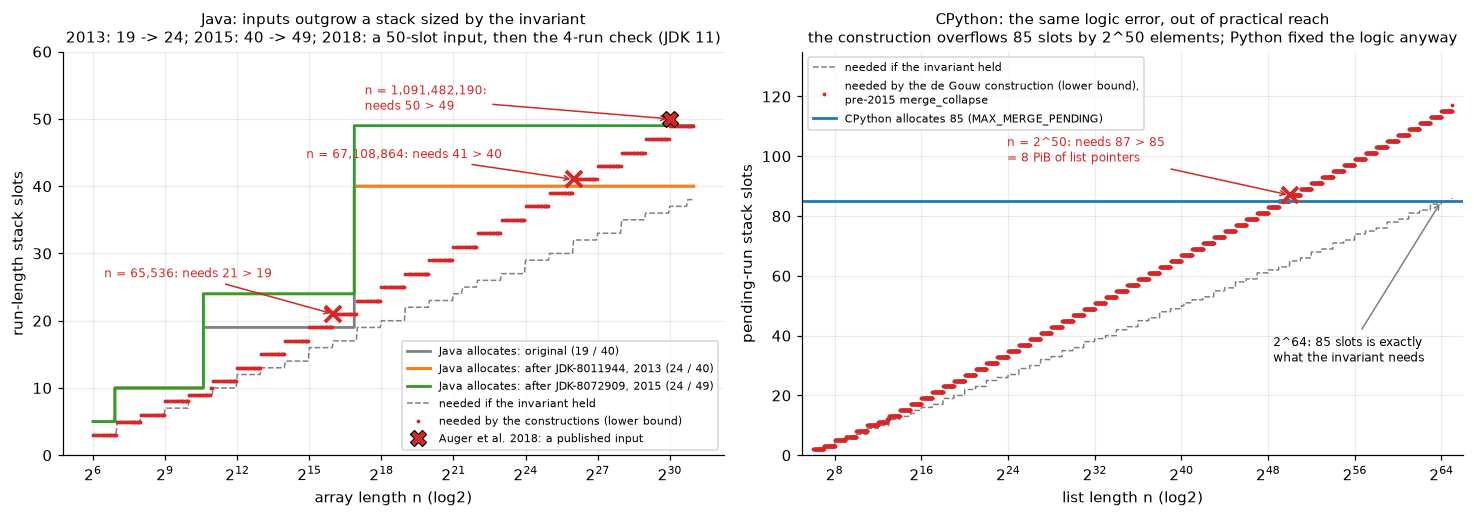

The invariant breaks at 256 elements. Overflows are witnessed at 67,108,864 elements for the 2013 bound (40)
and at 1,091,482,190 for the 2015 bound (49); CPython's 85 slots fall by about 1e+15 at the latest.
Testing samples behaviour, and this bug has no visible behaviour until the overflow -- the proof saw it.


In [144]:
# (4) Sweep the local worst cases n = t * 2^k against each historical Java bound and CPython's fixed 85.
_s11_PY_PENDING = 85                                      # CPython MAX_MERGE_PENDING ("good for 2**64 elements")


def _s11_first_overflows(grid, need):
    '''For each Java bound version: the smallest grid length at which the constructions need more slots than
    allocated (a witnessed overflow; an earlier one by some other input is not excluded).'''
    first = {}
    for label, (mid, top) in _s11_JAVA.items():
        over = [n for n in grid if need[n] > _s11_java_alloc(n, mid, top)]
        first[label] = over[0] if over else None
        print(f"{label:36s}: constructions first overflow "
              + (f"at n = {over[0]:,} (need {need[over[0]]} > {_s11_java_alloc(over[0], mid, top)})"
                 if over else f"nowhere below 2^31 (largest need {max(need.values())})"))
    return first


_s11_grid = sorted({t * 2**k for t in range(16, 32) for k in range(27) if 64 <= t * 2**k < 2**31})
_s11_need = {n: _s11_worst_depth(n) for n in _s11_grid}
_s11_first = _s11_first_overflows(_s11_grid, _s11_need)
_s11_f13, _s11_f06, _s11_f15 = (_s11_first[k] for k in ("after JDK-8011944, 2013 (24 / 40)", "original (19 / 40)",
                                                        "after JDK-8072909, 2015 (24 / 49)"))
_s11_p1 = _s11_f13 == 2**26 and _s11_need[2**26] == 41
_s11_p2 = _s11_f06 == 65_536
_s11_deepest = max([_s11_auger_depth] + list(_s11_need.values()))   # deepest executed input below 2^31
_s11_p3 = _s11_deepest <= 49
print(f"registered prediction: first overflow at 2^26 (41 > 40); 19 fails at 65,536; 49 never fails | measured: "
      f"constructions overflow 40 first at {_s11_f13:,} ({_s11_need[_s11_f13]} slots) and 19 first at "
      f"{_s11_f06:,}; the deepest input executed below 2^31 needs {_s11_deepest} | verdict: "
      f"{'RIGHT' if _s11_p1 and _s11_p2 and _s11_p3 else 'WRONG'}")
print(f"  parts 1-2 {'reproduced' if _s11_p1 and _s11_p2 else 'NOT reproduced'} on the construction (a lower bound, "
      f"so 'first' is witnessed, not proved); part 3 {'holds' if _s11_p3 else 'fails'}: Auger et al.'s "
      f"{_s11_na:,}-element input needs {_s11_auger_depth} {'<=' if _s11_auger_depth <= 49 else '>'} 49")

_s11_pgrid = sorted({t * 2**k for t in range(32, 64) for k in range(1, 62)})
_s11_pneed = {n: _s11_simulate(_s11_worst_case_runs(n, _s11_min_run(n, 64)))[0] for n in _s11_pgrid}
_s11_pover = next(n for n in _s11_pgrid if _s11_pneed[n] > _s11_PY_PENDING)
print(f"\nCPython (minrun 32..64, {_s11_PY_PENDING} slots): the invariant needs {_s11_invariant_bound(2**64, 32)} slots at "
      f"n = 2^64 (32 * phi^85 = {32 * ((1 + 5**0.5) / 2)**85:.2e} vs 2^64 = {2.0**64:.2e}): the source comment, derived")
print(f"the de Gouw construction (a lower bound) first needs {_s11_pneed[_s11_pover]} > {_s11_PY_PENDING} slots at "
      f"n = 2^{_s11_pover.bit_length() - 1} = {_s11_pover:.2e} elements = {_s11_pover * 8 / 2**50:.0f} PiB of "
      "8-byte pointers:\n85 slots fail at that size or earlier")


def _s11_draw_bounds():
    '''Left: Java's allocations vs the executed inputs. Right: CPython's 85 slots vs the same logic error.'''
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
    ax = axes[0]
    xx = np.unique(np.geomspace(64, 2**31 - 1, 3000).astype(np.int64))
    for (label, (mid, top)), col in zip(_s11_JAVA.items(), ["C7", "C1", "C2"]):
        ax.plot(xx, [_s11_java_alloc(int(n), mid, top) for n in xx], color=col, lw=1.8, drawstyle="steps-post",
                label=f"Java allocates: {label}")
    ax.plot(_s11_grid, [_s11_invariant_bound(n, _s11_min_run(n)) for n in _s11_grid], color="gray", ls="--",
            lw=1, label="needed if the invariant held")
    ax.plot(_s11_grid, [_s11_need[n] for n in _s11_grid], ".", color="#d62728", ms=3,
            label="needed by the constructions (lower bound)")
    for label, n in _s11_first.items():
        if n:
            mid, top = _s11_JAVA[label]
            ax.plot(n, _s11_need[n], "x", color="#d62728", ms=10, mew=2.5)
            ax.annotate(f"n = {n:,}: needs {_s11_need[n]} > {_s11_java_alloc(n, mid, top)}", (n, _s11_need[n]),
                        xytext=(-175, 14) if n > 2**20 else (-150, 24), textcoords="offset points",
                        fontsize=8, color="#d62728",
                        arrowprops=dict(arrowstyle="->", color="#d62728"))
    ax.plot(_s11_na, _s11_auger_depth, "X", color="#d62728", mec="black", mew=0.8, ms=11, zorder=5,
            label="Auger et al. 2018: a published input")
    ax.annotate(f"n = {_s11_na:,}:\nneeds {_s11_auger_depth} > {_s11_auger_alloc}", (_s11_na, _s11_auger_depth),
                xytext=(-200, 6), textcoords="offset points", fontsize=8, color="#d62728",
                arrowprops=dict(arrowstyle="->", color="#d62728"))
    ax.set_xscale("log", base=2)
    ax.set_ylim(0, 60)
    ax.set_xlabel("array length n (log2)")
    ax.set_ylabel("run-length stack slots")
    ax.set_title("Java: inputs outgrow a stack sized by the invariant\n2013: 19 -> 24; 2015: 40 -> 49; 2018: a "
                 "50-slot input, then the 4-run check (JDK 11)", fontsize=10)
    ax.legend(fontsize=7.5, loc="lower right")

    ax = axes[1]
    pg = [n for n in _s11_pgrid if n <= 2**65]
    ax.plot(pg, [_s11_invariant_bound(n, _s11_min_run(n, 64)) for n in pg], color="gray", ls="--", lw=1,
            label="needed if the invariant held")
    ax.plot(pg, [_s11_pneed[n] for n in pg], ".", color="#d62728", ms=3,
            label="needed by the de Gouw construction (lower bound),\npre-2015 merge_collapse")
    ax.axhline(_s11_PY_PENDING, color="C0", lw=1.8, label=f"CPython allocates {_s11_PY_PENDING} (MAX_MERGE_PENDING)")
    k_over = _s11_pover.bit_length() - 1
    ax.plot(_s11_pover, _s11_pneed[_s11_pover], "x", color="#d62728", ms=10, mew=2.5)
    ax.annotate(f"n = 2^{k_over}: needs {_s11_pneed[_s11_pover]} > {_s11_PY_PENDING}\n"
                f"= {_s11_pover * 8 / 2**50:.0f} PiB of list pointers", (_s11_pover, _s11_pneed[_s11_pover]),
                xytext=(-185, 22), textcoords="offset points", fontsize=8, color="#d62728",
                arrowprops=dict(arrowstyle="->", color="#d62728"))
    ax.annotate(f"2^64: {_s11_invariant_bound(2**64, 32)} slots is exactly\nwhat the invariant needs",
                (2.0**64, _s11_invariant_bound(2**64, 32)), xytext=(-110, -105), textcoords="offset points",
                fontsize=8, arrowprops=dict(arrowstyle="->", color="gray"))
    ax.set_xscale("log", base=2)
    ax.set_ylim(0, 135)
    ax.set_xlim(2.0**5, 2.0**66)
    ax.set_xticks([2.0**k for k in range(8, 65, 8)])
    ax.set_xlabel("list length n (log2)")
    ax.set_ylabel("pending-run stack slots")
    ax.set_title(f"CPython: the same logic error, out of practical reach\nthe construction overflows 85 slots by "
                 f"2^{k_over} elements; Python fixed the logic anyway", fontsize=10)
    ax.legend(fontsize=7.5, loc="upper left")
    plt.tight_layout()
    plt.show()


_s11_draw_bounds()
print(f"The invariant breaks at {_s11_nmin} elements. Overflows are witnessed at {_s11_f13:,} elements for the 2013 "
      f"bound (40)\nand at {_s11_na:,} for the 2015 bound (49); CPython's 85 slots fall by about {_s11_pover:.0e} "
      "at the latest.")
print("Testing samples behaviour, and this bug has no visible behaviour until the overflow -- the proof saw it.")

The two projects first responded in opposite ways, and both responses are on record. **OpenJDK** raised the
bound, twice. JDK-8011944 (fixed in JDK 8 b106, 2013) followed a crash at index 19 and moved 19 to 24, which left
the 40 that the 2²⁶-element construction overflows. JDK-8072909 (JDK 9 b51, February 2015) reported that 40 does
not suffice and moved it to 49, the depth of de Gouw et al.'s construction at 2³⁰. That construction rested on
the false Lemma 1, and Auger, Jugé, Nicaud and Pivoteau (2018, arXiv 1805.08612) published the
1,091,482,190-element input replayed above, which needs 50 slots. OpenJDK then adopted the four-run check
(JDK-8203864, fixed in JDK 11 b20, June 2018). The bound is still 49, and the source credits de Gouw et al. and
Auger et al. **CPython** fixed the logic the day after Tim Peters filed bpo-23515 (24–25 February 2015, on 2.7,
3.4 and the development branch), although no machine had the memory to trigger the bug. Peters rejected simply
enlarging `MAX_MERGE_PENDING` as absurd: the Java developers had enlarged their bound and still got it wrong, and
without the invariant nobody knows how much is enough. In his words, "a logical error is an error, and will bite
us eventually". The cell above bounds how far away "eventually" was: about 10¹⁵ elements (8 PiB of pointers) at
the latest, for the construction. Java's 50-slot input shows that the true worst case can come sooner. (Since
3.11 CPython uses the powersort merge policy instead.)

The episode is the whole notebook in miniature. Random testing could not see a violation with no observable
symptom (§1). A proof attempt failed on a precise obligation (§6). The counterexample to induction was reachable,
so the invariant is false of the running code (§6.4's diagnosis, found here by §8's kind of search). Because Java
sized its stack from that invariant, the invariant is the spec and the code is what was wrong. Raising the bound
failed twice: once sized from a crash report (19 → 24), once from a worst-case analysis whose lemma was false (40
→ 49). Exhausting every stack up to 200 elements found no counterexample to that lemma, while the published
counterexample, scaled to legal Java run lengths, has 4,848 elements, so §2.2's small scope hypothesis failed too.
Only the logic fix restores invariant-based sizing: on the same 50-slot input, the fixed code never needs more
than 18 slots.

### 11.6 Verified code you are probably running

- **Cryptography** is where verified code ships at scale. CPython 3.12 replaced its built-in MD5, SHA-1, SHA-2
  and SHA-3 fallbacks with HACL\* code, and 3.14 added HACL\* BLAKE2 and HMAC. Firefox 57 shipped HACL\*
  Curve25519, which ran about 29% more scalar multiplications per second on 64-bit than the code it replaced
  (19,500 vs 15,100; Mozilla, 2017, describes this as "almost 20% faster"). A November 2019 Linux kernel commit
  added verified Curve25519: 64-bit from HACL\*, 32-bit from Fiat-crypto. Fiat Cryptography's field arithmetic
  is in BoringSSL and from there in Chrome, Android and Cloudflare (Erbsen et al., IEEE S&P 2019).
- **Kernels and compilers.** seL4's 2025 FAQ lists a ~10,000-SLOC 64-bit RISC-V kernel proved correct down to
  the binary, with security proofs whose confidentiality part makes no claim about covert timing channels; in
  August 2026 Proofcraft completed the confidentiality proof on AArch64. CompCert is sold by AbsInt and was
  qualified in March 2026 for the ATR 42/72 Multi-Function Computer New Generation; in 2009 its code ran about
  7% slower than `gcc -O1` and 12% slower than `-O2` on PowerPC.
- **Transport.** Paris Métro Line 14 opened on 15 October 1998 with a B-proved safety core: 86,000 lines of Ada
  generated from about 115,000 lines of B, with 27,800 proof obligations (RATP). Its vendor-affiliated authors
  report no bugs found after the proofs, in validation or in operation (Lecomte et al., 2007).
- **Cloud.** AWS's Zelkova answers access-policy questions with SMT, about a billion queries a day by 2022
  (Rungta, CAV 2022; §4.6 places its solver portfolio on the decidability map). In s2n, SAW proves 103 lines of
  HMAC C equivalent to a Cryptol implementation on every code change, and a Coq proof relates that implementation
  to a 3-line Cryptol specification matching NIST's (Galois). Firecracker runs 27 Kani harnesses in CI (Kani
  blog, Aug 2023; §5.3 explains what a harness bounds), and the Rust standard-library campaign checks over 16,000
  harnesses per change (Kani paper, 2026).

The pattern across the rows is what §12 will price. Verification ships where the spec is small and stable (a
hash function, a policy language, an equivalence to an older program), where an escaped bug is very expensive,
or where certification already demands the evidence. The rest of the code relies on tests.

## 12. Economics: why isn't everything verified?

§11 settled the engineering question. Verification works: the verified middle-end of CompCert and the verified
cores of IronFleet and Verdi had zero bugs when independent teams attacked them. So why does almost no shipped
software carry a proof? The obvious answer is cost, and it is half right. A verified line of seL4 cost hundreds of
dollars. But "expensive" means nothing until it is compared with the cost of the bugs the proof prevents, and
those differ between a web form and a flight computer by orders of magnitude. This section prices both sides from
sourced numbers, puts them on one plane, and asks what happens to the boundary when LLMs make proofs cheap.

### 12.1 The inequality

Take a component of $L$ lines. Verifying it costs $c_v$ dollars per line up front. Code then changes. If a
fraction $u$ of it is rewritten over its life, and re-verifying costs $r$ times the changed fraction of the
original proof effort, maintenance adds $r\,u\,c_v L$. On the other side, let $\delta$ be the number of critical
bugs per line that would escape without the proof (and that the proof would have caught), let $E[\text{loss}]$
be the loss each one causes, and let $s$ be the testing, review or certification cost per line that the proof
replaces. Verification pays iff

$$c_v L\,(1 + r u) \;<\; \delta\, L\, E[\text{loss}] + s L
\quad\Longleftrightarrow\quad
E[\text{loss}] \;>\; \frac{c_v(1 + r u) - s}{\delta}.$$

Three consequences follow before any number is plugged in.

1. **$L$ cancels.** The decision is per line, so it can be drawn on a plane with
   $x = c_v(1+ru)$ (lifetime verification cost per line) and $y = E[\text{loss}]$ (loss per escaped critical
   bug). With $s = 0$ the threshold is the line $y = x/\delta$: slope 1 on log-log axes. Above it, verify; below
   it, test.
2. **$\delta$ is the number nobody publishes.** It measures how buggy the *unverified alternative* would be, and
   it sets the height of the line. We therefore read the inequality backwards. Verification pays iff, without
   it, one such escape would occur more often than once every $N^* = E[\text{loss}]/x$ lines. $N^*$ is computed
   from the sourced boxes below, and the reader can judge whether a bug that size every $N^*$ lines is plausible.
3. **If $s > x$, the inequality holds at $E[\text{loss}] = 0$.** Where certification already demands expensive
   evidence (avionics, Common Criteria), a proof can win on cost alone. That is seL4's own argument (§12.3).

The model leaves out time to market, the option value of changing code quickly, and the scarcity of people who
can write proofs. All of these push in the same direction as the maintenance term.

It also counts escapes only in the $L$ lines as first written. The $uL$ lines rewritten later would carry escapes
of their own. Counting them multiplies the right-hand side by $1 + u$, so churn's net effect on the cost per
prevented escape becomes $(1 + ru)/(1 + u)$, which exceeds 1 only when $r > 1$. Leaving them out, like setting
$s = 0$ below, tilts the plane against high-churn code; §12.3 prints which verdicts change when they are counted.

### 12.2 What does a verified line cost?

§11's `CASES` table gives effort in person-years for six rows, five code bases (seL4 appears twice: the 2009
functional-correctness accounting and the 2014 TOCS one). To turn effort into dollars we need a price per
person-year. We use a stated range with sources. The low end is the US median wage for software developers,
\$135,980 (BLS Occupational Outlook, May 2025), divided by the wage share of employer compensation, 70.0% (BLS
Employer Costs for Employee Compensation, June 2026). This adds benefits but no office, management or tool
overhead, so the range errs low. The high end is the same calculation for the BLS top-decile threshold,
\$214,670. Dividing by verified lines gives \$/LOC, in 2025 dollars.

seL4 published its own figure: **\$362 per SLOC** for the whole 22.7 person-years, and \$127/SLOC for an
estimated 8-person-year replication on a new kernel (Klein et al., TOCS 2014). The 22.7 person-years are kernel
development (2.2) plus the functional-correctness proof (20.5); the fastpath, security, binary-verification and
capDL proofs in the same effort table (the paper's Fig. 19) are not part of it. The paper states neither the price
per person-year behind the figure nor its price year.

**Registered prediction:** *pricing seL4's 22.7 person-years at our US loaded-cost range, over its 8,700–10,000
SLOC, gives an interval that contains the published \$362/SLOC.*

The cell scores the prediction as registered, against the nominal \$362, and then repeats the comparison in 2025
dollars with the BLS consumer price index (CPI-U), because our wages are 2025 wages. The losses, the FDIV charge
and the EAL6 rule of thumb below are converted the same way, by the year they were incurred; seL4's other
published \$/SLOC figures are drawn as published (nominal).

In [145]:
# What one verified line costs: CASES effort (person-years) x a loaded cost per person-year / verified lines.
# Every judgment call is in this dict; sourced inputs carry their source in _s12_SOURCED.
_s12_ASSUMPTIONS = {
    "overhead_multiplier": (1.0, "loaded cost = compensation only; office, management, tools left out => LOW"),
    "price_level": ("US, 2025 $", "effort is priced at 2025 US wages; other dollar amounts are converted to 2025 $ "
                                  "with CPI-U by the year they were incurred"),
    "effort_scope": ("as CASES states it", "seL4 2009's high reading includes ~9 py of tools + 2.2 py of coding"),
    "sel4_price_year": ((2009, 2014), "TOCS 2014 states no price year: from the SOSP 2009 effort accounting to "
                                      "publication; an earlier year would only raise the 2025-$ value"),
}
_s12_SOURCED = {
    "wage_median": (135_980, "BLS Occupational Outlook: software developers, median annual wage, May 2025"),
    "wage_p90": (214_670, "BLS Occupational Outlook: software developers, top-10% threshold, May 2025"),
    "wage_share": (0.700, "BLS ECEC, June 2026: wages are 70.0% of private-industry compensation cost"),
    "sel4_actual": (362, "Klein et al., TOCS 2014: $/SLOC for the whole 22.7 py (no price year stated)"),
    "sel4_replica": (127, "Klein et al., TOCS 2014: $/SLOC for an estimated 8 py replication"),
    "sel4_security": (78, "Klein et al., TOCS 2014: integrity + confidentiality proofs, $/SLOC"),
    "eal6": (1_000, "Klein et al., TOCS 2014: industry rule of thumb for Common Criteria EAL6, $/LOC"),
    "sel4_sloc": ((8_700, 10_000), "SOSP 2009 abstract: 8,700 lines of C; TOCS 2014: 'of the order of 10,000'"),
}
# BLS CPI-U, US city average, all items, annual averages (series CUUR0000SA0, read via FRED series CPIAUCNS).
# 2025 is the mean of the 11 published months: no index was published for October 2025.
_s12_CPI = {1994: 148.225, 1996: 156.850, 2009: 214.537, 2014: 236.736, 2016: 240.007, 2024: 313.689,
            2025: 321.943}
# seL4 effort by artefact, person-years (Klein et al., TOCS 2014, Fig. 19).
_s12_FIG19 = {"development": 2.2, "functional correctness": 20.5, "fastpath": 0.4, "security": 4.1,
              "binary verification": 2.0, "capDL": 2.0}
_s12_CLASS_COLOR = {"itp": "C0", "auto-active": "C1"}


def _s12_to_2025(v, year):
    '''Dollars of `year` -> 2025 dollars (CPI-U ratio).'''
    return v * _s12_CPI[2025] / _s12_CPI[year]


_s12_EAL6_25 = _s12_to_2025(_s12_SOURCED["eal6"][0], 2014)        # the 2014 rule of thumb in 2025 $
_s12_overhead = _s12_ASSUMPTIONS["overhead_multiplier"][0]
_s12_cost_lo = _s12_SOURCED["wage_median"][0] / _s12_SOURCED["wage_share"][0] * _s12_overhead
_s12_cost_hi = _s12_SOURCED["wage_p90"][0] / _s12_SOURCED["wage_share"][0] * _s12_overhead


def _s12_dollars_per_loc(row, cost_lo=None, cost_hi=None):
    '''(low, high) $/LOC for one CASES row: low effort at the low price, high effort at the high price.'''
    cost_lo, cost_hi = cost_lo or _s12_cost_lo, cost_hi or _s12_cost_hi
    return (row["person_years_lo"] * cost_lo / row["code_loc"], row["person_years_hi"] * cost_hi / row["code_loc"])


_s12_ROWS = [r for r in CASES if r["person_years_lo"] is not None and r["code_loc"]]
_s12_COST = {r["system"]: _s12_dollars_per_loc(r) for r in _s12_ROWS}
_s12_CASE = {r["system"]: r for r in _s12_ROWS}
show_table(["system", "class", "person-years", "verified lines", "$/LOC low", "$/LOC high"],
           [[r["system"][:30], r["tool_class"], f"{r['person_years_lo']:g}-{r['person_years_hi']:g}",
             f"{r['code_loc']:,}", *(f"${v:,.0f}" for v in _s12_COST[r["system"]])] for r in _s12_ROWS])
print(f"loaded cost per person-year: ${_s12_cost_lo:,.0f} - ${_s12_cost_hi:,.0f} "
      f"(BLS median and top-decile wage / {_s12_SOURCED['wage_share'][0]:.0%})")

# The registered prediction: the 22.7 py of seL4 at our prices, over 8,700-10,000 SLOC.
_s12_PY_SEL4 = _s12_FIG19["development"] + _s12_FIG19["functional correctness"]
_s12_sloc_lo, _s12_sloc_hi = _s12_SOURCED["sel4_sloc"][0]
_s12_sel4_lo = _s12_PY_SEL4 * _s12_cost_lo / _s12_sloc_hi
_s12_sel4_hi = _s12_PY_SEL4 * _s12_cost_hi / _s12_sloc_lo
_s12_pub = _s12_SOURCED["sel4_actual"][0]
_s12_inside = _s12_sel4_lo <= _s12_pub <= _s12_sel4_hi
_s12_y0, _s12_y1 = _s12_ASSUMPTIONS["sel4_price_year"][0]
_s12_pub25 = (_s12_to_2025(_s12_pub, _s12_y1), _s12_to_2025(_s12_pub, _s12_y0))     # later year -> smaller value
_s12_inside25 = _s12_sel4_lo <= _s12_pub25[0] and _s12_pub25[1] <= _s12_sel4_hi
_s12_implied = [_s12_pub * s / _s12_PY_SEL4 for s in (_s12_sloc_lo, _s12_sloc_hi)]
_s12_implied25 = (_s12_to_2025(_s12_implied[0], _s12_y1), _s12_to_2025(_s12_implied[1], _s12_y0))
print(f"\nseL4 (22.7 py = {_s12_FIG19['development']} dev + {_s12_FIG19['functional correctness']} correctness) at "
      f"US loaded cost: ${_s12_sel4_lo:,.0f} - ${_s12_sel4_hi:,.0f} per SLOC; published ${_s12_pub} (nominal)")
print(f"registered prediction: our interval contains ${_s12_pub}/SLOC | measured: "
      f"[${_s12_sel4_lo:,.0f}, ${_s12_sel4_hi:,.0f}] vs the nominal ${_s12_pub} | verdict as registered: "
      f"{'RIGHT' if _s12_inside else 'WRONG'} — but it compared 2025 wages with a figure in older dollars")
print(f"like for like: ${_s12_pub} in {_s12_y1} $ = ${_s12_pub25[0]:,.0f}, in {_s12_y0} $ = ${_s12_pub25[1]:,.0f} "
      f"(2025 $, CPI-U): {'inside' if _s12_inside25 else 'outside'} our interval")
print(f"the published figure implies ${_s12_implied[0]:,.0f} - ${_s12_implied[1]:,.0f} per person-year nominal, "
      f"${_s12_implied25[0]:,.0f} - ${_s12_implied25[1]:,.0f} in 2025 $; our compensation-only range is "
      f"${_s12_cost_lo:,.0f} - ${_s12_cost_hi:,.0f}")
_s12_py_all = sum(_s12_FIG19.values())
print(f"all of Fig. 19 ({_s12_py_all:.1f} py, adding fastpath, security, binary and capDL proofs) at our prices: "
      f"${_s12_py_all * _s12_cost_lo / _s12_sloc_hi:,.0f} - ${_s12_py_all * _s12_cost_hi / _s12_sloc_lo:,.0f} "
      "per SLOC")
print(f"EAL6 rule of thumb: ${_s12_SOURCED['eal6'][0]:,}/LOC (2014) = ${_s12_EAL6_25:,.0f}/LOC in 2025 $")
print("The price level, not the labour, explains the gap: in 2025 dollars seL4's own figure lands inside our range.")

system                         class        person-years  verified lines  $/LOC low  $/LOC high
-----------------------------------------------------------------------------------------------
seL4 (functional correctness)  itp          13.7-22.7     8,700           $306       $800      
seL4 (comprehensive, TOCS)     itp          22.2-31.2     10,000          $431       $957      
CompCert                       itp          3-3           5,880           $99        $156      
IronFleet (IronRSL + IronKV)   auto-active  3.7-3.7       5,114           $141       $222      
CertiKOS mC2                   itp          2-2           6,500           $60        $94       
EverCrypt (HACL* + Vale)       auto-active  3-4           43,874          $13        $28       
loaded cost per person-year: $194,257 - $306,671 (BLS median and top-decile wage / 70%)

seL4 (22.7 py = 2.2 dev + 20.5 correctness) at US loaded cost: $441 - $800 per SLOC; published $362 (nominal)
registered prediction: our interv

The figure puts every row's cost per line on one axis, with seL4's published figures on its row, and then checks
the naive maintenance assumption, that re-verification costs in proportion to the lines changed, against what seL4
published about the cost of change (Sec. 7.4 of the TOCS paper).

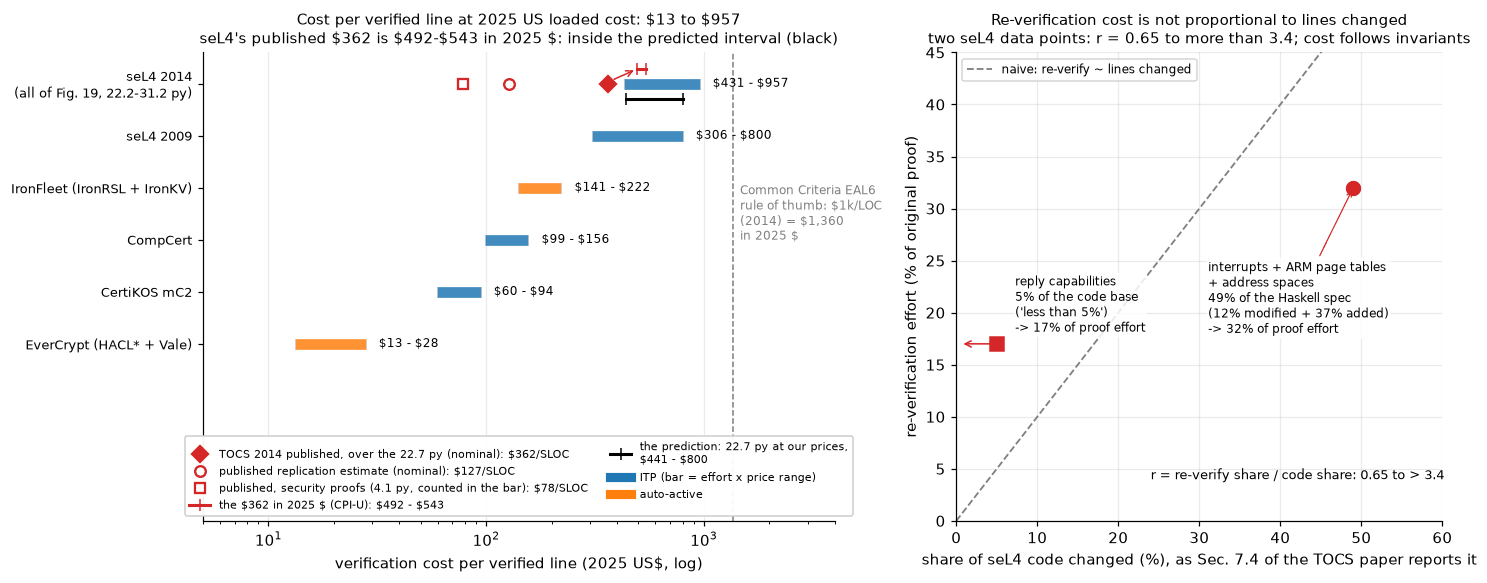

Re-verification cost 0.65x to more than 3.4x the share of code changed (the second change touched 'less than 5%'):
lines changed do not predict proof cost. The lifetime cost of a verified line is c_v * (1 + r*u), with r from 0.65 to 3.4;
the high end is a lower bound for that change, so high-end lifetime costs are, if anything, low.


In [146]:
# Re-verification after changes, seL4 (Klein et al., TOCS 2014, Sec. 7.4):
# (change, what the share is of, share of code changed, share of original proof effort to re-verify).
_s12_REVERIFY = [("interrupts + ARM page tables\n+ address spaces", "of the Haskell spec\n(12% modified + 37% added)",
                  0.12 + 0.37, 0.32),
                 ("reply capabilities", "of the code base\n('less than 5%')", 0.05, 0.17)]
_s12_r = [p / c for _, _, c, p in _s12_REVERIFY]                  # re-verify share per unit of code share
_s12_r_lo, _s12_r_hi = min(_s12_r), max(_s12_r)


def _s12_draw_costs():
    '''Left: $/LOC per CASES row (log). Right: seL4's re-verification costs vs the proportional model.'''
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    order = sorted(_s12_ROWS, key=lambda r: np.sqrt(np.prod(_s12_COST[r["system"]])))
    for yi, r in enumerate(order):
        lo, hi = _s12_COST[r["system"]]
        col = _s12_CLASS_COLOR[r["tool_class"]]
        ax.plot([lo, hi], [yi, yi], color=col, lw=7, solid_capstyle="butt", alpha=0.85)
        ax.text(hi * 1.15, yi, f"\\${lo:,.0f} - \\${hi:,.0f}", va="center", fontsize=8)
    y14 = [i for i, r in enumerate(order) if r["system"] == "seL4 (comprehensive, TOCS)"]
    s14 = _s12_CASE["seL4 (comprehensive, TOCS)"]
    for key, mk, lab in [("sel4_actual", "D", "TOCS 2014 published, over the 22.7 py (nominal)"),
                         ("sel4_replica", "o", "published replication estimate (nominal)"),
                         ("sel4_security", "s", "published, security proofs (4.1 py, counted in the bar)")]:
        v = _s12_SOURCED[key][0]
        ax.plot([v] * len(y14), y14, mk, color="#d62728", ms=7, mfc="#d62728" if mk == "D" else "white", mew=1.5,
                label=f"{lab}: \\${v}/SLOC", zorder=4)
    for yi in y14:                       # the published $362 converted to 2025 $, drawn just above its row
        ax.plot(_s12_pub25, [yi + 0.28] * 2, color="#d62728", lw=2, marker="|", ms=8, zorder=4)
        ax.annotate("", (_s12_pub25[0], yi + 0.28), (_s12_pub * 1.04, yi + 0.06),
                    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1))
    ax.plot([], [], color="#d62728", lw=2, marker="|", ms=8,
            label=f"the \\$362 in 2025 \\$ (CPI-U): \\${_s12_pub25[0]:,.0f} - \\${_s12_pub25[1]:,.0f}")
    for yi in y14:                       # the registered prediction (22.7 py at our prices), drawn just below the row
        ax.plot([_s12_sel4_lo, _s12_sel4_hi], [yi - 0.3] * 2, color="black", lw=2, marker="|", ms=8, zorder=4)
    ax.plot([], [], color="black", lw=2, marker="|", ms=8,
            label=f"the prediction: 22.7 py at our prices,\n\\${_s12_sel4_lo:,.0f} - \\${_s12_sel4_hi:,.0f}")
    ax.axvline(_s12_EAL6_25, color="gray", ls="--", lw=1)
    ax.text(_s12_EAL6_25 * 1.08, 2.5, f"Common Criteria EAL6\nrule of thumb: \\$1k/LOC\n(2014) = \\${_s12_EAL6_25:,.0f}"
            "\nin 2025 \\$", fontsize=8, color="gray", va="center")
    ax.set_yticks(range(len(order)), [r["system"].replace(" (functional correctness)", " 2009")
                                      .replace(" (comprehensive, TOCS)", f" 2014\n(all of Fig. 19, "
                                               f"{s14['person_years_lo']:g}-{s14['person_years_hi']:g} py)")
                                      for r in order], fontsize=8.5)
    ax.set_xscale("log")
    ax.set_xlim(5, 4e3)
    ax.set_ylim(-3.4, len(order) - 0.4)              # room below the rows for the legend
    ax.set_xlabel("verification cost per verified line (2025 US\\$, log)")
    ax.plot([], [], color="C0", lw=6, label="ITP (bar = effort x price range)")
    ax.plot([], [], color="C1", lw=6, label="auto-active")
    ax.legend(fontsize=7, loc="lower center", ncol=2, framealpha=0.95)
    ax.grid(axis="y", visible=False)
    lo_all, hi_all = min(v[0] for v in _s12_COST.values()), max(v[1] for v in _s12_COST.values())
    ax.set_title(f"Cost per verified line at 2025 US loaded cost: \\${lo_all:,.0f} to \\${hi_all:,.0f}\n"
                 f"seL4's published \\${_s12_pub} is \\${_s12_pub25[0]:,.0f}-\\${_s12_pub25[1]:,.0f} in 2025 \\$: "
                 f"{'inside' if _s12_inside25 else 'outside'} the predicted interval (black)", fontsize=10)

    ax = axes[1]
    xx = np.linspace(0, 0.6, 50)
    ax.plot(100 * xx, 100 * xx, ls="--", color="gray", lw=1.2, label="naive: re-verify ~ lines changed")
    for (lab, what, c, p), mk in zip(_s12_REVERIFY, ["o", "s"]):
        ax.plot(100 * c, 100 * p, mk, ms=9, color="#d62728", zorder=4)
        ax.annotate(f"{lab}\n{c:.0%} {what}\n-> {p:.0%} of proof effort", (100 * c, 100 * p),
                    xytext=(-95, -95) if c > 0.3 else (12, 8), textcoords="offset points", fontsize=8,
                    bbox=dict(fc="white", ec="none", alpha=0.85, pad=1),
                    arrowprops=dict(arrowstyle="->", color="#d62728", lw=0.8) if c > 0.3 else None)
    ax.annotate("", xy=(0.5, 17), xytext=(5, 17), arrowprops=dict(arrowstyle="->", color="#d62728"))
    ax.text(24, 4, f"r = re-verify share / code share: {_s12_r_lo:.2f} to > {_s12_r_hi:.1f}", fontsize=8.5)
    ax.set_xlim(0, 60)
    ax.set_ylim(0, 45)
    ax.set_xlabel("share of seL4 code changed (%), as Sec. 7.4 of the TOCS paper reports it")
    ax.set_ylabel("re-verification effort (% of original proof)")
    ax.legend(fontsize=8, loc="upper left")
    ax.set_title("Re-verification cost is not proportional to lines changed\n"
                 f"two seL4 data points: r = {_s12_r_lo:.2f} to more than {_s12_r_hi:.1f}; cost follows invariants",
                 fontsize=10)
    plt.tight_layout()
    plt.show()


_s12_draw_costs()
print(f"Re-verification cost {_s12_r_lo:.2f}x to more than {_s12_r_hi:.1f}x the share of code changed (the second "
      "change touched 'less than 5%'):")
print(f"lines changed do not predict proof cost. The lifetime cost of a verified line is c_v * (1 + r*u), with r from "
      f"{_s12_r_lo:.2f} to {_s12_r_hi:.1f};\nthe high end is a lower bound for that change, so high-end lifetime costs "
      "are, if anything, low.")

The prediction failed as registered, and it was ill-posed: it set a 2025 wage range against a figure that the
paper reports without a price year. Like for like the gap disappears. Converted with CPI-U, \$362 is \$492–\$543
in 2025 dollars (price year 2014 or 2009; an earlier year only raises it), inside our interval, and it implies
about \$189k–\$239k per person-year, overlapping our \$194k–\$307k range of salary plus benefits. The price level
explains the miss on its own: seL4's published figure is consistent with paying market compensation, and what
both it and our range leave out is overhead (office, management, tools). The paper also names no currency; the
project ran at NICTA in Australia. The top bar of the figure is a different quantity: all of Fig. 19 (22.2–31.2
person-years, adding the fastpath, security, binary and capDL proofs), so it sits to the right of the prediction's
22.7-person-year interval. Cost per line depends on more than the tool: EverCrypt is cheapest because its specs
are cryptographic standards and its output is regular generated C and assembly, while seL4's effort includes
building frameworks that later projects reused.

**Maintenance breaks the naive model.** seL4's reported changes (Sec. 7.4 of the TOCS paper) are the only
published maintenance data on a large proof that we found. Local optimisations cost re-verification "roughly
proportional to the size of the change", and a new batching system call needed under 0.25 person-months of proof.
Adding interrupts, ARM page tables and address spaces modified 12% and added 37% of the Haskell executable
specification, and cost 32% of the original effort. Adding reply capabilities touched under 5% of the code base
but broke invariants about capability creation and deletion everywhere, and cost 17%: more than three times its
share of lines. Re-verification cost follows the **invariants a change touches**, not its size. *QED at Large*
(Ringer, Palmskog, Sergey, Gligoric & Tatlock, 2019) treats proof maintenance as a central problem of the field,
and §7.6 measured a second source of decay: solver cost that swings by up to about 5× across semantically
irrelevant changes, which breaks any proof whose resource limit sits near that cost. Every lifetime cost below
carries the measured range of $r$. (The seL4 paper also notes the other side: after verification, implementation
bug fixes stopped.)

### 12.3 The plane: cost per line against loss per escaped bug

Each domain is a **box**: its x-range is the lifetime cost per line of the closest `CASES` rows, and its y-range
spans sourced losses from escaped bugs in that domain, converted to 2025 dollars; where nobody has priced the
tail, the box is open at the top. The cell prints the source of every edge, and every judgment call (which rows
stand for which domain, how much its code churns, the reference $\delta$) sits in its assumptions dict. Two of the
incidents are bug classes this notebook built tools for. CrowdStrike's outage was the kernel-mode out-of-bounds
read of §1.3, a bounds obligation of the kind §6 discharges. The AWS us-east-1 outage of 20 October 2025 had as
root cause "a latent race condition in the DynamoDB DNS management system" (AWS post-event summary), a state-space
property of the kind §8 checks.

**One $\delta$ for every box** is the plane's strongest simplification. Small-loss escapes are far more frequent
per line than catastrophic ones, so a common $\delta$ favours verifying the high-loss boxes and penalises the web
app. The verdict cell below prints the web app's verdict at a $\delta$ two decades higher, and its $N^*$ columns
let a reader apply a different $\delta$ to each domain. Three edges use IBM's global average breach cost,
\$4.99M; the same report puts the US average at \$11.5M (IBM, *Cost of a Data Breach 2026*, as summarised by
eSecurityPlanet, 30 July 2026), so those edges are low for a comparison priced at US wages. The verdict cell
prints what the US figure, and the symmetric churn accounting of §12.1, would change.

One lightweight method goes on the plane too. A **TLA+ or P model** checks the *design*, not the code, so its
cost does not scale with lines; AWS's specs ran 102–939 lines (Newcombe et al., CACM 2015). How long one model
takes is not published. AWS engineers, from entry level to principal, learned TLA+ from scratch and got useful
results in two to three weeks (same paper). That is a floor, so the per-model effort is an assumption from 2 to 26
engineer-weeks. The guarantee is partial, since a design model says nothing about whether the code matches it, so
we divide its cost by an assumed coverage. That puts it on the same axis as a proof: dollars per line per unit of
guarantee. Upkeep is charged as for a proof, through the cloud's churn at seL4's code-proof $r$. A design changes
less often than its code, so this may overcharge the model; the verdict cell also prints the box with no upkeep.

In [147]:
# The plane: domains as boxes of (lifetime $/LOC, loss per escaped critical bug); the threshold y = x / delta.
_s12_PLANE_ASSUMPTIONS = {
    "delta_ref": (1e-6, "reference: one box-sized critical escape per million unverified lines"),
    "delta_band": ((1e-7, 1e-5), "plausible range of delta, drawn shaded (one per 10M to one per 100k lines)"),
    "delta_uniform": (True, "the same delta for every box; real escape rates fall with loss size, so this "
                            "favours the high-loss boxes and penalises the web app"),
    "saved_cost_s": (0.0, "the testing/certification a proof replaces is ignored on the plane => conservative"),
    "churn_u": ({"crypto library": 0.5, "OS kernel / hypervisor": 1.0, "avionics": 0.5, "smart contract": 0.0,
                 "cloud control plane": 3.0, "web app": 10.0},
                "lifetime share of code rewritten; smart contracts taken as non-upgradeable once deployed"),
    "x_rows": ("see _s12_DOMAINS", "avionics -> CompCert (qualified for ATR 42/72; Astree reports no effort); "
                                   "smart contract and web app -> the auto-active rows (Dafny/F*-class tools)"),
    "web_incident_days": (1, "the cheapest web-app escape: one engineer-day of incident response + redeploy"),
    "work_days_per_year": (230, "to price an engineer-day"),
    "tla_effort_weeks": ((2, 26), "engineer-weeks to write and check one model (upkeep is charged through churn, "
                                  "below); AWS's 2-3 weeks to a first useful result (learning included) is the floor"),
    "tla_upkeep": ("as code churn", "the model is re-checked as the cloud's code churns (u = 3) at seL4's "
                                    "code-proof r; a design changes less often than its code => may overcharge"),
    "tla_service_loc": ((50_000, 500_000), "size of the service a TLA+/P model covers"),
    "tla_coverage": ((0.1, 0.5), "share of box-sized escapes that are design bugs inside the model"),
    "churn_benefit": (False, "escapes in the u*L rewritten lines are not counted on the benefit side (Sec. 12.1); "
                             "this penalises high-churn boxes (web app, cloud)"),
    "breach_scope": ("global", "IBM's global average breach; its US average is $11.5M, so the breach edges are low "
                               "for a comparison priced at US wages"),
}
_s12_A = {k: v[0] for k, v in _s12_PLANE_ASSUMPTIONS.items()}
_s12_LOSS_RAW = {   # US$ per escaped critical bug as published: (value, price year, source)
    "breach": (4.99e6, 2025, "IBM Cost of a Data Breach 2026: global average breach (record high), taken as "
                             "2025 $"),
    "crowdstrike": (5.4e9, 2024, "Parametrix: Fortune 500 direct loss, CrowdStrike 19 Jul 2024 (model estimate)"),
    "ariane": (3.7e8, 1996, "Ariane 501, 1996: 'more than $370M' (secondary estimate; inquiry gives no figure)"),
    "hack_mean": (2.2e9 / 303, 2024, "Chainalysis (19 Dec 2024): $2.2B stolen in 303 incidents in 2024, mean per "
                                     "incident, ALL causes (private-key compromises were 43.8% of the value, "
                                     "which no contract proof prevents): a rough stand-in"),
    "dao": (5.0e7, 2016, "The DAO, 2016: ~3.6M ETH drained by a recursive-call (reentrancy) bug, ~$50M then; "
                         "one famous incident, not a maximum"),
    "aws_lo": (5.0e8, 2025, "Parametrix: US losses from the AWS us-east-1 outage, 20 Oct 2025, low estimate"),
    "aws_hi": (6.5e8, 2025, "Parametrix: same event, high estimate"),
    "web_lo": (_s12_A["web_incident_days"] * _s12_cost_lo / _s12_A["work_days_per_year"], 2025,
               "ASSUMPTION: one engineer-day at the BLS-derived low cost"),
    "open_crypto": (None, None, "unpriced tail: Heartbleed exposed ~17% of trusted HTTPS servers (Netcraft "
                                "2014), no primary loss estimate exists"),
    "open_avionics": (None, None, "unpriced tail: a crewed-aircraft accident (loss of life is not priced here)"),
}
_s12_ASSUMED_LOSS = {"web_lo"}                       # edges that are our assumption, not a sourced figure
_s12_LOSS = {k: (_s12_to_2025(v, yr) if v else None, src) for k, (v, yr, src) in _s12_LOSS_RAW.items()}
_s12_SEL4 = ["seL4 (functional correctness)", "seL4 (comprehensive, TOCS)"]
_s12_AA = ["EverCrypt (HACL* + Vale)", "IronFleet (IronRSL + IronKV)"]
_s12_DOMAINS = [  # name, CASES rows for x, loss keys (lo, hi), colour
    ("crypto library", ["EverCrypt (HACL* + Vale)"], ("breach", "open_crypto"), "C2"),
    ("OS kernel / hypervisor", _s12_SEL4 + ["CertiKOS mC2"], ("breach", "crowdstrike"), "C0"),
    ("avionics", ["CompCert"], ("ariane", "open_avionics"), "C4"),
    ("smart contract", _s12_AA, ("hack_mean", "dao"), "C1"),
    ("cloud control plane", ["IronFleet (IronRSL + IronKV)"], ("aws_lo", "aws_hi"), "C9"),
    ("web app", _s12_AA, ("web_lo", "breach"), "C7"),
]
_s12_CEIL = 1e12                                     # plot ceiling; open boxes are drawn up to it with an arrow


def _s12_box(rows, u):
    '''One-time and lifetime (low, high) $/LOC over CASES rows; lifetime = one-time * (1 + r*u), r measured.'''
    lo = min(_s12_COST[s][0] for s in rows)
    hi = max(_s12_COST[s][1] for s in rows)
    return (lo, hi), (lo * (1 + _s12_r_lo * u), hi * (1 + _s12_r_hi * u))


def _s12_fmt(v, unit="$"):
    '''4.99M-style number with k/M/B suffix; None (an open tail) -> "open", inf -> "inf", < 1 line -> "<1".'''
    if v is None:
        return "open"
    if v == math.inf:
        return "inf"
    if unit == "" and v < 1:
        return "<1"
    for scale, sfx in ((1e9, "B"), (1e6, "M"), (1e3, "k")):
        if v >= scale:
            return f"{unit}{v / scale:.3g}{sfx}"
    return f"{unit}{v:.3g}"


def _s12_build_boxes():
    '''The six domain boxes, plus the TLA+/P design-model box for the cloud control plane.'''
    boxes = {}
    for name, rows, (kl, kh), col in _s12_DOMAINS:
        once, life = _s12_box(rows, _s12_A["churn_u"][name])
        boxes[name] = dict(once=once, life=life, y=(_s12_LOSS[kl][0], _s12_LOSS[kh][0]), keys=(kl, kh),
                           rows=rows, color=col)
    # TLA+/P on the cloud control plane: engineer-weeks per model / service lines / coverage, then the same churn.
    (w_lo, w_hi), (loc_lo, loc_hi), (cov_lo, cov_hi) = (_s12_A[k] for k in ("tla_effort_weeks", "tla_service_loc",
                                                                             "tla_coverage"))
    once = (w_lo / 52 * _s12_cost_lo / (loc_hi * cov_hi), w_hi / 52 * _s12_cost_hi / (loc_lo * cov_lo))
    u = _s12_A["churn_u"]["cloud control plane"]
    life = (once[0] * (1 + _s12_r_lo * u), once[1] * (1 + _s12_r_hi * u))
    boxes["TLA+/P model (cloud)"] = dict(once=once, life=life, y=boxes["cloud control plane"]["y"], keys=None,
                                         rows=[f"AWS-style model, {w_lo}-{w_hi} eng.-weeks"], color="C9")
    return boxes


_s12_BOXES = _s12_build_boxes()
_s12_u_of = lambda name: _s12_A["churn_u"].get(name, _s12_A["churn_u"]["cloud control plane"])
show_table(["domain", "x rows (CASES)", "u", "$/LOC once", "$/LOC lifetime", "loss low", "loss high"],
           [[name, "; ".join(dict.fromkeys(s.split(" (")[0] for s in b["rows"])), f"{_s12_u_of(name):g}",
             "-".join(f"{v:,.2f}" if v < 10 else f"{v:,.0f}" for v in b["once"]),
             "-".join(f"{v:,.2f}" if v < 10 else f"{v:,.0f}" for v in b["life"]),
             _s12_fmt(b["y"][0]), _s12_fmt(b["y"][1])] for name, b in _s12_BOXES.items()])
print("\nsources of the loss edges (published value and year -> 2025 $):")
for _s12_name, _s12_b in _s12_BOXES.items():
    for _s12_side, _s12_key in zip(("low", "high"), _s12_b["keys"] or ()):
        _s12_v, _s12_yr, _s12_src = _s12_LOSS_RAW[_s12_key]
        _s12_conv = f"{_s12_fmt(_s12_v)} ({_s12_yr} $) = {_s12_fmt(_s12_LOSS[_s12_key][0])}" if _s12_v else "open"
        print(f"  {_s12_name if _s12_side == 'low' else '':24s} {_s12_side:4s} {_s12_conv}: {_s12_src}")
print("Every box's edges are in 2025 dollars; the biggest conversion is Ariane's 1996 dollars "
      f"(x{_s12_to_2025(1, 1996):.2f}).")

domain                  x rows (CASES)                    u    $/LOC once  $/LOC lifetime  loss low  loss high
--------------------------------------------------------------------------------------------------------------
crypto library          EverCrypt                         0.5  13-28       18-75           $4.99M    open     
OS kernel / hypervisor  seL4; CertiKOS mC2                1    60-957      99-4,210        $4.99M    $5.54B   
avionics                CompCert                          0.5  99-156      131-422         $759M     open     
smart contract          EverCrypt; IronFleet              0    13-222      13-222          $7.45M    $67.1M   
cloud control plane     IronFleet                         3    141-222     416-2,485       $500M     $650M    
web app                 EverCrypt; IronFleet              10   13-222      100-7,766       $845      $4.99M   
TLA+/P model (cloud)    AWS-style model, 2-26 eng.-weeks  3    0.03-31     0.09-343        $500M     $650M    



Now the verdicts. $\delta\,y - x$ rises with $y$ and falls with $x$, so only two corners of a box matter: it
verifies when even the worst corner (lowest loss, highest cost) pays, and tests when even the best corner (highest
loss, lowest cost) does not. The printed **margin** is $N^*_\text{worst}\cdot\delta$: above 1 the box verifies, and
values near 1 are ties, not verdicts.

In [148]:
def _s12_verdict(x_lo, x_hi, y_lo, y_hi, delta, factor=1.0):
    '''Verify iff delta*y > x/factor at EVERY point of the box, test iff at NONE; else contested. Monotone in x and
    y, so the worst corner (y_lo, x_hi) and the best corner (y_hi, x_lo) decide; an open box (y_hi None) always
    has a corner where verification pays, so it is never 'test'.'''
    if delta * y_lo > x_hi / factor:
        return "verify"
    if y_hi is not None and delta * y_hi <= x_lo / factor:
        return "test"
    return "contested"


def _s12_breakeven(b, factor=1.0):
    '''N* = E[loss]/x at the worst and best corners: verification pays iff such an escape would occur more often
    than once every N* lines.'''
    (x_lo, x_hi), (y_lo, y_hi) = b["life"], b["y"]
    return y_lo / x_hi * factor, (y_hi / x_lo * factor if y_hi else math.inf)


def _s12_verdict_table():
    '''Verdicts at delta_ref and at both ends of the band, with break-even N* and the margin at delta_ref.'''
    dref, (d_lo, d_hi) = _s12_A["delta_ref"], _s12_A["delta_band"]
    rows = []
    for name, b in _s12_BOXES.items():
        n_worst, n_best = _s12_breakeven(b)
        rows.append([name, _s12_fmt(n_worst, ""), _s12_fmt(n_best, ""), _s12_verdict(*b["life"], *b["y"], dref),
                     f"{n_worst * dref:.2f}", _s12_verdict(*b["life"], *b["y"], d_hi),
                     _s12_verdict(*b["life"], *b["y"], d_lo)])
    show_table(["domain", "N* worst corner", "N* best corner", "delta=1e-6", "margin", "delta=1e-5", "delta=1e-7"],
               rows)
    return rows


_s12_rows_v = _s12_verdict_table()
print("assumptions in force: " + "; ".join(f"{k} = {v[0]}" for k, v in _s12_PLANE_ASSUMPTIONS.items()
                                           if k not in ("churn_u", "x_rows")) + "; churn u as in the table")


def _s12_spans():
    '''Decades spanned by the loss edges (sourced only, and with the assumed floor) and by one-time and lifetime
    cost, over the six domains.'''
    dom = {n: b for n, b in _s12_BOXES.items() if b["keys"]}
    dec = lambda vs: math.log10(max(vs) / min(vs))
    sourced = [_s12_LOSS[k][0] for b in dom.values() for k in b["keys"]
               if _s12_LOSS[k][0] and k not in _s12_ASSUMED_LOSS]
    every = [v for b in dom.values() for v in b["y"] if v]
    print(f"loss span: sourced edges {dec(sourced):.1f} decades ({_s12_fmt(min(sourced))} to "
          f"{_s12_fmt(max(sourced))}); with the assumed one-engineer-day web-app floor {dec(every):.1f}")
    both = [v / (1 + _s12_u_of(n)) for n, b in dom.items() for v in b["life"]]
    print(f"cost span: one-time {dec([v for b in dom.values() for v in b['once']]):.1f} decades, lifetime "
          f"{dec([v for b in dom.values() for v in b['life']]):.1f} (three domains share the auto-active rows); "
          f"{dec(both):.1f} with churn counted on both sides")


_s12_spans()
_s12_web, _s12_d100 = _s12_BOXES["web app"], _s12_A["delta_ref"] * 100
print(f"per-domain delta: the web app at delta = {_s12_d100:.0e} (two decades above delta_ref, because its "
      f"escapes are small and frequent): {_s12_verdict(*_s12_web['life'], *_s12_web['y'], _s12_d100)}")
_s12_tla, _s12_cloud = _s12_BOXES["TLA+/P model (cloud)"], _s12_BOXES["cloud control plane"]
_s12_w_touch = _s12_A["tla_effort_weeks"][1] * _s12_cloud["life"][0] / _s12_tla["life"][1]
print(f"design model vs proof for the cloud: TLA+/P at most ${_s12_tla['life'][1]:,.0f}/LOC per unit of "
      f"guarantee, the IronFleet-priced proof at least ${_s12_cloud['life'][0]:,.0f}/LOC -> cheaper at every corner: "
      f"{_s12_tla['life'][1] < _s12_cloud['life'][0]} (until ~{_s12_w_touch:.0f} engineer-weeks per model)")
_s12_n_cont = {d: sum(r[c] == "contested" for r in _s12_rows_v) for d, c in ((1e-5, 5), (1e-6, 3), (1e-7, 6))}
print(f"contested boxes at delta = 1e-5 / 1e-6 / 1e-7: {' / '.join(str(v) for v in _s12_n_cont.values())} of "
      f"{len(_s12_rows_v)}: whether a proof pays depends on how buggy the unverified code would be -- the number")
print("no project publishes.")

# Sensitivity: change ONE modelling choice at a time and list the verdicts (delta = 1e-7, 1e-6, 1e-5) that move.
_s12_BREACH_US = (11.5e6, "IBM Cost of a Data Breach 2026: US average (eSecurityPlanet summary, 30 Jul 2026), "
                          "taken as 2025 $")
_s12_DELTAS = (_s12_A["delta_band"][0], _s12_A["delta_ref"], _s12_A["delta_band"][1])


def _s12_all_verdicts(boxes=None, factor_of=lambda name: 1.0):
    '''{(box, delta): verdict} at the three deltas; factor_of(name) divides a box's cost (1 = as drawn).'''
    boxes = boxes or _s12_BOXES
    return {(n, d): _s12_verdict(*b["life"], *b["y"], d, factor_of(n)) for n, b in boxes.items() for d in _s12_DELTAS}


def _s12_changes(alt):
    '''Verdicts in alt that differ from the plane as drawn.'''
    base = _s12_all_verdicts()
    return [f"{n} at {d:.0e}: {base[k]} -> {v}" for k, v in alt.items() for n, d in [k] if v != base[k]]


_s12_no_upkeep = {n: dict(b, life=b["once"]) if n.startswith("TLA") else b for n, b in _s12_BOXES.items()}
_s12_us_breach = {n: dict(b, y=tuple(_s12_BREACH_US[0] if k == "breach" else v for k, v in zip(b["keys"], b["y"])))
                  if b["keys"] else b for n, b in _s12_BOXES.items()}
_s12_SENS = {"churn on both sides (benefit x (1 + u))": _s12_all_verdicts(factor_of=lambda n: 1 + _s12_u_of(n)),
             "TLA+/P model with no upkeep": _s12_all_verdicts(_s12_no_upkeep),
             f"US average breach ({_s12_fmt(_s12_BREACH_US[0])}) for the three breach edges":
                 _s12_all_verdicts(_s12_us_breach)}
print("\nsensitivity, one choice at a time (verdicts at delta = 1e-7, 1e-6, 1e-5 that change):")
for _s12_lab, _s12_alt in _s12_SENS.items():
    print(f"  {_s12_lab}: " + ("; ".join(_s12_changes(_s12_alt)) or "no verdict changes"))
_s12_net = [(1 + r * _s12_A["churn_u"]["web app"]) / (1 + _s12_A["churn_u"]["web app"]) for r in (_s12_r_lo, _s12_r_hi)]
print(f"web app: with free proof repair (one-time cost) at delta = 1e-6: "
      f"{_s12_verdict(*_s12_web['once'], *_s12_web['y'], _s12_A['delta_ref'])}; churn's net factor counted on both "
      f"sides, (1 + r u)/(1 + u) = {_s12_net[0]:.2f}x-{_s12_net[1]:.1f}x")
_s12_base_v = _s12_all_verdicts()
_s12_at_ref = sum(a[k] != _s12_base_v[k] for a in _s12_SENS.values() for k in a if k[1] == _s12_A["delta_ref"])
print(f"{_s12_at_ref} of these changes fall at delta = 1e-6; each choice moves at most "
      f"{max(len(_s12_changes(a)) for a in _s12_SENS.values())} verdicts, at the ends of the band. Low losses, not "
      "churn, put the web app below the line.")

domain                  N* worst corner  N* best corner  delta=1e-6  margin  delta=1e-5  delta=1e-7
---------------------------------------------------------------------------------------------------
crypto library          66.1k            inf             contested   0.07    contested   contested 
OS kernel / hypervisor  1.19k            56.1M           contested   0.00    contested   contested 
avionics                1.8M             inf             verify      1.80    verify      contested 
smart contract          33.6k            5.05M           contested   0.03    contested   test      
cloud control plane     201k             1.56M           contested   0.20    verify      test      
web app                 <1               49.9k           test        0.00    test        test      
TLA+/P model (cloud)    1.46M            7.35B           verify      1.46    verify      contested 
assumptions in force: delta_ref = 1e-06; delta_band = (1e-07, 1e-05); delta_uniform = True; saved_co

The plane draws the same boxes against the threshold at $\delta_\text{ref}$, the shaded band of plausible
$\delta$, and the lines a 10× and a 100× cheaper verification would give (§12.5 asks which boxes they move).

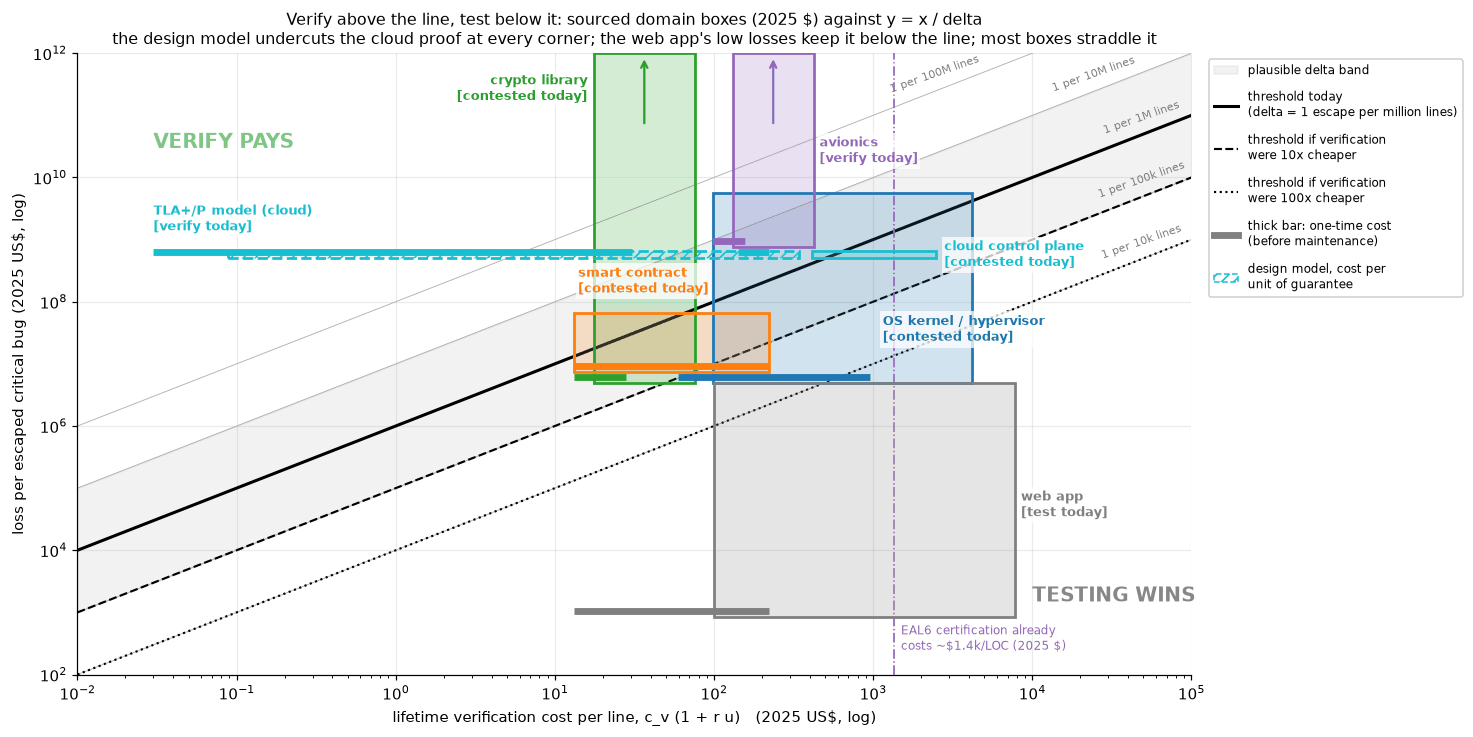

at delta = 1 per million lines: {'contested': 4, 'verify': 2, 'test': 1}; verify today: avionics, TLA+/P model (cloud).
The boxes are wide because the inputs are: the plane ranks domains, it does not certify any one verdict.


In [149]:
def _s12_draw_plane():
    '''The decision plane: boxes, iso-delta lines, the reference threshold and its shifts for cheaper proofs.'''
    fig, ax = plt.subplots(figsize=(13.5, 6.8))
    X0, X1 = 1e-2, 1e5
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(X0, X1)
    ax.set_ylim(1e2, _s12_CEIL)
    xs = np.geomspace(X0, X1, 50)
    p0, p1 = ax.transData.transform([(1, 1), (10, 10)])         # on-screen angle of a slope-1 line
    angle = math.degrees(math.atan2(p1[1] - p0[1], p1[0] - p0[0]))
    for d in (1e-4, 1e-5, 1e-6, 1e-7, 1e-8):
        ax.plot(xs, xs / d, color="gray", lw=0.6, alpha=0.6, zorder=1)
        xl = min(5e4, 2.5e11 * d)
        ax.text(xl, xl / d * 1.5, f"1 per {_s12_fmt(1 / d, '')} lines", fontsize=7.5, color="gray",
                rotation=angle, rotation_mode="anchor", ha="center", va="bottom")
    lo, hi = _s12_A["delta_band"]
    ax.fill_between(xs, xs / hi, xs / lo, color="gray", alpha=0.10, zorder=0, label="plausible delta band")
    dref = _s12_A["delta_ref"]
    ax.plot(xs, xs / dref, color="black", lw=2, label="threshold today\n(delta = 1 escape per million lines)")
    for f, ls in ((10, "--"), (100, ":")):
        ax.plot(xs, xs / (dref * f), color="black", lw=1.4, ls=ls,
                label=f"threshold if verification\nwere {f}x cheaper")
    ax.axvline(_s12_EAL6_25, color="#9467bd", ls="-.", lw=1)
    ax.text(_s12_EAL6_25 * 1.1, 2.5e2, f"EAL6 certification already\ncosts ~\\${_s12_EAL6_25 / 1e3:.1f}k/LOC (2025 \\$)",
            color="#9467bd", fontsize=8)
    label_pos = {"crypto library": (16, 1.5e11, "right"), "avionics": (460, 1.5e10, "left"),
                 "OS kernel / hypervisor": (1.15e3, 2.0e7, "left"), "smart contract": (14, 1.2e8, "left"),
                 "cloud control plane": (2.8e3, 3.2e8, "left"), "web app": (8.5e3, 3e4, "left"),
                 "TLA+/P model (cloud)": (0.03, 1.2e9, "left")}
    for n, b in _s12_BOXES.items():
        (x0, x1), (y0, y1) = b["life"], b["y"]
        top = y1 if y1 else _s12_CEIL
        tla = n.startswith("TLA")
        ax.add_patch(Rectangle((x0, y0), x1 - x0, top - y0, fc=b["color"], alpha=0.10 if tla else 0.20, lw=0,
                               zorder=2))
        ax.add_patch(Rectangle((x0, y0), x1 - x0, top - y0, fill=False, ec=b["color"], lw=1.8, zorder=3,
                               hatch="///" if tla else None, ls="--" if tla else "-"))
        o0, o1 = b["once"]
        yb = y0 * 1.25                    # one-time bar just inside the box, off any edge another box shares
        ax.plot([o0, o1], [yb, yb], color=b["color"], lw=4.5, solid_capstyle="butt", zorder=4)
        if y1 is None:
            ax.annotate("", xy=(np.sqrt(x0 * x1), _s12_CEIL * 0.9), xytext=(np.sqrt(x0 * x1), _s12_CEIL / 15),
                        arrowprops=dict(arrowstyle="->", color=b["color"], lw=1.5))
        fx, fy, ha = label_pos[n]
        v = _s12_verdict(x0, x1, y0, y1, dref)
        ax.text(fx, fy, f"{n}\n[{v} today]", fontsize=8.5, color=b["color"], fontweight="bold", ha=ha,
                va="bottom", zorder=6, bbox=dict(fc="white", ec="none", alpha=0.75, pad=1.5))
    ax.text(0.03, 3e10, "VERIFY PAYS", fontsize=13, color="#2ca02c", alpha=0.6, fontweight="bold")
    ax.text(1.0e4, 1.5e3, "TESTING WINS", fontsize=13, color="dimgray", alpha=0.8, fontweight="bold")
    ax.plot([], [], color="gray", lw=4.5, label="thick bar: one-time cost\n(before maintenance)")
    ax.add_patch(Rectangle((0, 0), 0, 0, fill=False, ec="C9", hatch="///", ls="--", label="design model, cost per\n"
                           "unit of guarantee"))
    ax.set_xlabel("lifetime verification cost per line, c_v (1 + r u)   (2025 US\\$, log)")
    ax.set_ylabel("loss per escaped critical bug (2025 US\\$, log)")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0), framealpha=0.95, labelspacing=1.0)
    ax.set_title("Verify above the line, test below it: sourced domain boxes (2025 \\$) against y = x / delta\n"
                 "the design model undercuts the cloud proof at every corner; the web app's low losses keep it below "
                 "the line; most boxes straddle it", fontsize=10.5)
    plt.tight_layout()
    plt.show()


_s12_draw_plane()
_s12_today = Counter(r[3] for r in _s12_rows_v)
print(f"at delta = 1 per million lines: {dict(_s12_today)}; verify today: "
      f"{', '.join(r[0] for r in _s12_rows_v if r[3] == 'verify')}.")
print("The boxes are wide because the inputs are: the plane ranks domains, it does not certify any one verdict.")

Read the plane by its geometry, not its exact verdicts, which move with $\delta$ (the table prints three values
and the margin). What holds across the band:

- **Losses vary more than one-time costs, and churn narrows the gap.** The sourced loss edges span about three
  decades (\$4.99M to \$5.54B), the one-time cost per verified line under two; only with our assumed
  one-engineer-day floor for a web-app escape does the loss span reach about seven. The cost span is narrow partly
  by construction, since three of the six domains borrow the same auto-active `CASES` rows. Once churn is priced
  on the cost side, the lifetime cost spans nearly three decades too; counting the rewritten code's own escapes as
  well (§12.1) narrows that to 2.4. The stakes decide first and the churn second; the tool matters less.
- **Low losses sink the web app; churn pushes it further.** Its one-time cost (thick bar) equals the smart
  contract's, priced from the same auto-active rows, and even that box tests at $\delta_\text{ref}$, because its
  losses are capped near one data breach. Ten lifetime rewrites at seL4's re-verification rates stretch its cost
  one to one and a half decades to the right. The rewritten code would carry escapes of its own, though; counted
  on both sides, churn's net factor is 0.68× to 3.2×, and the only verdict on the plane that moves is the web
  app's at $\delta = 10^{-5}$, from test to contested. Even at a $\delta$ two decades higher for its small,
  frequent escapes it only becomes contested. A non-upgradeable deployed contract is the opposite: it cannot be
  patched ($u = 0$), so like a chip it pays for its bugs in full. That is the economic case for contract
  verification; Certora claims over \$100B of value secured (vendor claim, 2025).
- **For the cloud, the design model beats the proof.** Per unit of guarantee the TLA+/P box costs less than the
  IronFleet-priced proof at every corner, and stays cheaper up to about 31 engineer-weeks per model. Whether it
  clears the line depends on $\delta$ and on that effort: at $\delta_\text{ref}$ it verifies with a margin of
  1.46, and at the low end of the band it is contested, unless the model needs no upkeep as the code churns, in
  which case it verifies there too. AWS practice points the same way: teams building S3, EBS, DynamoDB, Aurora and
  EC2 use P, alongside deterministic simulation testing (Brooker & Desai, ACM Queue 2025). The box's own loss edge
  is the kept failure. AWS had published TLA+ models of DynamoDB's replication and group membership by 2014
  (Newcombe et al.) and its DynamoDB teams use P, yet the October 2025 outage came from a race in DynamoDB's DNS
  management, a component outside the published models. Partial coverage is what the 10–50% divisor stands for.

The lightweight methods share one shape: **cheap spec, partial guarantee**. A property-based test checks a
universally quantified spec on samples (§1.1 gives the mutation-study numbers). Deterministic simulation runs the
real code under a simulated network, disk and scheduler; FoundationDB, built for it from the start, reports over
0.5 million disk-years at Apple without a data-corruption event (Zhou et al., SIGMOD 2021). Neither has a published
cost per line, so neither is drawn. The partial guarantee fails where expected: an AWS TLA+ model missed a
liveness bug because liveness was never checked (§8.3), and at MongoDB two engineers spent 10 weeks trying to
check server traces against the TLA+ spec before abandoning it as impractical (Davis et al., VLDB 2020). Checking
the design is cheap; connecting it to the code is the expensive part, and that is what a code-level proof buys.

The certification line explains the rest of practice. Where an EAL6 process (rule of thumb \$1k/LOC in 2014, about
\$1,360 in 2025 dollars) must be paid for anyway, a proof competes with part of that cost ($s$), and every
one-time kernel cost lies left of it. seL4 sold itself on exactly this: \$362/SLOC against a \$1k/LOC rule of
thumb for a *lower* assurance level. For DO-178C Level A we found no sourced cost per line, so the avionics box is
compared with the EAL6 line only by analogy; DO-333 lets formal analysis satisfy certain DO-178C verification
objectives, not replace certification. RATP reported that B-method development for Paris Line 14 cost about as
much as classical methods (Pelhate, RATP, STAR 2000 slides; the Line 14 row of §11's `CASES`). In Woodcock et
al.'s 2009 industrial survey (self-reported, biased toward successes), 37% of projects reported lower cost, 7%
higher, 56% no effect or no data.

### 12.4 Why hardware verifies and software doesn't

The chip notebook §6.3 lists formal property checking and equivalence checking as standard steps of every chip
flow. The inequality explains why, term by term:

- **$c_v$'s spec is often free.** Equivalence checking takes the previous RTL as the spec, free and complete
  (§4.3). Checking against a reference model, or proving properties of a block, still needs a spec that someone
  writes: the model, or hand-written assertions. Software gets the same free spec only when an older program
  defines correct behaviour, as in §4.3's translation validation; otherwise it must write its spec and get it
  reviewed. TimSort's JML spec is as long as the code (§11).
- **$c_v$ needs far fewer human invariants.** A hardware block is finite-state, so its properties are decidable,
  and SAT, IC3 and BDDs settle many of them push-button (§3, §8). Where state explosion wins, engineers add helper
  assertions and abstractions, and datapaths such as dividers still needed theorem proving (ACL2 at AMD, theorem
  proving alongside model checking at Intel, below). Software's state is effectively unbounded (inputs, heaps,
  recursion), so its proofs need human invariants everywhere (§6, §7).
- **$E[\text{loss}]$ has no patch.** A silicon bug means a respin: a new mask set (\$1M at 28 nm to \$30–40M at
  3/2 nm, chip notebook §6.1) and months of schedule. An escaped bug means a recall. Intel took a \$475M pretax
  charge for FDIV (Intel 10-K, 1994; the bug is in §1.3).
- **$s$ is already huge.** More than half of hardware design effort goes to verification of some kind (ter Beek
  et al., FAC 2024, citing industry estimates). A proof that replaces part of a simulation campaign competes
  with a large existing budget.

In [150]:
# Hardware vs software, term by term, with the dollar conversions the inequality needs.
_s12_HW_ASSUMPTIONS = {
    "fdiv_price_level": ("1994 $ -> 2025 $", "the FDIV charge is converted with CPI-U"),
    "mask_price_level": ("taken as 2025 $", "the chip notebook's mask-set costs are recent quotes"),
}
_s12_FDIV = (475e6, 1994)                               # Intel 10-K for fiscal 1994: pretax charge, nominal
_s12_FDIV25 = _s12_to_2025(*_s12_FDIV)
_s12_MASKS = (1e6, 40e6)                                # chip notebook Sec. 6.1: 28 nm .. 3/2 nm mask set
_s12_spec_share = {r["system"]: r["spec_loc"] / (r["spec_loc"] + r["proof_loc"])
                   for r in CASES if r["spec_loc"] and r["proof_loc"]}
_s12_py_fdiv = (_s12_FDIV25 / _s12_cost_hi, _s12_FDIV25 / _s12_cost_lo)
_s12_py_mask = (_s12_MASKS[0] / _s12_cost_hi, _s12_MASKS[1] / _s12_cost_lo)
show_table(["term", "hardware block", "software component"],
           [["spec cost in c_v", "0 lines for equivalence (previous RTL); else a model or assertions",
             "spec/(spec+proof) lines: " + ", ".join(f"{s.split(' (')[0]} {v:.1%}"
                                                     for s, v in _s12_spec_share.items())],
            ["who finds invariants", "mostly automatic (finite state); humans add helpers for big blocks",
             "a human, or an LLM checked by a kernel"],
            ["cost of one escape", f"respin: masks ${_s12_MASKS[0] / 1e6:.0f}M-${_s12_MASKS[1] / 1e6:.0f}M; "
                                   f"recall: FDIV ${_s12_FDIV25 / 1e9:.2f}B (2025 $)",
             "a patch, unless deployed immutably"],
            ["u (churn after release)", "0: silicon cannot change", "0.5-10 (assumed, Sec. 12.3)"]])
print(f"\nthe FDIV charge (${_s12_FDIV[0] / 1e6:.0f}M in {_s12_FDIV[1]} = ${_s12_FDIV25 / 1e9:.2f}B in 2025 $) buys "
      f"{_s12_py_fdiv[0]:,.0f}-{_s12_py_fdiv[1]:,.0f} person-years of verification = "
      f"{_s12_py_fdiv[0] / _s12_PY_SEL4:.0f}-{_s12_py_fdiv[1] / _s12_PY_SEL4:.0f} seL4-sized proofs")
print(f"one leading-edge mask set buys up to {_s12_py_mask[1]:,.0f} person-years; a respin also costs months")
print("Free spec (for equivalence checking) + finite state + no patch: each term pushes toward proof in hardware.")

term                     hardware block                                                      software component                                                        
-----------------------------------------------------------------------------------------------------------------------------------------------------------------------
spec cost in c_v         0 lines for equivalence (previous RTL); else a model or assertions  spec/(spec+proof) lines: CompCert 11.6%, IronFleet 3.4%, CertiKOS mC2 2.7%
who finds invariants     mostly automatic (finite state); humans add helpers for big blocks  a human, or an LLM checked by a kernel                                    
cost of one escape       respin: masks $1M-$40M; recall: FDIV $1.03B (2025 $)                a patch, unless deployed immutably                                        
u (churn after release)  0: silicon cannot change                                            0.5-10 (assumed, Sec. 12.3)                                        

History followed the numbers. Within two years of FDIV, AMD had a mechanical ACL2 proof that the K5's
floating-point division microcode implements IEEE division (Moore, Lynch & Kaufmann, March 1996), and Russinoff's
K5 square-root proof led to a microcode modification. Intel moved its floating-point units to formal proofs
(O'Leary et al., 1999; Kaivola & Kohatsu, Pentium 4 divider, 2001), and by 2009 described **replacing testing**
with formal verification for the Core i7 execution engine (Kaivola et al., CAV 2009). Software's closest analogue
is the smart contract: immutable once deployed (unless built to be upgradeable), holding money, attacked by
adversaries.

### 12.5 The LLM effect: moving the line, and Amdahl's law for proofs

Kleppmann's prediction that "AI will make formal verification go mainstream" (December 2025) is an argument
about $c_v$: proof writing is the rare-expertise part, LLMs are getting good at it, and a small kernel rejects
every hallucinated proof (§10). Proof *search* has indeed become much cheaper: §13.4 dates the saturation of
PutnamBench and the collapse of its self-reported cost per problem, and Math Inc's Gauss finished the
dimension-8 sphere-packing formalization in 5 days where the human team had estimated six more months (company
claim, 2026). Microsoft's SymCrypt team has AI agents helping write and maintain the Lean proofs of its Rust
ML-KEM and SHA-3 code, 237K lines of Lean for 16.7K lines of Rust that run in Windows Insider builds (Ho et al.,
2026, a draft paper). Program verification lags mathematics (§13.4).

What an LLM does not shrink is the spec: someone must still decide what "correct" means and review it (the
spine's fourth idea; §2's spec-gaming demo shows why). SymCrypt's agents also help translate the standards into
Lean specifications, but the human effort goes to reviewing them (Microsoft Research blog, 13 July 2026), so $f_s$
below is the share of cost that stays with humans: writing, or at least reviewing, the spec. If only proofs become
$F$ times cheaper, verification becomes

$$\frac{1}{f_s + (1 - f_s)/F} \;\le\; \frac{1}{f_s}$$

times cheaper: **Amdahl's law**, with the spec as the serial fraction. We measure $f_s$ by effort (seL4's
abstract and executable specs took 0.3 + 0.2 of 20.5 person-years; TOCS 2014, Fig. 19) and by lines
(spec/(spec + proof) for the `CASES` rows that report both). The effort reading has two judgment calls, so the
table also shows it without the 9 person-years of generic tools in the denominator, and with the 2-person-year
Haskell prototype, from which the executable spec is generated, counted as spec.

**Registered predictions:** *(a) a 100× cheaper prover makes verification at least 50× cheaper; (b) if
verification itself becomes 10× cheaper, every box above the web app crosses into "verify", and at 100× cheaper
the web app crosses too.*

In [151]:
# Amdahl's law for verification: only the proof share (1 - f_s) gets F times cheaper.
_s12_LLM_ASSUMPTIONS = {
    "spec_cost_fixed": (True, "LLMs cut proof cost by F; writing or reviewing the spec costs what it does today"),
    "factors": ((1, 10, 100), "raw cost reductions to test: today, 10x, 100x"),
}
_s12_SPEC_PY, _s12_TOOLS_PY, _s12_HASKELL_PY = 0.3 + 0.2, 9.0, 2.0    # TOCS 2014 Fig. 19: specs, tools, prototype
_s12_PROOF_PY = _s12_FIG19["functional correctness"]
_s12_fs = {"seL4 (effort)": _s12_SPEC_PY / _s12_PROOF_PY,
           "seL4 (effort, without 9 py of tools)": _s12_SPEC_PY / (_s12_PROOF_PY - _s12_TOOLS_PY),
           "seL4 (effort, Haskell prototype as spec)": (_s12_SPEC_PY + _s12_HASKELL_PY) / (_s12_PROOF_PY + _s12_HASKELL_PY)}
_s12_fs.update({f"{s.split(' (')[0]} (lines)": v for s, v in _s12_spec_share.items()})
_s12_fs_lo, _s12_fs_hi = min(_s12_fs.values()), max(_s12_fs.values())


def _s12_amdahl(F, fs):
    '''Effective verification cost reduction when only the proof share (1 - fs) gets F times cheaper:
    old cost 1, new cost fs + (1 - fs)/F.'''
    return 1.0 / (fs + (1.0 - fs) / F)


show_table(["spec share measured as", "f_s", "F = 10", "F = 100", "limit 1/f_s"],
           [[k, f"{v:.1%}", f"{_s12_amdahl(10, v):.1f}x", f"{_s12_amdahl(100, v):.1f}x", f"{1 / v:.0f}x"]
            for k, v in sorted(_s12_fs.items(), key=lambda kv: kv[1])])
_s12_e100 = (_s12_amdahl(100, _s12_fs_hi), _s12_amdahl(100, _s12_fs_lo))
print(f"registered prediction (a): 100x cheaper proofs -> >= 50x cheaper verification | measured: "
      f"{_s12_e100[0]:.1f}x - {_s12_e100[1]:.1f}x | verdict: {'RIGHT' if _s12_e100[0] >= 50 else 'WRONG'} — the "
      f"spec is the serial fraction")
print(f"f_s that a 50x reduction from a 100x prover would need: <= {(100 / 50 - 1) / 99:.2%}; "
      f"the smallest measured is {_s12_fs_lo:.1%}")

spec share measured as                    f_s    F = 10  F = 100  limit 1/f_s
-----------------------------------------------------------------------------
seL4 (effort)                             2.4%   8.2x    29.3x    41x        
CertiKOS mC2 (lines)                      2.7%   8.0x    27.1x    37x        
IronFleet (lines)                         3.4%   7.6x    22.7x    29x        
seL4 (effort, without 9 py of tools)      4.3%   7.2x    18.9x    23x        
seL4 (effort, Haskell prototype as spec)  11.1%  5.0x    8.3x     9x         
CompCert (lines)                          11.6%  4.9x    8.0x     9x         
registered prediction (a): 100x cheaper proofs -> >= 50x cheaper verification | measured: 8.0x - 29.3x | verdict: WRONG — the spec is the serial fraction
f_s that a 50x reduction from a 100x prover would need: <= 1.01%; the smallest measured is 2.4%


Prediction (b) asks every box to cross. The cell recomputes each box's verdict in five scenarios: verification 10×
and 100× cheaper as raw factors, and a 100× prover under the spec-heavy and spec-light Amdahl readings. It scores
the prediction at $\delta_\text{ref}$, as registered, then repeats the score at both ends of the band.

In [152]:
# Which boxes cross the line as verification gets F times cheaper (raw), and with Amdahl's cap on a 100x prover.
_s12_scen = [(f"{F}x cheaper" if F > 1 else "today", float(F)) for F in _s12_LLM_ASSUMPTIONS["factors"][0]]
_s12_scen += [("100x prover, spec-heavy", _s12_e100[0]), ("100x prover, spec-light", _s12_e100[1])]
_s12_dref = _s12_A["delta_ref"]
_s12_ABOVE = ["crypto library", "OS kernel / hypervisor", "avionics", "smart contract", "cloud control plane"]


def _s12_grid_at(delta, factor_of=lambda name: 1.0):
    '''Verdict per box per scenario at one delta; factor_of(name) divides a box's cost further (1 = as drawn).'''
    return {n: [_s12_verdict(*b["life"], *b["y"], delta, F * factor_of(n)) for _, F in _s12_scen]
            for n, b in _s12_BOXES.items()}


def _s12_prediction_b(grid):
    '''(verdict, boxes above the web app that verify at 10x, the web app's verdict at 100x) for one grid.'''
    ok10 = [n for n in _s12_ABOVE if grid[n][1] == "verify"]
    ok = len(ok10) == len(_s12_ABOVE) and grid["web app"][2] == "verify"
    return ("RIGHT" if ok else "WRONG"), ok10, grid["web app"][2]


_s12_grid = _s12_grid_at(_s12_dref)
show_table(["domain (verdict, margin)"] + [s for s, _ in _s12_scen],
           [[n] + [f"{v} {_s12_breakeven(_s12_BOXES[n], F)[0] * _s12_dref:.2g}" for v, (_, F) in zip(vs, _s12_scen)]
            for n, vs in _s12_grid.items()])
_s12_vb, _s12_ok10, _s12_web100 = _s12_prediction_b(_s12_grid)
print(f"registered prediction (b): at 10x every box above the web app verifies; at 100x the web app too | measured "
      f"at delta = 1e-6: at 10x {len(_s12_ok10)}/{len(_s12_ABOVE)} verify ({', '.join(_s12_ok10) or 'none'}), "
      f"web app at 100x '{_s12_web100}' | verdict: {_s12_vb} — loss floors of one breach or one hack, and churn, "
      "hold the other boxes back")
for _s12_d in _s12_A["delta_band"]:
    _s12_vd, _s12_okd, _s12_webd = _s12_prediction_b(_s12_grid_at(_s12_d))
    print(f"  same prediction at delta = {_s12_d:.0e}: {_s12_vd} (at 10x: {', '.join(_s12_okd) or 'none'}; "
          f"web app at 100x '{_s12_webd}')")
_s12_vb_both = [_s12_prediction_b(_s12_grid_at(d, lambda n: 1 + _s12_u_of(n)))[0] for d in _s12_DELTAS]
print(f"  with churn counted on both sides (Sec. 12.1), at delta = 1e-7 / 1e-6 / 1e-5: {' / '.join(_s12_vb_both)}")
_s12_kern = _s12_BOXES["OS kernel / hypervisor"]
print(f"the kernel at 10x would need delta > {_s12_kern['life'][1] / 10 / _s12_kern['y'][0]:.1e} to verify, "
      f"outside the band (top {_s12_A['delta_band'][1]:.0e})")
_s12_flip = [n for n in _s12_BOXES if _s12_grid[n][0] != "verify" and _s12_grid[n][3] == "verify"]
print("with a 100x prover and a spec-heavy f_s, boxes that newly clear the line at delta = 1e-6: "
      f"{', '.join(_s12_flip) or 'none'}")
_s12_web_free = [_s12_verdict(*_s12_web["once"], *_s12_web["y"], _s12_dref, F) for _, F in _s12_scen]
_s12_stretch = [l / o for l, o in zip(_s12_web["life"], _s12_web["once"])]
print(f"web app if proof repair were free (u -> 0, undoing a {_s12_stretch[0]:.1f}x-{_s12_stretch[1]:.0f}x "
      "maintenance stretch): " + ", ".join(f"{s} {v}" for (s, _), v in zip(_s12_scen, _s12_web_free)))
print("Cheaper proofs move the line by about one decade, not two: the spec, the churn and the stakes still decide.")

domain (verdict, margin)  today             10x cheaper      100x cheaper       100x prover, spec-heavy  100x prover, spec-light
--------------------------------------------------------------------------------------------------------------------------------
crypto library            contested 0.066   contested 0.66   verify 6.6         contested 0.53           verify 1.9             
OS kernel / hypervisor    contested 0.0012  contested 0.012  contested 0.12     contested 0.0095         contested 0.035        
avionics                  verify 1.8        verify 18        verify 1.8e+02     verify 14                verify 53              
smart contract            contested 0.034   contested 0.34   verify 3.4         contested 0.27           contested 0.98         
cloud control plane       contested 0.2     verify 2         verify 20          verify 1.6               verify 5.9             
web app                   test 1.1e-07      test 1.1e-06     contested 1.1e-05  test 8.7e-07     

The figure shows both results: Amdahl's curves for the measured spec shares, and the verdict matrix at
$\delta_\text{ref}$ with each cell's break-even $N^*$.

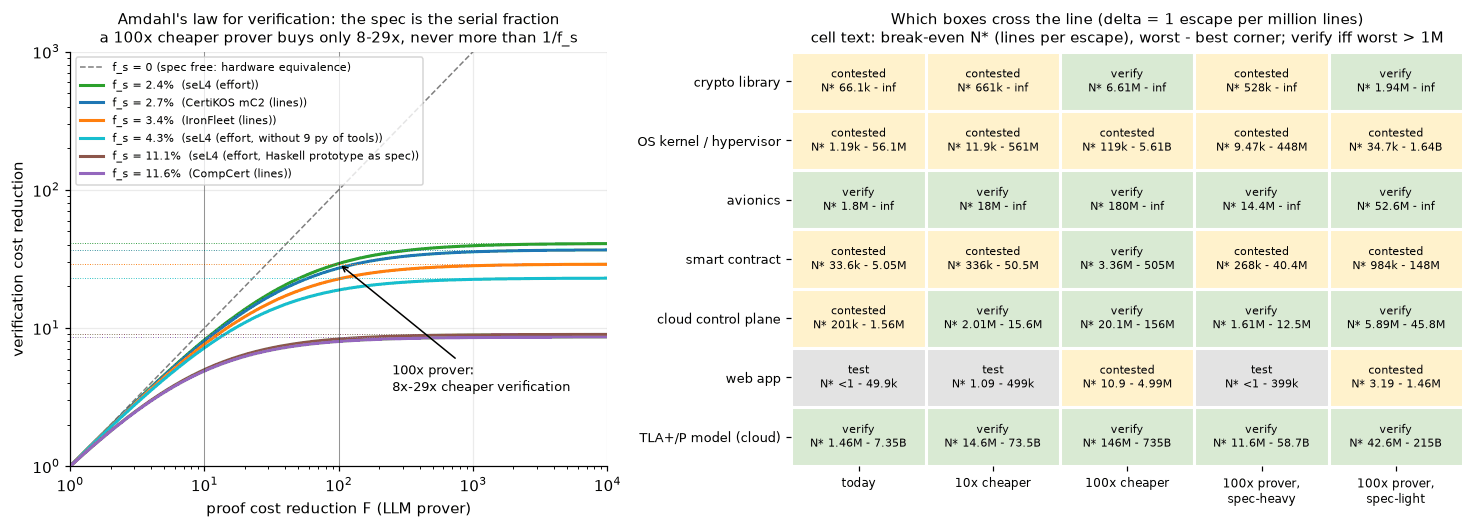

Prediction (a) is capped by the spec share; prediction (b) is WRONG at delta = 1e-6 and at both ends of the band.


In [153]:
def _s12_draw_llm():
    '''Left: Amdahl's law with measured spec shares. Right: verdict matrix with break-even N* per cell.'''
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9), gridspec_kw={"width_ratios": [1, 1.25]})
    ax = axes[0]
    F = np.geomspace(1, 1e4, 200)
    ax.plot(F, F, color="gray", ls="--", lw=1, label="f_s = 0 (spec free: hardware equivalence)")
    for (k, v), col in zip(sorted(_s12_fs.items(), key=lambda kv: kv[1]), ["C2", "C0", "C1", "C9", "C5", "C4", "C3"]):
        ax.plot(F, _s12_amdahl(F, v), color=col, lw=2, label=f"f_s = {v:.1%}  ({k})")
        ax.axhline(1 / v, color=col, lw=0.6, ls=":")
    for Fm in (10, 100):
        ax.axvline(Fm, color="black", lw=0.6, alpha=0.4)
    ax.annotate(f"100x prover:\n{_s12_e100[0]:.0f}x-{_s12_e100[1]:.0f}x cheaper verification", (100, _s12_e100[1]),
                xytext=(250, 3.5), fontsize=8.5, arrowprops=dict(arrowstyle="->", color="black"))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, 1e4)
    ax.set_ylim(1, 1e3)
    ax.set_xlabel("proof cost reduction F (LLM prover)")
    ax.set_ylabel("verification cost reduction")
    ax.legend(fontsize=7.5, loc="upper left")
    ax.set_title("Amdahl's law for verification: the spec is the serial fraction\n"
                 f"a 100x cheaper prover buys only {_s12_e100[0]:.0f}-{_s12_e100[1]:.0f}x, never more than 1/f_s",
                 fontsize=10)

    ax = axes[1]
    names = list(_s12_BOXES)
    cmap = {"verify": "#d9ead3", "contested": "#fff2cc", "test": "#e3e3e3"}
    for i, n in enumerate(names):
        for j, (s, Fx) in enumerate(_s12_scen):
            v = _s12_grid[n][j]
            ax.add_patch(Rectangle((j, i), 1, 1, fc=cmap[v], ec="white", lw=2))
            n_worst, n_best = _s12_breakeven(_s12_BOXES[n], Fx)
            ax.text(j + 0.5, i + 0.5, f"{v}\nN* {_s12_fmt(n_worst, '')} - {_s12_fmt(n_best, '')}", ha="center",
                    va="center", fontsize=7.5)
    ax.set_xlim(0, len(_s12_scen))
    ax.set_ylim(len(names), 0)
    ax.set_xticks(np.arange(len(_s12_scen)) + 0.5, [s.replace(", ", ",\n") for s, _ in _s12_scen], fontsize=8)
    ax.set_yticks(np.arange(len(names)) + 0.5, names, fontsize=8.5)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title("Which boxes cross the line (delta = 1 escape per million lines)\n"
                 "cell text: break-even N* (lines per escape), worst - best corner; verify iff worst > 1M",
                 fontsize=10)
    plt.tight_layout()
    plt.show()


_s12_draw_llm()
print(f"Prediction (a) is capped by the spec share; prediction (b) is {_s12_vb} at delta = 1e-6 and at both ends "
      "of the band.")

Both predictions failed. (a) With the measured spec shares a 100× prover buys 8–29×, about one decade of
verification cost, not two; even an infinitely cheap prover is capped at $1/f_s$, which is about 40× for seL4's
spec-light effort split and less under its other readings (23× without the generic tools in the denominator, 9×
with the Haskell prototype counted as spec), and a 50× gain would need a spec share of about 1% or less. (b) The
verdict that holds at every $\delta$ in the band is the failure itself: the kernel box never verifies at 10×,
because its loss floor (one average data breach) is so far under its worst-corner cost that it would need $\delta$
above $8.4 \times 10^{-5}$, outside the band. The rest is specific to $\delta$. At $\delta_\text{ref}$ avionics
already verifies today (its loss floor, Ariane 501 in 2025 dollars, clears the line with a margin of 1.8) and the
cloud control plane crosses at 10×; the crypto library needs 100× or the spec-light reading; the smart contract
crosses only at the full raw 100×, and under the spec-light reading its margin is 0.98, a tie rather than a
verdict; the web app at best becomes contested. At $\delta = 10^{-5}$ more boxes cross, and at $10^{-7}$ fewer,
but the prediction is wrong at both ends, and still wrong at all three values when the rewritten code's escapes
are counted too (§12.1). For the contested boxes the outcome stays a bet on how buggy the unverified alternative
is. Only the $f_s = 0$ curve passes every factor straight through, the regime hardware equivalence checking has
always lived in.

Two further effects both favour verification. LLMs *raise* $\delta$: code is written faster than anyone can review
it, which lowers the line (Kleppmann's argument). And agents now maintain proofs as well as write them (SymCrypt),
which attacks the churn term $r\,u$ that pushes the web app further below the line. The next-to-last line of the
prediction-(b) cell prices that case: free proof repair shrinks the web-app box back to its one-time cost, a shift
as large as a 100× prover buys, yet alone it leaves the web app in "test", and combined with any cheaper-proof
scenario only makes it contested. The economics predict that verification spreads first where losses are large,
code churns little (or its changes touch few invariants) and the spec a human must review is small: avionics, the
protocol cores of cloud services, cryptography. §13 measures what the checker catches when the proposer is an LLM;
§14 maps the tools that do this today.

## 13. Verifiers meet LLMs: the checker as the scalable reviewer

An LLM writes code and proofs faster than anyone can review them, and its mistakes look like correct code.
Human review effort grows with every line produced; a checker is written and reviewed once. The spine's fourth
idea, **check the product, not the producer** (§3's certificates, §10's de Bruijn criterion), gives the way
out: an untrusted proposer generates, and a small trusted checker decides. This section measures what that
buys: how much the proposer matters (cost) and how little (soundness); how often "accepted by the checker"
means "correct" when the spec is weak; which escape hatches a checker must close; and where the field stands
in October 2026.

### 13.1 Generate-and-check, pass@k, and the verifier as a reward

A proposer emits candidates $\pi_1, \pi_2, \dots$ (invariants, proofs, programs) for a claim $\varphi$; a
checker answers *accept*, *counterexample* or *unknown*. If the checker is **sound** (accept ⇒ $\varphi$
holds), the pipeline is sound **whatever the proposer does**: a hallucinated proof costs one checker call and
nothing else. If the proposer draws independent candidates, each accepted with probability $p$, then §1's
needle formula reappears, now counting successes instead of bugs:

$$\text{pass@}k = P(\text{accepted within } k \text{ calls}) = 1 - (1-p)^k, \qquad E[\text{calls}] = 1/p.$$

**Estimating pass@k.** From $n$ samples with $c$ accepted, pick $k$ of the $n$ at random; that subset contains
no success with probability $\binom{n-c}{k}/\binom{n}{k}$. Hence the estimator $1 - \binom{n-c}{k}/\binom{n}{k}$
(Chen et al., *Evaluating Large Language Models Trained on Code*, 2021), which is unbiased because a random
$k$-subset of i.i.d. samples is itself $k$ i.i.d. samples. The obvious plug-in $1-(1-c/n)^k$ is biased low,
because $(1-c/n)^k$ is convex in $c$. An `unknown` or a timeout counts as a failure; counting it as anything else
makes the pipeline unsound.

**The verifier as a reward (RLVR).** The same checker is a training signal: reward $= 1$ iff the checker
accepts. Unlike a unit-test reward, it has no false positives *relative to* $\varphi$. Its limits are already in
the formula: it is **sparse** (a policy with small $p$ sees one positive per $1/p$ samples), it is exact only
for the $\varphi$ that was written down (§13.2), and the checker's configuration is part of $\varphi$ (§13.3).

**Experiment 1: three proposers, one checker.** The claim is §6's and §8's: on the loop
`x, y = 1, 0; while y < 16: x = x + y; y = y + 1` (§8's version; §6 bounds the loop by a parameter `n`), the
property $x \ge y$ holds, which is true but not inductive. The grammar has 40 **atoms** $a x + b y + c \ge 0$
with $a, b \in \{-1, 0, 1\}$ and $c \in \{-2, \dots, 2\}$; a candidate invariant is a conjunction of up to 3
of them (10,700 candidates). The checker is §8's `is_inductive` plus one Z3 query for $I \Rightarrow x \ge y$.
The proposers:

- a **uniform sampler** over the 10,700 candidates;
- a **prior-weighted sampler**, a stand-in for an LLM that has read the code. It strongly prefers atoms true on
  the first three loop-head states (the initial state and two iterations), as if it had run the loop in its head,
  and it prefers small constants. These are modelling choices, not a model of any real LLM. The real version
  is Lemur (Wu, Barrett & Narodytska, ICLR 2024): GPT-4 proposes invariants and the ESBMC model checker checks
  them. Lemur solved 107 of 133 Code2Inv benchmarks, against 92 for Code2Inv and 68 for ESBMC alone;
- **Houdini** (Flanagan & Leino, FME 2001): start from the conjunction of *all* atoms and, after each
  counterexample to induction, delete every atom the CTI violates. It searches conjunctions of any number of
  atoms, not just up to 3.

**Registered prediction:** by median verifier calls to the first proved invariant, Houdini < prior-weighted <
uniform, each gap at least 10×. (The gap between the two samplers depends on the prior's constants; the
ordering does not.)

In [154]:
# 13.1 The grammar and the trusted checker (cross-checked three ways), run once on every candidate.
_s13_Z3_MS = 3000                  # timeout per checker query; 'unknown' is a failure, never a proof
_s13_COEF = (-1, 0, 1)             # atoms  a*x + b*y + c >= 0  with a, b in COEF (not both 0) ...
_s13_CONST = (-2, -1, 0, 1, 2)     # ... and c in CONST: 8 * 5 = 40 atoms
_s13_MAX_CONJ = 3                  # a candidate invariant = a conjunction of 1..3 distinct atoms
_s13_GUARD = 16                    # the loop guard y < 16, exactly as in §8
_s13_BOX = 40                      # brute-force oracle: every integer state with |x|, |y| <= BOX
_s13_SEED_XCHECK = 1301            # which pre-rejected candidates are re-checked with Z3
_s13_N_XCHECK = 150


def _s13_atoms(consts):
    '''All atoms (a, b, c), meaning a*x + b*y + c >= 0, for a, b in COEF (not both 0) and c in consts.'''
    return [(a, b, c) for a in _s13_COEF for b in _s13_COEF if (a, b) != (0, 0) for c in consts]


def _s13_atom_str(atom):
    '''Readable form of a*x + b*y + c >= 0, e.g. (1, -1, 0) -> "x >= y", (-1, 0, 2) -> "x <= 2".'''
    a, b, c = atom
    pos = [v for v, k in (('x', a), ('y', b)) if k == 1]
    neg = [v for v, k in (('x', a), ('y', b)) if k == -1]
    if not pos:                                            # -(neg) + c >= 0  <=>  sum(neg) <= c
        return f"{' + '.join(neg)} <= {c}"
    rhs = ' + '.join(neg) if neg else str(-c)
    if neg and c:
        rhs += f" {'-' if c > 0 else '+'} {abs(c)}"
    return f"{' + '.join(pos)} >= {rhs}"


def _s13_holds(atom, st):
    '''Does the atom hold at the concrete state st = {'x': int, 'y': int}?'''
    return atom[0] * st['x'] + atom[1] * st['y'] + atom[2] >= 0


def _s13_candidates(n_atoms, max_conj=_s13_MAX_CONJ):
    '''Every conjunction of 1..max_conj distinct atoms, as sorted tuples of atom indices.'''
    return [c for k in range(1, max_conj + 1) for c in itertools.combinations(range(n_atoms), k)]


# The x, y loop as a symbolic transition system, in §8's encoding (callables over dicts of Z3 constants).
_s13_XY = {'x': z3.IntSort(), 'y': z3.IntSort()} if HAVE_Z3 else None
_s13_init = lambda s: z3.And(s['x'] == 1, s['y'] == 0)
_s13_trans = lambda s, t: z3.And(s['y'] < _s13_GUARD, t['x'] == s['x'] + s['y'], t['y'] == s['y'] + 1)
_s13_P = lambda s: s['x'] >= s['y']


def _s13_reachable():
    '''The 17 reachable loop-head states, by running the loop: (1, 0), (1, 1), (2, 2), (4, 3), ...'''
    x, y, out = 1, 0, [(1, 0)]
    while y < _s13_GUARD:
        x, y = x + y, y + 1
        out.append((x, y))
    return out


def _s13_check(cand, atoms, timeout_ms=_s13_Z3_MS):
    '''THE TRUSTED CHECKER for one candidate invariant of the x, y loop (a tuple of atom indices).
    Step 1 is §8's is_inductive (initiation + consecution); step 2 asks Z3 whether inv AND NOT(x >= y) is
    satisfiable. Returns ('proved', None) | ('cti', §8's CTI dict) | ('too_weak', state): inductive, but
    the state satisfies it and breaks x >= y | ('unknown', None) on a timeout.'''
    inv = lambda s: z3.And(*[atoms[i][0] * s['x'] + atoms[i][1] * s['y'] + atoms[i][2] >= 0 for i in cand])
    status, info = is_inductive(inv, _s13_init, _s13_trans, _s13_XY, timeout_ms=timeout_ms)
    if status != 'inductive':
        return status, info
    s = {n: z3.Const(f"{n}@w", sort) for n, sort in _s13_XY.items()}
    solver = z3.Solver()
    solver.set("timeout", timeout_ms)
    solver.add(inv(s), z3.Not(_s13_P(s)))
    r = solver.check()
    if r == z3.unsat:
        return 'proved', None
    if r == z3.sat:
        return 'too_weak', {n: solver.model().eval(v, model_completion=True).as_long() for n, v in s.items()}
    return 'unknown', None


def _s13_box_oracle(atoms):
    '''Independent, solver-free oracle: evaluate every atom on every state of the box |x|, |y| <= BOX and on
    its successor (numpy). A box state inside a candidate whose successor leaves it is a CTI. One-sided: it
    can exhibit a CTI, never prove that none exists outside the box.'''
    r = np.arange(-_s13_BOX, _s13_BOX + 1)
    X, Y = [m.ravel() for m in np.meshgrid(r, r)]
    A = np.array(atoms)
    now = (np.outer(A[:, 0], X) + np.outer(A[:, 1], Y) + A[:, 2:3]) >= 0           # atom i holds at state j
    nxt = (np.outer(A[:, 0], X + Y) + np.outer(A[:, 1], Y + 1) + A[:, 2:3]) >= 0   # ... at its successor
    moves = Y < _s13_GUARD

    def has_cti(cand):
        inside = np.logical_and.reduce(now[list(cand)], axis=0) & moves
        return bool(np.any(inside & ~np.logical_and.reduce(nxt[list(cand)], axis=0)))
    return has_cti


def _s13_verdict_table(atoms):
    '''The checker's verdict on EVERY candidate of the grammar, computed once, so that thousands of simulated
    proposer calls become table lookups. A candidate false on some reachable state is certainly no invariant
    (no solver needed); Z3 decides the rest. Every verdict is cross-checked; returns {candidate: status}.'''
    reach = _s13_reachable()
    holds = [all(_s13_holds(at, {'x': x, 'y': y}) for x, y in reach) for at in atoms]
    cands = _s13_candidates(len(atoms))
    survivors = [c for c in cands if all(holds[i] for i in c)]
    t0 = time.perf_counter()
    results = {c: _s13_check(c, atoms) for c in survivors}
    dt = time.perf_counter() - t0
    has_cti = _s13_box_oracle(atoms)
    bad = Counter()
    for c, (status, info) in results.items():
        if status == 'cti':                     # replay: a real transition from inside the candidate to outside
            p, q = info['trace'][0], info['trace'][-1]
            bad['cti'] += not (info['check'] == 'step' and p['y'] < _s13_GUARD and (q['x'], q['y']) ==
                               (p['x'] + p['y'], p['y'] + 1) and all(_s13_holds(atoms[i], p) for i in c)
                               and not all(_s13_holds(atoms[i], q) for i in c))
        if status == 'too_weak':                # replay: the witness is inside and breaks x >= y
            bad['weak'] += not (all(_s13_holds(atoms[i], info) for i in c) and info['x'] < info['y'])
        if status in ('proved', 'too_weak'):    # the brute-force box must not find a CTI
            bad['box'] += has_cti(c)
    sample = random.Random(_s13_SEED_XCHECK).sample([c for c in cands if c not in results],
                                                    min(_s13_N_XCHECK, len(cands) - len(results)))
    bad['pre'] = sum(_s13_check(c, atoms)[0] in ('proved', 'too_weak') for c in sample)
    tally = Counter(s for s, _ in results.values())
    print(f"grammar: {len(atoms)} atoms -> {len(cands):,} candidates; {sum(holds)} atoms hold on all {len(reach)} "
          f"reachable states -> {len(survivors)} candidates go to Z3 (~{dt:.1f} s): {tally['proved']} proved, "
          f"{tally['too_weak']} inductive but too weak, {tally['cti']} CTI, {tally['unknown']} unknown")
    print(f"cross-checks: {bad['cti']} CTIs and {bad['weak']} too-weak witnesses fail a concrete replay; "
          f"{bad['box']} inductive verdicts contradicted by brute force on the box |x|,|y| <= {_s13_BOX}; "
          f"{bad['pre']} of {len(sample)} pre-rejected candidates accepted by Z3")
    verdict = {c: 'rejected' for c in cands}
    verdict.update({c: s for c, (s, _) in results.items()})
    return verdict


if HAVE_Z3:
    _s13_ATOMS = _s13_atoms(_s13_CONST)
    _s13_VERDICT = _s13_verdict_table(_s13_ATOMS)
    _s13_PROVED = [c for c, v in _s13_VERDICT.items() if v == 'proved']
    for _s13_c in _s13_PROVED:
        print("   proved:", " and ".join(_s13_atom_str(_s13_ATOMS[i]) for i in _s13_c))
    print(f"{len(_s13_PROVED)} of {len(_s13_VERDICT):,} candidates are proofs. From here on a proposer call is a lookup "
          "into this table.")
else:
    print("Z3 not installed (pip install z3-solver): §13.1 needs §8's is_inductive; skipping the invariant "
          "experiments.")

grammar: 40 atoms -> 10,700 candidates; 14 atoms hold on all 17 reachable states -> 469 candidates go to Z3 (~3.8 s): 3 proved, 98 inductive but too weak, 368 CTI, 0 unknown
cross-checks: 0 CTIs and 0 too-weak witnesses fail a concrete replay; 0 inductive verdicts contradicted by brute force on the box |x|,|y| <= 40; 0 of 150 pre-rejected candidates accepted by Z3
   proved: y >= 0 and x >= y and x >= 1
   proved: y >= 0 and x >= y and x + y >= 1
   proved: y >= -1 and x >= y and x + y >= 1
3 of 10,700 candidates are proofs. From here on a proposer call is a lookup into this table.


Before the samplers, the proposer that reads the checker's answers. Houdini starts from all 40 atoms at once, a
conjunction far outside the samplers' space of at most 3 conjuncts, and lets each CTI delete the atoms it
violates. The figure draws every call of the run.


Houdini on the 40-atom grammar: 6 checker calls (bound: 41), final status 'proved'
  call 1: 40 atoms; Init (1, 0) violates 16
  call 2: 24 atoms; CTI (1, 0) -> (1, 1) violates 3
  call 3: 21 atoms; CTI (1, 1) -> (2, 2) violates 3
  call 4: 18 atoms; CTI (2, 2) -> (4, 3) violates 2
  call 5: 16 atoms; CTI (4, 3) -> (7, 4) violates 2
  call 6: 14 atoms; proved
  answer (14 atoms): y >= 0 and y >= -1 and y >= -2 and x >= y and x >= y - 1 and x >= y - 2 and x >= 1 and x >= 0 and x >= -1 and x >= -2 and x + y >= 1 and x + y >= 0 and x + y >= -1 and x + y >= -2
  inside the samplers' space (<= 3 conjuncts)? False
  every CTI end state was a reachable state: True
  cross-check: each proved candidate of the verdict table is a subset of Houdini's answer: True


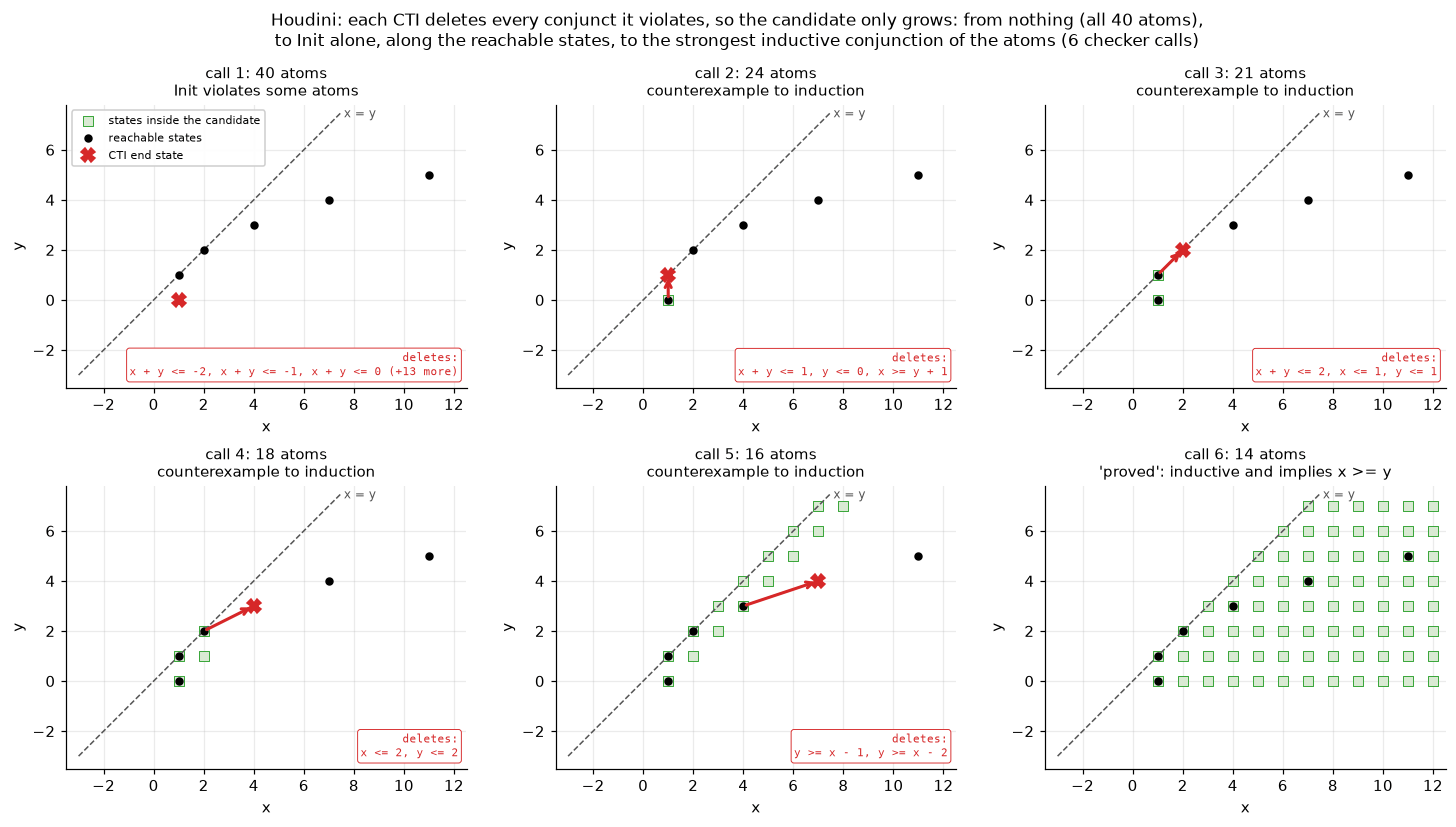

Houdini never guesses: each CTI is the checker telling it exactly which conjuncts to delete.


In [155]:
# 13.1 (cont.) Houdini: delete every conjunct a CTI refutes, until the conjunction is inductive.
def _s13_houdini(atoms):
    '''Houdini (Flanagan & Leino, FME 2001). Start from the conjunction of ALL atoms; while the checker returns
    a CTI, delete every atom that the CTI's last state violates, and ask again. An atom of ANY inductive
    conjunction J is never deleted: J holds at Init, and a step CTI starts inside the current candidate, which
    implies J, so it ends inside J. The loop therefore stops at the strongest inductive conjunction of the
    atoms, of any size, and each failed call deletes >= 1 atom: at most len(atoms) + 1 calls.
    Returns (final status, kept atom indices, history of (kept, status, info) per call).'''
    keep, history = list(range(len(atoms))), []
    while True:
        status, info = _s13_check(tuple(keep), atoms)
        history.append((tuple(keep), status, info))
        if status != 'cti':
            return status, keep, history
        bad = info['trace'][-1]                            # Init itself for a 'base' CTI, else the post-state
        keep = [i for i in keep if _s13_holds(atoms[i], bad)]


def _s13_draw_call(ax, atoms, keep, status, info):
    '''One Houdini call on the (x, y) plane: integer states inside the candidate (green squares), reachable
    states (black), the line x = y, the CTI (red arrow) and the atoms it deletes.'''
    xs, ys = np.meshgrid(np.arange(-3, 13), np.arange(-3, 8))
    inside = np.ones(xs.shape, bool)
    for i in keep:
        a, b, c = atoms[i]
        inside &= a * xs + b * ys + c >= 0
    ax.scatter(xs[inside], ys[inside], marker="s", s=40, color="#d9ead3", edgecolor="#2ca02c", lw=0.6,
               label="states inside the candidate", zorder=2)
    rx, ry = zip(*[s for s in _s13_reachable() if s[0] <= 12 and s[1] <= 7])
    ax.plot(rx, ry, "o", color="black", ms=4.5, label="reachable states", zorder=3)
    ax.plot([-3, 7.5], [-3, 7.5], ls="--", color="#555555", lw=1)
    ax.text(7.6, 7.3, "x = y", color="#555555", fontsize=8)
    if status == 'cti':
        q = info['trace'][-1]
        if info['check'] == 'step':
            p = info['trace'][0]
            ax.annotate("", xy=(q['x'], q['y']), xytext=(p['x'], p['y']),
                        arrowprops=dict(arrowstyle="->", color="#d62728", lw=2), zorder=4)
        ax.plot([q['x']], [q['y']], "X", color="#d62728", ms=9, zorder=5, label="CTI end state")
        dead = [_s13_atom_str(atoms[i]) for i in keep if not _s13_holds(atoms[i], q)]
        txt = "deletes: " + ", ".join(dead[:3]) + (f" (+{len(dead) - 3} more)" if len(dead) > 3 else "")
        ax.text(0.98, 0.03, txt.replace(": ", ":\n", 1), transform=ax.transAxes, ha="right", va="bottom",
                fontsize=7.5, family="monospace", color="#d62728",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#d62728", lw=0.6))
    ax.set_xlim(-3.5, 12.5)
    ax.set_ylim(-3.5, 7.8)
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")


def _s13_houdini_demo():
    '''Run Houdini on the 40-atom grammar, print every call, cross-check, and draw the calls.'''
    status, keep, hist = _s13_houdini(_s13_ATOMS)
    print(f"\nHoudini on the {len(_s13_ATOMS)}-atom grammar: {len(hist)} checker calls (bound: {len(_s13_ATOMS) + 1}), "
          f"final status '{status}'")
    for r, (kp, st, info) in enumerate(hist):
        if st == 'cti':
            q = info['trace'][-1]
            n_dead = sum(not _s13_holds(_s13_ATOMS[i], q) for i in kp)
            where = (f"Init ({q['x']}, {q['y']}) violates" if info['check'] == 'base' else
                     f"CTI ({info['trace'][0]['x']}, {info['trace'][0]['y']}) -> ({q['x']}, {q['y']}) violates")
            print(f"  call {r + 1}: {len(kp):2d} atoms; {where} {n_dead}")
        else:
            print(f"  call {r + 1}: {len(kp):2d} atoms; {st}")
    print(f"  answer ({len(keep)} atoms):", " and ".join(_s13_atom_str(_s13_ATOMS[i]) for i in keep))
    print(f"  inside the samplers' space (<= {_s13_MAX_CONJ} conjuncts)? {len(keep) <= _s13_MAX_CONJ}")
    reach = set(_s13_reachable())
    ctis_reachable = all((info['trace'][-1]['x'], info['trace'][-1]['y']) in reach
                         for _, st, info in hist if st == 'cti')
    print(f"  every CTI end state was a reachable state: {ctis_reachable}")
    print(f"  cross-check: each proved candidate of the verdict table is a subset of Houdini's answer: "
          f"{all(set(c) <= set(keep) for c in _s13_PROVED)}")

    n = len(hist)
    show = list(range(n)) if n <= 6 else [0, 1, 2, 3, n - 2, n - 1]
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.6))
    for ax, r in zip(axes.flat, show):
        kp, st, info = hist[r]
        _s13_draw_call(ax, _s13_ATOMS, kp, st, info)
        if st == 'cti':
            sub = "Init violates some atoms" if info['check'] == 'base' else "counterexample to induction"
        else:
            sub = f"'{st}': inductive and implies x >= y"
        ax.set_title(f"call {r + 1}: {len(kp)} atoms\n{sub}", fontsize=9.5)
    for ax in list(axes.flat)[len(show):]:
        ax.axis("off")
    axes.flat[0].legend(loc="upper left", fontsize=7.5, framealpha=0.95)
    fig.suptitle(f"Houdini: each CTI deletes every conjunct it violates, so the candidate only grows: from nothing "
                 f"(all {len(_s13_ATOMS)} atoms),\nto Init alone, along the reachable states, to the strongest "
                 f"inductive conjunction of the atoms ({n} checker calls)", fontsize=11)
    plt.tight_layout()
    plt.show()
    print("Houdini never guesses: each CTI is the checker telling it exactly which conjuncts to delete.")
    return hist


if HAVE_Z3:
    _s13_H_HIST = _s13_houdini_demo()
else:
    print("Z3 not installed: skipping Houdini.")

Only 3 of the 10,700 candidates are proofs, all variants of the strengthening §6 found by hand: $x \ge y$ plus
lower bounds that force $x \ge 1$ and stop $y$ from running negative. Houdini's answer is a different, larger
proof: a 14-atom conjunction that contains the atoms of all three, so it implies each of them, found in the
handful of calls printed above. The figure shows why it is fast. In this run every CTI was a *reachable* state
(Z3 picks the CTI, so another version may pick differently): starting from the strongest possible candidate,
Houdini walks forward along the real execution and deletes exactly the conjuncts each step refutes, until the
remaining conjunction is closed under the transition. Its answer is the **strongest inductive conjunction of the
40 atoms, of any size** (argued in the docstring). This has a corollary that no sampler can match: if that answer
does not imply the property, *no inductive* conjunction of these atoms does.

The two samplers ignore counterexamples: each call is a fresh independent draw, so their success curve is
exactly $1-(1-p)^k$, where $p$ is the probability they put on the 3 proved candidates (computed exactly below)
and $k$ is the number of verifier calls. Each sampler gets 400 independent runs, capped at 40,000 calls each.

sampling distributions sum to 1: True


400 runs per sampler, at most 40,000 calls each; p = P(one proposal is proved), exact
proposer                  p per call  E[calls] = 1/p  calls for 99% (§1 tests_needed)  median calls  90th pct  runs out of budget
---------------------------------------------------------------------------------------------------------------------------------
uniform sampler           2.80e-04    3,567           16,423                           2,716         8,010     0/400             
prior-weighted sampler    3.48e-03    287             1,322                            210           745       0/400             
Houdini (reads the CTIs)  -           -               6                                6             6         0 (deterministic) 

registered prediction: median calls rank Houdini < prior-weighted < uniform, each gap >= 10x | measured: 6 < 210 < 2,716 (gaps 35x and 13x) | verdict: RIGHT -- feedback beats a good prior, and a good prior beats none



other prior weights: p(prior-weighted) / p(uniform), exact (shipped prior: on_trace = 20, const_decay = 0.5)
on_trace \ const_decay  1     0.5    0.1    0.01  0.001
-------------------------------------------------------
1                       0.36  1.26   2.03   0.35  0.04 
5                       2.19  7.54   11.88  2.03  0.21 
20                      3.62  12.41  19.48  3.34  0.35 
100                     4.21  14.39  22.58  3.88  0.41 
registered side claim (the parenthesis above): the ordering does not depend on the prior's constants | measured: the prior-weighted sampler beats uniform in 14 of 20 settings and loses at (on_trace, const_decay) = (1, 1), (1, 0.01), (1, 0.001), (5, 0.001), (20, 0.001), (100, 0.001) | verdict: WRONG
   why: every proof has 3 atoms, so 2 of the prior's 3 equally likely sizes never yield a proof; every proof contains an atom with constant +-1: True



pass@k of the prior-weighted sampler estimated from n = 200 samples, mean over 4000 trials:
k    exact 1-(1-p)^k  unbiased estimator  plug-in 1-(1-c/n)^k
-------------------------------------------------------------
1    0.0035           0.0035              0.0035             
10   0.0343           0.0344              0.0336             
50   0.1599           0.1605              0.1437             
100  0.2943           0.2956              0.2412             
200  0.5020           0.5045              0.3584             


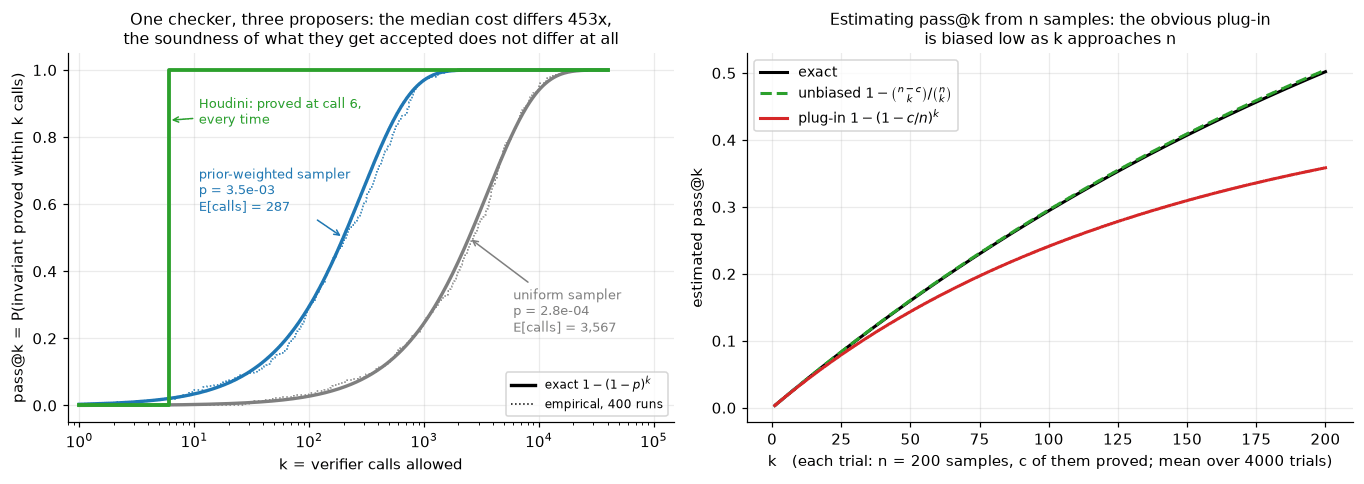

grammar: 8 atoms -> 92 candidates; 4 atoms hold on all 17 reachable states -> 14 candidates go to Z3 (~0.1 s): 0 proved, 4 inductive but too weak, 10 CTI, 0 unknown
cross-checks: 0 CTIs and 0 too-weak witnesses fail a concrete replay; 0 inductive verdicts contradicted by brute force on the box |x|,|y| <= 40; 0 of 78 pre-rejected candidates accepted by Z3
Houdini on the 8-atom grammar: 'too_weak' after 3 calls; the strongest inductive conjunction is y >= 0 and x >= 0 and x + y >= 0
   its witness {'x': 0, 'y': 1} lies inside it and breaks x >= y (replayed: True), so NO inductive conjunction of these atoms implies x >= y; the verdict table agrees (0 of 92 proved)
   the reason: (0, 0) satisfies every atom a*x + b*y >= 0 and steps to (0, 1), where x < y
a sampler on the same grammar: P(proof per call) = 0/92, so every run ends 'unknown' whatever its budget;
   an enumerator that never repeats a candidate stops after 92 calls, and its 'none' covers only <= 3 conjuncts
A memoryless sampler,

In [156]:
# 13.1 (cont.) Two sampling proposers against the same checker; pass@k; and a grammar with no invariant at all.
_s13_SEED_RUNS = 1302
_s13_RUNS = 400                    # independent runs per sampler
_s13_BUDGET = 40_000               # verifier-call cap per run; a run that hits it reports 'unknown'
_s13_PRIOR = dict(trace_len=3,     # the LLM stand-in has seen the first 3 loop-head states (Init + 2 steps) ...
                  on_trace=20.0,   # ... and weights atoms true on them 20x ...
                  const_decay=0.5, # ... prefers small constants (weight 0.5^|c|) ...
                  sizes=(1, 2, 3)) # ... and proposes 1, 2 or 3 conjuncts with equal probability
_s13_GRID_ON_TRACE = (1.0, 5.0, 20.0, 100.0)          # the prediction's parenthetical, tested: other prior
_s13_GRID_DECAY = (1.0, 0.5, 0.1, 0.01, 0.001)        # weights (exact probabilities, no sampling)
_s13_N_EST, _s13_TRIALS_EST = 200, 4000     # pass@k estimators: n samples per trial, many trials
_s13_CONST0 = (0,)                 # kept failure: atoms a*x + b*y >= 0 only ("x >= 1" is not expressible)


def _s13_prior_probs(atoms, cands, prior=_s13_PRIOR):
    '''Exact probability that the prior-weighted sampler proposes each candidate: pick a size uniformly from
    prior['sizes'], then draw that many distinct atoms one by one, each with probability proportional to its
    weight among the atoms not yet drawn. A SET's probability sums over the orders its atoms can come in.'''
    first = _s13_reachable()[:prior['trace_len']]
    w = np.array([(prior['on_trace'] if all(_s13_holds(at, {'x': x, 'y': y}) for x, y in first) else 1.0)
                  * prior['const_decay'] ** abs(at[2]) for at in atoms])
    probs = np.zeros(len(cands))
    for j, cand in enumerate(cands):
        if len(cand) in prior['sizes']:
            for order in itertools.permutations(cand):
                p, left = 1.0, w.sum()
                for i in order:
                    p *= w[i] / left
                    left -= w[i]
                probs[j] += p / len(prior['sizes'])
    return probs


def _s13_calls_to_first_proof(probs, ok, runs, budget, g, chunk=4000):
    '''Simulate independent proposer runs: every call draws a candidate from probs and asks the checker (a
    lookup into the boolean array ok). Returns, per run, the index of the first accepted call (nan if the
    budget ran out: the run reports 'unknown').'''
    first = np.full(runs, np.nan)
    for start in range(0, budget, chunk):
        todo = np.flatnonzero(np.isnan(first))
        if len(todo) == 0:
            break
        hit = ok[g.choice(len(probs), size=(len(todo), min(chunk, budget - start)), p=probs)]
        first[todo] = np.where(hit.any(axis=1), hit.argmax(axis=1) + start + 1, np.nan)
    return first


def _s13_pass_at_k(n, c, k):
    '''Unbiased pass@k from n samples with c successes (Chen et al. 2021): 1 - C(n-c, k)/C(n, k), computed as a
    numerically stable product. Requires 0 <= c <= n and 0 <= k <= n.'''
    assert 0 <= c <= n and 0 <= k <= n, (n, c, k)
    if n - c < k:
        return 1.0
    return 1.0 - float(np.prod(1.0 - k / np.arange(n - c + 1, n + 1)))


def _s13_proposer_demo():
    '''Calls-to-first-proof and pass@k for the two samplers vs Houdini; the registered prediction; the
    pass@k estimator check; the figure.'''
    cands = _s13_candidates(len(_s13_ATOMS))
    ok = np.array([_s13_VERDICT[c] == 'proved' for c in cands])
    probs = {'uniform': np.full(len(cands), 1.0 / len(cands)), 'prior-weighted': _s13_prior_probs(_s13_ATOMS, cands)}
    print(f"sampling distributions sum to 1: {all(abs(p.sum() - 1) < 1e-9 for p in probs.values())}")
    p = {k: float(v[ok].sum()) for k, v in probs.items()}
    g = np.random.default_rng(_s13_SEED_RUNS)
    first = {k: _s13_calls_to_first_proof(v, ok, _s13_RUNS, _s13_BUDGET, g) for k, v in probs.items()}
    n_h = len(_s13_H_HIST)
    rows = [[f"{k} sampler", f"{p[k]:.2e}", f"{1 / p[k]:,.0f}", f"{tests_needed(p[k]):,}",
             f"{np.nanmedian(f):,.0f}", f"{np.nanpercentile(f, 90):,.0f}", f"{int(np.isnan(f).sum())}/{_s13_RUNS}"]
            for k, f in first.items()]
    rows.append(["Houdini (reads the CTIs)", "-", "-", f"{n_h}", f"{n_h}", f"{n_h}", "0 (deterministic)"])
    print(f"{_s13_RUNS} runs per sampler, at most {_s13_BUDGET:,} calls each; p = P(one proposal is proved), exact")
    show_table(["proposer", "p per call", "E[calls] = 1/p", "calls for 99% (§1 tests_needed)", "median calls",
                "90th pct", "runs out of budget"], rows)
    mu, mp = float(np.nanmedian(first['uniform'])), float(np.nanmedian(first['prior-weighted']))
    right = n_h < mp < mu and mp / n_h >= 10 and mu / mp >= 10
    print(f"\nregistered prediction: median calls rank Houdini < prior-weighted < uniform, each gap >= 10x | measured: "
          f"{n_h} < {mp:,.0f} < {mu:,.0f} (gaps {mp / n_h:.0f}x and {mu / mp:.0f}x) | verdict: "
          f"{'RIGHT' if right else 'WRONG'} -- feedback beats a good prior, and a good prior beats none")

    # The parenthetical of the prediction: does the ORDERING prior-weighted < uniform survive other constants? A
    # sampler's calls-to-first-proof is geometric, whose median falls as p rises, so compare the exact p.
    ratio = {}
    for ot in _s13_GRID_ON_TRACE:
        for d in _s13_GRID_DECAY:
            alt = _s13_prior_probs(_s13_ATOMS, cands, dict(_s13_PRIOR, on_trace=ot, const_decay=d))
            ratio[ot, d] = float(alt[ok].sum()) / p['uniform']
    print(f"\nother prior weights: p(prior-weighted) / p(uniform), exact (shipped prior: on_trace = "
          f"{_s13_PRIOR['on_trace']:g}, const_decay = {_s13_PRIOR['const_decay']:g})")
    show_table(["on_trace \\ const_decay"] + [f"{d:g}" for d in _s13_GRID_DECAY],
               [[f"{ot:g}"] + [f"{ratio[ot, d]:.2f}" for d in _s13_GRID_DECAY] for ot in _s13_GRID_ON_TRACE])
    lose = [k for k, r in ratio.items() if r <= 1]
    print(f"registered side claim (the parenthesis above): the ordering does not depend on the prior's constants | "
          f"measured: the prior-weighted sampler beats uniform in {len(ratio) - len(lose)} of {len(ratio)} settings "
          f"and loses at (on_trace, const_decay) = {', '.join(f'({ot:g}, {d:g})' for ot, d in lose)} | verdict: "
          f"{'RIGHT' if not lose else 'WRONG'}")
    proofs = [c for c, v in zip(cands, ok) if v]
    sizes = {len(c) for c in proofs}
    wasted = sum(s not in sizes for s in _s13_PRIOR['sizes'])
    print(f"   why: every proof has {'/'.join(map(str, sorted(sizes)))} atoms, so {wasted} of the prior's "
          f"{len(_s13_PRIOR['sizes'])} equally likely sizes never yield a proof; every proof contains an atom with "
          f"constant +-1: {all(any(abs(_s13_ATOMS[i][2]) == 1 for i in c) for c in proofs)}")

    # pass@k from n samples: the unbiased estimator vs the plug-in, averaged over many trials, vs the exact value.
    c = ok[g.choice(len(cands), size=(_s13_TRIALS_EST, _s13_N_EST), p=probs['prior-weighted'])].sum(axis=1)
    ks = np.arange(1, _s13_N_EST + 1)
    exact = 1 - (1 - p['prior-weighted']) ** ks
    unb = np.array([np.mean([_s13_pass_at_k(_s13_N_EST, ci, k) for ci in c]) for k in ks])
    plug = np.array([np.mean(1 - (1 - c / _s13_N_EST) ** k) for k in ks])
    print(f"\npass@k of the prior-weighted sampler estimated from n = {_s13_N_EST} samples, mean over "
          f"{_s13_TRIALS_EST} trials:")
    show_table(["k", "exact 1-(1-p)^k", "unbiased estimator", "plug-in 1-(1-c/n)^k"],
               [[k, exact[k - 1], unb[k - 1], plug[k - 1]] for k in (1, 10, 50, 100, 200)], floatfmt="{:.4f}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.5))
    kk = np.unique(np.logspace(0, np.log10(_s13_BUDGET), 400).astype(int))
    label_at = {'uniform': (6e3, 0.22), 'prior-weighted': (11, 0.58)}       # free corners of the panel
    for (k, f), col in zip(first.items(), ("#7f7f7f", "#1f77b4")):
        ax1.plot(kk, 1 - (1 - p[k]) ** kk, color=col, lw=2.2)
        srt = np.sort(f[~np.isnan(f)])
        ax1.step(srt, np.arange(1, len(srt) + 1) / _s13_RUNS, where="post", color=col, lw=1, ls=":")
        ax1.annotate(f"{k} sampler\np = {p[k]:.1e}\nE[calls] = {1 / p[k]:,.0f}", xy=(math.log(2) / p[k], 0.5),
                     xytext=label_at[k], fontsize=8.5, color=col, arrowprops=dict(arrowstyle="->", color=col))
    ax1.step([1, n_h, _s13_BUDGET], [0, 1, 1], where="post", color="#2ca02c", lw=2.5)
    ax1.annotate(f"Houdini: proved at call {n_h},\nevery time", xy=(n_h, 0.85), xytext=(11, 0.84),
                 fontsize=8.5, color="#2ca02c", arrowprops=dict(arrowstyle="->", color="#2ca02c"))
    ax1.plot([], [], color="black", lw=2.2, label="exact $1-(1-p)^k$")
    ax1.plot([], [], color="black", lw=1, ls=":", label=f"empirical, {_s13_RUNS} runs")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.set_xlim(0.8, 1.5e5)
    ax1.set_xscale("log")
    ax1.set_xlabel("k = verifier calls allowed")
    ax1.set_ylabel("pass@k = P(invariant proved within k calls)")
    ax1.set_title(f"One checker, three proposers: the median cost differs {mu / n_h:.0f}x,\nthe soundness of what "
                  "they get accepted does not differ at all", fontsize=10.5)
    ax2.plot(ks, exact, color="black", lw=2, label="exact")
    ax2.plot(ks, unb, color="#2ca02c", ls="--", lw=2, label="unbiased $1-\\binom{n-c}{k}/\\binom{n}{k}$")
    ax2.plot(ks, plug, color="#d62728", lw=2, label="plug-in $1-(1-c/n)^k$")
    ax2.set_xlabel(f"k   (each trial: n = {_s13_N_EST} samples, c of them proved; mean over {_s13_TRIALS_EST} trials)")
    ax2.set_ylabel("estimated pass@k")
    ax2.set_title("Estimating pass@k from n samples: the obvious plug-in\nis biased low as k approaches n",
                  fontsize=10.5)
    ax2.legend(fontsize=9, loc="upper left")
    plt.tight_layout()
    plt.show()
    return p, first


def _s13_no_invariant_demo():
    '''Kept failure: a grammar containing no invariant. Houdini proves that; a sampler can only run out.'''
    atoms = _s13_atoms(_s13_CONST0)
    verdict = _s13_verdict_table(atoms)
    cands = _s13_candidates(len(atoms))
    status, keep, hist = _s13_houdini(atoms)
    wit = hist[-1][2]
    print(f"Houdini on the {len(atoms)}-atom grammar: '{status}' after {len(hist)} calls; the strongest inductive "
          "conjunction is", " and ".join(_s13_atom_str(atoms[i]) for i in keep))
    print(f"   its witness {wit} lies inside it and breaks x >= y (replayed: "
          f"{all(_s13_holds(atoms[i], wit) for i in keep) and wit['x'] < wit['y']}), so NO inductive conjunction of "
          f"these atoms implies x >= y; the verdict table agrees ({sum(v == 'proved' for v in verdict.values())} of {len(cands)} "
          "proved)")
    print("   the reason: (0, 0) satisfies every atom a*x + b*y >= 0 and steps to (0, 1), where x < y")
    n_ok = sum(v == 'proved' for v in verdict.values())
    print(f"a sampler on the same grammar: P(proof per call) = {n_ok}/{len(cands)}, so every run ends 'unknown' "
          "whatever its budget;\n   an enumerator that never repeats a candidate stops after "
          f"{len(cands)} calls, and its 'none' covers only <= {_s13_MAX_CONJ} conjuncts")
    return len(hist), len(cands)


if HAVE_Z3:
    _s13_P_CALL, _s13_FIRST = _s13_proposer_demo()
    print()
    _s13_n_h0, _s13_n_c0 = _s13_no_invariant_demo()
    print("A memoryless sampler, like an LLM asked once more, can never conclude 'no invariant of this shape")
    print(f"exists'; Houdini did in {_s13_n_h0} calls, for conjunctions of any size. Neither leaves its atoms: the")
    print("exact invariant x == 1 + y*(y-1)/2 is nonlinear, outside both.")

The prediction held, and the left panel is the section's thesis in one picture. Three proposers that differ in
cost by orders of magnitude are equally safe: whatever the checker accepts is a proof, because acceptance is
decided by the checker alone. They did not find the same proof. Houdini's 14-atom answer lies outside the
samplers' space of at most 3 conjuncts (and implies all three of their proofs), so the call counts compare
different searches: Houdini's over all $2^{40}$ conjunctions of the atoms, the samplers' over 10,700 candidates.
That makes Houdini's few calls more striking, not less. What separates the proposers is how much information
each call returns. A sampler learns one bit ("rejected"); Houdini reads the counterexample, which says *which*
conjuncts are wrong. LLM loops close the same gap by feeding the checker's error back into the prompt: on
VERINA, 64 rounds of refinement with Lean's feedback raised proof success to 20.1%, against 11.2% for the best
specialized prover (VERINA, arXiv 2505.23135 v3, Mar 2026). For RL with a verifiable reward the uniform
sampler's numbers are the warning: one positive reward per few thousand samples. The right panel is why papers
report the unbiased estimator: at $k = n$ the plug-in underestimates pass@k by almost 30%.

The prediction's parenthetical was wrong, and the grid under the verdict shows why. Varying the prior's two
weights, the prior-weighted sampler loses to the uniform one in 6 of the 20 settings: at a constant decay of 0.001
whatever the trace weight, and at trace weight 1 (no pull toward the trace) with decays of 1 and 0.01.
All three proofs have three atoms and each contains an atom with constant ±1. A prior that spends two thirds of
its proposals on one- and two-atom candidates without pointing at the trace, or one that all but forbids the
constants ±1, finds a proof less often than a blind sampler. A prior helps exactly as far as it points at the
proof; a proposer confidently biased away from the needed shape is worse than none.

The kept failure is the other half of the story. With constants restricted to 0, the 8 atoms admit no proof at
all. Houdini *proves* that in a few calls (printed above; never more than 9, one per atom plus one), because
conjunctions of inductive invariants are inductive, so its answer is the strongest inductive conjunction there
is, and its witness breaks $x \ge y$. A sampler can only return
`unknown` there, whatever its budget, and it learns nothing about why. Even an enumerator that never repeats a
candidate needs all 92 calls, and its "none found" covers only conjunctions of at most 3 atoms. Neither can step
outside its atoms: §8 showed that no amount of k-induction proves $x \ge y$ over ℤ, and a learned proposer is
only as good as the shapes it can propose.

### 13.2 Spec gaming, measured: how often does "accepted" mean "correct"?

A sound checker certifies the spec, not the intent (§2.2). To measure the gap, take every pipeline of up to 3
list primitives (`sort`, `rev`, `dedup`, `take3`, `drop1`, `empty`, one `bubble` pass, `minfill` =
`[min(xs)] * len(xs)`; 585 pipelines, including the identity) as the "programs a proposer might write". Judge
each with `check_bounded` against each rung of §2's `SPEC_LADDER` over all lists of length ≤ L (values 0–2),
for L = 0 … 6. Ground truth "correct" means returning `sorted(xs)` on a much larger oracle set. Two numbers per
(rung, L): how many pipelines are **accepted**, and the **acceptance precision**, i.e. accepted ∧ correct ÷
accepted, which is the probability that a checker-approved program is right if the proposer samples pipelines
uniformly.

**Registered prediction:** at L = 5, acceptance precision is below 25% for `sorted`, below 50% for
`sorted+len`, and exactly 100% for `sorted+perm`.

585 pipelines compute 183 distinct functions on 2,053 oracle inputs; 19 pipelines are correct (~0.5 s)


independent re-check: the 19 correct pipelines return sorted(xs) on all 21,845 lists of length <= 7 over 0..3: True

rung                    L=0   L=1   L=2    L=3    L=4    L=5     L=6   
-----------------------------------------------------------------------
sorted: accepted        585   585   525    457    430    422     422   
sorted+len: accepted    585   259   127    113    65     64      64    
sorted+perm: accepted   585   259   56     42     20     19      19    
sorted: precision       3.2%  3.2%  3.6%   4.2%   4.4%   4.5%    4.5%  
sorted+len: precision   3.2%  7.3%  15.0%  16.8%  29.2%  29.7%   29.7% 
sorted+perm: precision  3.2%  7.3%  33.9%  45.2%  95.0%  100.0%  100.0%

registered prediction: at L = 5, precision < 25% for sorted, < 50% for sorted+len, = 100% for sorted+perm | measured: 4.5%, 29.7%, 100.0% | verdict: RIGHT -- the length conjunct removes the truncations but not the constant lists
wrong pipelines that pass sorted+perm at L = 4: ['bubble | bubble | bubble'] 

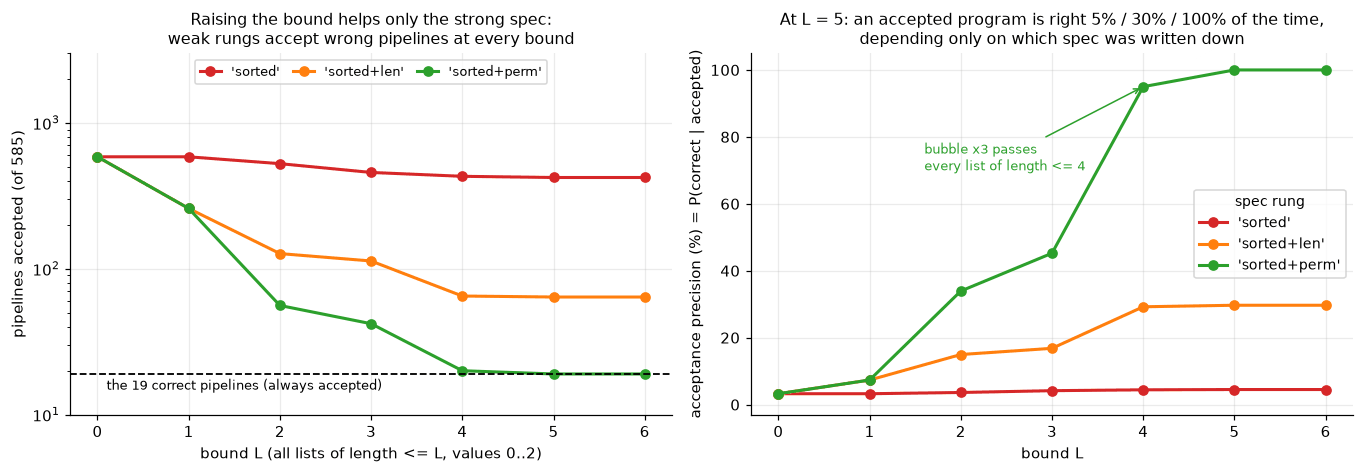

The checker never erred: each accepted pipeline meets its spec on every checked input. The spec erred.


In [157]:
# 13.2 Spec gaming: every pipeline of list primitives up to depth 3, judged by every rung of §2's ladder.
_s13_DEPTH = 3
_s13_V = 3                         # list values 0..V-1, as in §2
_s13_L_MAX = 6                     # bounded checks over all lists of length <= L, L = 0..6
_s13_L_PRED = 5                    # the bound of the registered prediction
_s13_SEED_ORACLE = 1303


def _s13_bubble_pass(xs):
    '''ONE pass of bubble sort: carries the largest element to the end; sorts only lists of length <= 2.'''
    ys = list(xs)
    for i in range(len(ys) - 1):
        if ys[i] > ys[i + 1]:
            ys[i], ys[i + 1] = ys[i + 1], ys[i]
    return ys


_s13_PRIMS = {
    'sort': lambda xs: sorted(xs),
    'rev': lambda xs: xs[::-1],
    'dedup': lambda xs: list(dict.fromkeys(xs)),           # drop repeats, keep first occurrences
    'take3': lambda xs: xs[:3],
    'drop1': lambda xs: xs[1:],
    'empty': lambda xs: [],
    'bubble': _s13_bubble_pass,
    'minfill': lambda xs: [min(xs)] * len(xs) if xs else [],
}


def _s13_pipelines(depth=_s13_DEPTH):
    '''Every sequence of 0..depth primitive names; () is the identity.'''
    return [p for d in range(depth + 1) for p in itertools.product(_s13_PRIMS, repeat=d)]


def _s13_pipeline_fn(pipe):
    '''The pipeline as a function list -> list (primitives applied left to right).'''
    def f(xs):
        for name in pipe:
            xs = _s13_PRIMS[name](xs)
        return xs
    return f


def _s13_oracle_inputs():
    '''Ground truth for "correct": every list the bounded checks use, every list of length <= 4 over 0..4, and
    300 random longer lists (length 7..12, values 0..9). Correct = returns sorted(xs) on all of them.'''
    g = random.Random(_s13_SEED_ORACLE)
    longer = [[g.randrange(10) for _ in range(g.randrange(7, 13))] for _ in range(300)]
    return list({tuple(xs): xs for xs in all_lists(_s13_L_MAX, range(_s13_V)) + all_lists(4, range(5))
                 + longer}.values())


def _s13_spec_gaming():
    '''Group the pipelines by the function they compute (their outputs on the oracle inputs, a superset of the
    checked inputs, so grouping cannot change a verdict), run check_bounded once per distinct function and
    rung, and return per pipeline: correct?, and per rung the length of its shortest counterexample.'''
    oracle = _s13_oracle_inputs()
    truth = tuple(tuple(sorted(xs)) for xs in oracle)
    groups = defaultdict(list)
    for pipe in _s13_pipelines():
        f = _s13_pipeline_fn(pipe)
        groups[tuple(tuple(f(list(xs))) for xs in oracle)].append(pipe)
    inputs = all_lists(_s13_L_MAX, range(_s13_V))         # shortest first: the first cex is a shortest one
    table = {}
    for fp, members in groups.items():
        f = _s13_pipeline_fn(members[0])
        fail_len = {}
        for rung, spec in SPEC_LADDER.items():
            cex = check_bounded(f, spec, inputs, max_cex=1)
            fail_len[rung] = len(cex[0][0]) if cex else math.inf
        for pipe in members:
            table[pipe] = dict(correct=fp == truth, fail_len=fail_len)
    return table, len(groups), len(oracle)


def _s13_spec_gaming_demo():
    '''Accepted counts and acceptance precision per (rung, L); the prediction; who an optimizer would pick.'''
    (table, n_fun, n_oracle), dt = timed(_s13_spec_gaming)
    correct = [p for p, r in table.items() if r['correct']]
    print(f"{len(table)} pipelines compute {n_fun} distinct functions on {n_oracle:,} oracle inputs; "
          f"{len(correct)} pipelines are correct (~{dt:.1f} s)")
    big = all_lists(7, range(4))
    still = all(_s13_pipeline_fn(p)(list(xs)) == sorted(xs) for p in correct for xs in big)
    print(f"independent re-check: the {len(correct)} correct pipelines return sorted(xs) on all {len(big):,} lists of "
          f"length <= 7 over 0..3: {still}")
    Ls = range(_s13_L_MAX + 1)
    acc = {r: [sum(v['fail_len'][r] > L for v in table.values()) for L in Ls] for r in SPEC_LADDER}
    prec = {r: [len(correct) / a for a in acc[r]] for r in SPEC_LADDER}
    print()
    show_table(["rung"] + [f"L={L}" for L in Ls],
               [[f"{r}: accepted"] + acc[r] for r in SPEC_LADDER] +
               [[f"{r}: precision"] + [f"{x:.1%}" for x in prec[r]] for r in SPEC_LADDER])
    L = _s13_L_PRED
    pr = {r: prec[r][L] for r in SPEC_LADDER}
    ok = pr['sorted'] < 0.25 and pr['sorted+len'] < 0.5 and pr['sorted+perm'] == 1.0
    print(f"\nregistered prediction: at L = {L}, precision < 25% for sorted, < 50% for sorted+len, = 100% for "
          f"sorted+perm | measured: {pr['sorted']:.1%}, {pr['sorted+len']:.1%}, {pr['sorted+perm']:.1%} | verdict: "
          f"{'RIGHT' if ok else 'WRONG'} -- the length conjunct removes the truncations but not the constant lists")
    fool = [p for p, v in table.items() if not v['correct'] and v['fail_len']['sorted+perm'] > 4]
    print(f"wrong pipelines that pass sorted+perm at L = 4: {[' | '.join(p) for p in fool]} "
          f"(first counterexample at length {min(table[p]['fail_len']['sorted+perm'] for p in fool)})")
    keep_len = {n for n, f in _s13_PRIMS.items() if all(len(f(list(xs))) == len(xs) for xs in big)}
    gamed = {p for p, v in table.items() if not v['correct'] and v['fail_len']['sorted+len'] > L}
    shape = {p for p in table if 'minfill' in p and set(p) <= keep_len}
    print(f"wrong pipelines that pass sorted+len at L = {L}: {len(gamed)}; exactly the pipelines that contain minfill "
          f"and otherwise only length-preserving steps ({', '.join(sorted(keep_len - {'minfill'}))}): "
          f"{gamed == shape}; in {sum(p[0] != 'minfill' for p in gamed)} of them a step precedes minfill")
    print("\nwhat a length-penalized optimizer finds: the SHORTEST accepted pipelines at L = 5")
    for r in SPEC_LADDER:
        d = min(len(p) for p, v in table.items() if v['fail_len'][r] > L)
        pick = [' | '.join(p) + ('' if table[p]['correct'] else ' (WRONG)')
                for p, v in table.items() if len(p) == d and v['fail_len'][r] > L]
        print(f"  {r:12s} depth {d}: {', '.join(pick)}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4))
    cols = dict(zip(SPEC_LADDER, ("#d62728", "#ff7f0e", "#2ca02c")))
    for r in SPEC_LADDER:
        ax1.plot(Ls, acc[r], "o-", color=cols[r], lw=2, label=f"'{r}'")
        ax2.plot(Ls, [100 * x for x in prec[r]], "o-", color=cols[r], lw=2, label=f"'{r}'")
    ax1.axhline(len(correct), color="black", ls="--", lw=1.2)
    ax1.text(0.1, len(correct) * 0.78, f"the {len(correct)} correct pipelines (always accepted)", fontsize=8.5)
    ax1.set_yscale("log")
    ax1.set_ylim(10, 3000)
    ax1.set_xlabel("bound L (all lists of length <= L, values 0..2)")
    ax1.set_ylabel(f"pipelines accepted (of {len(table)})")
    ax1.set_title("Raising the bound helps only the strong spec:\nweak rungs accept wrong pipelines at every bound",
                  fontsize=10.5)
    ax1.legend(fontsize=8.5, loc="upper center", ncol=3, columnspacing=1.0, handlelength=1.6)
    ax2.annotate("bubble x3 passes\nevery list of length <= 4", xy=(4, 100 * prec['sorted+perm'][4]),
                 xytext=(1.6, 70), fontsize=8.5, color="#2ca02c", arrowprops=dict(arrowstyle="->", color="#2ca02c"))
    ax2.set_ylim(-3, 105)
    ax2.set_xlabel("bound L")
    ax2.set_ylabel("acceptance precision (%) = P(correct | accepted)")
    ax2.set_title(f"At L = {L}: an accepted program is right {pr['sorted']:.0%} / {pr['sorted+len']:.0%} / "
                  f"{pr['sorted+perm']:.0%} of the time,\ndepending only on which spec was written down",
                  fontsize=10.5)
    ax2.legend(fontsize=9, title="spec rung", title_fontsize=9, loc="center right")
    plt.tight_layout()
    plt.show()
    print("The checker never erred: each accepted pipeline meets its spec on every checked input. The spec erred.")
    return acc, prec


_s13_ACC, _s13_PREC = _s13_spec_gaming_demo()

The prediction held, and the table is the quantitative form of "the spec is the bottleneck". The weakest rung
certifies twenty or more wrong pipelines for every right one at every bound. The length conjunct removes
`empty`, `take3` and `dedup` but keeps every pipeline whose output is a constant list of the right length: as
the printout checks, the wrong survivors are exactly the pipelines that contain `minfill` and otherwise only
length-preserving steps, before or after it. Only the full spec drives precision to 100%, and only with a
bound large enough to catch the 3-pass bubble sort (§2's small-scope lesson again). The last printout is reward
hacking in miniature: an optimizer that prefers short programs is indifferent between `sort` and `empty` under
the `sorted` rung, because the reward cannot tell them apart. Real systems do the same against test suites:
Anthropic's Claude 3.7 Sonnet system card (Feb 2025) reports special-casing to pass tests, learned during RL,
and §13.4's last table gives rates from harnesses built to provoke it.

### 13.3 Vacuity and escape hatches: holes in the checker's configuration

A verification condition has the shape *requires* ∧ *path* ⇒ *ensures*. If the left side is unsatisfiable, the
implication is true for every body, so the checker accepts anything. **Registered prediction:**
`requires(x > 0 and x < 0)` makes every body verify, even `return 0` against `ensures(result == x + 1)`.
Hardware formal guards against this with **cover** properties, which prove that some interesting state is
*reachable* under the assumptions; the software analogue is a satisfiability query. The cell uses §6's machinery
on loop-free MiniPy. The *bare VC check* sends each obligation of §6's `vcgen` to Z3, which is what a verifier
without a cover check reports. §6's `verify` adds the first cover check itself: can any input satisfy the
precondition and reach the obligation? One more query asks whether the `ensures` constrains `result` at all.
Then a linter scans proof scripts in other languages for the textual escape hatches that vericoding benchmarks
must filter. These are the scripts it reads, each a separate file (*illustrative*, not compiled here):

```lean
-- (1) sorry
theorem add_comm' (m n : Nat) : m + n = n + m := by
  sorry
-- (2) a user axiom
axiom cheat (m n : Nat) : m + n = n + m
theorem add_comm' (m n : Nat) : m + n = n + m := cheat m n
-- (3) native_decide
theorem t : 2 ^ 64 % 7 = 2 := by native_decide
-- (4) clean
theorem add_comm' (m n : Nat) : m + n = n + m := Nat.add_comm m n
```

```dafny
// (5) assume false
method Abs(x: int) returns (r: int)
  ensures r >= 0
{
  assume false;
  r := x;
}
// (6) {:verify false}
method {:verify false} Abs(x: int) returns (r: int)
  ensures r >= 0
{
  r := x;
}
// (7) ensures true
method Abs(x: int) returns (r: int)
  ensures true
{
  r := x;
}
```

```rust
// (8) Verus, external_body
#[verifier::external_body]
fn abs(x: i64) -> (r: i64)
    ensures r >= 0,
{
    x.abs()
}
```

The Verus body is the abs32 bug again, at 64 bits: `i64::MIN.abs()` overflows (it panics in debug builds and
returns `i64::MIN` in release ones, per the Rust `i64::abs` documentation), so the `ensures` is false for one
input, and `external_body` tells Verus not to look.

In [158]:
# 13.3 Vacuity and cover checks with §6's vcgen and verify; then an escape-hatch linter.
_s13_INC_BODIES = {'x + 1  (correct)': 'x + 1', 'x - 1': 'x - 1', '0': '0', 'x * x': 'x * x'}
_s13_INC_TMPL = '''
def inc(x):
    requires({req})
    ensures(result == x + 1)
    return {body}
'''


def _s13_sat(*fs, timeout_ms=_s13_Z3_MS):
    '''Z3 satisfiability of a conjunction: (z3 result, model or None).'''
    s = z3.Solver()
    s.set("timeout", timeout_ms)
    s.add(*fs)
    r = s.check()
    return r, (s.model() if r == z3.sat else None)


def _s13_z3_env(exprs, env):
    '''env extended with an Int for every name the expressions mention (loop-free VCs mention only parameters,
    plus 'result' in an ensures).'''
    names = {n.id for e in exprs for n in ast.walk(e) if isinstance(n, ast.Name)}
    return {**{x: z3.Int(x) for x in sorted(names)}, **env}


def _s13_audit(src):
    '''Three checks of a loop-free MiniPy function under 'int'. vc: the BARE VC check, every obligation of §6's
    vcgen sent to Z3 with no cover check ('proved' | 'counterexample' | 'unknown'). status: §6's verify, which adds
    the cover check ('vacuous' when no input reaches any obligation), summarised over the VCs. ensures_trivial:
    requires AND NOT ensures is unsatisfiable for a FRESH result, i.e. the ensures says nothing about the body.
    cex: verify's counterexample, if any.'''
    vc = 'proved'
    for _, assumptions, goal in vcgen(src, 'int'):
        env = _s13_z3_env(assumptions + [goal], {})
        r, _ = _s13_sat(*[expr_to_z3(a, env, 'int') for a in assumptions], z3.Not(expr_to_z3(goal, env, 'int')))
        if r == z3.sat:
            vc = 'counterexample'
            break
        if r == z3.unknown:
            vc = 'unknown'
    res = verify(src, 'int', timeout_ms=_s13_Z3_MS, verbose=False)
    sts = [s for s, _ in res.values()]
    status = next((s for s in ('counterexample', 'unknown') if s in sts),
                  'vacuous' if sts and all(s == 'vacuous' for s in sts) else 'proved')
    cex = next((c for s, c in res.values() if s == 'counterexample'), None)
    info = minipy_info(parse_minipy(src, 'int'))
    env = _s13_z3_env(info['requires'] + info['ensures'], {'result': z3.Int('result@fresh')})
    req = [expr_to_z3(e, env, 'int') for e in info['requires']]
    ens = [expr_to_z3(e, env, 'int') for e in info['ensures']]
    trivial = (_s13_sat(*req)[0] == z3.sat and
               _s13_sat(*req, z3.Not(z3.And(*ens) if ens else z3.BoolVal(True)))[0] == z3.unsat)
    return dict(vc=vc, status=status, ensures_trivial=trivial, cex=cex)


# Escape hatches by language (regular expressions). A real pipeline adds semantic checks on top:
# Lean's `#print axioms` after a full build, Verus/Dafny audits of trusted (external / unverified) code.
_s13_HATCHES = {
    'lean': [(r"\bsorry\b", "sorry (sorryAx: an unproved goal)"), (r"\badmit\b", "admit"),
             (r"^\s*axiom\b", "user axiom (possibly false)"),
             (r"\bnative_decide\b", "native_decide (trusts the compiler)")],
    'dafny': [(r"\bassume\b", "assume"), (r"\{:verify\s+false\}", "{:verify false}: not checked"),
              (r"\{:axiom\}", "{:axiom}"), (r"\bensures\s+true\b", "ensures true")],
    'verus': [(r"external_body", "external_body: body trusted, not verified"), (r"\bassume\s*\(", "assume"),
              (r"\badmit\s*\(", "admit")],
    'minipy': [(r"\bassume\s*\(", "assume")],
}

_s13_SNIPPETS = [   # (name, language, source): the illustrative scripts printed in the markdown above
    ("(1) Lean, sorry", "lean", "theorem add_comm' (m n : Nat) : m + n = n + m := by\n  sorry"),
    ("(2) Lean, axiom", "lean", "axiom cheat (m n : Nat) : m + n = n + m\n"
                                "theorem add_comm' (m n : Nat) : m + n = n + m := cheat m n"),
    ("(3) Lean, native_decide", "lean", "theorem t : 2 ^ 64 % 7 = 2 := by native_decide"),
    ("(4) Lean, clean", "lean", "theorem add_comm' (m n : Nat) : m + n = n + m := Nat.add_comm m n"),
    ("(5) Dafny, assume false", "dafny", "method Abs(x: int) returns (r: int)\n  ensures r >= 0\n"
                                         "{\n  assume false;\n  r := x;\n}"),
    ("(6) Dafny, verify false", "dafny", "method {:verify false} Abs(x: int) returns (r: int)\n  ensures r >= 0\n"
                                         "{\n  r := x;\n}"),
    ("(7) Dafny, ensures true", "dafny", "method Abs(x: int) returns (r: int)\n  ensures true\n{\n  r := x;\n}"),
    ("(8) Verus, external_body", "verus", "#[verifier::external_body]\nfn abs(x: i64) -> (r: i64)\n"
                                          "    ensures r >= 0,\n{\n    x.abs()\n}"),
]

_s13_MINIPY_CASES = [   # (name, MiniPy source): hatches the linter sees, hatches only Z3 sees, and one it cannot see
    ("MiniPy, assume(0 == 1)", "def absval(x):\n    ensures(result >= 0)\n    assume(0 == 1)\n    return x"),
    ("MiniPy, ensures(0 == 0)", "def absval(x):\n    ensures(0 == 0)\n    return x"),
    ("MiniPy, requires(x < x)", "def absval(x):\n    requires(x < x)\n    ensures(result >= 0)\n    return x"),
    ("MiniPy, return x * x", "def absval(x):\n    ensures(result >= 0)\n    return x * x"),
]


def _s13_lint(src, lang):
    '''Textual escape-hatch findings for one source.'''
    return [what for pat, what in _s13_HATCHES[lang] if re.search(pat, src, re.M)]


def _s13_vacuity_demo():
    '''The registered prediction, the cover checks, and the escape-hatch table.'''
    rows, n_vac, n_cov = [], 0, 0
    for name, body in _s13_INC_BODIES.items():
        bad = _s13_audit(_s13_INC_TMPL.format(req="x > 0 and x < 0", body=body))
        good_src = _s13_INC_TMPL.format(req="x > 0", body=body)
        good = _s13_audit(good_src)
        n_vac += bad['vc'] == 'proved'
        n_cov += bad['status'] == 'vacuous'
        replay = ""
        if good['cex'] is not None:                         # every counterexample is replayed concretely
            replay = f"  {good['cex']} -> run_minipy: {run_minipy(good_src, good['cex'], 'int')[0]}"
        rows.append([f"return {name}", bad['vc'], bad['status'], good['status'] + replay])
    print("inc(x) with ensures(result == x + 1), under 'int':")
    show_table(["body", "requires(x>0 and x<0): bare VC", "... §6 verify (cover check)", "requires(x > 0): verify"],
               rows)
    print(f"\nregistered prediction: requires(x > 0 and x < 0) makes every body verify | measured: "
          f"{n_vac}/{len(_s13_INC_BODIES)} bodies 'proved' by the bare VC check | verdict: "
          f"{'RIGHT' if n_vac == len(_s13_INC_BODIES) else 'WRONG'} -- as logic requires (false implies anything), "
          f"so this was a demonstration, not a test;\nthe cover check turns {n_cov}/{len(_s13_INC_BODIES)} of them "
          "into 'vacuous'")

    rows = []
    for name, lang, src in _s13_SNIPPETS:
        found = _s13_lint(src, lang)
        rows.append([name, "; ".join(found) or "-", "reject" if found and "native_decide" not in found[0]
                     else ("accept, larger TCB" if found else "accept")])
    for name, src in _s13_MINIPY_CASES:
        found = _s13_lint(src, 'minipy')
        res = _s13_audit(src)
        sem = [res['status']] + (["ensures constrains nothing"] if res['ensures_trivial'] else [])
        flagged = found or res['status'] != 'proved' or res['ensures_trivial']
        rows.append([name, "; ".join(found + [s for s in sem if s != 'proved']) or f"- (Z3: {res['status']})",
                     "reject" if flagged else "accept"])
    print("\nescape-hatch audit (snippets (1)-(8) as in the markdown above; MiniPy rows also go through Z3):")
    show_table(["artifact", "linter + semantic findings", "verdict"], rows)
    print("\nThe last row is the kept failure: return x * x passes the linter, the VC, both cover checks -- and is "
          "not abs.")
    print("No check of the artifact can see that the spec says less than you meant; only reading the spec can.")


if HAVE_Z3:
    _s13_vacuity_demo()
else:
    print("Z3 not installed (pip install z3-solver): skipping the vacuity demo; the linter alone would run.")

inc(x) with ensures(result == x + 1), under 'int':
body                     requires(x>0 and x<0): bare VC  ... §6 verify (cover check)  requires(x > 0): verify                             
------------------------------------------------------------------------------------------------------------------------------------------
return x + 1  (correct)  proved                          vacuous                      proved                                              
return x - 1             proved                          vacuous                      counterexample  {'x': 1} -> run_minipy: ensures_fail
return 0                 proved                          vacuous                      counterexample  {'x': 1} -> run_minipy: ensures_fail
return x * x             proved                          vacuous                      counterexample  {'x': 1} -> run_minipy: ensures_fail

registered prediction: requires(x > 0 and x < 0) makes every body verify | measured: 4/4 bodies 'proved' by the ba


escape-hatch audit (snippets (1)-(8) as in the markdown above; MiniPy rows also go through Z3):
artifact                  linter + semantic findings                 verdict           
---------------------------------------------------------------------------------------
(1) Lean, sorry           sorry (sorryAx: an unproved goal)          reject            
(2) Lean, axiom           user axiom (possibly false)                reject            
(3) Lean, native_decide   native_decide (trusts the compiler)        accept, larger TCB
(4) Lean, clean           -                                          accept            
(5) Dafny, assume false   assume                                     reject            
(6) Dafny, verify false   {:verify false}: not checked               reject            
(7) Dafny, ensures true   ensures true                               reject            
(8) Verus, external_body  external_body: body trusted, not verified  reject            
MiniPy, assume(0 == 1) 

The registered prediction could not have failed: a false precondition turns every VC into an implication from
false. It is kept as a demonstration of what a checker without a cover check reports; §6's `verify`, which has
one, calls all four bodies `'vacuous'`.

Three kinds of hole appeared, and each needs a different guard. **Textual hatches** (`sorry`, user axioms,
`assume false`, `{:verify false}`, `external_body`) switch the checker off for part of the claim; they are
cheap to lint but easy to hide, which is why the Lean community's checklist ends with `#print axioms`. That
command must show only a subset of `propext`, `Classical.choice` and `Quot.sound`
([Lean community, *Did you prove it?*](https://leanprover-community.github.io/did_you_prove_it.html)).
`native_decide` is not cheating, but it adds the compiler to the trusted base (§10). **Semantic hatches**
(an unsatisfiable precondition, an `ensures` that constrains nothing) pass every linter, and only a cover
query catches them. The **kept failure** passes everything: `return x * x` meets `ensures(result >= 0)`, so a
non-vacuous, hatch-free, machine-checked proof certifies a wrong program. The vericoding benchmark (Bursuc et
al., Sep 2025) automates the first two guards: its validation script detects `assume(false)`/`sorry`,
postconditions rewritten to `ensures true`, and implementations leaked into the spec. Its authors still had to
read samples by hand. Among inspected successful outputs (5 per language and source), roughly 9% of specs were
too weak and another 15% were poor translations.

### 13.4 Where the field stands (October 2026)

**Formal mathematics crossed a threshold.** On miniF2F-test (244 Lean problems), success rose from 29.2%
(GPT-f/PACT, 2021) to 99.6% (Seed-Prover 1.0, Jul 2025) and 100% (Mistral's open-weight Leanstral 1.5, Jul
2026). PutnamBench (Tsoukalas et al., Jul 2024; now 672 Lean problems) went from 1 problem solved (Jul 2024) to
**672/672: Logical Intelligence's Aleph Prover, published 25 Aug 2026, at an average \$73.98 per problem**
(self-reported, on the official leaderboard). Ten days later the cost had collapsed: NEAR AI's agent on
open-weight DeepSeek V4 reported 672/672 at a mean of \$0.17 per problem (self-reported, leaderboard, 4 Sep 2026;
two of its problems were run against corrected formalizations). The benchmark is saturated. AlphaProof's 56.1% is
on its own held-out *PutnamBench-test* split (Nature, Nov 2025), so it is kept off the full-benchmark plot. The
largest result is **Fermat's Last Theorem in Lean**. Anthropic reported on 4 Sep 2026 the first complete
computer-checked proof: ~13 million lines (over 5× Mathlib), 29,500 intermediate theorems in the final proof,
produced largely autonomously over 11 days by dozens of Claude agents using ~6 billion output tokens. It uses
only Lean's three standard axioms; a comparator tool confirmed that its statement matches Mathlib's, and Kevin
Buzzard reviewed it
([Anthropic research post](https://www.anthropic.com/research/formalizing-fermats-last-theorem)).
The human Imperial FLT project (EPSRC-funded Oct 2024 – Sep 2029) had written in its Dec 2023 plan that AI
tools were "not really able to help" with formalization.

**Formal vs informal is not a detail.** The IMO 2025 gold-medal scores of Gemini Deep Think (certified by IMO
coordinators) and OpenAI's experimental model (graded by former medalists, not certified) were natural-language
proofs, checked by humans. The formal results are machine-checked: by the Lean kernel, except the geometry
problems, which AlphaGeometry 2 (IMO 2024), Seed-Geometry and Aristotle's geometry solver (IMO 2025) proved in
their own symbolic engines outside Lean (DeepMind, 25 Jul 2024; Seed-Prover, arXiv 2507.23726; Aristotle, arXiv
2510.01346, Sec. 2.3). And in the 2024–25
competition entries humans wrote the formal *statements*. In 2026 AI systems began writing the statements too
(AxiomProver at IMO 2026, self-reported; Magenta adds a "statement judge" that its authors call essential to
prevent false certificates). That moves the residual trust exactly where §13.2 says it goes. Even the benchmarks
had wrong statements: Aleph Prover fixed formalization errors in 28 PutnamBench problems, all accepted upstream,
and Harmonic's re-release of miniF2F fixed statements that had become trivial or impossible.

**Programs lag mathematics.** On the vericoding benchmark (12,504 specs, Sep 2025), the union of off-the-shelf
models succeeded on 82% of Dafny, 44% of Verus and 27% of Lean tasks. When the model must also write the spec,
almost nothing survives: 1 of 161 on CLEVER. A plausible reading (an interpretation, not a measured cause) is
that programs have no Mathlib-sized proof corpus, that their specifications must be invented rather than
copied from a textbook, and that auto-active tools let an SMT solver absorb the low-level steps (§6, §7, §11)
which Lean makes the model write out. The tables below keep the formal and informal results apart.

MATHEMATICS -- formal (machine-checked) rows first, then informal (human-graded) rows
date        event                     system                          checked by                                   statements by  result                                   
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------
FORMAL                                                                                                                                                                     
2024-07-25  IMO 2024                  AlphaProof + AlphaGeometry 2    Lean kernel; P4 by AlphaGeometry 2's engine  humans         28/42 (silver), up to 3 days             
2025-07-23  IMO 2025                  Seed-Prover (ByteDance)         Lean kernel; P2 by Seed-Geometry             humans         30/42 certified; 5/6 post-contest        
2025-07-28  IMO 2025                  Aristotle (Harmo

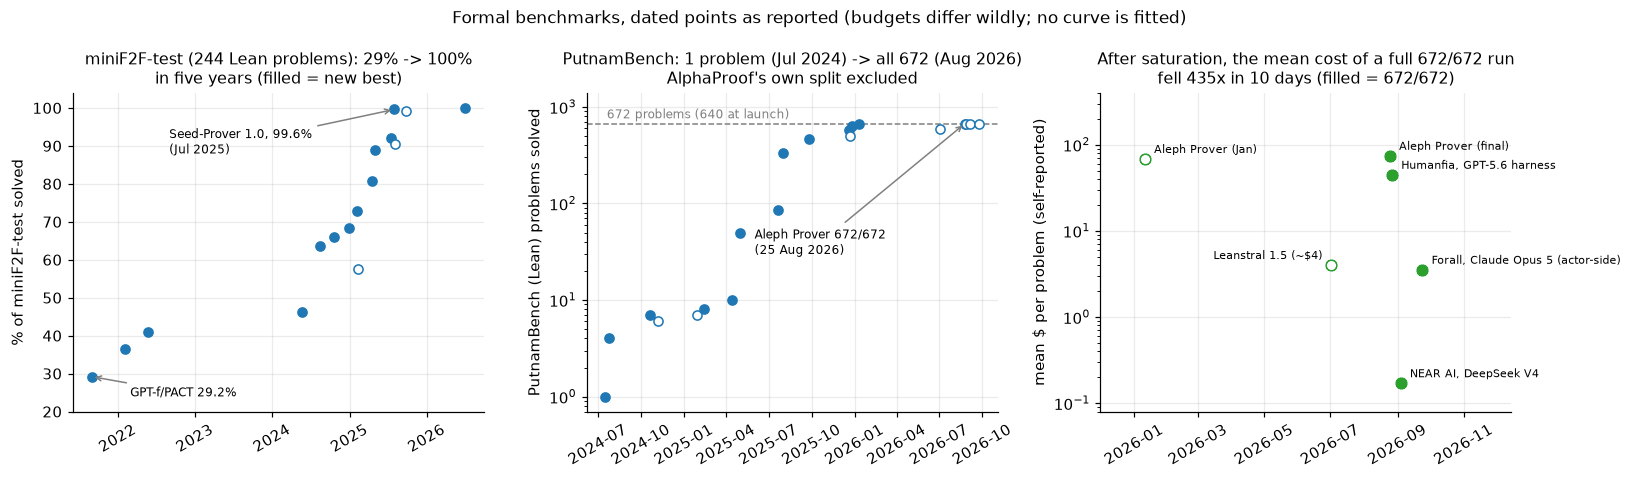

miniF2F: 29.2% -> 100.0%; PutnamBench: 1 -> 672 of 672; mean cost of a 672/672 run: $73.98 (Aleph Prover (final)) -> $0.17 (NEAR AI, DeepSeek V4) per problem (435x).
Program verification lags: Dafny 82%, Verus 44%, Lean 27% (union of models, Sep 2025), and 1/161 when the
model must write the spec as well (CLEVER). The kernel checks proofs; nothing here checks statements.


In [159]:
# 13.4 State of the art (dated and sourced; the sources are printed below the tables; formal vs informal apart).
import datetime as _s13_dt

_s13_MINIF2F = [   # (date, % of miniF2F-test, system). '2025-07' (month only) is plotted mid-month.
    ("2021-08-31", 29.2, "GPT-f/PACT, pass@8"), ("2022-02-03", 36.6, "Polu et al., pass@64"),
    ("2022-05-23", 41.0, "HyperTree Proof Search"), ("2024-05-23", 46.3, "DeepSeek-Prover V1"),
    ("2024-08-15", 63.5, "DeepSeek-Prover-V1.5"), ("2024-10-21", 65.9, "InternLM2.5-StepProver"),
    ("2024-12-30", 68.4, "HunyuanProver 7B"), ("2025-02-05", 72.95, "BFS-Prover 7B"),
    ("2025-02-11", 57.6, "Goedel-Prover-SFT, pass@32"), ("2025-04-15", 80.7, "Kimina-Prover Preview"),
    ("2025-04-30", 88.9, "DeepSeek-Prover-V2"), ("2025-07", 92.2, "Kimina-Prover"),
    ("2025-07-31", 99.6, "Seed-Prover 1.0"), ("2025-08-05", 90.4, "Goedel-Prover-V2, pass@32"),
    ("2025-09-26", 99.2, "Hilbert"), ("2026-07-02", 100.0, "Leanstral 1.5 (open weights)"),
]
_s13_PUTNAM = [    # (date, problems solved, system); PutnamBench Lean track. AlphaProof's split excluded (see prose).
    ("2024-07-17", 1, "COPRA (GPT-4o)"), ("2024-07-24", 4, "InternLM-Math 7B"), ("2024-10-21", 7, "ABEL"),
    ("2024-11-07", 6, "InternLM2.5-StepProver"), ("2025-01-28", 7, "Goedel-Prover-SFT"), ("2025-02-12", 8, "STP"),
    ("2025-04-14", 10, "Kimina-Prover-7B-Distill"), ("2025-04-30", 49, "DeepSeek-Prover-V2"),
    ("2025-07-22", 86, "Goedel-Prover-V2"), ("2025-07-31", 331, "Seed-Prover 1.0"), ("2025-09-26", 462, "Hilbert"),
    ("2025-12-19", 580, "Seed-Prover 1.5"), ("2025-12-23", 500, "Aleph, <= $100/problem"),
    ("2025-12-26", 637, "Aleph, <= $400/problem"), ("2026-01-11", 668, "Aleph, <= $1400/problem"),
    ("2026-07-02", 587, "Leanstral 1.5, pass@8"), ("2026-08-25", 672, "Aleph Prover (final)"),
    ("2026-08-27", 672, "Humanfia"), ("2026-09-04", 672, "NEAR AI agent"), ("2026-09-24", 672, "Forall (Astrio)"),
]
_s13_PUTNAM_COST = [   # (date, mean $ per problem, solved/672, system); all self-reported
    ("2026-01-11", 67.93, 668, "Aleph Prover (Jan)"), ("2026-07-02", 4.0, 587, "Leanstral 1.5 (~$4)"),
    ("2026-08-25", 73.98, 672, "Aleph Prover (final)"), ("2026-08-27", 44.5, 672, "Humanfia, GPT-5.6 harness"),
    ("2026-09-04", 0.17, 672, "NEAR AI, DeepSeek V4"), ("2026-09-24", 3.52, 672, "Forall, Claude Opus 5 (actor-side)"),
]
_s13_MATH = [   # (date, event, system, checked by, statements by, result)
    ("2024-07-25", "IMO 2024", "AlphaProof + AlphaGeometry 2", "Lean kernel; P4 by AlphaGeometry 2's engine",
     "humans", "28/42 (silver), up to 3 days"),
    ("2025-07-23", "IMO 2025", "Seed-Prover (ByteDance)", "Lean kernel; P2 by Seed-Geometry", "humans",
     "30/42 certified; 5/6 post-contest"),
    ("2025-07-28", "IMO 2025", "Aristotle (Harmonic)", "Lean kernel; P2 by its geometry solver", "humans",
     "5/6 machine-checked proofs"),
    ("2025-12-06", "Putnam 2025", "AxiomProver", "Lean kernel", "-", "12/12 (8 within exam time), self-reported"),
    ("2025-12-19", "Putnam 2025", "Seed-Prover 1.5", "Lean kernel", "-", "11/12 within 9 h"),
    ("2026-07-16", "IMO 2026", "AxiomProver", "Lean kernel", "AI", "6/6 (self-reported), 1,496 min"),
    ("2026-07", "IMO 2026", "MechMath", "Lean kernel", "Axiom's", "6/6 (self-reported), 1,178 min"),
    ("2026-09-10", "IMO 2026", "Magenta + K2-Horizon-7B (open)", "Lean + statement judge", "AI",
     "6/6 (preprint, self-reported)"),
    ("2026-09-04", "FLT", "Anthropic, Claude agents", "Lean kernel; comparator", "Mathlib's",
     "complete, ~13M lines, 11 days"),
    ("2025-07-21", "IMO 2025", "Gemini Deep Think", "IMO coordinators", "-", "35/42 gold, certified, 4.5 h"),
    ("2025-07-19", "IMO 2025", "OpenAI experimental model", "former medalists", "-", "35/42, not certified"),
    ("2026-02-05", "First Proof, 10 problems", "frontier LLMs", "First Proof team", "-",
     "confident proofs of 10; 2 correct"),
    ("2026-10-14", "First Proof, batch 3", "ProofCouncil (ETH Zurich)", "human experts", "-", "9/10 for $1,888 total"),
]
_s13_PROGRAMS = [   # (benchmark, date, Dafny, Verus, Lean); every result checked by that language's verifier
    ("DafnyBench hint-filling (782 programs)", "2024-06", "67.8% (Claude 3 Opus)", "-", "-"),
    ("  same task, per the vericoding authors", "2025-09", "96% union; best single 89% (Opus 4.1)", "-", "-"),
    ("Vericoding, union of models (12,504 specs)", "2025-09", "82%", "44%", "27%"),
    ("Vericoding, best single model", "2025-09", "67.5% (Opus 4.1)", "30.9% (GPT-5)", "17.9% (GPT-5)"),
    ("AlgoVeri (77 algorithms), Gemini-3 Flash", "2026-02", "40.3%", "24.7%", "7.8%"),   # abstract's model; not
    # the best per language (paper Table: GPT-5.3 Codex 42.9% Dafny; GPT-OSS-120B at 10x budget 14.3% Lean)
    ("VERINA proofs (189): o3 / Goedel-V2 / 64 rounds", "2026-03", "-", "-", "4.9% / 11.2% / 20.1%"),
    ("VERINA, Aristotle (proved or disproved)", "2025-12", "-", "-", "96.8% (183/189), vendor claim"),
    ("CLEVER end-to-end: spec + code + proof (161)", "2025-05", "-", "-", "1/161"),
]
_s13_STATEMENTS = [   # (date, where, what was wrong, found by): errors in the FORMAL statements themselves
    ("2024-07", "miniF2F (Harmonic re-release)", "statements that had become trivial or impossible",
     "re-formalization"),
    ("2025-09", "vericoding benchmark", "~9% of inspected successful specs too weak, 15% poor translations",
     "manual inspection"),
    ("2026-08", "PutnamBench Lean (Aleph Prover)", "28 formalization errors, all fixes accepted upstream",
     "the prover, while proving"),
    ("2026-08", "PutnamBench Isabelle (Varto, GPT-5.5)", "130 problems needed formalization fixes", "the submitters"),
    ("2026-09", "PutnamBench Lean (NEAR AI, 672/672)", "two problems run against fixed formalizations",
     "the submitters"),
    ("2026-09", "IMO 2026 (Magenta)", "AI-written statements; authors call a statement judge essential",
     "statement judge"),
]
_s13_HACKS = [   # (date, setting, model, rate); the checker is a test suite or a classifier: informal
    ("2025-05", "reward-hack-prone coding tasks", "Claude Sonnet 3.7 / Opus 4 / Sonnet 4", "44% / 9% / 4%"),
    ("2025-06", "METR RE-Bench runs", "OpenAI o3", "30.4% (39/128)"),
    ("2025-06", "METR HCAST runs", "OpenAI o3", "0.7% (8/1,087)"),
    ("2025-10", "ImpossibleBench Oneoff / Conflicting SWE-bench", "GPT-5", "76% / 54%"),
]
_s13_SOURCES = {   # one primary source per table (more in §15)
    "competitions": "DeepMind/ByteDance/Harmonic announcements; arXiv 2507.23726, 2510.01346; "
                    "github.com/AxiomMath/IMO2026; arXiv 2609.11319",
    "FLT": "anthropic.com/research/formalizing-fermats-last-theorem (4 Sep 2026)",
    "PutnamBench": "trishullab/PutnamBench docs/results.json; logicalintelligence.com/aleph-prover-final.html",
    "programs": "arXiv 2406.08467, 2509.22908, 2602.09464, 2505.23135 (v3, Mar 2026), 2505.13938; "
                "harmonic.fun/news/verina-benchmark",
    "statements": "harmonic.fun/news/minif2f; arXiv 2509.22908; PutnamBench results.json; arXiv 2609.11319",
    "reward hacking": "Claude 4 system card Table 6.2.A; metr.org 2025-06-05; arXiv 2510.20270",
}


def _s13_date(s):
    '''ISO date string (or YYYY-MM, read as mid-month) -> datetime.date.'''
    parts = [int(v) for v in s.split("-")] + [15]
    return _s13_dt.date(parts[0], parts[1], parts[2])


def _s13_sota_demo():
    '''Print the dated tables (formal and informal apart) and plot the benchmark curves and the cost collapse.'''
    print("MATHEMATICS -- formal (machine-checked) rows first, then informal (human-graded) rows")
    formal = [r for r in _s13_MATH if "Lean" in r[3]]
    informal = [r for r in _s13_MATH if "Lean" not in r[3]]
    show_table(["date", "event", "system", "checked by", "statements by", "result"],
               [["FORMAL"] + [""] * 5] + sorted(formal) + [["INFORMAL"] + [""] * 5] + sorted(informal))
    print("\nPROGRAM VERIFICATION -- all formal (accepted by the language's verifier); tasks differ, so compare "
          "within a row")
    show_table(["benchmark", "date", "Dafny", "Verus", "Lean"], _s13_PROGRAMS)
    print("\nWHEN THE STATEMENT IS WRONG -- formal artifacts, but the error is in what was proved, not in the proof")
    show_table(["date", "where", "what was wrong", "found by"], _s13_STATEMENTS)
    print("\nWHEN THE CHECKER IS A TEST SUITE -- informal; reward-hacking rates (harnesses differ: compare within "
          "a row)")
    show_table(["date", "setting", "model", "hack rate"], _s13_HACKS)
    for k, v in _s13_SOURCES.items():
        print(f"  source ({k}): {v}")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    for ax, data, ylab in ((axes[0], _s13_MINIF2F, "% of miniF2F-test solved"),
                           (axes[1], _s13_PUTNAM, "PutnamBench (Lean) problems solved")):
        best = -1
        for d, v, _ in sorted(data, key=lambda r: _s13_date(r[0])):
            ax.plot(_s13_date(d), v, "o", ms=6, color="#1f77b4" if v > best else "white", mec="#1f77b4", zorder=3)
            best = max(best, v)
        ax.set_ylabel(ylab)
        ax.tick_params(axis="x", labelrotation=30)
    axes[0].set_ylim(20, 104)
    axes[0].annotate("GPT-f/PACT 29.2%", xy=(_s13_date("2021-08-31"), 29.2), xytext=(_s13_date("2022-03-01"), 24),
                     fontsize=8, arrowprops=dict(arrowstyle="->", color="gray"))
    axes[0].annotate("Seed-Prover 1.0, 99.6%\n(Jul 2025)", xy=(_s13_date("2025-07-31"), 99.6),
                     xytext=(_s13_date("2022-09-01"), 88), fontsize=8, arrowprops=dict(arrowstyle="->", color="gray"))
    axes[0].set_title("miniF2F-test (244 Lean problems): 29% -> 100%\nin five years (filled = new best)", fontsize=10.5)
    axes[1].set_yscale("log")
    axes[1].axhline(672, color="gray", ls="--", lw=1)
    axes[1].text(_s13_date("2024-07-20"), 760, "672 problems (640 at launch)", fontsize=8, color="gray")
    axes[1].annotate("Aleph Prover 672/672\n(25 Aug 2026)", xy=(_s13_date("2026-08-25"), 672),
                     xytext=(_s13_date("2025-06-01"), 30), fontsize=8, arrowprops=dict(arrowstyle="->", color="gray"))
    axes[1].set_ylim(0.7, 1400)
    axes[1].set_title("PutnamBench: 1 problem (Jul 2024) -> all 672 (Aug 2026)\nAlphaProof's own split excluded",
                      fontsize=10.5)
    ax = axes[2]
    for d, cost, solved, name in _s13_PUTNAM_COST:
        ax.plot(_s13_date(d), cost, "o", ms=7, color="#2ca02c" if solved == 672 else "white", mec="#2ca02c", zorder=3)
        left = name.startswith("Leanstral")                    # keep its label clear of Forall's
        ax.annotate(name, xy=(_s13_date(d), cost), xytext=(-6 if left else 6, 4), textcoords="offset points",
                    fontsize=7.5, ha="right" if left else "left")
    ax.set_yscale("log")
    ax.set_ylim(0.08, 400)
    ax.set_xlim(_s13_date("2025-12-01"), _s13_date("2026-12-15"))
    ax.tick_params(axis="x", labelrotation=30)
    ax.set_ylabel("mean $ per problem (self-reported)")
    full = sorted((r for r in _s13_PUTNAM_COST if r[2] == 672), key=lambda r: _s13_date(r[0]))
    first, cheapest = full[0], min(full, key=lambda r: r[1])
    drop = first[1] / cheapest[1]
    days = (_s13_date(cheapest[0]) - _s13_date(first[0])).days
    ax.set_title(f"After saturation, the mean cost of a full 672/672 run\nfell {drop:.0f}x in {days} days "
                 "(filled = 672/672)", fontsize=10.5)
    fig.suptitle("Formal benchmarks, dated points as reported (budgets differ wildly; no curve is fitted)", fontsize=11)
    plt.tight_layout()
    plt.show()
    print(f"miniF2F: {_s13_MINIF2F[0][1]}% -> {max(v for _, v, _ in _s13_MINIF2F)}%; PutnamBench: "
          f"{_s13_PUTNAM[0][1]} -> {max(v for _, v, _ in _s13_PUTNAM)} of 672; mean cost of a 672/672 run: "
          f"${first[1]:.2f} ({first[3]}) -> ${cheapest[1]:.2f} ({cheapest[3]}) per problem ({drop:.0f}x).")
    print("Program verification lags: Dafny 82%, Verus 44%, Lean 27% (union of models, Sep 2025), and 1/161 when the")
    print("model must write the spec as well (CLEVER). The kernel checks proofs; nothing here checks statements.")


_s13_sota_demo()

**What is left for humans to review.** The section's numbers make one argument. A sound checker removes the
proof from the review: §13.1's three proposers, from a uniform sampler to Houdini, got only sound proofs
accepted, and a kernel-checked FLT needs nobody to read 13 million lines. What the checker cannot remove is the
**statement**. §13.2's checker accepted twenty wrong pipelines per right one under a weak spec; §13.3's
`return x * x` passed every mechanical test. The 2026 frontier runs into the same limit. Tao reported on
Mathstodon (21 Jun 2026) that virtually every formalization task he had issued for an analytic-number-theory
Lean project could be completed by AI within hours, in proofs "often hundreds of lines longer" than a human
would write and "somewhat difficult to review". The Lean FRO's Sep 2026 – Feb 2027 roadmap builds one project
(Hex, verified computational-algebra libraries) on exactly this division of labour: humans write specs, AI
agents write code and proofs. So the review that scales has three parts, all small: read the spec, trust a
small checker that is reviewed once (§10), and mechanically close the escape hatches (§13.3). After that the
proposer can be anything, including a model nobody understands. §14 maps the tools where this happens today.

## 14. The landscape and a field guide

The notebook built one readable toy per technique. Real tools are *stacks* of those toys. Dafny's verifier
translates a program into Boogie, an intermediate verification language. Boogie emits SMT queries, and Z3 answers
them. Kani compiles Rust into CBMC's GOTO programs, which CBMC unrolls into SAT instances for CaDiCaL. A user sees
one green tick. Two questions decide what that tick is worth, and the front pages of several tools below do not
even name their solver: **what does the "proved" rest on** (§2.5's trusted computing base, now for real tools),
and **which of the notebook's techniques is it** (§2.4's verdict table). This section answers both from data. It
then shows one way a stack of individually trusted parts goes wrong (the kept failure), sorts the tools by the
notebook's taxonomy, says who pays for them, and ends with a field guide.

### 14.1 What a "proved" rests on

Every tool below is a path through three layers: a **front end** (the language you write code and specs in), zero
or more **intermediate verification languages** (Boogie, Why3, Viper; CBMC's GOTO programs; a proof assistant
used as a target), and a **backend**: an SMT or SAT solver (§3–§4), or a proof assistant's **kernel** (§10). A
tool's "proved" is exactly as trustworthy as every component on the path it took. The data records three kinds
of edge:

- **default**: the backend the tool uses unless told otherwise (or its only documented one). Its UNSAT is trusted.
- **option**: a documented alternative the user can select. It is trusted whenever it is selected.
- **checked**: an untrusted oracle whose output is re-checked. Isabelle's Sledgehammer sends goals to external
  provers and replays their proofs through the kernel. Lean's `bv_decide` sends bit-blasted goals to CaDiCaL and
  checks the returned LRAT certificate inside Lean (§3's RUP check, with hints, run inside the prover).

Every edge was checked against the tool's own documentation or a cited paper; the sources are listed under the
figure (and in §15). The cell also counts, for each backend, how many tools rest on it.

**Registered prediction:** *Z3 sits under so much of the field that it is the **only** documented backend of at
least half of the solver-backed tools in the graph.*

In [160]:
# The stack under each tool, as data: tool -> (TECHNIQUES key, [(path, kind), ...], source). A path runs from the
# tool through intermediate languages to the backend its verdict rests on; kind is 'default' | 'option' |
# 'checked' (see the markdown above). Rarely used options are left out (ESBMC's MathSAT and CVC4, CBMC's MathSAT
# and its own SMT2 solver, SPARK's COLIBRI, Aeneas's F* and HOL4 targets, Why3's Isabelle back end, and Viper's
# second back end Carbon, which also ends in Z3 via Boogie). Boogie's cvc5 and Yices2 are drawn although its README
# calls them experimental: the prediction below is about *documented* backends.
_s14_OWN = [(('own engine',), 'default')]
_s14_STACK = {
    'Dafny': ('deductive', [(('Boogie', 'Z3'), 'default'), (('Boogie', 'cvc5'), 'option'),
                            (('Boogie', 'Yices'), 'option')],
              'Dafny reference manual; Boogie README (cvc5, Yices2 experimental)'),
    'Prusti': ('deductive', [(('Viper', 'Z3'), 'default'), (('Viper', 'cvc5'), 'option')],
               'Prusti README; Viper project page; Silicon Config.scala (--prover)'),
    'Frama-C WP': ('deductive', [(('Why3', 'Alt-Ergo'), 'default'), (('Why3', 'cvc5'), 'option'),
                                 (('Why3', 'Z3'), 'option'), (('Why3', 'Rocq kernel'), 'option')],
                   'WP manual (Frama-C 33.0)'),
    'SPARK': ('deductive', [(('Why3', 'cvc5'), 'default'), (('Why3', 'Z3'), 'option'),
                            (('Why3', 'Alt-Ergo'), 'option')],
              'SPARK user guide: alternative provers ("cvc5 only" by default), --level 1-4; why3.org'),
    'Creusot': ('deductive', [(('Why3', 'Alt-Ergo'), 'option'), (('Why3', 'Z3'), 'option'),
                              (('Why3', 'cvc5'), 'option')], 'Creusot README; why3.org'),
    'Kani': ('bmc', [(('CBMC', 'CaDiCaL'), 'default'), (('CBMC', 'MiniSat'), 'option'),
                     (('CBMC', 'Kissat'), 'option'), (('CBMC', 'Z3'), 'option'), (('CBMC', 'Bitwuzla'), 'option'),
                     (('CBMC', 'cvc5'), 'option')],
             'Kani docs (kani::solver); Kani repository (pinned CBMC and Kissat)'),
    'Aeneas': ('itp', [(('Lean 4', 'Lean kernel'), 'default'), (('Rocq', 'Rocq kernel'), 'option')],
               'Aeneas README (Lean, Coq, F*, HOL4 backends); MSR blog, Jul 2026 (SymCrypt via Lean)'),
    'Verus': ('deductive', [(('Z3',), 'default'), (('cvc5',), 'option')],
              'Verus guide; Verus config.rs (-V cvc5)'),
    'F*': ('deductive', [(('Z3',), 'default')], 'F* book, introduction'),
    'Alive2': ('equivalence', [(('Z3',), 'default')], 'Alive2 README'),
    'Apalache': ('bmc', [(('Z3',), 'default')], 'apalache-mc.org'),
    'Zelkova': ('equivalence', [(('Z3',), 'default'), (('cvc5',), 'default')],
                'Rungta, CAV 2022 (portfolio also runs CVC4 and an automaton solver)'),
    'ESBMC': ('bmc', [(('Boolector',), 'default'), (('Z3',), 'option'), (('Bitwuzla',), 'option'),
                      (('Yices',), 'option'), (('cvc5',), 'option')], 'ESBMC README + documentation'),
    'SymbiYosys': ('k_induction', [(('Yices',), 'option'), (('Boolector',), 'option'), (('Bitwuzla',), 'option'),
                                   (('Z3',), 'option'), (('ABC',), 'option')], 'sby reference: engines'),
    'KLEE': ('symex', [(('STP',), 'option'), (('Z3',), 'option')], 'KLEE docs: solver chain'),
    'CBMC': ('bmc', [(('MiniSat',), 'default'), (('CaDiCaL',), 'option'), (('Z3',), 'option'),
                     (('cvc5',), 'option'), (('Bitwuzla',), 'option'), (('Boolector',), 'option'),
                     (('Yices',), 'option')],
             'cbmc(1) man page, backend options; CBMC COMPILING.md'),
    'Lean 4': ('itp', [(('Lean kernel',), 'default'), (('CaDiCaL',), 'checked')],
               'lean4 src/kernel (§10.6); Lean 4.12.0 release notes (bv_decide)'),
    'Isabelle/HOL': ('itp', [(('Isabelle kernel',), 'default'), (('E / Vampire',), 'checked'),
                             (('Z3',), 'checked'), (('cvc5',), 'checked')], 'Sledgehammer manual'),
    'Rocq': ('itp', [(('Rocq kernel',), 'default')], 'rocq kernel/ directory (§10.6)'),
    'HOL Light': ('itp', [(('HOL Light kernel',), 'default')], 'HOL Light fusion.ml (§10.6)'),
    'TLC (TLA+)': ('model_checking', _s14_OWN, 'TLA+ tools repository; Lamport, Specifying Systems (TLC)'),
    'SPIN': ('model_checking', _s14_OWN, 'spinroot.com; Holzmann, IEEE TSE 1997'),
    'Astrée': ('abstract_interp', _s14_OWN, 'Astrée project page; Blanchet et al., PLDI 2003'),
    'Frama-C Eva': ('abstract_interp', _s14_OWN, 'frama-c.com (Eva plug-in)'),
    'Infer (Pulse)': ('symex', _s14_OWN, 'fbinfer.com; §9 (Pulse is under-approximate)'),
    'JasperGold, VC Formal': ('k_induction', _s14_OWN, 'Cadence and Synopsys, 2014 (engines proprietary)'),
}
_s14_IL = ('Boogie', 'Viper', 'Why3')               # pure intermediate verification languages
# backend -> (kind, row in the right-hand column of the figure)
_s14_BACKENDS = {'Z3': ('SMT', 0), 'cvc5': ('SMT', 1), 'Alt-Ergo': ('SMT', 2), 'Yices': ('SMT', 3),
                 'Boolector': ('SMT', 4), 'Bitwuzla': ('SMT', 5), 'STP': ('SMT', 6), 'ABC': ('AIG engine', 7),
                 'MiniSat': ('SAT', 8), 'CaDiCaL': ('SAT', 9), 'Kissat': ('SAT', 10), 'E / Vampire': ('ATP', 11),
                 'Lean kernel': ('kernel', 12), 'Isabelle kernel': ('kernel', 13), 'Rocq kernel': ('kernel', 14),
                 'HOL Light kernel': ('kernel', 15), 'own engine': ('own', 17.5)}
# Kernel sizes counted in each project's repository (Oct 2026); §10.6 tabulates them with their caveats and links.
_s14_KERNEL_LOC = {'Lean kernel': '7,875 lines C++', 'Isabelle kernel': 'thm.ML alone: 2,796 lines SML',
                   'Rocq kernel': 'kernel/ dir. incl. VM: 44,319 OCaml + 3,195 C',
                   'HOL Light kernel': '676 lines OCaml'}
_s14_ROW_B = ['Boogie', 'Viper', 'Verus', 'F*', 'Alive2', 'Apalache', 'Zelkova', 'Why3', 'ESBMC', 'SymbiYosys',
              'KLEE', 'CBMC', 'Lean 4', 'Isabelle/HOL', 'Rocq', 'HOL Light', 'TLC (TLA+)', 'SPIN', 'Astrée',
              'Frama-C Eva', 'Infer (Pulse)', 'JasperGold, VC Formal']
_s14_ROW_A = {'Dafny': 0, 'Prusti': 1, 'Frama-C WP': 6, 'SPARK': 7, 'Creusot': 8, 'Kani': 11, 'Aeneas': 12}
_s14_FAMILY_EDGE = {'under': '#1f77b4', 'exact': '#6a3d9a', 'over': '#b35806'}
_s14_KIND_FILL = {'SMT': '#ffd9b3', 'SAT': '#ffd9b3', 'AIG engine': '#ffd9b3', 'ATP': '#ffd9b3',
                  'kernel': '#d9ead3', 'own': '#eeeeee'}
_s14_RANK = {'default': 3, 'option': 2, 'checked': 1}


def _s14_short(s, n):
    '''Truncate s to n characters with an ellipsis.'''
    return s if len(s) <= n else s[:n - 1] + "…"


def _s14_plural(n, word):
    '''"1 tool", "3 tools".'''
    return f"{n} {word}" + ("" if n == 1 else "s")


def _s14_exposure():
    '''backend -> {'default': tools, 'option': tools, 'checked': tools}: who rests on each backend, and how.'''
    out = {b: {'default': set(), 'option': set(), 'checked': set()} for b in _s14_BACKENDS}
    for tool, (_, paths, _) in _s14_STACK.items():
        for path, kind in paths:
            out[path[-1]][kind].add(tool)
    return out


def _s14_edges():
    '''Drawn edges with their strongest kind. An edge into an intermediate is 'default' when every path of the tool
    goes through it (Creusot always uses Why3, even though its solver is the user's choice).'''
    edges = {}
    for tool, (_, paths, _) in _s14_STACK.items():
        for path, kind in paths:
            nodes = (tool,) + path
            for i, (u, v) in enumerate(zip(nodes, nodes[1:])):
                into_layer = i < len(path) - 1                   # an edge into an intermediate, not a backend
                always = all(len(p) > 1 and p[0] == v for p, _ in paths)
                k = 'default' if into_layer and always else kind
                if _s14_RANK[k] > _s14_RANK.get(edges.get((u, v)), 0):
                    edges[(u, v)] = k
    return edges


def _s14_default_users():
    '''(node, backend) -> the tools whose DEFAULT path ends with that edge. A node that several tools pass through
    can carry different defaults for different tools: Why3 under Frama-C WP and under SPARK, and CBMC both as a
    tool of its own (MiniSat) and as Kani's back end (CaDiCaL). The figure labels such edges with their tools.'''
    out = defaultdict(set)
    for tool, (_, paths, _) in _s14_STACK.items():
        for path, kind in paths:
            if kind == 'default':
                nodes = (tool,) + path
                out[nodes[-2], nodes[-1]].add(tool)
    return dict(out)


def _s14_solver_backed():
    '''Tools with at least one trusted (default or option) path into an SMT/SAT solver or AIG engine.'''
    return sorted(t for t, (_, paths, _) in _s14_STACK.items()
                  if any(k != 'checked' and _s14_BACKENDS[p[-1]][0] in ('SMT', 'SAT', 'AIG engine')
                         for p, k in paths))


_s14_n_paths = sum(len(paths) for _, paths, _ in _s14_STACK.values())
print(f"recorded: {len(_s14_STACK)} tools, {_s14_n_paths} documented paths to a backend, "
      f"{len(_s14_edges())} distinct drawn edges, each path tagged with its source")

recorded: 26 tools, 63 documented paths to a backend, 58 distinct drawn edges, each path tagged with its source


The figure lays the graph out in three columns: front ends that compile to an intermediate language, then the
intermediate languages and the tools that encode directly, then the backends, each annotated with how many tools
rest on it and how. Where one node carries the defaults of different tools (Why3 under Frama-C WP and under SPARK;
CBMC on its own and as Kani's back end), each of its solid edges names the tool whose default it is. The same cell
counts the exposure of every backend and scores the prediction.

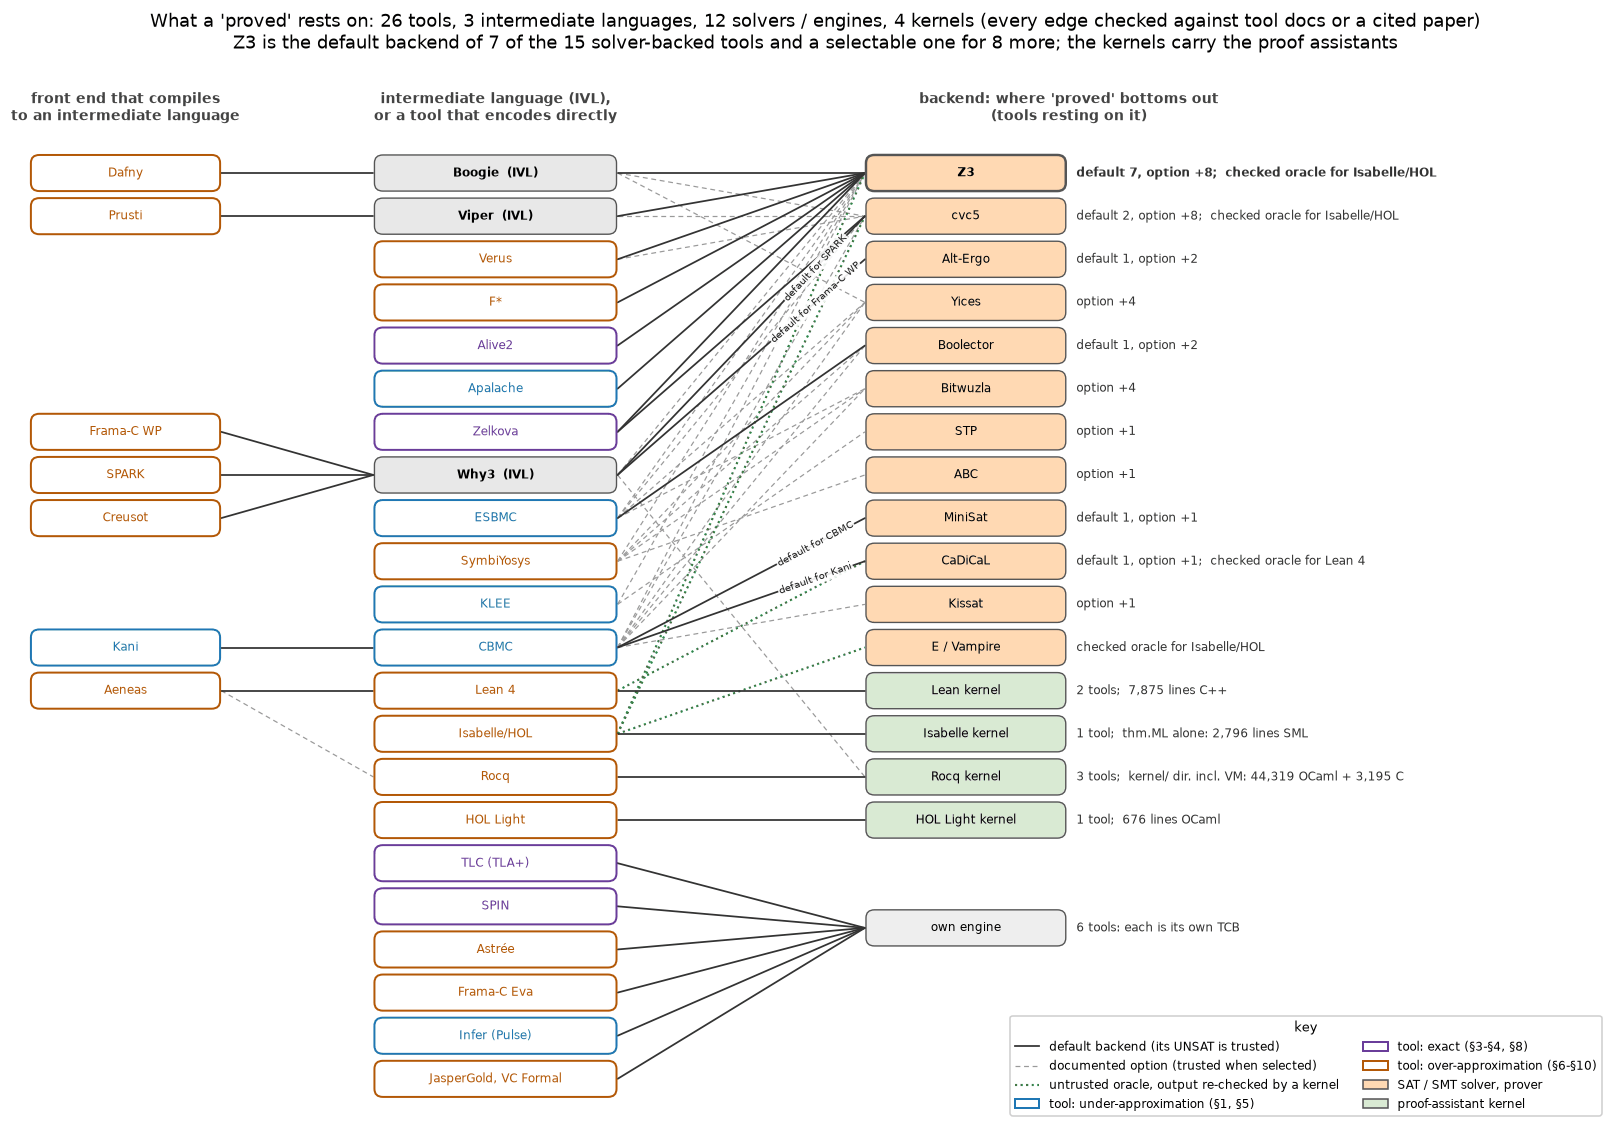

backend           kind        default for  option for (more)  checked oracle for  tools that trust it                                             
--------------------------------------------------------------------------------------------------------------------------------------------------
Z3                SMT         7            8                  1                   Alive2, Apalache, CBMC, Creusot, Dafny, ESBMC, F*, Frama-C WP, …
cvc5              SMT         2            8                  1                   CBMC, Creusot, Dafny, ESBMC, Frama-C WP, Kani, Prusti, SPARK, V…
own engine        own         6            0                  0                   Astrée, Frama-C Eva, Infer (Pulse), JasperGold, VC Formal, SPIN…
Bitwuzla          SMT         0            4                  0                   CBMC, ESBMC, Kani, SymbiYosys                                   
Yices             SMT         0            4                  0                   CBMC, Dafny, ESBMC, SymbiYosys      

In [161]:
def _s14_box(ax, x, y, w, h, text, fc, ec="#555555", color="black", fs=8, bold=False, lw=0.9):
    '''A rounded box of width w and height h, left edge x, vertically centred on y, with centred text.'''
    ax.add_patch(FancyBboxPatch((x, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec,
                                lw=lw, zorder=3))
    ax.text(x + w / 2, y, text, ha="center", va="center", fontsize=fs, color=color, zorder=4,
            fontweight="bold" if bold else "normal")


def _s14_draw_stack(ax, exposure):
    '''The dependency graph: front ends -> intermediate languages / direct encoders -> solvers and kernels.'''
    top, dy, h = 9.55, 0.43, 0.32
    xa, wa, xb, wb, xc, wc = 0.1, 1.75, 3.35, 2.25, 8.0, 1.85
    pos = {}
    for t, r in _s14_ROW_A.items():
        pos[t] = (xa, wa, top - r * dy)
    for r, t in enumerate(_s14_ROW_B):
        pos[t] = (xb, wb, top - r * dy)
    for b, (_, r) in _s14_BACKENDS.items():
        pos[b] = (xc, wc, top - r * dy)
    ax.set_xlim(0, 15)                          # fixed before any label is angled along an edge
    ax.set_ylim(top - 22 * dy, top + 1.15)
    style = {'option': dict(color="#9a9a9a", lw=0.8, ls=(0, (4, 3)), zorder=1),
             'checked': dict(color="#2ca02c", lw=1.4, ls=(0, (1, 1.6)), zorder=1.5),
             'default': dict(color="#333333", lw=1.15, ls="-", zorder=2)}
    for (u, v), k in sorted(_s14_edges().items(), key=lambda e: _s14_RANK[e[1]]):
        (x0, w0, y0), (x1, _, y1) = pos[u], pos[v]
        ax.plot([x0 + w0 + 0.03, x1 - 0.03], [y0, y1], solid_capstyle="round", **style[k])
    users = _s14_default_users()
    owners = defaultdict(set)
    for (u, _), ts in users.items():
        owners[u].add(frozenset(ts))
    for (u, v), ts in users.items():
        if len(owners[u]) > 1:                  # one node, different tools' defaults: say whose each solid edge is
            (x0, w0, y0), (x1, _, y1) = pos[u], pos[v]
            xs, xe, t = x0 + w0 + 0.03, x1 - 0.03, 0.8
            at = np.array([xs + t * (xe - xs), y0 + t * (y1 - y0)])
            ang = ax.transData.transform_angles(np.array([np.degrees(np.arctan2(y1 - y0, xe - xs))]),
                                                at.reshape(1, 2))[0]    # write along the edge it labels
            ax.text(*at, "default for " + ", ".join(sorted(ts)), fontsize=6.8, rotation=ang, rotation_mode="anchor",
                    ha="center", va="center", color="#222222", zorder=2.5,
                    bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.9))
    for t, (tech, _, _) in _s14_STACK.items():
        fam = TECHNIQUES[tech]['family']
        x, w, y = pos[t]
        _s14_box(ax, x, y, w, h, t, "white", ec=_s14_FAMILY_EDGE[fam], color=_s14_FAMILY_EDGE[fam], lw=1.3)
    for t in _s14_IL:
        x, w, y = pos[t]
        _s14_box(ax, x, y, w, h, t + "  (IVL)", "#e8e8e8", fs=8, bold=True)
    for b, (kind, _) in _s14_BACKENDS.items():
        x, w, y = pos[b]
        e = exposure[b]
        _s14_box(ax, x, y, w, h, b, _s14_KIND_FILL[kind], bold=(b == 'Z3'), lw=1.6 if b == 'Z3' else 0.9)
        extra = sorted(e['option'] - e['default'])
        if kind == 'own':
            note = f"{len(e['default'])} tools: each is its own TCB"
        elif kind == 'kernel':
            note = _s14_plural(len(e['default'] | e['option']), "tool") + (
                f";  {_s14_KERNEL_LOC[b]}" if b in _s14_KERNEL_LOC else "")
        else:
            note = (f"default {len(e['default'])}" if e['default'] else "") + \
                   (f"{', ' if e['default'] else ''}option +{len(extra)}" if extra else "")
            if e['checked']:
                note += f"{';  ' if note else ''}checked oracle for {', '.join(sorted(e['checked']))}"
        ax.text(x + w + 0.12, y, note, va="center", fontsize=7.8, color="#333333",
                fontweight="bold" if b == 'Z3' else "normal")
    for x, w, label in ((xa, wa, "front end that compiles\nto an intermediate language"),
                        (xb, wb, "intermediate language (IVL),\nor a tool that encodes directly"),
                        (xc, wc + 2.6, "backend: where 'proved' bottoms out\n(tools resting on it)")):
        ax.text(x + w / 2 if x < 7 else x + 1.9, top + 0.48, label, ha="center", va="bottom", fontsize=9,
                fontweight="bold", color="#444444")
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    handles = [Line2D([], [], **{k: v for k, v in style['default'].items() if k != 'zorder'},
                      label="default backend (its UNSAT is trusted)"),
               Line2D([], [], **{k: v for k, v in style['option'].items() if k != 'zorder'},
                      label="documented option (trusted when selected)"),
               Line2D([], [], **{k: v for k, v in style['checked'].items() if k != 'zorder'},
                      label="untrusted oracle, output re-checked by a kernel"),
               Patch(fc="white", ec=_s14_FAMILY_EDGE['under'], lw=1.3, label="tool: under-approximation (§1, §5)"),
               Patch(fc="white", ec=_s14_FAMILY_EDGE['exact'], lw=1.3, label="tool: exact (§3-§4, §8)"),
               Patch(fc="white", ec=_s14_FAMILY_EDGE['over'], lw=1.3, label="tool: over-approximation (§6-§10)"),
               Patch(fc="#ffd9b3", ec="#555555", label="SAT / SMT solver, prover"),
               Patch(fc="#d9ead3", ec="#555555", label="proof-assistant kernel")]
    ax.legend(handles=handles, loc="lower right", fontsize=8, frameon=True, framealpha=0.95,
              bbox_to_anchor=(1.0, 0.0), ncol=2, title="key", title_fontsize=8.5)
    ax.set_axis_off()


def _s14_stack_demo():
    '''Draw the graph, count who rests on what, score the registered prediction.'''
    assert all(src for _, _, src in _s14_STACK.values()), "every tool record names its source"
    assert all(p[-1] in _s14_BACKENDS for _, paths, _ in _s14_STACK.values() for p, _ in paths)
    exposure = _s14_exposure()
    backed = _s14_solver_backed()
    trusted = {t: {p[-1] for p, k in _s14_STACK[t][1] if k != 'checked'} for t in backed}
    z3_default = [t for t in backed if any(p[-1] == 'Z3' and k == 'default' for p, k in _s14_STACK[t][1])]
    z3_any = [t for t in backed if 'Z3' in trusted[t]]
    z3_only = [t for t in backed if trusted[t] == {'Z3'}]
    tools = [t for t in _s14_STACK]
    n_solvers = sum(k in ('SMT', 'SAT', 'AIG engine', 'ATP') for k, _ in _s14_BACKENDS.values())
    n_kernels = sum(k == 'kernel' for k, _ in _s14_BACKENDS.values())

    fig, ax = plt.subplots(figsize=(15, 10.4))
    _s14_draw_stack(ax, exposure)
    ax.set_title(f"What a 'proved' rests on: {len(tools)} tools, {len(_s14_IL)} intermediate languages, "
                 f"{n_solvers} solvers / engines, {n_kernels} kernels "
                 "(every edge checked against tool docs or a cited paper)\n"
                 f"Z3 is the default backend of {len(z3_default)} of the {len(backed)} solver-backed tools and a "
                 f"selectable one for {len(z3_any) - len(z3_default)} more; the kernels carry the proof assistants",
                 fontsize=11.5)
    plt.tight_layout()
    plt.show()

    rows = []
    for b, (kind, _) in _s14_BACKENDS.items():
        e = exposure[b]
        rows.append([b, kind, len(e['default']), len(e['option'] - e['default']), len(e['checked']),
                     _s14_short(", ".join(sorted(e['default'] | e['option'])), 64)])
    rows.sort(key=lambda r: (-(r[2] + r[3]), r[0]))
    show_table(["backend", "kind", "default for", "option for (more)", "checked oracle for", "tools that trust it"],
               rows)
    big3 = {'Z3', 'cvc5', 'Alt-Ergo'}
    defaults = {t: {p[-1] for p, k in _s14_STACK[t][1] if k == 'default'} for t in backed}
    d3 = [t for t in backed if defaults[t] & big3]
    a3 = [t for t in backed if trusted[t] & big3]
    print(f"\nsolver-backed tools: {len(backed)}  |  Z3 default for {len(z3_default)}, selectable by "
          f"{len(z3_any)}, the ONLY backend of {len(z3_only)}: {', '.join(z3_only)}")
    print(f"Z3, cvc5 or Alt-Ergo is a default of {len(d3)} of {len(backed)} and selectable by {len(a3)}; other "
          f"defaults: " + ", ".join(f"{t} -> {'/'.join(sorted(defaults[t]))}" for t in backed
                                    if defaults[t] and not defaults[t] & big3)
          + "; no documented default: " + ", ".join(t for t in backed if not defaults[t]))
    frac = len(z3_only) / len(backed)
    print(f"registered prediction: Z3 is the only documented backend of at least half the solver-backed tools | "
          f"measured: {len(z3_only)} of {len(backed)} ({frac:.0%}) | verdict: {'RIGHT' if frac >= 0.5 else 'WRONG'}"
          f" -- Z3 is the DEFAULT of {len(z3_default)} and selectable by {len(z3_any)}, but most tools document "
          "an alternative")
    print("Trust is concentrated by defaults more than by necessity: a handful of solvers and four kernels carry")
    print("every solver- or kernel-backed 'proved' in the picture; only the kernels were designed to be audited.")


_s14_stack_demo()

**Reading the graph.** The registered prediction overshoots badly. Only one in five of the solver-backed tools has
Z3 as its only documented backend: F\*, Alive2 and Apalache. Dafny, Prusti and Verus look like Z3 tools, and Z3 is
their default, but each documents cvc5 as an alternative: Boogie (under Dafny) supports cvc5 and Yices2, which its
README calls experimental; Viper's Silicon back end (under Prusti) takes `--prover cvc5`; and Verus has `-V cvc5`.
Z3 is the default of 7 of the 15 and selectable by all 15, CBMC included (`--z3`). Add cvc5 and Alt-Ergo and
**three SMT solvers are a default backend of 9 of the 15 tools and selectable by all 15**. The other defaults are
SAT solvers (Kani → CaDiCaL, CBMC → MiniSat) and Boolector (ESBMC); Creusot, KLEE and SymbiYosys document no
default and leave the choice to the user, and SPARK's default is cvc5 alone (Z3 and Alt-Ergo join from
`--level 1`). So trust is concentrated more by defaults than by necessity. The defaults are sticky, though:
Boogie's README says its test suite "assumes version 4.11.2" of Z3. Pinning a solver version is how tools live
with §7's proof instability, where an unchanged proof can fail under a different solver or version.

The other end of the graph is where the notebook's "check the product" principle (§2.5) is implemented for real.
The proof assistants rest on kernels designed to be audited, from HOL Light's 676-line `fusion.ml` to Rocq's
`kernel/` directory, 44k lines including a bytecode VM (§10.6 tabulates the counts and their caveats). Even when
they call a solver, they do not trust it. Sledgehammer "reconstructs the proof within Isabelle", with "explicit
inferences going through the kernel" (Sledgehammer manual), and `bv_decide` checks CaDiCaL's LRAT proof in Lean.
The fine print matters there: the check runs through `Lean.ofReduceBool`, so "this tactic includes the Lean
compiler as part of the trusted code base" (Lean 4.12.0 release notes). The graph also shows six tools that trust
nobody but themselves: TLC, SPIN, Astrée, Frama-C Eva, Infer and the commercial hardware engines carry their own
algorithms all the way down.

*Edges checked* (Oct 2026), each against the tool's own documentation or source unless a paper is named:
[Dafny reference manual](https://dafny.org/latest/DafnyRef/DafnyRef) (the verifier is powered by Boogie and
Z3); Boogie ["the default SMT solver for Boogie is Z3"](https://github.com/boogie-org/boogie), with cvc5 and
Yices2 selectable through `/proverOpt:SOLVER=` and called experimental (drawn as options);
[Verus guide](https://verus-lang.github.io/verus/guide/) (Z3) and Verus's
[`config.rs`](https://github.com/verus-lang/verus/blob/main/source/rust_verify/src/config.rs) (`-V cvc5`: "Use the
cvc5 SMT solver, rather than the default (Z3)"); [F\* book](https://fstar-lang.org/tutorial/book/intro.html)
("integrates the Z3 SMT Solver"); [Prusti](https://github.com/viperproject/prusti-dev) builds on Viper, whose
[Silicon back end](https://www.pm.inf.ethz.ch/research/viper.html) defaults to Z3 and accepts cvc5
([`--prover`](https://github.com/viperproject/silicon/blob/master/src/main/scala/Config.scala)) and whose Carbon
goes through Boogie; [WP manual, Frama-C 33.0](https://frama-c.com/download/frama-c-wp-manual.pdf) (requires Why3;
Alt-Ergo, CVC5, Z3, Coq); [why3.org](https://www.why3.org/) (provers; Frama-C, SPARK 2014 and Creusot among its
users); SPARK's
[alternative provers](https://docs.adacore.com/spark2014-docs/html/ug/en/appendix/alternative_provers.html) ("By
default, GNATprove uses prover cvc5 only") and
[user guide](https://docs.adacore.com/spark2014-docs/html/ug/en/source/how_to_run_gnatprove.html) (cvc5, Z3,
Alt-Ergo at levels 1–4); [Creusot](https://github.com/creusot-rs/creusot) (Why3's Coma); Kani → CBMC (the
[Kani repository](https://github.com/model-checking/kani) pins CBMC 6.11.0 and Kissat 4.0.1) with
[`kani::solver`](https://model-checking.github.io/kani/reference/attributes.html) (CaDiCaL default; MiniSat,
Kissat, Z3, Bitwuzla, cvc5); CBMC's
[man page](https://raw.githubusercontent.com/diffblue/cbmc/develop/doc/man/cbmc.1) (backend options `--z3`,
`--cvc5`, `--bitwuzla`, `--boolector`, `--yices`, `--mathsat`) and
[build notes](https://raw.githubusercontent.com/diffblue/cbmc/develop/COMPILING.md) (MiniSat2 and CaDiCaL linked
into releases); [ESBMC](https://ssvlab.github.io/esbmc/documentation.html) (Boolector default; Z3, Bitwuzla,
Yices, cvc5 and others); [KLEE](https://klee-se.org/docs/solver-chain/) (STP, Z3, metaSMT, default fixed at build
time); [SymbiYosys](https://yosyshq.readthedocs.io/projects/sby/en/latest/reference.html) (smtbmc with yices,
boolector, bitwuzla, z3, …; abc pdr/bmc3); [Alive2](https://github.com/AliveToolkit/alive2) and
[Apalache](https://apalache-mc.org/) (Z3); Zelkova (Rungta, CAV 2022, summarized on
[Amazon Science](https://www.amazon.science/blog/a-billion-smt-queries-a-day): Z3, CVC4, cvc5 and a custom
automaton solver); [Aeneas](https://github.com/AeneasVerif/aeneas) ("backends for F\*, Coq, HOL4 and LEAN"),
used through Lean for SymCrypt (Microsoft Research
[blog](https://www.microsoft.com/en-us/research/blog/verifying-rust-cryptography-in-symcrypt-from-standards-to-code/),
Jul 2026); [Lean 4.12.0](https://lean-lang.org/doc/reference/latest/releases/v4.12.0/) (`bv_decide`);
[Sledgehammer](https://isabelle.in.tum.de/dist/doc/sledgehammer.pdf); kernel sizes counted in each repository
(§10.6 links them). Tools that ship their own engine have no outgoing solver edge to check; their project pages
are listed in §15.

### 14.2 A portfolio is not a cross-check (the kept failure)

Several tools in the graph run more than one backend. GNATprove's levels 1–4 pass every verification condition to
cvc5, Z3 and Alt-Ergo, which "are tried in order on each VC, until one of them succeeds or all fail" (SPARK user
guide). Zelkova runs a portfolio of Z3, CVC4, cvc5 and an automaton solver (Rungta, CAV 2022). For speed this is
excellent. For trust it is easy to misread: diversity sounds like redundancy, as if three solvers checked each
other. They do not. Under **first proof wins**, the TCB is the *union* of the members, because any one member's
false "proved" goes straight through.

The experiment makes the mechanism visible on a scale where the ground truth is known. It generates random
lemmas about two `int8` variables (guard ⇒ comparison of `+`, `-`, `>> 1` terms; midpoint-like facts) and
computes ground truth by enumerating all 65,536 input pairs. Three **verifier builds** then try to prove each lemma
with Z3. Build A encodes it correctly (8-bit two's complement, signed `<`). Build B forgets wrap-around: it uses
§2's `'int'` semantics on `bv8` code, the bug behind `midpoint_buggy`. Build C wraps correctly but compiles `<` to
the *unsigned* `bvult`. Each build reports the violation closest to zero, so the run is reproducible, and every
counterexample is replayed concretely (§2.5). The table compares each build alone with four ways to combine them:
first proof wins, majority vote, unanimity, and a **veto** rule (a replayed counterexample overrides any number of
proofs).

**Registered prediction:** *the first-proof-wins portfolio is at least as safe as its worst member: it reports no
more false "proved" verdicts than the worst single build.*

In [162]:
_s14_SEED_LEMMAS = 14
_s14_N_LEMMAS = 300
_s14_W = 8                                     # int8: small enough to enumerate every (x, y) pair as ground truth
_s14_LO, _s14_HI = -2 ** (_s14_W - 1), 2 ** (_s14_W - 1) - 1
_s14_CONSTS = (0, 1, 2, -1, 100, 127, -128)
_s14_BUILDS = {'A': "bit-vectors, signed <  (correct)",
               'B': "mathematical integers (forgets wrap)",
               'C': "bit-vectors, unsigned <  (bvult for bvslt)"}
_s14_BUILD_SEM = {'A': 'bv', 'B': 'int', 'C': 'unsigned'}
_s14_POLICIES = ['A', 'B', 'C', 'first proof wins', 'majority (2 of 3)', 'unanimous', 'veto by replayed cex']


def _s14_rand_expr(rnd, depth):
    '''A random term over x, y and a few edge constants: 'x' | 'y' | int | ('+'|'-', a, b) | ('>>', a).'''
    if depth == 0 or rnd.random() < 0.3:
        return rnd.choice(['x', 'y', 'x', 'y', rnd.choice(_s14_CONSTS)])
    op = rnd.choice(['+', '-', '+', '>>'])
    if op == '>>':
        return ('>>', _s14_rand_expr(rnd, depth - 1))
    return (op, _s14_rand_expr(rnd, depth - 1), _s14_rand_expr(rnd, depth - 1))


def _s14_rand_lemma(rnd):
    '''guards => conclusion, with 0-2 guards like a requires clause and one comparison as the claim.'''
    guards = [(rnd.choice(['<', '<=']), _s14_rand_expr(rnd, 0), _s14_rand_expr(rnd, 0))
              for _ in range(rnd.choice([0, 1, 2]))]
    return guards, (rnd.choice(['<', '<=', '==', '!=']), _s14_rand_expr(rnd, 2), _s14_rand_expr(rnd, 2))


def _s14_term_str(e):
    '''A term as Python-like source text.'''
    if isinstance(e, (int, str)):
        return str(e)
    return f"({_s14_term_str(e[1])} >> 1)" if e[0] == '>>' else \
        f"({_s14_term_str(e[1])} {e[0]} {_s14_term_str(e[2])})"


def _s14_lemma_str(lemma):
    '''A lemma as text: "guard and guard  =>  claim".'''
    guards, (op, l, r) = lemma
    claim = f"{_s14_term_str(l)} {op} {_s14_term_str(r)}"
    return (" and ".join(f"{_s14_term_str(a)} {g} {_s14_term_str(b)}" for g, a, b in guards) + "  =>  " + claim
            if guards else claim)


def _s14_eval(e, X, Y, sem):
    '''Vectorised evaluation of a term under one build's semantics ('bv' and 'unsigned' wrap, 'int' does not).'''
    if isinstance(e, int):
        return np.full_like(X, e)
    if isinstance(e, str):
        return X if e == 'x' else Y
    if e[0] == '>>':
        return _s14_eval(e[1], X, Y, sem) >> 1          # arithmetic shift = floor(e / 2) in every build
    a, b = _s14_eval(e[1], X, Y, sem), _s14_eval(e[2], X, Y, sem)
    v = a + b if e[0] == '+' else a - b
    return v if sem == 'int' else ((v - _s14_LO) & ((1 << _s14_W) - 1)) + _s14_LO


def _s14_cmp(op, a, b, sem):
    '''A comparison under a build's semantics; build C reads '<' and '<=' on the unsigned bit patterns.'''
    if sem == 'unsigned' and op in ('<', '<='):
        a, b = a & ((1 << _s14_W) - 1), b & ((1 << _s14_W) - 1)    # read the bit pattern as unsigned
    return {'<': a < b, '<=': a <= b, '==': a == b, '!=': a != b}[op]


def _s14_holds(lemma, X, Y, sem):
    '''Boolean array: does the lemma hold at each (x, y) under the semantics sem?'''
    guards, (op, l, r) = lemma
    ok = np.ones(X.shape, dtype=bool)
    for g, a, b in guards:
        ok &= _s14_cmp(g, _s14_eval(a, X, Y, sem), _s14_eval(b, X, Y, sem), sem)
    return ~ok | _s14_cmp(op, _s14_eval(l, X, Y, sem), _s14_eval(r, X, Y, sem), sem)


_s14_demo_lemma = _s14_rand_lemma(random.Random(_s14_SEED_LEMMAS))
print(f"a lemma from the generator: {_s14_lemma_str(_s14_demo_lemma)}")
print("ground truth is int8 wrap-around semantics ('bv'), evaluated on all 65,536 (x, y) pairs at once")

a lemma from the generator: x <= ((x >> 1) >> 1)
ground truth is int8 wrap-around semantics ('bv'), evaluated on all 65,536 (x, y) pairs at once


Each build is the same Z3 encoder with its own semantics; an enumeration of all 65,536 pairs under that build's
semantics decides the same question independently. A policy then turns the three replayed verdicts into one
answer.

In [163]:
def _s14_z3_build(lemma, build, timeout_ms=2000):
    '''One verifier build: encode the lemma per the build's semantics and ask Z3 for a violation. When there is
    one, the build reports the one closest to zero (smallest |x|, then |y|, then the smaller signed values) via
    Z3's Optimize, so the verdict and the counterexample depend only on the lemma and the build. An arbitrary Z3
    model did not: it differed between a run of this section alone and a run of the whole notebook, even in a
    fresh z3.Context.'''
    sem = _s14_BUILD_SEM[build]
    ctx = z3.Context()
    if sem == 'int':
        x, y = z3.Ints('x y', ctx)
        const = lambda k: z3.IntVal(k, ctx)
    else:
        x, y = z3.BitVecs('x y', _s14_W, ctx)
        const = lambda k: z3.BitVecVal(k, _s14_W, ctx)
    env = {'x': x, 'y': y}

    def tr(e):
        if isinstance(e, int):
            return const(e)
        if isinstance(e, str):
            return env[e]
        if e[0] == '>>':
            return tr(e[1]) / 2 if sem == 'int' else tr(e[1]) >> 1   # Z3 Int '/' by 2 is floor division
        return tr(e[1]) + tr(e[2]) if e[0] == '+' else tr(e[1]) - tr(e[2])

    def cmp(op, a, b):
        if sem == 'unsigned' and op in ('<', '<='):
            return z3.ULT(a, b) if op == '<' else z3.ULE(a, b)
        return {'<': a < b, '<=': a <= b, '==': a == b, '!=': a != b}[op]

    guards, (op, l, r) = lemma
    s = z3.Optimize(ctx=ctx)
    s.set('timeout', timeout_ms)
    if sem == 'int':                                  # the inputs are still int8 values
        s.add(x >= _s14_LO, x <= _s14_HI, y >= _s14_LO, y <= _s14_HI)
    s.add(*[cmp(g, tr(a), tr(b)) for g, a, b in guards], z3.Not(cmp(op, tr(l), tr(r))))
    flip = z3.BitVecVal(1 << (_s14_W - 1), _s14_W, ctx) if sem != 'int' else None
    for v in (x, y):                                  # shrink toward 0 as property-based testers do: |x|, |y|
        s.minimize(z3.If(v < 0, -v, v))               # (bv8: -(-128) reads 128 as unsigned, its true magnitude)
    for v in (x, y):                                  # ties (3 vs -3): the smaller signed value wins
        s.minimize(v if sem == 'int' else v ^ flip)   # signed order = unsigned order once the sign bit is flipped
    res = s.check()
    if res == z3.unsat:
        return 'proved', None
    if res == z3.sat:
        m = s.model()
        val = lambda v: m.eval(v, model_completion=True)
        return 'counterexample', {n: (val(v).as_long() if sem == 'int' else val(v).as_signed_long())
                                  for n, v in env.items()}
    return 'unknown', None


def _s14_enum_build(lemma, build, X, Y):
    '''The same build decided by enumeration (fallback without Z3, and the cross-check with it).'''
    h = _s14_holds(lemma, X, Y, _s14_BUILD_SEM[build])
    if h.all():
        return 'proved', None
    i = int(np.argmin(h))
    return 'counterexample', {'x': int(X[i]), 'y': int(Y[i])}


def _s14_policy(v, rule):
    '''Combine the builds' replayed verdicts v[build] = (status, confirmed_cex) into one answer.'''
    proofs = sum(s == 'proved' for s, _ in v.values())
    refuted = any(s == 'counterexample' and conf for s, conf in v.values())
    if rule in _s14_BUILDS:
        s, conf = v[rule]
        return 'proved' if s == 'proved' else 'counterexample' if conf else 'unknown'
    if rule == 'veto by replayed cex' and refuted:
        return 'counterexample'
    need = {'first proof wins': 1, 'majority (2 of 3)': 2, 'unanimous': 3, 'veto by replayed cex': 1}[rule]
    return 'proved' if proofs >= need else 'counterexample' if refuted else 'unknown'


print("policies: " + ", ".join(_s14_POLICIES))
print("a build's counterexample counts only after it is replayed under the true int8 semantics.")

policies: A, B, C, first proof wins, majority (2 of 3), unanimous, veto by replayed cex
a build's counterexample counts only after it is replayed under the true int8 semantics.


The experiment: 300 lemmas, three builds, every counterexample replayed, seven policies, scored against the
enumerated ground truth.

300 random int8 lemmas, 87 valid by enumeration of all 65,536 (x, y) pairs
Z3 verdicts agree with each build's own enumerated semantics on 900 of 900 (lemma, build) pairs

policy                                               false 'proved'  valid proved (of 87)  invalid refuted (of 213)  unknown  spurious cex rejected by replay
-------------------------------------------------------------------------------------------------------------------------------------------------------------
build A: bit-vectors, signed <  (correct)            0               87                    213                       0        0                              
build B: mathematical integers (forgets wrap)        9               84                    204                       3        3                              
build C: bit-vectors, unsigned <  (bvult for bvslt)  13              73                    131                       83       83                             
first proof wins                      

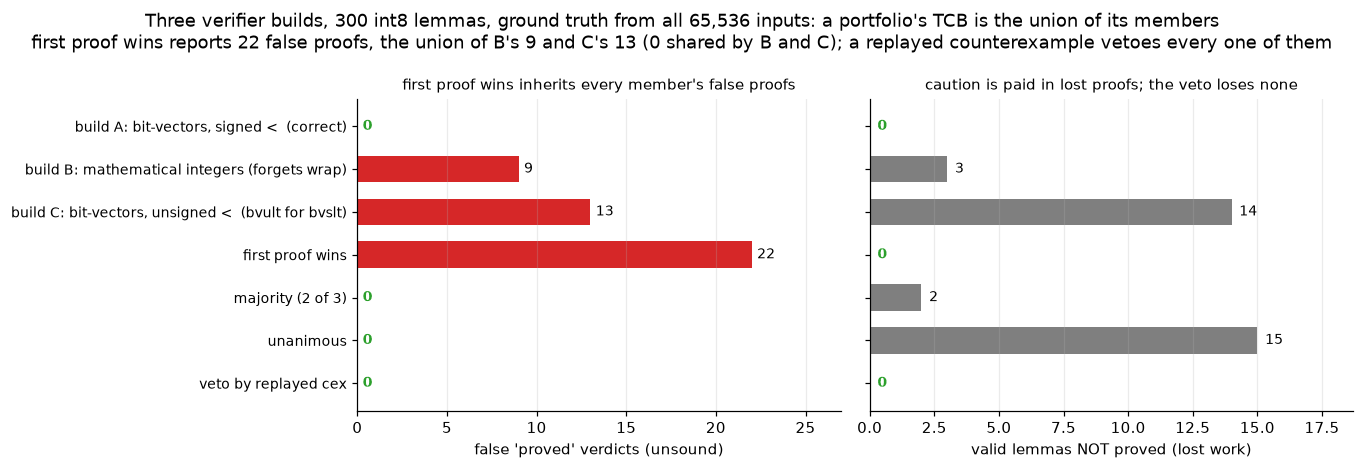

registered prediction: first proof wins is at least as safe as its worst member | measured: 22 false proofs vs 13 for the worst single build | verdict: WRONG -- its false proofs are the union of the members' (B's and C's)
A replayed counterexample is a certificate; a 'proved' from one member is not. Diversity protects only
when members must agree, or when one member's checkable refutation can veto another member's proof.


In [164]:
def _s14_portfolio_demo():
    '''Ground truth by enumeration, three builds by Z3, every counterexample replayed, seven ways to combine them.'''
    rnd = random.Random(_s14_SEED_LEMMAS)
    lemmas = [_s14_rand_lemma(rnd) for _ in range(_s14_N_LEMMAS)]
    grid = np.arange(_s14_LO, _s14_HI + 1, dtype=np.int64)
    X, Y = (a.ravel() for a in np.meshgrid(grid, grid))
    valid = [bool(_s14_holds(L, X, Y, 'bv').all()) for L in lemmas]          # ground truth: all 65,536 pairs

    verdicts, agree, spurious = [], 0, Counter()
    for L in lemmas:
        v = {}
        for b in _s14_BUILDS:
            st, cex = _s14_z3_build(L, b) if HAVE_Z3 else _s14_enum_build(L, b, X, Y)
            ref = _s14_enum_build(L, b, X, Y)[0]                             # independent oracle per build
            agree += (st == ref)
            conf = False
            if st == 'counterexample':                   # replay under the TRUE semantics (int8 wrap)
                conf = not bool(_s14_holds(L, np.array([cex['x']]), np.array([cex['y']]), 'bv')[0])
                spurious[b] += not conf
            v[b] = (st, conf)
        verdicts.append(v)
    print(f"{_s14_N_LEMMAS} random int8 lemmas, {sum(valid)} valid by enumeration of all 65,536 (x, y) pairs")
    print(f"{'Z3' if HAVE_Z3 else 'enumeration (no Z3)'} verdicts agree with each build's own enumerated semantics "
          f"on {agree} of {3 * _s14_N_LEMMAS} (lemma, build) pairs")

    stats = {}
    for p in _s14_POLICIES:
        out = [_s14_policy(v, p) for v in verdicts]
        stats[p] = dict(false_proved=sum(o == 'proved' and not t for o, t in zip(out, valid)),
                        proved=sum(o == 'proved' and t for o, t in zip(out, valid)),
                        refuted=sum(o == 'counterexample' and not t for o, t in zip(out, valid)),
                        unknown=sum(o == 'unknown' for o in out))
    n_valid, n_invalid = sum(valid), len(valid) - sum(valid)
    print()
    show_table(["policy", "false 'proved'", f"valid proved (of {n_valid})", f"invalid refuted (of {n_invalid})",
                "unknown", "spurious cex rejected by replay"],
               [[(f"build {p}: {_s14_BUILDS[p]}" if p in _s14_BUILDS else p), s['false_proved'], s['proved'],
                 s['refuted'], s['unknown'], spurious[p] if p in _s14_BUILDS else "-"] for p, s in stats.items()])
    wrong = {b: {i for i, v in enumerate(verdicts) if v[b][0] == 'proved' and not valid[i]} for b in 'BC'}
    for b in 'BC':
        i = min(wrong[b])
        bad = ~_s14_holds(lemmas[i], X, Y, 'bv')
        print(f"\nbuild {b} 'proves' {_s14_lemma_str(lemmas[i])}")
        print(f"   false at {int(bad.sum())} of 65,536 pairs, e.g. x = {int(X[bad][0])}, y = {int(Y[bad][0])}")
    print(f"\nfalse proofs shared by builds B and C: {len(wrong['B'] & wrong['C'])} "
          "-- majority vote needs two to agree")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
    labels = [f"build {p}: {_s14_BUILDS[p]}" if p in _s14_BUILDS else p for p in _s14_POLICIES]
    ypos = np.arange(len(labels))[::-1]
    for ax, key, color, xlabel in ((axes[0], 'false_proved', "#d62728", "false 'proved' verdicts (unsound)"),
                                   (axes[1], 'unproved', "#7f7f7f", "valid lemmas NOT proved (lost work)")):
        vals = [stats[p][key] if key != 'unproved' else n_valid - stats[p]['proved'] for p in _s14_POLICIES]
        ax.barh(ypos, vals, color=color, height=0.62)
        for yy, v in zip(ypos, vals):
            ax.text(v + 0.3, yy, str(v), va="center", fontsize=9,
                    color="black" if v else "#2ca02c", fontweight="normal" if v else "bold")
        ax.set_xlabel(xlabel)
        ax.set_xlim(0, max(max(vals), 1) * 1.18 + 1)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(ypos, labels, fontsize=9)
    axes[0].set_title("first proof wins inherits every member's false proofs", fontsize=10)
    axes[1].set_title("caution is paid in lost proofs; the veto loses none", fontsize=10)
    worst = max(stats[b]['false_proved'] for b in _s14_BUILDS)
    fpw = stats['first proof wins']['false_proved']
    member = {b: {i for i, v in enumerate(verdicts) if v[b][0] == 'proved' and not valid[i]} for b in _s14_BUILDS}
    assert fpw == len(set().union(*member.values())), "first proof wins = the union of the members' false proofs"
    parts = [f"{b}'s {len(s)}" for b, s in member.items() if s]
    fig.suptitle(f"Three verifier builds, {_s14_N_LEMMAS} int8 lemmas, ground truth from all 65,536 inputs: a "
                 f"portfolio's TCB is the union of its members\nfirst proof wins reports {fpw} false proofs, the "
                 f"union of {' and '.join(parts)} ({len(wrong['B'] & wrong['C'])} shared by B and C); a replayed "
                 "counterexample vetoes every one of them", fontsize=11.5)
    plt.tight_layout()
    plt.show()

    print(f"registered prediction: first proof wins is at least as safe as its worst member | measured: "
          f"{fpw} false proofs vs {worst} for the worst single build | "
          f"verdict: {'RIGHT' if fpw <= worst else 'WRONG'}"
          " -- its false proofs are the union of the members' (B's and C's)")
    print("A replayed counterexample is a certificate; a 'proved' from one member is not. Diversity protects only")
    print("when members must agree, or when one member's checkable refutation can veto another member's proof.")


_s14_portfolio_demo()

Wrong, and wrong by construction. The first-proof-wins row adds build B's false proofs to build C's, because the
two encoding bugs fail on different lemmas: the printed examples show B "proving" a fact that wrap-around breaks,
and C "proving" one that holds only if the comparisons read the bytes as unsigned. The cross-check line shows the
toy is honest: Z3's verdicts agree with each build's enumerated semantics, so every false proof comes from the
build's semantics, not from the solver. Majority vote happens to survive here, since B and C never share a false
proof, but only because the bugs are independent. Two builds sharing a front end or a solver can share a bug, and
in a real solver portfolio such as GNATprove's they always share the front end: an encoding bug like B's or C's
would sit in the one VC generator and fail every member at once. What differs between the members of such a
portfolio is the solvers' own soundness bugs, and the three builds stand in for those here. Unanimity is safe and
pays for it in lost proofs: a single spurious counterexample from a flawed build blocks a true lemma.

The **veto** row has no false proofs and no lost proofs. The rule is §2.5's principle: a counterexample is
replayed and becomes a certificate, so it can overrule any number of uncheckable "proved" verdicts. It costs
running every member to completion instead of stopping at the first success. Its perfect row is inherited from
build A, which is correct here; without a correct member there would be no refutation to veto with. It is not a
proof either: if every member shared a blind spot, nobody would produce the refutation. The real cure is the one
the proof assistants in §14.1 use: a "proved" that carries a certificate (an LRAT proof, a reconstructed proof
term) that a small checker re-verifies. None of this is a criticism of GNATprove or Zelkova, whose members are
mature solvers. The point is the bookkeeping: a portfolio's "proved" carries the soundness bugs of all its
members.

### 14.3 The tools in the notebook's taxonomy, and who pays for them

The first table classifies the tools by §2's `TECHNIQUES` keys: what each approximates, how much human input it
needs, what it emits that can be re-checked, and the section that built its toy. Licences are from each
project's LICENSE file (Oct 2026); "rests on" is read off the graph. The certificate column is §2's entry for
the technique, refined where a tool's own documentation says otherwise: SPIN's default depth-first search
returns *an* error trail, and a shortest one only with pan's `-i` option or a breadth-first (`-DBFS`) build
([pan manual](https://spinroot.com/spin/Man/Pan.html)); Alive2 prints a counterexample input or "Transformation
seems to be correct!", never a proof ([README](https://github.com/AliveToolkit/alive2)); Infer reports "error
traces leading to each bug" ([docs](https://fbinfer.com/docs/infer-workflow)); P's checker writes an error trace
and a schedule that replays it ([P docs](https://p-org.github.io/P/getstarted/usingP/)); and Zelkova is an
internal AWS service whose output format is not public, so the table says only *answer*. The service sits under
`equivalence` because it "compares behaviors" of policies, but it also "verifies properties" of a single policy
(Backes et al., FMCAD 2018), such as "not public" for S3 Block Public Access (Rungta, CAV 2022), so the fit is
loose. JasperGold and VC Formal sit under `k_induction` by assumption: their engines are proprietary (§8.6). The
second table lists dated money events, each with its source (full references in §15): company-reported, and
only disclosed amounts are summed.

In [165]:
_s14_TOOLS = [   # (tool, TECHNIQUES key, licence / owner) -- licences: each project's LICENSE file, Oct 2026
    ('Hypothesis', 'testing', 'open source'), ('P', 'testing', 'MIT'),
    ('AFL++', 'fuzzing', 'AGPL-3.0 (since 2026-06-03)'), ('libFuzzer', 'fuzzing', 'Apache-2.0 + LLVM exc.'),
    ('KLEE', 'symex', 'UIUC/NCSA'), ('Infer (Pulse)', 'symex', 'MIT'),
    ('CBMC', 'bmc', 'BSD-4-Clause'), ('Kani', 'bmc', 'Apache-2.0 / MIT'), ('ESBMC', 'bmc', 'Apache-2.0'),
    ('Apalache', 'bmc', 'open source'),
    ('TLC (TLA+)', 'model_checking', 'MIT'), ('SPIN', 'model_checking', 'BSD-3-Clause'),
    ('Alive2', 'equivalence', 'open source'), ('Zelkova', 'equivalence', 'AWS internal service'),
    ('SymbiYosys', 'k_induction', 'ISC'), ('JasperGold, VC Formal', 'k_induction', 'commercial (Cadence, Synopsys)'),
    ('Astrée', 'abstract_interp', 'commercial (AbsInt)'), ('Frama-C Eva', 'abstract_interp', 'LGPL-2.1 (core)'),
    ('IKOS', 'abstract_interp', 'NASA Open Source 1.3'),
    ('Dafny', 'deductive', 'MIT'), ('Verus', 'deductive', 'MIT'), ('F*', 'deductive', 'Apache-2.0'),
    ('SPARK', 'deductive', 'GPL-3.0 + commercial'), ('Frama-C WP', 'deductive', 'LGPL-2.1 (core)'),
    ('Prusti', 'deductive', 'MPL-2.0'), ('Creusot', 'deductive', 'LGPL-2.1'), ('KeY', 'deductive', 'GPL-2.0+'),
    ('Lean 4', 'itp', 'Apache-2.0'), ('Rocq', 'itp', 'LGPL-2.1'), ('Isabelle/HOL', 'itp', 'BSD-style'),
    ('HOL Light', 'itp', 'BSD-style'), ('Aeneas', 'itp', 'Apache-2.0'),
]
# What tools outside the graph rest on: bug-finders that only run the code, and P's own systematic tester.
_s14_RESTS = {'Hypothesis': "running the code", 'AFL++': "running the code", 'libFuzzer': "running the code",
              'P': "own engine (systematic testing)"}
# Where a tool's documentation refines §2's generic certificate (sources in the markdown above).
_s14_CERT = {'SPIN': "trail (shortest with -i)", 'Alive2': "counterexample input", 'Zelkova': "answer",
             'Infer (Pulse)': "error trace", 'P': "error trace + schedule"}
_s14_MONEY = [   # (date, event, disclosed $M or None, category, source; full references in §15)
    ('2014-06', "Cadence completes Jasper (JasperGold) acquisition, ~$170M announced", 170, 'hardware formal',
     "Design & Reuse"),
    ('2014-06', "Synopsys launches VC Formal", None, 'hardware formal', "Synopsys release"),
    ('2021-04', "Siemens agrees to acquire OneSpin (terms undisclosed)", None, 'hardware formal', "Design & Reuse"),
    ('2024-02', "Antithesis seed", 47, 'deterministic simulation', "Reworked"),
    ('2024-09', "Harmonic Series A", 75, 'AI + proof', "SiliconANGLE"),
    ('2025-02', "Certora open-sources its Prover (claims >$100B TVL secured)", None, 'smart contracts',
     "Certora blog"),
    ('2025-07', "Harmonic Series B (valuation ~$0.9B)", 100, 'AI + proof', "SiliconANGLE"),
    ('2025-10', "Axiom seed", 64, 'AI + proof', "SiliconANGLE"),
    ('2025-11', "Harmonic Series C (valuation $1.45B)", 120, 'AI + proof', "Harmonic news"),
    ('2025-12', "Antithesis Series A", 105, 'deterministic simulation', "PR Newswire"),
    ('2026-01', "Theorem seed", 6, 'AI + proof', "VentureBeat"),
    ('2026-03', "Axiom Series A (valuation $1.6B)", 200, 'AI + proof', "SiliconANGLE"),
    ('2026-06', "Pramaana Labs seed", 27, 'AI + proof', "TechCrunch"),
    ('2026-07', "Amazon: largest donation in the Lean FRO's history (undisclosed)", None, 'non-profit (Lean)',
     "Amazon Science"),
]
# The proof checker each AI + proof company names: Harmonic (Aristotle report, arXiv 2510.01346: Lean proof
# search), Axiom (SiliconANGLE: AxiomProver's outputs are verified in Lean), Pramaana Labs (TechCrunch: a Lean-based
# verification layer). The VentureBeat report on Theorem's seed does not say which tools its product uses.
_s14_PROOF_STACK = {'Harmonic': 'Lean', 'Axiom': 'Lean', 'Pramaana Labs': 'Lean', 'Theorem': None}


def _s14_taxonomy_demo():
    assert all(k in TECHNIQUES for _, k, _ in _s14_TOOLS), "every tool maps to a §2 technique"
    rows, fam = [], Counter()
    for tool, key, lic in _s14_TOOLS:
        d = TECHNIQUES[key]
        fam[d['family']] += 1
        if tool in _s14_STACK:
            rests = sorted({p[-1] for p, k in _s14_STACK[tool][1] if k == 'default'})
            n_opt = len({p[-1] for p, k in _s14_STACK[tool][1] if k == 'option'} - set(rests))
            rest = (" + ".join(rests) if rests else "user's choice") + (
                f" (+{_s14_plural(n_opt, 'option')})" if n_opt else "")
        else:
            rest = _s14_RESTS.get(tool, "(not in the graph)")
        rows.append([tool, key, d['family'], d['section'], d['automation'].split(' (')[0],
                     _s14_CERT.get(tool, d['certificate']), _s14_short(rest, 34), lic])
    show_table(["tool", "technique", "approx", "toy", "automation", "certificate", "rests on (default)", "licence"],
               rows)
    print(f"\n{len(rows)} tools: {fam['under']} under-approximate, {fam['exact']} exact, {fam['over']} "
          f"over-approximate; {sum(l.startswith('commercial') or 'internal' in l for *_, l in _s14_TOOLS)} are "
          "commercial or internal, the rest open source")

    print()
    show_table(["date", "event", "$M", "category", "source"],
               [[d, e, f"{m:,}" if m else "-", c, f] for d, e, m, c, f in _s14_MONEY])
    total = Counter()
    for d, _, m, c, _ in _s14_MONEY:
        if m and d >= '2024-09':
            total[c] += m
    ai = [(d, e, m) for d, e, m, c, _ in _s14_MONEY if c == 'AI + proof' and m]
    company = lambda e: next(n for n in _s14_PROOF_STACK if e.startswith(n))
    lean = [(d, e, m) for d, e, m in ai if _s14_PROOF_STACK[company(e)] == 'Lean']
    print(f"\ndisclosed AI + proof rounds, {ai[0][0]} to {ai[-1][0]}: ${total['AI + proof']:,}M in {len(ai)} rounds "
          "(venture rounds, not revenue; the Lean FRO donation is a gift to a non-profit and is not counted)")
    print(f"   of which ${sum(m for *_, m in lean):,}M in {len(lean)} rounds went to companies that name Lean as their "
          f"proof checker ({', '.join(sorted({company(e) for _, e, _ in lean}))}); no proof checker named for: "
          + ", ".join(sorted({company(e) for _, e, _ in ai} - {company(e) for _, e, _ in lean})))
    print("Hardware formal is a mature market held by three EDA vendors; the new rounds of 2024-26 in this table")
    print("went mostly to startups that pair LLMs with Lean, plus one deterministic-simulation testing company.")


_s14_taxonomy_demo()

tool                   technique        approx  toy    automation   certificate                 rests on (default)               licence                       
---------------------------------------------------------------------------------------------------------------------------------------------------------------
Hypothesis             testing          under   §1     automatic    failing input               running the code                 open source                   
P                      testing          under   §1     automatic    error trace + schedule      own engine (systematic testing)  MIT                           
AFL++                  fuzzing          under   §5     automatic    crashing input              running the code                 AGPL-3.0 (since 2026-06-03)   
libFuzzer              fuzzing          under   §5     automatic    crashing input              running the code                 Apache-2.0 + LLVM exc.        
KLEE                   symex            

Each tool's guarantees can now be read off §2.4's verdict table: "misses bugs" for the under-approximate
tools, "false alarms" for abstract interpretation, "needs a human" for auto-active and interactive proof. Who
builds and pays for these tools comes down to four facts, each dated and sourced.

- **Hardware formal is a mature commercial market, consolidated into the three EDA vendors.** Cadence bought
  Jasper for about \$170M (Design & Reuse, Jun 2014; net cash \$139.4M in Cadence's FY2014 10-K), Synopsys
  launched VC Formal the same month (Synopsys release, 3 Jun 2014), and Siemens bought OneSpin in 2021 (Design &
  Reuse). No market report isolates formal EDA tools; one vendor estimate puts all chip-verification software near
  \$1.5B for 2025 (Intel Market Research, an *estimate*). The users are chip makers: Intel made formal the primary
  validation of the Core i7 execution cluster (~20 person-years; Kaivola et al., CAV 2009), and Arm's ISA-Formal
  found bugs in all 8 processors it was applied to (Reid et al., CAV 2016). §12 derived why.
- **Smart contracts are the other place outside customers pay**, because a non-upgradeable deployed contract
  cannot be patched (§12). Certora open-sourced its prover in 2025 and claims over \$100B of value secured
  (Certora blog, a vendor claim); Runtime Verification, built on the K framework and its EVM semantics KEVM,
  reports over 100 security engagements (company page). The stakes are public. Hacks stole \$1.7B in 2023,
  \$2.2B in 2024 and over \$3.4B in 2025 (Chainalysis's annual reports).
- **Software verification is mostly done by in-house teams at a few large companies.** At AWS: the Automated
  Reasoning Group (~2015; Amazon Science, Jun 2020), Zelkova (§11.6), Kani in Firecracker's CI (§11.6), P for S3
  (§8.1) and a Dafny-verified authorization engine serving ~10⁹ requests a second (AWS, ICSE 2025). At Microsoft:
  Static Driver Verifier (§8.6), EverParse parsers in Hyper-V (Microsoft Research blog, May 2021), and SymCrypt's
  Rust cryptography proved in Lean via Aeneas (Microsoft Research blog, Jul 2026; §11.1). At Meta: Infer (§9.6).
  Independent vendors are specialised: AbsInt (Astrée, CompCert), AdaCore (SPARK, adopted by NVIDIA per AdaCore's
  case study), TrustInSoft and Galois (company pages; all listed in §15).
- **New money goes to AI + proof startups, mostly on Lean.** The money table sums their disclosed rounds since
  2024. All but Theorem's seed went to companies that name Lean as their proof checker (Harmonic, Axiom,
  Pramaana Labs); the report on Theorem's round does not say which tools its product uses (VentureBeat, Jan 2026).
  Harmonic and Axiom reached valuations of \$1.45B and \$1.6B (Harmonic's news page; SiliconANGLE, Mar 2026). The
  Lean FRO, a non-profit founded in 2023 (Lean FRO page), received the largest donation in its history from Amazon
  in Jul 2026, amount undisclosed (Amazon Science). These are rounds and valuations, not revenue. Antithesis is
  listed separately because it sells deterministic simulation *testing*, a bug-finder, not proofs (PR Newswire,
  Dec 2025).

### 14.4 A field guide

The decision table reads the notebook backwards: start from the code and the property, take the technique whose
failure mode you can afford, and go to the section that built it.

| your code and property | try first | when that is not enough | built in |
|---|---|---|---|
| a pure function of ≤ ~32 input bits | exhaust it: then testing *is* proof | — | §1 |
| any code with an executable spec | property-based tests (Hypothesis), bounded-exhaustive small scope | a spec ladder: strengthen until wrong code fails | §1–§2 |
| a parser or C library; property "never crashes" | coverage-guided fuzzing + sanitizers (AFL++, libFuzzer) | symbolic or concolic execution for magic-value guards (KLEE) | §5 |
| C or Rust; panics, overflow, out-of-bounds, bounded loops | BMC (CBMC, Kani, ESBMC) | contracts + deductive proof (Verus, Frama-C WP) | §5–§7 |
| an optimisation or refactoring: new ≡ old | equivalence / translation validation (Alive2, a Z3 miter) | — the old code is a complete spec | §3–§4 |
| an algorithm or data structure you own; full functional correctness | auto-active proof (Dafny, Verus, SPARK, Why3/Creusot) | the lemmas automation cannot do, in an ITP | §6–§7, §10 |
| a concurrent or distributed design | model-check a model (TLA+/TLC, P); check liveness under fairness | refinement to the code; deterministic simulation of the implementation | §8 |
| a hardware block or finite-state controller | k-induction / IC3 (SymbiYosys, JasperGold) | a different question in the same flow: equivalence-check each synthesized netlist against its RTL (the old design is the spec) | §8, §3 |
| large embedded C; "no run-time errors"; no annotations | abstract interpretation (Astrée, Frama-C Eva, IKOS) | relational domains, or deductive proof of the remaining alarms | §9 |
| mathematics, a compiler, a kernel, a crypto primitive | interactive proof (Lean, Rocq, Isabelle) | extract the code from the proof (Fiat Cryptography in Rocq; HACL\* in F\*), and compile it with a verified compiler (CompCert) | §10–§11 |
| code or proofs written by an LLM | the spec first; a checker; vacuity and escape-hatch lints | — the checker is the reviewer | §13 |
| is it worth verifying at all? | the inequality: cost per line against loss per escaped bug | lightweight methods: cheap spec, partial guarantee | §12 |

**What to try first**, by situation:

- **Python, or any code with a spec you can execute**: property-based tests with Hypothesis. It is the cheapest
  quantified spec, and in a mutation study each property-based test caught far more mutants than the average unit
  test (§1.1).
- **Rust**: Kani. It needs no specs or loop invariants, only test-like proof harnesses with bounds; it checks
  panics and overflow up to those bounds, and AWS runs it in Firecracker's CI. Move to **Verus** when you want
  unbounded proofs, at a cost of roughly five lines of proof per line of code in its published case studies
  (Lattuada et al., SOSP 2024: 6.1K lines of implementation, 31K of proof).
- **C**: CBMC for bounded checks; Frama-C (WP for contracts, Eva for run-time errors) for more.
- **A new algorithm you want proved, in a language that compiles to mainstream targets**: Dafny.
- **A distributed protocol or concurrent design**: TLA+ (or P), which AWS engineers learn in weeks (§12.3).
- **Mathematics, or a foundational artifact others will build on**: Lean, where the AI provers of §13 work.

The cell places every `TECHNIQUES` key on §2's picture, with the real tools of each.

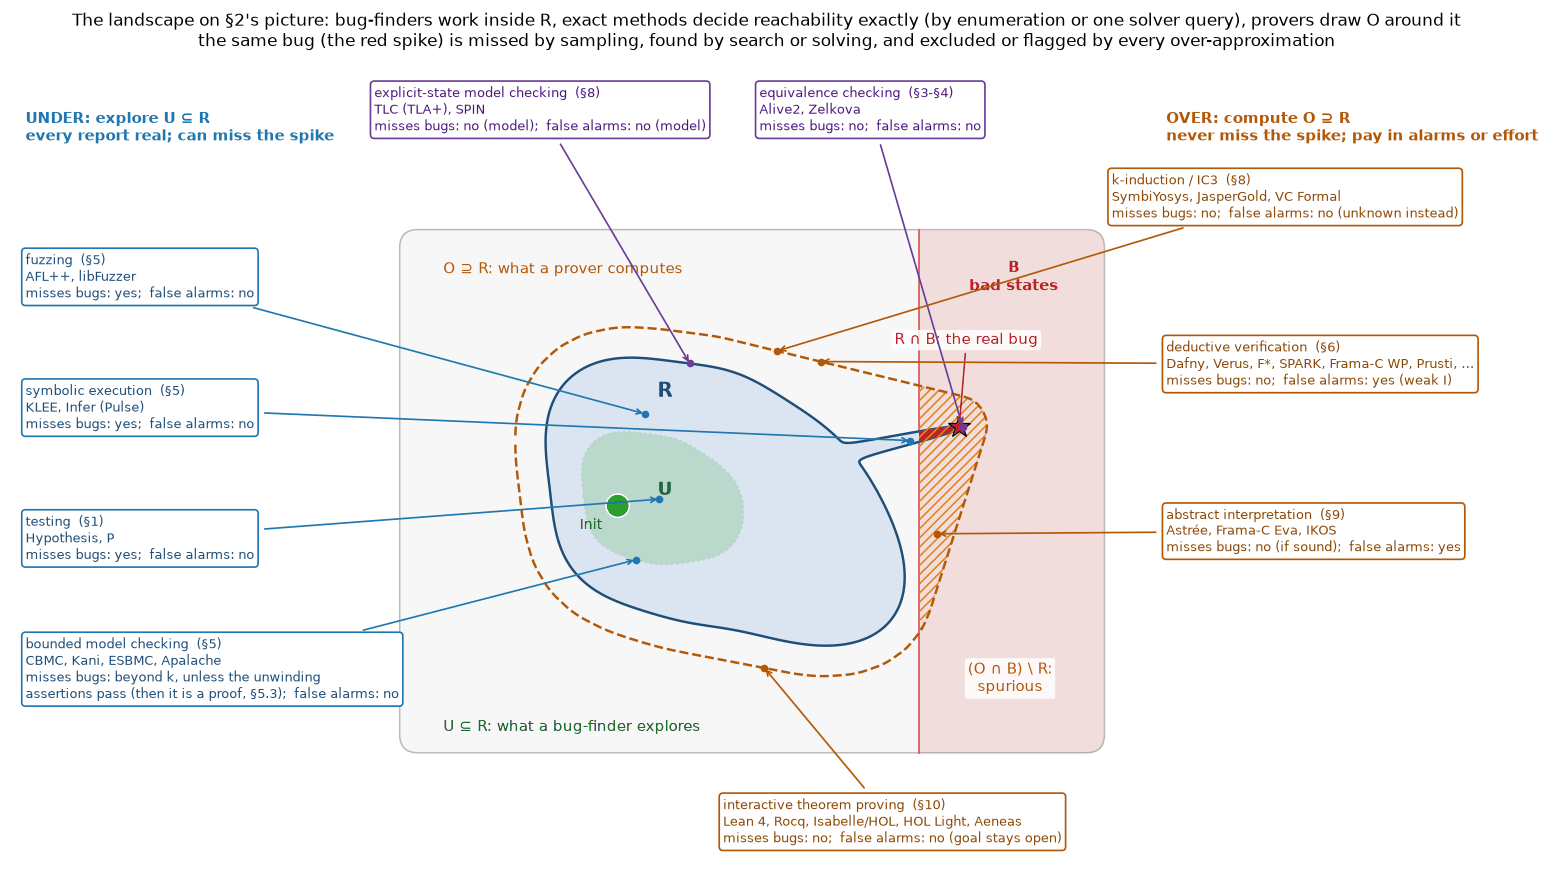

placed 10 techniques: 4 under, 2 exact, 4 over; 32 real tools attached
Pick by the failure you can afford: a missed bug (left), a state explosion (top), a false alarm or a
human-written invariant (right). Every tool on the map pays at least one: Rice's theorem for unbounded
programs, state explosion for finite ones (§2).


In [166]:
# Where each technique sits on draw_approx's scene (data units: the panel spans x in [0, 10], y in [0, 7.5]).
# Value: (label position, where the arrow lands). Under-approximations land INSIDE R, exact methods ON R,
# over-approximations ON O's boundary; the landing points are computed from the regions draw_approx drew.
_s14_PLACE = {
    'fuzzing': ((-5.0, 6.7), ('R', 125, 0.6)),        # (region, angle from R's centre in degrees, radial scale)
    'symex': ((-5.0, 4.9), ('spike', 0, 0.8)),
    'testing': ((-5.0, 3.1), ('U', 0, 0.0)),
    'bmc': ((-5.0, 1.3), ('U', 225, 1.0)),
    'model_checking': ((-0.2, 9.0), ('R', 95, 1.0)),
    'equivalence': ((5.1, 9.0), ('spike', 0, 1.0)),
    'k_induction': ((9.95, 7.8), ('O', 62, 1.0)),
    'deductive': ((10.7, 5.5), ('O', 48, 1.0)),
    'abstract_interp': ((10.7, 3.2), ('alarm', 0, 1.0)),  # inside (O ∩ B) \ R: where intervals raise false alarms
    'itp': ((4.6, -0.8), ('O', 290, 1.0)),
}
_s14_TEXT_COLOR = {'under': '#1f4e79', 'exact': '#4a1486', 'over': '#8c4a06'}
# §2's one-word summaries, refined where the real tools do better: CBMC, Kani and ESBMC check unwinding assertions,
# so a run whose unwinding assertions pass is a proof for that harness (§5.3).
_s14_MAP_MISSES = {'bmc': "beyond k, unless the unwinding\nassertions pass (then it is a proof, §5.3)"}


def _s14_regions(ax):
    '''Read R, O and U back from the patches draw_approx(ax, None) drew, so the arrows follow §2's geometry.'''
    from matplotlib.colors import to_rgba
    from matplotlib.patches import PathPatch
    out = {}
    for p in ax.patches:
        if isinstance(p, PathPatch):
            v = p.get_path().vertices
            if p.get_linestyle() == '--':
                out['O'] = v
            elif p.get_linestyle() == ':':
                out['U'] = v
            elif np.allclose(p.get_facecolor(), to_rgba("#dbe5f1")):
                out['R'] = v
        elif isinstance(p, Rectangle) and np.allclose(p.get_facecolor(), to_rgba("#d62728", 0.12)):
            out['x_bad'] = p.get_x()                       # the band B of bad states
    assert set(out) == {'R', 'O', 'U', 'x_bad'}, f"draw_approx regions not found: {sorted(out)}"
    return out


def _s14_resample(poly, n=3000):
    '''n points evenly spaced along a closed polyline (a convex hull has long straight edges with no vertices).'''
    closed = np.vstack([poly, poly[:1]])
    s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(closed, axis=0), axis=1))]
    t = np.linspace(0, s[-1], n, endpoint=False)
    return np.c_[np.interp(t, s, closed[:, 0]), np.interp(t, s, closed[:, 1])]


def _s14_landing(reg, where):
    '''A point on (scale 1) or inside (scale < 1) a region, in the direction `angle` from R's centre.'''
    name, angle, scale = where
    c = reg['R'].mean(axis=0)
    if name == 'spike':                                  # R's rightmost point is the tip of the bug spike
        return c + scale * (reg['R'][np.argmax(reg['R'][:, 0])] - c)
    if name == 'alarm':                                  # inside (O ∩ B) \ R, in its lower half (away from R)
        pts = _s14_resample(reg['O'])
        pts = pts[pts[:, 0] > reg['x_bad']]
        y = pts[:, 1].min() + 0.4 * (pts[:, 1].max() - pts[:, 1].min())
        x_o = pts[np.abs(pts[:, 1] - y) < 0.05, 0].max()
        return np.array([(reg['x_bad'] + x_o) / 2, y])
    pts = _s14_resample(reg[name])
    if scale == 0.0:
        return pts.mean(axis=0)
    ang = np.degrees(np.arctan2(pts[:, 1] - c[1], pts[:, 0] - c[0]))
    p = pts[np.argmin(np.abs((ang - angle + 180) % 360 - 180))]
    return c + scale * (p - c)


def _s14_tool_list(names, n=46):
    '''Join tool names in table order, dropping the tail (with an ellipsis) beyond n characters.'''
    out = ""
    for k, name in enumerate(names):
        nxt = name if not out else out + ", " + name
        if len(nxt) > n:
            return out + ", …"
        out = nxt
    return out


def _s14_landscape_map():
    assert set(_s14_PLACE) == set(TECHNIQUES), "every technique of §2 is placed"
    fig, ax = plt.subplots(figsize=(15, 8.1))
    draw_approx(ax, None, title=False)
    reg = _s14_regions(ax)
    for t, ((lx, ly), where) in _s14_PLACE.items():
        d = TECHNIQUES[t]
        target = _s14_landing(reg, where)
        tools = [tool for tool, key, _ in _s14_TOOLS if key == t]
        text = (f"{d['label']}  ({d['section']})\n{_s14_tool_list(tools)}\n"
                f"misses bugs: {_s14_MAP_MISSES.get(t, d['misses_bugs'])};  false alarms: {d['false_alarms']}")
        col = _s14_TEXT_COLOR[d['family']]
        ax.annotate(text, target, xytext=(lx, ly), fontsize=8.3, color=col, va="center", ha="left", zorder=15,
                    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=_s14_FAMILY_EDGE[d['family']], lw=1.1),
                    arrowprops=dict(arrowstyle="->", color=_s14_FAMILY_EDGE[d['family']], lw=1.1,
                                    shrinkA=4, shrinkB=1))
        ax.plot(*target, "o", ms=4, color=_s14_FAMILY_EDGE[d['family']], zorder=14)
    ax.text(-5.0, 8.75, "UNDER: explore U ⊆ R\nevery report real; can miss the spike", fontsize=9.5,
            color=_s14_FAMILY_EDGE['under'], fontweight="bold", va="center")
    ax.text(10.7, 8.75, "OVER: compute O ⊇ R\nnever miss the spike; pay in alarms or effort", fontsize=9.5,
            color=_s14_FAMILY_EDGE['over'], fontweight="bold", va="center")
    ax.set_xlim(-5.2, 15.6)
    ax.set_ylim(-1.45, 9.75)
    ax.set_title("The landscape on §2's picture: bug-finders work inside R, exact methods decide reachability "
                 "exactly (by enumeration or one solver query), provers draw O around it\nthe same bug (the red "
                 "spike) is missed by sampling, found by search or solving, and excluded or flagged by every "
                 "over-approximation", fontsize=11)
    plt.tight_layout()
    plt.show()
    by_family = Counter(TECHNIQUES[t]['family'] for t in _s14_PLACE)
    print(f"placed {len(_s14_PLACE)} techniques: {by_family['under']} under, {by_family['exact']} exact, "
          f"{by_family['over']} over; {len(_s14_TOOLS)} real tools attached")
    print("Pick by the failure you can afford: a missed bug (left), a state explosion (top), a false alarm or a")
    print("human-written invariant (right). Every tool on the map pays at least one: Rice's theorem for unbounded")
    print("programs, state explosion for finite ones (§2).")


_s14_landscape_map()

**The spine, once more.** Testing samples $R$, and §1 showed that a single 32-bit argument can be exhausted but
two cannot. Every verifier computes an approximation of the reachable states (§2), and the map above is that
picture with real tools attached. Proofs need inductive invariants (§6–§9), and the tools differ in who supplies
them: nobody in BMC, an engineer in Dafny or Verus, IC3 in SymbiYosys, an abstract domain in Astrée, and
increasingly an LLM whose proposal a checker accepts or rejects (§13). Under all of them sits a short list of
solvers and kernels (§14.1). That list is why the last idea matters: **check the product, not the producer**. A
replayed counterexample, an LRAT proof, or a kernel-checked term turns a large, fast, untrusted engine into a
trustworthy answer. A portfolio, a vote, or a model's confidence does not (§14.2). What the checker cannot check
is the spec. It is usually smaller than the code, though not always (TimSort's spec is as long as its code,
§11.2), and it is the one artifact a human still has to get right.

## 15. References

Every source the text cites, grouped by where it is used, plus the standard textbooks. Facts were checked in
October 2026 against primary sources where they were available; a link is given where the source itself was
opened (DOIs were resolved). A few facts rest on secondary coverage, and the entry says so: "as reported by" a
named outlet, "as quoted by" a third party, "press coverage", or "secondary estimate". Company announcements and
leaderboard entries are self-reported, and the text says so where they are used. The companion syllabus, ordered
as a learning path, is [reading_list.md](reading_list.md).

**Textbooks / canon (further reading)**
- Huth & Ryan, *Logic in Computer Science: Modelling and Reasoning about Systems*, 2nd ed. (CUP 2004) — logic,
  model checking, Hoare logic and BDDs in one volume.
- Kroening & Strichman, *Decision Procedures: An Algorithmic Point of View*, 2nd ed. (Springer 2016) — the
  textbook version of §3–§4, and the source of §4.6's decidability map.
- Biere, Heule, van Maaren & Walsh (eds.), *Handbook of Satisfiability*, 2nd ed. (IOS Press 2021).
- Baier & Katoen, *Principles of Model Checking* (MIT Press 2008); Lamport, *Specifying Systems: The TLA+
  Language and Tools for Hardware and Software Engineers* (Addison-Wesley 2002;
  [free PDF](https://lamport.azurewebsites.net/tla/book.html)).
- Leino, *Program Proofs* (MIT Press 2023) — deductive verification in Dafny, the follow-on to §6.
- Nipkow & Klein, *Concrete Semantics with Isabelle/HOL* (Springer 2014); Pierce et al., *Software Foundations*
  (Rocq); Avigad, de Moura, Kong & Ullrich, *Theorem Proving in Lean 4*.
- Møller & Schwartzbach, *Static Program Analysis* (lecture notes, Aarhus); Cousot, *Principles of Abstract
  Interpretation* (MIT Press 2021).
- Herlihy & Shavit, *The Art of Multiprocessor Programming* (the filter lock of §8.1); Bentley, *Programming
  Pearls* (the binary search of §1).
- Woodcock, Larsen, Bicarregui & Fitzgerald, "Formal Methods: Practice and Experience", ACM Computing Surveys
  2009; Ringer, Palmskog, Sergey, Gligoric & Tatlock, "QED at Large", Foundations and Trends in PL 2019
  ([arXiv 2003.06458](https://arxiv.org/abs/2003.06458)); ter Beek et al., "Formal Methods in Industry", Formal
  Aspects of Computing 2024 ([PDF](https://fmt.isti.cnr.it/~mtbeek/FACJ24.pdf)).
- Harrison, Urban & Wiedijk, "History of Interactive Theorem Proving", Handbook of the History of Logic vol. 9,
  2014 ([PDF](https://www.cl.cam.ac.uk/~jrh13/papers/joerg.pdf)); Fichte, Le Berre, Hecher & Szeider, "The Silent
  (R)evolution of SAT", CACM 2023.

**The trigger (§0) and where the field stands (§13.4)**
- PutnamBench: Tsoukalas et al., NeurIPS 2024 D&B ([arXiv 2407.11214](https://arxiv.org/abs/2407.11214)); the
  official leaderboard data
  ([results.json](https://raw.githubusercontent.com/trishullab/PutnamBench/main/docs/results.json)); Logical
  Intelligence, Aleph Prover final results ([page](https://logicalintelligence.com/aleph-prover-final.html), 25 Aug
  2026).
- IMO 2026: AxiomProver ([AxiomMath/IMO2026](https://github.com/AxiomMath/IMO2026)); MechMath
  ([MechMath/IMO2026](https://github.com/MechMath/IMO2026)); Magenta ([arXiv 2609.11319](https://arxiv.org/abs/2609.11319)).
  Putnam 2025: AxiomProver ([Lean Reservoir](https://reservoir.lean-lang.org/@AxiomMath/Putnam2025)) and Axiom's
  blog post of 8 Jan 2026; Seed-Prover 1.5 ([arXiv 2512.17260](https://arxiv.org/html/2512.17260v1)).
- Fermat's Last Theorem: Anthropic, "Formalizing Fermat's Last Theorem"
  ([4 Sep 2026](https://www.anthropic.com/research/formalizing-fermats-last-theorem)); the Imperial College FLT
  project plan ([GENERAL.md](https://github.com/ImperialCollegeLondon/FLT/blob/main/GENERAL.md)).
- IMO 2024 and 2025: the four announcements in the table below; Achim et al., Aristotle
  ([arXiv 2510.01346](https://arxiv.org/abs/2510.01346)); Hubert, Mehta, Sartran et al., AlphaProof, Nature 2026
  (vol. 651; online 12 Nov 2025; [DOI](https://doi.org/10.1038/s41586-025-09833-y)).
- Bursuc et al., "A Benchmark for Vericoding" (Sep 2025; [arXiv 2509.22908](https://arxiv.org/abs/2509.22908));
  Kleppmann, "Prediction: AI will make formal verification go mainstream"
  ([8 Dec 2025](https://martin.kleppmann.com/2025/12/08/ai-formal-verification.html)).

| IMO result | source |
|---|---|
| AlphaProof + AlphaGeometry 2, IMO 2024: 28/42, silver (formal; statements translated into Lean by hand) | Google DeepMind, [25 Jul 2024](https://deepmind.google/discover/blog/ai-achieves-silver-medal-standard-solving-international-mathematical-olympiad-problems/) |
| Gemini Deep Think, IMO 2025: 35/42, gold (informal; certified by IMO coordinators) | Google DeepMind, [21 Jul 2025](https://deepmind.google/discover/blog/advanced-version-of-gemini-with-deep-think-officially-achieves-gold-medal-standard-at-the-international-mathematical-olympiad/) |
| OpenAI's experimental model, IMO 2025: 35/42 (informal; graded by former medalists, not certified) | as reported by The Decoder, [19 Jul 2025](https://the-decoder.com/openai-claims-a-breakthrough-in-llm-reasoning-on-complex-math-problems/); the primary announcement was on X |
| Seed-Prover, IMO 2025: 30/42, IMO-certified (formal; statements formalized by hand) | ByteDance Seed, [23 Jul 2025](https://seed.bytedance.com/en/blog/bytedance-seed-prover-achieves-silver-medal-score-in-imo-2025) |

**Papers and primary sources, by section**
- **§1 Testing.** Dijkstra, *Notes on Structured Programming*, EWD249, Aug 1969, pp. EWD249-4 and -7
  ([scan](https://www.cs.utexas.edu/~EWD/ewd02xx/EWD249.PDF)); the report of the NATO Software Engineering
  conference, Rome, Oct 1969 (published Apr 1970), p. 16; Bloch, "Extra, Extra – Read All About It: Nearly All
  Binary Searches and Mergesorts are Broken", Google Research blog, 2 Jun 2006
  (<https://research.google/blog/extra-extra-read-all-about-it-nearly-all-binary-searches-and-mergesorts-are-broken/>);
  [JDK-5045582](https://bugs.openjdk.org/browse/JDK-5045582); Sun Microsystems' JDK 1.2 press release (8 Dec
  1998); Ravi & Coblenz, "An Empirical Evaluation of
  Property-Based Testing in Python", OOPSLA 2025 ([page](https://2025.splashcon.org/details/OOPSLA/102)); MacIver,
  Hatfield-Dodds et al., Hypothesis, JOSS 2019; Google, "Announcing OSS-Fuzz"
  ([Dec 2016](https://opensource.googleblog.com/2016/12/announcing-oss-fuzz-continuous-fuzzing.html)); the Planck
  2018 results (age of the universe); Pratt, *Anatomy of the Pentium Bug*, TAPSOFT 1995
  ([PDF](http://boole.stanford.edu/pub/anapent.pdf)); Intel's FDIV white paper (Dec 1994, as quoted by IBM) and
  IBM's *Pentium Study* (12 Dec 1994); Intel Form 10-K for fiscal 1994
  ([SEC](https://www.sec.gov/Archives/edgar/data/50863/0000050863-95-000004.txt)); Edelman, "The Mathematics of the
  Pentium Division Bug", SIAM Review 1997 ([PDF](https://math.mit.edu/~edelman/homepage/papers/pentiumbug.pdf));
  CrowdStrike, Channel File 291 root-cause analysis, Aug 2024
  (<https://www.crowdstrike.com/wp-content/uploads/2024/08/Channel-File-291-Incident-Root-Cause-Analysis-08.06.2024.pdf>);
  Microsoft, "Helping our customers through the CrowdStrike outage", 20 Jul 2024; Yuan et al., "Simple Testing Can
  Prevent Most Critical Failures", OSDI 2014
  ([PDF](https://www.usenix.org/system/files/conference/osdi14/osdi14-paper-yuan.pdf)).
- **§2 Specs and the shape of a verifier.** Hoare, "An Axiomatic Basis for Computer Programming", CACM 1969
  ([DOI](https://doi.org/10.1145/363235.363259)) — also the three overflow axioms; Floyd, "Assigning Meanings to
  Programs", 1967 ([DOI](https://doi.org/10.1090/psapm/019/0235771)); Lamport's 2013 ACM Turing Award citation;
  Alpern & Schneider, "Defining Liveness", IPL 1985; Clarkson & Schneider, CSF 2008 (hyperproperties); Barthe,
  D'Argenio & Rezk, CSFW 2004 (self-composition); Runciman, Naylor & Lindblad, SmallCheck, Haskell Symposium 2008;
  Claessen & Hughes, QuickCheck, ICFP 2000 ([DOI](https://doi.org/10.1145/351240.351266)); Jackson, "Alloy: A
  Lightweight Object Modelling Notation", TOSEM 2002 ([DOI](https://doi.org/10.1145/505145.505149)); Anthropic,
  Claude 3.7 Sonnet system card, Feb 2025
  ([PDF](https://assets.anthropic.com/m/785e231869ea8b3b/original/claude-3-7-sonnet-system-card.pdf)); Rice,
  Trans. AMS 1953 ([DOI](https://doi.org/10.1090/S0002-9947-1953-0053041-6)); Turing, Proc. London Math. Soc.
  1936/37 ([DOI](https://doi.org/10.1112/plms/s2-42.1.230)); Savitch 1970; O'Hearn, "Incorrectness Logic", POPL
  2020 ([DOI](https://doi.org/10.1145/3371078)); Livshits et al., "In Defense of Soundiness", CACM 2015; Appel,
  "Verified Software Toolchain", ESOP 2011, and [Verifiable C](https://vst.cs.princeton.edu/); Parthasarathy,
  Müller & Summers, "Formally Validating a Practical Verification Condition Generator", CAV 2021
  ([arXiv 2105.14381](https://arxiv.org/abs/2105.14381)); today's trust bases from the
  [CompCert user manual](https://compcert.org/man/), ch. 1, and the [seL4 FAQ](https://sel4.systems/About/FAQ.html),
  and the original 2009 lists from Leroy 2009 and Klein et al. 2009 (§11); Knuth, *The Art of Computer
  Programming* vol. 3, Sec. 5.3.4 (the 0-1 principle); DafnyBench (§13, below) for Dafny 4.3's error messages.
- **§3 SAT.** Tseitin 1968 ([DOI](https://doi.org/10.1007/978-3-642-81955-1_28)); Plaisted & Greenbaum 1986
  ([DOI](https://doi.org/10.1016/S0747-7171(86)80028-1));
  Cook, STOC 1971 ([DOI](https://doi.org/10.1145/800157.805047)); Levin 1973; Davis & Putnam, J. ACM 1960
  ([DOI](https://doi.org/10.1145/321033.321034)); Davis, Logemann & Loveland, CACM 1962
  ([DOI](https://doi.org/10.1145/368273.368557)); Marques-Silva & Sakallah, GRASP, ICCAD 1996 / IEEE TC 1999
  ([DOI](https://doi.org/10.1109/12.769433)); Moskewicz, Madigan, Zhao, Zhang & Malik, Chaff, DAC 2001
  ([DOI](https://doi.org/10.1145/378239.379017)); Zhang, Madigan, Moskewicz & Malik, ICCAD 2001 (1-UIP;
  [DOI](https://doi.org/10.1109/ICCAD.2001.968634)); Eén & Sörensson, MiniSat, SAT 2003
  ([DOI](https://doi.org/10.1007/978-3-540-24605-3_37)) and its
  [source](https://github.com/niklasso/minisat/blob/master/minisat/core/Solver.cc) (VSIDS constants); Nadel &
  Ryvchin, chronological backtracking, SAT 2018 ([DOI](https://doi.org/10.1007/978-3-319-94144-8_7)); Luby,
  Sinclair & Zuckerman, IPL 1993 ([DOI](https://doi.org/10.1016/0020-0190(93)90029-9)); Audemard & Simon,
  Glucose, IJCAI 2009 ([PDF](https://www.ijcai.org/Proceedings/09/Papers/074.pdf)); Wetzler, Heule & Hunt,
  DRAT-trim, SAT 2014 ([DOI](https://doi.org/10.1007/978-3-319-09284-3_31)); SAT Competition
  [certificate rules (2016)](https://satcompetition.github.io/2016/certificates.html),
  [2023](https://satcompetition.github.io/2023/results.html) and
  [2024](https://satcompetition.github.io/2024/results.html) results, and the
  [2025 results slides](https://satcompetition.github.io/2025/satcomp25slides.pdf); Tan, Heule & Myreen, cake_lpr,
  TACAS 2021 ([PMC](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC7984575/)); Haken, "The Intractability of
  Resolution", TCS 1985 ([DOI](https://doi.org/10.1016/0304-3975(85)90144-6)); S. Cook, SIGACT News 1976
  (extended resolution; [DOI](https://doi.org/10.1145/1008335.1008338)) and Grosof, Zhang & Heule
  ([arXiv 2207.11284](https://arxiv.org/abs/2207.11284)); W. Cook, Coullard & Turán, Discrete Applied Mathematics
  1987 (cutting planes; [DOI](https://doi.org/10.1016/0166-218X(87)90039-4)); Chvátal & Szemerédi, J. ACM 1988
  ([DOI](https://doi.org/10.1145/48014.48016)); Fleming, Pankratov, Pitassi & Robere
  ([arXiv 1703.02469](https://arxiv.org/abs/1703.02469)); Pipatsrisawat & Darwiche, Artificial Intelligence 2011
  ([DOI](https://doi.org/10.1016/j.artint.2010.10.002)); Crawford & Auton, Artificial Intelligence 81, 1996
  ([DOI](https://doi.org/10.1016/0004-3702(95)00046-1)); Mézard, Parisi & Zecchina, Science 2002, and Mézard &
  Zecchina, Phys. Rev. E 2002
  ([arXiv cond-mat/0207194](https://arxiv.org/abs/cond-mat/0207194)); Ding, Sly & Sun, Annals of Mathematics 2022
  ([page](https://annals.math.princeton.edu/2022/196-1/p01)); Hajiaghayi & Sorkin 2003
  ([arXiv math/0310193](https://arxiv.org/abs/math/0310193)); Díaz, Kirousis, Mitsche & Pérez-Giménez, TCS 2009
  ([DOI](https://doi.org/10.1016/j.tcs.2009.02.020)); Heule, Kullmann & Marek, Pythagorean triples, SAT 2016
  ([arXiv 1605.00723](https://arxiv.org/abs/1605.00723)); Heule, "Schur Number Five", AAAI 2018
  ([arXiv 1711.08076](https://arxiv.org/abs/1711.08076)); Brakensiek, Heule, Mackey & Narváez, Keller's
  conjecture, IJCAR 2020 ([arXiv 1910.03740](https://arxiv.org/abs/1910.03740)); Heule & Scheucher 2024
  ([arXiv 2403.00737](https://arxiv.org/abs/2403.00737)) and Subercaseaux et al., ITP 2024
  ([arXiv 2403.17370](https://arxiv.org/abs/2403.17370)); Fichte, Hecher & Szeider, "A Time Leap Challenge for
  SAT-Solving", CP 2020; the table's numbers are from the revised version
  ([arXiv 2008.02215v2](https://arxiv.org/abs/2008.02215v2), 2023, Table 1).
- **§4 Bit-vectors and SMT.** Lopes, Menendez, Nagarakatte & Regehr, Alive, PLDI 2015
  ([DOI](https://doi.org/10.1145/2737924.2737965)); Pnueli, Siegel & Singerman, "Translation Validation", TACAS
  1998 ([DOI](https://doi.org/10.1007/BFb0054170)); Alive2 (under *Tools*, below); cppreference,
  [arithmetic operators](https://en.cppreference.com/w/cpp/language/operator_arithmetic) (signed `>>`); Bryant,
  IEEE TC 1991 ([PDF](https://www.cs.cmu.edu/~bryant/pubdir/ieeetc91.pdf)); Kaufmann, PhD thesis, JKU Linz 2020
  ([PDF](https://fmv.jku.at/papers/Kaufmann-PhD-Thesis-2020.pdf)); Kaufmann, Biere & Kauers, FMCAD 2019; Beame &
  Liew, CAV 2017; Nieuwenhuis, Oliveras & Tinelli, DPLL(T), J. ACM 2006
  ([DOI](https://doi.org/10.1145/1217856.1217859)); Nelson & Oppen, TOPLAS 1979
  ([DOI](https://doi.org/10.1145/357073.357079)); Kovásznai, Fröhlich & Biere, SMT 2012; Papadimitriou 1981;
  Khachiyan 1979; Downey, Sethi & Tarjan 1980; Davis, Putnam & Robinson 1961; Matiyasevich 1970; Tarski 1948/51;
  Collins 1975; Canny 1988; Presburger 1929; Fischer & Rabin 1974; Church and Turing 1936; Gödel's completeness
  theorem (1930); Halpern, J. Symb. Logic 1991; de Moura & Bjørner, "Z3: An Efficient SMT Solver", TACAS 2008
  ([DOI](https://doi.org/10.1007/978-3-540-78800-3_24)) and its
  [ETAPS 2018 test-of-time award](https://etaps.org/2018/test-of-time-award); Barbosa et al., cvc5, TACAS 2022
  ([DOI](https://doi.org/10.1007/978-3-030-99524-9_24)); Rungta, "A Billion SMT Queries a Day", CAV 2022
  ([Amazon Science](https://www.amazon.science/blog/a-billion-smt-queries-a-day)); Backes et al., Zelkova, FMCAD 2018.
- **§5 Symbolic execution, BMC, fuzzing.** King, CACM 1976 ([DOI](https://doi.org/10.1145/360248.360252)); Cadar,
  Dunbar & Engler, KLEE, OSDI 2008
  ([PDF](https://www.usenix.org/legacy/event/osdi08/tech/full_papers/cadar/cadar.pdf)); Biere, Cimatti, Clarke &
  Zhu, TACAS 1999 ([DOI](https://doi.org/10.1007/3-540-49059-0_14)); Clarke, Kroening & Lerda, CBMC, TACAS 2004
  ([DOI](https://doi.org/10.1007/978-3-540-24730-2_15)), the CBMC
  [man page](https://raw.githubusercontent.com/diffblue/cbmc/develop/doc/man/cbmc.1) and 6.0.0 changelog (unwinding
  assertions on by default); Kroening & Strichman, VMCAI 2003; Clarke, Kroening, Ouaknine & Strichman,
  "Completeness and Complexity of Bounded Model Checking", VMCAI 2004
  ([PDF](https://people.mpi-sws.org/~joel/publications/compbmc04.pdf)); VanHattum,
  Schwartz-Narbonne, Chong & Sampson, Kani, ICSE-SEIP 2022 ([DOI](https://doi.org/10.1145/3510457.3513031)); the
  Kani repository (pinned CBMC and Kissat; [GitHub](https://github.com/model-checking/kani)) and its
  [attributes reference](https://model-checking.github.io/kani/reference/attributes.html) (`kani::solver`, CaDiCaL
  by default); Kuznetsov, Kinder, Bucur & Candea, state merging, PLDI 2012; Avgerinos, Rebert, Cha &
  Brumley, veritesting, ICSE 2014; Zalewski, AFL
  ([ChangeLog](https://raw.githubusercontent.com/google/AFL/master/docs/ChangeLog)) and its technical notes
  (`docs/technical_details.txt`, the source of the hit-count buckets);
  AFL++'s laf-intel pass; Godefroid, Klarlund & Sen, DART, PLDI 2005
  ([DOI](https://doi.org/10.1145/1065010.1065036)); Godefroid, Levin & Molnar, SAGE, CACM 2012
  ([DOI](https://doi.org/10.1145/2093548.2093564)); Miller, Fredriksen & So, CACM 1990
  ([DOI](https://doi.org/10.1145/96267.96279)); the [OSS-Fuzz README](https://github.com/google/oss-fuzz) (May 2025
  counts); Google Security Blog, "Leveling Up Fuzzing"
  ([Nov 2024](https://security.googleblog.com/2024/11/leveling-up-fuzzing-finding-more.html)).
- **§6 Hoare logic and wp.** Floyd 1967 and Hoare 1969 (above); Cook, SIAM J. Computing 1978 (relative
  completeness); Dijkstra, "Guarded Commands, Nondeterminacy and Formal Derivation of Programs", CACM 1975
  ([DOI](https://doi.org/10.1145/360933.360975)); Leino, "Efficient weakest preconditions", IPL 2005; Flanagan &
  Saxe, POPL 2001; Barnett & Leino, PASTE 2005; Barnett, Chang, DeLine, Jacobs & Leino, Boogie, FMCO 2005
  ([DOI](https://doi.org/10.1007/11804192_17)); Leino, Dafny, LPAR-16 2010
  ([DOI](https://doi.org/10.1007/978-3-642-17511-4_20)); Cook, Podelski & Rybalchenko, Terminator, PLDI 2006;
  rustc's overflow messages as reported by Kani; the SPARK User's Guide (`-gnato13`, GNATprove messages).
- **§7 Memory and quantifiers.** Zhou et al., Mariposa, FMCAD 2023 (and the Komodo quote it reports); McCarthy 1962
  (the theory of arrays); McCarthy & Hayes, Machine Intelligence 4, 1969; Reynolds, "Intuitionistic Reasoning about
  Shared Mutable Data Structure", Millennial Perspectives in Computer Science, 2000; Ishtiaq & O'Hearn, POPL 2001;
  O'Hearn, Reynolds & Yang, CSL 2001; Reynolds, "Separation Logic", LICS 2002
  ([DOI](https://doi.org/10.1109/LICS.2002.1029817)); Yang & O'Hearn, FoSSaCS 2002; O'Hearn, "Separation Logic",
  CACM 2019 ([DOI](https://doi.org/10.1145/3211968)); the
  [2016 Gödel Prize](https://www.acm.org/media-center/2016/may/goedel-prize-2016) (Brookes & O'Hearn); Calcagno,
  Distefano, O'Hearn & Yang, bi-abduction, POPL 2009 ([DOI](https://doi.org/10.1145/1480881.1480917)); Astrauskas,
  Müller, Poli & Summers, Prusti, OOPSLA 2019 ([DOI](https://doi.org/10.1145/3360573)); Lattuada et al., Verus,
  OOPSLA 2023 ([DOI](https://doi.org/10.1145/3586037)); Denis, Jourdan & Marché, Creusot, ICFEM 2022
  ([DOI](https://doi.org/10.1007/978-3-031-17244-1_6)); Ho & Protzenko, Aeneas, ICFP 2022
  ([DOI](https://doi.org/10.1145/3547647)); Detlefs, Nelson & Saxe, Simplify, J. ACM 2005; de Moura & Bjørner,
  efficient E-matching, CADE 2007; Leino & Pit-Claudel, trigger selection, CAV 2016; Z3's own parameter help
  (`z3 -p`: `smt.case_split`); the Dafny Reference Manual (under *Tools*: `opaque`, `reveal`, fuel); Dafny's Z3
  options as set in Dafny's
  [DafnyOptions.cs](https://github.com/dafny-lang/dafny/blob/master/Source/DafnyCore/DafnyOptions.cs) and Boogie's
  [Z3.cs](https://github.com/boogie-org/boogie/blob/master/Source/Provers/SMTLib/Z3.cs).
- **§8 Transition systems.** Lu, Park, Seo & Zhou, ASPLOS 2008
  ([PDF](https://people.cs.uchicago.edu/~shanlu/paper/asplos122-lu.pdf)); Holzmann, SPIN, IEEE TSE 1997
  ([DOI](https://doi.org/10.1109/32.588521)); Peterson, IPL 1981
  ([DOI](https://doi.org/10.1016/0020-0190(81)90106-X)); Newcombe, Rath, Zhang, Munteanu, Brooker & Deardeuff, "How
  Amazon Web Services Uses Formal Methods", CACM 2015 ([DOI](https://doi.org/10.1145/2699417); 2014
  [preprint](https://lamport.azurewebsites.net/tla/formal-methods-amazon.pdf)); Brooker & Desai, "Systems
  Correctness Practices at AWS", ACM Queue 22(6), Feb 2025 ([DOI](https://doi.org/10.1145/3712057)), also in CACM
  68(6), 2025 ([DOI](https://doi.org/10.1145/3729175)); the TLC command-line options documentation (tlapl.us;
  breadth-first search by default); Davis, Hirschhorn & Schvimer, "eXtreme Modelling in Practice", VLDB 2020
  ([arXiv 2006.00915](https://arxiv.org/pdf/2006.00915)); Clarke & Emerson 1981
  ([DOI](https://doi.org/10.1007/BFb0025774)); Queille & Sifakis 1982
  ([DOI](https://doi.org/10.1007/3-540-11494-7_22)); Clarke, Emerson & Sifakis, Turing Award lecture, CACM 2009
  ([DOI](https://doi.org/10.1145/1592761.1592781)); Lamport, "The Temporal Logic of Actions", TOPLAS 1994
  ([DOI](https://doi.org/10.1145/177492.177726)); Sewell, Sarkar, Owens, Zappa Nardelli & Myreen, "x86-TSO", CACM
  2010; Tarjan 1972; Gu et al., CertiKOS, OSDI 2016; Abadi & Lamport, TCS 1991; Sheeran, Singh & Stålmarck, FMCAD
  2000 ([DOI](https://doi.org/10.1007/3-540-40922-X_8)); Bradley, IC3, VMCAI 2011
  ([DOI](https://doi.org/10.1007/978-3-642-18275-4_7)); Eén, Mishchenko & Brayton, PDR, FMCAD 2011; McMillan,
  interpolation, CAV 2003; Clarke, Grumberg, Jha, Lu & Veith, CEGAR, CAV 2000
  ([DOI](https://doi.org/10.1007/10722167_15)); Ball, Levin & Rajamani, "A Decade of Software Model Checking with
  SLAM", CACM 2011 ([PDF](https://web.eecs.umich.edu/~xwangsd/courses/w23/readings/slam.pdf)); the SymbiYosys
  [reference](https://yosyshq.readthedocs.io/projects/sby/en/latest/reference.html); Bryant, IEEE TC 1986
  ([DOI](https://doi.org/10.1109/TC.1986.1676819)); Burch, Clarke, McMillan, Dill & Hwang, "Symbolic Model
  Checking: $10^{20}$ States and Beyond", LICS 1990 / Information and Computation 1992
  ([DOI](https://doi.org/10.1016/0890-5401(92)90017-A)); Bollig & Wegener 1996.
- **§9 Abstract interpretation.** Tarski's lattice fixpoint theorem; Cousot & Cousot, POPL 1977
  ([DOI](https://doi.org/10.1145/512950.512973)); Cousot
  & Halbwachs, POPL 1978 ([DOI](https://doi.org/10.1145/512760.512770)); Miné, "The Octagon Abstract Domain", HOSC
  2006 ([DOI](https://doi.org/10.1007/s10990-006-8609-1)); Blanchet et al., Astrée, PLDI 2003
  ([DOI](https://doi.org/10.1145/781131.781153)); the [Astrée project page](https://www.astree.ens.fr/); P. Cousot,
  MIT talk, Aug 2005 ([slides](https://cs.nyu.edu/~pmc309/publications.www/slides/CousotMIT-050809-stata_4-1.pdf));
  Kästner et al., ERTS² 2010 ([PDF](https://cs.nyu.edu/~pmc309/publications.www/KastnerEtAl-ERTS2-May-2010.pdf)),
  and Delmas & Souyris, SAS 2007, which it summarizes;
  Distefano, Fähndrich, Logozzo & O'Hearn, "Scaling Static Analyses at Facebook", CACM 2019
  ([DOI](https://doi.org/10.1145/3338112)); Le, Raad, Villard, Berdine, Dreyer & O'Hearn, Pulse-X, OOPSLA 2022; the
  Infer changelog (1.2.0, 1.3.0); Sadowski, Aftandilian, Eagle, Miller-Cushon & Jaspan, "Lessons from Building
  Static Analysis Tools at Google", CACM 2018 ([DOI](https://doi.org/10.1145/3188720)).
- **§10 Proof assistants.** Lean 4 sources:
  [Init/Prelude.lean](https://github.com/leanprover/lean4/blob/master/src/Init/Prelude.lean),
  [Init/Classical.lean](https://github.com/leanprover/lean4/blob/master/src/Init/Classical.lean),
  [Init/Data/Nat/Basic.lean](https://github.com/leanprover/lean4/blob/master/src/Init/Data/Nat/Basic.lean); Leino,
  VMCAI 2012 (induction in Dafny); Reynolds & Kuncak, VMCAI 2015 (induction in CVC4); the Boyer–Moore induction
  heuristic; Curry 1934; Curry & Feys 1958; Howard (1969, published 1980); Wadler, "Propositions as Types", CACM
  2015 ([DOI](https://doi.org/10.1145/2699407);
  [PDF](https://homepages.inf.ed.ac.uk/wadler/papers/propositions-as-types/propositions-as-types.pdf)); de Bruijn's
  Automath (1967–68); Griffin, POPL 1990; Diaconescu's theorem; the Lean community checklist
  ["Did you prove it?"](https://leanprover-community.github.io/did_you_prove_it.html) and the Lean reference on
  [axioms](https://lean-lang.org/doc/reference/latest/Axioms/); Milner's Stanford LCF (1972) and Edinburgh LCF
  (1979); Gordon, "From LCF to HOL: A Short History", 2000
  ([PDF](https://www.cl.cam.ac.uk/archive/mjcg/papers/HolHistory.pdf)); Barendregt
  ([slides](https://ftp.science.ru.nl/CSI/CompMath.Found/mri.pdf)) and Barendregt & Wiedijk, Phil. Trans. R. Soc. A
  2005; [lean4checker](https://github.com/leanprover/lean4checker),
  [Lean4Lean](https://github.com/digama0/lean4lean), [nanoda](https://github.com/ammkrn/nanoda_lib); kernel sizes
  counted in [HOL Light](https://raw.githubusercontent.com/jrh13/hol-light/master/fusion.ml),
  [Isabelle](https://github.com/isabelle-prover/mirror-isabelle/blob/master/src/Pure/thm.ML),
  [Lean 4](https://github.com/leanprover/lean4/tree/master/src/kernel) and
  [Rocq](https://github.com/rocq-prover/rocq/tree/master/kernel); de Moura & Ullrich, Lean 4, CADE-28 2021
  ([DOI](https://doi.org/10.1007/978-3-030-79876-5_37)); Gonthier, "Formal Proof—The Four-Color Theorem", Notices
  of the AMS 2008 (the 2005 proof); Gonthier et al., Odd Order theorem, ITP 2013
  ([DOI](https://doi.org/10.1007/978-3-642-39634-2_14)); Hales et al., Flyspeck, Forum of Mathematics, Pi 2017
  ([DOI](https://doi.org/10.1017/fmp.2017.1); [GitHub](https://github.com/flyspeck/flyspeck)); the
  [Liquid Tensor Experiment](https://leanprover-community.github.io/blog/posts/lte-final/) (Jul 2022).
- **§11 Case studies.** Klein et al., seL4, SOSP 2009 ([DOI](https://doi.org/10.1145/1629575.1629596)) and TOCS
  2014 ([DOI](https://doi.org/10.1145/2560537)); the [seL4 FAQ](https://sel4.systems/About/FAQ.html) and
  [news](https://sel4.systems/) (Aug 2026); Leroy, CompCert, CACM 2009
  ([DOI](https://doi.org/10.1145/1538788.1538814)) and [compcert.org](https://compcert.org/) (Mar 2026
  qualification); Tan et al., "The Verified CakeML Compiler Backend", JFP 2019; Hawblitzel et al., IronFleet, SOSP
  2015 ([DOI](https://doi.org/10.1145/2815400.2815428)); Woos et al., Verdi Raft, CPP 2016
  ([PDF](https://homes.cs.washington.edu/~mernst/pubs/raft-proof-cpp2016.pdf)); Gu et al., CertiKOS, OSDI 2016
  ([PDF](https://www.usenix.org/system/files/conference/osdi16/osdi16-gu.pdf)); Protzenko et al., EverCrypt, IEEE
  S&P 2020 ([DOI](https://doi.org/10.1109/SP40000.2020.00114)); Zinzindohoué, Bhargavan, Protzenko & Beurdouche,
  HACL\*, CCS 2017 ([DOI](https://doi.org/10.1145/3133956.3134043)); What's New in Python
  [3.12](https://docs.python.org/3/whatsnew/3.12.html) and [3.14](https://docs.python.org/3/whatsnew/3.14.html);
  Mozilla Security Blog, "Verified cryptography for Firefox 57"
  ([Sep 2017](https://blog.mozilla.org/security/2017/09/13/verified-cryptography-firefox-57/)); Linux commit
  0ed42a6f (Nov 2019); Erbsen, Philipoom, Gross, Sloan & Chlipala, Fiat Cryptography, IEEE S&P 2019
  ([DOI](https://doi.org/10.1109/SP.2019.00005)), and its "about 90% of secure Chrome communications" as reported
  by MIT Technology Review ([Aug 2019](https://www.technologyreview.com/2019/08/21/539/automatic-cryptocoder/);
  press coverage, not in the paper); Galois, [Amazon s2n](https://galois.com/project/amazon-s2n/); Cutler et al.,
  Cedar, OOPSLA 2024 ([DOI](https://doi.org/10.1145/3649835)) and "How We Built Cedar", FSE Companion 2024
  ([arXiv 2407.01688](https://arxiv.org/pdf/2407.01688)); the Kani paper
  ([arXiv 2607.01504](https://arxiv.org/abs/2607.01504), 2026); Microsoft Research,
  [VCC](https://www.microsoft.com/en-us/research/project/vcc-a-verifier-for-concurrent-c/); RATP (L. Pelhate, STAR
  2000 slides) on B and Line 14 ([PDF](https://www.atelierb.eu/wp-content/uploads/2018/04/RATP.pdf)); Lecomte,
  Servat & Pouzancre, 2007; Behm, Benoit, Faivre & Meynadier, Météor, FM'99
  ([DOI](https://doi.org/10.1007/3-540-48119-2_22)); Atmosphere, KISV 2023
  ([PDF](https://par.nsf.gov/servlets/purl/10549642)) and SOSP 2025; Microsoft Research blog on SymCrypt in Rust
  (Jun 2025) and Ho et al.'s draft paper on SymCrypt's ML-KEM and SHA-3 (§12, below), the source of the `CASES`
  row; Lattuada et al., "Verus: A Practical Foundation for Systems Verification", SOSP 2024
  ([DOI](https://doi.org/10.1145/3694715.3695952)), also the source of the IronKV, Atmosphere and Hyperkernel
  ratios it cites; Yang, Chen, Eide & Regehr, Csmith, PLDI 2011 ([DOI](https://doi.org/10.1145/1993498.1993532));
  Fonseca, Zhang, Wang & Krishnamurthy, EuroSys 2017 ([DOI](https://doi.org/10.1145/3064176.3064183)); TimSort:
  Peters (2002); ERCIM News 102 (2015, [PDF](https://ir.cwi.nl/pub/23712/23712A.pdf)); de Gouw, Rot, de Boer, Bubel
  & Hähnle, CAV 2015 ([DOI](https://doi.org/10.1007/978-3-319-21690-4_16);
  [PDF](https://ir.cwi.nl/pub/23709/23709A.pdf)); JDK-8011944 and
  [JDK-8072909](https://bugs.openjdk.org/browse/JDK-8072909); the OpenJDK
  [TimSort.java](https://raw.githubusercontent.com/openjdk/jdk/master/src/java.base/share/classes/java/util/TimSort.java);
  [bpo-23515](https://bugs.python.org/issue23515); Auger, Jugé, Nicaud & Pivoteau, TimSort's worst case
  ([arXiv 1805.08612](https://arxiv.org/abs/1805.08612)), and their Test.java input (Wayback Machine
  [copy](https://web.archive.org/web/20250928185337/http://igm.univ-mlv.fr/~pivoteau/Timsort/Test.java) of 28 Sep
  2025); [JDK-8203864](https://bugs.openjdk.org/browse/JDK-8203864) (fix commit openjdk/jdk 3afeb2cb, 25 Jun 2018);
  Monteiro & Roy, the Kani blog on Firecracker (31 Aug 2023; linked from its `CASES` row).
- **§12 Economics.** Klein et al., TOCS 2014 (cost per SLOC, the paper's Sec. 7.4 on re-verification, Fig. 19);
  Ringer et al. 2019 (above); Woodcock et al. 2009 (above); NASA Langley's
  [DO-333 case studies](https://shemesh.larc.nasa.gov/fm/DO-333-case-studies.html); Zhou et al., FoundationDB,
  SIGMOD 2021 ([PDF](https://www.foundationdb.org/files/fdb-paper.pdf)); Moore, Lynch & Kaufmann (AMD K5 FDIV,
  1996) and Russinoff (K5 square root), per the
  [ACL2 bibliography](https://www.cs.utexas.edu/users/moore/publications/acl2-papers-original.html); O'Leary, Zhao,
  Gerth & Seger 1999; Kaivola & Kohatsu 2001; Kaivola et al., "Replacing Testing with Formal Verification in
  Intel Core i7 Processor Execution Engine Validation", CAV 2009 ([DOI](https://doi.org/10.1007/978-3-642-02658-4_32));
  Math Inc, [sphere packing](https://www.math.inc/sphere-packing) (company claim, 2026); Ho et al., SymCrypt in
  Lean via Aeneas ([arXiv 2609.15648](https://arxiv.org/abs/2609.15648), 2026).
- **§13 LLMs.** Chen et al., "Evaluating Large Language Models Trained on Code", 2021 (the pass@k estimator); Wu,
  Barrett & Narodytska, Lemur, ICLR 2024 ([arXiv 2310.04870](https://arxiv.org/abs/2310.04870)); Flanagan & Leino,
  Houdini, FME 2001; VERINA ([arXiv 2505.23135](https://arxiv.org/abs/2505.23135), v3 of Mar 2026) and Harmonic's
  [Aristotle on VERINA](https://harmonic.fun/news/verina-benchmark/); CLEVER
  ([arXiv 2505.13938](https://arxiv.org/abs/2505.13938)); the Rust standard library's
  [`i64::abs`](https://doc.rust-lang.org/std/primitive.i64.html#method.abs) documentation; DafnyBench
  ([arXiv 2406.08467](https://arxiv.org/abs/2406.08467));
  AlgoVeri ([arXiv 2602.09464](https://arxiv.org/abs/2602.09464)); Anthropic, Claude 4 system card, May 2025
  (Table 6.2.A); METR, "Recent Frontier Models Are Reward Hacking"
  ([5 Jun 2025](https://metr.org/blog/2025-06-05-recent-reward-hacking/)); Zhong, Raghunathan & Carlini,
  ImpossibleBench ([arXiv 2510.20270](https://arxiv.org/html/2510.20270v1)); miniF2F, Zheng, Han & Polu
  ([arXiv 2109.00110](https://arxiv.org/abs/2109.00110)) and Harmonic's [re-release](https://harmonic.fun/news/minif2f);
  the provers on the §13.4 curves (arXiv IDs): GPT-f, Polu & Sutskever [2009.03393](https://arxiv.org/abs/2009.03393),
  and its GPT-f/PACT and curriculum results as tabulated by Polu et al. [2202.01344](https://arxiv.org/abs/2202.01344);
  HyperTree Proof Search, Lample et al. [2205.11491](https://arxiv.org/abs/2205.11491) (the plotted 41.0% is the
  figure DeepSeek-Prover V1 cites; the HTPS abstract reports 42% on miniF2F-curriculum);
  DeepSeek-Prover V1 [2405.14333](https://arxiv.org/abs/2405.14333), V1.5 [2408.08152](https://arxiv.org/abs/2408.08152)
  and V2 [2504.21801](https://arxiv.org/abs/2504.21801); InternLM2.5-StepProver
  [2410.15700](https://arxiv.org/abs/2410.15700); HunyuanProver [2412.20735](https://arxiv.org/abs/2412.20735);
  BFS-Prover [2502.03438](https://arxiv.org/abs/2502.03438); Goedel-Prover [2502.07640](https://arxiv.org/abs/2502.07640)
  and V2 [2508.03613](https://arxiv.org/abs/2508.03613); Kimina-Prover Preview
  [2504.11354](https://arxiv.org/abs/2504.11354); Seed-Prover [2507.23726](https://arxiv.org/abs/2507.23726);
  Hilbert [2509.22819](https://arxiv.org/abs/2509.22819); Mistral's
  [Leanstral 1.5](https://mistral.ai/news/leanstral-1-5/) (Jul 2026);
  First Proof: round 1 as reported by Scientific American
  ([Feb 2026](https://www.scientificamerican.com/article/first-proof-is-ais-toughest-math-test-yet-the-results-are-mixed/);
  press coverage of the First Proof team's own tests) and the team's
  [batch-3 press release](https://1stproof.org/third-batch-press-release.html) (14 Oct 2026; ProofCouncil's ETH
  Zurich affiliation as reported by Tech Times, 16 Oct 2026); Tao on Mathstodon
  ([21 Jun 2026](https://mathstodon.xyz/@tao/116789374373843141), part of a three-post thread); the Lean FRO
  [roadmap](https://lean-lang.org/fro/roadmap/y4-1/) (Sep 2026 – Feb 2027).
- **§14 Landscape.** The tool documentation listed under *Tools* (each edge of §14.1's graph was checked against
  it); the [Lean 4.12.0 release notes](https://lean-lang.org/doc/reference/latest/releases/v4.12.0/) (`bv_decide`);
  the [Sledgehammer manual](https://isabelle.in.tum.de/dist/doc/sledgehammer.pdf); the SPARK user guide
  ([how to run GNATprove](https://docs.adacore.com/spark2014-docs/html/ug/en/source/how_to_run_gnatprove.html));
  for the solver defaults, the [cbmc(1) man page](https://raw.githubusercontent.com/diffblue/cbmc/develop/doc/man/cbmc.1),
  the SPARK [alternative provers](https://docs.adacore.com/spark2014-docs/html/ug/en/appendix/alternative_provers.html)
  appendix, Verus's [config.rs](https://github.com/verus-lang/verus/blob/main/source/rust_verify/src/config.rs),
  Viper Silicon's [Config.scala](https://github.com/viperproject/silicon/blob/master/src/main/scala/Config.scala),
  the [Aeneas README](https://github.com/AeneasVerif/aeneas) (its backends), the Kani repository (§5, above) and
  Rungta, CAV 2022 (§4, above); for the per-tool certificates, SPIN's
  [pan manual](https://spinroot.com/spin/Man/Pan.html) (`-i`), the Alive2 README, Infer's
  [workflow docs](https://fbinfer.com/docs/infer-workflow) (`infer explore`) and P's
  [getting-started guide](https://p-org.github.io/P/getstarted/usingP/); Backes et al., FMCAD 2018 (§4, above);
  Kaivola et al., CAV 2009 (§12, above) and Reid et al., ISA-Formal, CAV 2016; Lattuada et al., SOSP 2024 (§11,
  above); Ravi & Coblenz 2025 and Newcombe et al. 2015 (above); and the vendor, market and funding sources under
  *Industry numbers*.

**Tools** (the real versions of this notebook's toys)
- Solvers: [Z3](https://github.com/Z3Prover/z3) (the notebook's one real tool), [cvc5](https://cvc5.github.io),
  [Bitwuzla](https://bitwuzla.github.io), [Yices 2](https://yices.csl.sri.com); SAT engines MiniSat, CaDiCaL,
  Kissat (via the SAT Competition pages above).
- Auto-active and deductive verifiers: [Dafny](https://dafny.org/latest/DafnyRef/DafnyRef) on
  [Boogie](https://github.com/boogie-org/boogie); [Verus](https://verus-lang.github.io/verus/guide/);
  [F\*](https://fstar-lang.org/tutorial/book/intro.html); [Prusti](https://github.com/viperproject/prusti-dev) on
  [Viper](https://www.pm.inf.ethz.ch/research/viper.html); [Creusot](https://github.com/creusot-rs/creusot) and
  [Why3](https://www.why3.org/); [Frama-C WP](https://frama-c.com/download/frama-c-wp-manual.pdf); SPARK /
  GNATprove; KeY.
- Bounded checkers, symbolic execution, fuzzers: [Kani](https://model-checking.github.io/kani/reference/attributes.html),
  [CBMC](https://raw.githubusercontent.com/diffblue/cbmc/develop/COMPILING.md),
  [ESBMC](https://ssvlab.github.io/esbmc/documentation.html), [KLEE](https://klee-se.org/docs/solver-chain/),
  [AFL++](https://github.com/AFLplusplus/AFLplusplus), libFuzzer,
  [Hypothesis](https://joss.theoj.org/papers/10.21105/joss.01891).
- Model checkers and hardware formal: TLA+ ([TLC and the TLA+ tools](https://github.com/tlaplus/tlaplus)) and
  [Apalache](https://apalache-mc.org/), [SPIN](https://spinroot.com), [P](https://github.com/p-org/P),
  [SymbiYosys](https://yosyshq.readthedocs.io/projects/sby/en/latest/reference.html), ABC; the commercial Jasper
  (Cadence), VC Formal (Synopsys) and Questa Formal (Siemens).
- Equivalence and translation validation: [Alive2](https://github.com/AliveToolkit/alive2) (Lopes, Lee, Hur, Liu &
  Regehr, PLDI 2021, [DOI](https://doi.org/10.1145/3453483.3454030)).
- Static analyzers: [Astrée](https://www.absint.com/astree/) (AbsInt), [Frama-C](https://frama-c.com) Eva,
  [IKOS](https://github.com/NASA-SW-VnV/ikos), [Infer](https://fbinfer.com).
- Proof assistants: [Lean 4](https://lean-lang.org/theorem_proving_in_lean4/) and Mathlib, Rocq, Isabelle/HOL,
  HOL4, HOL Light, ACL2; [Aeneas](https://github.com/AeneasVerif/aeneas) translates Rust into several of them.

**Industry numbers** (company-reported figures and estimates are flagged as such where the text uses them)
- Wages and prices: BLS *Occupational Outlook Handbook*, software developers (median and top-decile annual wage,
  May 2025); BLS *Employer Costs for Employee Compensation* (June 2026); BLS CPI-U, US city average, all items
  (series CUUR0000SA0, read via FRED series [CPIAUCNS](https://fred.stlouisfed.org/series/CPIAUCNS)).
- Losses: IBM *Cost of a Data Breach* 2026 (the global average from
  [IBM's page](https://www.ibm.com/reports/data-breach); the US average as summarised by
  [eSecurityPlanet](https://www.esecurityplanet.com/cybersecurity/ibm-2026-cost-of-a-data-breach-report-key-findings/)
  on 30 Jul 2026 and by
  [Baker Donelson](https://www.bakerdonelson.com/ten-takeaways-from-ibms-2026-cost-of-a-data-breach-report));
  Parametrix, "CrowdStrike's Impact on the Fortune 500"
  ([report](https://www.parametrixinsurance.com/reports-white-papers/crowdstrikes-impact-on-the-fortune-500)) and
  its estimate for the AWS us-east-1 outage of 20 Oct 2025; AWS's post-event summary of that outage; the Ariane 501
  inquiry board report ([text](https://www-users.cse.umn.edu/~arnold/disasters/ariane5rep.html); it gives no dollar
  figure, so the "more than \$370M" is a secondary estimate); Chainalysis crypto-theft reports for
  [2023](https://www.chainalysis.com/blog/crypto-hacking-stolen-funds-2024/),
  [2024](https://www.chainalysis.com/blog/crypto-hacking-stolen-funds-2025/) and
  [2025](https://www.chainalysis.com/blog/crypto-hacking-stolen-funds-2026/); the Ethereum Foundation on the DAO
  ([17 Jun 2016](https://blog.ethereum.org/2016/06/17/critical-update-re-dao-vulnerability/)); Netcraft on
  Heartbleed
  ([Apr 2014](https://www.netcraft.com/blog/half-a-million-widely-trusted-websites-vulnerable-to-heartbleed-bug)).
- Scale: OSS-Fuzz and Zelkova (§5, §11.6); AWS's Dafny-verified authorization engine, ICSE 2025
  ([PDF](https://cdn.amazon.science/bb/40/22ac44f84f6d8eb625ac9666a00f/formally-verified-cloud-scale-authorization.pdf));
  Amazon Science on the Automated Reasoning Group (Jun 2020); AWS, "Verify the Safety of the Rust Standard Library"
  (Nov 2024, <https://aws.amazon.com/blogs/opensource/verify-the-safety-of-the-rust-standard-library/>); Microsoft
  Research on EverParse in Hyper-V (May 2021) and on verified Rust cryptography in SymCrypt (Jul 2026,
  <https://www.microsoft.com/en-us/research/blog/verifying-rust-cryptography-in-symcrypt-from-standards-to-code/>);
  the 2024 Siemens EDA / Wilson Research Group functional-verification study (also in the chip-design notebook).
- Vendors and money (dated, company-reported): Cadence–Jasper (2014,
  [Design & Reuse](https://us.design-reuse.com/news/34801/cadence-jasper-acquisition.html); the net cash
  consideration from Cadence's FY2014 Form 10-K); Synopsys's VC Formal press release (3 Jun 2014);
  Siemens–OneSpin ([2021](https://us.design-reuse.com/news/49813/siemens-onespin-solutions-acquisition.html));
  the chip-verification software market (~\$1.5B for 2025, one vendor *estimate*,
  [Intel Market Research](https://www.intelmarketresearch.com/chip-verification-software-market-47272)); Certora
  ([open-source announcement](https://certora.com/blog/certora-goes-open-source), vendor claim); Runtime
  Verification ([about](https://runtimeverification.com/about)); AbsInt ([25 years](http://www.absint.com/25years));
  AdaCore's case study of NVIDIA's adoption of SPARK (Jun 2025);
  TrustInSoft ([about](https://www.trust-in-soft.com/about-us)); Galois ([about](https://www.galois.com/about));
  Harmonic ([news](https://harmonic.fun/news)); Axiom's Series A (SiliconANGLE, 12 Mar 2026,
  <https://siliconangle.com/2026/03/12/verifiable-ai-startup-axiom-raises-200m-prove-ai-generated-code-safe-use/>);
  the [Lean FRO](https://lean-lang.org/fro/about/) and Amazon's
  [Lean FRO funding](https://www.amazon.science/news/amazon-is-investing-in-the-lean-focused-research-organization)
  (Jul 2026); funding rounds as reported: Harmonic's Series A and B (SiliconANGLE, 10 Jul 2025), Theorem's seed
  (VentureBeat, Jan 2026), Pramaana Labs' seed (TechCrunch, 17 Jun 2026), Antithesis's seed (Reworked, 13 Feb 2024) and
  Series A (PR Newswire, 3 Dec 2025).

**Next door in this series**:
[hardware_design_from_first_principles.ipynb](../../Hardware/chip_design/hardware_design_from_first_principles.ipynb)
(whose §6.3 this notebook unpacks) and
[outlier_detection_from_first_principles.ipynb](../../ML/outlier_detection/outlier_detection_from_first_principles.ipynb)
— same house style, different universes. The formal-verification syllabus, 75 verified sources ordered as a
learning path with a 12-paper fast path: [reading_list.md](reading_list.md).